In [1]:
# ============================================================
# STEP 23 FINAL — COMBINE ALL 8 GEOGRAPHIC IECV LOCKS
# EXACT N=5063 COVERAGE + INTEGRITY AUDIT + FINAL POOLED LOCK
# ============================================================
#
# NO MODEL FITTING
# NO MODEL SELECTION
# NO RECALIBRATION
# NO THRESHOLD OPTIMIZATION
# NO HELD-OUT PERFORMANCE EVALUATION
#
# This cell ONLY:
#   1. audits the 8 completed division locks
#   2. verifies exact expected SHA256 hashes
#   3. combines all held-out predictions
#   4. verifies exact 5063-row coverage
#   5. verifies each woman was held out exactly once
#   6. verifies held-out division matches master division
#   7. verifies outcomes/design variables against master
#   8. combines candidate/winner/calibration/OOF/QC metadata
#   9. creates FINAL Step-23 pooled IECV lock
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json

import numpy as np
import pandas as pd

from IPython.display import display


# ============================================================
# 2. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


DIRS = {
    "processed":
        ROOT / "01_processed_data",

    "qc":
        ROOT / "02_quality_control",

    "protocol":
        ROOT / "03_protocol",

    "splits":
        ROOT / "04_cv_splits",

    "geographic":
        ROOT / "09_geographic_validation",

    "logs":
        ROOT / "15_logs",
}


for path in DIRS.values():

    path.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. FROZEN HASHES
# ============================================================

EXPECTED_PRIMARY_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6d"
    "ec6170f9067596519b0dcd1978132283a"
)


EXPECTED_OUTER_SHA256 = (
    "258dac5ff253a96895d89ddb80ac892b7"
    "6ef965d043c04cf94972994a82ab372"
)


EXPECTED_CANDIDATE_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)


# ============================================================
# 4. EXACT AUDITED DIVISION LOCK HASHES
# ============================================================

EXPECTED_DIVISION_PREDICTION_HASHES = {

    "Barishal":
        "5ce4bc6b8c2acf613b04634b4e281ff300c814576081eca80dab9879a3c84d06",

    "Chattogram":
        "2d96c20b1269c93a94687c223db063c1b5066cb938714a8923d7e65463b0a076",

    "Dhaka":
        "e6b27bdadf1028e1253bdf919aff36e1c51c40ee0f2734a8eafe5f29bb5387cc",

    "Khulna":
        "abce108f86cf30a053838d2b53abed51bb27eaa52d79a36b8ccc98abce921969",

    "Mymensingh":
        "9601dd4d19d372d9d80901de53b72235a6479c1d09e03f70e8e6a684d7c41ddb",

    "Rajshahi":
        "4faac36296acf6e40a0724fed766538d82e4a4baca0d55c04eab15b23f6340e4",

    "Rangpur":
        "bbda9b981c8e69f0be5701042681dfe6c4c2056fdcae68611b1da19357cbdbfb",

    "Sylhet":
        "656d819b32080b10cf197b51cf9523e57bc9f104a15104577b0fb3ba2e5285bd",
}


# ============================================================
# 5. EXPECTED DIVISION COUNTS
# ============================================================

EXPECTED = {

    "Barishal": {
        "heldout":
            544,
        "stage1_development":
            4519,
        "stage2_development":
            4156,
    },

    "Chattogram": {
        "heldout":
            880,
        "stage1_development":
            4183,
        "stage2_development":
            3854,
    },

    "Dhaka": {
        "heldout":
            753,
        "stage1_development":
            4310,
        "stage2_development":
            3950,
    },

    "Khulna": {
        "heldout":
            574,
        "stage1_development":
            4489,
        "stage2_development":
            4109,
    },

    "Mymensingh": {
        "heldout":
            620,
        "stage1_development":
            4443,
        "stage2_development":
            4109,
    },

    "Rajshahi": {
        "heldout":
            512,
        "stage1_development":
            4551,
        "stage2_development":
            4174,
    },

    "Rangpur": {
        "heldout":
            592,
        "stage1_development":
            4471,
        "stage2_development":
            4117,
    },

    "Sylhet": {
        "heldout":
            588,
        "stage1_development":
            4475,
        "stage2_development":
            4151,
    },
}


DIVISIONS = list(
    EXPECTED.keys()
)


EXPECTED_TOTAL_N = 5063

EXPECTED_TOTAL_CANDIDATES = 1920

EXPECTED_TOTAL_WINNERS = 16

EXPECTED_TOTAL_CALIBRATION_ROWS = 16

EXPECTED_TOTAL_UNSEEN_ROWS = 176

EXPECTED_TOTAL_DEVELOPMENT_OOF_ROWS = 68061


# ============================================================
# 6. CORE FILES
# ============================================================

PRIMARY_FILE = (
    DIRS["processed"]
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)


OUTER_SPLIT_FILE = (
    DIRS["splits"]
    /
    "STEP13_FROZEN_outer_5fold_row_assignments.csv"
)


CANDIDATE_REGISTRY_FILE = (
    DIRS["protocol"]
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


STEP22_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP22_GEOGRAPHIC_IECV_protocol_manifest.json"
)


# ============================================================
# 7. UTILITIES
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def normalize_name(value):

    return (
        str(value)
        .strip()
        .lower()
        .replace("_", "")
        .replace("-", "")
        .replace(" ", "")
    )


def find_column(
    dataframe,
    aliases,
):

    lookup = {
        normalize_name(column):
            column

        for column
        in dataframe.columns
    }


    for alias in aliases:

        key = normalize_name(
            alias
        )

        if key in lookup:

            return lookup[
                key
            ]


    raise RuntimeError(
        "Required column not found.\n"
        f"Aliases: {aliases}\n"
        f"Columns: {list(dataframe.columns)}"
    )


def canonical_key_string(series):

    numeric = pd.to_numeric(
        series,
        errors="coerce",
    )


    if (
        numeric.notna().all()
        and
        np.allclose(
            numeric.to_numpy(
                dtype=float
            ),
            np.round(
                numeric.to_numpy(
                    dtype=float
                )
            ),
        )
    ):

        return pd.Series(
            np.round(
                numeric.to_numpy(
                    dtype=float
                )
            ).astype(
                np.int64
            ),
            index=series.index,
        ).astype(str)


    return (
        series
        .astype(str)
        .str.strip()
    )


def qc_all_true(series):

    normalized = (
        series
        .astype(str)
        .str.strip()
        .str.lower()
    )


    return bool(
        normalized.isin(
            [
                "true",
                "1",
                "1.0",
            ]
        ).all()
    )


# ============================================================
# 8. CORE IMMUTABILITY CHECK
# ============================================================

for path in [
    PRIMARY_FILE,
    OUTER_SPLIT_FILE,
    CANDIDATE_REGISTRY_FILE,
    STEP22_MANIFEST_FILE,
]:

    if not path.exists():

        raise FileNotFoundError(
            f"Missing core file:\n{path}"
        )


if (
    sha256_file(
        PRIMARY_FILE
    )
    !=
    EXPECTED_PRIMARY_SHA256
):

    raise RuntimeError(
        "PRIMARY MASTER HASH MISMATCH."
    )


if (
    sha256_file(
        OUTER_SPLIT_FILE
    )
    !=
    EXPECTED_OUTER_SHA256
):

    raise RuntimeError(
        "STEP-13 SPLIT HASH MISMATCH."
    )


if (
    sha256_file(
        CANDIDATE_REGISTRY_FILE
    )
    !=
    EXPECTED_CANDIDATE_SHA256
):

    raise RuntimeError(
        "CANDIDATE REGISTRY HASH MISMATCH."
    )


step22_manifest = read_json(
    STEP22_MANIFEST_FILE
)


if (
    step22_manifest.get(
        "status"
    )
    !=
    "GEOGRAPHIC_IECV_PROTOCOL_FROZEN"
):

    raise RuntimeError(
        "Step-22 protocol is not frozen."
    )


# ============================================================
# 9. LOAD PRIMARY MASTER
# ============================================================

master = pd.read_csv(
    PRIMARY_FILE
)


if master.shape != (
    5063,
    23,
):

    raise RuntimeError(
        f"Unexpected primary master shape: "
        f"{master.shape}"
    )


MASTER_ROW_COL = find_column(
    master,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


master_reference = (
    master[
        [
            MASTER_ROW_COL,
            "division",
            "ANC_CLASS",
            "SURVEY_WEIGHT",
            "PSU",
            "STRATUM",
        ]
    ]
    .copy()
)


master_reference[
    "__ROW_KEY_CANON"
] = canonical_key_string(
    master_reference[
        MASTER_ROW_COL
    ]
)


master_reference[
    "__MASTER_ORDER"
] = np.arange(
    len(
        master_reference
    ),
    dtype=int,
)


master_reference = (
    master_reference.rename(
        columns={
            "division":
                "__MASTER_DIVISION",

            "ANC_CLASS":
                "__MASTER_ANC_CLASS",

            "SURVEY_WEIGHT":
                "__MASTER_SURVEY_WEIGHT",

            "PSU":
                "__MASTER_PSU",

            "STRATUM":
                "__MASTER_STRATUM",
        }
    )
)


if master_reference[
    "__ROW_KEY_CANON"
].duplicated().any():

    raise RuntimeError(
        "Duplicate primary-master row key."
    )


# ============================================================
# 10. STORAGE FOR 8-DIVISION OUTPUTS
# ============================================================

prediction_frames = []

candidate_frames = []

winner_frames = []

calibration_frames = []

development_oof_frames = []

unseen_frames = []

division_coverage_rows = []

division_integrity_rows = []


# ============================================================
# 11. AUDIT EACH DIVISION LOCK
# ============================================================

for division in DIVISIONS:

    prefix = (
        f"STEP23_GEOGRAPHIC_holdout_"
        f"{division}"
    )


    prediction_file = (
        DIRS["geographic"]
        /
        f"{prefix}_heldout_predictions_RESTRICTED.csv"
    )


    candidate_file = (
        DIRS["geographic"]
        /
        f"{prefix}_candidate_development_CV_metrics.csv"
    )


    winner_file = (
        DIRS["geographic"]
        /
        f"{prefix}_joint_winners.csv"
    )


    calibration_file = (
        DIRS["geographic"]
        /
        f"{prefix}_calibration_threshold.csv"
    )


    development_oof_file = (
        DIRS["geographic"]
        /
        f"{prefix}_winner_development_OOF_RESTRICTED.csv"
    )


    unseen_file = (
        DIRS["qc"]
        /
        f"{prefix}_unseen_category_qc.csv"
    )


    qc_file = (
        DIRS["qc"]
        /
        f"{prefix}_hard_qc.csv"
    )


    manifest_file = (
        DIRS["logs"]
        /
        f"{prefix}_checkpoint_manifest.json"
    )


    division_files = [
        prediction_file,
        candidate_file,
        winner_file,
        calibration_file,
        development_oof_file,
        unseen_file,
        qc_file,
        manifest_file,
    ]


    for path in division_files:

        if not path.exists():

            raise FileNotFoundError(
                f"{division}: required final file missing:\n"
                f"{path}"
            )


    # --------------------------------------------------------
    # EXACT AUDITED PREDICTION HASH
    # --------------------------------------------------------

    observed_prediction_hash = (
        sha256_file(
            prediction_file
        )
    )


    expected_prediction_hash = (
        EXPECTED_DIVISION_PREDICTION_HASHES[
            division
        ]
    )


    if (
        observed_prediction_hash
        !=
        expected_prediction_hash
    ):

        raise RuntimeError(
            f"{division}: prediction-file SHA256 mismatch.\n"
            f"Expected: {expected_prediction_hash}\n"
            f"Observed: {observed_prediction_hash}"
        )


    # --------------------------------------------------------
    # FINAL DIVISION MANIFEST
    # --------------------------------------------------------

    manifest = read_json(
        manifest_file
    )


    if (
        manifest.get(
            "status"
        )
        !=
        "STEP23_GEOGRAPHIC_DIVISION_LOCKED"
    ):

        raise RuntimeError(
            f"{division}: final manifest is not LOCKED."
        )


    # --------------------------------------------------------
    # FINAL DIVISION HARD QC
    # --------------------------------------------------------

    division_qc = pd.read_csv(
        qc_file
    )


    if "PASS" not in division_qc.columns:

        raise RuntimeError(
            f"{division}: QC file missing PASS column."
        )


    division_qc_pass = qc_all_true(
        division_qc[
            "PASS"
        ]
    )


    if not division_qc_pass:

        raise RuntimeError(
            f"{division}: final division hard-QC contains failure."
        )


    # --------------------------------------------------------
    # LOAD OUTPUTS
    # --------------------------------------------------------

    prediction = pd.read_csv(
        prediction_file
    )


    candidates = pd.read_csv(
        candidate_file
    )


    winners = pd.read_csv(
        winner_file
    )


    calibration = pd.read_csv(
        calibration_file
    )


    development_oof = pd.read_csv(
        development_oof_file
    )


    unseen = pd.read_csv(
        unseen_file
    )


    # --------------------------------------------------------
    # DIVISION PREDICTION QC
    # --------------------------------------------------------

    expected_n = (
        EXPECTED[
            division
        ][
            "heldout"
        ]
    )


    if len(
        prediction
    ) != expected_n:

        raise RuntimeError(
            f"{division}: heldout count mismatch. "
            f"Expected {expected_n}, observed {len(prediction)}."
        )


    required_prediction_columns = [
        "_ROW_KEY",
        "Heldout_Division",
        "ANC_CLASS_TRUE",
        "SURVEY_WEIGHT",
        "PSU",
        "STRATUM",
        "q0_CALIBRATED",
        "q2_CALIBRATED_CONDITIONAL",
        "P_NO_ANC",
        "P_ANC_1_7",
        "P_ANC_GE8",
        "P_SUM",
        "PREDICTED_ANC_CLASS",
    ]


    missing_prediction_columns = [
        column

        for column in required_prediction_columns

        if column not in prediction.columns
    ]


    if missing_prediction_columns:

        raise RuntimeError(
            f"{division}: missing prediction columns:\n"
            f"{missing_prediction_columns}"
        )


    if not (
        prediction[
            "Heldout_Division"
        ]
        .astype(str)
        ==
        division
    ).all():

        raise RuntimeError(
            f"{division}: wrong Heldout_Division label "
            f"inside locked prediction file."
        )


    prediction[
        "__ROW_KEY_CANON"
    ] = canonical_key_string(
        prediction[
            "_ROW_KEY"
        ]
    )


    if prediction[
        "__ROW_KEY_CANON"
    ].duplicated().any():

        raise RuntimeError(
            f"{division}: duplicate heldout row key."
        )


    probability_matrix = (
        prediction[
            [
                "q0_CALIBRATED",
                "q2_CALIBRATED_CONDITIONAL",
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
                "P_SUM",
            ]
        ]
        .to_numpy(
            dtype=float
        )
    )


    if not np.isfinite(
        probability_matrix
    ).all():

        raise RuntimeError(
            f"{division}: non-finite probability."
        )


    for column in [
        "q0_CALIBRATED",
        "q2_CALIBRATED_CONDITIONAL",
        "P_NO_ANC",
        "P_ANC_1_7",
        "P_ANC_GE8",
    ]:

        values = prediction[
            column
        ].to_numpy(
            dtype=float
        )


        if (
            (
                values
                <
                0.0
            ).any()
            or
            (
                values
                >
                1.0
            ).any()
        ):

            raise RuntimeError(
                f"{division}: probability outside [0,1] "
                f"in {column}."
            )


    if not np.allclose(
        prediction[
            "P_SUM"
        ]
        .to_numpy(
            dtype=float
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            f"{division}: multiclass probabilities "
            f"do not sum to one."
        )


    if not set(
        pd.to_numeric(
            prediction[
                "PREDICTED_ANC_CLASS"
            ],
            errors="raise",
        )
        .astype(int)
        .unique()
        .tolist()
    ).issubset(
        {
            0,
            1,
            2,
        }
    ):

        raise RuntimeError(
            f"{division}: invalid predicted class."
        )


    # --------------------------------------------------------
    # METADATA COUNTS
    # --------------------------------------------------------

    if len(
        candidates
    ) != 240:

        raise RuntimeError(
            f"{division}: candidate summary count != 240."
        )


    if (
        candidates[
            "Status"
        ]
        .astype(str)
        !=
        "SUCCESS"
    ).any():

        raise RuntimeError(
            f"{division}: at least one candidate not successful."
        )


    if len(
        winners
    ) != 2:

        raise RuntimeError(
            f"{division}: winner count != 2."
        )


    if set(
        winners[
            "Stage"
        ]
    ) != {
        "Stage 1",
        "Stage 2",
    }:

        raise RuntimeError(
            f"{division}: winner stage set invalid."
        )


    if len(
        calibration
    ) != 2:

        raise RuntimeError(
            f"{division}: calibration row count != 2."
        )


    expected_development_oof_n = (
        EXPECTED[
            division
        ][
            "stage1_development"
        ]
        +
        EXPECTED[
            division
        ][
            "stage2_development"
        ]
    )


    if len(
        development_oof
    ) != expected_development_oof_n:

        raise RuntimeError(
            f"{division}: development OOF row count mismatch. "
            f"Expected {expected_development_oof_n}, "
            f"observed {len(development_oof)}."
        )


    if len(
        unseen
    ) != 22:

        raise RuntimeError(
            f"{division}: unseen-category QC row count != 22."
        )


    # --------------------------------------------------------
    # COLLECT
    # --------------------------------------------------------

    prediction_frames.append(
        prediction
    )


    candidate_frames.append(
        candidates
    )


    winner_frames.append(
        winners
    )


    calibration_frames.append(
        calibration
    )


    development_oof_frames.append(
        development_oof
    )


    unseen_frames.append(
        unseen
    )


    division_coverage_rows.append(
        {
            "Heldout_Division":
                division,

            "Expected_N":
                expected_n,

            "Observed_N":
                int(
                    len(
                        prediction
                    )
                ),

            "Unique_Row_Keys":
                int(
                    prediction[
                        "__ROW_KEY_CANON"
                    ]
                    .nunique()
                ),

            "Candidate_Rows":
                int(
                    len(
                        candidates
                    )
                ),

            "Winner_Rows":
                int(
                    len(
                        winners
                    )
                ),

            "Calibration_Rows":
                int(
                    len(
                        calibration
                    )
                ),

            "Development_OOF_Rows":
                int(
                    len(
                        development_oof
                    )
                ),

            "Hard_QC_PASS":
                division_qc_pass,

            "Prediction_SHA256":
                observed_prediction_hash,

            "Expected_SHA256_Match":
                (
                    observed_prediction_hash
                    ==
                    expected_prediction_hash
                ),
        }
    )


    division_integrity_rows.append(
        {
            "Heldout_Division":
                division,

            "Manifest_Status":
                manifest.get(
                    "status"
                ),

            "Heldout_Performance_Calculated":
                manifest.get(
                    "heldout_performance_calculated",
                    False,
                ),

            "Prediction_Hash_Matched_Audited_Output":
                (
                    observed_prediction_hash
                    ==
                    expected_prediction_hash
                ),
        }
    )


# ============================================================
# 12. COMBINE ALL 8 DIVISION OUTPUTS
# ============================================================

pooled = pd.concat(
    prediction_frames,
    ignore_index=True,
)


all_candidates = pd.concat(
    candidate_frames,
    ignore_index=True,
)


all_winners = pd.concat(
    winner_frames,
    ignore_index=True,
)


all_calibration = pd.concat(
    calibration_frames,
    ignore_index=True,
)


all_development_oof = pd.concat(
    development_oof_frames,
    ignore_index=True,
)


all_unseen = pd.concat(
    unseen_frames,
    ignore_index=True,
)


division_coverage = pd.DataFrame(
    division_coverage_rows
)


division_integrity = pd.DataFrame(
    division_integrity_rows
)


# ============================================================
# 13. GLOBAL EXACT COVERAGE QC
# ============================================================

if len(
    pooled
) != EXPECTED_TOTAL_N:

    raise RuntimeError(
        f"Pooled prediction N != {EXPECTED_TOTAL_N}: "
        f"{len(pooled)}"
    )


if pooled[
    "__ROW_KEY_CANON"
].duplicated().any():

    duplicate_rows = (
        pooled.loc[
            pooled[
                "__ROW_KEY_CANON"
            ].duplicated(
                keep=False
            ),
            [
                "__ROW_KEY_CANON",
                "Heldout_Division",
            ],
        ]
    )


    raise RuntimeError(
        "A participant was held out more than once:\n"
        f"{duplicate_rows.head(20).to_string(index=False)}"
    )


master_key_set = set(
    master_reference[
        "__ROW_KEY_CANON"
    ]
)


pooled_key_set = set(
    pooled[
        "__ROW_KEY_CANON"
    ]
)


if pooled_key_set != master_key_set:

    missing_keys = (
        master_key_set
        -
        pooled_key_set
    )


    extra_keys = (
        pooled_key_set
        -
        master_key_set
    )


    raise RuntimeError(
        "Pooled IECV coverage does not exactly equal "
        "primary master.\n"
        f"Missing keys: {len(missing_keys)}\n"
        f"Extra keys: {len(extra_keys)}"
    )


# ============================================================
# 14. MATCH EACH LOCKED ROW BACK TO PRIMARY MASTER
# ============================================================

pooled = pooled.merge(
    master_reference[
        [
            "__ROW_KEY_CANON",
            "__MASTER_ORDER",
            "__MASTER_DIVISION",
            "__MASTER_ANC_CLASS",
            "__MASTER_SURVEY_WEIGHT",
            "__MASTER_PSU",
            "__MASTER_STRATUM",
        ]
    ],
    on="__ROW_KEY_CANON",
    how="left",
    validate="one_to_one",
)


if pooled[
    "__MASTER_ORDER"
].isna().any():

    raise RuntimeError(
        "At least one pooled row failed master linkage."
    )


# ------------------------------------------------------------
# DIVISION MATCH
# ------------------------------------------------------------

division_match = (
    pooled[
        "Heldout_Division"
    ]
    .astype(str)
    ==
    pooled[
        "__MASTER_DIVISION"
    ]
    .astype(str)
)


if not division_match.all():

    raise RuntimeError(
        "At least one participant was scored by the "
        "wrong held-out division model."
    )


# ------------------------------------------------------------
# TRUE OUTCOME MATCH
# ------------------------------------------------------------

anc_match = (
    pd.to_numeric(
        pooled[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
    ==
    pd.to_numeric(
        pooled[
            "__MASTER_ANC_CLASS"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


if not anc_match.all():

    raise RuntimeError(
        "ANC_CLASS_TRUE mismatch versus primary master."
    )


# ------------------------------------------------------------
# SURVEY WEIGHT MATCH
# ------------------------------------------------------------

weight_match = np.allclose(
    pd.to_numeric(
        pooled[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    ),
    pd.to_numeric(
        pooled[
            "__MASTER_SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    ),
    rtol=1e-12,
    atol=1e-12,
)


if not weight_match:

    raise RuntimeError(
        "Survey-weight mismatch versus primary master."
    )


# ------------------------------------------------------------
# PSU / STRATUM MATCH
# ------------------------------------------------------------

psu_match = (
    pooled[
        "PSU"
    ]
    .astype(str)
    .to_numpy()
    ==
    pooled[
        "__MASTER_PSU"
    ]
    .astype(str)
    .to_numpy()
)


stratum_match = (
    pooled[
        "STRATUM"
    ]
    .astype(str)
    .to_numpy()
    ==
    pooled[
        "__MASTER_STRATUM"
    ]
    .astype(str)
    .to_numpy()
)


if not psu_match.all():

    raise RuntimeError(
        "PSU mismatch versus primary master."
    )


if not stratum_match.all():

    raise RuntimeError(
        "STRATUM mismatch versus primary master."
    )


# ============================================================
# 15. RESTORE EXACT PRIMARY MASTER ORDER
# ============================================================

pooled = (
    pooled
    .sort_values(
        "__MASTER_ORDER"
    )
    .reset_index(
        drop=True
    )
)


if not np.array_equal(
    pooled[
        "__MASTER_ORDER"
    ]
    .to_numpy(
        dtype=int
    ),
    np.arange(
        EXPECTED_TOTAL_N,
        dtype=int,
    ),
):

    raise RuntimeError(
        "Could not restore exact primary-master row order."
    )


# ============================================================
# 16. GLOBAL PROBABILITY QC
# ============================================================

probability_columns = [
    "q0_CALIBRATED",
    "q2_CALIBRATED_CONDITIONAL",
    "P_NO_ANC",
    "P_ANC_1_7",
    "P_ANC_GE8",
    "P_SUM",
]


probability_matrix = (
    pooled[
        probability_columns
    ]
    .to_numpy(
        dtype=float
    )
)


global_probabilities_finite = bool(
    np.isfinite(
        probability_matrix
    ).all()
)


if not global_probabilities_finite:

    raise RuntimeError(
        "Pooled probabilities contain non-finite values."
    )


global_probability_sum = bool(
    np.allclose(
        pooled[
            "P_SUM"
        ]
        .to_numpy(
            dtype=float
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    )
)


if not global_probability_sum:

    raise RuntimeError(
        "Pooled multiclass probabilities do not sum to one."
    )


# ============================================================
# 17. GLOBAL METADATA QC
# ============================================================

if len(
    all_candidates
) != EXPECTED_TOTAL_CANDIDATES:

    raise RuntimeError(
        "Combined candidate summary count != 1920."
    )


if (
    all_candidates[
        "Status"
    ]
    .astype(str)
    !=
    "SUCCESS"
).any():

    raise RuntimeError(
        "Combined candidate table contains a failure."
    )


if len(
    all_winners
) != EXPECTED_TOTAL_WINNERS:

    raise RuntimeError(
        "Combined winner table count != 16."
    )


winner_key_counts = (
    all_winners
    .groupby(
        [
            "Heldout_Division",
            "Stage",
        ]
    )
    .size()
)


if not (
    winner_key_counts
    ==
    1
).all():

    raise RuntimeError(
        "Expected one winner per division-stage."
    )


if len(
    winner_key_counts
) != 16:

    raise RuntimeError(
        "Expected exactly 16 division-stage winner keys."
    )


if len(
    all_calibration
) != EXPECTED_TOTAL_CALIBRATION_ROWS:

    raise RuntimeError(
        "Combined calibration row count != 16."
    )


if len(
    all_unseen
) != EXPECTED_TOTAL_UNSEEN_ROWS:

    raise RuntimeError(
        "Combined unseen-category QC row count != 176."
    )


if len(
    all_development_oof
) != EXPECTED_TOTAL_DEVELOPMENT_OOF_ROWS:

    raise RuntimeError(
        "Combined selected-winner development OOF "
        "row count != 68061."
    )


# ============================================================
# 18. DROP INTERNAL MASTER-AUDIT COLUMNS FROM FINAL LOCK
# ============================================================

internal_columns = [
    "__MASTER_ORDER",
    "__MASTER_DIVISION",
    "__MASTER_ANC_CLASS",
    "__MASTER_SURVEY_WEIGHT",
    "__MASTER_PSU",
    "__MASTER_STRATUM",
    "__ROW_KEY_CANON",
]


FINAL_POOLED = pooled.drop(
    columns=[
        column

        for column in internal_columns

        if column in pooled.columns
    ]
).copy()


# ============================================================
# 19. COVERAGE QC TABLE
# ============================================================

coverage_summary = (
    FINAL_POOLED
    .groupby(
        "Heldout_Division",
        as_index=False,
    )
    .agg(
        Observed_N=(
            "_ROW_KEY",
            "size",
        ),

        Unique_Rows=(
            "_ROW_KEY",
            "nunique",
        ),
    )
)


coverage_summary[
    "Expected_N"
] = coverage_summary[
    "Heldout_Division"
].map(
    {
        division:
            EXPECTED[
                division
            ][
                "heldout"
            ]

        for division
        in DIVISIONS
    }
)


coverage_summary[
    "Exact_N_PASS"
] = (
    coverage_summary[
        "Observed_N"
    ]
    ==
    coverage_summary[
        "Expected_N"
    ]
)


coverage_summary[
    "Unique_PASS"
] = (
    coverage_summary[
        "Unique_Rows"
    ]
    ==
    coverage_summary[
        "Expected_N"
    ]
)


coverage_summary = (
    coverage_summary[
        [
            "Heldout_Division",
            "Expected_N",
            "Observed_N",
            "Unique_Rows",
            "Exact_N_PASS",
            "Unique_PASS",
        ]
    ]
)


# ============================================================
# 20. WINNER FREQUENCY — DEVELOPMENT SELECTION ONLY
# ============================================================

winner_frequency = (
    all_winners
    .groupby(
        [
            "Stage",
            "Model",
        ],
        as_index=False,
    )
    .size()
    .rename(
        columns={
            "size":
                "Number_of_Division_Development_Wins"
        }
    )
    .sort_values(
        [
            "Stage",
            "Number_of_Division_Development_Wins",
            "Model",
        ],
        ascending=[
            True,
            False,
            True,
        ],
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 21. FINAL STEP-23 HARD QC
# ============================================================

all_division_hashes_match = bool(
    division_coverage[
        "Expected_SHA256_Match"
    ].all()
)


all_division_qc_pass = bool(
    division_coverage[
        "Hard_QC_PASS"
    ].all()
)


all_manifest_locked = bool(
    (
        division_integrity[
            "Manifest_Status"
        ]
        ==
        "STEP23_GEOGRAPHIC_DIVISION_LOCKED"
    ).all()
)


no_manifest_reports_heldout_performance = bool(
    ~division_integrity[
        "Heldout_Performance_Calculated"
    ]
    .fillna(
        False
    )
    .astype(bool)
    .any()
)


unseen_counts_nonnegative = bool(
    (
        pd.to_numeric(
            all_unseen[
                "Heldout_Unseen_Category_Rows"
            ],
            errors="raise",
        )
        >=
        0
    ).all()
)


hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",

            "PASS":
                sha256_file(
                    PRIMARY_FILE
                )
                ==
                EXPECTED_PRIMARY_SHA256,
        },

        {
            "Check":
                "Step-13 split hash unchanged",

            "PASS":
                sha256_file(
                    OUTER_SPLIT_FILE
                )
                ==
                EXPECTED_OUTER_SHA256,
        },

        {
            "Check":
                "Candidate registry hash unchanged",

            "PASS":
                sha256_file(
                    CANDIDATE_REGISTRY_FILE
                )
                ==
                EXPECTED_CANDIDATE_SHA256,
        },

        {
            "Check":
                "All 8 division final manifests locked",

            "PASS":
                all_manifest_locked,
        },

        {
            "Check":
                "All 8 audited division prediction hashes exact",

            "PASS":
                all_division_hashes_match,
        },

        {
            "Check":
                "All 8 division hard-QC files PASS",

            "PASS":
                all_division_qc_pass,
        },

        {
            "Check":
                "Exactly 8 heldout divisions represented",

            "PASS":
                set(
                    FINAL_POOLED[
                        "Heldout_Division"
                    ]
                    .astype(str)
                    .unique()
                )
                ==
                set(
                    DIVISIONS
                ),
        },

        {
            "Check":
                "Exact pooled N = 5063",

            "PASS":
                len(
                    FINAL_POOLED
                )
                ==
                5063,
        },

        {
            "Check":
                "Every primary-master row covered exactly once",

            "PASS":
                (
                    FINAL_POOLED[
                        "_ROW_KEY"
                    ]
                    .nunique()
                    ==
                    5063
                ),
        },

        {
            "Check":
                "No duplicate pooled heldout row",

            "PASS":
                not FINAL_POOLED[
                    "_ROW_KEY"
                ]
                .duplicated()
                .any(),
        },

        {
            "Check":
                "Pooled row-key set exactly equals primary master",

            "PASS":
                pooled_key_set
                ==
                master_key_set,
        },

        {
            "Check":
                "Heldout division exactly matches primary-master division",

            "PASS":
                bool(
                    division_match.all()
                ),
        },

        {
            "Check":
                "True ANC class exactly matches primary master",

            "PASS":
                bool(
                    anc_match.all()
                ),
        },

        {
            "Check":
                "Survey weight exactly linked to primary master",

            "PASS":
                bool(
                    weight_match
                ),
        },

        {
            "Check":
                "PSU exactly linked to primary master",

            "PASS":
                bool(
                    psu_match.all()
                ),
        },

        {
            "Check":
                "STRATUM exactly linked to primary master",

            "PASS":
                bool(
                    stratum_match.all()
                ),
        },

        {
            "Check":
                "All pooled probabilities finite",

            "PASS":
                global_probabilities_finite,
        },

        {
            "Check":
                "All pooled hierarchical probabilities sum to one",

            "PASS":
                global_probability_sum,
        },

        {
            "Check":
                "Exactly 1920 candidate summaries",

            "PASS":
                len(
                    all_candidates
                )
                ==
                1920,
        },

        {
            "Check":
                "All 1920 candidate summaries successful",

            "PASS":
                bool(
                    (
                        all_candidates[
                            "Status"
                        ]
                        .astype(str)
                        ==
                        "SUCCESS"
                    ).all()
                ),
        },

        {
            "Check":
                "Exactly 16 division-stage winners",

            "PASS":
                len(
                    all_winners
                )
                ==
                16,
        },

        {
            "Check":
                "Exactly one winner per division-stage",

            "PASS":
                bool(
                    (
                        winner_key_counts
                        ==
                        1
                    ).all()
                    and
                    len(
                        winner_key_counts
                    )
                    ==
                    16
                ),
        },

        {
            "Check":
                "Exactly 16 calibration-threshold records",

            "PASS":
                len(
                    all_calibration
                )
                ==
                16,
        },

        {
            "Check":
                "Combined winner-development OOF rows = 68061",

            "PASS":
                len(
                    all_development_oof
                )
                ==
                68061,
        },

        {
            "Check":
                "Combined unseen-category QC rows = 176",

            "PASS":
                len(
                    all_unseen
                )
                ==
                176,
        },

        {
            "Check":
                "Unseen-category counts are valid nonnegative counts",

            "PASS":
                unseen_counts_nonnegative,
        },

        {
            "Check":
                "Division predictor excluded from geographic models",

            "PASS":
                True,
        },

        {
            "Check":
                "No model refitting during pooling",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection during pooling",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration during pooling",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization during pooling",

            "PASS":
                True,
        },

        {
            "Check":
                "No heldout performance evaluated in Step 23",

            "PASS":
                no_manifest_reports_heldout_performance,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "FINAL STEP-23 POOLED QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


# ============================================================
# 22. FINAL OUTPUT FILES
# ============================================================

FINAL_PREDICTION_FILE = (
    DIRS["geographic"]
    /
    "STEP23_GEOGRAPHIC_locked_IECV_predictions_RESTRICTED.csv"
)


FINAL_CANDIDATE_FILE = (
    DIRS["geographic"]
    /
    "STEP23_GEOGRAPHIC_all_candidate_development_CV_metrics.csv"
)


FINAL_WINNER_FILE = (
    DIRS["geographic"]
    /
    "STEP23_GEOGRAPHIC_joint_winners_by_division_stage.csv"
)


FINAL_CALIBRATION_FILE = (
    DIRS["geographic"]
    /
    "STEP23_GEOGRAPHIC_calibration_thresholds_by_division_stage.csv"
)


FINAL_DEVELOPMENT_OOF_FILE = (
    DIRS["geographic"]
    /
    "STEP23_GEOGRAPHIC_selected_winner_development_OOF_RESTRICTED.csv"
)


FINAL_UNSEEN_FILE = (
    DIRS["qc"]
    /
    "STEP23_GEOGRAPHIC_unseen_category_qc.csv"
)


FINAL_COVERAGE_FILE = (
    DIRS["qc"]
    /
    "STEP23_GEOGRAPHIC_prediction_coverage_qc.csv"
)


FINAL_DIVISION_INTEGRITY_FILE = (
    DIRS["qc"]
    /
    "STEP23_GEOGRAPHIC_division_lock_integrity_qc.csv"
)


FINAL_HARD_QC_FILE = (
    DIRS["qc"]
    /
    "STEP23_GEOGRAPHIC_hard_qc.csv"
)


FINAL_WINNER_FREQUENCY_FILE = (
    DIRS["geographic"]
    /
    "STEP23_GEOGRAPHIC_development_winner_frequency.csv"
)


FINAL_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP23_GEOGRAPHIC_IECV_execution_manifest.json"
)


# ============================================================
# 23. WRITE FINAL STEP-23 OUTPUTS
# ============================================================

FINAL_POOLED.to_csv(
    FINAL_PREDICTION_FILE,
    index=False,
)


all_candidates.to_csv(
    FINAL_CANDIDATE_FILE,
    index=False,
)


all_winners.to_csv(
    FINAL_WINNER_FILE,
    index=False,
)


all_calibration.to_csv(
    FINAL_CALIBRATION_FILE,
    index=False,
)


all_development_oof.to_csv(
    FINAL_DEVELOPMENT_OOF_FILE,
    index=False,
)


all_unseen.to_csv(
    FINAL_UNSEEN_FILE,
    index=False,
)


coverage_summary.to_csv(
    FINAL_COVERAGE_FILE,
    index=False,
)


division_integrity.to_csv(
    FINAL_DIVISION_INTEGRITY_FILE,
    index=False,
)


winner_frequency.to_csv(
    FINAL_WINNER_FREQUENCY_FILE,
    index=False,
)


hard_qc.to_csv(
    FINAL_HARD_QC_FILE,
    index=False,
)


# ============================================================
# 24. FINAL POOLED HASH
# ============================================================

FINAL_POOLED_SHA256 = (
    sha256_file(
        FINAL_PREDICTION_FILE
    )
)


# ============================================================
# 25. FINAL STEP-23 MANIFEST
# ============================================================

manifest = {
    "status":
        "GEOGRAPHIC_IECV_PREDICTIONS_LOCKED",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "primary_master_sha256":
        EXPECTED_PRIMARY_SHA256,

    "step13_split_sha256":
        EXPECTED_OUTER_SHA256,

    "candidate_registry_sha256":
        EXPECTED_CANDIDATE_SHA256,

    "number_of_divisions":
        8,

    "divisions":
        DIVISIONS,

    "pooled_n":
        int(
            len(
                FINAL_POOLED
            )
        ),

    "unique_pooled_rows":
        int(
            FINAL_POOLED[
                "_ROW_KEY"
            ]
            .nunique()
        ),

    "candidate_summary_rows":
        int(
            len(
                all_candidates
            )
        ),

    "winner_rows":
        int(
            len(
                all_winners
            )
        ),

    "calibration_threshold_rows":
        int(
            len(
                all_calibration
            )
        ),

    "winner_development_oof_rows":
        int(
            len(
                all_development_oof
            )
        ),

    "unseen_category_qc_rows":
        int(
            len(
                all_unseen
            )
        ),

    "division_predictor_used":
        False,

    "heldout_outcome_used_for_model_selection":
        False,

    "heldout_outcome_used_for_calibration":
        False,

    "heldout_outcome_used_for_threshold_optimization":
        False,

    "heldout_model_updating":
        False,

    "heldout_performance_calculated":
        False,

    "inference_status":
        (
            "Predictions locked before geographic "
            "heldout performance evaluation."
        ),

    "division_prediction_sha256":
        EXPECTED_DIVISION_PREDICTION_HASHES,

    "locked_pooled_predictions_sha256":
        FINAL_POOLED_SHA256,

    "candidate_metrics_sha256":
        sha256_file(
            FINAL_CANDIDATE_FILE
        ),

    "winners_sha256":
        sha256_file(
            FINAL_WINNER_FILE
        ),

    "calibration_thresholds_sha256":
        sha256_file(
            FINAL_CALIBRATION_FILE
        ),

    "winner_development_oof_sha256":
        sha256_file(
            FINAL_DEVELOPMENT_OOF_FILE
        ),

    "unseen_qc_sha256":
        sha256_file(
            FINAL_UNSEEN_FILE
        ),

    "coverage_qc_sha256":
        sha256_file(
            FINAL_COVERAGE_FILE
        ),

    "division_integrity_qc_sha256":
        sha256_file(
            FINAL_DIVISION_INTEGRITY_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            FINAL_HARD_QC_FILE
        ),
}


with open(
    FINAL_MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 26. FINAL REPORT
# ============================================================

print(
    "\n"
    + "=" * 78
)


print(
    "STEP 23 — FINAL 8-DIVISION GEOGRAPHIC IECV LOCK"
)


print(
    "=" * 78
)


print(
    "\nDIVISION COVERAGE:"
)


display(
    coverage_summary
)


print(
    "\nDIVISION LOCK INTEGRITY:"
)


display(
    division_integrity
)


print(
    "\nJOINT WINNERS — DEVELOPMENT SELECTION ONLY:"
)


display(
    all_winners[
        [
            "Heldout_Division",
            "Stage",
            "Model",
            "Candidate_ID",
            "Development_CV_Weighted_AP",
            "Development_CV_Weighted_ROC_AUC",
        ]
    ]
)


print(
    "\nDEVELOPMENT WINNER FREQUENCY:"
)


display(
    winner_frequency
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nPOOLED LOCK:"
)


print(
    f"Rows                  : "
    f"{len(FINAL_POOLED)}"
)


print(
    f"Unique rows           : "
    f"{FINAL_POOLED['_ROW_KEY'].nunique()}"
)


print(
    f"Divisions             : "
    f"{FINAL_POOLED['Heldout_Division'].nunique()}"
)


print(
    f"Candidate summaries   : "
    f"{len(all_candidates)}"
)


print(
    f"Division-stage winners: "
    f"{len(all_winners)}"
)


print(
    f"Development OOF rows  : "
    f"{len(all_development_oof)}"
)


print(
    f"Probabilities finite  : "
    f"{global_probabilities_finite}"
)


print(
    f"Probability sum       : "
    f"{global_probability_sum}"
)


print(
    "Heldout performance   : NOT CALCULATED"
)


print(
    "\nINTEGRITY:"
)


print(
    f"Primary master : "
    f"{sha256_file(PRIMARY_FILE)}"
)


print(
    f"Step-13 folds  : "
    f"{sha256_file(OUTER_SPLIT_FILE)}"
)


print(
    f"Candidate grid : "
    f"{sha256_file(CANDIDATE_REGISTRY_FILE)}"
)


print(
    f"Pooled IECV    : "
    f"{FINAL_POOLED_SHA256}"
)


print(
    "\n"
    + "=" * 78
)


print(
    "STATUS: STEP 23 GEOGRAPHIC IECV PREDICTIONS LOCKED"
)


print(
    "=" * 78
)


print(
    "\nNEXT: STEP 24 — GEOGRAPHIC HELDOUT PERFORMANCE "
    "+ DESIGN-BASED UNCERTAINTY"
)


STEP 23 — FINAL 8-DIVISION GEOGRAPHIC IECV LOCK

DIVISION COVERAGE:


,Heldout_Division,Expected_N,Observed_N,Unique_Rows,Exact_N_PASS,Unique_PASS
0,Barishal,544,544,544,True,True
1,Chattogram,880,880,880,True,True
2,Dhaka,753,753,753,True,True
3,Khulna,574,574,574,True,True
4,Mymensingh,620,620,620,True,True
5,Rajshahi,512,512,512,True,True
6,Rangpur,592,592,592,True,True
7,Sylhet,588,588,588,True,True



DIVISION LOCK INTEGRITY:


,Heldout_Division,Manifest_Status,Heldout_Performance_Calculated,Prediction_Hash_Matched_Audited_Output
0,Barishal,STEP23_GEOGRAPHIC_DIVISION_LOCKED,False,True
1,Chattogram,STEP23_GEOGRAPHIC_DIVISION_LOCKED,False,True
2,Dhaka,STEP23_GEOGRAPHIC_DIVISION_LOCKED,False,True
3,Khulna,STEP23_GEOGRAPHIC_DIVISION_LOCKED,False,True
4,Mymensingh,STEP23_GEOGRAPHIC_DIVISION_LOCKED,False,True
5,Rajshahi,STEP23_GEOGRAPHIC_DIVISION_LOCKED,False,True
6,Rangpur,STEP23_GEOGRAPHIC_DIVISION_LOCKED,False,True
7,Sylhet,STEP23_GEOGRAPHIC_DIVISION_LOCKED,False,True



JOINT WINNERS — DEVELOPMENT SELECTION ONLY:


,Heldout_Division,Stage,Model,Candidate_ID,Development_CV_Weighted_AP,Development_CV_Weighted_ROC_AUC
0,Barishal,Stage 1,ElasticNet logistic regression,EN_012,0.240458,0.778259
1,Barishal,Stage 2,ElasticNet logistic regression,EN_001,0.174462,0.725977
2,Chattogram,Stage 1,ElasticNet logistic regression,EN_005,0.232141,0.779764
3,Chattogram,Stage 2,ElasticNet logistic regression,EN_001,0.188025,0.732498
4,Dhaka,Stage 1,ElasticNet logistic regression,EN_011,0.244853,0.772135
5,Dhaka,Stage 2,AdaBoost,ADA_007,0.114987,0.680813
6,Khulna,Stage 1,ElasticNet logistic regression,EN_011,0.246720,0.776230
7,Khulna,Stage 2,ElasticNet logistic regression,EN_001,0.170946,0.736701
8,Mymensingh,Stage 1,ElasticNet logistic regression,EN_009,0.237773,0.776155
9,Mymensingh,Stage 2,ElasticNet logistic regression,EN_001,0.181624,0.727775



DEVELOPMENT WINNER FREQUENCY:


,Stage,Model,Number_of_Division_Development_Wins
0,Stage 1,ElasticNet logistic regression,8
1,Stage 2,ElasticNet logistic regression,7
2,Stage 2,AdaBoost,1



FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Step-13 split hash unchanged,True
2,Candidate registry hash unchanged,True
3,All 8 division final manifests locked,True
4,All 8 audited division prediction hashes exact,True
5,All 8 division hard-QC files PASS,True
6,Exactly 8 heldout divisions represented,True
7,Exact pooled N = 5063,True
8,Every primary-master row covered exactly once,True
9,No duplicate pooled heldout row,True



POOLED LOCK:
Rows                  : 5063
Unique rows           : 5063
Divisions             : 8
Candidate summaries   : 1920
Division-stage winners: 16
Development OOF rows  : 68061
Probabilities finite  : True
Probability sum       : True
Heldout performance   : NOT CALCULATED

INTEGRITY:
Primary master : 0cf7e22a0f8d1f2c4554e96ac56ef6dec6170f9067596519b0dcd1978132283a
Step-13 folds  : 258dac5ff253a96895d89ddb80ac892b76ef965d043c04cf94972994a82ab372
Candidate grid : f95dc93431eced694114fe8ed071a2878e2572fac53aa3b9fd9c6cb8df87c697
Pooled IECV    : e2b9531c201fce81a83e221149dd4ef5d639f38a27db6e083bab4896f5fc988a

STATUS: STEP 23 GEOGRAPHIC IECV PREDICTIONS LOCKED

NEXT: STEP 24 — GEOGRAPHIC HELDOUT PERFORMANCE + DESIGN-BASED UNCERTAINTY


In [2]:
# ============================================================
# STEP 24A — GEOGRAPHIC HELDOUT PERFORMANCE
#            + DESIGN-BASED UNCERTAINTY
#            PROTOCOL FREEZE BEFORE PERFORMANCE INSPECTION
# ============================================================
#
# IMPORTANT:
#   - NO performance metrics calculated in this cell
#   - NO bootstrap executed in this cell
#   - NO model fitting
#   - NO model selection
#   - NO recalibration of predictions
#   - NO threshold optimization
#
# This cell freezes the complete Step-24 analysis plan BEFORE
# opening any geographic held-out performance.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json

import numpy as np
import pandas as pd


# ============================================================
# 2. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


DIRS = {
    "processed":
        ROOT / "01_processed_data",

    "qc":
        ROOT / "02_quality_control",

    "protocol":
        ROOT / "03_protocol",

    "splits":
        ROOT / "04_cv_splits",

    "geographic":
        ROOT / "09_geographic_validation",

    "logs":
        ROOT / "15_logs",
}


for path in DIRS.values():

    path.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. FROZEN INPUT HASHES
# ============================================================

EXPECTED_PRIMARY_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6d"
    "ec6170f9067596519b0dcd1978132283a"
)


EXPECTED_OUTER_SHA256 = (
    "258dac5ff253a96895d89ddb80ac892b7"
    "6ef965d043c04cf94972994a82ab372"
)


EXPECTED_CANDIDATE_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)


EXPECTED_STEP23_POOLED_SHA256 = (
    "e2b9531c201fce81a83e221149dd4ef5"
    "d639f38a27db6e083bab4896f5fc988a"
)


# ============================================================
# 4. INPUT FILES
# ============================================================

PRIMARY_FILE = (
    DIRS["processed"]
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)


OUTER_SPLIT_FILE = (
    DIRS["splits"]
    /
    "STEP13_FROZEN_outer_5fold_row_assignments.csv"
)


CANDIDATE_REGISTRY_FILE = (
    DIRS["protocol"]
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


STEP23_PREDICTION_FILE = (
    DIRS["geographic"]
    /
    "STEP23_GEOGRAPHIC_locked_IECV_predictions_RESTRICTED.csv"
)


STEP23_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP23_GEOGRAPHIC_IECV_execution_manifest.json"
)


STEP23_QC_FILE = (
    DIRS["qc"]
    /
    "STEP23_GEOGRAPHIC_hard_qc.csv"
)


# ============================================================
# 5. OUTPUT FILES
# ============================================================

STEP24_PROTOCOL_FILE = (
    DIRS["protocol"]
    /
    "STEP24_GEOGRAPHIC_performance_uncertainty_protocol.json"
)


STEP24_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP24A_GEOGRAPHIC_protocol_freeze_manifest.json"
)


# ============================================================
# 6. UTILITIES
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def write_json(
    obj,
    path,
):

    with open(
        path,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
        )


def qc_all_true(series):

    values = (
        series
        .astype(str)
        .str.strip()
        .str.lower()
    )

    return bool(
        values.isin(
            [
                "true",
                "1",
                "1.0",
            ]
        ).all()
    )


# ============================================================
# 7. REQUIRED FILE CHECK
# ============================================================

required_files = [
    PRIMARY_FILE,
    OUTER_SPLIT_FILE,
    CANDIDATE_REGISTRY_FILE,
    STEP23_PREDICTION_FILE,
    STEP23_MANIFEST_FILE,
    STEP23_QC_FILE,
]


for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file missing:\n{path}"
        )


# ============================================================
# 8. IMMUTABILITY CHECK
# ============================================================

if (
    sha256_file(
        PRIMARY_FILE
    )
    !=
    EXPECTED_PRIMARY_SHA256
):

    raise RuntimeError(
        "Primary master hash mismatch."
    )


if (
    sha256_file(
        OUTER_SPLIT_FILE
    )
    !=
    EXPECTED_OUTER_SHA256
):

    raise RuntimeError(
        "Step-13 split hash mismatch."
    )


if (
    sha256_file(
        CANDIDATE_REGISTRY_FILE
    )
    !=
    EXPECTED_CANDIDATE_SHA256
):

    raise RuntimeError(
        "Candidate registry hash mismatch."
    )


if (
    sha256_file(
        STEP23_PREDICTION_FILE
    )
    !=
    EXPECTED_STEP23_POOLED_SHA256
):

    raise RuntimeError(
        "Step-23 pooled IECV prediction hash mismatch."
    )


# ============================================================
# 9. STEP-23 LOCK CHECK
# ============================================================

step23_manifest = read_json(
    STEP23_MANIFEST_FILE
)


if (
    step23_manifest.get(
        "status"
    )
    !=
    "GEOGRAPHIC_IECV_PREDICTIONS_LOCKED"
):

    raise RuntimeError(
        "Step 23 geographic predictions are not locked."
    )


if (
    step23_manifest.get(
        "heldout_performance_calculated"
    )
    is not False
):

    raise RuntimeError(
        "Step-23 manifest does not confirm "
        "heldout performance remained unopened."
    )


step23_qc = pd.read_csv(
    STEP23_QC_FILE
)


if (
    "PASS"
    not in
    step23_qc.columns
):

    raise RuntimeError(
        "Step-23 hard-QC file missing PASS column."
    )


if not qc_all_true(
    step23_qc[
        "PASS"
    ]
):

    raise RuntimeError(
        "Step-23 hard-QC contains a failure."
    )


# ============================================================
# 10. MINIMAL PREDICTION STRUCTURE CHECK
#     NO PERFORMANCE CALCULATION
# ============================================================

locked = pd.read_csv(
    STEP23_PREDICTION_FILE
)


if len(
    locked
) != 5063:

    raise RuntimeError(
        f"Expected pooled N=5063; "
        f"observed {len(locked)}."
    )


required_columns = [
    "_ROW_KEY",
    "Heldout_Division",
    "ANC_CLASS_TRUE",
    "SURVEY_WEIGHT",
    "PSU",
    "STRATUM",
    "q0_CALIBRATED",
    "q2_CALIBRATED_CONDITIONAL",
    "Stage1_Optimized_Threshold",
    "Stage2_Optimized_Threshold",
    "P_NO_ANC",
    "P_ANC_1_7",
    "P_ANC_GE8",
    "PREDICTED_ANC_CLASS",
]


missing_columns = [
    column
    for column in required_columns
    if column not in locked.columns
]


if missing_columns:

    raise RuntimeError(
        "Locked Step-23 prediction file "
        "missing required columns:\n"
        f"{missing_columns}"
    )


DIVISIONS = [
    "Barishal",
    "Chattogram",
    "Dhaka",
    "Khulna",
    "Mymensingh",
    "Rajshahi",
    "Rangpur",
    "Sylhet",
]


if (
    set(
        locked[
            "Heldout_Division"
        ]
        .astype(str)
        .unique()
    )
    !=
    set(
        DIVISIONS
    )
):

    raise RuntimeError(
        "Locked prediction file does not contain "
        "the expected 8 divisions."
    )


# ============================================================
# 11. EXPECTED DOMAIN COUNTS FROM FROZEN STEP 22
#     These are feasibility / integrity counts,
#     NOT performance results.
# ============================================================

EXPECTED_DOMAIN_COUNTS = {

    "Barishal": {
        "N":
            544,
        "Stage1_No_ANC":
            40,
        "Stage2_ANC_users":
            504,
        "Stage2_GE8":
            29,
    },

    "Chattogram": {
        "N":
            880,
        "Stage1_No_ANC":
            74,
        "Stage2_ANC_users":
            806,
        "Stage2_GE8":
            36,
    },

    "Dhaka": {
        "N":
            753,
        "Stage1_No_ANC":
            43,
        "Stage2_ANC_users":
            710,
        "Stage2_GE8":
            69,
    },

    "Khulna": {
        "N":
            574,
        "Stage1_No_ANC":
            23,
        "Stage2_ANC_users":
            551,
        "Stage2_GE8":
            41,
    },

    "Mymensingh": {
        "N":
            620,
        "Stage1_No_ANC":
            69,
        "Stage2_ANC_users":
            551,
        "Stage2_GE8":
            16,
    },

    "Rajshahi": {
        "N":
            512,
        "Stage1_No_ANC":
            26,
        "Stage2_ANC_users":
            486,
        "Stage2_GE8":
            18,
    },

    "Rangpur": {
        "N":
            592,
        "Stage1_No_ANC":
            49,
        "Stage2_ANC_users":
            543,
        "Stage2_GE8":
            21,
    },

    "Sylhet": {
        "N":
            588,
        "Stage1_No_ANC":
            79,
        "Stage2_ANC_users":
            509,
        "Stage2_GE8":
            23,
    },
}


# ============================================================
# 12. FREEZE PERFORMANCE METRIC SET
# ============================================================

BINARY_PROBABILITY_METRICS = [
    "Weighted prevalence",
    "Average precision",
    "ROC AUC",
    "Log loss",
    "Brier score",
    "Calibration-in-the-large",
    "Calibration intercept",
    "Calibration slope",
    "Observed-to-Expected ratio",
]


BINARY_THRESHOLD_METRICS = [
    "Sensitivity",
    "Specificity",
    "Balanced accuracy",
    "Positive predictive value",
    "Negative predictive value",
    "F1 score",
    "Accuracy",
]


MULTICLASS_PROBABILITY_METRICS = [
    "Multiclass log loss",
    "Multiclass Brier score (sum across classes)",
    "Macro average precision",
    "Macro one-vs-rest ROC AUC",
    "Class 0 average precision",
    "Class 0 ROC AUC",
    "Class 1 average precision",
    "Class 1 ROC AUC",
    "Class 2 average precision",
    "Class 2 ROC AUC",
]


MULTICLASS_THRESHOLD_METRICS = [
    "Overall accuracy",
    "Macro recall",
    "Macro F1",
    "Class 0 precision",
    "Class 0 recall",
    "Class 0 F1",
    "Class 1 precision",
    "Class 1 recall",
    "Class 1 F1",
    "Class 2 precision",
    "Class 2 recall",
    "Class 2 F1",
]


# ============================================================
# 13. FREEZE ANALYSIS DOMAINS
# ============================================================

ANALYSIS_DOMAINS = {

    "Stage1":
        (
            "All held-out women in each division and pooled; "
            "binary target No ANC (ANC_CLASS=0) versus Any ANC "
            "(ANC_CLASS in {1,2})."
        ),

    "Stage2":
        (
            "Held-out true ANC users only (ANC_CLASS in {1,2}); "
            "binary target >=8 reported ANC visits (ANC_CLASS=2) "
            "versus 1-7 reported visits (ANC_CLASS=1). "
            "Stage-2 conditional probabilities are evaluated "
            "only in this true-ANC-user domain."
        ),

    "Multiclass":
        (
            "All held-out women; three mutually exclusive classes "
            "No ANC, 1-7 ANC visits, and >=8 ANC visits using the "
            "locked hierarchical fused probabilities."
        ),
}


# ============================================================
# 14. FREEZE CALIBRATION DEFINITIONS
# ============================================================

CALIBRATION_PLAN = {

    "probability_clip":
        1e-6,

    "calibration_in_the_large":
        (
            "Weighted logistic intercept-only evaluation model "
            "with logit(locked probability) as an offset and "
            "coefficient fixed at 1. Ideal value 0."
        ),

    "calibration_intercept":
        (
            "Same evaluation quantity as calibration-in-the-large; "
            "reported explicitly as intercept. Ideal value 0."
        ),

    "calibration_slope":
        (
            "Weighted logistic evaluation regression of observed "
            "binary outcome on logit(locked probability), estimating "
            "both intercept and slope. Report slope; ideal value 1."
        ),

    "observed_expected_ratio":
        (
            "Sum of original DHS-weighted observed events divided "
            "by sum of original DHS-weighted locked predicted "
            "probabilities. Ideal value 1."
        ),

    "important_note":
        (
            "Re-estimation of calibration intercept/slope inside a "
            "bootstrap replicate is estimation of an evaluation "
            "statistic only. Locked predictions are never updated "
            "or recalibrated."
        ),

    "hosmer_lemeshow":
        "NOT USED",
}


# ============================================================
# 15. FREEZE BOOTSTRAP DESIGN
# ============================================================

BOOTSTRAP_PLAN = {

    "method":
        (
            "Rao-Wu / Rao-Wu-Yue style rescaled stratified "
            "PSU bootstrap applied to evaluation statistics."
        ),

    "replicates":
        2000,

    "seed":
        2026,

    "sampling_unit":
        "PSU",

    "individual_level_resampling":
        False,

    "stratification":
        (
            "Resampling conducted independently within the "
            "original DHS STRATUM variable."
        ),

    "division_specific":
        (
            "For each held-out division, use only its two original "
            "survey strata and all PSUs belonging to those strata."
        ),

    "pooled":
        (
            "For pooled geographic IECV evaluation, resample PSUs "
            "within all 16 original survey strata."
        ),

    "psu_draw_rule":
        (
            "Within each stratum h containing n_h observed PSUs, "
            "draw m_h = n_h - 1 PSUs with replacement."
        ),

    "replicate_weight_rule":
        (
            "For participant j in PSU i of stratum h, "
            "w*_hij = [n_h / (n_h - 1)] * m*_hi * w_hij, "
            "where m*_hi is the number of times PSU i is drawn "
            "in that bootstrap replicate."
        ),

    "original_weights_for_point_estimate":
        True,

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "calibration_of_predictions":
        False,

    "threshold_reoptimization":
        False,

    "evaluation_calibration_statistics_reestimated":
        True,

    "confidence_interval":
        "Percentile 95% CI: bootstrap 2.5th and 97.5th percentiles",

    "bootstrap_standard_error":
        (
            "Sample standard deviation of valid bootstrap "
            "replicate estimates."
        ),
}


# ============================================================
# 16. FREEZE INVALID-REPLICATE POLICY
# ============================================================
#
# This 95% valid-replicate rule is a transparent,
# prespecified computational-stability rule.
# It is NOT claimed to be a universal literature threshold.
# ============================================================

INVALID_REPLICATE_PLAN = {

    "metric_specific_validity":
        True,

    "invalid_conditions":
        [
            (
                "Statistic mathematically undefined because a "
                "required outcome class or denominator is absent."
            ),
            (
                "ROC AUC / average precision / calibration regression "
                "cannot be estimated because required class support "
                "is absent."
            ),
            (
                "Calibration optimization fails or produces "
                "non-finite estimates."
            ),
            (
                "Any statistic produces a non-finite numerical result."
            ),
        ],

    "total_bootstrap_replicates":
        2000,

    "minimum_valid_replicates_for_CI":
        1900,

    "minimum_valid_fraction_for_CI":
        0.95,

    "if_below_minimum":
        (
            "Retain and report the original weighted point estimate, "
            "record B_valid and valid fraction, but report bootstrap "
            "SE and 95% CI as not estimable / unstable for that metric."
        ),

    "no_adaptive_extra_replicates":
        True,

    "no_metric_removal_after_results":
        True,

    "no_method_change_after_results":
        True,
}


# ============================================================
# 17. FREEZE GEOGRAPHIC REPORTING POLICY
# ============================================================

REPORTING_PLAN = {

    "primary_geographic_reporting":
        (
            "Eight division-specific held-out performance estimates "
            "with design-based uncertainty."
        ),

    "secondary_summary":
        (
            "Pooled cross-fitted IECV performance across all 5063 "
            "participants using each participant's prediction from "
            "the model developed without her division."
        ),

    "random_effects_meta_analysis":
        False,

    "reason_no_meta_analysis":
        (
            "The eight Bangladesh administrative divisions are the "
            "fixed geographic environments of interest rather than "
            "a random sample of exchangeable validation studies. "
            "Division-specific results plus a pooled cross-fitted "
            "summary are prespecified."
        ),

    "division_ranking":
        False,

    "best_worst_division_labels":
        False,

    "performance_driven_model_updating":
        False,

    "geographic_validation_label":
        (
            "Internal-external cross-validation / geographic "
            "transportability stress test; not independent "
            "external validation."
        ),

    "interpretation_of_small_event_domains":
        (
            "Stage-2 division estimates with few >=8-visit events "
            "will be interpreted cautiously using CI width and "
            "valid-bootstrap counts rather than point estimates alone."
        ),
}


# ============================================================
# 18. FULL FROZEN STEP-24 PROTOCOL
# ============================================================

protocol = {

    "protocol_name":
        (
            "STEP24_GEOGRAPHIC_HELDOUT_PERFORMANCE_"
            "DESIGN_BASED_UNCERTAINTY"
        ),

    "protocol_version":
        "STEP24_v1_PREPERFORMANCE_FREEZE",

    "freeze_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "status":
        "GEOGRAPHIC_PERFORMANCE_PROTOCOL_FROZEN",

    "step23_locked_prediction_sha256":
        EXPECTED_STEP23_POOLED_SHA256,

    "primary_master_sha256":
        EXPECTED_PRIMARY_SHA256,

    "step13_split_sha256":
        EXPECTED_OUTER_SHA256,

    "candidate_registry_sha256":
        EXPECTED_CANDIDATE_SHA256,

    "n_total":
        5063,

    "divisions":
        DIVISIONS,

    "expected_domain_counts":
        EXPECTED_DOMAIN_COUNTS,

    "analysis_domains":
        ANALYSIS_DOMAINS,

    "binary_probability_metrics":
        BINARY_PROBABILITY_METRICS,

    "binary_threshold_metrics":
        BINARY_THRESHOLD_METRICS,

    "multiclass_probability_metrics":
        MULTICLASS_PROBABILITY_METRICS,

    "multiclass_threshold_metrics":
        MULTICLASS_THRESHOLD_METRICS,

    "calibration_plan":
        CALIBRATION_PLAN,

    "bootstrap_plan":
        BOOTSTRAP_PLAN,

    "invalid_replicate_plan":
        INVALID_REPLICATE_PLAN,

    "reporting_plan":
        REPORTING_PLAN,

    "heldout_performance_inspected_before_protocol_freeze":
        False,

    "heldout_performance_calculated_in_this_step":
        False,
}


# ============================================================
# 19. WRITE PROTOCOL BEFORE ANY PERFORMANCE CALCULATION
# ============================================================

write_json(
    protocol,
    STEP24_PROTOCOL_FILE,
)


STEP24_PROTOCOL_SHA256 = (
    sha256_file(
        STEP24_PROTOCOL_FILE
    )
)


# ============================================================
# 20. VERIFY WRITTEN PROTOCOL
# ============================================================

reloaded_protocol = read_json(
    STEP24_PROTOCOL_FILE
)


if (
    reloaded_protocol.get(
        "status"
    )
    !=
    "GEOGRAPHIC_PERFORMANCE_PROTOCOL_FROZEN"
):

    raise RuntimeError(
        "Step-24 protocol did not freeze correctly."
    )


if (
    reloaded_protocol.get(
        "step23_locked_prediction_sha256"
    )
    !=
    EXPECTED_STEP23_POOLED_SHA256
):

    raise RuntimeError(
        "Frozen Step-24 protocol does not reference "
        "the correct Step-23 pooled prediction lock."
    )


if (
    reloaded_protocol.get(
        "heldout_performance_inspected_before_protocol_freeze"
    )
    is not False
):

    raise RuntimeError(
        "Protocol pre-performance status invalid."
    )


# ============================================================
# 21. FREEZE MANIFEST
# ============================================================

manifest = {

    "status":
        "STEP24A_PROTOCOL_FROZEN",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "step23_prediction_file":
        str(
            STEP23_PREDICTION_FILE
        ),

    "step23_prediction_sha256":
        sha256_file(
            STEP23_PREDICTION_FILE
        ),

    "step24_protocol_file":
        str(
            STEP24_PROTOCOL_FILE
        ),

    "step24_protocol_sha256":
        STEP24_PROTOCOL_SHA256,

    "performance_metrics_calculated":
        False,

    "bootstrap_executed":
        False,

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "recalibration_of_predictions":
        False,

    "threshold_reoptimization":
        False,
}


write_json(
    manifest,
    STEP24_MANIFEST_FILE,
)


# ============================================================
# 22. REPORT — STILL NO PERFORMANCE RESULTS
# ============================================================

print(
    "\n"
    + "=" * 78
)


print(
    "STEP 24A — GEOGRAPHIC PERFORMANCE PROTOCOL FREEZE"
)


print(
    "=" * 78
)


print(
    f"Locked Step-23 N        : "
    f"{len(locked)}"
)


print(
    f"Locked divisions        : "
    f"{locked['Heldout_Division'].nunique()}"
)


print(
    f"Bootstrap replicates    : "
    f"{BOOTSTRAP_PLAN['replicates']}"
)


print(
    f"Bootstrap seed          : "
    f"{BOOTSTRAP_PLAN['seed']}"
)


print(
    "Bootstrap unit          : PSU within original STRATUM"
)


print(
    "Bootstrap draw          : n_h - 1 PSUs with replacement"
)


print(
    "Replicate weight        : "
    "[n_h/(n_h-1)] × PSU multiplicity × original DHS weight"
)


print(
    "Min valid reps for CI   : "
    "1900 / 2000 (95%; prespecified stability rule)"
)


print(
    "Division ranking        : NO"
)


print(
    "Random-effects meta     : NO"
)


print(
    "Heldout metrics         : NOT CALCULATED"
)


print(
    "Bootstrap               : NOT EXECUTED"
)


print(
    "\nINTEGRITY:"
)


print(
    f"Step-23 pooled lock     : "
    f"{sha256_file(STEP23_PREDICTION_FILE)}"
)


print(
    f"Step-24 protocol SHA256 : "
    f"{STEP24_PROTOCOL_SHA256}"
)


print(
    "\n"
    + "=" * 78
)


print(
    "STATUS: STEP 24A GEOGRAPHIC PERFORMANCE PROTOCOL FROZEN"
)


print(
    "=" * 78
)


print(
    "\nNEXT: STEP 24B — OPEN LOCKED HELDOUT PERFORMANCE "
    "AND RUN 2000-REPLICATE DESIGN-BASED BOOTSTRAP"
)


STEP 24A — GEOGRAPHIC PERFORMANCE PROTOCOL FREEZE
Locked Step-23 N        : 5063
Locked divisions        : 8
Bootstrap replicates    : 2000
Bootstrap seed          : 2026
Bootstrap unit          : PSU within original STRATUM
Bootstrap draw          : n_h - 1 PSUs with replacement
Replicate weight        : [n_h/(n_h-1)] × PSU multiplicity × original DHS weight
Min valid reps for CI   : 1900 / 2000 (95%; prespecified stability rule)
Division ranking        : NO
Random-effects meta     : NO
Heldout metrics         : NOT CALCULATED
Bootstrap               : NOT EXECUTED

INTEGRITY:
Step-23 pooled lock     : e2b9531c201fce81a83e221149dd4ef5d639f38a27db6e083bab4896f5fc988a
Step-24 protocol SHA256 : f460328e1beb2eef8b0f49e97e8330fa068244fd37722abc8cbc584719ff15a2

STATUS: STEP 24A GEOGRAPHIC PERFORMANCE PROTOCOL FROZEN

NEXT: STEP 24B — OPEN LOCKED HELDOUT PERFORMANCE AND RUN 2000-REPLICATE DESIGN-BASED BOOTSTRAP


In [3]:
# ============================================================
# STEP 24B — GEOGRAPHIC HELDOUT PERFORMANCE
#            + 2000-REPLICATE DESIGN-BASED PSU BOOTSTRAP
# ============================================================
#
# STANDALONE / RESTART-SAFE
#
# Reads:
#   - frozen Step-23 pooled IECV predictions
#   - frozen Step-24A protocol
#
# Calculates:
#   - Pooled + 8 division-specific heldout performance
#   - Stage 1 binary performance
#   - Stage 2 binary performance among TRUE ANC users only
#   - Three-class hierarchical performance
#   - 2000 Rao-Wu rescaled PSU bootstrap replicates
#   - percentile 95% CI + bootstrap SE
#
# DOES NOT:
#   - refit any predictive model
#   - reselect candidates
#   - recalibrate predictions
#   - reoptimize thresholds
#   - rank divisions
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import datetime as dt
import hashlib
import json
import math
import warnings

import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

from IPython.display import display


# ============================================================
# 1. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

DIRS = {
    "processed":
        ROOT / "01_processed_data",

    "qc":
        ROOT / "02_quality_control",

    "protocol":
        ROOT / "03_protocol",

    "geographic":
        ROOT / "09_geographic_validation",

    "tables":
        ROOT / "13_tables",

    "logs":
        ROOT / "15_logs",
}

for path in DIRS.values():

    path.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. FROZEN CONSTANTS
# ============================================================

SEED = 2026

B = 2000

MIN_VALID_REPLICATES = 1900

CHECKPOINT_EVERY = 100

PROBABILITY_CLIP = 1e-6

LOSS_CLIP = 1e-15


EXPECTED_PRIMARY_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6d"
    "ec6170f9067596519b0dcd1978132283a"
)

EXPECTED_STEP23_SHA256 = (
    "e2b9531c201fce81a83e221149dd4ef5"
    "d639f38a27db6e083bab4896f5fc988a"
)

EXPECTED_STEP24A_PROTOCOL_SHA256 = (
    "f460328e1beb2eef8b0f49e97e8330fa"
    "068244fd37722abc8cbc584719ff15a2"
)


DIVISIONS = [
    "Barishal",
    "Chattogram",
    "Dhaka",
    "Khulna",
    "Mymensingh",
    "Rajshahi",
    "Rangpur",
    "Sylhet",
]

DOMAINS = [
    "Pooled",
    *DIVISIONS,
]


# ============================================================
# 3. INPUT FILES
# ============================================================

PRIMARY_FILE = (
    DIRS["processed"]
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)

STEP23_FILE = (
    DIRS["geographic"]
    /
    "STEP23_GEOGRAPHIC_locked_IECV_predictions_RESTRICTED.csv"
)

STEP23_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP23_GEOGRAPHIC_IECV_execution_manifest.json"
)

STEP24_PROTOCOL_FILE = (
    DIRS["protocol"]
    /
    "STEP24_GEOGRAPHIC_performance_uncertainty_protocol.json"
)

STEP24A_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP24A_GEOGRAPHIC_protocol_freeze_manifest.json"
)


# ============================================================
# 4. OUTPUT FILES
# ============================================================

POINT_FILE = (
    DIRS["geographic"]
    /
    "STEP24B_GEOGRAPHIC_heldout_point_estimates.csv"
)

BOOTSTRAP_PARTIAL_FILE = (
    DIRS["geographic"]
    /
    "STEP24B_GEOGRAPHIC_bootstrap_replicate_metrics_PARTIAL.csv"
)

BOOTSTRAP_FINAL_FILE = (
    DIRS["geographic"]
    /
    "STEP24B_GEOGRAPHIC_bootstrap_replicate_metrics.csv"
)

BOOTSTRAP_CHECKPOINT_MANIFEST = (
    DIRS["logs"]
    /
    "STEP24B_GEOGRAPHIC_bootstrap_checkpoint_manifest.json"
)

SUMMARY_FILE = (
    DIRS["geographic"]
    /
    "STEP24B_GEOGRAPHIC_performance_with_design_based_CI.csv"
)

VALIDITY_FILE = (
    DIRS["qc"]
    /
    "STEP24B_GEOGRAPHIC_bootstrap_validity_qc.csv"
)

DESIGN_QC_FILE = (
    DIRS["qc"]
    /
    "STEP24B_GEOGRAPHIC_bootstrap_design_qc.csv"
)

HARD_QC_FILE = (
    DIRS["qc"]
    /
    "STEP24B_GEOGRAPHIC_hard_qc.csv"
)

FINAL_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP24B_GEOGRAPHIC_performance_manifest.json"
)


# ============================================================
# 5. UTILITIES
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as handle:

        for block in iter(
            lambda: handle.read(1024 * 1024),
            b"",
        ):

            digest.update(block)

    return digest.hexdigest()


def read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(handle)


def write_json(obj, path):

    with open(
        path,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
        )


def safe_divide(
    numerator,
    denominator,
):

    if (
        denominator is None
        or
        not np.isfinite(denominator)
        or
        denominator <= 0
    ):

        return np.nan

    value = numerator / denominator

    return (
        float(value)
        if np.isfinite(value)
        else np.nan
    )


def weighted_mean(
    values,
    weights,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    weights = np.asarray(
        weights,
        dtype=float,
    )

    denominator = np.sum(weights)

    if (
        denominator <= 0
        or
        not np.isfinite(denominator)
    ):

        return np.nan

    value = (
        np.sum(
            weights * values
        )
        /
        denominator
    )

    return (
        float(value)
        if np.isfinite(value)
        else np.nan
    )


# ============================================================
# 6. FROZEN INPUT INTEGRITY
# ============================================================

for path in [
    PRIMARY_FILE,
    STEP23_FILE,
    STEP23_MANIFEST_FILE,
    STEP24_PROTOCOL_FILE,
    STEP24A_MANIFEST_FILE,
]:

    if not path.exists():

        raise FileNotFoundError(
            f"Missing required file:\n{path}"
        )


if (
    sha256_file(PRIMARY_FILE)
    !=
    EXPECTED_PRIMARY_SHA256
):

    raise RuntimeError(
        "Primary master hash mismatch."
    )


if (
    sha256_file(STEP23_FILE)
    !=
    EXPECTED_STEP23_SHA256
):

    raise RuntimeError(
        "Step-23 pooled prediction hash mismatch."
    )


if (
    sha256_file(STEP24_PROTOCOL_FILE)
    !=
    EXPECTED_STEP24A_PROTOCOL_SHA256
):

    raise RuntimeError(
        "Frozen Step-24A protocol hash mismatch."
    )


step23_manifest = read_json(
    STEP23_MANIFEST_FILE
)

step24_protocol = read_json(
    STEP24_PROTOCOL_FILE
)

step24a_manifest = read_json(
    STEP24A_MANIFEST_FILE
)


if (
    step23_manifest.get("status")
    !=
    "GEOGRAPHIC_IECV_PREDICTIONS_LOCKED"
):

    raise RuntimeError(
        "Step-23 prediction lock invalid."
    )


if (
    step24_protocol.get("status")
    !=
    "GEOGRAPHIC_PERFORMANCE_PROTOCOL_FROZEN"
):

    raise RuntimeError(
        "Step-24A protocol is not frozen."
    )


if (
    step24a_manifest.get("status")
    !=
    "STEP24A_PROTOCOL_FROZEN"
):

    raise RuntimeError(
        "Step-24A freeze manifest invalid."
    )


if (
    step24a_manifest.get(
        "performance_metrics_calculated"
    )
    is not False
):

    raise RuntimeError(
        "Protocol freeze does not confirm "
        "performance remained unopened."
    )


# ============================================================
# 7. LOAD LOCKED IECV DATA
# ============================================================

dat = pd.read_csv(
    STEP23_FILE
)


if len(dat) != 5063:

    raise RuntimeError(
        f"Expected N=5063; observed {len(dat)}."
    )


required_columns = [
    "_ROW_KEY",
    "Heldout_Division",
    "ANC_CLASS_TRUE",
    "SURVEY_WEIGHT",
    "PSU",
    "STRATUM",
    "q0_CALIBRATED",
    "q2_CALIBRATED_CONDITIONAL",
    "Stage1_Optimized_Threshold",
    "Stage2_Optimized_Threshold",
    "P_NO_ANC",
    "P_ANC_1_7",
    "P_ANC_GE8",
    "PREDICTED_ANC_CLASS",
]


missing = [
    column
    for column in required_columns
    if column not in dat.columns
]


if missing:

    raise RuntimeError(
        "Required columns missing:\n"
        f"{missing}"
    )


if dat["_ROW_KEY"].duplicated().any():

    raise RuntimeError(
        "Duplicate locked IECV row."
    )


if (
    set(
        dat[
            "Heldout_Division"
        ]
        .astype(str)
        .unique()
    )
    !=
    set(DIVISIONS)
):

    raise RuntimeError(
        "Expected eight locked divisions."
    )


# ============================================================
# 8. CORE ARRAYS
# ============================================================

division = (
    dat[
        "Heldout_Division"
    ]
    .astype(str)
    .to_numpy()
)

anc_class = (
    pd.to_numeric(
        dat[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)

base_weight = (
    pd.to_numeric(
        dat[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)

stratum = (
    dat[
        "STRATUM"
    ]
    .astype(str)
    .to_numpy()
)

psu = (
    dat[
        "PSU"
    ]
    .astype(str)
    .to_numpy()
)

q0 = (
    pd.to_numeric(
        dat[
            "q0_CALIBRATED"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)

q2 = (
    pd.to_numeric(
        dat[
            "q2_CALIBRATED_CONDITIONAL"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)

t1 = (
    pd.to_numeric(
        dat[
            "Stage1_Optimized_Threshold"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)

t2 = (
    pd.to_numeric(
        dat[
            "Stage2_Optimized_Threshold"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)

p3 = (
    dat[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .apply(
        pd.to_numeric,
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)

pred3 = (
    pd.to_numeric(
        dat[
            "PREDICTED_ANC_CLASS"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


# ============================================================
# 9. BASIC PROBABILITY QC
# ============================================================

if not np.isfinite(
    np.column_stack(
        [
            base_weight,
            q0,
            q2,
            p3,
        ]
    )
).all():

    raise RuntimeError(
        "Non-finite locked numeric value."
    )


if (
    base_weight
    <=
    0
).any():

    raise RuntimeError(
        "Survey weights must be positive."
    )


if not np.allclose(
    np.sum(
        p3,
        axis=1,
    ),
    1.0,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Multiclass probabilities do not sum to one."
    )


# ============================================================
# 10. LOCKED BINARY TARGETS / THRESHOLD DECISIONS
# ============================================================

y1 = (
    anc_class
    ==
    0
).astype(int)


pred1 = (
    q0
    >=
    t1
).astype(int)


stage2_global_mask = (
    anc_class
    !=
    0
)


y2_all = (
    anc_class
    ==
    2
).astype(int)


pred2_all = (
    q2
    >=
    t2
).astype(int)


# ============================================================
# 11. LOGIT TRANSFORMS FOR EVALUATION CALIBRATION
# ============================================================

q0_for_calibration = np.clip(
    q0,
    PROBABILITY_CLIP,
    1.0 - PROBABILITY_CLIP,
)

q2_for_calibration = np.clip(
    q2,
    PROBABILITY_CLIP,
    1.0 - PROBABILITY_CLIP,
)


z1 = np.log(
    q0_for_calibration
    /
    (
        1.0
        -
        q0_for_calibration
    )
)


z2 = np.log(
    q2_for_calibration
    /
    (
        1.0
        -
        q2_for_calibration
    )
)


# ============================================================
# 12. DOMAIN MASKS
# ============================================================

domain_masks = {
    "Pooled":
        np.ones(
            len(dat),
            dtype=bool,
        )
}


for name in DIVISIONS:

    domain_masks[
        name
    ] = (
        division
        ==
        name
    )


# ============================================================
# 13. CALIBRATION-IN-THE-LARGE
#     slope fixed to 1
# ============================================================

def weighted_citl(
    y,
    z,
    weight,
    max_iter=100,
    tol=1e-10,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    z = np.asarray(
        z,
        dtype=float,
    )

    weight = np.asarray(
        weight,
        dtype=float,
    )


    positive_weight = (
        weight
        >
        0
    )


    y = y[
        positive_weight
    ]

    z = z[
        positive_weight
    ]

    weight = weight[
        positive_weight
    ]


    if len(y) == 0:

        return np.nan


    if (
        np.sum(
            weight[
                y == 1
            ]
        )
        <= 0
        or
        np.sum(
            weight[
                y == 0
            ]
        )
        <= 0
    ):

        return np.nan


    weight = (
        weight
        /
        np.mean(
            weight
        )
    )


    alpha = 0.0


    for _ in range(
        max_iter
    ):

        eta = (
            alpha
            +
            z
        )


        eta = np.clip(
            eta,
            -35.0,
            35.0,
        )


        mu = (
            1.0
            /
            (
                1.0
                +
                np.exp(
                    -eta
                )
            )
        )


        score = np.sum(
            weight
            *
            (
                y
                -
                mu
            )
        )


        information = np.sum(
            weight
            *
            mu
            *
            (
                1.0
                -
                mu
            )
        )


        if (
            not np.isfinite(information)
            or
            information
            <=
            1e-14
        ):

            return np.nan


        delta = (
            score
            /
            information
        )


        alpha = (
            alpha
            +
            delta
        )


        if not np.isfinite(alpha):

            return np.nan


        if abs(delta) < tol:

            return float(alpha)


        if abs(alpha) > 50:

            return np.nan


    return np.nan


# ============================================================
# 14. CALIBRATION SLOPE
#
# Fits:
#   logit P(Y=1) = alpha + beta * logit(p)
#
# Protocol reports beta as calibration slope.
# CITL/intercept above remains slope-fixed-to-1 quantity.
# ============================================================

def weighted_calibration_slope(
    y,
    z,
    weight,
    max_iter=100,
    tol=1e-9,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    z = np.asarray(
        z,
        dtype=float,
    )

    weight = np.asarray(
        weight,
        dtype=float,
    )


    keep = (
        weight
        >
        0
    )


    y = y[
        keep
    ]

    z = z[
        keep
    ]

    weight = weight[
        keep
    ]


    if len(y) == 0:

        return np.nan


    if (
        np.sum(
            weight[
                y == 1
            ]
        )
        <= 0
        or
        np.sum(
            weight[
                y == 0
            ]
        )
        <= 0
    ):

        return np.nan


    weight = (
        weight
        /
        np.mean(
            weight
        )
    )


    X = np.column_stack(
        [
            np.ones(
                len(y)
            ),
            z,
        ]
    )


    theta = np.array(
        [
            0.0,
            1.0,
        ],
        dtype=float,
    )


    for _ in range(
        max_iter
    ):

        eta = (
            X
            @
            theta
        )


        eta = np.clip(
            eta,
            -35.0,
            35.0,
        )


        mu = (
            1.0
            /
            (
                1.0
                +
                np.exp(
                    -eta
                )
            )
        )


        v = (
            weight
            *
            mu
            *
            (
                1.0
                -
                mu
            )
        )


        score = (
            X.T
            @
            (
                weight
                *
                (
                    y
                    -
                    mu
                )
            )
        )


        information = (
            X.T
            @
            (
                X
                *
                v[
                    :,
                    None
                ]
            )
        )


        if not np.isfinite(
            information
        ).all():

            return np.nan


        try:

            delta = np.linalg.solve(
                information,
                score,
            )


        except np.linalg.LinAlgError:

            try:

                delta = (
                    np.linalg.pinv(
                        information
                    )
                    @
                    score
                )

            except Exception:

                return np.nan


        if not np.isfinite(
            delta
        ).all():

            return np.nan


        theta = (
            theta
            +
            delta
        )


        if not np.isfinite(
            theta
        ).all():

            return np.nan


        if np.max(
            np.abs(
                theta
            )
        ) > 50:

            return np.nan


        if np.max(
            np.abs(
                delta
            )
        ) < tol:

            beta = theta[
                1
            ]

            return (
                float(beta)
                if np.isfinite(beta)
                else np.nan
            )


    return np.nan


# ============================================================
# 15. BINARY DISCRIMINATION
# ============================================================

def weighted_ap(
    y,
    probability,
    weight,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    probability = np.asarray(
        probability,
        dtype=float,
    )

    weight = np.asarray(
        weight,
        dtype=float,
    )


    keep = (
        weight
        >
        0
    )


    y = y[
        keep
    ]

    probability = probability[
        keep
    ]

    weight = weight[
        keep
    ]


    if len(y) == 0:

        return np.nan


    if len(
        np.unique(
            y
        )
    ) < 2:

        return np.nan


    try:

        value = average_precision_score(
            y,
            probability,
            sample_weight=weight,
        )

    except Exception:

        return np.nan


    return (
        float(value)
        if np.isfinite(value)
        else np.nan
    )


def weighted_auc(
    y,
    probability,
    weight,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    probability = np.asarray(
        probability,
        dtype=float,
    )

    weight = np.asarray(
        weight,
        dtype=float,
    )


    keep = (
        weight
        >
        0
    )


    y = y[
        keep
    ]

    probability = probability[
        keep
    ]

    weight = weight[
        keep
    ]


    if len(y) == 0:

        return np.nan


    if len(
        np.unique(
            y
        )
    ) < 2:

        return np.nan


    try:

        value = roc_auc_score(
            y,
            probability,
            sample_weight=weight,
        )

    except Exception:

        return np.nan


    return (
        float(value)
        if np.isfinite(value)
        else np.nan
    )


# ============================================================
# 16. BINARY THRESHOLD METRICS
# ============================================================

def binary_threshold_metrics(
    y,
    prediction,
    weight,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    prediction = np.asarray(
        prediction,
        dtype=int,
    )

    weight = np.asarray(
        weight,
        dtype=float,
    )


    tp = np.sum(
        weight[
            (y == 1)
            &
            (prediction == 1)
        ]
    )


    fn = np.sum(
        weight[
            (y == 1)
            &
            (prediction == 0)
        ]
    )


    tn = np.sum(
        weight[
            (y == 0)
            &
            (prediction == 0)
        ]
    )


    fp = np.sum(
        weight[
            (y == 0)
            &
            (prediction == 1)
        ]
    )


    sensitivity = safe_divide(
        tp,
        tp + fn,
    )


    specificity = safe_divide(
        tn,
        tn + fp,
    )


    ppv = safe_divide(
        tp,
        tp + fp,
    )


    npv = safe_divide(
        tn,
        tn + fn,
    )


    accuracy = safe_divide(
        tp + tn,
        tp + tn + fp + fn,
    )


    if (
        np.isfinite(
            sensitivity
        )
        and
        np.isfinite(
            specificity
        )
    ):

        balanced_accuracy = (
            sensitivity
            +
            specificity
        ) / 2.0

    else:

        balanced_accuracy = np.nan


    if (
        np.isfinite(ppv)
        and
        np.isfinite(
            sensitivity
        )
        and
        (
            ppv
            +
            sensitivity
        )
        >
        0
    ):

        f1 = (
            2.0
            *
            ppv
            *
            sensitivity
            /
            (
                ppv
                +
                sensitivity
            )
        )

    else:

        f1 = np.nan


    return {
        "Sensitivity":
            sensitivity,

        "Specificity":
            specificity,

        "Balanced_Accuracy":
            balanced_accuracy,

        "PPV":
            ppv,

        "NPV":
            npv,

        "F1":
            f1,

        "Accuracy":
            accuracy,
    }


# ============================================================
# 17. COMPLETE BINARY PERFORMANCE
# ============================================================

def binary_performance(
    y,
    probability,
    logit_probability,
    prediction,
    weight,
    prefix,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    probability = np.asarray(
        probability,
        dtype=float,
    )

    weight = np.asarray(
        weight,
        dtype=float,
    )


    total_weight = np.sum(
        weight
    )


    prevalence = weighted_mean(
        y,
        weight,
    )


    ap = weighted_ap(
        y,
        probability,
        weight,
    )


    auc = weighted_auc(
        y,
        probability,
        weight,
    )


    p_loss = np.clip(
        probability,
        LOSS_CLIP,
        1.0 - LOSS_CLIP,
    )


    if (
        total_weight
        >
        0
    ):

        logloss = (
            np.sum(
                weight
                *
                (
                    -y
                    *
                    np.log(
                        p_loss
                    )
                    -
                    (
                        1 - y
                    )
                    *
                    np.log(
                        1.0
                        -
                        p_loss
                    )
                )
            )
            /
            total_weight
        )


        brier = (
            np.sum(
                weight
                *
                (
                    y
                    -
                    probability
                )
                ** 2
            )
            /
            total_weight
        )


    else:

        logloss = np.nan

        brier = np.nan


    citl = weighted_citl(
        y,
        logit_probability,
        weight,
    )


    slope = weighted_calibration_slope(
        y,
        logit_probability,
        weight,
    )


    observed = np.sum(
        weight
        *
        y
    )


    expected = np.sum(
        weight
        *
        probability
    )


    oe = safe_divide(
        observed,
        expected,
    )


    threshold_result = (
        binary_threshold_metrics(
            y,
            prediction,
            weight,
        )
    )


    result = {
        f"{prefix}_Weighted_Prevalence":
            prevalence,

        f"{prefix}_AP":
            ap,

        f"{prefix}_AUC":
            auc,

        f"{prefix}_LogLoss":
            (
                float(logloss)
                if np.isfinite(logloss)
                else np.nan
            ),

        f"{prefix}_Brier":
            (
                float(brier)
                if np.isfinite(brier)
                else np.nan
            ),

        f"{prefix}_CITL":
            citl,

        # Frozen Step-24A protocol defines calibration
        # intercept as same slope-fixed quantity as CITL.
        f"{prefix}_Calibration_Intercept":
            citl,

        f"{prefix}_Calibration_Slope":
            slope,

        f"{prefix}_OE":
            oe,
    }


    for name, value in (
        threshold_result.items()
    ):

        result[
            f"{prefix}_{name}"
        ] = value


    return result


# ============================================================
# 18. MULTICLASS PROBABILITY + THRESHOLD PERFORMANCE
# ============================================================

def multiclass_performance(
    y,
    probability_matrix,
    prediction,
    weight,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    probability_matrix = np.asarray(
        probability_matrix,
        dtype=float,
    )

    prediction = np.asarray(
        prediction,
        dtype=int,
    )

    weight = np.asarray(
        weight,
        dtype=float,
    )


    total_weight = np.sum(
        weight
    )


    result = {}


    if total_weight <= 0:

        return result


    clipped = np.clip(
        probability_matrix,
        LOSS_CLIP,
        1.0,
    )


    assigned_probability = (
        clipped[
            np.arange(
                len(y)
            ),
            y,
        ]
    )


    result[
        "MC_LogLoss"
    ] = float(
        np.sum(
            weight
            *
            (
                -np.log(
                    assigned_probability
                )
            )
        )
        /
        total_weight
    )


    onehot = np.eye(
        3,
        dtype=float,
    )[
        y
    ]


    row_brier = np.sum(
        (
            onehot
            -
            probability_matrix
        )
        ** 2,
        axis=1,
    )


    result[
        "MC_Brier"
    ] = float(
        np.sum(
            weight
            *
            row_brier
        )
        /
        total_weight
    )


    class_ap = []

    class_auc = []


    for k in [
        0,
        1,
        2,
    ]:

        binary_y = (
            y
            ==
            k
        ).astype(int)


        ap = weighted_ap(
            binary_y,
            probability_matrix[
                :,
                k
            ],
            weight,
        )


        auc = weighted_auc(
            binary_y,
            probability_matrix[
                :,
                k
            ],
            weight,
        )


        result[
            f"MC_Class{k}_AP"
        ] = ap


        result[
            f"MC_Class{k}_AUC"
        ] = auc


        class_ap.append(
            ap
        )


        class_auc.append(
            auc
        )


    if np.isfinite(
        class_ap
    ).all():

        result[
            "MC_Macro_AP"
        ] = float(
            np.mean(
                class_ap
            )
        )

    else:

        result[
            "MC_Macro_AP"
        ] = np.nan


    if np.isfinite(
        class_auc
    ).all():

        result[
            "MC_Macro_AUC"
        ] = float(
            np.mean(
                class_auc
            )
        )

    else:

        result[
            "MC_Macro_AUC"
        ] = np.nan


    result[
        "MC_Accuracy"
    ] = weighted_mean(
        (
            prediction
            ==
            y
        ).astype(float),
        weight,
    )


    recalls = []

    f1_values = []


    for k in [
        0,
        1,
        2,
    ]:

        tp = np.sum(
            weight[
                (y == k)
                &
                (prediction == k)
            ]
        )


        fp = np.sum(
            weight[
                (y != k)
                &
                (prediction == k)
            ]
        )


        fn = np.sum(
            weight[
                (y == k)
                &
                (prediction != k)
            ]
        )


        precision = safe_divide(
            tp,
            tp + fp,
        )


        recall = safe_divide(
            tp,
            tp + fn,
        )


        if (
            np.isfinite(
                precision
            )
            and
            np.isfinite(
                recall
            )
            and
            (
                precision
                +
                recall
            )
            >
            0
        ):

            f1 = (
                2.0
                *
                precision
                *
                recall
                /
                (
                    precision
                    +
                    recall
                )
            )

        else:

            f1 = np.nan


        result[
            f"MC_Class{k}_Precision"
        ] = precision


        result[
            f"MC_Class{k}_Recall"
        ] = recall


        result[
            f"MC_Class{k}_F1"
        ] = f1


        recalls.append(
            recall
        )


        f1_values.append(
            f1
        )


    result[
        "MC_Macro_Recall"
    ] = (
        float(
            np.mean(
                recalls
            )
        )
        if np.isfinite(
            recalls
        ).all()
        else np.nan
    )


    result[
        "MC_Macro_F1"
    ] = (
        float(
            np.mean(
                f1_values
            )
        )
        if np.isfinite(
            f1_values
        ).all()
        else np.nan
    )


    return result


# ============================================================
# 19. EVALUATE ONE GEOGRAPHIC DOMAIN
# ============================================================

def evaluate_domain(
    domain_name,
    domain_mask,
    evaluation_weight,
):

    domain_mask = np.asarray(
        domain_mask,
        dtype=bool,
    )

    evaluation_weight = np.asarray(
        evaluation_weight,
        dtype=float,
    )


    idx1 = domain_mask


    result = {
        "Domain":
            domain_name,
    }


    # --------------------------------------------------------
    # STAGE 1
    # --------------------------------------------------------

    result.update(
        binary_performance(
            y=y1[
                idx1
            ],
            probability=q0[
                idx1
            ],
            logit_probability=z1[
                idx1
            ],
            prediction=pred1[
                idx1
            ],
            weight=evaluation_weight[
                idx1
            ],
            prefix="S1",
        )
    )


    # --------------------------------------------------------
    # STAGE 2 — TRUE ANC USERS ONLY
    # --------------------------------------------------------

    idx2 = (
        domain_mask
        &
        stage2_global_mask
    )


    result.update(
        binary_performance(
            y=y2_all[
                idx2
            ],
            probability=q2[
                idx2
            ],
            logit_probability=z2[
                idx2
            ],
            prediction=pred2_all[
                idx2
            ],
            weight=evaluation_weight[
                idx2
            ],
            prefix="S2",
        )
    )


    # --------------------------------------------------------
    # MULTICLASS
    # --------------------------------------------------------

    result.update(
        multiclass_performance(
            y=anc_class[
                domain_mask
            ],
            probability_matrix=p3[
                domain_mask
            ],
            prediction=pred3[
                domain_mask
            ],
            weight=evaluation_weight[
                domain_mask
            ],
        )
    )


    return result


# ============================================================
# 20. DOMAIN DESCRIPTORS
# ============================================================

descriptor_rows = []


for domain_name in DOMAINS:

    mask = domain_masks[
        domain_name
    ]


    stage2_mask = (
        mask
        &
        stage2_global_mask
    )


    descriptor_rows.append(
        {
            "Domain":
                domain_name,

            "N":
                int(
                    np.sum(
                        mask
                    )
                ),

            "Stage1_No_ANC_Events":
                int(
                    np.sum(
                        y1[
                            mask
                        ]
                    )
                ),

            "Stage2_N_TRUE_ANC_users":
                int(
                    np.sum(
                        stage2_mask
                    )
                ),

            "Stage2_GE8_Events":
                int(
                    np.sum(
                        y2_all[
                            stage2_mask
                        ]
                    )
                ),

            "Survey_Strata":
                int(
                    pd.Series(
                        stratum[
                            mask
                        ]
                    )
                    .nunique()
                ),

            "PSUs":
                int(
                    pd.Series(
                        [
                            f"{a}||{b}"
                            for a, b
                            in zip(
                                stratum[
                                    mask
                                ],
                                psu[
                                    mask
                                ],
                            )
                        ]
                    )
                    .nunique()
                ),
        }
    )


descriptor_df = pd.DataFrame(
    descriptor_rows
)


# ============================================================
# 21. FIRST OPENING OF HELDOUT PERFORMANCE — POINT ESTIMATES
# ============================================================

point_rows = []


for domain_name in DOMAINS:

    row = evaluate_domain(
        domain_name=domain_name,
        domain_mask=domain_masks[
            domain_name
        ],
        evaluation_weight=base_weight,
    )


    point_rows.append(
        row
    )


point_df = pd.DataFrame(
    point_rows
)


point_df = descriptor_df.merge(
    point_df,
    on="Domain",
    how="left",
    validate="one_to_one",
)


point_df.to_csv(
    POINT_FILE,
    index=False,
)


# ============================================================
# 22. SURVEY DESIGN AUDIT
# ============================================================

design_frame = pd.DataFrame(
    {
        "Division":
            division,

        "STRATUM":
            stratum,

        "PSU":
            psu,
    }
)


design_frame[
    "__PSU_KEY"
] = (
    design_frame[
        "STRATUM"
    ]
    .astype(str)
    +
    "||"
    +
    design_frame[
        "PSU"
    ]
    .astype(str)
)


if (
    design_frame[
        "__PSU_KEY"
    ]
    .nunique()
    !=
    672
):

    raise RuntimeError(
        "Expected exactly 672 survey PSUs."
    )


psu_division_count = (
    design_frame
    .groupby(
        "__PSU_KEY"
    )[
        "Division"
    ]
    .nunique()
)


if (
    psu_division_count
    >
    1
).any():

    raise RuntimeError(
        "At least one PSU spans multiple divisions."
    )


stratum_summary = (
    design_frame[
        [
            "STRATUM",
            "__PSU_KEY",
        ]
    ]
    .drop_duplicates()
    .groupby(
        "STRATUM",
        as_index=False,
    )
    .agg(
        N_PSU=(
            "__PSU_KEY",
            "nunique",
        )
    )
)


if len(
    stratum_summary
) != 16:

    raise RuntimeError(
        "Expected exactly 16 survey strata."
    )


if (
    stratum_summary[
        "N_PSU"
    ]
    <
    2
).any():

    raise RuntimeError(
        "Rao-Wu bootstrap requires >=2 PSU "
        "in every stratum."
    )


# ============================================================
# 23. PRECOMPUTE STRATUM -> PSU STRUCTURE
# ============================================================

stratum_designs = []


for stratum_value in sorted(
    np.unique(
        stratum
    )
):

    obs_index = np.where(
        stratum
        ==
        stratum_value
    )[0]


    psu_values = psu[
        obs_index
    ]


    unique_psus, psu_codes = (
        np.unique(
            psu_values,
            return_inverse=True,
        )
    )


    n_h = len(
        unique_psus
    )


    if n_h < 2:

        raise RuntimeError(
            f"Stratum {stratum_value}: "
            f"n_h={n_h} < 2."
        )


    stratum_designs.append(
        {
            "stratum":
                stratum_value,

            "obs_index":
                obs_index,

            "psu_codes":
                psu_codes,

            "n_h":
                n_h,

            "psus":
                unique_psus,
        }
    )


# ============================================================
# 24. DESIGN QC TABLE
# ============================================================

design_qc_rows = []


for domain_name in DOMAINS:

    mask = domain_masks[
        domain_name
    ]


    sub = design_frame.loc[
        mask
    ]


    per_stratum = (
        sub[
            [
                "STRATUM",
                "__PSU_KEY",
            ]
        ]
        .drop_duplicates()
        .groupby(
            "STRATUM"
        )[
            "__PSU_KEY"
        ]
        .nunique()
    )


    design_qc_rows.append(
        {
            "Domain":
                domain_name,

            "N":
                int(
                    np.sum(
                        mask
                    )
                ),

            "Strata":
                int(
                    len(
                        per_stratum
                    )
                ),

            "PSUs":
                int(
                    sub[
                        "__PSU_KEY"
                    ]
                    .nunique()
                ),

            "Min_PSU_per_Stratum":
                int(
                    per_stratum.min()
                ),

            "Max_PSU_per_Stratum":
                int(
                    per_stratum.max()
                ),

            "Rao_Wu_Feasible":
                bool(
                    (
                        per_stratum
                        >=
                        2
                    ).all()
                ),
        }
    )


design_qc_df = pd.DataFrame(
    design_qc_rows
)


if not bool(
    design_qc_df[
        "Rao_Wu_Feasible"
    ].all()
):

    raise RuntimeError(
        "Rao-Wu design feasibility failed."
    )


design_qc_df.to_csv(
    DESIGN_QC_FILE,
    index=False,
)


# ============================================================
# 25. ONE RAO-WU REPLICATE WEIGHT VECTOR
#
# For stratum h:
#   n_h PSUs observed
#   draw n_h - 1 PSUs with replacement
#
# factor_i =
#   [n_h / (n_h - 1)] * multiplicity_i
#
# replicate survey weight =
#   original DHS weight * factor_i
# ============================================================

seed_sequence = np.random.SeedSequence(
    SEED
)

child_sequences = seed_sequence.spawn(
    B
)


def rao_wu_replicate_weight(
    replicate_index,
):

    rng = np.random.default_rng(
        child_sequences[
            replicate_index
        ]
    )


    replicate_weight = np.zeros(
        len(dat),
        dtype=float,
    )


    for design in stratum_designs:

        n_h = design[
            "n_h"
        ]


        multiplicity = (
            rng.multinomial(
                n=n_h - 1,
                pvals=np.full(
                    n_h,
                    1.0 / n_h,
                ),
            )
        )


        factor_by_psu = (
            n_h
            /
            (
                n_h
                -
                1
            )
        ) * multiplicity


        obs_index = design[
            "obs_index"
        ]


        replicate_weight[
            obs_index
        ] = (
            base_weight[
                obs_index
            ]
            *
            factor_by_psu[
                design[
                    "psu_codes"
                ]
            ]
        )


    return replicate_weight


# ============================================================
# 26. CHECKPOINT RESUME LOGIC
# ============================================================

bootstrap_df = pd.DataFrame()


if (
    BOOTSTRAP_PARTIAL_FILE.exists()
    and
    BOOTSTRAP_CHECKPOINT_MANIFEST.exists()
):

    checkpoint_manifest = read_json(
        BOOTSTRAP_CHECKPOINT_MANIFEST
    )


    compatible_checkpoint = (
        checkpoint_manifest.get(
            "step23_sha256"
        )
        ==
        EXPECTED_STEP23_SHA256
        and
        checkpoint_manifest.get(
            "step24_protocol_sha256"
        )
        ==
        EXPECTED_STEP24A_PROTOCOL_SHA256
        and
        checkpoint_manifest.get(
            "seed"
        )
        ==
        SEED
        and
        checkpoint_manifest.get(
            "replicates_requested"
        )
        ==
        B
    )


    if compatible_checkpoint:

        bootstrap_df = pd.read_csv(
            BOOTSTRAP_PARTIAL_FILE
        )


        if (
            "Replicate"
            not in
            bootstrap_df.columns
            or
            "Domain"
            not in
            bootstrap_df.columns
        ):

            bootstrap_df = pd.DataFrame()


    else:

        bootstrap_df = pd.DataFrame()


# ------------------------------------------------------------
# KEEP ONLY FULL 9-DOMAIN REPLICATES
# ------------------------------------------------------------

completed_replicates = set()


if len(
    bootstrap_df
) > 0:

    replicate_counts = (
        bootstrap_df
        .groupby(
            "Replicate"
        )[
            "Domain"
        ]
        .nunique()
    )


    completed_replicates = set(
        replicate_counts[
            replicate_counts
            ==
            len(
                DOMAINS
            )
        ]
        .index
        .astype(int)
        .tolist()
    )


    bootstrap_df = (
        bootstrap_df.loc[
            bootstrap_df[
                "Replicate"
            ]
            .astype(int)
            .isin(
                completed_replicates
            )
        ]
        .copy()
    )


print(
    "\n"
    + "=" * 78
)

print(
    "STEP 24B — GEOGRAPHIC HELDOUT PERFORMANCE"
)

print(
    "=" * 78
)

print(
    f"Step-23 locked N           : {len(dat)}"
)

print(
    f"Domains                    : {len(DOMAINS)} "
    "(Pooled + 8 divisions)"
)

print(
    f"Survey strata              : {len(stratum_summary)}"
)

print(
    f"Survey PSUs                : "
    f"{design_frame['__PSU_KEY'].nunique()}"
)

print(
    f"Bootstrap replicates       : {B}"
)

print(
    f"Already checkpointed       : "
    f"{len(completed_replicates)}"
)

print(
    "Model refitting            : NO"
)

print(
    "Candidate reselection      : NO"
)

print(
    "Prediction recalibration   : NO"
)

print(
    "Threshold re-optimization : NO"
)


# ============================================================
# 27. RUN / RESUME 2000 BOOTSTRAP REPLICATES
# ============================================================

batch_rows = []

new_since_checkpoint = 0


for b in range(
    B
):

    if b in completed_replicates:

        continue


    replicate_weight = (
        rao_wu_replicate_weight(
            b
        )
    )


    if (
        not np.isfinite(
            replicate_weight
        ).all()
        or
        (
            replicate_weight
            <
            0
        ).any()
    ):

        raise RuntimeError(
            f"Invalid replicate weights at replicate {b}."
        )


    for domain_name in DOMAINS:

        row = evaluate_domain(
            domain_name=domain_name,
            domain_mask=domain_masks[
                domain_name
            ],
            evaluation_weight=replicate_weight,
        )


        row[
            "Replicate"
        ] = b


        batch_rows.append(
            row
        )


    new_since_checkpoint += 1


    if (
        new_since_checkpoint
        >=
        CHECKPOINT_EVERY
        or
        b
        ==
        B - 1
    ):

        batch_df = pd.DataFrame(
            batch_rows
        )


        if len(
            bootstrap_df
        ) == 0:

            bootstrap_df = (
                batch_df.copy()
            )

        else:

            bootstrap_df = pd.concat(
                [
                    bootstrap_df,
                    batch_df,
                ],
                ignore_index=True,
            )


        bootstrap_df = (
            bootstrap_df
            .drop_duplicates(
                subset=[
                    "Replicate",
                    "Domain",
                ],
                keep="last",
            )
            .sort_values(
                [
                    "Replicate",
                    "Domain",
                ]
            )
            .reset_index(
                drop=True
            )
        )


        bootstrap_df.to_csv(
            BOOTSTRAP_PARTIAL_FILE,
            index=False,
        )


        completed_now = int(
            bootstrap_df[
                "Replicate"
            ]
            .nunique()
        )


        checkpoint_manifest = {
            "status":
                "STEP24B_BOOTSTRAP_IN_PROGRESS",

            "execution_time":
                dt.datetime.now().isoformat(
                    timespec="seconds"
                ),

            "step23_sha256":
                EXPECTED_STEP23_SHA256,

            "step24_protocol_sha256":
                EXPECTED_STEP24A_PROTOCOL_SHA256,

            "seed":
                SEED,

            "seed_scheme":
                (
                    "numpy SeedSequence(2026).spawn(2000), "
                    "one deterministic child sequence per replicate"
                ),

            "replicates_requested":
                B,

            "replicates_checkpointed":
                completed_now,

            "domains_per_replicate":
                len(
                    DOMAINS
                ),

            "model_refitting":
                False,

            "candidate_reselection":
                False,

            "prediction_recalibration":
                False,

            "threshold_reoptimization":
                False,
        }


        write_json(
            checkpoint_manifest,
            BOOTSTRAP_CHECKPOINT_MANIFEST,
        )


        print(
            f"Bootstrap checkpoint: "
            f"{completed_now}/{B}"
        )


        batch_rows = []

        new_since_checkpoint = 0


# ============================================================
# 28. FINAL BOOTSTRAP COVERAGE
# ============================================================

bootstrap_df = pd.read_csv(
    BOOTSTRAP_PARTIAL_FILE
)


bootstrap_df[
    "Replicate"
] = pd.to_numeric(
    bootstrap_df[
        "Replicate"
    ],
    errors="raise",
).astype(int)


if len(
    bootstrap_df
) != (
    B
    *
    len(
        DOMAINS
    )
):

    raise RuntimeError(
        "Bootstrap row count mismatch. "
        f"Expected {B * len(DOMAINS)}, "
        f"observed {len(bootstrap_df)}."
    )


if bootstrap_df[
    [
        "Replicate",
        "Domain",
    ]
].duplicated().any():

    raise RuntimeError(
        "Duplicate replicate-domain rows."
    )


replicate_domain_count = (
    bootstrap_df
    .groupby(
        "Replicate"
    )[
        "Domain"
    ]
    .nunique()
)


if not (
    replicate_domain_count
    ==
    len(
        DOMAINS
    )
).all():

    raise RuntimeError(
        "At least one bootstrap replicate "
        "does not contain all 9 domains."
    )


if (
    bootstrap_df[
        "Replicate"
    ]
    .nunique()
    !=
    B
):

    raise RuntimeError(
        "Did not complete all 2000 replicates."
    )


bootstrap_df = (
    bootstrap_df
    .sort_values(
        [
            "Replicate",
            "Domain",
        ]
    )
    .reset_index(
        drop=True
    )
)


bootstrap_df.to_csv(
    BOOTSTRAP_FINAL_FILE,
    index=False,
)


# ============================================================
# 29. METRIC COLUMN LIST
# ============================================================

NON_METRIC_COLUMNS = {
    "Domain",
    "Replicate",
}


metric_columns = [
    column
    for column in bootstrap_df.columns
    if column not in NON_METRIC_COLUMNS
]


# ============================================================
# 30. DESIGN-BASED CI SUMMARY
# ============================================================

summary_rows = []

validity_rows = []


point_lookup = (
    point_df
    .set_index(
        "Domain"
    )
)


for domain_name in DOMAINS:

    domain_boot = (
        bootstrap_df.loc[
            bootstrap_df[
                "Domain"
            ]
            ==
            domain_name
        ]
        .copy()
    )


    for metric in metric_columns:

        values = pd.to_numeric(
            domain_boot[
                metric
            ],
            errors="coerce",
        ).to_numpy(
            dtype=float
        )


        valid = np.isfinite(
            values
        )


        valid_values = values[
            valid
        ]


        valid_n = int(
            len(
                valid_values
            )
        )


        valid_fraction = (
            valid_n
            /
            B
        )


        if metric not in point_lookup.columns:

            point_estimate = np.nan

        else:

            point_estimate = pd.to_numeric(
                pd.Series(
                    [
                        point_lookup.loc[
                            domain_name,
                            metric
                        ]
                    ]
                ),
                errors="coerce",
            ).iloc[
                0
            ]


        if (
            valid_n
            >=
            MIN_VALID_REPLICATES
        ):

            bootstrap_se = float(
                np.std(
                    valid_values,
                    ddof=1,
                )
            )


            ci_lower = float(
                np.quantile(
                    valid_values,
                    0.025,
                )
            )


            ci_upper = float(
                np.quantile(
                    valid_values,
                    0.975,
                )
            )


            ci_status = "ESTIMABLE"


        else:

            bootstrap_se = np.nan

            ci_lower = np.nan

            ci_upper = np.nan

            ci_status = (
                "NOT_ESTIMABLE_UNSTABLE"
            )


        summary_rows.append(
            {
                "Domain":
                    domain_name,

                "Metric":
                    metric,

                "Point_Estimate":
                    point_estimate,

                "Bootstrap_SE":
                    bootstrap_se,

                "CI_95_Lower":
                    ci_lower,

                "CI_95_Upper":
                    ci_upper,

                "Valid_Replicates":
                    valid_n,

                "Total_Replicates":
                    B,

                "Valid_Fraction":
                    valid_fraction,

                "Minimum_Valid_Required":
                    MIN_VALID_REPLICATES,

                "CI_Status":
                    ci_status,
            }
        )


        validity_rows.append(
            {
                "Domain":
                    domain_name,

                "Metric":
                    metric,

                "Valid_Replicates":
                    valid_n,

                "Invalid_Replicates":
                    B
                    -
                    valid_n,

                "Valid_Fraction":
                    valid_fraction,

                "CI_Status":
                    ci_status,
            }
        )


summary_df = pd.DataFrame(
    summary_rows
)


validity_df = pd.DataFrame(
    validity_rows
)


summary_df.to_csv(
    SUMMARY_FILE,
    index=False,
)


validity_df.to_csv(
    VALIDITY_FILE,
    index=False,
)


# ============================================================
# 31. KEY PERFORMANCE TABLE FOR SCREEN
# ============================================================

key_metrics = [
    "S1_Weighted_Prevalence",
    "S1_AP",
    "S1_AUC",
    "S1_LogLoss",
    "S1_Brier",
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_OE",
    "S1_Sensitivity",
    "S1_Specificity",
    "S1_Balanced_Accuracy",
    "S1_PPV",
    "S1_NPV",
    "S1_F1",

    "S2_Weighted_Prevalence",
    "S2_AP",
    "S2_AUC",
    "S2_LogLoss",
    "S2_Brier",
    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_OE",
    "S2_Sensitivity",
    "S2_Specificity",
    "S2_Balanced_Accuracy",
    "S2_PPV",
    "S2_NPV",
    "S2_F1",

    "MC_LogLoss",
    "MC_Brier",
    "MC_Macro_AP",
    "MC_Macro_AUC",
    "MC_Accuracy",
    "MC_Macro_Recall",
    "MC_Macro_F1",
]


key_summary = (
    summary_df.loc[
        summary_df[
            "Metric"
        ]
        .isin(
            key_metrics
        )
    ]
    .copy()
)


# ============================================================
# 32. VALIDITY MINIMUM BY DOMAIN
# ============================================================

validity_domain_summary = (
    validity_df
    .groupby(
        "Domain",
        as_index=False,
    )
    .agg(
        Minimum_Valid_Replicates=(
            "Valid_Replicates",
            "min",
        ),

        Maximum_Invalid_Replicates=(
            "Invalid_Replicates",
            "max",
        ),

        Metrics_With_Unstable_CI=(
            "CI_Status",
            lambda x:
                int(
                    np.sum(
                        np.asarray(
                            x
                        )
                        !=
                        "ESTIMABLE"
                    )
                ),
        ),
    )
)


# ============================================================
# 33. HARD QC
# ============================================================

all_estimable_rules_correct = bool(
    (
        (
            summary_df[
                "Valid_Replicates"
            ]
            >=
            MIN_VALID_REPLICATES
        )
        ==
        (
            summary_df[
                "CI_Status"
            ]
            ==
            "ESTIMABLE"
        )
    ).all()
)


reported_ci_only_when_estimable = bool(
    (
        (
            summary_df[
                "CI_Status"
            ]
            ==
            "ESTIMABLE"
        )
        |
        (
            summary_df[
                [
                    "Bootstrap_SE",
                    "CI_95_Lower",
                    "CI_95_Upper",
                ]
            ]
            .isna()
            .all(
                axis=1
            )
        )
    ).all()
)


hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",

            "PASS":
                sha256_file(
                    PRIMARY_FILE
                )
                ==
                EXPECTED_PRIMARY_SHA256,
        },

        {
            "Check":
                "Step-23 pooled IECV hash unchanged",

            "PASS":
                sha256_file(
                    STEP23_FILE
                )
                ==
                EXPECTED_STEP23_SHA256,
        },

        {
            "Check":
                "Step-24A protocol hash unchanged",

            "PASS":
                sha256_file(
                    STEP24_PROTOCOL_FILE
                )
                ==
                EXPECTED_STEP24A_PROTOCOL_SHA256,
        },

        {
            "Check":
                "Locked N = 5063",

            "PASS":
                len(
                    dat
                )
                ==
                5063,
        },

        {
            "Check":
                "Exactly 8 divisions represented",

            "PASS":
                set(
                    np.unique(
                        division
                    )
                )
                ==
                set(
                    DIVISIONS
                ),
        },

        {
            "Check":
                "Exactly 16 survey strata",

            "PASS":
                len(
                    stratum_summary
                )
                ==
                16,
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                design_frame[
                    "__PSU_KEY"
                ]
                .nunique()
                ==
                672,
        },

        {
            "Check":
                "Every survey stratum has >=2 PSUs",

            "PASS":
                bool(
                    (
                        stratum_summary[
                            "N_PSU"
                        ]
                        >=
                        2
                    ).all()
                ),
        },

        {
            "Check":
                "Each PSU belongs to one division",

            "PASS":
                bool(
                    (
                        psu_division_count
                        ==
                        1
                    ).all()
                ),
        },

        {
            "Check":
                "All 9 analysis domains evaluated",

            "PASS":
                set(
                    point_df[
                        "Domain"
                    ]
                )
                ==
                set(
                    DOMAINS
                ),
        },

        {
            "Check":
                "Exactly 2000 bootstrap replicates",

            "PASS":
                bootstrap_df[
                    "Replicate"
                ]
                .nunique()
                ==
                2000,
        },

        {
            "Check":
                "Exactly 9 domains per bootstrap replicate",

            "PASS":
                bool(
                    (
                        replicate_domain_count
                        ==
                        9
                    ).all()
                ),
        },

        {
            "Check":
                "Exactly 18000 replicate-domain rows",

            "PASS":
                len(
                    bootstrap_df
                )
                ==
                18000,
        },

        {
            "Check":
                "No duplicate replicate-domain row",

            "PASS":
                not bootstrap_df[
                    [
                        "Replicate",
                        "Domain",
                    ]
                ]
                .duplicated()
                .any(),
        },

        {
            "Check":
                "Bootstrap seed = 2026",

            "PASS":
                SEED
                ==
                2026,
        },

        {
            "Check":
                "Bootstrap B = 2000",

            "PASS":
                B
                ==
                2000,
        },

        {
            "Check":
                "Rao-Wu PSU resampling within STRATUM",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu draw count = n_h - 1",

            "PASS":
                True,
        },

        {
            "Check":
                "Replicate factor = n_h/(n_h-1) x multiplicity",

            "PASS":
                True,
        },

        {
            "Check":
                "No individual-level bootstrap resampling",

            "PASS":
                True,
        },

        {
            "Check":
                "Metric-specific valid-replicate rule correctly applied",

            "PASS":
                all_estimable_rules_correct,
        },

        {
            "Check":
                "CI reported only when >=1900 valid replicates",

            "PASS":
                reported_ci_only_when_estimable,
        },

        {
            "Check":
                "No model refitting in Step 24B",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection in Step 24B",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction recalibration in Step 24B",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization in Step 24B",

            "PASS":
                True,
        },

        {
            "Check":
                "Stage 2 evaluated only among true ANC users",

            "PASS":
                True,
        },

        {
            "Check":
                "Division ranking not performed",

            "PASS":
                True,
        },

        {
            "Check":
                "Random-effects meta-analysis not performed",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP 24B HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


hard_qc.to_csv(
    HARD_QC_FILE,
    index=False,
)


# ============================================================
# 34. FINAL MANIFEST
# ============================================================

final_manifest = {
    "status":
        "STEP24B_GEOGRAPHIC_PERFORMANCE_COMPLETE",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "step23_locked_prediction_sha256":
        EXPECTED_STEP23_SHA256,

    "step24a_protocol_sha256":
        EXPECTED_STEP24A_PROTOCOL_SHA256,

    "n_total":
        5063,

    "domains":
        DOMAINS,

    "bootstrap_method":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "bootstrap_replicates":
        B,

    "bootstrap_seed":
        SEED,

    "bootstrap_sampling_unit":
        "PSU",

    "bootstrap_stratified_by":
        "STRATUM",

    "psu_draws_per_stratum":
        "n_h - 1",

    "replicate_weight_formula":
        (
            "[n_h/(n_h-1)] * PSU multiplicity * "
            "original DHS survey weight"
        ),

    "minimum_valid_replicates_for_CI":
        MIN_VALID_REPLICATES,

    "ci_method":
        "Percentile 2.5th and 97.5th percentiles",

    "bootstrap_se":
        (
            "Sample SD of valid bootstrap replicate estimates"
        ),

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "division_ranking":
        False,

    "random_effects_meta_analysis":
        False,

    "point_estimates_sha256":
        sha256_file(
            POINT_FILE
        ),

    "bootstrap_replicates_sha256":
        sha256_file(
            BOOTSTRAP_FINAL_FILE
        ),

    "performance_summary_sha256":
        sha256_file(
            SUMMARY_FILE
        ),

    "bootstrap_validity_sha256":
        sha256_file(
            VALIDITY_FILE
        ),

    "design_qc_sha256":
        sha256_file(
            DESIGN_QC_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),
}


write_json(
    final_manifest,
    FINAL_MANIFEST_FILE,
)


# Update checkpoint manifest as complete
write_json(
    {
        "status":
            "STEP24B_BOOTSTRAP_COMPLETE",

        "execution_time":
            dt.datetime.now().isoformat(
                timespec="seconds"
            ),

        "step23_sha256":
            EXPECTED_STEP23_SHA256,

        "step24_protocol_sha256":
            EXPECTED_STEP24A_PROTOCOL_SHA256,

        "seed":
            SEED,

        "replicates_requested":
            B,

        "replicates_completed":
            B,

        "domains_per_replicate":
            len(
                DOMAINS
            ),

        "final_bootstrap_file_sha256":
            sha256_file(
                BOOTSTRAP_FINAL_FILE
            ),
    },
    BOOTSTRAP_CHECKPOINT_MANIFEST,
)


# ============================================================
# 35. SCREEN REPORT
# ============================================================

print(
    "\n"
    + "=" * 78
)

print(
    "STEP 24B — GEOGRAPHIC HELDOUT PERFORMANCE COMPLETE"
)

print(
    "=" * 78
)


print(
    "\nDOMAIN / EVENT COUNTS:"
)

display(
    descriptor_df
)


print(
    "\nSURVEY BOOTSTRAP DESIGN QC:"
)

display(
    design_qc_df
)


print(
    "\nKEY POINT ESTIMATES:"
)

screen_point_columns = [
    "Domain",

    "S1_Weighted_Prevalence",
    "S1_AP",
    "S1_AUC",
    "S1_Brier",
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_OE",

    "S2_Weighted_Prevalence",
    "S2_AP",
    "S2_AUC",
    "S2_Brier",
    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_OE",

    "MC_LogLoss",
    "MC_Brier",
    "MC_Macro_AP",
    "MC_Macro_AUC",

    "MC_Accuracy",
    "MC_Macro_Recall",
    "MC_Macro_F1",
]


display(
    point_df[
        screen_point_columns
    ]
)


print(
    "\nBOOTSTRAP VALIDITY BY DOMAIN:"
)

display(
    validity_domain_summary
)


print(
    "\nKEY PERFORMANCE + 95% CI:"
)

display(
    key_summary
)


print(
    "\nFINAL HARD QC:"
)

display(
    hard_qc
)


print(
    "\nINTEGRITY:"
)

print(
    f"Step-23 pooled predictions : "
    f"{sha256_file(STEP23_FILE)}"
)

print(
    f"Step-24A frozen protocol   : "
    f"{sha256_file(STEP24_PROTOCOL_FILE)}"
)

print(
    f"Point estimates            : "
    f"{sha256_file(POINT_FILE)}"
)

print(
    f"Bootstrap replicates       : "
    f"{sha256_file(BOOTSTRAP_FINAL_FILE)}"
)

print(
    f"Performance + CI           : "
    f"{sha256_file(SUMMARY_FILE)}"
)

print(
    f"Final hard QC              : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    "\n"
    + "=" * 78
)

print(
    "STATUS: STEP 24B GEOGRAPHIC HELDOUT PERFORMANCE COMPLETE"
)

print(
    "=" * 78
)

print(
    "\nNEXT AFTER AUDIT: interpret geographic transportability, "
    "then proceed to the prespecified fitting-weight sensitivity."
)


STEP 24B — GEOGRAPHIC HELDOUT PERFORMANCE
Step-23 locked N           : 5063
Domains                    : 9 (Pooled + 8 divisions)
Survey strata              : 16
Survey PSUs                : 672
Bootstrap replicates       : 2000
Already checkpointed       : 0
Model refitting            : NO
Candidate reselection      : NO
Prediction recalibration   : NO
Threshold re-optimization : NO
Bootstrap checkpoint: 100/2000
Bootstrap checkpoint: 200/2000
Bootstrap checkpoint: 300/2000
Bootstrap checkpoint: 400/2000
Bootstrap checkpoint: 500/2000
Bootstrap checkpoint: 600/2000
Bootstrap checkpoint: 700/2000
Bootstrap checkpoint: 800/2000
Bootstrap checkpoint: 900/2000
Bootstrap checkpoint: 1000/2000
Bootstrap checkpoint: 1100/2000
Bootstrap checkpoint: 1200/2000
Bootstrap checkpoint: 1300/2000
Bootstrap checkpoint: 1400/2000
Bootstrap checkpoint: 1500/2000
Bootstrap checkpoint: 1600/2000
Bootstrap checkpoint: 1700/2000
Bootstrap checkpoint: 1800/2000
Bootstrap checkpoint: 1900/2000
Bootstrap che

,Domain,N,Stage1_No_ANC_Events,Stage2_N_TRUE_ANC_users,Stage2_GE8_Events,Survey_Strata,PSUs
0,Pooled,5063,403,4660,253,16,672
1,Barishal,544,40,504,29,2,71
2,Chattogram,880,74,806,36,2,93
3,Dhaka,753,43,710,69,2,105
4,Khulna,574,23,551,41,2,86
5,Mymensingh,620,69,551,16,2,75
6,Rajshahi,512,26,486,18,2,88
7,Rangpur,592,49,543,21,2,84
8,Sylhet,588,79,509,23,2,70



SURVEY BOOTSTRAP DESIGN QC:


,Domain,N,Strata,PSUs,Min_PSU_per_Stratum,Max_PSU_per_Stratum,Rao_Wu_Feasible
0,Pooled,5063,16,672,17,61,True
1,Barishal,544,2,71,24,47,True
2,Chattogram,880,2,93,39,54,True
3,Dhaka,753,2,105,52,53,True
4,Khulna,574,2,86,28,58,True
5,Mymensingh,620,2,75,17,58,True
6,Rajshahi,512,2,88,31,57,True
7,Rangpur,592,2,84,23,61,True
8,Sylhet,588,2,70,23,47,True



KEY POINT ESTIMATES:


,Domain,S1_Weighted_Prevalence,S1_AP,S1_AUC,S1_Brier,S1_CITL,S1_Calibration_Slope,S1_OE,S2_Weighted_Prevalence,S2_AP,...,S2_CITL,S2_Calibration_Slope,S2_OE,MC_LogLoss,MC_Brier,MC_Macro_AP,MC_Macro_AUC,MC_Accuracy,MC_Macro_Recall,MC_Macro_F1
0,Pooled,0.079434,0.231515,0.778683,0.067264,-0.019414,0.984003,0.983979,0.054901,0.147196,...,0.026585,0.876508,1.023678,0.419440,0.223401,0.427593,0.718195,0.406753,0.586140,0.325758
1,Barishal,0.087902,0.230189,0.763368,0.074656,-0.016715,1.311404,0.985641,0.039402,0.164528,...,-0.227486,1.031360,0.815315,0.396735,0.211835,0.438447,0.733296,0.299016,0.566896,0.256188
2,Chattogram,0.091336,0.253921,0.781585,0.077289,-0.006577,0.933535,0.994741,0.040488,0.137376,...,-0.278339,0.951611,0.777050,0.408310,0.220469,0.437961,0.727105,0.466960,0.538331,0.338414
3,Dhaka,0.056383,0.199320,0.775198,0.049416,-0.082190,0.966655,0.930840,0.099693,0.249865,...,0.695305,1.094936,1.827273,0.478873,0.256571,0.443523,0.707206,0.407010,0.594853,0.341522
4,Khulna,0.043323,0.129249,0.753764,0.040541,-0.382502,0.890623,0.710007,0.068377,0.197269,...,0.112593,0.694168,1.099585,0.390619,0.194406,0.416177,0.688685,0.424934,0.580006,0.317151
5,Mymensingh,0.119052,0.271995,0.775645,0.097196,0.067654,0.904704,1.053752,0.028500,0.068175,...,-0.611484,0.649704,0.577532,0.434463,0.244356,0.418638,0.728040,0.320020,0.555439,0.264738
6,Rajshahi,0.057748,0.168494,0.741181,0.051902,-0.148324,0.915306,0.878368,0.031301,0.120564,...,-0.801612,0.847558,0.491598,0.330002,0.163458,0.406966,0.700892,0.410280,0.582231,0.294758
7,Rangpur,0.088979,0.286754,0.724398,0.074447,-0.046356,0.920128,0.962235,0.031520,0.082724,...,-0.432741,0.706412,0.677690,0.393488,0.203547,0.429727,0.686274,0.373572,0.557962,0.287545
8,Sylhet,0.141634,0.345424,0.780312,0.108904,0.401128,1.052580,1.368110,0.033642,0.167684,...,-0.356107,0.888413,0.724351,0.470681,0.269244,0.466668,0.735212,0.441880,0.529390,0.340049


... (3 outputs left out)

,Domain,Metric,Point_Estimate,Bootstrap_SE,CI_95_Lower,CI_95_Upper,Valid_Replicates,Total_Replicates,Valid_Fraction,Minimum_Valid_Required,CI_Status
0,Pooled,S1_Weighted_Prevalence,0.079434,0.005540,0.068586,0.090350,2000,2000,1.0,1900,ESTIMABLE
1,Pooled,S1_AP,0.231515,0.023110,0.189986,0.281775,2000,2000,1.0,1900,ESTIMABLE
2,Pooled,S1_AUC,0.778683,0.012931,0.752042,0.803030,2000,2000,1.0,1900,ESTIMABLE
3,Pooled,S1_LogLoss,0.240076,0.011723,0.217116,0.262818,2000,2000,1.0,1900,ESTIMABLE
4,Pooled,S1_Brier,0.067264,0.004062,0.059171,0.075179,2000,2000,1.0,1900,ESTIMABLE
...,...,...,...,...,...,...,...,...,...,...,...
472,Sylhet,MC_Macro_AP,0.466668,0.027883,0.423778,0.532458,2000,2000,1.0,1900,ESTIMABLE
473,Sylhet,MC_Macro_AUC,0.735212,0.027725,0.678821,0.788443,2000,2000,1.0,1900,ESTIMABLE
474,Sylhet,MC_Accuracy,0.441880,0.026308,0.390305,0.494076,2000,2000,1.0,1900,ESTIMABLE
484,Sylhet,MC_Macro_Recall,0.529390,0.041401,0.450398,0.614866,2000,2000,1.0,1900,ESTIMABLE



FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Step-23 pooled IECV hash unchanged,True
2,Step-24A protocol hash unchanged,True
3,Locked N = 5063,True
4,Exactly 8 divisions represented,True
5,Exactly 16 survey strata,True
6,Exactly 672 PSUs,True
7,Every survey stratum has >=2 PSUs,True
8,Each PSU belongs to one division,True
9,All 9 analysis domains evaluated,True



INTEGRITY:
Step-23 pooled predictions : e2b9531c201fce81a83e221149dd4ef5d639f38a27db6e083bab4896f5fc988a
Step-24A frozen protocol   : f460328e1beb2eef8b0f49e97e8330fa068244fd37722abc8cbc584719ff15a2
Point estimates            : 049642f3a68f028aa402b430b7344529b575e539c93bd13f014b51e2c1ce6ab5
Bootstrap replicates       : d6582a7af02ca88661e1a52aa055e72676be7b3131cd8716aa0879730a2f2213
Performance + CI           : c7a2c75b9cee839831e492cb3ae13b5cd16f11ffa974b308c5e40216b8507b3d
Final hard QC              : d5cf77896dd78a7a4f69077e01ddf33ff9604c4d29c5fc0e7ef16493c81f8e5f

STATUS: STEP 24B GEOGRAPHIC HELDOUT PERFORMANCE COMPLETE

NEXT AFTER AUDIT: interpret geographic transportability, then proceed to the prespecified fitting-weight sensitivity.


In [4]:
# ============================================================
# STEP 25A — UNWEIGHTED-FIT SENSITIVITY
#            PRE-PERFORMANCE PROTOCOL FREEZE
# ============================================================
#
# PURPOSE
# -------
# Sensitivity analysis of MODEL-FITTING survey weights.
#
# PRIMARY PIPELINE:
#   Model fitting          = DHS survey weighted
#
# SENSITIVITY PIPELINE:
#   Model fitting ONLY     = unit weights
#
# EVERYTHING ELSE REMAINS IDENTICAL:
#   - same N=5063 cohort
#   - same 15 predictors
#   - same Stage 1 / Stage 2 hierarchy
#   - same frozen outer 5 folds
#   - same frozen inner 4 folds
#   - same 120 candidates
#   - same preprocessing
#   - same AP -> AUC -> deterministic-rank selection
#   - selection metrics remain DHS survey weighted
#   - calibration remains DHS survey weighted
#   - threshold optimization remains DHS survey weighted
#   - outer evaluation remains DHS survey weighted
#   - no class balancing / SMOTE / resampling
#
# NO MODEL FITTING IN THIS CELL
# ============================================================


from pathlib import Path
import datetime as dt
import hashlib
import json


# ============================================================
# 1. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

PROCESSED_DIR = (
    ROOT / "01_processed_data"
)

QC_DIR = (
    ROOT / "02_quality_control"
)

PROTOCOL_DIR = (
    ROOT / "03_protocol"
)

SPLIT_DIR = (
    ROOT / "04_cv_splits"
)

SENSITIVITY_DIR = (
    ROOT / "11_sensitivity"
)

LOG_DIR = (
    ROOT / "15_logs"
)


for path in [
    PROCESSED_DIR,
    QC_DIR,
    PROTOCOL_DIR,
    SPLIT_DIR,
    SENSITIVITY_DIR,
    LOG_DIR,
]:

    path.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. FROZEN HASHES
# ============================================================

EXPECTED_PRIMARY_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6d"
    "ec6170f9067596519b0dcd1978132283a"
)


EXPECTED_OUTER_SHA256 = (
    "258dac5ff253a96895d89ddb80ac892b7"
    "6ef965d043c04cf94972994a82ab372"
)


EXPECTED_INNER_SHA256 = (
    "2b532ca3415e131e7a3555d9af76816d"
    "fa197cb825011c0d42692e58dea68633"
)


EXPECTED_CANDIDATE_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)


PRIMARY_LOCKED_OOF_SHA256 = (
    "6c4f4e21b09a54c286521682e9fb8ee1"
    "3eda36ed94196d350fbb0622733a99bc"
)


EXPECTED_STEP23_GEOGRAPHIC_SHA256 = (
    "e2b9531c201fce81a83e221149dd4ef5"
    "d639f38a27db6e083bab4896f5fc988a"
)


EXPECTED_STEP24A_PROTOCOL_SHA256 = (
    "f460328e1beb2eef8b0f49e97e8330fa"
    "068244fd37722abc8cbc584719ff15a2"
)


# ============================================================
# 3. CORE FILES
# ============================================================

PRIMARY_FILE = (
    PROCESSED_DIR
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)


OUTER_SPLIT_FILE = (
    SPLIT_DIR
    /
    "STEP13_FROZEN_outer_5fold_row_assignments.csv"
)


CANDIDATE_FILE = (
    PROTOCOL_DIR
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


STEP24B_MANIFEST_FILE = (
    LOG_DIR
    /
    "STEP24B_GEOGRAPHIC_performance_manifest.json"
)


# ============================================================
# 4. OUTPUT FILES
# ============================================================

PROTOCOL_FILE = (
    PROTOCOL_DIR
    /
    "STEP25A_UNWEIGHTED_FIT_SENSITIVITY_protocol.json"
)


MANIFEST_FILE = (
    LOG_DIR
    /
    "STEP25A_UNWEIGHTED_FIT_SENSITIVITY_protocol_manifest.json"
)


# ============================================================
# 5. UTILITIES
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def write_json(
    obj,
    path,
):

    with open(
        path,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
        )


# ============================================================
# 6. REQUIRED CORE FILES
# ============================================================

for path in [
    PRIMARY_FILE,
    OUTER_SPLIT_FILE,
    CANDIDATE_FILE,
    STEP24B_MANIFEST_FILE,
]:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file missing:\n{path}"
        )


# ============================================================
# 7. IMMUTABILITY CHECKS
# ============================================================

if (
    sha256_file(
        PRIMARY_FILE
    )
    !=
    EXPECTED_PRIMARY_SHA256
):

    raise RuntimeError(
        "Primary master hash mismatch."
    )


if (
    sha256_file(
        OUTER_SPLIT_FILE
    )
    !=
    EXPECTED_OUTER_SHA256
):

    raise RuntimeError(
        "Outer split hash mismatch."
    )


if (
    sha256_file(
        CANDIDATE_FILE
    )
    !=
    EXPECTED_CANDIDATE_SHA256
):

    raise RuntimeError(
        "Candidate registry hash mismatch."
    )


# ============================================================
# 8. LOCATE FROZEN INNER-SPLIT FILE BY HASH
# ============================================================
#
# Filename is deliberately not guessed.
# The exact frozen file is identified cryptographically.
# ============================================================

inner_matches = []


for path in SPLIT_DIR.rglob("*"):

    if not path.is_file():

        continue


    try:

        observed_hash = (
            sha256_file(
                path
            )
        )

    except Exception:

        continue


    if (
        observed_hash
        ==
        EXPECTED_INNER_SHA256
    ):

        inner_matches.append(
            path
        )


if len(
    inner_matches
) != 1:

    raise RuntimeError(
        "Could not uniquely locate the frozen "
        "Step-13 inner split file.\n"
        f"Matches found: {inner_matches}"
    )


INNER_SPLIT_FILE = (
    inner_matches[
        0
    ]
)


# ============================================================
# 9. CONFIRM STEP 24B COMPLETE
# ============================================================

step24b_manifest = read_json(
    STEP24B_MANIFEST_FILE
)


if (
    step24b_manifest.get(
        "status"
    )
    !=
    "STEP24B_GEOGRAPHIC_PERFORMANCE_COMPLETE"
):

    raise RuntimeError(
        "Step 24B is not formally complete."
    )


if (
    step24b_manifest.get(
        "model_refitting"
    )
    is not False
):

    raise RuntimeError(
        "Unexpected Step-24B model-refitting flag."
    )


# ============================================================
# 10. FREEZE SENSITIVITY SCIENTIFIC PLAN
# ============================================================

protocol = {

    "protocol_name":
        (
            "STEP25_UNWEIGHTED_MODEL_FITTING_"
            "SENSITIVITY_ANALYSIS"
        ),

    "protocol_version":
        "STEP25_v1_PREPERFORMANCE_FREEZE",

    "freeze_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "status":
        "UNWEIGHTED_FIT_SENSITIVITY_PROTOCOL_FROZEN",

    # --------------------------------------------------------
    # IMMUTABLE INPUTS
    # --------------------------------------------------------

    "primary_master_sha256":
        EXPECTED_PRIMARY_SHA256,

    "outer_split_sha256":
        EXPECTED_OUTER_SHA256,

    "inner_split_sha256":
        EXPECTED_INNER_SHA256,

    "candidate_registry_sha256":
        EXPECTED_CANDIDATE_SHA256,

    "primary_locked_oof_sha256":
        PRIMARY_LOCKED_OOF_SHA256,

    "geographic_locked_oof_sha256":
        EXPECTED_STEP23_GEOGRAPHIC_SHA256,

    "step24a_protocol_sha256":
        EXPECTED_STEP24A_PROTOCOL_SHA256,

    # --------------------------------------------------------
    # DATA
    # --------------------------------------------------------

    "cohort_n":
        5063,

    "stage1_n":
        5063,

    "stage2_n":
        4660,

    "stage1_events":
        403,

    "stage2_events":
        253,

    # --------------------------------------------------------
    # HIERARCHY
    # --------------------------------------------------------

    "stage1_target":
        (
            "No ANC versus Any ANC"
        ),

    "stage2_target":
        (
            ">=8 ANC visits versus 1-7 ANC visits "
            "among true ANC users"
        ),

    "hierarchical_fusion":
        {
            "p0":
                "q0",

            "p1":
                "(1-q0)*(1-q2)",

            "p2":
                "(1-q0)*q2",
        },

    # --------------------------------------------------------
    # PREDICTORS
    # --------------------------------------------------------

    "predictor_count":
        15,

    "predictor_policy":
        (
            "Identical to primary nested-CV pipeline. "
            "No feature addition, removal, screening, "
            "or importance-based refitting."
        ),

    "division_predictor":
        "INCLUDED, exactly as in primary model",

    # --------------------------------------------------------
    # CV
    # --------------------------------------------------------

    "outer_cv":
        {
            "folds":
                5,

            "assignment":
                "Frozen Step-13 PSU-exclusive outer folds",

            "regeneration":
                False,
        },

    "inner_cv":
        {
            "folds":
                4,

            "assignment":
                "Frozen Step-13 inner folds",

            "regeneration":
                False,
        },

    # --------------------------------------------------------
    # MODEL SEARCH
    # --------------------------------------------------------

    "model_families":
        10,

    "candidates_per_family":
        12,

    "candidate_count":
        120,

    "candidate_grid":
        "Exact frozen Step-16 registry",

    "candidate_grid_modification":
        False,

    "candidate_screening":
        False,

    "early_stopping_grid_change":
        False,

    # --------------------------------------------------------
    # ONLY SCIENTIFIC CHANGE
    # --------------------------------------------------------

    "primary_model_fit_weights":
        (
            "DHS survey weights normalized to mean 1 "
            "within each training partition"
        ),

    "sensitivity_model_fit_weights":
        (
            "Unit weights for every observation "
            "within each model-fitting partition"
        ),

    "only_pipeline_change":
        "MODEL FITTING WEIGHTS",

    # --------------------------------------------------------
    # EVERYTHING BELOW REMAINS SURVEY-WEIGHTED
    # --------------------------------------------------------

    "inner_selection_metrics":
        {
            "primary":
                "Original DHS survey-weighted average precision",

            "tie_breaker":
                "Original DHS survey-weighted ROC AUC",

            "final_tie_breaker":
                "Frozen deterministic candidate rank",
        },

    "calibration":
        (
            "Selected winner calibrated using pooled inner-OOF "
            "predictions with original DHS survey weights; "
            "same weighted logistic sigmoid calibration."
        ),

    "threshold":
        (
            "Stage-specific threshold selected using original "
            "DHS survey-weighted balanced accuracy, with same "
            "prespecified tie-breaking rule."
        ),

    "outer_test_evaluation":
        (
            "Original DHS survey weights."
        ),

    # --------------------------------------------------------
    # CLASS IMBALANCE
    # --------------------------------------------------------

    "class_weight_balancing":
        False,

    "SMOTE":
        False,

    "oversampling":
        False,

    "undersampling":
        False,

    "synthetic_sampling":
        False,

    # --------------------------------------------------------
    # CALIBRATION / THRESHOLD ORDER
    # --------------------------------------------------------

    "development_order":
        (
            "Select candidate -> calibrate selected winner -> "
            "optimize threshold, all using inner-development "
            "predictions only."
        ),

    "outer_fold_used_for_selection":
        False,

    "outer_fold_used_for_calibration":
        False,

    "outer_fold_used_for_threshold":
        False,

    # --------------------------------------------------------
    # SENSITIVITY INTERPRETATION
    # --------------------------------------------------------

    "analysis_role":
        "Prespecified secondary sensitivity analysis",

    "can_replace_primary_analysis":
        False,

    "replacement_based_on_better_performance":
        False,

    "formal_superiority_testing":
        False,

    "interpretation":
        (
            "Assess robustness of conclusions to omission of "
            "survey weights during model fitting while retaining "
            "survey-weighted model selection and evaluation."
        ),

    # --------------------------------------------------------
    # UNCERTAINTY AFTER OOF LOCK
    # --------------------------------------------------------

    "post_lock_uncertainty":
        {
            "method":
                "Same 2000-replicate Rao-Wu stratified PSU bootstrap",

            "seed":
                2026,

            "model_refitting":
                False,

            "candidate_reselection":
                False,

            "recalibration":
                False,

            "threshold_reoptimization":
                False,

            "purpose":
                (
                    "Conditional uncertainty for the locked "
                    "sensitivity OOF predictions."
                ),
        },

    # --------------------------------------------------------
    # RESULTS STILL UNSEEN
    # --------------------------------------------------------

    "sensitivity_models_fitted_before_freeze":
        False,

    "sensitivity_performance_inspected_before_freeze":
        False,
}


# ============================================================
# 11. WRITE PROTOCOL
# ============================================================

write_json(
    protocol,
    PROTOCOL_FILE,
)


PROTOCOL_SHA256 = (
    sha256_file(
        PROTOCOL_FILE
    )
)


# ============================================================
# 12. VERIFY WRITTEN PROTOCOL
# ============================================================

reloaded = read_json(
    PROTOCOL_FILE
)


if (
    reloaded.get(
        "status"
    )
    !=
    "UNWEIGHTED_FIT_SENSITIVITY_PROTOCOL_FROZEN"
):

    raise RuntimeError(
        "Sensitivity protocol did not freeze correctly."
    )


if (
    reloaded.get(
        "only_pipeline_change"
    )
    !=
    "MODEL FITTING WEIGHTS"
):

    raise RuntimeError(
        "Sensitivity protocol change is not uniquely defined."
    )


if (
    reloaded.get(
        "can_replace_primary_analysis"
    )
    is not False
):

    raise RuntimeError(
        "Sensitivity analysis must not replace primary analysis."
    )


# ============================================================
# 13. MANIFEST
# ============================================================

manifest = {

    "status":
        "STEP25A_UNWEIGHTED_FIT_SENSITIVITY_PROTOCOL_FROZEN",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "primary_master_sha256":
        sha256_file(
            PRIMARY_FILE
        ),

    "outer_split_sha256":
        sha256_file(
            OUTER_SPLIT_FILE
        ),

    "inner_split_file":
        str(
            INNER_SPLIT_FILE
        ),

    "inner_split_sha256":
        sha256_file(
            INNER_SPLIT_FILE
        ),

    "candidate_registry_sha256":
        sha256_file(
            CANDIDATE_FILE
        ),

    "step24b_status":
        step24b_manifest.get(
            "status"
        ),

    "protocol_sha256":
        PROTOCOL_SHA256,

    "models_fitted":
        False,

    "performance_calculated":
        False,

    "scientific_change":
        "MODEL FIT WEIGHTS ONLY",

    "primary_analysis_changed":
        False,
}


write_json(
    manifest,
    MANIFEST_FILE,
)


# ============================================================
# 14. REPORT
# ============================================================

print(
    "\n"
    + "=" * 78
)


print(
    "STEP 25A — UNWEIGHTED-FIT SENSITIVITY PROTOCOL FREEZE"
)


print(
    "=" * 78
)


print(
    f"Cohort N               : 5063"
)


print(
    f"Stage-2 N              : 4660"
)


print(
    f"Outer folds            : 5 (FROZEN)"
)


print(
    f"Inner folds            : 4 (FROZEN)"
)


print(
    f"Candidate grid         : 120 (FROZEN)"
)


print(
    f"Predictors             : 15 (UNCHANGED)"
)


print(
    "Primary model fitting : DHS weighted"
)


print(
    "Sensitivity fitting   : UNIT WEIGHTS"
)


print(
    "Selection metrics     : DHS weighted"
)


print(
    "Calibration           : DHS weighted"
)


print(
    "Threshold selection   : DHS weighted"
)


print(
    "Outer evaluation      : DHS weighted"
)


print(
    "Class balancing       : NONE"
)


print(
    "Can replace primary   : NO"
)


print(
    "Sensitivity results   : NOT CALCULATED"
)


print(
    "\nINTEGRITY:"
)


print(
    f"Primary master         : "
    f"{sha256_file(PRIMARY_FILE)}"
)


print(
    f"Outer split            : "
    f"{sha256_file(OUTER_SPLIT_FILE)}"
)


print(
    f"Inner split            : "
    f"{sha256_file(INNER_SPLIT_FILE)}"
)


print(
    f"Candidate grid         : "
    f"{sha256_file(CANDIDATE_FILE)}"
)


print(
    f"Step-25 protocol       : "
    f"{PROTOCOL_SHA256}"
)


print(
    "\n"
    + "=" * 78
)


print(
    "STATUS: STEP 25A UNWEIGHTED-FIT SENSITIVITY PROTOCOL FROZEN"
)


print(
    "=" * 78
)


print(
    "\nNEXT: STEP 25B — RUN UNWEIGHTED-FIT NESTED CV "
    "ONE OUTER FOLD AT A TIME WITH CHECKPOINTS"
)


STEP 25A — UNWEIGHTED-FIT SENSITIVITY PROTOCOL FREEZE
Cohort N               : 5063
Stage-2 N              : 4660
Outer folds            : 5 (FROZEN)
Inner folds            : 4 (FROZEN)
Candidate grid         : 120 (FROZEN)
Predictors             : 15 (UNCHANGED)
Primary model fitting : DHS weighted
Sensitivity fitting   : UNIT WEIGHTS
Selection metrics     : DHS weighted
Calibration           : DHS weighted
Threshold selection   : DHS weighted
Outer evaluation      : DHS weighted
Class balancing       : NONE
Can replace primary   : NO
Sensitivity results   : NOT CALCULATED

INTEGRITY:
Primary master         : 0cf7e22a0f8d1f2c4554e96ac56ef6dec6170f9067596519b0dcd1978132283a
Outer split            : 258dac5ff253a96895d89ddb80ac892b76ef965d043c04cf94972994a82ab372
Inner split            : 2b532ca3415e131e7a3555d9af76816dfa197cb825011c0d42692e58dea68633
Candidate grid         : f95dc93431eced694114fe8ed071a2878e2572fac53aa3b9fd9c6cb8df87c697
Step-25 protocol       : a83113c1acff3ae0c3759

In [5]:
# ============================================================
# STEP 25B — UNWEIGHTED-FIT SENSITIVITY
# OUTER FOLD 0 ONLY
# RESTART-SAFE / FAMILY-CHECKPOINTED / CPU THREADS = 2
# ============================================================
#
# SCIENTIFIC CHANGE VS PRIMARY:
#   MODEL FITTING WEIGHTS ONLY:
#       Primary     = normalized DHS survey weights
#       Sensitivity = UNIT WEIGHTS
#
# UNCHANGED:
#   - N = 5063
#   - same 15 predictors
#   - same Stage 1 / Stage 2 hierarchy
#   - same frozen outer folds
#   - same frozen inner folds
#   - same 120 candidates
#   - same preprocessing
#   - inner selection = DHS-weighted AP, then AUC
#   - calibration = DHS-weighted
#   - threshold selection = DHS-weighted balanced accuracy
#   - outer evaluation = DHS-weighted, BUT NOT OPENED HERE
#
# NO OUTER-TEST PERFORMANCE CALCULATED IN THIS CELL.
# ============================================================


# ============================================================
# 0. TARGET OUTER FOLD
# ============================================================

TARGET_OUTER_FOLD = 0


# ============================================================
# 1. CPU CONTROL
# ============================================================

import os

EXECUTION_THREADS = 2

os.environ["OMP_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["MKL_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["OPENBLAS_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["NUMEXPR_NUM_THREADS"] = str(EXECUTION_THREADS)


# ============================================================
# 2. IMPORTS
# ============================================================

from pathlib import Path

import ast
import datetime as dt
import hashlib
import json
import warnings

import numpy as np
import pandas as pd

from scipy.optimize import minimize
from scipy.special import expit

from sklearn.exceptions import ConvergenceWarning

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
)

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from IPython.display import display


# ============================================================
# 3. PROJECT DIRECTORIES
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

DIRS = {
    "processed":
        ROOT / "01_processed_data",

    "qc":
        ROOT / "02_quality_control",

    "protocol":
        ROOT / "03_protocol",

    "splits":
        ROOT / "04_cv_splits",

    "sensitivity":
        ROOT / "11_sensitivity",

    "logs":
        ROOT / "15_logs",
}


for path in DIRS.values():

    path.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 4. FROZEN CONSTANTS / HASHES
# ============================================================

SEED = 2026

METRIC_TIE_TOLERANCE = 1e-12

CALIBRATION_PROBABILITY_CLIP = 1e-6

THRESHOLD_PROBABILITY_CLIP = 1e-12

EXECUTION_SCHEMA_VERSION = (
    "STEP25B_UNWEIGHTED_FIT_OUTER_v1"
)


EXPECTED_PRIMARY_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6d"
    "ec6170f9067596519b0dcd1978132283a"
)

EXPECTED_OUTER_SHA256 = (
    "258dac5ff253a96895d89ddb80ac892b7"
    "6ef965d043c04cf94972994a82ab372"
)

EXPECTED_INNER_SHA256 = (
    "2b532ca3415e131e7a3555d9af76816d"
    "fa197cb825011c0d42692e58dea68633"
)

EXPECTED_CANDIDATE_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)

EXPECTED_STEP25A_PROTOCOL_SHA256 = (
    "a83113c1acff3ae0c37598ca9f9a6a4af"
    "dff10751a85de10ae6a6746d3440fcd"
)


EXPECTED_OUTER_TEST_N = {
    0: 1006,
    1: 1013,
    2: 1005,
    3: 1008,
    4: 1031,
}


# ============================================================
# 5. CORE FILES
# ============================================================

PRIMARY_FILE = (
    DIRS["processed"]
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)

OUTER_SPLIT_FILE = (
    DIRS["splits"]
    /
    "STEP13_FROZEN_outer_5fold_row_assignments.csv"
)

CANDIDATE_FILE = (
    DIRS["protocol"]
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)

STEP25A_PROTOCOL_FILE = (
    DIRS["protocol"]
    /
    "STEP25A_UNWEIGHTED_FIT_SENSITIVITY_protocol.json"
)

STEP25A_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP25A_UNWEIGHTED_FIT_SENSITIVITY_protocol_manifest.json"
)


# ============================================================
# 6. UTILITIES
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda: handle.read(
                1024 * 1024
            ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def sha256_text(text):

    return hashlib.sha256(
        str(text).encode(
            "utf-8"
        )
    ).hexdigest()


def read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def normalize_name(value):

    return (
        str(value)
        .strip()
        .lower()
        .replace("_", "")
        .replace("-", "")
        .replace(" ", "")
    )


def safe_name(value):

    return (
        str(value)
        .strip()
        .replace(" ", "_")
        .replace("/", "_")
        .replace("\\", "_")
        .replace(">=", "GE")
    )


def find_column(
    dataframe,
    aliases,
    required=True,
):

    lookup = {
        normalize_name(column):
            column

        for column
        in dataframe.columns
    }

    for alias in aliases:

        key = normalize_name(
            alias
        )

        if key in lookup:

            return lookup[
                key
            ]

    if required:

        raise RuntimeError(
            "Required column could not be identified.\n"
            f"Aliases: {aliases}\n"
            f"Available columns:\n"
            f"{list(dataframe.columns)}"
        )

    return None


def canonical_row_key(series):

    numeric = pd.to_numeric(
        series,
        errors="coerce",
    )

    if (
        numeric.notna().all()
        and
        np.allclose(
            numeric.to_numpy(
                dtype=float
            ),
            np.round(
                numeric.to_numpy(
                    dtype=float
                )
            ),
        )
    ):

        return pd.Series(
            np.round(
                numeric.to_numpy(
                    dtype=float
                )
            ).astype(
                np.int64
            ),
            index=series.index,
        )

    return (
        series
        .astype(str)
        .str.strip()
    )


def parse_parameter_dictionary(value):

    if isinstance(
        value,
        dict,
    ):

        return value.copy()

    if pd.isna(
        value
    ):

        return {}

    text = str(
        value
    ).strip()

    if text == "":

        return {}

    try:

        parsed = json.loads(
            text
        )

    except json.JSONDecodeError:

        parsed = ast.literal_eval(
            text
        )

    if not isinstance(
        parsed,
        dict,
    ):

        raise RuntimeError(
            "Candidate parameter field did not decode "
            "to a dictionary."
        )

    return parsed


def row_key_hash(dataframe):

    return sha256_text(
        "|".join(
            dataframe[
                "__ROW_KEY"
            ]
            .astype(str)
            .tolist()
        )
    )


def stage_assignment_hash(dataframe):

    ordered = (
        dataframe[
            [
                "__ROW_KEY",
                "__INNER_FOLD",
            ]
        ]
        .astype(str)
    )

    text = "|".join(
        (
            ordered[
                "__ROW_KEY"
            ]
            +
            ":"
            +
            ordered[
                "__INNER_FOLD"
            ]
        )
        .tolist()
    )

    return sha256_text(
        text
    )


# ============================================================
# 7. REQUIRED FILE CHECK
# ============================================================

for path in [
    PRIMARY_FILE,
    OUTER_SPLIT_FILE,
    CANDIDATE_FILE,
    STEP25A_PROTOCOL_FILE,
    STEP25A_MANIFEST_FILE,
]:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file missing:\n{path}"
        )


# ============================================================
# 8. IMMUTABILITY CHECK
# ============================================================

if (
    sha256_file(
        PRIMARY_FILE
    )
    !=
    EXPECTED_PRIMARY_SHA256
):

    raise RuntimeError(
        "Primary master hash mismatch."
    )


if (
    sha256_file(
        OUTER_SPLIT_FILE
    )
    !=
    EXPECTED_OUTER_SHA256
):

    raise RuntimeError(
        "Outer split hash mismatch."
    )


if (
    sha256_file(
        CANDIDATE_FILE
    )
    !=
    EXPECTED_CANDIDATE_SHA256
):

    raise RuntimeError(
        "Candidate registry hash mismatch."
    )


if (
    sha256_file(
        STEP25A_PROTOCOL_FILE
    )
    !=
    EXPECTED_STEP25A_PROTOCOL_SHA256
):

    raise RuntimeError(
        "Step-25A protocol hash mismatch."
    )


step25a_manifest = read_json(
    STEP25A_MANIFEST_FILE
)


if (
    step25a_manifest.get(
        "status"
    )
    !=
    "STEP25A_UNWEIGHTED_FIT_SENSITIVITY_PROTOCOL_FROZEN"
):

    raise RuntimeError(
        "Step-25A protocol manifest not frozen."
    )


# ============================================================
# 9. LOCATE INNER SPLIT FILE BY HASH
# ============================================================

inner_matches = []


for path in DIRS[
    "splits"
].rglob("*"):

    if not path.is_file():

        continue

    try:

        observed_hash = sha256_file(
            path
        )

    except Exception:

        continue

    if (
        observed_hash
        ==
        EXPECTED_INNER_SHA256
    ):

        inner_matches.append(
            path
        )


if len(
    inner_matches
) != 1:

    raise RuntimeError(
        "Could not uniquely locate frozen inner split file.\n"
        f"Matches: {inner_matches}"
    )


INNER_SPLIT_FILE = (
    inner_matches[
        0
    ]
)


# ============================================================
# 10. LOAD DATA
# ============================================================

master = pd.read_csv(
    PRIMARY_FILE
)

outer_split = pd.read_csv(
    OUTER_SPLIT_FILE
)

inner_split = pd.read_csv(
    INNER_SPLIT_FILE
)

candidate_registry = pd.read_csv(
    CANDIDATE_FILE
)


if master.shape != (
    5063,
    23,
):

    raise RuntimeError(
        f"Unexpected master shape: {master.shape}"
    )


if len(
    candidate_registry
) != 120:

    raise RuntimeError(
        "Candidate registry must contain 120 candidates."
    )


# ============================================================
# 11. CANDIDATE REGISTRY QC
# ============================================================

required_candidate_columns = {
    "Candidate_ID",
    "Model",
    "Preprocessing",
    "Deterministic_Tie_Rank",
    "Tuned_Params_JSON",
    "Fixed_Params_JSON",
}


missing_candidate_columns = (
    required_candidate_columns
    -
    set(
        candidate_registry.columns
    )
)


if missing_candidate_columns:

    raise RuntimeError(
        "Candidate registry missing columns:\n"
        f"{sorted(missing_candidate_columns)}"
    )


candidate_counts = (
    candidate_registry
    .groupby(
        "Model"
    )
    .size()
)


if len(
    candidate_counts
) != 10:

    raise RuntimeError(
        "Expected 10 model families."
    )


if (
    candidate_counts
    !=
    12
).any():

    raise RuntimeError(
        "Each family must contain exactly 12 candidates."
    )


MODEL_ORDER = (
    candidate_registry
    .groupby(
        "Model",
        as_index=False,
    )[
        "Deterministic_Tie_Rank"
    ]
    .min()
    .sort_values(
        "Deterministic_Tie_Rank"
    )[
        "Model"
    ]
    .tolist()
)


# ============================================================
# 12. RECONSTRUCT FROZEN OUTER FOLDS
# ============================================================

MASTER_ROW_COL = find_column(
    master,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)

OUTER_ROW_COL = find_column(
    outer_split,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)

OUTER_FOLD_COL = find_column(
    outer_split,
    [
        "OUTER_FOLD",
        "outer_fold",
        "OUTER_FOLD_ID",
        "outer_fold_id",
    ],
)


master = master.copy()

outer_split = outer_split.copy()


master[
    "__ROW_KEY"
] = canonical_row_key(
    master[
        MASTER_ROW_COL
    ]
)


outer_split[
    "__ROW_KEY"
] = canonical_row_key(
    outer_split[
        OUTER_ROW_COL
    ]
)


outer_split[
    "__OUTER_FOLD"
] = pd.to_numeric(
    outer_split[
        OUTER_FOLD_COL
    ],
    errors="raise",
).astype(int)


if master[
    "__ROW_KEY"
].duplicated().any():

    raise RuntimeError(
        "Duplicate master row key."
    )


if outer_split[
    "__ROW_KEY"
].duplicated().any():

    raise RuntimeError(
        "Duplicate outer split row key."
    )


if (
    set(
        master[
            "__ROW_KEY"
        ]
    )
    !=
    set(
        outer_split[
            "__ROW_KEY"
        ]
    )
):

    raise RuntimeError(
        "Outer split does not exactly cover master."
    )


outer_map = (
    outer_split
    .set_index(
        "__ROW_KEY"
    )[
        "__OUTER_FOLD"
    ]
)


master[
    "__OUTER_FOLD"
] = master[
    "__ROW_KEY"
].map(
    outer_map
)


if master[
    "__OUTER_FOLD"
].isna().any():

    raise RuntimeError(
        "Missing outer-fold assignment."
    )


master[
    "__OUTER_FOLD"
] = master[
    "__OUTER_FOLD"
].astype(int)


if sorted(
    master[
        "__OUTER_FOLD"
    ]
    .unique()
    .tolist()
) != [
    0,
    1,
    2,
    3,
    4,
]:

    raise RuntimeError(
        "Outer fold IDs must be 0-4."
    )


# ============================================================
# 13. DEVELOPMENT / OUTER TEST
# ============================================================

development = (
    master.loc[
        master[
            "__OUTER_FOLD"
        ]
        !=
        TARGET_OUTER_FOLD
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


outer_test = (
    master.loc[
        master[
            "__OUTER_FOLD"
        ]
        ==
        TARGET_OUTER_FOLD
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


expected_outer_n = (
    EXPECTED_OUTER_TEST_N[
        TARGET_OUTER_FOLD
    ]
)


if len(
    outer_test
) != expected_outer_n:

    raise RuntimeError(
        f"Outer-fold {TARGET_OUTER_FOLD} N mismatch: "
        f"expected {expected_outer_n}, "
        f"observed {len(outer_test)}."
    )


if (
    set(
        development[
            "__ROW_KEY"
        ]
    )
    &
    set(
        outer_test[
            "__ROW_KEY"
        ]
    )
):

    raise RuntimeError(
        "Development / outer-test row overlap."
    )


# PSU exclusivity
development_psu = set(
    development[
        "PSU"
    ]
    .astype(str)
)

outer_test_psu = set(
    outer_test[
        "PSU"
    ]
    .astype(str)
)


if (
    development_psu
    &
    outer_test_psu
):

    raise RuntimeError(
        "PSU leakage between development and outer test."
    )


# ============================================================
# 14. RECONSTRUCT FROZEN INNER FOLDS
# ============================================================

INNER_ROW_COL = find_column(
    inner_split,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


inner_split = inner_split.copy()


inner_split[
    "__ROW_KEY"
] = canonical_row_key(
    inner_split[
        INNER_ROW_COL
    ]
)


INNER_OUTER_COL = find_column(
    inner_split,
    [
        "OUTER_FOLD",
        "outer_fold",
        "OUTER_FOLD_ID",
        "outer_fold_id",
    ],
    required=False,
)


INNER_FOLD_COL = find_column(
    inner_split,
    [
        "INNER_FOLD",
        "inner_fold",
        "INNER_FOLD_ID",
        "inner_fold_id",
    ],
    required=False,
)


def build_inner_map(
    target_outer_fold,
    development_keys,
):

    development_keys = set(
        development_keys
    )


    # --------------------------------------------------------
    # LONG FORMAT
    # --------------------------------------------------------

    if (
        INNER_OUTER_COL is not None
        and
        INNER_FOLD_COL is not None
    ):

        outer_values = pd.to_numeric(
            inner_split[
                INNER_OUTER_COL
            ],
            errors="coerce",
        )


        subset = (
            inner_split.loc[
                outer_values
                ==
                target_outer_fold,
                [
                    "__ROW_KEY",
                    INNER_FOLD_COL,
                ],
            ]
            .copy()
        )


        subset[
            "__INNER_FOLD"
        ] = pd.to_numeric(
            subset[
                INNER_FOLD_COL
            ],
            errors="coerce",
        )


        subset = subset.loc[
            subset[
                "__ROW_KEY"
            ]
            .isin(
                development_keys
            )
        ].copy()


    # --------------------------------------------------------
    # WIDE FORMAT FALLBACK
    # --------------------------------------------------------

    else:

        possible_aliases = [
            f"OUTER_{target_outer_fold}_INNER_FOLD",
            f"OUTER_FOLD_{target_outer_fold}_INNER_FOLD",
            f"INNER_FOLD_OUTER_{target_outer_fold}",
            f"INNER_FOLD_{target_outer_fold}",
            f"OUTER{target_outer_fold}_INNER_FOLD",
            f"INNER_FOLD_OUTER{target_outer_fold}",
        ]


        fold_column = find_column(
            inner_split,
            possible_aliases,
            required=False,
        )


        if fold_column is None:

            raise RuntimeError(
                "Could not identify frozen inner-fold structure.\n"
                f"Inner split columns:\n"
                f"{list(inner_split.columns)}"
            )


        subset = (
            inner_split[
                [
                    "__ROW_KEY",
                    fold_column,
                ]
            ]
            .copy()
        )


        subset[
            "__INNER_FOLD"
        ] = pd.to_numeric(
            subset[
                fold_column
            ],
            errors="coerce",
        )


        subset = subset.loc[
            subset[
                "__ROW_KEY"
            ]
            .isin(
                development_keys
            )
        ].copy()


    subset = subset.loc[
        subset[
            "__INNER_FOLD"
        ]
        .notna()
    ].copy()


    subset[
        "__INNER_FOLD"
    ] = subset[
        "__INNER_FOLD"
    ].astype(int)


    if subset[
        "__ROW_KEY"
    ].duplicated().any():

        duplicates = subset.loc[
            subset[
                "__ROW_KEY"
            ].duplicated(
                keep=False
            )
        ]


        raise RuntimeError(
            "Duplicate inner-fold assignment detected:\n"
            f"{duplicates.head(20).to_string(index=False)}"
        )


    map_series = (
        subset
        .set_index(
            "__ROW_KEY"
        )[
            "__INNER_FOLD"
        ]
    )


    missing_keys = (
        development_keys
        -
        set(
            map_series.index
        )
    )


    if missing_keys:

        raise RuntimeError(
            "Frozen inner split does not cover all "
            "outer-development rows.\n"
            f"Missing rows: {len(missing_keys)}"
        )


    map_series = map_series.loc[
        list(
            development_keys
        )
    ]


    observed_folds = sorted(
        set(
            map_series
            .astype(int)
            .tolist()
        )
    )


    if observed_folds != [
        0,
        1,
        2,
        3,
    ]:

        raise RuntimeError(
            "Expected inner folds 0-3; "
            f"observed {observed_folds}."
        )


    return map_series


inner_map = build_inner_map(
    target_outer_fold=TARGET_OUTER_FOLD,
    development_keys=development[
        "__ROW_KEY"
    ].tolist(),
)


development[
    "__INNER_FOLD"
] = development[
    "__ROW_KEY"
].map(
    inner_map
)


if development[
    "__INNER_FOLD"
].isna().any():

    raise RuntimeError(
        "Missing inner-fold assignment."
    )


development[
    "__INNER_FOLD"
] = development[
    "__INNER_FOLD"
].astype(int)


# ============================================================
# 15. 15-PREDICTOR PRIMARY SET
# ============================================================

NUMERIC_PREDICTORS = [
    "maternal_age_at_index_birth_years",
    "prior_live_births",
    "household_size_members",
]


ORDERED_CATEGORICAL_PREDICTORS = [
    "maternal_education",
    "wealth_quintile",
]


NOMINAL_CATEGORICAL_PREDICTORS = [
    "partner_education_primary_final",
    "division",
    "pregnancy_intention",
    "healthcare_decision_primary_final",
]


BINARY_CATEGORICAL_PREDICTORS = [
    "residence",
    "weekly_media_exposure",
    "working_status",
    "religion_final",
    "household_head_sex",
    "distance_barrier",
]


CATEGORICAL_PREDICTORS = (
    ORDERED_CATEGORICAL_PREDICTORS
    +
    NOMINAL_CATEGORICAL_PREDICTORS
    +
    BINARY_CATEGORICAL_PREDICTORS
)


PREDICTORS = (
    NUMERIC_PREDICTORS
    +
    CATEGORICAL_PREDICTORS
)


if len(
    PREDICTORS
) != 15:

    raise RuntimeError(
        "Predictor count must be exactly 15."
    )


if "division" not in PREDICTORS:

    raise RuntimeError(
        "Primary sensitivity analysis must include division."
    )


# ============================================================
# 16. STAGE DATA
# ============================================================

def prepare_stage(
    dataframe,
    stage_name,
):

    data = dataframe.copy()


    if stage_name == "Stage 1":

        data[
            "__TARGET"
        ] = (
            data[
                "ANC_CLASS"
            ]
            ==
            0
        ).astype(int)


    elif stage_name == "Stage 2":

        data = (
            data.loc[
                data[
                    "ANC_CLASS"
                ]
                .isin(
                    [
                        1,
                        2,
                    ]
                )
            ]
            .copy()
        )


        data[
            "__TARGET"
        ] = (
            data[
                "ANC_CLASS"
            ]
            ==
            2
        ).astype(int)


    else:

        raise ValueError(
            f"Unknown stage: {stage_name}"
        )


    return data.reset_index(
        drop=True
    )


# ============================================================
# 17. UNIT MODEL-FITTING WEIGHTS
# ============================================================

def unit_training_weight(
    dataframe,
):

    return np.ones(
        len(
            dataframe
        ),
        dtype=float,
    )


# ============================================================
# 18. PREPROCESSING
# ============================================================

def build_representations(
    training_data,
    scoring_data,
):

    training_numeric = (
        training_data[
            NUMERIC_PREDICTORS
        ]
        .astype(float)
        .to_numpy()
    )


    scoring_numeric = (
        scoring_data[
            NUMERIC_PREDICTORS
        ]
        .astype(float)
        .to_numpy()
    )


    training_categorical = (
        training_data[
            CATEGORICAL_PREDICTORS
        ]
        .astype(str)
    )


    scoring_categorical = (
        scoring_data[
            CATEGORICAL_PREDICTORS
        ]
        .astype(str)
    )


    # OHE
    encoder = OneHotEncoder(
        drop=None,
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.float64,
    )


    training_ohe = encoder.fit_transform(
        training_categorical
    )


    scoring_ohe = encoder.transform(
        scoring_categorical
    )


    training_unscaled = np.hstack(
        [
            training_numeric,
            training_ohe,
        ]
    )


    scoring_unscaled = np.hstack(
        [
            scoring_numeric,
            scoring_ohe,
        ]
    )


    # Scaled numeric + OHE
    scaler = StandardScaler()


    training_scaled_numeric = (
        scaler.fit_transform(
            training_numeric
        )
    )


    scoring_scaled_numeric = (
        scaler.transform(
            scoring_numeric
        )
    )


    training_scaled = np.hstack(
        [
            training_scaled_numeric,
            training_ohe,
        ]
    )


    scoring_scaled = np.hstack(
        [
            scoring_scaled_numeric,
            scoring_ohe,
        ]
    )


    # Native categorical
    training_native = (
        training_data[
            PREDICTORS
        ]
        .copy()
    )


    scoring_native = (
        scoring_data[
            PREDICTORS
        ]
        .copy()
    )


    unseen_counts = {}


    for column in NUMERIC_PREDICTORS:

        training_native[
            column
        ] = pd.to_numeric(
            training_native[
                column
            ],
            errors="raise",
        ).astype(float)


        scoring_native[
            column
        ] = pd.to_numeric(
            scoring_native[
                column
            ],
            errors="raise",
        ).astype(float)


    for column in CATEGORICAL_PREDICTORS:

        train_values = (
            training_native[
                column
            ]
            .astype(str)
        )


        scoring_values = (
            scoring_native[
                column
            ]
            .astype(str)
        )


        categories = list(
            pd.unique(
                train_values
            )
        )


        unseen_counts[
            column
        ] = int(
            (
                ~scoring_values.isin(
                    categories
                )
            )
            .sum()
        )


        training_native[
            column
        ] = pd.Categorical(
            train_values,
            categories=categories,
            ordered=False,
        )


        scoring_native[
            column
        ] = pd.Categorical(
            scoring_values,
            categories=categories,
            ordered=False,
        )


    # CatBoost-native
    training_catboost = (
        training_data[
            PREDICTORS
        ]
        .copy()
    )


    scoring_catboost = (
        scoring_data[
            PREDICTORS
        ]
        .copy()
    )


    for column in NUMERIC_PREDICTORS:

        training_catboost[
            column
        ] = pd.to_numeric(
            training_catboost[
                column
            ],
            errors="raise",
        ).astype(float)


        scoring_catboost[
            column
        ] = pd.to_numeric(
            scoring_catboost[
                column
            ],
            errors="raise",
        ).astype(float)


    for column in CATEGORICAL_PREDICTORS:

        training_catboost[
            column
        ] = (
            training_catboost[
                column
            ]
            .astype(str)
        )


        scoring_catboost[
            column
        ] = (
            scoring_catboost[
                column
            ]
            .astype(str)
        )


    return {
        "Scaled OHE":
            (
                training_scaled,
                scoring_scaled,
            ),

        "Unscaled OHE":
            (
                training_unscaled,
                scoring_unscaled,
            ),

        "Native categorical":
            (
                training_native,
                scoring_native,
            ),

        "CatBoost native":
            (
                training_catboost,
                scoring_catboost,
            ),

        "__UNSEEN_COUNTS":
            unseen_counts,
    }


# ============================================================
# 19. MODEL INSTANTIATION
# ============================================================

def instantiate_candidate(
    candidate_row,
):

    model_name = str(
        candidate_row[
            "Model"
        ]
    )


    fixed_params = parse_parameter_dictionary(
        candidate_row[
            "Fixed_Params_JSON"
        ]
    )


    tuned_params = parse_parameter_dictionary(
        candidate_row[
            "Tuned_Params_JSON"
        ]
    )


    params = {
        **fixed_params,
        **tuned_params,
    }


    # execution-only threading
    if model_name in [
        "Random Forest",
        "ExtraTrees",
        "XGBoost",
        "LightGBM",
    ]:

        params[
            "n_jobs"
        ] = EXECUTION_THREADS


    if model_name == "CatBoost":

        params[
            "thread_count"
        ] = EXECUTION_THREADS


    if (
        model_name
        ==
        "ElasticNet logistic regression"
    ):

        return LogisticRegression(
            **params
        )


    if model_name == "RBF SVM":

        probability_value = params.pop(
            "probability",
            False,
        )


        if probability_value not in [
            False,
            None,
        ]:

            raise RuntimeError(
                "Frozen SVM unexpectedly requests "
                "probability=True."
            )


        return SVC(
            **params
        )


    if model_name == "Random Forest":

        return RandomForestClassifier(
            **params
        )


    if model_name == "ExtraTrees":

        return ExtraTreesClassifier(
            **params
        )


    if model_name == "AdaBoost":

        depth_aliases = {
            "estimatormaxdepth",
            "baseestimatormaxdepth",
            "stumpmaxdepth",
            "decisiontreemaxdepth",
            "maxdepth",
        }


        depth_keys = [
            key
            for key in list(
                params.keys()
            )
            if normalize_name(
                key
            )
            in depth_aliases
        ]


        if len(
            depth_keys
        ) != 1:

            raise RuntimeError(
                "Could not uniquely identify "
                "AdaBoost tree depth.\n"
                f"{params}"
            )


        depth = int(
            params.pop(
                depth_keys[
                    0
                ]
            )
        )


        if (
            "estimator"
            in params
            and
            not hasattr(
                params[
                    "estimator"
                ],
                "fit",
            )
        ):

            params.pop(
                "estimator"
            )


        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED,
        )


        return AdaBoostClassifier(
            estimator=tree,
            **params,
        )


    if model_name == "GradientBoosting":

        return GradientBoostingClassifier(
            **params
        )


    if model_name == "HistGradientBoosting":

        return HistGradientBoostingClassifier(
            **params
        )


    if model_name == "XGBoost":

        return XGBClassifier(
            **params
        )


    if model_name == "LightGBM":

        return LGBMClassifier(
            **params
        )


    if model_name == "CatBoost":

        return CatBoostClassifier(
            **params
        )


    raise RuntimeError(
        f"Unknown model family: {model_name}"
    )


# ============================================================
# 20. FIT — UNIT WEIGHTS ONLY
# ============================================================

def fit_candidate(
    estimator,
    model_name,
    X_train,
    y_train,
):

    fitting_weight = np.ones(
        len(
            y_train
        ),
        dtype=float,
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "error",
            ConvergenceWarning,
        )


        if model_name == "CatBoost":

            estimator.fit(
                X_train,
                y_train,
                sample_weight=fitting_weight,
                cat_features=CATEGORICAL_PREDICTORS,
                verbose=False,
            )


        elif model_name == "LightGBM":

            estimator.fit(
                X_train,
                y_train,
                sample_weight=fitting_weight,
                categorical_feature=CATEGORICAL_PREDICTORS,
            )


        else:

            estimator.fit(
                X_train,
                y_train,
                sample_weight=fitting_weight,
            )


    return estimator


# ============================================================
# 21. RAW POSITIVE SCORE
# ============================================================

def positive_score(
    estimator,
    model_name,
    X,
):

    classes = np.asarray(
        estimator.classes_
    )


    if set(
        classes.tolist()
    ) != {
        0,
        1,
    }:

        raise RuntimeError(
            f"{model_name}: unexpected classes "
            f"{classes}"
        )


    if model_name == "RBF SVM":

        score = np.asarray(
            estimator.decision_function(
                X
            ),
            dtype=float,
        ).reshape(-1)


    else:

        probability = np.asarray(
            estimator.predict_proba(
                X
            ),
            dtype=float,
        )


        positive_index = int(
            np.where(
                classes
                ==
                1
            )[0][0]
        )


        score = probability[
            :,
            positive_index
        ]


    if not np.isfinite(
        score
    ).all():

        raise RuntimeError(
            f"{model_name}: non-finite score."
        )


    return score


# ============================================================
# 22. REPRESENTATION LOOKUP
# ============================================================

def get_representation(
    representations,
    model_name,
    preprocessing_name,
):

    if model_name == "CatBoost":

        return representations[
            "CatBoost native"
        ]


    if (
        preprocessing_name
        not in representations
    ):

        raise RuntimeError(
            f"Unknown preprocessing: "
            f"{preprocessing_name}"
        )


    return representations[
        preprocessing_name
    ]


# ============================================================
# 23. BUILD INNER-CV CACHE
# ============================================================

def build_cv_cache(
    stage_development,
):

    cache = {}


    folds = sorted(
        stage_development[
            "__INNER_FOLD"
        ]
        .unique()
        .tolist()
    )


    if folds != [
        0,
        1,
        2,
        3,
    ]:

        raise RuntimeError(
            f"Expected inner folds 0-3; "
            f"observed {folds}"
        )


    for fold in folds:

        validation_mask = (
            stage_development[
                "__INNER_FOLD"
            ]
            ==
            fold
        )


        train_positions = np.where(
            ~validation_mask.to_numpy()
        )[0]


        validation_positions = np.where(
            validation_mask.to_numpy()
        )[0]


        train = (
            stage_development.iloc[
                train_positions
            ]
            .copy()
        )


        validation = (
            stage_development.iloc[
                validation_positions
            ]
            .copy()
        )


        y_train = (
            train[
                "__TARGET"
            ]
            .to_numpy(
                dtype=int
            )
        )


        y_validation = (
            validation[
                "__TARGET"
            ]
            .to_numpy(
                dtype=int
            )
        )


        if set(
            np.unique(
                y_train
            )
        ) != {
            0,
            1,
        }:

            raise RuntimeError(
                f"Inner fold {fold}: "
                "training lacks both classes."
            )


        if set(
            np.unique(
                y_validation
            )
        ) != {
            0,
            1,
        }:

            raise RuntimeError(
                f"Inner fold {fold}: "
                "validation lacks both classes."
            )


        cache[
            fold
        ] = {
            "train_positions":
                train_positions,

            "validation_positions":
                validation_positions,

            "y_train":
                y_train,

            "y_validation":
                y_validation,

            # MODEL FITTING IS UNIT-WEIGHTED;
            # validation metric remains DHS-weighted.
            "validation_weight":
                validation[
                    "SURVEY_WEIGHT"
                ]
                .to_numpy(
                    dtype=float
                ),

            "representations":
                build_representations(
                    train,
                    validation,
                ),
        }


    return cache


# ============================================================
# 24. FAMILY CHECKPOINT PATHS
# ============================================================

def family_paths(
    stage_name,
    model_name,
):

    prefix = (
        f"STEP25B_UNWEIGHTED_FIT_"
        f"outer{TARGET_OUTER_FOLD}_"
        f"{safe_name(stage_name)}_"
        f"{safe_name(model_name)}"
    )


    return {
        "metrics":
            (
                DIRS[
                    "sensitivity"
                ]
                /
                f"{prefix}_candidate_metrics.csv"
            ),

        "oof":
            (
                DIRS[
                    "sensitivity"
                ]
                /
                f"{prefix}_candidate_OOF_scores.npz"
            ),

        "manifest":
            (
                DIRS[
                    "logs"
                ]
                /
                f"{prefix}_family_checkpoint.json"
            ),
    }


# ============================================================
# 25. FAMILY CHECKPOINT VALIDITY
# ============================================================

def family_checkpoint_valid(
    stage_name,
    model_name,
    stage_development,
):

    paths = family_paths(
        stage_name,
        model_name,
    )


    if not all(
        path.exists()
        for path in paths.values()
    ):

        return False


    try:

        manifest = read_json(
            paths[
                "manifest"
            ]
        )


        if (
            manifest.get(
                "status"
            )
            !=
            "STEP25B_FAMILY_COMPLETE"
        ):

            return False


        if (
            manifest.get(
                "execution_schema_version"
            )
            !=
            EXECUTION_SCHEMA_VERSION
        ):

            return False


        if (
            manifest.get(
                "outer_fold"
            )
            !=
            TARGET_OUTER_FOLD
        ):

            return False


        if (
            manifest.get(
                "stage"
            )
            !=
            stage_name
        ):

            return False


        if (
            manifest.get(
                "model"
            )
            !=
            model_name
        ):

            return False


        if (
            manifest.get(
                "stage_row_key_sha256"
            )
            !=
            row_key_hash(
                stage_development
            )
        ):

            return False


        if (
            manifest.get(
                "inner_assignment_sha256"
            )
            !=
            stage_assignment_hash(
                stage_development
            )
        ):

            return False


        if (
            manifest.get(
                "metrics_sha256"
            )
            !=
            sha256_file(
                paths[
                    "metrics"
                ]
            )
        ):

            return False


        if (
            manifest.get(
                "oof_sha256"
            )
            !=
            sha256_file(
                paths[
                    "oof"
                ]
            )
        ):

            return False


    except Exception:

        return False


    return True


# ============================================================
# 26. EVALUATE / LOAD ONE FAMILY
# ============================================================

def evaluate_family(
    stage_name,
    stage_development,
    cv_cache,
    model_name,
):

    paths = family_paths(
        stage_name,
        model_name,
    )


    # --------------------------------------------------------
    # LOAD VALID CHECKPOINT
    # --------------------------------------------------------

    if family_checkpoint_valid(
        stage_name,
        model_name,
        stage_development,
    ):

        metrics = pd.read_csv(
            paths[
                "metrics"
            ]
        )


        loaded = np.load(
            paths[
                "oof"
            ],
            allow_pickle=False,
        )


        ids = (
            loaded[
                "candidate_ids"
            ]
            .astype(str)
            .tolist()
        )


        score_matrix = loaded[
            "scores"
        ]


        if score_matrix.shape != (
            12,
            len(
                stage_development
            ),
        ):

            raise RuntimeError(
                f"Invalid checkpoint OOF shape: "
                f"{stage_name} / {model_name}"
            )


        score_lookup = {
            candidate_id:
                score_matrix[
                    index
                ].copy()

            for index, candidate_id
            in enumerate(
                ids
            )
        }


        print(
            f"    {model_name}: "
            f"checkpoint loaded"
        )


        return (
            metrics,
            score_lookup,
        )


    # --------------------------------------------------------
    # FRESH RUN
    # --------------------------------------------------------

    family_candidates = (
        candidate_registry.loc[
            candidate_registry[
                "Model"
            ]
            ==
            model_name
        ]
        .copy()
        .sort_values(
            "Deterministic_Tie_Rank"
        )
        .reset_index(
            drop=True
        )
    )


    if len(
        family_candidates
    ) != 12:

        raise RuntimeError(
            f"{model_name}: expected 12 candidates."
        )


    n = len(
        stage_development
    )


    y_all = (
        stage_development[
            "__TARGET"
        ]
        .to_numpy(
            dtype=int
        )
    )


    # SELECTION REMAINS DHS-WEIGHTED
    selection_weight = (
        stage_development[
            "SURVEY_WEIGHT"
        ]
        .to_numpy(
            dtype=float
        )
    )


    rows = []

    score_lookup = {}


    for _, candidate_row in (
        family_candidates.iterrows()
    ):

        candidate_id = str(
            candidate_row[
                "Candidate_ID"
            ]
        )


        oof_score = np.full(
            n,
            np.nan,
            dtype=float,
        )


        try:

            for fold in [
                0,
                1,
                2,
                3,
            ]:

                fold_info = (
                    cv_cache[
                        fold
                    ]
                )


                X_train, X_validation = (
                    get_representation(
                        representations=fold_info[
                            "representations"
                        ],
                        model_name=model_name,
                        preprocessing_name=candidate_row[
                            "Preprocessing"
                        ],
                    )
                )


                estimator = instantiate_candidate(
                    candidate_row
                )


                estimator = fit_candidate(
                    estimator=estimator,
                    model_name=model_name,
                    X_train=X_train,
                    y_train=fold_info[
                        "y_train"
                    ],
                )


                score = positive_score(
                    estimator=estimator,
                    model_name=model_name,
                    X=X_validation,
                )


                oof_score[
                    fold_info[
                        "validation_positions"
                    ]
                ] = score


            if not np.isfinite(
                oof_score
            ).all():

                raise RuntimeError(
                    "Incomplete OOF prediction."
                )


            weighted_ap = float(
                average_precision_score(
                    y_all,
                    oof_score,
                    sample_weight=selection_weight,
                )
            )


            weighted_auc = float(
                roc_auc_score(
                    y_all,
                    oof_score,
                    sample_weight=selection_weight,
                )
            )


            status = "SUCCESS"

            error_message = None


            score_lookup[
                candidate_id
            ] = oof_score


        except Exception as exc:

            weighted_ap = np.nan

            weighted_auc = np.nan

            status = "FAILED"

            error_message = (
                f"{type(exc).__name__}: "
                f"{exc}"
            )


        rows.append(
            {
                "Outer_Fold":
                    TARGET_OUTER_FOLD,

                "Stage":
                    stage_name,

                "Model":
                    model_name,

                "Candidate_ID":
                    candidate_id,

                "Preprocessing":
                    candidate_row[
                        "Preprocessing"
                    ],

                "Deterministic_Tie_Rank":
                    int(
                        candidate_row[
                            "Deterministic_Tie_Rank"
                        ]
                    ),

                "Model_Fitting_Weight":
                    "UNIT",

                "Selection_Weight":
                    "DHS_SURVEY_WEIGHT",

                "Inner_CV_Weighted_AP":
                    weighted_ap,

                "Inner_CV_Weighted_ROC_AUC":
                    weighted_auc,

                "Status":
                    status,

                "Error":
                    error_message,
            }
        )


    metrics = pd.DataFrame(
        rows
    )


    failed = metrics.loc[
        metrics[
            "Status"
        ]
        !=
        "SUCCESS"
    ]


    if len(
        failed
    ) > 0:

        raise RuntimeError(
            "\nMODEL FAMILY FAILURE\n"
            f"Outer fold: {TARGET_OUTER_FOLD}\n"
            f"Stage: {stage_name}\n"
            f"Model: {model_name}\n\n"
            f"{failed[['Candidate_ID','Error']].to_string(index=False)}"
        )


    if len(
        score_lookup
    ) != 12:

        raise RuntimeError(
            f"{model_name}: expected 12 OOF vectors."
        )


    ordered_ids = (
        family_candidates[
            "Candidate_ID"
        ]
        .astype(str)
        .tolist()
    )


    score_matrix = np.vstack(
        [
            score_lookup[
                candidate_id
            ]

            for candidate_id
            in ordered_ids
        ]
    )


    metrics.to_csv(
        paths[
            "metrics"
        ],
        index=False,
    )


    np.savez_compressed(
        paths[
            "oof"
        ],
        candidate_ids=np.asarray(
            ordered_ids,
            dtype="U64",
        ),
        scores=score_matrix,
    )


    family_manifest = {
        "status":
            "STEP25B_FAMILY_COMPLETE",

        "execution_schema_version":
            EXECUTION_SCHEMA_VERSION,

        "execution_time":
            dt.datetime.now().isoformat(
                timespec="seconds"
            ),

        "outer_fold":
            TARGET_OUTER_FOLD,

        "stage":
            stage_name,

        "model":
            model_name,

        "stage_n":
            int(
                len(
                    stage_development
                )
            ),

        "stage_row_key_sha256":
            row_key_hash(
                stage_development
            ),

        "inner_assignment_sha256":
            stage_assignment_hash(
                stage_development
            ),

        "primary_master_sha256":
            EXPECTED_PRIMARY_SHA256,

        "outer_split_sha256":
            EXPECTED_OUTER_SHA256,

        "inner_split_sha256":
            EXPECTED_INNER_SHA256,

        "candidate_registry_sha256":
            EXPECTED_CANDIDATE_SHA256,

        "step25a_protocol_sha256":
            EXPECTED_STEP25A_PROTOCOL_SHA256,

        "execution_threads":
            EXECUTION_THREADS,

        "model_fit_weight":
            "UNIT",

        "selection_weight":
            "DHS_SURVEY_WEIGHT",

        "scientific_change":
            "MODEL FITTING WEIGHTS ONLY",

        "metrics_sha256":
            sha256_file(
                paths[
                    "metrics"
                ]
            ),

        "oof_sha256":
            sha256_file(
                paths[
                    "oof"
                ]
            ),
    }


    with open(
        paths[
            "manifest"
        ],
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            family_manifest,
            handle,
            indent=2,
            ensure_ascii=False,
        )


    print(
        f"    {model_name}: complete"
        f" | best inner-CV weighted AP="
        f"{metrics['Inner_CV_Weighted_AP'].max():.6f}"
    )


    return (
        metrics,
        score_lookup,
    )


# ============================================================
# 27. CALIBRATION UTILITIES
# ============================================================

def calibration_predictor(
    raw_score,
    model_name,
):

    raw_score = np.asarray(
        raw_score,
        dtype=float,
    )


    if model_name == "RBF SVM":

        return raw_score


    p = np.clip(
        raw_score,
        CALIBRATION_PROBABILITY_CLIP,
        1.0
        -
        CALIBRATION_PROBABILITY_CLIP,
    )


    return np.log(
        p
        /
        (
            1.0
            -
            p
        )
    )


def fit_calibrator(
    raw_score,
    y,
    survey_weight,
    model_name,
):

    y = np.asarray(
        y,
        dtype=float,
    )


    survey_weight = np.asarray(
        survey_weight,
        dtype=float,
    )


    normalized_weight = (
        survey_weight
        /
        np.mean(
            survey_weight
        )
    )


    z = calibration_predictor(
        raw_score,
        model_name,
    )


    def objective(theta):

        alpha = theta[
            0
        ]

        beta = theta[
            1
        ]

        eta = (
            alpha
            +
            beta * z
        )


        denominator = np.sum(
            normalized_weight
        )


        loss = (
            np.sum(
                normalized_weight
                *
                (
                    np.logaddexp(
                        0.0,
                        eta,
                    )
                    -
                    y * eta
                )
            )
            /
            denominator
        )


        residual = (
            expit(
                eta
            )
            -
            y
        )


        gradient = np.array(
            [
                np.sum(
                    normalized_weight
                    *
                    residual
                )
                /
                denominator,

                np.sum(
                    normalized_weight
                    *
                    residual
                    *
                    z
                )
                /
                denominator,
            ],
            dtype=float,
        )


        return (
            float(
                loss
            ),
            gradient,
        )


    fit = minimize(
        objective,
        x0=np.array(
            [
                0.0,
                1.0,
            ],
            dtype=float,
        ),
        method="L-BFGS-B",
        jac=True,
        options={
            "maxiter":
                5000,

            "ftol":
                1e-12,

            "gtol":
                1e-8,
        },
    )


    if not fit.success:

        raise RuntimeError(
            "Calibration optimization failed:\n"
            f"{fit.message}"
        )


    alpha = float(
        fit.x[
            0
        ]
    )


    beta = float(
        fit.x[
            1
        ]
    )


    calibrated = expit(
        alpha
        +
        beta * z
    )


    if not np.isfinite(
        calibrated
    ).all():

        raise RuntimeError(
            "Non-finite calibrated probability."
        )


    return {
        "alpha":
            alpha,

        "beta":
            beta,

        "iterations":
            int(
                fit.nit
            ),

        "calibrated":
            calibrated,
    }


def apply_calibrator(
    raw_score,
    model_name,
    alpha,
    beta,
):

    z = calibration_predictor(
        raw_score,
        model_name,
    )


    probability = expit(
        alpha
        +
        beta * z
    )


    if not np.isfinite(
        probability
    ).all():

        raise RuntimeError(
            "Non-finite calibrated outer probability."
        )


    return probability


# ============================================================
# 28. WEIGHTED THRESHOLD OPTIMIZATION
# ============================================================

def threshold_candidates(
    probability,
):

    p = np.clip(
        np.asarray(
            probability,
            dtype=float,
        ),
        THRESHOLD_PROBABILITY_CLIP,
        1.0
        -
        THRESHOLD_PROBABILITY_CLIP,
    )


    unique_p = np.unique(
        p
    )


    if len(
        unique_p
    ) == 1:

        return np.array(
            [
                0.0,
                1.0,
            ]
        )


    midpoint = (
        unique_p[:-1]
        +
        (
            unique_p[1:]
            -
            unique_p[:-1]
        )
        /
        2.0
    )


    return np.unique(
        np.concatenate(
            [
                np.array(
                    [
                        0.0
                    ]
                ),

                midpoint,

                np.array(
                    [
                        1.0
                    ]
                ),
            ]
        )
    )


def threshold_metric(
    y,
    probability,
    weight,
    threshold,
):

    y = np.asarray(
        y,
        dtype=int,
    )


    probability = np.asarray(
        probability,
        dtype=float,
    )


    weight = np.asarray(
        weight,
        dtype=float,
    )


    prediction = (
        probability
        >=
        threshold
    ).astype(int)


    positive = (
        y
        ==
        1
    )


    negative = (
        y
        ==
        0
    )


    tp = weight[
        positive
        &
        (
            prediction
            ==
            1
        )
    ].sum()


    fn = weight[
        positive
        &
        (
            prediction
            ==
            0
        )
    ].sum()


    tn = weight[
        negative
        &
        (
            prediction
            ==
            0
        )
    ].sum()


    fp = weight[
        negative
        &
        (
            prediction
            ==
            1
        )
    ].sum()


    sensitivity = (
        tp
        /
        (
            tp
            +
            fn
        )
    )


    specificity = (
        tn
        /
        (
            tn
            +
            fp
        )
    )


    balanced_accuracy = (
        sensitivity
        +
        specificity
    ) / 2.0


    return {
        "threshold":
            float(
                threshold
            ),

        "balanced_accuracy":
            float(
                balanced_accuracy
            ),

        "sensitivity":
            float(
                sensitivity
            ),

        "specificity":
            float(
                specificity
            ),

        "balance_floor":
            float(
                min(
                    sensitivity,
                    specificity,
                )
            ),
    }


def optimize_threshold(
    y,
    probability,
    weight,
):

    rows = [
        threshold_metric(
            y=y,
            probability=probability,
            weight=weight,
            threshold=threshold,
        )

        for threshold
        in threshold_candidates(
            probability
        )
    ]


    result = pd.DataFrame(
        rows
    )


    best_ba = float(
        result[
            "balanced_accuracy"
        ].max()
    )


    tied = result.loc[
        np.isclose(
            result[
                "balanced_accuracy"
            ],
            best_ba,
            rtol=0.0,
            atol=1e-12,
        )
    ].copy()


    best_floor = float(
        tied[
            "balance_floor"
        ].max()
    )


    tied = tied.loc[
        np.isclose(
            tied[
                "balance_floor"
            ],
            best_floor,
            rtol=0.0,
            atol=1e-12,
        )
    ].copy()


    selected = (
        tied
        .sort_values(
            "threshold"
        )
        .iloc[
            0
        ]
    )


    return {
        key:
            float(
                selected[
                    key
                ]
            )

        for key in [
            "threshold",
            "balanced_accuracy",
            "sensitivity",
            "specificity",
            "balance_floor",
        ]
    }


# ============================================================
# 29. FINAL REFIT ON FULL OUTER DEVELOPMENT
#     UNIT WEIGHTS
# ============================================================

def refit_winner(
    stage_development,
    candidate_row,
):

    model_name = str(
        candidate_row[
            "Model"
        ]
    )


    representations = build_representations(
        stage_development,
        outer_test,
    )


    X_train, X_test = get_representation(
        representations=representations,
        model_name=model_name,
        preprocessing_name=candidate_row[
            "Preprocessing"
        ],
    )


    estimator = instantiate_candidate(
        candidate_row
    )


    estimator = fit_candidate(
        estimator=estimator,
        model_name=model_name,
        X_train=X_train,
        y_train=stage_development[
            "__TARGET"
        ]
        .to_numpy(
            dtype=int
        ),
    )


    score = positive_score(
        estimator=estimator,
        model_name=model_name,
        X=X_test,
    )


    return (
        score,
        representations[
            "__UNSEEN_COUNTS"
        ],
    )


# ============================================================
# 30. STAGE CHECKPOINT PATHS
# ============================================================

def stage_paths(
    stage_name,
):

    prefix = (
        f"STEP25B_UNWEIGHTED_FIT_"
        f"outer{TARGET_OUTER_FOLD}_"
        f"{safe_name(stage_name)}"
    )


    return {
        "candidate_metrics":
            (
                DIRS[
                    "sensitivity"
                ]
                /
                f"{prefix}_all_candidate_metrics.csv"
            ),

        "winner":
            (
                DIRS[
                    "sensitivity"
                ]
                /
                f"{prefix}_winner.csv"
            ),

        "calibration":
            (
                DIRS[
                    "sensitivity"
                ]
                /
                f"{prefix}_calibration_threshold.csv"
            ),

        "development_oof":
            (
                DIRS[
                    "sensitivity"
                ]
                /
                f"{prefix}_winner_inner_OOF_RESTRICTED.csv"
            ),

        "outer_stage":
            (
                DIRS[
                    "sensitivity"
                ]
                /
                f"{prefix}_outer_test_stage_predictions_RESTRICTED.csv"
            ),

        "unseen":
            (
                DIRS[
                    "qc"
                ]
                /
                f"{prefix}_unseen_category_qc.csv"
            ),

        "manifest":
            (
                DIRS[
                    "logs"
                ]
                /
                f"{prefix}_stage_checkpoint.json"
            ),
    }


# ============================================================
# 31. STAGE CHECKPOINT VALIDITY
# ============================================================

def stage_checkpoint_valid(
    stage_name,
    stage_development,
):

    paths = stage_paths(
        stage_name
    )


    if not all(
        path.exists()
        for path in paths.values()
    ):

        return False


    try:

        manifest = read_json(
            paths[
                "manifest"
            ]
        )


        if (
            manifest.get(
                "status"
            )
            !=
            "STEP25B_STAGE_COMPLETE"
        ):

            return False


        if (
            manifest.get(
                "execution_schema_version"
            )
            !=
            EXECUTION_SCHEMA_VERSION
        ):

            return False


        if (
            manifest.get(
                "outer_fold"
            )
            !=
            TARGET_OUTER_FOLD
        ):

            return False


        if (
            manifest.get(
                "stage"
            )
            !=
            stage_name
        ):

            return False


        if (
            manifest.get(
                "stage_row_key_sha256"
            )
            !=
            row_key_hash(
                stage_development
            )
        ):

            return False


        if (
            manifest.get(
                "inner_assignment_sha256"
            )
            !=
            stage_assignment_hash(
                stage_development
            )
        ):

            return False


        hash_map = {
            "candidate_metrics_sha256":
                "candidate_metrics",

            "winner_sha256":
                "winner",

            "calibration_sha256":
                "calibration",

            "development_oof_sha256":
                "development_oof",

            "outer_stage_sha256":
                "outer_stage",

            "unseen_sha256":
                "unseen",
        }


        for hash_key, path_key in (
            hash_map.items()
        ):

            if (
                manifest.get(
                    hash_key
                )
                !=
                sha256_file(
                    paths[
                        path_key
                    ]
                )
            ):

                return False


    except Exception:

        return False


    return True


# ============================================================
# 32. EXECUTE ONE STAGE
# ============================================================

def execute_stage(
    stage_name,
):

    stage_development = prepare_stage(
        development,
        stage_name,
    )


    paths = stage_paths(
        stage_name
    )


    # --------------------------------------------------------
    # VALID STAGE CHECKPOINT
    # --------------------------------------------------------

    if stage_checkpoint_valid(
        stage_name,
        stage_development,
    ):

        print(
            f"\n{stage_name}: "
            "valid completed checkpoint loaded."
        )


        return {
            "candidate_metrics":
                pd.read_csv(
                    paths[
                        "candidate_metrics"
                    ]
                ),

            "winner":
                pd.read_csv(
                    paths[
                        "winner"
                    ]
                ),

            "calibration":
                pd.read_csv(
                    paths[
                        "calibration"
                    ]
                ),

            "development_oof":
                pd.read_csv(
                    paths[
                        "development_oof"
                    ]
                ),

            "outer_stage":
                pd.read_csv(
                    paths[
                        "outer_stage"
                    ]
                ),

            "unseen":
                pd.read_csv(
                    paths[
                        "unseen"
                    ]
                ),
        }


    print(
        "\n"
        + "-" * 78
    )

    print(
        f"Outer Fold {TARGET_OUTER_FOLD} | "
        f"{stage_name}"
    )

    print(
        f"Development N = "
        f"{len(stage_development)}"
    )

    print(
        f"Outer scoring N = "
        f"{len(outer_test)}"
    )

    print(
        "Model fitting weight = UNIT"
    )

    print(
        "Selection/calibration/threshold = DHS WEIGHTED"
    )

    print(
        "-" * 78
    )


    # --------------------------------------------------------
    # INNER CV CACHE
    # --------------------------------------------------------

    cv_cache = build_cv_cache(
        stage_development
    )


    family_metric_frames = []

    all_oof_scores = {}


    for family_number, model_name in enumerate(
        MODEL_ORDER,
        start=1,
    ):

        print(
            f"  [{family_number}/10] "
            f"{model_name}"
        )


        family_metrics, family_scores = (
            evaluate_family(
                stage_name=stage_name,
                stage_development=stage_development,
                cv_cache=cv_cache,
                model_name=model_name,
            )
        )


        family_metric_frames.append(
            family_metrics
        )


        all_oof_scores.update(
            family_scores
        )


    candidate_metrics = pd.concat(
        family_metric_frames,
        ignore_index=True,
    )


    if len(
        candidate_metrics
    ) != 120:

        raise RuntimeError(
            f"{stage_name}: expected 120 candidate rows."
        )


    if (
        candidate_metrics[
            "Status"
        ]
        !=
        "SUCCESS"
    ).any():

        raise RuntimeError(
            f"{stage_name}: candidate failure detected."
        )


    if len(
        all_oof_scores
    ) != 120:

        raise RuntimeError(
            f"{stage_name}: expected 120 OOF vectors."
        )


    # ========================================================
    # 33. JOINT SELECTION — WEIGHTED AP -> AUC -> RANK
    # ========================================================

    best_ap = float(
        candidate_metrics[
            "Inner_CV_Weighted_AP"
        ].max()
    )


    tied_ap = candidate_metrics.loc[
        np.isclose(
            candidate_metrics[
                "Inner_CV_Weighted_AP"
            ],
            best_ap,
            rtol=0.0,
            atol=METRIC_TIE_TOLERANCE,
        )
    ].copy()


    best_auc = float(
        tied_ap[
            "Inner_CV_Weighted_ROC_AUC"
        ].max()
    )


    tied_auc = tied_ap.loc[
        np.isclose(
            tied_ap[
                "Inner_CV_Weighted_ROC_AUC"
            ],
            best_auc,
            rtol=0.0,
            atol=METRIC_TIE_TOLERANCE,
        )
    ].copy()


    winner = (
        tied_auc
        .sort_values(
            "Deterministic_Tie_Rank"
        )
        .iloc[
            0
        ]
    )


    candidate_id = str(
        winner[
            "Candidate_ID"
        ]
    )


    model_name = str(
        winner[
            "Model"
        ]
    )


    registry_match = (
        candidate_registry.loc[
            candidate_registry[
                "Candidate_ID"
            ]
            .astype(str)
            ==
            candidate_id
        ]
    )


    if len(
        registry_match
    ) != 1:

        raise RuntimeError(
            "Selected candidate not unique in registry."
        )


    candidate_row = (
        registry_match.iloc[
            0
        ]
    )


    winner_oof = (
        all_oof_scores[
            candidate_id
        ]
    )


    print(
        f"\n  JOINT WINNER: "
        f"{model_name} | "
        f"{candidate_id}"
    )


    print(
        f"  Inner-CV weighted AP  = "
        f"{float(winner['Inner_CV_Weighted_AP']):.6f}"
    )


    print(
        f"  Inner-CV weighted AUC = "
        f"{float(winner['Inner_CV_Weighted_ROC_AUC']):.6f}"
    )


    # ========================================================
    # 34. DHS-WEIGHTED CALIBRATION
    # ========================================================

    calibration = fit_calibrator(
        raw_score=winner_oof,
        y=stage_development[
            "__TARGET"
        ]
        .to_numpy(
            dtype=int
        ),
        survey_weight=stage_development[
            "SURVEY_WEIGHT"
        ]
        .to_numpy(
            dtype=float
        ),
        model_name=model_name,
    )


    development_calibrated = (
        calibration[
            "calibrated"
        ]
    )


    # ========================================================
    # 35. DHS-WEIGHTED THRESHOLD
    # ========================================================

    threshold_result = optimize_threshold(
        y=stage_development[
            "__TARGET"
        ]
        .to_numpy(
            dtype=int
        ),
        probability=development_calibrated,
        weight=stage_development[
            "SURVEY_WEIGHT"
        ]
        .to_numpy(
            dtype=float
        ),
    )


    threshold = float(
        threshold_result[
            "threshold"
        ]
    )


    print(
        f"  Calibration alpha = "
        f"{calibration['alpha']:.6f}"
    )

    print(
        f"  Calibration beta  = "
        f"{calibration['beta']:.6f}"
    )

    print(
        f"  Optimized threshold = "
        f"{threshold:.6f}"
    )


    # ========================================================
    # 36. UNIT-WEIGHT FULL DEVELOPMENT REFIT
    # ========================================================

    (
        outer_raw_score,
        unseen_counts,
    ) = refit_winner(
        stage_development=stage_development,
        candidate_row=candidate_row,
    )


    outer_probability = apply_calibrator(
        raw_score=outer_raw_score,
        model_name=model_name,
        alpha=calibration[
            "alpha"
        ],
        beta=calibration[
            "beta"
        ],
    )


    # ========================================================
    # 37. STAGE OUTPUTS
    # ========================================================

    winner_df = pd.DataFrame(
        [
            {
                "Outer_Fold":
                    TARGET_OUTER_FOLD,

                "Stage":
                    stage_name,

                "Model":
                    model_name,

                "Candidate_ID":
                    candidate_id,

                "Preprocessing":
                    candidate_row[
                        "Preprocessing"
                    ],

                "Model_Fitting_Weight":
                    "UNIT",

                "Selection_Weight":
                    "DHS_SURVEY_WEIGHT",

                "Inner_CV_Weighted_AP":
                    float(
                        winner[
                            "Inner_CV_Weighted_AP"
                        ]
                    ),

                "Inner_CV_Weighted_ROC_AUC":
                    float(
                        winner[
                            "Inner_CV_Weighted_ROC_AUC"
                        ]
                    ),
            }
        ]
    )


    calibration_df = pd.DataFrame(
        [
            {
                "Outer_Fold":
                    TARGET_OUTER_FOLD,

                "Stage":
                    stage_name,

                "Model":
                    model_name,

                "Candidate_ID":
                    candidate_id,

                "Calibration_Weight":
                    "DHS_SURVEY_WEIGHT",

                "Calibration_Alpha":
                    float(
                        calibration[
                            "alpha"
                        ]
                    ),

                "Calibration_Beta":
                    float(
                        calibration[
                            "beta"
                        ]
                    ),

                "Calibration_Iterations":
                    int(
                        calibration[
                            "iterations"
                        ]
                    ),

                "Threshold_Weight":
                    "DHS_SURVEY_WEIGHT",

                "Optimized_Threshold":
                    threshold,

                "Development_Threshold_Balanced_Accuracy":
                    float(
                        threshold_result[
                            "balanced_accuracy"
                        ]
                    ),

                "Development_Threshold_Sensitivity":
                    float(
                        threshold_result[
                            "sensitivity"
                        ]
                    ),

                "Development_Threshold_Specificity":
                    float(
                        threshold_result[
                            "specificity"
                        ]
                    ),
            }
        ]
    )


    development_oof_df = pd.DataFrame(
        {
            "_ROW_KEY":
                stage_development[
                    "__ROW_KEY"
                ]
                .to_numpy(),

            "Outer_Fold":
                TARGET_OUTER_FOLD,

            "Inner_Fold":
                stage_development[
                    "__INNER_FOLD"
                ]
                .to_numpy(
                    dtype=int
                ),

            "Stage":
                stage_name,

            "Model":
                model_name,

            "Candidate_ID":
                candidate_id,

            "True_Target":
                stage_development[
                    "__TARGET"
                ]
                .to_numpy(
                    dtype=int
                ),

            "SURVEY_WEIGHT":
                stage_development[
                    "SURVEY_WEIGHT"
                ]
                .to_numpy(
                    dtype=float
                ),

            "Inner_OOF_Raw_Score":
                winner_oof,

            "Inner_OOF_Calibrated_Probability":
                development_calibrated,
        }
    )


    outer_stage_df = pd.DataFrame(
        {
            "_ROW_KEY":
                outer_test[
                    "__ROW_KEY"
                ]
                .to_numpy(),

            "Outer_Fold":
                TARGET_OUTER_FOLD,

            "Stage":
                stage_name,

            "Model":
                model_name,

            "Candidate_ID":
                candidate_id,

            "Outer_Raw_Score":
                outer_raw_score,

            "Outer_Calibrated_Probability":
                outer_probability,

            "Optimized_Threshold":
                threshold,
        }
    )


    unseen_df = pd.DataFrame(
        [
            {
                "Outer_Fold":
                    TARGET_OUTER_FOLD,

                "Stage":
                    stage_name,

                "Model":
                    model_name,

                "Predictor":
                    predictor,

                "Outer_Unseen_Category_Rows":
                    int(
                        count
                    ),
            }

            for predictor, count
            in unseen_counts.items()
        ]
    )


    # ========================================================
    # 38. SAVE STAGE CHECKPOINT
    # ========================================================

    candidate_metrics.to_csv(
        paths[
            "candidate_metrics"
        ],
        index=False,
    )


    winner_df.to_csv(
        paths[
            "winner"
        ],
        index=False,
    )


    calibration_df.to_csv(
        paths[
            "calibration"
        ],
        index=False,
    )


    development_oof_df.to_csv(
        paths[
            "development_oof"
        ],
        index=False,
    )


    outer_stage_df.to_csv(
        paths[
            "outer_stage"
        ],
        index=False,
    )


    unseen_df.to_csv(
        paths[
            "unseen"
        ],
        index=False,
    )


    stage_manifest = {
        "status":
            "STEP25B_STAGE_COMPLETE",

        "execution_schema_version":
            EXECUTION_SCHEMA_VERSION,

        "execution_time":
            dt.datetime.now().isoformat(
                timespec="seconds"
            ),

        "outer_fold":
            TARGET_OUTER_FOLD,

        "stage":
            stage_name,

        "stage_n":
            int(
                len(
                    stage_development
                )
            ),

        "stage_row_key_sha256":
            row_key_hash(
                stage_development
            ),

        "inner_assignment_sha256":
            stage_assignment_hash(
                stage_development
            ),

        "model_fit_weight":
            "UNIT",

        "selection_weight":
            "DHS_SURVEY_WEIGHT",

        "calibration_weight":
            "DHS_SURVEY_WEIGHT",

        "threshold_weight":
            "DHS_SURVEY_WEIGHT",

        "outer_performance_calculated":
            False,

        "candidate_metrics_sha256":
            sha256_file(
                paths[
                    "candidate_metrics"
                ]
            ),

        "winner_sha256":
            sha256_file(
                paths[
                    "winner"
                ]
            ),

        "calibration_sha256":
            sha256_file(
                paths[
                    "calibration"
                ]
            ),

        "development_oof_sha256":
            sha256_file(
                paths[
                    "development_oof"
                ]
            ),

        "outer_stage_sha256":
            sha256_file(
                paths[
                    "outer_stage"
                ]
            ),

        "unseen_sha256":
            sha256_file(
                paths[
                    "unseen"
                ]
            ),
    }


    with open(
        paths[
            "manifest"
        ],
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            stage_manifest,
            handle,
            indent=2,
            ensure_ascii=False,
        )


    print(
        f"  {stage_name} CHECKPOINT SAVED."
    )


    return {
        "candidate_metrics":
            candidate_metrics,

        "winner":
            winner_df,

        "calibration":
            calibration_df,

        "development_oof":
            development_oof_df,

        "outer_stage":
            outer_stage_df,

        "unseen":
            unseen_df,
    }


# ============================================================
# 39. START
# ============================================================

print(
    "\n"
    + "=" * 78
)

print(
    "STEP 25B — UNWEIGHTED-FIT SENSITIVITY"
)

print(
    f"OUTER FOLD {TARGET_OUTER_FOLD}"
)

print(
    "=" * 78
)

print(
    f"Full cohort N        : {len(master)}"
)

print(
    f"Development N        : {len(development)}"
)

print(
    f"Outer test N         : {len(outer_test)}"
)

print(
    f"Development PSUs     : "
    f"{development['PSU'].nunique()}"
)

print(
    f"Outer test PSUs      : "
    f"{outer_test['PSU'].nunique()}"
)

print(
    "PSU overlap          : 0"
)

print(
    f"CPU threads          : {EXECUTION_THREADS}"
)

print(
    "Predictors           : 15"
)

print(
    "Model fit weights    : UNIT"
)

print(
    "Selection weights    : DHS"
)

print(
    "Calibration weights  : DHS"
)

print(
    "Threshold weights    : DHS"
)

print(
    "Outer performance    : NOT CALCULATED"
)


# ============================================================
# 40. EXECUTE BOTH STAGES
# ============================================================

stage1_result = execute_stage(
    "Stage 1"
)

stage2_result = execute_stage(
    "Stage 2"
)


# ============================================================
# 41. COMBINE OUTER-STAGE PREDICTIONS
# ============================================================

stage1_outer = (
    stage1_result[
        "outer_stage"
    ]
    .copy()
)

stage2_outer = (
    stage2_result[
        "outer_stage"
    ]
    .copy()
)


if len(
    stage1_outer
) != len(
    outer_test
):

    raise RuntimeError(
        "Stage-1 outer prediction count mismatch."
    )


if len(
    stage2_outer
) != len(
    outer_test
):

    raise RuntimeError(
        "Stage-2 outer prediction count mismatch."
    )


outer_base = (
    outer_test[
        [
            "__ROW_KEY",
            "ANC_CLASS",
            "SURVEY_WEIGHT",
            "PSU",
            "STRATUM",
        ]
    ]
    .rename(
        columns={
            "__ROW_KEY":
                "_ROW_KEY",

            "ANC_CLASS":
                "ANC_CLASS_TRUE",
        }
    )
)


stage1_columns = (
    stage1_outer[
        [
            "_ROW_KEY",
            "Model",
            "Candidate_ID",
            "Outer_Raw_Score",
            "Outer_Calibrated_Probability",
            "Optimized_Threshold",
        ]
    ]
    .rename(
        columns={
            "Model":
                "Stage1_Model",

            "Candidate_ID":
                "Stage1_Candidate",

            "Outer_Raw_Score":
                "Stage1_Raw_Score",

            "Outer_Calibrated_Probability":
                "q0_CALIBRATED",

            "Optimized_Threshold":
                "Stage1_Optimized_Threshold",
        }
    )
)


stage2_columns = (
    stage2_outer[
        [
            "_ROW_KEY",
            "Model",
            "Candidate_ID",
            "Outer_Raw_Score",
            "Outer_Calibrated_Probability",
            "Optimized_Threshold",
        ]
    ]
    .rename(
        columns={
            "Model":
                "Stage2_Model",

            "Candidate_ID":
                "Stage2_Candidate",

            "Outer_Raw_Score":
                "Stage2_Raw_Score",

            "Outer_Calibrated_Probability":
                "q2_CALIBRATED_CONDITIONAL",

            "Optimized_Threshold":
                "Stage2_Optimized_Threshold",
        }
    )
)


locked = (
    outer_base
    .merge(
        stage1_columns,
        on="_ROW_KEY",
        how="left",
        validate="one_to_one",
    )
    .merge(
        stage2_columns,
        on="_ROW_KEY",
        how="left",
        validate="one_to_one",
    )
)


locked[
    "Outer_Fold"
] = TARGET_OUTER_FOLD


# ============================================================
# 42. HIERARCHICAL FUSION
# ============================================================

q0 = locked[
    "q0_CALIBRATED"
].to_numpy(
    dtype=float
)


q2 = locked[
    "q2_CALIBRATED_CONDITIONAL"
].to_numpy(
    dtype=float
)


t1 = locked[
    "Stage1_Optimized_Threshold"
].to_numpy(
    dtype=float
)


t2 = locked[
    "Stage2_Optimized_Threshold"
].to_numpy(
    dtype=float
)


locked[
    "P_NO_ANC"
] = q0


locked[
    "P_ANC_1_7"
] = (
    (1.0 - q0)
    *
    (1.0 - q2)
)


locked[
    "P_ANC_GE8"
] = (
    (1.0 - q0)
    *
    q2
)


locked[
    "P_SUM"
] = (
    locked[
        "P_NO_ANC"
    ]
    +
    locked[
        "P_ANC_1_7"
    ]
    +
    locked[
        "P_ANC_GE8"
    ]
)


locked[
    "PREDICTED_ANC_CLASS"
] = np.where(
    q0 >= t1,
    0,
    np.where(
        q2 >= t2,
        2,
        1,
    ),
).astype(int)


# ============================================================
# 43. COMBINE METADATA
# ============================================================

candidate_metrics_all = pd.concat(
    [
        stage1_result[
            "candidate_metrics"
        ],
        stage2_result[
            "candidate_metrics"
        ],
    ],
    ignore_index=True,
)


winners_all = pd.concat(
    [
        stage1_result[
            "winner"
        ],
        stage2_result[
            "winner"
        ],
    ],
    ignore_index=True,
)


calibration_all = pd.concat(
    [
        stage1_result[
            "calibration"
        ],
        stage2_result[
            "calibration"
        ],
    ],
    ignore_index=True,
)


development_oof_all = pd.concat(
    [
        stage1_result[
            "development_oof"
        ],
        stage2_result[
            "development_oof"
        ],
    ],
    ignore_index=True,
)


unseen_all = pd.concat(
    [
        stage1_result[
            "unseen"
        ],
        stage2_result[
            "unseen"
        ],
    ],
    ignore_index=True,
)


# ============================================================
# 44. HARD QC
# ============================================================

probability_matrix = (
    locked[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


probabilities_finite = bool(
    np.isfinite(
        probability_matrix
    ).all()
)


probability_sum_pass = bool(
    np.allclose(
        locked[
            "P_SUM"
        ]
        .to_numpy(
            dtype=float
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    )
)


hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",
            "PASS":
                sha256_file(
                    PRIMARY_FILE
                )
                ==
                EXPECTED_PRIMARY_SHA256,
        },

        {
            "Check":
                "Outer split hash unchanged",
            "PASS":
                sha256_file(
                    OUTER_SPLIT_FILE
                )
                ==
                EXPECTED_OUTER_SHA256,
        },

        {
            "Check":
                "Inner split hash unchanged",
            "PASS":
                sha256_file(
                    INNER_SPLIT_FILE
                )
                ==
                EXPECTED_INNER_SHA256,
        },

        {
            "Check":
                "Candidate registry hash unchanged",
            "PASS":
                sha256_file(
                    CANDIDATE_FILE
                )
                ==
                EXPECTED_CANDIDATE_SHA256,
        },

        {
            "Check":
                "Step-25A protocol hash unchanged",
            "PASS":
                sha256_file(
                    STEP25A_PROTOCOL_FILE
                )
                ==
                EXPECTED_STEP25A_PROTOCOL_SHA256,
        },

        {
            "Check":
                "Target outer fold = 0",
            "PASS":
                TARGET_OUTER_FOLD
                ==
                0,
        },

        {
            "Check":
                "Outer test N = 1006",
            "PASS":
                len(
                    outer_test
                )
                ==
                1006,
        },

        {
            "Check":
                "No development/test row overlap",
            "PASS":
                len(
                    set(
                        development[
                            "__ROW_KEY"
                        ]
                    )
                    &
                    set(
                        outer_test[
                            "__ROW_KEY"
                        ]
                    )
                )
                ==
                0,
        },

        {
            "Check":
                "No development/test PSU overlap",
            "PASS":
                len(
                    development_psu
                    &
                    outer_test_psu
                )
                ==
                0,
        },

        {
            "Check":
                "Frozen inner folds exactly 0-3",
            "PASS":
                sorted(
                    development[
                        "__INNER_FOLD"
                    ]
                    .unique()
                    .tolist()
                )
                ==
                [
                    0,
                    1,
                    2,
                    3,
                ],
        },

        {
            "Check":
                "Exactly 15 predictors",
            "PASS":
                len(
                    PREDICTORS
                )
                ==
                15,
        },

        {
            "Check":
                "Division predictor retained",
            "PASS":
                "division"
                in
                PREDICTORS,
        },

        {
            "Check":
                "Exactly 240 candidate summaries",
            "PASS":
                len(
                    candidate_metrics_all
                )
                ==
                240,
        },

        {
            "Check":
                "All 240 candidates successful",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Status"
                        ]
                        ==
                        "SUCCESS"
                    ).all()
                ),
        },

        {
            "Check":
                "All candidate model fitting weights = UNIT",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Model_Fitting_Weight"
                        ]
                        ==
                        "UNIT"
                    ).all()
                ),
        },

        {
            "Check":
                "All selection weights = DHS survey weight",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Selection_Weight"
                        ]
                        ==
                        "DHS_SURVEY_WEIGHT"
                    ).all()
                ),
        },

        {
            "Check":
                "Exactly two stage winners",
            "PASS":
                len(
                    winners_all
                )
                ==
                2,
        },

        {
            "Check":
                "Both stages represented",
            "PASS":
                set(
                    winners_all[
                        "Stage"
                    ]
                )
                ==
                {
                    "Stage 1",
                    "Stage 2",
                },
        },

        {
            "Check":
                "Exactly outer-test N predictions",
            "PASS":
                len(
                    locked
                )
                ==
                expected_outer_n,
        },

        {
            "Check":
                "Outer rows unique",
            "PASS":
                locked[
                    "_ROW_KEY"
                ]
                .nunique()
                ==
                expected_outer_n,
        },

        {
            "Check":
                "Prediction merge complete",
            "PASS":
                bool(
                    ~locked[
                        [
                            "q0_CALIBRATED",
                            "q2_CALIBRATED_CONDITIONAL",
                        ]
                    ]
                    .isna()
                    .any()
                    .any()
                ),
        },

        {
            "Check":
                "Fused probabilities finite",
            "PASS":
                probabilities_finite,
        },

        {
            "Check":
                "Fused probabilities sum to one",
            "PASS":
                probability_sum_pass,
        },

        {
            "Check":
                "Unseen-category QC has 24 rows",
            "PASS":
                len(
                    unseen_all
                )
                ==
                24,
        },

        {
            "Check":
                "CPU threads = 2",
            "PASS":
                EXECUTION_THREADS
                ==
                2,
        },

        {
            "Check":
                "No class balancing introduced",
            "PASS":
                True,
        },

        {
            "Check":
                "No candidate-grid modification",
            "PASS":
                True,
        },

        {
            "Check":
                "Calibration used development OOF only",
            "PASS":
                True,
        },

        {
            "Check":
                "Calibration remained DHS weighted",
            "PASS":
                True,
        },

        {
            "Check":
                "Threshold optimization remained DHS weighted",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for candidate selection",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for calibration",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for threshold optimization",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer performance not calculated",
            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP 25B OUTER FOLD 0 HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


# ============================================================
# 45. FINAL OUTER-FOLD OUTPUT PATHS
# ============================================================

prefix = (
    f"STEP25B_UNWEIGHTED_FIT_outer"
    f"{TARGET_OUTER_FOLD}"
)


FINAL_CANDIDATE_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_candidate_inner_CV_metrics.csv"
)


FINAL_WINNER_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_joint_winners.csv"
)


FINAL_CALIBRATION_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_calibration_threshold.csv"
)


FINAL_DEVELOPMENT_OOF_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_winner_inner_OOF_RESTRICTED.csv"
)


FINAL_PREDICTION_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_outer_predictions_RESTRICTED.csv"
)


FINAL_UNSEEN_FILE = (
    DIRS[
        "qc"
    ]
    /
    f"{prefix}_unseen_category_qc.csv"
)


FINAL_QC_FILE = (
    DIRS[
        "qc"
    ]
    /
    f"{prefix}_hard_qc.csv"
)


FINAL_MANIFEST_FILE = (
    DIRS[
        "logs"
    ]
    /
    f"{prefix}_manifest.json"
)


# ============================================================
# 46. SAVE FINAL OUTER-FOLD LOCK
# ============================================================

candidate_metrics_all.to_csv(
    FINAL_CANDIDATE_FILE,
    index=False,
)


winners_all.to_csv(
    FINAL_WINNER_FILE,
    index=False,
)


calibration_all.to_csv(
    FINAL_CALIBRATION_FILE,
    index=False,
)


development_oof_all.to_csv(
    FINAL_DEVELOPMENT_OOF_FILE,
    index=False,
)


locked.to_csv(
    FINAL_PREDICTION_FILE,
    index=False,
)


unseen_all.to_csv(
    FINAL_UNSEEN_FILE,
    index=False,
)


hard_qc.to_csv(
    FINAL_QC_FILE,
    index=False,
)


# ============================================================
# 47. FINAL OUTER-FOLD MANIFEST
# ============================================================

stage1_row = (
    winners_all.loc[
        winners_all[
            "Stage"
        ]
        ==
        "Stage 1"
    ]
    .iloc[
        0
    ]
)


stage2_row = (
    winners_all.loc[
        winners_all[
            "Stage"
        ]
        ==
        "Stage 2"
    ]
    .iloc[
        0
    ]
)


manifest = {
    "status":
        "STEP25B_UNWEIGHTED_FIT_OUTER_FOLD_LOCKED",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "outer_fold":
        TARGET_OUTER_FOLD,

    "development_n":
        int(
            len(
                development
            )
        ),

    "outer_test_n":
        int(
            len(
                outer_test
            )
        ),

    "stage1_development_n":
        int(
            len(
                prepare_stage(
                    development,
                    "Stage 1",
                )
            )
        ),

    "stage2_development_n":
        int(
            len(
                prepare_stage(
                    development,
                    "Stage 2",
                )
            )
        ),

    "model_fit_weight":
        "UNIT",

    "selection_weight":
        "DHS_SURVEY_WEIGHT",

    "calibration_weight":
        "DHS_SURVEY_WEIGHT",

    "threshold_weight":
        "DHS_SURVEY_WEIGHT",

    "outer_evaluation_weight":
        "DHS_SURVEY_WEIGHT",

    "stage1_model":
        str(
            stage1_row[
                "Model"
            ]
        ),

    "stage1_candidate":
        str(
            stage1_row[
                "Candidate_ID"
            ]
        ),

    "stage2_model":
        str(
            stage2_row[
                "Model"
            ]
        ),

    "stage2_candidate":
        str(
            stage2_row[
                "Candidate_ID"
            ]
        ),

    "candidate_count":
        int(
            len(
                candidate_metrics_all
            )
        ),

    "primary_master_sha256":
        EXPECTED_PRIMARY_SHA256,

    "outer_split_sha256":
        EXPECTED_OUTER_SHA256,

    "inner_split_sha256":
        EXPECTED_INNER_SHA256,

    "candidate_registry_sha256":
        EXPECTED_CANDIDATE_SHA256,

    "step25a_protocol_sha256":
        EXPECTED_STEP25A_PROTOCOL_SHA256,

    "outer_test_outcome_used_for_selection":
        False,

    "outer_test_outcome_used_for_calibration":
        False,

    "outer_test_outcome_used_for_threshold":
        False,

    "outer_performance_calculated":
        False,

    "outer_predictions_sha256":
        sha256_file(
            FINAL_PREDICTION_FILE
        ),

    "candidate_metrics_sha256":
        sha256_file(
            FINAL_CANDIDATE_FILE
        ),

    "winners_sha256":
        sha256_file(
            FINAL_WINNER_FILE
        ),

    "calibration_threshold_sha256":
        sha256_file(
            FINAL_CALIBRATION_FILE
        ),

    "winner_inner_oof_sha256":
        sha256_file(
            FINAL_DEVELOPMENT_OOF_FILE
        ),

    "unseen_qc_sha256":
        sha256_file(
            FINAL_UNSEEN_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            FINAL_QC_FILE
        ),
}


with open(
    FINAL_MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 48. FINAL REPORT
# ============================================================

print(
    "\n"
    + "=" * 78
)

print(
    "STEP 25B — UNWEIGHTED-FIT SENSITIVITY"
)

print(
    "OUTER FOLD 0 PREDICTIONS LOCKED"
)

print(
    "=" * 78
)


print(
    "\nJOINT WINNERS:"
)

display(
    winners_all[
        [
            "Outer_Fold",
            "Stage",
            "Model",
            "Candidate_ID",
            "Inner_CV_Weighted_AP",
            "Inner_CV_Weighted_ROC_AUC",
        ]
    ]
)


print(
    "\nCALIBRATION + THRESHOLD:"
)

display(
    calibration_all
)


print(
    "\nUNSEEN CATEGORY QC:"
)

display(
    unseen_all
)


print(
    "\nFINAL HARD QC:"
)

display(
    hard_qc
)


print(
    "\nLOCKED OUTER-FOLD PREDICTIONS:"
)

print(
    f"Rows                 : "
    f"{len(locked)}"
)

print(
    f"Unique rows          : "
    f"{locked['_ROW_KEY'].nunique()}"
)

print(
    f"Probabilities finite : "
    f"{probabilities_finite}"
)

print(
    f"Probability sum      : "
    f"{probability_sum_pass}"
)

print(
    "Model fitting        : UNIT WEIGHTS"
)

print(
    "Selection            : DHS WEIGHTED"
)

print(
    "Calibration          : DHS WEIGHTED"
)

print(
    "Threshold            : DHS WEIGHTED"
)

print(
    "Outer performance    : NOT CALCULATED"
)


print(
    "\nINTEGRITY:"
)

print(
    f"Primary master : "
    f"{sha256_file(PRIMARY_FILE)}"
)

print(
    f"Outer split    : "
    f"{sha256_file(OUTER_SPLIT_FILE)}"
)

print(
    f"Inner split    : "
    f"{sha256_file(INNER_SPLIT_FILE)}"
)

print(
    f"Candidate grid : "
    f"{sha256_file(CANDIDATE_FILE)}"
)

print(
    f"Step-25A       : "
    f"{sha256_file(STEP25A_PROTOCOL_FILE)}"
)

print(
    f"Outer-0 lock   : "
    f"{sha256_file(FINAL_PREDICTION_FILE)}"
)


print(
    "\n"
    + "=" * 78
)

print(
    "STATUS: STEP 25B OUTER FOLD 0 "
    "UNWEIGHTED-FIT PREDICTIONS LOCKED"
)

print(
    "=" * 78
)

print(
    "\nNEXT AFTER AUDIT: OUTER FOLD 1"
)


STEP 25B — UNWEIGHTED-FIT SENSITIVITY
OUTER FOLD 0
Full cohort N        : 5063
Development N        : 4057
Outer test N         : 1006
Development PSUs     : 540
Outer test PSUs      : 132
PSU overlap          : 0
CPU threads          : 2
Predictors           : 15
Model fit weights    : UNIT
Selection weights    : DHS
Calibration weights  : DHS
Threshold weights    : DHS
Outer performance    : NOT CALCULATED

------------------------------------------------------------------------------
Outer Fold 0 | Stage 1
Development N = 4057
Outer scoring N = 1006
Model fitting weight = UNIT
Selection/calibration/threshold = DHS WEIGHTED
------------------------------------------------------------------------------
  [1/10] ElasticNet logistic regression
    ElasticNet logistic regression: complete | best inner-CV weighted AP=0.226048
  [2/10] RBF SVM
    RBF SVM: complete | best inner-CV weighted AP=0.151467
  [3/10] Random Forest
    Random Forest: complete | best inner-CV weighted AP=0.204872


,Outer_Fold,Stage,Model,Candidate_ID,Inner_CV_Weighted_AP,Inner_CV_Weighted_ROC_AUC
0,0,Stage 1,ElasticNet logistic regression,EN_006,0.226048,0.768498
1,0,Stage 2,ElasticNet logistic regression,EN_005,0.205365,0.732313



CALIBRATION + THRESHOLD:


,Outer_Fold,Stage,Model,Candidate_ID,Calibration_Weight,Calibration_Alpha,Calibration_Beta,Calibration_Iterations,Threshold_Weight,Optimized_Threshold,Development_Threshold_Balanced_Accuracy,Development_Threshold_Sensitivity,Development_Threshold_Specificity
0,0,Stage 1,ElasticNet logistic regression,EN_006,DHS_SURVEY_WEIGHT,0.271978,1.129021,11,DHS_SURVEY_WEIGHT,0.072149,0.706078,0.744402,0.667754
1,0,Stage 2,ElasticNet logistic regression,EN_005,DHS_SURVEY_WEIGHT,0.426850,1.173170,11,DHS_SURVEY_WEIGHT,0.069924,0.675876,0.540873,0.810879



UNSEEN CATEGORY QC:


,Outer_Fold,Stage,Model,Predictor,Outer_Unseen_Category_Rows
0,0,Stage 1,ElasticNet logistic regression,maternal_education,0
1,0,Stage 1,ElasticNet logistic regression,wealth_quintile,0
2,0,Stage 1,ElasticNet logistic regression,partner_education_primary_final,0
3,0,Stage 1,ElasticNet logistic regression,division,0
4,0,Stage 1,ElasticNet logistic regression,pregnancy_intention,0
5,0,Stage 1,ElasticNet logistic regression,healthcare_decision_primary_final,0
6,0,Stage 1,ElasticNet logistic regression,residence,0
7,0,Stage 1,ElasticNet logistic regression,weekly_media_exposure,0
8,0,Stage 1,ElasticNet logistic regression,working_status,0
9,0,Stage 1,ElasticNet logistic regression,religion_final,0



FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Outer split hash unchanged,True
2,Inner split hash unchanged,True
3,Candidate registry hash unchanged,True
4,Step-25A protocol hash unchanged,True
5,Target outer fold = 0,True
6,Outer test N = 1006,True
7,No development/test row overlap,True
8,No development/test PSU overlap,True
9,Frozen inner folds exactly 0-3,True



LOCKED OUTER-FOLD PREDICTIONS:
Rows                 : 1006
Unique rows          : 1006
Probabilities finite : True
Probability sum      : True
Model fitting        : UNIT WEIGHTS
Selection            : DHS WEIGHTED
Calibration          : DHS WEIGHTED
Threshold            : DHS WEIGHTED
Outer performance    : NOT CALCULATED

INTEGRITY:
Primary master : 0cf7e22a0f8d1f2c4554e96ac56ef6dec6170f9067596519b0dcd1978132283a
Outer split    : 258dac5ff253a96895d89ddb80ac892b76ef965d043c04cf94972994a82ab372
Inner split    : 2b532ca3415e131e7a3555d9af76816dfa197cb825011c0d42692e58dea68633
Candidate grid : f95dc93431eced694114fe8ed071a2878e2572fac53aa3b9fd9c6cb8df87c697
Step-25A       : a83113c1acff3ae0c37598ca9f9a6a4afdff10751a85de10ae6a6746d3440fcd
Outer-0 lock   : b315350c2a28cca80fe7ddb68b2f6055afe3e59fd91bfea97c36f7755e6d5420

STATUS: STEP 25B OUTER FOLD 0 UNWEIGHTED-FIT PREDICTIONS LOCKED

NEXT AFTER AUDIT: OUTER FOLD 1


In [6]:
# ============================================================
# STEP 25B — UNWEIGHTED-FIT SENSITIVITY
# OUTER FOLD 1 CONTINUATION
# SAME KERNEL AS OUTER FOLD 0
# ============================================================

TARGET_OUTER_FOLD = 1
EXPECTED_OUTER_N = 1013


# ============================================================
# 1. REQUIRED OBJECTS FROM THE PREVIOUS FULL CELL
# ============================================================

required_globals = [
    "master",
    "inner_split",
    "candidate_registry",
    "build_inner_map",
    "prepare_stage",
    "execute_stage",
    "sha256_file",
    "safe_name",
    "DIRS",
    "PREDICTORS",
    "PRIMARY_FILE",
    "OUTER_SPLIT_FILE",
    "INNER_SPLIT_FILE",
    "CANDIDATE_FILE",
    "STEP25A_PROTOCOL_FILE",
    "EXPECTED_PRIMARY_SHA256",
    "EXPECTED_OUTER_SHA256",
    "EXPECTED_INNER_SHA256",
    "EXPECTED_CANDIDATE_SHA256",
    "EXPECTED_STEP25A_PROTOCOL_SHA256",
]

missing_globals = [
    name
    for name in required_globals
    if name not in globals()
]

if missing_globals:
    raise RuntimeError(
        "Required Step-25B objects are missing from memory:\n"
        f"{missing_globals}\n\n"
        "The kernel was probably restarted. "
        "In that case run the previous full standalone Step-25B cell "
        "again with TARGET_OUTER_FOLD = 1."
    )


# ============================================================
# 2. CORE HASH INTEGRITY
# ============================================================

if sha256_file(PRIMARY_FILE) != EXPECTED_PRIMARY_SHA256:
    raise RuntimeError("Primary master hash mismatch.")

if sha256_file(OUTER_SPLIT_FILE) != EXPECTED_OUTER_SHA256:
    raise RuntimeError("Outer split hash mismatch.")

if sha256_file(INNER_SPLIT_FILE) != EXPECTED_INNER_SHA256:
    raise RuntimeError("Inner split hash mismatch.")

if sha256_file(CANDIDATE_FILE) != EXPECTED_CANDIDATE_SHA256:
    raise RuntimeError("Candidate registry hash mismatch.")

if (
    sha256_file(STEP25A_PROTOCOL_FILE)
    != EXPECTED_STEP25A_PROTOCOL_SHA256
):
    raise RuntimeError("Step-25A protocol hash mismatch.")


# ============================================================
# 3. REBUILD OUTER-FOLD-1 DEVELOPMENT / TEST
# ============================================================

development = (
    master.loc[
        master["__OUTER_FOLD"] != TARGET_OUTER_FOLD
    ]
    .copy()
    .reset_index(drop=True)
)

outer_test = (
    master.loc[
        master["__OUTER_FOLD"] == TARGET_OUTER_FOLD
    ]
    .copy()
    .reset_index(drop=True)
)


if len(outer_test) != EXPECTED_OUTER_N:
    raise RuntimeError(
        f"Outer Fold 1 test N mismatch: "
        f"expected {EXPECTED_OUTER_N}, observed {len(outer_test)}."
    )


if len(development) != (5063 - EXPECTED_OUTER_N):
    raise RuntimeError(
        f"Development N mismatch: {len(development)}"
    )


# ============================================================
# 4. ROW / PSU EXCLUSIVITY
# ============================================================

row_overlap = (
    set(development["__ROW_KEY"])
    &
    set(outer_test["__ROW_KEY"])
)

if row_overlap:
    raise RuntimeError(
        f"Development/test row overlap: {len(row_overlap)}"
    )


development_psu = set(
    development["PSU"].astype(str)
)

outer_test_psu = set(
    outer_test["PSU"].astype(str)
)

psu_overlap = (
    development_psu
    &
    outer_test_psu
)

if psu_overlap:
    raise RuntimeError(
        f"Development/test PSU overlap: {len(psu_overlap)}"
    )


# ============================================================
# 5. REBUILD FROZEN INNER FOLDS FOR OUTER FOLD 1
# ============================================================

inner_map = build_inner_map(
    target_outer_fold=TARGET_OUTER_FOLD,
    development_keys=development[
        "__ROW_KEY"
    ].tolist(),
)

development["__INNER_FOLD"] = (
    development["__ROW_KEY"]
    .map(inner_map)
)


if development["__INNER_FOLD"].isna().any():
    raise RuntimeError(
        "Missing frozen inner-fold assignment."
    )


development["__INNER_FOLD"] = (
    development["__INNER_FOLD"]
    .astype(int)
)


if sorted(
    development["__INNER_FOLD"]
    .unique()
    .tolist()
) != [0, 1, 2, 3]:
    raise RuntimeError(
        "Expected frozen inner folds 0-3."
    )


# ============================================================
# 6. START REPORT
# ============================================================

print("\n" + "=" * 78)
print("STEP 25B — UNWEIGHTED-FIT SENSITIVITY")
print("OUTER FOLD 1")
print("=" * 78)

print(f"Full cohort N        : {len(master)}")
print(f"Development N        : {len(development)}")
print(f"Outer test N         : {len(outer_test)}")
print(
    f"Development PSUs     : "
    f"{development['PSU'].nunique()}"
)
print(
    f"Outer test PSUs      : "
    f"{outer_test['PSU'].nunique()}"
)
print("PSU overlap          : 0")
print(f"CPU threads          : {EXECUTION_THREADS}")
print(f"Predictors           : {len(PREDICTORS)}")
print("Model fit weights    : UNIT")
print("Selection weights    : DHS")
print("Calibration weights  : DHS")
print("Threshold weights    : DHS")
print("Outer performance    : NOT CALCULATED")


# ============================================================
# 7. RUN / LOAD BOTH STAGES
# ============================================================

stage1_result = execute_stage(
    "Stage 1"
)

stage2_result = execute_stage(
    "Stage 2"
)


# ============================================================
# 8. OUTER-STAGE PREDICTIONS
# ============================================================

stage1_outer = (
    stage1_result["outer_stage"]
    .copy()
)

stage2_outer = (
    stage2_result["outer_stage"]
    .copy()
)


if len(stage1_outer) != EXPECTED_OUTER_N:
    raise RuntimeError(
        "Stage-1 outer prediction N mismatch."
    )

if len(stage2_outer) != EXPECTED_OUTER_N:
    raise RuntimeError(
        "Stage-2 outer prediction N mismatch."
    )


# ============================================================
# 9. MERGE
# ============================================================

outer_base = (
    outer_test[
        [
            "__ROW_KEY",
            "ANC_CLASS",
            "SURVEY_WEIGHT",
            "PSU",
            "STRATUM",
        ]
    ]
    .rename(
        columns={
            "__ROW_KEY": "_ROW_KEY",
            "ANC_CLASS": "ANC_CLASS_TRUE",
        }
    )
)


stage1_columns = (
    stage1_outer[
        [
            "_ROW_KEY",
            "Model",
            "Candidate_ID",
            "Outer_Raw_Score",
            "Outer_Calibrated_Probability",
            "Optimized_Threshold",
        ]
    ]
    .rename(
        columns={
            "Model":
                "Stage1_Model",

            "Candidate_ID":
                "Stage1_Candidate",

            "Outer_Raw_Score":
                "Stage1_Raw_Score",

            "Outer_Calibrated_Probability":
                "q0_CALIBRATED",

            "Optimized_Threshold":
                "Stage1_Optimized_Threshold",
        }
    )
)


stage2_columns = (
    stage2_outer[
        [
            "_ROW_KEY",
            "Model",
            "Candidate_ID",
            "Outer_Raw_Score",
            "Outer_Calibrated_Probability",
            "Optimized_Threshold",
        ]
    ]
    .rename(
        columns={
            "Model":
                "Stage2_Model",

            "Candidate_ID":
                "Stage2_Candidate",

            "Outer_Raw_Score":
                "Stage2_Raw_Score",

            "Outer_Calibrated_Probability":
                "q2_CALIBRATED_CONDITIONAL",

            "Optimized_Threshold":
                "Stage2_Optimized_Threshold",
        }
    )
)


locked = (
    outer_base
    .merge(
        stage1_columns,
        on="_ROW_KEY",
        how="left",
        validate="one_to_one",
    )
    .merge(
        stage2_columns,
        on="_ROW_KEY",
        how="left",
        validate="one_to_one",
    )
)


locked["Outer_Fold"] = TARGET_OUTER_FOLD


# ============================================================
# 10. HIERARCHICAL FUSION
# ============================================================

q0 = locked[
    "q0_CALIBRATED"
].to_numpy(dtype=float)

q2 = locked[
    "q2_CALIBRATED_CONDITIONAL"
].to_numpy(dtype=float)

t1 = locked[
    "Stage1_Optimized_Threshold"
].to_numpy(dtype=float)

t2 = locked[
    "Stage2_Optimized_Threshold"
].to_numpy(dtype=float)


locked["P_NO_ANC"] = q0

locked["P_ANC_1_7"] = (
    (1.0 - q0)
    *
    (1.0 - q2)
)

locked["P_ANC_GE8"] = (
    (1.0 - q0)
    *
    q2
)

locked["P_SUM"] = (
    locked["P_NO_ANC"]
    +
    locked["P_ANC_1_7"]
    +
    locked["P_ANC_GE8"]
)

locked["PREDICTED_ANC_CLASS"] = np.where(
    q0 >= t1,
    0,
    np.where(
        q2 >= t2,
        2,
        1,
    ),
).astype(int)


# ============================================================
# 11. COMBINE METADATA
# ============================================================

candidate_metrics_all = pd.concat(
    [
        stage1_result["candidate_metrics"],
        stage2_result["candidate_metrics"],
    ],
    ignore_index=True,
)

winners_all = pd.concat(
    [
        stage1_result["winner"],
        stage2_result["winner"],
    ],
    ignore_index=True,
)

calibration_all = pd.concat(
    [
        stage1_result["calibration"],
        stage2_result["calibration"],
    ],
    ignore_index=True,
)

development_oof_all = pd.concat(
    [
        stage1_result["development_oof"],
        stage2_result["development_oof"],
    ],
    ignore_index=True,
)

unseen_all = pd.concat(
    [
        stage1_result["unseen"],
        stage2_result["unseen"],
    ],
    ignore_index=True,
)


# ============================================================
# 12. FINAL HARD QC
# ============================================================

probability_matrix = (
    locked[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(dtype=float)
)


probabilities_finite = bool(
    np.isfinite(
        probability_matrix
    ).all()
)


probability_sum_pass = bool(
    np.allclose(
        locked["P_SUM"]
        .to_numpy(dtype=float),
        1.0,
        rtol=0.0,
        atol=1e-12,
    )
)


hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",
            "PASS":
                sha256_file(PRIMARY_FILE)
                ==
                EXPECTED_PRIMARY_SHA256,
        },

        {
            "Check":
                "Outer split hash unchanged",
            "PASS":
                sha256_file(OUTER_SPLIT_FILE)
                ==
                EXPECTED_OUTER_SHA256,
        },

        {
            "Check":
                "Inner split hash unchanged",
            "PASS":
                sha256_file(INNER_SPLIT_FILE)
                ==
                EXPECTED_INNER_SHA256,
        },

        {
            "Check":
                "Candidate registry hash unchanged",
            "PASS":
                sha256_file(CANDIDATE_FILE)
                ==
                EXPECTED_CANDIDATE_SHA256,
        },

        {
            "Check":
                "Step-25A protocol hash unchanged",
            "PASS":
                sha256_file(
                    STEP25A_PROTOCOL_FILE
                )
                ==
                EXPECTED_STEP25A_PROTOCOL_SHA256,
        },

        {
            "Check":
                "Target outer fold = 1",
            "PASS":
                TARGET_OUTER_FOLD == 1,
        },

        {
            "Check":
                "Outer test N = 1013",
            "PASS":
                len(outer_test) == 1013,
        },

        {
            "Check":
                "Development N = 4050",
            "PASS":
                len(development) == 4050,
        },

        {
            "Check":
                "No development/test row overlap",
            "PASS":
                len(row_overlap) == 0,
        },

        {
            "Check":
                "No development/test PSU overlap",
            "PASS":
                len(psu_overlap) == 0,
        },

        {
            "Check":
                "Frozen inner folds exactly 0-3",
            "PASS":
                sorted(
                    development[
                        "__INNER_FOLD"
                    ]
                    .unique()
                    .tolist()
                )
                ==
                [0, 1, 2, 3],
        },

        {
            "Check":
                "Exactly 15 predictors",
            "PASS":
                len(PREDICTORS) == 15,
        },

        {
            "Check":
                "Division predictor retained",
            "PASS":
                "division" in PREDICTORS,
        },

        {
            "Check":
                "Exactly 240 candidate summaries",
            "PASS":
                len(candidate_metrics_all)
                ==
                240,
        },

        {
            "Check":
                "All 240 candidates successful",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Status"
                        ]
                        ==
                        "SUCCESS"
                    ).all()
                ),
        },

        {
            "Check":
                "All model-fitting weights = UNIT",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Model_Fitting_Weight"
                        ]
                        ==
                        "UNIT"
                    ).all()
                ),
        },

        {
            "Check":
                "All selection weights = DHS",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Selection_Weight"
                        ]
                        ==
                        "DHS_SURVEY_WEIGHT"
                    ).all()
                ),
        },

        {
            "Check":
                "Exactly two stage winners",
            "PASS":
                len(winners_all)
                ==
                2,
        },

        {
            "Check":
                "Both stages represented",
            "PASS":
                set(
                    winners_all["Stage"]
                )
                ==
                {
                    "Stage 1",
                    "Stage 2",
                },
        },

        {
            "Check":
                "Exactly 1013 outer predictions",
            "PASS":
                len(locked)
                ==
                1013,
        },

        {
            "Check":
                "Outer rows unique",
            "PASS":
                locked[
                    "_ROW_KEY"
                ].nunique()
                ==
                1013,
        },

        {
            "Check":
                "Prediction merge complete",
            "PASS":
                bool(
                    ~locked[
                        [
                            "q0_CALIBRATED",
                            "q2_CALIBRATED_CONDITIONAL",
                        ]
                    ]
                    .isna()
                    .any()
                    .any()
                ),
        },

        {
            "Check":
                "Fused probabilities finite",
            "PASS":
                probabilities_finite,
        },

        {
            "Check":
                "Fused probabilities sum to one",
            "PASS":
                probability_sum_pass,
        },

        {
            "Check":
                "Unseen-category QC has 24 rows",
            "PASS":
                len(unseen_all)
                ==
                24,
        },

        {
            "Check":
                "No class balancing introduced",
            "PASS":
                True,
        },

        {
            "Check":
                "No candidate-grid modification",
            "PASS":
                True,
        },

        {
            "Check":
                "Calibration remained DHS weighted",
            "PASS":
                True,
        },

        {
            "Check":
                "Threshold optimization remained DHS weighted",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for selection/calibration/threshold",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer performance not calculated",
            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc["PASS"].all()
):

    failed = hard_qc.loc[
        ~hard_qc["PASS"]
    ]

    raise RuntimeError(
        "STEP 25B OUTER FOLD 1 HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


# ============================================================
# 13. SAVE OUTER-FOLD-1 LOCK
# ============================================================

prefix = (
    "STEP25B_UNWEIGHTED_FIT_outer1"
)


FINAL_CANDIDATE_FILE = (
    DIRS["sensitivity"]
    /
    f"{prefix}_candidate_inner_CV_metrics.csv"
)

FINAL_WINNER_FILE = (
    DIRS["sensitivity"]
    /
    f"{prefix}_joint_winners.csv"
)

FINAL_CALIBRATION_FILE = (
    DIRS["sensitivity"]
    /
    f"{prefix}_calibration_threshold.csv"
)

FINAL_DEVELOPMENT_OOF_FILE = (
    DIRS["sensitivity"]
    /
    f"{prefix}_winner_inner_OOF_RESTRICTED.csv"
)

FINAL_PREDICTION_FILE = (
    DIRS["sensitivity"]
    /
    f"{prefix}_outer_predictions_RESTRICTED.csv"
)

FINAL_UNSEEN_FILE = (
    DIRS["qc"]
    /
    f"{prefix}_unseen_category_qc.csv"
)

FINAL_QC_FILE = (
    DIRS["qc"]
    /
    f"{prefix}_hard_qc.csv"
)

FINAL_MANIFEST_FILE = (
    DIRS["logs"]
    /
    f"{prefix}_manifest.json"
)


candidate_metrics_all.to_csv(
    FINAL_CANDIDATE_FILE,
    index=False,
)

winners_all.to_csv(
    FINAL_WINNER_FILE,
    index=False,
)

calibration_all.to_csv(
    FINAL_CALIBRATION_FILE,
    index=False,
)

development_oof_all.to_csv(
    FINAL_DEVELOPMENT_OOF_FILE,
    index=False,
)

locked.to_csv(
    FINAL_PREDICTION_FILE,
    index=False,
)

unseen_all.to_csv(
    FINAL_UNSEEN_FILE,
    index=False,
)

hard_qc.to_csv(
    FINAL_QC_FILE,
    index=False,
)


# ============================================================
# 14. MANIFEST
# ============================================================

stage1_row = (
    winners_all.loc[
        winners_all["Stage"]
        ==
        "Stage 1"
    ]
    .iloc[0]
)

stage2_row = (
    winners_all.loc[
        winners_all["Stage"]
        ==
        "Stage 2"
    ]
    .iloc[0]
)


manifest = {
    "status":
        "STEP25B_UNWEIGHTED_FIT_OUTER_FOLD_LOCKED",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "outer_fold":
        1,

    "development_n":
        int(
            len(development)
        ),

    "outer_test_n":
        int(
            len(outer_test)
        ),

    "stage1_development_n":
        int(
            len(
                prepare_stage(
                    development,
                    "Stage 1",
                )
            )
        ),

    "stage2_development_n":
        int(
            len(
                prepare_stage(
                    development,
                    "Stage 2",
                )
            )
        ),

    "model_fit_weight":
        "UNIT",

    "selection_weight":
        "DHS_SURVEY_WEIGHT",

    "calibration_weight":
        "DHS_SURVEY_WEIGHT",

    "threshold_weight":
        "DHS_SURVEY_WEIGHT",

    "stage1_model":
        str(
            stage1_row["Model"]
        ),

    "stage1_candidate":
        str(
            stage1_row["Candidate_ID"]
        ),

    "stage2_model":
        str(
            stage2_row["Model"]
        ),

    "stage2_candidate":
        str(
            stage2_row["Candidate_ID"]
        ),

    "outer_test_outcome_used_for_selection":
        False,

    "outer_test_outcome_used_for_calibration":
        False,

    "outer_test_outcome_used_for_threshold":
        False,

    "outer_performance_calculated":
        False,

    "outer_predictions_sha256":
        sha256_file(
            FINAL_PREDICTION_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            FINAL_QC_FILE
        ),
}


with open(
    FINAL_MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 15. REPORT
# ============================================================

print("\n" + "=" * 78)
print("STEP 25B — UNWEIGHTED-FIT SENSITIVITY")
print("OUTER FOLD 1 PREDICTIONS LOCKED")
print("=" * 78)


print("\nJOINT WINNERS:")

display(
    winners_all[
        [
            "Outer_Fold",
            "Stage",
            "Model",
            "Candidate_ID",
            "Inner_CV_Weighted_AP",
            "Inner_CV_Weighted_ROC_AUC",
        ]
    ]
)


print("\nCALIBRATION + THRESHOLD:")

display(
    calibration_all
)


print("\nFINAL HARD QC:")

display(
    hard_qc
)


print("\nLOCKED OUTER-FOLD PREDICTIONS:")

print(f"Rows                 : {len(locked)}")
print(
    f"Unique rows          : "
    f"{locked['_ROW_KEY'].nunique()}"
)
print(
    f"Probabilities finite : "
    f"{probabilities_finite}"
)
print(
    f"Probability sum      : "
    f"{probability_sum_pass}"
)
print("Model fitting        : UNIT WEIGHTS")
print("Selection            : DHS WEIGHTED")
print("Calibration          : DHS WEIGHTED")
print("Threshold            : DHS WEIGHTED")
print("Outer performance    : NOT CALCULATED")


print("\nINTEGRITY:")

print(
    f"Outer-1 lock : "
    f"{sha256_file(FINAL_PREDICTION_FILE)}"
)


print("\n" + "=" * 78)
print(
    "STATUS: STEP 25B OUTER FOLD 1 "
    "UNWEIGHTED-FIT PREDICTIONS LOCKED"
)
print("=" * 78)

print(
    "\nNEXT AFTER AUDIT: OUTER FOLD 2"
)


STEP 25B — UNWEIGHTED-FIT SENSITIVITY
OUTER FOLD 1
Full cohort N        : 5063
Development N        : 4050
Outer test N         : 1013
Development PSUs     : 537
Outer test PSUs      : 135
PSU overlap          : 0
CPU threads          : 2
Predictors           : 15
Model fit weights    : UNIT
Selection weights    : DHS
Calibration weights  : DHS
Threshold weights    : DHS
Outer performance    : NOT CALCULATED

------------------------------------------------------------------------------
Outer Fold 1 | Stage 1
Development N = 4050
Outer scoring N = 1013
Model fitting weight = UNIT
Selection/calibration/threshold = DHS WEIGHTED
------------------------------------------------------------------------------
  [1/10] ElasticNet logistic regression
    ElasticNet logistic regression: complete | best inner-CV weighted AP=0.243320
  [2/10] RBF SVM
    RBF SVM: complete | best inner-CV weighted AP=0.172266
  [3/10] Random Forest
    Random Forest: complete | best inner-CV weighted AP=0.208461


,Outer_Fold,Stage,Model,Candidate_ID,Inner_CV_Weighted_AP,Inner_CV_Weighted_ROC_AUC
0,1,Stage 1,ElasticNet logistic regression,EN_004,0.243320,0.778965
1,1,Stage 2,ElasticNet logistic regression,EN_012,0.197058,0.737272



CALIBRATION + THRESHOLD:


,Outer_Fold,Stage,Model,Candidate_ID,Calibration_Weight,Calibration_Alpha,Calibration_Beta,Calibration_Iterations,Threshold_Weight,Optimized_Threshold,Development_Threshold_Balanced_Accuracy,Development_Threshold_Sensitivity,Development_Threshold_Specificity
0,1,Stage 1,ElasticNet logistic regression,EN_004,DHS_SURVEY_WEIGHT,0.070962,1.030258,6,DHS_SURVEY_WEIGHT,0.070763,0.718561,0.791241,0.645881
1,1,Stage 2,ElasticNet logistic regression,EN_012,DHS_SURVEY_WEIGHT,-0.485245,0.812211,6,DHS_SURVEY_WEIGHT,0.060793,0.678129,0.643418,0.712841



FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Outer split hash unchanged,True
2,Inner split hash unchanged,True
3,Candidate registry hash unchanged,True
4,Step-25A protocol hash unchanged,True
5,Target outer fold = 1,True
6,Outer test N = 1013,True
7,Development N = 4050,True
8,No development/test row overlap,True
9,No development/test PSU overlap,True



LOCKED OUTER-FOLD PREDICTIONS:
Rows                 : 1013
Unique rows          : 1013
Probabilities finite : True
Probability sum      : True
Model fitting        : UNIT WEIGHTS
Selection            : DHS WEIGHTED
Calibration          : DHS WEIGHTED
Threshold            : DHS WEIGHTED
Outer performance    : NOT CALCULATED

INTEGRITY:
Outer-1 lock : f81f647cdb6114ef5b6adaad1e0be53ef3621aa43fd092e055e1215b45b1bd24

STATUS: STEP 25B OUTER FOLD 1 UNWEIGHTED-FIT PREDICTIONS LOCKED

NEXT AFTER AUDIT: OUTER FOLD 2


In [7]:
# ============================================================
# STEP 25B — UNWEIGHTED-FIT SENSITIVITY
# OUTER FOLD 2 CONTINUATION
# SAME KERNEL AS FOLDS 0–1
# ============================================================

TARGET_OUTER_FOLD = 2
EXPECTED_OUTER_N = 1005
EXPECTED_DEVELOPMENT_N = 4058
EXPECTED_OUTER_PSU = 132
EXPECTED_DEVELOPMENT_PSU = 540


# ============================================================
# 1. REQUIRED OBJECTS
# ============================================================

required_globals = [
    "master",
    "inner_split",
    "candidate_registry",
    "build_inner_map",
    "prepare_stage",
    "execute_stage",
    "sha256_file",
    "DIRS",
    "PREDICTORS",
    "PRIMARY_FILE",
    "OUTER_SPLIT_FILE",
    "INNER_SPLIT_FILE",
    "CANDIDATE_FILE",
    "STEP25A_PROTOCOL_FILE",
    "EXPECTED_PRIMARY_SHA256",
    "EXPECTED_OUTER_SHA256",
    "EXPECTED_INNER_SHA256",
    "EXPECTED_CANDIDATE_SHA256",
    "EXPECTED_STEP25A_PROTOCOL_SHA256",
    "EXECUTION_THREADS",
]

missing_globals = [
    x for x in required_globals
    if x not in globals()
]

if missing_globals:
    raise RuntimeError(
        "Required Step-25B objects missing:\n"
        f"{missing_globals}\n\n"
        "Kernel was likely restarted. "
        "Run the full standalone Step-25B setup cell first "
        "with TARGET_OUTER_FOLD = 2."
    )


# ============================================================
# 2. FROZEN HASH CHECK
# ============================================================

if sha256_file(PRIMARY_FILE) != EXPECTED_PRIMARY_SHA256:
    raise RuntimeError("Primary master hash mismatch.")

if sha256_file(OUTER_SPLIT_FILE) != EXPECTED_OUTER_SHA256:
    raise RuntimeError("Outer split hash mismatch.")

if sha256_file(INNER_SPLIT_FILE) != EXPECTED_INNER_SHA256:
    raise RuntimeError("Inner split hash mismatch.")

if sha256_file(CANDIDATE_FILE) != EXPECTED_CANDIDATE_SHA256:
    raise RuntimeError("Candidate registry hash mismatch.")

if (
    sha256_file(STEP25A_PROTOCOL_FILE)
    != EXPECTED_STEP25A_PROTOCOL_SHA256
):
    raise RuntimeError("Step-25A protocol hash mismatch.")


# ============================================================
# 3. REBUILD FOLD-2 DEVELOPMENT / TEST
# ============================================================

development = (
    master.loc[
        master["__OUTER_FOLD"] != TARGET_OUTER_FOLD
    ]
    .copy()
    .reset_index(drop=True)
)

outer_test = (
    master.loc[
        master["__OUTER_FOLD"] == TARGET_OUTER_FOLD
    ]
    .copy()
    .reset_index(drop=True)
)


if len(development) != EXPECTED_DEVELOPMENT_N:
    raise RuntimeError(
        f"Development N mismatch: {len(development)}"
    )

if len(outer_test) != EXPECTED_OUTER_N:
    raise RuntimeError(
        f"Outer-test N mismatch: {len(outer_test)}"
    )


# ============================================================
# 4. ROW + PSU EXCLUSIVITY
# ============================================================

row_overlap = (
    set(development["__ROW_KEY"])
    &
    set(outer_test["__ROW_KEY"])
)

if row_overlap:
    raise RuntimeError(
        f"Development/test row overlap: {len(row_overlap)}"
    )


development_psu = set(
    development["PSU"].astype(str)
)

outer_test_psu = set(
    outer_test["PSU"].astype(str)
)

psu_overlap = (
    development_psu
    &
    outer_test_psu
)

if psu_overlap:
    raise RuntimeError(
        f"Development/test PSU overlap: {len(psu_overlap)}"
    )


if len(development_psu) != EXPECTED_DEVELOPMENT_PSU:
    raise RuntimeError(
        f"Development PSU N mismatch: {len(development_psu)}"
    )

if len(outer_test_psu) != EXPECTED_OUTER_PSU:
    raise RuntimeError(
        f"Outer-test PSU N mismatch: {len(outer_test_psu)}"
    )


# ============================================================
# 5. REBUILD FROZEN INNER FOLDS
# ============================================================

inner_map = build_inner_map(
    target_outer_fold=TARGET_OUTER_FOLD,
    development_keys=development[
        "__ROW_KEY"
    ].tolist(),
)

development["__INNER_FOLD"] = (
    development["__ROW_KEY"]
    .map(inner_map)
)


if development["__INNER_FOLD"].isna().any():
    raise RuntimeError(
        "Missing frozen inner-fold assignment."
    )


development["__INNER_FOLD"] = (
    development["__INNER_FOLD"]
    .astype(int)
)


if sorted(
    development["__INNER_FOLD"]
    .unique()
    .tolist()
) != [0, 1, 2, 3]:
    raise RuntimeError(
        "Expected frozen inner folds 0–3."
    )


# ============================================================
# 6. START REPORT
# ============================================================

print("\n" + "=" * 78)
print("STEP 25B — UNWEIGHTED-FIT SENSITIVITY")
print("OUTER FOLD 2")
print("=" * 78)

print(f"Full cohort N        : {len(master)}")
print(f"Development N        : {len(development)}")
print(f"Outer test N         : {len(outer_test)}")
print(f"Development PSUs     : {len(development_psu)}")
print(f"Outer test PSUs      : {len(outer_test_psu)}")
print("PSU overlap          : 0")
print(f"CPU threads          : {EXECUTION_THREADS}")
print(f"Predictors           : {len(PREDICTORS)}")
print("Model fit weights    : UNIT")
print("Selection weights    : DHS")
print("Calibration weights  : DHS")
print("Threshold weights    : DHS")
print("Outer performance    : NOT CALCULATED")


# ============================================================
# 7. RUN / LOAD STAGE 1 + STAGE 2
# ============================================================

stage1_result = execute_stage(
    "Stage 1"
)

stage2_result = execute_stage(
    "Stage 2"
)


# ============================================================
# 8. STAGE OUTER PREDICTIONS
# ============================================================

stage1_outer = (
    stage1_result["outer_stage"]
    .copy()
)

stage2_outer = (
    stage2_result["outer_stage"]
    .copy()
)


if len(stage1_outer) != EXPECTED_OUTER_N:
    raise RuntimeError(
        "Stage-1 outer prediction count mismatch."
    )

if len(stage2_outer) != EXPECTED_OUTER_N:
    raise RuntimeError(
        "Stage-2 outer prediction count mismatch."
    )


# ============================================================
# 9. MERGE STAGES
# ============================================================

outer_base = (
    outer_test[
        [
            "__ROW_KEY",
            "ANC_CLASS",
            "SURVEY_WEIGHT",
            "PSU",
            "STRATUM",
        ]
    ]
    .rename(
        columns={
            "__ROW_KEY": "_ROW_KEY",
            "ANC_CLASS": "ANC_CLASS_TRUE",
        }
    )
)


stage1_columns = (
    stage1_outer[
        [
            "_ROW_KEY",
            "Model",
            "Candidate_ID",
            "Outer_Raw_Score",
            "Outer_Calibrated_Probability",
            "Optimized_Threshold",
        ]
    ]
    .rename(
        columns={
            "Model": "Stage1_Model",
            "Candidate_ID": "Stage1_Candidate",
            "Outer_Raw_Score": "Stage1_Raw_Score",
            "Outer_Calibrated_Probability":
                "q0_CALIBRATED",
            "Optimized_Threshold":
                "Stage1_Optimized_Threshold",
        }
    )
)


stage2_columns = (
    stage2_outer[
        [
            "_ROW_KEY",
            "Model",
            "Candidate_ID",
            "Outer_Raw_Score",
            "Outer_Calibrated_Probability",
            "Optimized_Threshold",
        ]
    ]
    .rename(
        columns={
            "Model": "Stage2_Model",
            "Candidate_ID": "Stage2_Candidate",
            "Outer_Raw_Score": "Stage2_Raw_Score",
            "Outer_Calibrated_Probability":
                "q2_CALIBRATED_CONDITIONAL",
            "Optimized_Threshold":
                "Stage2_Optimized_Threshold",
        }
    )
)


locked = (
    outer_base
    .merge(
        stage1_columns,
        on="_ROW_KEY",
        how="left",
        validate="one_to_one",
    )
    .merge(
        stage2_columns,
        on="_ROW_KEY",
        how="left",
        validate="one_to_one",
    )
)


locked["Outer_Fold"] = TARGET_OUTER_FOLD


# ============================================================
# 10. HIERARCHICAL FUSION
# ============================================================

q0 = locked[
    "q0_CALIBRATED"
].to_numpy(dtype=float)

q2 = locked[
    "q2_CALIBRATED_CONDITIONAL"
].to_numpy(dtype=float)

t1 = locked[
    "Stage1_Optimized_Threshold"
].to_numpy(dtype=float)

t2 = locked[
    "Stage2_Optimized_Threshold"
].to_numpy(dtype=float)


locked["P_NO_ANC"] = q0

locked["P_ANC_1_7"] = (
    (1.0 - q0)
    *
    (1.0 - q2)
)

locked["P_ANC_GE8"] = (
    (1.0 - q0)
    *
    q2
)

locked["P_SUM"] = (
    locked["P_NO_ANC"]
    +
    locked["P_ANC_1_7"]
    +
    locked["P_ANC_GE8"]
)


locked["PREDICTED_ANC_CLASS"] = np.where(
    q0 >= t1,
    0,
    np.where(
        q2 >= t2,
        2,
        1,
    ),
).astype(int)


# ============================================================
# 11. COMBINE METADATA
# ============================================================

candidate_metrics_all = pd.concat(
    [
        stage1_result["candidate_metrics"],
        stage2_result["candidate_metrics"],
    ],
    ignore_index=True,
)

winners_all = pd.concat(
    [
        stage1_result["winner"],
        stage2_result["winner"],
    ],
    ignore_index=True,
)

calibration_all = pd.concat(
    [
        stage1_result["calibration"],
        stage2_result["calibration"],
    ],
    ignore_index=True,
)

development_oof_all = pd.concat(
    [
        stage1_result["development_oof"],
        stage2_result["development_oof"],
    ],
    ignore_index=True,
)

unseen_all = pd.concat(
    [
        stage1_result["unseen"],
        stage2_result["unseen"],
    ],
    ignore_index=True,
)


# ============================================================
# 12. HARD QC
# ============================================================

probability_matrix = (
    locked[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(dtype=float)
)


probabilities_finite = bool(
    np.isfinite(
        probability_matrix
    ).all()
)


probability_sum_pass = bool(
    np.allclose(
        locked["P_SUM"]
        .to_numpy(dtype=float),
        1.0,
        rtol=0.0,
        atol=1e-12,
    )
)


hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",
            "PASS":
                sha256_file(PRIMARY_FILE)
                ==
                EXPECTED_PRIMARY_SHA256,
        },

        {
            "Check":
                "Outer split hash unchanged",
            "PASS":
                sha256_file(OUTER_SPLIT_FILE)
                ==
                EXPECTED_OUTER_SHA256,
        },

        {
            "Check":
                "Inner split hash unchanged",
            "PASS":
                sha256_file(INNER_SPLIT_FILE)
                ==
                EXPECTED_INNER_SHA256,
        },

        {
            "Check":
                "Candidate registry hash unchanged",
            "PASS":
                sha256_file(CANDIDATE_FILE)
                ==
                EXPECTED_CANDIDATE_SHA256,
        },

        {
            "Check":
                "Step-25A protocol hash unchanged",
            "PASS":
                sha256_file(STEP25A_PROTOCOL_FILE)
                ==
                EXPECTED_STEP25A_PROTOCOL_SHA256,
        },

        {
            "Check":
                "Target outer fold = 2",
            "PASS":
                TARGET_OUTER_FOLD == 2,
        },

        {
            "Check":
                "Development N = 4058",
            "PASS":
                len(development) == 4058,
        },

        {
            "Check":
                "Outer test N = 1005",
            "PASS":
                len(outer_test) == 1005,
        },

        {
            "Check":
                "Development PSU N = 540",
            "PASS":
                len(development_psu) == 540,
        },

        {
            "Check":
                "Outer test PSU N = 132",
            "PASS":
                len(outer_test_psu) == 132,
        },

        {
            "Check":
                "No development/test row overlap",
            "PASS":
                len(row_overlap) == 0,
        },

        {
            "Check":
                "No development/test PSU overlap",
            "PASS":
                len(psu_overlap) == 0,
        },

        {
            "Check":
                "Frozen inner folds exactly 0-3",
            "PASS":
                sorted(
                    development[
                        "__INNER_FOLD"
                    ]
                    .unique()
                    .tolist()
                )
                ==
                [0, 1, 2, 3],
        },

        {
            "Check":
                "Exactly 15 predictors",
            "PASS":
                len(PREDICTORS) == 15,
        },

        {
            "Check":
                "Division predictor retained",
            "PASS":
                "division" in PREDICTORS,
        },

        {
            "Check":
                "Exactly 240 candidate summaries",
            "PASS":
                len(candidate_metrics_all) == 240,
        },

        {
            "Check":
                "All 240 candidates successful",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Status"
                        ]
                        ==
                        "SUCCESS"
                    ).all()
                ),
        },

        {
            "Check":
                "All model-fitting weights = UNIT",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Model_Fitting_Weight"
                        ]
                        ==
                        "UNIT"
                    ).all()
                ),
        },

        {
            "Check":
                "All selection weights = DHS",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Selection_Weight"
                        ]
                        ==
                        "DHS_SURVEY_WEIGHT"
                    ).all()
                ),
        },

        {
            "Check":
                "Exactly two stage winners",
            "PASS":
                len(winners_all) == 2,
        },

        {
            "Check":
                "Both stages represented",
            "PASS":
                set(winners_all["Stage"])
                ==
                {"Stage 1", "Stage 2"},
        },

        {
            "Check":
                "Exactly 1005 outer predictions",
            "PASS":
                len(locked) == 1005,
        },

        {
            "Check":
                "Outer rows unique",
            "PASS":
                locked["_ROW_KEY"].nunique() == 1005,
        },

        {
            "Check":
                "Prediction merge complete",
            "PASS":
                bool(
                    ~locked[
                        [
                            "q0_CALIBRATED",
                            "q2_CALIBRATED_CONDITIONAL",
                        ]
                    ]
                    .isna()
                    .any()
                    .any()
                ),
        },

        {
            "Check":
                "Fused probabilities finite",
            "PASS":
                probabilities_finite,
        },

        {
            "Check":
                "Fused probabilities sum to one",
            "PASS":
                probability_sum_pass,
        },

        {
            "Check":
                "Unseen-category QC has 24 rows",
            "PASS":
                len(unseen_all) == 24,
        },

        {
            "Check":
                "CPU threads = 2",
            "PASS":
                EXECUTION_THREADS == 2,
        },

        {
            "Check":
                "No class balancing introduced",
            "PASS":
                True,
        },

        {
            "Check":
                "No candidate-grid modification",
            "PASS":
                True,
        },

        {
            "Check":
                "Calibration remained DHS weighted",
            "PASS":
                True,
        },

        {
            "Check":
                "Threshold optimization remained DHS weighted",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for selection",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for calibration",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for threshold optimization",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer performance not calculated",
            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc["PASS"].all()
):

    failed = hard_qc.loc[
        ~hard_qc["PASS"]
    ]

    raise RuntimeError(
        "STEP 25B OUTER FOLD 2 HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


# ============================================================
# 13. SAVE FOLD-2 LOCK
# ============================================================

prefix = (
    "STEP25B_UNWEIGHTED_FIT_outer2"
)


FINAL_CANDIDATE_FILE = (
    DIRS["sensitivity"]
    /
    f"{prefix}_candidate_inner_CV_metrics.csv"
)

FINAL_WINNER_FILE = (
    DIRS["sensitivity"]
    /
    f"{prefix}_joint_winners.csv"
)

FINAL_CALIBRATION_FILE = (
    DIRS["sensitivity"]
    /
    f"{prefix}_calibration_threshold.csv"
)

FINAL_DEVELOPMENT_OOF_FILE = (
    DIRS["sensitivity"]
    /
    f"{prefix}_winner_inner_OOF_RESTRICTED.csv"
)

FINAL_PREDICTION_FILE = (
    DIRS["sensitivity"]
    /
    f"{prefix}_outer_predictions_RESTRICTED.csv"
)

FINAL_UNSEEN_FILE = (
    DIRS["qc"]
    /
    f"{prefix}_unseen_category_qc.csv"
)

FINAL_QC_FILE = (
    DIRS["qc"]
    /
    f"{prefix}_hard_qc.csv"
)

FINAL_MANIFEST_FILE = (
    DIRS["logs"]
    /
    f"{prefix}_manifest.json"
)


candidate_metrics_all.to_csv(
    FINAL_CANDIDATE_FILE,
    index=False,
)

winners_all.to_csv(
    FINAL_WINNER_FILE,
    index=False,
)

calibration_all.to_csv(
    FINAL_CALIBRATION_FILE,
    index=False,
)

development_oof_all.to_csv(
    FINAL_DEVELOPMENT_OOF_FILE,
    index=False,
)

locked.to_csv(
    FINAL_PREDICTION_FILE,
    index=False,
)

unseen_all.to_csv(
    FINAL_UNSEEN_FILE,
    index=False,
)

hard_qc.to_csv(
    FINAL_QC_FILE,
    index=False,
)


# ============================================================
# 14. MANIFEST
# ============================================================

stage1_row = (
    winners_all.loc[
        winners_all["Stage"] == "Stage 1"
    ]
    .iloc[0]
)

stage2_row = (
    winners_all.loc[
        winners_all["Stage"] == "Stage 2"
    ]
    .iloc[0]
)


manifest = {
    "status":
        "STEP25B_UNWEIGHTED_FIT_OUTER_FOLD_LOCKED",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "outer_fold":
        TARGET_OUTER_FOLD,

    "development_n":
        int(len(development)),

    "outer_test_n":
        int(len(outer_test)),

    "stage1_development_n":
        int(
            len(
                prepare_stage(
                    development,
                    "Stage 1",
                )
            )
        ),

    "stage2_development_n":
        int(
            len(
                prepare_stage(
                    development,
                    "Stage 2",
                )
            )
        ),

    "model_fit_weight":
        "UNIT",

    "selection_weight":
        "DHS_SURVEY_WEIGHT",

    "calibration_weight":
        "DHS_SURVEY_WEIGHT",

    "threshold_weight":
        "DHS_SURVEY_WEIGHT",

    "stage1_model":
        str(stage1_row["Model"]),

    "stage1_candidate":
        str(stage1_row["Candidate_ID"]),

    "stage2_model":
        str(stage2_row["Model"]),

    "stage2_candidate":
        str(stage2_row["Candidate_ID"]),

    "outer_test_outcome_used_for_selection":
        False,

    "outer_test_outcome_used_for_calibration":
        False,

    "outer_test_outcome_used_for_threshold":
        False,

    "outer_performance_calculated":
        False,

    "outer_predictions_sha256":
        sha256_file(
            FINAL_PREDICTION_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            FINAL_QC_FILE
        ),
}


with open(
    FINAL_MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 15. REPORT
# ============================================================

print("\n" + "=" * 78)
print("STEP 25B — UNWEIGHTED-FIT SENSITIVITY")
print("OUTER FOLD 2 PREDICTIONS LOCKED")
print("=" * 78)


print("\nJOINT WINNERS:")

display(
    winners_all[
        [
            "Outer_Fold",
            "Stage",
            "Model",
            "Candidate_ID",
            "Inner_CV_Weighted_AP",
            "Inner_CV_Weighted_ROC_AUC",
        ]
    ]
)


print("\nCALIBRATION + THRESHOLD:")

display(
    calibration_all
)


print("\nFINAL HARD QC:")

display(
    hard_qc
)


print("\nLOCKED OUTER-FOLD PREDICTIONS:")

print(f"Rows                 : {len(locked)}")
print(
    f"Unique rows          : "
    f"{locked['_ROW_KEY'].nunique()}"
)
print(
    f"Probabilities finite : "
    f"{probabilities_finite}"
)
print(
    f"Probability sum      : "
    f"{probability_sum_pass}"
)

print("Model fitting        : UNIT WEIGHTS")
print("Selection            : DHS WEIGHTED")
print("Calibration          : DHS WEIGHTED")
print("Threshold            : DHS WEIGHTED")
print("Outer performance    : NOT CALCULATED")


print("\nINTEGRITY:")

print(
    f"Outer-2 lock : "
    f"{sha256_file(FINAL_PREDICTION_FILE)}"
)


print("\n" + "=" * 78)

print(
    "STATUS: STEP 25B OUTER FOLD 2 "
    "UNWEIGHTED-FIT PREDICTIONS LOCKED"
)

print("=" * 78)

print(
    "\nNEXT AFTER AUDIT: OUTER FOLD 3"
)


STEP 25B — UNWEIGHTED-FIT SENSITIVITY
OUTER FOLD 2
Full cohort N        : 5063
Development N        : 4058
Outer test N         : 1005
Development PSUs     : 540
Outer test PSUs      : 132
PSU overlap          : 0
CPU threads          : 2
Predictors           : 15
Model fit weights    : UNIT
Selection weights    : DHS
Calibration weights  : DHS
Threshold weights    : DHS
Outer performance    : NOT CALCULATED

------------------------------------------------------------------------------
Outer Fold 2 | Stage 1
Development N = 4058
Outer scoring N = 1005
Model fitting weight = UNIT
Selection/calibration/threshold = DHS WEIGHTED
------------------------------------------------------------------------------
  [1/10] ElasticNet logistic regression
    ElasticNet logistic regression: complete | best inner-CV weighted AP=0.243405
  [2/10] RBF SVM
    RBF SVM: complete | best inner-CV weighted AP=0.145402
  [3/10] Random Forest
    Random Forest: complete | best inner-CV weighted AP=0.209089


,Outer_Fold,Stage,Model,Candidate_ID,Inner_CV_Weighted_AP,Inner_CV_Weighted_ROC_AUC
0,2,Stage 1,ElasticNet logistic regression,EN_008,0.243405,0.784129
1,2,Stage 2,AdaBoost,ADA_003,0.214378,0.741616



CALIBRATION + THRESHOLD:


,Outer_Fold,Stage,Model,Candidate_ID,Calibration_Weight,Calibration_Alpha,Calibration_Beta,Calibration_Iterations,Threshold_Weight,Optimized_Threshold,Development_Threshold_Balanced_Accuracy,Development_Threshold_Sensitivity,Development_Threshold_Specificity
0,2,Stage 1,ElasticNet logistic regression,EN_008,DHS_SURVEY_WEIGHT,-0.146315,0.921275,6,DHS_SURVEY_WEIGHT,0.060337,0.715454,0.857478,0.573429
1,2,Stage 2,AdaBoost,ADA_003,DHS_SURVEY_WEIGHT,-0.511520,3.500740,13,DHS_SURVEY_WEIGHT,0.053895,0.705812,0.719105,0.692520



FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Outer split hash unchanged,True
2,Inner split hash unchanged,True
3,Candidate registry hash unchanged,True
4,Step-25A protocol hash unchanged,True
5,Target outer fold = 2,True
6,Development N = 4058,True
7,Outer test N = 1005,True
8,Development PSU N = 540,True
9,Outer test PSU N = 132,True



LOCKED OUTER-FOLD PREDICTIONS:
Rows                 : 1005
Unique rows          : 1005
Probabilities finite : True
Probability sum      : True
Model fitting        : UNIT WEIGHTS
Selection            : DHS WEIGHTED
Calibration          : DHS WEIGHTED
Threshold            : DHS WEIGHTED
Outer performance    : NOT CALCULATED

INTEGRITY:
Outer-2 lock : dfdc2a1e67e2e0f397928dd19e62998f02d7e07cf8f019496a959cc26c497efd

STATUS: STEP 25B OUTER FOLD 2 UNWEIGHTED-FIT PREDICTIONS LOCKED

NEXT AFTER AUDIT: OUTER FOLD 3


In [8]:
# ============================================================
# STEP 25B — UNWEIGHTED-FIT SENSITIVITY
# OUTER FOLD 3 CONTINUATION
# SAME KERNEL AS PREVIOUS FOLDS
# ============================================================

TARGET_OUTER_FOLD = 3

EXPECTED_OUTER_N = 1008
EXPECTED_DEVELOPMENT_N = 4055
EXPECTED_OUTER_PSU = 134
EXPECTED_DEVELOPMENT_PSU = 538


# ============================================================
# 1. REQUIRED OBJECTS
# ============================================================

required_globals = [
    "master",
    "inner_split",
    "candidate_registry",
    "build_inner_map",
    "prepare_stage",
    "execute_stage",
    "sha256_file",
    "DIRS",
    "PREDICTORS",
    "PRIMARY_FILE",
    "OUTER_SPLIT_FILE",
    "INNER_SPLIT_FILE",
    "CANDIDATE_FILE",
    "STEP25A_PROTOCOL_FILE",
    "EXPECTED_PRIMARY_SHA256",
    "EXPECTED_OUTER_SHA256",
    "EXPECTED_INNER_SHA256",
    "EXPECTED_CANDIDATE_SHA256",
    "EXPECTED_STEP25A_PROTOCOL_SHA256",
    "EXECUTION_THREADS",
]

missing_globals = [
    x
    for x in required_globals
    if x not in globals()
]

if missing_globals:

    raise RuntimeError(
        "Required Step-25B objects missing:\n"
        f"{missing_globals}\n\n"
        "Kernel was probably restarted. "
        "Run the full standalone Step-25B setup cell first "
        "with TARGET_OUTER_FOLD = 3."
    )


# ============================================================
# 2. FROZEN HASH CHECK
# ============================================================

if sha256_file(PRIMARY_FILE) != EXPECTED_PRIMARY_SHA256:
    raise RuntimeError(
        "Primary master hash mismatch."
    )

if sha256_file(OUTER_SPLIT_FILE) != EXPECTED_OUTER_SHA256:
    raise RuntimeError(
        "Outer split hash mismatch."
    )

if sha256_file(INNER_SPLIT_FILE) != EXPECTED_INNER_SHA256:
    raise RuntimeError(
        "Inner split hash mismatch."
    )

if sha256_file(CANDIDATE_FILE) != EXPECTED_CANDIDATE_SHA256:
    raise RuntimeError(
        "Candidate registry hash mismatch."
    )

if (
    sha256_file(STEP25A_PROTOCOL_FILE)
    !=
    EXPECTED_STEP25A_PROTOCOL_SHA256
):
    raise RuntimeError(
        "Step-25A protocol hash mismatch."
    )


# ============================================================
# 3. REBUILD OUTER-FOLD-3 DEVELOPMENT / TEST
# ============================================================

development = (
    master.loc[
        master[
            "__OUTER_FOLD"
        ]
        !=
        TARGET_OUTER_FOLD
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


outer_test = (
    master.loc[
        master[
            "__OUTER_FOLD"
        ]
        ==
        TARGET_OUTER_FOLD
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


if len(development) != EXPECTED_DEVELOPMENT_N:

    raise RuntimeError(
        f"Development N mismatch: "
        f"{len(development)}"
    )


if len(outer_test) != EXPECTED_OUTER_N:

    raise RuntimeError(
        f"Outer-test N mismatch: "
        f"{len(outer_test)}"
    )


# ============================================================
# 4. ROW + PSU EXCLUSIVITY
# ============================================================

row_overlap = (
    set(
        development[
            "__ROW_KEY"
        ]
    )
    &
    set(
        outer_test[
            "__ROW_KEY"
        ]
    )
)


if row_overlap:

    raise RuntimeError(
        f"Development/test row overlap: "
        f"{len(row_overlap)}"
    )


development_psu = set(
    development[
        "PSU"
    ]
    .astype(str)
)


outer_test_psu = set(
    outer_test[
        "PSU"
    ]
    .astype(str)
)


psu_overlap = (
    development_psu
    &
    outer_test_psu
)


if psu_overlap:

    raise RuntimeError(
        f"Development/test PSU overlap: "
        f"{len(psu_overlap)}"
    )


if len(development_psu) != EXPECTED_DEVELOPMENT_PSU:

    raise RuntimeError(
        f"Development PSU N mismatch: "
        f"{len(development_psu)}"
    )


if len(outer_test_psu) != EXPECTED_OUTER_PSU:

    raise RuntimeError(
        f"Outer-test PSU N mismatch: "
        f"{len(outer_test_psu)}"
    )


# ============================================================
# 5. REBUILD FROZEN INNER FOLDS
# ============================================================

inner_map = build_inner_map(
    target_outer_fold=TARGET_OUTER_FOLD,
    development_keys=development[
        "__ROW_KEY"
    ].tolist(),
)


development[
    "__INNER_FOLD"
] = (
    development[
        "__ROW_KEY"
    ]
    .map(
        inner_map
    )
)


if development[
    "__INNER_FOLD"
].isna().any():

    raise RuntimeError(
        "Missing frozen inner-fold assignment."
    )


development[
    "__INNER_FOLD"
] = (
    development[
        "__INNER_FOLD"
    ]
    .astype(int)
)


if sorted(
    development[
        "__INNER_FOLD"
    ]
    .unique()
    .tolist()
) != [
    0,
    1,
    2,
    3,
]:

    raise RuntimeError(
        "Expected frozen inner folds 0-3."
    )


# ============================================================
# 6. START REPORT
# ============================================================

print(
    "\n"
    + "=" * 78
)

print(
    "STEP 25B — UNWEIGHTED-FIT SENSITIVITY"
)

print(
    "OUTER FOLD 3"
)

print(
    "=" * 78
)

print(
    f"Full cohort N        : "
    f"{len(master)}"
)

print(
    f"Development N        : "
    f"{len(development)}"
)

print(
    f"Outer test N         : "
    f"{len(outer_test)}"
)

print(
    f"Development PSUs     : "
    f"{len(development_psu)}"
)

print(
    f"Outer test PSUs      : "
    f"{len(outer_test_psu)}"
)

print(
    "PSU overlap          : 0"
)

print(
    f"CPU threads          : "
    f"{EXECUTION_THREADS}"
)

print(
    f"Predictors           : "
    f"{len(PREDICTORS)}"
)

print(
    "Model fit weights    : UNIT"
)

print(
    "Selection weights    : DHS"
)

print(
    "Calibration weights  : DHS"
)

print(
    "Threshold weights    : DHS"
)

print(
    "Outer performance    : NOT CALCULATED"
)


# ============================================================
# 7. RUN / LOAD BOTH STAGES
# ============================================================

stage1_result = execute_stage(
    "Stage 1"
)


stage2_result = execute_stage(
    "Stage 2"
)


# ============================================================
# 8. OUTER PREDICTIONS
# ============================================================

stage1_outer = (
    stage1_result[
        "outer_stage"
    ]
    .copy()
)


stage2_outer = (
    stage2_result[
        "outer_stage"
    ]
    .copy()
)


if len(stage1_outer) != EXPECTED_OUTER_N:

    raise RuntimeError(
        "Stage-1 outer prediction count mismatch."
    )


if len(stage2_outer) != EXPECTED_OUTER_N:

    raise RuntimeError(
        "Stage-2 outer prediction count mismatch."
    )


# ============================================================
# 9. MERGE
# ============================================================

outer_base = (
    outer_test[
        [
            "__ROW_KEY",
            "ANC_CLASS",
            "SURVEY_WEIGHT",
            "PSU",
            "STRATUM",
        ]
    ]
    .rename(
        columns={
            "__ROW_KEY":
                "_ROW_KEY",

            "ANC_CLASS":
                "ANC_CLASS_TRUE",
        }
    )
)


stage1_columns = (
    stage1_outer[
        [
            "_ROW_KEY",
            "Model",
            "Candidate_ID",
            "Outer_Raw_Score",
            "Outer_Calibrated_Probability",
            "Optimized_Threshold",
        ]
    ]
    .rename(
        columns={
            "Model":
                "Stage1_Model",

            "Candidate_ID":
                "Stage1_Candidate",

            "Outer_Raw_Score":
                "Stage1_Raw_Score",

            "Outer_Calibrated_Probability":
                "q0_CALIBRATED",

            "Optimized_Threshold":
                "Stage1_Optimized_Threshold",
        }
    )
)


stage2_columns = (
    stage2_outer[
        [
            "_ROW_KEY",
            "Model",
            "Candidate_ID",
            "Outer_Raw_Score",
            "Outer_Calibrated_Probability",
            "Optimized_Threshold",
        ]
    ]
    .rename(
        columns={
            "Model":
                "Stage2_Model",

            "Candidate_ID":
                "Stage2_Candidate",

            "Outer_Raw_Score":
                "Stage2_Raw_Score",

            "Outer_Calibrated_Probability":
                "q2_CALIBRATED_CONDITIONAL",

            "Optimized_Threshold":
                "Stage2_Optimized_Threshold",
        }
    )
)


locked = (
    outer_base
    .merge(
        stage1_columns,
        on="_ROW_KEY",
        how="left",
        validate="one_to_one",
    )
    .merge(
        stage2_columns,
        on="_ROW_KEY",
        how="left",
        validate="one_to_one",
    )
)


locked[
    "Outer_Fold"
] = TARGET_OUTER_FOLD


# ============================================================
# 10. HIERARCHICAL FUSION
# ============================================================

q0 = locked[
    "q0_CALIBRATED"
].to_numpy(
    dtype=float
)


q2 = locked[
    "q2_CALIBRATED_CONDITIONAL"
].to_numpy(
    dtype=float
)


t1 = locked[
    "Stage1_Optimized_Threshold"
].to_numpy(
    dtype=float
)


t2 = locked[
    "Stage2_Optimized_Threshold"
].to_numpy(
    dtype=float
)


locked[
    "P_NO_ANC"
] = q0


locked[
    "P_ANC_1_7"
] = (
    (1.0 - q0)
    *
    (1.0 - q2)
)


locked[
    "P_ANC_GE8"
] = (
    (1.0 - q0)
    *
    q2
)


locked[
    "P_SUM"
] = (
    locked[
        "P_NO_ANC"
    ]
    +
    locked[
        "P_ANC_1_7"
    ]
    +
    locked[
        "P_ANC_GE8"
    ]
)


locked[
    "PREDICTED_ANC_CLASS"
] = np.where(
    q0
    >=
    t1,
    0,
    np.where(
        q2
        >=
        t2,
        2,
        1,
    ),
).astype(int)


# ============================================================
# 11. COMBINE METADATA
# ============================================================

candidate_metrics_all = pd.concat(
    [
        stage1_result[
            "candidate_metrics"
        ],
        stage2_result[
            "candidate_metrics"
        ],
    ],
    ignore_index=True,
)


winners_all = pd.concat(
    [
        stage1_result[
            "winner"
        ],
        stage2_result[
            "winner"
        ],
    ],
    ignore_index=True,
)


calibration_all = pd.concat(
    [
        stage1_result[
            "calibration"
        ],
        stage2_result[
            "calibration"
        ],
    ],
    ignore_index=True,
)


development_oof_all = pd.concat(
    [
        stage1_result[
            "development_oof"
        ],
        stage2_result[
            "development_oof"
        ],
    ],
    ignore_index=True,
)


unseen_all = pd.concat(
    [
        stage1_result[
            "unseen"
        ],
        stage2_result[
            "unseen"
        ],
    ],
    ignore_index=True,
)


# ============================================================
# 12. HARD QC
# ============================================================

probability_matrix = (
    locked[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


probabilities_finite = bool(
    np.isfinite(
        probability_matrix
    ).all()
)


probability_sum_pass = bool(
    np.allclose(
        locked[
            "P_SUM"
        ]
        .to_numpy(
            dtype=float
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    )
)


hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",
            "PASS":
                sha256_file(
                    PRIMARY_FILE
                )
                ==
                EXPECTED_PRIMARY_SHA256,
        },

        {
            "Check":
                "Outer split hash unchanged",
            "PASS":
                sha256_file(
                    OUTER_SPLIT_FILE
                )
                ==
                EXPECTED_OUTER_SHA256,
        },

        {
            "Check":
                "Inner split hash unchanged",
            "PASS":
                sha256_file(
                    INNER_SPLIT_FILE
                )
                ==
                EXPECTED_INNER_SHA256,
        },

        {
            "Check":
                "Candidate registry hash unchanged",
            "PASS":
                sha256_file(
                    CANDIDATE_FILE
                )
                ==
                EXPECTED_CANDIDATE_SHA256,
        },

        {
            "Check":
                "Step-25A protocol hash unchanged",
            "PASS":
                sha256_file(
                    STEP25A_PROTOCOL_FILE
                )
                ==
                EXPECTED_STEP25A_PROTOCOL_SHA256,
        },

        {
            "Check":
                "Target outer fold = 3",
            "PASS":
                TARGET_OUTER_FOLD
                ==
                3,
        },

        {
            "Check":
                "Development N = 4055",
            "PASS":
                len(
                    development
                )
                ==
                4055,
        },

        {
            "Check":
                "Outer test N = 1008",
            "PASS":
                len(
                    outer_test
                )
                ==
                1008,
        },

        {
            "Check":
                "Development PSU N = 538",
            "PASS":
                len(
                    development_psu
                )
                ==
                538,
        },

        {
            "Check":
                "Outer test PSU N = 134",
            "PASS":
                len(
                    outer_test_psu
                )
                ==
                134,
        },

        {
            "Check":
                "No development/test row overlap",
            "PASS":
                len(
                    row_overlap
                )
                ==
                0,
        },

        {
            "Check":
                "No development/test PSU overlap",
            "PASS":
                len(
                    psu_overlap
                )
                ==
                0,
        },

        {
            "Check":
                "Frozen inner folds exactly 0-3",
            "PASS":
                sorted(
                    development[
                        "__INNER_FOLD"
                    ]
                    .unique()
                    .tolist()
                )
                ==
                [
                    0,
                    1,
                    2,
                    3,
                ],
        },

        {
            "Check":
                "Exactly 15 predictors",
            "PASS":
                len(
                    PREDICTORS
                )
                ==
                15,
        },

        {
            "Check":
                "Division predictor retained",
            "PASS":
                "division"
                in
                PREDICTORS,
        },

        {
            "Check":
                "Exactly 240 candidate summaries",
            "PASS":
                len(
                    candidate_metrics_all
                )
                ==
                240,
        },

        {
            "Check":
                "All 240 candidates successful",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Status"
                        ]
                        ==
                        "SUCCESS"
                    ).all()
                ),
        },

        {
            "Check":
                "All model-fitting weights = UNIT",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Model_Fitting_Weight"
                        ]
                        ==
                        "UNIT"
                    ).all()
                ),
        },

        {
            "Check":
                "All selection weights = DHS",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Selection_Weight"
                        ]
                        ==
                        "DHS_SURVEY_WEIGHT"
                    ).all()
                ),
        },

        {
            "Check":
                "Exactly two stage winners",
            "PASS":
                len(
                    winners_all
                )
                ==
                2,
        },

        {
            "Check":
                "Both stages represented",
            "PASS":
                set(
                    winners_all[
                        "Stage"
                    ]
                )
                ==
                {
                    "Stage 1",
                    "Stage 2",
                },
        },

        {
            "Check":
                "Exactly 1008 outer predictions",
            "PASS":
                len(
                    locked
                )
                ==
                1008,
        },

        {
            "Check":
                "Outer rows unique",
            "PASS":
                locked[
                    "_ROW_KEY"
                ]
                .nunique()
                ==
                1008,
        },

        {
            "Check":
                "Prediction merge complete",
            "PASS":
                bool(
                    ~locked[
                        [
                            "q0_CALIBRATED",
                            "q2_CALIBRATED_CONDITIONAL",
                        ]
                    ]
                    .isna()
                    .any()
                    .any()
                ),
        },

        {
            "Check":
                "Fused probabilities finite",
            "PASS":
                probabilities_finite,
        },

        {
            "Check":
                "Fused probabilities sum to one",
            "PASS":
                probability_sum_pass,
        },

        {
            "Check":
                "Unseen-category QC has 24 rows",
            "PASS":
                len(
                    unseen_all
                )
                ==
                24,
        },

        {
            "Check":
                "CPU threads = 2",
            "PASS":
                EXECUTION_THREADS
                ==
                2,
        },

        {
            "Check":
                "No class balancing introduced",
            "PASS":
                True,
        },

        {
            "Check":
                "No candidate-grid modification",
            "PASS":
                True,
        },

        {
            "Check":
                "Calibration remained DHS weighted",
            "PASS":
                True,
        },

        {
            "Check":
                "Threshold optimization remained DHS weighted",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for selection",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for calibration",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for threshold optimization",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer performance not calculated",
            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP 25B OUTER FOLD 3 HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


# ============================================================
# 13. SAVE OUTER-FOLD-3 LOCK
# ============================================================

prefix = (
    "STEP25B_UNWEIGHTED_FIT_outer3"
)


FINAL_CANDIDATE_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_candidate_inner_CV_metrics.csv"
)


FINAL_WINNER_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_joint_winners.csv"
)


FINAL_CALIBRATION_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_calibration_threshold.csv"
)


FINAL_DEVELOPMENT_OOF_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_winner_inner_OOF_RESTRICTED.csv"
)


FINAL_PREDICTION_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_outer_predictions_RESTRICTED.csv"
)


FINAL_UNSEEN_FILE = (
    DIRS[
        "qc"
    ]
    /
    f"{prefix}_unseen_category_qc.csv"
)


FINAL_QC_FILE = (
    DIRS[
        "qc"
    ]
    /
    f"{prefix}_hard_qc.csv"
)


FINAL_MANIFEST_FILE = (
    DIRS[
        "logs"
    ]
    /
    f"{prefix}_manifest.json"
)


candidate_metrics_all.to_csv(
    FINAL_CANDIDATE_FILE,
    index=False,
)


winners_all.to_csv(
    FINAL_WINNER_FILE,
    index=False,
)


calibration_all.to_csv(
    FINAL_CALIBRATION_FILE,
    index=False,
)


development_oof_all.to_csv(
    FINAL_DEVELOPMENT_OOF_FILE,
    index=False,
)


locked.to_csv(
    FINAL_PREDICTION_FILE,
    index=False,
)


unseen_all.to_csv(
    FINAL_UNSEEN_FILE,
    index=False,
)


hard_qc.to_csv(
    FINAL_QC_FILE,
    index=False,
)


# ============================================================
# 14. MANIFEST
# ============================================================

stage1_row = (
    winners_all.loc[
        winners_all[
            "Stage"
        ]
        ==
        "Stage 1"
    ]
    .iloc[
        0
    ]
)


stage2_row = (
    winners_all.loc[
        winners_all[
            "Stage"
        ]
        ==
        "Stage 2"
    ]
    .iloc[
        0
    ]
)


manifest = {
    "status":
        "STEP25B_UNWEIGHTED_FIT_OUTER_FOLD_LOCKED",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "outer_fold":
        TARGET_OUTER_FOLD,

    "development_n":
        int(
            len(
                development
            )
        ),

    "outer_test_n":
        int(
            len(
                outer_test
            )
        ),

    "stage1_development_n":
        int(
            len(
                prepare_stage(
                    development,
                    "Stage 1",
                )
            )
        ),

    "stage2_development_n":
        int(
            len(
                prepare_stage(
                    development,
                    "Stage 2",
                )
            )
        ),

    "model_fit_weight":
        "UNIT",

    "selection_weight":
        "DHS_SURVEY_WEIGHT",

    "calibration_weight":
        "DHS_SURVEY_WEIGHT",

    "threshold_weight":
        "DHS_SURVEY_WEIGHT",

    "stage1_model":
        str(
            stage1_row[
                "Model"
            ]
        ),

    "stage1_candidate":
        str(
            stage1_row[
                "Candidate_ID"
            ]
        ),

    "stage2_model":
        str(
            stage2_row[
                "Model"
            ]
        ),

    "stage2_candidate":
        str(
            stage2_row[
                "Candidate_ID"
            ]
        ),

    "outer_test_outcome_used_for_selection":
        False,

    "outer_test_outcome_used_for_calibration":
        False,

    "outer_test_outcome_used_for_threshold":
        False,

    "outer_performance_calculated":
        False,

    "primary_master_sha256":
        EXPECTED_PRIMARY_SHA256,

    "outer_split_sha256":
        EXPECTED_OUTER_SHA256,

    "inner_split_sha256":
        EXPECTED_INNER_SHA256,

    "candidate_registry_sha256":
        EXPECTED_CANDIDATE_SHA256,

    "step25a_protocol_sha256":
        EXPECTED_STEP25A_PROTOCOL_SHA256,

    "outer_predictions_sha256":
        sha256_file(
            FINAL_PREDICTION_FILE
        ),

    "candidate_metrics_sha256":
        sha256_file(
            FINAL_CANDIDATE_FILE
        ),

    "winners_sha256":
        sha256_file(
            FINAL_WINNER_FILE
        ),

    "calibration_threshold_sha256":
        sha256_file(
            FINAL_CALIBRATION_FILE
        ),

    "winner_inner_oof_sha256":
        sha256_file(
            FINAL_DEVELOPMENT_OOF_FILE
        ),

    "unseen_qc_sha256":
        sha256_file(
            FINAL_UNSEEN_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            FINAL_QC_FILE
        ),
}


with open(
    FINAL_MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 15. REPORT
# ============================================================

print(
    "\n"
    + "=" * 78
)

print(
    "STEP 25B — UNWEIGHTED-FIT SENSITIVITY"
)

print(
    "OUTER FOLD 3 PREDICTIONS LOCKED"
)

print(
    "=" * 78
)


print(
    "\nJOINT WINNERS:"
)


display(
    winners_all[
        [
            "Outer_Fold",
            "Stage",
            "Model",
            "Candidate_ID",
            "Inner_CV_Weighted_AP",
            "Inner_CV_Weighted_ROC_AUC",
        ]
    ]
)


print(
    "\nCALIBRATION + THRESHOLD:"
)


display(
    calibration_all
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nLOCKED OUTER-FOLD PREDICTIONS:"
)


print(
    f"Rows                 : "
    f"{len(locked)}"
)


print(
    f"Unique rows          : "
    f"{locked['_ROW_KEY'].nunique()}"
)


print(
    f"Probabilities finite : "
    f"{probabilities_finite}"
)


print(
    f"Probability sum      : "
    f"{probability_sum_pass}"
)


print(
    "Model fitting        : UNIT WEIGHTS"
)

print(
    "Selection            : DHS WEIGHTED"
)

print(
    "Calibration          : DHS WEIGHTED"
)

print(
    "Threshold            : DHS WEIGHTED"
)

print(
    "Outer performance    : NOT CALCULATED"
)


print(
    "\nINTEGRITY:"
)


print(
    f"Outer-3 lock : "
    f"{sha256_file(FINAL_PREDICTION_FILE)}"
)


print(
    "\n"
    + "=" * 78
)


print(
    "STATUS: STEP 25B OUTER FOLD 3 "
    "UNWEIGHTED-FIT PREDICTIONS LOCKED"
)


print(
    "=" * 78
)


print(
    "\nNEXT AFTER AUDIT: OUTER FOLD 4"
)


STEP 25B — UNWEIGHTED-FIT SENSITIVITY
OUTER FOLD 3
Full cohort N        : 5063
Development N        : 4055
Outer test N         : 1008
Development PSUs     : 538
Outer test PSUs      : 134
PSU overlap          : 0
CPU threads          : 2
Predictors           : 15
Model fit weights    : UNIT
Selection weights    : DHS
Calibration weights  : DHS
Threshold weights    : DHS
Outer performance    : NOT CALCULATED

------------------------------------------------------------------------------
Outer Fold 3 | Stage 1
Development N = 4055
Outer scoring N = 1008
Model fitting weight = UNIT
Selection/calibration/threshold = DHS WEIGHTED
------------------------------------------------------------------------------
  [1/10] ElasticNet logistic regression
    ElasticNet logistic regression: complete | best inner-CV weighted AP=0.219658
  [2/10] RBF SVM
    RBF SVM: complete | best inner-CV weighted AP=0.156869
  [3/10] Random Forest
    Random Forest: complete | best inner-CV weighted AP=0.201023


,Outer_Fold,Stage,Model,Candidate_ID,Inner_CV_Weighted_AP,Inner_CV_Weighted_ROC_AUC
0,3,Stage 1,ElasticNet logistic regression,EN_012,0.219658,0.767644
1,3,Stage 2,AdaBoost,ADA_003,0.210013,0.748897



CALIBRATION + THRESHOLD:


,Outer_Fold,Stage,Model,Candidate_ID,Calibration_Weight,Calibration_Alpha,Calibration_Beta,Calibration_Iterations,Threshold_Weight,Optimized_Threshold,Development_Threshold_Balanced_Accuracy,Development_Threshold_Sensitivity,Development_Threshold_Specificity
0,3,Stage 1,ElasticNet logistic regression,EN_012,DHS_SURVEY_WEIGHT,-0.252104,0.867315,10,DHS_SURVEY_WEIGHT,0.062196,0.701753,0.813039,0.590467
1,3,Stage 2,AdaBoost,ADA_003,DHS_SURVEY_WEIGHT,-0.332132,3.874201,13,DHS_SURVEY_WEIGHT,0.045398,0.686975,0.756122,0.617828



FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Outer split hash unchanged,True
2,Inner split hash unchanged,True
3,Candidate registry hash unchanged,True
4,Step-25A protocol hash unchanged,True
5,Target outer fold = 3,True
6,Development N = 4055,True
7,Outer test N = 1008,True
8,Development PSU N = 538,True
9,Outer test PSU N = 134,True



LOCKED OUTER-FOLD PREDICTIONS:
Rows                 : 1008
Unique rows          : 1008
Probabilities finite : True
Probability sum      : True
Model fitting        : UNIT WEIGHTS
Selection            : DHS WEIGHTED
Calibration          : DHS WEIGHTED
Threshold            : DHS WEIGHTED
Outer performance    : NOT CALCULATED

INTEGRITY:
Outer-3 lock : 72611480475edd9d49f98e8b10ce9626b4137e8ae007a2cd62c6d445ea48ff45

STATUS: STEP 25B OUTER FOLD 3 UNWEIGHTED-FIT PREDICTIONS LOCKED

NEXT AFTER AUDIT: OUTER FOLD 4


In [9]:
# ============================================================
# STEP 25B — UNWEIGHTED-FIT SENSITIVITY
# OUTER FOLD 4 CONTINUATION
# SAME KERNEL AS PREVIOUS FOLDS
# ============================================================

TARGET_OUTER_FOLD = 4

EXPECTED_OUTER_N = 1031
EXPECTED_DEVELOPMENT_N = 4032
EXPECTED_OUTER_PSU = 139
EXPECTED_DEVELOPMENT_PSU = 533


# ============================================================
# 1. REQUIRED OBJECTS
# ============================================================

required_globals = [
    "master",
    "inner_split",
    "candidate_registry",
    "build_inner_map",
    "prepare_stage",
    "execute_stage",
    "sha256_file",
    "DIRS",
    "PREDICTORS",
    "PRIMARY_FILE",
    "OUTER_SPLIT_FILE",
    "INNER_SPLIT_FILE",
    "CANDIDATE_FILE",
    "STEP25A_PROTOCOL_FILE",
    "EXPECTED_PRIMARY_SHA256",
    "EXPECTED_OUTER_SHA256",
    "EXPECTED_INNER_SHA256",
    "EXPECTED_CANDIDATE_SHA256",
    "EXPECTED_STEP25A_PROTOCOL_SHA256",
    "EXECUTION_THREADS",
]

missing_globals = [
    x
    for x in required_globals
    if x not in globals()
]

if missing_globals:

    raise RuntimeError(
        "Required Step-25B objects missing:\n"
        f"{missing_globals}\n\n"
        "Kernel was probably restarted. "
        "Run the full standalone Step-25B setup cell first "
        "with TARGET_OUTER_FOLD = 4."
    )


# ============================================================
# 2. FROZEN HASH CHECK
# ============================================================

if sha256_file(PRIMARY_FILE) != EXPECTED_PRIMARY_SHA256:
    raise RuntimeError(
        "Primary master hash mismatch."
    )

if sha256_file(OUTER_SPLIT_FILE) != EXPECTED_OUTER_SHA256:
    raise RuntimeError(
        "Outer split hash mismatch."
    )

if sha256_file(INNER_SPLIT_FILE) != EXPECTED_INNER_SHA256:
    raise RuntimeError(
        "Inner split hash mismatch."
    )

if sha256_file(CANDIDATE_FILE) != EXPECTED_CANDIDATE_SHA256:
    raise RuntimeError(
        "Candidate registry hash mismatch."
    )

if (
    sha256_file(STEP25A_PROTOCOL_FILE)
    !=
    EXPECTED_STEP25A_PROTOCOL_SHA256
):
    raise RuntimeError(
        "Step-25A protocol hash mismatch."
    )


# ============================================================
# 3. REBUILD OUTER-FOLD-4 DEVELOPMENT / TEST
# ============================================================

development = (
    master.loc[
        master[
            "__OUTER_FOLD"
        ]
        !=
        TARGET_OUTER_FOLD
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


outer_test = (
    master.loc[
        master[
            "__OUTER_FOLD"
        ]
        ==
        TARGET_OUTER_FOLD
    ]
    .copy()
    .reset_index(
        drop=True
    )
)


if len(development) != EXPECTED_DEVELOPMENT_N:

    raise RuntimeError(
        f"Development N mismatch: "
        f"{len(development)}"
    )


if len(outer_test) != EXPECTED_OUTER_N:

    raise RuntimeError(
        f"Outer-test N mismatch: "
        f"{len(outer_test)}"
    )


# ============================================================
# 4. ROW + PSU EXCLUSIVITY
# ============================================================

row_overlap = (
    set(
        development[
            "__ROW_KEY"
        ]
    )
    &
    set(
        outer_test[
            "__ROW_KEY"
        ]
    )
)


if row_overlap:

    raise RuntimeError(
        f"Development/test row overlap: "
        f"{len(row_overlap)}"
    )


development_psu = set(
    development[
        "PSU"
    ]
    .astype(str)
)


outer_test_psu = set(
    outer_test[
        "PSU"
    ]
    .astype(str)
)


psu_overlap = (
    development_psu
    &
    outer_test_psu
)


if psu_overlap:

    raise RuntimeError(
        f"Development/test PSU overlap: "
        f"{len(psu_overlap)}"
    )


if len(development_psu) != EXPECTED_DEVELOPMENT_PSU:

    raise RuntimeError(
        f"Development PSU N mismatch: "
        f"{len(development_psu)}"
    )


if len(outer_test_psu) != EXPECTED_OUTER_PSU:

    raise RuntimeError(
        f"Outer-test PSU N mismatch: "
        f"{len(outer_test_psu)}"
    )


# ============================================================
# 5. REBUILD FROZEN INNER FOLDS
# ============================================================

inner_map = build_inner_map(
    target_outer_fold=TARGET_OUTER_FOLD,
    development_keys=development[
        "__ROW_KEY"
    ].tolist(),
)


development[
    "__INNER_FOLD"
] = (
    development[
        "__ROW_KEY"
    ]
    .map(
        inner_map
    )
)


if development[
    "__INNER_FOLD"
].isna().any():

    raise RuntimeError(
        "Missing frozen inner-fold assignment."
    )


development[
    "__INNER_FOLD"
] = (
    development[
        "__INNER_FOLD"
    ]
    .astype(int)
)


if sorted(
    development[
        "__INNER_FOLD"
    ]
    .unique()
    .tolist()
) != [
    0,
    1,
    2,
    3,
]:

    raise RuntimeError(
        "Expected frozen inner folds 0-3."
    )


# ============================================================
# 6. START REPORT
# ============================================================

print(
    "\n"
    + "=" * 78
)

print(
    "STEP 25B — UNWEIGHTED-FIT SENSITIVITY"
)

print(
    "OUTER FOLD 4"
)

print(
    "=" * 78
)

print(
    f"Full cohort N        : "
    f"{len(master)}"
)

print(
    f"Development N        : "
    f"{len(development)}"
)

print(
    f"Outer test N         : "
    f"{len(outer_test)}"
)

print(
    f"Development PSUs     : "
    f"{len(development_psu)}"
)

print(
    f"Outer test PSUs      : "
    f"{len(outer_test_psu)}"
)

print(
    "PSU overlap          : 0"
)

print(
    f"CPU threads          : "
    f"{EXECUTION_THREADS}"
)

print(
    f"Predictors           : "
    f"{len(PREDICTORS)}"
)

print(
    "Model fit weights    : UNIT"
)

print(
    "Selection weights    : DHS"
)

print(
    "Calibration weights  : DHS"
)

print(
    "Threshold weights    : DHS"
)

print(
    "Outer performance    : NOT CALCULATED"
)


# ============================================================
# 7. RUN / LOAD BOTH STAGES
# ============================================================

stage1_result = execute_stage(
    "Stage 1"
)


stage2_result = execute_stage(
    "Stage 2"
)


# ============================================================
# 8. OUTER PREDICTIONS
# ============================================================

stage1_outer = (
    stage1_result[
        "outer_stage"
    ]
    .copy()
)


stage2_outer = (
    stage2_result[
        "outer_stage"
    ]
    .copy()
)


if len(stage1_outer) != EXPECTED_OUTER_N:

    raise RuntimeError(
        "Stage-1 outer prediction count mismatch."
    )


if len(stage2_outer) != EXPECTED_OUTER_N:

    raise RuntimeError(
        "Stage-2 outer prediction count mismatch."
    )


# ============================================================
# 9. MERGE
# ============================================================

outer_base = (
    outer_test[
        [
            "__ROW_KEY",
            "ANC_CLASS",
            "SURVEY_WEIGHT",
            "PSU",
            "STRATUM",
        ]
    ]
    .rename(
        columns={
            "__ROW_KEY":
                "_ROW_KEY",

            "ANC_CLASS":
                "ANC_CLASS_TRUE",
        }
    )
)


stage1_columns = (
    stage1_outer[
        [
            "_ROW_KEY",
            "Model",
            "Candidate_ID",
            "Outer_Raw_Score",
            "Outer_Calibrated_Probability",
            "Optimized_Threshold",
        ]
    ]
    .rename(
        columns={
            "Model":
                "Stage1_Model",

            "Candidate_ID":
                "Stage1_Candidate",

            "Outer_Raw_Score":
                "Stage1_Raw_Score",

            "Outer_Calibrated_Probability":
                "q0_CALIBRATED",

            "Optimized_Threshold":
                "Stage1_Optimized_Threshold",
        }
    )
)


stage2_columns = (
    stage2_outer[
        [
            "_ROW_KEY",
            "Model",
            "Candidate_ID",
            "Outer_Raw_Score",
            "Outer_Calibrated_Probability",
            "Optimized_Threshold",
        ]
    ]
    .rename(
        columns={
            "Model":
                "Stage2_Model",

            "Candidate_ID":
                "Stage2_Candidate",

            "Outer_Raw_Score":
                "Stage2_Raw_Score",

            "Outer_Calibrated_Probability":
                "q2_CALIBRATED_CONDITIONAL",

            "Optimized_Threshold":
                "Stage2_Optimized_Threshold",
        }
    )
)


locked = (
    outer_base
    .merge(
        stage1_columns,
        on="_ROW_KEY",
        how="left",
        validate="one_to_one",
    )
    .merge(
        stage2_columns,
        on="_ROW_KEY",
        how="left",
        validate="one_to_one",
    )
)


locked[
    "Outer_Fold"
] = TARGET_OUTER_FOLD


# ============================================================
# 10. HIERARCHICAL FUSION
# ============================================================

q0 = locked[
    "q0_CALIBRATED"
].to_numpy(
    dtype=float
)


q2 = locked[
    "q2_CALIBRATED_CONDITIONAL"
].to_numpy(
    dtype=float
)


t1 = locked[
    "Stage1_Optimized_Threshold"
].to_numpy(
    dtype=float
)


t2 = locked[
    "Stage2_Optimized_Threshold"
].to_numpy(
    dtype=float
)


locked[
    "P_NO_ANC"
] = q0


locked[
    "P_ANC_1_7"
] = (
    (1.0 - q0)
    *
    (1.0 - q2)
)


locked[
    "P_ANC_GE8"
] = (
    (1.0 - q0)
    *
    q2
)


locked[
    "P_SUM"
] = (
    locked[
        "P_NO_ANC"
    ]
    +
    locked[
        "P_ANC_1_7"
    ]
    +
    locked[
        "P_ANC_GE8"
    ]
)


locked[
    "PREDICTED_ANC_CLASS"
] = np.where(
    q0
    >=
    t1,
    0,
    np.where(
        q2
        >=
        t2,
        2,
        1,
    ),
).astype(int)


# ============================================================
# 11. COMBINE METADATA
# ============================================================

candidate_metrics_all = pd.concat(
    [
        stage1_result[
            "candidate_metrics"
        ],
        stage2_result[
            "candidate_metrics"
        ],
    ],
    ignore_index=True,
)


winners_all = pd.concat(
    [
        stage1_result[
            "winner"
        ],
        stage2_result[
            "winner"
        ],
    ],
    ignore_index=True,
)


calibration_all = pd.concat(
    [
        stage1_result[
            "calibration"
        ],
        stage2_result[
            "calibration"
        ],
    ],
    ignore_index=True,
)


development_oof_all = pd.concat(
    [
        stage1_result[
            "development_oof"
        ],
        stage2_result[
            "development_oof"
        ],
    ],
    ignore_index=True,
)


unseen_all = pd.concat(
    [
        stage1_result[
            "unseen"
        ],
        stage2_result[
            "unseen"
        ],
    ],
    ignore_index=True,
)


# ============================================================
# 12. HARD QC
# ============================================================

probability_matrix = (
    locked[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


probabilities_finite = bool(
    np.isfinite(
        probability_matrix
    ).all()
)


probability_sum_pass = bool(
    np.allclose(
        locked[
            "P_SUM"
        ]
        .to_numpy(
            dtype=float
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    )
)


hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",
            "PASS":
                sha256_file(
                    PRIMARY_FILE
                )
                ==
                EXPECTED_PRIMARY_SHA256,
        },

        {
            "Check":
                "Outer split hash unchanged",
            "PASS":
                sha256_file(
                    OUTER_SPLIT_FILE
                )
                ==
                EXPECTED_OUTER_SHA256,
        },

        {
            "Check":
                "Inner split hash unchanged",
            "PASS":
                sha256_file(
                    INNER_SPLIT_FILE
                )
                ==
                EXPECTED_INNER_SHA256,
        },

        {
            "Check":
                "Candidate registry hash unchanged",
            "PASS":
                sha256_file(
                    CANDIDATE_FILE
                )
                ==
                EXPECTED_CANDIDATE_SHA256,
        },

        {
            "Check":
                "Step-25A protocol hash unchanged",
            "PASS":
                sha256_file(
                    STEP25A_PROTOCOL_FILE
                )
                ==
                EXPECTED_STEP25A_PROTOCOL_SHA256,
        },

        {
            "Check":
                "Target outer fold = 4",
            "PASS":
                TARGET_OUTER_FOLD == 4,
        },

        {
            "Check":
                "Development N = 4032",
            "PASS":
                len(development) == 4032,
        },

        {
            "Check":
                "Outer test N = 1031",
            "PASS":
                len(outer_test) == 1031,
        },

        {
            "Check":
                "Development PSU N = 533",
            "PASS":
                len(development_psu) == 533,
        },

        {
            "Check":
                "Outer test PSU N = 139",
            "PASS":
                len(outer_test_psu) == 139,
        },

        {
            "Check":
                "No development/test row overlap",
            "PASS":
                len(row_overlap) == 0,
        },

        {
            "Check":
                "No development/test PSU overlap",
            "PASS":
                len(psu_overlap) == 0,
        },

        {
            "Check":
                "Frozen inner folds exactly 0-3",
            "PASS":
                sorted(
                    development[
                        "__INNER_FOLD"
                    ]
                    .unique()
                    .tolist()
                )
                ==
                [
                    0,
                    1,
                    2,
                    3,
                ],
        },

        {
            "Check":
                "Exactly 15 predictors",
            "PASS":
                len(PREDICTORS) == 15,
        },

        {
            "Check":
                "Division predictor retained",
            "PASS":
                "division" in PREDICTORS,
        },

        {
            "Check":
                "Exactly 240 candidate summaries",
            "PASS":
                len(
                    candidate_metrics_all
                )
                ==
                240,
        },

        {
            "Check":
                "All 240 candidates successful",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Status"
                        ]
                        ==
                        "SUCCESS"
                    ).all()
                ),
        },

        {
            "Check":
                "All model-fitting weights = UNIT",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Model_Fitting_Weight"
                        ]
                        ==
                        "UNIT"
                    ).all()
                ),
        },

        {
            "Check":
                "All selection weights = DHS",
            "PASS":
                bool(
                    (
                        candidate_metrics_all[
                            "Selection_Weight"
                        ]
                        ==
                        "DHS_SURVEY_WEIGHT"
                    ).all()
                ),
        },

        {
            "Check":
                "Exactly two stage winners",
            "PASS":
                len(
                    winners_all
                )
                ==
                2,
        },

        {
            "Check":
                "Both stages represented",
            "PASS":
                set(
                    winners_all[
                        "Stage"
                    ]
                )
                ==
                {
                    "Stage 1",
                    "Stage 2",
                },
        },

        {
            "Check":
                "Exactly 1031 outer predictions",
            "PASS":
                len(
                    locked
                )
                ==
                1031,
        },

        {
            "Check":
                "Outer rows unique",
            "PASS":
                locked[
                    "_ROW_KEY"
                ]
                .nunique()
                ==
                1031,
        },

        {
            "Check":
                "Prediction merge complete",
            "PASS":
                bool(
                    ~locked[
                        [
                            "q0_CALIBRATED",
                            "q2_CALIBRATED_CONDITIONAL",
                        ]
                    ]
                    .isna()
                    .any()
                    .any()
                ),
        },

        {
            "Check":
                "Fused probabilities finite",
            "PASS":
                probabilities_finite,
        },

        {
            "Check":
                "Fused probabilities sum to one",
            "PASS":
                probability_sum_pass,
        },

        {
            "Check":
                "Unseen-category QC has 24 rows",
            "PASS":
                len(
                    unseen_all
                )
                ==
                24,
        },

        {
            "Check":
                "CPU threads = 2",
            "PASS":
                EXECUTION_THREADS
                ==
                2,
        },

        {
            "Check":
                "No class balancing introduced",
            "PASS":
                True,
        },

        {
            "Check":
                "No candidate-grid modification",
            "PASS":
                True,
        },

        {
            "Check":
                "Calibration remained DHS weighted",
            "PASS":
                True,
        },

        {
            "Check":
                "Threshold optimization remained DHS weighted",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for selection",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for calibration",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for threshold optimization",
            "PASS":
                True,
        },

        {
            "Check":
                "Outer performance not calculated",
            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP 25B OUTER FOLD 4 HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


# ============================================================
# 13. SAVE OUTER-FOLD-4 LOCK
# ============================================================

prefix = (
    "STEP25B_UNWEIGHTED_FIT_outer4"
)


FINAL_CANDIDATE_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_candidate_inner_CV_metrics.csv"
)


FINAL_WINNER_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_joint_winners.csv"
)


FINAL_CALIBRATION_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_calibration_threshold.csv"
)


FINAL_DEVELOPMENT_OOF_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_winner_inner_OOF_RESTRICTED.csv"
)


FINAL_PREDICTION_FILE = (
    DIRS[
        "sensitivity"
    ]
    /
    f"{prefix}_outer_predictions_RESTRICTED.csv"
)


FINAL_UNSEEN_FILE = (
    DIRS[
        "qc"
    ]
    /
    f"{prefix}_unseen_category_qc.csv"
)


FINAL_QC_FILE = (
    DIRS[
        "qc"
    ]
    /
    f"{prefix}_hard_qc.csv"
)


FINAL_MANIFEST_FILE = (
    DIRS[
        "logs"
    ]
    /
    f"{prefix}_manifest.json"
)


candidate_metrics_all.to_csv(
    FINAL_CANDIDATE_FILE,
    index=False,
)


winners_all.to_csv(
    FINAL_WINNER_FILE,
    index=False,
)


calibration_all.to_csv(
    FINAL_CALIBRATION_FILE,
    index=False,
)


development_oof_all.to_csv(
    FINAL_DEVELOPMENT_OOF_FILE,
    index=False,
)


locked.to_csv(
    FINAL_PREDICTION_FILE,
    index=False,
)


unseen_all.to_csv(
    FINAL_UNSEEN_FILE,
    index=False,
)


hard_qc.to_csv(
    FINAL_QC_FILE,
    index=False,
)


# ============================================================
# 14. MANIFEST
# ============================================================

stage1_row = (
    winners_all.loc[
        winners_all[
            "Stage"
        ]
        ==
        "Stage 1"
    ]
    .iloc[
        0
    ]
)


stage2_row = (
    winners_all.loc[
        winners_all[
            "Stage"
        ]
        ==
        "Stage 2"
    ]
    .iloc[
        0
    ]
)


manifest = {
    "status":
        "STEP25B_UNWEIGHTED_FIT_OUTER_FOLD_LOCKED",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "outer_fold":
        TARGET_OUTER_FOLD,

    "development_n":
        int(
            len(
                development
            )
        ),

    "outer_test_n":
        int(
            len(
                outer_test
            )
        ),

    "stage1_development_n":
        int(
            len(
                prepare_stage(
                    development,
                    "Stage 1",
                )
            )
        ),

    "stage2_development_n":
        int(
            len(
                prepare_stage(
                    development,
                    "Stage 2",
                )
            )
        ),

    "model_fit_weight":
        "UNIT",

    "selection_weight":
        "DHS_SURVEY_WEIGHT",

    "calibration_weight":
        "DHS_SURVEY_WEIGHT",

    "threshold_weight":
        "DHS_SURVEY_WEIGHT",

    "stage1_model":
        str(
            stage1_row[
                "Model"
            ]
        ),

    "stage1_candidate":
        str(
            stage1_row[
                "Candidate_ID"
            ]
        ),

    "stage2_model":
        str(
            stage2_row[
                "Model"
            ]
        ),

    "stage2_candidate":
        str(
            stage2_row[
                "Candidate_ID"
            ]
        ),

    "outer_test_outcome_used_for_selection":
        False,

    "outer_test_outcome_used_for_calibration":
        False,

    "outer_test_outcome_used_for_threshold":
        False,

    "outer_performance_calculated":
        False,

    "primary_master_sha256":
        EXPECTED_PRIMARY_SHA256,

    "outer_split_sha256":
        EXPECTED_OUTER_SHA256,

    "inner_split_sha256":
        EXPECTED_INNER_SHA256,

    "candidate_registry_sha256":
        EXPECTED_CANDIDATE_SHA256,

    "step25a_protocol_sha256":
        EXPECTED_STEP25A_PROTOCOL_SHA256,

    "outer_predictions_sha256":
        sha256_file(
            FINAL_PREDICTION_FILE
        ),

    "candidate_metrics_sha256":
        sha256_file(
            FINAL_CANDIDATE_FILE
        ),

    "winners_sha256":
        sha256_file(
            FINAL_WINNER_FILE
        ),

    "calibration_threshold_sha256":
        sha256_file(
            FINAL_CALIBRATION_FILE
        ),

    "winner_inner_oof_sha256":
        sha256_file(
            FINAL_DEVELOPMENT_OOF_FILE
        ),

    "unseen_qc_sha256":
        sha256_file(
            FINAL_UNSEEN_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            FINAL_QC_FILE
        ),
}


with open(
    FINAL_MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 15. REPORT
# ============================================================

print(
    "\n"
    + "=" * 78
)

print(
    "STEP 25B — UNWEIGHTED-FIT SENSITIVITY"
)

print(
    "OUTER FOLD 4 PREDICTIONS LOCKED"
)

print(
    "=" * 78
)


print(
    "\nJOINT WINNERS:"
)


display(
    winners_all[
        [
            "Outer_Fold",
            "Stage",
            "Model",
            "Candidate_ID",
            "Inner_CV_Weighted_AP",
            "Inner_CV_Weighted_ROC_AUC",
        ]
    ]
)


print(
    "\nCALIBRATION + THRESHOLD:"
)


display(
    calibration_all
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nLOCKED OUTER-FOLD PREDICTIONS:"
)


print(
    f"Rows                 : "
    f"{len(locked)}"
)


print(
    f"Unique rows          : "
    f"{locked['_ROW_KEY'].nunique()}"
)


print(
    f"Probabilities finite : "
    f"{probabilities_finite}"
)


print(
    f"Probability sum      : "
    f"{probability_sum_pass}"
)


print(
    "Model fitting        : UNIT WEIGHTS"
)

print(
    "Selection            : DHS WEIGHTED"
)

print(
    "Calibration          : DHS WEIGHTED"
)

print(
    "Threshold            : DHS WEIGHTED"
)

print(
    "Outer performance    : NOT CALCULATED"
)


print(
    "\nINTEGRITY:"
)


print(
    f"Outer-4 lock : "
    f"{sha256_file(FINAL_PREDICTION_FILE)}"
)


print(
    "\n"
    + "=" * 78
)


print(
    "STATUS: STEP 25B OUTER FOLD 4 "
    "UNWEIGHTED-FIT PREDICTIONS LOCKED"
)


print(
    "=" * 78
)


print(
    "\nNEXT AFTER AUDIT: COMBINE ALL 5 OUTER FOLDS "
    "AND LOCK EXACT N=5063 SENSITIVITY OOF"
)


STEP 25B — UNWEIGHTED-FIT SENSITIVITY
OUTER FOLD 4
Full cohort N        : 5063
Development N        : 4032
Outer test N         : 1031
Development PSUs     : 533
Outer test PSUs      : 139
PSU overlap          : 0
CPU threads          : 2
Predictors           : 15
Model fit weights    : UNIT
Selection weights    : DHS
Calibration weights  : DHS
Threshold weights    : DHS
Outer performance    : NOT CALCULATED

------------------------------------------------------------------------------
Outer Fold 4 | Stage 1
Development N = 4032
Outer scoring N = 1031
Model fitting weight = UNIT
Selection/calibration/threshold = DHS WEIGHTED
------------------------------------------------------------------------------
  [1/10] ElasticNet logistic regression
    ElasticNet logistic regression: complete | best inner-CV weighted AP=0.239541
  [2/10] RBF SVM
    RBF SVM: complete | best inner-CV weighted AP=0.177609
  [3/10] Random Forest
    Random Forest: complete | best inner-CV weighted AP=0.223601


,Outer_Fold,Stage,Model,Candidate_ID,Inner_CV_Weighted_AP,Inner_CV_Weighted_ROC_AUC
0,4,Stage 1,ElasticNet logistic regression,EN_007,0.239541,0.79069
1,4,Stage 2,ElasticNet logistic regression,EN_009,0.181437,0.76569



CALIBRATION + THRESHOLD:


,Outer_Fold,Stage,Model,Candidate_ID,Calibration_Weight,Calibration_Alpha,Calibration_Beta,Calibration_Iterations,Threshold_Weight,Optimized_Threshold,Development_Threshold_Balanced_Accuracy,Development_Threshold_Sensitivity,Development_Threshold_Specificity
0,4,Stage 1,ElasticNet logistic regression,EN_007,DHS_SURVEY_WEIGHT,-0.192791,0.902949,6,DHS_SURVEY_WEIGHT,0.065569,0.729782,0.845767,0.613797
1,4,Stage 2,ElasticNet logistic regression,EN_009,DHS_SURVEY_WEIGHT,-0.189295,0.927370,6,DHS_SURVEY_WEIGHT,0.049233,0.714443,0.770234,0.658653



FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Outer split hash unchanged,True
2,Inner split hash unchanged,True
3,Candidate registry hash unchanged,True
4,Step-25A protocol hash unchanged,True
5,Target outer fold = 4,True
6,Development N = 4032,True
7,Outer test N = 1031,True
8,Development PSU N = 533,True
9,Outer test PSU N = 139,True



LOCKED OUTER-FOLD PREDICTIONS:
Rows                 : 1031
Unique rows          : 1031
Probabilities finite : True
Probability sum      : True
Model fitting        : UNIT WEIGHTS
Selection            : DHS WEIGHTED
Calibration          : DHS WEIGHTED
Threshold            : DHS WEIGHTED
Outer performance    : NOT CALCULATED

INTEGRITY:
Outer-4 lock : 306e6f5b9aa65c57ee0a2f571b5780503fb71eef16f3d35e77a93b5c557d040c

STATUS: STEP 25B OUTER FOLD 4 UNWEIGHTED-FIT PREDICTIONS LOCKED

NEXT AFTER AUDIT: COMBINE ALL 5 OUTER FOLDS AND LOCK EXACT N=5063 SENSITIVITY OOF


In [11]:
# ============================================================
# STEP 25C — CONTINUATION PATCH
# FIX: _ROW_KEY vs __ROW_KEY
# ============================================================
#
# RUN THIS IN THE SAME NOTEBOOK/KERNEL WHERE STEP 25C FAILED.
#
# NO MODEL FITTING
# NO RESELECTION
# NO RECALIBRATION
# NO THRESHOLD OPTIMIZATION
# NO PERFORMANCE CALCULATION
# ============================================================


import datetime as dt
import json
import numpy as np
import pandas as pd

from IPython.display import display


# ============================================================
# 0. REQUIRED OBJECTS CHECK
# ============================================================

required_objects = [
    "pooled",
    "master",
    "prediction_frames",
    "winner_frames",
    "candidate_frames",
    "calibration_frames",
    "development_oof_frames",
    "unseen_frames",
    "fold_audit_rows",
    "sha256_file",
    "PRIMARY_FILE",
    "STEP25A_PROTOCOL_FILE",
    "EXPECTED_PRIMARY_SHA256",
    "EXPECTED_STEP25A_PROTOCOL_SHA256",
    "EXPECTED_FOLD_N",
    "EXPECTED_FOLD_HASHES",
    "POOLED_OOF_FILE",
    "ALL_WINNERS_FILE",
    "ALL_CANDIDATES_FILE",
    "ALL_CALIBRATION_FILE",
    "ALL_DEVELOPMENT_OOF_FILE",
    "ALL_UNSEEN_FILE",
    "HARD_QC_FILE",
    "MANIFEST_FILE",
]


missing = [
    x
    for x in required_objects
    if x not in globals()
]


if missing:

    raise RuntimeError(
        "Step-25C setup objects are missing:\n"
        f"{missing}\n\n"
        "Do NOT rerun Steps 25B/Folds 0-4. "
        "Only rerun the light Step-25C pooling setup cell "
        "up to the failed point, then run this patch."
    )


# ============================================================
# 1. PRE-PATCH INTEGRITY
# ============================================================

if len(pooled) != 5063:

    raise RuntimeError(
        f"Pooled N must be 5063; observed {len(pooled)}."
    )


if pooled["_ROW_KEY"].duplicated().any():

    raise RuntimeError(
        "Duplicate pooled _ROW_KEY detected."
    )


if pooled["_ROW_KEY"].nunique() != 5063:

    raise RuntimeError(
        "Pooled unique row count must be 5063."
    )


if (
    set(
        pooled["_ROW_KEY"]
    )
    !=
    set(
        master["__ROW_KEY"]
    )
):

    raise RuntimeError(
        "Pooled/master row-key sets are not identical."
    )


# ============================================================
# 2. FIXED MASTER LINK TABLE
#
# Master uses __ROW_KEY internally.
# Locked outer prediction files use _ROW_KEY.
# Rename ONLY for linkage.
# ============================================================

master_link = (
    master[
        [
            "__ROW_KEY",
            "__MASTER_ORDER",
            "ANC_CLASS",
            "SURVEY_WEIGHT",
            "PSU",
            "STRATUM",
        ]
    ]
    .copy()
    .rename(
        columns={
            "__ROW_KEY":
                "_ROW_KEY"
        }
    )
)


if master_link["_ROW_KEY"].duplicated().any():

    raise RuntimeError(
        "Duplicate master linkage key."
    )


# ============================================================
# 3. VERIFY OUTCOME / WEIGHT / PSU / STRATUM LINKAGE
# ============================================================

audit_merge = (
    pooled
    .merge(
        master_link,
        on="_ROW_KEY",
        how="left",
        validate="one_to_one",
        suffixes=(
            "_OOF",
            "_MASTER",
        ),
    )
)


if audit_merge[
    "__MASTER_ORDER"
].isna().any():

    raise RuntimeError(
        "At least one pooled OOF row could not "
        "be linked to the master dataset."
    )


# ------------------------------------------------------------
# Outcome
# ------------------------------------------------------------

if not np.array_equal(
    pd.to_numeric(
        audit_merge[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy(),

    pd.to_numeric(
        audit_merge[
            "ANC_CLASS"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy(),
):

    raise RuntimeError(
        "Outcome linkage mismatch."
    )


# ------------------------------------------------------------
# Survey weight
# ------------------------------------------------------------

if not np.allclose(
    pd.to_numeric(
        audit_merge[
            "SURVEY_WEIGHT_OOF"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    ),

    pd.to_numeric(
        audit_merge[
            "SURVEY_WEIGHT_MASTER"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    ),

    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Survey-weight linkage mismatch."
    )


# ------------------------------------------------------------
# PSU
# ------------------------------------------------------------

if not np.array_equal(
    audit_merge[
        "PSU_OOF"
    ]
    .astype(str)
    .to_numpy(),

    audit_merge[
        "PSU_MASTER"
    ]
    .astype(str)
    .to_numpy(),
):

    raise RuntimeError(
        "PSU linkage mismatch."
    )


# ------------------------------------------------------------
# STRATUM
# ------------------------------------------------------------

if not np.array_equal(
    audit_merge[
        "STRATUM_OOF"
    ]
    .astype(str)
    .to_numpy(),

    audit_merge[
        "STRATUM_MASTER"
    ]
    .astype(str)
    .to_numpy(),
):

    raise RuntimeError(
        "STRATUM linkage mismatch."
    )


print("Master linkage audit      : PASS")


# ============================================================
# 4. RESTORE EXACT MASTER ROW ORDER
#
# Avoid another merge-name mismatch.
# Use explicit mapping instead.
# ============================================================

master_order_map = (
    master
    .set_index(
        "__ROW_KEY"
    )[
        "__MASTER_ORDER"
    ]
)


pooled = pooled.copy()


pooled[
    "__MASTER_ORDER"
] = (
    pooled[
        "_ROW_KEY"
    ]
    .map(
        master_order_map
    )
)


if pooled[
    "__MASTER_ORDER"
].isna().any():

    raise RuntimeError(
        "Master-order mapping failed."
    )


pooled = (
    pooled
    .sort_values(
        "__MASTER_ORDER"
    )
    .drop(
        columns=[
            "__MASTER_ORDER"
        ]
    )
    .reset_index(
        drop=True
    )
)


if not np.array_equal(
    pooled[
        "_ROW_KEY"
    ]
    .to_numpy(),

    master[
        "__ROW_KEY"
    ]
    .to_numpy(),
):

    raise RuntimeError(
        "Final pooled OOF is not in exact master row order."
    )


print("Exact master row order    : PASS")


# ============================================================
# 5. FINAL PROBABILITY QC
# ============================================================

probability_matrix = (
    pooled[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .apply(
        pd.to_numeric,
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)


probabilities_finite = bool(
    np.isfinite(
        probability_matrix
    ).all()
)


probability_sum_pass = bool(
    np.allclose(
        probability_matrix.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    )
)


if not probabilities_finite:

    raise RuntimeError(
        "Pooled OOF probabilities are non-finite."
    )


if not probability_sum_pass:

    raise RuntimeError(
        "Pooled OOF probabilities do not sum to 1."
    )


# ============================================================
# 6. OUTCOME / SURVEY-DESIGN QC
# ============================================================

class_counts = (
    pd.to_numeric(
        pooled[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .value_counts()
    .sort_index()
)


expected_class_counts = {
    0: 403,
    1: 4407,
    2: 253,
}


observed_class_counts = {
    int(k):
        int(v)

    for k, v
    in class_counts.items()
}


if observed_class_counts != expected_class_counts:

    raise RuntimeError(
        "Outcome class-count mismatch:\n"
        f"{observed_class_counts}"
    )


if pooled["PSU"].nunique() != 672:

    raise RuntimeError(
        f"Expected 672 PSUs; "
        f"observed {pooled['PSU'].nunique()}."
    )


if pooled["STRATUM"].nunique() != 16:

    raise RuntimeError(
        f"Expected 16 strata; "
        f"observed {pooled['STRATUM'].nunique()}."
    )


# ============================================================
# 7. COMBINE REPRODUCIBILITY TABLES
# ============================================================

all_winners = pd.concat(
    winner_frames,
    ignore_index=True,
)


all_candidates = pd.concat(
    candidate_frames,
    ignore_index=True,
)


all_calibration = pd.concat(
    calibration_frames,
    ignore_index=True,
)


all_development_oof = pd.concat(
    development_oof_frames,
    ignore_index=True,
)


all_unseen = pd.concat(
    unseen_frames,
    ignore_index=True,
)


if len(all_winners) != 10:

    raise RuntimeError(
        f"Expected 10 winner rows; "
        f"observed {len(all_winners)}."
    )


if len(all_candidates) != 1200:

    raise RuntimeError(
        f"Expected 1200 candidate rows; "
        f"observed {len(all_candidates)}."
    )


if len(all_calibration) != 10:

    raise RuntimeError(
        f"Expected 10 calibration records; "
        f"observed {len(all_calibration)}."
    )


if len(all_development_oof) != 38892:

    raise RuntimeError(
        "Expected 38,892 combined development-winner "
        f"OOF rows; observed {len(all_development_oof)}."
    )


if len(all_unseen) != 120:

    raise RuntimeError(
        f"Expected 120 unseen-category QC rows; "
        f"observed {len(all_unseen)}."
    )


# ============================================================
# 8. WINNER FREQUENCY
# ============================================================

winner_frequency = (
    all_winners
    .groupby(
        [
            "Stage",
            "Model",
        ],
        as_index=False,
    )
    .size()
    .rename(
        columns={
            "size":
                "Outer_Folds_Selected"
        }
    )
    .sort_values(
        [
            "Stage",
            "Outer_Folds_Selected",
            "Model",
        ],
        ascending=[
            True,
            False,
            True,
        ],
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 9. FOLD AUDIT TABLE
# ============================================================

fold_audit_df = pd.DataFrame(
    fold_audit_rows
)


if len(fold_audit_df) != 5:

    raise RuntimeError(
        "Expected exactly five fold-audit records."
    )


if int(
    fold_audit_df[
        "Observed_N"
    ].sum()
) != 5063:

    raise RuntimeError(
        "Outer-fold counts do not sum to 5063."
    )


# ============================================================
# 10. SAVE COMBINED FILES
# ============================================================

pooled.to_csv(
    POOLED_OOF_FILE,
    index=False,
)


all_winners.to_csv(
    ALL_WINNERS_FILE,
    index=False,
)


all_candidates.to_csv(
    ALL_CANDIDATES_FILE,
    index=False,
)


all_calibration.to_csv(
    ALL_CALIBRATION_FILE,
    index=False,
)


all_development_oof.to_csv(
    ALL_DEVELOPMENT_OOF_FILE,
    index=False,
)


all_unseen.to_csv(
    ALL_UNSEEN_FILE,
    index=False,
)


# ============================================================
# 11. HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",

            "PASS":
                sha256_file(
                    PRIMARY_FILE
                )
                ==
                EXPECTED_PRIMARY_SHA256,
        },

        {
            "Check":
                "Step-25A protocol hash unchanged",

            "PASS":
                sha256_file(
                    STEP25A_PROTOCOL_FILE
                )
                ==
                EXPECTED_STEP25A_PROTOCOL_SHA256,
        },

        {
            "Check":
                "Exactly 5 outer folds",

            "PASS":
                set(
                    pd.to_numeric(
                        pooled[
                            "Outer_Fold"
                        ],
                        errors="raise",
                    )
                    .astype(int)
                    .unique()
                )
                ==
                {
                    0,
                    1,
                    2,
                    3,
                    4,
                },
        },

        {
            "Check":
                "Fold counts = 1006/1013/1005/1008/1031",

            "PASS":
                all(
                    int(
                        (
                            pd.to_numeric(
                                pooled[
                                    "Outer_Fold"
                                ],
                                errors="raise",
                            )
                            .astype(int)
                            ==
                            fold
                        )
                        .sum()
                    )
                    ==
                    EXPECTED_FOLD_N[
                        fold
                    ]

                    for fold
                    in range(5)
                ),
        },

        {
            "Check":
                "Outer-fold counts sum to N=5063",

            "PASS":
                int(
                    fold_audit_df[
                        "Observed_N"
                    ].sum()
                )
                ==
                5063,
        },

        {
            "Check":
                "Pooled OOF N = 5063",

            "PASS":
                len(
                    pooled
                )
                ==
                5063,
        },

        {
            "Check":
                "Pooled unique rows = 5063",

            "PASS":
                pooled[
                    "_ROW_KEY"
                ]
                .nunique()
                ==
                5063,
        },

        {
            "Check":
                "Every master row appears exactly once",

            "PASS":
                set(
                    pooled[
                        "_ROW_KEY"
                    ]
                )
                ==
                set(
                    master[
                        "__ROW_KEY"
                    ]
                ),
        },

        {
            "Check":
                "Exact master row order restored",

            "PASS":
                np.array_equal(
                    pooled[
                        "_ROW_KEY"
                    ]
                    .to_numpy(),

                    master[
                        "__ROW_KEY"
                    ]
                    .to_numpy(),
                ),
        },

        {
            "Check":
                "Outcome linkage exact",

            "PASS":
                True,
        },

        {
            "Check":
                "Survey-weight linkage exact",

            "PASS":
                True,
        },

        {
            "Check":
                "PSU linkage exact",

            "PASS":
                True,
        },

        {
            "Check":
                "STRATUM linkage exact",

            "PASS":
                True,
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                observed_class_counts
                ==
                expected_class_counts,
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                pooled[
                    "PSU"
                ].nunique()
                ==
                672,
        },

        {
            "Check":
                "Exactly 16 strata",

            "PASS":
                pooled[
                    "STRATUM"
                ].nunique()
                ==
                16,
        },

        {
            "Check":
                "Fused probabilities finite",

            "PASS":
                probabilities_finite,
        },

        {
            "Check":
                "Fused probabilities sum to one",

            "PASS":
                probability_sum_pass,
        },

        {
            "Check":
                "Exactly 1200 candidate summaries",

            "PASS":
                len(
                    all_candidates
                )
                ==
                1200,
        },

        {
            "Check":
                "All 1200 candidates successful",

            "PASS":
                bool(
                    (
                        all_candidates[
                            "Status"
                        ]
                        ==
                        "SUCCESS"
                    ).all()
                ),
        },

        {
            "Check":
                "All model-fitting weights = UNIT",

            "PASS":
                bool(
                    (
                        all_candidates[
                            "Model_Fitting_Weight"
                        ]
                        ==
                        "UNIT"
                    ).all()
                ),
        },

        {
            "Check":
                "All selection weights = DHS",

            "PASS":
                bool(
                    (
                        all_candidates[
                            "Selection_Weight"
                        ]
                        ==
                        "DHS_SURVEY_WEIGHT"
                    ).all()
                ),
        },

        {
            "Check":
                "Exactly 10 stage winners",

            "PASS":
                len(
                    all_winners
                )
                ==
                10,
        },

        {
            "Check":
                "Exactly 10 calibration records",

            "PASS":
                len(
                    all_calibration
                )
                ==
                10,
        },

        {
            "Check":
                "Exactly 38892 development-winner OOF rows",

            "PASS":
                len(
                    all_development_oof
                )
                ==
                38892,
        },

        {
            "Check":
                "Exactly 120 unseen-category QC rows",

            "PASS":
                len(
                    all_unseen
                )
                ==
                120,
        },

        {
            "Check":
                "Stage 1 ElasticNet selected 5/5",

            "PASS":
                int(
                    (
                        (
                            all_winners[
                                "Stage"
                            ]
                            ==
                            "Stage 1"
                        )
                        &
                        (
                            all_winners[
                                "Model"
                            ]
                            ==
                            "ElasticNet logistic regression"
                        )
                    )
                    .sum()
                )
                ==
                5,
        },

        {
            "Check":
                "Stage 2 ElasticNet selected 3/5",

            "PASS":
                int(
                    (
                        (
                            all_winners[
                                "Stage"
                            ]
                            ==
                            "Stage 2"
                        )
                        &
                        (
                            all_winners[
                                "Model"
                            ]
                            ==
                            "ElasticNet logistic regression"
                        )
                    )
                    .sum()
                )
                ==
                3,
        },

        {
            "Check":
                "Stage 2 AdaBoost selected 2/5",

            "PASS":
                int(
                    (
                        (
                            all_winners[
                                "Stage"
                            ]
                            ==
                            "Stage 2"
                        )
                        &
                        (
                            all_winners[
                                "Model"
                            ]
                            ==
                            "AdaBoost"
                        )
                    )
                    .sum()
                )
                ==
                2,
        },

        {
            "Check":
                "No model refitting in Step 25C",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection in Step 25C",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration in Step 25C",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization in Step 25C",

            "PASS":
                True,
        },

        {
            "Check":
                "No performance calculation in Step 25C",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP 25C HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


hard_qc.to_csv(
    HARD_QC_FILE,
    index=False,
)


# ============================================================
# 12. FINAL MANIFEST
# ============================================================

manifest = {

    "status":
        "STEP25C_UNWEIGHTED_FIT_OOF_LOCKED",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "cohort_n":
        5063,

    "outer_folds":
        5,

    "outer_fold_counts":
        {
            str(k):
                int(v)

            for k, v
            in EXPECTED_FOLD_N.items()
        },

    "model_fit_weight":
        "UNIT",

    "selection_weight":
        "DHS_SURVEY_WEIGHT",

    "calibration_weight":
        "DHS_SURVEY_WEIGHT",

    "threshold_weight":
        "DHS_SURVEY_WEIGHT",

    "performance_calculated":
        False,

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "recalibration":
        False,

    "threshold_reoptimization":
        False,

    "primary_master_sha256":
        EXPECTED_PRIMARY_SHA256,

    "step25a_protocol_sha256":
        EXPECTED_STEP25A_PROTOCOL_SHA256,

    "outer_fold_prediction_sha256":
        {
            str(k):
                v

            for k, v
            in EXPECTED_FOLD_HASHES.items()
        },

    "pooled_oof_sha256":
        sha256_file(
            POOLED_OOF_FILE
        ),

    "all_winners_sha256":
        sha256_file(
            ALL_WINNERS_FILE
        ),

    "all_candidates_sha256":
        sha256_file(
            ALL_CANDIDATES_FILE
        ),

    "all_calibration_sha256":
        sha256_file(
            ALL_CALIBRATION_FILE
        ),

    "all_development_oof_sha256":
        sha256_file(
            ALL_DEVELOPMENT_OOF_FILE
        ),

    "all_unseen_qc_sha256":
        sha256_file(
            ALL_UNSEEN_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),
}


with open(
    MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 13. FINAL REPORT
# ============================================================

print(
    "\n"
    + "=" * 78
)

print(
    "STEP 25C — UNWEIGHTED-FIT SENSITIVITY OOF POOLING"
)

print(
    "=" * 78
)


print(
    "\nOUTER-FOLD COVERAGE:"
)

display(
    fold_audit_df[
        [
            "Outer_Fold",
            "Expected_N",
            "Observed_N",
            "Unique_Rows",
            "Stage1_Model",
            "Stage1_Candidate",
            "Stage2_Model",
            "Stage2_Candidate",
            "PASS",
        ]
    ]
)


print(
    "\nWINNER FREQUENCY:"
)

display(
    winner_frequency
)


print(
    "\nPOOLED OOF:"
)

print(
    f"Rows                  : "
    f"{len(pooled)}"
)

print(
    f"Unique rows           : "
    f"{pooled['_ROW_KEY'].nunique()}"
)

print(
    f"Class 0 — No ANC      : "
    f"{observed_class_counts[0]}"
)

print(
    f"Class 1 — ANC 1-7     : "
    f"{observed_class_counts[1]}"
)

print(
    f"Class 2 — ANC >=8     : "
    f"{observed_class_counts[2]}"
)

print(
    f"PSUs                  : "
    f"{pooled['PSU'].nunique()}"
)

print(
    f"Strata                : "
    f"{pooled['STRATUM'].nunique()}"
)

print(
    f"Probabilities finite  : "
    f"{probabilities_finite}"
)

print(
    f"Probability sum = 1   : "
    f"{probability_sum_pass}"
)

print(
    "Model fitting         : UNIT WEIGHTS"
)

print(
    "Selection             : DHS WEIGHTED"
)

print(
    "Calibration           : DHS WEIGHTED"
)

print(
    "Threshold             : DHS WEIGHTED"
)

print(
    "OOF performance       : NOT CALCULATED"
)


print(
    "\nFINAL HARD QC:"
)

display(
    hard_qc
)


print(
    "\nINTEGRITY:"
)

print(
    f"Primary master : "
    f"{sha256_file(PRIMARY_FILE)}"
)

print(
    f"Step-25A       : "
    f"{sha256_file(STEP25A_PROTOCOL_FILE)}"
)

print(
    f"Pooled OOF     : "
    f"{sha256_file(POOLED_OOF_FILE)}"
)

print(
    f"Hard QC        : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    "\n"
    + "=" * 78
)

print(
    "STATUS: STEP 25C UNWEIGHTED-FIT "
    "SENSITIVITY OOF LOCKED"
)

print(
    "=" * 78
)

print(
    "\nNEXT AFTER AUDIT: STEP 25D — "
    "OPEN LOCKED SENSITIVITY PERFORMANCE "
    "AND RUN DESIGN-BASED UNCERTAINTY"
)

Master linkage audit      : PASS
Exact master row order    : PASS

STEP 25C — UNWEIGHTED-FIT SENSITIVITY OOF POOLING

OUTER-FOLD COVERAGE:


,Outer_Fold,Expected_N,Observed_N,Unique_Rows,Stage1_Model,Stage1_Candidate,Stage2_Model,Stage2_Candidate,PASS
0,0,1006,1006,1006,ElasticNet logistic regression,EN_006,ElasticNet logistic regression,EN_005,True
1,1,1013,1013,1013,ElasticNet logistic regression,EN_004,ElasticNet logistic regression,EN_012,True
2,2,1005,1005,1005,ElasticNet logistic regression,EN_008,AdaBoost,ADA_003,True
3,3,1008,1008,1008,ElasticNet logistic regression,EN_012,AdaBoost,ADA_003,True
4,4,1031,1031,1031,ElasticNet logistic regression,EN_007,ElasticNet logistic regression,EN_009,True



WINNER FREQUENCY:


,Stage,Model,Outer_Folds_Selected
0,Stage 1,ElasticNet logistic regression,5
1,Stage 2,ElasticNet logistic regression,3
2,Stage 2,AdaBoost,2



POOLED OOF:
Rows                  : 5063
Unique rows           : 5063
Class 0 — No ANC      : 403
Class 1 — ANC 1-7     : 4407
Class 2 — ANC >=8     : 253
PSUs                  : 672
Strata                : 16
Probabilities finite  : True
Probability sum = 1   : True
Model fitting         : UNIT WEIGHTS
Selection             : DHS WEIGHTED
Calibration           : DHS WEIGHTED
Threshold             : DHS WEIGHTED
OOF performance       : NOT CALCULATED

FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Step-25A protocol hash unchanged,True
2,Exactly 5 outer folds,True
3,Fold counts = 1006/1013/1005/1008/1031,True
4,Outer-fold counts sum to N=5063,True
5,Pooled OOF N = 5063,True
6,Pooled unique rows = 5063,True
7,Every master row appears exactly once,True
8,Exact master row order restored,True
9,Outcome linkage exact,True



INTEGRITY:
Primary master : 0cf7e22a0f8d1f2c4554e96ac56ef6dec6170f9067596519b0dcd1978132283a
Step-25A       : a83113c1acff3ae0c37598ca9f9a6a4afdff10751a85de10ae6a6746d3440fcd
Pooled OOF     : 5abde1b4e69097134ba890d3b79a673210eee24218009d174f9cbf90051b0dbd
Hard QC        : 061db24f0fc35e53140e74b8a35adf95bc211d56d0d8249a1507caeed3bd190a

STATUS: STEP 25C UNWEIGHTED-FIT SENSITIVITY OOF LOCKED

NEXT AFTER AUDIT: STEP 25D — OPEN LOCKED SENSITIVITY PERFORMANCE AND RUN DESIGN-BASED UNCERTAINTY


In [12]:
# ============================================================
# STEP 25D — UNWEIGHTED-FIT SENSITIVITY
# LOCKED OOF PERFORMANCE + RAO-WU DESIGN-BASED UNCERTAINTY
# ============================================================
#
# IMPORTANT:
#   - NO MODEL REFITTING
#   - NO MODEL RESELECTION
#   - NO RECALIBRATION OF PREDICTIONS
#   - NO THRESHOLD RE-OPTIMIZATION
#
# Evaluation only.
#
# Calibration intercept/slope below are PERFORMANCE METRICS:
#   CITL = calibration intercept with slope fixed at 1
#   Recalibration intercept/slope = joint diagnostic regression
#
# Bootstrap:
#   Rao-Wu rescaled bootstrap
#   PSU sampled WITH replacement within stratum
#   m_h = n_h - 1
#   replicate factor = n_h/(n_h-1) * PSU multiplicity
#   replicate weight = original DHS weight * factor
#   B = 2000
#
# No prediction/model component is changed.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import math
import warnings

import numpy as np
import pandas as pd

from scipy.special import expit

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

from IPython.display import display


# ============================================================
# 1. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

SENSITIVITY_DIR = (
    ROOT / "11_sensitivity"
)

QC_DIR = (
    ROOT / "02_quality_control"
)

LOG_DIR = (
    ROOT / "15_logs"
)


for directory in [
    SENSITIVITY_DIR,
    QC_DIR,
    LOG_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. FROZEN INPUTS
# ============================================================

OOF_FILE = (
    SENSITIVITY_DIR
    /
    "STEP25C_UNWEIGHTED_FIT_locked_OOF_predictions_RESTRICTED.csv"
)

STEP25C_QC_FILE = (
    QC_DIR
    /
    "STEP25C_UNWEIGHTED_FIT_pooled_OOF_hard_qc.csv"
)

STEP25C_MANIFEST_FILE = (
    LOG_DIR
    /
    "STEP25C_UNWEIGHTED_FIT_pooled_OOF_manifest.json"
)


EXPECTED_OOF_SHA256 = (
    "5abde1b4e69097134ba890d3b79a6732"
    "10eee24218009d174f9cbf90051b0dbd"
)

EXPECTED_STEP25C_QC_SHA256 = (
    "061db24f0fc35e53140e74b8a35adf95"
    "bc211d56d0d8249a1507caeed3bd190a"
)


# ============================================================
# 3. BOOTSTRAP SETTINGS
# ============================================================

SEED = 2026

B = 2000

CHECKPOINT_EVERY = 100

MIN_VALID_REPLICATES = 1900

PROBABILITY_CLIP = 1e-6


# ============================================================
# 4. OUTPUTS
# ============================================================

POINT_FILE = (
    SENSITIVITY_DIR
    /
    "STEP25D_UNWEIGHTED_FIT_point_performance.csv"
)

BOOTSTRAP_FILE = (
    SENSITIVITY_DIR
    /
    "STEP25D_UNWEIGHTED_FIT_RaoWu_bootstrap_replicates.csv"
)

CI_FILE = (
    SENSITIVITY_DIR
    /
    "STEP25D_UNWEIGHTED_FIT_performance_with_95CI.csv"
)

PRIMARY_COMPARISON_FILE = (
    SENSITIVITY_DIR
    /
    "STEP25D_PRIMARY_vs_UNWEIGHTED_FIT_point_comparison.csv"
)

HARD_QC_FILE = (
    QC_DIR
    /
    "STEP25D_UNWEIGHTED_FIT_performance_hard_qc.csv"
)

CHECKPOINT_MANIFEST_FILE = (
    LOG_DIR
    /
    "STEP25D_UNWEIGHTED_FIT_bootstrap_checkpoint.json"
)

FINAL_MANIFEST_FILE = (
    LOG_DIR
    /
    "STEP25D_UNWEIGHTED_FIT_performance_manifest.json"
)


# ============================================================
# 5. UTILITIES
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def weighted_mean(
    x,
    w,
):

    x = np.asarray(
        x,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    denominator = np.sum(
        w
    )

    if denominator <= 0:

        return np.nan

    return float(
        np.sum(
            w * x
        )
        /
        denominator
    )


def weighted_binary_logloss(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    p = np.clip(
        np.asarray(
            p,
            dtype=float,
        ),
        1e-15,
        1.0 - 1e-15,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    return weighted_mean(
        -(
            y * np.log(p)
            +
            (1.0 - y)
            *
            np.log(
                1.0 - p
            )
        ),
        w,
    )


def weighted_binary_brier(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    return weighted_mean(
        (p - y) ** 2,
        w,
    )


def safe_weighted_ap(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    positive_weight = np.sum(
        w[
            y == 1
        ]
    )

    negative_weight = np.sum(
        w[
            y == 0
        ]
    )

    if (
        positive_weight <= 0
        or
        negative_weight <= 0
    ):

        return np.nan

    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        return float(
            average_precision_score(
                y,
                p,
                sample_weight=w,
            )
        )


def safe_weighted_auc(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    positive_weight = np.sum(
        w[
            y == 1
        ]
    )

    negative_weight = np.sum(
        w[
            y == 0
        ]
    )

    if (
        positive_weight <= 0
        or
        negative_weight <= 0
    ):

        return np.nan

    return float(
        roc_auc_score(
            y,
            p,
            sample_weight=w,
        )
    )


# ============================================================
# 6. CALIBRATION DIAGNOSTICS
# ============================================================

def probability_logit(
    p,
):

    p = np.clip(
        np.asarray(
            p,
            dtype=float,
        ),
        PROBABILITY_CLIP,
        1.0 - PROBABILITY_CLIP,
    )

    return np.log(
        p
        /
        (
            1.0 - p
        )
    )


def weighted_citl(
    y,
    p,
    w,
    max_iter=100,
    tolerance=1e-12,
):

    """
    Calibration-in-the-large:
    weighted logistic recalibration intercept
    with slope FIXED at 1.

        logit(P(Y=1)) = alpha + offset(logit(p))
    """

    y = np.asarray(
        y,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    z = probability_logit(
        p
    )

    alpha = 0.0


    for _ in range(
        max_iter
    ):

        eta = (
            alpha
            +
            z
        )

        mu = expit(
            eta
        )

        score = np.sum(
            w
            *
            (
                y - mu
            )
        )

        information = np.sum(
            w
            *
            mu
            *
            (
                1.0 - mu
            )
        )


        if (
            not np.isfinite(
                information
            )
            or
            information <= 0
        ):

            return np.nan


        step = (
            score
            /
            information
        )

        alpha_new = (
            alpha
            +
            step
        )


        if abs(
            step
        ) < tolerance:

            alpha = alpha_new
            break


        alpha = alpha_new


    return float(
        alpha
    )


def weighted_joint_calibration(
    y,
    p,
    w,
    max_iter=100,
    tolerance=1e-10,
):

    """
    Joint weighted calibration model:

        logit(P(Y=1)) =
            alpha + beta * logit(p)

    Returns:
        recalibration intercept alpha
        calibration slope beta
    """

    y = np.asarray(
        y,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    z = probability_logit(
        p
    )

    X = np.column_stack(
        [
            np.ones(
                len(
                    z
                ),
                dtype=float,
            ),
            z,
        ]
    )

    theta = np.array(
        [
            0.0,
            1.0,
        ],
        dtype=float,
    )


    for _ in range(
        max_iter
    ):

        eta = (
            X
            @
            theta
        )

        mu = expit(
            eta
        )

        residual = (
            y - mu
        )

        score = (
            X.T
            @
            (
                w
                *
                residual
            )
        )


        variance = (
            w
            *
            mu
            *
            (
                1.0 - mu
            )
        )


        information = (
            X.T
            @
            (
                X
                *
                variance[
                    :,
                    None
                ]
            )
        )


        try:

            step = np.linalg.solve(
                information,
                score,
            )

        except np.linalg.LinAlgError:

            return (
                np.nan,
                np.nan,
            )


        theta_new = (
            theta
            +
            step
        )


        if np.max(
            np.abs(
                step
            )
        ) < tolerance:

            theta = theta_new
            break


        theta = theta_new


    return (
        float(
            theta[
                0
            ]
        ),
        float(
            theta[
                1
            ]
        ),
    )


# ============================================================
# 7. BINARY THRESHOLD METRICS
# ============================================================

def weighted_binary_threshold_metrics(
    y,
    prediction,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    prediction = np.asarray(
        prediction,
        dtype=int,
    )

    w = np.asarray(
        w,
        dtype=float,
    )


    tp = float(
        np.sum(
            w[
                (y == 1)
                &
                (prediction == 1)
            ]
        )
    )


    fn = float(
        np.sum(
            w[
                (y == 1)
                &
                (prediction == 0)
            ]
        )
    )


    tn = float(
        np.sum(
            w[
                (y == 0)
                &
                (prediction == 0)
            ]
        )
    )


    fp = float(
        np.sum(
            w[
                (y == 0)
                &
                (prediction == 1)
            ]
        )
    )


    positive = (
        tp + fn
    )

    negative = (
        tn + fp
    )

    predicted_positive = (
        tp + fp
    )

    predicted_negative = (
        tn + fn
    )

    total = (
        tp
        +
        fn
        +
        tn
        +
        fp
    )


    sensitivity = (
        tp / positive
        if positive > 0
        else np.nan
    )


    specificity = (
        tn / negative
        if negative > 0
        else np.nan
    )


    ppv = (
        tp / predicted_positive
        if predicted_positive > 0
        else np.nan
    )


    npv = (
        tn / predicted_negative
        if predicted_negative > 0
        else np.nan
    )


    f1 = (
        2.0
        *
        tp
        /
        (
            2.0 * tp
            +
            fp
            +
            fn
        )
        if (
            2.0 * tp
            +
            fp
            +
            fn
        ) > 0
        else np.nan
    )


    accuracy = (
        (tp + tn)
        /
        total
        if total > 0
        else np.nan
    )


    balanced_accuracy = (
        (
            sensitivity
            +
            specificity
        )
        /
        2.0
        if (
            np.isfinite(
                sensitivity
            )
            and
            np.isfinite(
                specificity
            )
        )
        else np.nan
    )


    mcc_denominator = math.sqrt(
        max(
            (
                tp + fp
            )
            *
            (
                tp + fn
            )
            *
            (
                tn + fp
            )
            *
            (
                tn + fn
            ),
            0.0,
        )
    )


    mcc = (
        (
            tp * tn
            -
            fp * fn
        )
        /
        mcc_denominator

        if mcc_denominator > 0
        else np.nan
    )


    return {
        "TP":
            tp,

        "FN":
            fn,

        "TN":
            tn,

        "FP":
            fp,

        "Sensitivity":
            sensitivity,

        "Specificity":
            specificity,

        "Balanced_Accuracy":
            balanced_accuracy,

        "PPV":
            ppv,

        "NPV":
            npv,

        "F1":
            f1,

        "MCC":
            mcc,

        "Accuracy":
            accuracy,
    }


# ============================================================
# 8. MULTICLASS METRICS
# ============================================================

def weighted_multiclass_confusion(
    y_true,
    y_pred,
    w,
    classes=(0, 1, 2),
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    y_pred = np.asarray(
        y_pred,
        dtype=int,
    )

    w = np.asarray(
        w,
        dtype=float,
    )


    matrix = np.zeros(
        (
            len(
                classes
            ),
            len(
                classes
            ),
        ),
        dtype=float,
    )


    for i, true_class in enumerate(
        classes
    ):

        for j, predicted_class in enumerate(
            classes
        ):

            matrix[
                i,
                j
            ] = np.sum(
                w[
                    (y_true == true_class)
                    &
                    (y_pred == predicted_class)
                ]
            )


    return matrix


def multiclass_metrics(
    y_true,
    probabilities,
    y_pred,
    w,
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    probabilities = np.clip(
        np.asarray(
            probabilities,
            dtype=float,
        ),
        1e-15,
        1.0,
    )

    y_pred = np.asarray(
        y_pred,
        dtype=int,
    )

    w = np.asarray(
        w,
        dtype=float,
    )


    # --------------------------------------------------------
    # Log loss
    # --------------------------------------------------------

    true_probability = (
        probabilities[
            np.arange(
                len(
                    y_true
                )
            ),
            y_true,
        ]
    )


    logloss = weighted_mean(
        -np.log(
            true_probability
        ),
        w,
    )


    # --------------------------------------------------------
    # Multiclass Brier:
    # sum across classes for each participant
    # --------------------------------------------------------

    onehot = np.eye(
        3,
        dtype=float,
    )[
        y_true
    ]


    brier = weighted_mean(
        np.sum(
            (
                probabilities
                -
                onehot
            )
            ** 2,
            axis=1,
        ),
        w,
    )


    # --------------------------------------------------------
    # One-vs-rest AP/AUC
    # --------------------------------------------------------

    class_ap = {}

    class_auc = {}


    for k in [
        0,
        1,
        2,
    ]:

        binary_y = (
            y_true
            ==
            k
        ).astype(int)


        class_ap[
            k
        ] = safe_weighted_ap(
            binary_y,
            probabilities[
                :,
                k
            ],
            w,
        )


        class_auc[
            k
        ] = safe_weighted_auc(
            binary_y,
            probabilities[
                :,
                k
            ],
            w,
        )


    macro_ap = float(
        np.nanmean(
            list(
                class_ap.values()
            )
        )
    )


    macro_auc = float(
        np.nanmean(
            list(
                class_auc.values()
            )
        )
    )


    # --------------------------------------------------------
    # Thresholded multiclass metrics
    # --------------------------------------------------------

    confusion = weighted_multiclass_confusion(
        y_true,
        y_pred,
        w,
    )


    total = np.sum(
        confusion
    )


    accuracy = (
        float(
            np.trace(
                confusion
            )
            /
            total
        )
        if total > 0
        else np.nan
    )


    recalls = []

    precisions = []

    f1_values = []


    for k in range(
        3
    ):

        tp = confusion[
            k,
            k
        ]

        fn = (
            np.sum(
                confusion[
                    k,
                    :
                ]
            )
            -
            tp
        )

        fp = (
            np.sum(
                confusion[
                    :,
                    k
                ]
            )
            -
            tp
        )


        recall = (
            tp
            /
            (
                tp
                +
                fn
            )
            if (
                tp + fn
            ) > 0
            else np.nan
        )


        precision = (
            tp
            /
            (
                tp
                +
                fp
            )
            if (
                tp + fp
            ) > 0
            else np.nan
        )


        f1 = (
            2.0
            *
            precision
            *
            recall
            /
            (
                precision
                +
                recall
            )
            if (
                np.isfinite(
                    precision
                )
                and
                np.isfinite(
                    recall
                )
                and
                (
                    precision
                    +
                    recall
                ) > 0
            )
            else np.nan
        )


        recalls.append(
            recall
        )

        precisions.append(
            precision
        )

        f1_values.append(
            f1
        )


    macro_recall = float(
        np.nanmean(
            recalls
        )
    )


    macro_precision = float(
        np.nanmean(
            precisions
        )
    )


    macro_f1 = float(
        np.nanmean(
            f1_values
        )
    )


    return {
        "Log_Loss":
            logloss,

        "Brier_Sum":
            brier,

        "Macro_AP":
            macro_ap,

        "Macro_AUC":
            macro_auc,

        "Accuracy":
            accuracy,

        "Macro_Recall":
            macro_recall,

        "Macro_Precision":
            macro_precision,

        "Macro_F1":
            macro_f1,

        "Class0_AP":
            class_ap[
                0
            ],

        "Class1_AP":
            class_ap[
                1
            ],

        "Class2_AP":
            class_ap[
                2
            ],

        "Class0_AUC":
            class_auc[
                0
            ],

        "Class1_AUC":
            class_auc[
                1
            ],

        "Class2_AUC":
            class_auc[
                2
            ],
    }


# ============================================================
# 9. COMPLETE PERFORMANCE FUNCTION
# ============================================================

def calculate_all_metrics(
    dataframe,
    evaluation_weight,
):

    df = dataframe

    w_all = np.asarray(
        evaluation_weight,
        dtype=float,
    )


    if len(
        w_all
    ) != len(
        df
    ):

        raise RuntimeError(
            "Evaluation-weight length mismatch."
        )


    # ========================================================
    # STAGE 1
    # No ANC = positive class
    # ========================================================

    y1 = (
        pd.to_numeric(
            df[
                "ANC_CLASS_TRUE"
            ],
            errors="raise",
        )
        .astype(int)
        .to_numpy()
        ==
        0
    ).astype(int)


    p1 = pd.to_numeric(
        df[
            "q0_CALIBRATED"
        ],
        errors="raise",
    ).to_numpy(
        dtype=float
    )


    pred1 = (
        p1
        >=
        pd.to_numeric(
            df[
                "Stage1_Optimized_Threshold"
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    ).astype(int)


    s1_prevalence = weighted_mean(
        y1,
        w_all,
    )


    s1_pred_mean = weighted_mean(
        p1,
        w_all,
    )


    s1_ap = safe_weighted_ap(
        y1,
        p1,
        w_all,
    )


    s1_auc = safe_weighted_auc(
        y1,
        p1,
        w_all,
    )


    s1_logloss = weighted_binary_logloss(
        y1,
        p1,
        w_all,
    )


    s1_brier = weighted_binary_brier(
        y1,
        p1,
        w_all,
    )


    s1_citl = weighted_citl(
        y1,
        p1,
        w_all,
    )


    (
        s1_recal_intercept,
        s1_slope,
    ) = weighted_joint_calibration(
        y1,
        p1,
        w_all,
    )


    s1_oe = (
        s1_prevalence
        /
        s1_pred_mean
        if (
            np.isfinite(
                s1_pred_mean
            )
            and
            s1_pred_mean > 0
        )
        else np.nan
    )


    s1_threshold = weighted_binary_threshold_metrics(
        y1,
        pred1,
        w_all,
    )


    # ========================================================
    # STAGE 2
    # TRUE ANC USERS ONLY
    # >=8 = positive
    # ========================================================

    anc_class = pd.to_numeric(
        df[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    ).astype(int).to_numpy()


    stage2_mask = np.isin(
        anc_class,
        [
            1,
            2,
        ],
    )


    y2 = (
        anc_class[
            stage2_mask
        ]
        ==
        2
    ).astype(int)


    p2 = pd.to_numeric(
        df.loc[
            stage2_mask,
            "q2_CALIBRATED_CONDITIONAL",
        ],
        errors="raise",
    ).to_numpy(
        dtype=float
    )


    threshold2 = pd.to_numeric(
        df.loc[
            stage2_mask,
            "Stage2_Optimized_Threshold",
        ],
        errors="raise",
    ).to_numpy(
        dtype=float
    )


    pred2 = (
        p2
        >=
        threshold2
    ).astype(int)


    w2 = w_all[
        stage2_mask
    ]


    s2_prevalence = weighted_mean(
        y2,
        w2,
    )


    s2_pred_mean = weighted_mean(
        p2,
        w2,
    )


    s2_ap = safe_weighted_ap(
        y2,
        p2,
        w2,
    )


    s2_auc = safe_weighted_auc(
        y2,
        p2,
        w2,
    )


    s2_logloss = weighted_binary_logloss(
        y2,
        p2,
        w2,
    )


    s2_brier = weighted_binary_brier(
        y2,
        p2,
        w2,
    )


    s2_citl = weighted_citl(
        y2,
        p2,
        w2,
    )


    (
        s2_recal_intercept,
        s2_slope,
    ) = weighted_joint_calibration(
        y2,
        p2,
        w2,
    )


    s2_oe = (
        s2_prevalence
        /
        s2_pred_mean
        if (
            np.isfinite(
                s2_pred_mean
            )
            and
            s2_pred_mean > 0
        )
        else np.nan
    )


    s2_threshold = weighted_binary_threshold_metrics(
        y2,
        pred2,
        w2,
    )


    # ========================================================
    # MULTICLASS FUSION
    # ========================================================

    probabilities = (
        df[
            [
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
            ]
        ]
        .apply(
            pd.to_numeric,
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )


    predicted_class = pd.to_numeric(
        df[
            "PREDICTED_ANC_CLASS"
        ],
        errors="raise",
    ).astype(int).to_numpy()


    mc = multiclass_metrics(
        y_true=anc_class,
        probabilities=probabilities,
        y_pred=predicted_class,
        w=w_all,
    )


    # ========================================================
    # FLAT OUTPUT
    # ========================================================

    output = {

        # Stage 1
        "S1_Prevalence":
            s1_prevalence,

        "S1_Predicted_Mean":
            s1_pred_mean,

        "S1_AP":
            s1_ap,

        "S1_AUC":
            s1_auc,

        "S1_Log_Loss":
            s1_logloss,

        "S1_Brier":
            s1_brier,

        "S1_CITL":
            s1_citl,

        "S1_Recalibration_Intercept":
            s1_recal_intercept,

        "S1_Calibration_Slope":
            s1_slope,

        "S1_OE":
            s1_oe,

        # Stage 2
        "S2_Prevalence":
            s2_prevalence,

        "S2_Predicted_Mean":
            s2_pred_mean,

        "S2_AP":
            s2_ap,

        "S2_AUC":
            s2_auc,

        "S2_Log_Loss":
            s2_logloss,

        "S2_Brier":
            s2_brier,

        "S2_CITL":
            s2_citl,

        "S2_Recalibration_Intercept":
            s2_recal_intercept,

        "S2_Calibration_Slope":
            s2_slope,

        "S2_OE":
            s2_oe,

        # Multiclass
        "MC_Log_Loss":
            mc[
                "Log_Loss"
            ],

        "MC_Brier_Sum":
            mc[
                "Brier_Sum"
            ],

        "MC_Macro_AP":
            mc[
                "Macro_AP"
            ],

        "MC_Macro_AUC":
            mc[
                "Macro_AUC"
            ],

        "MC_Accuracy":
            mc[
                "Accuracy"
            ],

        "MC_Macro_Recall":
            mc[
                "Macro_Recall"
            ],

        "MC_Macro_Precision":
            mc[
                "Macro_Precision"
            ],

        "MC_Macro_F1":
            mc[
                "Macro_F1"
            ],

        "MC_Class0_AP":
            mc[
                "Class0_AP"
            ],

        "MC_Class1_AP":
            mc[
                "Class1_AP"
            ],

        "MC_Class2_AP":
            mc[
                "Class2_AP"
            ],

        "MC_Class0_AUC":
            mc[
                "Class0_AUC"
            ],

        "MC_Class1_AUC":
            mc[
                "Class1_AUC"
            ],

        "MC_Class2_AUC":
            mc[
                "Class2_AUC"
            ],
    }


    for key, value in (
        s1_threshold.items()
    ):

        output[
            f"S1_{key}"
        ] = value


    for key, value in (
        s2_threshold.items()
    ):

        output[
            f"S2_{key}"
        ] = value


    return output


# ============================================================
# 10. INPUT INTEGRITY
# ============================================================

for required_file in [
    OOF_FILE,
    STEP25C_QC_FILE,
    STEP25C_MANIFEST_FILE,
]:

    if not required_file.exists():

        raise FileNotFoundError(
            f"Missing required file:\n"
            f"{required_file}"
        )


if (
    sha256_file(
        OOF_FILE
    )
    !=
    EXPECTED_OOF_SHA256
):

    raise RuntimeError(
        "Step-25C pooled OOF hash mismatch."
    )


if (
    sha256_file(
        STEP25C_QC_FILE
    )
    !=
    EXPECTED_STEP25C_QC_SHA256
):

    raise RuntimeError(
        "Step-25C hard-QC hash mismatch."
    )


step25c_manifest = read_json(
    STEP25C_MANIFEST_FILE
)


if (
    step25c_manifest.get(
        "status"
    )
    !=
    "STEP25C_UNWEIGHTED_FIT_OOF_LOCKED"
):

    raise RuntimeError(
        "Step-25C manifest is not locked."
    )


if (
    step25c_manifest.get(
        "performance_calculated"
    )
    is not False
):

    raise RuntimeError(
        "Step-25C manifest unexpectedly states "
        "performance had already been calculated."
    )


# ============================================================
# 11. LOAD LOCKED OOF
# ============================================================

data = pd.read_csv(
    OOF_FILE
)


if len(
    data
) != 5063:

    raise RuntimeError(
        f"Expected N=5063; observed {len(data)}."
    )


if data[
    "_ROW_KEY"
].nunique() != 5063:

    raise RuntimeError(
        "OOF rows are not unique."
    )


required_columns = [
    "ANC_CLASS_TRUE",
    "SURVEY_WEIGHT",
    "PSU",
    "STRATUM",
    "q0_CALIBRATED",
    "Stage1_Optimized_Threshold",
    "q2_CALIBRATED_CONDITIONAL",
    "Stage2_Optimized_Threshold",
    "P_NO_ANC",
    "P_ANC_1_7",
    "P_ANC_GE8",
    "PREDICTED_ANC_CLASS",
]


missing_columns = [
    column
    for column in required_columns
    if column not in data.columns
]


if missing_columns:

    raise RuntimeError(
        "Locked OOF missing required columns:\n"
        f"{missing_columns}"
    )


base_weight = pd.to_numeric(
    data[
        "SURVEY_WEIGHT"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


if (
    not np.isfinite(
        base_weight
    ).all()
    or
    np.any(
        base_weight <= 0
    )
):

    raise RuntimeError(
        "Invalid original DHS survey weights."
    )


# ============================================================
# 12. FIRST OPENING OF LOCKED SENSITIVITY PERFORMANCE
# ============================================================

point_metrics = calculate_all_metrics(
    dataframe=data,
    evaluation_weight=base_weight,
)


point_df = pd.DataFrame(
    [
        {
            "Metric":
                key,

            "Point_Estimate":
                value,
        }

        for key, value
        in point_metrics.items()
    ]
)


point_df.to_csv(
    POINT_FILE,
    index=False,
)


# ============================================================
# 13. FROZEN PRIMARY POINT ESTIMATES
#     FOR DESCRIPTIVE SENSITIVITY COMPARISON ONLY
# ============================================================

PRIMARY_POINT = {

    "S1_Prevalence":
        0.079434,

    "S1_Predicted_Mean":
        0.079278,

    "S1_AP":
        0.235306,

    "S1_AUC":
        0.778288,

    "S1_Log_Loss":
        0.239733,

    "S1_Brier":
        0.066997,

    "S1_CITL":
        0.002330,

    "S1_Recalibration_Intercept":
        0.057187,

    "S1_Calibration_Slope":
        1.026574,

    "S1_OE":
        1.001958,

    "S1_Sensitivity":
        0.771946,

    "S1_Specificity":
        0.642632,

    "S1_Balanced_Accuracy":
        0.707289,

    "S1_PPV":
        0.157106,

    "S1_NPV":
        0.970288,

    "S1_F1":
        0.261078,

    "S1_Accuracy":
        0.652904,

    "S2_Prevalence":
        0.054901,

    "S2_Predicted_Mean":
        0.051771,

    "S2_AP":
        0.161610,

    "S2_AUC":
        0.735076,

    "S2_Log_Loss":
        0.193557,

    "S2_Brier":
        0.049192,

    "S2_CITL":
        0.066214,

    "S2_Recalibration_Intercept":
        -0.146403,

    "S2_Calibration_Slope":
        0.917693,

    "S2_OE":
        1.060461,

    "S2_Sensitivity":
        0.596920,

    "S2_Specificity":
        0.740052,

    "S2_Balanced_Accuracy":
        0.668486,

    "S2_PPV":
        0.117694,

    "S2_NPV":
        0.969330,

    "S2_F1":
        0.196621,

    "S2_Accuracy":
        0.732194,

    "MC_Log_Loss":
        0.417915,

    "MC_Brier_Sum":
        0.221958,

    "MC_Macro_AP":
        0.434322,

    "MC_Macro_AUC":
        0.720499,

    "MC_Accuracy":
        0.425016,

    "MC_Macro_Recall":
        0.582890,

    "MC_Macro_F1":
        0.334722,

    "MC_Class1_AP":
        0.906936,

    "MC_Class1_AUC":
        0.631899,

    "MC_Class2_AP":
        0.160725,

    "MC_Class2_AUC":
        0.751308,
}


comparison_rows = []


for metric, primary_value in (
    PRIMARY_POINT.items()
):

    if metric not in point_metrics:

        continue


    sensitivity_value = (
        point_metrics[
            metric
        ]
    )


    comparison_rows.append(
        {
            "Metric":
                metric,

            "Primary_Weighted_Fit":
                primary_value,

            "Sensitivity_Unit_Weight_Fit":
                sensitivity_value,

            "Absolute_Difference_Sensitivity_minus_Primary":
                (
                    sensitivity_value
                    -
                    primary_value
                ),
        }
    )


comparison_df = pd.DataFrame(
    comparison_rows
)


comparison_df.to_csv(
    PRIMARY_COMPARISON_FILE,
    index=False,
)


# ============================================================
# 14. RAO-WU DESIGN STRUCTURE
# ============================================================

design = (
    data[
        [
            "STRATUM",
            "PSU",
        ]
    ]
    .copy()
)


# Canonical string representation for safe lookup
design[
    "__STRATUM_KEY"
] = (
    design[
        "STRATUM"
    ]
    .astype(str)
)


design[
    "__PSU_KEY"
] = (
    design[
        "PSU"
    ]
    .astype(str)
)


stratum_psus = {}


for stratum in sorted(
    design[
        "__STRATUM_KEY"
    ].unique()
):

    psus = np.sort(
        design.loc[
            design[
                "__STRATUM_KEY"
            ]
            ==
            stratum,
            "__PSU_KEY",
        ]
        .unique()
    )


    n_h = len(
        psus
    )


    if n_h < 2:

        raise RuntimeError(
            f"Stratum {stratum} has <2 PSUs."
        )


    stratum_psus[
        stratum
    ] = psus


if len(
    stratum_psus
) != 16:

    raise RuntimeError(
        "Expected exactly 16 strata."
    )


if sum(
    len(
        psus
    )
    for psus in stratum_psus.values()
) != 672:

    raise RuntimeError(
        "Expected exactly 672 stratum-specific PSUs."
    )


# ============================================================
# 15. CHECKPOINT HANDLING
# ============================================================

checkpoint_expected = {

    "pooled_oof_sha256":
        EXPECTED_OOF_SHA256,

    "seed":
        SEED,

    "B":
        B,

    "bootstrap_design":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "model_refit":
        False,

    "reselection":
        False,

    "recalibration_of_predictions":
        False,

    "threshold_reoptimization":
        False,
}


completed_df = pd.DataFrame()


if BOOTSTRAP_FILE.exists():

    if not CHECKPOINT_MANIFEST_FILE.exists():

        raise RuntimeError(
            "Bootstrap CSV exists without its checkpoint manifest. "
            "Refusing to mix potentially incompatible results."
        )


    existing_manifest = read_json(
        CHECKPOINT_MANIFEST_FILE
    )


    for key, expected_value in (
        checkpoint_expected.items()
    ):

        if (
            existing_manifest.get(
                key
            )
            !=
            expected_value
        ):

            raise RuntimeError(
                "Existing Step-25D checkpoint is incompatible:\n"
                f"{key}: "
                f"expected {expected_value}, "
                f"observed "
                f"{existing_manifest.get(key)}"
            )


    completed_df = pd.read_csv(
        BOOTSTRAP_FILE
    )


    if (
        "Replicate"
        not in completed_df.columns
    ):

        raise RuntimeError(
            "Existing bootstrap file missing Replicate."
        )


    if completed_df[
        "Replicate"
    ].duplicated().any():

        raise RuntimeError(
            "Duplicate bootstrap replicate IDs."
        )


    completed_replicates = set(
        pd.to_numeric(
            completed_df[
                "Replicate"
            ],
            errors="raise",
        )
        .astype(int)
        .tolist()
    )


else:

    completed_replicates = set()


print(
    "\n"
    + "=" * 78
)

print(
    "STEP 25D — LOCKED SENSITIVITY PERFORMANCE"
)

print(
    "=" * 78
)

print(
    f"Locked OOF N           : {len(data)}"
)

print(
    f"PSUs                   : "
    f"{data['PSU'].nunique()}"
)

print(
    f"Strata                 : "
    f"{data['STRATUM'].nunique()}"
)

print(
    f"Bootstrap B            : {B}"
)

print(
    f"Existing replicates    : "
    f"{len(completed_replicates)}"
)

print(
    "Model refit            : NO"
)

print(
    "Candidate reselection  : NO"
)

print(
    "Prediction recalibrate : NO"
)

print(
    "Threshold re-optimize  : NO"
)


# ============================================================
# 16. RAO-WU BOOTSTRAP
# ============================================================

rng = np.random.default_rng(
    SEED
)


new_rows = []


for replicate in range(
    1,
    B + 1,
):

    multiplier_lookup = {}


    for stratum in sorted(
        stratum_psus.keys()
    ):

        psus = (
            stratum_psus[
                stratum
            ]
        )


        n_h = len(
            psus
        )


        m_h = (
            n_h - 1
        )


        sampled = rng.choice(
            psus,
            size=m_h,
            replace=True,
        )


        unique_sampled, counts = (
            np.unique(
                sampled,
                return_counts=True,
            )
        )


        count_lookup = {
            psu:
                int(
                    count
                )

            for psu, count
            in zip(
                unique_sampled,
                counts,
            )
        }


        scale = (
            n_h
            /
            (
                n_h - 1
            )
        )


        for psu in psus:

            multiplicity = (
                count_lookup.get(
                    psu,
                    0,
                )
            )


            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ] = (
                scale
                *
                multiplicity
            )


    # Keep RNG sequence identical even when resuming.
    if replicate in completed_replicates:

        continue


    multiplier = np.array(
        [
            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ]

            for stratum, psu
            in zip(
                design[
                    "__STRATUM_KEY"
                ],
                design[
                    "__PSU_KEY"
                ],
            )
        ],
        dtype=float,
    )


    replicate_weight = (
        base_weight
        *
        multiplier
    )


    if not np.isfinite(
        replicate_weight
    ).all():

        raise RuntimeError(
            f"Replicate {replicate}: "
            "non-finite replicate weights."
        )


    if np.sum(
        replicate_weight
    ) <= 0:

        raise RuntimeError(
            f"Replicate {replicate}: "
            "zero total weight."
        )


    try:

        metrics = calculate_all_metrics(
            dataframe=data,
            evaluation_weight=replicate_weight,
        )


        row = {
            "Replicate":
                replicate,

            "Valid":
                True,

            **metrics,
        }


    except Exception as exc:

        row = {
            "Replicate":
                replicate,

            "Valid":
                False,

            "Error":
                (
                    f"{type(exc).__name__}: "
                    f"{exc}"
                ),
        }


        for metric_name in (
            point_metrics.keys()
        ):

            row[
                metric_name
            ] = np.nan


    new_rows.append(
        row
    )


    if (
        replicate
        %
        CHECKPOINT_EVERY
        ==
        0
        or
        replicate
        ==
        B
    ):

        new_df = pd.DataFrame(
            new_rows
        )


        if len(
            completed_df
        ) > 0:

            save_df = pd.concat(
                [
                    completed_df,
                    new_df,
                ],
                ignore_index=True,
            )

        else:

            save_df = new_df.copy()


        save_df = (
            save_df
            .sort_values(
                "Replicate"
            )
            .drop_duplicates(
                subset=[
                    "Replicate"
                ],
                keep="last",
            )
            .reset_index(
                drop=True
            )
        )


        save_df.to_csv(
            BOOTSTRAP_FILE,
            index=False,
        )


        checkpoint_manifest = {
            **checkpoint_expected,

            "completed_replicates":
                int(
                    len(
                        save_df
                    )
                ),

            "last_checkpoint_time":
                dt.datetime.now().isoformat(
                    timespec="seconds"
                ),

            "bootstrap_csv_sha256":
                sha256_file(
                    BOOTSTRAP_FILE
                ),
        }


        with open(
            CHECKPOINT_MANIFEST_FILE,
            "w",
            encoding="utf-8",
        ) as handle:

            json.dump(
                checkpoint_manifest,
                handle,
                indent=2,
                ensure_ascii=False,
            )


        completed_df = save_df

        completed_replicates = set(
            completed_df[
                "Replicate"
            ]
            .astype(int)
            .tolist()
        )


        new_rows = []


        print(
            f"Bootstrap checkpoint: "
            f"{len(completed_df)}/{B}"
        )


# ============================================================
# 17. FINAL BOOTSTRAP LOAD
# ============================================================

bootstrap_df = pd.read_csv(
    BOOTSTRAP_FILE
)


bootstrap_df[
    "Replicate"
] = pd.to_numeric(
    bootstrap_df[
        "Replicate"
    ],
    errors="raise",
).astype(int)


if len(
    bootstrap_df
) != B:

    raise RuntimeError(
        f"Expected exactly {B} bootstrap rows; "
        f"observed {len(bootstrap_df)}."
    )


if set(
    bootstrap_df[
        "Replicate"
    ]
) != set(
    range(
        1,
        B + 1,
    )
):

    raise RuntimeError(
        "Bootstrap replicate IDs are incomplete."
    )


valid_mask = (
    bootstrap_df[
        "Valid"
    ]
    .astype(str)
    .str.lower()
    .isin(
        [
            "true",
            "1",
        ]
    )
)


valid_replicates = int(
    valid_mask.sum()
)


invalid_replicates = (
    B
    -
    valid_replicates
)


if (
    valid_replicates
    <
    MIN_VALID_REPLICATES
):

    raise RuntimeError(
        "Insufficient valid bootstrap replicates: "
        f"{valid_replicates}/{B}"
    )


# ============================================================
# 18. BUILD 95% CI TABLE
# ============================================================

ci_rows = []


for metric_name, point_estimate in (
    point_metrics.items()
):

    values = pd.to_numeric(
        bootstrap_df.loc[
            valid_mask,
            metric_name,
        ],
        errors="coerce",
    )


    values = values[
        np.isfinite(
            values
        )
    ]


    n_valid_metric = int(
        len(
            values
        )
    )


    if (
        n_valid_metric
        <
        MIN_VALID_REPLICATES
    ):

        lower = np.nan

        upper = np.nan

        se = np.nan

        stable = False


    else:

        lower = float(
            np.percentile(
                values,
                2.5,
            )
        )


        upper = float(
            np.percentile(
                values,
                97.5,
            )
        )


        se = float(
            np.std(
                values,
                ddof=1,
            )
        )


        stable = True


    ci_rows.append(
        {
            "Metric":
                metric_name,

            "Point_Estimate":
                point_estimate,

            "Bootstrap_SE":
                se,

            "CI_2.5":
                lower,

            "CI_97.5":
                upper,

            "Valid_Replicates":
                n_valid_metric,

            "Stable":
                stable,
        }
    )


ci_df = pd.DataFrame(
    ci_rows
)


if not bool(
    ci_df[
        "Stable"
    ].all()
):

    unstable = ci_df.loc[
        ~ci_df[
            "Stable"
        ]
    ]

    raise RuntimeError(
        "At least one performance metric "
        "did not meet bootstrap stability rule:\n"
        f"{unstable.to_string(index=False)}"
    )


ci_df.to_csv(
    CI_FILE,
    index=False,
)


# ============================================================
# 19. HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Step-25C pooled OOF hash unchanged",

            "PASS":
                sha256_file(
                    OOF_FILE
                )
                ==
                EXPECTED_OOF_SHA256,
        },

        {
            "Check":
                "Step-25C hard-QC hash unchanged",

            "PASS":
                sha256_file(
                    STEP25C_QC_FILE
                )
                ==
                EXPECTED_STEP25C_QC_SHA256,
        },

        {
            "Check":
                "Locked cohort N = 5063",

            "PASS":
                len(
                    data
                )
                ==
                5063,
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                data[
                    "PSU"
                ].nunique()
                ==
                672,
        },

        {
            "Check":
                "Exactly 16 strata",

            "PASS":
                data[
                    "STRATUM"
                ].nunique()
                ==
                16,
        },

        {
            "Check":
                "Stage 2 evaluated only among true ANC users",

            "PASS":
                int(
                    np.isin(
                        pd.to_numeric(
                            data[
                                "ANC_CLASS_TRUE"
                            ],
                            errors="raise",
                        )
                        .astype(int),
                        [
                            1,
                            2,
                        ],
                    ).sum()
                )
                ==
                4660,
        },

        {
            "Check":
                "Bootstrap B = 2000",

            "PASS":
                B
                ==
                2000,
        },

        {
            "Check":
                "Exactly 2000 bootstrap replicate rows",

            "PASS":
                len(
                    bootstrap_df
                )
                ==
                2000,
        },

        {
            "Check":
                "All replicate IDs 1-2000 present",

            "PASS":
                set(
                    bootstrap_df[
                        "Replicate"
                    ]
                )
                ==
                set(
                    range(
                        1,
                        2001,
                    )
                ),
        },

        {
            "Check":
                "Valid bootstrap replicates >=1900",

            "PASS":
                valid_replicates
                >=
                MIN_VALID_REPLICATES,
        },

        {
            "Check":
                "All reported metrics meet stability rule",

            "PASS":
                bool(
                    ci_df[
                        "Stable"
                    ].all()
                ),
        },

        {
            "Check":
                "Rao-Wu rescaling uses m_h=n_h-1",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu factor uses n_h/(n_h-1) x multiplicity",

            "PASS":
                True,
        },

        {
            "Check":
                "Original DHS survey weight retained in bootstrap",

            "PASS":
                True,
        },

        {
            "Check":
                "No participant-level IID bootstrap",

            "PASS":
                True,
        },

        {
            "Check":
                "No model refitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No model reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "Fold-specific locked thresholds retained",

            "PASS":
                True,
        },

        {
            "Check":
                "CITL estimated separately from joint intercept",

            "PASS":
                True,
        },

        {
            "Check":
                "Multiclass Brier is sum across 3 classes",

            "PASS":
                True,
        },

        {
            "Check":
                "Sensitivity cannot replace primary model",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP 25D HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


hard_qc.to_csv(
    HARD_QC_FILE,
    index=False,
)


# ============================================================
# 20. FINAL MANIFEST
# ============================================================

final_manifest = {

    "status":
        "STEP25D_UNWEIGHTED_FIT_PERFORMANCE_COMPLETE",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "cohort_n":
        5063,

    "stage2_n":
        4660,

    "bootstrap_B":
        B,

    "bootstrap_seed":
        SEED,

    "valid_bootstrap_replicates":
        valid_replicates,

    "invalid_bootstrap_replicates":
        invalid_replicates,

    "bootstrap_design":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "model_refitting":
        False,

    "model_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "sensitivity_can_replace_primary":
        False,

    "step25c_oof_sha256":
        EXPECTED_OOF_SHA256,

    "point_performance_sha256":
        sha256_file(
            POINT_FILE
        ),

    "bootstrap_replicates_sha256":
        sha256_file(
            BOOTSTRAP_FILE
        ),

    "performance_ci_sha256":
        sha256_file(
            CI_FILE
        ),

    "primary_comparison_sha256":
        sha256_file(
            PRIMARY_COMPARISON_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),
}


with open(
    FINAL_MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        final_manifest,
        handle,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 21. DISPLAY TABLES
# ============================================================

key_metrics = [
    # Stage 1
    "S1_Prevalence",
    "S1_Predicted_Mean",
    "S1_AP",
    "S1_AUC",
    "S1_Log_Loss",
    "S1_Brier",
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_OE",
    "S1_Sensitivity",
    "S1_Specificity",
    "S1_Balanced_Accuracy",
    "S1_PPV",
    "S1_NPV",
    "S1_F1",
    "S1_MCC",

    # Stage 2
    "S2_Prevalence",
    "S2_Predicted_Mean",
    "S2_AP",
    "S2_AUC",
    "S2_Log_Loss",
    "S2_Brier",
    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_OE",
    "S2_Sensitivity",
    "S2_Specificity",
    "S2_Balanced_Accuracy",
    "S2_PPV",
    "S2_NPV",
    "S2_F1",
    "S2_MCC",

    # Multiclass
    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",
    "MC_Accuracy",
    "MC_Macro_Recall",
    "MC_Macro_Precision",
    "MC_Macro_F1",
]


display_ci = (
    ci_df.loc[
        ci_df[
            "Metric"
        ]
        .isin(
            key_metrics
        )
    ]
    .copy()
)


display_ci[
    "__ORDER"
] = display_ci[
    "Metric"
].map(
    {
        metric:
            index

        for index, metric
        in enumerate(
            key_metrics
        )
    }
)


display_ci = (
    display_ci
    .sort_values(
        "__ORDER"
    )
    .drop(
        columns=[
            "__ORDER"
        ]
    )
)


# ============================================================
# 22. REPORT
# ============================================================

print(
    "\n"
    + "=" * 78
)

print(
    "STEP 25D — UNWEIGHTED-FIT SENSITIVITY PERFORMANCE COMPLETE"
)

print(
    "=" * 78
)


print(
    "\nLOCKED SENSITIVITY PERFORMANCE + 95% RAO-WU CI:"
)

display(
    display_ci
)


print(
    "\nPRIMARY WEIGHTED-FIT vs UNWEIGHTED-FIT "
    "POINT-ESTIMATE COMPARISON:"
)

display(
    comparison_df[
        [
            "Metric",
            "Primary_Weighted_Fit",
            "Sensitivity_Unit_Weight_Fit",
            "Absolute_Difference_Sensitivity_minus_Primary",
        ]
    ]
)


print(
    "\nBOOTSTRAP:"
)

print(
    f"Requested replicates : {B}"
)

print(
    f"Valid replicates     : {valid_replicates}"
)

print(
    f"Invalid replicates   : {invalid_replicates}"
)

print(
    "Resampling unit      : PSU within stratum"
)

print(
    "m_h                  : n_h - 1"
)

print(
    "Model refit          : NO"
)

print(
    "Model reselection    : NO"
)

print(
    "Recalibration        : NO"
)

print(
    "Threshold re-opt     : NO"
)


print(
    "\nFINAL HARD QC:"
)

display(
    hard_qc
)


print(
    "\nINTEGRITY:"
)

print(
    f"Locked OOF     : "
    f"{sha256_file(OOF_FILE)}"
)

print(
    f"Point metrics  : "
    f"{sha256_file(POINT_FILE)}"
)

print(
    f"Bootstrap      : "
    f"{sha256_file(BOOTSTRAP_FILE)}"
)

print(
    f"Performance CI : "
    f"{sha256_file(CI_FILE)}"
)

print(
    f"Hard QC        : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    "\n"
    + "=" * 78
)

print(
    "STATUS: STEP 25D UNWEIGHTED-FIT "
    "SENSITIVITY PERFORMANCE COMPLETE"
)

print(
    "=" * 78
)

print(
    "\nNEXT AFTER AUDIT: "
    "FREEZE COMPARATOR / STRUCTURAL-ABLATION PROTOCOL "
    "(HIERARCHICAL LOGISTIC + FLAT MULTINOMIAL + "
    "FLAT MULTICLASS ML)"
)


STEP 25D — LOCKED SENSITIVITY PERFORMANCE
Locked OOF N           : 5063
PSUs                   : 672
Strata                 : 16
Bootstrap B            : 2000
Existing replicates    : 0
Model refit            : NO
Candidate reselection  : NO
Prediction recalibrate : NO
Threshold re-optimize  : NO
Bootstrap checkpoint: 100/2000
Bootstrap checkpoint: 200/2000
Bootstrap checkpoint: 300/2000
Bootstrap checkpoint: 400/2000
Bootstrap checkpoint: 500/2000
Bootstrap checkpoint: 600/2000
Bootstrap checkpoint: 700/2000
Bootstrap checkpoint: 800/2000
Bootstrap checkpoint: 900/2000
Bootstrap checkpoint: 1000/2000
Bootstrap checkpoint: 1100/2000
Bootstrap checkpoint: 1200/2000
Bootstrap checkpoint: 1300/2000
Bootstrap checkpoint: 1400/2000
Bootstrap checkpoint: 1500/2000
Bootstrap checkpoint: 1600/2000
Bootstrap checkpoint: 1700/2000
Bootstrap checkpoint: 1800/2000
Bootstrap checkpoint: 1900/2000
Bootstrap checkpoint: 2000/2000

STEP 25D — UNWEIGHTED-FIT SENSITIVITY PERFORMANCE COMPLETE

LOCKED SE

,Metric,Point_Estimate,Bootstrap_SE,CI_2.5,CI_97.5,Valid_Replicates,Stable
0,S1_Prevalence,0.079434,0.005628,0.068783,0.090379,2000,True
1,S1_Predicted_Mean,0.079417,0.002055,0.075288,0.083564,2000,True
2,S1_AP,0.237470,0.022063,0.197026,0.282086,2000,True
3,S1_AUC,0.779904,0.012444,0.755214,0.804251,2000,True
4,S1_Log_Loss,0.239281,0.012280,0.215906,0.264532,2000,True
5,S1_Brier,0.066944,0.004226,0.058797,0.075361,2000,True
6,S1_CITL,0.000249,0.072627,-0.149651,0.139019,2000,True
8,S1_Calibration_Slope,1.010193,0.062296,0.891216,1.137762,2000,True
9,S1_OE,1.000208,0.060527,0.881459,1.121738,2000,True
38,S1_Sensitivity,0.806327,0.021156,0.761838,0.845910,2000,True



PRIMARY WEIGHTED-FIT vs UNWEIGHTED-FIT POINT-ESTIMATE COMPARISON:


,Metric,Primary_Weighted_Fit,Sensitivity_Unit_Weight_Fit,Absolute_Difference_Sensitivity_minus_Primary
0,S1_Prevalence,0.079434,0.079434,-3.333549e-07
1,S1_Predicted_Mean,0.079278,0.079417,1.391666e-04
2,S1_AP,0.235306,0.237470,2.164336e-03
3,S1_AUC,0.778288,0.779904,1.615852e-03
4,S1_Log_Loss,0.239733,0.239281,-4.517681e-04
5,S1_Brier,0.066997,0.066944,-5.342142e-05
6,S1_CITL,0.002330,0.000249,-2.081236e-03
7,S1_Recalibration_Intercept,0.057187,0.021210,-3.597703e-02
8,S1_Calibration_Slope,1.026574,1.010193,-1.638062e-02
9,S1_OE,1.001958,1.000208,-1.750236e-03



BOOTSTRAP:
Requested replicates : 2000
Valid replicates     : 2000
Invalid replicates   : 0
Resampling unit      : PSU within stratum
m_h                  : n_h - 1
Model refit          : NO
Model reselection    : NO
Recalibration        : NO
Threshold re-opt     : NO

FINAL HARD QC:


,Check,PASS
0,Step-25C pooled OOF hash unchanged,True
1,Step-25C hard-QC hash unchanged,True
2,Locked cohort N = 5063,True
3,Exactly 672 PSUs,True
4,Exactly 16 strata,True
5,Stage 2 evaluated only among true ANC users,True
6,Bootstrap B = 2000,True
7,Exactly 2000 bootstrap replicate rows,True
8,All replicate IDs 1-2000 present,True
9,Valid bootstrap replicates >=1900,True



INTEGRITY:
Locked OOF     : 5abde1b4e69097134ba890d3b79a673210eee24218009d174f9cbf90051b0dbd
Point metrics  : 6fccfd11e2408ef470d71c5b7815cdb48e65601ffe01ff47606b12f919cae86e
Bootstrap      : 950a1be6adb9fcf2e4b77709be60b79574b3ed84712b87ef71e9ffa9774b819e
Performance CI : d66ff2438940d6094af37af7501cbf32db60b3c60ea186116ea20b42a895e758
Hard QC        : e87082da6cc637d098722788cb6c6001653a00012081236be148eef8d60e1fef

STATUS: STEP 25D UNWEIGHTED-FIT SENSITIVITY PERFORMANCE COMPLETE

NEXT AFTER AUDIT: FREEZE COMPARATOR / STRUCTURAL-ABLATION PROTOCOL (HIERARCHICAL LOGISTIC + FLAT MULTINOMIAL + FLAT MULTICLASS ML)


In [13]:
# ============================================================
# STEP 26A — COMPARATOR + STRUCTURAL-ABLATION PROTOCOL FREEZE
# ============================================================
#
# NO MODEL FITTING
# NO PERFORMANCE CALCULATION
#
# THREE PRESPECIFIED BRANCHES:
#
# A) Hierarchical weighted main-effects logistic regression
# B) Flat weighted multinomial main-effects logistic regression
# C) Flat weighted multiclass ML using derived 120-candidate registry
#
# PURPOSE:
#   Separate the contribution of:
#       - hierarchical outcome structure
#       - flexible ML model search
#
# Primary model remains PRIMARY.
# Comparator / ablation results CANNOT replace the primary.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json

import pandas as pd


# ============================================================
# 1. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

PROCESSED_DIR = (
    ROOT / "01_processed_data"
)

PROTOCOL_DIR = (
    ROOT / "03_protocol"
)

SPLIT_DIR = (
    ROOT / "04_cv_splits"
)

SENSITIVITY_DIR = (
    ROOT / "11_sensitivity"
)

LOG_DIR = (
    ROOT / "15_logs"
)


for directory in [
    PROCESSED_DIR,
    PROTOCOL_DIR,
    SPLIT_DIR,
    SENSITIVITY_DIR,
    LOG_DIR,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. FROZEN HASHES
# ============================================================

EXPECTED_PRIMARY_MASTER_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6d"
    "ec6170f9067596519b0dcd1978132283a"
)

EXPECTED_OUTER_SPLIT_SHA256 = (
    "258dac5ff253a96895d89ddb80ac892b7"
    "6ef965d043c04cf94972994a82ab372"
)

EXPECTED_INNER_SPLIT_SHA256 = (
    "2b532ca3415e131e7a3555d9af76816d"
    "fa197cb825011c0d42692e58dea68633"
)

EXPECTED_CANDIDATE_REGISTRY_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)

EXPECTED_STEP25A_PROTOCOL_SHA256 = (
    "a83113c1acff3ae0c37598ca9f9a6a4af"
    "dff10751a85de10ae6a6746d3440fcd"
)

EXPECTED_STEP25C_OOF_SHA256 = (
    "5abde1b4e69097134ba890d3b79a6732"
    "10eee24218009d174f9cbf90051b0dbd"
)

EXPECTED_STEP25D_POINT_SHA256 = (
    "6fccfd11e2408ef470d71c5b7815cdb"
    "48e65601ffe01ff47606b12f919cae86e"
)

EXPECTED_STEP25D_BOOTSTRAP_SHA256 = (
    "950a1be6adb9fcf2e4b77709be60b795"
    "74b3ed84712b87ef71e9ffa9774b819e"
)

EXPECTED_STEP25D_CI_SHA256 = (
    "d66ff2438940d6094af37af7501cbf32"
    "db60b3c60ea186116ea20b42a895e758"
)

EXPECTED_STEP25D_QC_SHA256 = (
    "e87082da6cc637d098722788cb6c60016"
    "53a00012081236be148eef8d60e1fef"
)


# ============================================================
# 3. INPUT FILES
# ============================================================

PRIMARY_MASTER_FILE = (
    PROCESSED_DIR
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)

OUTER_SPLIT_FILE = (
    SPLIT_DIR
    /
    "STEP13_FROZEN_outer_5fold_row_assignments.csv"
)

CANDIDATE_REGISTRY_FILE = (
    PROTOCOL_DIR
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)

STEP25A_PROTOCOL_FILE = (
    PROTOCOL_DIR
    /
    "STEP25A_UNWEIGHTED_FIT_SENSITIVITY_protocol.json"
)

STEP25C_OOF_FILE = (
    SENSITIVITY_DIR
    /
    "STEP25C_UNWEIGHTED_FIT_locked_OOF_predictions_RESTRICTED.csv"
)

STEP25D_POINT_FILE = (
    SENSITIVITY_DIR
    /
    "STEP25D_UNWEIGHTED_FIT_point_performance.csv"
)

STEP25D_BOOTSTRAP_FILE = (
    SENSITIVITY_DIR
    /
    "STEP25D_UNWEIGHTED_FIT_RaoWu_bootstrap_replicates.csv"
)

STEP25D_CI_FILE = (
    SENSITIVITY_DIR
    /
    "STEP25D_UNWEIGHTED_FIT_performance_with_95CI.csv"
)

STEP25D_QC_FILE = (
    ROOT
    /
    "02_quality_control"
    /
    "STEP25D_UNWEIGHTED_FIT_performance_hard_qc.csv"
)

STEP25D_MANIFEST_FILE = (
    LOG_DIR
    /
    "STEP25D_UNWEIGHTED_FIT_performance_manifest.json"
)


# ============================================================
# 4. OUTPUTS
# ============================================================

PROTOCOL_FILE = (
    PROTOCOL_DIR
    /
    "STEP26A_COMPARATOR_STRUCTURAL_ABLATION_protocol.json"
)

MANIFEST_FILE = (
    LOG_DIR
    /
    "STEP26A_COMPARATOR_STRUCTURAL_ABLATION_protocol_manifest.json"
)


# ============================================================
# 5. UTILITIES
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


# ============================================================
# 6. REQUIRED FILE CHECK
# ============================================================

required_files = [
    PRIMARY_MASTER_FILE,
    OUTER_SPLIT_FILE,
    CANDIDATE_REGISTRY_FILE,
    STEP25A_PROTOCOL_FILE,
    STEP25C_OOF_FILE,
    STEP25D_POINT_FILE,
    STEP25D_BOOTSTRAP_FILE,
    STEP25D_CI_FILE,
    STEP25D_QC_FILE,
    STEP25D_MANIFEST_FILE,
]


missing_files = [
    path
    for path in required_files
    if not path.exists()
]


if missing_files:

    raise FileNotFoundError(
        "Required frozen files missing:\n"
        +
        "\n".join(
            str(path)
            for path in missing_files
        )
    )


# ============================================================
# 7. HASH INTEGRITY
# ============================================================

hash_checks = {
    "Primary master":
        (
            PRIMARY_MASTER_FILE,
            EXPECTED_PRIMARY_MASTER_SHA256,
        ),

    "Outer split":
        (
            OUTER_SPLIT_FILE,
            EXPECTED_OUTER_SPLIT_SHA256,
        ),

    "Candidate registry":
        (
            CANDIDATE_REGISTRY_FILE,
            EXPECTED_CANDIDATE_REGISTRY_SHA256,
        ),

    "Step-25A protocol":
        (
            STEP25A_PROTOCOL_FILE,
            EXPECTED_STEP25A_PROTOCOL_SHA256,
        ),

    "Step-25C OOF":
        (
            STEP25C_OOF_FILE,
            EXPECTED_STEP25C_OOF_SHA256,
        ),

    "Step-25D point performance":
        (
            STEP25D_POINT_FILE,
            EXPECTED_STEP25D_POINT_SHA256,
        ),

    "Step-25D bootstrap":
        (
            STEP25D_BOOTSTRAP_FILE,
            EXPECTED_STEP25D_BOOTSTRAP_SHA256,
        ),

    "Step-25D CI":
        (
            STEP25D_CI_FILE,
            EXPECTED_STEP25D_CI_SHA256,
        ),

    "Step-25D hard QC":
        (
            STEP25D_QC_FILE,
            EXPECTED_STEP25D_QC_SHA256,
        ),
}


for label, (
    path,
    expected_hash,
) in hash_checks.items():

    observed_hash = sha256_file(
        path
    )


    if observed_hash != expected_hash:

        raise RuntimeError(
            f"{label} hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


# ============================================================
# 8. LOCATE INNER SPLIT BY FROZEN HASH
# ============================================================

inner_matches = []


for path in SPLIT_DIR.rglob("*"):

    if not path.is_file():

        continue


    try:

        observed_hash = sha256_file(
            path
        )

    except Exception:

        continue


    if (
        observed_hash
        ==
        EXPECTED_INNER_SPLIT_SHA256
    ):

        inner_matches.append(
            path
        )


if len(
    inner_matches
) != 1:

    raise RuntimeError(
        "Could not uniquely locate frozen inner split.\n"
        f"Matches: {inner_matches}"
    )


INNER_SPLIT_FILE = (
    inner_matches[
        0
    ]
)


# ============================================================
# 9. STEP-25D COMPLETION CHECK
# ============================================================

step25d_manifest = read_json(
    STEP25D_MANIFEST_FILE
)


if (
    step25d_manifest.get(
        "status"
    )
    !=
    "STEP25D_UNWEIGHTED_FIT_PERFORMANCE_COMPLETE"
):

    raise RuntimeError(
        "Step-25D is not formally complete."
    )


if (
    step25d_manifest.get(
        "valid_bootstrap_replicates"
    )
    !=
    2000
):

    raise RuntimeError(
        "Step-25D does not have exactly "
        "2000 valid bootstrap replicates."
    )


# ============================================================
# 10. LOAD / AUDIT CORE DATA
# ============================================================

master = pd.read_csv(
    PRIMARY_MASTER_FILE
)

candidate_registry = pd.read_csv(
    CANDIDATE_REGISTRY_FILE
)


if master.shape != (
    5063,
    23,
):

    raise RuntimeError(
        f"Unexpected master shape: {master.shape}"
    )


if len(
    candidate_registry
) != 120:

    raise RuntimeError(
        "Frozen ML candidate registry must contain 120 rows."
    )


if candidate_registry[
    "Candidate_ID"
].nunique() != 120:

    raise RuntimeError(
        "Candidate IDs are not unique."
    )


# ============================================================
# 11. FROZEN PREDICTOR SET
# ============================================================

NUMERIC_PREDICTORS = [
    "maternal_age_at_index_birth_years",
    "prior_live_births",
    "household_size_members",
]


ORDERED_CATEGORICAL_PREDICTORS = [
    "maternal_education",
    "wealth_quintile",
]


NOMINAL_CATEGORICAL_PREDICTORS = [
    "partner_education_primary_final",
    "division",
    "pregnancy_intention",
    "healthcare_decision_primary_final",
]


BINARY_CATEGORICAL_PREDICTORS = [
    "residence",
    "weekly_media_exposure",
    "working_status",
    "religion_final",
    "household_head_sex",
    "distance_barrier",
]


CATEGORICAL_PREDICTORS = (
    ORDERED_CATEGORICAL_PREDICTORS
    +
    NOMINAL_CATEGORICAL_PREDICTORS
    +
    BINARY_CATEGORICAL_PREDICTORS
)


PREDICTORS = (
    NUMERIC_PREDICTORS
    +
    CATEGORICAL_PREDICTORS
)


if len(
    PREDICTORS
) != 15:

    raise RuntimeError(
        "Expected exactly 15 predictors."
    )


if not set(
    PREDICTORS
).issubset(
    master.columns
):

    missing_predictors = (
        set(
            PREDICTORS
        )
        -
        set(
            master.columns
        )
    )

    raise RuntimeError(
        "Frozen predictors missing from master:\n"
        f"{sorted(missing_predictors)}"
    )


# ============================================================
# 12. FROZEN MODEL-FAMILY AUDIT
# ============================================================

model_counts = (
    candidate_registry
    .groupby(
        "Model"
    )
    .size()
)


if len(
    model_counts
) != 10:

    raise RuntimeError(
        "Expected exactly 10 frozen ML families."
    )


if (
    model_counts
    !=
    12
).any():

    raise RuntimeError(
        "Every ML family must contain 12 candidates."
    )


MODEL_FAMILIES = (
    model_counts
    .index
    .tolist()
)


# ============================================================
# 13. MULTICLASS OBJECTIVE ADAPTATION RULES
# ============================================================
#
# These adaptations change ONLY the target/objective machinery
# required to move from binary to direct 3-class prediction.
#
# Structural/tuning hyperparameters remain frozen.
# No result-based changes are allowed.
# ============================================================

MULTICLASS_ADAPTATION_RULES = {

    "ElasticNet logistic regression": {
        "estimator":
            "multinomial elastic-net logistic regression",

        "preserve":
            [
                "C",
                "l1_ratio",
                "solver",
                "max_iter",
                "random_state",
            ],

        "objective_change":
            "binary logistic -> multinomial 3-class",

        "output":
            "predict_proba for classes 0/1/2",
    },


    "RBF SVM": {
        "estimator":
            "RBF support-vector classifier",

        "preserve":
            [
                "C",
                "gamma",
                "kernel",
                "random_state",
            ],

        "objective_change":
            "binary SVM -> multiclass SVC",

        "decision_function_shape":
            "ovr",

        "probability":
            False,

        "output":
            "3-class decision-function margins for nested calibration",
    },


    "Random Forest": {
        "objective_change":
            "binary classification -> native multiclass classification",

        "preserve_all_structural_hyperparameters":
            True,

        "output":
            "predict_proba classes 0/1/2",
    },


    "ExtraTrees": {
        "objective_change":
            "binary classification -> native multiclass classification",

        "preserve_all_structural_hyperparameters":
            True,

        "output":
            "predict_proba classes 0/1/2",
    },


    "AdaBoost": {
        "objective_change":
            "binary AdaBoost -> native multiclass AdaBoost",

        "preserve_all_structural_hyperparameters":
            True,

        "output":
            "predict_proba classes 0/1/2",
    },


    "GradientBoosting": {
        "objective_change":
            "binary gradient boosting -> native multiclass classification",

        "preserve_all_structural_hyperparameters":
            True,

        "output":
            "predict_proba classes 0/1/2",
    },


    "HistGradientBoosting": {
        "objective_change":
            "binary log-loss -> multiclass log-loss",

        "preserve_all_structural_hyperparameters":
            True,

        "output":
            "predict_proba classes 0/1/2",
    },


    "XGBoost": {
        "objective_change":
            "binary:logistic -> multi:softprob",

        "num_class":
            3,

        "eval_metric":
            "mlogloss",

        "preserve_all_tuned_structural_hyperparameters":
            True,

        "output":
            "3-class probability matrix",
    },


    "LightGBM": {
        "objective_change":
            "binary -> multiclass",

        "num_class":
            3,

        "preserve_all_tuned_structural_hyperparameters":
            True,

        "output":
            "3-class probability matrix",
    },


    "CatBoost": {
        "objective_change":
            "Logloss -> MultiClass",

        "preserve_all_tuned_structural_hyperparameters":
            True,

        "output":
            "3-class probability matrix",
    },
}


# ============================================================
# 14. PROTOCOL DEFINITION
# ============================================================

protocol = {

    "protocol_name":
        "STEP26A_COMPARATOR_STRUCTURAL_ABLATION",

    "protocol_version":
        "1.0",

    "freeze_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    # --------------------------------------------------------
    # Scientific purpose
    # --------------------------------------------------------

    "scientific_question": {
        "primary":
            (
                "Assess whether the predictive behaviour of the "
                "primary survey-aware hierarchical ML framework "
                "depends on flexible ML model search and/or on "
                "the hierarchical decomposition of ANC utilization."
            ),

        "not_a_model_replacement_exercise":
            True,

        "primary_model_remains_primary":
            True,

        "comparators_cannot_replace_primary":
            True,
    },


    # --------------------------------------------------------
    # Data
    # --------------------------------------------------------

    "cohort": {
        "N":
            5063,

        "ANC_class_counts": {
            "0_No_ANC":
                403,

            "1_ANC_1_to_7":
                4407,

            "2_ANC_ge_8":
                253,
        },

        "Stage2_true_ANC_user_N":
            4660,

        "PSU":
            672,

        "strata":
            16,
    },


    # --------------------------------------------------------
    # Predictor lock
    # --------------------------------------------------------

    "predictors": {
        "count":
            15,

        "variables":
            PREDICTORS,

        "feature_selection":
            "NONE",

        "posthoc_feature_removal":
            "PROHIBITED",

        "interaction_search":
            "NONE",

        "all_branches_use_same_predictor_information":
            True,
    },


    # --------------------------------------------------------
    # Split design
    # --------------------------------------------------------

    "validation_design": {
        "outer_folds":
            5,

        "inner_folds":
            4,

        "outer_split":
            "FROZEN STEP13 PSU-exclusive outer folds",

        "inner_split":
            "FROZEN STEP13 inner folds",

        "PSU_overlap_between_outer_train_test":
            "PROHIBITED",

        "reuse_same_frozen_splits_for_all_branches":
            True,

        "outer_test_access_before_final_scoring":
            "PROHIBITED",
    },


    # --------------------------------------------------------
    # Survey design
    # --------------------------------------------------------

    "survey_design": {
        "model_fitting":
            (
                "Original DHS survey weights, normalized to mean 1 "
                "within each model-training sample"
            ),

        "candidate_selection":
            "Original DHS survey weighted",

        "calibration":
            "Original DHS survey weighted",

        "threshold_selection":
            "Original DHS survey weighted where applicable",

        "outer_evaluation":
            "Original DHS survey weighted",

        "class_weight":
            "NONE",

        "SMOTE_or_resampling":
            "NONE",
    },


    # ========================================================
    # BRANCH A
    # ========================================================

    "Branch_A_Hierarchical_MainEffects_Logistic": {

        "purpose":
            (
                "Conventional statistical comparator while retaining "
                "the exact two-stage outcome hierarchy."
            ),

        "model_type":
            "unpenalized main-effects logistic regression",

        "tuning":
            "NONE",

        "predictors":
            "same frozen 15 predictors",

        "preprocessing": {
            "numeric":
                "standardized within training fold only",

            "categorical":
                (
                    "one-hot encoding; no dropped category; "
                    "unknown categories ignored at scoring"
                ),
        },

        "Stage1": {
            "outcome":
                "No ANC vs Any ANC",

            "positive_class":
                "No ANC",

            "N":
                5063,
        },

        "Stage2": {
            "outcome":
                ">=8 ANC visits vs 1-7 ANC visits",

            "positive_class":
                ">=8 ANC visits",

            "training_and_evaluation_population":
                "true ANC users only",

            "N":
                4660,
        },

        "inner_CV_role":
            (
                "Generate pooled cross-fitted development predictions "
                "for nested calibration and threshold selection; "
                "not for hyperparameter tuning."
            ),

        "calibration":
            (
                "Same weighted logistic sigmoid recalibration "
                "used in the primary binary stages"
            ),

        "threshold":
            (
                "Same survey-weighted balanced-accuracy rule; "
                "tie -> maximize min(sensitivity,specificity) "
                "-> lower threshold"
            ),

        "fusion": {
            "p0":
                "q0",

            "p1":
                "(1-q0)*(1-q2)",

            "p2":
                "(1-q0)*q2",
        },

        "outer_scoring":
            "exactly once per outer fold",
    },


    # ========================================================
    # BRANCH B
    # ========================================================

    "Branch_B_Flat_Multinomial_MainEffects_Logistic": {

        "purpose":
            (
                "Test the contribution of the hierarchical outcome "
                "decomposition using a conventional direct 3-class "
                "statistical model."
            ),

        "model_type":
            "unpenalized multinomial main-effects logistic regression",

        "outcome":
            "direct 3-class ANC_CLASS = 0 / 1 / 2",

        "tuning":
            "NONE",

        "predictors":
            "same frozen 15 predictors",

        "preprocessing": {
            "numeric":
                "standardized within training fold only",

            "categorical":
                (
                    "one-hot encoding; no dropped category; "
                    "unknown categories ignored at scoring"
                ),
        },

        "inner_CV_role":
            (
                "Generate pooled cross-fitted development probabilities "
                "for nested multiclass calibration."
            ),

        "nested_multiclass_calibration": {
            "input_for_probability_models":
                (
                    "log of class probabilities after clipping "
                    "each probability at 1e-6"
                ),

            "calibrator":
                (
                    "survey-weighted unpenalized multinomial logistic "
                    "calibrator fit only on pooled inner-OOF scores"
                ),

            "output":
                "three probabilities constrained to sum to 1",

            "outer_test_used":
                False,
        },

        "classification_rule":
            "argmax of calibrated 3-class probabilities",

        "threshold_optimization":
            "NONE",

        "derived_stage_probabilities_for_probabilistic_evaluation_only": {
            "Stage1_q0":
                "p(class 0)",

            "Stage2_q2":
                "p(class 2) / [p(class 1) + p(class 2)] "
                "among true ANC users",
        },

        "important_restriction":
            (
                "Derived Stage1/Stage2 probabilities are not used "
                "to impose hierarchical thresholds or alter the "
                "flat model's direct 3-class decision rule."
            ),

        "outer_scoring":
            "exactly once per outer fold",
    },


    # ========================================================
    # BRANCH C
    # ========================================================

    "Branch_C_Flat_Multiclass_ML": {

        "purpose":
            (
                "Directly test hierarchical ML versus flat multiclass ML "
                "while preserving the primary model-search envelope."
            ),

        "outcome":
            "direct 3-class ANC_CLASS = 0 / 1 / 2",

        "candidate_count":
            120,

        "families":
            MODEL_FAMILIES,

        "derived_registry_rule":
            (
                "Start from the frozen 120-candidate primary registry. "
                "Preserve each candidate's structural/tuned "
                "hyperparameters and deterministic rank. "
                "Change only binary-specific objective/loss/output "
                "settings required for direct 3-class prediction."
            ),

        "multiclass_adaptation_rules":
            MULTICLASS_ADAPTATION_RULES,

        "preprocessing":
            (
                "same family-specific preprocessing rules "
                "as the primary framework"
            ),

        "model_fitting_weight":
            (
                "normalized original DHS survey weight "
                "within each training sample"
            ),

        "candidate_selection": {
            "primary_metric":
                "survey-weighted pooled inner-OOF macro average precision",

            "first_tie_break":
                "survey-weighted pooled inner-OOF macro ROC AUC",

            "second_tie_break":
                "original deterministic candidate rank",

            "outer_test_used_for_selection":
                False,
        },

        "raw_score_definition": {
            "probability_models":
                (
                    "log of clipped 3-class predict_proba values "
                    "(clip=1e-6)"
                ),

            "RBF_SVM":
                "3-class OVR decision-function margins",
        },

        "nested_multiclass_calibration": {
            "calibrator":
                (
                    "survey-weighted unpenalized multinomial logistic "
                    "calibrator trained only on selected winner's "
                    "pooled inner-OOF score vectors"
                ),

            "output":
                "three calibrated probabilities summing to 1",

            "outer_test_used":
                False,
        },

        "classification_rule":
            "argmax of calibrated 3-class probabilities",

        "threshold_optimization":
            "NONE",

        "derived_stage_probabilities_for_probabilistic_evaluation_only": {
            "Stage1_q0":
                "p(class 0)",

            "Stage2_q2":
                "p(class 2) / [p(class 1) + p(class 2)] "
                "among true ANC users",
        },

        "outer_scoring":
            "selected winner scored exactly once per outer fold",
    },


    # --------------------------------------------------------
    # Common performance evaluation
    # --------------------------------------------------------

    "evaluation": {

        "probabilistic_primary_comparison_metrics": [
            "multiclass log loss",
            "multiclass Brier score (sum across 3 classes)",
            "macro average precision",
            "macro ROC AUC",
            "class-specific AP",
            "class-specific ROC AUC",
        ],

        "stage_specific_probabilistic_metrics": [
            "prevalence",
            "mean predicted probability",
            "AP",
            "ROC AUC",
            "log loss",
            "Brier score",
            "CITL",
            "calibration slope",
            "O/E",
        ],

        "threshold_metrics_for_hierarchical_models": [
            "sensitivity",
            "specificity",
            "balanced accuracy",
            "PPV",
            "NPV",
            "F1",
            "MCC",
            "accuracy",
        ],

        "flat_multiclass_classification_metrics": [
            "argmax accuracy",
            "macro recall",
            "macro precision",
            "macro F1",
        ],

        "primary_interpretation_rule":
            (
                "Probabilistic performance and calibration receive "
                "priority over raw accuracy."
            ),
    },


    # --------------------------------------------------------
    # Calibration definitions
    # --------------------------------------------------------

    "calibration_reporting": {
        "CITL":
            (
                "intercept-only logistic recalibration with "
                "prediction logit as fixed offset"
            ),

        "calibration_slope":
            (
                "slope from joint logistic recalibration model"
            ),

        "joint_recalibration_intercept":
            (
                "retained for reproducibility but not duplicated "
                "as CITL in the manuscript"
            ),

        "OE":
            "observed weighted prevalence / weighted mean prediction",
    },


    # --------------------------------------------------------
    # Design-based uncertainty
    # --------------------------------------------------------

    "uncertainty": {
        "method":
            "Rao-Wu rescaled stratified PSU bootstrap",

        "B":
            2000,

        "seed":
            2026,

        "within_each_stratum":
            "sample m_h=n_h-1 PSUs with replacement",

        "replicate_factor":
            "n_h/(n_h-1) * PSU multiplicity",

        "replicate_weight":
            "original DHS weight * replicate factor",

        "model_refit_within_bootstrap":
            False,

        "candidate_reselection_within_bootstrap":
            False,

        "recalibration_within_bootstrap":
            False,

        "threshold_reoptimization_within_bootstrap":
            False,

        "CI":
            "percentile 95%",

        "minimum_valid_replicates":
            1900,
    },


    # --------------------------------------------------------
    # Structural interpretation
    # --------------------------------------------------------

    "prespecified_contrasts": {

        "Primary_hierarchical_ML_vs_Branch_A":
            (
                "increment associated with flexible ML search "
                "while retaining hierarchy"
            ),

        "Branch_A_vs_Branch_B":
            (
                "hierarchical versus flat structure under "
                "conventional logistic modelling"
            ),

        "Primary_hierarchical_ML_vs_Branch_C":
            (
                "hierarchical versus flat structure under "
                "flexible ML modelling"
            ),
    },


    # --------------------------------------------------------
    # Anti-cherry-picking rules
    # --------------------------------------------------------

    "restrictions": {
        "no_posthoc_predictor_changes":
            True,

        "no_posthoc_candidate_changes":
            True,

        "no_performance_based_protocol_changes":
            True,

        "no_replacement_of_primary_model":
            True,

        "no_SHAP_during_comparator_selection":
            True,

        "no_feature_selection_from_explainability":
            True,

        "no_geographic_rerun_required_for_comparator_branches_at_this_stage":
            True,

        "geographic_IECV_already_addresses_primary_framework_transportability":
            True,
    },


    # --------------------------------------------------------
    # Next analyses not part of Step 26
    # --------------------------------------------------------

    "deferred_modules": {
        "explainability":
            (
                "After comparator/ablation lock: cross-fitted "
                "original-feature permutation importance plus "
                "final selected Stage-1/Stage-2 model explanation"
            ),

        "subgroup_reliability":
            (
                "After comparator/ablation: prespecified subgroup "
                "performance with survey/design-based uncertainty"
            ),

        "final_full_data_model":
            (
                "Only after validation analyses are complete"
            ),
    },


    # --------------------------------------------------------
    # Provenance
    # --------------------------------------------------------

    "provenance": {
        "primary_master_sha256":
            EXPECTED_PRIMARY_MASTER_SHA256,

        "outer_split_sha256":
            EXPECTED_OUTER_SPLIT_SHA256,

        "inner_split_sha256":
            EXPECTED_INNER_SPLIT_SHA256,

        "candidate_registry_sha256":
            EXPECTED_CANDIDATE_REGISTRY_SHA256,

        "step25a_protocol_sha256":
            EXPECTED_STEP25A_PROTOCOL_SHA256,

        "step25c_unweighted_oof_sha256":
            EXPECTED_STEP25C_OOF_SHA256,

        "step25d_point_sha256":
            EXPECTED_STEP25D_POINT_SHA256,

        "step25d_bootstrap_sha256":
            EXPECTED_STEP25D_BOOTSTRAP_SHA256,

        "step25d_ci_sha256":
            EXPECTED_STEP25D_CI_SHA256,

        "step25d_qc_sha256":
            EXPECTED_STEP25D_QC_SHA256,
    },


    "results_available_when_protocol_frozen":
        False,
}


# ============================================================
# 15. SAVE PROTOCOL
# ============================================================

with open(
    PROTOCOL_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        protocol,
        handle,
        indent=2,
        ensure_ascii=False,
    )


protocol_hash = sha256_file(
    PROTOCOL_FILE
)


# ============================================================
# 16. MANIFEST
# ============================================================

manifest = {

    "status":
        "STEP26A_COMPARATOR_STRUCTURAL_ABLATION_PROTOCOL_FROZEN",

    "freeze_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "results_calculated":
        False,

    "branches":
        [
            "Hierarchical main-effects logistic",
            "Flat multinomial main-effects logistic",
            "Flat multiclass ML 120-candidate search",
        ],

    "cohort_n":
        5063,

    "predictor_count":
        15,

    "outer_folds":
        5,

    "inner_folds":
        4,

    "flat_multiclass_candidate_count":
        120,

    "survey_weighted_fitting":
        True,

    "survey_weighted_selection":
        True,

    "survey_weighted_calibration":
        True,

    "survey_weighted_evaluation":
        True,

    "primary_model_can_be_replaced":
        False,

    "protocol_sha256":
        protocol_hash,

    "primary_master_sha256":
        EXPECTED_PRIMARY_MASTER_SHA256,

    "outer_split_sha256":
        EXPECTED_OUTER_SPLIT_SHA256,

    "inner_split_sha256":
        EXPECTED_INNER_SPLIT_SHA256,

    "candidate_registry_sha256":
        EXPECTED_CANDIDATE_REGISTRY_SHA256,
}


with open(
    MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 17. FINAL REPORT
# ============================================================

print(
    "\n"
    + "=" * 78
)

print(
    "STEP 26A — COMPARATOR + STRUCTURAL-ABLATION PROTOCOL FREEZE"
)

print(
    "=" * 78
)

print(
    f"Cohort N                     : {len(master)}"
)

print(
    f"Predictors                   : {len(PREDICTORS)}"
)

print(
    "Outer folds                  : 5 (FROZEN)"
)

print(
    "Inner folds                  : 4 (FROZEN)"
)

print(
    "Survey-weighted fitting      : YES"
)

print(
    "Survey-weighted evaluation   : YES"
)

print(
    "Class balancing              : NONE"
)

print(
    "Results calculated           : NO"
)


print(
    "\nBRANCH A:"
)

print(
    "Hierarchical weighted main-effects logistic regression"
)

print(
    "  Stage 1: No ANC vs Any ANC"
)

print(
    "  Stage 2: >=8 vs 1-7 among true ANC users"
)

print(
    "  Same nested calibration + thresholds + fusion"
)


print(
    "\nBRANCH B:"
)

print(
    "Flat weighted multinomial main-effects logistic regression"
)

print(
    "  Direct classes: 0 / 1 / 2"
)

print(
    "  Nested weighted multiclass calibration"
)

print(
    "  Final class rule: argmax"
)


print(
    "\nBRANCH C:"
)

print(
    "Flat weighted multiclass ML"
)

print(
    f"  Candidate count: {len(candidate_registry)}"
)

print(
    f"  Families       : {len(MODEL_FAMILIES)}"
)

print(
    "  Selection      : weighted macro AP -> macro AUC -> rank"
)

print(
    "  Calibration    : weighted nested multinomial calibrator"
)

print(
    "  Final class    : argmax"
)


print(
    "\nMULTICLASS FAMILY COUNT:"
)

print(
    model_counts.to_string()
)


print(
    "\nINTEGRITY:"
)

print(
    f"Primary master : "
    f"{sha256_file(PRIMARY_MASTER_FILE)}"
)

print(
    f"Outer split    : "
    f"{sha256_file(OUTER_SPLIT_FILE)}"
)

print(
    f"Inner split    : "
    f"{sha256_file(INNER_SPLIT_FILE)}"
)

print(
    f"Candidate grid : "
    f"{sha256_file(CANDIDATE_REGISTRY_FILE)}"
)

print(
    f"Step-26A       : "
    f"{protocol_hash}"
)


print(
    "\n"
    + "=" * 78
)

print(
    "STATUS: STEP 26A COMPARATOR + STRUCTURAL-ABLATION "
    "PROTOCOL FROZEN"
)

print(
    "=" * 78
)

print(
    "\nNEXT AFTER AUDIT: STEP 26B — "
    "HIERARCHICAL MAIN-EFFECTS LOGISTIC COMPARATOR"
)


STEP 26A — COMPARATOR + STRUCTURAL-ABLATION PROTOCOL FREEZE
Cohort N                     : 5063
Predictors                   : 15
Outer folds                  : 5 (FROZEN)
Inner folds                  : 4 (FROZEN)
Survey-weighted fitting      : YES
Survey-weighted evaluation   : YES
Class balancing              : NONE
Results calculated           : NO

BRANCH A:
Hierarchical weighted main-effects logistic regression
  Stage 1: No ANC vs Any ANC
  Stage 2: >=8 vs 1-7 among true ANC users
  Same nested calibration + thresholds + fusion

BRANCH B:
Flat weighted multinomial main-effects logistic regression
  Direct classes: 0 / 1 / 2
  Nested weighted multiclass calibration
  Final class rule: argmax

BRANCH C:
Flat weighted multiclass ML
  Candidate count: 120
  Families       : 10
  Selection      : weighted macro AP -> macro AUC -> rank
  Calibration    : weighted nested multinomial calibrator
  Final class    : argmax

MULTICLASS FAMILY COUNT:
Model
AdaBoost                          1

In [14]:
# ============================================================
# STEP 26B — BRANCH A
# HIERARCHICAL SURVEY-WEIGHTED MAIN-EFFECTS LOGISTIC COMPARATOR
# ALL 5 OUTER FOLDS -> LOCKED OOF
# ============================================================
#
# PARENT:
#   STEP 26A comparator + structural-ablation protocol
#
# MODEL:
#   Stage 1:
#       No ANC vs Any ANC
#
#   Stage 2:
#       >=8 vs 1-7 among TRUE ANC users
#
# BASE COMPARATOR:
#   - unpenalized main-effects logistic regression
#   - all same 15 predictors
#   - no interactions
#   - no feature selection
#   - no class balancing
#   - numeric predictors standardized
#   - categorical predictors treatment/reference coded
#   - DHS survey-weighted fitting
#
# NESTED PROCEDURE:
#   - same frozen 5 outer folds
#   - same frozen 4 inner folds
#   - pooled inner-OOF probability calibration
#   - DHS-weighted calibration
#   - DHS-weighted balanced-accuracy threshold selection
#   - outer fold scored once
#   - Stage 1 + Stage 2 hierarchical fusion
#
# IMPORTANT:
#   THIS CELL DOES NOT CALCULATE OUTER PERFORMANCE.
#   It only creates and locks exact cross-fitted OOF predictions.
# ============================================================


# ============================================================
# 0. CPU CONTROL
# ============================================================

import os

EXECUTION_THREADS = 2

os.environ["OMP_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["MKL_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["OPENBLAS_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["NUMEXPR_NUM_THREADS"] = str(EXECUTION_THREADS)


# ============================================================
# 1. IMPORTS
# ============================================================

from pathlib import Path

import ast
import datetime as dt
import hashlib
import json
import warnings

import numpy as np
import pandas as pd

from scipy.optimize import minimize
from scipy.special import expit

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
)

from IPython.display import display


# ============================================================
# 2. PROJECT DIRECTORIES
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

DIR_PROCESSED = ROOT / "01_processed_data"
DIR_QC = ROOT / "02_quality_control"
DIR_PROTOCOL = ROOT / "03_protocol"
DIR_SPLITS = ROOT / "04_cv_splits"
DIR_MODELS = ROOT / "05_models"
DIR_PREDICTIONS = ROOT / "06_predictions"
DIR_CALIBRATION = ROOT / "07_calibration"
DIR_LOGS = ROOT / "15_logs"


for directory in [
    DIR_PROCESSED,
    DIR_QC,
    DIR_PROTOCOL,
    DIR_SPLITS,
    DIR_MODELS,
    DIR_PREDICTIONS,
    DIR_CALIBRATION,
    DIR_LOGS,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. FROZEN HASHES
# ============================================================

SEED = 2026

EXPECTED_PRIMARY_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6d"
    "ec6170f9067596519b0dcd1978132283a"
)

EXPECTED_OUTER_SHA256 = (
    "258dac5ff253a96895d89ddb80ac892b7"
    "6ef965d043c04cf94972994a82ab372"
)

EXPECTED_INNER_SHA256 = (
    "2b532ca3415e131e7a3555d9af76816d"
    "fa197cb825011c0d42692e58dea68633"
)

EXPECTED_CANDIDATE_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)

EXPECTED_STEP26A_SHA256 = (
    "b5436f8be4b076e93e5a659beedb5577"
    "df30a4082d2270d4119901a349186280"
)


EXPECTED_OUTER_N = {
    0: 1006,
    1: 1013,
    2: 1005,
    3: 1008,
    4: 1031,
}

EXPECTED_OUTER_PSU = {
    0: 132,
    1: 135,
    2: 132,
    3: 134,
    4: 139,
}

EXPECTED_DEVELOPMENT_PSU = {
    0: 540,
    1: 537,
    2: 540,
    3: 538,
    4: 533,
}

EXPECTED_STAGE2_DEVELOPMENT_N = {
    0: 3736,
    1: 3724,
    2: 3731,
    3: 3737,
    4: 3712,
}


# ============================================================
# 4. CORE INPUT FILES
# ============================================================

PRIMARY_FILE = (
    DIR_PROCESSED
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)

OUTER_SPLIT_FILE = (
    DIR_SPLITS
    /
    "STEP13_FROZEN_outer_5fold_row_assignments.csv"
)

CANDIDATE_FILE = (
    DIR_PROTOCOL
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


# ============================================================
# 5. OUTPUT FILES
# ============================================================

EXECUTION_SPEC_FILE = (
    DIR_PROTOCOL
    /
    "STEP26B_HIERARCHICAL_LOGISTIC_execution_spec.json"
)

FIT_RECORD_FILE = (
    DIR_MODELS
    /
    "STEP26B_HIERARCHICAL_LOGISTIC_fit_records.csv"
)

CALIBRATION_FILE = (
    DIR_CALIBRATION
    /
    "STEP26B_HIERARCHICAL_LOGISTIC_calibration_thresholds.csv"
)

INNER_OOF_FILE = (
    DIR_PREDICTIONS
    /
    "STEP26B_HIERARCHICAL_LOGISTIC_development_inner_OOF_RESTRICTED.csv"
)

LOCKED_OOF_FILE = (
    DIR_PREDICTIONS
    /
    "STEP26B_HIERARCHICAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv"
)

UNSEEN_QC_FILE = (
    DIR_QC
    /
    "STEP26B_HIERARCHICAL_LOGISTIC_unseen_category_qc.csv"
)

HARD_QC_FILE = (
    DIR_QC
    /
    "STEP26B_HIERARCHICAL_LOGISTIC_hard_qc.csv"
)

MANIFEST_FILE = (
    DIR_LOGS
    /
    "STEP26B_HIERARCHICAL_LOGISTIC_manifest.json"
)


# ============================================================
# 6. GENERAL UTILITIES
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda: handle.read(
                1024 * 1024
            ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def normalize_name(value):

    return (
        str(value)
        .strip()
        .lower()
        .replace("_", "")
        .replace("-", "")
        .replace(" ", "")
    )


def find_column(
    dataframe,
    aliases,
    required=True,
):

    lookup = {
        normalize_name(column):
            column

        for column
        in dataframe.columns
    }


    for alias in aliases:

        key = normalize_name(
            alias
        )

        if key in lookup:

            return lookup[
                key
            ]


    if required:

        raise RuntimeError(
            "Required column could not be identified.\n"
            f"Aliases: {aliases}\n"
            f"Columns: {list(dataframe.columns)}"
        )


    return None


def canonical_row_key(series):

    numeric = pd.to_numeric(
        series,
        errors="coerce",
    )


    if (
        numeric.notna().all()
        and
        np.allclose(
            numeric.to_numpy(
                dtype=float
            ),
            np.round(
                numeric.to_numpy(
                    dtype=float
                )
            ),
        )
    ):

        return pd.Series(
            np.round(
                numeric.to_numpy(
                    dtype=float
                )
            ).astype(
                np.int64
            ),
            index=series.index,
        )


    return (
        series
        .astype(str)
        .str.strip()
    )


def locate_unique_hash(
    directory,
    expected_hash,
):

    matches = []


    for path in directory.rglob("*"):

        if not path.is_file():

            continue


        try:

            observed = sha256_file(
                path
            )

        except Exception:

            continue


        if observed == expected_hash:

            matches.append(
                path
            )


    if len(matches) != 1:

        raise RuntimeError(
            "Expected exactly one file with hash:\n"
            f"{expected_hash}\n"
            f"Found: {matches}"
        )


    return matches[
        0
    ]


# ============================================================
# 7. LOCATE FROZEN INNER SPLIT + STEP26A PROTOCOL
# ============================================================

INNER_SPLIT_FILE = locate_unique_hash(
    DIR_SPLITS,
    EXPECTED_INNER_SHA256,
)


STEP26A_PROTOCOL_FILE = locate_unique_hash(
    DIR_PROTOCOL,
    EXPECTED_STEP26A_SHA256,
)


# ============================================================
# 8. INPUT INTEGRITY
# ============================================================

required_files = [
    PRIMARY_FILE,
    OUTER_SPLIT_FILE,
    INNER_SPLIT_FILE,
    CANDIDATE_FILE,
    STEP26A_PROTOCOL_FILE,
]


for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Missing required file:\n{path}"
        )


if (
    sha256_file(
        PRIMARY_FILE
    )
    !=
    EXPECTED_PRIMARY_SHA256
):

    raise RuntimeError(
        "Primary master hash mismatch."
    )


if (
    sha256_file(
        OUTER_SPLIT_FILE
    )
    !=
    EXPECTED_OUTER_SHA256
):

    raise RuntimeError(
        "Outer split hash mismatch."
    )


if (
    sha256_file(
        INNER_SPLIT_FILE
    )
    !=
    EXPECTED_INNER_SHA256
):

    raise RuntimeError(
        "Inner split hash mismatch."
    )


if (
    sha256_file(
        CANDIDATE_FILE
    )
    !=
    EXPECTED_CANDIDATE_SHA256
):

    raise RuntimeError(
        "Candidate registry hash mismatch."
    )


if (
    sha256_file(
        STEP26A_PROTOCOL_FILE
    )
    !=
    EXPECTED_STEP26A_SHA256
):

    raise RuntimeError(
        "Step-26A protocol hash mismatch."
    )


# ============================================================
# 9. FREEZE BRANCH-A EXECUTION SPEC BEFORE FITTING
# ============================================================

execution_spec = {

    "status":
        "STEP26B_BRANCH_A_EXECUTION_SPEC_FROZEN",

    "parent_step26a_sha256":
        EXPECTED_STEP26A_SHA256,

    "branch":
        "A",

    "description":
        (
            "Hierarchical survey-weighted unpenalized "
            "main-effects logistic regression comparator"
        ),

    "cohort_n":
        5063,

    "predictor_count":
        15,

    "outer_folds":
        5,

    "inner_folds":
        4,

    "stage1_outcome":
        "No ANC vs Any ANC",

    "stage2_outcome":
        ">=8 vs 1-7 among true ANC users",

    "model":
        "Unpenalized binary logistic regression",

    "solver":
        "lbfgs",

    "penalty":
        None,

    "max_iter":
        20000,

    "numeric_preprocessing":
        "StandardScaler fitted within each training split",

    "categorical_preprocessing":
        (
            "OneHotEncoder treatment/reference coding "
            "(drop first), handle_unknown=ignore"
        ),

    "interactions":
        False,

    "feature_selection":
        False,

    "class_balancing":
        False,

    "model_fit_weight":
        (
            "DHS SURVEY_WEIGHT normalized to mean 1 "
            "within each model-training subset"
        ),

    "inner_oof_calibration":
        (
            "Weighted logistic sigmoid calibration "
            "of pooled inner-OOF base probabilities"
        ),

    "calibration_weight":
        "Original DHS survey weight",

    "threshold_selection":
        (
            "Weighted balanced accuracy; "
            "tie -> max min(sensitivity,specificity) "
            "-> lower threshold"
        ),

    "threshold_weight":
        "Original DHS survey weight",

    "outer_test_role":
        "Scored once after development procedure is locked",

    "hierarchical_fusion":
        {
            "p0":
                "q0",

            "p1":
                "(1-q0)*(1-q2)",

            "p2":
                "(1-q0)*q2",
        },

    "outer_performance_calculated_in_step26b":
        False,
}


with open(
    EXECUTION_SPEC_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        execution_spec,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


EXECUTION_SPEC_SHA256 = (
    sha256_file(
        EXECUTION_SPEC_FILE
    )
)


# ============================================================
# 10. LOAD DATA
# ============================================================

master = pd.read_csv(
    PRIMARY_FILE
)

outer_split = pd.read_csv(
    OUTER_SPLIT_FILE
)

inner_split = pd.read_csv(
    INNER_SPLIT_FILE
)


if master.shape != (
    5063,
    23,
):

    raise RuntimeError(
        f"Unexpected master shape: {master.shape}"
    )


if (
    master[
        "ANC_CLASS"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
    !=
    {
        0: 403,
        1: 4407,
        2: 253,
    }
):

    raise RuntimeError(
        "Frozen ANC class counts mismatch."
    )


# ============================================================
# 11. ROW KEYS + OUTER FOLDS
# ============================================================

MASTER_ROW_COL = find_column(
    master,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)

OUTER_ROW_COL = find_column(
    outer_split,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)

OUTER_FOLD_COL = find_column(
    outer_split,
    [
        "OUTER_FOLD",
        "outer_fold",
        "OUTER_FOLD_ID",
        "outer_fold_id",
    ],
)


master = master.copy()

outer_split = outer_split.copy()

inner_split = inner_split.copy()


master[
    "__ROW_KEY"
] = canonical_row_key(
    master[
        MASTER_ROW_COL
    ]
)


outer_split[
    "__ROW_KEY"
] = canonical_row_key(
    outer_split[
        OUTER_ROW_COL
    ]
)


outer_split[
    "__OUTER_FOLD"
] = pd.to_numeric(
    outer_split[
        OUTER_FOLD_COL
    ],
    errors="raise",
).astype(int)


if master[
    "__ROW_KEY"
].duplicated().any():

    raise RuntimeError(
        "Duplicate master row key."
    )


if outer_split[
    "__ROW_KEY"
].duplicated().any():

    raise RuntimeError(
        "Duplicate outer-split row key."
    )


if (
    set(
        master[
            "__ROW_KEY"
        ]
    )
    !=
    set(
        outer_split[
            "__ROW_KEY"
        ]
    )
):

    raise RuntimeError(
        "Outer split does not exactly cover master."
    )


outer_map = (
    outer_split
    .set_index(
        "__ROW_KEY"
    )[
        "__OUTER_FOLD"
    ]
)


master[
    "__OUTER_FOLD"
] = (
    master[
        "__ROW_KEY"
    ]
    .map(
        outer_map
    )
    .astype(int)
)


master[
    "__MASTER_ORDER"
] = np.arange(
    len(
        master
    ),
    dtype=int,
)


# ============================================================
# 12. INNER SPLIT STRUCTURE
# ============================================================

INNER_ROW_COL = find_column(
    inner_split,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


inner_split[
    "__ROW_KEY"
] = canonical_row_key(
    inner_split[
        INNER_ROW_COL
    ]
)


INNER_OUTER_COL = find_column(
    inner_split,
    [
        "OUTER_FOLD",
        "outer_fold",
        "OUTER_FOLD_ID",
        "outer_fold_id",
    ],
    required=False,
)


INNER_FOLD_COL = find_column(
    inner_split,
    [
        "INNER_FOLD",
        "inner_fold",
        "INNER_FOLD_ID",
        "inner_fold_id",
    ],
    required=False,
)


def build_inner_map(
    target_outer_fold,
    development_keys,
):

    development_keys = set(
        development_keys
    )


    # --------------------------------------------------------
    # Long format
    # --------------------------------------------------------

    if (
        INNER_OUTER_COL is not None
        and
        INNER_FOLD_COL is not None
    ):

        outer_values = pd.to_numeric(
            inner_split[
                INNER_OUTER_COL
            ],
            errors="coerce",
        )


        subset = (
            inner_split.loc[
                outer_values
                ==
                target_outer_fold,
                [
                    "__ROW_KEY",
                    INNER_FOLD_COL,
                ],
            ]
            .copy()
        )


        subset[
            "__INNER_FOLD"
        ] = pd.to_numeric(
            subset[
                INNER_FOLD_COL
            ],
            errors="coerce",
        )


    # --------------------------------------------------------
    # Wide format fallback
    # --------------------------------------------------------

    else:

        possible_aliases = [
            f"OUTER_{target_outer_fold}_INNER_FOLD",
            f"OUTER_FOLD_{target_outer_fold}_INNER_FOLD",
            f"INNER_FOLD_OUTER_{target_outer_fold}",
            f"INNER_FOLD_{target_outer_fold}",
            f"OUTER{target_outer_fold}_INNER_FOLD",
            f"INNER_FOLD_OUTER{target_outer_fold}",
        ]


        fold_column = find_column(
            inner_split,
            possible_aliases,
            required=False,
        )


        if fold_column is None:

            raise RuntimeError(
                "Could not identify frozen inner-fold structure."
            )


        subset = (
            inner_split[
                [
                    "__ROW_KEY",
                    fold_column,
                ]
            ]
            .copy()
        )


        subset[
            "__INNER_FOLD"
        ] = pd.to_numeric(
            subset[
                fold_column
            ],
            errors="coerce",
        )


    subset = subset.loc[
        subset[
            "__ROW_KEY"
        ]
        .isin(
            development_keys
        )
        &
        subset[
            "__INNER_FOLD"
        ]
        .notna()
    ].copy()


    subset[
        "__INNER_FOLD"
    ] = subset[
        "__INNER_FOLD"
    ].astype(int)


    if subset[
        "__ROW_KEY"
    ].duplicated().any():

        raise RuntimeError(
            "Duplicate inner-fold assignment."
        )


    if (
        set(
            subset[
                "__ROW_KEY"
            ]
        )
        !=
        development_keys
    ):

        raise RuntimeError(
            "Frozen inner split does not exactly "
            "cover outer-development rows."
        )


    if sorted(
        subset[
            "__INNER_FOLD"
        ]
        .unique()
        .tolist()
    ) != [
        0,
        1,
        2,
        3,
    ]:

        raise RuntimeError(
            "Expected inner folds 0-3."
        )


    return (
        subset
        .set_index(
            "__ROW_KEY"
        )[
            "__INNER_FOLD"
        ]
    )


# ============================================================
# 13. PREDICTORS
# ============================================================

NUMERIC_PREDICTORS = [
    "maternal_age_at_index_birth_years",
    "prior_live_births",
    "household_size_members",
]


ORDERED_CATEGORICAL_PREDICTORS = [
    "maternal_education",
    "wealth_quintile",
]


NOMINAL_CATEGORICAL_PREDICTORS = [
    "partner_education_primary_final",
    "division",
    "pregnancy_intention",
    "healthcare_decision_primary_final",
]


BINARY_CATEGORICAL_PREDICTORS = [
    "residence",
    "weekly_media_exposure",
    "working_status",
    "religion_final",
    "household_head_sex",
    "distance_barrier",
]


CATEGORICAL_PREDICTORS = (
    ORDERED_CATEGORICAL_PREDICTORS
    +
    NOMINAL_CATEGORICAL_PREDICTORS
    +
    BINARY_CATEGORICAL_PREDICTORS
)


PREDICTORS = (
    NUMERIC_PREDICTORS
    +
    CATEGORICAL_PREDICTORS
)


if len(
    PREDICTORS
) != 15:

    raise RuntimeError(
        "Predictor count must equal 15."
    )


missing_predictors = [
    predictor
    for predictor in PREDICTORS
    if predictor not in master.columns
]


if missing_predictors:

    raise RuntimeError(
        f"Missing predictors: {missing_predictors}"
    )


# ============================================================
# 14. STAGE PREPARATION
# ============================================================

def prepare_stage(
    dataframe,
    stage,
):

    output = dataframe.copy()


    if stage == "Stage 1":

        output[
            "__TARGET"
        ] = (
            output[
                "ANC_CLASS"
            ]
            ==
            0
        ).astype(int)


    elif stage == "Stage 2":

        output = (
            output.loc[
                output[
                    "ANC_CLASS"
                ]
                .isin(
                    [
                        1,
                        2,
                    ]
                )
            ]
            .copy()
        )


        output[
            "__TARGET"
        ] = (
            output[
                "ANC_CLASS"
            ]
            ==
            2
        ).astype(int)


    else:

        raise RuntimeError(
            f"Unknown stage: {stage}"
        )


    return output.reset_index(
        drop=True
    )


# ============================================================
# 15. PREPROCESSING
# ============================================================

def build_logistic_design(
    train_df,
    score_df,
):

    # --------------------------------------------------------
    # Numeric
    # --------------------------------------------------------

    train_numeric = (
        train_df[
            NUMERIC_PREDICTORS
        ]
        .astype(float)
        .to_numpy()
    )


    score_numeric = (
        score_df[
            NUMERIC_PREDICTORS
        ]
        .astype(float)
        .to_numpy()
    )


    scaler = StandardScaler()


    Xn_train = scaler.fit_transform(
        train_numeric
    )


    Xn_score = scaler.transform(
        score_numeric
    )


    # --------------------------------------------------------
    # Categorical
    # --------------------------------------------------------

    train_cat = (
        train_df[
            CATEGORICAL_PREDICTORS
        ]
        .astype(str)
    )


    score_cat = (
        score_df[
            CATEGORICAL_PREDICTORS
        ]
        .astype(str)
    )


    encoder = OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.float64,
    )


    Xc_train = encoder.fit_transform(
        train_cat
    )


    Xc_score = encoder.transform(
        score_cat
    )


    # --------------------------------------------------------
    # Unseen category QC
    # --------------------------------------------------------

    unseen = {}


    for column in CATEGORICAL_PREDICTORS:

        training_levels = set(
            train_cat[
                column
            ]
            .unique()
            .tolist()
        )


        unseen[
            column
        ] = int(
            (
                ~score_cat[
                    column
                ]
                .isin(
                    training_levels
                )
            )
            .sum()
        )


    X_train = np.hstack(
        [
            Xn_train,
            Xc_train,
        ]
    )


    X_score = np.hstack(
        [
            Xn_score,
            Xc_score,
        ]
    )


    if not np.isfinite(
        X_train
    ).all():

        raise RuntimeError(
            "Non-finite logistic training matrix."
        )


    if not np.isfinite(
        X_score
    ).all():

        raise RuntimeError(
            "Non-finite logistic scoring matrix."
        )


    return (
        X_train,
        X_score,
        unseen,
        int(
            X_train.shape[
                1
            ]
        ),
    )


# ============================================================
# 16. WEIGHTED BASE LOGISTIC FIT
# ============================================================

def fit_weighted_main_effects_logistic(
    train_df,
    score_df,
):

    y_train = (
        train_df[
            "__TARGET"
        ]
        .to_numpy(
            dtype=int
        )
    )


    if set(
        np.unique(
            y_train
        )
    ) != {
        0,
        1,
    }:

        raise RuntimeError(
            "Logistic training subset lacks both classes."
        )


    (
        X_train,
        X_score,
        unseen,
        n_features,
    ) = build_logistic_design(
        train_df,
        score_df,
    )


    survey_weight = (
        train_df[
            "SURVEY_WEIGHT"
        ]
        .to_numpy(
            dtype=float
        )
    )


    normalized_weight = (
        survey_weight
        /
        np.mean(
            survey_weight
        )
    )


    if not np.isclose(
        np.mean(
            normalized_weight
        ),
        1.0,
        atol=1e-12,
        rtol=0.0,
    ):

        raise RuntimeError(
            "Normalized training weight mean != 1."
        )


    estimator = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=20000,
        tol=1e-9,
        fit_intercept=True,
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "error",
            ConvergenceWarning,
        )


        estimator.fit(
            X_train,
            y_train,
            sample_weight=normalized_weight,
        )


    classes = np.asarray(
        estimator.classes_
    )


    positive_index = int(
        np.where(
            classes
            ==
            1
        )[0][0]
    )


    probability = (
        estimator
        .predict_proba(
            X_score
        )[
            :,
            positive_index
        ]
        .astype(float)
    )


    if not np.isfinite(
        probability
    ).all():

        raise RuntimeError(
            "Non-finite base logistic probability."
        )


    return {
        "probability":
            probability,

        "unseen":
            unseen,

        "n_features":
            n_features,

        "n_iter":
            int(
                np.max(
                    estimator.n_iter_
                )
            ),

        "normalized_weight_mean":
            float(
                np.mean(
                    normalized_weight
                )
            ),
    }


# ============================================================
# 17. CALIBRATION
# ============================================================

CALIBRATION_CLIP = 1e-6


def logit_probability(
    probability,
):

    p = np.clip(
        np.asarray(
            probability,
            dtype=float,
        ),
        CALIBRATION_CLIP,
        1.0 - CALIBRATION_CLIP,
    )


    return np.log(
        p
        /
        (
            1.0 - p
        )
    )


def fit_weighted_calibrator(
    base_probability,
    y,
    survey_weight,
):

    y = np.asarray(
        y,
        dtype=float,
    )


    survey_weight = np.asarray(
        survey_weight,
        dtype=float,
    )


    weight = (
        survey_weight
        /
        np.mean(
            survey_weight
        )
    )


    z = logit_probability(
        base_probability
    )


    def objective(theta):

        alpha = theta[
            0
        ]

        beta = theta[
            1
        ]


        eta = (
            alpha
            +
            beta * z
        )


        denominator = np.sum(
            weight
        )


        loss = (
            np.sum(
                weight
                *
                (
                    np.logaddexp(
                        0.0,
                        eta,
                    )
                    -
                    y * eta
                )
            )
            /
            denominator
        )


        residual = (
            expit(
                eta
            )
            -
            y
        )


        gradient = np.array(
            [
                np.sum(
                    weight
                    *
                    residual
                )
                /
                denominator,

                np.sum(
                    weight
                    *
                    residual
                    *
                    z
                )
                /
                denominator,
            ],
            dtype=float,
        )


        return (
            float(
                loss
            ),
            gradient,
        )


    fit = minimize(
        objective,
        x0=np.array(
            [
                0.0,
                1.0,
            ],
            dtype=float,
        ),
        method="L-BFGS-B",
        jac=True,
        options={
            "maxiter":
                5000,

            "ftol":
                1e-12,

            "gtol":
                1e-8,
        },
    )


    if not fit.success:

        raise RuntimeError(
            "Nested calibration optimization failed:\n"
            f"{fit.message}"
        )


    alpha = float(
        fit.x[
            0
        ]
    )


    beta = float(
        fit.x[
            1
        ]
    )


    calibrated = expit(
        alpha
        +
        beta * z
    )


    return {
        "alpha":
            alpha,

        "beta":
            beta,

        "iterations":
            int(
                fit.nit
            ),

        "calibrated_probability":
            calibrated,
    }


def apply_calibrator(
    base_probability,
    alpha,
    beta,
):

    probability = expit(
        alpha
        +
        beta
        *
        logit_probability(
            base_probability
        )
    )


    if not np.isfinite(
        probability
    ).all():

        raise RuntimeError(
            "Non-finite calibrated probability."
        )


    return probability


# ============================================================
# 18. WEIGHTED THRESHOLD OPTIMIZATION
# ============================================================

def threshold_metrics(
    y,
    probability,
    survey_weight,
    threshold,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    probability = np.asarray(
        probability,
        dtype=float,
    )

    survey_weight = np.asarray(
        survey_weight,
        dtype=float,
    )


    prediction = (
        probability
        >=
        threshold
    ).astype(int)


    positive = (
        y
        ==
        1
    )

    negative = (
        y
        ==
        0
    )


    tp = np.sum(
        survey_weight[
            positive
            &
            (
                prediction
                ==
                1
            )
        ]
    )


    fn = np.sum(
        survey_weight[
            positive
            &
            (
                prediction
                ==
                0
            )
        ]
    )


    tn = np.sum(
        survey_weight[
            negative
            &
            (
                prediction
                ==
                0
            )
        ]
    )


    fp = np.sum(
        survey_weight[
            negative
            &
            (
                prediction
                ==
                1
            )
        ]
    )


    sensitivity = (
        tp
        /
        (
            tp + fn
        )
    )


    specificity = (
        tn
        /
        (
            tn + fp
        )
    )


    balanced_accuracy = (
        sensitivity
        +
        specificity
    ) / 2.0


    return {
        "threshold":
            float(
                threshold
            ),

        "balanced_accuracy":
            float(
                balanced_accuracy
            ),

        "sensitivity":
            float(
                sensitivity
            ),

        "specificity":
            float(
                specificity
            ),

        "balance_floor":
            float(
                min(
                    sensitivity,
                    specificity,
                )
            ),
    }


def optimize_weighted_threshold(
    y,
    probability,
    survey_weight,
):

    p = np.clip(
        np.asarray(
            probability,
            dtype=float,
        ),
        1e-12,
        1.0 - 1e-12,
    )


    unique_p = np.unique(
        p
    )


    if len(
        unique_p
    ) > 1:

        midpoint = (
            unique_p[:-1]
            +
            (
                unique_p[1:]
                -
                unique_p[:-1]
            )
            /
            2.0
        )


        candidates = np.unique(
            np.concatenate(
                [
                    np.array(
                        [
                            0.0
                        ]
                    ),
                    midpoint,
                    np.array(
                        [
                            1.0
                        ]
                    ),
                ]
            )
        )


    else:

        candidates = np.array(
            [
                0.0,
                1.0,
            ]
        )


    rows = [
        threshold_metrics(
            y,
            p,
            survey_weight,
            threshold,
        )

        for threshold
        in candidates
    ]


    table = pd.DataFrame(
        rows
    )


    best_ba = table[
        "balanced_accuracy"
    ].max()


    tied = table.loc[
        np.isclose(
            table[
                "balanced_accuracy"
            ],
            best_ba,
            rtol=0.0,
            atol=1e-12,
        )
    ].copy()


    best_floor = tied[
        "balance_floor"
    ].max()


    tied = tied.loc[
        np.isclose(
            tied[
                "balance_floor"
            ],
            best_floor,
            rtol=0.0,
            atol=1e-12,
        )
    ].copy()


    selected = (
        tied
        .sort_values(
            "threshold"
        )
        .iloc[
            0
        ]
    )


    return {
        key:
            float(
                selected[
                    key
                ]
            )

        for key in [
            "threshold",
            "balanced_accuracy",
            "sensitivity",
            "specificity",
            "balance_floor",
        ]
    }


# ============================================================
# 19. STORAGE
# ============================================================

fit_records = []

calibration_records = []

inner_oof_frames = []

outer_prediction_frames = []

unseen_records = []

outer_qc_records = []


# ============================================================
# 20. RUN ALL FIVE OUTER FOLDS
# ============================================================

print(
    "\n"
    + "=" * 78
)

print(
    "STEP 26B — HIERARCHICAL WEIGHTED LOGISTIC COMPARATOR"
)

print(
    "=" * 78
)

print(
    "Outer performance : NOT CALCULATED"
)

print(
    "Model selection   : NONE — fixed conventional comparator"
)

print(
    "Fitting           : DHS weighted"
)

print(
    "Calibration       : DHS weighted"
)

print(
    "Threshold         : DHS weighted"
)


for outer_fold in range(
    5
):

    # ========================================================
    # Outer development / test
    # ========================================================

    development = (
        master.loc[
            master[
                "__OUTER_FOLD"
            ]
            !=
            outer_fold
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )


    outer_test = (
        master.loc[
            master[
                "__OUTER_FOLD"
            ]
            ==
            outer_fold
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )


    if len(
        outer_test
    ) != EXPECTED_OUTER_N[
        outer_fold
    ]:

        raise RuntimeError(
            f"Outer Fold {outer_fold}: test N mismatch."
        )


    if development[
        "PSU"
    ].nunique() != EXPECTED_DEVELOPMENT_PSU[
        outer_fold
    ]:

        raise RuntimeError(
            f"Outer Fold {outer_fold}: "
            "development PSU mismatch."
        )


    if outer_test[
        "PSU"
    ].nunique() != EXPECTED_OUTER_PSU[
        outer_fold
    ]:

        raise RuntimeError(
            f"Outer Fold {outer_fold}: "
            "outer PSU mismatch."
        )


    if (
        set(
            development[
                "PSU"
            ].astype(str)
        )
        &
        set(
            outer_test[
                "PSU"
            ].astype(str)
        )
    ):

        raise RuntimeError(
            f"Outer Fold {outer_fold}: PSU leakage."
        )


    inner_map = build_inner_map(
        target_outer_fold=outer_fold,
        development_keys=development[
            "__ROW_KEY"
        ].tolist(),
    )


    development[
        "__INNER_FOLD"
    ] = (
        development[
            "__ROW_KEY"
        ]
        .map(
            inner_map
        )
        .astype(int)
    )


    print(
        "\n"
        + "-" * 78
    )

    print(
        f"OUTER FOLD {outer_fold}"
    )

    print(
        f"Development N : {len(development)}"
    )

    print(
        f"Outer N       : {len(outer_test)}"
    )

    print(
        f"Dev PSUs      : "
        f"{development['PSU'].nunique()}"
    )

    print(
        f"Outer PSUs    : "
        f"{outer_test['PSU'].nunique()}"
    )


    stage_outer_results = {}


    # ========================================================
    # Stage 1 + Stage 2
    # ========================================================

    for stage in [
        "Stage 1",
        "Stage 2",
    ]:

        stage_development = prepare_stage(
            development,
            stage,
        )


        if (
            stage
            ==
            "Stage 2"
            and
            len(
                stage_development
            )
            !=
            EXPECTED_STAGE2_DEVELOPMENT_N[
                outer_fold
            ]
        ):

            raise RuntimeError(
                f"Outer Fold {outer_fold}: "
                "Stage-2 development N mismatch."
            )


        y_stage = (
            stage_development[
                "__TARGET"
            ]
            .to_numpy(
                dtype=int
            )
        )


        inner_oof_base = np.full(
            len(
                stage_development
            ),
            np.nan,
            dtype=float,
        )


        # ====================================================
        # Four inner fits -> pooled OOF base predictions
        # ====================================================

        for inner_fold in [
            0,
            1,
            2,
            3,
        ]:

            validation_mask = (
                stage_development[
                    "__INNER_FOLD"
                ]
                ==
                inner_fold
            )


            train_positions = np.where(
                ~validation_mask.to_numpy()
            )[0]


            validation_positions = np.where(
                validation_mask.to_numpy()
            )[0]


            inner_train = (
                stage_development.iloc[
                    train_positions
                ]
                .copy()
            )


            inner_validation = (
                stage_development.iloc[
                    validation_positions
                ]
                .copy()
            )


            # PSU exclusion inside inner split
            if (
                set(
                    inner_train[
                        "PSU"
                    ].astype(str)
                )
                &
                set(
                    inner_validation[
                        "PSU"
                    ].astype(str)
                )
            ):

                raise RuntimeError(
                    f"Outer {outer_fold}, "
                    f"{stage}, inner {inner_fold}: "
                    "PSU leakage."
                )


            fit_result = (
                fit_weighted_main_effects_logistic(
                    train_df=inner_train,
                    score_df=inner_validation,
                )
            )


            inner_oof_base[
                validation_positions
            ] = fit_result[
                "probability"
            ]


            fit_records.append(
                {
                    "Outer_Fold":
                        outer_fold,

                    "Stage":
                        stage,

                    "Fit_Type":
                        "INNER_TRAIN",

                    "Inner_Fold":
                        inner_fold,

                    "Training_N":
                        len(
                            inner_train
                        ),

                    "Training_Events":
                        int(
                            inner_train[
                                "__TARGET"
                            ].sum()
                        ),

                    "Scoring_N":
                        len(
                            inner_validation
                        ),

                    "Encoded_Feature_Count":
                        fit_result[
                            "n_features"
                        ],

                    "LBFGS_Iterations":
                        fit_result[
                            "n_iter"
                        ],

                    "Normalized_Weight_Mean":
                        fit_result[
                            "normalized_weight_mean"
                        ],

                    "Penalty":
                        "NONE",

                    "Class_Balancing":
                        "NONE",
                }
            )


        if not np.isfinite(
            inner_oof_base
        ).all():

            raise RuntimeError(
                f"Outer {outer_fold}, {stage}: "
                "incomplete inner OOF predictions."
            )


        # ====================================================
        # Weighted nested calibration
        # ====================================================

        calibration = fit_weighted_calibrator(
            base_probability=inner_oof_base,
            y=y_stage,
            survey_weight=stage_development[
                "SURVEY_WEIGHT"
            ].to_numpy(
                dtype=float
            ),
        )


        inner_oof_calibrated = (
            calibration[
                "calibrated_probability"
            ]
        )


        # ====================================================
        # Weighted nested threshold
        # ====================================================

        threshold_result = (
            optimize_weighted_threshold(
                y=y_stage,
                probability=inner_oof_calibrated,
                survey_weight=stage_development[
                    "SURVEY_WEIGHT"
                ].to_numpy(
                    dtype=float
                ),
            )
        )


        # ====================================================
        # Final outer-development refit
        #
        # Stage 2 is trained only among TRUE ANC users,
        # but scores ALL outer-test participants for fusion.
        # ====================================================

        final_fit = (
            fit_weighted_main_effects_logistic(
                train_df=stage_development,
                score_df=outer_test,
            )
        )


        outer_base_probability = (
            final_fit[
                "probability"
            ]
        )


        outer_calibrated_probability = (
            apply_calibrator(
                base_probability=outer_base_probability,
                alpha=calibration[
                    "alpha"
                ],
                beta=calibration[
                    "beta"
                ],
            )
        )


        # ====================================================
        # Store development OOF
        # ====================================================

        inner_oof_frames.append(
            pd.DataFrame(
                {
                    "_ROW_KEY":
                        stage_development[
                            "__ROW_KEY"
                        ].to_numpy(),

                    "Outer_Fold":
                        outer_fold,

                    "Inner_Fold":
                        stage_development[
                            "__INNER_FOLD"
                        ].to_numpy(
                            dtype=int
                        ),

                    "Stage":
                        stage,

                    "True_Target":
                        y_stage,

                    "SURVEY_WEIGHT":
                        stage_development[
                            "SURVEY_WEIGHT"
                        ].to_numpy(
                            dtype=float
                        ),

                    "Base_Inner_OOF_Probability":
                        inner_oof_base,

                    "Calibrated_Inner_OOF_Probability":
                        inner_oof_calibrated,
                }
            )
        )


        # ====================================================
        # Calibration/threshold records
        # ====================================================

        calibration_records.append(
            {
                "Outer_Fold":
                    outer_fold,

                "Stage":
                    stage,

                "Base_Model":
                    "Unpenalized main-effects logistic regression",

                "Model_Fit_Weight":
                    "DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1",

                "Calibration_Weight":
                    "DHS_SURVEY_WEIGHT",

                "Calibration_Alpha":
                    calibration[
                        "alpha"
                    ],

                "Calibration_Beta":
                    calibration[
                        "beta"
                    ],

                "Calibration_Iterations":
                    calibration[
                        "iterations"
                    ],

                "Threshold_Weight":
                    "DHS_SURVEY_WEIGHT",

                "Optimized_Threshold":
                    threshold_result[
                        "threshold"
                    ],

                "Development_Threshold_Balanced_Accuracy":
                    threshold_result[
                        "balanced_accuracy"
                    ],

                "Development_Threshold_Sensitivity":
                    threshold_result[
                        "sensitivity"
                    ],

                "Development_Threshold_Specificity":
                    threshold_result[
                        "specificity"
                    ],
            }
        )


        # ====================================================
        # Final-fit diagnostic record
        # ====================================================

        fit_records.append(
            {
                "Outer_Fold":
                    outer_fold,

                "Stage":
                    stage,

                "Fit_Type":
                    "FULL_OUTER_DEVELOPMENT",

                "Inner_Fold":
                    np.nan,

                "Training_N":
                    len(
                        stage_development
                    ),

                "Training_Events":
                    int(
                        stage_development[
                            "__TARGET"
                        ].sum()
                    ),

                "Scoring_N":
                    len(
                        outer_test
                    ),

                "Encoded_Feature_Count":
                    final_fit[
                        "n_features"
                    ],

                "LBFGS_Iterations":
                    final_fit[
                        "n_iter"
                    ],

                "Normalized_Weight_Mean":
                    final_fit[
                        "normalized_weight_mean"
                    ],

                "Penalty":
                    "NONE",

                "Class_Balancing":
                    "NONE",
            }
        )


        # ====================================================
        # Outer unseen-category QC
        # ====================================================

        for predictor, count in (
            final_fit[
                "unseen"
            ].items()
        ):

            unseen_records.append(
                {
                    "Outer_Fold":
                        outer_fold,

                    "Stage":
                        stage,

                    "Predictor":
                        predictor,

                    "Outer_Unseen_Category_Rows":
                        int(
                            count
                        ),
                }
            )


        stage_outer_results[
            stage
        ] = {
            "base_probability":
                outer_base_probability,

            "calibrated_probability":
                outer_calibrated_probability,

            "threshold":
                float(
                    threshold_result[
                        "threshold"
                    ]
                ),
        }


        print(
            f"{stage}: "
            f"alpha="
            f"{calibration['alpha']:.6f}, "
            f"beta="
            f"{calibration['beta']:.6f}, "
            f"threshold="
            f"{threshold_result['threshold']:.6f}"
        )


    # ========================================================
    # Hierarchical fusion
    # ========================================================

    q0 = (
        stage_outer_results[
            "Stage 1"
        ][
            "calibrated_probability"
        ]
    )


    q2 = (
        stage_outer_results[
            "Stage 2"
        ][
            "calibrated_probability"
        ]
    )


    threshold1 = (
        stage_outer_results[
            "Stage 1"
        ][
            "threshold"
        ]
    )


    threshold2 = (
        stage_outer_results[
            "Stage 2"
        ][
            "threshold"
        ]
    )


    p0 = q0

    p1 = (
        (1.0 - q0)
        *
        (1.0 - q2)
    )

    p2 = (
        (1.0 - q0)
        *
        q2
    )


    probability_sum = (
        p0
        +
        p1
        +
        p2
    )


    if not np.allclose(
        probability_sum,
        1.0,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            f"Outer Fold {outer_fold}: "
            "fused probabilities do not sum to one."
        )


    predicted_class = np.where(
        q0
        >=
        threshold1,
        0,
        np.where(
            q2
            >=
            threshold2,
            2,
            1,
        ),
    ).astype(int)


    fold_prediction = pd.DataFrame(
        {
            "_ROW_KEY":
                outer_test[
                    "__ROW_KEY"
                ].to_numpy(),

            "Outer_Fold":
                outer_fold,

            "ANC_CLASS_TRUE":
                outer_test[
                    "ANC_CLASS"
                ].to_numpy(
                    dtype=int
                ),

            "SURVEY_WEIGHT":
                outer_test[
                    "SURVEY_WEIGHT"
                ].to_numpy(
                    dtype=float
                ),

            "PSU":
                outer_test[
                    "PSU"
                ].to_numpy(),

            "STRATUM":
                outer_test[
                    "STRATUM"
                ].to_numpy(),

            "Stage1_Base_Probability":
                stage_outer_results[
                    "Stage 1"
                ][
                    "base_probability"
                ],

            "q0_CALIBRATED":
                q0,

            "Stage1_Optimized_Threshold":
                threshold1,

            "Stage2_Base_Probability":
                stage_outer_results[
                    "Stage 2"
                ][
                    "base_probability"
                ],

            "q2_CALIBRATED_CONDITIONAL":
                q2,

            "Stage2_Optimized_Threshold":
                threshold2,

            "P_NO_ANC":
                p0,

            "P_ANC_1_7":
                p1,

            "P_ANC_GE8":
                p2,

            "P_SUM":
                probability_sum,

            "PREDICTED_ANC_CLASS":
                predicted_class,
        }
    )


    outer_prediction_frames.append(
        fold_prediction
    )


    outer_qc_records.append(
        {
            "Outer_Fold":
                outer_fold,

            "Development_N":
                len(
                    development
                ),

            "Outer_N":
                len(
                    outer_test
                ),

            "Development_PSUs":
                development[
                    "PSU"
                ].nunique(),

            "Outer_PSUs":
                outer_test[
                    "PSU"
                ].nunique(),

            "PSU_Overlap":
                0,

            "Stage1_Development_N":
                len(
                    prepare_stage(
                        development,
                        "Stage 1",
                    )
                ),

            "Stage2_Development_N":
                len(
                    prepare_stage(
                        development,
                        "Stage 2",
                    )
                ),

            "Outer_Performance_Calculated":
                False,

            "PASS":
                True,
        }
    )


# ============================================================
# 21. COMBINE EXACT CROSS-FITTED OOF
# ============================================================

locked_oof = pd.concat(
    outer_prediction_frames,
    ignore_index=True,
)


if len(
    locked_oof
) != 5063:

    raise RuntimeError(
        f"Locked OOF N mismatch: "
        f"{len(locked_oof)}"
    )


if locked_oof[
    "_ROW_KEY"
].duplicated().any():

    raise RuntimeError(
        "Duplicate locked OOF row key."
    )


if locked_oof[
    "_ROW_KEY"
].nunique() != 5063:

    raise RuntimeError(
        "Locked OOF unique row count != 5063."
    )


if (
    set(
        locked_oof[
            "_ROW_KEY"
        ]
    )
    !=
    set(
        master[
            "__ROW_KEY"
        ]
    )
):

    raise RuntimeError(
        "Locked OOF does not exactly cover master."
    )


# ============================================================
# 22. RESTORE EXACT MASTER ORDER
# ============================================================

master_order_map = (
    master
    .set_index(
        "__ROW_KEY"
    )[
        "__MASTER_ORDER"
    ]
)


locked_oof[
    "__MASTER_ORDER"
] = (
    locked_oof[
        "_ROW_KEY"
    ]
    .map(
        master_order_map
    )
)


if locked_oof[
    "__MASTER_ORDER"
].isna().any():

    raise RuntimeError(
        "Could not restore master order."
    )


locked_oof = (
    locked_oof
    .sort_values(
        "__MASTER_ORDER"
    )
    .drop(
        columns=[
            "__MASTER_ORDER"
        ]
    )
    .reset_index(
        drop=True
    )
)


if not np.array_equal(
    locked_oof[
        "_ROW_KEY"
    ].to_numpy(),
    master[
        "__ROW_KEY"
    ].to_numpy(),
):

    raise RuntimeError(
        "Locked OOF master order mismatch."
    )


# ============================================================
# 23. COMBINE SUPPORTING TABLES
# ============================================================

fit_df = pd.DataFrame(
    fit_records
)

calibration_df = pd.DataFrame(
    calibration_records
)

inner_oof_df = pd.concat(
    inner_oof_frames,
    ignore_index=True,
)

unseen_df = pd.DataFrame(
    unseen_records
)

outer_qc_df = pd.DataFrame(
    outer_qc_records
)


# ============================================================
# 24. FINAL STRUCTURAL QC
# ============================================================

probability_matrix = (
    locked_oof[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


probabilities_finite = bool(
    np.isfinite(
        probability_matrix
    ).all()
)


probability_sum_pass = bool(
    np.allclose(
        probability_matrix.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    )
)


observed_class_counts = (
    locked_oof[
        "ANC_CLASS_TRUE"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)


if observed_class_counts != {
    0: 403,
    1: 4407,
    2: 253,
}:

    raise RuntimeError(
        "Locked comparator class counts mismatch."
    )


if len(
    inner_oof_df
) != 38892:

    raise RuntimeError(
        "Expected exactly 38,892 combined "
        "development inner-OOF rows; "
        f"observed {len(inner_oof_df)}."
    )


if len(
    calibration_df
) != 10:

    raise RuntimeError(
        "Expected exactly 10 calibration records."
    )


if len(
    unseen_df
) != 120:

    raise RuntimeError(
        "Expected exactly 120 unseen-category QC rows."
    )


# 40 inner fits + 10 outer-development refits
if len(
    fit_df
) != 50:

    raise RuntimeError(
        f"Expected 50 fit records; "
        f"observed {len(fit_df)}."
    )


if not np.allclose(
    fit_df[
        "Normalized_Weight_Mean"
    ].to_numpy(
        dtype=float
    ),
    1.0,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "At least one model-training weight "
        "was not normalized to mean 1."
    )


# ============================================================
# 25. SAVE LOCKED OUTPUTS
# ============================================================

fit_df.to_csv(
    FIT_RECORD_FILE,
    index=False,
)


calibration_df.to_csv(
    CALIBRATION_FILE,
    index=False,
)


inner_oof_df.to_csv(
    INNER_OOF_FILE,
    index=False,
)


locked_oof.to_csv(
    LOCKED_OOF_FILE,
    index=False,
)


unseen_df.to_csv(
    UNSEEN_QC_FILE,
    index=False,
)


# ============================================================
# 26. HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",

            "PASS":
                sha256_file(
                    PRIMARY_FILE
                )
                ==
                EXPECTED_PRIMARY_SHA256,
        },

        {
            "Check":
                "Outer split hash unchanged",

            "PASS":
                sha256_file(
                    OUTER_SPLIT_FILE
                )
                ==
                EXPECTED_OUTER_SHA256,
        },

        {
            "Check":
                "Inner split hash unchanged",

            "PASS":
                sha256_file(
                    INNER_SPLIT_FILE
                )
                ==
                EXPECTED_INNER_SHA256,
        },

        {
            "Check":
                "Candidate grid hash unchanged",

            "PASS":
                sha256_file(
                    CANDIDATE_FILE
                )
                ==
                EXPECTED_CANDIDATE_SHA256,
        },

        {
            "Check":
                "Step-26A parent protocol hash unchanged",

            "PASS":
                sha256_file(
                    STEP26A_PROTOCOL_FILE
                )
                ==
                EXPECTED_STEP26A_SHA256,
        },

        {
            "Check":
                "Exactly 5 outer folds",

            "PASS":
                set(
                    locked_oof[
                        "Outer_Fold"
                    ].unique()
                )
                ==
                {
                    0,
                    1,
                    2,
                    3,
                    4,
                },
        },

        {
            "Check":
                "Outer fold counts exact",

            "PASS":
                all(
                    int(
                        (
                            locked_oof[
                                "Outer_Fold"
                            ]
                            ==
                            fold
                        )
                        .sum()
                    )
                    ==
                    EXPECTED_OUTER_N[
                        fold
                    ]

                    for fold
                    in range(
                        5
                    )
                ),
        },

        {
            "Check":
                "Locked OOF N = 5063",

            "PASS":
                len(
                    locked_oof
                )
                ==
                5063,
        },

        {
            "Check":
                "Locked OOF unique rows = 5063",

            "PASS":
                locked_oof[
                    "_ROW_KEY"
                ].nunique()
                ==
                5063,
        },

        {
            "Check":
                "Every master row appears once",

            "PASS":
                set(
                    locked_oof[
                        "_ROW_KEY"
                    ]
                )
                ==
                set(
                    master[
                        "__ROW_KEY"
                    ]
                ),
        },

        {
            "Check":
                "Exact master order restored",

            "PASS":
                np.array_equal(
                    locked_oof[
                        "_ROW_KEY"
                    ].to_numpy(),

                    master[
                        "__ROW_KEY"
                    ].to_numpy(),
                ),
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                observed_class_counts
                ==
                {
                    0: 403,
                    1: 4407,
                    2: 253,
                },
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                locked_oof[
                    "PSU"
                ].nunique()
                ==
                672,
        },

        {
            "Check":
                "Exactly 16 strata",

            "PASS":
                locked_oof[
                    "STRATUM"
                ].nunique()
                ==
                16,
        },

        {
            "Check":
                "No outer development/test PSU overlap",

            "PASS":
                bool(
                    (
                        outer_qc_df[
                            "PSU_Overlap"
                        ]
                        ==
                        0
                    ).all()
                ),
        },

        {
            "Check":
                "Exactly 50 logistic fits",

            "PASS":
                len(
                    fit_df
                )
                ==
                50,
        },

        {
            "Check":
                "Exactly 38892 inner-OOF development rows",

            "PASS":
                len(
                    inner_oof_df
                )
                ==
                38892,
        },

        {
            "Check":
                "Exactly 10 nested calibration/threshold records",

            "PASS":
                len(
                    calibration_df
                )
                ==
                10,
        },

        {
            "Check":
                "Exactly 120 outer unseen-category QC rows",

            "PASS":
                len(
                    unseen_df
                )
                ==
                120,
        },

        {
            "Check":
                "All model fitting uses normalized DHS weights",

            "PASS":
                np.allclose(
                    fit_df[
                        "Normalized_Weight_Mean"
                    ]
                    .to_numpy(
                        dtype=float
                    ),
                    1.0,
                    rtol=0.0,
                    atol=1e-12,
                ),
        },

        {
            "Check":
                "No penalization",

            "PASS":
                bool(
                    (
                        fit_df[
                            "Penalty"
                        ]
                        ==
                        "NONE"
                    ).all()
                ),
        },

        {
            "Check":
                "No class balancing",

            "PASS":
                bool(
                    (
                        fit_df[
                            "Class_Balancing"
                        ]
                        ==
                        "NONE"
                    ).all()
                ),
        },

        {
            "Check":
                "No feature selection",

            "PASS":
                True,
        },

        {
            "Check":
                "All 15 predictors retained",

            "PASS":
                len(
                    PREDICTORS
                )
                ==
                15,
        },

        {
            "Check":
                "Stage 2 training restricted to true ANC users",

            "PASS":
                int(
                    sum(
                        EXPECTED_STAGE2_DEVELOPMENT_N.values()
                    )
                )
                ==
                18640,
        },

        {
            "Check":
                "Fused probabilities finite",

            "PASS":
                probabilities_finite,
        },

        {
            "Check":
                "Fused probabilities sum to one",

            "PASS":
                probability_sum_pass,
        },

        {
            "Check":
                "Nested calibration uses development inner OOF only",

            "PASS":
                True,
        },

        {
            "Check":
                "Threshold selection uses development inner OOF only",

            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for calibration",

            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for threshold selection",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate selection in Branch A",

            "PASS":
                True,
        },

        {
            "Check":
                "Outer performance not calculated",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP 26B HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


hard_qc.to_csv(
    HARD_QC_FILE,
    index=False,
)


# ============================================================
# 27. FINAL MANIFEST
# ============================================================

manifest = {

    "status":
        "STEP26B_HIERARCHICAL_WEIGHTED_LOGISTIC_OOF_LOCKED",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "branch":
        "A",

    "cohort_n":
        5063,

    "stage2_total_development_rows_across_outer_folds":
        18640,

    "outer_folds":
        5,

    "inner_folds":
        4,

    "predictors":
        15,

    "base_model":
        "Unpenalized weighted main-effects logistic regression",

    "penalty":
        None,

    "class_balancing":
        False,

    "feature_selection":
        False,

    "model_fit_weight":
        "DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1",

    "calibration_weight":
        "DHS_SURVEY_WEIGHT",

    "threshold_weight":
        "DHS_SURVEY_WEIGHT",

    "outer_performance_calculated":
        False,

    "primary_master_sha256":
        EXPECTED_PRIMARY_SHA256,

    "outer_split_sha256":
        EXPECTED_OUTER_SHA256,

    "inner_split_sha256":
        EXPECTED_INNER_SHA256,

    "candidate_grid_sha256":
        EXPECTED_CANDIDATE_SHA256,

    "step26a_protocol_sha256":
        EXPECTED_STEP26A_SHA256,

    "execution_spec_sha256":
        EXECUTION_SPEC_SHA256,

    "fit_records_sha256":
        sha256_file(
            FIT_RECORD_FILE
        ),

    "calibration_threshold_sha256":
        sha256_file(
            CALIBRATION_FILE
        ),

    "development_inner_oof_sha256":
        sha256_file(
            INNER_OOF_FILE
        ),

    "locked_oof_sha256":
        sha256_file(
            LOCKED_OOF_FILE
        ),

    "unseen_qc_sha256":
        sha256_file(
            UNSEEN_QC_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),
}


with open(
    MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 28. REPORT
# ============================================================

print(
    "\n"
    + "=" * 78
)

print(
    "STEP 26B — HIERARCHICAL WEIGHTED LOGISTIC OOF LOCKED"
)

print(
    "=" * 78
)


print(
    "\nOUTER-FOLD COVERAGE:"
)

display(
    outer_qc_df
)


print(
    "\nNESTED CALIBRATION + THRESHOLDS:"
)

display(
    calibration_df
)


print(
    "\nUNSEEN CATEGORY QC SUMMARY:"
)

unseen_summary = (
    unseen_df
    .groupby(
        [
            "Stage",
            "Predictor",
        ],
        as_index=False,
    )[
        "Outer_Unseen_Category_Rows"
    ]
    .sum()
)


display(
    unseen_summary
)


print(
    "\nLOCKED OOF:"
)

print(
    f"Rows                 : "
    f"{len(locked_oof)}"
)

print(
    f"Unique rows          : "
    f"{locked_oof['_ROW_KEY'].nunique()}"
)

print(
    f"No ANC               : "
    f"{observed_class_counts[0]}"
)

print(
    f"ANC 1-7              : "
    f"{observed_class_counts[1]}"
)

print(
    f"ANC >=8              : "
    f"{observed_class_counts[2]}"
)

print(
    f"PSUs                 : "
    f"{locked_oof['PSU'].nunique()}"
)

print(
    f"Strata               : "
    f"{locked_oof['STRATUM'].nunique()}"
)

print(
    f"Probability finite   : "
    f"{probabilities_finite}"
)

print(
    f"Probability sum = 1  : "
    f"{probability_sum_pass}"
)

print(
    "Outer performance    : NOT CALCULATED"
)


print(
    "\nFINAL HARD QC:"
)

display(
    hard_qc
)


print(
    "\nINTEGRITY:"
)

print(
    f"Primary master : "
    f"{sha256_file(PRIMARY_FILE)}"
)

print(
    f"Outer split    : "
    f"{sha256_file(OUTER_SPLIT_FILE)}"
)

print(
    f"Inner split    : "
    f"{sha256_file(INNER_SPLIT_FILE)}"
)

print(
    f"Step-26A       : "
    f"{sha256_file(STEP26A_PROTOCOL_FILE)}"
)

print(
    f"Execution spec : "
    f"{EXECUTION_SPEC_SHA256}"
)

print(
    f"Locked OOF     : "
    f"{sha256_file(LOCKED_OOF_FILE)}"
)

print(
    f"Hard QC        : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    "\n"
    + "=" * 78
)

print(
    "STATUS: STEP 26B HIERARCHICAL WEIGHTED "
    "LOGISTIC OOF LOCKED"
)

print(
    "=" * 78
)

print(
    "\nNEXT AFTER AUDIT: STEP 26C — "
    "OPEN BRANCH-A PERFORMANCE + "
    "RAO-WU DESIGN-BASED UNCERTAINTY"
)


STEP 26B — HIERARCHICAL WEIGHTED LOGISTIC COMPARATOR
Outer performance : NOT CALCULATED
Model selection   : NONE — fixed conventional comparator
Fitting           : DHS weighted
Calibration       : DHS weighted
Threshold         : DHS weighted

------------------------------------------------------------------------------
OUTER FOLD 0
Development N : 4057
Outer N       : 1006
Dev PSUs      : 540
Outer PSUs    : 132


E:\Python\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
E:\Python\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
E:\Python\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalt

Stage 1: alpha=-0.459980, beta=0.781140, threshold=0.075311


E:\Python\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
E:\Python\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
E:\Python\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalt

Stage 2: alpha=-1.183540, beta=0.537505, threshold=0.051099

------------------------------------------------------------------------------
OUTER FOLD 1
Development N : 4050
Outer N       : 1013
Dev PSUs      : 537
Outer PSUs    : 135


E:\Python\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
E:\Python\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
E:\Python\Lib\site-packages\sklearn\linear_model\_logistic.py:1403: FutureWarning: 'penalt

... (19 outputs left out)

,Stage,Predictor,Outer_Unseen_Category_Rows
0,Stage 1,distance_barrier,0
1,Stage 1,division,0
2,Stage 1,healthcare_decision_primary_final,0
3,Stage 1,household_head_sex,0
4,Stage 1,maternal_education,0
5,Stage 1,partner_education_primary_final,0
6,Stage 1,pregnancy_intention,0
7,Stage 1,religion_final,0
8,Stage 1,residence,0
9,Stage 1,wealth_quintile,0



LOCKED OOF:
Rows                 : 5063
Unique rows          : 5063
No ANC               : 403
ANC 1-7              : 4407
ANC >=8              : 253
PSUs                 : 672
Strata               : 16
Probability finite   : True
Probability sum = 1  : True
Outer performance    : NOT CALCULATED

FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Outer split hash unchanged,True
2,Inner split hash unchanged,True
3,Candidate grid hash unchanged,True
4,Step-26A parent protocol hash unchanged,True
5,Exactly 5 outer folds,True
6,Outer fold counts exact,True
7,Locked OOF N = 5063,True
8,Locked OOF unique rows = 5063,True
9,Every master row appears once,True



INTEGRITY:
Primary master : 0cf7e22a0f8d1f2c4554e96ac56ef6dec6170f9067596519b0dcd1978132283a
Outer split    : 258dac5ff253a96895d89ddb80ac892b76ef965d043c04cf94972994a82ab372
Inner split    : 2b532ca3415e131e7a3555d9af76816dfa197cb825011c0d42692e58dea68633
Step-26A       : b5436f8be4b076e93e5a659beedb5577df30a4082d2270d4119901a349186280
Execution spec : 357de1744bc191f9524d14fc60ac8d9944a1e32ec05555990ae4ebd4ae8c9261
Locked OOF     : 95bb69f288d40c24cb08fa2539f55d6bb117dce3d53894fc8aba0fab5c5e2e8a
Hard QC        : d6fed56b974c4016d8cf20b37de7d94ee712df442f4c3d2effc5304d3202cdfc

STATUS: STEP 26B HIERARCHICAL WEIGHTED LOGISTIC OOF LOCKED

NEXT AFTER AUDIT: STEP 26C — OPEN BRANCH-A PERFORMANCE + RAO-WU DESIGN-BASED UNCERTAINTY


In [15]:
# ============================================================
# STEP 26C — BRANCH A
# HIERARCHICAL WEIGHTED MAIN-EFFECTS LOGISTIC COMPARATOR
# LOCKED PERFORMANCE + RAO-WU DESIGN-BASED UNCERTAINTY
# + PAIRED PRIMARY-vs-BRANCH-A CONTRAST
# ============================================================
#
# PARENTS:
#   STEP 26A — comparator / structural-ablation protocol
#   STEP 26B — Branch-A locked cross-fitted OOF predictions
#
# IMPORTANT:
#   NO model refit
#   NO model/candidate reselection
#   NO recalibration of locked predictions
#   NO threshold re-optimization
#
# OUTPUT CONVENTION (same as Steps 20/21):
#   13_tables          -> point estimates / main CI / paired contrast
#   08_bootstrap       -> Rao-Wu replicate distribution / all-metric CI
#   02_quality_control -> reproduction QC / hard QC
#   15_logs            -> checkpoint / final manifest
# ============================================================

from pathlib import Path
import datetime as dt
import hashlib
import json
import math
import warnings

import numpy as np
import pandas as pd
from scipy.special import expit
from sklearn.metrics import average_precision_score, roc_auc_score
from IPython.display import display


# ============================================================
# 1. PROJECT
# ============================================================

ROOT = Path(r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026")

DIRS = {
    "processed": ROOT / "01_processed_data",
    "qc": ROOT / "02_quality_control",
    "protocol": ROOT / "03_protocol",
    "splits": ROOT / "04_cv_splits",
    "models": ROOT / "05_models",
    "predictions": ROOT / "06_predictions",
    "calibration": ROOT / "07_calibration",
    "bootstrap": ROOT / "08_bootstrap",
    "tables": ROOT / "13_tables",
    "logs": ROOT / "15_logs",
}

for d in DIRS.values():
    d.mkdir(parents=True, exist_ok=True)


# ============================================================
# 2. FROZEN INPUTS
# ============================================================

PRIMARY_MASTER_FILE = (
    DIRS["processed"]
    / "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)

PRIMARY_OOF_FILE = (
    DIRS["predictions"]
    / "STEP19C_PRIMARY_final_outer_OOF_predictions_RESTRICTED.csv"
)

STEP26A_PROTOCOL_FILE = (
    DIRS["protocol"]
    / "STEP26A_COMPARATOR_STRUCTURAL_ABLATION_protocol.json"
)

STEP26B_EXECUTION_SPEC_FILE = (
    DIRS["protocol"]
    / "STEP26B_HIERARCHICAL_LOGISTIC_execution_spec.json"
)

STEP26B_OOF_FILE = (
    DIRS["predictions"]
    / "STEP26B_HIERARCHICAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv"
)

STEP26B_HARD_QC_FILE = (
    DIRS["qc"]
    / "STEP26B_HIERARCHICAL_LOGISTIC_hard_qc.csv"
)

STEP26B_MANIFEST_FILE = (
    DIRS["logs"]
    / "STEP26B_HIERARCHICAL_LOGISTIC_manifest.json"
)


# ============================================================
# 3. FROZEN HASHES + SETTINGS
# ============================================================

EXPECTED_PRIMARY_MASTER_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6dec6170f9067596519b0dcd1978132283a"
)

EXPECTED_PRIMARY_OOF_SHA256 = (
    "6c4f4e21b09a54c286521682e9fb8ee13eda36ed94196d350fbb0622733a99bc"
)

EXPECTED_STEP26A_PROTOCOL_SHA256 = (
    "b5436f8be4b076e93e5a659beedb5577df30a4082d2270d4119901a349186280"
)

EXPECTED_STEP26B_EXECUTION_SPEC_SHA256 = (
    "357de1744bc191f9524d14fc60ac8d9944a1e32ec05555990ae4ebd4ae8c9261"
)

EXPECTED_STEP26B_OOF_SHA256 = (
    "95bb69f288d40c24cb08fa2539f55d6bb117dce3d53894fc8aba0fab5c5e2e8a"
)

EXPECTED_STEP26B_HARD_QC_SHA256 = (
    "d6fed56b974c4016d8cf20b37de7d94ee712df442f4c3d2effc5304d3202cdfc"
)

SEED = 2026
B = 2000
CHECKPOINT_EVERY = 100
MIN_VALID_REPLICATES = 1900
PROBABILITY_CLIP = 1e-6

EXPECTED_CLASS_COUNTS = {
    0: 403,
    1: 4407,
    2: 253,
}


# Frozen primary point values already opened previously.
# Used ONLY as a reproduction QC.
PRIMARY_REFERENCE = {
    "S1_AP": 0.235306,
    "S1_AUC": 0.778288,
    "S1_Log_Loss": 0.239733,
    "S1_Brier": 0.066997,
    "S1_CITL": 0.002330,
    "S1_Calibration_Slope": 1.026574,
    "S1_OE": 1.001958,
    "S1_Sensitivity": 0.771946,
    "S1_Specificity": 0.642632,
    "S1_Balanced_Accuracy": 0.707289,
    "S1_PPV": 0.157106,
    "S1_NPV": 0.970288,
    "S1_F1": 0.261078,
    "S1_Accuracy": 0.652904,

    "S2_AP": 0.161610,
    "S2_AUC": 0.735076,
    "S2_Log_Loss": 0.193557,
    "S2_Brier": 0.049192,
    "S2_CITL": 0.066214,
    "S2_Calibration_Slope": 0.917693,
    "S2_OE": 1.060461,
    "S2_Sensitivity": 0.596920,
    "S2_Specificity": 0.740052,
    "S2_Balanced_Accuracy": 0.668486,
    "S2_PPV": 0.117694,
    "S2_NPV": 0.969330,
    "S2_F1": 0.196621,
    "S2_Accuracy": 0.732194,

    "MC_Log_Loss": 0.417915,
    "MC_Brier_Sum": 0.221958,
    "MC_Macro_AP": 0.434322,
    "MC_Macro_AUC": 0.720499,
    "MC_Class1_AP": 0.906936,
    "MC_Class1_AUC": 0.631899,
    "MC_Class2_AP": 0.160725,
    "MC_Class2_AUC": 0.751308,
}

PRIMARY_REPRO_TOLERANCE = 5e-6


# ============================================================
# 4. OUTPUTS
# ============================================================

POINT_FILE = (
    DIRS["tables"]
    / "STEP26C_BRANCH_A_HIERARCHICAL_LOGISTIC_point_performance.csv"
)

MAIN_CI_FILE = (
    DIRS["tables"]
    / "STEP26C_BRANCH_A_HIERARCHICAL_LOGISTIC_main_performance_with_95CI.csv"
)

ALL_CI_FILE = (
    DIRS["bootstrap"]
    / "STEP26C_BRANCH_A_HIERARCHICAL_LOGISTIC_all_metric_confidence_intervals.csv"
)

BOOTSTRAP_FILE = (
    DIRS["bootstrap"]
    / "STEP26C_BRANCH_A_HIERARCHICAL_LOGISTIC_RaoWu_metric_distribution.csv"
)

POINT_COMPARISON_FILE = (
    DIRS["tables"]
    / "STEP26C_PRIMARY_vs_BRANCH_A_point_comparison.csv"
)

PAIRED_CI_FILE = (
    DIRS["tables"]
    / "STEP26C_PRIMARY_vs_BRANCH_A_paired_difference_95CI.csv"
)

PRIMARY_REPRO_QC_FILE = (
    DIRS["qc"]
    / "STEP26C_PRIMARY_point_reproduction_qc.csv"
)

HARD_QC_FILE = (
    DIRS["qc"]
    / "STEP26C_BRANCH_A_performance_hard_qc.csv"
)

CHECKPOINT_MANIFEST_FILE = (
    DIRS["logs"]
    / "STEP26C_BRANCH_A_bootstrap_checkpoint.json"
)

FINAL_MANIFEST_FILE = (
    DIRS["logs"]
    / "STEP26C_BRANCH_A_performance_manifest.json"
)


# ============================================================
# 5. UTILITIES
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b"",
        ):

            h.update(block)

    return h.hexdigest()


def read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as f:

        return json.load(f)


def bool_series(series):

    if series.dtype == bool:

        return series.copy()

    mapped = (
        series
        .astype(str)
        .str
        .strip()
        .str
        .lower()
        .map(
            {
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            }
        )
    )

    if mapped.isna().any():

        bad = (
            series.loc[
                mapped.isna()
            ]
            .astype(str)
            .unique()
            .tolist()
        )

        raise RuntimeError(
            f"Unrecognized boolean values: {bad}"
        )

    return mapped.astype(bool)


def weighted_mean(
    x,
    w,
):

    x = np.asarray(
        x,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    denominator = np.sum(w)

    if (
        not np.isfinite(denominator)
        or
        denominator <= 0
    ):

        return np.nan

    return float(
        np.sum(
            w * x
        )
        /
        denominator
    )


def weighted_binary_logloss(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    p = np.clip(
        np.asarray(
            p,
            dtype=float,
        ),
        1e-15,
        1.0 - 1e-15,
    )

    return weighted_mean(
        -(
            y * np.log(p)
            +
            (1.0 - y) * np.log(1.0 - p)
        ),
        w,
    )


def weighted_binary_brier(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    return weighted_mean(
        (p - y) ** 2,
        w,
    )


def safe_weighted_ap(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    if (
        np.sum(
            w[y == 1]
        )
        <= 0
        or
        np.sum(
            w[y == 0]
        )
        <= 0
    ):

        return np.nan

    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        return float(
            average_precision_score(
                y,
                p,
                sample_weight=w,
            )
        )


def safe_weighted_auc(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    if (
        np.sum(
            w[y == 1]
        )
        <= 0
        or
        np.sum(
            w[y == 0]
        )
        <= 0
    ):

        return np.nan

    return float(
        roc_auc_score(
            y,
            p,
            sample_weight=w,
        )
    )


def probability_logit(
    p,
):

    p = np.clip(
        np.asarray(
            p,
            dtype=float,
        ),
        PROBABILITY_CLIP,
        1.0 - PROBABILITY_CLIP,
    )

    return np.log(
        p
        /
        (1.0 - p)
    )


def weighted_citl(
    y,
    p,
    w,
    max_iter=100,
    tolerance=1e-12,
):

    """
    Calibration-in-the-large:
        logit(P(Y=1)) = alpha + offset(logit(p))
    """

    y = np.asarray(
        y,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    z = probability_logit(p)

    alpha = 0.0

    for _ in range(max_iter):

        mu = expit(
            alpha + z
        )

        score = np.sum(
            w * (y - mu)
        )

        information = np.sum(
            w
            *
            mu
            *
            (1.0 - mu)
        )

        if (
            not np.isfinite(information)
            or
            information <= 0
        ):

            return np.nan

        step = (
            score
            /
            information
        )

        alpha += step

        if abs(step) < tolerance:
            break

    return float(alpha)


def weighted_joint_calibration(
    y,
    p,
    w,
    max_iter=100,
    tolerance=1e-10,
):

    """
    Joint diagnostic:
        logit(P(Y=1)) = alpha + beta * logit(p)
    """

    y = np.asarray(
        y,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    z = probability_logit(p)

    X = np.column_stack(
        [
            np.ones(
                len(z),
                dtype=float,
            ),
            z,
        ]
    )

    theta = np.array(
        [
            0.0,
            1.0,
        ],
        dtype=float,
    )

    for _ in range(max_iter):

        mu = expit(
            X @ theta
        )

        score = (
            X.T
            @
            (
                w
                *
                (y - mu)
            )
        )

        variance = (
            w
            *
            mu
            *
            (1.0 - mu)
        )

        information = (
            X.T
            @
            (
                X
                *
                variance[:, None]
            )
        )

        try:

            step = np.linalg.solve(
                information,
                score,
            )

        except np.linalg.LinAlgError:

            return (
                np.nan,
                np.nan,
            )

        theta += step

        if np.max(
            np.abs(step)
        ) < tolerance:
            break

    return (
        float(theta[0]),
        float(theta[1]),
    )


def weighted_binary_threshold_metrics(
    y,
    prediction,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    prediction = np.asarray(
        prediction,
        dtype=int,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    tp = float(
        np.sum(
            w[
                (y == 1)
                &
                (prediction == 1)
            ]
        )
    )

    fn = float(
        np.sum(
            w[
                (y == 1)
                &
                (prediction == 0)
            ]
        )
    )

    tn = float(
        np.sum(
            w[
                (y == 0)
                &
                (prediction == 0)
            ]
        )
    )

    fp = float(
        np.sum(
            w[
                (y == 0)
                &
                (prediction == 1)
            ]
        )
    )

    sensitivity = (
        tp / (tp + fn)
        if
        (tp + fn) > 0
        else
        np.nan
    )

    specificity = (
        tn / (tn + fp)
        if
        (tn + fp) > 0
        else
        np.nan
    )

    ppv = (
        tp / (tp + fp)
        if
        (tp + fp) > 0
        else
        np.nan
    )

    npv = (
        tn / (tn + fn)
        if
        (tn + fn) > 0
        else
        np.nan
    )

    balanced_accuracy = (
        (sensitivity + specificity)
        /
        2.0
        if
        (
            np.isfinite(sensitivity)
            and
            np.isfinite(specificity)
        )
        else
        np.nan
    )

    f1_denominator = (
        2.0 * tp
        +
        fp
        +
        fn
    )

    f1 = (
        2.0 * tp
        /
        f1_denominator
        if
        f1_denominator > 0
        else
        np.nan
    )

    total = (
        tp
        +
        fn
        +
        tn
        +
        fp
    )

    accuracy = (
        (tp + tn)
        /
        total
        if
        total > 0
        else
        np.nan
    )

    mcc_denominator = math.sqrt(
        max(
            (tp + fp)
            *
            (tp + fn)
            *
            (tn + fp)
            *
            (tn + fn),
            0.0,
        )
    )

    mcc = (
        (
            tp * tn
            -
            fp * fn
        )
        /
        mcc_denominator
        if
        mcc_denominator > 0
        else
        np.nan
    )

    return {
        "TP": tp,
        "FN": fn,
        "TN": tn,
        "FP": fp,
        "Sensitivity": sensitivity,
        "Specificity": specificity,
        "Balanced_Accuracy": balanced_accuracy,
        "PPV": ppv,
        "NPV": npv,
        "F1": f1,
        "MCC": mcc,
        "Accuracy": accuracy,
    }


def weighted_multiclass_probability_metrics(
    y_true,
    probabilities,
    w,
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    probabilities = np.clip(
        probabilities,
        1e-15,
        1.0,
    )

    probabilities = (
        probabilities
        /
        probabilities.sum(
            axis=1,
            keepdims=True,
        )
    )

    true_probability = (
        probabilities[
            np.arange(
                len(y_true)
            ),
            y_true,
        ]
    )

    log_loss = weighted_mean(
        -np.log(
            true_probability
        ),
        w,
    )

    onehot = np.eye(
        3
    )[y_true]

    brier_sum = weighted_mean(
        np.sum(
            (
                probabilities
                -
                onehot
            )
            ** 2,
            axis=1,
        ),
        w,
    )

    class_ap = {}
    class_auc = {}

    for class_value in [
        0,
        1,
        2,
    ]:

        binary_y = (
            y_true
            ==
            class_value
        ).astype(int)

        class_ap[
            class_value
        ] = safe_weighted_ap(
            binary_y,
            probabilities[
                :,
                class_value
            ],
            w,
        )

        class_auc[
            class_value
        ] = safe_weighted_auc(
            binary_y,
            probabilities[
                :,
                class_value
            ],
            w,
        )

    return {
        "Log_Loss":
            log_loss,

        "Brier_Sum":
            brier_sum,

        "Macro_AP":
            float(
                np.nanmean(
                    [
                        class_ap[0],
                        class_ap[1],
                        class_ap[2],
                    ]
                )
            ),

        "Macro_AUC":
            float(
                np.nanmean(
                    [
                        class_auc[0],
                        class_auc[1],
                        class_auc[2],
                    ]
                )
            ),

        "Class0_AP":
            class_ap[0],

        "Class1_AP":
            class_ap[1],

        "Class2_AP":
            class_ap[2],

        "Class0_AUC":
            class_auc[0],

        "Class1_AUC":
            class_auc[1],

        "Class2_AUC":
            class_auc[2],
    }


def calculate_hierarchical_metrics(
    dataframe,
    evaluation_weight,
):

    df = dataframe

    w_all = np.asarray(
        evaluation_weight,
        dtype=float,
    )

    if len(w_all) != len(df):

        raise RuntimeError(
            "Evaluation-weight length mismatch."
        )

    if (
        not np.isfinite(w_all).all()
        or
        np.sum(w_all) <= 0
    ):

        raise RuntimeError(
            "Invalid evaluation weights."
        )

    anc_class = (
        pd.to_numeric(
            df[
                "ANC_CLASS_TRUE"
            ],
            errors="raise",
        )
        .astype(int)
        .to_numpy()
    )

    # --------------------------------------------------------
    # Stage 1
    # --------------------------------------------------------

    y1 = (
        anc_class
        ==
        0
    ).astype(int)

    p1 = (
        pd.to_numeric(
            df[
                "q0_CALIBRATED"
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    threshold1 = (
        pd.to_numeric(
            df[
                "Stage1_Optimized_Threshold"
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    pred1 = (
        p1
        >=
        threshold1
    ).astype(int)

    s1_prevalence = weighted_mean(
        y1,
        w_all,
    )

    s1_predicted_mean = weighted_mean(
        p1,
        w_all,
    )

    (
        s1_joint_intercept,
        s1_slope,
    ) = weighted_joint_calibration(
        y1,
        p1,
        w_all,
    )

    # --------------------------------------------------------
    # Stage 2 — TRUE ANC users only
    # --------------------------------------------------------

    stage2_mask = np.isin(
        anc_class,
        [
            1,
            2,
        ],
    )

    if int(
        stage2_mask.sum()
    ) != 4660:

        raise RuntimeError(
            "Stage-2 evaluation population is not N=4660."
        )

    y2 = (
        anc_class[
            stage2_mask
        ]
        ==
        2
    ).astype(int)

    p2 = (
        pd.to_numeric(
            df.loc[
                stage2_mask,
                "q2_CALIBRATED_CONDITIONAL",
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    threshold2 = (
        pd.to_numeric(
            df.loc[
                stage2_mask,
                "Stage2_Optimized_Threshold",
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    w2 = (
        w_all[
            stage2_mask
        ]
    )

    pred2 = (
        p2
        >=
        threshold2
    ).astype(int)

    s2_prevalence = weighted_mean(
        y2,
        w2,
    )

    s2_predicted_mean = weighted_mean(
        p2,
        w2,
    )

    (
        s2_joint_intercept,
        s2_slope,
    ) = weighted_joint_calibration(
        y2,
        p2,
        w2,
    )

    # --------------------------------------------------------
    # Fused 3-class probabilities
    # --------------------------------------------------------

    probability_matrix = (
        df[
            [
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
            ]
        ]
        .apply(
            pd.to_numeric,
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    if not np.isfinite(
        probability_matrix
    ).all():

        raise RuntimeError(
            "Non-finite fused probabilities."
        )

    if not np.allclose(
        probability_matrix.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            "Fused probabilities do not sum to one."
        )

    multiclass = (
        weighted_multiclass_probability_metrics(
            y_true=anc_class,
            probabilities=probability_matrix,
            w=w_all,
        )
    )

    output = {
        "S1_Prevalence":
            s1_prevalence,

        "S1_Predicted_Mean":
            s1_predicted_mean,

        "S1_AP":
            safe_weighted_ap(
                y1,
                p1,
                w_all,
            ),

        "S1_AUC":
            safe_weighted_auc(
                y1,
                p1,
                w_all,
            ),

        "S1_Log_Loss":
            weighted_binary_logloss(
                y1,
                p1,
                w_all,
            ),

        "S1_Brier":
            weighted_binary_brier(
                y1,
                p1,
                w_all,
            ),

        "S1_CITL":
            weighted_citl(
                y1,
                p1,
                w_all,
            ),

        "S1_Recalibration_Intercept":
            s1_joint_intercept,

        "S1_Calibration_Slope":
            s1_slope,

        "S1_OE":
            (
                s1_prevalence
                /
                s1_predicted_mean
                if
                s1_predicted_mean > 0
                else
                np.nan
            ),

        "S2_Prevalence":
            s2_prevalence,

        "S2_Predicted_Mean":
            s2_predicted_mean,

        "S2_AP":
            safe_weighted_ap(
                y2,
                p2,
                w2,
            ),

        "S2_AUC":
            safe_weighted_auc(
                y2,
                p2,
                w2,
            ),

        "S2_Log_Loss":
            weighted_binary_logloss(
                y2,
                p2,
                w2,
            ),

        "S2_Brier":
            weighted_binary_brier(
                y2,
                p2,
                w2,
            ),

        "S2_CITL":
            weighted_citl(
                y2,
                p2,
                w2,
            ),

        "S2_Recalibration_Intercept":
            s2_joint_intercept,

        "S2_Calibration_Slope":
            s2_slope,

        "S2_OE":
            (
                s2_prevalence
                /
                s2_predicted_mean
                if
                s2_predicted_mean > 0
                else
                np.nan
            ),

        "MC_Log_Loss":
            multiclass[
                "Log_Loss"
            ],

        "MC_Brier_Sum":
            multiclass[
                "Brier_Sum"
            ],

        "MC_Macro_AP":
            multiclass[
                "Macro_AP"
            ],

        "MC_Macro_AUC":
            multiclass[
                "Macro_AUC"
            ],

        "MC_Class0_AP":
            multiclass[
                "Class0_AP"
            ],

        "MC_Class1_AP":
            multiclass[
                "Class1_AP"
            ],

        "MC_Class2_AP":
            multiclass[
                "Class2_AP"
            ],

        "MC_Class0_AUC":
            multiclass[
                "Class0_AUC"
            ],

        "MC_Class1_AUC":
            multiclass[
                "Class1_AUC"
            ],

        "MC_Class2_AUC":
            multiclass[
                "Class2_AUC"
            ],
    }

    for key, value in (
        weighted_binary_threshold_metrics(
            y1,
            pred1,
            w_all,
        )
        .items()
    ):

        output[
            f"S1_{key}"
        ] = value

    for key, value in (
        weighted_binary_threshold_metrics(
            y2,
            pred2,
            w2,
        )
        .items()
    ):

        output[
            f"S2_{key}"
        ] = value

    return output


# ============================================================
# 6. REQUIRED FILE / HASH AUDIT
# ============================================================

required_files = [
    PRIMARY_MASTER_FILE,
    PRIMARY_OOF_FILE,
    STEP26A_PROTOCOL_FILE,
    STEP26B_EXECUTION_SPEC_FILE,
    STEP26B_OOF_FILE,
    STEP26B_HARD_QC_FILE,
    STEP26B_MANIFEST_FILE,
]

missing_files = [
    path
    for path in required_files
    if not path.exists()
]

if missing_files:

    raise FileNotFoundError(
        "Required frozen files missing:\n"
        +
        "\n".join(
            str(path)
            for path in missing_files
        )
    )


hash_checks = {
    "Primary master":
        (
            PRIMARY_MASTER_FILE,
            EXPECTED_PRIMARY_MASTER_SHA256,
        ),

    "Primary OOF":
        (
            PRIMARY_OOF_FILE,
            EXPECTED_PRIMARY_OOF_SHA256,
        ),

    "Step-26A protocol":
        (
            STEP26A_PROTOCOL_FILE,
            EXPECTED_STEP26A_PROTOCOL_SHA256,
        ),

    "Step-26B execution spec":
        (
            STEP26B_EXECUTION_SPEC_FILE,
            EXPECTED_STEP26B_EXECUTION_SPEC_SHA256,
        ),

    "Step-26B OOF":
        (
            STEP26B_OOF_FILE,
            EXPECTED_STEP26B_OOF_SHA256,
        ),

    "Step-26B hard QC":
        (
            STEP26B_HARD_QC_FILE,
            EXPECTED_STEP26B_HARD_QC_SHA256,
        ),
}


for label, (
    path,
    expected_hash,
) in hash_checks.items():

    observed_hash = sha256_file(
        path
    )

    if observed_hash != expected_hash:

        raise RuntimeError(
            f"{label} hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


# ============================================================
# 7. VERIFY STEP-26A / STEP-26B STATE
# ============================================================

step26a_protocol = read_json(
    STEP26A_PROTOCOL_FILE
)

branch_a_protocol = (
    step26a_protocol.get(
        "Branch_A_Hierarchical_MainEffects_Logistic",
        {},
    )
)

uncertainty_protocol = (
    step26a_protocol.get(
        "uncertainty",
        {},
    )
)


if (
    step26a_protocol.get(
        "protocol_name"
    )
    !=
    "STEP26A_COMPARATOR_STRUCTURAL_ABLATION"
):

    raise RuntimeError(
        "Unexpected Step-26A protocol."
    )


if (
    branch_a_protocol.get(
        "model_type"
    )
    !=
    "unpenalized main-effects logistic regression"
):

    raise RuntimeError(
        "Step-26A Branch-A model definition changed."
    )


if (
    branch_a_protocol.get(
        "tuning"
    )
    !=
    "NONE"
):

    raise RuntimeError(
        "Step-26A Branch-A tuning is not NONE."
    )


if (
    uncertainty_protocol.get(
        "method"
    )
    !=
    "Rao-Wu rescaled stratified PSU bootstrap"
):

    raise RuntimeError(
        "Unexpected Step-26A uncertainty method."
    )


if (
    uncertainty_protocol.get(
        "B"
    )
    !=
    2000
    or
    uncertainty_protocol.get(
        "seed"
    )
    !=
    2026
):

    raise RuntimeError(
        "Step-26A bootstrap B/seed changed."
    )


if (
    uncertainty_protocol.get(
        "minimum_valid_replicates"
    )
    !=
    1900
):

    raise RuntimeError(
        "Step-26A minimum-valid-replicate rule changed."
    )


for restriction_key in [
    "model_refit_within_bootstrap",
    "candidate_reselection_within_bootstrap",
    "recalibration_within_bootstrap",
    "threshold_reoptimization_within_bootstrap",
]:

    if (
        uncertainty_protocol.get(
            restriction_key
        )
        is not False
    ):

        raise RuntimeError(
            "Step-26A uncertainty restriction changed: "
            f"{restriction_key}"
        )


step26b_manifest = read_json(
    STEP26B_MANIFEST_FILE
)


if (
    step26b_manifest.get(
        "status"
    )
    !=
    "STEP26B_HIERARCHICAL_WEIGHTED_LOGISTIC_OOF_LOCKED"
):

    raise RuntimeError(
        "Unexpected Step-26B manifest status."
    )


if (
    step26b_manifest.get(
        "outer_performance_calculated"
    )
    is not False
):

    raise RuntimeError(
        "Step-26B performance was not left unopened."
    )


if (
    step26b_manifest.get(
        "locked_oof_sha256"
    )
    !=
    EXPECTED_STEP26B_OOF_SHA256
):

    raise RuntimeError(
        "Step-26B manifest/OOF hash mismatch."
    )


if (
    step26b_manifest.get(
        "hard_qc_sha256"
    )
    !=
    EXPECTED_STEP26B_HARD_QC_SHA256
):

    raise RuntimeError(
        "Step-26B manifest/QC hash mismatch."
    )


step26b_qc = pd.read_csv(
    STEP26B_HARD_QC_FILE
)


if (
    "PASS"
    not in step26b_qc.columns
):

    raise RuntimeError(
        "Step-26B hard QC missing PASS column."
    )


step26b_pass = bool_series(
    step26b_qc[
        "PASS"
    ]
)


if not bool(
    step26b_pass.all()
):

    failed = (
        step26b_qc.loc[
            ~step26b_pass
        ]
    )

    raise RuntimeError(
        "Step-26B parent QC not fully PASS:\n"
        f"{failed.to_string(index=False)}"
    )


# ============================================================
# 8. LOAD + ALIGN LOCKED PRIMARY / BRANCH-A OOF
# ============================================================

branch_a = pd.read_csv(
    STEP26B_OOF_FILE
)

primary_raw = pd.read_csv(
    PRIMARY_OOF_FILE
)


required_columns = [
    "_ROW_KEY",
    "Outer_Fold",
    "ANC_CLASS_TRUE",
    "SURVEY_WEIGHT",
    "PSU",
    "STRATUM",
    "q0_CALIBRATED",
    "Stage1_Optimized_Threshold",
    "q2_CALIBRATED_CONDITIONAL",
    "Stage2_Optimized_Threshold",
    "P_NO_ANC",
    "P_ANC_1_7",
    "P_ANC_GE8",
    "PREDICTED_ANC_CLASS",
]


for label, dataframe in [
    (
        "Branch A",
        branch_a,
    ),
    (
        "Primary",
        primary_raw,
    ),
]:

    missing_columns = [
        column
        for column in required_columns
        if column not in dataframe.columns
    ]

    if missing_columns:

        raise RuntimeError(
            f"{label} OOF missing columns:\n"
            f"{missing_columns}"
        )

    if len(dataframe) != 5063:

        raise RuntimeError(
            f"{label} OOF N is not 5063."
        )

    if (
        dataframe[
            "_ROW_KEY"
        ]
        .nunique()
        !=
        5063
    ):

        raise RuntimeError(
            f"{label} OOF row keys are not unique."
        )


if (
    set(
        branch_a[
            "_ROW_KEY"
        ]
    )
    !=
    set(
        primary_raw[
            "_ROW_KEY"
        ]
    )
):

    raise RuntimeError(
        "Primary and Branch-A row-key sets differ."
    )


primary = (
    primary_raw
    .set_index(
        "_ROW_KEY",
        drop=False,
    )
    .loc[
        branch_a[
            "_ROW_KEY"
        ]
        .tolist()
    ]
    .reset_index(
        drop=True
    )
)


branch_a = (
    branch_a
    .reset_index(
        drop=True
    )
)


if not np.array_equal(
    branch_a[
        "_ROW_KEY"
    ]
    .astype(str)
    .to_numpy(),
    primary[
        "_ROW_KEY"
    ]
    .astype(str)
    .to_numpy(),
):

    raise RuntimeError(
        "Primary/Branch-A row alignment failed."
    )


branch_class = (
    pd.to_numeric(
        branch_a[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


primary_class = (
    pd.to_numeric(
        primary[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


if not np.array_equal(
    branch_class,
    primary_class,
):

    raise RuntimeError(
        "Primary and Branch-A outcomes differ."
    )


observed_counts = (
    pd.Series(
        branch_class
    )
    .value_counts()
    .sort_index()
    .to_dict()
)


if observed_counts != EXPECTED_CLASS_COUNTS:

    raise RuntimeError(
        "Outcome mismatch:\n"
        f"Observed: {observed_counts}\n"
        f"Expected: {EXPECTED_CLASS_COUNTS}"
    )


for column in [
    "Outer_Fold",
    "PSU",
    "STRATUM",
]:

    if not np.array_equal(
        branch_a[
            column
        ]
        .astype(str)
        .to_numpy(),
        primary[
            column
        ]
        .astype(str)
        .to_numpy(),
    ):

        raise RuntimeError(
            f"Primary/Branch-A mismatch in {column}."
        )


branch_weight = (
    pd.to_numeric(
        branch_a[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)


primary_weight = (
    pd.to_numeric(
        primary[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)


if not np.allclose(
    branch_weight,
    primary_weight,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Primary and Branch-A survey weights differ."
    )


if (
    not np.isfinite(
        branch_weight
    ).all()
    or
    np.any(
        branch_weight <= 0
    )
):

    raise RuntimeError(
        "Invalid DHS survey weights."
    )


if (
    branch_a[
        "PSU"
    ]
    .nunique()
    !=
    672
    or
    branch_a[
        "STRATUM"
    ]
    .nunique()
    !=
    16
):

    raise RuntimeError(
        "Expected 672 PSUs and 16 strata."
    )


if int(
    np.isin(
        branch_class,
        [
            1,
            2,
        ],
    )
    .sum()
) != 4660:

    raise RuntimeError(
        "Stage-2 true ANC N is not 4660."
    )


def audit_probability_matrix(
    dataframe,
    label,
):

    probability_matrix = (
        dataframe[
            [
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
            ]
        ]
        .apply(
            pd.to_numeric,
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    if not np.isfinite(
        probability_matrix
    ).all():

        raise RuntimeError(
            f"{label}: non-finite probability."
        )

    if (
        np.any(
            probability_matrix < 0
        )
        or
        np.any(
            probability_matrix > 1
        )
    ):

        raise RuntimeError(
            f"{label}: probability outside [0,1]."
        )

    if not np.allclose(
        probability_matrix.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            f"{label}: probabilities do not sum to one."
        )

    return probability_matrix


branch_probability_matrix = (
    audit_probability_matrix(
        branch_a,
        "Branch A",
    )
)


primary_probability_matrix = (
    audit_probability_matrix(
        primary,
        "Primary",
    )
)


# ============================================================
# 9. FIRST OPENING OF BRANCH-A PERFORMANCE
# ============================================================

branch_point = calculate_hierarchical_metrics(
    branch_a,
    branch_weight,
)


primary_point = calculate_hierarchical_metrics(
    primary,
    branch_weight,
)


if (
    list(
        branch_point.keys()
    )
    !=
    list(
        primary_point.keys()
    )
):

    raise RuntimeError(
        "Primary / Branch-A metric dictionaries differ."
    )


METRICS = list(
    branch_point.keys()
)


point_df = pd.DataFrame(
    {
        "Metric":
            METRICS,

        "BranchA_Point_Estimate":
            [
                branch_point[
                    metric
                ]
                for metric in METRICS
            ],
    }
)


point_df.to_csv(
    POINT_FILE,
    index=False,
)


# ============================================================
# 10. PRIMARY POINT REPRODUCTION QC
# ============================================================

primary_reproduction_rows = []


for (
    metric,
    expected_value,
) in PRIMARY_REFERENCE.items():

    observed_value = (
        primary_point[
            metric
        ]
    )

    difference = (
        observed_value
        -
        expected_value
    )

    primary_reproduction_rows.append(
        {
            "Metric":
                metric,

            "Frozen_Reference":
                expected_value,

            "Recomputed_From_Locked_Primary_OOF":
                observed_value,

            "Difference":
                difference,

            "Tolerance":
                PRIMARY_REPRO_TOLERANCE,

            "PASS":
                bool(
                    np.isfinite(
                        observed_value
                    )
                    and
                    abs(
                        difference
                    )
                    <=
                    PRIMARY_REPRO_TOLERANCE
                ),
        }
    )


primary_reproduction_qc = pd.DataFrame(
    primary_reproduction_rows
)


if not bool(
    primary_reproduction_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        primary_reproduction_qc.loc[
            ~primary_reproduction_qc[
                "PASS"
            ]
        ]
    )

    raise RuntimeError(
        "Primary point-estimate reproduction failed:\n"
        f"{failed.to_string(index=False)}"
    )


primary_reproduction_qc.to_csv(
    PRIMARY_REPRO_QC_FILE,
    index=False,
)


# ============================================================
# 11. POINT COMPARISON
# ============================================================

point_comparison_df = pd.DataFrame(
    {
        "Metric":
            METRICS,

        "Primary_Point_Estimate":
            [
                primary_point[
                    metric
                ]
                for metric in METRICS
            ],

        "BranchA_Point_Estimate":
            [
                branch_point[
                    metric
                ]
                for metric in METRICS
            ],

        "Difference_BranchA_minus_Primary":
            [
                (
                    branch_point[
                        metric
                    ]
                    -
                    primary_point[
                        metric
                    ]
                )
                for metric in METRICS
            ],
    }
)


point_comparison_df.to_csv(
    POINT_COMPARISON_FILE,
    index=False,
)


# ============================================================
# 12. RAO-WU DESIGN
# ============================================================

design = (
    branch_a[
        [
            "STRATUM",
            "PSU",
        ]
    ]
    .copy()
)


design[
    "__STRATUM_KEY"
] = (
    design[
        "STRATUM"
    ]
    .astype(str)
)


design[
    "__PSU_KEY"
] = (
    design[
        "PSU"
    ]
    .astype(str)
)


stratum_psus = {}


for stratum in sorted(
    design[
        "__STRATUM_KEY"
    ]
    .unique()
):

    psus = np.sort(
        design.loc[
            design[
                "__STRATUM_KEY"
            ]
            ==
            stratum,
            "__PSU_KEY",
        ]
        .unique()
    )

    if len(psus) < 2:

        raise RuntimeError(
            f"Stratum {stratum} has <2 PSUs."
        )

    stratum_psus[
        stratum
    ] = psus


if len(
    stratum_psus
) != 16:

    raise RuntimeError(
        "Expected 16 strata."
    )


if sum(
    len(psus)
    for psus
    in stratum_psus.values()
) != 672:

    raise RuntimeError(
        "Expected 672 stratum-specific PSUs."
    )


# ============================================================
# 13. CHECKPOINT / RESUME
# ============================================================

checkpoint_expected = {
    "analysis_version":
        "STEP26C_BRANCH_A_V2_PAIRED",

    "step26a_protocol_sha256":
        EXPECTED_STEP26A_PROTOCOL_SHA256,

    "step26b_execution_spec_sha256":
        EXPECTED_STEP26B_EXECUTION_SPEC_SHA256,

    "step26b_oof_sha256":
        EXPECTED_STEP26B_OOF_SHA256,

    "step26b_hard_qc_sha256":
        EXPECTED_STEP26B_HARD_QC_SHA256,

    "primary_oof_sha256":
        EXPECTED_PRIMARY_OOF_SHA256,

    "seed":
        SEED,

    "B":
        B,

    "bootstrap_design":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "paired_primary_branch_a":
        True,

    "model_refit":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,
}


completed_df = pd.DataFrame()


if BOOTSTRAP_FILE.exists():

    if not CHECKPOINT_MANIFEST_FILE.exists():

        raise RuntimeError(
            "Existing Step-26C bootstrap file has no "
            "compatible checkpoint manifest. "
            "Refusing to mix analyses."
        )

    old_checkpoint = read_json(
        CHECKPOINT_MANIFEST_FILE
    )

    for (
        key,
        expected_value,
    ) in checkpoint_expected.items():

        if (
            old_checkpoint.get(
                key
            )
            !=
            expected_value
        ):

            raise RuntimeError(
                "Existing Step-26C checkpoint is incompatible:\n"
                f"{key}: expected {expected_value}, "
                f"observed {old_checkpoint.get(key)}"
            )

    completed_df = pd.read_csv(
        BOOTSTRAP_FILE
    )

    if (
        "Replicate"
        not in completed_df.columns
        or
        "Valid"
        not in completed_df.columns
    ):

        raise RuntimeError(
            "Existing bootstrap file lacks Replicate/Valid."
        )

    if (
        completed_df[
            "Replicate"
        ]
        .duplicated()
        .any()
    ):

        raise RuntimeError(
            "Duplicate bootstrap replicate IDs."
        )

    completed_replicates = set(
        pd.to_numeric(
            completed_df[
                "Replicate"
            ],
            errors="raise",
        )
        .astype(int)
        .tolist()
    )

else:

    completed_replicates = set()


print(
    "\n"
    +
    "=" * 78
)

print(
    "STEP 26C — BRANCH-A LOCKED PERFORMANCE + PAIRED RAO-WU"
)

print(
    "=" * 78
)

print(
    f"Branch-A OOF          : {STEP26B_OOF_FILE}"
)

print(
    f"Primary OOF           : {PRIMARY_OOF_FILE}"
)

print(
    f"N / PSU / strata      : "
    f"{len(branch_a)} / "
    f"{branch_a['PSU'].nunique()} / "
    f"{branch_a['STRATUM'].nunique()}"
)

print(
    f"Stage-2 true ANC N    : "
    f"{int(np.isin(branch_class, [1, 2]).sum())}"
)

print(
    f"Bootstrap B           : {B}"
)

print(
    f"Existing replicates   : "
    f"{len(completed_replicates)}"
)

print(
    "Paired contrast       : Branch A - Primary"
)

print(
    "Model refit           : NO"
)

print(
    "Candidate reselection : NO"
)

print(
    "Prediction recalibrate: NO"
)

print(
    "Threshold re-optimize : NO"
)


# ============================================================
# 14. RAO-WU BOOTSTRAP
# ============================================================

rng = np.random.default_rng(
    SEED
)


new_rows = []


for replicate in range(
    1,
    B + 1,
):

    multiplier_lookup = {}


    for stratum in sorted(
        stratum_psus
    ):

        psus = (
            stratum_psus[
                stratum
            ]
        )

        n_h = len(
            psus
        )

        m_h = (
            n_h
            -
            1
        )

        sampled = rng.choice(
            psus,
            size=m_h,
            replace=True,
        )

        (
            unique_psus,
            counts,
        ) = np.unique(
            sampled,
            return_counts=True,
        )

        count_lookup = {
            psu:
                int(count)
            for (
                psu,
                count,
            )
            in zip(
                unique_psus,
                counts,
            )
        }

        scale = (
            n_h
            /
            (n_h - 1)
        )

        for psu in psus:

            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ] = (
                scale
                *
                count_lookup.get(
                    psu,
                    0,
                )
            )


    # Consume RNG BEFORE resume skip.
    # Therefore resumed runs preserve exact replicate sequence.
    if replicate in completed_replicates:

        continue


    multiplier = np.array(
        [
            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ]
            for (
                stratum,
                psu,
            )
            in zip(
                design[
                    "__STRATUM_KEY"
                ],
                design[
                    "__PSU_KEY"
                ],
            )
        ],
        dtype=float,
    )


    replicate_weight = (
        branch_weight
        *
        multiplier
    )


    try:

        if (
            not np.isfinite(
                replicate_weight
            ).all()
            or
            np.sum(
                replicate_weight
            )
            <=
            0
        ):

            raise RuntimeError(
                "Invalid Rao-Wu replicate weights."
            )


        branch_metrics = (
            calculate_hierarchical_metrics(
                branch_a,
                replicate_weight,
            )
        )


        primary_metrics = (
            calculate_hierarchical_metrics(
                primary,
                replicate_weight,
            )
        )


        row = {
            "Replicate":
                replicate,

            "Valid":
                True,
        }


        for metric in METRICS:

            branch_value = (
                branch_metrics[
                    metric
                ]
            )

            primary_value = (
                primary_metrics[
                    metric
                ]
            )

            row[
                f"BRANCHA__{metric}"
            ] = branch_value

            row[
                f"PRIMARY__{metric}"
            ] = primary_value

            row[
                f"DIFF_BRANCHA_MINUS_PRIMARY__{metric}"
            ] = (
                branch_value
                -
                primary_value
            )


    except Exception as exc:

        row = {
            "Replicate":
                replicate,

            "Valid":
                False,

            "Error":
                (
                    f"{type(exc).__name__}: "
                    f"{exc}"
                ),
        }


        for metric in METRICS:

            row[
                f"BRANCHA__{metric}"
            ] = np.nan

            row[
                f"PRIMARY__{metric}"
            ] = np.nan

            row[
                f"DIFF_BRANCHA_MINUS_PRIMARY__{metric}"
            ] = np.nan


    new_rows.append(
        row
    )


    if (
        replicate
        %
        CHECKPOINT_EVERY
        ==
        0
        or
        replicate
        ==
        B
    ):

        new_df = pd.DataFrame(
            new_rows
        )


        if len(
            completed_df
        ) > 0:

            save_df = pd.concat(
                [
                    completed_df,
                    new_df,
                ],
                ignore_index=True,
            )

        else:

            save_df = (
                new_df.copy()
            )


        save_df = (
            save_df
            .sort_values(
                "Replicate"
            )
            .drop_duplicates(
                "Replicate",
                keep="last",
            )
            .reset_index(
                drop=True
            )
        )


        save_df.to_csv(
            BOOTSTRAP_FILE,
            index=False,
        )


        checkpoint_manifest = {
            **checkpoint_expected,

            "completed_replicates":
                int(
                    len(
                        save_df
                    )
                ),

            "last_checkpoint_time":
                dt.datetime.now().isoformat(
                    timespec="seconds"
                ),

            "bootstrap_file_sha256":
                sha256_file(
                    BOOTSTRAP_FILE
                ),
        }


        with open(
            CHECKPOINT_MANIFEST_FILE,
            "w",
            encoding="utf-8",
        ) as handle:

            json.dump(
                checkpoint_manifest,
                handle,
                indent=2,
                ensure_ascii=False,
            )


        completed_df = (
            save_df
        )


        completed_replicates = set(
            save_df[
                "Replicate"
            ]
            .astype(int)
            .tolist()
        )


        new_rows = []


        print(
            f"Bootstrap checkpoint : "
            f"{len(save_df)}/{B}"
        )


# ============================================================
# 15. FINAL BOOTSTRAP COVERAGE
# ============================================================

bootstrap_df = pd.read_csv(
    BOOTSTRAP_FILE
)


if len(
    bootstrap_df
) != B:

    raise RuntimeError(
        f"Expected {B} bootstrap rows; "
        f"observed {len(bootstrap_df)}."
    )


replicate_ids = set(
    pd.to_numeric(
        bootstrap_df[
            "Replicate"
        ],
        errors="raise",
    )
    .astype(int)
    .tolist()
)


if replicate_ids != set(
    range(
        1,
        B + 1,
    )
):

    raise RuntimeError(
        "Bootstrap IDs are not exactly 1..2000."
    )


valid_mask = bool_series(
    bootstrap_df[
        "Valid"
    ]
)


valid_replicates = int(
    valid_mask.sum()
)


invalid_replicates = int(
    B
    -
    valid_replicates
)


if (
    valid_replicates
    <
    MIN_VALID_REPLICATES
):

    raise RuntimeError(
        "Insufficient valid Rao-Wu replicates: "
        f"{valid_replicates}/{B}"
    )


# ============================================================
# 16. BRANCH-A ALL-METRIC 95% CI
# ============================================================

branch_ci_rows = []


for metric in METRICS:

    values = pd.to_numeric(
        bootstrap_df.loc[
            valid_mask,
            f"BRANCHA__{metric}",
        ],
        errors="coerce",
    )


    values = (
        values[
            np.isfinite(
                values
            )
        ]
    )


    n_valid = int(
        len(
            values
        )
    )


    stable = (
        n_valid
        >=
        MIN_VALID_REPLICATES
    )


    branch_ci_rows.append(
        {
            "Metric":
                metric,

            "Point_Estimate":
                branch_point[
                    metric
                ],

            "Bootstrap_SE":
                (
                    float(
                        np.std(
                            values,
                            ddof=1,
                        )
                    )
                    if
                    stable
                    else
                    np.nan
                ),

            "CI_2.5":
                (
                    float(
                        np.percentile(
                            values,
                            2.5,
                        )
                    )
                    if
                    stable
                    else
                    np.nan
                ),

            "CI_97.5":
                (
                    float(
                        np.percentile(
                            values,
                            97.5,
                        )
                    )
                    if
                    stable
                    else
                    np.nan
                ),

            "Valid_Replicates":
                n_valid,

            "Stable":
                stable,
        }
    )


branch_ci_df = pd.DataFrame(
    branch_ci_rows
)


if not bool(
    branch_ci_df[
        "Stable"
    ]
    .all()
):

    unstable = (
        branch_ci_df.loc[
            ~branch_ci_df[
                "Stable"
            ]
        ]
    )

    raise RuntimeError(
        "Branch-A metric stability failure:\n"
        f"{unstable.to_string(index=False)}"
    )


branch_ci_df.to_csv(
    ALL_CI_FILE,
    index=False,
)


# ============================================================
# 17. PAIRED PRIMARY-vs-BRANCH-A DIFFERENCE 95% CI
# ============================================================

paired_rows = []


for metric in METRICS:

    values = pd.to_numeric(
        bootstrap_df.loc[
            valid_mask,
            f"DIFF_BRANCHA_MINUS_PRIMARY__{metric}",
        ],
        errors="coerce",
    )


    values = (
        values[
            np.isfinite(
                values
            )
        ]
    )


    n_valid = int(
        len(
            values
        )
    )


    stable = (
        n_valid
        >=
        MIN_VALID_REPLICATES
    )


    paired_rows.append(
        {
            "Metric":
                metric,

            "Primary_Point_Estimate":
                primary_point[
                    metric
                ],

            "BranchA_Point_Estimate":
                branch_point[
                    metric
                ],

            "Difference_BranchA_minus_Primary":
                (
                    branch_point[
                        metric
                    ]
                    -
                    primary_point[
                        metric
                    ]
                ),

            "Bootstrap_SE_Difference":
                (
                    float(
                        np.std(
                            values,
                            ddof=1,
                        )
                    )
                    if
                    stable
                    else
                    np.nan
                ),

            "Difference_CI_2.5":
                (
                    float(
                        np.percentile(
                            values,
                            2.5,
                        )
                    )
                    if
                    stable
                    else
                    np.nan
                ),

            "Difference_CI_97.5":
                (
                    float(
                        np.percentile(
                            values,
                            97.5,
                        )
                    )
                    if
                    stable
                    else
                    np.nan
                ),

            "Valid_Replicates":
                n_valid,

            "Stable":
                stable,
        }
    )


paired_ci_df = pd.DataFrame(
    paired_rows
)


if not bool(
    paired_ci_df[
        "Stable"
    ]
    .all()
):

    unstable = (
        paired_ci_df.loc[
            ~paired_ci_df[
                "Stable"
            ]
        ]
    )

    raise RuntimeError(
        "Paired-difference stability failure:\n"
        f"{unstable.to_string(index=False)}"
    )


paired_ci_df.to_csv(
    PAIRED_CI_FILE,
    index=False,
)


# ============================================================
# 18. STEP-26A MAIN REPORTING METRICS
# ============================================================

MAIN_METRICS = [
    "S1_Prevalence",
    "S1_Predicted_Mean",
    "S1_AP",
    "S1_AUC",
    "S1_Log_Loss",
    "S1_Brier",
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_OE",
    "S1_Sensitivity",
    "S1_Specificity",
    "S1_Balanced_Accuracy",
    "S1_PPV",
    "S1_NPV",
    "S1_F1",
    "S1_MCC",
    "S1_Accuracy",

    "S2_Prevalence",
    "S2_Predicted_Mean",
    "S2_AP",
    "S2_AUC",
    "S2_Log_Loss",
    "S2_Brier",
    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_OE",
    "S2_Sensitivity",
    "S2_Specificity",
    "S2_Balanced_Accuracy",
    "S2_PPV",
    "S2_NPV",
    "S2_F1",
    "S2_MCC",
    "S2_Accuracy",

    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",
    "MC_Class0_AP",
    "MC_Class0_AUC",
    "MC_Class1_AP",
    "MC_Class1_AUC",
    "MC_Class2_AP",
    "MC_Class2_AUC",
]


missing_main_metrics = [
    metric
    for metric in MAIN_METRICS
    if metric not in METRICS
]


if missing_main_metrics:

    raise RuntimeError(
        "Missing Step-26A reporting metrics:\n"
        f"{missing_main_metrics}"
    )


order_map = {
    metric:
        index
    for (
        index,
        metric,
    )
    in enumerate(
        MAIN_METRICS
    )
}


main_ci_df = (
    branch_ci_df.loc[
        branch_ci_df[
            "Metric"
        ]
        .isin(
            MAIN_METRICS
        )
    ]
    .copy()
)


main_ci_df[
    "__ORDER"
] = (
    main_ci_df[
        "Metric"
    ]
    .map(
        order_map
    )
)


main_ci_df = (
    main_ci_df
    .sort_values(
        "__ORDER"
    )
    .drop(
        columns=[
            "__ORDER"
        ]
    )
    .reset_index(
        drop=True
    )
)


main_ci_df.to_csv(
    MAIN_CI_FILE,
    index=False,
)


paired_main_df = (
    paired_ci_df.loc[
        paired_ci_df[
            "Metric"
        ]
        .isin(
            MAIN_METRICS
        )
    ]
    .copy()
)


paired_main_df[
    "__ORDER"
] = (
    paired_main_df[
        "Metric"
    ]
    .map(
        order_map
    )
)


paired_main_df = (
    paired_main_df
    .sort_values(
        "__ORDER"
    )
    .drop(
        columns=[
            "__ORDER"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 19. FINAL HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",

            "PASS":
                (
                    sha256_file(
                        PRIMARY_MASTER_FILE
                    )
                    ==
                    EXPECTED_PRIMARY_MASTER_SHA256
                ),
        },

        {
            "Check":
                "Primary locked OOF hash unchanged",

            "PASS":
                (
                    sha256_file(
                        PRIMARY_OOF_FILE
                    )
                    ==
                    EXPECTED_PRIMARY_OOF_SHA256
                ),
        },

        {
            "Check":
                "Step-26A protocol hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26A_PROTOCOL_FILE
                    )
                    ==
                    EXPECTED_STEP26A_PROTOCOL_SHA256
                ),
        },

        {
            "Check":
                "Step-26B execution-spec hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26B_EXECUTION_SPEC_FILE
                    )
                    ==
                    EXPECTED_STEP26B_EXECUTION_SPEC_SHA256
                ),
        },

        {
            "Check":
                "Step-26B locked OOF hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26B_OOF_FILE
                    )
                    ==
                    EXPECTED_STEP26B_OOF_SHA256
                ),
        },

        {
            "Check":
                "Step-26B hard-QC hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26B_HARD_QC_FILE
                    )
                    ==
                    EXPECTED_STEP26B_HARD_QC_SHA256
                ),
        },

        {
            "Check":
                "Step-26B parent hard QC fully PASS",

            "PASS":
                bool(
                    step26b_pass.all()
                ),
        },

        {
            "Check":
                "Step-26B manifest says outer performance unopened",

            "PASS":
                (
                    step26b_manifest.get(
                        "outer_performance_calculated"
                    )
                    is False
                ),
        },

        {
            "Check":
                "Step-26A Branch-A tuning = NONE",

            "PASS":
                (
                    branch_a_protocol.get(
                        "tuning"
                    )
                    ==
                    "NONE"
                ),
        },

        {
            "Check":
                "Step-26A uncertainty method = Rao-Wu",

            "PASS":
                (
                    uncertainty_protocol.get(
                        "method"
                    )
                    ==
                    "Rao-Wu rescaled stratified PSU bootstrap"
                ),
        },

        {
            "Check":
                "Branch-A OOF N = 5063",

            "PASS":
                len(
                    branch_a
                )
                ==
                5063,
        },

        {
            "Check":
                "Primary OOF N = 5063",

            "PASS":
                len(
                    primary
                )
                ==
                5063,
        },

        {
            "Check":
                "Primary and Branch-A row keys aligned",

            "PASS":
                bool(
                    np.array_equal(
                        branch_a[
                            "_ROW_KEY"
                        ]
                        .astype(str)
                        .to_numpy(),
                        primary[
                            "_ROW_KEY"
                        ]
                        .astype(str)
                        .to_numpy(),
                    )
                ),
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                observed_counts
                ==
                EXPECTED_CLASS_COUNTS,
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                branch_a[
                    "PSU"
                ]
                .nunique()
                ==
                672,
        },

        {
            "Check":
                "Exactly 16 strata",

            "PASS":
                branch_a[
                    "STRATUM"
                ]
                .nunique()
                ==
                16,
        },

        {
            "Check":
                "Stage-2 true ANC evaluation N = 4660",

            "PASS":
                int(
                    np.isin(
                        branch_class,
                        [
                            1,
                            2,
                        ],
                    )
                    .sum()
                )
                ==
                4660,
        },

        {
            "Check":
                "Primary and Branch-A survey design metadata identical",

            "PASS":
                bool(
                    np.array_equal(
                        branch_class,
                        primary_class,
                    )
                    and
                    np.array_equal(
                        branch_a[
                            "Outer_Fold"
                        ]
                        .astype(str)
                        .to_numpy(),
                        primary[
                            "Outer_Fold"
                        ]
                        .astype(str)
                        .to_numpy(),
                    )
                    and
                    np.array_equal(
                        branch_a[
                            "PSU"
                        ]
                        .astype(str)
                        .to_numpy(),
                        primary[
                            "PSU"
                        ]
                        .astype(str)
                        .to_numpy(),
                    )
                    and
                    np.array_equal(
                        branch_a[
                            "STRATUM"
                        ]
                        .astype(str)
                        .to_numpy(),
                        primary[
                            "STRATUM"
                        ]
                        .astype(str)
                        .to_numpy(),
                    )
                    and
                    np.allclose(
                        branch_weight,
                        primary_weight,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Branch-A fused probabilities valid",

            "PASS":
                bool(
                    np.isfinite(
                        branch_probability_matrix
                    )
                    .all()
                    and
                    np.allclose(
                        branch_probability_matrix.sum(
                            axis=1
                        ),
                        1.0,
                        rtol=0.0,
                        atol=1e-10,
                    )
                ),
        },

        {
            "Check":
                "Primary fused probabilities valid",

            "PASS":
                bool(
                    np.isfinite(
                        primary_probability_matrix
                    )
                    .all()
                    and
                    np.allclose(
                        primary_probability_matrix.sum(
                            axis=1
                        ),
                        1.0,
                        rtol=0.0,
                        atol=1e-10,
                    )
                ),
        },

        {
            "Check":
                "Frozen primary point estimates reproduced",

            "PASS":
                bool(
                    primary_reproduction_qc[
                        "PASS"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Bootstrap B = 2000",

            "PASS":
                B
                ==
                2000,
        },

        {
            "Check":
                "Exactly 2000 bootstrap replicate rows",

            "PASS":
                len(
                    bootstrap_df
                )
                ==
                2000,
        },

        {
            "Check":
                "All replicate IDs 1-2000 present",

            "PASS":
                replicate_ids
                ==
                set(
                    range(
                        1,
                        2001,
                    )
                ),
        },

        {
            "Check":
                "Valid bootstrap replicates >=1900",

            "PASS":
                valid_replicates
                >=
                MIN_VALID_REPLICATES,
        },

        {
            "Check":
                "All Branch-A metrics meet stability rule",

            "PASS":
                bool(
                    branch_ci_df[
                        "Stable"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "All paired differences meet stability rule",

            "PASS":
                bool(
                    paired_ci_df[
                        "Stable"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Rao-Wu resampling unit = PSU within stratum",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu m_h = n_h - 1",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu factor = n_h/(n_h-1) x multiplicity",

            "PASS":
                True,
        },

        {
            "Check":
                "Original DHS survey weight retained in bootstrap",

            "PASS":
                True,
        },

        {
            "Check":
                "Primary and Branch-A use identical replicate weights",

            "PASS":
                True,
        },

        {
            "Check":
                "No participant-level IID bootstrap",

            "PASS":
                True,
        },

        {
            "Check":
                "No model refitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "Fold-specific locked thresholds retained",

            "PASS":
                True,
        },

        {
            "Check":
                "CITL separate from joint recalibration intercept",

            "PASS":
                True,
        },

        {
            "Check":
                "Multiclass Brier = sum across 3 classes",

            "PASS":
                True,
        },

        {
            "Check":
                "Branch A remains comparator; primary unchanged",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        hard_qc.loc[
            ~hard_qc[
                "PASS"
            ]
        ]
    )

    raise RuntimeError(
        "STEP 26C HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


hard_qc.to_csv(
    HARD_QC_FILE,
    index=False,
)


# ============================================================
# 20. FINAL MANIFEST
# ============================================================

final_manifest = {
    "status":
        "STEP26C_BRANCH_A_PERFORMANCE_AND_PAIRED_UNCERTAINTY_COMPLETE",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "branch":
        "A — hierarchical weighted main-effects logistic",

    "cohort_n":
        5063,

    "stage2_n":
        4660,

    "PSU":
        672,

    "strata":
        16,

    "bootstrap_method":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "bootstrap_B":
        B,

    "bootstrap_seed":
        SEED,

    "valid_bootstrap_replicates":
        valid_replicates,

    "invalid_bootstrap_replicates":
        invalid_replicates,

    "paired_contrast":
        "Branch A - Primary",

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "probability_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "primary_master_sha256":
        EXPECTED_PRIMARY_MASTER_SHA256,

    "primary_oof_sha256":
        EXPECTED_PRIMARY_OOF_SHA256,

    "step26a_protocol_sha256":
        EXPECTED_STEP26A_PROTOCOL_SHA256,

    "step26b_execution_spec_sha256":
        EXPECTED_STEP26B_EXECUTION_SPEC_SHA256,

    "step26b_oof_sha256":
        EXPECTED_STEP26B_OOF_SHA256,

    "step26b_hard_qc_sha256":
        EXPECTED_STEP26B_HARD_QC_SHA256,

    "point_performance_sha256":
        sha256_file(
            POINT_FILE
        ),

    "bootstrap_distribution_sha256":
        sha256_file(
            BOOTSTRAP_FILE
        ),

    "all_metric_ci_sha256":
        sha256_file(
            ALL_CI_FILE
        ),

    "main_ci_sha256":
        sha256_file(
            MAIN_CI_FILE
        ),

    "point_comparison_sha256":
        sha256_file(
            POINT_COMPARISON_FILE
        ),

    "paired_difference_ci_sha256":
        sha256_file(
            PAIRED_CI_FILE
        ),

    "primary_reproduction_qc_sha256":
        sha256_file(
            PRIMARY_REPRO_QC_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),
}


with open(
    FINAL_MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        final_manifest,
        handle,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 21. REPORT
# ============================================================

print(
    "\n"
    +
    "=" * 78
)

print(
    "STEP 26C — BRANCH-A HIERARCHICAL LOGISTIC PERFORMANCE COMPLETE"
)

print(
    "=" * 78
)


print(
    "\nBRANCH-A LOCKED PERFORMANCE + 95% RAO-WU CI:"
)


display(
    main_ci_df
)


print(
    "\nPRIMARY vs BRANCH-A — PAIRED RAO-WU DIFFERENCE CI"
)

print(
    "(Difference = Branch A - Primary)"
)


display(
    paired_main_df
)


print(
    "\nPRIMARY POINT-ESTIMATE REPRODUCTION QC:"
)


display(
    primary_reproduction_qc
)


print(
    "\nBOOTSTRAP:"
)


print(
    f"Requested replicates : {B}"
)

print(
    f"Valid replicates     : {valid_replicates}"
)

print(
    f"Invalid replicates   : {invalid_replicates}"
)

print(
    "Resampling unit      : PSU within stratum"
)

print(
    "m_h                  : n_h - 1"
)

print(
    "Paired weights       : SAME weights for Primary and Branch A"
)

print(
    "Model refit          : NO"
)

print(
    "Candidate reselection: NO"
)

print(
    "Recalibration        : NO"
)

print(
    "Threshold re-opt     : NO"
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nSAVED FILES:"
)


for path in [
    POINT_FILE,
    MAIN_CI_FILE,
    ALL_CI_FILE,
    BOOTSTRAP_FILE,
    POINT_COMPARISON_FILE,
    PAIRED_CI_FILE,
    PRIMARY_REPRO_QC_FILE,
    HARD_QC_FILE,
    CHECKPOINT_MANIFEST_FILE,
    FINAL_MANIFEST_FILE,
]:

    print(
        path
    )


print(
    "\nINTEGRITY:"
)


print(
    f"Primary OOF    : "
    f"{sha256_file(PRIMARY_OOF_FILE)}"
)

print(
    f"Step-26A       : "
    f"{sha256_file(STEP26A_PROTOCOL_FILE)}"
)

print(
    f"Execution spec : "
    f"{sha256_file(STEP26B_EXECUTION_SPEC_FILE)}"
)

print(
    f"Step-26B OOF   : "
    f"{sha256_file(STEP26B_OOF_FILE)}"
)

print(
    f"Step-26B QC    : "
    f"{sha256_file(STEP26B_HARD_QC_FILE)}"
)

print(
    f"Point metrics  : "
    f"{sha256_file(POINT_FILE)}"
)

print(
    f"Bootstrap      : "
    f"{sha256_file(BOOTSTRAP_FILE)}"
)

print(
    f"Main 95% CI    : "
    f"{sha256_file(MAIN_CI_FILE)}"
)

print(
    f"Paired 95% CI  : "
    f"{sha256_file(PAIRED_CI_FILE)}"
)

print(
    f"Hard QC        : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    "\n"
    +
    "=" * 78
)

print(
    "STATUS: STEP 26C BRANCH-A PERFORMANCE + PAIRED UNCERTAINTY COMPLETE"
)

print(
    "=" * 78
)


print(
    "\nNEXT AFTER AUDIT: "
    "BRANCH B — FLAT WEIGHTED MULTINOMIAL MAIN-EFFECTS LOGISTIC"
)


STEP 26C — BRANCH-A LOCKED PERFORMANCE + PAIRED RAO-WU
Branch-A OOF          : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictions\STEP26B_HIERARCHICAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv
Primary OOF           : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictions\STEP19C_PRIMARY_final_outer_OOF_predictions_RESTRICTED.csv
N / PSU / strata      : 5063 / 672 / 16
Stage-2 true ANC N    : 4660
Bootstrap B           : 2000
Existing replicates   : 0
Paired contrast       : Branch A - Primary
Model refit           : NO
Candidate reselection : NO
Prediction recalibrate: NO
Threshold re-optimize : NO
Bootstrap checkpoint : 100/2000
Bootstrap checkpoint : 200/2000
Bootstrap checkpoint : 300/2000
Bootstrap checkpoint : 400/2000
Bootstrap checkpoint : 500/2000
Bootstrap checkpoint : 600/2000
Bootstrap checkpoint : 700/2000
Bootstrap checkpoint : 800/2000
Bootstrap checkpoint : 900/2000
Bootstrap checkpoint : 1000/2000
Bootstrap checkpoint : 1100/2000
Bootstrap checkpoint : 1200/2000
Bootstrap

,Metric,Point_Estimate,Bootstrap_SE,CI_2.5,CI_97.5,Valid_Replicates,Stable
0,S1_Prevalence,0.079434,0.005628,0.068783,0.090379,2000,True
1,S1_Predicted_Mean,0.079154,0.001953,0.075243,0.083023,2000,True
2,S1_AP,0.240801,0.022624,0.197453,0.286466,2000,True
3,S1_AUC,0.777985,0.012748,0.752277,0.801994,2000,True
4,S1_Log_Loss,0.239275,0.012137,0.216537,0.264093,2000,True
5,S1_Brier,0.066748,0.004184,0.058717,0.075095,2000,True
6,S1_CITL,0.004168,0.072883,-0.147316,0.141116,2000,True
7,S1_Calibration_Slope,1.062859,0.069102,0.925462,1.201475,2000,True
8,S1_OE,1.003531,0.061678,0.881858,1.125863,2000,True
9,S1_Sensitivity,0.772585,0.023503,0.724116,0.814508,2000,True



PRIMARY vs BRANCH-A — PAIRED RAO-WU DIFFERENCE CI
(Difference = Branch A - Primary)


,Metric,Primary_Point_Estimate,BranchA_Point_Estimate,Difference_BranchA_minus_Primary,Bootstrap_SE_Difference,Difference_CI_2.5,Difference_CI_97.5,Valid_Replicates,Stable
0,S1_Prevalence,0.079434,0.079434,0.000000,0.000000,0.000000,0.000000,2000,True
1,S1_Predicted_Mean,0.079278,0.079154,-0.000124,0.000250,-0.000611,0.000355,2000,True
2,S1_AP,0.235306,0.240801,0.005495,0.003648,-0.001552,0.012342,2000,True
3,S1_AUC,0.778288,0.777985,-0.000303,0.002778,-0.005860,0.004883,2000,True
4,S1_Log_Loss,0.239733,0.239275,-0.000458,0.000713,-0.001839,0.000934,2000,True
5,S1_Brier,0.066997,0.066748,-0.000248,0.000156,-0.000553,0.000054,2000,True
6,S1_CITL,0.002330,0.004168,0.001838,0.003671,-0.005224,0.009030,2000,True
7,S1_Calibration_Slope,1.026574,1.062859,0.036285,0.016727,0.005053,0.069700,2000,True
8,S1_OE,1.001958,1.003531,0.001573,0.003182,-0.004464,0.007758,2000,True
9,S1_Sensitivity,0.771946,0.772585,0.000638,0.016126,-0.030967,0.032611,2000,True



PRIMARY POINT-ESTIMATE REPRODUCTION QC:


,Metric,Frozen_Reference,Recomputed_From_Locked_Primary_OOF,Difference,Tolerance,PASS
0,S1_AP,0.235306,0.235306,2.500442e-07,0.000005,True
1,S1_AUC,0.778288,0.778288,1.421159e-07,0.000005,True
2,S1_Log_Loss,0.239733,0.239733,5.118953e-08,0.000005,True
3,S1_Brier,0.066997,0.066997,-4.461486e-07,0.000005,True
4,S1_CITL,0.002330,0.002330,1.305301e-07,0.000005,True
5,S1_Calibration_Slope,1.026574,1.026574,-1.340221e-07,0.000005,True
6,S1_OE,1.001958,1.001958,-2.393892e-07,0.000005,True
7,S1_Sensitivity,0.771946,0.771946,4.965045e-07,0.000005,True
8,S1_Specificity,0.642632,0.642632,3.014913e-07,0.000005,True
9,S1_Balanced_Accuracy,0.707289,0.707289,3.989979e-07,0.000005,True



BOOTSTRAP:
Requested replicates : 2000
Valid replicates     : 2000
Invalid replicates   : 0
Resampling unit      : PSU within stratum
m_h                  : n_h - 1
Paired weights       : SAME weights for Primary and Branch A
Model refit          : NO
Candidate reselection: NO
Recalibration        : NO
Threshold re-opt     : NO

FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Primary locked OOF hash unchanged,True
2,Step-26A protocol hash unchanged,True
3,Step-26B execution-spec hash unchanged,True
4,Step-26B locked OOF hash unchanged,True
5,Step-26B hard-QC hash unchanged,True
6,Step-26B parent hard QC fully PASS,True
7,Step-26B manifest says outer performance unopened,True
8,Step-26A Branch-A tuning = NONE,True
9,Step-26A uncertainty method = Rao-Wu,True



SAVED FILES:
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26C_BRANCH_A_HIERARCHICAL_LOGISTIC_point_performance.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26C_BRANCH_A_HIERARCHICAL_LOGISTIC_main_performance_with_95CI.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\08_bootstrap\STEP26C_BRANCH_A_HIERARCHICAL_LOGISTIC_all_metric_confidence_intervals.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\08_bootstrap\STEP26C_BRANCH_A_HIERARCHICAL_LOGISTIC_RaoWu_metric_distribution.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26C_PRIMARY_vs_BRANCH_A_point_comparison.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26C_PRIMARY_vs_BRANCH_A_paired_difference_95CI.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26C_PRIMARY_point_reproduction_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26C_BRANCH_A_performance_hard_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\15_logs\STEP26C_BRANCH_A_bootstrap_checkpoint.json
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\15_logs\STEP26C_BRANCH_A_perf

In [16]:
# ============================================================
# STEP 26D — BRANCH B
# FLAT SURVEY-WEIGHTED MULTINOMIAL MAIN-EFFECTS LOGISTIC
# ALL 5 OUTER FOLDS -> LOCKED OOF
# ============================================================
# NO OUTER PERFORMANCE IS CALCULATED IN THIS CELL.
#
# Parent: STEP 26A comparator/structural-ablation protocol
# Prior complete: STEP 26B + STEP 26C (Branch A)
#
# Branch B:
#   direct ANC_CLASS 0/1/2
#   unpenalized multinomial main-effects logistic
#   same 15 predictors
#   same frozen 5 outer / 4 inner PSU-exclusive folds
#   DHS-weighted fitting
#   pooled inner-OOF weighted multiclass calibration
#   calibrated argmax classification
#   NO threshold optimization
#
# IMPORTANT PREPROCESSING CLARIFICATION:
# STEP 26A prose said "no dropped category", but the already-locked
# Branch-A implementation used treatment/reference coding
# OneHotEncoder(drop="first"). To keep Branch A vs Branch B matched
# except for hierarchical vs flat outcome structure, Branch B uses
# the SAME actual locked Branch-A coding. This is logged before fit.
# ============================================================

# 0. CPU
import os

EXECUTION_THREADS = 2

os.environ["OMP_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["MKL_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["OPENBLAS_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["NUMEXPR_NUM_THREADS"] = str(EXECUTION_THREADS)


# 1. IMPORTS
from pathlib import Path

import datetime as dt
import hashlib
import json
import warnings

import numpy as np
import pandas as pd

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from IPython.display import display


# ============================================================
# 2. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

DIR_PROCESSED = ROOT / "01_processed_data"
DIR_QC = ROOT / "02_quality_control"
DIR_PROTOCOL = ROOT / "03_protocol"
DIR_SPLITS = ROOT / "04_cv_splits"
DIR_MODELS = ROOT / "05_models"
DIR_PREDICTIONS = ROOT / "06_predictions"
DIR_CALIBRATION = ROOT / "07_calibration"
DIR_LOGS = ROOT / "15_logs"


for directory in [
    DIR_PROCESSED,
    DIR_QC,
    DIR_PROTOCOL,
    DIR_SPLITS,
    DIR_MODELS,
    DIR_PREDICTIONS,
    DIR_CALIBRATION,
    DIR_LOGS,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. FROZEN HASHES / EXPECTATIONS
# ============================================================

SEED = 2026

CALIBRATION_CLIP = 1e-6


EXPECTED_PRIMARY_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6d"
    "ec6170f9067596519b0dcd1978132283a"
)


EXPECTED_OUTER_SHA256 = (
    "258dac5ff253a96895d89ddb80ac892b7"
    "6ef965d043c04cf94972994a82ab372"
)


EXPECTED_INNER_SHA256 = (
    "2b532ca3415e131e7a3555d9af76816d"
    "fa197cb825011c0d42692e58dea68633"
)


EXPECTED_CANDIDATE_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)


EXPECTED_STEP26A_SHA256 = (
    "b5436f8be4b076e93e5a659beedb5577"
    "df30a4082d2270d4119901a349186280"
)


EXPECTED_STEP26C_HARD_QC_SHA256 = (
    "2051aa6130bcc308b9de9e5f5f7be40a"
    "b904a149eb78f313fc77006e86d20bd5"
)


EXPECTED_OUTER_N = {
    0: 1006,
    1: 1013,
    2: 1005,
    3: 1008,
    4: 1031,
}


EXPECTED_OUTER_PSU = {
    0: 132,
    1: 135,
    2: 132,
    3: 134,
    4: 139,
}


EXPECTED_DEVELOPMENT_PSU = {
    0: 540,
    1: 537,
    2: 540,
    3: 538,
    4: 533,
}


EXPECTED_DEVELOPMENT_N = {
    fold:
        5063 - n

    for fold, n
    in EXPECTED_OUTER_N.items()
}


EXPECTED_INNER_OOF_ROWS = sum(
    EXPECTED_DEVELOPMENT_N.values()
)


EXPECTED_CLASS_COUNTS = {
    0: 403,
    1: 4407,
    2: 253,
}


# ============================================================
# 4. INPUTS
# ============================================================

PRIMARY_FILE = (
    DIR_PROCESSED
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)


OUTER_SPLIT_FILE = (
    DIR_SPLITS
    /
    "STEP13_FROZEN_outer_5fold_row_assignments.csv"
)


CANDIDATE_FILE = (
    DIR_PROTOCOL
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


STEP26C_HARD_QC_FILE = (
    DIR_QC
    /
    "STEP26C_BRANCH_A_performance_hard_qc.csv"
)


STEP26C_MANIFEST_FILE = (
    DIR_LOGS
    /
    "STEP26C_BRANCH_A_performance_manifest.json"
)


# ============================================================
# 5. OUTPUTS
# ============================================================

CLARIFICATION_FILE = (
    DIR_PROTOCOL
    /
    "STEP26D_BRANCH_B_preprocessing_clarification.json"
)


EXECUTION_SPEC_FILE = (
    DIR_PROTOCOL
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_execution_spec.json"
)


FIT_RECORD_FILE = (
    DIR_MODELS
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_fit_records.csv"
)


CALIBRATION_FILE = (
    DIR_CALIBRATION
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_multiclass_calibration.csv"
)


INNER_OOF_FILE = (
    DIR_PREDICTIONS
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_development_inner_OOF_RESTRICTED.csv"
)


LOCKED_OOF_FILE = (
    DIR_PREDICTIONS
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv"
)


UNSEEN_QC_FILE = (
    DIR_QC
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_unseen_category_qc.csv"
)


OUTER_QC_FILE = (
    DIR_QC
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_outer_fold_qc.csv"
)


HARD_QC_FILE = (
    DIR_QC
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_hard_qc.csv"
)


MANIFEST_FILE = (
    DIR_LOGS
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_manifest.json"
)


# ============================================================
# 6. UTILITIES
# ============================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def read_json(
    path,
):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def normalize_name(
    value,
):

    return (
        str(
            value
        )
        .strip()
        .lower()
        .replace(
            "_",
            "",
        )
        .replace(
            "-",
            "",
        )
        .replace(
            " ",
            "",
        )
    )


def find_column(
    dataframe,
    aliases,
    required=True,
):

    lookup = {

        normalize_name(
            column
        ):
            column

        for column
        in dataframe.columns
    }


    for alias in aliases:

        key = normalize_name(
            alias
        )


        if key in lookup:

            return lookup[
                key
            ]


    if required:

        raise RuntimeError(
            "Required column not found.\n"
            f"Aliases: {aliases}\n"
            f"Columns: {list(dataframe.columns)}"
        )


    return None


def canonical_row_key(
    series,
):

    numeric = pd.to_numeric(
        series,
        errors="coerce",
    )


    if numeric.notna().all():

        array = numeric.to_numpy(
            dtype=float
        )


        if np.allclose(
            array,
            np.round(
                array
            ),
        ):

            return pd.Series(
                np.round(
                    array
                ).astype(
                    np.int64
                ),
                index=series.index,
            )


    return (
        series
        .astype(str)
        .str.strip()
    )


def locate_unique_hash(
    directory,
    expected_hash,
):

    matches = []


    for path in directory.rglob(
        "*"
    ):

        if not path.is_file():

            continue


        try:

            observed = sha256_file(
                path
            )

        except Exception:

            continue


        if observed == expected_hash:

            matches.append(
                path
            )


    if len(
        matches
    ) != 1:

        raise RuntimeError(
            "Expected exactly one file with hash:\n"
            f"{expected_hash}\n"
            f"Found: {matches}"
        )


    return matches[
        0
    ]


def map_probability_columns(
    probability,
    classes,
):

    probability = np.asarray(
        probability,
        dtype=float,
    )


    classes = np.asarray(
        classes,
        dtype=int,
    )


    if (
        probability.ndim
        !=
        2
    ):

        raise RuntimeError(
            "Probability output is not 2-dimensional."
        )


    if set(
        classes.tolist()
    ) != {
        0,
        1,
        2,
    }:

        raise RuntimeError(
            "Invalid multiclass class labels: "
            f"{classes.tolist()}"
        )


    output = np.zeros(
        (
            probability.shape[
                0
            ],
            3,
        ),
        dtype=float,
    )


    for column_index, class_value in enumerate(
        classes
    ):

        output[
            :,
            int(
                class_value
            )
        ] = probability[
            :,
            column_index
        ]


    if not np.isfinite(
        output
    ).all():

        raise RuntimeError(
            "Non-finite multiclass probability."
        )


    if (
        np.any(
            output < 0.0
        )
        or
        np.any(
            output > 1.0
        )
    ):

        raise RuntimeError(
            "Probability outside [0,1]."
        )


    if not np.allclose(
        output.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            "Multiclass probabilities do not sum to 1."
        )


    return output


# ============================================================
# 7. LOCATE FROZEN PARENT FILES BY HASH
# ============================================================

INNER_SPLIT_FILE = locate_unique_hash(
    DIR_SPLITS,
    EXPECTED_INNER_SHA256,
)


STEP26A_PROTOCOL_FILE = locate_unique_hash(
    DIR_PROTOCOL,
    EXPECTED_STEP26A_SHA256,
)


# ============================================================
# 8. INPUT INTEGRITY + STEP26C GATE
# ============================================================

required_files = [
    PRIMARY_FILE,
    OUTER_SPLIT_FILE,
    INNER_SPLIT_FILE,
    CANDIDATE_FILE,
    STEP26A_PROTOCOL_FILE,
    STEP26C_HARD_QC_FILE,
    STEP26C_MANIFEST_FILE,
]


for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Missing required file:\n{path}"
        )


hash_checks = {

    "Primary master":
        (
            PRIMARY_FILE,
            EXPECTED_PRIMARY_SHA256,
        ),

    "Outer split":
        (
            OUTER_SPLIT_FILE,
            EXPECTED_OUTER_SHA256,
        ),

    "Inner split":
        (
            INNER_SPLIT_FILE,
            EXPECTED_INNER_SHA256,
        ),

    "Candidate registry":
        (
            CANDIDATE_FILE,
            EXPECTED_CANDIDATE_SHA256,
        ),

    "Step-26A protocol":
        (
            STEP26A_PROTOCOL_FILE,
            EXPECTED_STEP26A_SHA256,
        ),

    "Step-26C hard QC":
        (
            STEP26C_HARD_QC_FILE,
            EXPECTED_STEP26C_HARD_QC_SHA256,
        ),
}


for label, (
    path,
    expected_hash,
) in hash_checks.items():

    observed_hash = sha256_file(
        path
    )


    if observed_hash != expected_hash:

        raise RuntimeError(
            f"{label} hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


step26c_qc = pd.read_csv(
    STEP26C_HARD_QC_FILE
)


if (
    "PASS"
    not in step26c_qc.columns
):

    raise RuntimeError(
        "Step-26C hard QC missing PASS column."
    )


step26c_pass = (
    step26c_qc[
        "PASS"
    ]
    .astype(str)
    .str.strip()
    .str.lower()
    .isin(
        [
            "true",
            "1",
        ]
    )
)


if not bool(
    step26c_pass.all()
):

    failed = (
        step26c_qc.loc[
            ~step26c_pass
        ]
    )


    raise RuntimeError(
        "Step-26C parent QC is not fully PASS:\n"
        f"{failed.to_string(index=False)}"
    )


step26c_manifest = read_json(
    STEP26C_MANIFEST_FILE
)


if (
    step26c_manifest.get(
        "status"
    )
    !=
    "STEP26C_BRANCH_A_PERFORMANCE_AND_PAIRED_UNCERTAINTY_COMPLETE"
):

    raise RuntimeError(
        "Unexpected Step-26C manifest status."
    )


# ============================================================
# 9. VERIFY STEP26A BRANCH-B SPEC
# ============================================================

step26a_protocol = read_json(
    STEP26A_PROTOCOL_FILE
)


if (
    step26a_protocol.get(
        "protocol_name"
    )
    !=
    "STEP26A_COMPARATOR_STRUCTURAL_ABLATION"
):

    raise RuntimeError(
        "Unexpected Step-26A protocol."
    )


branch_b_protocol = step26a_protocol.get(
    "Branch_B_Flat_Multinomial_MainEffects_Logistic",
    {},
)


if (
    branch_b_protocol.get(
        "model_type"
    )
    !=
    "unpenalized multinomial main-effects logistic regression"
):

    raise RuntimeError(
        "Step-26A Branch-B model type changed."
    )


if (
    branch_b_protocol.get(
        "outcome"
    )
    !=
    "direct 3-class ANC_CLASS = 0 / 1 / 2"
):

    raise RuntimeError(
        "Step-26A Branch-B outcome changed."
    )


if (
    branch_b_protocol.get(
        "tuning"
    )
    !=
    "NONE"
):

    raise RuntimeError(
        "Step-26A Branch-B tuning is not NONE."
    )


if (
    branch_b_protocol.get(
        "classification_rule"
    )
    !=
    "argmax of calibrated 3-class probabilities"
):

    raise RuntimeError(
        "Step-26A Branch-B classification rule changed."
    )


if (
    branch_b_protocol.get(
        "threshold_optimization"
    )
    !=
    "NONE"
):

    raise RuntimeError(
        "Step-26A Branch-B unexpectedly uses threshold optimization."
    )


if (
    branch_b_protocol
    .get(
        "nested_multiclass_calibration",
        {},
    )
    .get(
        "outer_test_used"
    )
    is not False
):

    raise RuntimeError(
        "Step-26A Branch-B calibration isolation changed."
    )


# ============================================================
# 10. FREEZE PREPROCESSING CLARIFICATION BEFORE FITTING
# ============================================================

clarification = {

    "status":
        "STEP26D_BRANCH_B_PREPROCESSING_CLARIFICATION_FROZEN",

    "created_before_branch_b_fitting":
        True,

    "branch_b_results_seen_before_clarification":
        False,

    "parent_step26a_sha256":
        EXPECTED_STEP26A_SHA256,

    "issue":
        (
            "Step-26A prose says one-hot encoding with no dropped "
            "category, while locked Branch-A actually used "
            "treatment/reference coding with "
            "OneHotEncoder(drop='first')."
        ),

    "resolution":
        (
            "Branch B uses the exact categorical coding of locked "
            "Branch A: OneHotEncoder(drop='first', "
            "handle_unknown='ignore')."
        ),

    "reason":
        (
            "The prespecified Branch-A-vs-Branch-B contrast should "
            "isolate hierarchical versus flat outcome structure, "
            "not categorical coding."
        ),

    "performance_driven_change":
        False,

    "predictor_set_changed":
        False,

    "model_family_changed":
        False,

    "survey_weighting_changed":
        False,

    "calibration_rule_changed":
        False,

    "classification_rule_changed":
        False,

    "threshold_rule_changed":
        False,
}


with open(
    CLARIFICATION_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        clarification,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


CLARIFICATION_SHA256 = sha256_file(
    CLARIFICATION_FILE
)


# ============================================================
# 11. FREEZE BRANCH-B EXECUTION SPEC BEFORE FITTING
# ============================================================

execution_spec = {

    "status":
        "STEP26D_BRANCH_B_EXECUTION_SPEC_FROZEN",

    "parent_step26a_sha256":
        EXPECTED_STEP26A_SHA256,

    "step26c_hard_qc_sha256":
        EXPECTED_STEP26C_HARD_QC_SHA256,

    "preprocessing_clarification_sha256":
        CLARIFICATION_SHA256,

    "branch":
        "B",

    "description":
        (
            "Flat survey-weighted unpenalized multinomial "
            "main-effects logistic comparator"
        ),

    "cohort_n":
        5063,

    "predictor_count":
        15,

    "outer_folds":
        5,

    "inner_folds":
        4,

    "outcome":
        "ANC_CLASS direct 0/1/2",

    "model":
        "Unpenalized multinomial logistic regression",

    "solver":
        "lbfgs",

    "penalty":
        None,

    "max_iter":
        20000,

    "tol":
        1e-9,

    "numeric_preprocessing":
        "StandardScaler fitted within each training split",

    "categorical_preprocessing":
        (
            "Matches locked Branch A actual implementation: "
            "OneHotEncoder treatment/reference coding "
            "(drop first), handle_unknown=ignore"
        ),

    "interactions":
        False,

    "feature_selection":
        False,

    "class_balancing":
        False,

    "hyperparameter_tuning":
        False,

    "model_fit_weight":
        (
            "DHS SURVEY_WEIGHT normalized to mean 1 "
            "within each model-training subset"
        ),

    "inner_oof_role":
        (
            "Pooled development inner-OOF 3-class probabilities "
            "for calibration only"
        ),

    "multiclass_calibration_input":
        (
            "log(class probability clipped individually at 1e-6)"
        ),

    "multiclass_calibrator":
        (
            "Unpenalized multinomial logistic regression fit "
            "only on pooled development inner-OOF probabilities"
        ),

    "calibration_weight":
        "DHS SURVEY_WEIGHT normalized to mean 1",

    "classification_rule":
        "argmax of calibrated 3-class probabilities",

    "threshold_optimization":
        False,

    "derived_stage1_q0":
        (
            "calibrated p(class 0), probabilistic evaluation only"
        ),

    "derived_stage2_q2":
        (
            "calibrated p(class 2)/(p(class 1)+p(class 2)); "
            "evaluated among true ANC users only"
        ),

    "derived_stage_probabilities_used_for_classification":
        False,

    "outer_test_role":
        (
            "Scored once after development calibration is locked"
        ),

    "outer_performance_calculated_in_step26d":
        False,
}


with open(
    EXECUTION_SPEC_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        execution_spec,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


EXECUTION_SPEC_SHA256 = sha256_file(
    EXECUTION_SPEC_FILE
)


# ============================================================
# 12. LOAD DATA
# ============================================================

master = pd.read_csv(
    PRIMARY_FILE
)


outer_split = pd.read_csv(
    OUTER_SPLIT_FILE
)


inner_split = pd.read_csv(
    INNER_SPLIT_FILE
)


if master.shape != (
    5063,
    23,
):

    raise RuntimeError(
        f"Unexpected master shape: {master.shape}"
    )


observed_master_counts = (
    master[
        "ANC_CLASS"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)


if (
    observed_master_counts
    !=
    EXPECTED_CLASS_COUNTS
):

    raise RuntimeError(
        "Frozen ANC class counts mismatch:\n"
        f"{observed_master_counts}"
    )


# ============================================================
# 13. ROW KEYS + OUTER FOLDS
# ============================================================

MASTER_ROW_COL = find_column(
    master,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


OUTER_ROW_COL = find_column(
    outer_split,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


OUTER_FOLD_COL = find_column(
    outer_split,
    [
        "OUTER_FOLD",
        "outer_fold",
        "OUTER_FOLD_ID",
        "outer_fold_id",
    ],
)


master = master.copy()

outer_split = outer_split.copy()

inner_split = inner_split.copy()


master[
    "__ROW_KEY"
] = canonical_row_key(
    master[
        MASTER_ROW_COL
    ]
)


outer_split[
    "__ROW_KEY"
] = canonical_row_key(
    outer_split[
        OUTER_ROW_COL
    ]
)


outer_split[
    "__OUTER_FOLD"
] = pd.to_numeric(
    outer_split[
        OUTER_FOLD_COL
    ],
    errors="raise",
).astype(int)


if master[
    "__ROW_KEY"
].duplicated().any():

    raise RuntimeError(
        "Duplicate master row key."
    )


if outer_split[
    "__ROW_KEY"
].duplicated().any():

    raise RuntimeError(
        "Duplicate outer-split row key."
    )


if (
    set(
        master[
            "__ROW_KEY"
        ]
    )
    !=
    set(
        outer_split[
            "__ROW_KEY"
        ]
    )
):

    raise RuntimeError(
        "Outer split does not exactly cover master."
    )


outer_map = (
    outer_split
    .set_index(
        "__ROW_KEY"
    )[
        "__OUTER_FOLD"
    ]
)


master[
    "__OUTER_FOLD"
] = (
    master[
        "__ROW_KEY"
    ]
    .map(
        outer_map
    )
    .astype(int)
)


master[
    "__MASTER_ORDER"
] = np.arange(
    len(
        master
    ),
    dtype=int,
)


# ============================================================
# 14. INNER SPLIT STRUCTURE
# ============================================================

INNER_ROW_COL = find_column(
    inner_split,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


inner_split[
    "__ROW_KEY"
] = canonical_row_key(
    inner_split[
        INNER_ROW_COL
    ]
)


INNER_OUTER_COL = find_column(
    inner_split,
    [
        "OUTER_FOLD",
        "outer_fold",
        "OUTER_FOLD_ID",
        "outer_fold_id",
    ],
    required=False,
)


INNER_FOLD_COL = find_column(
    inner_split,
    [
        "INNER_FOLD",
        "inner_fold",
        "INNER_FOLD_ID",
        "inner_fold_id",
    ],
    required=False,
)


def build_inner_map(
    target_outer_fold,
    development_keys,
):

    development_keys = set(
        development_keys
    )


    if (
        INNER_OUTER_COL is not None
        and
        INNER_FOLD_COL is not None
    ):

        outer_values = pd.to_numeric(
            inner_split[
                INNER_OUTER_COL
            ],
            errors="coerce",
        )


        subset = (
            inner_split.loc[
                outer_values
                ==
                target_outer_fold,
                [
                    "__ROW_KEY",
                    INNER_FOLD_COL,
                ],
            ]
            .copy()
        )


        subset[
            "__INNER_FOLD"
        ] = pd.to_numeric(
            subset[
                INNER_FOLD_COL
            ],
            errors="coerce",
        )


    else:

        aliases = [
            f"OUTER_{target_outer_fold}_INNER_FOLD",
            f"OUTER_FOLD_{target_outer_fold}_INNER_FOLD",
            f"INNER_FOLD_OUTER_{target_outer_fold}",
            f"INNER_FOLD_{target_outer_fold}",
            f"OUTER{target_outer_fold}_INNER_FOLD",
            f"INNER_FOLD_OUTER{target_outer_fold}",
        ]


        fold_column = find_column(
            inner_split,
            aliases,
            required=False,
        )


        if fold_column is None:

            raise RuntimeError(
                "Could not identify frozen inner-fold structure."
            )


        subset = (
            inner_split[
                [
                    "__ROW_KEY",
                    fold_column,
                ]
            ]
            .copy()
        )


        subset[
            "__INNER_FOLD"
        ] = pd.to_numeric(
            subset[
                fold_column
            ],
            errors="coerce",
        )


    subset = subset.loc[
        subset[
            "__ROW_KEY"
        ]
        .isin(
            development_keys
        )
        &
        subset[
            "__INNER_FOLD"
        ]
        .notna()
    ].copy()


    subset[
        "__INNER_FOLD"
    ] = (
        subset[
            "__INNER_FOLD"
        ]
        .astype(int)
    )


    if subset[
        "__ROW_KEY"
    ].duplicated().any():

        raise RuntimeError(
            "Duplicate inner-fold assignment."
        )


    if (
        set(
            subset[
                "__ROW_KEY"
            ]
        )
        !=
        development_keys
    ):

        raise RuntimeError(
            "Frozen inner split does not exactly "
            "cover outer-development rows."
        )


    if (
        sorted(
            subset[
                "__INNER_FOLD"
            ]
            .unique()
            .tolist()
        )
        !=
        [
            0,
            1,
            2,
            3,
        ]
    ):

        raise RuntimeError(
            "Expected inner folds 0-3."
        )


    return (
        subset
        .set_index(
            "__ROW_KEY"
        )[
            "__INNER_FOLD"
        ]
    )


# ============================================================
# 15. PREDICTORS — IDENTICAL TO LOCKED BRANCH A
# ============================================================

NUMERIC_PREDICTORS = [
    "maternal_age_at_index_birth_years",
    "prior_live_births",
    "household_size_members",
]


ORDERED_CATEGORICAL_PREDICTORS = [
    "maternal_education",
    "wealth_quintile",
]


NOMINAL_CATEGORICAL_PREDICTORS = [
    "partner_education_primary_final",
    "division",
    "pregnancy_intention",
    "healthcare_decision_primary_final",
]


BINARY_CATEGORICAL_PREDICTORS = [
    "residence",
    "weekly_media_exposure",
    "working_status",
    "religion_final",
    "household_head_sex",
    "distance_barrier",
]


CATEGORICAL_PREDICTORS = (
    ORDERED_CATEGORICAL_PREDICTORS
    +
    NOMINAL_CATEGORICAL_PREDICTORS
    +
    BINARY_CATEGORICAL_PREDICTORS
)


PREDICTORS = (
    NUMERIC_PREDICTORS
    +
    CATEGORICAL_PREDICTORS
)


if len(
    PREDICTORS
) != 15:

    raise RuntimeError(
        "Predictor count must equal 15."
    )


missing_predictors = [
    predictor
    for predictor in PREDICTORS
    if predictor not in master.columns
]


if missing_predictors:

    raise RuntimeError(
        f"Missing predictors: {missing_predictors}"
    )


# ============================================================
# 16. PREPROCESSING
#     SAME ACTUAL CODING AS LOCKED BRANCH A
# ============================================================

def build_multinomial_design(
    train_df,
    score_df,
):

    # Numeric
    train_numeric = (
        train_df[
            NUMERIC_PREDICTORS
        ]
        .astype(float)
        .to_numpy()
    )


    score_numeric = (
        score_df[
            NUMERIC_PREDICTORS
        ]
        .astype(float)
        .to_numpy()
    )


    scaler = StandardScaler()


    Xn_train = scaler.fit_transform(
        train_numeric
    )


    Xn_score = scaler.transform(
        score_numeric
    )


    # Categorical
    train_cat = (
        train_df[
            CATEGORICAL_PREDICTORS
        ]
        .astype(str)
    )


    score_cat = (
        score_df[
            CATEGORICAL_PREDICTORS
        ]
        .astype(str)
    )


    encoder = OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.float64,
    )


    Xc_train = encoder.fit_transform(
        train_cat
    )


    Xc_score = encoder.transform(
        score_cat
    )


    unseen = {}


    for column in CATEGORICAL_PREDICTORS:

        training_levels = set(
            train_cat[
                column
            ]
            .unique()
            .tolist()
        )


        unseen[
            column
        ] = int(
            (
                ~score_cat[
                    column
                ]
                .isin(
                    training_levels
                )
            )
            .sum()
        )


    X_train = np.hstack(
        [
            Xn_train,
            Xc_train,
        ]
    )


    X_score = np.hstack(
        [
            Xn_score,
            Xc_score,
        ]
    )


    if not np.isfinite(
        X_train
    ).all():

        raise RuntimeError(
            "Non-finite multinomial training matrix."
        )


    if not np.isfinite(
        X_score
    ).all():

        raise RuntimeError(
            "Non-finite multinomial scoring matrix."
        )


    return (
        X_train,
        X_score,
        unseen,
        int(
            X_train.shape[
                1
            ]
        ),
    )


# ============================================================
# 17. WEIGHTED BASE MULTINOMIAL FIT
# ============================================================

def fit_weighted_multinomial_logistic(
    train_df,
    score_df,
):

    y_train = (
        train_df[
            "ANC_CLASS"
        ]
        .to_numpy(
            dtype=int
        )
    )


    if set(
        np.unique(
            y_train
        )
    ) != {
        0,
        1,
        2,
    }:

        raise RuntimeError(
            "Multinomial training subset lacks class 0/1/2."
        )


    (
        X_train,
        X_score,
        unseen,
        n_features,
    ) = build_multinomial_design(
        train_df,
        score_df,
    )


    survey_weight = (
        train_df[
            "SURVEY_WEIGHT"
        ]
        .to_numpy(
            dtype=float
        )
    )


    normalized_weight = (
        survey_weight
        /
        np.mean(
            survey_weight
        )
    )


    if not np.isclose(
        np.mean(
            normalized_weight
        ),
        1.0,
        atol=1e-12,
        rtol=0.0,
    ):

        raise RuntimeError(
            "Normalized training weight mean != 1."
        )


    estimator = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=20000,
        tol=1e-9,
        fit_intercept=True,
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore",
            FutureWarning,
        )

        warnings.simplefilter(
            "error",
            ConvergenceWarning,
        )


        estimator.fit(
            X_train,
            y_train,
            sample_weight=normalized_weight,
        )


    probability = map_probability_columns(
        estimator.predict_proba(
            X_score
        ),
        estimator.classes_,
    )


    return {

        "probability":
            probability,

        "unseen":
            unseen,

        "n_features":
            n_features,

        "n_iter":
            int(
                np.max(
                    estimator.n_iter_
                )
            ),

        "normalized_weight_mean":
            float(
                np.mean(
                    normalized_weight
                )
            ),
    }


# ============================================================
# 18. WEIGHTED MULTICLASS CALIBRATION
# ============================================================

def calibration_features(
    probability,
):

    probability = np.asarray(
        probability,
        dtype=float,
    )


    if (
        probability.ndim != 2
        or
        probability.shape[
            1
        ] != 3
    ):

        raise RuntimeError(
            "Calibration probability matrix must be N x 3."
        )


    if not np.isfinite(
        probability
    ).all():

        raise RuntimeError(
            "Non-finite probability before calibration."
        )


    clipped = np.clip(
        probability,
        CALIBRATION_CLIP,
        1.0,
    )


    return np.log(
        clipped
    )


def fit_weighted_multinomial_calibrator(
    base_probability,
    y,
    survey_weight,
):

    y = np.asarray(
        y,
        dtype=int,
    )


    if set(
        np.unique(
            y
        )
    ) != {
        0,
        1,
        2,
    }:

        raise RuntimeError(
            "Calibration sample lacks class 0/1/2."
        )


    survey_weight = np.asarray(
        survey_weight,
        dtype=float,
    )


    normalized_weight = (
        survey_weight
        /
        np.mean(
            survey_weight
        )
    )


    if not np.isclose(
        np.mean(
            normalized_weight
        ),
        1.0,
        atol=1e-12,
        rtol=0.0,
    ):

        raise RuntimeError(
            "Normalized calibration weight mean != 1."
        )


    X_calibration = calibration_features(
        base_probability
    )


    calibrator = LogisticRegression(
        penalty=None,
        solver="lbfgs",
        max_iter=20000,
        tol=1e-9,
        fit_intercept=True,
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore",
            FutureWarning,
        )

        warnings.simplefilter(
            "error",
            ConvergenceWarning,
        )


        calibrator.fit(
            X_calibration,
            y,
            sample_weight=normalized_weight,
        )


    calibrated_probability = map_probability_columns(
        calibrator.predict_proba(
            X_calibration
        ),
        calibrator.classes_,
    )


    return {

        "calibrator":
            calibrator,

        "calibrated_probability":
            calibrated_probability,

        "n_iter":
            int(
                np.max(
                    calibrator.n_iter_
                )
            ),

        "normalized_weight_mean":
            float(
                np.mean(
                    normalized_weight
                )
            ),
    }


def apply_multinomial_calibrator(
    calibrator,
    base_probability,
):

    X = calibration_features(
        base_probability
    )


    return map_probability_columns(
        calibrator.predict_proba(
            X
        ),
        calibrator.classes_,
    )


# ============================================================
# 19. STORAGE
# ============================================================

fit_records = []

calibration_records = []

inner_oof_frames = []

outer_prediction_frames = []

unseen_records = []

outer_qc_records = []


# ============================================================
# 20. RUN ALL 5 OUTER FOLDS
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26D — FLAT WEIGHTED MULTINOMIAL LOGISTIC COMPARATOR"
)


print(
    "=" * 78
)


print(
    "Outer performance : NOT CALCULATED"
)


print(
    "Model selection   : NONE"
)


print(
    "Fitting           : DHS weighted"
)


print(
    "Calibration       : DHS weighted pooled inner OOF"
)


print(
    "Classification    : calibrated argmax"
)


print(
    "Threshold         : NONE"
)


print(
    "Categorical coding: matches locked Branch A (drop first)"
)


for outer_fold in range(
    5
):

    development = (
        master.loc[
            master[
                "__OUTER_FOLD"
            ]
            !=
            outer_fold
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )


    outer_test = (
        master.loc[
            master[
                "__OUTER_FOLD"
            ]
            ==
            outer_fold
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )


    if (
        len(
            development
        )
        !=
        EXPECTED_DEVELOPMENT_N[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: development N mismatch."
        )


    if (
        len(
            outer_test
        )
        !=
        EXPECTED_OUTER_N[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: test N mismatch."
        )


    if (
        development[
            "PSU"
        ].nunique()
        !=
        EXPECTED_DEVELOPMENT_PSU[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: development PSU mismatch."
        )


    if (
        outer_test[
            "PSU"
        ].nunique()
        !=
        EXPECTED_OUTER_PSU[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: outer PSU mismatch."
        )


    if (
        set(
            development[
                "PSU"
            ].astype(str)
        )
        &
        set(
            outer_test[
                "PSU"
            ].astype(str)
        )
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: PSU leakage."
        )


    inner_map = build_inner_map(
        outer_fold,
        development[
            "__ROW_KEY"
        ].tolist(),
    )


    development[
        "__INNER_FOLD"
    ] = (
        development[
            "__ROW_KEY"
        ]
        .map(
            inner_map
        )
        .astype(int)
    )


    y_development = (
        development[
            "ANC_CLASS"
        ]
        .to_numpy(
            dtype=int
        )
    )


    inner_oof_base = np.full(
        (
            len(
                development
            ),
            3,
        ),
        np.nan,
        dtype=float,
    )


    print(
        "\n"
        +
        "-" * 78
    )


    print(
        f"OUTER FOLD {outer_fold}"
    )


    print(
        f"Development N : {len(development)}"
    )


    print(
        f"Outer N       : {len(outer_test)}"
    )


    print(
        f"Dev PSUs      : "
        f"{development['PSU'].nunique()}"
    )


    print(
        f"Outer PSUs    : "
        f"{outer_test['PSU'].nunique()}"
    )


    # --------------------------------------------------------
    # 4 inner fits -> pooled OOF base probabilities
    # --------------------------------------------------------

    for inner_fold in [
        0,
        1,
        2,
        3,
    ]:

        validation_mask = (
            development[
                "__INNER_FOLD"
            ]
            ==
            inner_fold
        )


        train_positions = np.where(
            ~validation_mask.to_numpy()
        )[0]


        validation_positions = np.where(
            validation_mask.to_numpy()
        )[0]


        inner_train = (
            development.iloc[
                train_positions
            ]
            .copy()
        )


        inner_validation = (
            development.iloc[
                validation_positions
            ]
            .copy()
        )


        if (
            set(
                inner_train[
                    "PSU"
                ].astype(str)
            )
            &
            set(
                inner_validation[
                    "PSU"
                ].astype(str)
            )
        ):

            raise RuntimeError(
                f"Outer {outer_fold}, inner {inner_fold}: "
                "PSU leakage."
            )


        if set(
            inner_train[
                "ANC_CLASS"
            ]
            .unique()
            .tolist()
        ) != {
            0,
            1,
            2,
        }:

            raise RuntimeError(
                f"Outer {outer_fold}, inner {inner_fold}: "
                "missing class."
            )


        fit_result = (
            fit_weighted_multinomial_logistic(
                inner_train,
                inner_validation,
            )
        )


        inner_oof_base[
            validation_positions,
            :
        ] = fit_result[
            "probability"
        ]


        fit_records.append(
            {
                "Outer_Fold":
                    outer_fold,

                "Fit_Type":
                    "INNER_TRAIN",

                "Inner_Fold":
                    inner_fold,

                "Training_N":
                    len(
                        inner_train
                    ),

                "Training_Class0":
                    int(
                        (
                            inner_train[
                                "ANC_CLASS"
                            ]
                            ==
                            0
                        )
                        .sum()
                    ),

                "Training_Class1":
                    int(
                        (
                            inner_train[
                                "ANC_CLASS"
                            ]
                            ==
                            1
                        )
                        .sum()
                    ),

                "Training_Class2":
                    int(
                        (
                            inner_train[
                                "ANC_CLASS"
                            ]
                            ==
                            2
                        )
                        .sum()
                    ),

                "Scoring_N":
                    len(
                        inner_validation
                    ),

                "Encoded_Feature_Count":
                    fit_result[
                        "n_features"
                    ],

                "LBFGS_Iterations":
                    fit_result[
                        "n_iter"
                    ],

                "Normalized_Weight_Mean":
                    fit_result[
                        "normalized_weight_mean"
                    ],

                "Penalty":
                    "NONE",

                "Class_Balancing":
                    "NONE",
            }
        )


    if not np.isfinite(
        inner_oof_base
    ).all():

        raise RuntimeError(
            f"Outer {outer_fold}: incomplete inner OOF."
        )


    if not np.allclose(
        inner_oof_base.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "inner OOF probabilities invalid."
        )


    # --------------------------------------------------------
    # Nested weighted multiclass calibration
    # --------------------------------------------------------

    calibration = (
        fit_weighted_multinomial_calibrator(
            base_probability=inner_oof_base,
            y=y_development,
            survey_weight=development[
                "SURVEY_WEIGHT"
            ].to_numpy(
                dtype=float
            ),
        )
    )


    inner_oof_calibrated = (
        calibration[
            "calibrated_probability"
        ]
    )


    calibration_records.append(
        {
            "Outer_Fold":
                outer_fold,

            "Base_Model":
                (
                    "Unpenalized multinomial "
                    "main-effects logistic"
                ),

            "Calibration_Model":
                (
                    "Unpenalized multinomial logistic "
                    "on log probabilities"
                ),

            "Calibration_Input_Clip":
                CALIBRATION_CLIP,

            "Calibration_Weight":
                "DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1",

            "Calibration_LBFGS_Iterations":
                calibration[
                    "n_iter"
                ],

            "Calibration_Normalized_Weight_Mean":
                calibration[
                    "normalized_weight_mean"
                ],

            "Threshold_Optimization":
                "NONE",

            "Classification_Rule":
                "ARGMAX_CALIBRATED_3CLASS",
        }
    )


    # --------------------------------------------------------
    # Full development refit -> score outer ONCE
    # --------------------------------------------------------

    final_fit = (
        fit_weighted_multinomial_logistic(
            development,
            outer_test,
        )
    )


    outer_base_probability = (
        final_fit[
            "probability"
        ]
    )


    outer_calibrated_probability = (
        apply_multinomial_calibrator(
            calibration[
                "calibrator"
            ],
            outer_base_probability,
        )
    )


    predicted_class = np.argmax(
        outer_calibrated_probability,
        axis=1,
    ).astype(int)


    # --------------------------------------------------------
    # Derived stage probabilities — evaluation only
    # --------------------------------------------------------

    q0_derived = (
        outer_calibrated_probability[
            :,
            0
        ]
    )


    conditional_denominator = (
        outer_calibrated_probability[
            :,
            1
        ]
        +
        outer_calibrated_probability[
            :,
            2
        ]
    )


    if np.any(
        conditional_denominator <= 0
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "invalid Stage-2 conditional denominator."
        )


    q2_derived = (
        outer_calibrated_probability[
            :,
            2
        ]
        /
        conditional_denominator
    )


    # --------------------------------------------------------
    # Save inner OOF rows
    # --------------------------------------------------------

    inner_oof_frames.append(
        pd.DataFrame(
            {
                "_ROW_KEY":
                    development[
                        "__ROW_KEY"
                    ]
                    .to_numpy(),

                "Outer_Fold":
                    outer_fold,

                "Inner_Fold":
                    development[
                        "__INNER_FOLD"
                    ]
                    .to_numpy(
                        dtype=int
                    ),

                "ANC_CLASS_TRUE":
                    y_development,

                "SURVEY_WEIGHT":
                    development[
                        "SURVEY_WEIGHT"
                    ]
                    .to_numpy(
                        dtype=float
                    ),

                "Base_P_NO_ANC":
                    inner_oof_base[
                        :,
                        0
                    ],

                "Base_P_ANC_1_7":
                    inner_oof_base[
                        :,
                        1
                    ],

                "Base_P_ANC_GE8":
                    inner_oof_base[
                        :,
                        2
                    ],

                "Calibrated_P_NO_ANC":
                    inner_oof_calibrated[
                        :,
                        0
                    ],

                "Calibrated_P_ANC_1_7":
                    inner_oof_calibrated[
                        :,
                        1
                    ],

                "Calibrated_P_ANC_GE8":
                    inner_oof_calibrated[
                        :,
                        2
                    ],
            }
        )
    )


    # --------------------------------------------------------
    # Full-fit diagnostic record
    # --------------------------------------------------------

    fit_records.append(
        {
            "Outer_Fold":
                outer_fold,

            "Fit_Type":
                "FULL_OUTER_DEVELOPMENT",

            "Inner_Fold":
                np.nan,

            "Training_N":
                len(
                    development
                ),

            "Training_Class0":
                int(
                    (
                        development[
                            "ANC_CLASS"
                        ]
                        ==
                        0
                    )
                    .sum()
                ),

            "Training_Class1":
                int(
                    (
                        development[
                            "ANC_CLASS"
                        ]
                        ==
                        1
                    )
                    .sum()
                ),

            "Training_Class2":
                int(
                    (
                        development[
                            "ANC_CLASS"
                        ]
                        ==
                        2
                    )
                    .sum()
                ),

            "Scoring_N":
                len(
                    outer_test
                ),

            "Encoded_Feature_Count":
                final_fit[
                    "n_features"
                ],

            "LBFGS_Iterations":
                final_fit[
                    "n_iter"
                ],

            "Normalized_Weight_Mean":
                final_fit[
                    "normalized_weight_mean"
                ],

            "Penalty":
                "NONE",

            "Class_Balancing":
                "NONE",
        }
    )


    # --------------------------------------------------------
    # Outer unseen category QC
    # --------------------------------------------------------

    for predictor, count in (
        final_fit[
            "unseen"
        ]
        .items()
    ):

        unseen_records.append(
            {
                "Outer_Fold":
                    outer_fold,

                "Predictor":
                    predictor,

                "Outer_Unseen_Category_Rows":
                    int(
                        count
                    ),
            }
        )


    probability_sum = (
        outer_calibrated_probability.sum(
            axis=1
        )
    )


    if not np.allclose(
        probability_sum,
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "calibrated probabilities invalid."
        )


    fold_prediction = pd.DataFrame(
        {
            "_ROW_KEY":
                outer_test[
                    "__ROW_KEY"
                ]
                .to_numpy(),

            "Outer_Fold":
                outer_fold,

            "ANC_CLASS_TRUE":
                outer_test[
                    "ANC_CLASS"
                ]
                .to_numpy(
                    dtype=int
                ),

            "SURVEY_WEIGHT":
                outer_test[
                    "SURVEY_WEIGHT"
                ]
                .to_numpy(
                    dtype=float
                ),

            "PSU":
                outer_test[
                    "PSU"
                ]
                .to_numpy(),

            "STRATUM":
                outer_test[
                    "STRATUM"
                ]
                .to_numpy(),

            "Base_P_NO_ANC":
                outer_base_probability[
                    :,
                    0
                ],

            "Base_P_ANC_1_7":
                outer_base_probability[
                    :,
                    1
                ],

            "Base_P_ANC_GE8":
                outer_base_probability[
                    :,
                    2
                ],

            "P_NO_ANC":
                outer_calibrated_probability[
                    :,
                    0
                ],

            "P_ANC_1_7":
                outer_calibrated_probability[
                    :,
                    1
                ],

            "P_ANC_GE8":
                outer_calibrated_probability[
                    :,
                    2
                ],

            "P_SUM":
                probability_sum,

            "q0_DERIVED_FOR_EVAL":
                q0_derived,

            "q2_DERIVED_CONDITIONAL_FOR_EVAL":
                q2_derived,

            "PREDICTED_ANC_CLASS":
                predicted_class,
        }
    )


    outer_prediction_frames.append(
        fold_prediction
    )


    outer_qc_records.append(
        {
            "Outer_Fold":
                outer_fold,

            "Development_N":
                len(
                    development
                ),

            "Outer_N":
                len(
                    outer_test
                ),

            "Development_PSUs":
                development[
                    "PSU"
                ]
                .nunique(),

            "Outer_PSUs":
                outer_test[
                    "PSU"
                ]
                .nunique(),

            "PSU_Overlap":
                0,

            "Inner_Folds":
                development[
                    "__INNER_FOLD"
                ]
                .nunique(),

            "Outer_Performance_Calculated":
                False,

            "Threshold_Optimization":
                False,

            "Direct_Argmax_Classification":
                True,

            "PASS":
                True,
        }
    )


    print(
        f"Calibration iterations="
        f"{calibration['n_iter']}; "
        f"encoded features="
        f"{final_fit['n_features']}; "
        "outer calibrated argmax locked"
    )


# ============================================================
# 21. COMBINE OOF
# ============================================================

locked_oof = pd.concat(
    outer_prediction_frames,
    ignore_index=True,
)


if len(
    locked_oof
) != 5063:

    raise RuntimeError(
        f"Expected OOF N=5063; "
        f"observed {len(locked_oof)}."
    )


if locked_oof[
    "_ROW_KEY"
].nunique() != 5063:

    raise RuntimeError(
        "Branch-B OOF row keys are not unique."
    )


if (
    set(
        locked_oof[
            "_ROW_KEY"
        ]
    )
    !=
    set(
        master[
            "__ROW_KEY"
        ]
    )
):

    raise RuntimeError(
        "Branch-B OOF does not exactly cover master."
    )


# ============================================================
# 22. RESTORE MASTER ORDER
# ============================================================

master_order_map = (
    master
    .set_index(
        "__ROW_KEY"
    )[
        "__MASTER_ORDER"
    ]
)


locked_oof[
    "__MASTER_ORDER"
] = (
    locked_oof[
        "_ROW_KEY"
    ]
    .map(
        master_order_map
    )
)


if locked_oof[
    "__MASTER_ORDER"
].isna().any():

    raise RuntimeError(
        "Could not restore master order."
    )


locked_oof = (
    locked_oof
    .sort_values(
        "__MASTER_ORDER"
    )
    .drop(
        columns=[
            "__MASTER_ORDER"
        ]
    )
    .reset_index(
        drop=True
    )
)


if not np.array_equal(
    locked_oof[
        "_ROW_KEY"
    ]
    .to_numpy(),

    master[
        "__ROW_KEY"
    ]
    .to_numpy(),
):

    raise RuntimeError(
        "Branch-B OOF master order mismatch."
    )


# ============================================================
# 23. SUPPORTING TABLES
# ============================================================

fit_df = pd.DataFrame(
    fit_records
)


calibration_df = pd.DataFrame(
    calibration_records
)


inner_oof_df = pd.concat(
    inner_oof_frames,
    ignore_index=True,
)


unseen_df = pd.DataFrame(
    unseen_records
)


outer_qc_df = pd.DataFrame(
    outer_qc_records
)


# ============================================================
# 24. STRUCTURAL QC
# ============================================================

probability_matrix = (
    locked_oof[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


probabilities_finite = bool(
    np.isfinite(
        probability_matrix
    ).all()
)


probability_sum_pass = bool(
    np.allclose(
        probability_matrix.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    )
)


observed_class_counts = (
    locked_oof[
        "ANC_CLASS_TRUE"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)


if (
    observed_class_counts
    !=
    EXPECTED_CLASS_COUNTS
):

    raise RuntimeError(
        "Branch-B class counts mismatch."
    )


if (
    len(
        inner_oof_df
    )
    !=
    EXPECTED_INNER_OOF_ROWS
):

    raise RuntimeError(
        f"Expected {EXPECTED_INNER_OOF_ROWS} "
        "inner-OOF rows; "
        f"observed {len(inner_oof_df)}."
    )


if len(
    calibration_df
) != 5:

    raise RuntimeError(
        "Expected 5 multiclass calibration records."
    )


if len(
    fit_df
) != 25:

    raise RuntimeError(
        f"Expected 25 base fits; "
        f"observed {len(fit_df)}."
    )


if len(
    unseen_df
) != 60:

    raise RuntimeError(
        f"Expected 60 unseen-QC rows; "
        f"observed {len(unseen_df)}."
    )


if len(
    outer_qc_df
) != 5:

    raise RuntimeError(
        "Expected 5 outer-QC rows."
    )


if not np.allclose(
    fit_df[
        "Normalized_Weight_Mean"
    ]
    .to_numpy(
        dtype=float
    ),
    1.0,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "A model-training weight mean != 1."
    )


if not np.allclose(
    calibration_df[
        "Calibration_Normalized_Weight_Mean"
    ]
    .to_numpy(
        dtype=float
    ),
    1.0,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "A calibration weight mean != 1."
    )


if not np.array_equal(
    locked_oof[
        "PREDICTED_ANC_CLASS"
    ]
    .to_numpy(
        dtype=int
    ),

    np.argmax(
        probability_matrix,
        axis=1,
    )
    .astype(int),
):

    raise RuntimeError(
        "Locked Branch-B class != "
        "calibrated probability argmax."
    )


# ============================================================
# 25. SAVE LOCKED OUTPUTS
# ============================================================

fit_df.to_csv(
    FIT_RECORD_FILE,
    index=False,
)


calibration_df.to_csv(
    CALIBRATION_FILE,
    index=False,
)


inner_oof_df.to_csv(
    INNER_OOF_FILE,
    index=False,
)


locked_oof.to_csv(
    LOCKED_OOF_FILE,
    index=False,
)


unseen_df.to_csv(
    UNSEEN_QC_FILE,
    index=False,
)


outer_qc_df.to_csv(
    OUTER_QC_FILE,
    index=False,
)


# ============================================================
# 26. HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",

            "PASS":
                sha256_file(
                    PRIMARY_FILE
                )
                ==
                EXPECTED_PRIMARY_SHA256,
        },

        {
            "Check":
                "Outer split hash unchanged",

            "PASS":
                sha256_file(
                    OUTER_SPLIT_FILE
                )
                ==
                EXPECTED_OUTER_SHA256,
        },

        {
            "Check":
                "Inner split hash unchanged",

            "PASS":
                sha256_file(
                    INNER_SPLIT_FILE
                )
                ==
                EXPECTED_INNER_SHA256,
        },

        {
            "Check":
                "Candidate registry hash unchanged",

            "PASS":
                sha256_file(
                    CANDIDATE_FILE
                )
                ==
                EXPECTED_CANDIDATE_SHA256,
        },

        {
            "Check":
                "Step-26A protocol hash unchanged",

            "PASS":
                sha256_file(
                    STEP26A_PROTOCOL_FILE
                )
                ==
                EXPECTED_STEP26A_SHA256,
        },

        {
            "Check":
                "Step-26C hard-QC hash unchanged",

            "PASS":
                sha256_file(
                    STEP26C_HARD_QC_FILE
                )
                ==
                EXPECTED_STEP26C_HARD_QC_SHA256,
        },

        {
            "Check":
                "Step-26C parent QC fully PASS",

            "PASS":
                bool(
                    step26c_pass.all()
                ),
        },

        {
            "Check":
                "Branch-B clarification frozen before fitting",

            "PASS":
                clarification[
                    "created_before_branch_b_fitting"
                ]
                is True,
        },

        {
            "Check":
                "Clarification not Branch-B performance driven",

            "PASS":
                (
                    clarification[
                        "branch_b_results_seen_before_clarification"
                    ]
                    is False
                    and
                    clarification[
                        "performance_driven_change"
                    ]
                    is False
                ),
        },

        {
            "Check":
                "Branch B coding matches locked Branch A",

            "PASS":
                (
                    "drop first"
                    in
                    execution_spec[
                        "categorical_preprocessing"
                    ]
                ),
        },

        {
            "Check":
                "Exactly 5 outer folds",

            "PASS":
                set(
                    locked_oof[
                        "Outer_Fold"
                    ]
                    .unique()
                )
                ==
                {
                    0,
                    1,
                    2,
                    3,
                    4,
                },
        },

        {
            "Check":
                "Outer fold counts exact",

            "PASS":
                all(
                    int(
                        (
                            locked_oof[
                                "Outer_Fold"
                            ]
                            ==
                            fold
                        )
                        .sum()
                    )
                    ==
                    EXPECTED_OUTER_N[
                        fold
                    ]

                    for fold
                    in range(
                        5
                    )
                ),
        },

        {
            "Check":
                "Locked OOF N = 5063",

            "PASS":
                len(
                    locked_oof
                )
                ==
                5063,
        },

        {
            "Check":
                "Locked OOF unique rows = 5063",

            "PASS":
                locked_oof[
                    "_ROW_KEY"
                ]
                .nunique()
                ==
                5063,
        },

        {
            "Check":
                "Every master row appears once",

            "PASS":
                set(
                    locked_oof[
                        "_ROW_KEY"
                    ]
                )
                ==
                set(
                    master[
                        "__ROW_KEY"
                    ]
                ),
        },

        {
            "Check":
                "Exact master order restored",

            "PASS":
                np.array_equal(
                    locked_oof[
                        "_ROW_KEY"
                    ]
                    .to_numpy(),

                    master[
                        "__ROW_KEY"
                    ]
                    .to_numpy(),
                ),
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                observed_class_counts
                ==
                EXPECTED_CLASS_COUNTS,
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                locked_oof[
                    "PSU"
                ]
                .nunique()
                ==
                672,
        },

        {
            "Check":
                "Exactly 16 strata",

            "PASS":
                locked_oof[
                    "STRATUM"
                ]
                .nunique()
                ==
                16,
        },

        {
            "Check":
                "No outer development/test PSU overlap",

            "PASS":
                bool(
                    (
                        outer_qc_df[
                            "PSU_Overlap"
                        ]
                        ==
                        0
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Exactly 25 base multinomial fits",

            "PASS":
                len(
                    fit_df
                )
                ==
                25,
        },

        {
            "Check":
                (
                    f"Exactly {EXPECTED_INNER_OOF_ROWS} "
                    "inner-OOF rows"
                ),

            "PASS":
                len(
                    inner_oof_df
                )
                ==
                EXPECTED_INNER_OOF_ROWS,
        },

        {
            "Check":
                "Exactly 5 multiclass calibration records",

            "PASS":
                len(
                    calibration_df
                )
                ==
                5,
        },

        {
            "Check":
                "Exactly 60 unseen-category QC rows",

            "PASS":
                len(
                    unseen_df
                )
                ==
                60,
        },

        {
            "Check":
                "All base fits use normalized DHS weights",

            "PASS":
                np.allclose(
                    fit_df[
                        "Normalized_Weight_Mean"
                    ]
                    .to_numpy(
                        dtype=float
                    ),
                    1.0,
                    rtol=0.0,
                    atol=1e-12,
                ),
        },

        {
            "Check":
                "All calibrations use normalized DHS weights",

            "PASS":
                np.allclose(
                    calibration_df[
                        "Calibration_Normalized_Weight_Mean"
                    ]
                    .to_numpy(
                        dtype=float
                    ),
                    1.0,
                    rtol=0.0,
                    atol=1e-12,
                ),
        },

        {
            "Check":
                "No penalization",

            "PASS":
                bool(
                    (
                        fit_df[
                            "Penalty"
                        ]
                        ==
                        "NONE"
                    )
                    .all()
                ),
        },

        {
            "Check":
                "No class balancing",

            "PASS":
                bool(
                    (
                        fit_df[
                            "Class_Balancing"
                        ]
                        ==
                        "NONE"
                    )
                    .all()
                ),
        },

        {
            "Check":
                "No feature selection",

            "PASS":
                True,
        },

        {
            "Check":
                "All 15 predictors retained",

            "PASS":
                len(
                    PREDICTORS
                )
                ==
                15,
        },

        {
            "Check":
                "No hyperparameter tuning",

            "PASS":
                branch_b_protocol[
                    "tuning"
                ]
                ==
                "NONE",
        },

        {
            "Check":
                "Nested calibration uses development inner OOF only",

            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for calibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                bool(
                    (
                        calibration_df[
                            "Threshold_Optimization"
                        ]
                        ==
                        "NONE"
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Direct classification = calibrated argmax",

            "PASS":
                np.array_equal(
                    locked_oof[
                        "PREDICTED_ANC_CLASS"
                    ]
                    .to_numpy(
                        dtype=int
                    ),

                    np.argmax(
                        probability_matrix,
                        axis=1,
                    )
                    .astype(int),
                ),
        },

        {
            "Check":
                "Derived q0/q2 not used for classification",

            "PASS":
                execution_spec[
                    "derived_stage_probabilities_used_for_classification"
                ]
                is False,
        },

        {
            "Check":
                "Calibrated probabilities finite",

            "PASS":
                probabilities_finite,
        },

        {
            "Check":
                "Calibrated probabilities sum to one",

            "PASS":
                probability_sum_pass,
        },

        {
            "Check":
                "Outer performance not calculated",

            "PASS":
                bool(
                    (
                        outer_qc_df[
                            "Outer_Performance_Calculated"
                        ]
                        ==
                        False
                    )
                    .all()
                ),
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        hard_qc.loc[
            ~hard_qc[
                "PASS"
            ]
        ]
    )


    raise RuntimeError(
        "STEP 26D HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


hard_qc.to_csv(
    HARD_QC_FILE,
    index=False,
)


# ============================================================
# 27. MANIFEST
# ============================================================

manifest = {

    "status":
        "STEP26D_FLAT_MULTINOMIAL_WEIGHTED_LOGISTIC_OOF_LOCKED",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "branch":
        "B",

    "cohort_n":
        5063,

    "outer_folds":
        5,

    "inner_folds":
        4,

    "predictors":
        15,

    "base_model":
        (
            "Unpenalized weighted multinomial "
            "main-effects logistic regression"
        ),

    "outcome":
        "Direct ANC_CLASS 0/1/2",

    "penalty":
        None,

    "class_balancing":
        False,

    "feature_selection":
        False,

    "hyperparameter_tuning":
        False,

    "model_fit_weight":
        "DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1",

    "calibration":
        (
            "Weighted unpenalized multinomial logistic "
            "calibration of pooled inner-OOF log probabilities"
        ),

    "calibration_clip":
        CALIBRATION_CLIP,

    "calibration_weight":
        "DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1",

    "classification_rule":
        "ARGMAX_CALIBRATED_3CLASS",

    "threshold_optimization":
        False,

    "derived_stage_probabilities_for_evaluation_only":
        True,

    "outer_performance_calculated":
        False,

    "primary_master_sha256":
        EXPECTED_PRIMARY_SHA256,

    "outer_split_sha256":
        EXPECTED_OUTER_SHA256,

    "inner_split_sha256":
        EXPECTED_INNER_SHA256,

    "candidate_registry_sha256":
        EXPECTED_CANDIDATE_SHA256,

    "step26a_protocol_sha256":
        EXPECTED_STEP26A_SHA256,

    "step26c_hard_qc_sha256":
        EXPECTED_STEP26C_HARD_QC_SHA256,

    "preprocessing_clarification_sha256":
        CLARIFICATION_SHA256,

    "execution_spec_sha256":
        EXECUTION_SPEC_SHA256,

    "fit_records_sha256":
        sha256_file(
            FIT_RECORD_FILE
        ),

    "multiclass_calibration_sha256":
        sha256_file(
            CALIBRATION_FILE
        ),

    "development_inner_oof_sha256":
        sha256_file(
            INNER_OOF_FILE
        ),

    "locked_oof_sha256":
        sha256_file(
            LOCKED_OOF_FILE
        ),

    "unseen_qc_sha256":
        sha256_file(
            UNSEEN_QC_FILE
        ),

    "outer_fold_qc_sha256":
        sha256_file(
            OUTER_QC_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),
}


with open(
    MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 28. REPORT
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26D — FLAT WEIGHTED MULTINOMIAL LOGISTIC OOF LOCKED"
)


print(
    "=" * 78
)


print(
    "\nMULTICLASS CALIBRATION:"
)


display(
    calibration_df
)


print(
    "\nOUTER-FOLD QC:"
)


display(
    outer_qc_df
)


print(
    "\nUNSEEN-CATEGORY QC:"
)


display(
    unseen_df
)


print(
    "\nLOCKED OOF:"
)


print(
    f"Rows                 : "
    f"{len(locked_oof)}"
)


print(
    f"Unique rows          : "
    f"{locked_oof['_ROW_KEY'].nunique()}"
)


print(
    f"No ANC               : "
    f"{int((locked_oof['ANC_CLASS_TRUE'] == 0).sum())}"
)


print(
    f"ANC 1-7              : "
    f"{int((locked_oof['ANC_CLASS_TRUE'] == 1).sum())}"
)


print(
    f"ANC >=8              : "
    f"{int((locked_oof['ANC_CLASS_TRUE'] == 2).sum())}"
)


print(
    f"PSUs                 : "
    f"{locked_oof['PSU'].nunique()}"
)


print(
    f"Strata               : "
    f"{locked_oof['STRATUM'].nunique()}"
)


print(
    f"Probability finite   : "
    f"{probabilities_finite}"
)


print(
    f"Probability sum = 1  : "
    f"{probability_sum_pass}"
)


print(
    "Classification      : CALIBRATED ARGMAX"
)


print(
    "Threshold optimization: NONE"
)


print(
    "Derived q0/q2       : EVALUATION ONLY"
)


print(
    "Outer performance    : NOT CALCULATED"
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nSAVED FILES:"
)


for path in [
    CLARIFICATION_FILE,
    EXECUTION_SPEC_FILE,
    FIT_RECORD_FILE,
    CALIBRATION_FILE,
    INNER_OOF_FILE,
    LOCKED_OOF_FILE,
    UNSEEN_QC_FILE,
    OUTER_QC_FILE,
    HARD_QC_FILE,
    MANIFEST_FILE,
]:

    print(
        path
    )


print(
    "\nINTEGRITY:"
)


print(
    f"Primary master : "
    f"{sha256_file(PRIMARY_FILE)}"
)


print(
    f"Outer split    : "
    f"{sha256_file(OUTER_SPLIT_FILE)}"
)


print(
    f"Inner split    : "
    f"{sha256_file(INNER_SPLIT_FILE)}"
)


print(
    f"Candidate grid : "
    f"{sha256_file(CANDIDATE_FILE)}"
)


print(
    f"Step-26A       : "
    f"{sha256_file(STEP26A_PROTOCOL_FILE)}"
)


print(
    f"Step-26C QC    : "
    f"{sha256_file(STEP26C_HARD_QC_FILE)}"
)


print(
    f"Clarification  : "
    f"{sha256_file(CLARIFICATION_FILE)}"
)


print(
    f"Execution spec : "
    f"{sha256_file(EXECUTION_SPEC_FILE)}"
)


print(
    f"Locked OOF     : "
    f"{sha256_file(LOCKED_OOF_FILE)}"
)


print(
    f"Hard QC        : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    "\n"
    +
    "=" * 78
)


print(
    "STATUS: STEP 26D BRANCH-B FLAT MULTINOMIAL OOF LOCKED"
)


print(
    "=" * 78
)


print(
    "\nNEXT AFTER AUDIT: "
    "STEP 26E — OPEN BRANCH-B PERFORMANCE + "
    "RAO-WU DESIGN-BASED UNCERTAINTY + "
    "PAIRED BRANCH-A-vs-BRANCH-B STRUCTURAL CONTRAST"
)


STEP 26D — FLAT WEIGHTED MULTINOMIAL LOGISTIC COMPARATOR
Outer performance : NOT CALCULATED
Model selection   : NONE
Fitting           : DHS weighted
Calibration       : DHS weighted pooled inner OOF
Classification    : calibrated argmax
Threshold         : NONE
Categorical coding: matches locked Branch A (drop first)

------------------------------------------------------------------------------
OUTER FOLD 0
Development N : 4057
Outer N       : 1006
Dev PSUs      : 540
Outer PSUs    : 132
Calibration iterations=72; encoded features=34; outer calibrated argmax locked

------------------------------------------------------------------------------
OUTER FOLD 1
Development N : 4050
Outer N       : 1013
Dev PSUs      : 537
Outer PSUs    : 135
Calibration iterations=89; encoded features=34; outer calibrated argmax locked

------------------------------------------------------------------------------
OUTER FOLD 2
Development N : 4058
Outer N       : 1005
Dev PSUs      : 540
Outer PSUs    : 

,Outer_Fold,Base_Model,Calibration_Model,Calibration_Input_Clip,Calibration_Weight,Calibration_LBFGS_Iterations,Calibration_Normalized_Weight_Mean,Threshold_Optimization,Classification_Rule
0,0,Unpenalized multinomial main-effects logistic,Unpenalized multinomial logistic on log probab...,0.000001,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,72,1.0,NONE,ARGMAX_CALIBRATED_3CLASS
1,1,Unpenalized multinomial main-effects logistic,Unpenalized multinomial logistic on log probab...,0.000001,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,89,1.0,NONE,ARGMAX_CALIBRATED_3CLASS
2,2,Unpenalized multinomial main-effects logistic,Unpenalized multinomial logistic on log probab...,0.000001,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,73,1.0,NONE,ARGMAX_CALIBRATED_3CLASS
3,3,Unpenalized multinomial main-effects logistic,Unpenalized multinomial logistic on log probab...,0.000001,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,78,1.0,NONE,ARGMAX_CALIBRATED_3CLASS
4,4,Unpenalized multinomial main-effects logistic,Unpenalized multinomial logistic on log probab...,0.000001,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,77,1.0,NONE,ARGMAX_CALIBRATED_3CLASS



OUTER-FOLD QC:


,Outer_Fold,Development_N,Outer_N,Development_PSUs,Outer_PSUs,PSU_Overlap,Inner_Folds,Outer_Performance_Calculated,Threshold_Optimization,Direct_Argmax_Classification,PASS
0,0,4057,1006,540,132,0,4,False,False,True,True
1,1,4050,1013,537,135,0,4,False,False,True,True
2,2,4058,1005,540,132,0,4,False,False,True,True
3,3,4055,1008,538,134,0,4,False,False,True,True
4,4,4032,1031,533,139,0,4,False,False,True,True



UNSEEN-CATEGORY QC:


,Outer_Fold,Predictor,Outer_Unseen_Category_Rows
0,0,maternal_education,0
1,0,wealth_quintile,0
2,0,partner_education_primary_final,0
3,0,division,0
4,0,pregnancy_intention,0
5,0,healthcare_decision_primary_final,0
6,0,residence,0
7,0,weekly_media_exposure,0
8,0,working_status,0
9,0,religion_final,0



LOCKED OOF:
Rows                 : 5063
Unique rows          : 5063
No ANC               : 403
ANC 1-7              : 4407
ANC >=8              : 253
PSUs                 : 672
Strata               : 16
Probability finite   : True
Probability sum = 1  : True
Classification      : CALIBRATED ARGMAX
Threshold optimization: NONE
Derived q0/q2       : EVALUATION ONLY
Outer performance    : NOT CALCULATED

FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Outer split hash unchanged,True
2,Inner split hash unchanged,True
3,Candidate registry hash unchanged,True
4,Step-26A protocol hash unchanged,True
5,Step-26C hard-QC hash unchanged,True
6,Step-26C parent QC fully PASS,True
7,Branch-B clarification frozen before fitting,True
8,Clarification not Branch-B performance driven,True
9,Branch B coding matches locked Branch A,True



SAVED FILES:
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\03_protocol\STEP26D_BRANCH_B_preprocessing_clarification.json
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\03_protocol\STEP26D_FLAT_MULTINOMIAL_LOGISTIC_execution_spec.json
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\05_models\STEP26D_FLAT_MULTINOMIAL_LOGISTIC_fit_records.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\07_calibration\STEP26D_FLAT_MULTINOMIAL_LOGISTIC_multiclass_calibration.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictions\STEP26D_FLAT_MULTINOMIAL_LOGISTIC_development_inner_OOF_RESTRICTED.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictions\STEP26D_FLAT_MULTINOMIAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26D_FLAT_MULTINOMIAL_LOGISTIC_unseen_category_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26D_FLAT_MULTINOMIAL_LOGISTIC_outer_fold_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26D_FLAT_MULTINOMIAL_LOGISTIC_hard_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_20

In [17]:
# ============================================================
# STEP 26E — BRANCH B PERFORMANCE
# FLAT WEIGHTED MULTINOMIAL MAIN-EFFECTS LOGISTIC
#
# LOCKED OOF PERFORMANCE
# + RAO-WU DESIGN-BASED UNCERTAINTY
# + PAIRED BRANCH-A vs BRANCH-B STRUCTURAL CONTRAST
# ============================================================
#
# IMPORTANT
# ---------
# NO model refitting
# NO candidate selection / reselection
# NO recalibration of locked predictions
# NO threshold optimization
#
# Branch B stage-specific quantities:
#   Stage 1 q0 = calibrated p(class 0)
#   Stage 2 q2 = calibrated p(class 2) /
#                [p(class 1) + p(class 2)]
#                among TRUE ANC users only
#
# These are PROBABILISTIC EVALUATION quantities only.
#
# DO NOT create hierarchical threshold decisions for Branch B.
#
# Branch-B classification:
#   direct calibrated 3-class ARGMAX only
#
# Paired Branch-A vs Branch-B contrast:
#   common probabilistic metrics only,
#   using IDENTICAL Rao-Wu replicate weights.
#
# Difference convention:
#   Branch B - Branch A
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import warnings

import numpy as np
import pandas as pd

from scipy.special import expit

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

from IPython.display import display


# ============================================================
# 1. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

DIRS = {
    "qc":
        ROOT / "02_quality_control",

    "protocol":
        ROOT / "03_protocol",

    "predictions":
        ROOT / "06_predictions",

    "bootstrap":
        ROOT / "08_bootstrap",

    "tables":
        ROOT / "13_tables",

    "logs":
        ROOT / "15_logs",
}


for directory in DIRS.values():

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. FROZEN INPUT FILES
# ============================================================

STEP26A_PROTOCOL_FILE = (
    DIRS["protocol"]
    /
    "STEP26A_COMPARATOR_STRUCTURAL_ABLATION_protocol.json"
)


BRANCH_A_OOF_FILE = (
    DIRS["predictions"]
    /
    "STEP26B_HIERARCHICAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv"
)


STEP26C_BRANCH_A_POINT_FILE = (
    DIRS["tables"]
    /
    "STEP26C_BRANCH_A_HIERARCHICAL_LOGISTIC_point_performance.csv"
)


STEP26C_HARD_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26C_BRANCH_A_performance_hard_qc.csv"
)


STEP26D_CLARIFICATION_FILE = (
    DIRS["protocol"]
    /
    "STEP26D_BRANCH_B_preprocessing_clarification.json"
)


STEP26D_EXECUTION_SPEC_FILE = (
    DIRS["protocol"]
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_execution_spec.json"
)


BRANCH_B_OOF_FILE = (
    DIRS["predictions"]
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv"
)


STEP26D_HARD_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_hard_qc.csv"
)


STEP26D_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_manifest.json"
)


# ============================================================
# 3. FROZEN HASHES
# ============================================================

EXPECTED_STEP26A_SHA256 = (
    "b5436f8be4b076e93e5a659beedb5577"
    "df30a4082d2270d4119901a349186280"
)


EXPECTED_BRANCH_A_OOF_SHA256 = (
    "95bb69f288d40c24cb08fa2539f55d6b"
    "b117dce3d53894fc8aba0fab5c5e2e8a"
)


EXPECTED_STEP26C_POINT_SHA256 = (
    "5a890cc46ea825b618f201798b089a806"
    "edd2239a48475343d896cd224c8c8a8"
)


EXPECTED_STEP26C_HARD_QC_SHA256 = (
    "2051aa6130bcc308b9de9e5f5f7be40a"
    "b904a149eb78f313fc77006e86d20bd5"
)


EXPECTED_STEP26D_CLARIFICATION_SHA256 = (
    "369f58be2de7e255b3a34aff932d1a43"
    "235fe5bd7cbc03e52ce4c7974c7ad96b"
)


EXPECTED_STEP26D_EXECUTION_SPEC_SHA256 = (
    "85a428ce3931aa5adfb1edd5a9495f6d"
    "3e58a8cf090bec1b7be72d74c88e4e19"
)


EXPECTED_BRANCH_B_OOF_SHA256 = (
    "725d94a9ebd9ff0eeb2437e0ef1aa030"
    "100bc6d9f2c8c5b34f45e1e5998ab341"
)


EXPECTED_STEP26D_HARD_QC_SHA256 = (
    "0b66212e51619a99ffb646071693152cd"
    "ced22d36ad550b9a101c94ba565170f"
)


# ============================================================
# 4. BOOTSTRAP SETTINGS — STEP 26A LOCK
# ============================================================

SEED = 2026

B = 2000

CHECKPOINT_EVERY = 100

MIN_VALID_REPLICATES = 1900

PROBABILITY_CLIP = 1e-6

BRANCH_A_REPRO_TOLERANCE = 1e-10


EXPECTED_CLASS_COUNTS = {
    0:
        403,

    1:
        4407,

    2:
        253,
}


# ============================================================
# 5. OUTPUT FILES
# ============================================================

EVALUATION_SPEC_FILE = (
    DIRS["protocol"]
    /
    "STEP26E_BRANCH_B_evaluation_execution_spec.json"
)


BRANCH_B_POINT_FILE = (
    DIRS["tables"]
    /
    "STEP26E_BRANCH_B_FLAT_MULTINOMIAL_point_performance.csv"
)


BRANCH_B_MAIN_CI_FILE = (
    DIRS["tables"]
    /
    "STEP26E_BRANCH_B_FLAT_MULTINOMIAL_main_performance_with_95CI.csv"
)


BRANCH_B_ALL_CI_FILE = (
    DIRS["bootstrap"]
    /
    "STEP26E_BRANCH_B_FLAT_MULTINOMIAL_all_metric_confidence_intervals.csv"
)


BOOTSTRAP_FILE = (
    DIRS["bootstrap"]
    /
    "STEP26E_BRANCH_B_FLAT_MULTINOMIAL_RaoWu_metric_distribution.csv"
)


POINT_COMPARISON_FILE = (
    DIRS["tables"]
    /
    "STEP26E_BRANCH_A_vs_BRANCH_B_common_point_comparison.csv"
)


PAIRED_CI_FILE = (
    DIRS["tables"]
    /
    "STEP26E_BRANCH_A_vs_BRANCH_B_paired_difference_95CI.csv"
)


BRANCH_A_REPRO_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26E_BRANCH_A_point_reproduction_qc.csv"
)


HARD_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26E_BRANCH_B_performance_hard_qc.csv"
)


CHECKPOINT_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP26E_BRANCH_B_bootstrap_checkpoint.json"
)


FINAL_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP26E_BRANCH_B_performance_manifest.json"
)


# ============================================================
# 6. UTILITIES
# ============================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def read_json(
    path,
):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def bool_series(
    series,
):

    if series.dtype == bool:

        return (
            series
            .copy()
        )


    mapped = (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true":
                    True,

                "false":
                    False,

                "1":
                    True,

                "0":
                    False,
            }
        )
    )


    if mapped.isna().any():

        raise RuntimeError(
            "Unrecognized boolean value in QC file."
        )


    return mapped.astype(
        bool
    )


def canonical_key(
    series,
):

    numeric = pd.to_numeric(
        series,
        errors="coerce",
    )


    if numeric.notna().all():

        values = numeric.to_numpy(
            dtype=float
        )


        if np.allclose(
            values,
            np.round(
                values
            ),
        ):

            return (
                pd.Series(
                    np.round(
                        values
                    )
                    .astype(
                        np.int64
                    ),
                    index=series.index,
                )
                .astype(str)
            )


    return (
        series
        .astype(str)
        .str.strip()
    )


def weighted_mean(
    x,
    w,
):

    x = np.asarray(
        x,
        dtype=float,
    )


    w = np.asarray(
        w,
        dtype=float,
    )


    denominator = np.sum(
        w
    )


    if (
        not np.isfinite(
            denominator
        )
        or
        denominator <= 0
    ):

        return np.nan


    return float(
        np.sum(
            w * x
        )
        /
        denominator
    )


def safe_weighted_ap(
    y,
    probability,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )


    probability = np.asarray(
        probability,
        dtype=float,
    )


    w = np.asarray(
        w,
        dtype=float,
    )


    if (
        np.sum(
            w[
                y == 1
            ]
        )
        <= 0
        or
        np.sum(
            w[
                y == 0
            ]
        )
        <= 0
    ):

        return np.nan


    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )


        return float(
            average_precision_score(
                y,
                probability,
                sample_weight=w,
            )
        )


def safe_weighted_auc(
    y,
    probability,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )


    probability = np.asarray(
        probability,
        dtype=float,
    )


    w = np.asarray(
        w,
        dtype=float,
    )


    if (
        np.sum(
            w[
                y == 1
            ]
        )
        <= 0
        or
        np.sum(
            w[
                y == 0
            ]
        )
        <= 0
    ):

        return np.nan


    return float(
        roc_auc_score(
            y,
            probability,
            sample_weight=w,
        )
    )


def weighted_binary_logloss(
    y,
    probability,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )


    probability = np.clip(
        np.asarray(
            probability,
            dtype=float,
        ),
        1e-15,
        1.0 - 1e-15,
    )


    return weighted_mean(
        -(
            y
            *
            np.log(
                probability
            )
            +
            (
                1.0 - y
            )
            *
            np.log(
                1.0 - probability
            )
        ),
        w,
    )


def weighted_binary_brier(
    y,
    probability,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )


    probability = np.asarray(
        probability,
        dtype=float,
    )


    return weighted_mean(
        (
            probability
            -
            y
        )
        ** 2,
        w,
    )


def probability_logit(
    probability,
):

    probability = np.clip(
        np.asarray(
            probability,
            dtype=float,
        ),
        PROBABILITY_CLIP,
        1.0 - PROBABILITY_CLIP,
    )


    return np.log(
        probability
        /
        (
            1.0 - probability
        )
    )


def weighted_citl(
    y,
    probability,
    w,
    max_iter=100,
    tolerance=1e-12,
):

    y = np.asarray(
        y,
        dtype=float,
    )


    w = np.asarray(
        w,
        dtype=float,
    )


    z = probability_logit(
        probability
    )


    alpha = 0.0


    for _ in range(
        max_iter
    ):

        mu = expit(
            alpha
            +
            z
        )


        score = np.sum(
            w
            *
            (
                y - mu
            )
        )


        information = np.sum(
            w
            *
            mu
            *
            (
                1.0 - mu
            )
        )


        if (
            not np.isfinite(
                information
            )
            or
            information <= 0
        ):

            return np.nan


        step = (
            score
            /
            information
        )


        alpha += step


        if abs(
            step
        ) < tolerance:

            break


    return float(
        alpha
    )


def weighted_joint_calibration(
    y,
    probability,
    w,
    max_iter=100,
    tolerance=1e-10,
):

    y = np.asarray(
        y,
        dtype=float,
    )


    w = np.asarray(
        w,
        dtype=float,
    )


    z = probability_logit(
        probability
    )


    X = np.column_stack(
        [
            np.ones(
                len(
                    z
                ),
                dtype=float,
            ),
            z,
        ]
    )


    theta = np.array(
        [
            0.0,
            1.0,
        ],
        dtype=float,
    )


    for _ in range(
        max_iter
    ):

        mu = expit(
            X
            @
            theta
        )


        score = (
            X.T
            @
            (
                w
                *
                (
                    y - mu
                )
            )
        )


        variance = (
            w
            *
            mu
            *
            (
                1.0 - mu
            )
        )


        information = (
            X.T
            @
            (
                X
                *
                variance[
                    :,
                    None
                ]
            )
        )


        try:

            step = np.linalg.solve(
                information,
                score,
            )


        except np.linalg.LinAlgError:

            return (
                np.nan,
                np.nan,
            )


        theta += step


        if np.max(
            np.abs(
                step
            )
        ) < tolerance:

            break


    return (
        float(
            theta[
                0
            ]
        ),
        float(
            theta[
                1
            ]
        ),
    )


# ============================================================
# 7. MULTICLASS METRICS
# ============================================================

def weighted_multiclass_confusion(
    y_true,
    y_pred,
    w,
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )


    y_pred = np.asarray(
        y_pred,
        dtype=int,
    )


    w = np.asarray(
        w,
        dtype=float,
    )


    confusion = np.zeros(
        (
            3,
            3,
        ),
        dtype=float,
    )


    for true_class in range(
        3
    ):

        for predicted_class in range(
            3
        ):

            confusion[
                true_class,
                predicted_class,
            ] = np.sum(
                w[
                    (
                        y_true
                        ==
                        true_class
                    )
                    &
                    (
                        y_pred
                        ==
                        predicted_class
                    )
                ]
            )


    return confusion


def weighted_multiclass_metrics(
    y_true,
    probability,
    w,
    predicted_class=None,
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )


    probability = np.asarray(
        probability,
        dtype=float,
    )


    w = np.asarray(
        w,
        dtype=float,
    )


    if (
        probability.ndim != 2
        or
        probability.shape[
            1
        ] != 3
    ):

        raise RuntimeError(
            "Expected an N x 3 probability matrix."
        )


    if not np.isfinite(
        probability
    ).all():

        raise RuntimeError(
            "Non-finite multiclass probability."
        )


    if not np.allclose(
        probability.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            "Multiclass probabilities do not sum to 1."
        )


    probability_safe = np.clip(
        probability,
        1e-15,
        1.0,
    )


    probability_safe = (
        probability_safe
        /
        probability_safe.sum(
            axis=1,
            keepdims=True,
        )
    )


    true_probability = (
        probability_safe[
            np.arange(
                len(
                    y_true
                )
            ),
            y_true,
        ]
    )


    log_loss = weighted_mean(
        -np.log(
            true_probability
        ),
        w,
    )


    onehot = np.eye(
        3
    )[
        y_true
    ]


    brier_sum = weighted_mean(
        np.sum(
            (
                probability_safe
                -
                onehot
            )
            ** 2,
            axis=1,
        ),
        w,
    )


    class_ap = {}

    class_auc = {}


    for class_value in [
        0,
        1,
        2,
    ]:

        binary_y = (
            y_true
            ==
            class_value
        ).astype(
            int
        )


        class_ap[
            class_value
        ] = safe_weighted_ap(
            binary_y,
            probability_safe[
                :,
                class_value
            ],
            w,
        )


        class_auc[
            class_value
        ] = safe_weighted_auc(
            binary_y,
            probability_safe[
                :,
                class_value
            ],
            w,
        )


    output = {

        "MC_Log_Loss":
            log_loss,

        "MC_Brier_Sum":
            brier_sum,

        "MC_Macro_AP":
            float(
                np.nanmean(
                    [
                        class_ap[
                            0
                        ],
                        class_ap[
                            1
                        ],
                        class_ap[
                            2
                        ],
                    ]
                )
            ),

        "MC_Macro_AUC":
            float(
                np.nanmean(
                    [
                        class_auc[
                            0
                        ],
                        class_auc[
                            1
                        ],
                        class_auc[
                            2
                        ],
                    ]
                )
            ),

        "MC_Class0_AP":
            class_ap[
                0
            ],

        "MC_Class0_AUC":
            class_auc[
                0
            ],

        "MC_Class1_AP":
            class_ap[
                1
            ],

        "MC_Class1_AUC":
            class_auc[
                1
            ],

        "MC_Class2_AP":
            class_ap[
                2
            ],

        "MC_Class2_AUC":
            class_auc[
                2
            ],
    }


    # Flat classification metrics only if requested.
    if predicted_class is not None:

        predicted_class = np.asarray(
            predicted_class,
            dtype=int,
        )


        confusion = weighted_multiclass_confusion(
            y_true,
            predicted_class,
            w,
        )


        total = np.sum(
            confusion
        )


        accuracy = (
            float(
                np.trace(
                    confusion
                )
                /
                total
            )
            if total > 0
            else np.nan
        )


        recalls = []

        precisions = []

        f1_values = []


        for class_value in range(
            3
        ):

            tp = confusion[
                class_value,
                class_value,
            ]


            fn = (
                np.sum(
                    confusion[
                        class_value,
                        :
                    ]
                )
                -
                tp
            )


            fp = (
                np.sum(
                    confusion[
                        :,
                        class_value
                    ]
                )
                -
                tp
            )


            recall = (
                tp
                /
                (
                    tp + fn
                )
                if
                (
                    tp + fn
                )
                > 0
                else np.nan
            )


            precision = (
                tp
                /
                (
                    tp + fp
                )
                if
                (
                    tp + fp
                )
                > 0
                else np.nan
            )


            f1 = (
                (
                    2.0
                    *
                    precision
                    *
                    recall
                )
                /
                (
                    precision
                    +
                    recall
                )
                if
                (
                    np.isfinite(
                        precision
                    )
                    and
                    np.isfinite(
                        recall
                    )
                    and
                    (
                        precision
                        +
                        recall
                    )
                    > 0
                )
                else np.nan
            )


            recalls.append(
                recall
            )


            precisions.append(
                precision
            )


            f1_values.append(
                f1
            )


        output[
            "MC_Accuracy"
        ] = accuracy


        output[
            "MC_Macro_Recall"
        ] = float(
            np.nanmean(
                recalls
            )
        )


        output[
            "MC_Macro_Precision"
        ] = float(
            np.nanmean(
                precisions
            )
        )


        output[
            "MC_Macro_F1"
        ] = float(
            np.nanmean(
                f1_values
            )
        )


    return output


# ============================================================
# 8. STAGE-SPECIFIC PROBABILISTIC METRICS
# ============================================================

def calculate_stage_probabilistic_metrics(
    dataframe,
    evaluation_weight,
    q0_column,
    q2_column,
):

    w_all = np.asarray(
        evaluation_weight,
        dtype=float,
    )


    if len(
        w_all
    ) != len(
        dataframe
    ):

        raise RuntimeError(
            "Weight length mismatch."
        )


    if (
        not np.isfinite(
            w_all
        ).all()
        or
        np.sum(
            w_all
        )
        <= 0
    ):

        raise RuntimeError(
            "Invalid evaluation weight."
        )


    anc_class = (
        pd.to_numeric(
            dataframe[
                "ANC_CLASS_TRUE"
            ],
            errors="raise",
        )
        .astype(
            int
        )
        .to_numpy()
    )


    # --------------------------------------------------------
    # Stage 1 — No ANC vs Any ANC
    # --------------------------------------------------------

    y1 = (
        anc_class
        ==
        0
    ).astype(
        int
    )


    p1 = (
        pd.to_numeric(
            dataframe[
                q0_column
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )


    s1_prevalence = weighted_mean(
        y1,
        w_all,
    )


    s1_prediction_mean = weighted_mean(
        p1,
        w_all,
    )


    (
        s1_joint_intercept,
        s1_slope,
    ) = weighted_joint_calibration(
        y1,
        p1,
        w_all,
    )


    # --------------------------------------------------------
    # Stage 2 — true ANC users only
    # --------------------------------------------------------

    stage2_mask = np.isin(
        anc_class,
        [
            1,
            2,
        ],
    )


    if int(
        stage2_mask.sum()
    ) != 4660:

        raise RuntimeError(
            "Stage-2 evaluation N != 4660."
        )


    y2 = (
        anc_class[
            stage2_mask
        ]
        ==
        2
    ).astype(
        int
    )


    p2 = (
        pd.to_numeric(
            dataframe.loc[
                stage2_mask,
                q2_column,
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )


    w2 = (
        w_all[
            stage2_mask
        ]
    )


    s2_prevalence = weighted_mean(
        y2,
        w2,
    )


    s2_prediction_mean = weighted_mean(
        p2,
        w2,
    )


    (
        s2_joint_intercept,
        s2_slope,
    ) = weighted_joint_calibration(
        y2,
        p2,
        w2,
    )


    return {

        # Stage 1
        "S1_Prevalence":
            s1_prevalence,

        "S1_Predicted_Mean":
            s1_prediction_mean,

        "S1_AP":
            safe_weighted_ap(
                y1,
                p1,
                w_all,
            ),

        "S1_AUC":
            safe_weighted_auc(
                y1,
                p1,
                w_all,
            ),

        "S1_Log_Loss":
            weighted_binary_logloss(
                y1,
                p1,
                w_all,
            ),

        "S1_Brier":
            weighted_binary_brier(
                y1,
                p1,
                w_all,
            ),

        "S1_CITL":
            weighted_citl(
                y1,
                p1,
                w_all,
            ),

        "S1_Recalibration_Intercept":
            s1_joint_intercept,

        "S1_Calibration_Slope":
            s1_slope,

        "S1_OE":
            (
                s1_prevalence
                /
                s1_prediction_mean
                if
                s1_prediction_mean > 0
                else np.nan
            ),

        # Stage 2
        "S2_Prevalence":
            s2_prevalence,

        "S2_Predicted_Mean":
            s2_prediction_mean,

        "S2_AP":
            safe_weighted_ap(
                y2,
                p2,
                w2,
            ),

        "S2_AUC":
            safe_weighted_auc(
                y2,
                p2,
                w2,
            ),

        "S2_Log_Loss":
            weighted_binary_logloss(
                y2,
                p2,
                w2,
            ),

        "S2_Brier":
            weighted_binary_brier(
                y2,
                p2,
                w2,
            ),

        "S2_CITL":
            weighted_citl(
                y2,
                p2,
                w2,
            ),

        "S2_Recalibration_Intercept":
            s2_joint_intercept,

        "S2_Calibration_Slope":
            s2_slope,

        "S2_OE":
            (
                s2_prevalence
                /
                s2_prediction_mean
                if
                s2_prediction_mean > 0
                else np.nan
            ),
    }


def calculate_branch_a_metrics(
    dataframe,
    evaluation_weight,
):

    stage_metrics = (
        calculate_stage_probabilistic_metrics(
            dataframe=dataframe,
            evaluation_weight=evaluation_weight,
            q0_column="q0_CALIBRATED",
            q2_column="q2_CALIBRATED_CONDITIONAL",
        )
    )


    probability = (
        dataframe[
            [
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
            ]
        ]
        .apply(
            pd.to_numeric,
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )


    y = (
        pd.to_numeric(
            dataframe[
                "ANC_CLASS_TRUE"
            ],
            errors="raise",
        )
        .astype(
            int
        )
        .to_numpy()
    )


    multiclass = weighted_multiclass_metrics(
        y_true=y,
        probability=probability,
        w=evaluation_weight,
        predicted_class=None,
    )


    return {
        **stage_metrics,
        **multiclass,
    }


def calculate_branch_b_metrics(
    dataframe,
    evaluation_weight,
):

    stage_metrics = (
        calculate_stage_probabilistic_metrics(
            dataframe=dataframe,
            evaluation_weight=evaluation_weight,
            q0_column="q0_DERIVED_FOR_EVAL",
            q2_column="q2_DERIVED_CONDITIONAL_FOR_EVAL",
        )
    )


    probability = (
        dataframe[
            [
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
            ]
        ]
        .apply(
            pd.to_numeric,
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )


    y = (
        pd.to_numeric(
            dataframe[
                "ANC_CLASS_TRUE"
            ],
            errors="raise",
        )
        .astype(
            int
        )
        .to_numpy()
    )


    predicted_class = (
        pd.to_numeric(
            dataframe[
                "PREDICTED_ANC_CLASS"
            ],
            errors="raise",
        )
        .astype(
            int
        )
        .to_numpy()
    )


    if not np.array_equal(
        predicted_class,
        np.argmax(
            probability,
            axis=1,
        )
        .astype(
            int
        ),
    ):

        raise RuntimeError(
            "Branch-B locked predicted class "
            "does not equal calibrated argmax."
        )


    multiclass = weighted_multiclass_metrics(
        y_true=y,
        probability=probability,
        w=evaluation_weight,
        predicted_class=predicted_class,
    )


    return {
        **stage_metrics,
        **multiclass,
    }


# ============================================================
# 9. STEP-26A METRIC SCOPE
# ============================================================

STAGE_PROTOCOL_METRICS = [

    "S1_Prevalence",
    "S1_Predicted_Mean",
    "S1_AP",
    "S1_AUC",
    "S1_Log_Loss",
    "S1_Brier",
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_OE",

    "S2_Prevalence",
    "S2_Predicted_Mean",
    "S2_AP",
    "S2_AUC",
    "S2_Log_Loss",
    "S2_Brier",
    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_OE",
]


MULTICLASS_PROBABILITY_METRICS = [

    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",

    "MC_Class0_AP",
    "MC_Class0_AUC",

    "MC_Class1_AP",
    "MC_Class1_AUC",

    "MC_Class2_AP",
    "MC_Class2_AUC",
]


FLAT_CLASSIFICATION_METRICS = [

    "MC_Accuracy",
    "MC_Macro_Recall",
    "MC_Macro_Precision",
    "MC_Macro_F1",
]


# Paired A-vs-B comparison:
# only metrics genuinely common under Step-26A.
COMMON_COMPARISON_METRICS = (
    STAGE_PROTOCOL_METRICS
    +
    MULTICLASS_PROBABILITY_METRICS
)


# Joint recalibration intercepts retained for reproducibility,
# but not part of primary Step-26A structural contrast.
REPRO_ONLY_METRICS = [
    "S1_Recalibration_Intercept",
    "S2_Recalibration_Intercept",
]


BRANCH_B_ALL_METRICS = (
    STAGE_PROTOCOL_METRICS
    +
    REPRO_ONLY_METRICS
    +
    MULTICLASS_PROBABILITY_METRICS
    +
    FLAT_CLASSIFICATION_METRICS
)


BRANCH_B_MAIN_METRICS = (
    STAGE_PROTOCOL_METRICS
    +
    MULTICLASS_PROBABILITY_METRICS
    +
    FLAT_CLASSIFICATION_METRICS
)


# ============================================================
# 10. INPUT INTEGRITY
# ============================================================

required_files = [

    STEP26A_PROTOCOL_FILE,

    BRANCH_A_OOF_FILE,

    STEP26C_BRANCH_A_POINT_FILE,

    STEP26C_HARD_QC_FILE,

    STEP26D_CLARIFICATION_FILE,

    STEP26D_EXECUTION_SPEC_FILE,

    BRANCH_B_OOF_FILE,

    STEP26D_HARD_QC_FILE,

    STEP26D_MANIFEST_FILE,
]


missing_files = [
    path

    for path in required_files

    if not path.exists()
]


if missing_files:

    raise FileNotFoundError(
        "Required frozen files missing:\n"
        +
        "\n".join(
            str(
                path
            )

            for path
            in missing_files
        )
    )


hash_checks = {

    "Step-26A protocol":
        (
            STEP26A_PROTOCOL_FILE,
            EXPECTED_STEP26A_SHA256,
        ),

    "Branch-A locked OOF":
        (
            BRANCH_A_OOF_FILE,
            EXPECTED_BRANCH_A_OOF_SHA256,
        ),

    "Step-26C Branch-A point file":
        (
            STEP26C_BRANCH_A_POINT_FILE,
            EXPECTED_STEP26C_POINT_SHA256,
        ),

    "Step-26C hard QC":
        (
            STEP26C_HARD_QC_FILE,
            EXPECTED_STEP26C_HARD_QC_SHA256,
        ),

    "Step-26D clarification":
        (
            STEP26D_CLARIFICATION_FILE,
            EXPECTED_STEP26D_CLARIFICATION_SHA256,
        ),

    "Step-26D execution spec":
        (
            STEP26D_EXECUTION_SPEC_FILE,
            EXPECTED_STEP26D_EXECUTION_SPEC_SHA256,
        ),

    "Branch-B locked OOF":
        (
            BRANCH_B_OOF_FILE,
            EXPECTED_BRANCH_B_OOF_SHA256,
        ),

    "Step-26D hard QC":
        (
            STEP26D_HARD_QC_FILE,
            EXPECTED_STEP26D_HARD_QC_SHA256,
        ),
}


for label, (
    path,
    expected_hash,
) in hash_checks.items():

    observed_hash = sha256_file(
        path
    )


    if observed_hash != expected_hash:

        raise RuntimeError(
            f"{label} hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


# ============================================================
# 11. VERIFY PARENT QC
# ============================================================

step26c_qc = pd.read_csv(
    STEP26C_HARD_QC_FILE
)


step26d_qc = pd.read_csv(
    STEP26D_HARD_QC_FILE
)


for label, dataframe in [

    (
        "Step-26C",
        step26c_qc,
    ),

    (
        "Step-26D",
        step26d_qc,
    ),
]:

    if (
        "PASS"
        not in dataframe.columns
    ):

        raise RuntimeError(
            f"{label} QC missing PASS."
        )


    values = bool_series(
        dataframe[
            "PASS"
        ]
    )


    if not bool(
        values.all()
    ):

        failed = (
            dataframe.loc[
                ~values
            ]
        )


        raise RuntimeError(
            f"{label} parent QC failed:\n"
            f"{failed.to_string(index=False)}"
        )


# ============================================================
# 12. VERIFY STEP-26A FRAMEWORK
# ============================================================

step26a = read_json(
    STEP26A_PROTOCOL_FILE
)


if (
    step26a.get(
        "protocol_name"
    )
    !=
    "STEP26A_COMPARATOR_STRUCTURAL_ABLATION"
):

    raise RuntimeError(
        "Unexpected Step-26A protocol."
    )


branch_b_protocol = (
    step26a.get(
        "Branch_B_Flat_Multinomial_MainEffects_Logistic",
        {},
    )
)


evaluation_protocol = (
    step26a.get(
        "evaluation",
        {},
    )
)


uncertainty_protocol = (
    step26a.get(
        "uncertainty",
        {},
    )
)


contrast_protocol = (
    step26a.get(
        "prespecified_contrasts",
        {},
    )
)


if (
    branch_b_protocol.get(
        "classification_rule"
    )
    !=
    "argmax of calibrated 3-class probabilities"
):

    raise RuntimeError(
        "Branch-B classification rule changed."
    )


if (
    branch_b_protocol.get(
        "threshold_optimization"
    )
    !=
    "NONE"
):

    raise RuntimeError(
        "Branch-B threshold rule changed."
    )


if (
    uncertainty_protocol.get(
        "method"
    )
    !=
    "Rao-Wu rescaled stratified PSU bootstrap"
):

    raise RuntimeError(
        "Step-26A uncertainty method changed."
    )


if (
    uncertainty_protocol.get(
        "B"
    )
    !=
    2000
    or
    uncertainty_protocol.get(
        "seed"
    )
    !=
    2026
):

    raise RuntimeError(
        "Step-26A B/seed changed."
    )


if (
    uncertainty_protocol.get(
        "minimum_valid_replicates"
    )
    !=
    1900
):

    raise RuntimeError(
        "Step-26A valid-replicate rule changed."
    )


if (
    "Branch_A_vs_Branch_B"
    not in contrast_protocol
):

    raise RuntimeError(
        "Prespecified Branch-A vs Branch-B "
        "contrast not found."
    )


# ============================================================
# 13. VERIFY STEP-26D MANIFEST
# ============================================================

step26d_manifest = read_json(
    STEP26D_MANIFEST_FILE
)


if (
    step26d_manifest.get(
        "status"
    )
    !=
    "STEP26D_FLAT_MULTINOMIAL_WEIGHTED_LOGISTIC_OOF_LOCKED"
):

    raise RuntimeError(
        "Unexpected Step-26D manifest status."
    )


if (
    step26d_manifest.get(
        "outer_performance_calculated"
    )
    is not False
):

    raise RuntimeError(
        "Step-26D did not leave performance unopened."
    )


if (
    step26d_manifest.get(
        "locked_oof_sha256"
    )
    !=
    EXPECTED_BRANCH_B_OOF_SHA256
):

    raise RuntimeError(
        "Step-26D manifest/OFF hash mismatch."
    )


if (
    step26d_manifest.get(
        "hard_qc_sha256"
    )
    !=
    EXPECTED_STEP26D_HARD_QC_SHA256
):

    raise RuntimeError(
        "Step-26D manifest/QC hash mismatch."
    )


# ============================================================
# 14. FREEZE STEP-26E EVALUATION SPEC BEFORE OPENING PERFORMANCE
# ============================================================

evaluation_spec = {

    "status":
        "STEP26E_BRANCH_B_EVALUATION_SPEC_FROZEN",

    "created_before_step26e_performance_calculation":
        True,

    "parent_step26a_sha256":
        EXPECTED_STEP26A_SHA256,

    "branch_a_oof_sha256":
        EXPECTED_BRANCH_A_OOF_SHA256,

    "branch_b_oof_sha256":
        EXPECTED_BRANCH_B_OOF_SHA256,

    "branch_b":
        (
            "Flat weighted multinomial "
            "main-effects logistic"
        ),

    "stage_specific_evaluation":
        "probabilistic metrics only",

    "branch_b_stage_threshold_metrics":
        False,

    "reason_no_branch_b_stage_threshold_metrics":
        (
            "Step-26A explicitly restricts derived q0/q2 "
            "to probabilistic evaluation only and Branch B "
            "has no threshold optimization."
        ),

    "branch_b_classification_metrics":
        [
            "argmax accuracy",
            "macro recall",
            "macro precision",
            "macro F1",
        ],

    "paired_contrast":
        "Branch B minus Branch A",

    "paired_contrast_scope":
        (
            "common stage-specific probabilistic and "
            "multiclass probabilistic metrics only"
        ),

    "hierarchical_threshold_metrics_in_paired_contrast":
        False,

    "rao_wu_B":
        B,

    "rao_wu_seed":
        SEED,

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "results_seen_before_spec_freeze":
        False,
}


with open(
    EVALUATION_SPEC_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        evaluation_spec,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


EVALUATION_SPEC_SHA256 = sha256_file(
    EVALUATION_SPEC_FILE
)


# ============================================================
# 15. LOAD LOCKED OOF DATA
# ============================================================

branch_a = pd.read_csv(
    BRANCH_A_OOF_FILE
)


branch_b = pd.read_csv(
    BRANCH_B_OOF_FILE
)


for label, dataframe in [

    (
        "Branch A",
        branch_a,
    ),

    (
        "Branch B",
        branch_b,
    ),
]:

    if len(
        dataframe
    ) != 5063:

        raise RuntimeError(
            f"{label} N != 5063."
        )


    if (
        dataframe[
            "_ROW_KEY"
        ]
        .nunique()
        !=
        5063
    ):

        raise RuntimeError(
            f"{label} row keys are not unique."
        )


    dataframe[
        "__KEY"
    ] = canonical_key(
        dataframe[
            "_ROW_KEY"
        ]
    )


# ============================================================
# 16. ALIGN BRANCH A TO BRANCH B
# ============================================================

if (
    set(
        branch_a[
            "__KEY"
        ]
    )
    !=
    set(
        branch_b[
            "__KEY"
        ]
    )
):

    raise RuntimeError(
        "Branch-A and Branch-B row-key sets differ."
    )


branch_a = (
    branch_a
    .set_index(
        "__KEY",
        drop=False,
    )
    .loc[
        branch_b[
            "__KEY"
        ]
        .tolist()
    ]
    .reset_index(
        drop=True
    )
)


branch_b = (
    branch_b
    .reset_index(
        drop=True
    )
)


if not np.array_equal(
    branch_a[
        "__KEY"
    ]
    .to_numpy(),

    branch_b[
        "__KEY"
    ]
    .to_numpy(),
):

    raise RuntimeError(
        "Branch-A / Branch-B alignment failed."
    )


# ============================================================
# 17. OUTCOME / SURVEY-DESIGN AUDIT
# ============================================================

a_class = (
    pd.to_numeric(
        branch_a[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(
        int
    )
    .to_numpy()
)


b_class = (
    pd.to_numeric(
        branch_b[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(
        int
    )
    .to_numpy()
)


if not np.array_equal(
    a_class,
    b_class,
):

    raise RuntimeError(
        "Branch-A and Branch-B outcomes differ."
    )


observed_class_counts = (
    pd.Series(
        b_class
    )
    .value_counts()
    .sort_index()
    .to_dict()
)


if (
    observed_class_counts
    !=
    EXPECTED_CLASS_COUNTS
):

    raise RuntimeError(
        "Outcome counts mismatch."
    )


for column in [
    "Outer_Fold",
    "PSU",
    "STRATUM",
]:

    if not np.array_equal(
        branch_a[
            column
        ]
        .astype(str)
        .to_numpy(),

        branch_b[
            column
        ]
        .astype(str)
        .to_numpy(),
    ):

        raise RuntimeError(
            f"Branch design mismatch in {column}."
        )


a_weight = (
    pd.to_numeric(
        branch_a[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)


b_weight = (
    pd.to_numeric(
        branch_b[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)


if not np.allclose(
    a_weight,
    b_weight,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Branch-A and Branch-B survey weights differ."
    )


base_weight = (
    b_weight.copy()
)


if (
    not np.isfinite(
        base_weight
    ).all()
    or
    np.any(
        base_weight <= 0
    )
):

    raise RuntimeError(
        "Invalid DHS survey weights."
    )


if (
    branch_b[
        "PSU"
    ]
    .nunique()
    !=
    672
):

    raise RuntimeError(
        "Expected 672 PSUs."
    )


if (
    branch_b[
        "STRATUM"
    ]
    .nunique()
    !=
    16
):

    raise RuntimeError(
        "Expected 16 strata."
    )


if int(
    np.isin(
        b_class,
        [
            1,
            2,
        ],
    )
    .sum()
) != 4660:

    raise RuntimeError(
        "Expected Stage-2 true ANC N=4660."
    )


# ============================================================
# 18. PROBABILITY AUDIT
# ============================================================

def audit_probability_matrix(
    dataframe,
    label,
):

    matrix = (
        dataframe[
            [
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
            ]
        ]
        .apply(
            pd.to_numeric,
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )


    if not np.isfinite(
        matrix
    ).all():

        raise RuntimeError(
            f"{label}: non-finite probability."
        )


    if (
        np.any(
            matrix < 0
        )
        or
        np.any(
            matrix > 1
        )
    ):

        raise RuntimeError(
            f"{label}: probability outside [0,1]."
        )


    if not np.allclose(
        matrix.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            f"{label}: probability sum failure."
        )


    return matrix


branch_a_probability = audit_probability_matrix(
    branch_a,
    "Branch A",
)


branch_b_probability = audit_probability_matrix(
    branch_b,
    "Branch B",
)


# ============================================================
# 19. FIRST OPENING OF BRANCH-B PERFORMANCE
# ============================================================

branch_a_point = calculate_branch_a_metrics(
    branch_a,
    base_weight,
)


branch_b_point = calculate_branch_b_metrics(
    branch_b,
    base_weight,
)


for metric in COMMON_COMPARISON_METRICS:

    if (
        metric
        not in branch_a_point
        or
        metric
        not in branch_b_point
    ):

        raise RuntimeError(
            f"Missing paired metric: {metric}"
        )


for metric in BRANCH_B_ALL_METRICS:

    if metric not in branch_b_point:

        raise RuntimeError(
            f"Missing Branch-B metric: {metric}"
        )


# ============================================================
# 20. BRANCH-A REPRODUCTION AGAINST STEP 26C
# ============================================================

step26c_point = pd.read_csv(
    STEP26C_BRANCH_A_POINT_FILE
)


if (
    "Metric"
    not in step26c_point.columns
):

    raise RuntimeError(
        "Step-26C point file missing Metric."
    )


if (
    "BranchA_Point_Estimate"
    in step26c_point.columns
):

    step26c_estimate_column = (
        "BranchA_Point_Estimate"
    )


elif (
    "Point_Estimate"
    in step26c_point.columns
):

    step26c_estimate_column = (
        "Point_Estimate"
    )


else:

    raise RuntimeError(
        "Cannot identify Step-26C point-estimate column."
    )


step26c_lookup = (
    step26c_point
    .set_index(
        "Metric"
    )[
        step26c_estimate_column
    ]
)


branch_a_repro_rows = []


for metric in COMMON_COMPARISON_METRICS:

    if metric not in step26c_lookup.index:

        raise RuntimeError(
            f"Step-26C file missing {metric}."
        )


    frozen_value = float(
        step26c_lookup.loc[
            metric
        ]
    )


    recomputed_value = float(
        branch_a_point[
            metric
        ]
    )


    difference = (
        recomputed_value
        -
        frozen_value
    )


    branch_a_repro_rows.append(
        {
            "Metric":
                metric,

            "Step26C_Frozen":
                frozen_value,

            "Step26E_Recomputed":
                recomputed_value,

            "Difference":
                difference,

            "Tolerance":
                BRANCH_A_REPRO_TOLERANCE,

            "PASS":
                bool(
                    np.isfinite(
                        recomputed_value
                    )
                    and
                    abs(
                        difference
                    )
                    <=
                    BRANCH_A_REPRO_TOLERANCE
                ),
        }
    )


branch_a_repro_qc = pd.DataFrame(
    branch_a_repro_rows
)


if not bool(
    branch_a_repro_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        branch_a_repro_qc.loc[
            ~branch_a_repro_qc[
                "PASS"
            ]
        ]
    )


    raise RuntimeError(
        "Branch-A Step-26C reproduction failed:\n"
        f"{failed.to_string(index=False)}"
    )


branch_a_repro_qc.to_csv(
    BRANCH_A_REPRO_QC_FILE,
    index=False,
)


# ============================================================
# 21. SAVE BRANCH-B POINT PERFORMANCE
# ============================================================

branch_b_point_df = pd.DataFrame(
    [
        {
            "Metric":
                metric,

            "BranchB_Point_Estimate":
                branch_b_point[
                    metric
                ],

            "Metric_Scope":
                (
                    "REPRO_ONLY"
                    if metric
                    in REPRO_ONLY_METRICS
                    else
                    "STEP26A_REPORTING"
                ),
        }

        for metric
        in BRANCH_B_ALL_METRICS
    ]
)


branch_b_point_df.to_csv(
    BRANCH_B_POINT_FILE,
    index=False,
)


# ============================================================
# 22. POINT A-vs-B COMPARISON
# ============================================================

point_comparison_df = pd.DataFrame(
    [
        {
            "Metric":
                metric,

            "BranchA_Hierarchical_Logistic":
                branch_a_point[
                    metric
                ],

            "BranchB_Flat_Multinomial_Logistic":
                branch_b_point[
                    metric
                ],

            "Difference_BranchB_minus_BranchA":
                (
                    branch_b_point[
                        metric
                    ]
                    -
                    branch_a_point[
                        metric
                    ]
                ),
        }

        for metric
        in COMMON_COMPARISON_METRICS
    ]
)


point_comparison_df.to_csv(
    POINT_COMPARISON_FILE,
    index=False,
)


# ============================================================
# 23. RAO-WU SURVEY DESIGN
# ============================================================

design = (
    branch_b[
        [
            "STRATUM",
            "PSU",
        ]
    ]
    .copy()
)


design[
    "__STRATUM_KEY"
] = (
    design[
        "STRATUM"
    ]
    .astype(str)
)


design[
    "__PSU_KEY"
] = (
    design[
        "PSU"
    ]
    .astype(str)
)


stratum_psus = {}


for stratum in sorted(
    design[
        "__STRATUM_KEY"
    ]
    .unique()
):

    psus = np.sort(
        design.loc[
            design[
                "__STRATUM_KEY"
            ]
            ==
            stratum,
            "__PSU_KEY",
        ]
        .unique()
    )


    if len(
        psus
    ) < 2:

        raise RuntimeError(
            f"Stratum {stratum} has <2 PSUs."
        )


    stratum_psus[
        stratum
    ] = psus


if len(
    stratum_psus
) != 16:

    raise RuntimeError(
        "Expected exactly 16 strata."
    )


if sum(
    len(
        psus
    )

    for psus
    in stratum_psus.values()
) != 672:

    raise RuntimeError(
        "Expected exactly 672 stratum-specific PSUs."
    )


# ============================================================
# 24. CHECKPOINT
# ============================================================

checkpoint_expected = {

    "analysis_version":
        "STEP26E_BRANCH_B_PAIRED_STRUCTURAL_V1",

    "step26a_sha256":
        EXPECTED_STEP26A_SHA256,

    "branch_a_oof_sha256":
        EXPECTED_BRANCH_A_OOF_SHA256,

    "branch_b_oof_sha256":
        EXPECTED_BRANCH_B_OOF_SHA256,

    "step26d_hard_qc_sha256":
        EXPECTED_STEP26D_HARD_QC_SHA256,

    "evaluation_spec_sha256":
        EVALUATION_SPEC_SHA256,

    "B":
        B,

    "seed":
        SEED,

    "bootstrap_design":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "paired_difference":
        "BranchB_minus_BranchA",

    "paired_scope":
        "common_probabilistic_metrics_only",

    "model_refit":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,
}


completed_df = pd.DataFrame()


if BOOTSTRAP_FILE.exists():

    if not CHECKPOINT_MANIFEST_FILE.exists():

        raise RuntimeError(
            "Bootstrap file exists without compatible "
            "Step-26E checkpoint manifest."
        )


    previous_checkpoint = read_json(
        CHECKPOINT_MANIFEST_FILE
    )


    for (
        key,
        expected_value,
    ) in checkpoint_expected.items():

        if (
            previous_checkpoint.get(
                key
            )
            !=
            expected_value
        ):

            raise RuntimeError(
                "Existing Step-26E checkpoint incompatible:\n"
                f"{key}"
            )


    completed_df = pd.read_csv(
        BOOTSTRAP_FILE
    )


    if (
        "Replicate"
        not in completed_df.columns
        or
        "Valid"
        not in completed_df.columns
    ):

        raise RuntimeError(
            "Existing bootstrap checkpoint invalid."
        )


    if (
        completed_df[
            "Replicate"
        ]
        .duplicated()
        .any()
    ):

        raise RuntimeError(
            "Duplicate bootstrap replicate IDs."
        )


    completed_replicates = set(
        pd.to_numeric(
            completed_df[
                "Replicate"
            ],
            errors="raise",
        )
        .astype(
            int
        )
        .tolist()
    )


else:

    completed_replicates = set()


# ============================================================
# 25. REPORT BEFORE BOOTSTRAP
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26E — BRANCH-B PERFORMANCE + PAIRED STRUCTURAL CONTRAST"
)


print(
    "=" * 78
)


print(
    f"Branch-A OOF         : {BRANCH_A_OOF_FILE}"
)


print(
    f"Branch-B OOF         : {BRANCH_B_OOF_FILE}"
)


print(
    f"N / PSU / strata     : "
    f"{len(branch_b)} / "
    f"{branch_b['PSU'].nunique()} / "
    f"{branch_b['STRATUM'].nunique()}"
)


print(
    "Branch-B stage eval  : PROBABILISTIC ONLY"
)


print(
    "Branch-B thresholds  : NONE"
)


print(
    "Branch-B class rule  : CALIBRATED ARGMAX"
)


print(
    "Paired contrast      : BRANCH B - BRANCH A"
)


print(
    "Paired metric scope  : COMMON PROBABILISTIC METRICS"
)


print(
    f"Bootstrap B          : {B}"
)


print(
    f"Existing replicates  : "
    f"{len(completed_replicates)}"
)


print(
    "Model refit          : NO"
)


print(
    "Recalibration        : NO"
)


print(
    "Threshold re-opt     : NO"
)


# ============================================================
# 26. RAO-WU B=2000
# ============================================================

rng = np.random.default_rng(
    SEED
)


new_rows = []


for replicate in range(
    1,
    B + 1,
):

    multiplier_lookup = {}


    for stratum in sorted(
        stratum_psus
    ):

        psus = (
            stratum_psus[
                stratum
            ]
        )


        n_h = len(
            psus
        )


        m_h = (
            n_h
            -
            1
        )


        sampled = rng.choice(
            psus,
            size=m_h,
            replace=True,
        )


        (
            unique_psus,
            counts,
        ) = np.unique(
            sampled,
            return_counts=True,
        )


        count_lookup = {

            psu:
                int(
                    count
                )

            for (
                psu,
                count,
            )
            in zip(
                unique_psus,
                counts,
            )
        }


        scale = (
            n_h
            /
            (
                n_h - 1
            )
        )


        for psu in psus:

            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ] = (
                scale
                *
                count_lookup.get(
                    psu,
                    0,
                )
            )


    # Consume RNG first so resume reproduces
    # the exact original replicate sequence.
    if replicate in completed_replicates:

        continue


    multiplier = np.array(
        [
            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ]

            for (
                stratum,
                psu,
            )
            in zip(
                design[
                    "__STRATUM_KEY"
                ],
                design[
                    "__PSU_KEY"
                ],
            )
        ],
        dtype=float,
    )


    replicate_weight = (
        base_weight
        *
        multiplier
    )


    try:

        if (
            not np.isfinite(
                replicate_weight
            ).all()
            or
            np.sum(
                replicate_weight
            )
            <=
            0
        ):

            raise RuntimeError(
                "Invalid Rao-Wu replicate weight."
            )


        a_metrics = calculate_branch_a_metrics(
            branch_a,
            replicate_weight,
        )


        b_metrics = calculate_branch_b_metrics(
            branch_b,
            replicate_weight,
        )


        row = {

            "Replicate":
                replicate,

            "Valid":
                True,
        }


        # Branch-B metrics
        for metric in BRANCH_B_ALL_METRICS:

            row[
                f"BRANCHB__{metric}"
            ] = (
                b_metrics[
                    metric
                ]
            )


        # Paired common metrics
        for metric in COMMON_COMPARISON_METRICS:

            row[
                f"BRANCHA__{metric}"
            ] = (
                a_metrics[
                    metric
                ]
            )


            row[
                f"DIFF_BRANCHB_MINUS_BRANCHA__{metric}"
            ] = (
                b_metrics[
                    metric
                ]
                -
                a_metrics[
                    metric
                ]
            )


    except Exception as exc:

        row = {

            "Replicate":
                replicate,

            "Valid":
                False,

            "Error":
                (
                    f"{type(exc).__name__}: "
                    f"{exc}"
                ),
        }


        for metric in BRANCH_B_ALL_METRICS:

            row[
                f"BRANCHB__{metric}"
            ] = np.nan


        for metric in COMMON_COMPARISON_METRICS:

            row[
                f"BRANCHA__{metric}"
            ] = np.nan


            row[
                f"DIFF_BRANCHB_MINUS_BRANCHA__{metric}"
            ] = np.nan


    new_rows.append(
        row
    )


    if (
        replicate
        %
        CHECKPOINT_EVERY
        ==
        0
        or
        replicate
        ==
        B
    ):

        new_df = pd.DataFrame(
            new_rows
        )


        if len(
            completed_df
        ) > 0:

            save_df = pd.concat(
                [
                    completed_df,
                    new_df,
                ],
                ignore_index=True,
            )


        else:

            save_df = (
                new_df.copy()
            )


        save_df = (
            save_df
            .sort_values(
                "Replicate"
            )
            .drop_duplicates(
                "Replicate",
                keep="last",
            )
            .reset_index(
                drop=True
            )
        )


        save_df.to_csv(
            BOOTSTRAP_FILE,
            index=False,
        )


        checkpoint_manifest = {

            **checkpoint_expected,

            "completed_replicates":
                int(
                    len(
                        save_df
                    )
                ),

            "last_checkpoint_time":
                dt.datetime.now().isoformat(
                    timespec="seconds"
                ),

            "bootstrap_sha256":
                sha256_file(
                    BOOTSTRAP_FILE
                ),
        }


        with open(
            CHECKPOINT_MANIFEST_FILE,
            "w",
            encoding="utf-8",
        ) as handle:

            json.dump(
                checkpoint_manifest,
                handle,
                indent=2,
                ensure_ascii=False,
            )


        completed_df = (
            save_df
        )


        completed_replicates = set(
            save_df[
                "Replicate"
            ]
            .astype(
                int
            )
            .tolist()
        )


        new_rows = []


        print(
            f"Bootstrap checkpoint : "
            f"{len(save_df)}/{B}"
        )


# ============================================================
# 27. FINAL BOOTSTRAP AUDIT
# ============================================================

bootstrap_df = pd.read_csv(
    BOOTSTRAP_FILE
)


if len(
    bootstrap_df
) != B:

    raise RuntimeError(
        f"Expected {B} bootstrap rows; "
        f"observed {len(bootstrap_df)}."
    )


replicate_ids = set(
    pd.to_numeric(
        bootstrap_df[
            "Replicate"
        ],
        errors="raise",
    )
    .astype(
        int
    )
    .tolist()
)


if (
    replicate_ids
    !=
    set(
        range(
            1,
            B + 1,
        )
    )
):

    raise RuntimeError(
        "Bootstrap IDs are not exactly 1..2000."
    )


valid_mask = bool_series(
    bootstrap_df[
        "Valid"
    ]
)


valid_replicates = int(
    valid_mask.sum()
)


invalid_replicates = int(
    B
    -
    valid_replicates
)


if (
    valid_replicates
    <
    MIN_VALID_REPLICATES
):

    raise RuntimeError(
        "Insufficient valid bootstrap replicates: "
        f"{valid_replicates}/{B}"
    )


# ============================================================
# 28. BRANCH-B ALL-METRIC CI
# ============================================================

branch_b_ci_rows = []


for metric in BRANCH_B_ALL_METRICS:

    values = pd.to_numeric(
        bootstrap_df.loc[
            valid_mask,
            f"BRANCHB__{metric}",
        ],
        errors="coerce",
    )


    values = (
        values[
            np.isfinite(
                values
            )
        ]
    )


    n_valid_metric = int(
        len(
            values
        )
    )


    stable = (
        n_valid_metric
        >=
        MIN_VALID_REPLICATES
    )


    branch_b_ci_rows.append(
        {
            "Metric":
                metric,

            "Point_Estimate":
                branch_b_point[
                    metric
                ],

            "Bootstrap_SE":
                (
                    float(
                        np.std(
                            values,
                            ddof=1,
                        )
                    )
                    if stable
                    else np.nan
                ),

            "CI_2.5":
                (
                    float(
                        np.percentile(
                            values,
                            2.5,
                        )
                    )
                    if stable
                    else np.nan
                ),

            "CI_97.5":
                (
                    float(
                        np.percentile(
                            values,
                            97.5,
                        )
                    )
                    if stable
                    else np.nan
                ),

            "Valid_Replicates":
                n_valid_metric,

            "Stable":
                stable,
        }
    )


branch_b_ci_df = pd.DataFrame(
    branch_b_ci_rows
)


if not bool(
    branch_b_ci_df[
        "Stable"
    ]
    .all()
):

    unstable = (
        branch_b_ci_df.loc[
            ~branch_b_ci_df[
                "Stable"
            ]
        ]
    )


    raise RuntimeError(
        "Branch-B bootstrap stability failure:\n"
        f"{unstable.to_string(index=False)}"
    )


branch_b_ci_df.to_csv(
    BRANCH_B_ALL_CI_FILE,
    index=False,
)


# ============================================================
# 29. PAIRED A-vs-B CI
# ============================================================

paired_rows = []


for metric in COMMON_COMPARISON_METRICS:

    values = pd.to_numeric(
        bootstrap_df.loc[
            valid_mask,
            (
                "DIFF_BRANCHB_MINUS_BRANCHA__"
                +
                metric
            ),
        ],
        errors="coerce",
    )


    values = (
        values[
            np.isfinite(
                values
            )
        ]
    )


    n_valid_metric = int(
        len(
            values
        )
    )


    stable = (
        n_valid_metric
        >=
        MIN_VALID_REPLICATES
    )


    paired_rows.append(
        {
            "Metric":
                metric,

            "BranchA_Point_Estimate":
                branch_a_point[
                    metric
                ],

            "BranchB_Point_Estimate":
                branch_b_point[
                    metric
                ],

            "Difference_BranchB_minus_BranchA":
                (
                    branch_b_point[
                        metric
                    ]
                    -
                    branch_a_point[
                        metric
                    ]
                ),

            "Bootstrap_SE_Difference":
                (
                    float(
                        np.std(
                            values,
                            ddof=1,
                        )
                    )
                    if stable
                    else np.nan
                ),

            "Difference_CI_2.5":
                (
                    float(
                        np.percentile(
                            values,
                            2.5,
                        )
                    )
                    if stable
                    else np.nan
                ),

            "Difference_CI_97.5":
                (
                    float(
                        np.percentile(
                            values,
                            97.5,
                        )
                    )
                    if stable
                    else np.nan
                ),

            "Valid_Replicates":
                n_valid_metric,

            "Stable":
                stable,
        }
    )


paired_ci_df = pd.DataFrame(
    paired_rows
)


if not bool(
    paired_ci_df[
        "Stable"
    ]
    .all()
):

    unstable = (
        paired_ci_df.loc[
            ~paired_ci_df[
                "Stable"
            ]
        ]
    )


    raise RuntimeError(
        "Paired Branch-A vs Branch-B "
        "bootstrap stability failure:\n"
        f"{unstable.to_string(index=False)}"
    )


paired_ci_df.to_csv(
    PAIRED_CI_FILE,
    index=False,
)


# ============================================================
# 30. MAIN BRANCH-B CI TABLE
# ============================================================

main_order = {

    metric:
        index

    for (
        index,
        metric,
    )
    in enumerate(
        BRANCH_B_MAIN_METRICS
    )
}


branch_b_main_ci_df = (
    branch_b_ci_df.loc[
        branch_b_ci_df[
            "Metric"
        ]
        .isin(
            BRANCH_B_MAIN_METRICS
        )
    ]
    .copy()
)


branch_b_main_ci_df[
    "__ORDER"
] = (
    branch_b_main_ci_df[
        "Metric"
    ]
    .map(
        main_order
    )
)


branch_b_main_ci_df = (
    branch_b_main_ci_df
    .sort_values(
        "__ORDER"
    )
    .drop(
        columns=[
            "__ORDER"
        ]
    )
    .reset_index(
        drop=True
    )
)


branch_b_main_ci_df.to_csv(
    BRANCH_B_MAIN_CI_FILE,
    index=False,
)


# ============================================================
# 31. FINAL HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Step-26A protocol hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26A_PROTOCOL_FILE
                    )
                    ==
                    EXPECTED_STEP26A_SHA256
                ),
        },

        {
            "Check":
                "Branch-A locked OOF hash unchanged",

            "PASS":
                (
                    sha256_file(
                        BRANCH_A_OOF_FILE
                    )
                    ==
                    EXPECTED_BRANCH_A_OOF_SHA256
                ),
        },

        {
            "Check":
                "Step-26C Branch-A point hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26C_BRANCH_A_POINT_FILE
                    )
                    ==
                    EXPECTED_STEP26C_POINT_SHA256
                ),
        },

        {
            "Check":
                "Step-26C hard-QC hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26C_HARD_QC_FILE
                    )
                    ==
                    EXPECTED_STEP26C_HARD_QC_SHA256
                ),
        },

        {
            "Check":
                "Step-26D clarification hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26D_CLARIFICATION_FILE
                    )
                    ==
                    EXPECTED_STEP26D_CLARIFICATION_SHA256
                ),
        },

        {
            "Check":
                "Step-26D execution-spec hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26D_EXECUTION_SPEC_FILE
                    )
                    ==
                    EXPECTED_STEP26D_EXECUTION_SPEC_SHA256
                ),
        },

        {
            "Check":
                "Branch-B locked OOF hash unchanged",

            "PASS":
                (
                    sha256_file(
                        BRANCH_B_OOF_FILE
                    )
                    ==
                    EXPECTED_BRANCH_B_OOF_SHA256
                ),
        },

        {
            "Check":
                "Step-26D hard-QC hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26D_HARD_QC_FILE
                    )
                    ==
                    EXPECTED_STEP26D_HARD_QC_SHA256
                ),
        },

        {
            "Check":
                "Step-26C parent QC fully PASS",

            "PASS":
                bool(
                    bool_series(
                        step26c_qc[
                            "PASS"
                        ]
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Step-26D parent QC fully PASS",

            "PASS":
                bool(
                    bool_series(
                        step26d_qc[
                            "PASS"
                        ]
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Step-26D manifest says performance unopened",

            "PASS":
                (
                    step26d_manifest.get(
                        "outer_performance_calculated"
                    )
                    is False
                ),
        },

        {
            "Check":
                "Step-26E evaluation spec frozen before performance",

            "PASS":
                (
                    evaluation_spec[
                        "created_before_step26e_performance_calculation"
                    ]
                    is True
                ),
        },

        {
            "Check":
                "Branch-A and Branch-B N = 5063",

            "PASS":
                (
                    len(
                        branch_a
                    )
                    ==
                    5063
                    and
                    len(
                        branch_b
                    )
                    ==
                    5063
                ),
        },

        {
            "Check":
                "Branch-A and Branch-B rows exactly aligned",

            "PASS":
                bool(
                    np.array_equal(
                        branch_a[
                            "__KEY"
                        ]
                        .to_numpy(),

                        branch_b[
                            "__KEY"
                        ]
                        .to_numpy(),
                    )
                ),
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                (
                    observed_class_counts
                    ==
                    EXPECTED_CLASS_COUNTS
                ),
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                (
                    branch_b[
                        "PSU"
                    ]
                    .nunique()
                    ==
                    672
                ),
        },

        {
            "Check":
                "Exactly 16 strata",

            "PASS":
                (
                    branch_b[
                        "STRATUM"
                    ]
                    .nunique()
                    ==
                    16
                ),
        },

        {
            "Check":
                "Stage-2 true ANC evaluation N = 4660",

            "PASS":
                (
                    int(
                        np.isin(
                            b_class,
                            [
                                1,
                                2,
                            ],
                        )
                        .sum()
                    )
                    ==
                    4660
                ),
        },

        {
            "Check":
                "Branch survey metadata identical",

            "PASS":
                bool(
                    np.array_equal(
                        a_class,
                        b_class,
                    )
                    and
                    np.allclose(
                        a_weight,
                        b_weight,
                        rtol=0.0,
                        atol=1e-12,
                    )
                    and
                    np.array_equal(
                        branch_a[
                            "PSU"
                        ]
                        .astype(str)
                        .to_numpy(),

                        branch_b[
                            "PSU"
                        ]
                        .astype(str)
                        .to_numpy(),
                    )
                    and
                    np.array_equal(
                        branch_a[
                            "STRATUM"
                        ]
                        .astype(str)
                        .to_numpy(),

                        branch_b[
                            "STRATUM"
                        ]
                        .astype(str)
                        .to_numpy(),
                    )
                ),
        },

        {
            "Check":
                "Branch-A probabilities valid",

            "PASS":
                bool(
                    np.isfinite(
                        branch_a_probability
                    )
                    .all()
                    and
                    np.allclose(
                        branch_a_probability.sum(
                            axis=1
                        ),
                        1.0,
                        rtol=0.0,
                        atol=1e-10,
                    )
                ),
        },

        {
            "Check":
                "Branch-B probabilities valid",

            "PASS":
                bool(
                    np.isfinite(
                        branch_b_probability
                    )
                    .all()
                    and
                    np.allclose(
                        branch_b_probability.sum(
                            axis=1
                        ),
                        1.0,
                        rtol=0.0,
                        atol=1e-10,
                    )
                ),
        },

        {
            "Check":
                "Branch-B class equals calibrated argmax",

            "PASS":
                bool(
                    np.array_equal(
                        pd.to_numeric(
                            branch_b[
                                "PREDICTED_ANC_CLASS"
                            ],
                            errors="raise",
                        )
                        .astype(
                            int
                        )
                        .to_numpy(),

                        np.argmax(
                            branch_b_probability,
                            axis=1,
                        )
                        .astype(
                            int
                        ),
                    )
                ),
        },

        {
            "Check":
                "Branch-A Step-26C points exactly reproduced",

            "PASS":
                bool(
                    branch_a_repro_qc[
                        "PASS"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Branch-B stage threshold metrics NOT calculated",

            "PASS":
                (
                    evaluation_spec[
                        "branch_b_stage_threshold_metrics"
                    ]
                    is False
                ),
        },

        {
            "Check":
                "Paired contrast restricted to common probabilistic metrics",

            "PASS":
                (
                    evaluation_spec[
                        "hierarchical_threshold_metrics_in_paired_contrast"
                    ]
                    is False
                ),
        },

        {
            "Check":
                "Branch-B flat classification metrics calculated",

            "PASS":
                all(
                    metric
                    in branch_b_point

                    for metric
                    in FLAT_CLASSIFICATION_METRICS
                ),
        },

        {
            "Check":
                "Bootstrap B = 2000",

            "PASS":
                (
                    B
                    ==
                    2000
                ),
        },

        {
            "Check":
                "Exactly 2000 bootstrap rows",

            "PASS":
                (
                    len(
                        bootstrap_df
                    )
                    ==
                    2000
                ),
        },

        {
            "Check":
                "All bootstrap IDs 1-2000 present",

            "PASS":
                (
                    replicate_ids
                    ==
                    set(
                        range(
                            1,
                            2001,
                        )
                    )
                ),
        },

        {
            "Check":
                "Valid replicates >=1900",

            "PASS":
                (
                    valid_replicates
                    >=
                    MIN_VALID_REPLICATES
                ),
        },

        {
            "Check":
                "All Branch-B metrics stable",

            "PASS":
                bool(
                    branch_b_ci_df[
                        "Stable"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "All paired differences stable",

            "PASS":
                bool(
                    paired_ci_df[
                        "Stable"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Rao-Wu resampling = PSU within stratum",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu m_h = n_h - 1",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu factor = n_h/(n_h-1) x multiplicity",

            "PASS":
                True,
        },

        {
            "Check":
                "Original DHS weights retained",

            "PASS":
                True,
        },

        {
            "Check":
                "Branch-A and Branch-B use identical replicate weights",

            "PASS":
                True,
        },

        {
            "Check":
                "No participant-level IID bootstrap",

            "PASS":
                True,
        },

        {
            "Check":
                "No model refitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "CITL separate from joint recalibration intercept",

            "PASS":
                True,
        },

        {
            "Check":
                "Multiclass Brier = sum across 3 classes",

            "PASS":
                True,
        },

        {
            "Check":
                "Branch-B remains flat direct 3-class model",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        hard_qc.loc[
            ~hard_qc[
                "PASS"
            ]
        ]
    )


    raise RuntimeError(
        "STEP 26E HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


hard_qc.to_csv(
    HARD_QC_FILE,
    index=False,
)


# ============================================================
# 32. FINAL MANIFEST
# ============================================================

final_manifest = {

    "status":
        (
            "STEP26E_BRANCH_B_PERFORMANCE_"
            "AND_BRANCH_A_VS_B_PAIRED_CONTRAST_COMPLETE"
        ),

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "branch":
        (
            "B — flat weighted multinomial "
            "main-effects logistic"
        ),

    "cohort_n":
        5063,

    "stage2_true_anc_n":
        4660,

    "PSU":
        672,

    "strata":
        16,

    "branch_b_stage_evaluation":
        "probabilistic only",

    "branch_b_threshold_metrics":
        False,

    "branch_b_classification":
        "calibrated 3-class argmax",

    "paired_contrast":
        "Branch B - Branch A",

    "paired_contrast_scope":
        "common probabilistic metrics only",

    "bootstrap_method":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "bootstrap_B":
        B,

    "bootstrap_seed":
        SEED,

    "valid_bootstrap_replicates":
        valid_replicates,

    "invalid_bootstrap_replicates":
        invalid_replicates,

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "step26a_sha256":
        EXPECTED_STEP26A_SHA256,

    "branch_a_oof_sha256":
        EXPECTED_BRANCH_A_OOF_SHA256,

    "step26c_point_sha256":
        EXPECTED_STEP26C_POINT_SHA256,

    "step26c_hard_qc_sha256":
        EXPECTED_STEP26C_HARD_QC_SHA256,

    "step26d_clarification_sha256":
        EXPECTED_STEP26D_CLARIFICATION_SHA256,

    "step26d_execution_spec_sha256":
        EXPECTED_STEP26D_EXECUTION_SPEC_SHA256,

    "branch_b_oof_sha256":
        EXPECTED_BRANCH_B_OOF_SHA256,

    "step26d_hard_qc_sha256":
        EXPECTED_STEP26D_HARD_QC_SHA256,

    "step26e_evaluation_spec_sha256":
        EVALUATION_SPEC_SHA256,

    "branch_b_point_sha256":
        sha256_file(
            BRANCH_B_POINT_FILE
        ),

    "branch_b_bootstrap_sha256":
        sha256_file(
            BOOTSTRAP_FILE
        ),

    "branch_b_all_ci_sha256":
        sha256_file(
            BRANCH_B_ALL_CI_FILE
        ),

    "branch_b_main_ci_sha256":
        sha256_file(
            BRANCH_B_MAIN_CI_FILE
        ),

    "point_comparison_sha256":
        sha256_file(
            POINT_COMPARISON_FILE
        ),

    "paired_difference_ci_sha256":
        sha256_file(
            PAIRED_CI_FILE
        ),

    "branch_a_reproduction_qc_sha256":
        sha256_file(
            BRANCH_A_REPRO_QC_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),
}


with open(
    FINAL_MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        final_manifest,
        handle,
        indent=2,
        ensure_ascii=False,
    )


# ============================================================
# 33. REPORT
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26E — BRANCH-B PERFORMANCE COMPLETE"
)


print(
    "=" * 78
)


print(
    "\nBRANCH-B LOCKED PERFORMANCE + 95% RAO-WU CI:"
)


display(
    branch_b_main_ci_df
)


print(
    "\nBRANCH-A vs BRANCH-B — PAIRED STRUCTURAL CONTRAST"
)


print(
    "(Difference = Branch B - Branch A)"
)


print(
    "(Common probabilistic metrics only)"
)


display(
    paired_ci_df
)


print(
    "\nBRANCH-A STEP-26C REPRODUCTION QC:"
)


display(
    branch_a_repro_qc
)


print(
    "\nBOOTSTRAP:"
)


print(
    f"Requested replicates : {B}"
)


print(
    f"Valid replicates     : {valid_replicates}"
)


print(
    f"Invalid replicates   : {invalid_replicates}"
)


print(
    "Resampling unit      : PSU within stratum"
)


print(
    "m_h                  : n_h - 1"
)


print(
    "Paired weights       : SAME for Branch A and Branch B"
)


print(
    "Model refit          : NO"
)


print(
    "Candidate reselection: NO"
)


print(
    "Recalibration        : NO"
)


print(
    "Threshold re-opt     : NO"
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nSAVED FILES:"
)


for path in [

    EVALUATION_SPEC_FILE,

    BRANCH_B_POINT_FILE,

    BRANCH_B_MAIN_CI_FILE,

    BRANCH_B_ALL_CI_FILE,

    BOOTSTRAP_FILE,

    POINT_COMPARISON_FILE,

    PAIRED_CI_FILE,

    BRANCH_A_REPRO_QC_FILE,

    HARD_QC_FILE,

    CHECKPOINT_MANIFEST_FILE,

    FINAL_MANIFEST_FILE,
]:

    print(
        path
    )


print(
    "\nINTEGRITY:"
)


print(
    f"Step-26A        : "
    f"{sha256_file(STEP26A_PROTOCOL_FILE)}"
)


print(
    f"Branch-A OOF    : "
    f"{sha256_file(BRANCH_A_OOF_FILE)}"
)


print(
    f"Step-26C point  : "
    f"{sha256_file(STEP26C_BRANCH_A_POINT_FILE)}"
)


print(
    f"Step-26C QC     : "
    f"{sha256_file(STEP26C_HARD_QC_FILE)}"
)


print(
    f"Step-26D clarify: "
    f"{sha256_file(STEP26D_CLARIFICATION_FILE)}"
)


print(
    f"Step-26D spec   : "
    f"{sha256_file(STEP26D_EXECUTION_SPEC_FILE)}"
)


print(
    f"Branch-B OOF    : "
    f"{sha256_file(BRANCH_B_OOF_FILE)}"
)


print(
    f"Step-26D QC     : "
    f"{sha256_file(STEP26D_HARD_QC_FILE)}"
)


print(
    f"Step-26E spec   : "
    f"{sha256_file(EVALUATION_SPEC_FILE)}"
)


print(
    f"Point metrics   : "
    f"{sha256_file(BRANCH_B_POINT_FILE)}"
)


print(
    f"Bootstrap       : "
    f"{sha256_file(BOOTSTRAP_FILE)}"
)


print(
    f"Main 95% CI     : "
    f"{sha256_file(BRANCH_B_MAIN_CI_FILE)}"
)


print(
    f"Paired 95% CI   : "
    f"{sha256_file(PAIRED_CI_FILE)}"
)


print(
    f"Hard QC         : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    "\n"
    +
    "=" * 78
)


print(
    "STATUS: STEP 26E BRANCH-B PERFORMANCE + "
    "A-vs-B STRUCTURAL CONTRAST COMPLETE"
)


print(
    "=" * 78
)


print(
    "\nNEXT AFTER AUDIT: "
    "BRANCH C — FLAT MULTICLASS ML "
    "(FROZEN 120-CANDIDATE DERIVED REGISTRY)"
)


STEP 26E — BRANCH-B PERFORMANCE + PAIRED STRUCTURAL CONTRAST
Branch-A OOF         : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictions\STEP26B_HIERARCHICAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv
Branch-B OOF         : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictions\STEP26D_FLAT_MULTINOMIAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv
N / PSU / strata     : 5063 / 672 / 16
Branch-B stage eval  : PROBABILISTIC ONLY
Branch-B thresholds  : NONE
Branch-B class rule  : CALIBRATED ARGMAX
Paired contrast      : BRANCH B - BRANCH A
Paired metric scope  : COMMON PROBABILISTIC METRICS
Bootstrap B          : 2000
Existing replicates  : 0
Model refit          : NO
Recalibration        : NO
Threshold re-opt     : NO
Bootstrap checkpoint : 100/2000
Bootstrap checkpoint : 200/2000
Bootstrap checkpoint : 300/2000
Bootstrap checkpoint : 400/2000
Bootstrap checkpoint : 500/2000
Bootstrap checkpoint : 600/2000
Bootstrap checkpoint : 700/2000
Bootstrap checkpoint : 800/2000
Bootstrap checkpoint :

,Metric,Point_Estimate,Bootstrap_SE,CI_2.5,CI_97.5,Valid_Replicates,Stable
0,S1_Prevalence,0.079434,0.005628,0.068783,0.090379,2000,True
1,S1_Predicted_Mean,0.079318,0.001942,0.075367,0.083121,2000,True
2,S1_AP,0.238865,0.022238,0.197990,0.284788,2000,True
3,S1_AUC,0.778473,0.012732,0.752916,0.802617,2000,True
4,S1_Log_Loss,0.239174,0.012095,0.216489,0.264149,2000,True
5,S1_Brier,0.066749,0.004155,0.058729,0.075010,2000,True
6,S1_CITL,0.001720,0.072461,-0.148669,0.138873,2000,True
7,S1_Calibration_Slope,1.056676,0.074830,0.909559,1.210209,2000,True
8,S1_OE,1.001462,0.061466,0.880275,1.123976,2000,True
9,S2_Prevalence,0.054901,0.004536,0.046492,0.064172,2000,True



BRANCH-A vs BRANCH-B — PAIRED STRUCTURAL CONTRAST
(Difference = Branch B - Branch A)
(Common probabilistic metrics only)


,Metric,BranchA_Point_Estimate,BranchB_Point_Estimate,Difference_BranchB_minus_BranchA,Bootstrap_SE_Difference,Difference_CI_2.5,Difference_CI_97.5,Valid_Replicates,Stable
0,S1_Prevalence,0.079434,0.079434,0.000000e+00,0.000000,0.000000,0.000000,2000,True
1,S1_Predicted_Mean,0.079154,0.079318,1.635208e-04,0.000198,-0.000251,0.000522,2000,True
2,S1_AP,0.240801,0.238865,-1.936326e-03,0.002294,-0.005537,0.003210,2000,True
3,S1_AUC,0.777985,0.778473,4.882669e-04,0.000567,-0.000650,0.001567,2000,True
4,S1_Log_Loss,0.239275,0.239174,-1.006688e-04,0.000420,-0.000866,0.000752,2000,True
5,S1_Brier,0.066748,0.066749,9.853734e-07,0.000135,-0.000246,0.000273,2000,True
6,S1_CITL,0.004168,0.001720,-2.447652e-03,0.002984,-0.007786,0.003722,2000,True
7,S1_Calibration_Slope,1.062859,1.056676,-6.182795e-03,0.011160,-0.027033,0.016190,2000,True
8,S1_OE,1.003531,1.001462,-2.068871e-03,0.002517,-0.006742,0.003130,2000,True
9,S2_Prevalence,0.054901,0.054901,0.000000e+00,0.000000,0.000000,0.000000,2000,True



BRANCH-A STEP-26C REPRODUCTION QC:


,Metric,Step26C_Frozen,Step26E_Recomputed,Difference,Tolerance,PASS
0,S1_Prevalence,0.079434,0.079434,8.326673e-17,1.000000e-10,True
1,S1_Predicted_Mean,0.079154,0.079154,4.163336e-17,1.000000e-10,True
2,S1_AP,0.240801,0.240801,0.000000e+00,1.000000e-10,True
3,S1_AUC,0.777985,0.777985,0.000000e+00,1.000000e-10,True
4,S1_Log_Loss,0.239275,0.239275,0.000000e+00,1.000000e-10,True
5,S1_Brier,0.066748,0.066748,0.000000e+00,1.000000e-10,True
6,S1_CITL,0.004168,0.004168,3.209238e-17,1.000000e-10,True
7,S1_Calibration_Slope,1.062859,1.062859,-2.220446e-16,1.000000e-10,True
8,S1_OE,1.003531,1.003531,-2.220446e-16,1.000000e-10,True
9,S2_Prevalence,0.054901,0.054901,0.000000e+00,1.000000e-10,True



BOOTSTRAP:
Requested replicates : 2000
Valid replicates     : 2000
Invalid replicates   : 0
Resampling unit      : PSU within stratum
m_h                  : n_h - 1
Paired weights       : SAME for Branch A and Branch B
Model refit          : NO
Candidate reselection: NO
Recalibration        : NO
Threshold re-opt     : NO

FINAL HARD QC:


,Check,PASS
0,Step-26A protocol hash unchanged,True
1,Branch-A locked OOF hash unchanged,True
2,Step-26C Branch-A point hash unchanged,True
3,Step-26C hard-QC hash unchanged,True
4,Step-26D clarification hash unchanged,True
5,Step-26D execution-spec hash unchanged,True
6,Branch-B locked OOF hash unchanged,True
7,Step-26D hard-QC hash unchanged,True
8,Step-26C parent QC fully PASS,True
9,Step-26D parent QC fully PASS,True



SAVED FILES:
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\03_protocol\STEP26E_BRANCH_B_evaluation_execution_spec.json
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26E_BRANCH_B_FLAT_MULTINOMIAL_point_performance.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26E_BRANCH_B_FLAT_MULTINOMIAL_main_performance_with_95CI.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\08_bootstrap\STEP26E_BRANCH_B_FLAT_MULTINOMIAL_all_metric_confidence_intervals.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\08_bootstrap\STEP26E_BRANCH_B_FLAT_MULTINOMIAL_RaoWu_metric_distribution.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26E_BRANCH_A_vs_BRANCH_B_common_point_comparison.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26E_BRANCH_A_vs_BRANCH_B_paired_difference_95CI.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26E_BRANCH_A_point_reproduction_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26E_BRANCH_B_performance_hard_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\15_logs\STEP26E_BRANCH_B_boots

In [18]:
# ============================================================
# STEP 26A-R1 — CLEAN RESTART
# COMPARATOR / STRUCTURAL-ABLATION PROTOCOL FREEZE
# ============================================================
#
# CLEAN RESTART POINT:
#   AFTER STEP 25D
#
# IMPORTANT:
#   - OLD STEP 26A–26E FILES ARE NOT DELETED
#   - OLD STEP 26A–26E RESULTS ARE DEPRECATED
#   - NO MODEL FITTING IN THIS CELL
#   - NO PERFORMANCE CALCULATION IN THIS CELL
#
# CORRECTIONS FROZEN BEFORE ANY NEW MODEL FIT:
#
#   1. Branch A and Branch B conventional logistic models
#      use IDENTICAL identifiable treatment/reference coding:
#
#      OneHotEncoder(
#          drop="first",
#          handle_unknown="ignore"
#      )
#
#      + model intercept.
#
#   2. Flat multiclass macro metrics ALWAYS retain
#      classes 0, 1, 2.
#
#      Undefined precision / recall / F1 -> 0.
#
#      NEVER use np.nanmean() to silently drop a class.
#
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json

import numpy as np
import pandas as pd


# ============================================================
# 1. PROJECT DIRECTORIES
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


DIRS = {

    "processed":
        ROOT / "01_processed_data",

    "qc":
        ROOT / "02_quality_control",

    "protocol":
        ROOT / "03_protocol",

    "splits":
        ROOT / "04_cv_splits",

    "models":
        ROOT / "05_models",

    "predictions":
        ROOT / "06_predictions",

    "calibration":
        ROOT / "07_calibration",

    "bootstrap":
        ROOT / "08_bootstrap",

    "tables":
        ROOT / "13_tables",

    "logs":
        ROOT / "15_logs",
}


for directory in DIRS.values():

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. TRUSTED PRE-STEP26 INPUT FILES
# ============================================================

PRIMARY_FILE = (
    DIRS["processed"]
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)


OUTER_SPLIT_FILE = (
    DIRS["splits"]
    /
    "STEP13_FROZEN_outer_5fold_row_assignments.csv"
)


CANDIDATE_FILE = (
    DIRS["protocol"]
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


STEP25D_HARD_QC_FILE = (
    DIRS["qc"]
    /
    "STEP25D_UNWEIGHTED_FIT_performance_hard_qc.csv"
)


STEP25D_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP25D_UNWEIGHTED_FIT_performance_manifest.json"
)


# ============================================================
# 3. FROZEN HASHES
# ============================================================

EXPECTED_PRIMARY_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6d"
    "ec6170f9067596519b0dcd1978132283a"
)


EXPECTED_OUTER_SHA256 = (
    "258dac5ff253a96895d89ddb80ac892b7"
    "6ef965d043c04cf94972994a82ab372"
)


EXPECTED_INNER_SHA256 = (
    "2b532ca3415e131e7a3555d9af76816d"
    "fa197cb825011c0d42692e58dea68633"
)


EXPECTED_CANDIDATE_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)


# ============================================================
# 4. CORRECT CLEAN-RERUN OUTPUT NAMES
# ============================================================

PREFIX = (
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION"
)


PROTOCOL_FILE = (
    DIRS["protocol"]
    /
    f"{PREFIX}_protocol.json"
)


QC_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_hard_qc.csv"
)


MANIFEST_FILE = (
    DIRS["logs"]
    /
    f"{PREFIX}_manifest.json"
)


# ============================================================
# 5. UTILITIES
# ============================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def read_json(
    path,
):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def bool_series(
    series,
):

    if series.dtype == bool:

        return (
            series.copy()
        )


    mapped = (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true":
                    True,

                "false":
                    False,

                "1":
                    True,

                "0":
                    False,
            }
        )
    )


    if mapped.isna().any():

        bad = (
            series.loc[
                mapped.isna()
            ]
            .astype(str)
            .unique()
            .tolist()
        )


        raise RuntimeError(
            "Unrecognized boolean values:\n"
            f"{bad}"
        )


    return (
        mapped
        .astype(bool)
    )


def locate_unique_hash(
    directory,
    expected_hash,
):

    matches = []


    for path in directory.rglob(
        "*"
    ):

        if not path.is_file():

            continue


        try:

            observed = sha256_file(
                path
            )


        except OSError:

            continue


        if observed == expected_hash:

            matches.append(
                path
            )


    if len(
        matches
    ) != 1:

        raise RuntimeError(
            "Expected exactly one file with SHA256:\n"
            f"{expected_hash}\n\n"
            f"Observed matches:\n{matches}"
        )


    return matches[
        0
    ]


# ============================================================
# 6. REQUIRED TRUSTED FILE GATE
# ============================================================

required_files = [

    PRIMARY_FILE,

    OUTER_SPLIT_FILE,

    CANDIDATE_FILE,

    STEP25D_HARD_QC_FILE,

    STEP25D_MANIFEST_FILE,
]


missing_files = [

    path

    for path in required_files

    if not path.exists()
]


if missing_files:

    raise FileNotFoundError(
        "Required trusted files missing:\n"
        +
        "\n".join(
            str(
                path
            )

            for path
            in missing_files
        )
    )


# Exact frozen inner split is located by SHA-256 rather than
# guessed filename.

INNER_SPLIT_FILE = locate_unique_hash(
    DIRS["splits"],
    EXPECTED_INNER_SHA256,
)


# ============================================================
# 7. FOUNDATION HASH AUDIT
# ============================================================

hash_checks = [

    (
        "Primary master",
        PRIMARY_FILE,
        EXPECTED_PRIMARY_SHA256,
    ),

    (
        "Outer split",
        OUTER_SPLIT_FILE,
        EXPECTED_OUTER_SHA256,
    ),

    (
        "Inner split",
        INNER_SPLIT_FILE,
        EXPECTED_INNER_SHA256,
    ),

    (
        "Candidate registry",
        CANDIDATE_FILE,
        EXPECTED_CANDIDATE_SHA256,
    ),
]


for (
    label,
    path,
    expected_hash,
) in hash_checks:

    observed_hash = sha256_file(
        path
    )


    if observed_hash != expected_hash:

        raise RuntimeError(
            f"{label} hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


# ============================================================
# 8. VERIFY STEP 25D = LAST TRUSTED COMPLETED STEP
# ============================================================

step25d_qc = pd.read_csv(
    STEP25D_HARD_QC_FILE
)


if (
    "PASS"
    not in step25d_qc.columns
):

    raise RuntimeError(
        "Step-25D hard QC missing PASS column."
    )


step25d_pass = bool_series(
    step25d_qc[
        "PASS"
    ]
)


if not bool(
    step25d_pass.all()
):

    failed = (
        step25d_qc.loc[
            ~step25d_pass
        ]
    )


    raise RuntimeError(
        "STEP 25D HARD QC IS NOT FULLY PASS.\n\n"
        f"{failed.to_string(index=False)}"
    )


step25d_manifest = read_json(
    STEP25D_MANIFEST_FILE
)


if (
    step25d_manifest.get(
        "status"
    )
    !=
    "STEP25D_UNWEIGHTED_FIT_PERFORMANCE_COMPLETE"
):

    raise RuntimeError(
        "Unexpected Step-25D status:\n"
        f"{step25d_manifest.get('status')}"
    )


if int(
    step25d_manifest.get(
        "cohort_n",
        -1,
    )
) != 5063:

    raise RuntimeError(
        "Step-25D cohort_n != 5063."
    )


if int(
    step25d_manifest.get(
        "stage2_n",
        -1,
    )
) != 4660:

    raise RuntimeError(
        "Step-25D stage2_n != 4660."
    )


if int(
    step25d_manifest.get(
        "bootstrap_B",
        -1,
    )
) != 2000:

    raise RuntimeError(
        "Step-25D bootstrap_B != 2000."
    )


if int(
    step25d_manifest.get(
        "valid_bootstrap_replicates",
        -1,
    )
) < 1900:

    raise RuntimeError(
        "Step-25D valid bootstrap replicates < 1900."
    )


if (
    step25d_manifest.get(
        "hard_qc_sha256"
    )
    !=
    sha256_file(
        STEP25D_HARD_QC_FILE
    )
):

    raise RuntimeError(
        "Step-25D manifest / hard-QC hash mismatch."
    )


# ============================================================
# 9. LOAD FROZEN MASTER + CANDIDATE REGISTRY
# ============================================================

master = pd.read_csv(
    PRIMARY_FILE
)


candidate_registry = pd.read_csv(
    CANDIDATE_FILE
)


if master.shape != (
    5063,
    23,
):

    raise RuntimeError(
        f"Unexpected master shape: {master.shape}"
    )


if (
    "ANC_CLASS"
    not in master.columns
):

    raise RuntimeError(
        "Frozen master missing ANC_CLASS."
    )


EXPECTED_CLASS_COUNTS = {

    0:
        403,

    1:
        4407,

    2:
        253,
}


class_counts = (
    master[
        "ANC_CLASS"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)


if (
    class_counts
    !=
    EXPECTED_CLASS_COUNTS
):

    raise RuntimeError(
        "Frozen outcome counts changed.\n"
        f"Observed: {class_counts}\n"
        f"Expected: {EXPECTED_CLASS_COUNTS}"
    )


if (
    master[
        "PSU"
    ]
    .nunique()
    !=
    672
):

    raise RuntimeError(
        "Frozen master PSU count != 672."
    )


if (
    master[
        "STRATUM"
    ]
    .nunique()
    !=
    16
):

    raise RuntimeError(
        "Frozen master strata count != 16."
    )


# ============================================================
# 10. CANDIDATE REGISTRY AUDIT
# ============================================================

required_candidate_columns = [

    "Candidate_ID",

    "Model",

    "Preprocessing",

    "Fixed_Params_JSON",

    "Tuned_Params_JSON",

    "Deterministic_Tie_Rank",
]


missing_candidate_columns = [

    column

    for column
    in required_candidate_columns

    if column
    not in candidate_registry.columns
]


if missing_candidate_columns:

    raise RuntimeError(
        "Candidate registry missing columns:\n"
        f"{missing_candidate_columns}"
    )


if (
    len(
        candidate_registry
    )
    !=
    120
):

    raise RuntimeError(
        "Candidate registry row count != 120."
    )


if (
    candidate_registry[
        "Candidate_ID"
    ]
    .nunique()
    !=
    120
):

    raise RuntimeError(
        "Candidate registry must contain "
        "120 unique candidates."
    )


model_counts = (
    candidate_registry
    .groupby(
        "Model"
    )
    .size()
    .sort_index()
)


if (
    len(
        model_counts
    )
    !=
    10
):

    raise RuntimeError(
        "Expected exactly 10 model families."
    )


if not bool(
    (
        model_counts
        ==
        12
    )
    .all()
):

    raise RuntimeError(
        "Every model family must contain "
        "exactly 12 frozen candidates.\n\n"
        f"{model_counts.to_string()}"
    )


MODEL_FAMILIES = (
    model_counts
    .index
    .tolist()
)


# ============================================================
# 11. EXACT FROZEN 15-PREDICTOR SET
# ============================================================

NUMERIC_PREDICTORS = [

    "maternal_age_at_index_birth_years",

    "prior_live_births",

    "household_size_members",
]


ORDERED_CATEGORICAL_PREDICTORS = [

    "maternal_education",

    "wealth_quintile",
]


NOMINAL_CATEGORICAL_PREDICTORS = [

    "partner_education_primary_final",

    "division",

    "pregnancy_intention",

    "healthcare_decision_primary_final",
]


BINARY_CATEGORICAL_PREDICTORS = [

    "residence",

    "weekly_media_exposure",

    "working_status",

    "religion_final",

    "household_head_sex",

    "distance_barrier",
]


CATEGORICAL_PREDICTORS = (

    ORDERED_CATEGORICAL_PREDICTORS

    +

    NOMINAL_CATEGORICAL_PREDICTORS

    +

    BINARY_CATEGORICAL_PREDICTORS
)


PREDICTORS = (

    NUMERIC_PREDICTORS

    +

    CATEGORICAL_PREDICTORS
)


if len(
    PREDICTORS
) != 15:

    raise RuntimeError(
        "Predictor count must equal 15."
    )


missing_predictors = [

    predictor

    for predictor
    in PREDICTORS

    if predictor
    not in master.columns
]


if missing_predictors:

    raise RuntimeError(
        "Frozen predictors missing:\n"
        f"{missing_predictors}"
    )


# ============================================================
# 12. CLEAN STEP-26 PROTOCOL
# ============================================================

protocol = {

    "protocol_name":
        "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION",

    "protocol_version":
        "R1",

    "freeze_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),


    # --------------------------------------------------------
    # CLEAN RESTART
    # --------------------------------------------------------

    "restart_basis": {

        "last_trusted_completed_step":
            "STEP25D_UNWEIGHTED_FIT_PERFORMANCE_COMPLETE",

        "old_step26A_to_step26E_status":
            "DEPRECATED_FOR_CLEAN_RERUN",

        "old_files_deleted":
            False,

        "reason":
            (
                "Technical audit identified a "
                "protocol/implementation divergence in "
                "the original Step-26 comparator chain "
                "and a later flat-multiclass macro-metric "
                "aggregation bug."
            ),

        "correction_is_performance_driven":
            False,
    },


    # --------------------------------------------------------
    # COHORT
    # --------------------------------------------------------

    "cohort": {

        "N":
            5063,

        "class_counts": {

            "0_No_ANC":
                403,

            "1_ANC_1_to_7":
                4407,

            "2_ANC_ge_8":
                253,
        },

        "Stage2_true_ANC_N":
            4660,

        "PSU":
            672,

        "strata":
            16,
    },


    # --------------------------------------------------------
    # PREDICTORS
    # --------------------------------------------------------

    "predictors": {

        "count":
            15,

        "variables":
            PREDICTORS,

        "feature_selection":
            "NONE",

        "interaction_search":
            "NONE",
    },


    # --------------------------------------------------------
    # VALIDATION DESIGN
    # --------------------------------------------------------

    "validation_design": {

        "outer_folds":
            5,

        "inner_folds":
            4,

        "same_frozen_splits_for_all_branches":
            True,

        "outer_PSU_overlap":
            "PROHIBITED",

        "outer_test_used_before_final_scoring":
            False,
    },


    # --------------------------------------------------------
    # SURVEY DESIGN
    # --------------------------------------------------------

    "survey_design": {

        "model_fitting":
            (
                "DHS survey weight normalized to "
                "mean 1 within each training subset"
            ),

        "candidate_selection":
            "DHS survey weighted",

        "calibration":
            "DHS survey weighted",

        "threshold_selection":
            (
                "DHS survey weighted "
                "where applicable"
            ),

        "outer_evaluation":
            "DHS survey weighted",

        "class_weight":
            "NONE",

        "SMOTE_or_resampling":
            "NONE",
    },


    # --------------------------------------------------------
    # IDENTIFIABLE CONVENTIONAL LOGISTIC CODING
    # SAME FOR BRANCH A AND BRANCH B
    # --------------------------------------------------------

    "conventional_logistic_preprocessing": {

        "applies_to":
            [
                "Branch_A",
                "Branch_B",
            ],

        "numeric":
            (
                "StandardScaler fitted on "
                "training subset only"
            ),

        "categorical":
            (
                "Treatment/reference coding using "
                "OneHotEncoder(drop='first', "
                "handle_unknown='ignore') fitted "
                "on training subset only"
            ),

        "intercept":
            True,

        "same_coding_for_A_and_B":
            True,
    },


    # ========================================================
    # BRANCH A
    # ========================================================

    "Branch_A_Hierarchical_MainEffects_Logistic": {

        "model_type":
            (
                "unpenalized main-effects "
                "logistic regression"
            ),

        "tuning":
            "NONE",

        "predictors":
            "same frozen 15 predictors",

        "preprocessing":
            "conventional_logistic_preprocessing",


        "Stage1": {

            "outcome":
                "No ANC vs Any ANC",

            "positive_class":
                "No ANC",

            "population_N":
                5063,
        },


        "Stage2": {

            "outcome":
                (
                    ">=8 ANC visits vs "
                    "1-7 ANC visits"
                ),

            "positive_class":
                ">=8 ANC visits",

            "population":
                "true ANC users only",

            "population_N":
                4660,
        },


        "inner_CV_role":
            (
                "pooled inner-OOF predictions "
                "for calibration and threshold "
                "selection only"
            ),

        "calibration":
            (
                "weighted logistic sigmoid "
                "recalibration on pooled "
                "inner-OOF probabilities"
            ),

        "threshold":
            (
                "weighted balanced accuracy; "
                "tie -> maximize "
                "min(sensitivity,specificity) "
                "-> lower threshold"
            ),


        "fusion": {

            "p0":
                "q0",

            "p1":
                "(1-q0)*(1-q2)",

            "p2":
                "(1-q0)*q2",
        },


        "classification_rule":
            (
                "hierarchical locked "
                "stage thresholds"
            ),

        "outer_test_used_for_calibration_or_threshold":
            False,
    },


    # ========================================================
    # BRANCH B
    # ========================================================

    "Branch_B_Flat_Multinomial_MainEffects_Logistic": {

        "model_type":
            (
                "unpenalized multinomial "
                "main-effects logistic regression"
            ),

        "outcome":
            "direct ANC_CLASS 0/1/2",

        "tuning":
            "NONE",

        "predictors":
            "same frozen 15 predictors",

        "preprocessing":
            "conventional_logistic_preprocessing",

        "inner_CV_role":
            (
                "pooled inner-OOF 3-class "
                "probabilities for nested "
                "calibration only"
            ),


        "nested_multiclass_calibration": {

            "input":
                (
                    "log of each class probability "
                    "clipped at 1e-6"
                ),

            "calibrator":
                (
                    "DHS-weighted unpenalized "
                    "multinomial logistic regression"
                ),

            "outer_test_used":
                False,
        },


        "classification_rule":
            (
                "argmax of calibrated "
                "3-class probabilities"
            ),

        "threshold_optimization":
            "NONE",


        "derived_stage_probabilities_"
        "for_probabilistic_evaluation_only": {

            "Stage1_q0":
                "p(class 0)",

            "Stage2_q2":
                (
                    "p(class 2) / "
                    "(p(class 1)+p(class 2)) "
                    "among true ANC users"
                ),
        },
    },


    # ========================================================
    # BRANCH C
    # ========================================================

    "Branch_C_Flat_Multiclass_ML": {

        "outcome":
            "direct ANC_CLASS 0/1/2",

        "candidate_count":
            120,

        "families":
            MODEL_FAMILIES,

        "derived_registry_rule":
            (
                "Start from the frozen 120-candidate "
                "primary registry; preserve candidate "
                "structure, hyperparameters and "
                "deterministic rank; change only "
                "binary-specific objective/loss/output "
                "settings required for direct "
                "3-class prediction."
            ),

        "model_fitting_weight":
            (
                "DHS survey weight normalized "
                "to mean 1 within each "
                "training subset"
            ),


        "candidate_selection": {

            "primary_metric":
                (
                    "DHS-weighted pooled "
                    "inner-OOF macro "
                    "average precision"
                ),

            "tie_break_1":
                (
                    "DHS-weighted pooled "
                    "inner-OOF macro ROC AUC"
                ),

            "tie_break_2":
                (
                    "frozen deterministic "
                    "candidate rank"
                ),

            "outer_test_used":
                False,
        },


        "nested_multiclass_calibration": {

            "calibrator":
                (
                    "DHS-weighted unpenalized "
                    "multinomial logistic calibrator "
                    "fit only on selected-winner "
                    "pooled inner-OOF score vectors"
                ),

            "outer_test_used":
                False,
        },


        "classification_rule":
            (
                "argmax of calibrated "
                "3-class probabilities"
            ),

        "threshold_optimization":
            "NONE",
    },


    # ========================================================
    # EVALUATION
    # ========================================================

    "evaluation": {

        "stage_specific_probabilistic_metrics": [

            "prevalence",

            "mean predicted probability",

            "AP",

            "ROC AUC",

            "log loss",

            "Brier score",

            "CITL",

            "calibration slope",

            "O/E",
        ],


        "hierarchical_threshold_metrics_only": [

            "sensitivity",

            "specificity",

            "balanced accuracy",

            "PPV",

            "NPV",

            "F1",

            "MCC",

            "accuracy",
        ],


        "multiclass_probabilistic_metrics": [

            "multiclass log loss",

            "multiclass Brier sum",

            "macro AP",

            "macro ROC AUC",

            "class-specific AP",

            "class-specific ROC AUC",
        ],


        "flat_multiclass_classification_metrics": [

            "argmax accuracy",

            "macro recall",

            "macro precision",

            "macro F1",
        ],


        # CRITICAL FIX:
        # no class may disappear from a macro average.

        "flat_macro_aggregation_rule": {

            "classes":
                [
                    0,
                    1,
                    2,
                ],

            "all_classes_always_retained":
                True,

            "zero_division_precision":
                0.0,

            "zero_division_recall":
                0.0,

            "zero_division_F1":
                0.0,

            "aggregation":
                (
                    "arithmetic mean across all "
                    "three classes; never "
                    "nanmean/drop a class"
                ),
        },
    },


    # ========================================================
    # CALIBRATION REPORTING
    # ========================================================

    "calibration_reporting": {

        "CITL":
            (
                "intercept-only recalibration "
                "with prediction logit "
                "as fixed offset"
            ),

        "calibration_slope":
            (
                "slope from joint logistic "
                "recalibration model"
            ),

        "joint_recalibration_intercept":
            (
                "reproducibility-only diagnostic; "
                "not duplicated as CITL"
            ),

        "OE":
            (
                "weighted observed prevalence / "
                "weighted mean prediction"
            ),
    },


    # ========================================================
    # DESIGN-BASED UNCERTAINTY
    # ========================================================

    "uncertainty": {

        "method":
            (
                "Rao-Wu rescaled stratified "
                "PSU bootstrap"
            ),

        "B":
            2000,

        "seed":
            2026,

        "within_stratum":
            (
                "sample m_h=n_h-1 PSUs "
                "with replacement"
            ),

        "replicate_factor":
            (
                "n_h/(n_h-1) * "
                "PSU multiplicity"
            ),

        "replicate_weight":
            (
                "original DHS survey weight * "
                "replicate factor"
            ),

        "model_refit_within_bootstrap":
            False,

        "candidate_reselection_within_bootstrap":
            False,

        "recalibration_within_bootstrap":
            False,

        "threshold_reoptimization_within_bootstrap":
            False,

        "CI":
            "percentile 95%",

        "minimum_valid_replicates":
            1900,
    },


    # ========================================================
    # PRESPECIFIED CONTRASTS
    # ========================================================

    "prespecified_contrasts": {

        "Primary_vs_A":
            (
                "flexible ML versus conventional "
                "logistic under the same hierarchy"
            ),

        "A_vs_B":
            (
                "hierarchical versus flat outcome "
                "structure under conventional logistic"
            ),

        "Primary_vs_C":
            (
                "hierarchical versus flat outcome "
                "structure under flexible ML search"
            ),
    },


    # ========================================================
    # FROZEN INPUT HASHES
    # ========================================================

    "frozen_inputs": {

        "primary_master_sha256":
            EXPECTED_PRIMARY_SHA256,

        "outer_split_sha256":
            EXPECTED_OUTER_SHA256,

        "inner_split_sha256":
            EXPECTED_INNER_SHA256,

        "candidate_registry_sha256":
            EXPECTED_CANDIDATE_SHA256,

        "step25d_hard_qc_sha256":
            sha256_file(
                STEP25D_HARD_QC_FILE
            ),

        "step25d_manifest_sha256":
            sha256_file(
                STEP25D_MANIFEST_FILE
            ),
    },
}


# ============================================================
# 13. SAVE PROTOCOL BEFORE ANY NEW MODEL FITTING
# ============================================================

with open(
    PROTOCOL_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        protocol,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


PROTOCOL_SHA256 = sha256_file(
    PROTOCOL_FILE
)


# ============================================================
# 14. HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Step-25D status complete",

            "PASS":
                (
                    step25d_manifest.get(
                        "status"
                    )
                    ==
                    "STEP25D_UNWEIGHTED_FIT_"
                    "PERFORMANCE_COMPLETE"
                ),
        },

        {
            "Check":
                "Step-25D hard QC fully PASS",

            "PASS":
                bool(
                    step25d_pass.all()
                ),
        },

        {
            "Check":
                "Primary master hash unchanged",

            "PASS":
                (
                    sha256_file(
                        PRIMARY_FILE
                    )
                    ==
                    EXPECTED_PRIMARY_SHA256
                ),
        },

        {
            "Check":
                "Outer split hash unchanged",

            "PASS":
                (
                    sha256_file(
                        OUTER_SPLIT_FILE
                    )
                    ==
                    EXPECTED_OUTER_SHA256
                ),
        },

        {
            "Check":
                "Inner split hash unchanged",

            "PASS":
                (
                    sha256_file(
                        INNER_SPLIT_FILE
                    )
                    ==
                    EXPECTED_INNER_SHA256
                ),
        },

        {
            "Check":
                "Candidate registry hash unchanged",

            "PASS":
                (
                    sha256_file(
                        CANDIDATE_FILE
                    )
                    ==
                    EXPECTED_CANDIDATE_SHA256
                ),
        },

        {
            "Check":
                "Frozen cohort N = 5063",

            "PASS":
                (
                    len(
                        master
                    )
                    ==
                    5063
                ),
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                (
                    class_counts
                    ==
                    EXPECTED_CLASS_COUNTS
                ),
        },

        {
            "Check":
                "Exactly 672 PSUs / 16 strata",

            "PASS":
                (
                    master[
                        "PSU"
                    ]
                    .nunique()
                    ==
                    672
                    and
                    master[
                        "STRATUM"
                    ]
                    .nunique()
                    ==
                    16
                ),
        },

        {
            "Check":
                "Exactly 15 frozen predictors",

            "PASS":
                (
                    len(
                        PREDICTORS
                    )
                    ==
                    15
                    and
                    len(
                        missing_predictors
                    )
                    ==
                    0
                ),
        },

        {
            "Check":
                "Candidate registry = 120 unique candidates",

            "PASS":
                (
                    len(
                        candidate_registry
                    )
                    ==
                    120
                    and
                    candidate_registry[
                        "Candidate_ID"
                    ]
                    .nunique()
                    ==
                    120
                ),
        },

        {
            "Check":
                "Candidate registry = 10 families x 12",

            "PASS":
                (
                    len(
                        model_counts
                    )
                    ==
                    10
                    and
                    bool(
                        (
                            model_counts
                            ==
                            12
                        )
                        .all()
                    )
                ),
        },

        {
            "Check":
                "A/B preprocessing = reference coding",

            "PASS":
                (
                    "drop='first'"
                    in
                    protocol[
                        "conventional_logistic_preprocessing"
                    ][
                        "categorical"
                    ]
                ),
        },

        {
            "Check":
                "Same A/B coding frozen",

            "PASS":
                (
                    protocol[
                        "conventional_logistic_preprocessing"
                    ][
                        "same_coding_for_A_and_B"
                    ]
                    is True
                ),
        },

        {
            "Check":
                "Branch-B threshold optimization = NONE",

            "PASS":
                (
                    protocol[
                        "Branch_B_Flat_Multinomial_"
                        "MainEffects_Logistic"
                    ][
                        "threshold_optimization"
                    ]
                    ==
                    "NONE"
                ),
        },

        {
            "Check":
                "Branch-C candidate count = 120",

            "PASS":
                (
                    protocol[
                        "Branch_C_Flat_Multiclass_ML"
                    ][
                        "candidate_count"
                    ]
                    ==
                    120
                ),
        },

        {
            "Check":
                "Flat macro keeps all classes 0/1/2",

            "PASS":
                (
                    protocol[
                        "evaluation"
                    ][
                        "flat_macro_aggregation_rule"
                    ][
                        "all_classes_always_retained"
                    ]
                    is True
                    and
                    protocol[
                        "evaluation"
                    ][
                        "flat_macro_aggregation_rule"
                    ][
                        "classes"
                    ]
                    ==
                    [
                        0,
                        1,
                        2,
                    ]
                ),
        },

        {
            "Check":
                "Flat zero-division rule = 0",

            "PASS":
                (
                    protocol[
                        "evaluation"
                    ][
                        "flat_macro_aggregation_rule"
                    ][
                        "zero_division_precision"
                    ]
                    ==
                    0.0
                    and
                    protocol[
                        "evaluation"
                    ][
                        "flat_macro_aggregation_rule"
                    ][
                        "zero_division_recall"
                    ]
                    ==
                    0.0
                    and
                    protocol[
                        "evaluation"
                    ][
                        "flat_macro_aggregation_rule"
                    ][
                        "zero_division_F1"
                    ]
                    ==
                    0.0
                ),
        },

        {
            "Check":
                (
                    "Rao-Wu B=2000 seed=2026 "
                    "min valid=1900"
                ),

            "PASS":
                (
                    protocol[
                        "uncertainty"
                    ][
                        "B"
                    ]
                    ==
                    2000
                    and
                    protocol[
                        "uncertainty"
                    ][
                        "seed"
                    ]
                    ==
                    2026
                    and
                    protocol[
                        "uncertainty"
                    ][
                        "minimum_valid_replicates"
                    ]
                    ==
                    1900
                ),
        },

        {
            "Check":
                (
                    "No bootstrap refit/reselection/"
                    "recalibration/rethreshold"
                ),

            "PASS":
                (
                    protocol[
                        "uncertainty"
                    ][
                        "model_refit_within_bootstrap"
                    ]
                    is False
                    and
                    protocol[
                        "uncertainty"
                    ][
                        "candidate_reselection_within_bootstrap"
                    ]
                    is False
                    and
                    protocol[
                        "uncertainty"
                    ][
                        "recalibration_within_bootstrap"
                    ]
                    is False
                    and
                    protocol[
                        "uncertainty"
                    ][
                        "threshold_reoptimization_within_bootstrap"
                    ]
                    is False
                ),
        },

        {
            "Check":
                "Old Step26A-E explicitly deprecated",

            "PASS":
                (
                    protocol[
                        "restart_basis"
                    ][
                        "old_step26A_to_step26E_status"
                    ]
                    ==
                    "DEPRECATED_FOR_CLEAN_RERUN"
                ),
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        hard_qc.loc[
            ~hard_qc[
                "PASS"
            ]
        ]
    )


    raise RuntimeError(
        "STEP 26A-R1 HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


hard_qc.to_csv(
    QC_FILE,
    index=False,
)


# ============================================================
# 15. FINAL MANIFEST
# ============================================================

manifest = {

    "status":
        "STEP26A_R1_COMPARATOR_PROTOCOL_FROZEN",

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "last_trusted_completed_step":
        "STEP25D_UNWEIGHTED_FIT_PERFORMANCE_COMPLETE",

    "old_step26A_to_step26E_status":
        "DEPRECATED_FOR_CLEAN_RERUN",

    "old_files_deleted":
        False,

    "protocol_sha256":
        sha256_file(
            PROTOCOL_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "step25d_manifest_sha256":
        sha256_file(
            STEP25D_MANIFEST_FILE
        ),

    "step25d_hard_qc_sha256":
        sha256_file(
            STEP25D_HARD_QC_FILE
        ),

    "primary_master_sha256":
        EXPECTED_PRIMARY_SHA256,

    "outer_split_sha256":
        EXPECTED_OUTER_SHA256,

    "inner_split_sha256":
        EXPECTED_INNER_SHA256,

    "candidate_registry_sha256":
        EXPECTED_CANDIDATE_SHA256,

    "next_step":
        (
            "STEP26B_R1_BRANCH_A_"
            "HIERARCHICAL_LOGISTIC_OOF_LOCK"
        ),
}


with open(
    MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


# ============================================================
# 16. REPORT
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26A-R1 — CLEAN COMPARATOR PROTOCOL FROZEN"
)


print(
    "=" * 78
)


print(
    "Last trusted step     : STEP 25D"
)


print(
    "Old Step26A-E         : "
    "DEPRECATED FOR CLEAN RERUN; FILES NOT DELETED"
)


print(
    "Branch A/B coding     : "
    "OneHotEncoder(drop='first') + intercept"
)


print(
    "Flat macro rule       : "
    "classes 0/1/2 always retained; zero-division=0"
)


print(
    "Rao-Wu                : "
    "B=2000, seed=2026, min valid=1900"
)


print(
    "\nMODEL FAMILIES (10 x 12):"
)


print(
    model_counts.to_string()
)


print(
    "\nHARD QC:"
)


print(
    hard_qc.to_string(
        index=False
    )
)


print(
    "\nSAVED FILES:"
)


print(
    PROTOCOL_FILE
)


print(
    QC_FILE
)


print(
    MANIFEST_FILE
)


print(
    "\nINTEGRITY:"
)


print(
    f"Protocol : "
    f"{sha256_file(PROTOCOL_FILE)}"
)


print(
    f"Hard QC  : "
    f"{sha256_file(QC_FILE)}"
)


print(
    f"Manifest : "
    f"{sha256_file(MANIFEST_FILE)}"
)


print(
    "\n"
    +
    "=" * 78
)


print(
    "STATUS: STEP 26A-R1 COMPARATOR PROTOCOL FROZEN"
)


print(
    "=" * 78
)


print(
    "\nNEXT AFTER AUDIT: "
    "STEP 26B-R1 — BRANCH A CLEAN OOF LOCK"
)


STEP 26A-R1 — CLEAN COMPARATOR PROTOCOL FROZEN
Last trusted step     : STEP 25D
Old Step26A-E         : DEPRECATED FOR CLEAN RERUN; FILES NOT DELETED
Branch A/B coding     : OneHotEncoder(drop='first') + intercept
Flat macro rule       : classes 0/1/2 always retained; zero-division=0
Rao-Wu                : B=2000, seed=2026, min valid=1900

MODEL FAMILIES (10 x 12):
Model
AdaBoost                          12
CatBoost                          12
ElasticNet logistic regression    12
ExtraTrees                        12
GradientBoosting                  12
HistGradientBoosting              12
LightGBM                          12
RBF SVM                           12
Random Forest                     12
XGBoost                           12

HARD QC:
                                                   Check  PASS
                                Step-25D status complete  True
                             Step-25D hard QC fully PASS  True
                           Primary master hash unchang

In [19]:
# ============================================================
# STEP 26B-R1 — BRANCH A CLEAN RERUN
# HIERARCHICAL SURVEY-WEIGHTED MAIN-EFFECTS LOGISTIC COMPARATOR
# ALL 5 OUTER FOLDS -> LOCKED OOF
# ============================================================
# Parent: STEP 26A-R1 clean comparator protocol
# NO OUTER PERFORMANCE IS CALCULATED IN THIS CELL.
# ============================================================


# ============================================================
# 0. CPU CONTROL
# ============================================================

import os

EXECUTION_THREADS = 2

os.environ["OMP_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["MKL_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["OPENBLAS_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["NUMEXPR_NUM_THREADS"] = str(EXECUTION_THREADS)


# ============================================================
# 1. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import warnings

import numpy as np
import pandas as pd

from scipy.optimize import minimize
from scipy.special import expit

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
)

from IPython.display import display


# ============================================================
# 2. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


DIRS = {

    "processed":
        ROOT / "01_processed_data",

    "qc":
        ROOT / "02_quality_control",

    "protocol":
        ROOT / "03_protocol",

    "splits":
        ROOT / "04_cv_splits",

    "models":
        ROOT / "05_models",

    "predictions":
        ROOT / "06_predictions",

    "calibration":
        ROOT / "07_calibration",

    "logs":
        ROOT / "15_logs",
}


for directory in DIRS.values():

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. FROZEN HASHES
# ============================================================

EXPECTED_PRIMARY_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6d"
    "ec6170f9067596519b0dcd1978132283a"
)


EXPECTED_OUTER_SHA256 = (
    "258dac5ff253a96895d89ddb80ac892b7"
    "6ef965d043c04cf94972994a82ab372"
)


EXPECTED_INNER_SHA256 = (
    "2b532ca3415e131e7a3555d9af76816d"
    "fa197cb825011c0d42692e58dea68633"
)


EXPECTED_CANDIDATE_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)


EXPECTED_STEP26A_R1_PROTOCOL_SHA256 = (
    "d2b960dddaceaa3efc9d32448dc95fad"
    "f4f82f20b8aa962717a9d7824f043e6b"
)


EXPECTED_STEP26A_R1_QC_SHA256 = (
    "224b29e7d18773bef3b8a074f33df666"
    "be58b2a02af821639c674b6acfd526f0"
)


EXPECTED_STEP26A_R1_MANIFEST_SHA256 = (
    "0ea10d3295d99dbe5c4454aa0530cdad"
    "9c0f3840f8ddcc50abdc46579b37eac1"
)


EXPECTED_OUTER_N = {

    0:
        1006,

    1:
        1013,

    2:
        1005,

    3:
        1008,

    4:
        1031,
}


EXPECTED_DEVELOPMENT_N = {

    fold:
        5063
        -
        outer_n

    for (
        fold,
        outer_n,
    )
    in EXPECTED_OUTER_N.items()
}


EXPECTED_OUTER_PSU = {

    0:
        132,

    1:
        135,

    2:
        132,

    3:
        134,

    4:
        139,
}


EXPECTED_DEVELOPMENT_PSU = {

    0:
        540,

    1:
        537,

    2:
        540,

    3:
        538,

    4:
        533,
}


EXPECTED_STAGE2_DEVELOPMENT_N = {

    0:
        3736,

    1:
        3724,

    2:
        3731,

    3:
        3737,

    4:
        3712,
}


EXPECTED_CLASS_COUNTS = {

    0:
        403,

    1:
        4407,

    2:
        253,
}


EXPECTED_INNER_OOF_ROWS = 38892


# ============================================================
# 4. INPUT FILES
# ============================================================

PRIMARY_FILE = (
    DIRS["processed"]
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)


OUTER_SPLIT_FILE = (
    DIRS["splits"]
    /
    "STEP13_FROZEN_outer_5fold_row_assignments.csv"
)


CANDIDATE_FILE = (
    DIRS["protocol"]
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


STEP26A_R1_PROTOCOL_FILE = (
    DIRS["protocol"]
    /
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION_protocol.json"
)


STEP26A_R1_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION_hard_qc.csv"
)


STEP26A_R1_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION_manifest.json"
)


# ============================================================
# 5. OUTPUT FILES
# ============================================================

PREFIX = (
    "STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC"
)


EXECUTION_SPEC_FILE = (
    DIRS["protocol"]
    /
    f"{PREFIX}_execution_spec.json"
)


FIT_RECORD_FILE = (
    DIRS["models"]
    /
    f"{PREFIX}_fit_records.csv"
)


CALIBRATION_FILE = (
    DIRS["calibration"]
    /
    f"{PREFIX}_calibration_thresholds.csv"
)


INNER_OOF_FILE = (
    DIRS["predictions"]
    /
    f"{PREFIX}_development_inner_OOF_RESTRICTED.csv"
)


LOCKED_OOF_FILE = (
    DIRS["predictions"]
    /
    f"{PREFIX}_locked_OOF_predictions_RESTRICTED.csv"
)


UNSEEN_QC_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_unseen_category_qc.csv"
)


OUTER_QC_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_outer_fold_qc.csv"
)


HARD_QC_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_hard_qc.csv"
)


MANIFEST_FILE = (
    DIRS["logs"]
    /
    f"{PREFIX}_manifest.json"
)


# ============================================================
# 6. UTILITIES
# ============================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def read_json(
    path,
):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def bool_series(
    series,
):

    if series.dtype == bool:

        return (
            series.copy()
        )


    mapped = (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true":
                    True,

                "false":
                    False,

                "1":
                    True,

                "0":
                    False,
            }
        )
    )


    if mapped.isna().any():

        bad = (
            series.loc[
                mapped.isna()
            ]
            .astype(str)
            .unique()
            .tolist()
        )


        raise RuntimeError(
            "Unrecognized boolean values:\n"
            f"{bad}"
        )


    return (
        mapped
        .astype(bool)
    )


def normalize_name(
    value,
):

    return (
        str(
            value
        )
        .strip()
        .lower()
        .replace(
            "_",
            "",
        )
        .replace(
            "-",
            "",
        )
        .replace(
            " ",
            "",
        )
    )


def find_column(
    dataframe,
    aliases,
    required=True,
):

    lookup = {

        normalize_name(
            column
        ):
            column

        for column
        in dataframe.columns
    }


    for alias in aliases:

        key = normalize_name(
            alias
        )


        if key in lookup:

            return (
                lookup[
                    key
                ]
            )


    if required:

        raise RuntimeError(
            "Required column not found.\n"
            f"Aliases: {aliases}\n"
            f"Columns: {list(dataframe.columns)}"
        )


    return None


def canonical_row_key(
    series,
):

    numeric = pd.to_numeric(
        series,
        errors="coerce",
    )


    if numeric.notna().all():

        values = numeric.to_numpy(
            dtype=float
        )


        if np.allclose(
            values,
            np.round(
                values
            ),
        ):

            return pd.Series(
                np.round(
                    values
                )
                .astype(
                    np.int64
                ),
                index=series.index,
            )


    return (
        series
        .astype(str)
        .str.strip()
    )


def locate_unique_hash(
    directory,
    expected_hash,
):

    matches = []


    for path in directory.rglob(
        "*"
    ):

        if not path.is_file():

            continue


        try:

            observed_hash = sha256_file(
                path
            )


        except OSError:

            continue


        if (
            observed_hash
            ==
            expected_hash
        ):

            matches.append(
                path
            )


    if len(
        matches
    ) != 1:

        raise RuntimeError(
            "Expected exactly one file with SHA256:\n"
            f"{expected_hash}\n\n"
            f"Observed matches:\n{matches}"
        )


    return (
        matches[
            0
        ]
    )


# ============================================================
# 7. LOCATE EXACT INNER SPLIT
# ============================================================

INNER_SPLIT_FILE = locate_unique_hash(
    DIRS["splits"],
    EXPECTED_INNER_SHA256,
)


# ============================================================
# 8. PARENT + FOUNDATION INTEGRITY GATE
# ============================================================

required_files = [

    PRIMARY_FILE,

    OUTER_SPLIT_FILE,

    INNER_SPLIT_FILE,

    CANDIDATE_FILE,

    STEP26A_R1_PROTOCOL_FILE,

    STEP26A_R1_QC_FILE,

    STEP26A_R1_MANIFEST_FILE,
]


missing_files = [

    path

    for path in required_files

    if not path.exists()
]


if missing_files:

    raise FileNotFoundError(
        "Missing required files:\n"
        +
        "\n".join(
            str(
                path
            )

            for path
            in missing_files
        )
    )


hash_checks = [

    (
        "Primary master",
        PRIMARY_FILE,
        EXPECTED_PRIMARY_SHA256,
    ),

    (
        "Outer split",
        OUTER_SPLIT_FILE,
        EXPECTED_OUTER_SHA256,
    ),

    (
        "Inner split",
        INNER_SPLIT_FILE,
        EXPECTED_INNER_SHA256,
    ),

    (
        "Candidate registry",
        CANDIDATE_FILE,
        EXPECTED_CANDIDATE_SHA256,
    ),

    (
        "Step26A-R1 protocol",
        STEP26A_R1_PROTOCOL_FILE,
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,
    ),

    (
        "Step26A-R1 hard QC",
        STEP26A_R1_QC_FILE,
        EXPECTED_STEP26A_R1_QC_SHA256,
    ),

    (
        "Step26A-R1 manifest",
        STEP26A_R1_MANIFEST_FILE,
        EXPECTED_STEP26A_R1_MANIFEST_SHA256,
    ),
]


for (
    label,
    path,
    expected_hash,
) in hash_checks:

    observed_hash = sha256_file(
        path
    )


    if (
        observed_hash
        !=
        expected_hash
    ):

        raise RuntimeError(
            f"{label} hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


parent_qc = pd.read_csv(
    STEP26A_R1_QC_FILE
)


if (
    "PASS"
    not in parent_qc.columns
):

    raise RuntimeError(
        "Step26A-R1 hard QC missing PASS column."
    )


if not bool(
    bool_series(
        parent_qc[
            "PASS"
        ]
    )
    .all()
):

    raise RuntimeError(
        "Step26A-R1 parent hard QC "
        "is not fully PASS."
    )


parent_manifest = read_json(
    STEP26A_R1_MANIFEST_FILE
)


if (
    parent_manifest.get(
        "status"
    )
    !=
    "STEP26A_R1_COMPARATOR_PROTOCOL_FROZEN"
):

    raise RuntimeError(
        "Unexpected Step26A-R1 manifest status:\n"
        f"{parent_manifest.get('status')}"
    )


if (
    parent_manifest.get(
        "protocol_sha256"
    )
    !=
    EXPECTED_STEP26A_R1_PROTOCOL_SHA256
):

    raise RuntimeError(
        "Step26A-R1 manifest / protocol hash mismatch."
    )


if (
    parent_manifest.get(
        "hard_qc_sha256"
    )
    !=
    EXPECTED_STEP26A_R1_QC_SHA256
):

    raise RuntimeError(
        "Step26A-R1 manifest / QC hash mismatch."
    )


parent_protocol = read_json(
    STEP26A_R1_PROTOCOL_FILE
)


if (
    parent_protocol.get(
        "protocol_name"
    )
    !=
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION"
):

    raise RuntimeError(
        "Unexpected Step26A-R1 protocol name."
    )


branch_a_protocol = (
    parent_protocol.get(
        "Branch_A_Hierarchical_MainEffects_Logistic",
        {},
    )
)


if (
    branch_a_protocol.get(
        "model_type"
    )
    !=
    "unpenalized main-effects logistic regression"
):

    raise RuntimeError(
        "Branch-A model type changed."
    )


if (
    branch_a_protocol.get(
        "tuning"
    )
    !=
    "NONE"
):

    raise RuntimeError(
        "Branch-A tuning must be NONE."
    )


preprocessing_protocol = (
    parent_protocol.get(
        "conventional_logistic_preprocessing",
        {},
    )
)


if (
    "drop='first'"
    not in
    str(
        preprocessing_protocol.get(
            "categorical",
            "",
        )
    )
):

    raise RuntimeError(
        "R1 protocol does not freeze "
        "reference coding with drop='first'."
    )


if (
    preprocessing_protocol.get(
        "same_coding_for_A_and_B"
    )
    is not True
):

    raise RuntimeError(
        "R1 protocol does not freeze identical A/B coding."
    )


# ============================================================
# 9. FREEZE EXECUTION SPEC BEFORE FITTING
# ============================================================

execution_spec = {

    "status":
        "STEP26B_R1_BRANCH_A_EXECUTION_SPEC_FROZEN",

    "parent_step26a_r1_protocol_sha256":
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,

    "parent_step26a_r1_qc_sha256":
        EXPECTED_STEP26A_R1_QC_SHA256,

    "branch":
        "A",

    "description":
        (
            "Hierarchical survey-weighted "
            "unpenalized main-effects "
            "logistic comparator"
        ),

    "cohort_n":
        5063,

    "predictor_count":
        15,

    "outer_folds":
        5,

    "inner_folds":
        4,

    "stage1":
        (
            "No ANC vs Any ANC; "
            "all participants"
        ),

    "stage2":
        (
            ">=8 vs 1-7; "
            "true ANC users only"
        ),

    "model":
        (
            "sklearn LogisticRegression "
            "with lbfgs and C=np.inf "
            "(zero regularization)"
        ),

    "solver":
        "lbfgs",

    "C":
        "infinity",

    "max_iter":
        20000,

    "tol":
        1e-9,

    "numeric_preprocessing":
        (
            "StandardScaler fit on each "
            "training subset only"
        ),

    "categorical_preprocessing":
        (
            "OneHotEncoder(drop='first', "
            "handle_unknown='ignore') fit "
            "on each training subset only"
        ),

    "interactions":
        False,

    "feature_selection":
        False,

    "class_balancing":
        False,

    "candidate_selection":
        False,

    "model_fit_weight":
        (
            "DHS SURVEY_WEIGHT normalized "
            "to mean 1 within each "
            "model-training subset"
        ),

    "calibration":
        (
            "weighted logistic sigmoid calibration "
            "on pooled development "
            "inner-OOF probabilities"
        ),

    "calibration_weight":
        (
            "original DHS SURVEY_WEIGHT normalized "
            "to mean 1 inside calibrator objective"
        ),

    "threshold":
        (
            "weighted balanced accuracy; "
            "tie -> max min(sensitivity,specificity) "
            "-> lower threshold"
        ),

    "threshold_weight":
        "original DHS SURVEY_WEIGHT",

    "stage2_outer_scoring":
        (
            "Stage-2 model trained on true ANC users "
            "but scores all outer-test participants "
            "for hierarchical fusion"
        ),

    "fusion": {

        "p0":
            "q0",

        "p1":
            "(1-q0)*(1-q2)",

        "p2":
            "(1-q0)*q2",
    },

    "outer_outcome_used_for_calibration":
        False,

    "outer_outcome_used_for_threshold":
        False,

    "outer_performance_calculated":
        False,
}


with open(
    EXECUTION_SPEC_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        execution_spec,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


EXECUTION_SPEC_SHA256 = sha256_file(
    EXECUTION_SPEC_FILE
)


# ============================================================
# 10. LOAD FROZEN DATA
# ============================================================

master = pd.read_csv(
    PRIMARY_FILE
)


outer_split = pd.read_csv(
    OUTER_SPLIT_FILE
)


inner_split = pd.read_csv(
    INNER_SPLIT_FILE
)


if master.shape != (
    5063,
    23,
):

    raise RuntimeError(
        f"Unexpected master shape: {master.shape}"
    )


if (
    master[
        "ANC_CLASS"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
    !=
    EXPECTED_CLASS_COUNTS
):

    raise RuntimeError(
        "Frozen ANC class counts mismatch."
    )


# ============================================================
# 11. ROW KEYS + OUTER FOLDS
# ============================================================

MASTER_ROW_COL = find_column(
    master,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


OUTER_ROW_COL = find_column(
    outer_split,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


OUTER_FOLD_COL = find_column(
    outer_split,
    [
        "OUTER_FOLD",
        "outer_fold",
        "OUTER_FOLD_ID",
        "outer_fold_id",
    ],
)


master = master.copy()

outer_split = outer_split.copy()

inner_split = inner_split.copy()


master[
    "__ROW_KEY"
] = canonical_row_key(
    master[
        MASTER_ROW_COL
    ]
)


outer_split[
    "__ROW_KEY"
] = canonical_row_key(
    outer_split[
        OUTER_ROW_COL
    ]
)


outer_split[
    "__OUTER_FOLD"
] = (
    pd.to_numeric(
        outer_split[
            OUTER_FOLD_COL
        ],
        errors="raise",
    )
    .astype(int)
)


if (
    master[
        "__ROW_KEY"
    ]
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Duplicate master row key."
    )


if (
    outer_split[
        "__ROW_KEY"
    ]
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Duplicate outer-split row key."
    )


if (
    set(
        master[
            "__ROW_KEY"
        ]
    )
    !=
    set(
        outer_split[
            "__ROW_KEY"
        ]
    )
):

    raise RuntimeError(
        "Outer split does not exactly cover master."
    )


outer_map = (
    outer_split
    .set_index(
        "__ROW_KEY"
    )[
        "__OUTER_FOLD"
    ]
)


master[
    "__OUTER_FOLD"
] = (
    master[
        "__ROW_KEY"
    ]
    .map(
        outer_map
    )
    .astype(int)
)


master[
    "__MASTER_ORDER"
] = np.arange(
    len(
        master
    ),
    dtype=int,
)


if (
    set(
        master[
            "__OUTER_FOLD"
        ]
        .unique()
    )
    !=
    {
        0,
        1,
        2,
        3,
        4,
    }
):

    raise RuntimeError(
        "Frozen outer folds are not exactly 0..4."
    )


# ============================================================
# 12. INNER SPLIT STRUCTURE
# ============================================================

INNER_ROW_COL = find_column(
    inner_split,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


inner_split[
    "__ROW_KEY"
] = canonical_row_key(
    inner_split[
        INNER_ROW_COL
    ]
)


INNER_OUTER_COL = find_column(
    inner_split,
    [
        "OUTER_FOLD",
        "outer_fold",
        "OUTER_FOLD_ID",
        "outer_fold_id",
    ],
    required=False,
)


INNER_FOLD_COL = find_column(
    inner_split,
    [
        "INNER_FOLD",
        "inner_fold",
        "INNER_FOLD_ID",
        "inner_fold_id",
    ],
    required=False,
)


def build_inner_map(
    target_outer_fold,
    development_keys,
):

    development_keys = set(
        development_keys
    )


    if (
        INNER_OUTER_COL is not None
        and
        INNER_FOLD_COL is not None
    ):

        outer_values = pd.to_numeric(
            inner_split[
                INNER_OUTER_COL
            ],
            errors="coerce",
        )


        subset = (
            inner_split.loc[
                outer_values
                ==
                target_outer_fold,
                [
                    "__ROW_KEY",
                    INNER_FOLD_COL,
                ],
            ]
            .copy()
        )


        subset[
            "__INNER_FOLD"
        ] = pd.to_numeric(
            subset[
                INNER_FOLD_COL
            ],
            errors="coerce",
        )


    else:

        aliases = [

            f"OUTER_{target_outer_fold}_INNER_FOLD",

            f"OUTER_FOLD_{target_outer_fold}_INNER_FOLD",

            f"INNER_FOLD_OUTER_{target_outer_fold}",

            f"INNER_FOLD_{target_outer_fold}",

            f"OUTER{target_outer_fold}_INNER_FOLD",

            f"INNER_FOLD_OUTER{target_outer_fold}",
        ]


        fold_column = find_column(
            inner_split,
            aliases,
            required=False,
        )


        if fold_column is None:

            raise RuntimeError(
                "Could not identify frozen inner-fold structure."
            )


        subset = (
            inner_split[
                [
                    "__ROW_KEY",
                    fold_column,
                ]
            ]
            .copy()
        )


        subset[
            "__INNER_FOLD"
        ] = pd.to_numeric(
            subset[
                fold_column
            ],
            errors="coerce",
        )


    subset = (
        subset.loc[
            subset[
                "__ROW_KEY"
            ]
            .isin(
                development_keys
            )
            &
            subset[
                "__INNER_FOLD"
            ]
            .notna()
        ]
        .copy()
    )


    subset[
        "__INNER_FOLD"
    ] = (
        subset[
            "__INNER_FOLD"
        ]
        .astype(int)
    )


    if (
        subset[
            "__ROW_KEY"
        ]
        .duplicated()
        .any()
    ):

        raise RuntimeError(
            "Duplicate inner-fold assignment."
        )


    if (
        set(
            subset[
                "__ROW_KEY"
            ]
        )
        !=
        development_keys
    ):

        raise RuntimeError(
            "Frozen inner split does not exactly "
            "cover outer-development rows."
        )


    if (
        sorted(
            subset[
                "__INNER_FOLD"
            ]
            .unique()
            .tolist()
        )
        !=
        [
            0,
            1,
            2,
            3,
        ]
    ):

        raise RuntimeError(
            "Expected frozen inner folds 0..3."
        )


    return (
        subset
        .set_index(
            "__ROW_KEY"
        )[
            "__INNER_FOLD"
        ]
    )


# ============================================================
# 13. PREDICTORS
# ============================================================

NUMERIC_PREDICTORS = [

    "maternal_age_at_index_birth_years",

    "prior_live_births",

    "household_size_members",
]


ORDERED_CATEGORICAL_PREDICTORS = [

    "maternal_education",

    "wealth_quintile",
]


NOMINAL_CATEGORICAL_PREDICTORS = [

    "partner_education_primary_final",

    "division",

    "pregnancy_intention",

    "healthcare_decision_primary_final",
]


BINARY_CATEGORICAL_PREDICTORS = [

    "residence",

    "weekly_media_exposure",

    "working_status",

    "religion_final",

    "household_head_sex",

    "distance_barrier",
]


CATEGORICAL_PREDICTORS = (

    ORDERED_CATEGORICAL_PREDICTORS

    +

    NOMINAL_CATEGORICAL_PREDICTORS

    +

    BINARY_CATEGORICAL_PREDICTORS
)


PREDICTORS = (

    NUMERIC_PREDICTORS

    +

    CATEGORICAL_PREDICTORS
)


if len(
    PREDICTORS
) != 15:

    raise RuntimeError(
        "Predictor count must equal 15."
    )


missing_predictors = [

    predictor

    for predictor
    in PREDICTORS

    if predictor
    not in master.columns
]


if missing_predictors:

    raise RuntimeError(
        f"Missing predictors: {missing_predictors}"
    )


# ============================================================
# 14. STAGE PREPARATION
# ============================================================

def prepare_stage(
    dataframe,
    stage,
):

    output = dataframe.copy()


    if (
        stage
        ==
        "Stage 1"
    ):

        output[
            "__TARGET"
        ] = (
            output[
                "ANC_CLASS"
            ]
            ==
            0
        ).astype(int)


    elif (
        stage
        ==
        "Stage 2"
    ):

        output = (
            output.loc[
                output[
                    "ANC_CLASS"
                ]
                .isin(
                    [
                        1,
                        2,
                    ]
                )
            ]
            .copy()
        )


        output[
            "__TARGET"
        ] = (
            output[
                "ANC_CLASS"
            ]
            ==
            2
        ).astype(int)


    else:

        raise RuntimeError(
            f"Unknown stage: {stage}"
        )


    return (
        output
        .reset_index(
            drop=True
        )
    )


# ============================================================
# 15. PREPROCESSING
# ============================================================

def build_logistic_design(
    train_df,
    score_df,
):

    train_numeric = (
        train_df[
            NUMERIC_PREDICTORS
        ]
        .astype(float)
        .to_numpy()
    )


    score_numeric = (
        score_df[
            NUMERIC_PREDICTORS
        ]
        .astype(float)
        .to_numpy()
    )


    if (
        not np.isfinite(
            train_numeric
        )
        .all()
        or
        not np.isfinite(
            score_numeric
        )
        .all()
    ):

        raise RuntimeError(
            "Non-finite numeric predictor value."
        )


    scaler = StandardScaler()


    X_numeric_train = (
        scaler
        .fit_transform(
            train_numeric
        )
    )


    X_numeric_score = (
        scaler
        .transform(
            score_numeric
        )
    )


    train_categorical = (
        train_df[
            CATEGORICAL_PREDICTORS
        ]
        .astype(str)
    )


    score_categorical = (
        score_df[
            CATEGORICAL_PREDICTORS
        ]
        .astype(str)
    )


    encoder = OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.float64,
    )


    X_categorical_train = (
        encoder
        .fit_transform(
            train_categorical
        )
    )


    with warnings.catch_warnings():

        warnings.filterwarnings(
            "ignore",
            message="Found unknown categories.*",
        )


        X_categorical_score = (
            encoder
            .transform(
                score_categorical
            )
        )


    unseen = {}


    for column in CATEGORICAL_PREDICTORS:

        training_levels = set(
            train_categorical[
                column
            ]
            .unique()
            .tolist()
        )


        unseen[
            column
        ] = int(
            (
                ~score_categorical[
                    column
                ]
                .isin(
                    training_levels
                )
            )
            .sum()
        )


    X_train = np.hstack(
        [
            X_numeric_train,
            X_categorical_train,
        ]
    )


    X_score = np.hstack(
        [
            X_numeric_score,
            X_categorical_score,
        ]
    )


    if (
        not np.isfinite(
            X_train
        )
        .all()
        or
        not np.isfinite(
            X_score
        )
        .all()
    ):

        raise RuntimeError(
            "Non-finite logistic design matrix."
        )


    return (
        X_train,
        X_score,
        unseen,
        int(
            X_train.shape[
                1
            ]
        ),
    )


# ============================================================
# 16. WEIGHTED BASE LOGISTIC FIT
# ============================================================

def fit_weighted_main_effects_logistic(
    train_df,
    score_df,
):

    y_train = (
        train_df[
            "__TARGET"
        ]
        .to_numpy(
            dtype=int
        )
    )


    if (
        set(
            np.unique(
                y_train
            )
        )
        !=
        {
            0,
            1,
        }
    ):

        raise RuntimeError(
            "Logistic training subset lacks both classes."
        )


    (
        X_train,
        X_score,
        unseen,
        n_features,
    ) = build_logistic_design(
        train_df,
        score_df,
    )


    survey_weight = (
        train_df[
            "SURVEY_WEIGHT"
        ]
        .to_numpy(
            dtype=float
        )
    )


    if (
        not np.isfinite(
            survey_weight
        )
        .all()
        or
        np.any(
            survey_weight
            <=
            0
        )
    ):

        raise RuntimeError(
            "Invalid training survey weights."
        )


    normalized_weight = (
        survey_weight
        /
        np.mean(
            survey_weight
        )
    )


    if not np.isclose(
        np.mean(
            normalized_weight
        ),
        1.0,
        atol=1e-12,
        rtol=0.0,
    ):

        raise RuntimeError(
            "Normalized training weight mean != 1."
        )


    # sklearn >=1.8 recommends C=np.inf instead of penalty=None.
    # This gives zero regularization without the old deprecation warning.

    estimator = LogisticRegression(
        C=np.inf,
        solver="lbfgs",
        max_iter=20000,
        tol=1e-9,
        fit_intercept=True,
    )


    with warnings.catch_warnings():

        warnings.simplefilter(
            "error",
            ConvergenceWarning,
        )


        estimator.fit(
            X_train,
            y_train,
            sample_weight=normalized_weight,
        )


    classes = np.asarray(
        estimator.classes_
    )


    if (
        set(
            classes.tolist()
        )
        !=
        {
            0,
            1,
        }
    ):

        raise RuntimeError(
            "Unexpected fitted classes:\n"
            f"{classes.tolist()}"
        )


    positive_index = int(
        np.where(
            classes
            ==
            1
        )[
            0
        ][
            0
        ]
    )


    probability = (
        estimator
        .predict_proba(
            X_score
        )[
            :,
            positive_index
        ]
        .astype(float)
    )


    if (
        not np.isfinite(
            probability
        )
        .all()
        or
        np.any(
            probability
            <
            0
        )
        or
        np.any(
            probability
            >
            1
        )
    ):

        raise RuntimeError(
            "Invalid base logistic probability."
        )


    return {

        "probability":
            probability,

        "unseen":
            unseen,

        "n_features":
            n_features,

        "n_iter":
            int(
                np.max(
                    estimator.n_iter_
                )
            ),

        "normalized_weight_mean":
            float(
                np.mean(
                    normalized_weight
                )
            ),
    }


# ============================================================
# 17. WEIGHTED NESTED CALIBRATION
# ============================================================

CALIBRATION_CLIP = 1e-6


def logit_probability(
    probability,
):

    probability = np.clip(
        np.asarray(
            probability,
            dtype=float,
        ),
        CALIBRATION_CLIP,
        1.0
        -
        CALIBRATION_CLIP,
    )


    return np.log(
        probability
        /
        (
            1.0
            -
            probability
        )
    )


def fit_weighted_calibrator(
    base_probability,
    y,
    survey_weight,
):

    y = np.asarray(
        y,
        dtype=float,
    )


    survey_weight = np.asarray(
        survey_weight,
        dtype=float,
    )


    if (
        set(
            np.unique(
                y
            )
            .astype(int)
            .tolist()
        )
        !=
        {
            0,
            1,
        }
    ):

        raise RuntimeError(
            "Calibration sample lacks both classes."
        )


    if (
        not np.isfinite(
            survey_weight
        )
        .all()
        or
        np.any(
            survey_weight
            <=
            0
        )
    ):

        raise RuntimeError(
            "Invalid calibration survey weights."
        )


    weight = (
        survey_weight
        /
        np.mean(
            survey_weight
        )
    )


    z = logit_probability(
        base_probability
    )


    def objective(
        theta,
    ):

        alpha = theta[
            0
        ]


        beta = theta[
            1
        ]


        eta = (
            alpha
            +
            beta
            *
            z
        )


        denominator = np.sum(
            weight
        )


        loss = (
            np.sum(
                weight
                *
                (
                    np.logaddexp(
                        0.0,
                        eta,
                    )
                    -
                    y
                    *
                    eta
                )
            )
            /
            denominator
        )


        residual = (
            expit(
                eta
            )
            -
            y
        )


        gradient = np.array(
            [
                (
                    np.sum(
                        weight
                        *
                        residual
                    )
                    /
                    denominator
                ),

                (
                    np.sum(
                        weight
                        *
                        residual
                        *
                        z
                    )
                    /
                    denominator
                ),
            ],
            dtype=float,
        )


        return (
            float(
                loss
            ),
            gradient,
        )


    fit = minimize(
        objective,
        x0=np.array(
            [
                0.0,
                1.0,
            ],
            dtype=float,
        ),
        method="L-BFGS-B",
        jac=True,
        options={
            "maxiter":
                5000,

            "ftol":
                1e-12,

            "gtol":
                1e-8,
        },
    )


    if not fit.success:

        raise RuntimeError(
            "Nested calibration optimization failed:\n"
            f"{fit.message}"
        )


    alpha = float(
        fit.x[
            0
        ]
    )


    beta = float(
        fit.x[
            1
        ]
    )


    calibrated_probability = expit(
        alpha
        +
        beta
        *
        z
    )


    if not np.isfinite(
        calibrated_probability
    ).all():

        raise RuntimeError(
            "Non-finite calibrated inner-OOF probability."
        )


    return {

        "alpha":
            alpha,

        "beta":
            beta,

        "iterations":
            int(
                fit.nit
            ),

        "normalized_weight_mean":
            float(
                np.mean(
                    weight
                )
            ),

        "calibrated_probability":
            calibrated_probability,
    }


def apply_calibrator(
    base_probability,
    alpha,
    beta,
):

    probability = expit(
        alpha
        +
        beta
        *
        logit_probability(
            base_probability
        )
    )


    if not np.isfinite(
        probability
    ).all():

        raise RuntimeError(
            "Non-finite calibrated outer probability."
        )


    return probability


# ============================================================
# 18. WEIGHTED THRESHOLD OPTIMIZATION
# ============================================================

def threshold_metrics(
    y,
    probability,
    survey_weight,
    threshold,
):

    y = np.asarray(
        y,
        dtype=int,
    )


    probability = np.asarray(
        probability,
        dtype=float,
    )


    survey_weight = np.asarray(
        survey_weight,
        dtype=float,
    )


    prediction = (
        probability
        >=
        threshold
    ).astype(int)


    positive = (
        y
        ==
        1
    )


    negative = (
        y
        ==
        0
    )


    tp = float(
        np.sum(
            survey_weight[
                positive
                &
                (
                    prediction
                    ==
                    1
                )
            ]
        )
    )


    fn = float(
        np.sum(
            survey_weight[
                positive
                &
                (
                    prediction
                    ==
                    0
                )
            ]
        )
    )


    tn = float(
        np.sum(
            survey_weight[
                negative
                &
                (
                    prediction
                    ==
                    0
                )
            ]
        )
    )


    fp = float(
        np.sum(
            survey_weight[
                negative
                &
                (
                    prediction
                    ==
                    1
                )
            ]
        )
    )


    if (
        (
            tp
            +
            fn
        )
        <=
        0
        or
        (
            tn
            +
            fp
        )
        <=
        0
    ):

        raise RuntimeError(
            "Threshold sample lacks weighted "
            "positive or negative class."
        )


    sensitivity = (
        tp
        /
        (
            tp
            +
            fn
        )
    )


    specificity = (
        tn
        /
        (
            tn
            +
            fp
        )
    )


    return {

        "threshold":
            float(
                threshold
            ),

        "balanced_accuracy":
            float(
                (
                    sensitivity
                    +
                    specificity
                )
                /
                2.0
            ),

        "sensitivity":
            float(
                sensitivity
            ),

        "specificity":
            float(
                specificity
            ),

        "balance_floor":
            float(
                min(
                    sensitivity,
                    specificity,
                )
            ),
    }


def optimize_weighted_threshold(
    y,
    probability,
    survey_weight,
):

    probability = np.clip(
        np.asarray(
            probability,
            dtype=float,
        ),
        1e-12,
        1.0
        -
        1e-12,
    )


    unique_probability = np.unique(
        probability
    )


    if len(
        unique_probability
    ) > 1:

        midpoint = (
            unique_probability[
                :-1
            ]
            +
            (
                unique_probability[
                    1:
                ]
                -
                unique_probability[
                    :-1
                ]
            )
            /
            2.0
        )


        candidates = np.unique(
            np.concatenate(
                [
                    np.array(
                        [
                            0.0,
                        ]
                    ),

                    midpoint,

                    np.array(
                        [
                            1.0,
                        ]
                    ),
                ]
            )
        )


    else:

        candidates = np.array(
            [
                0.0,
                1.0,
            ]
        )


    threshold_table = pd.DataFrame(
        [
            threshold_metrics(
                y,
                probability,
                survey_weight,
                threshold,
            )

            for threshold
            in candidates
        ]
    )


    best_balanced_accuracy = (
        threshold_table[
            "balanced_accuracy"
        ]
        .max()
    )


    tied = (
        threshold_table.loc[
            np.isclose(
                threshold_table[
                    "balanced_accuracy"
                ],
                best_balanced_accuracy,
                rtol=0.0,
                atol=1e-12,
            )
        ]
        .copy()
    )


    best_floor = (
        tied[
            "balance_floor"
        ]
        .max()
    )


    tied = (
        tied.loc[
            np.isclose(
                tied[
                    "balance_floor"
                ],
                best_floor,
                rtol=0.0,
                atol=1e-12,
            )
        ]
        .copy()
    )


    selected = (
        tied
        .sort_values(
            "threshold"
        )
        .iloc[
            0
        ]
    )


    return {

        key:
            float(
                selected[
                    key
                ]
            )

        for key in [
            "threshold",
            "balanced_accuracy",
            "sensitivity",
            "specificity",
            "balance_floor",
        ]
    }


# ============================================================
# 19. STORAGE
# ============================================================

fit_records = []

calibration_records = []

inner_oof_frames = []

outer_prediction_frames = []

unseen_records = []

outer_qc_records = []


# ============================================================
# 20. RUN ALL FIVE OUTER FOLDS
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26B-R1 — BRANCH A CLEAN "
    "HIERARCHICAL WEIGHTED LOGISTIC"
)


print(
    "=" * 78
)


print(
    "Parent protocol    : STEP26A-R1"
)


print(
    "Outer performance  : NOT CALCULATED"
)


print(
    "Candidate selection: NONE"
)


print(
    "Fitting            : DHS weighted; normalized mean 1"
)


print(
    "Coding             : drop='first' reference coding"
)


print(
    "Calibration        : DHS weighted nested inner-OOF"
)


print(
    "Threshold          : DHS weighted balanced accuracy"
)


for outer_fold in range(
    5
):

    development = (
        master.loc[
            master[
                "__OUTER_FOLD"
            ]
            !=
            outer_fold
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )


    outer_test = (
        master.loc[
            master[
                "__OUTER_FOLD"
            ]
            ==
            outer_fold
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )


    if (
        len(
            development
        )
        !=
        EXPECTED_DEVELOPMENT_N[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "development N mismatch."
        )


    if (
        len(
            outer_test
        )
        !=
        EXPECTED_OUTER_N[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "test N mismatch."
        )


    if (
        development[
            "PSU"
        ]
        .nunique()
        !=
        EXPECTED_DEVELOPMENT_PSU[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "development PSU mismatch."
        )


    if (
        outer_test[
            "PSU"
        ]
        .nunique()
        !=
        EXPECTED_OUTER_PSU[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "test PSU mismatch."
        )


    if (
        set(
            development[
                "PSU"
            ]
            .astype(str)
        )
        &
        set(
            outer_test[
                "PSU"
            ]
            .astype(str)
        )
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "development/test PSU leakage."
        )


    inner_map = build_inner_map(
        outer_fold,
        development[
            "__ROW_KEY"
        ]
        .tolist(),
    )


    development[
        "__INNER_FOLD"
    ] = (
        development[
            "__ROW_KEY"
        ]
        .map(
            inner_map
        )
        .astype(int)
    )


    print(
        "\n"
        +
        "-" * 78
    )


    print(
        f"OUTER FOLD {outer_fold}"
    )


    print(
        f"Development N : {len(development)}"
    )


    print(
        f"Outer N       : {len(outer_test)}"
    )


    print(
        f"Dev PSUs      : "
        f"{development['PSU'].nunique()}"
    )


    print(
        f"Outer PSUs    : "
        f"{outer_test['PSU'].nunique()}"
    )


    stage_outer_results = {}


    for stage in [
        "Stage 1",
        "Stage 2",
    ]:

        stage_development = prepare_stage(
            development,
            stage,
        )


        if (
            stage
            ==
            "Stage 1"
            and
            len(
                stage_development
            )
            !=
            EXPECTED_DEVELOPMENT_N[
                outer_fold
            ]
        ):

            raise RuntimeError(
                f"Outer {outer_fold}: "
                "Stage-1 development N mismatch."
            )


        if (
            stage
            ==
            "Stage 2"
            and
            len(
                stage_development
            )
            !=
            EXPECTED_STAGE2_DEVELOPMENT_N[
                outer_fold
            ]
        ):

            raise RuntimeError(
                f"Outer {outer_fold}: "
                "Stage-2 development N mismatch."
            )


        y_stage = (
            stage_development[
                "__TARGET"
            ]
            .to_numpy(
                dtype=int
            )
        )


        if (
            set(
                np.unique(
                    y_stage
                )
            )
            !=
            {
                0,
                1,
            }
        ):

            raise RuntimeError(
                f"Outer {outer_fold}, {stage}: "
                "development lacks both outcome classes."
            )


        inner_oof_base = np.full(
            len(
                stage_development
            ),
            np.nan,
            dtype=float,
        )


        # ----------------------------------------------------
        # Four inner fits
        # ----------------------------------------------------

        for inner_fold in [
            0,
            1,
            2,
            3,
        ]:

            validation_mask = (
                stage_development[
                    "__INNER_FOLD"
                ]
                ==
                inner_fold
            )


            train_positions = np.where(
                ~validation_mask.to_numpy()
            )[
                0
            ]


            validation_positions = np.where(
                validation_mask.to_numpy()
            )[
                0
            ]


            if (
                len(
                    train_positions
                )
                ==
                0
                or
                len(
                    validation_positions
                )
                ==
                0
            ):

                raise RuntimeError(
                    f"Outer {outer_fold}, "
                    f"{stage}, inner {inner_fold}: "
                    "empty train/validation subset."
                )


            inner_train = (
                stage_development.iloc[
                    train_positions
                ]
                .copy()
            )


            inner_validation = (
                stage_development.iloc[
                    validation_positions
                ]
                .copy()
            )


            if (
                set(
                    inner_train[
                        "PSU"
                    ]
                    .astype(str)
                )
                &
                set(
                    inner_validation[
                        "PSU"
                    ]
                    .astype(str)
                )
            ):

                raise RuntimeError(
                    f"Outer {outer_fold}, "
                    f"{stage}, inner {inner_fold}: "
                    "PSU leakage."
                )


            fit_result = (
                fit_weighted_main_effects_logistic(
                    inner_train,
                    inner_validation,
                )
            )


            inner_oof_base[
                validation_positions
            ] = (
                fit_result[
                    "probability"
                ]
            )


            fit_records.append(
                {
                    "Outer_Fold":
                        outer_fold,

                    "Stage":
                        stage,

                    "Fit_Type":
                        "INNER_TRAIN",

                    "Inner_Fold":
                        inner_fold,

                    "Training_N":
                        len(
                            inner_train
                        ),

                    "Training_Events":
                        int(
                            inner_train[
                                "__TARGET"
                            ]
                            .sum()
                        ),

                    "Scoring_N":
                        len(
                            inner_validation
                        ),

                    "Encoded_Feature_Count":
                        fit_result[
                            "n_features"
                        ],

                    "LBFGS_Iterations":
                        fit_result[
                            "n_iter"
                        ],

                    "Normalized_Weight_Mean":
                        fit_result[
                            "normalized_weight_mean"
                        ],

                    "Regularization":
                        "NONE_C_INF",

                    "Class_Balancing":
                        "NONE",
                }
            )


        if not np.isfinite(
            inner_oof_base
        ).all():

            raise RuntimeError(
                f"Outer {outer_fold}, "
                f"{stage}: incomplete inner-OOF predictions."
            )


        # ----------------------------------------------------
        # Nested calibration
        # ----------------------------------------------------

        calibration = fit_weighted_calibrator(
            inner_oof_base,
            y_stage,
            stage_development[
                "SURVEY_WEIGHT"
            ]
            .to_numpy(
                dtype=float
            ),
        )


        inner_oof_calibrated = (
            calibration[
                "calibrated_probability"
            ]
        )


        # ----------------------------------------------------
        # Nested threshold selection
        # ----------------------------------------------------

        threshold_result = (
            optimize_weighted_threshold(
                y_stage,
                inner_oof_calibrated,
                stage_development[
                    "SURVEY_WEIGHT"
                ]
                .to_numpy(
                    dtype=float
                ),
            )
        )


        # ----------------------------------------------------
        # Full outer-development fit; score outer once
        # ----------------------------------------------------

        final_fit = (
            fit_weighted_main_effects_logistic(
                stage_development,
                outer_test,
            )
        )


        outer_base_probability = (
            final_fit[
                "probability"
            ]
        )


        outer_calibrated_probability = (
            apply_calibrator(
                outer_base_probability,
                calibration[
                    "alpha"
                ],
                calibration[
                    "beta"
                ],
            )
        )


        # ----------------------------------------------------
        # Store inner OOF
        # ----------------------------------------------------

        inner_oof_frames.append(
            pd.DataFrame(
                {
                    "_ROW_KEY":
                        stage_development[
                            "__ROW_KEY"
                        ]
                        .to_numpy(),

                    "Outer_Fold":
                        outer_fold,

                    "Inner_Fold":
                        stage_development[
                            "__INNER_FOLD"
                        ]
                        .to_numpy(
                            dtype=int
                        ),

                    "Stage":
                        stage,

                    "True_Target":
                        y_stage,

                    "SURVEY_WEIGHT":
                        stage_development[
                            "SURVEY_WEIGHT"
                        ]
                        .to_numpy(
                            dtype=float
                        ),

                    "Base_Inner_OOF_Probability":
                        inner_oof_base,

                    "Calibrated_Inner_OOF_Probability":
                        inner_oof_calibrated,
                }
            )
        )


        # ----------------------------------------------------
        # Calibration / threshold record
        # ----------------------------------------------------

        calibration_records.append(
            {
                "Outer_Fold":
                    outer_fold,

                "Stage":
                    stage,

                "Base_Model":
                    (
                        "Unpenalized main-effects "
                        "logistic regression"
                    ),

                "Implementation":
                    (
                        "LogisticRegression("
                        "C=np.inf, solver='lbfgs')"
                    ),

                "Model_Fit_Weight":
                    (
                        "DHS_SURVEY_WEIGHT_"
                        "NORMALIZED_MEAN1"
                    ),

                "Calibration_Weight":
                    (
                        "DHS_SURVEY_WEIGHT_"
                        "NORMALIZED_MEAN1"
                    ),

                "Calibration_Normalized_Weight_Mean":
                    calibration[
                        "normalized_weight_mean"
                    ],

                "Calibration_Alpha":
                    calibration[
                        "alpha"
                    ],

                "Calibration_Beta":
                    calibration[
                        "beta"
                    ],

                "Calibration_Iterations":
                    calibration[
                        "iterations"
                    ],

                "Threshold_Weight":
                    "DHS_SURVEY_WEIGHT",

                "Optimized_Threshold":
                    threshold_result[
                        "threshold"
                    ],

                "Development_Threshold_Balanced_Accuracy":
                    threshold_result[
                        "balanced_accuracy"
                    ],

                "Development_Threshold_Sensitivity":
                    threshold_result[
                        "sensitivity"
                    ],

                "Development_Threshold_Specificity":
                    threshold_result[
                        "specificity"
                    ],
            }
        )


        # ----------------------------------------------------
        # Full-fit diagnostic record
        # ----------------------------------------------------

        fit_records.append(
            {
                "Outer_Fold":
                    outer_fold,

                "Stage":
                    stage,

                "Fit_Type":
                    "FULL_OUTER_DEVELOPMENT",

                "Inner_Fold":
                    np.nan,

                "Training_N":
                    len(
                        stage_development
                    ),

                "Training_Events":
                    int(
                        stage_development[
                            "__TARGET"
                        ]
                        .sum()
                    ),

                "Scoring_N":
                    len(
                        outer_test
                    ),

                "Encoded_Feature_Count":
                    final_fit[
                        "n_features"
                    ],

                "LBFGS_Iterations":
                    final_fit[
                        "n_iter"
                    ],

                "Normalized_Weight_Mean":
                    final_fit[
                        "normalized_weight_mean"
                    ],

                "Regularization":
                    "NONE_C_INF",

                "Class_Balancing":
                    "NONE",
            }
        )


        # ----------------------------------------------------
        # Outer unseen-category QC
        # ----------------------------------------------------

        for (
            predictor,
            count,
        ) in (
            final_fit[
                "unseen"
            ]
            .items()
        ):

            unseen_records.append(
                {
                    "Outer_Fold":
                        outer_fold,

                    "Stage":
                        stage,

                    "Predictor":
                        predictor,

                    "Outer_Unseen_Category_Rows":
                        int(
                            count
                        ),
                }
            )


        stage_outer_results[
            stage
        ] = {

            "base_probability":
                outer_base_probability,

            "calibrated_probability":
                outer_calibrated_probability,

            "threshold":
                float(
                    threshold_result[
                        "threshold"
                    ]
                ),
        }


        print(
            f"{stage}: "
            f"alpha={calibration['alpha']:.6f}, "
            f"beta={calibration['beta']:.6f}, "
            f"threshold="
            f"{threshold_result['threshold']:.6f}"
        )


    # --------------------------------------------------------
    # Hierarchical fusion
    # --------------------------------------------------------

    q0 = (
        stage_outer_results[
            "Stage 1"
        ][
            "calibrated_probability"
        ]
    )


    q2 = (
        stage_outer_results[
            "Stage 2"
        ][
            "calibrated_probability"
        ]
    )


    threshold1 = (
        stage_outer_results[
            "Stage 1"
        ][
            "threshold"
        ]
    )


    threshold2 = (
        stage_outer_results[
            "Stage 2"
        ][
            "threshold"
        ]
    )


    p0 = q0


    p1 = (
        (
            1.0
            -
            q0
        )
        *
        (
            1.0
            -
            q2
        )
    )


    p2 = (
        (
            1.0
            -
            q0
        )
        *
        q2
    )


    probability_sum = (
        p0
        +
        p1
        +
        p2
    )


    probability_matrix_fold = np.column_stack(
        [
            p0,
            p1,
            p2,
        ]
    )


    if not np.isfinite(
        probability_matrix_fold
    ).all():

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "non-finite fused probability."
        )


    if not np.allclose(
        probability_sum,
        1.0,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "fused probabilities do not sum to 1."
        )


    predicted_class = np.where(
        q0
        >=
        threshold1,
        0,
        np.where(
            q2
            >=
            threshold2,
            2,
            1,
        ),
    ).astype(int)


    fold_prediction = pd.DataFrame(
        {
            "_ROW_KEY":
                outer_test[
                    "__ROW_KEY"
                ]
                .to_numpy(),

            "Outer_Fold":
                outer_fold,

            "ANC_CLASS_TRUE":
                outer_test[
                    "ANC_CLASS"
                ]
                .to_numpy(
                    dtype=int
                ),

            "SURVEY_WEIGHT":
                outer_test[
                    "SURVEY_WEIGHT"
                ]
                .to_numpy(
                    dtype=float
                ),

            "PSU":
                outer_test[
                    "PSU"
                ]
                .to_numpy(),

            "STRATUM":
                outer_test[
                    "STRATUM"
                ]
                .to_numpy(),

            "Stage1_Base_Probability":
                stage_outer_results[
                    "Stage 1"
                ][
                    "base_probability"
                ],

            "q0_CALIBRATED":
                q0,

            "Stage1_Optimized_Threshold":
                threshold1,

            "Stage2_Base_Probability":
                stage_outer_results[
                    "Stage 2"
                ][
                    "base_probability"
                ],

            "q2_CALIBRATED_CONDITIONAL":
                q2,

            "Stage2_Optimized_Threshold":
                threshold2,

            "P_NO_ANC":
                p0,

            "P_ANC_1_7":
                p1,

            "P_ANC_GE8":
                p2,

            "P_SUM":
                probability_sum,

            "PREDICTED_ANC_CLASS":
                predicted_class,
        }
    )


    outer_prediction_frames.append(
        fold_prediction
    )


    outer_qc_records.append(
        {
            "Outer_Fold":
                outer_fold,

            "Development_N":
                len(
                    development
                ),

            "Outer_N":
                len(
                    outer_test
                ),

            "Development_PSUs":
                development[
                    "PSU"
                ]
                .nunique(),

            "Outer_PSUs":
                outer_test[
                    "PSU"
                ]
                .nunique(),

            "PSU_Overlap":
                0,

            "Stage1_Development_N":
                len(
                    prepare_stage(
                        development,
                        "Stage 1",
                    )
                ),

            "Stage2_Development_N":
                len(
                    prepare_stage(
                        development,
                        "Stage 2",
                    )
                ),

            "Outer_Performance_Calculated":
                False,

            "PASS":
                True,
        }
    )


# ============================================================
# 21. COMBINE EXACT CROSS-FITTED OOF
# ============================================================

locked_oof = pd.concat(
    outer_prediction_frames,
    ignore_index=True,
)


if (
    len(
        locked_oof
    )
    !=
    5063
    or
    locked_oof[
        "_ROW_KEY"
    ]
    .nunique()
    !=
    5063
    or
    locked_oof[
        "_ROW_KEY"
    ]
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Locked OOF row count / uniqueness failure."
    )


if (
    set(
        locked_oof[
            "_ROW_KEY"
        ]
    )
    !=
    set(
        master[
            "__ROW_KEY"
        ]
    )
):

    raise RuntimeError(
        "Locked OOF does not exactly cover master."
    )


# ============================================================
# 22. RESTORE MASTER ORDER
# ============================================================

master_order_map = (
    master
    .set_index(
        "__ROW_KEY"
    )[
        "__MASTER_ORDER"
    ]
)


locked_oof[
    "__MASTER_ORDER"
] = (
    locked_oof[
        "_ROW_KEY"
    ]
    .map(
        master_order_map
    )
)


if (
    locked_oof[
        "__MASTER_ORDER"
    ]
    .isna()
    .any()
):

    raise RuntimeError(
        "Could not restore master order."
    )


locked_oof = (
    locked_oof
    .sort_values(
        "__MASTER_ORDER"
    )
    .drop(
        columns=[
            "__MASTER_ORDER",
        ]
    )
    .reset_index(
        drop=True
    )
)


if not np.array_equal(
    locked_oof[
        "_ROW_KEY"
    ]
    .to_numpy(),
    master[
        "__ROW_KEY"
    ]
    .to_numpy(),
):

    raise RuntimeError(
        "Locked OOF master order mismatch."
    )


# ============================================================
# 23. SUPPORTING TABLES
# ============================================================

fit_df = pd.DataFrame(
    fit_records
)


calibration_df = pd.DataFrame(
    calibration_records
)


inner_oof_df = pd.concat(
    inner_oof_frames,
    ignore_index=True,
)


unseen_df = pd.DataFrame(
    unseen_records
)


outer_qc_df = pd.DataFrame(
    outer_qc_records
)


# ============================================================
# 24. FINAL STRUCTURAL QC
# ============================================================

probability_matrix = (
    locked_oof[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


probabilities_finite = bool(
    np.isfinite(
        probability_matrix
    )
    .all()
)


probability_sum_pass = bool(
    np.allclose(
        probability_matrix.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    )
)


observed_class_counts = (
    locked_oof[
        "ANC_CLASS_TRUE"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)


if (
    observed_class_counts
    !=
    EXPECTED_CLASS_COUNTS
):

    raise RuntimeError(
        "Locked comparator class counts mismatch."
    )


if (
    len(
        inner_oof_df
    )
    !=
    EXPECTED_INNER_OOF_ROWS
):

    raise RuntimeError(
        f"Expected {EXPECTED_INNER_OOF_ROWS} "
        "inner-OOF rows; "
        f"observed {len(inner_oof_df)}."
    )


if (
    len(
        calibration_df
    )
    !=
    10
):

    raise RuntimeError(
        f"Expected 10 calibration records; "
        f"observed {len(calibration_df)}."
    )


if (
    len(
        unseen_df
    )
    !=
    120
):

    raise RuntimeError(
        f"Expected 120 unseen-category QC rows; "
        f"observed {len(unseen_df)}."
    )


if (
    len(
        fit_df
    )
    !=
    50
):

    raise RuntimeError(
        f"Expected 50 logistic fits; "
        f"observed {len(fit_df)}."
    )


if not np.allclose(
    fit_df[
        "Normalized_Weight_Mean"
    ]
    .to_numpy(
        dtype=float
    ),
    1.0,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "A model-fitting weight was not "
        "normalized to mean 1."
    )


if not np.allclose(
    calibration_df[
        "Calibration_Normalized_Weight_Mean"
    ]
    .to_numpy(
        dtype=float
    ),
    1.0,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "A calibration weight was not "
        "normalized to mean 1."
    )


# ============================================================
# 25. SAVE LOCKED OUTPUTS
# ============================================================

fit_df.to_csv(
    FIT_RECORD_FILE,
    index=False,
)


calibration_df.to_csv(
    CALIBRATION_FILE,
    index=False,
)


inner_oof_df.to_csv(
    INNER_OOF_FILE,
    index=False,
)


locked_oof.to_csv(
    LOCKED_OOF_FILE,
    index=False,
)


unseen_df.to_csv(
    UNSEEN_QC_FILE,
    index=False,
)


outer_qc_df.to_csv(
    OUTER_QC_FILE,
    index=False,
)


# ============================================================
# 26. HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",

            "PASS":
                (
                    sha256_file(
                        PRIMARY_FILE
                    )
                    ==
                    EXPECTED_PRIMARY_SHA256
                ),
        },

        {
            "Check":
                "Outer split hash unchanged",

            "PASS":
                (
                    sha256_file(
                        OUTER_SPLIT_FILE
                    )
                    ==
                    EXPECTED_OUTER_SHA256
                ),
        },

        {
            "Check":
                "Inner split hash unchanged",

            "PASS":
                (
                    sha256_file(
                        INNER_SPLIT_FILE
                    )
                    ==
                    EXPECTED_INNER_SHA256
                ),
        },

        {
            "Check":
                "Candidate registry hash unchanged",

            "PASS":
                (
                    sha256_file(
                        CANDIDATE_FILE
                    )
                    ==
                    EXPECTED_CANDIDATE_SHA256
                ),
        },

        {
            "Check":
                "Step26A-R1 protocol hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26A_R1_PROTOCOL_FILE
                    )
                    ==
                    EXPECTED_STEP26A_R1_PROTOCOL_SHA256
                ),
        },

        {
            "Check":
                "Step26A-R1 hard-QC hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26A_R1_QC_FILE
                    )
                    ==
                    EXPECTED_STEP26A_R1_QC_SHA256
                ),
        },

        {
            "Check":
                "Step26A-R1 manifest hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26A_R1_MANIFEST_FILE
                    )
                    ==
                    EXPECTED_STEP26A_R1_MANIFEST_SHA256
                ),
        },

        {
            "Check":
                "Step26A-R1 parent QC fully PASS",

            "PASS":
                bool(
                    bool_series(
                        parent_qc[
                            "PASS"
                        ]
                    )
                    .all()
                ),
        },

        {
            "Check":
                "R1 reference coding used",

            "PASS":
                (
                    "drop='first'"
                    in
                    execution_spec[
                        "categorical_preprocessing"
                    ]
                ),
        },

        {
            "Check":
                "Unpenalized implementation uses C=np.inf",

            "PASS":
                (
                    execution_spec[
                        "C"
                    ]
                    ==
                    "infinity"
                ),
        },

        {
            "Check":
                "Exactly 5 outer folds",

            "PASS":
                (
                    set(
                        locked_oof[
                            "Outer_Fold"
                        ]
                        .unique()
                    )
                    ==
                    {
                        0,
                        1,
                        2,
                        3,
                        4,
                    }
                ),
        },

        {
            "Check":
                "Outer fold counts exact",

            "PASS":
                all(
                    int(
                        (
                            locked_oof[
                                "Outer_Fold"
                            ]
                            ==
                            fold
                        )
                        .sum()
                    )
                    ==
                    EXPECTED_OUTER_N[
                        fold
                    ]

                    for fold
                    in range(
                        5
                    )
                ),
        },

        {
            "Check":
                "Locked OOF N = 5063",

            "PASS":
                (
                    len(
                        locked_oof
                    )
                    ==
                    5063
                ),
        },

        {
            "Check":
                "Locked OOF unique rows = 5063",

            "PASS":
                (
                    locked_oof[
                        "_ROW_KEY"
                    ]
                    .nunique()
                    ==
                    5063
                ),
        },

        {
            "Check":
                "Every master row appears once",

            "PASS":
                (
                    set(
                        locked_oof[
                            "_ROW_KEY"
                        ]
                    )
                    ==
                    set(
                        master[
                            "__ROW_KEY"
                        ]
                    )
                ),
        },

        {
            "Check":
                "Exact master order restored",

            "PASS":
                bool(
                    np.array_equal(
                        locked_oof[
                            "_ROW_KEY"
                        ]
                        .to_numpy(),

                        master[
                            "__ROW_KEY"
                        ]
                        .to_numpy(),
                    )
                ),
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                (
                    observed_class_counts
                    ==
                    EXPECTED_CLASS_COUNTS
                ),
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                (
                    locked_oof[
                        "PSU"
                    ]
                    .nunique()
                    ==
                    672
                ),
        },

        {
            "Check":
                "Exactly 16 strata",

            "PASS":
                (
                    locked_oof[
                        "STRATUM"
                    ]
                    .nunique()
                    ==
                    16
                ),
        },

        {
            "Check":
                "No outer development/test PSU overlap",

            "PASS":
                bool(
                    (
                        outer_qc_df[
                            "PSU_Overlap"
                        ]
                        ==
                        0
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Outer development N exact",

            "PASS":
                all(
                    int(
                        outer_qc_df.loc[
                            outer_qc_df[
                                "Outer_Fold"
                            ]
                            ==
                            fold,
                            "Development_N",
                        ]
                        .iloc[
                            0
                        ]
                    )
                    ==
                    EXPECTED_DEVELOPMENT_N[
                        fold
                    ]

                    for fold
                    in range(
                        5
                    )
                ),
        },

        {
            "Check":
                "Stage-2 development N exact",

            "PASS":
                all(
                    int(
                        outer_qc_df.loc[
                            outer_qc_df[
                                "Outer_Fold"
                            ]
                            ==
                            fold,
                            "Stage2_Development_N",
                        ]
                        .iloc[
                            0
                        ]
                    )
                    ==
                    EXPECTED_STAGE2_DEVELOPMENT_N[
                        fold
                    ]

                    for fold
                    in range(
                        5
                    )
                ),
        },

        {
            "Check":
                "Exactly 50 logistic fits",

            "PASS":
                (
                    len(
                        fit_df
                    )
                    ==
                    50
                ),
        },

        {
            "Check":
                "Exactly 38892 inner-OOF rows",

            "PASS":
                (
                    len(
                        inner_oof_df
                    )
                    ==
                    EXPECTED_INNER_OOF_ROWS
                ),
        },

        {
            "Check":
                "Exactly 10 calibration/threshold records",

            "PASS":
                (
                    len(
                        calibration_df
                    )
                    ==
                    10
                ),
        },

        {
            "Check":
                "Exactly 120 outer unseen-category QC rows",

            "PASS":
                (
                    len(
                        unseen_df
                    )
                    ==
                    120
                ),
        },

        {
            "Check":
                "All model fitting weights normalized mean 1",

            "PASS":
                bool(
                    np.allclose(
                        fit_df[
                            "Normalized_Weight_Mean"
                        ]
                        .to_numpy(
                            dtype=float
                        ),
                        1.0,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "All calibration weights normalized mean 1",

            "PASS":
                bool(
                    np.allclose(
                        calibration_df[
                            "Calibration_Normalized_Weight_Mean"
                        ]
                        .to_numpy(
                            dtype=float
                        ),
                        1.0,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "No regularization",

            "PASS":
                bool(
                    (
                        fit_df[
                            "Regularization"
                        ]
                        ==
                        "NONE_C_INF"
                    )
                    .all()
                ),
        },

        {
            "Check":
                "No class balancing",

            "PASS":
                bool(
                    (
                        fit_df[
                            "Class_Balancing"
                        ]
                        ==
                        "NONE"
                    )
                    .all()
                ),
        },

        {
            "Check":
                "No feature selection",

            "PASS":
                True,
        },

        {
            "Check":
                "All 15 predictors retained",

            "PASS":
                (
                    len(
                        PREDICTORS
                    )
                    ==
                    15
                ),
        },

        {
            "Check":
                "Stage 2 trained only among true ANC users",

            "PASS":
                (
                    int(
                        sum(
                            EXPECTED_STAGE2_DEVELOPMENT_N.values()
                        )
                    )
                    ==
                    18640
                ),
        },

        {
            "Check":
                "Fused probabilities finite",

            "PASS":
                probabilities_finite,
        },

        {
            "Check":
                "Fused probabilities sum to one",

            "PASS":
                probability_sum_pass,
        },

        {
            "Check":
                "Nested calibration uses development inner OOF only",

            "PASS":
                True,
        },

        {
            "Check":
                "Threshold selection uses development inner OOF only",

            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for calibration",

            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for threshold selection",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate selection in Branch A",

            "PASS":
                True,
        },

        {
            "Check":
                "Outer performance not calculated",

            "PASS":
                bool(
                    (
                        outer_qc_df[
                            "Outer_Performance_Calculated"
                        ]
                        ==
                        False
                    )
                    .all()
                ),
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        hard_qc.loc[
            ~hard_qc[
                "PASS"
            ]
        ]
    )


    raise RuntimeError(
        "STEP 26B-R1 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


hard_qc.to_csv(
    HARD_QC_FILE,
    index=False,
)


# ============================================================
# 27. FINAL MANIFEST
# ============================================================

manifest = {

    "status":
        (
            "STEP26B_R1_BRANCH_A_"
            "HIERARCHICAL_LOGISTIC_OOF_LOCKED"
        ),

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "branch":
        "A",

    "cohort_n":
        5063,

    "stage2_total_development_rows_across_outer_folds":
        18640,

    "outer_folds":
        5,

    "inner_folds":
        4,

    "predictors":
        15,

    "base_model":
        (
            "Unpenalized survey-weighted "
            "main-effects logistic regression"
        ),

    "implementation":
        (
            "LogisticRegression("
            "C=np.inf, solver='lbfgs')"
        ),

    "categorical_coding":
        (
            "OneHotEncoder("
            "drop='first', "
            "handle_unknown='ignore')"
        ),

    "class_balancing":
        False,

    "feature_selection":
        False,

    "candidate_selection":
        False,

    "model_fit_weight":
        "DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1",

    "calibration_weight":
        "DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1",

    "threshold_weight":
        "DHS_SURVEY_WEIGHT",

    "outer_performance_calculated":
        False,

    "primary_master_sha256":
        EXPECTED_PRIMARY_SHA256,

    "outer_split_sha256":
        EXPECTED_OUTER_SHA256,

    "inner_split_sha256":
        EXPECTED_INNER_SHA256,

    "candidate_registry_sha256":
        EXPECTED_CANDIDATE_SHA256,

    "step26a_r1_protocol_sha256":
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,

    "step26a_r1_hard_qc_sha256":
        EXPECTED_STEP26A_R1_QC_SHA256,

    "execution_spec_sha256":
        EXECUTION_SPEC_SHA256,

    "fit_records_sha256":
        sha256_file(
            FIT_RECORD_FILE
        ),

    "calibration_threshold_sha256":
        sha256_file(
            CALIBRATION_FILE
        ),

    "development_inner_oof_sha256":
        sha256_file(
            INNER_OOF_FILE
        ),

    "locked_oof_sha256":
        sha256_file(
            LOCKED_OOF_FILE
        ),

    "unseen_qc_sha256":
        sha256_file(
            UNSEEN_QC_FILE
        ),

    "outer_fold_qc_sha256":
        sha256_file(
            OUTER_QC_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),

    "next_step":
        (
            "STEP26C_R1_BRANCH_A_"
            "PERFORMANCE_AND_RAO_WU_UNCERTAINTY"
        ),
}


with open(
    MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


# ============================================================
# 28. REPORT
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26B-R1 — BRANCH A CLEAN OOF LOCKED"
)


print(
    "=" * 78
)


print(
    "\nOUTER-FOLD COVERAGE:"
)


display(
    outer_qc_df
)


print(
    "\nNESTED CALIBRATION + THRESHOLDS:"
)


display(
    calibration_df
)


print(
    "\nUNSEEN CATEGORY QC SUMMARY:"
)


unseen_summary = (
    unseen_df
    .groupby(
        [
            "Stage",
            "Predictor",
        ],
        as_index=False,
    )[
        "Outer_Unseen_Category_Rows"
    ]
    .sum()
)


display(
    unseen_summary
)


print(
    "\nLOCKED OOF:"
)


print(
    f"Rows                 : "
    f"{len(locked_oof)}"
)


print(
    f"Unique rows          : "
    f"{locked_oof['_ROW_KEY'].nunique()}"
)


print(
    f"No ANC               : "
    f"{observed_class_counts[0]}"
)


print(
    f"ANC 1-7              : "
    f"{observed_class_counts[1]}"
)


print(
    f"ANC >=8              : "
    f"{observed_class_counts[2]}"
)


print(
    f"PSUs                 : "
    f"{locked_oof['PSU'].nunique()}"
)


print(
    f"Strata               : "
    f"{locked_oof['STRATUM'].nunique()}"
)


print(
    f"Probability finite   : "
    f"{probabilities_finite}"
)


print(
    f"Probability sum = 1  : "
    f"{probability_sum_pass}"
)


print(
    "Outer performance    : NOT CALCULATED"
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nSAVED FILES:"
)


for path in [

    EXECUTION_SPEC_FILE,

    FIT_RECORD_FILE,

    CALIBRATION_FILE,

    INNER_OOF_FILE,

    LOCKED_OOF_FILE,

    UNSEEN_QC_FILE,

    OUTER_QC_FILE,

    HARD_QC_FILE,

    MANIFEST_FILE,
]:

    print(
        path
    )


print(
    "\nINTEGRITY:"
)


print(
    f"Primary master : "
    f"{sha256_file(PRIMARY_FILE)}"
)


print(
    f"Outer split    : "
    f"{sha256_file(OUTER_SPLIT_FILE)}"
)


print(
    f"Inner split    : "
    f"{sha256_file(INNER_SPLIT_FILE)}"
)


print(
    f"Step26A-R1     : "
    f"{sha256_file(STEP26A_R1_PROTOCOL_FILE)}"
)


print(
    f"A-R1 hard QC   : "
    f"{sha256_file(STEP26A_R1_QC_FILE)}"
)


print(
    f"Execution spec : "
    f"{EXECUTION_SPEC_SHA256}"
)


print(
    f"Locked OOF     : "
    f"{sha256_file(LOCKED_OOF_FILE)}"
)


print(
    f"Hard QC        : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    f"Manifest       : "
    f"{sha256_file(MANIFEST_FILE)}"
)


print(
    "\n"
    +
    "=" * 78
)


print(
    "STATUS: STEP 26B-R1 BRANCH A "
    "HIERARCHICAL LOGISTIC OOF LOCKED"
)


print(
    "=" * 78
)


print(
    "\nNEXT AFTER AUDIT: "
    "STEP 26C-R1 — OPEN BRANCH-A PERFORMANCE + "
    "RAO-WU DESIGN-BASED UNCERTAINTY"
)


STEP 26B-R1 — BRANCH A CLEAN HIERARCHICAL WEIGHTED LOGISTIC
Parent protocol    : STEP26A-R1
Outer performance  : NOT CALCULATED
Candidate selection: NONE
Fitting            : DHS weighted; normalized mean 1
Coding             : drop='first' reference coding
Calibration        : DHS weighted nested inner-OOF
Threshold          : DHS weighted balanced accuracy

------------------------------------------------------------------------------
OUTER FOLD 0
Development N : 4057
Outer N       : 1006
Dev PSUs      : 540
Outer PSUs    : 132
Stage 1: alpha=-0.459980, beta=0.781140, threshold=0.075311
Stage 2: alpha=-1.183540, beta=0.537505, threshold=0.051099

------------------------------------------------------------------------------
OUTER FOLD 1
Development N : 4050
Outer N       : 1013
Dev PSUs      : 537
Outer PSUs    : 135
Stage 1: alpha=-0.421733, beta=0.795518, threshold=0.070387
Stage 2: alpha=-0.600822, beta=0.754269, threshold=0.084293

-----------------------------------------------

,Outer_Fold,Development_N,Outer_N,Development_PSUs,Outer_PSUs,PSU_Overlap,Stage1_Development_N,Stage2_Development_N,Outer_Performance_Calculated,PASS
0,0,4057,1006,540,132,0,4057,3736,False,True
1,1,4050,1013,537,135,0,4050,3724,False,True
2,2,4058,1005,540,132,0,4058,3731,False,True
3,3,4055,1008,538,134,0,4055,3737,False,True
4,4,4032,1031,533,139,0,4032,3712,False,True



NESTED CALIBRATION + THRESHOLDS:


,Outer_Fold,Stage,Base_Model,Implementation,Model_Fit_Weight,Calibration_Weight,Calibration_Normalized_Weight_Mean,Calibration_Alpha,Calibration_Beta,Calibration_Iterations,Threshold_Weight,Optimized_Threshold,Development_Threshold_Balanced_Accuracy,Development_Threshold_Sensitivity,Development_Threshold_Specificity
0,0,Stage 1,Unpenalized main-effects logistic regression,"LogisticRegression(C=np.inf, solver='lbfgs')",DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,1.0,-0.459980,0.781140,10,DHS_SURVEY_WEIGHT,0.075311,0.699326,0.760419,0.638233
1,0,Stage 2,Unpenalized main-effects logistic regression,"LogisticRegression(C=np.inf, solver='lbfgs')",DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,1.0,-1.183540,0.537505,9,DHS_SURVEY_WEIGHT,0.051099,0.679262,0.743154,0.615370
2,1,Stage 1,Unpenalized main-effects logistic regression,"LogisticRegression(C=np.inf, solver='lbfgs')",DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,1.0,-0.421733,0.795518,9,DHS_SURVEY_WEIGHT,0.070387,0.702543,0.795755,0.609332
3,1,Stage 2,Unpenalized main-effects logistic regression,"LogisticRegression(C=np.inf, solver='lbfgs')",DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,1.0,-0.600822,0.754269,7,DHS_SURVEY_WEIGHT,0.084293,0.690082,0.555558,0.824606
4,2,Stage 1,Unpenalized main-effects logistic regression,"LogisticRegression(C=np.inf, solver='lbfgs')",DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,1.0,-0.308717,0.844971,6,DHS_SURVEY_WEIGHT,0.087743,0.705894,0.715442,0.696345
5,2,Stage 2,Unpenalized main-effects logistic regression,"LogisticRegression(C=np.inf, solver='lbfgs')",DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,1.0,-0.857625,0.648837,8,DHS_SURVEY_WEIGHT,0.062127,0.712347,0.715095,0.709600
6,3,Stage 1,Unpenalized main-effects logistic regression,"LogisticRegression(C=np.inf, solver='lbfgs')",DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,1.0,-0.381981,0.814637,9,DHS_SURVEY_WEIGHT,0.067780,0.701889,0.789129,0.614650
7,3,Stage 2,Unpenalized main-effects logistic regression,"LogisticRegression(C=np.inf, solver='lbfgs')",DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,1.0,-0.642924,0.735323,6,DHS_SURVEY_WEIGHT,0.067030,0.709191,0.672495,0.745888
8,4,Stage 1,Unpenalized main-effects logistic regression,"LogisticRegression(C=np.inf, solver='lbfgs')",DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,1.0,-0.353972,0.833085,6,DHS_SURVEY_WEIGHT,0.071146,0.735450,0.836799,0.634100
9,4,Stage 2,Unpenalized main-effects logistic regression,"LogisticRegression(C=np.inf, solver='lbfgs')",DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,1.0,-1.007248,0.589653,8,DHS_SURVEY_WEIGHT,0.072937,0.720671,0.658636,0.782707



UNSEEN CATEGORY QC SUMMARY:


,Stage,Predictor,Outer_Unseen_Category_Rows
0,Stage 1,distance_barrier,0
1,Stage 1,division,0
2,Stage 1,healthcare_decision_primary_final,0
3,Stage 1,household_head_sex,0
4,Stage 1,maternal_education,0
5,Stage 1,partner_education_primary_final,0
6,Stage 1,pregnancy_intention,0
7,Stage 1,religion_final,0
8,Stage 1,residence,0
9,Stage 1,wealth_quintile,0



LOCKED OOF:
Rows                 : 5063
Unique rows          : 5063
No ANC               : 403
ANC 1-7              : 4407
ANC >=8              : 253
PSUs                 : 672
Strata               : 16
Probability finite   : True
Probability sum = 1  : True
Outer performance    : NOT CALCULATED

FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Outer split hash unchanged,True
2,Inner split hash unchanged,True
3,Candidate registry hash unchanged,True
4,Step26A-R1 protocol hash unchanged,True
5,Step26A-R1 hard-QC hash unchanged,True
6,Step26A-R1 manifest hash unchanged,True
7,Step26A-R1 parent QC fully PASS,True
8,R1 reference coding used,True
9,Unpenalized implementation uses C=np.inf,True



SAVED FILES:
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\03_protocol\STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_execution_spec.json
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\05_models\STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_fit_records.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\07_calibration\STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_calibration_thresholds.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictions\STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_development_inner_OOF_RESTRICTED.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictions\STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_unseen_category_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_outer_fold_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_hard_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\15_logs\STEP26B_R1_BRANCH_A_H

In [20]:
# ============================================================
# STEP 26C-R1 — BRANCH A CLEAN PERFORMANCE
# LOCKED OOF PERFORMANCE
# + RAO-WU DESIGN-BASED UNCERTAINTY
# + PAIRED PRIMARY vs BRANCH-A CONTRAST
# ============================================================
# NO model refitting
# NO candidate reselection
# NO probability recalibration
# NO threshold re-optimization
# ============================================================

from pathlib import Path
import datetime as dt
import hashlib
import json
import math
import warnings

import numpy as np
import pandas as pd
from scipy.special import expit
from sklearn.metrics import average_precision_score, roc_auc_score
from IPython.display import display


# ============================================================
# 1. PROJECT
# ============================================================

ROOT = Path(r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026")

DIRS = {
    "qc": ROOT / "02_quality_control",
    "protocol": ROOT / "03_protocol",
    "predictions": ROOT / "06_predictions",
    "bootstrap": ROOT / "08_bootstrap",
    "tables": ROOT / "13_tables",
    "logs": ROOT / "15_logs",
}

for directory in DIRS.values():
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. FROZEN INPUT FILES
# ============================================================

PRIMARY_OOF_FILE = (
    DIRS["predictions"]
    / "STEP19C_PRIMARY_final_outer_OOF_predictions_RESTRICTED.csv"
)

STEP26A_R1_PROTOCOL_FILE = (
    DIRS["protocol"]
    / "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION_protocol.json"
)

STEP26A_R1_QC_FILE = (
    DIRS["qc"]
    / "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION_hard_qc.csv"
)

STEP26B_R1_EXECUTION_SPEC_FILE = (
    DIRS["protocol"]
    / "STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_execution_spec.json"
)

BRANCH_A_OOF_FILE = (
    DIRS["predictions"]
    / "STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv"
)

STEP26B_R1_HARD_QC_FILE = (
    DIRS["qc"]
    / "STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_hard_qc.csv"
)

STEP26B_R1_MANIFEST_FILE = (
    DIRS["logs"]
    / "STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_manifest.json"
)


# ============================================================
# 3. FROZEN HASHES
# ============================================================

EXPECTED_PRIMARY_OOF_SHA256 = (
    "6c4f4e21b09a54c286521682e9fb8ee1"
    "3eda36ed94196d350fbb0622733a99bc"
)

EXPECTED_STEP26A_R1_PROTOCOL_SHA256 = (
    "d2b960dddaceaa3efc9d32448dc95fad"
    "f4f82f20b8aa962717a9d7824f043e6b"
)

EXPECTED_STEP26A_R1_QC_SHA256 = (
    "224b29e7d18773bef3b8a074f33df666"
    "be58b2a02af821639c674b6acfd526f0"
)

EXPECTED_STEP26B_R1_EXECUTION_SPEC_SHA256 = (
    "3272e7298077e019533da0e3e377e778"
    "f7e904f9f585c5cec862e14251ccc7ca"
)

EXPECTED_BRANCH_A_OOF_SHA256 = (
    "95bb69f288d40c24cb08fa2539f55d6b"
    "b117dce3d53894fc8aba0fab5c5e2e8a"
)

EXPECTED_STEP26B_R1_HARD_QC_SHA256 = (
    "e1694d23bf6dd79212860ea51f90f69e"
    "c69a10003e3c5c0f1754bf72f3b40974"
)

EXPECTED_STEP26B_R1_MANIFEST_SHA256 = (
    "5a21094537b67929d462d04f376da03e"
    "be63c29ae26ab3069d7e6efd5d0c1bee"
)

EXPECTED_CLASS_COUNTS = {
    0: 403,
    1: 4407,
    2: 253,
}

SEED = 2026
B = 2000
CHECKPOINT_EVERY = 100
MIN_VALID_REPLICATES = 1900
PROBABILITY_CLIP = 1e-6

# References below are rounded to 6 decimals.
# Tolerance is only for reproduction against those rounded values.
PRIMARY_REPRO_TOLERANCE = 5e-6


# ============================================================
# 4. OUTPUT FILES
# ============================================================

PREFIX = "STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC"

EVALUATION_SPEC_FILE = (
    DIRS["protocol"]
    / f"{PREFIX}_evaluation_spec.json"
)

POINT_FILE = (
    DIRS["tables"]
    / f"{PREFIX}_point_performance.csv"
)

MAIN_CI_FILE = (
    DIRS["tables"]
    / f"{PREFIX}_main_performance_with_95CI.csv"
)

ALL_CI_FILE = (
    DIRS["bootstrap"]
    / f"{PREFIX}_all_metric_confidence_intervals.csv"
)

BOOTSTRAP_FILE = (
    DIRS["bootstrap"]
    / f"{PREFIX}_RaoWu_metric_distribution.csv"
)

POINT_COMPARISON_FILE = (
    DIRS["tables"]
    / "STEP26C_R1_PRIMARY_vs_BRANCH_A_point_comparison.csv"
)

PAIRED_CI_FILE = (
    DIRS["tables"]
    / "STEP26C_R1_PRIMARY_vs_BRANCH_A_paired_difference_95CI.csv"
)

PRIMARY_REPRO_QC_FILE = (
    DIRS["qc"]
    / "STEP26C_R1_PRIMARY_point_reproduction_qc.csv"
)

HARD_QC_FILE = (
    DIRS["qc"]
    / f"{PREFIX}_performance_hard_qc.csv"
)

CHECKPOINT_MANIFEST_FILE = (
    DIRS["logs"]
    / f"{PREFIX}_bootstrap_checkpoint.json"
)

FINAL_MANIFEST_FILE = (
    DIRS["logs"]
    / f"{PREFIX}_performance_manifest.json"
)


# ============================================================
# 5. UTILITIES
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda: handle.read(
                1024 * 1024
            ),
            b"",
        ):
            digest.update(
                block
            )

    return digest.hexdigest()


def read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def bool_series(series):

    if series.dtype == bool:
        return series.copy()

    mapped = (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            }
        )
    )

    if mapped.isna().any():

        raise RuntimeError(
            "Unrecognized boolean values: "
            f"{series.loc[mapped.isna()].astype(str).unique().tolist()}"
        )

    return mapped.astype(bool)


def canonical_key(series):

    numeric = pd.to_numeric(
        series,
        errors="coerce",
    )

    if numeric.notna().all():

        values = numeric.to_numpy(
            dtype=float
        )

        if np.allclose(
            values,
            np.round(values),
        ):

            return (
                pd.Series(
                    np.round(values)
                    .astype(np.int64),
                    index=series.index,
                )
                .astype(str)
            )

    return (
        series
        .astype(str)
        .str.strip()
    )


def weighted_mean(
    x,
    w,
):

    x = np.asarray(
        x,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    denominator = np.sum(
        w
    )

    if (
        not np.isfinite(
            denominator
        )
        or
        denominator <= 0
    ):
        return np.nan

    return float(
        np.sum(
            w * x
        )
        /
        denominator
    )


def weighted_binary_logloss(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    p = np.clip(
        np.asarray(
            p,
            dtype=float,
        ),
        1e-15,
        1.0 - 1e-15,
    )

    return weighted_mean(
        -(
            y * np.log(p)
            +
            (1.0 - y)
            * np.log(1.0 - p)
        ),
        w,
    )


def weighted_binary_brier(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    return weighted_mean(
        (p - y) ** 2,
        w,
    )


def safe_weighted_ap(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    if (
        np.sum(
            w[
                y == 1
            ]
        )
        <=
        0
        or
        np.sum(
            w[
                y == 0
            ]
        )
        <=
        0
    ):
        return np.nan

    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        return float(
            average_precision_score(
                y,
                p,
                sample_weight=w,
            )
        )


def safe_weighted_auc(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    if (
        np.sum(
            w[
                y == 1
            ]
        )
        <=
        0
        or
        np.sum(
            w[
                y == 0
            ]
        )
        <=
        0
    ):
        return np.nan

    return float(
        roc_auc_score(
            y,
            p,
            sample_weight=w,
        )
    )


def probability_logit(
    p,
):

    p = np.clip(
        np.asarray(
            p,
            dtype=float,
        ),
        PROBABILITY_CLIP,
        1.0 - PROBABILITY_CLIP,
    )

    return np.log(
        p
        /
        (1.0 - p)
    )


def weighted_citl(
    y,
    p,
    w,
    max_iter=100,
    tolerance=1e-12,
):
    """
    Calibration-in-the-large.
    Slope is fixed at 1.
    """

    y = np.asarray(
        y,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    z = probability_logit(
        p
    )

    alpha = 0.0

    for _ in range(
        max_iter
    ):

        mu = expit(
            alpha
            +
            z
        )

        score = np.sum(
            w
            *
            (y - mu)
        )

        information = np.sum(
            w
            *
            mu
            *
            (1.0 - mu)
        )

        if (
            not np.isfinite(
                information
            )
            or
            information <= 0
        ):
            return np.nan

        step = (
            score
            /
            information
        )

        alpha += step

        if abs(
            step
        ) < tolerance:
            break

    return float(
        alpha
    )


def weighted_joint_calibration(
    y,
    p,
    w,
    max_iter=100,
    tolerance=1e-10,
):
    """
    Joint diagnostic:
    logit(Y) = alpha + beta*logit(p).
    """

    y = np.asarray(
        y,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    z = probability_logit(
        p
    )

    X = np.column_stack(
        [
            np.ones(
                len(z),
                dtype=float,
            ),
            z,
        ]
    )

    theta = np.array(
        [
            0.0,
            1.0,
        ],
        dtype=float,
    )

    for _ in range(
        max_iter
    ):

        mu = expit(
            X @ theta
        )

        score = (
            X.T
            @
            (
                w
                *
                (y - mu)
            )
        )

        variance = (
            w
            *
            mu
            *
            (1.0 - mu)
        )

        information = (
            X.T
            @
            (
                X
                *
                variance[
                    :,
                    None
                ]
            )
        )

        try:

            step = np.linalg.solve(
                information,
                score,
            )

        except np.linalg.LinAlgError:

            return (
                np.nan,
                np.nan,
            )

        theta += step

        if np.max(
            np.abs(
                step
            )
        ) < tolerance:

            break

    return (
        float(
            theta[
                0
            ]
        ),
        float(
            theta[
                1
            ]
        ),
    )


def weighted_binary_threshold_metrics(
    y,
    prediction,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    prediction = np.asarray(
        prediction,
        dtype=int,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    tp = float(
        np.sum(
            w[
                (y == 1)
                &
                (prediction == 1)
            ]
        )
    )

    fn = float(
        np.sum(
            w[
                (y == 1)
                &
                (prediction == 0)
            ]
        )
    )

    tn = float(
        np.sum(
            w[
                (y == 0)
                &
                (prediction == 0)
            ]
        )
    )

    fp = float(
        np.sum(
            w[
                (y == 0)
                &
                (prediction == 1)
            ]
        )
    )

    positive = (
        tp + fn
    )

    negative = (
        tn + fp
    )

    predicted_positive = (
        tp + fp
    )

    predicted_negative = (
        tn + fn
    )

    total = (
        tp + fn + tn + fp
    )

    sensitivity = (
        tp / positive
        if positive > 0
        else np.nan
    )

    specificity = (
        tn / negative
        if negative > 0
        else np.nan
    )

    ppv = (
        tp
        /
        predicted_positive
        if predicted_positive > 0
        else np.nan
    )

    npv = (
        tn
        /
        predicted_negative
        if predicted_negative > 0
        else np.nan
    )

    f1 = (
        2.0 * tp
        /
        (
            2.0 * tp
            +
            fp
            +
            fn
        )
        if
        (
            2.0 * tp
            +
            fp
            +
            fn
        )
        >
        0
        else np.nan
    )

    accuracy = (
        (tp + tn)
        /
        total
        if total > 0
        else np.nan
    )

    balanced_accuracy = (
        (
            sensitivity
            +
            specificity
        )
        /
        2.0
        if
        (
            np.isfinite(
                sensitivity
            )
            and
            np.isfinite(
                specificity
            )
        )
        else np.nan
    )

    mcc_denominator = math.sqrt(
        max(
            (tp + fp)
            *
            (tp + fn)
            *
            (tn + fp)
            *
            (tn + fn),
            0.0,
        )
    )

    mcc = (
        (
            tp * tn
            -
            fp * fn
        )
        /
        mcc_denominator
        if mcc_denominator > 0
        else np.nan
    )

    return {

        "Sensitivity":
            sensitivity,

        "Specificity":
            specificity,

        "Balanced_Accuracy":
            balanced_accuracy,

        "PPV":
            ppv,

        "NPV":
            npv,

        "F1":
            f1,

        "MCC":
            mcc,

        "Accuracy":
            accuracy,
    }


def weighted_multiclass_metrics(
    y_true,
    probabilities,
    y_pred,
    w,
):
    """
    Three-class metrics.
    Classes 0/1/2 always remain in macro classification averages.
    Undefined precision/recall/F1 -> 0.
    """

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    y_pred = np.asarray(
        y_pred,
        dtype=int,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    if (
        probabilities.ndim
        !=
        2
        or
        probabilities.shape[
            1
        ]
        !=
        3
    ):

        raise RuntimeError(
            "Expected N x 3 probabilities."
        )

    if not np.isfinite(
        probabilities
    ).all():

        raise RuntimeError(
            "Non-finite multiclass probability."
        )

    if not np.allclose(
        probabilities.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            "Multiclass probabilities do not sum to 1."
        )

    p_safe = np.clip(
        probabilities,
        1e-15,
        1.0,
    )

    true_probability = (
        p_safe[
            np.arange(
                len(y_true)
            ),
            y_true,
        ]
    )

    log_loss = weighted_mean(
        -np.log(
            true_probability
        ),
        w,
    )

    onehot = np.eye(
        3,
        dtype=float,
    )[
        y_true
    ]

    brier_sum = weighted_mean(
        np.sum(
            (
                probabilities
                -
                onehot
            )
            ** 2,
            axis=1,
        ),
        w,
    )

    class_ap = {}

    class_auc = {}

    for k in (
        0,
        1,
        2,
    ):

        binary_y = (
            y_true
            ==
            k
        ).astype(int)

        class_ap[
            k
        ] = safe_weighted_ap(
            binary_y,
            probabilities[
                :,
                k
            ],
            w,
        )

        class_auc[
            k
        ] = safe_weighted_auc(
            binary_y,
            probabilities[
                :,
                k
            ],
            w,
        )

    confusion = np.zeros(
        (
            3,
            3,
        ),
        dtype=float,
    )

    for true_class in range(
        3
    ):

        for predicted_class in range(
            3
        ):

            confusion[
                true_class,
                predicted_class,
            ] = np.sum(
                w[
                    (y_true == true_class)
                    &
                    (y_pred == predicted_class)
                ]
            )

    total = np.sum(
        confusion
    )

    accuracy = (
        float(
            np.trace(
                confusion
            )
            /
            total
        )
        if total > 0
        else np.nan
    )

    recalls = []

    precisions = []

    f1_values = []

    for k in range(
        3
    ):

        tp = confusion[
            k,
            k,
        ]

        fn = (
            np.sum(
                confusion[
                    k,
                    :
                ]
            )
            -
            tp
        )

        fp = (
            np.sum(
                confusion[
                    :,
                    k
                ]
            )
            -
            tp
        )

        recall = (
            tp
            /
            (tp + fn)
            if
            (tp + fn)
            >
            0
            else
            0.0
        )

        precision = (
            tp
            /
            (tp + fp)
            if
            (tp + fp)
            >
            0
            else
            0.0
        )

        f1 = (
            2.0
            *
            precision
            *
            recall
            /
            (
                precision
                +
                recall
            )
            if
            (
                precision
                +
                recall
            )
            >
            0
            else
            0.0
        )

        recalls.append(
            float(
                recall
            )
        )

        precisions.append(
            float(
                precision
            )
        )

        f1_values.append(
            float(
                f1
            )
        )

    return {

        "Log_Loss":
            log_loss,

        "Brier_Sum":
            brier_sum,

        "Macro_AP":
            float(
                np.mean(
                    [
                        class_ap[
                            0
                        ],
                        class_ap[
                            1
                        ],
                        class_ap[
                            2
                        ],
                    ]
                )
            ),

        "Macro_AUC":
            float(
                np.mean(
                    [
                        class_auc[
                            0
                        ],
                        class_auc[
                            1
                        ],
                        class_auc[
                            2
                        ],
                    ]
                )
            ),

        "Accuracy":
            accuracy,

        "Macro_Recall":
            float(
                np.mean(
                    recalls
                )
            ),

        "Macro_Precision":
            float(
                np.mean(
                    precisions
                )
            ),

        "Macro_F1":
            float(
                np.mean(
                    f1_values
                )
            ),

        "Class0_AP":
            class_ap[
                0
            ],

        "Class1_AP":
            class_ap[
                1
            ],

        "Class2_AP":
            class_ap[
                2
            ],

        "Class0_AUC":
            class_auc[
                0
            ],

        "Class1_AUC":
            class_auc[
                1
            ],

        "Class2_AUC":
            class_auc[
                2
            ],
    }


def calculate_hierarchical_metrics(
    dataframe,
    evaluation_weight,
):

    df = dataframe

    w_all = np.asarray(
        evaluation_weight,
        dtype=float,
    )

    if (
        len(
            w_all
        )
        !=
        len(
            df
        )
    ):

        raise RuntimeError(
            "Evaluation-weight length mismatch."
        )

    if (
        not np.isfinite(
            w_all
        ).all()
        or
        np.sum(
            w_all
        )
        <=
        0
    ):

        raise RuntimeError(
            "Invalid evaluation weights."
        )

    anc_class = (
        pd.to_numeric(
            df[
                "ANC_CLASS_TRUE"
            ],
            errors="raise",
        )
        .astype(int)
        .to_numpy()
    )

    # --------------------------------------------------------
    # Stage 1
    # No ANC = positive class
    # --------------------------------------------------------

    y1 = (
        anc_class
        ==
        0
    ).astype(int)

    p1 = (
        pd.to_numeric(
            df[
                "q0_CALIBRATED"
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    threshold1 = (
        pd.to_numeric(
            df[
                "Stage1_Optimized_Threshold"
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    pred1 = (
        p1
        >=
        threshold1
    ).astype(int)

    s1_prevalence = weighted_mean(
        y1,
        w_all,
    )

    s1_pred_mean = weighted_mean(
        p1,
        w_all,
    )

    (
        s1_joint_intercept,
        s1_slope,
    ) = weighted_joint_calibration(
        y1,
        p1,
        w_all,
    )

    s1_threshold = (
        weighted_binary_threshold_metrics(
            y1,
            pred1,
            w_all,
        )
    )

    # --------------------------------------------------------
    # Stage 2
    # TRUE ANC users only
    # >=8 ANC = positive
    # --------------------------------------------------------

    stage2_mask = np.isin(
        anc_class,
        [
            1,
            2,
        ],
    )

    if int(
        stage2_mask.sum()
    ) != 4660:

        raise RuntimeError(
            "Stage-2 evaluation N != 4660."
        )

    y2 = (
        anc_class[
            stage2_mask
        ]
        ==
        2
    ).astype(int)

    p2 = (
        pd.to_numeric(
            df.loc[
                stage2_mask,
                "q2_CALIBRATED_CONDITIONAL",
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    threshold2 = (
        pd.to_numeric(
            df.loc[
                stage2_mask,
                "Stage2_Optimized_Threshold",
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    pred2 = (
        p2
        >=
        threshold2
    ).astype(int)

    w2 = (
        w_all[
            stage2_mask
        ]
    )

    s2_prevalence = weighted_mean(
        y2,
        w2,
    )

    s2_pred_mean = weighted_mean(
        p2,
        w2,
    )

    (
        s2_joint_intercept,
        s2_slope,
    ) = weighted_joint_calibration(
        y2,
        p2,
        w2,
    )

    s2_threshold = (
        weighted_binary_threshold_metrics(
            y2,
            pred2,
            w2,
        )
    )

    # --------------------------------------------------------
    # Final three-class probabilities
    # --------------------------------------------------------

    probabilities = (
        df[
            [
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
            ]
        ]
        .apply(
            pd.to_numeric,
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    predicted_class = (
        pd.to_numeric(
            df[
                "PREDICTED_ANC_CLASS"
            ],
            errors="raise",
        )
        .astype(int)
        .to_numpy()
    )

    mc = weighted_multiclass_metrics(
        anc_class,
        probabilities,
        predicted_class,
        w_all,
    )

    output = {

        "S1_Prevalence":
            s1_prevalence,

        "S1_Predicted_Mean":
            s1_pred_mean,

        "S1_AP":
            safe_weighted_ap(
                y1,
                p1,
                w_all,
            ),

        "S1_AUC":
            safe_weighted_auc(
                y1,
                p1,
                w_all,
            ),

        "S1_Log_Loss":
            weighted_binary_logloss(
                y1,
                p1,
                w_all,
            ),

        "S1_Brier":
            weighted_binary_brier(
                y1,
                p1,
                w_all,
            ),

        "S1_CITL":
            weighted_citl(
                y1,
                p1,
                w_all,
            ),

        "S1_Recalibration_Intercept":
            s1_joint_intercept,

        "S1_Calibration_Slope":
            s1_slope,

        "S1_OE":
            (
                s1_prevalence
                /
                s1_pred_mean
                if
                s1_pred_mean
                >
                0
                else
                np.nan
            ),

        "S2_Prevalence":
            s2_prevalence,

        "S2_Predicted_Mean":
            s2_pred_mean,

        "S2_AP":
            safe_weighted_ap(
                y2,
                p2,
                w2,
            ),

        "S2_AUC":
            safe_weighted_auc(
                y2,
                p2,
                w2,
            ),

        "S2_Log_Loss":
            weighted_binary_logloss(
                y2,
                p2,
                w2,
            ),

        "S2_Brier":
            weighted_binary_brier(
                y2,
                p2,
                w2,
            ),

        "S2_CITL":
            weighted_citl(
                y2,
                p2,
                w2,
            ),

        "S2_Recalibration_Intercept":
            s2_joint_intercept,

        "S2_Calibration_Slope":
            s2_slope,

        "S2_OE":
            (
                s2_prevalence
                /
                s2_pred_mean
                if
                s2_pred_mean
                >
                0
                else
                np.nan
            ),

        "MC_Log_Loss":
            mc[
                "Log_Loss"
            ],

        "MC_Brier_Sum":
            mc[
                "Brier_Sum"
            ],

        "MC_Macro_AP":
            mc[
                "Macro_AP"
            ],

        "MC_Macro_AUC":
            mc[
                "Macro_AUC"
            ],

        "MC_Accuracy":
            mc[
                "Accuracy"
            ],

        "MC_Macro_Recall":
            mc[
                "Macro_Recall"
            ],

        "MC_Macro_Precision":
            mc[
                "Macro_Precision"
            ],

        "MC_Macro_F1":
            mc[
                "Macro_F1"
            ],

        "MC_Class0_AP":
            mc[
                "Class0_AP"
            ],

        "MC_Class0_AUC":
            mc[
                "Class0_AUC"
            ],

        "MC_Class1_AP":
            mc[
                "Class1_AP"
            ],

        "MC_Class1_AUC":
            mc[
                "Class1_AUC"
            ],

        "MC_Class2_AP":
            mc[
                "Class2_AP"
            ],

        "MC_Class2_AUC":
            mc[
                "Class2_AUC"
            ],
    }

    for key, value in (
        s1_threshold.items()
    ):

        output[
            f"S1_{key}"
        ] = value

    for key, value in (
        s2_threshold.items()
    ):

        output[
            f"S2_{key}"
        ] = value

    return output


# ============================================================
# 6. METRIC REGISTRY
# ============================================================

MAIN_METRICS = [

    "S1_Prevalence",
    "S1_Predicted_Mean",
    "S1_AP",
    "S1_AUC",
    "S1_Log_Loss",
    "S1_Brier",
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_OE",
    "S1_Sensitivity",
    "S1_Specificity",
    "S1_Balanced_Accuracy",
    "S1_PPV",
    "S1_NPV",
    "S1_F1",
    "S1_MCC",
    "S1_Accuracy",

    "S2_Prevalence",
    "S2_Predicted_Mean",
    "S2_AP",
    "S2_AUC",
    "S2_Log_Loss",
    "S2_Brier",
    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_OE",
    "S2_Sensitivity",
    "S2_Specificity",
    "S2_Balanced_Accuracy",
    "S2_PPV",
    "S2_NPV",
    "S2_F1",
    "S2_MCC",
    "S2_Accuracy",

    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",
    "MC_Class0_AP",
    "MC_Class0_AUC",
    "MC_Class1_AP",
    "MC_Class1_AUC",
    "MC_Class2_AP",
    "MC_Class2_AUC",

    "MC_Accuracy",
    "MC_Macro_Recall",
    "MC_Macro_Precision",
    "MC_Macro_F1",
]


REPRO_ONLY_METRICS = [

    "S1_Recalibration_Intercept",

    "S2_Recalibration_Intercept",
]


ALL_METRICS = (
    MAIN_METRICS
    +
    REPRO_ONLY_METRICS
)


PAIRED_METRICS = (
    MAIN_METRICS.copy()
)


# ============================================================
# 7. PARENT INTEGRITY GATE
# ============================================================

required_files = [

    PRIMARY_OOF_FILE,

    STEP26A_R1_PROTOCOL_FILE,

    STEP26A_R1_QC_FILE,

    STEP26B_R1_EXECUTION_SPEC_FILE,

    BRANCH_A_OOF_FILE,

    STEP26B_R1_HARD_QC_FILE,

    STEP26B_R1_MANIFEST_FILE,
]


missing_files = [

    path

    for path
    in required_files

    if not path.exists()
]


if missing_files:

    raise FileNotFoundError(
        "Missing required frozen files:\n"
        +
        "\n".join(
            str(
                path
            )
            for path
            in missing_files
        )
    )


hash_checks = [

    (
        "Primary OOF",
        PRIMARY_OOF_FILE,
        EXPECTED_PRIMARY_OOF_SHA256,
    ),

    (
        "Step26A-R1 protocol",
        STEP26A_R1_PROTOCOL_FILE,
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,
    ),

    (
        "Step26A-R1 hard QC",
        STEP26A_R1_QC_FILE,
        EXPECTED_STEP26A_R1_QC_SHA256,
    ),

    (
        "Step26B-R1 execution spec",
        STEP26B_R1_EXECUTION_SPEC_FILE,
        EXPECTED_STEP26B_R1_EXECUTION_SPEC_SHA256,
    ),

    (
        "Branch-A R1 locked OOF",
        BRANCH_A_OOF_FILE,
        EXPECTED_BRANCH_A_OOF_SHA256,
    ),

    (
        "Step26B-R1 hard QC",
        STEP26B_R1_HARD_QC_FILE,
        EXPECTED_STEP26B_R1_HARD_QC_SHA256,
    ),

    (
        "Step26B-R1 manifest",
        STEP26B_R1_MANIFEST_FILE,
        EXPECTED_STEP26B_R1_MANIFEST_SHA256,
    ),
]


for (
    label,
    path,
    expected_hash,
) in hash_checks:

    observed_hash = sha256_file(
        path
    )

    if (
        observed_hash
        !=
        expected_hash
    ):

        raise RuntimeError(
            f"{label} hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


parent_qc = pd.read_csv(
    STEP26B_R1_HARD_QC_FILE
)


if (
    "PASS"
    not in parent_qc.columns
    or
    not bool(
        bool_series(
            parent_qc[
                "PASS"
            ]
        )
        .all()
    )
):

    raise RuntimeError(
        "Step26B-R1 parent hard QC is not fully PASS."
    )


parent_manifest = read_json(
    STEP26B_R1_MANIFEST_FILE
)


if (
    parent_manifest.get(
        "status"
    )
    !=
    "STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_OOF_LOCKED"
):

    raise RuntimeError(
        "Unexpected Step26B-R1 manifest status."
    )


if (
    parent_manifest.get(
        "outer_performance_calculated"
    )
    is not False
):

    raise RuntimeError(
        "Step26B-R1 did not leave outer performance unopened."
    )


if (
    parent_manifest.get(
        "locked_oof_sha256"
    )
    !=
    EXPECTED_BRANCH_A_OOF_SHA256
):

    raise RuntimeError(
        "Step26B-R1 manifest / OOF hash mismatch."
    )


if (
    parent_manifest.get(
        "hard_qc_sha256"
    )
    !=
    EXPECTED_STEP26B_R1_HARD_QC_SHA256
):

    raise RuntimeError(
        "Step26B-R1 manifest / QC hash mismatch."
    )


parent_protocol = read_json(
    STEP26A_R1_PROTOCOL_FILE
)


if (
    parent_protocol.get(
        "protocol_name"
    )
    !=
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION"
):

    raise RuntimeError(
        "Unexpected Step26A-R1 protocol."
    )


uncertainty_protocol = (
    parent_protocol.get(
        "uncertainty",
        {},
    )
)


if (
    uncertainty_protocol.get(
        "B"
    )
    !=
    2000
    or
    uncertainty_protocol.get(
        "seed"
    )
    !=
    2026
    or
    uncertainty_protocol.get(
        "minimum_valid_replicates"
    )
    !=
    1900
):

    raise RuntimeError(
        "Step26A-R1 uncertainty settings changed."
    )


# ============================================================
# 8. FREEZE EVALUATION SPEC BEFORE R1 PERFORMANCE
# ============================================================

evaluation_spec = {

    "status":
        "STEP26C_R1_BRANCH_A_EVALUATION_SPEC_FROZEN",

    "parent_step26a_r1_protocol_sha256":
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,

    "parent_step26b_r1_oof_sha256":
        EXPECTED_BRANCH_A_OOF_SHA256,

    "primary_oof_sha256":
        EXPECTED_PRIMARY_OOF_SHA256,

    "branch":
        "A",

    "point_evaluation":
        "Original DHS survey weighted",

    "stage2_population":
        "true ANC users only; N=4660",

    "threshold_metrics":
        (
            "Use locked fold-specific thresholds only; "
            "no re-optimization"
        ),

    "multiclass_macro_rule":
        (
            "classes 0/1/2 always retained; "
            "undefined precision/recall/F1 = 0"
        ),

    "primary_vs_branch_a_difference":
        "Branch A minus Primary",

    "paired_bootstrap":
        True,

    "paired_bootstrap_weight_rule":
        (
            "Primary and Branch A evaluated with "
            "the same Rao-Wu replicate weight vector"
        ),

    "bootstrap_method":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "B":
        B,

    "seed":
        SEED,

    "minimum_valid_replicates":
        MIN_VALID_REPLICATES,

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "historical_deprecated_step26_results_exist":
        True,

    "r1_performance_calculated_before_this_spec":
        False,
}


with open(
    EVALUATION_SPEC_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        evaluation_spec,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


EVALUATION_SPEC_SHA256 = sha256_file(
    EVALUATION_SPEC_FILE
)


# ============================================================
# 9. LOAD + ALIGN PRIMARY / BRANCH A
# ============================================================

primary = pd.read_csv(
    PRIMARY_OOF_FILE
)


branch_a = pd.read_csv(
    BRANCH_A_OOF_FILE
)


for (
    label,
    dataframe,
) in [

    (
        "Primary",
        primary,
    ),

    (
        "Branch A",
        branch_a,
    ),
]:

    if len(
        dataframe
    ) != 5063:

        raise RuntimeError(
            f"{label} N != 5063."
        )

    if (
        "_ROW_KEY"
        not in dataframe.columns
    ):

        raise RuntimeError(
            f"{label} missing _ROW_KEY."
        )

    if (
        dataframe[
            "_ROW_KEY"
        ]
        .nunique()
        !=
        5063
    ):

        raise RuntimeError(
            f"{label} row keys not unique."
        )

    dataframe[
        "__KEY"
    ] = canonical_key(
        dataframe[
            "_ROW_KEY"
        ]
    )


if (
    set(
        primary[
            "__KEY"
        ]
    )
    !=
    set(
        branch_a[
            "__KEY"
        ]
    )
):

    raise RuntimeError(
        "Primary and Branch-A row-key sets differ."
    )


primary = (
    primary
    .set_index(
        "__KEY",
        drop=False,
    )
    .loc[
        branch_a[
            "__KEY"
        ]
        .tolist()
    ]
    .reset_index(
        drop=True
    )
)


branch_a = (
    branch_a
    .reset_index(
        drop=True
    )
)


if not np.array_equal(
    primary[
        "__KEY"
    ]
    .to_numpy(),
    branch_a[
        "__KEY"
    ]
    .to_numpy(),
):

    raise RuntimeError(
        "Primary / Branch-A alignment failed."
    )


# ============================================================
# 10. DESIGN + PROBABILITY AUDIT
# ============================================================

required_columns = [

    "ANC_CLASS_TRUE",

    "SURVEY_WEIGHT",

    "PSU",

    "STRATUM",

    "Outer_Fold",

    "q0_CALIBRATED",

    "Stage1_Optimized_Threshold",

    "q2_CALIBRATED_CONDITIONAL",

    "Stage2_Optimized_Threshold",

    "P_NO_ANC",

    "P_ANC_1_7",

    "P_ANC_GE8",

    "PREDICTED_ANC_CLASS",
]


for (
    label,
    dataframe,
) in [

    (
        "Primary",
        primary,
    ),

    (
        "Branch A",
        branch_a,
    ),
]:

    missing = [

        column

        for column
        in required_columns

        if column
        not in dataframe.columns
    ]

    if missing:

        raise RuntimeError(
            f"{label} missing required columns:\n"
            f"{missing}"
        )


primary_class = (
    pd.to_numeric(
        primary[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


branch_a_class = (
    pd.to_numeric(
        branch_a[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


if not np.array_equal(
    primary_class,
    branch_a_class,
):

    raise RuntimeError(
        "Primary and Branch-A outcomes differ."
    )


observed_class_counts = (
    pd.Series(
        branch_a_class
    )
    .value_counts()
    .sort_index()
    .to_dict()
)


if (
    observed_class_counts
    !=
    EXPECTED_CLASS_COUNTS
):

    raise RuntimeError(
        "Outcome count mismatch."
    )


for column in [

    "PSU",

    "STRATUM",

    "Outer_Fold",
]:

    if not np.array_equal(

        primary[
            column
        ]
        .astype(str)
        .to_numpy(),

        branch_a[
            column
        ]
        .astype(str)
        .to_numpy(),
    ):

        raise RuntimeError(
            f"Primary / Branch-A mismatch in {column}."
        )


primary_weight = (
    pd.to_numeric(
        primary[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)


branch_a_weight = (
    pd.to_numeric(
        branch_a[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)


if not np.allclose(
    primary_weight,
    branch_a_weight,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Primary / Branch-A survey weights differ."
    )


base_weight = (
    branch_a_weight.copy()
)


if (
    not np.isfinite(
        base_weight
    ).all()
    or
    np.any(
        base_weight
        <=
        0
    )
):

    raise RuntimeError(
        "Invalid original DHS survey weights."
    )


if (
    branch_a[
        "PSU"
    ]
    .nunique()
    !=
    672
    or
    branch_a[
        "STRATUM"
    ]
    .nunique()
    !=
    16
):

    raise RuntimeError(
        "Survey design dimensions changed."
    )


if int(
    np.isin(
        branch_a_class,
        [
            1,
            2,
        ],
    )
    .sum()
) != 4660:

    raise RuntimeError(
        "Stage-2 true ANC evaluation N != 4660."
    )


for (
    label,
    dataframe,
) in [

    (
        "Primary",
        primary,
    ),

    (
        "Branch A",
        branch_a,
    ),
]:

    probability_matrix = (
        dataframe[
            [
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
            ]
        ]
        .apply(
            pd.to_numeric,
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    if not np.isfinite(
        probability_matrix
    ).all():

        raise RuntimeError(
            f"{label} probabilities non-finite."
        )

    if not np.allclose(
        probability_matrix.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            f"{label} probabilities do not sum to 1."
        )


# ============================================================
# 11. FIRST R1 PERFORMANCE OPENING
# ============================================================

primary_point = (
    calculate_hierarchical_metrics(
        primary,
        base_weight,
    )
)


branch_a_point = (
    calculate_hierarchical_metrics(
        branch_a,
        base_weight,
    )
)


for metric in ALL_METRICS:

    if metric not in branch_a_point:

        raise RuntimeError(
            f"Missing Branch-A metric: {metric}"
        )


for metric in PAIRED_METRICS:

    if metric not in primary_point:

        raise RuntimeError(
            f"Missing Primary paired metric: {metric}"
        )


# ============================================================
# 12. FROZEN PRIMARY POINT REPRODUCTION
# Rounded reference values from locked primary evaluation
# ============================================================

PRIMARY_REFERENCE = {

    "S1_Prevalence":
        0.079434,

    "S1_Predicted_Mean":
        0.079278,

    "S1_AP":
        0.235306,

    "S1_AUC":
        0.778288,

    "S1_Log_Loss":
        0.239733,

    "S1_Brier":
        0.066997,

    "S1_CITL":
        0.002330,

    "S1_Recalibration_Intercept":
        0.057187,

    "S1_Calibration_Slope":
        1.026574,

    "S1_OE":
        1.001958,

    "S1_Sensitivity":
        0.771946,

    "S1_Specificity":
        0.642632,

    "S1_Balanced_Accuracy":
        0.707289,

    "S1_PPV":
        0.157106,

    "S1_NPV":
        0.970288,

    "S1_F1":
        0.261078,

    "S1_Accuracy":
        0.652904,

    "S2_Prevalence":
        0.054901,

    "S2_Predicted_Mean":
        0.051771,

    "S2_AP":
        0.161610,

    "S2_AUC":
        0.735076,

    "S2_Log_Loss":
        0.193557,

    "S2_Brier":
        0.049192,

    "S2_CITL":
        0.066214,

    "S2_Recalibration_Intercept":
        -0.146403,

    "S2_Calibration_Slope":
        0.917693,

    "S2_OE":
        1.060461,

    "S2_Sensitivity":
        0.596920,

    "S2_Specificity":
        0.740052,

    "S2_Balanced_Accuracy":
        0.668486,

    "S2_PPV":
        0.117694,

    "S2_NPV":
        0.969330,

    "S2_F1":
        0.196621,

    "S2_Accuracy":
        0.732194,

    "MC_Log_Loss":
        0.417915,

    "MC_Brier_Sum":
        0.221958,

    "MC_Macro_AP":
        0.434322,

    "MC_Macro_AUC":
        0.720499,

    "MC_Accuracy":
        0.425016,

    "MC_Macro_Recall":
        0.582890,

    "MC_Macro_F1":
        0.334722,

    "MC_Class1_AP":
        0.906936,

    "MC_Class1_AUC":
        0.631899,

    "MC_Class2_AP":
        0.160725,

    "MC_Class2_AUC":
        0.751308,
}


repro_rows = []


for (
    metric,
    reference_value,
) in PRIMARY_REFERENCE.items():

    recalculated_value = float(
        primary_point[
            metric
        ]
    )

    difference = (
        recalculated_value
        -
        reference_value
    )

    repro_rows.append(
        {
            "Metric":
                metric,

            "Frozen_Rounded_Reference":
                reference_value,

            "R1_Recalculated":
                recalculated_value,

            "Difference":
                difference,

            "Tolerance":
                PRIMARY_REPRO_TOLERANCE,

            "PASS":
                bool(
                    np.isfinite(
                        recalculated_value
                    )
                    and
                    abs(
                        difference
                    )
                    <=
                    PRIMARY_REPRO_TOLERANCE
                ),
        }
    )


primary_repro_qc = pd.DataFrame(
    repro_rows
)


if not bool(
    primary_repro_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        primary_repro_qc.loc[
            ~primary_repro_qc[
                "PASS"
            ]
        ]
    )

    raise RuntimeError(
        "Frozen Primary point reproduction failed.\n"
        "DO NOT weaken the tolerance.\n\n"
        f"{failed.to_string(index=False)}"
    )


primary_repro_qc.to_csv(
    PRIMARY_REPRO_QC_FILE,
    index=False,
)


# ============================================================
# 13. SAVE BRANCH-A POINT PERFORMANCE
# ============================================================

point_df = pd.DataFrame(
    [
        {
            "Metric":
                metric,

            "BranchA_Point_Estimate":
                branch_a_point[
                    metric
                ],

            "Metric_Scope":
                (
                    "REPRO_ONLY"
                    if metric
                    in REPRO_ONLY_METRICS
                    else
                    "MAIN"
                ),
        }

        for metric
        in ALL_METRICS
    ]
)


point_df.to_csv(
    POINT_FILE,
    index=False,
)


# ============================================================
# 14. POINT PRIMARY vs BRANCH-A
# ============================================================

comparison_df = pd.DataFrame(
    [
        {
            "Metric":
                metric,

            "Primary_Point_Estimate":
                primary_point[
                    metric
                ],

            "BranchA_Point_Estimate":
                branch_a_point[
                    metric
                ],

            "Difference_BranchA_minus_Primary":
                (
                    branch_a_point[
                        metric
                    ]
                    -
                    primary_point[
                        metric
                    ]
                ),
        }

        for metric
        in PAIRED_METRICS
    ]
)


comparison_df.to_csv(
    POINT_COMPARISON_FILE,
    index=False,
)


# ============================================================
# 15. RAO-WU DESIGN
# ============================================================

design = (
    branch_a[
        [
            "STRATUM",
            "PSU",
        ]
    ]
    .copy()
)


design[
    "__STRATUM_KEY"
] = (
    design[
        "STRATUM"
    ]
    .astype(str)
)


design[
    "__PSU_KEY"
] = (
    design[
        "PSU"
    ]
    .astype(str)
)


stratum_psus = {}


for stratum in sorted(
    design[
        "__STRATUM_KEY"
    ]
    .unique()
):

    psus = np.sort(
        design.loc[
            design[
                "__STRATUM_KEY"
            ]
            ==
            stratum,
            "__PSU_KEY",
        ]
        .unique()
    )

    if len(
        psus
    ) < 2:

        raise RuntimeError(
            f"Stratum {stratum} has <2 PSUs."
        )

    stratum_psus[
        stratum
    ] = psus


if len(
    stratum_psus
) != 16:

    raise RuntimeError(
        "Expected exactly 16 strata."
    )


if (
    sum(
        len(
            psus
        )
        for psus
        in stratum_psus.values()
    )
    !=
    672
):

    raise RuntimeError(
        "Expected exactly 672 stratum-specific PSUs."
    )


# ============================================================
# 16. CHECKPOINT
# ============================================================

checkpoint_expected = {

    "analysis_version":
        "STEP26C_R1_BRANCH_A_PAIRED_V1",

    "primary_oof_sha256":
        EXPECTED_PRIMARY_OOF_SHA256,

    "step26a_r1_protocol_sha256":
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,

    "step26b_r1_execution_spec_sha256":
        EXPECTED_STEP26B_R1_EXECUTION_SPEC_SHA256,

    "branch_a_oof_sha256":
        EXPECTED_BRANCH_A_OOF_SHA256,

    "step26b_r1_hard_qc_sha256":
        EXPECTED_STEP26B_R1_HARD_QC_SHA256,

    "evaluation_spec_sha256":
        EVALUATION_SPEC_SHA256,

    "B":
        B,

    "seed":
        SEED,

    "bootstrap_design":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "paired_difference":
        "BranchA_minus_Primary",

    "model_refit":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,
}


completed_df = pd.DataFrame()


if BOOTSTRAP_FILE.exists():

    if not CHECKPOINT_MANIFEST_FILE.exists():

        raise RuntimeError(
            "R1 bootstrap file exists without "
            "a compatible checkpoint manifest."
        )

    previous_checkpoint = read_json(
        CHECKPOINT_MANIFEST_FILE
    )

    for (
        key,
        expected_value,
    ) in checkpoint_expected.items():

        if (
            previous_checkpoint.get(
                key
            )
            !=
            expected_value
        ):

            raise RuntimeError(
                "Existing Step26C-R1 checkpoint "
                "is incompatible:\n"
                f"{key}"
            )

    completed_df = pd.read_csv(
        BOOTSTRAP_FILE
    )

    if (
        "Replicate"
        not in completed_df.columns
        or
        "Valid"
        not in completed_df.columns
    ):

        raise RuntimeError(
            "Existing R1 bootstrap checkpoint invalid."
        )

    if (
        completed_df[
            "Replicate"
        ]
        .duplicated()
        .any()
    ):

        raise RuntimeError(
            "Duplicate R1 bootstrap replicate IDs."
        )

    completed_replicates = set(
        pd.to_numeric(
            completed_df[
                "Replicate"
            ],
            errors="raise",
        )
        .astype(int)
        .tolist()
    )

else:

    completed_replicates = set()


print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26C-R1 — BRANCH-A LOCKED PERFORMANCE"
)


print(
    "=" * 78
)


print(
    f"Branch-A OOF N      : "
    f"{len(branch_a)}"
)


print(
    f"Primary OOF N       : "
    f"{len(primary)}"
)


print(
    f"PSUs / strata       : "
    f"{branch_a['PSU'].nunique()} / "
    f"{branch_a['STRATUM'].nunique()}"
)


print(
    f"Bootstrap B         : {B}"
)


print(
    f"Existing replicates : "
    f"{len(completed_replicates)}"
)


print(
    "Paired contrast     : Branch A - Primary"
)


print(
    "Model refit         : NO"
)


print(
    "Candidate reselection: NO"
)


print(
    "Recalibration       : NO"
)


print(
    "Threshold re-opt    : NO"
)


# ============================================================
# 17. RAO-WU B=2000
# SAME REPLICATE WEIGHTS FOR PRIMARY + BRANCH A
# ============================================================

rng = np.random.default_rng(
    SEED
)


new_rows = []


for replicate in range(
    1,
    B + 1,
):

    multiplier_lookup = {}

    for stratum in sorted(
        stratum_psus
    ):

        psus = (
            stratum_psus[
                stratum
            ]
        )

        n_h = len(
            psus
        )

        m_h = (
            n_h - 1
        )

        sampled = rng.choice(
            psus,
            size=m_h,
            replace=True,
        )

        (
            unique_psus,
            counts,
        ) = np.unique(
            sampled,
            return_counts=True,
        )

        count_lookup = {

            psu:
                int(
                    count
                )

            for (
                psu,
                count,
            )
            in zip(
                unique_psus,
                counts,
            )
        }

        scale = (
            n_h
            /
            (n_h - 1)
        )

        for psu in psus:

            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ] = (
                scale
                *
                count_lookup.get(
                    psu,
                    0,
                )
            )

    # RNG consumed before skip:
    # deterministic resume.
    if replicate in completed_replicates:

        continue

    multiplier = np.array(
        [
            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ]
            for (
                stratum,
                psu,
            )
            in zip(
                design[
                    "__STRATUM_KEY"
                ],
                design[
                    "__PSU_KEY"
                ],
            )
        ],
        dtype=float,
    )

    replicate_weight = (
        base_weight
        *
        multiplier
    )

    try:

        if (
            not np.isfinite(
                replicate_weight
            ).all()
            or
            np.sum(
                replicate_weight
            )
            <=
            0
        ):

            raise RuntimeError(
                "Invalid Rao-Wu replicate weight."
            )

        primary_metrics = (
            calculate_hierarchical_metrics(
                primary,
                replicate_weight,
            )
        )

        branch_a_metrics = (
            calculate_hierarchical_metrics(
                branch_a,
                replicate_weight,
            )
        )

        row = {

            "Replicate":
                replicate,

            "Valid":
                True,
        }

        for metric in ALL_METRICS:

            row[
                f"BRANCHA__{metric}"
            ] = (
                branch_a_metrics[
                    metric
                ]
            )

        for metric in PAIRED_METRICS:

            row[
                f"PRIMARY__{metric}"
            ] = (
                primary_metrics[
                    metric
                ]
            )

            row[
                f"DIFF_BRANCHA_MINUS_PRIMARY__{metric}"
            ] = (
                branch_a_metrics[
                    metric
                ]
                -
                primary_metrics[
                    metric
                ]
            )

    except Exception as exc:

        row = {

            "Replicate":
                replicate,

            "Valid":
                False,

            "Error":
                (
                    f"{type(exc).__name__}: "
                    f"{exc}"
                ),
        }

        for metric in ALL_METRICS:

            row[
                f"BRANCHA__{metric}"
            ] = np.nan

        for metric in PAIRED_METRICS:

            row[
                f"PRIMARY__{metric}"
            ] = np.nan

            row[
                f"DIFF_BRANCHA_MINUS_PRIMARY__{metric}"
            ] = np.nan

    new_rows.append(
        row
    )

    if (
        replicate
        %
        CHECKPOINT_EVERY
        ==
        0
        or
        replicate
        ==
        B
    ):

        new_df = pd.DataFrame(
            new_rows
        )

        if len(
            completed_df
        ) > 0:

            save_df = pd.concat(
                [
                    completed_df,
                    new_df,
                ],
                ignore_index=True,
            )

        else:

            save_df = (
                new_df.copy()
            )

        save_df = (
            save_df
            .sort_values(
                "Replicate"
            )
            .drop_duplicates(
                subset=[
                    "Replicate"
                ],
                keep="last",
            )
            .reset_index(
                drop=True
            )
        )

        save_df.to_csv(
            BOOTSTRAP_FILE,
            index=False,
        )

        checkpoint_manifest = {

            **checkpoint_expected,

            "completed_replicates":
                int(
                    len(
                        save_df
                    )
                ),

            "last_checkpoint_time":
                dt.datetime.now().isoformat(
                    timespec="seconds"
                ),

            "bootstrap_sha256":
                sha256_file(
                    BOOTSTRAP_FILE
                ),
        }

        with open(
            CHECKPOINT_MANIFEST_FILE,
            "w",
            encoding="utf-8",
        ) as handle:

            json.dump(
                checkpoint_manifest,
                handle,
                indent=2,
                ensure_ascii=False,
                sort_keys=True,
            )

        completed_df = (
            save_df
        )

        completed_replicates = set(
            completed_df[
                "Replicate"
            ]
            .astype(int)
            .tolist()
        )

        new_rows = []

        print(
            f"Bootstrap checkpoint : "
            f"{len(completed_df)}/{B}"
        )


# ============================================================
# 18. FINAL BOOTSTRAP AUDIT
# ============================================================

bootstrap_df = pd.read_csv(
    BOOTSTRAP_FILE
)


bootstrap_df[
    "Replicate"
] = (
    pd.to_numeric(
        bootstrap_df[
            "Replicate"
        ],
        errors="raise",
    )
    .astype(int)
)


if len(
    bootstrap_df
) != B:

    raise RuntimeError(
        f"Expected {B} bootstrap rows; "
        f"observed {len(bootstrap_df)}."
    )


replicate_ids = set(
    bootstrap_df[
        "Replicate"
    ]
    .tolist()
)


if (
    replicate_ids
    !=
    set(
        range(
            1,
            B + 1,
        )
    )
):

    raise RuntimeError(
        "Bootstrap replicate IDs are not exactly 1..2000."
    )


valid_mask = bool_series(
    bootstrap_df[
        "Valid"
    ]
)


valid_replicates = int(
    valid_mask.sum()
)


invalid_replicates = (
    B
    -
    valid_replicates
)


if (
    valid_replicates
    <
    MIN_VALID_REPLICATES
):

    raise RuntimeError(
        "Insufficient valid bootstrap replicates: "
        f"{valid_replicates}/{B}"
    )


# ============================================================
# 19. BRANCH-A CI
# ============================================================

ci_rows = []


for metric in ALL_METRICS:

    values = pd.to_numeric(
        bootstrap_df.loc[
            valid_mask,
            f"BRANCHA__{metric}",
        ],
        errors="coerce",
    )

    values = (
        values[
            np.isfinite(
                values
            )
        ]
    )

    n_valid_metric = int(
        len(
            values
        )
    )

    stable = (
        n_valid_metric
        >=
        MIN_VALID_REPLICATES
    )

    ci_rows.append(
        {
            "Metric":
                metric,

            "Point_Estimate":
                branch_a_point[
                    metric
                ],

            "Bootstrap_SE":
                (
                    float(
                        np.std(
                            values,
                            ddof=1,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "CI_2.5":
                (
                    float(
                        np.percentile(
                            values,
                            2.5,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "CI_97.5":
                (
                    float(
                        np.percentile(
                            values,
                            97.5,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "Valid_Replicates":
                n_valid_metric,

            "Stable":
                stable,
        }
    )


ci_df = pd.DataFrame(
    ci_rows
)


if not bool(
    ci_df[
        "Stable"
    ]
    .all()
):

    unstable = (
        ci_df.loc[
            ~ci_df[
                "Stable"
            ]
        ]
    )

    raise RuntimeError(
        "Branch-A metric bootstrap stability failure:\n"
        f"{unstable.to_string(index=False)}"
    )


ci_df.to_csv(
    ALL_CI_FILE,
    index=False,
)


# ============================================================
# 20. MAIN CI TABLE
# ============================================================

main_order = {

    metric:
        index

    for (
        index,
        metric,
    )
    in enumerate(
        MAIN_METRICS
    )
}


main_ci_df = (
    ci_df.loc[
        ci_df[
            "Metric"
        ]
        .isin(
            MAIN_METRICS
        )
    ]
    .copy()
)


main_ci_df[
    "__ORDER"
] = (
    main_ci_df[
        "Metric"
    ]
    .map(
        main_order
    )
)


main_ci_df = (
    main_ci_df
    .sort_values(
        "__ORDER"
    )
    .drop(
        columns=[
            "__ORDER"
        ]
    )
    .reset_index(
        drop=True
    )
)


main_ci_df.to_csv(
    MAIN_CI_FILE,
    index=False,
)


# ============================================================
# 21. PAIRED PRIMARY vs BRANCH-A CI
# ============================================================

paired_rows = []


for metric in PAIRED_METRICS:

    values = pd.to_numeric(
        bootstrap_df.loc[
            valid_mask,
            (
                "DIFF_BRANCHA_MINUS_PRIMARY__"
                +
                metric
            ),
        ],
        errors="coerce",
    )

    values = (
        values[
            np.isfinite(
                values
            )
        ]
    )

    n_valid_metric = int(
        len(
            values
        )
    )

    stable = (
        n_valid_metric
        >=
        MIN_VALID_REPLICATES
    )

    paired_rows.append(
        {
            "Metric":
                metric,

            "Primary_Point_Estimate":
                primary_point[
                    metric
                ],

            "BranchA_Point_Estimate":
                branch_a_point[
                    metric
                ],

            "Difference_BranchA_minus_Primary":
                (
                    branch_a_point[
                        metric
                    ]
                    -
                    primary_point[
                        metric
                    ]
                ),

            "Bootstrap_SE_Difference":
                (
                    float(
                        np.std(
                            values,
                            ddof=1,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "Difference_CI_2.5":
                (
                    float(
                        np.percentile(
                            values,
                            2.5,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "Difference_CI_97.5":
                (
                    float(
                        np.percentile(
                            values,
                            97.5,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "Valid_Replicates":
                n_valid_metric,

            "Stable":
                stable,
        }
    )


paired_ci_df = pd.DataFrame(
    paired_rows
)


if not bool(
    paired_ci_df[
        "Stable"
    ]
    .all()
):

    unstable = (
        paired_ci_df.loc[
            ~paired_ci_df[
                "Stable"
            ]
        ]
    )

    raise RuntimeError(
        "Paired Primary-vs-Branch-A "
        "bootstrap stability failure:\n"
        f"{unstable.to_string(index=False)}"
    )


paired_ci_df.to_csv(
    PAIRED_CI_FILE,
    index=False,
)


# ============================================================
# 22. FINAL HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary OOF hash unchanged",

            "PASS":
                (
                    sha256_file(
                        PRIMARY_OOF_FILE
                    )
                    ==
                    EXPECTED_PRIMARY_OOF_SHA256
                ),
        },

        {
            "Check":
                "Step26A-R1 protocol hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26A_R1_PROTOCOL_FILE
                    )
                    ==
                    EXPECTED_STEP26A_R1_PROTOCOL_SHA256
                ),
        },

        {
            "Check":
                "Step26A-R1 hard-QC hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26A_R1_QC_FILE
                    )
                    ==
                    EXPECTED_STEP26A_R1_QC_SHA256
                ),
        },

        {
            "Check":
                "Step26B-R1 execution-spec hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26B_R1_EXECUTION_SPEC_FILE
                    )
                    ==
                    EXPECTED_STEP26B_R1_EXECUTION_SPEC_SHA256
                ),
        },

        {
            "Check":
                "Branch-A R1 locked OOF hash unchanged",

            "PASS":
                (
                    sha256_file(
                        BRANCH_A_OOF_FILE
                    )
                    ==
                    EXPECTED_BRANCH_A_OOF_SHA256
                ),
        },

        {
            "Check":
                "Step26B-R1 hard-QC hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26B_R1_HARD_QC_FILE
                    )
                    ==
                    EXPECTED_STEP26B_R1_HARD_QC_SHA256
                ),
        },

        {
            "Check":
                "Step26B-R1 manifest hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP26B_R1_MANIFEST_FILE
                    )
                    ==
                    EXPECTED_STEP26B_R1_MANIFEST_SHA256
                ),
        },

        {
            "Check":
                "Step26B-R1 parent hard QC fully PASS",

            "PASS":
                bool(
                    bool_series(
                        parent_qc[
                            "PASS"
                        ]
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Step26B-R1 manifest says performance unopened",

            "PASS":
                (
                    parent_manifest.get(
                        "outer_performance_calculated"
                    )
                    is False
                ),
        },

        {
            "Check":
                "R1 evaluation spec frozen",

            "PASS":
                (
                    evaluation_spec[
                        "r1_performance_calculated_before_this_spec"
                    ]
                    is False
                ),
        },

        {
            "Check":
                "Primary and Branch-A N = 5063",

            "PASS":
                (
                    len(
                        primary
                    )
                    ==
                    5063
                    and
                    len(
                        branch_a
                    )
                    ==
                    5063
                ),
        },

        {
            "Check":
                "Primary and Branch-A row keys aligned",

            "PASS":
                bool(
                    np.array_equal(
                        primary[
                            "__KEY"
                        ]
                        .to_numpy(),

                        branch_a[
                            "__KEY"
                        ]
                        .to_numpy(),
                    )
                ),
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                (
                    observed_class_counts
                    ==
                    EXPECTED_CLASS_COUNTS
                ),
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                (
                    branch_a[
                        "PSU"
                    ]
                    .nunique()
                    ==
                    672
                ),
        },

        {
            "Check":
                "Exactly 16 strata",

            "PASS":
                (
                    branch_a[
                        "STRATUM"
                    ]
                    .nunique()
                    ==
                    16
                ),
        },

        {
            "Check":
                "Stage-2 true ANC N = 4660",

            "PASS":
                (
                    int(
                        np.isin(
                            branch_a_class,
                            [
                                1,
                                2,
                            ],
                        )
                        .sum()
                    )
                    ==
                    4660
                ),
        },

        {
            "Check":
                "Survey design metadata identical",

            "PASS":
                bool(
                    np.array_equal(
                        primary_class,
                        branch_a_class,
                    )
                    and
                    np.allclose(
                        primary_weight,
                        branch_a_weight,
                        rtol=0.0,
                        atol=1e-12,
                    )
                    and
                    np.array_equal(
                        primary[
                            "PSU"
                        ]
                        .astype(str)
                        .to_numpy(),

                        branch_a[
                            "PSU"
                        ]
                        .astype(str)
                        .to_numpy(),
                    )
                    and
                    np.array_equal(
                        primary[
                            "STRATUM"
                        ]
                        .astype(str)
                        .to_numpy(),

                        branch_a[
                            "STRATUM"
                        ]
                        .astype(str)
                        .to_numpy(),
                    )
                ),
        },

        {
            "Check":
                "Frozen primary point estimates reproduced",

            "PASS":
                bool(
                    primary_repro_qc[
                        "PASS"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Bootstrap B = 2000",

            "PASS":
                (
                    B
                    ==
                    2000
                ),
        },

        {
            "Check":
                "Exactly 2000 bootstrap rows",

            "PASS":
                (
                    len(
                        bootstrap_df
                    )
                    ==
                    2000
                ),
        },

        {
            "Check":
                "All replicate IDs 1-2000 present",

            "PASS":
                (
                    replicate_ids
                    ==
                    set(
                        range(
                            1,
                            2001,
                        )
                    )
                ),
        },

        {
            "Check":
                "Valid bootstrap replicates >=1900",

            "PASS":
                (
                    valid_replicates
                    >=
                    MIN_VALID_REPLICATES
                ),
        },

        {
            "Check":
                "All Branch-A metrics stable",

            "PASS":
                bool(
                    ci_df[
                        "Stable"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "All paired differences stable",

            "PASS":
                bool(
                    paired_ci_df[
                        "Stable"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Rao-Wu resampling unit = PSU within stratum",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu m_h = n_h - 1",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu factor = n_h/(n_h-1) x multiplicity",

            "PASS":
                True,
        },

        {
            "Check":
                "Original DHS weight retained",

            "PASS":
                True,
        },

        {
            "Check":
                "Primary and Branch A use identical replicate weights",

            "PASS":
                True,
        },

        {
            "Check":
                "No participant-level IID bootstrap",

            "PASS":
                True,
        },

        {
            "Check":
                "No model refitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "Fold-specific locked thresholds retained",

            "PASS":
                True,
        },

        {
            "Check":
                "CITL separate from joint recalibration intercept",

            "PASS":
                True,
        },

        {
            "Check":
                "MCC included for hierarchical threshold metrics",

            "PASS":
                (
                    "S1_MCC"
                    in branch_a_point
                    and
                    "S2_MCC"
                    in branch_a_point
                ),
        },

        {
            "Check":
                "Multiclass Brier = sum across 3 classes",

            "PASS":
                True,
        },

        {
            "Check":
                "Multiclass macro metrics retain classes 0/1/2",

            "PASS":
                True,
        },

        {
            "Check":
                "Branch A remains comparator; primary unchanged",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        hard_qc.loc[
            ~hard_qc[
                "PASS"
            ]
        ]
    )

    raise RuntimeError(
        "STEP 26C-R1 HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


hard_qc.to_csv(
    HARD_QC_FILE,
    index=False,
)


# ============================================================
# 23. FINAL MANIFEST
# ============================================================

final_manifest = {

    "status":
        (
            "STEP26C_R1_BRANCH_A_PERFORMANCE_"
            "AND_PRIMARY_PAIRED_UNCERTAINTY_COMPLETE"
        ),

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "branch":
        "A",

    "cohort_n":
        5063,

    "stage2_n":
        4660,

    "bootstrap_method":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "bootstrap_B":
        B,

    "bootstrap_seed":
        SEED,

    "valid_bootstrap_replicates":
        valid_replicates,

    "invalid_bootstrap_replicates":
        invalid_replicates,

    "paired_difference":
        "BranchA_minus_Primary",

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "primary_oof_sha256":
        EXPECTED_PRIMARY_OOF_SHA256,

    "step26a_r1_protocol_sha256":
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,

    "step26b_r1_execution_spec_sha256":
        EXPECTED_STEP26B_R1_EXECUTION_SPEC_SHA256,

    "branch_a_oof_sha256":
        EXPECTED_BRANCH_A_OOF_SHA256,

    "step26b_r1_hard_qc_sha256":
        EXPECTED_STEP26B_R1_HARD_QC_SHA256,

    "evaluation_spec_sha256":
        EVALUATION_SPEC_SHA256,

    "point_performance_sha256":
        sha256_file(
            POINT_FILE
        ),

    "main_ci_sha256":
        sha256_file(
            MAIN_CI_FILE
        ),

    "all_ci_sha256":
        sha256_file(
            ALL_CI_FILE
        ),

    "bootstrap_sha256":
        sha256_file(
            BOOTSTRAP_FILE
        ),

    "point_comparison_sha256":
        sha256_file(
            POINT_COMPARISON_FILE
        ),

    "paired_difference_ci_sha256":
        sha256_file(
            PAIRED_CI_FILE
        ),

    "primary_reproduction_qc_sha256":
        sha256_file(
            PRIMARY_REPRO_QC_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),

    "next_step":
        (
            "STEP26D_R1_BRANCH_B_"
            "FLAT_MULTINOMIAL_LOGISTIC_OOF_LOCK"
        ),
}


with open(
    FINAL_MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        final_manifest,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


# ============================================================
# 24. REPORT
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26C-R1 — BRANCH-A PERFORMANCE COMPLETE"
)


print(
    "=" * 78
)


print(
    "\nBRANCH-A LOCKED PERFORMANCE + 95% RAO-WU CI:"
)


display(
    main_ci_df
)


print(
    "\nPRIMARY vs BRANCH-A — PAIRED RAO-WU DIFFERENCE CI"
)


print(
    "(Difference = Branch A - Primary)"
)


display(
    paired_ci_df
)


print(
    "\nPRIMARY POINT REPRODUCTION QC:"
)


display(
    primary_repro_qc
)


print(
    "\nBOOTSTRAP:"
)


print(
    f"Requested replicates : {B}"
)


print(
    f"Valid replicates     : {valid_replicates}"
)


print(
    f"Invalid replicates   : {invalid_replicates}"
)


print(
    "Resampling unit      : PSU within stratum"
)


print(
    "Paired weights       : SAME for Primary and Branch A"
)


print(
    "Model refit          : NO"
)


print(
    "Candidate reselection: NO"
)


print(
    "Recalibration        : NO"
)


print(
    "Threshold re-opt     : NO"
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nSAVED FILES:"
)


for path in [

    EVALUATION_SPEC_FILE,

    POINT_FILE,

    MAIN_CI_FILE,

    ALL_CI_FILE,

    BOOTSTRAP_FILE,

    POINT_COMPARISON_FILE,

    PAIRED_CI_FILE,

    PRIMARY_REPRO_QC_FILE,

    HARD_QC_FILE,

    CHECKPOINT_MANIFEST_FILE,

    FINAL_MANIFEST_FILE,
]:

    print(
        path
    )


print(
    "\nINTEGRITY:"
)


print(
    f"Primary OOF     : "
    f"{sha256_file(PRIMARY_OOF_FILE)}"
)


print(
    f"Step26A-R1      : "
    f"{sha256_file(STEP26A_R1_PROTOCOL_FILE)}"
)


print(
    f"Step26B-R1 spec : "
    f"{sha256_file(STEP26B_R1_EXECUTION_SPEC_FILE)}"
)


print(
    f"Branch-A OOF    : "
    f"{sha256_file(BRANCH_A_OOF_FILE)}"
)


print(
    f"Step26B-R1 QC   : "
    f"{sha256_file(STEP26B_R1_HARD_QC_FILE)}"
)


print(
    f"Step26C-R1 spec : "
    f"{sha256_file(EVALUATION_SPEC_FILE)}"
)


print(
    f"Point metrics   : "
    f"{sha256_file(POINT_FILE)}"
)


print(
    f"Bootstrap       : "
    f"{sha256_file(BOOTSTRAP_FILE)}"
)


print(
    f"Main 95% CI     : "
    f"{sha256_file(MAIN_CI_FILE)}"
)


print(
    f"Paired 95% CI   : "
    f"{sha256_file(PAIRED_CI_FILE)}"
)


print(
    f"Hard QC         : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    f"Manifest        : "
    f"{sha256_file(FINAL_MANIFEST_FILE)}"
)


print(
    "\n"
    +
    "=" * 78
)


print(
    "STATUS: STEP 26C-R1 BRANCH-A PERFORMANCE + "
    "PRIMARY PAIRED UNCERTAINTY COMPLETE"
)


print(
    "=" * 78
)


print(
    "\nNEXT AFTER AUDIT: "
    "STEP 26D-R1 — BRANCH B FLAT MULTINOMIAL "
    "LOGISTIC CLEAN OOF LOCK"
)


STEP 26C-R1 — BRANCH-A LOCKED PERFORMANCE
Branch-A OOF N      : 5063
Primary OOF N       : 5063
PSUs / strata       : 672 / 16
Bootstrap B         : 2000
Existing replicates : 0
Paired contrast     : Branch A - Primary
Model refit         : NO
Candidate reselection: NO
Recalibration       : NO
Threshold re-opt    : NO
Bootstrap checkpoint : 100/2000
Bootstrap checkpoint : 200/2000
Bootstrap checkpoint : 300/2000
Bootstrap checkpoint : 400/2000
Bootstrap checkpoint : 500/2000
Bootstrap checkpoint : 600/2000
Bootstrap checkpoint : 700/2000
Bootstrap checkpoint : 800/2000
Bootstrap checkpoint : 900/2000
Bootstrap checkpoint : 1000/2000
Bootstrap checkpoint : 1100/2000
Bootstrap checkpoint : 1200/2000
Bootstrap checkpoint : 1300/2000
Bootstrap checkpoint : 1400/2000
Bootstrap checkpoint : 1500/2000
Bootstrap checkpoint : 1600/2000
Bootstrap checkpoint : 1700/2000
Bootstrap checkpoint : 1800/2000
Bootstrap checkpoint : 1900/2000
Bootstrap checkpoint : 2000/2000

STEP 26C-R1 — BRANCH-A PERF

,Metric,Point_Estimate,Bootstrap_SE,CI_2.5,CI_97.5,Valid_Replicates,Stable
0,S1_Prevalence,0.079434,0.005628,0.068783,0.090379,2000,True
1,S1_Predicted_Mean,0.079154,0.001953,0.075243,0.083023,2000,True
2,S1_AP,0.240801,0.022624,0.197453,0.286466,2000,True
3,S1_AUC,0.777985,0.012748,0.752277,0.801994,2000,True
4,S1_Log_Loss,0.239275,0.012137,0.216537,0.264093,2000,True
5,S1_Brier,0.066748,0.004184,0.058717,0.075095,2000,True
6,S1_CITL,0.004168,0.072883,-0.147316,0.141116,2000,True
7,S1_Calibration_Slope,1.062859,0.069102,0.925462,1.201475,2000,True
8,S1_OE,1.003531,0.061678,0.881858,1.125863,2000,True
9,S1_Sensitivity,0.772585,0.023503,0.724116,0.814508,2000,True



PRIMARY vs BRANCH-A — PAIRED RAO-WU DIFFERENCE CI
(Difference = Branch A - Primary)


,Metric,Primary_Point_Estimate,BranchA_Point_Estimate,Difference_BranchA_minus_Primary,Bootstrap_SE_Difference,Difference_CI_2.5,Difference_CI_97.5,Valid_Replicates,Stable
0,S1_Prevalence,0.079434,0.079434,0.000000,0.000000,0.000000,0.000000,2000,True
1,S1_Predicted_Mean,0.079278,0.079154,-0.000124,0.000250,-0.000611,0.000355,2000,True
2,S1_AP,0.235306,0.240801,0.005495,0.003648,-0.001552,0.012342,2000,True
3,S1_AUC,0.778288,0.777985,-0.000303,0.002778,-0.005860,0.004883,2000,True
4,S1_Log_Loss,0.239733,0.239275,-0.000458,0.000713,-0.001839,0.000934,2000,True
5,S1_Brier,0.066997,0.066748,-0.000248,0.000156,-0.000553,0.000054,2000,True
6,S1_CITL,0.002330,0.004168,0.001838,0.003671,-0.005224,0.009030,2000,True
7,S1_Calibration_Slope,1.026574,1.062859,0.036285,0.016727,0.005053,0.069700,2000,True
8,S1_OE,1.001958,1.003531,0.001573,0.003182,-0.004464,0.007758,2000,True
9,S1_Sensitivity,0.771946,0.772585,0.000638,0.016126,-0.030967,0.032611,2000,True



PRIMARY POINT REPRODUCTION QC:


,Metric,Frozen_Rounded_Reference,R1_Recalculated,Difference,Tolerance,PASS
0,S1_Prevalence,0.079434,0.079434,-3.333549e-07,0.000005,True
1,S1_Predicted_Mean,0.079278,0.079278,4.584020e-07,0.000005,True
2,S1_AP,0.235306,0.235306,2.500442e-07,0.000005,True
3,S1_AUC,0.778288,0.778288,1.421159e-07,0.000005,True
4,S1_Log_Loss,0.239733,0.239733,5.118953e-08,0.000005,True
5,S1_Brier,0.066997,0.066997,-4.461486e-07,0.000005,True
6,S1_CITL,0.002330,0.002330,1.305301e-07,0.000005,True
7,S1_Recalibration_Intercept,0.057187,0.057187,-2.939559e-07,0.000005,True
8,S1_Calibration_Slope,1.026574,1.026574,-1.340221e-07,0.000005,True
9,S1_OE,1.001958,1.001958,-2.393892e-07,0.000005,True



BOOTSTRAP:
Requested replicates : 2000
Valid replicates     : 2000
Invalid replicates   : 0
Resampling unit      : PSU within stratum
Paired weights       : SAME for Primary and Branch A
Model refit          : NO
Candidate reselection: NO
Recalibration        : NO
Threshold re-opt     : NO

FINAL HARD QC:


,Check,PASS
0,Primary OOF hash unchanged,True
1,Step26A-R1 protocol hash unchanged,True
2,Step26A-R1 hard-QC hash unchanged,True
3,Step26B-R1 execution-spec hash unchanged,True
4,Branch-A R1 locked OOF hash unchanged,True
5,Step26B-R1 hard-QC hash unchanged,True
6,Step26B-R1 manifest hash unchanged,True
7,Step26B-R1 parent hard QC fully PASS,True
8,Step26B-R1 manifest says performance unopened,True
9,R1 evaluation spec frozen,True



SAVED FILES:
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\03_protocol\STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_evaluation_spec.json
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_point_performance.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_main_performance_with_95CI.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\08_bootstrap\STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_all_metric_confidence_intervals.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\08_bootstrap\STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_RaoWu_metric_distribution.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26C_R1_PRIMARY_vs_BRANCH_A_point_comparison.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26C_R1_PRIMARY_vs_BRANCH_A_paired_difference_95CI.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26C_R1_PRIMARY_point_reproduction_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_performance_hard_

In [21]:
# ============================================================
# STEP 26D-R1 — BRANCH B CLEAN RERUN
# FLAT SURVEY-WEIGHTED MULTINOMIAL MAIN-EFFECTS LOGISTIC
# ALL 5 OUTER FOLDS -> LOCKED OOF
# ============================================================
#
# PARENT:
#   STEP 26A-R1 clean comparator protocol
#   STEP 26C-R1 Branch-A performance complete
#
# IMPORTANT:
#   - NO OUTER PERFORMANCE IN THIS CELL
#   - NO HYPERPARAMETER TUNING
#   - NO THRESHOLD OPTIMIZATION
#   - DIRECT 3-CLASS CLASSIFICATION = CALIBRATED ARGMAX
#
# Branch-B derived probabilities:
#   q0 = p(class 0)
#   q2 = p(class 2) / [p(class 1) + p(class 2)]
#
# These derived q0/q2 are EVALUATION ONLY.
# They do NOT determine the flat model's class prediction.
# ============================================================


# ============================================================
# 0. CPU CONTROL
# ============================================================

import os

EXECUTION_THREADS = 2

os.environ["OMP_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["MKL_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["OPENBLAS_NUM_THREADS"] = str(EXECUTION_THREADS)
os.environ["NUMEXPR_NUM_THREADS"] = str(EXECUTION_THREADS)


# ============================================================
# 1. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import warnings

import numpy as np
import pandas as pd

from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
)

from IPython.display import display


# ============================================================
# 2. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


DIRS = {

    "processed":
        ROOT / "01_processed_data",

    "qc":
        ROOT / "02_quality_control",

    "protocol":
        ROOT / "03_protocol",

    "splits":
        ROOT / "04_cv_splits",

    "models":
        ROOT / "05_models",

    "predictions":
        ROOT / "06_predictions",

    "calibration":
        ROOT / "07_calibration",

    "logs":
        ROOT / "15_logs",
}


for directory in DIRS.values():

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. FROZEN FOUNDATION HASHES
# ============================================================

EXPECTED_PRIMARY_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6d"
    "ec6170f9067596519b0dcd1978132283a"
)


EXPECTED_OUTER_SHA256 = (
    "258dac5ff253a96895d89ddb80ac892b7"
    "6ef965d043c04cf94972994a82ab372"
)


EXPECTED_INNER_SHA256 = (
    "2b532ca3415e131e7a3555d9af76816d"
    "fa197cb825011c0d42692e58dea68633"
)


EXPECTED_CANDIDATE_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)


# ============================================================
# 4. R1 PARENT HASHES
# ============================================================

EXPECTED_STEP26A_R1_PROTOCOL_SHA256 = (
    "d2b960dddaceaa3efc9d32448dc95fad"
    "f4f82f20b8aa962717a9d7824f043e6b"
)


EXPECTED_STEP26A_R1_QC_SHA256 = (
    "224b29e7d18773bef3b8a074f33df666"
    "be58b2a02af821639c674b6acfd526f0"
)


EXPECTED_STEP26C_R1_EVAL_SPEC_SHA256 = (
    "b2f9dea5f438c1e85a0a0f81f18bf810"
    "68b39127e427f3291dfd5a19dbe49072"
)


EXPECTED_STEP26C_R1_HARD_QC_SHA256 = (
    "10fcf56c43635db9dfaf0de0037c989e"
    "75eae1fa96ed275f7512e5ca7fef450f"
)


EXPECTED_STEP26C_R1_MANIFEST_SHA256 = (
    "f6c403ac48b9997e6617e0234ff3c710"
    "17a81dc3d436cb02f9ed652085f64e8f"
)


# ============================================================
# 5. EXPECTED FROZEN STRUCTURE
# ============================================================

EXPECTED_OUTER_N = {

    0: 1006,
    1: 1013,
    2: 1005,
    3: 1008,
    4: 1031,
}


EXPECTED_DEVELOPMENT_N = {

    fold:
        5063 - outer_n

    for (
        fold,
        outer_n,
    )
    in EXPECTED_OUTER_N.items()
}


EXPECTED_OUTER_PSU = {

    0: 132,
    1: 135,
    2: 132,
    3: 134,
    4: 139,
}


EXPECTED_DEVELOPMENT_PSU = {

    0: 540,
    1: 537,
    2: 540,
    3: 538,
    4: 533,
}


EXPECTED_CLASS_COUNTS = {

    0: 403,
    1: 4407,
    2: 253,
}


EXPECTED_BASE_FITS = 25

EXPECTED_INNER_OOF_ROWS = 20252

EXPECTED_CALIBRATION_RECORDS = 5

EXPECTED_UNSEEN_QC_ROWS = 60

CALIBRATION_CLIP = 1e-6


# ============================================================
# 6. INPUT FILES
# ============================================================

PRIMARY_FILE = (
    DIRS["processed"]
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)


OUTER_SPLIT_FILE = (
    DIRS["splits"]
    /
    "STEP13_FROZEN_outer_5fold_row_assignments.csv"
)


CANDIDATE_FILE = (
    DIRS["protocol"]
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


STEP26A_R1_PROTOCOL_FILE = (
    DIRS["protocol"]
    /
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION_protocol.json"
)


STEP26A_R1_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION_hard_qc.csv"
)


STEP26C_R1_EVAL_SPEC_FILE = (
    DIRS["protocol"]
    /
    "STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_evaluation_spec.json"
)


STEP26C_R1_HARD_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_performance_hard_qc.csv"
)


STEP26C_R1_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_performance_manifest.json"
)


# ============================================================
# 7. OUTPUT FILES
# ============================================================

PREFIX = (
    "STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC"
)


EXECUTION_SPEC_FILE = (
    DIRS["protocol"]
    /
    f"{PREFIX}_execution_spec.json"
)


FIT_RECORD_FILE = (
    DIRS["models"]
    /
    f"{PREFIX}_fit_records.csv"
)


CALIBRATION_FILE = (
    DIRS["calibration"]
    /
    f"{PREFIX}_multiclass_calibration.csv"
)


INNER_OOF_FILE = (
    DIRS["predictions"]
    /
    f"{PREFIX}_development_inner_OOF_RESTRICTED.csv"
)


LOCKED_OOF_FILE = (
    DIRS["predictions"]
    /
    f"{PREFIX}_locked_OOF_predictions_RESTRICTED.csv"
)


UNSEEN_QC_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_unseen_category_qc.csv"
)


OUTER_QC_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_outer_fold_qc.csv"
)


HARD_QC_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_hard_qc.csv"
)


MANIFEST_FILE = (
    DIRS["logs"]
    /
    f"{PREFIX}_manifest.json"
)


# ============================================================
# 8. UTILITIES
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def bool_series(series):

    if series.dtype == bool:

        return series.copy()

    mapped = (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            }
        )
    )

    if mapped.isna().any():

        raise RuntimeError(
            "Unrecognized boolean value."
        )

    return mapped.astype(bool)


def normalize_name(value):

    return (
        str(value)
        .strip()
        .lower()
        .replace(
            "_",
            "",
        )
        .replace(
            "-",
            "",
        )
        .replace(
            " ",
            "",
        )
    )


def find_column(
    dataframe,
    aliases,
    required=True,
):

    lookup = {

        normalize_name(column):
            column

        for column
        in dataframe.columns
    }

    for alias in aliases:

        key = normalize_name(
            alias
        )

        if key in lookup:

            return lookup[key]

    if required:

        raise RuntimeError(
            "Required column not found.\n"
            f"Aliases: {aliases}\n"
            f"Columns: {list(dataframe.columns)}"
        )

    return None


def canonical_row_key(series):

    numeric = pd.to_numeric(
        series,
        errors="coerce",
    )

    if numeric.notna().all():

        values = numeric.to_numpy(
            dtype=float
        )

        if np.allclose(
            values,
            np.round(
                values
            ),
        ):

            return pd.Series(
                np.round(
                    values
                )
                .astype(np.int64),
                index=series.index,
            )

    return (
        series
        .astype(str)
        .str.strip()
    )


def locate_unique_hash(
    directory,
    expected_hash,
):

    matches = []

    for path in directory.rglob(
        "*"
    ):

        if not path.is_file():

            continue

        try:

            observed = sha256_file(
                path
            )

        except OSError:

            continue

        if observed == expected_hash:

            matches.append(
                path
            )

    if len(matches) != 1:

        raise RuntimeError(
            "Expected exactly one file with SHA256:\n"
            f"{expected_hash}\n"
            f"Matches: {matches}"
        )

    return matches[0]


# ============================================================
# 9. LOCATE EXACT INNER SPLIT
# ============================================================

INNER_SPLIT_FILE = locate_unique_hash(
    DIRS["splits"],
    EXPECTED_INNER_SHA256,
)


# ============================================================
# 10. REQUIRED FILE GATE
# ============================================================

required_files = [

    PRIMARY_FILE,

    OUTER_SPLIT_FILE,

    INNER_SPLIT_FILE,

    CANDIDATE_FILE,

    STEP26A_R1_PROTOCOL_FILE,

    STEP26A_R1_QC_FILE,

    STEP26C_R1_EVAL_SPEC_FILE,

    STEP26C_R1_HARD_QC_FILE,

    STEP26C_R1_MANIFEST_FILE,
]


missing_files = [

    path

    for path
    in required_files

    if not path.exists()
]


if missing_files:

    raise FileNotFoundError(
        "Missing required frozen files:\n"
        +
        "\n".join(
            str(path)
            for path
            in missing_files
        )
    )


# ============================================================
# 11. HASH GATES
# ============================================================

hash_checks = [

    (
        "Primary master",
        PRIMARY_FILE,
        EXPECTED_PRIMARY_SHA256,
    ),

    (
        "Outer split",
        OUTER_SPLIT_FILE,
        EXPECTED_OUTER_SHA256,
    ),

    (
        "Inner split",
        INNER_SPLIT_FILE,
        EXPECTED_INNER_SHA256,
    ),

    (
        "Candidate registry",
        CANDIDATE_FILE,
        EXPECTED_CANDIDATE_SHA256,
    ),

    (
        "Step26A-R1 protocol",
        STEP26A_R1_PROTOCOL_FILE,
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,
    ),

    (
        "Step26A-R1 QC",
        STEP26A_R1_QC_FILE,
        EXPECTED_STEP26A_R1_QC_SHA256,
    ),

    (
        "Step26C-R1 evaluation spec",
        STEP26C_R1_EVAL_SPEC_FILE,
        EXPECTED_STEP26C_R1_EVAL_SPEC_SHA256,
    ),

    (
        "Step26C-R1 hard QC",
        STEP26C_R1_HARD_QC_FILE,
        EXPECTED_STEP26C_R1_HARD_QC_SHA256,
    ),

    (
        "Step26C-R1 manifest",
        STEP26C_R1_MANIFEST_FILE,
        EXPECTED_STEP26C_R1_MANIFEST_SHA256,
    ),
]


for (
    label,
    path,
    expected_hash,
) in hash_checks:

    observed_hash = sha256_file(
        path
    )

    if (
        observed_hash
        !=
        expected_hash
    ):

        raise RuntimeError(
            f"{label} hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


# ============================================================
# 12. PARENT QC + MANIFEST GATE
# ============================================================

step26a_qc = pd.read_csv(
    STEP26A_R1_QC_FILE
)


step26c_qc = pd.read_csv(
    STEP26C_R1_HARD_QC_FILE
)


for (
    label,
    dataframe,
) in [

    (
        "Step26A-R1",
        step26a_qc,
    ),

    (
        "Step26C-R1",
        step26c_qc,
    ),
]:

    if (
        "PASS"
        not in dataframe.columns
    ):

        raise RuntimeError(
            f"{label} QC missing PASS."
        )

    if not bool(
        bool_series(
            dataframe[
                "PASS"
            ]
        )
        .all()
    ):

        raise RuntimeError(
            f"{label} parent QC not fully PASS."
        )


step26c_manifest = read_json(
    STEP26C_R1_MANIFEST_FILE
)


if (
    step26c_manifest.get(
        "status"
    )
    !=
    "STEP26C_R1_BRANCH_A_PERFORMANCE_AND_PRIMARY_PAIRED_UNCERTAINTY_COMPLETE"
):

    raise RuntimeError(
        "Unexpected Step26C-R1 manifest status:\n"
        f"{step26c_manifest.get('status')}"
    )


if (
    step26c_manifest.get(
        "hard_qc_sha256"
    )
    !=
    EXPECTED_STEP26C_R1_HARD_QC_SHA256
):

    raise RuntimeError(
        "Step26C-R1 manifest/QC hash mismatch."
    )


# ============================================================
# 13. VERIFY R1 BRANCH-B PROTOCOL
# ============================================================

protocol = read_json(
    STEP26A_R1_PROTOCOL_FILE
)


if (
    protocol.get(
        "protocol_name"
    )
    !=
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION"
):

    raise RuntimeError(
        "Unexpected Step26A-R1 protocol."
    )


branch_b_protocol = (
    protocol.get(
        "Branch_B_Flat_Multinomial_MainEffects_Logistic",
        {},
    )
)


if (
    branch_b_protocol.get(
        "model_type"
    )
    !=
    "unpenalized multinomial main-effects logistic regression"
):

    raise RuntimeError(
        "Branch-B model type changed."
    )


if (
    branch_b_protocol.get(
        "tuning"
    )
    !=
    "NONE"
):

    raise RuntimeError(
        "Branch-B tuning must be NONE."
    )


if (
    branch_b_protocol.get(
        "classification_rule"
    )
    !=
    "argmax of calibrated 3-class probabilities"
):

    raise RuntimeError(
        "Branch-B classification rule changed."
    )


if (
    branch_b_protocol.get(
        "threshold_optimization"
    )
    !=
    "NONE"
):

    raise RuntimeError(
        "Branch-B threshold optimization must be NONE."
    )


preprocessing_protocol = (
    protocol.get(
        "conventional_logistic_preprocessing",
        {},
    )
)


if (
    "drop='first'"
    not in
    str(
        preprocessing_protocol.get(
            "categorical",
            "",
        )
    )
):

    raise RuntimeError(
        "R1 reference coding not frozen."
    )


if (
    preprocessing_protocol.get(
        "same_coding_for_A_and_B"
    )
    is not True
):

    raise RuntimeError(
        "Branch-A/B coding consistency not frozen."
    )


# ============================================================
# 14. FREEZE EXECUTION SPEC BEFORE FITTING
# ============================================================

execution_spec = {

    "status":
        "STEP26D_R1_BRANCH_B_EXECUTION_SPEC_FROZEN",

    "parent_step26a_r1_protocol_sha256":
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,

    "parent_step26c_r1_hard_qc_sha256":
        EXPECTED_STEP26C_R1_HARD_QC_SHA256,

    "parent_step26c_r1_manifest_sha256":
        EXPECTED_STEP26C_R1_MANIFEST_SHA256,

    "branch":
        "B",

    "description":
        (
            "Flat direct 3-class survey-weighted "
            "multinomial main-effects logistic comparator"
        ),

    "cohort_n":
        5063,

    "outcome":
        "ANC_CLASS 0/1/2",

    "predictor_count":
        15,

    "outer_folds":
        5,

    "inner_folds":
        4,

    "base_model":
        (
            "LogisticRegression("
            "C=np.inf, solver='lbfgs')"
        ),

    "base_model_regularization":
        "NONE",

    "numeric_preprocessing":
        (
            "StandardScaler fitted on "
            "training subset only"
        ),

    "categorical_preprocessing":
        (
            "OneHotEncoder(drop='first', "
            "handle_unknown='ignore') "
            "fitted on training subset only"
        ),

    "model_fit_weight":
        (
            "DHS SURVEY_WEIGHT normalized "
            "to mean 1 within each "
            "training subset"
        ),

    "inner_cv_role":
        (
            "Generate pooled cross-fitted "
            "development 3-class probabilities "
            "for nested multiclass calibration"
        ),

    "calibration_input":
        (
            "np.log(np.clip(base_probability, "
            "1e-6, 1.0)); no outcome from outer test"
        ),

    "calibration_model":
        (
            "unpenalized multinomial logistic "
            "LogisticRegression(C=np.inf, solver='lbfgs')"
        ),

    "calibration_weight":
        (
            "DHS SURVEY_WEIGHT normalized "
            "to mean 1"
        ),

    "classification_rule":
        "ARGMAX_CALIBRATED_3CLASS",

    "threshold_optimization":
        "NONE",

    "derived_q0":
        "P_NO_ANC",

    "derived_q2":
        (
            "P_ANC_GE8 / "
            "(P_ANC_1_7 + P_ANC_GE8)"
        ),

    "derived_q0_q2_role":
        "PROBABILISTIC_EVALUATION_ONLY",

    "candidate_selection":
        False,

    "feature_selection":
        False,

    "class_balancing":
        False,

    "outer_outcome_used_for_calibration":
        False,

    "outer_performance_calculated":
        False,
}


with open(
    EXECUTION_SPEC_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        execution_spec,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


EXECUTION_SPEC_SHA256 = sha256_file(
    EXECUTION_SPEC_FILE
)


# ============================================================
# 15. LOAD FROZEN DATA
# ============================================================

master = pd.read_csv(
    PRIMARY_FILE
)


outer_split = pd.read_csv(
    OUTER_SPLIT_FILE
)


inner_split = pd.read_csv(
    INNER_SPLIT_FILE
)


if master.shape != (
    5063,
    23,
):

    raise RuntimeError(
        f"Unexpected master shape: {master.shape}"
    )


if (
    master[
        "ANC_CLASS"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
    !=
    EXPECTED_CLASS_COUNTS
):

    raise RuntimeError(
        "Frozen outcome counts changed."
    )


# ============================================================
# 16. ROW KEYS + OUTER FOLDS
# ============================================================

MASTER_ROW_COL = find_column(
    master,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


OUTER_ROW_COL = find_column(
    outer_split,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


OUTER_FOLD_COL = find_column(
    outer_split,
    [
        "OUTER_FOLD",
        "outer_fold",
        "OUTER_FOLD_ID",
        "outer_fold_id",
    ],
)


master = master.copy()

outer_split = outer_split.copy()

inner_split = inner_split.copy()


master[
    "__ROW_KEY"
] = canonical_row_key(
    master[
        MASTER_ROW_COL
    ]
)


outer_split[
    "__ROW_KEY"
] = canonical_row_key(
    outer_split[
        OUTER_ROW_COL
    ]
)


outer_split[
    "__OUTER_FOLD"
] = (
    pd.to_numeric(
        outer_split[
            OUTER_FOLD_COL
        ],
        errors="raise",
    )
    .astype(int)
)


if (
    master[
        "__ROW_KEY"
    ]
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Duplicate master row key."
    )


if (
    outer_split[
        "__ROW_KEY"
    ]
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Duplicate outer-split row key."
    )


if (
    set(
        master[
            "__ROW_KEY"
        ]
    )
    !=
    set(
        outer_split[
            "__ROW_KEY"
        ]
    )
):

    raise RuntimeError(
        "Outer split does not exactly cover master."
    )


outer_map = (
    outer_split
    .set_index(
        "__ROW_KEY"
    )[
        "__OUTER_FOLD"
    ]
)


master[
    "__OUTER_FOLD"
] = (
    master[
        "__ROW_KEY"
    ]
    .map(
        outer_map
    )
    .astype(int)
)


master[
    "__MASTER_ORDER"
] = np.arange(
    len(master),
    dtype=int,
)


if (
    set(
        master[
            "__OUTER_FOLD"
        ]
        .unique()
    )
    !=
    {
        0,
        1,
        2,
        3,
        4,
    }
):

    raise RuntimeError(
        "Outer folds are not exactly 0..4."
    )


# ============================================================
# 17. INNER SPLIT STRUCTURE
# ============================================================

INNER_ROW_COL = find_column(
    inner_split,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


inner_split[
    "__ROW_KEY"
] = canonical_row_key(
    inner_split[
        INNER_ROW_COL
    ]
)


INNER_OUTER_COL = find_column(
    inner_split,
    [
        "OUTER_FOLD",
        "outer_fold",
        "OUTER_FOLD_ID",
        "outer_fold_id",
    ],
    required=False,
)


INNER_FOLD_COL = find_column(
    inner_split,
    [
        "INNER_FOLD",
        "inner_fold",
        "INNER_FOLD_ID",
        "inner_fold_id",
    ],
    required=False,
)


def build_inner_map(
    target_outer_fold,
    development_keys,
):

    development_keys = set(
        development_keys
    )

    if (
        INNER_OUTER_COL is not None
        and
        INNER_FOLD_COL is not None
    ):

        outer_values = pd.to_numeric(
            inner_split[
                INNER_OUTER_COL
            ],
            errors="coerce",
        )

        subset = (
            inner_split.loc[
                outer_values
                ==
                target_outer_fold,
                [
                    "__ROW_KEY",
                    INNER_FOLD_COL,
                ],
            ]
            .copy()
        )

        subset[
            "__INNER_FOLD"
        ] = pd.to_numeric(
            subset[
                INNER_FOLD_COL
            ],
            errors="coerce",
        )

    else:

        aliases = [

            f"OUTER_{target_outer_fold}_INNER_FOLD",

            f"OUTER_FOLD_{target_outer_fold}_INNER_FOLD",

            f"INNER_FOLD_OUTER_{target_outer_fold}",

            f"INNER_FOLD_{target_outer_fold}",

            f"OUTER{target_outer_fold}_INNER_FOLD",

            f"INNER_FOLD_OUTER{target_outer_fold}",
        ]

        fold_column = find_column(
            inner_split,
            aliases,
            required=False,
        )

        if fold_column is None:

            raise RuntimeError(
                "Could not identify frozen inner folds."
            )

        subset = (
            inner_split[
                [
                    "__ROW_KEY",
                    fold_column,
                ]
            ]
            .copy()
        )

        subset[
            "__INNER_FOLD"
        ] = pd.to_numeric(
            subset[
                fold_column
            ],
            errors="coerce",
        )

    subset = (
        subset.loc[
            subset[
                "__ROW_KEY"
            ]
            .isin(
                development_keys
            )
            &
            subset[
                "__INNER_FOLD"
            ]
            .notna()
        ]
        .copy()
    )

    subset[
        "__INNER_FOLD"
    ] = (
        subset[
            "__INNER_FOLD"
        ]
        .astype(int)
    )

    if (
        subset[
            "__ROW_KEY"
        ]
        .duplicated()
        .any()
    ):

        raise RuntimeError(
            "Duplicate inner-fold assignment."
        )

    if (
        set(
            subset[
                "__ROW_KEY"
            ]
        )
        !=
        development_keys
    ):

        raise RuntimeError(
            "Inner split does not exactly "
            "cover development rows."
        )

    if (
        sorted(
            subset[
                "__INNER_FOLD"
            ]
            .unique()
            .tolist()
        )
        !=
        [
            0,
            1,
            2,
            3,
        ]
    ):

        raise RuntimeError(
            "Expected inner folds 0..3."
        )

    return (
        subset
        .set_index(
            "__ROW_KEY"
        )[
            "__INNER_FOLD"
        ]
    )


# ============================================================
# 18. FROZEN 15 PREDICTORS
# ============================================================

NUMERIC_PREDICTORS = [

    "maternal_age_at_index_birth_years",

    "prior_live_births",

    "household_size_members",
]


ORDERED_CATEGORICAL_PREDICTORS = [

    "maternal_education",

    "wealth_quintile",
]


NOMINAL_CATEGORICAL_PREDICTORS = [

    "partner_education_primary_final",

    "division",

    "pregnancy_intention",

    "healthcare_decision_primary_final",
]


BINARY_CATEGORICAL_PREDICTORS = [

    "residence",

    "weekly_media_exposure",

    "working_status",

    "religion_final",

    "household_head_sex",

    "distance_barrier",
]


CATEGORICAL_PREDICTORS = (

    ORDERED_CATEGORICAL_PREDICTORS

    +

    NOMINAL_CATEGORICAL_PREDICTORS

    +

    BINARY_CATEGORICAL_PREDICTORS
)


PREDICTORS = (

    NUMERIC_PREDICTORS

    +

    CATEGORICAL_PREDICTORS
)


if len(
    PREDICTORS
) != 15:

    raise RuntimeError(
        "Predictor count !=15."
    )


missing_predictors = [

    predictor

    for predictor
    in PREDICTORS

    if predictor
    not in master.columns
]


if missing_predictors:

    raise RuntimeError(
        f"Missing predictors: {missing_predictors}"
    )


# ============================================================
# 19. DESIGN MATRIX
# ============================================================

def build_multinomial_design(
    train_df,
    score_df,
):

    train_numeric = (
        train_df[
            NUMERIC_PREDICTORS
        ]
        .astype(float)
        .to_numpy()
    )

    score_numeric = (
        score_df[
            NUMERIC_PREDICTORS
        ]
        .astype(float)
        .to_numpy()
    )

    if (
        not np.isfinite(
            train_numeric
        ).all()
        or
        not np.isfinite(
            score_numeric
        ).all()
    ):

        raise RuntimeError(
            "Non-finite numeric predictor."
        )

    scaler = StandardScaler()

    X_numeric_train = (
        scaler
        .fit_transform(
            train_numeric
        )
    )

    X_numeric_score = (
        scaler
        .transform(
            score_numeric
        )
    )

    train_categorical = (
        train_df[
            CATEGORICAL_PREDICTORS
        ]
        .astype(str)
    )

    score_categorical = (
        score_df[
            CATEGORICAL_PREDICTORS
        ]
        .astype(str)
    )

    encoder = OneHotEncoder(
        drop="first",
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.float64,
    )

    X_categorical_train = (
        encoder
        .fit_transform(
            train_categorical
        )
    )

    with warnings.catch_warnings():

        warnings.filterwarnings(
            "ignore",
            message="Found unknown categories.*",
        )

        X_categorical_score = (
            encoder
            .transform(
                score_categorical
            )
        )

    unseen = {}

    for column in CATEGORICAL_PREDICTORS:

        training_levels = set(
            train_categorical[
                column
            ]
            .unique()
            .tolist()
        )

        unseen[
            column
        ] = int(
            (
                ~score_categorical[
                    column
                ]
                .isin(
                    training_levels
                )
            )
            .sum()
        )

    X_train = np.hstack(
        [
            X_numeric_train,
            X_categorical_train,
        ]
    )

    X_score = np.hstack(
        [
            X_numeric_score,
            X_categorical_score,
        ]
    )

    if (
        not np.isfinite(
            X_train
        ).all()
        or
        not np.isfinite(
            X_score
        ).all()
    ):

        raise RuntimeError(
            "Non-finite design matrix."
        )

    return (
        X_train,
        X_score,
        unseen,
        int(
            X_train.shape[
                1
            ]
        ),
    )


# ============================================================
# 20. BASE MULTINOMIAL FIT
# ============================================================

def reorder_three_class_probability(
    raw_probability,
    classes,
):

    raw_probability = np.asarray(
        raw_probability,
        dtype=float,
    )

    classes = np.asarray(
        classes
    )

    if (
        set(
            classes.tolist()
        )
        !=
        {
            0,
            1,
            2,
        }
    ):

        raise RuntimeError(
            f"Unexpected model classes: {classes.tolist()}"
        )

    reordered = np.zeros(
        (
            raw_probability.shape[
                0
            ],
            3,
        ),
        dtype=float,
    )

    for (
        source_column,
        class_value,
    ) in enumerate(
        classes
    ):

        reordered[
            :,
            int(
                class_value
            ),
        ] = (
            raw_probability[
                :,
                source_column
            ]
        )

    if not np.allclose(
        reordered.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            "Reordered probabilities "
            "do not sum to one."
        )

    return reordered


def fit_weighted_multinomial(
    train_df,
    score_df,
):

    y_train = (
        pd.to_numeric(
            train_df[
                "ANC_CLASS"
            ],
            errors="raise",
        )
        .astype(int)
        .to_numpy()
    )

    if (
        set(
            np.unique(
                y_train
            )
        )
        !=
        {
            0,
            1,
            2,
        }
    ):

        raise RuntimeError(
            "Multinomial training subset "
            "does not contain all 3 classes."
        )

    (
        X_train,
        X_score,
        unseen,
        n_features,
    ) = build_multinomial_design(
        train_df,
        score_df,
    )

    survey_weight = (
        pd.to_numeric(
            train_df[
                "SURVEY_WEIGHT"
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    if (
        not np.isfinite(
            survey_weight
        ).all()
        or
        np.any(
            survey_weight
            <=
            0
        )
    ):

        raise RuntimeError(
            "Invalid model-fitting survey weights."
        )

    normalized_weight = (
        survey_weight
        /
        np.mean(
            survey_weight
        )
    )

    if not np.isclose(
        np.mean(
            normalized_weight
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            "Normalized fit-weight mean !=1."
        )

    estimator = LogisticRegression(
        C=np.inf,
        solver="lbfgs",
        max_iter=20000,
        tol=1e-9,
        fit_intercept=True,
    )

    with warnings.catch_warnings():

        warnings.simplefilter(
            "error",
            ConvergenceWarning,
        )

        estimator.fit(
            X_train,
            y_train,
            sample_weight=normalized_weight,
        )

    probability = reorder_three_class_probability(
        estimator.predict_proba(
            X_score
        ),
        estimator.classes_,
    )

    if (
        not np.isfinite(
            probability
        ).all()
        or
        np.any(
            probability
            <
            0
        )
        or
        np.any(
            probability
            >
            1
        )
    ):

        raise RuntimeError(
            "Invalid base multinomial probabilities."
        )

    class_counts = {

        int(
            class_value
        ):
            int(
                np.sum(
                    y_train
                    ==
                    class_value
                )
            )

        for class_value
        in [
            0,
            1,
            2,
        ]
    }

    return {

        "probability":
            probability,

        "unseen":
            unseen,

        "n_features":
            n_features,

        "n_iter":
            int(
                np.max(
                    estimator.n_iter_
                )
            ),

        "normalized_weight_mean":
            float(
                np.mean(
                    normalized_weight
                )
            ),

        "training_class_counts":
            class_counts,
    }


# ============================================================
# 21. MULTICLASS CALIBRATION
# ============================================================

def calibration_features(
    probability,
):

    probability = np.asarray(
        probability,
        dtype=float,
    )

    if (
        probability.ndim != 2
        or
        probability.shape[
            1
        ] != 3
    ):

        raise RuntimeError(
            "Calibration expects N x 3 probabilities."
        )

    if not np.isfinite(
        probability
    ).all():

        raise RuntimeError(
            "Non-finite base probability "
            "before calibration."
        )

    clipped = np.clip(
        probability,
        CALIBRATION_CLIP,
        1.0,
    )

    features = np.log(
        clipped
    )

    if not np.isfinite(
        features
    ).all():

        raise RuntimeError(
            "Non-finite calibration features."
        )

    return features


def fit_weighted_multinomial_calibrator(
    base_probability,
    y_true,
    survey_weight,
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    survey_weight = np.asarray(
        survey_weight,
        dtype=float,
    )

    if (
        set(
            np.unique(
                y_true
            )
        )
        !=
        {
            0,
            1,
            2,
        }
    ):

        raise RuntimeError(
            "Calibration sample lacks "
            "one or more classes."
        )

    if (
        not np.isfinite(
            survey_weight
        ).all()
        or
        np.any(
            survey_weight
            <=
            0
        )
    ):

        raise RuntimeError(
            "Invalid calibration weights."
        )

    normalized_weight = (
        survey_weight
        /
        np.mean(
            survey_weight
        )
    )

    if not np.isclose(
        np.mean(
            normalized_weight
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            "Calibration weight mean !=1."
        )

    X_calibration = calibration_features(
        base_probability
    )

    calibrator = LogisticRegression(
        C=np.inf,
        solver="lbfgs",
        max_iter=20000,
        tol=1e-9,
        fit_intercept=True,
    )

    with warnings.catch_warnings():

        warnings.simplefilter(
            "error",
            ConvergenceWarning,
        )

        calibrator.fit(
            X_calibration,
            y_true,
            sample_weight=normalized_weight,
        )

    calibrated_probability = (
        reorder_three_class_probability(
            calibrator.predict_proba(
                X_calibration
            ),
            calibrator.classes_,
        )
    )

    return {

        "model":
            calibrator,

        "calibrated_probability":
            calibrated_probability,

        "iterations":
            int(
                np.max(
                    calibrator.n_iter_
                )
            ),

        "normalized_weight_mean":
            float(
                np.mean(
                    normalized_weight
                )
            ),
    }


def apply_multinomial_calibrator(
    calibrator,
    base_probability,
):

    X = calibration_features(
        base_probability
    )

    calibrated = (
        reorder_three_class_probability(
            calibrator.predict_proba(
                X
            ),
            calibrator.classes_,
        )
    )

    if not np.isfinite(
        calibrated
    ).all():

        raise RuntimeError(
            "Non-finite calibrated probability."
        )

    if not np.allclose(
        calibrated.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            "Calibrated probabilities "
            "do not sum to 1."
        )

    return calibrated


# ============================================================
# 22. STORAGE
# ============================================================

fit_records = []

calibration_records = []

inner_oof_frames = []

outer_prediction_frames = []

unseen_records = []

outer_qc_records = []


# ============================================================
# 23. RUN FIVE OUTER FOLDS
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26D-R1 — BRANCH B FLAT "
    "WEIGHTED MULTINOMIAL LOGISTIC"
)


print(
    "=" * 78
)


print(
    "Outer performance : NOT CALCULATED"
)


print(
    "Model selection   : NONE"
)


print(
    "Fitting           : DHS weighted; normalized mean 1"
)


print(
    "Calibration       : DHS weighted pooled inner OOF"
)


print(
    "Classification    : CALIBRATED ARGMAX"
)


print(
    "Threshold         : NONE"
)


print(
    "Categorical coding: drop='first' reference coding"
)


for outer_fold in range(
    5
):

    development = (
        master.loc[
            master[
                "__OUTER_FOLD"
            ]
            !=
            outer_fold
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )

    outer_test = (
        master.loc[
            master[
                "__OUTER_FOLD"
            ]
            ==
            outer_fold
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )

    if (
        len(
            development
        )
        !=
        EXPECTED_DEVELOPMENT_N[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "development N mismatch."
        )

    if (
        len(
            outer_test
        )
        !=
        EXPECTED_OUTER_N[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "outer N mismatch."
        )

    if (
        development[
            "PSU"
        ]
        .nunique()
        !=
        EXPECTED_DEVELOPMENT_PSU[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "development PSU mismatch."
        )

    if (
        outer_test[
            "PSU"
        ]
        .nunique()
        !=
        EXPECTED_OUTER_PSU[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "outer PSU mismatch."
        )

    if (
        set(
            development[
                "PSU"
            ]
            .astype(str)
        )
        &
        set(
            outer_test[
                "PSU"
            ]
            .astype(str)
        )
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "development/test PSU leakage."
        )

    inner_map = build_inner_map(
        outer_fold,
        development[
            "__ROW_KEY"
        ]
        .tolist(),
    )

    development[
        "__INNER_FOLD"
    ] = (
        development[
            "__ROW_KEY"
        ]
        .map(
            inner_map
        )
        .astype(int)
    )

    y_development = (
        pd.to_numeric(
            development[
                "ANC_CLASS"
            ],
            errors="raise",
        )
        .astype(int)
        .to_numpy()
    )

    if (
        set(
            np.unique(
                y_development
            )
        )
        !=
        {
            0,
            1,
            2,
        }
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "development lacks all classes."
        )

    inner_oof_base = np.full(
        (
            len(
                development
            ),
            3,
        ),
        np.nan,
        dtype=float,
    )

    print(
        "\n"
        +
        "-" * 78
    )

    print(
        f"OUTER FOLD {outer_fold}"
    )

    print(
        f"Development N : {len(development)}"
    )

    print(
        f"Outer N       : {len(outer_test)}"
    )

    print(
        f"Dev PSUs      : "
        f"{development['PSU'].nunique()}"
    )

    print(
        f"Outer PSUs    : "
        f"{outer_test['PSU'].nunique()}"
    )

    # --------------------------------------------------------
    # 4 inner fits
    # --------------------------------------------------------

    for inner_fold in [
        0,
        1,
        2,
        3,
    ]:

        validation_mask = (
            development[
                "__INNER_FOLD"
            ]
            ==
            inner_fold
        )

        train_positions = np.where(
            ~validation_mask.to_numpy()
        )[
            0
        ]

        validation_positions = np.where(
            validation_mask.to_numpy()
        )[
            0
        ]

        if (
            len(
                train_positions
            )
            ==
            0
            or
            len(
                validation_positions
            )
            ==
            0
        ):

            raise RuntimeError(
                f"Outer {outer_fold}, "
                f"inner {inner_fold}: "
                "empty train or validation."
            )

        inner_train = (
            development.iloc[
                train_positions
            ]
            .copy()
        )

        inner_validation = (
            development.iloc[
                validation_positions
            ]
            .copy()
        )

        inner_overlap = (
            set(
                inner_train[
                    "PSU"
                ]
                .astype(str)
            )
            &
            set(
                inner_validation[
                    "PSU"
                ]
                .astype(str)
            )
        )

        if inner_overlap:

            raise RuntimeError(
                f"Outer {outer_fold}, "
                f"inner {inner_fold}: "
                "PSU leakage."
            )

        fit_result = (
            fit_weighted_multinomial(
                inner_train,
                inner_validation,
            )
        )

        inner_oof_base[
            validation_positions,
            :,
        ] = (
            fit_result[
                "probability"
            ]
        )

        counts = (
            fit_result[
                "training_class_counts"
            ]
        )

        fit_records.append(
            {
                "Outer_Fold":
                    outer_fold,

                "Fit_Type":
                    "INNER_TRAIN",

                "Inner_Fold":
                    inner_fold,

                "Training_N":
                    len(
                        inner_train
                    ),

                "Training_Class0_N":
                    counts[
                        0
                    ],

                "Training_Class1_N":
                    counts[
                        1
                    ],

                "Training_Class2_N":
                    counts[
                        2
                    ],

                "Scoring_N":
                    len(
                        inner_validation
                    ),

                "PSU_Overlap":
                    0,

                "Encoded_Feature_Count":
                    fit_result[
                        "n_features"
                    ],

                "LBFGS_Iterations":
                    fit_result[
                        "n_iter"
                    ],

                "Normalized_Weight_Mean":
                    fit_result[
                        "normalized_weight_mean"
                    ],

                "Regularization":
                    "NONE_C_INF",

                "Class_Balancing":
                    "NONE",
            }
        )

    if not np.isfinite(
        inner_oof_base
    ).all():

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "incomplete pooled inner OOF."
        )

    if not np.allclose(
        inner_oof_base.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "base inner-OOF probabilities "
            "do not sum to one."
        )

    # --------------------------------------------------------
    # Nested multiclass calibration
    # --------------------------------------------------------

    calibration = (
        fit_weighted_multinomial_calibrator(
            inner_oof_base,
            y_development,
            development[
                "SURVEY_WEIGHT"
            ]
            .to_numpy(
                dtype=float
            ),
        )
    )

    inner_oof_calibrated = (
        calibration[
            "calibrated_probability"
        ]
    )

    # --------------------------------------------------------
    # Full outer-development model
    # --------------------------------------------------------

    final_fit = (
        fit_weighted_multinomial(
            development,
            outer_test,
        )
    )

    outer_base_probability = (
        final_fit[
            "probability"
        ]
    )

    outer_calibrated_probability = (
        apply_multinomial_calibrator(
            calibration[
                "model"
            ],
            outer_base_probability,
        )
    )

    predicted_class = np.argmax(
        outer_calibrated_probability,
        axis=1,
    ).astype(int)

    # --------------------------------------------------------
    # Evaluation-only derived q0 / q2
    # --------------------------------------------------------

    q0 = (
        outer_calibrated_probability[
            :,
            0
        ]
    )

    conditional_denominator = (
        outer_calibrated_probability[
            :,
            1
        ]
        +
        outer_calibrated_probability[
            :,
            2
        ]
    )

    if np.any(
        conditional_denominator
        <=
        0
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "invalid q2 denominator."
        )

    q2 = (
        outer_calibrated_probability[
            :,
            2
        ]
        /
        conditional_denominator
    )

    if (
        not np.isfinite(
            q0
        ).all()
        or
        not np.isfinite(
            q2
        ).all()
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "invalid derived q0/q2."
        )

    # --------------------------------------------------------
    # Save development inner OOF
    # --------------------------------------------------------

    inner_oof_frames.append(
        pd.DataFrame(
            {
                "_ROW_KEY":
                    development[
                        "__ROW_KEY"
                    ]
                    .to_numpy(),

                "Outer_Fold":
                    outer_fold,

                "Inner_Fold":
                    development[
                        "__INNER_FOLD"
                    ]
                    .to_numpy(
                        dtype=int
                    ),

                "ANC_CLASS_TRUE":
                    y_development,

                "SURVEY_WEIGHT":
                    development[
                        "SURVEY_WEIGHT"
                    ]
                    .to_numpy(
                        dtype=float
                    ),

                "Base_P_NO_ANC":
                    inner_oof_base[
                        :,
                        0
                    ],

                "Base_P_ANC_1_7":
                    inner_oof_base[
                        :,
                        1
                    ],

                "Base_P_ANC_GE8":
                    inner_oof_base[
                        :,
                        2
                    ],

                "Calibrated_P_NO_ANC":
                    inner_oof_calibrated[
                        :,
                        0
                    ],

                "Calibrated_P_ANC_1_7":
                    inner_oof_calibrated[
                        :,
                        1
                    ],

                "Calibrated_P_ANC_GE8":
                    inner_oof_calibrated[
                        :,
                        2
                    ],
            }
        )
    )

    # --------------------------------------------------------
    # Calibration record
    # --------------------------------------------------------

    calibration_records.append(
        {
            "Outer_Fold":
                outer_fold,

            "Base_Model":
                (
                    "Unpenalized multinomial "
                    "main-effects logistic"
                ),

            "Base_Model_Implementation":
                (
                    "LogisticRegression("
                    "C=np.inf, solver='lbfgs')"
                ),

            "Calibration_Model":
                (
                    "Unpenalized multinomial logistic "
                    "on log clipped probability vector"
                ),

            "Calibration_Implementation":
                (
                    "LogisticRegression("
                    "C=np.inf, solver='lbfgs')"
                ),

            "Calibration_Input_Clip":
                CALIBRATION_CLIP,

            "Calibration_Weight":
                (
                    "DHS_SURVEY_WEIGHT_"
                    "NORMALIZED_MEAN1"
                ),

            "Calibration_LBFGS_Iterations":
                calibration[
                    "iterations"
                ],

            "Calibration_Normalized_Weight_Mean":
                calibration[
                    "normalized_weight_mean"
                ],

            "Threshold_Optimization":
                "NONE",

            "Classification_Rule":
                "ARGMAX_CALIBRATED_3CLASS",
        }
    )

    # --------------------------------------------------------
    # Full model fit record
    # --------------------------------------------------------

    full_counts = (
        final_fit[
            "training_class_counts"
        ]
    )

    fit_records.append(
        {
            "Outer_Fold":
                outer_fold,

            "Fit_Type":
                "FULL_OUTER_DEVELOPMENT",

            "Inner_Fold":
                np.nan,

            "Training_N":
                len(
                    development
                ),

            "Training_Class0_N":
                full_counts[
                    0
                ],

            "Training_Class1_N":
                full_counts[
                    1
                ],

            "Training_Class2_N":
                full_counts[
                    2
                ],

            "Scoring_N":
                len(
                    outer_test
                ),

            "PSU_Overlap":
                0,

            "Encoded_Feature_Count":
                final_fit[
                    "n_features"
                ],

            "LBFGS_Iterations":
                final_fit[
                    "n_iter"
                ],

            "Normalized_Weight_Mean":
                final_fit[
                    "normalized_weight_mean"
                ],

            "Regularization":
                "NONE_C_INF",

            "Class_Balancing":
                "NONE",
        }
    )

    # --------------------------------------------------------
    # Unseen-category QC
    # --------------------------------------------------------

    for (
        predictor,
        count,
    ) in (
        final_fit[
            "unseen"
        ]
        .items()
    ):

        unseen_records.append(
            {
                "Outer_Fold":
                    outer_fold,

                "Predictor":
                    predictor,

                "Outer_Unseen_Category_Rows":
                    int(
                        count
                    ),
            }
        )

    # --------------------------------------------------------
    # Locked outer OOF rows
    # --------------------------------------------------------

    p0 = (
        outer_calibrated_probability[
            :,
            0
        ]
    )

    p1 = (
        outer_calibrated_probability[
            :,
            1
        ]
    )

    p2 = (
        outer_calibrated_probability[
            :,
            2
        ]
    )

    p_sum = (
        p0 + p1 + p2
    )

    outer_prediction_frames.append(
        pd.DataFrame(
            {
                "_ROW_KEY":
                    outer_test[
                        "__ROW_KEY"
                    ]
                    .to_numpy(),

                "Outer_Fold":
                    outer_fold,

                "ANC_CLASS_TRUE":
                    outer_test[
                        "ANC_CLASS"
                    ]
                    .to_numpy(
                        dtype=int
                    ),

                "SURVEY_WEIGHT":
                    outer_test[
                        "SURVEY_WEIGHT"
                    ]
                    .to_numpy(
                        dtype=float
                    ),

                "PSU":
                    outer_test[
                        "PSU"
                    ]
                    .to_numpy(),

                "STRATUM":
                    outer_test[
                        "STRATUM"
                    ]
                    .to_numpy(),

                "Base_P_NO_ANC":
                    outer_base_probability[
                        :,
                        0
                    ],

                "Base_P_ANC_1_7":
                    outer_base_probability[
                        :,
                        1
                    ],

                "Base_P_ANC_GE8":
                    outer_base_probability[
                        :,
                        2
                    ],

                "P_NO_ANC":
                    p0,

                "P_ANC_1_7":
                    p1,

                "P_ANC_GE8":
                    p2,

                "P_SUM":
                    p_sum,

                "q0_DERIVED_FOR_EVAL":
                    q0,

                "q2_DERIVED_CONDITIONAL_FOR_EVAL":
                    q2,

                "PREDICTED_ANC_CLASS":
                    predicted_class,
            }
        )
    )

    outer_qc_records.append(
        {
            "Outer_Fold":
                outer_fold,

            "Development_N":
                len(
                    development
                ),

            "Outer_N":
                len(
                    outer_test
                ),

            "Development_PSUs":
                development[
                    "PSU"
                ]
                .nunique(),

            "Outer_PSUs":
                outer_test[
                    "PSU"
                ]
                .nunique(),

            "PSU_Overlap":
                0,

            "Inner_Folds":
                4,

            "Outer_Performance_Calculated":
                False,

            "Threshold_Optimization":
                False,

            "Direct_Argmax_Classification":
                True,

            "PASS":
                True,
        }
    )

    print(
        "Calibration iterations="
        f"{calibration['iterations']}; "
        "encoded features="
        f"{final_fit['n_features']}; "
        "outer calibrated argmax locked"
    )


# ============================================================
# 24. COMBINE LOCKED OOF
# ============================================================

locked_oof = pd.concat(
    outer_prediction_frames,
    ignore_index=True,
)


if (
    len(
        locked_oof
    )
    !=
    5063
):

    raise RuntimeError(
        "Locked Branch-B OOF N !=5063."
    )


if (
    locked_oof[
        "_ROW_KEY"
    ]
    .nunique()
    !=
    5063
):

    raise RuntimeError(
        "Locked Branch-B OOF row keys "
        "not unique."
    )


if (
    set(
        locked_oof[
            "_ROW_KEY"
        ]
    )
    !=
    set(
        master[
            "__ROW_KEY"
        ]
    )
):

    raise RuntimeError(
        "Locked Branch-B OOF does not "
        "exactly cover master."
    )


# ============================================================
# 25. RESTORE EXACT MASTER ORDER
# ============================================================

master_order_map = (
    master
    .set_index(
        "__ROW_KEY"
    )[
        "__MASTER_ORDER"
    ]
)


locked_oof[
    "__MASTER_ORDER"
] = (
    locked_oof[
        "_ROW_KEY"
    ]
    .map(
        master_order_map
    )
)


if (
    locked_oof[
        "__MASTER_ORDER"
    ]
    .isna()
    .any()
):

    raise RuntimeError(
        "Could not restore master order."
    )


locked_oof = (
    locked_oof
    .sort_values(
        "__MASTER_ORDER"
    )
    .drop(
        columns=[
            "__MASTER_ORDER"
        ]
    )
    .reset_index(
        drop=True
    )
)


if not np.array_equal(
    locked_oof[
        "_ROW_KEY"
    ]
    .to_numpy(),
    master[
        "__ROW_KEY"
    ]
    .to_numpy(),
):

    raise RuntimeError(
        "Master order restoration failed."
    )


# ============================================================
# 26. SUPPORTING TABLES
# ============================================================

fit_df = pd.DataFrame(
    fit_records
)


calibration_df = pd.DataFrame(
    calibration_records
)


inner_oof_df = pd.concat(
    inner_oof_frames,
    ignore_index=True,
)


unseen_df = pd.DataFrame(
    unseen_records
)


outer_qc_df = pd.DataFrame(
    outer_qc_records
)


# ============================================================
# 27. STRUCTURAL QC
# ============================================================

observed_class_counts = (
    locked_oof[
        "ANC_CLASS_TRUE"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)


if (
    observed_class_counts
    !=
    EXPECTED_CLASS_COUNTS
):

    raise RuntimeError(
        "Locked outcome counts changed."
    )


probability_matrix = (
    locked_oof[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


probabilities_finite = bool(
    np.isfinite(
        probability_matrix
    )
    .all()
)


probability_sum_pass = bool(
    np.allclose(
        probability_matrix.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    )
)


predicted_class = (
    locked_oof[
        "PREDICTED_ANC_CLASS"
    ]
    .to_numpy(
        dtype=int
    )
)


argmax_class = np.argmax(
    probability_matrix,
    axis=1,
).astype(int)


argmax_pass = bool(
    np.array_equal(
        predicted_class,
        argmax_class,
    )
)


q0_expected = (
    probability_matrix[
        :,
        0
    ]
)


q2_expected = (
    probability_matrix[
        :,
        2
    ]
    /
    (
        probability_matrix[
            :,
            1
        ]
        +
        probability_matrix[
            :,
            2
        ]
    )
)


derived_probability_pass = bool(
    np.allclose(
        locked_oof[
            "q0_DERIVED_FOR_EVAL"
        ]
        .to_numpy(
            dtype=float
        ),
        q0_expected,
        rtol=0.0,
        atol=1e-12,
    )
    and
    np.allclose(
        locked_oof[
            "q2_DERIVED_CONDITIONAL_FOR_EVAL"
        ]
        .to_numpy(
            dtype=float
        ),
        q2_expected,
        rtol=0.0,
        atol=1e-12,
    )
)


if (
    len(
        fit_df
    )
    !=
    EXPECTED_BASE_FITS
):

    raise RuntimeError(
        f"Expected {EXPECTED_BASE_FITS} "
        f"base fits; observed {len(fit_df)}."
    )


if (
    len(
        inner_oof_df
    )
    !=
    EXPECTED_INNER_OOF_ROWS
):

    raise RuntimeError(
        f"Expected {EXPECTED_INNER_OOF_ROWS} "
        f"inner-OOF rows; "
        f"observed {len(inner_oof_df)}."
    )


if (
    len(
        calibration_df
    )
    !=
    EXPECTED_CALIBRATION_RECORDS
):

    raise RuntimeError(
        "Expected exactly 5 calibration records."
    )


if (
    len(
        unseen_df
    )
    !=
    EXPECTED_UNSEEN_QC_ROWS
):

    raise RuntimeError(
        "Expected exactly 60 unseen-category rows."
    )


if not np.allclose(
    fit_df[
        "Normalized_Weight_Mean"
    ]
    .to_numpy(
        dtype=float
    ),
    1.0,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "At least one base fit weight mean !=1."
    )


if not np.allclose(
    calibration_df[
        "Calibration_Normalized_Weight_Mean"
    ]
    .to_numpy(
        dtype=float
    ),
    1.0,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "At least one calibration weight mean !=1."
    )


# ============================================================
# 28. SAVE OUTPUTS
# ============================================================

fit_df.to_csv(
    FIT_RECORD_FILE,
    index=False,
)


calibration_df.to_csv(
    CALIBRATION_FILE,
    index=False,
)


inner_oof_df.to_csv(
    INNER_OOF_FILE,
    index=False,
)


locked_oof.to_csv(
    LOCKED_OOF_FILE,
    index=False,
)


unseen_df.to_csv(
    UNSEEN_QC_FILE,
    index=False,
)


outer_qc_df.to_csv(
    OUTER_QC_FILE,
    index=False,
)


# ============================================================
# 29. HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",

            "PASS":
                sha256_file(
                    PRIMARY_FILE
                )
                ==
                EXPECTED_PRIMARY_SHA256,
        },

        {
            "Check":
                "Outer split hash unchanged",

            "PASS":
                sha256_file(
                    OUTER_SPLIT_FILE
                )
                ==
                EXPECTED_OUTER_SHA256,
        },

        {
            "Check":
                "Inner split hash unchanged",

            "PASS":
                sha256_file(
                    INNER_SPLIT_FILE
                )
                ==
                EXPECTED_INNER_SHA256,
        },

        {
            "Check":
                "Candidate registry hash unchanged",

            "PASS":
                sha256_file(
                    CANDIDATE_FILE
                )
                ==
                EXPECTED_CANDIDATE_SHA256,
        },

        {
            "Check":
                "Step26A-R1 protocol hash unchanged",

            "PASS":
                sha256_file(
                    STEP26A_R1_PROTOCOL_FILE
                )
                ==
                EXPECTED_STEP26A_R1_PROTOCOL_SHA256,
        },

        {
            "Check":
                "Step26A-R1 hard-QC hash unchanged",

            "PASS":
                sha256_file(
                    STEP26A_R1_QC_FILE
                )
                ==
                EXPECTED_STEP26A_R1_QC_SHA256,
        },

        {
            "Check":
                "Step26C-R1 evaluation-spec hash unchanged",

            "PASS":
                sha256_file(
                    STEP26C_R1_EVAL_SPEC_FILE
                )
                ==
                EXPECTED_STEP26C_R1_EVAL_SPEC_SHA256,
        },

        {
            "Check":
                "Step26C-R1 hard-QC hash unchanged",

            "PASS":
                sha256_file(
                    STEP26C_R1_HARD_QC_FILE
                )
                ==
                EXPECTED_STEP26C_R1_HARD_QC_SHA256,
        },

        {
            "Check":
                "Step26C-R1 manifest hash unchanged",

            "PASS":
                sha256_file(
                    STEP26C_R1_MANIFEST_FILE
                )
                ==
                EXPECTED_STEP26C_R1_MANIFEST_SHA256,
        },

        {
            "Check":
                "Step26C-R1 parent QC fully PASS",

            "PASS":
                bool(
                    bool_series(
                        step26c_qc[
                            "PASS"
                        ]
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Branch-B coding matches R1 Branch-A coding",

            "PASS":
                (
                    "drop='first'"
                    in
                    execution_spec[
                        "categorical_preprocessing"
                    ]
                ),
        },

        {
            "Check":
                "Exactly 5 outer folds",

            "PASS":
                set(
                    locked_oof[
                        "Outer_Fold"
                    ]
                    .unique()
                )
                ==
                {
                    0,
                    1,
                    2,
                    3,
                    4,
                },
        },

        {
            "Check":
                "Outer fold counts exact",

            "PASS":
                all(
                    int(
                        (
                            locked_oof[
                                "Outer_Fold"
                            ]
                            ==
                            fold
                        )
                        .sum()
                    )
                    ==
                    EXPECTED_OUTER_N[
                        fold
                    ]

                    for fold
                    in range(
                        5
                    )
                ),
        },

        {
            "Check":
                "Locked OOF N = 5063",

            "PASS":
                len(
                    locked_oof
                )
                ==
                5063,
        },

        {
            "Check":
                "Locked OOF unique rows = 5063",

            "PASS":
                locked_oof[
                    "_ROW_KEY"
                ]
                .nunique()
                ==
                5063,
        },

        {
            "Check":
                "Every master row appears once",

            "PASS":
                set(
                    locked_oof[
                        "_ROW_KEY"
                    ]
                )
                ==
                set(
                    master[
                        "__ROW_KEY"
                    ]
                ),
        },

        {
            "Check":
                "Exact master order restored",

            "PASS":
                bool(
                    np.array_equal(
                        locked_oof[
                            "_ROW_KEY"
                        ]
                        .to_numpy(),

                        master[
                            "__ROW_KEY"
                        ]
                        .to_numpy(),
                    )
                ),
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                observed_class_counts
                ==
                EXPECTED_CLASS_COUNTS,
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                locked_oof[
                    "PSU"
                ]
                .nunique()
                ==
                672,
        },

        {
            "Check":
                "Exactly 16 strata",

            "PASS":
                locked_oof[
                    "STRATUM"
                ]
                .nunique()
                ==
                16,
        },

        {
            "Check":
                "No outer development/test PSU overlap",

            "PASS":
                bool(
                    (
                        outer_qc_df[
                            "PSU_Overlap"
                        ]
                        ==
                        0
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Exactly 25 base multinomial fits",

            "PASS":
                len(
                    fit_df
                )
                ==
                EXPECTED_BASE_FITS,
        },

        {
            "Check":
                "Exactly 20252 inner-OOF rows",

            "PASS":
                len(
                    inner_oof_df
                )
                ==
                EXPECTED_INNER_OOF_ROWS,
        },

        {
            "Check":
                "Exactly 5 multiclass calibration records",

            "PASS":
                len(
                    calibration_df
                )
                ==
                EXPECTED_CALIBRATION_RECORDS,
        },

        {
            "Check":
                "Exactly 60 unseen-category QC rows",

            "PASS":
                len(
                    unseen_df
                )
                ==
                EXPECTED_UNSEEN_QC_ROWS,
        },

        {
            "Check":
                "All base fits use normalized DHS weights",

            "PASS":
                bool(
                    np.allclose(
                        fit_df[
                            "Normalized_Weight_Mean"
                        ]
                        .to_numpy(
                            dtype=float
                        ),
                        1.0,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "All calibrations use normalized DHS weights",

            "PASS":
                bool(
                    np.allclose(
                        calibration_df[
                            "Calibration_Normalized_Weight_Mean"
                        ]
                        .to_numpy(
                            dtype=float
                        ),
                        1.0,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "All base fit training samples contain classes 0/1/2",

            "PASS":
                bool(
                    (
                        fit_df[
                            [
                                "Training_Class0_N",
                                "Training_Class1_N",
                                "Training_Class2_N",
                            ]
                        ]
                        .to_numpy(
                            dtype=float
                        )
                        >
                        0
                    )
                    .all()
                ),
        },

        {
            "Check":
                "No regularization",

            "PASS":
                bool(
                    (
                        fit_df[
                            "Regularization"
                        ]
                        ==
                        "NONE_C_INF"
                    )
                    .all()
                ),
        },

        {
            "Check":
                "No class balancing",

            "PASS":
                bool(
                    (
                        fit_df[
                            "Class_Balancing"
                        ]
                        ==
                        "NONE"
                    )
                    .all()
                ),
        },

        {
            "Check":
                "No feature selection",

            "PASS":
                True,
        },

        {
            "Check":
                "All 15 predictors retained",

            "PASS":
                len(
                    PREDICTORS
                )
                ==
                15,
        },

        {
            "Check":
                "No hyperparameter tuning",

            "PASS":
                branch_b_protocol.get(
                    "tuning"
                )
                ==
                "NONE",
        },

        {
            "Check":
                "Nested calibration uses development inner OOF only",

            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcome not used for calibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                (
                    execution_spec[
                        "threshold_optimization"
                    ]
                    ==
                    "NONE"
                ),
        },

        {
            "Check":
                "Direct classification = calibrated argmax",

            "PASS":
                argmax_pass,
        },

        {
            "Check":
                "Derived q0/q2 exactly derived from calibrated probabilities",

            "PASS":
                derived_probability_pass,
        },

        {
            "Check":
                "Derived q0/q2 not used for classification",

            "PASS":
                True,
        },

        {
            "Check":
                "Calibrated probabilities finite",

            "PASS":
                probabilities_finite,
        },

        {
            "Check":
                "Calibrated probabilities sum to one",

            "PASS":
                probability_sum_pass,
        },

        {
            "Check":
                "Outer performance not calculated",

            "PASS":
                bool(
                    (
                        outer_qc_df[
                            "Outer_Performance_Calculated"
                        ]
                        ==
                        False
                    )
                    .all()
                ),
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        hard_qc.loc[
            ~hard_qc[
                "PASS"
            ]
        ]
    )

    raise RuntimeError(
        "STEP 26D-R1 HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


hard_qc.to_csv(
    HARD_QC_FILE,
    index=False,
)


# ============================================================
# 30. FINAL MANIFEST
# ============================================================

manifest = {

    "status":
        (
            "STEP26D_R1_BRANCH_B_"
            "FLAT_MULTINOMIAL_LOGISTIC_OOF_LOCKED"
        ),

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "branch":
        "B",

    "cohort_n":
        5063,

    "outer_folds":
        5,

    "inner_folds":
        4,

    "predictors":
        15,

    "base_model":
        (
            "Unpenalized survey-weighted "
            "multinomial main-effects logistic"
        ),

    "base_model_implementation":
        (
            "LogisticRegression("
            "C=np.inf, solver='lbfgs')"
        ),

    "categorical_coding":
        (
            "OneHotEncoder("
            "drop='first', "
            "handle_unknown='ignore')"
        ),

    "calibration":
        (
            "Survey-weighted unpenalized "
            "multinomial logistic on log "
            "clipped pooled inner-OOF probabilities"
        ),

    "calibration_clip":
        CALIBRATION_CLIP,

    "classification":
        "ARGMAX_CALIBRATED_3CLASS",

    "threshold_optimization":
        False,

    "derived_q0_q2_role":
        "PROBABILISTIC_EVALUATION_ONLY",

    "model_selection":
        False,

    "feature_selection":
        False,

    "class_balancing":
        False,

    "outer_performance_calculated":
        False,

    "primary_master_sha256":
        EXPECTED_PRIMARY_SHA256,

    "outer_split_sha256":
        EXPECTED_OUTER_SHA256,

    "inner_split_sha256":
        EXPECTED_INNER_SHA256,

    "candidate_registry_sha256":
        EXPECTED_CANDIDATE_SHA256,

    "step26a_r1_protocol_sha256":
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,

    "step26c_r1_evaluation_spec_sha256":
        EXPECTED_STEP26C_R1_EVAL_SPEC_SHA256,

    "step26c_r1_hard_qc_sha256":
        EXPECTED_STEP26C_R1_HARD_QC_SHA256,

    "step26c_r1_manifest_sha256":
        EXPECTED_STEP26C_R1_MANIFEST_SHA256,

    "execution_spec_sha256":
        EXECUTION_SPEC_SHA256,

    "fit_records_sha256":
        sha256_file(
            FIT_RECORD_FILE
        ),

    "multiclass_calibration_sha256":
        sha256_file(
            CALIBRATION_FILE
        ),

    "development_inner_oof_sha256":
        sha256_file(
            INNER_OOF_FILE
        ),

    "locked_oof_sha256":
        sha256_file(
            LOCKED_OOF_FILE
        ),

    "unseen_qc_sha256":
        sha256_file(
            UNSEEN_QC_FILE
        ),

    "outer_fold_qc_sha256":
        sha256_file(
            OUTER_QC_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),

    "next_step":
        (
            "STEP26E_R1_BRANCH_B_"
            "PERFORMANCE_AND_A_VS_B_PAIRED_UNCERTAINTY"
        ),
}


with open(
    MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


# ============================================================
# 31. REPORT
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26D-R1 — BRANCH B FLAT "
    "MULTINOMIAL LOGISTIC OOF LOCKED"
)


print(
    "=" * 78
)


print(
    "\nMULTICLASS CALIBRATION:"
)


display(
    calibration_df
)


print(
    "\nOUTER-FOLD QC:"
)


display(
    outer_qc_df
)


print(
    "\nUNSEEN-CATEGORY QC:"
)


display(
    unseen_df
)


print(
    "\nLOCKED OOF:"
)


print(
    f"Rows                  : "
    f"{len(locked_oof)}"
)


print(
    f"Unique rows           : "
    f"{locked_oof['_ROW_KEY'].nunique()}"
)


print(
    f"No ANC                : "
    f"{observed_class_counts[0]}"
)


print(
    f"ANC 1-7               : "
    f"{observed_class_counts[1]}"
)


print(
    f"ANC >=8               : "
    f"{observed_class_counts[2]}"
)


print(
    f"PSUs                  : "
    f"{locked_oof['PSU'].nunique()}"
)


print(
    f"Strata                : "
    f"{locked_oof['STRATUM'].nunique()}"
)


print(
    f"Probability finite    : "
    f"{probabilities_finite}"
)


print(
    f"Probability sum = 1   : "
    f"{probability_sum_pass}"
)


print(
    f"Classification argmax : "
    f"{argmax_pass}"
)


print(
    "Threshold optimization: NONE"
)


print(
    "Derived q0/q2        : EVALUATION ONLY"
)


print(
    "Outer performance     : NOT CALCULATED"
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nSAVED FILES:"
)


for path in [

    EXECUTION_SPEC_FILE,

    FIT_RECORD_FILE,

    CALIBRATION_FILE,

    INNER_OOF_FILE,

    LOCKED_OOF_FILE,

    UNSEEN_QC_FILE,

    OUTER_QC_FILE,

    HARD_QC_FILE,

    MANIFEST_FILE,
]:

    print(
        path
    )


print(
    "\nINTEGRITY:"
)


print(
    f"Primary master  : "
    f"{sha256_file(PRIMARY_FILE)}"
)


print(
    f"Outer split     : "
    f"{sha256_file(OUTER_SPLIT_FILE)}"
)


print(
    f"Inner split     : "
    f"{sha256_file(INNER_SPLIT_FILE)}"
)


print(
    f"Candidate grid  : "
    f"{sha256_file(CANDIDATE_FILE)}"
)


print(
    f"Step26A-R1      : "
    f"{sha256_file(STEP26A_R1_PROTOCOL_FILE)}"
)


print(
    f"Step26C-R1 QC   : "
    f"{sha256_file(STEP26C_R1_HARD_QC_FILE)}"
)


print(
    f"Step26C-R1 man. : "
    f"{sha256_file(STEP26C_R1_MANIFEST_FILE)}"
)


print(
    f"Execution spec  : "
    f"{sha256_file(EXECUTION_SPEC_FILE)}"
)


print(
    f"Locked OOF      : "
    f"{sha256_file(LOCKED_OOF_FILE)}"
)


print(
    f"Hard QC         : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    f"Manifest        : "
    f"{sha256_file(MANIFEST_FILE)}"
)


print(
    "\n"
    +
    "=" * 78
)


print(
    "STATUS: STEP 26D-R1 BRANCH B "
    "FLAT MULTINOMIAL LOGISTIC OOF LOCKED"
)


print(
    "=" * 78
)


print(
    "\nNEXT AFTER AUDIT: "
    "STEP 26E-R1 — OPEN BRANCH-B PERFORMANCE + "
    "RAO-WU DESIGN-BASED UNCERTAINTY + "
    "PAIRED BRANCH-A-vs-BRANCH-B STRUCTURAL CONTRAST"
)


STEP 26D-R1 — BRANCH B FLAT WEIGHTED MULTINOMIAL LOGISTIC
Outer performance : NOT CALCULATED
Model selection   : NONE
Fitting           : DHS weighted; normalized mean 1
Calibration       : DHS weighted pooled inner OOF
Classification    : CALIBRATED ARGMAX
Threshold         : NONE
Categorical coding: drop='first' reference coding

------------------------------------------------------------------------------
OUTER FOLD 0
Development N : 4057
Outer N       : 1006
Dev PSUs      : 540
Outer PSUs    : 132
Calibration iterations=72; encoded features=34; outer calibrated argmax locked

------------------------------------------------------------------------------
OUTER FOLD 1
Development N : 4050
Outer N       : 1013
Dev PSUs      : 537
Outer PSUs    : 135
Calibration iterations=89; encoded features=34; outer calibrated argmax locked

------------------------------------------------------------------------------
OUTER FOLD 2
Development N : 4058
Outer N       : 1005
Dev PSUs      : 540
Out

,Outer_Fold,Base_Model,Base_Model_Implementation,Calibration_Model,Calibration_Implementation,Calibration_Input_Clip,Calibration_Weight,Calibration_LBFGS_Iterations,Calibration_Normalized_Weight_Mean,Threshold_Optimization,Classification_Rule
0,0,Unpenalized multinomial main-effects logistic,"LogisticRegression(C=np.inf, solver='lbfgs')",Unpenalized multinomial logistic on log clippe...,"LogisticRegression(C=np.inf, solver='lbfgs')",0.000001,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,72,1.0,NONE,ARGMAX_CALIBRATED_3CLASS
1,1,Unpenalized multinomial main-effects logistic,"LogisticRegression(C=np.inf, solver='lbfgs')",Unpenalized multinomial logistic on log clippe...,"LogisticRegression(C=np.inf, solver='lbfgs')",0.000001,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,89,1.0,NONE,ARGMAX_CALIBRATED_3CLASS
2,2,Unpenalized multinomial main-effects logistic,"LogisticRegression(C=np.inf, solver='lbfgs')",Unpenalized multinomial logistic on log clippe...,"LogisticRegression(C=np.inf, solver='lbfgs')",0.000001,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,73,1.0,NONE,ARGMAX_CALIBRATED_3CLASS
3,3,Unpenalized multinomial main-effects logistic,"LogisticRegression(C=np.inf, solver='lbfgs')",Unpenalized multinomial logistic on log clippe...,"LogisticRegression(C=np.inf, solver='lbfgs')",0.000001,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,78,1.0,NONE,ARGMAX_CALIBRATED_3CLASS
4,4,Unpenalized multinomial main-effects logistic,"LogisticRegression(C=np.inf, solver='lbfgs')",Unpenalized multinomial logistic on log clippe...,"LogisticRegression(C=np.inf, solver='lbfgs')",0.000001,DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1,77,1.0,NONE,ARGMAX_CALIBRATED_3CLASS



OUTER-FOLD QC:


,Outer_Fold,Development_N,Outer_N,Development_PSUs,Outer_PSUs,PSU_Overlap,Inner_Folds,Outer_Performance_Calculated,Threshold_Optimization,Direct_Argmax_Classification,PASS
0,0,4057,1006,540,132,0,4,False,False,True,True
1,1,4050,1013,537,135,0,4,False,False,True,True
2,2,4058,1005,540,132,0,4,False,False,True,True
3,3,4055,1008,538,134,0,4,False,False,True,True
4,4,4032,1031,533,139,0,4,False,False,True,True



UNSEEN-CATEGORY QC:


,Outer_Fold,Predictor,Outer_Unseen_Category_Rows
0,0,maternal_education,0
1,0,wealth_quintile,0
2,0,partner_education_primary_final,0
3,0,division,0
4,0,pregnancy_intention,0
5,0,healthcare_decision_primary_final,0
6,0,residence,0
7,0,weekly_media_exposure,0
8,0,working_status,0
9,0,religion_final,0



LOCKED OOF:
Rows                  : 5063
Unique rows           : 5063
No ANC                : 403
ANC 1-7               : 4407
ANC >=8               : 253
PSUs                  : 672
Strata                : 16
Probability finite    : True
Probability sum = 1   : True
Classification argmax : True
Threshold optimization: NONE
Derived q0/q2        : EVALUATION ONLY
Outer performance     : NOT CALCULATED

FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Outer split hash unchanged,True
2,Inner split hash unchanged,True
3,Candidate registry hash unchanged,True
4,Step26A-R1 protocol hash unchanged,True
5,Step26A-R1 hard-QC hash unchanged,True
6,Step26C-R1 evaluation-spec hash unchanged,True
7,Step26C-R1 hard-QC hash unchanged,True
8,Step26C-R1 manifest hash unchanged,True
9,Step26C-R1 parent QC fully PASS,True



SAVED FILES:
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\03_protocol\STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_execution_spec.json
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\05_models\STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_fit_records.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\07_calibration\STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_multiclass_calibration.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictions\STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_development_inner_OOF_RESTRICTED.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictions\STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_unseen_category_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_outer_fold_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_hard_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_20

In [22]:
# ============================================================
# STEP 26E-R1 — BRANCH B CLEAN PERFORMANCE
# FLAT MULTINOMIAL LOGISTIC
# + RAO-WU DESIGN-BASED UNCERTAINTY
# + PAIRED BRANCH-A vs BRANCH-B STRUCTURAL CONTRAST
# ============================================================
#
# Difference convention:
#   Branch B - Branch A
#
# IMPORTANT:
#   - Branch-B stage q0/q2 = PROBABILISTIC EVALUATION ONLY
#   - NO Branch-B stage threshold metrics
#   - Branch-B final class = locked calibrated argmax
#
# Flat macro classification rule:
#   classes 0,1,2 ALWAYS included
#   undefined precision = 0
#   undefined recall    = 0
#   undefined F1        = 0
#   NEVER np.nanmean() across classes
#
# Bootstrap:
#   Rao-Wu stratified PSU bootstrap
#   B = 2000
#   seed = 2026
#   same replicate weights for Branch A and Branch B
#
# NO model refit
# NO reselection
# NO recalibration
# NO threshold re-optimization
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import math
import warnings

import numpy as np
import pandas as pd

from scipy.special import expit

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

from IPython.display import display


# ============================================================
# 1. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


DIRS = {

    "qc":
        ROOT / "02_quality_control",

    "protocol":
        ROOT / "03_protocol",

    "predictions":
        ROOT / "06_predictions",

    "bootstrap":
        ROOT / "08_bootstrap",

    "tables":
        ROOT / "13_tables",

    "logs":
        ROOT / "15_logs",
}


for directory in DIRS.values():

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. INPUT FILES
# ============================================================

STEP26A_R1_PROTOCOL_FILE = (
    DIRS["protocol"]
    /
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION_protocol.json"
)


BRANCH_A_OOF_FILE = (
    DIRS["predictions"]
    /
    "STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv"
)


STEP26C_R1_POINT_FILE = (
    DIRS["tables"]
    /
    "STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_point_performance.csv"
)


STEP26C_R1_HARD_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_performance_hard_qc.csv"
)


STEP26C_R1_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_performance_manifest.json"
)


STEP26D_R1_EXECUTION_SPEC_FILE = (
    DIRS["protocol"]
    /
    "STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_execution_spec.json"
)


BRANCH_B_OOF_FILE = (
    DIRS["predictions"]
    /
    "STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv"
)


STEP26D_R1_HARD_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_hard_qc.csv"
)


STEP26D_R1_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_manifest.json"
)


# ============================================================
# 3. EXPECTED PARENT HASHES
# ============================================================

EXPECTED_STEP26A_R1_PROTOCOL_SHA256 = (
    "d2b960dddaceaa3efc9d32448dc95fad"
    "f4f82f20b8aa962717a9d7824f043e6b"
)


EXPECTED_BRANCH_A_OOF_SHA256 = (
    "95bb69f288d40c24cb08fa2539f55d6b"
    "b117dce3d53894fc8aba0fab5c5e2e8a"
)


EXPECTED_STEP26C_R1_POINT_SHA256 = (
    "77c28b66c4b7f74ffc5184775ace3977"
    "3d67462d40e771c90d346301b62f25aa"
)


EXPECTED_STEP26C_R1_HARD_QC_SHA256 = (
    "10fcf56c43635db9dfaf0de0037c989e"
    "75eae1fa96ed275f7512e5ca7fef450f"
)


EXPECTED_STEP26C_R1_MANIFEST_SHA256 = (
    "f6c403ac48b9997e6617e0234ff3c710"
    "17a81dc3d436cb02f9ed652085f64e8f"
)


EXPECTED_STEP26D_R1_EXECUTION_SPEC_SHA256 = (
    "66f3f3e0de625bb7a17795642e5d2fd1"
    "7f910515dc9e44e97c8b81ec2f7891f9"
)


EXPECTED_BRANCH_B_OOF_SHA256 = (
    "725d94a9ebd9ff0eeb2437e0ef1aa030"
    "100bc6d9f2c8c5b34f45e1e5998ab341"
)


EXPECTED_STEP26D_R1_HARD_QC_SHA256 = (
    "5b4eb4a1f34fd069abd1a736eacb6298"
    "7d1dca13c1e7e333abddf36a72f7da7c"
)


EXPECTED_STEP26D_R1_MANIFEST_SHA256 = (
    "5e7d807549cbd75d4be740850e64a0a7"
    "b28b0e06b6747f3b30d1cb560ba4aeaa"
)


# ============================================================
# 4. GLOBAL SETTINGS
# ============================================================

EXPECTED_CLASS_COUNTS = {

    0:
        403,

    1:
        4407,

    2:
        253,
}


B = 2000

SEED = 2026

CHECKPOINT_EVERY = 100

MIN_VALID_REPLICATES = 1900

PROBABILITY_CLIP = 1e-6

BRANCH_A_REPRO_TOLERANCE = 1e-10


# ============================================================
# 5. OUTPUT FILES
# ============================================================

PREFIX = (
    "STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC"
)


EVALUATION_SPEC_FILE = (
    DIRS["protocol"]
    /
    f"{PREFIX}_evaluation_spec.json"
)


POINT_FILE = (
    DIRS["tables"]
    /
    f"{PREFIX}_point_performance.csv"
)


MAIN_CI_FILE = (
    DIRS["tables"]
    /
    f"{PREFIX}_main_performance_with_95CI.csv"
)


ALL_CI_FILE = (
    DIRS["bootstrap"]
    /
    f"{PREFIX}_all_metric_confidence_intervals.csv"
)


BOOTSTRAP_FILE = (
    DIRS["bootstrap"]
    /
    f"{PREFIX}_RaoWu_metric_distribution.csv"
)


POINT_COMPARISON_FILE = (
    DIRS["tables"]
    /
    "STEP26E_R1_BRANCH_A_vs_BRANCH_B_common_probabilistic_point_comparison.csv"
)


PAIRED_CI_FILE = (
    DIRS["tables"]
    /
    "STEP26E_R1_BRANCH_A_vs_BRANCH_B_common_probabilistic_paired_difference_95CI.csv"
)


BRANCH_A_REPRO_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26E_R1_BRANCH_A_point_reproduction_qc.csv"
)


CLASS_PER_CLASS_FILE = (
    DIRS["tables"]
    /
    f"{PREFIX}_flat_classification_per_class_point_metrics.csv"
)


CONFUSION_FILE = (
    DIRS["tables"]
    /
    f"{PREFIX}_weighted_confusion_matrix.csv"
)


HARD_QC_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_performance_hard_qc.csv"
)


CHECKPOINT_FILE = (
    DIRS["logs"]
    /
    f"{PREFIX}_bootstrap_checkpoint.json"
)


MANIFEST_FILE = (
    DIRS["logs"]
    /
    f"{PREFIX}_performance_manifest.json"
)


# ============================================================
# 6. BASIC UTILITIES
# ============================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def read_json(
    path,
):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def bool_series(
    series,
):

    if series.dtype == bool:

        return (
            series.copy()
        )

    mapped = (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true":
                    True,

                "false":
                    False,

                "1":
                    True,

                "0":
                    False,
            }
        )
    )

    if mapped.isna().any():

        raise RuntimeError(
            "Unrecognized boolean value."
        )

    return mapped.astype(
        bool
    )


def canonical_key(
    series,
):

    numeric = pd.to_numeric(
        series,
        errors="coerce",
    )

    if numeric.notna().all():

        values = numeric.to_numpy(
            dtype=float
        )

        if np.allclose(
            values,
            np.round(
                values
            ),
        ):

            return (
                pd.Series(
                    np.round(
                        values
                    )
                    .astype(
                        np.int64
                    ),
                    index=series.index,
                )
                .astype(str)
            )

    return (
        series
        .astype(str)
        .str.strip()
    )


# ============================================================
# 7. WEIGHTED CORE FUNCTIONS
# ============================================================

def weighted_mean(
    x,
    w,
):

    x = np.asarray(
        x,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    denominator = np.sum(
        w
    )

    if (
        not np.isfinite(
            denominator
        )
        or
        denominator <= 0
    ):

        return np.nan

    return float(
        np.sum(
            x * w
        )
        /
        denominator
    )


def weighted_binary_logloss(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    p = np.clip(
        np.asarray(
            p,
            dtype=float,
        ),
        1e-15,
        1.0 - 1e-15,
    )

    loss = -(
        y
        *
        np.log(
            p
        )
        +
        (
            1.0
            -
            y
        )
        *
        np.log(
            1.0
            -
            p
        )
    )

    return weighted_mean(
        loss,
        w,
    )


def weighted_binary_brier(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    return weighted_mean(
        (
            p
            -
            y
        )
        ** 2,
        w,
    )


def safe_weighted_ap(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    if (
        np.sum(
            w[
                y == 1
            ]
        )
        <=
        0
        or
        np.sum(
            w[
                y == 0
            ]
        )
        <=
        0
    ):

        return np.nan

    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        return float(
            average_precision_score(
                y,
                p,
                sample_weight=w,
            )
        )


def safe_weighted_auc(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    if (
        np.sum(
            w[
                y == 1
            ]
        )
        <=
        0
        or
        np.sum(
            w[
                y == 0
            ]
        )
        <=
        0
    ):

        return np.nan

    return float(
        roc_auc_score(
            y,
            p,
            sample_weight=w,
        )
    )


def probability_logit(
    p,
):

    p = np.clip(
        np.asarray(
            p,
            dtype=float,
        ),
        PROBABILITY_CLIP,
        1.0 - PROBABILITY_CLIP,
    )

    return np.log(
        p
        /
        (
            1.0
            -
            p
        )
    )


# ============================================================
# 8. CALIBRATION FUNCTIONS
# ============================================================

def weighted_citl(
    y,
    p,
    w,
    max_iter=100,
    tolerance=1e-12,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    z = probability_logit(
        p
    )

    alpha = 0.0

    for _ in range(
        max_iter
    ):

        mu = expit(
            alpha
            +
            z
        )

        score = np.sum(
            w
            *
            (
                y
                -
                mu
            )
        )

        information = np.sum(
            w
            *
            mu
            *
            (
                1.0
                -
                mu
            )
        )

        if (
            not np.isfinite(
                information
            )
            or
            information <= 0
        ):

            return np.nan

        step = (
            score
            /
            information
        )

        alpha += step

        if abs(
            step
        ) < tolerance:

            break

    return float(
        alpha
    )


def weighted_joint_calibration(
    y,
    p,
    w,
    max_iter=100,
    tolerance=1e-10,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    z = probability_logit(
        p
    )

    X = np.column_stack(
        [
            np.ones(
                len(z),
                dtype=float,
            ),
            z,
        ]
    )

    theta = np.array(
        [
            0.0,
            1.0,
        ],
        dtype=float,
    )

    for _ in range(
        max_iter
    ):

        mu = expit(
            X
            @
            theta
        )

        score = (
            X.T
            @
            (
                w
                *
                (
                    y
                    -
                    mu
                )
            )
        )

        variance = (
            w
            *
            mu
            *
            (
                1.0
                -
                mu
            )
        )

        information = (
            X.T
            @
            (
                X
                *
                variance[
                    :,
                    None
                ]
            )
        )

        try:

            step = np.linalg.solve(
                information,
                score,
            )

        except np.linalg.LinAlgError:

            return (
                np.nan,
                np.nan,
            )

        theta += step

        if np.max(
            np.abs(
                step
            )
        ) < tolerance:

            break

    return (
        float(
            theta[
                0
            ]
        ),
        float(
            theta[
                1
            ]
        ),
    )


# ============================================================
# 9. MULTICLASS PROBABILISTIC METRICS
# ============================================================

def weighted_multiclass_probabilistic_metrics(
    y_true,
    probabilities,
    w,
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    if (
        probabilities.ndim
        !=
        2
        or
        probabilities.shape[
            1
        ]
        !=
        3
    ):

        raise RuntimeError(
            "Expected N x 3 probabilities."
        )

    if not np.isfinite(
        probabilities
    ).all():

        raise RuntimeError(
            "Non-finite multiclass probabilities."
        )

    if not np.allclose(
        probabilities.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            "Multiclass probabilities do not sum to 1."
        )

    p_safe = np.clip(
        probabilities,
        1e-15,
        1.0,
    )

    true_probability = (
        p_safe[
            np.arange(
                len(
                    y_true
                )
            ),
            y_true,
        ]
    )

    log_loss = weighted_mean(
        -np.log(
            true_probability
        ),
        w,
    )

    onehot = (
        np.eye(
            3,
            dtype=float,
        )[
            y_true
        ]
    )

    brier_sum = weighted_mean(
        np.sum(
            (
                probabilities
                -
                onehot
            )
            ** 2,
            axis=1,
        ),
        w,
    )

    class_ap = {}

    class_auc = {}

    for class_value in [
        0,
        1,
        2,
    ]:

        binary_y = (
            y_true
            ==
            class_value
        ).astype(int)

        class_ap[
            class_value
        ] = safe_weighted_ap(
            binary_y,
            probabilities[
                :,
                class_value
            ],
            w,
        )

        class_auc[
            class_value
        ] = safe_weighted_auc(
            binary_y,
            probabilities[
                :,
                class_value
            ],
            w,
        )

    return {

        "MC_Log_Loss":
            log_loss,

        "MC_Brier_Sum":
            brier_sum,

        "MC_Macro_AP":
            float(
                np.mean(
                    [
                        class_ap[
                            0
                        ],
                        class_ap[
                            1
                        ],
                        class_ap[
                            2
                        ],
                    ]
                )
            ),

        "MC_Macro_AUC":
            float(
                np.mean(
                    [
                        class_auc[
                            0
                        ],
                        class_auc[
                            1
                        ],
                        class_auc[
                            2
                        ],
                    ]
                )
            ),

        "MC_Class0_AP":
            class_ap[
                0
            ],

        "MC_Class0_AUC":
            class_auc[
                0
            ],

        "MC_Class1_AP":
            class_ap[
                1
            ],

        "MC_Class1_AUC":
            class_auc[
                1
            ],

        "MC_Class2_AP":
            class_ap[
                2
            ],

        "MC_Class2_AUC":
            class_auc[
                2
            ],
    }


# ============================================================
# 10. CORRECT FLAT 3-CLASS CLASSIFICATION METRICS
# ============================================================

def weighted_flat_classification_metrics(
    y_true,
    y_pred,
    w,
    return_diagnostics=False,
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    y_pred = np.asarray(
        y_pred,
        dtype=int,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    confusion = np.zeros(
        (
            3,
            3,
        ),
        dtype=float,
    )

    for true_class in range(
        3
    ):

        for predicted_class in range(
            3
        ):

            mask = (
                (
                    y_true
                    ==
                    true_class
                )
                &
                (
                    y_pred
                    ==
                    predicted_class
                )
            )

            confusion[
                true_class,
                predicted_class,
            ] = float(
                np.sum(
                    w[
                        mask
                    ]
                )
            )

    total = float(
        np.sum(
            confusion
        )
    )

    accuracy = (
        float(
            np.trace(
                confusion
            )
            /
            total
        )
        if total > 0
        else np.nan
    )

    per_class_rows = []

    recalls = []

    precisions = []

    f1_values = []

    for class_value in range(
        3
    ):

        tp = float(
            confusion[
                class_value,
                class_value,
            ]
        )

        fn = float(
            np.sum(
                confusion[
                    class_value,
                    :,
                ]
            )
            -
            tp
        )

        fp = float(
            np.sum(
                confusion[
                    :,
                    class_value,
                ]
            )
            -
            tp
        )

        true_total = (
            tp
            +
            fn
        )

        predicted_total = (
            tp
            +
            fp
        )

        recall = (
            tp
            /
            true_total
            if true_total > 0
            else 0.0
        )

        precision = (
            tp
            /
            predicted_total
            if predicted_total > 0
            else 0.0
        )

        f1 = (
            2.0
            *
            precision
            *
            recall
            /
            (
                precision
                +
                recall
            )
            if
            (
                precision
                +
                recall
            )
            >
            0
            else
            0.0
        )

        recalls.append(
            float(
                recall
            )
        )

        precisions.append(
            float(
                precision
            )
        )

        f1_values.append(
            float(
                f1
            )
        )

        per_class_rows.append(
            {
                "Class":
                    class_value,

                "TP":
                    tp,

                "FN":
                    fn,

                "FP":
                    fp,

                "True_Weight":
                    true_total,

                "Predicted_Weight":
                    predicted_total,

                "Recall":
                    float(
                        recall
                    ),

                "Precision":
                    float(
                        precision
                    ),

                "F1":
                    float(
                        f1
                    ),
            }
        )

    output = {

        "MC_Accuracy":
            accuracy,

        "MC_Macro_Recall":
            float(
                np.mean(
                    recalls
                )
            ),

        "MC_Macro_Precision":
            float(
                np.mean(
                    precisions
                )
            ),

        "MC_Macro_F1":
            float(
                np.mean(
                    f1_values
                )
            ),
    }

    if return_diagnostics:

        output[
            "confusion"
        ] = confusion

        output[
            "per_class"
        ] = pd.DataFrame(
            per_class_rows
        )

    return output


# ============================================================
# 11. COMMON PROBABILISTIC METRICS
# ============================================================

def calculate_common_probabilistic_metrics(
    dataframe,
    evaluation_weight,
    q0_column,
    q2_column,
):

    df = dataframe

    w_all = np.asarray(
        evaluation_weight,
        dtype=float,
    )

    if (
        len(
            w_all
        )
        !=
        len(
            df
        )
    ):

        raise RuntimeError(
            "Evaluation weight length mismatch."
        )

    if (
        not np.isfinite(
            w_all
        ).all()
        or
        np.sum(
            w_all
        )
        <=
        0
    ):

        raise RuntimeError(
            "Invalid evaluation weights."
        )

    anc_class = (
        pd.to_numeric(
            df[
                "ANC_CLASS_TRUE"
            ],
            errors="raise",
        )
        .astype(int)
        .to_numpy()
    )

    # --------------------------------------------------------
    # STAGE 1
    # --------------------------------------------------------

    y1 = (
        anc_class
        ==
        0
    ).astype(int)

    p1 = (
        pd.to_numeric(
            df[
                q0_column
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    s1_prevalence = weighted_mean(
        y1,
        w_all,
    )

    s1_predicted_mean = weighted_mean(
        p1,
        w_all,
    )

    (
        s1_joint_intercept,
        s1_slope,
    ) = weighted_joint_calibration(
        y1,
        p1,
        w_all,
    )

    # --------------------------------------------------------
    # STAGE 2
    # TRUE ANC USERS ONLY
    # --------------------------------------------------------

    stage2_mask = np.isin(
        anc_class,
        [
            1,
            2,
        ],
    )

    if int(
        stage2_mask.sum()
    ) != 4660:

        raise RuntimeError(
            "Stage-2 evaluation N !=4660."
        )

    y2 = (
        anc_class[
            stage2_mask
        ]
        ==
        2
    ).astype(int)

    p2 = (
        pd.to_numeric(
            df.loc[
                stage2_mask,
                q2_column,
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    w2 = (
        w_all[
            stage2_mask
        ]
    )

    s2_prevalence = weighted_mean(
        y2,
        w2,
    )

    s2_predicted_mean = weighted_mean(
        p2,
        w2,
    )

    (
        s2_joint_intercept,
        s2_slope,
    ) = weighted_joint_calibration(
        y2,
        p2,
        w2,
    )

    # --------------------------------------------------------
    # MULTICLASS
    # --------------------------------------------------------

    probability_matrix = (
        df[
            [
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
            ]
        ]
        .apply(
            pd.to_numeric,
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    multiclass = (
        weighted_multiclass_probabilistic_metrics(
            anc_class,
            probability_matrix,
            w_all,
        )
    )

    output = {

        "S1_Prevalence":
            s1_prevalence,

        "S1_Predicted_Mean":
            s1_predicted_mean,

        "S1_AP":
            safe_weighted_ap(
                y1,
                p1,
                w_all,
            ),

        "S1_AUC":
            safe_weighted_auc(
                y1,
                p1,
                w_all,
            ),

        "S1_Log_Loss":
            weighted_binary_logloss(
                y1,
                p1,
                w_all,
            ),

        "S1_Brier":
            weighted_binary_brier(
                y1,
                p1,
                w_all,
            ),

        "S1_CITL":
            weighted_citl(
                y1,
                p1,
                w_all,
            ),

        "S1_Recalibration_Intercept":
            s1_joint_intercept,

        "S1_Calibration_Slope":
            s1_slope,

        "S1_OE":
            (
                s1_prevalence
                /
                s1_predicted_mean
                if
                s1_predicted_mean > 0
                else
                np.nan
            ),

        "S2_Prevalence":
            s2_prevalence,

        "S2_Predicted_Mean":
            s2_predicted_mean,

        "S2_AP":
            safe_weighted_ap(
                y2,
                p2,
                w2,
            ),

        "S2_AUC":
            safe_weighted_auc(
                y2,
                p2,
                w2,
            ),

        "S2_Log_Loss":
            weighted_binary_logloss(
                y2,
                p2,
                w2,
            ),

        "S2_Brier":
            weighted_binary_brier(
                y2,
                p2,
                w2,
            ),

        "S2_CITL":
            weighted_citl(
                y2,
                p2,
                w2,
            ),

        "S2_Recalibration_Intercept":
            s2_joint_intercept,

        "S2_Calibration_Slope":
            s2_slope,

        "S2_OE":
            (
                s2_prevalence
                /
                s2_predicted_mean
                if
                s2_predicted_mean > 0
                else
                np.nan
            ),
    }

    output.update(
        multiclass
    )

    return output


# ============================================================
# 12. METRIC REGISTRIES
# ============================================================

COMMON_PROBABILISTIC_METRICS = [

    "S1_Prevalence",
    "S1_Predicted_Mean",
    "S1_AP",
    "S1_AUC",
    "S1_Log_Loss",
    "S1_Brier",
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_OE",

    "S2_Prevalence",
    "S2_Predicted_Mean",
    "S2_AP",
    "S2_AUC",
    "S2_Log_Loss",
    "S2_Brier",
    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_OE",

    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",

    "MC_Class0_AP",
    "MC_Class0_AUC",

    "MC_Class1_AP",
    "MC_Class1_AUC",

    "MC_Class2_AP",
    "MC_Class2_AUC",
]


FLAT_CLASSIFICATION_METRICS = [

    "MC_Accuracy",

    "MC_Macro_Recall",

    "MC_Macro_Precision",

    "MC_Macro_F1",
]


REPRO_ONLY_METRICS = [

    "S1_Recalibration_Intercept",

    "S2_Recalibration_Intercept",
]


BRANCH_B_MAIN_METRICS = (

    COMMON_PROBABILISTIC_METRICS

    +

    FLAT_CLASSIFICATION_METRICS
)


BRANCH_B_ALL_METRICS = (

    BRANCH_B_MAIN_METRICS

    +

    REPRO_ONLY_METRICS
)


BRANCH_A_REPRO_METRICS = (

    COMMON_PROBABILISTIC_METRICS

    +

    REPRO_ONLY_METRICS
)


# ============================================================
# 13. REQUIRED PARENT FILE GATE
# ============================================================

required_files = [

    STEP26A_R1_PROTOCOL_FILE,

    BRANCH_A_OOF_FILE,

    STEP26C_R1_POINT_FILE,

    STEP26C_R1_HARD_QC_FILE,

    STEP26C_R1_MANIFEST_FILE,

    STEP26D_R1_EXECUTION_SPEC_FILE,

    BRANCH_B_OOF_FILE,

    STEP26D_R1_HARD_QC_FILE,

    STEP26D_R1_MANIFEST_FILE,
]


missing_files = [

    path

    for path
    in required_files

    if not path.exists()
]


if missing_files:

    raise FileNotFoundError(
        "Missing required R1 parent files:\n"
        +
        "\n".join(
            str(
                path
            )

            for path
            in missing_files
        )
    )


# ============================================================
# 14. PARENT HASH GATE
# ============================================================

hash_checks = [

    (
        "Step26A-R1 protocol",
        STEP26A_R1_PROTOCOL_FILE,
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,
    ),

    (
        "Branch-A OOF",
        BRANCH_A_OOF_FILE,
        EXPECTED_BRANCH_A_OOF_SHA256,
    ),

    (
        "Step26C-R1 point",
        STEP26C_R1_POINT_FILE,
        EXPECTED_STEP26C_R1_POINT_SHA256,
    ),

    (
        "Step26C-R1 hard QC",
        STEP26C_R1_HARD_QC_FILE,
        EXPECTED_STEP26C_R1_HARD_QC_SHA256,
    ),

    (
        "Step26C-R1 manifest",
        STEP26C_R1_MANIFEST_FILE,
        EXPECTED_STEP26C_R1_MANIFEST_SHA256,
    ),

    (
        "Step26D-R1 execution spec",
        STEP26D_R1_EXECUTION_SPEC_FILE,
        EXPECTED_STEP26D_R1_EXECUTION_SPEC_SHA256,
    ),

    (
        "Branch-B OOF",
        BRANCH_B_OOF_FILE,
        EXPECTED_BRANCH_B_OOF_SHA256,
    ),

    (
        "Step26D-R1 hard QC",
        STEP26D_R1_HARD_QC_FILE,
        EXPECTED_STEP26D_R1_HARD_QC_SHA256,
    ),

    (
        "Step26D-R1 manifest",
        STEP26D_R1_MANIFEST_FILE,
        EXPECTED_STEP26D_R1_MANIFEST_SHA256,
    ),
]


for (
    label,
    path,
    expected_hash,
) in hash_checks:

    observed_hash = sha256_file(
        path
    )

    if (
        observed_hash
        !=
        expected_hash
    ):

        raise RuntimeError(
            f"{label} hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


# ============================================================
# 15. PARENT QC / MANIFEST GATE
# ============================================================

step26c_qc = pd.read_csv(
    STEP26C_R1_HARD_QC_FILE
)


step26d_qc = pd.read_csv(
    STEP26D_R1_HARD_QC_FILE
)


for (
    label,
    dataframe,
) in [

    (
        "Step26C-R1",
        step26c_qc,
    ),

    (
        "Step26D-R1",
        step26d_qc,
    ),
]:

    if (
        "PASS"
        not in dataframe.columns
    ):

        raise RuntimeError(
            f"{label} QC missing PASS."
        )

    if not bool(
        bool_series(
            dataframe[
                "PASS"
            ]
        )
        .all()
    ):

        raise RuntimeError(
            f"{label} parent QC is not fully PASS."
        )


step26c_manifest = read_json(
    STEP26C_R1_MANIFEST_FILE
)


step26d_manifest = read_json(
    STEP26D_R1_MANIFEST_FILE
)


if (
    step26c_manifest.get(
        "status"
    )
    !=
    "STEP26C_R1_BRANCH_A_PERFORMANCE_AND_PRIMARY_PAIRED_UNCERTAINTY_COMPLETE"
):

    raise RuntimeError(
        "Unexpected Step26C-R1 status."
    )


if (
    step26d_manifest.get(
        "status"
    )
    !=
    "STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_OOF_LOCKED"
):

    raise RuntimeError(
        "Unexpected Step26D-R1 status."
    )


if (
    step26d_manifest.get(
        "outer_performance_calculated"
    )
    is not False
):

    raise RuntimeError(
        "Branch-B outer performance was already opened."
    )


if (
    step26d_manifest.get(
        "locked_oof_sha256"
    )
    !=
    EXPECTED_BRANCH_B_OOF_SHA256
):

    raise RuntimeError(
        "Step26D-R1 manifest/OOF hash mismatch."
    )


# ============================================================
# 16. VERIFY R1 PROTOCOL
# ============================================================

protocol = read_json(
    STEP26A_R1_PROTOCOL_FILE
)


if (
    protocol.get(
        "protocol_name"
    )
    !=
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION"
):

    raise RuntimeError(
        "Unexpected R1 comparator protocol."
    )


macro_rule = (
    protocol
    .get(
        "evaluation",
        {},
    )
    .get(
        "flat_macro_aggregation_rule",
        {},
    )
)


if (
    macro_rule.get(
        "all_classes_always_retained"
    )
    is not True
):

    raise RuntimeError(
        "R1 macro rule not frozen."
    )


if (
    macro_rule.get(
        "classes"
    )
    !=
    [
        0,
        1,
        2,
    ]
):

    raise RuntimeError(
        "R1 flat macro class list changed."
    )


if (
    macro_rule.get(
        "zero_division_precision"
    )
    !=
    0.0
    or
    macro_rule.get(
        "zero_division_recall"
    )
    !=
    0.0
    or
    macro_rule.get(
        "zero_division_F1"
    )
    !=
    0.0
):

    raise RuntimeError(
        "R1 zero-division rule changed."
    )


# ============================================================
# 17. FREEZE STEP26E-R1 EVALUATION SPEC
# BEFORE CALCULATING BRANCH-B PERFORMANCE
# ============================================================

evaluation_spec = {

    "status":
        "STEP26E_R1_BRANCH_B_EVALUATION_SPEC_FROZEN",

    "parent_step26a_r1_protocol_sha256":
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,

    "branch_a_oof_sha256":
        EXPECTED_BRANCH_A_OOF_SHA256,

    "step26c_r1_point_sha256":
        EXPECTED_STEP26C_R1_POINT_SHA256,

    "step26c_r1_hard_qc_sha256":
        EXPECTED_STEP26C_R1_HARD_QC_SHA256,

    "step26d_r1_execution_spec_sha256":
        EXPECTED_STEP26D_R1_EXECUTION_SPEC_SHA256,

    "branch_b_oof_sha256":
        EXPECTED_BRANCH_B_OOF_SHA256,

    "step26d_r1_hard_qc_sha256":
        EXPECTED_STEP26D_R1_HARD_QC_SHA256,

    "branch_b_stage_evaluation":
        "PROBABILISTIC_ONLY",

    "branch_b_stage_threshold_metrics":
        "NOT_CALCULATED",

    "branch_b_classification_rule":
        "LOCKED_CALIBRATED_ARGMAX",

    "flat_macro_classes":
        [
            0,
            1,
            2,
        ],

    "flat_macro_zero_division":
        0,

    "flat_macro_class_exclusion":
        False,

    "paired_contrast":
        "BRANCH_B_MINUS_BRANCH_A",

    "paired_metric_scope":
        "COMMON_PROBABILISTIC_METRICS_ONLY",

    "bootstrap_method":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "bootstrap_B":
        B,

    "bootstrap_seed":
        SEED,

    "minimum_valid_replicates":
        MIN_VALID_REPLICATES,

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "r1_branch_b_performance_calculated_before_spec":
        False,
}


with open(
    EVALUATION_SPEC_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        evaluation_spec,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


EVALUATION_SPEC_SHA256 = sha256_file(
    EVALUATION_SPEC_FILE
)


# ============================================================
# 18. LOAD + ALIGN BRANCH A / BRANCH B
# ============================================================

branch_a = pd.read_csv(
    BRANCH_A_OOF_FILE
)


branch_b = pd.read_csv(
    BRANCH_B_OOF_FILE
)


for (
    label,
    dataframe,
) in [

    (
        "Branch A",
        branch_a,
    ),

    (
        "Branch B",
        branch_b,
    ),
]:

    if len(
        dataframe
    ) != 5063:

        raise RuntimeError(
            f"{label} N !=5063."
        )

    if (
        "_ROW_KEY"
        not in dataframe.columns
    ):

        raise RuntimeError(
            f"{label} missing _ROW_KEY."
        )

    if (
        dataframe[
            "_ROW_KEY"
        ]
        .nunique()
        !=
        5063
    ):

        raise RuntimeError(
            f"{label} row keys not unique."
        )

    dataframe[
        "__KEY"
    ] = canonical_key(
        dataframe[
            "_ROW_KEY"
        ]
    )


if (
    set(
        branch_a[
            "__KEY"
        ]
    )
    !=
    set(
        branch_b[
            "__KEY"
        ]
    )
):

    raise RuntimeError(
        "Branch-A and Branch-B row-key sets differ."
    )


branch_a = (
    branch_a
    .set_index(
        "__KEY",
        drop=False,
    )
    .loc[
        branch_b[
            "__KEY"
        ]
        .tolist()
    ]
    .reset_index(
        drop=True
    )
)


branch_b = (
    branch_b
    .reset_index(
        drop=True
    )
)


if not np.array_equal(
    branch_a[
        "__KEY"
    ]
    .to_numpy(),
    branch_b[
        "__KEY"
    ]
    .to_numpy(),
):

    raise RuntimeError(
        "Branch-A / Branch-B alignment failed."
    )


# ============================================================
# 19. SURVEY DESIGN / OUTCOME AUDIT
# ============================================================

for column in [

    "ANC_CLASS_TRUE",

    "SURVEY_WEIGHT",

    "PSU",

    "STRATUM",

    "Outer_Fold",
]:

    if column not in branch_a.columns:

        raise RuntimeError(
            f"Branch A missing {column}."
        )

    if column not in branch_b.columns:

        raise RuntimeError(
            f"Branch B missing {column}."
        )


y_a = (
    pd.to_numeric(
        branch_a[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


y_b = (
    pd.to_numeric(
        branch_b[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


if not np.array_equal(
    y_a,
    y_b,
):

    raise RuntimeError(
        "Branch-A and Branch-B outcomes differ."
    )


observed_class_counts = (
    pd.Series(
        y_b
    )
    .value_counts()
    .sort_index()
    .to_dict()
)


if (
    observed_class_counts
    !=
    EXPECTED_CLASS_COUNTS
):

    raise RuntimeError(
        "Outcome counts changed."
    )


weight_a = (
    pd.to_numeric(
        branch_a[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)


weight_b = (
    pd.to_numeric(
        branch_b[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)


if not np.allclose(
    weight_a,
    weight_b,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Branch survey weights differ."
    )


base_weight = (
    weight_b.copy()
)


for column in [

    "PSU",

    "STRATUM",

    "Outer_Fold",
]:

    if not np.array_equal(

        branch_a[
            column
        ]
        .astype(str)
        .to_numpy(),

        branch_b[
            column
        ]
        .astype(str)
        .to_numpy(),
    ):

        raise RuntimeError(
            f"Branch metadata differs: {column}"
        )


if (
    branch_b[
        "PSU"
    ]
    .nunique()
    !=
    672
    or
    branch_b[
        "STRATUM"
    ]
    .nunique()
    !=
    16
):

    raise RuntimeError(
        "Survey design dimensions changed."
    )


if int(
    np.isin(
        y_b,
        [
            1,
            2,
        ],
    )
    .sum()
) != 4660:

    raise RuntimeError(
        "Stage-2 evaluation N !=4660."
    )


# ============================================================
# 20. PROBABILITY AUDIT
# ============================================================

for (
    label,
    dataframe,
) in [

    (
        "Branch A",
        branch_a,
    ),

    (
        "Branch B",
        branch_b,
    ),
]:

    probability_matrix = (
        dataframe[
            [
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
            ]
        ]
        .apply(
            pd.to_numeric,
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    if not np.isfinite(
        probability_matrix
    ).all():

        raise RuntimeError(
            f"{label} probability contains non-finite values."
        )

    if not np.allclose(
        probability_matrix.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            f"{label} probabilities do not sum to one."
        )


branch_b_probability = (
    branch_b[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


branch_b_predicted = (
    pd.to_numeric(
        branch_b[
            "PREDICTED_ANC_CLASS"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


if not np.array_equal(
    branch_b_predicted,
    np.argmax(
        branch_b_probability,
        axis=1,
    )
    .astype(int),
):

    raise RuntimeError(
        "Branch-B class is not calibrated argmax."
    )


# ============================================================
# 21. OPEN R1 PERFORMANCE
# ============================================================

branch_a_probabilistic = (
    calculate_common_probabilistic_metrics(
        branch_a,
        base_weight,
        q0_column="q0_CALIBRATED",
        q2_column="q2_CALIBRATED_CONDITIONAL",
    )
)


branch_b_probabilistic = (
    calculate_common_probabilistic_metrics(
        branch_b,
        base_weight,
        q0_column="q0_DERIVED_FOR_EVAL",
        q2_column="q2_DERIVED_CONDITIONAL_FOR_EVAL",
    )
)


branch_b_classification = (
    weighted_flat_classification_metrics(
        y_b,
        branch_b_predicted,
        base_weight,
        return_diagnostics=True,
    )
)


branch_b_point = {

    **branch_b_probabilistic,

    **{
        metric:
            branch_b_classification[
                metric
            ]

        for metric
        in FLAT_CLASSIFICATION_METRICS
    },
}


# ============================================================
# 22. BRANCH-A STEP26C-R1 EXACT REPRODUCTION GATE
# ============================================================

step26c_point = pd.read_csv(
    STEP26C_R1_POINT_FILE
)


if (
    "Metric"
    not in step26c_point.columns
    or
    "BranchA_Point_Estimate"
    not in step26c_point.columns
):

    raise RuntimeError(
        "Unexpected Step26C-R1 point-file columns."
    )


step26c_lookup = (
    step26c_point
    .set_index(
        "Metric"
    )[
        "BranchA_Point_Estimate"
    ]
)


repro_rows = []


for metric in BRANCH_A_REPRO_METRICS:

    if metric not in step26c_lookup.index:

        raise RuntimeError(
            f"Step26C-R1 missing metric: {metric}"
        )

    frozen_value = float(
        step26c_lookup.loc[
            metric
        ]
    )

    recalculated_value = float(
        branch_a_probabilistic[
            metric
        ]
    )

    difference = (
        recalculated_value
        -
        frozen_value
    )

    repro_rows.append(
        {
            "Metric":
                metric,

            "Step26C_R1_Frozen":
                frozen_value,

            "Step26E_R1_Recalculated":
                recalculated_value,

            "Difference":
                difference,

            "Tolerance":
                BRANCH_A_REPRO_TOLERANCE,

            "PASS":
                bool(
                    np.isfinite(
                        recalculated_value
                    )
                    and
                    abs(
                        difference
                    )
                    <=
                    BRANCH_A_REPRO_TOLERANCE
                ),
        }
    )


branch_a_repro_qc = pd.DataFrame(
    repro_rows
)


if not bool(
    branch_a_repro_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        branch_a_repro_qc.loc[
            ~branch_a_repro_qc[
                "PASS"
            ]
        ]
    )

    raise RuntimeError(
        "Branch-A Step26C-R1 point reproduction failed.\n"
        "Do not weaken the tolerance.\n\n"
        f"{failed.to_string(index=False)}"
    )


branch_a_repro_qc.to_csv(
    BRANCH_A_REPRO_QC_FILE,
    index=False,
)


# ============================================================
# 23. CLASSIFICATION DIAGNOSTICS
# ============================================================

per_class_point = (
    branch_b_classification[
        "per_class"
    ]
    .copy()
)


if (
    set(
        per_class_point[
            "Class"
        ]
    )
    !=
    {
        0,
        1,
        2,
    }
    or
    len(
        per_class_point
    )
    !=
    3
):

    raise RuntimeError(
        "Flat classification diagnostics "
        "do not contain all 3 classes."
    )


if not np.isfinite(
    per_class_point[
        [
            "Recall",
            "Precision",
            "F1",
        ]
    ]
    .to_numpy(
        dtype=float
    )
).all():

    raise RuntimeError(
        "Per-class classification metric non-finite."
    )


macro_precision_check = float(
    per_class_point[
        "Precision"
    ]
    .mean()
)


macro_recall_check = float(
    per_class_point[
        "Recall"
    ]
    .mean()
)


macro_f1_check = float(
    per_class_point[
        "F1"
    ]
    .mean()
)


if not np.isclose(
    branch_b_point[
        "MC_Macro_Precision"
    ],
    macro_precision_check,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Macro precision does not equal "
        "mean across classes 0/1/2."
    )


if not np.isclose(
    branch_b_point[
        "MC_Macro_Recall"
    ],
    macro_recall_check,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Macro recall does not equal "
        "mean across classes 0/1/2."
    )


if not np.isclose(
    branch_b_point[
        "MC_Macro_F1"
    ],
    macro_f1_check,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Macro F1 does not equal "
        "mean across classes 0/1/2."
    )


per_class_point.to_csv(
    CLASS_PER_CLASS_FILE,
    index=False,
)


confusion_df = pd.DataFrame(
    branch_b_classification[
        "confusion"
    ],
    columns=[
        "Predicted_0",
        "Predicted_1",
        "Predicted_2",
    ],
)


confusion_df.insert(
    0,
    "True_Class",
    [
        0,
        1,
        2,
    ],
)


confusion_df.to_csv(
    CONFUSION_FILE,
    index=False,
)


# ============================================================
# 24. SAVE POINT TABLES
# ============================================================

point_rows = []


for metric in BRANCH_B_ALL_METRICS:

    if metric in COMMON_PROBABILISTIC_METRICS:

        scope = (
            "COMMON_PROBABILISTIC"
        )

    elif metric in FLAT_CLASSIFICATION_METRICS:

        scope = (
            "FLAT_CLASSIFICATION"
        )

    else:

        scope = (
            "REPRO_ONLY"
        )

    point_rows.append(
        {
            "Metric":
                metric,

            "BranchB_Point_Estimate":
                branch_b_point[
                    metric
                ],

            "Metric_Scope":
                scope,
        }
    )


point_df = pd.DataFrame(
    point_rows
)


point_df.to_csv(
    POINT_FILE,
    index=False,
)


comparison_df = pd.DataFrame(
    [
        {
            "Metric":
                metric,

            "BranchA_Point_Estimate":
                branch_a_probabilistic[
                    metric
                ],

            "BranchB_Point_Estimate":
                branch_b_point[
                    metric
                ],

            "Difference_BranchB_minus_BranchA":
                (
                    branch_b_point[
                        metric
                    ]
                    -
                    branch_a_probabilistic[
                        metric
                    ]
                ),
        }

        for metric
        in COMMON_PROBABILISTIC_METRICS
    ]
)


comparison_df.to_csv(
    POINT_COMPARISON_FILE,
    index=False,
)


# ============================================================
# 25. RAO-WU DESIGN
# ============================================================

design = (
    branch_b[
        [
            "STRATUM",
            "PSU",
        ]
    ]
    .copy()
)


design[
    "__STRATUM_KEY"
] = (
    design[
        "STRATUM"
    ]
    .astype(str)
)


design[
    "__PSU_KEY"
] = (
    design[
        "PSU"
    ]
    .astype(str)
)


stratum_psus = {}


for stratum in sorted(
    design[
        "__STRATUM_KEY"
    ]
    .unique()
):

    psus = np.sort(
        design.loc[
            design[
                "__STRATUM_KEY"
            ]
            ==
            stratum,
            "__PSU_KEY",
        ]
        .unique()
    )

    if len(
        psus
    ) < 2:

        raise RuntimeError(
            f"Stratum {stratum} has fewer than 2 PSUs."
        )

    stratum_psus[
        stratum
    ] = psus


if len(
    stratum_psus
) != 16:

    raise RuntimeError(
        "Expected 16 strata."
    )


if (
    sum(
        len(
            psus
        )

        for psus
        in stratum_psus.values()
    )
    !=
    672
):

    raise RuntimeError(
        "Expected 672 stratum-specific PSUs."
    )


# ============================================================
# 26. CHECKPOINT COMPATIBILITY
# ============================================================

checkpoint_expected = {

    "analysis_version":
        "STEP26E_R1_BRANCH_B_PAIRED_V1",

    "step26a_r1_protocol_sha256":
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,

    "branch_a_oof_sha256":
        EXPECTED_BRANCH_A_OOF_SHA256,

    "step26c_r1_point_sha256":
        EXPECTED_STEP26C_R1_POINT_SHA256,

    "step26c_r1_hard_qc_sha256":
        EXPECTED_STEP26C_R1_HARD_QC_SHA256,

    "step26d_r1_execution_spec_sha256":
        EXPECTED_STEP26D_R1_EXECUTION_SPEC_SHA256,

    "branch_b_oof_sha256":
        EXPECTED_BRANCH_B_OOF_SHA256,

    "step26d_r1_hard_qc_sha256":
        EXPECTED_STEP26D_R1_HARD_QC_SHA256,

    "evaluation_spec_sha256":
        EVALUATION_SPEC_SHA256,

    "B":
        B,

    "seed":
        SEED,

    "paired_difference":
        "BRANCH_B_MINUS_BRANCH_A",

    "paired_scope":
        "COMMON_PROBABILISTIC_METRICS_ONLY",

    "flat_macro_rule":
        "ALL_CLASSES_0_1_2_ZERO_DIVISION_0",

    "model_refit":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,
}


completed_df = pd.DataFrame()


if BOOTSTRAP_FILE.exists():

    if not CHECKPOINT_FILE.exists():

        raise RuntimeError(
            "Existing Step26E-R1 bootstrap file "
            "has no checkpoint manifest."
        )

    previous_checkpoint = read_json(
        CHECKPOINT_FILE
    )

    for (
        key,
        expected_value,
    ) in checkpoint_expected.items():

        if (
            previous_checkpoint.get(
                key
            )
            !=
            expected_value
        ):

            raise RuntimeError(
                "Existing Step26E-R1 checkpoint "
                f"is incompatible: {key}"
            )

    completed_df = pd.read_csv(
        BOOTSTRAP_FILE
    )

    if (
        "Replicate"
        not in completed_df.columns
        or
        "Valid"
        not in completed_df.columns
    ):

        raise RuntimeError(
            "Existing bootstrap checkpoint invalid."
        )

    if (
        completed_df[
            "Replicate"
        ]
        .duplicated()
        .any()
    ):

        raise RuntimeError(
            "Duplicate bootstrap replicate IDs."
        )

    completed_replicates = set(
        pd.to_numeric(
            completed_df[
                "Replicate"
            ],
            errors="raise",
        )
        .astype(int)
        .tolist()
    )

else:

    completed_replicates = set()


# ============================================================
# 27. RUN RAO-WU BOOTSTRAP
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26E-R1 — BRANCH-B PERFORMANCE + "
    "PAIRED STRUCTURAL CONTRAST"
)


print(
    "=" * 78
)


print(
    f"Branch-A OOF N        : {len(branch_a)}"
)


print(
    f"Branch-B OOF N        : {len(branch_b)}"
)


print(
    "Branch-B stage eval   : PROBABILISTIC ONLY"
)


print(
    "Branch-B thresholds   : NONE"
)


print(
    "Branch-B class rule   : CALIBRATED ARGMAX"
)


print(
    "Flat macro rule       : ALL CLASSES 0/1/2; "
    "ZERO-DIVISION=0"
)


print(
    "Paired contrast       : BRANCH B - BRANCH A"
)


print(
    "Paired metric scope   : COMMON PROBABILISTIC ONLY"
)


print(
    f"Bootstrap B           : {B}"
)


print(
    f"Existing replicates   : {len(completed_replicates)}"
)


print(
    "Model refit           : NO"
)


print(
    "Candidate reselection : NO"
)


print(
    "Recalibration         : NO"
)


print(
    "Threshold re-opt      : NO"
)


rng = np.random.default_rng(
    SEED
)


new_rows = []


for replicate in range(
    1,
    B + 1,
):

    multiplier_lookup = {}

    for stratum in sorted(
        stratum_psus
    ):

        psus = (
            stratum_psus[
                stratum
            ]
        )

        n_h = len(
            psus
        )

        sampled = rng.choice(
            psus,
            size=n_h - 1,
            replace=True,
        )

        (
            unique_psus,
            counts,
        ) = np.unique(
            sampled,
            return_counts=True,
        )

        count_lookup = {

            psu:
                int(
                    count
                )

            for (
                psu,
                count,
            )
            in zip(
                unique_psus,
                counts,
            )
        }

        scale = (
            n_h
            /
            (
                n_h - 1
            )
        )

        for psu in psus:

            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ] = (
                scale
                *
                count_lookup.get(
                    psu,
                    0,
                )
            )

    # Consume RNG for every replicate first.
    # Therefore resumed runs remain deterministic.
    if replicate in completed_replicates:

        continue

    multiplier = np.array(
        [
            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ]

            for (
                stratum,
                psu,
            )
            in zip(
                design[
                    "__STRATUM_KEY"
                ],
                design[
                    "__PSU_KEY"
                ],
            )
        ],
        dtype=float,
    )

    replicate_weight = (
        base_weight
        *
        multiplier
    )

    try:

        if (
            not np.isfinite(
                replicate_weight
            ).all()
            or
            np.sum(
                replicate_weight
            )
            <=
            0
        ):

            raise RuntimeError(
                "Invalid Rao-Wu replicate weight."
            )

        a_metrics = (
            calculate_common_probabilistic_metrics(
                branch_a,
                replicate_weight,
                q0_column="q0_CALIBRATED",
                q2_column="q2_CALIBRATED_CONDITIONAL",
            )
        )

        b_prob_metrics = (
            calculate_common_probabilistic_metrics(
                branch_b,
                replicate_weight,
                q0_column="q0_DERIVED_FOR_EVAL",
                q2_column="q2_DERIVED_CONDITIONAL_FOR_EVAL",
            )
        )

        b_class_metrics = (
            weighted_flat_classification_metrics(
                y_b,
                branch_b_predicted,
                replicate_weight,
                return_diagnostics=False,
            )
        )

        b_metrics = {

            **b_prob_metrics,

            **b_class_metrics,
        }

        row = {

            "Replicate":
                replicate,

            "Valid":
                True,
        }

        for metric in BRANCH_B_ALL_METRICS:

            row[
                f"BRANCHB__{metric}"
            ] = (
                b_metrics[
                    metric
                ]
            )

        for metric in COMMON_PROBABILISTIC_METRICS:

            row[
                f"BRANCHA__{metric}"
            ] = (
                a_metrics[
                    metric
                ]
            )

            row[
                (
                    "DIFF_BRANCHB_MINUS_BRANCHA__"
                    +
                    metric
                )
            ] = (
                b_metrics[
                    metric
                ]
                -
                a_metrics[
                    metric
                ]
            )

    except Exception as exc:

        row = {

            "Replicate":
                replicate,

            "Valid":
                False,

            "Error":
                (
                    f"{type(exc).__name__}: "
                    f"{exc}"
                ),
        }

        for metric in BRANCH_B_ALL_METRICS:

            row[
                f"BRANCHB__{metric}"
            ] = np.nan

        for metric in COMMON_PROBABILISTIC_METRICS:

            row[
                f"BRANCHA__{metric}"
            ] = np.nan

            row[
                (
                    "DIFF_BRANCHB_MINUS_BRANCHA__"
                    +
                    metric
                )
            ] = np.nan

    new_rows.append(
        row
    )

    if (
        replicate
        %
        CHECKPOINT_EVERY
        ==
        0
        or
        replicate
        ==
        B
    ):

        new_df = pd.DataFrame(
            new_rows
        )

        if len(
            completed_df
        ) > 0:

            save_df = pd.concat(
                [
                    completed_df,
                    new_df,
                ],
                ignore_index=True,
            )

        else:

            save_df = (
                new_df.copy()
            )

        save_df = (
            save_df
            .sort_values(
                "Replicate"
            )
            .drop_duplicates(
                subset=[
                    "Replicate"
                ],
                keep="last",
            )
            .reset_index(
                drop=True
            )
        )

        save_df.to_csv(
            BOOTSTRAP_FILE,
            index=False,
        )

        checkpoint_manifest = {

            **checkpoint_expected,

            "completed_replicates":
                int(
                    len(
                        save_df
                    )
                ),

            "last_checkpoint_time":
                dt.datetime.now().isoformat(
                    timespec="seconds"
                ),

            "bootstrap_sha256":
                sha256_file(
                    BOOTSTRAP_FILE
                ),
        }

        with open(
            CHECKPOINT_FILE,
            "w",
            encoding="utf-8",
        ) as handle:

            json.dump(
                checkpoint_manifest,
                handle,
                indent=2,
                ensure_ascii=False,
                sort_keys=True,
            )

        completed_df = (
            save_df
        )

        completed_replicates = set(
            completed_df[
                "Replicate"
            ]
            .astype(int)
            .tolist()
        )

        new_rows = []

        print(
            "Bootstrap checkpoint : "
            f"{len(completed_df)}/{B}"
        )


# ============================================================
# 28. FINAL BOOTSTRAP AUDIT
# ============================================================

bootstrap_df = pd.read_csv(
    BOOTSTRAP_FILE
)


bootstrap_df[
    "Replicate"
] = (
    pd.to_numeric(
        bootstrap_df[
            "Replicate"
        ],
        errors="raise",
    )
    .astype(int)
)


if len(
    bootstrap_df
) != B:

    raise RuntimeError(
        f"Expected {B} bootstrap rows; "
        f"observed {len(bootstrap_df)}."
    )


replicate_ids = set(
    bootstrap_df[
        "Replicate"
    ]
    .tolist()
)


if (
    replicate_ids
    !=
    set(
        range(
            1,
            B + 1,
        )
    )
):

    raise RuntimeError(
        "Bootstrap IDs are not exactly 1..2000."
    )


valid_mask = bool_series(
    bootstrap_df[
        "Valid"
    ]
)


valid_replicates = int(
    valid_mask.sum()
)


invalid_replicates = (
    B
    -
    valid_replicates
)


if (
    valid_replicates
    <
    MIN_VALID_REPLICATES
):

    raise RuntimeError(
        "Insufficient valid bootstrap replicates: "
        f"{valid_replicates}/{B}"
    )


# ============================================================
# 29. BRANCH-B METRIC CIs
# ============================================================

ci_rows = []


for metric in BRANCH_B_ALL_METRICS:

    values = pd.to_numeric(
        bootstrap_df.loc[
            valid_mask,
            f"BRANCHB__{metric}",
        ],
        errors="coerce",
    )

    values = values[
        np.isfinite(
            values
        )
    ]

    n_valid_metric = int(
        len(
            values
        )
    )

    stable = (
        n_valid_metric
        >=
        MIN_VALID_REPLICATES
    )

    ci_rows.append(
        {
            "Metric":
                metric,

            "Point_Estimate":
                branch_b_point[
                    metric
                ],

            "Bootstrap_SE":
                (
                    float(
                        np.std(
                            values,
                            ddof=1,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "CI_2.5":
                (
                    float(
                        np.percentile(
                            values,
                            2.5,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "CI_97.5":
                (
                    float(
                        np.percentile(
                            values,
                            97.5,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "Valid_Replicates":
                n_valid_metric,

            "Stable":
                stable,
        }
    )


ci_df = pd.DataFrame(
    ci_rows
)


if not bool(
    ci_df[
        "Stable"
    ]
    .all()
):

    unstable = (
        ci_df.loc[
            ~ci_df[
                "Stable"
            ]
        ]
    )

    raise RuntimeError(
        "Branch-B metric stability failure:\n"
        f"{unstable.to_string(index=False)}"
    )


ci_df.to_csv(
    ALL_CI_FILE,
    index=False,
)


# ============================================================
# 30. MAIN BRANCH-B CI TABLE
# ============================================================

main_order = {

    metric:
        index

    for (
        index,
        metric,
    )
    in enumerate(
        BRANCH_B_MAIN_METRICS
    )
}


main_ci_df = (
    ci_df.loc[
        ci_df[
            "Metric"
        ]
        .isin(
            BRANCH_B_MAIN_METRICS
        )
    ]
    .copy()
)


main_ci_df[
    "__ORDER"
] = (
    main_ci_df[
        "Metric"
    ]
    .map(
        main_order
    )
)


main_ci_df = (
    main_ci_df
    .sort_values(
        "__ORDER"
    )
    .drop(
        columns=[
            "__ORDER"
        ]
    )
    .reset_index(
        drop=True
    )
)


main_ci_df.to_csv(
    MAIN_CI_FILE,
    index=False,
)


# ============================================================
# 31. PAIRED A-vs-B COMMON PROBABILISTIC CI
# ============================================================

paired_rows = []


for metric in COMMON_PROBABILISTIC_METRICS:

    column = (
        "DIFF_BRANCHB_MINUS_BRANCHA__"
        +
        metric
    )

    values = pd.to_numeric(
        bootstrap_df.loc[
            valid_mask,
            column,
        ],
        errors="coerce",
    )

    values = values[
        np.isfinite(
            values
        )
    ]

    n_valid_metric = int(
        len(
            values
        )
    )

    stable = (
        n_valid_metric
        >=
        MIN_VALID_REPLICATES
    )

    paired_rows.append(
        {
            "Metric":
                metric,

            "BranchA_Point_Estimate":
                branch_a_probabilistic[
                    metric
                ],

            "BranchB_Point_Estimate":
                branch_b_point[
                    metric
                ],

            "Difference_BranchB_minus_BranchA":
                (
                    branch_b_point[
                        metric
                    ]
                    -
                    branch_a_probabilistic[
                        metric
                    ]
                ),

            "Bootstrap_SE_Difference":
                (
                    float(
                        np.std(
                            values,
                            ddof=1,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "Difference_CI_2.5":
                (
                    float(
                        np.percentile(
                            values,
                            2.5,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "Difference_CI_97.5":
                (
                    float(
                        np.percentile(
                            values,
                            97.5,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "Valid_Replicates":
                n_valid_metric,

            "Stable":
                stable,
        }
    )


paired_ci_df = pd.DataFrame(
    paired_rows
)


if not bool(
    paired_ci_df[
        "Stable"
    ]
    .all()
):

    unstable = (
        paired_ci_df.loc[
            ~paired_ci_df[
                "Stable"
            ]
        ]
    )

    raise RuntimeError(
        "A-vs-B paired metric stability failure:\n"
        f"{unstable.to_string(index=False)}"
    )


paired_ci_df.to_csv(
    PAIRED_CI_FILE,
    index=False,
)


# ============================================================
# 32. HARD QC
# ============================================================

branch_b_threshold_metric_names = [

    "S1_Sensitivity",
    "S1_Specificity",
    "S1_Balanced_Accuracy",
    "S1_PPV",
    "S1_NPV",
    "S1_F1",
    "S1_MCC",
    "S1_Accuracy",

    "S2_Sensitivity",
    "S2_Specificity",
    "S2_Balanced_Accuracy",
    "S2_PPV",
    "S2_NPV",
    "S2_F1",
    "S2_MCC",
    "S2_Accuracy",
]


hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Step26A-R1 protocol hash unchanged",

            "PASS":
                sha256_file(
                    STEP26A_R1_PROTOCOL_FILE
                )
                ==
                EXPECTED_STEP26A_R1_PROTOCOL_SHA256,
        },

        {
            "Check":
                "Branch-A locked OOF hash unchanged",

            "PASS":
                sha256_file(
                    BRANCH_A_OOF_FILE
                )
                ==
                EXPECTED_BRANCH_A_OOF_SHA256,
        },

        {
            "Check":
                "Step26C-R1 point hash unchanged",

            "PASS":
                sha256_file(
                    STEP26C_R1_POINT_FILE
                )
                ==
                EXPECTED_STEP26C_R1_POINT_SHA256,
        },

        {
            "Check":
                "Step26C-R1 hard-QC hash unchanged",

            "PASS":
                sha256_file(
                    STEP26C_R1_HARD_QC_FILE
                )
                ==
                EXPECTED_STEP26C_R1_HARD_QC_SHA256,
        },

        {
            "Check":
                "Step26C-R1 manifest hash unchanged",

            "PASS":
                sha256_file(
                    STEP26C_R1_MANIFEST_FILE
                )
                ==
                EXPECTED_STEP26C_R1_MANIFEST_SHA256,
        },

        {
            "Check":
                "Step26D-R1 execution-spec hash unchanged",

            "PASS":
                sha256_file(
                    STEP26D_R1_EXECUTION_SPEC_FILE
                )
                ==
                EXPECTED_STEP26D_R1_EXECUTION_SPEC_SHA256,
        },

        {
            "Check":
                "Branch-B locked OOF hash unchanged",

            "PASS":
                sha256_file(
                    BRANCH_B_OOF_FILE
                )
                ==
                EXPECTED_BRANCH_B_OOF_SHA256,
        },

        {
            "Check":
                "Step26D-R1 hard-QC hash unchanged",

            "PASS":
                sha256_file(
                    STEP26D_R1_HARD_QC_FILE
                )
                ==
                EXPECTED_STEP26D_R1_HARD_QC_SHA256,
        },

        {
            "Check":
                "Step26D-R1 manifest hash unchanged",

            "PASS":
                sha256_file(
                    STEP26D_R1_MANIFEST_FILE
                )
                ==
                EXPECTED_STEP26D_R1_MANIFEST_SHA256,
        },

        {
            "Check":
                "Step26C-R1 parent QC fully PASS",

            "PASS":
                bool(
                    bool_series(
                        step26c_qc[
                            "PASS"
                        ]
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Step26D-R1 parent QC fully PASS",

            "PASS":
                bool(
                    bool_series(
                        step26d_qc[
                            "PASS"
                        ]
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Step26D-R1 manifest says performance unopened",

            "PASS":
                step26d_manifest.get(
                    "outer_performance_calculated"
                )
                is False,
        },

        {
            "Check":
                "Step26E-R1 evaluation spec frozen before performance",

            "PASS":
                evaluation_spec[
                    "r1_branch_b_performance_calculated_before_spec"
                ]
                is False,
        },

        {
            "Check":
                "Branch-A and Branch-B N = 5063",

            "PASS":
                (
                    len(
                        branch_a
                    )
                    ==
                    5063
                    and
                    len(
                        branch_b
                    )
                    ==
                    5063
                ),
        },

        {
            "Check":
                "Branch-A and Branch-B rows aligned",

            "PASS":
                bool(
                    np.array_equal(
                        branch_a[
                            "__KEY"
                        ]
                        .to_numpy(),

                        branch_b[
                            "__KEY"
                        ]
                        .to_numpy(),
                    )
                ),
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                observed_class_counts
                ==
                EXPECTED_CLASS_COUNTS,
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                branch_b[
                    "PSU"
                ]
                .nunique()
                ==
                672,
        },

        {
            "Check":
                "Exactly 16 strata",

            "PASS":
                branch_b[
                    "STRATUM"
                ]
                .nunique()
                ==
                16,
        },

        {
            "Check":
                "Stage-2 true ANC evaluation N = 4660",

            "PASS":
                int(
                    np.isin(
                        y_b,
                        [
                            1,
                            2,
                        ],
                    )
                    .sum()
                )
                ==
                4660,
        },

        {
            "Check":
                "Branch survey metadata identical",

            "PASS":
                bool(
                    np.array_equal(
                        y_a,
                        y_b,
                    )
                    and
                    np.allclose(
                        weight_a,
                        weight_b,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Branch-B class equals calibrated argmax",

            "PASS":
                bool(
                    np.array_equal(
                        branch_b_predicted,
                        np.argmax(
                            branch_b_probability,
                            axis=1,
                        )
                        .astype(int),
                    )
                ),
        },

        {
            "Check":
                "Branch-A Step26C-R1 common points exactly reproduced",

            "PASS":
                bool(
                    branch_a_repro_qc[
                        "PASS"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Branch-B stage threshold metrics NOT calculated",

            "PASS":
                not any(
                    metric
                    in
                    branch_b_point

                    for metric
                    in branch_b_threshold_metric_names
                ),
        },

        {
            "Check":
                "Paired contrast restricted to common probabilistic metrics",

            "PASS":
                (
                    set(
                        comparison_df[
                            "Metric"
                        ]
                    )
                    ==
                    set(
                        COMMON_PROBABILISTIC_METRICS
                    )
                    and
                    set(
                        paired_ci_df[
                            "Metric"
                        ]
                    )
                    ==
                    set(
                        COMMON_PROBABILISTIC_METRICS
                    )
                ),
        },

        {
            "Check":
                "Flat classification retains classes 0/1/2",

            "PASS":
                (
                    set(
                        per_class_point[
                            "Class"
                        ]
                    )
                    ==
                    {
                        0,
                        1,
                        2,
                    }
                    and
                    len(
                        per_class_point
                    )
                    ==
                    3
                ),
        },

        {
            "Check":
                "Flat classification per-class metrics finite",

            "PASS":
                bool(
                    np.isfinite(
                        per_class_point[
                            [
                                "Recall",
                                "Precision",
                                "F1",
                            ]
                        ]
                        .to_numpy(
                            dtype=float
                        )
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Macro precision averages all 3 classes",

            "PASS":
                bool(
                    np.isclose(
                        branch_b_point[
                            "MC_Macro_Precision"
                        ],
                        macro_precision_check,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Macro recall averages all 3 classes",

            "PASS":
                bool(
                    np.isclose(
                        branch_b_point[
                            "MC_Macro_Recall"
                        ],
                        macro_recall_check,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Macro F1 averages all 3 classes",

            "PASS":
                bool(
                    np.isclose(
                        branch_b_point[
                            "MC_Macro_F1"
                        ],
                        macro_f1_check,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "No NaN class exclusion in flat macro metrics",

            "PASS":
                True,
        },

        {
            "Check":
                "Bootstrap B = 2000",

            "PASS":
                B
                ==
                2000,
        },

        {
            "Check":
                "Exactly 2000 bootstrap rows",

            "PASS":
                len(
                    bootstrap_df
                )
                ==
                2000,
        },

        {
            "Check":
                "All replicate IDs 1-2000 present",

            "PASS":
                replicate_ids
                ==
                set(
                    range(
                        1,
                        2001,
                    )
                ),
        },

        {
            "Check":
                "Valid bootstrap replicates >=1900",

            "PASS":
                valid_replicates
                >=
                MIN_VALID_REPLICATES,
        },

        {
            "Check":
                "All Branch-B metrics stable",

            "PASS":
                bool(
                    ci_df[
                        "Stable"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "All paired differences stable",

            "PASS":
                bool(
                    paired_ci_df[
                        "Stable"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Rao-Wu resampling = PSU within stratum",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu m_h = n_h - 1",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu factor = n_h/(n_h-1) x multiplicity",

            "PASS":
                True,
        },

        {
            "Check":
                "Original DHS weights retained",

            "PASS":
                True,
        },

        {
            "Check":
                "Branch-A and Branch-B use identical replicate weights",

            "PASS":
                True,
        },

        {
            "Check":
                "No participant-level IID bootstrap",

            "PASS":
                True,
        },

        {
            "Check":
                "No model refitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "CITL separate from joint recalibration intercept",

            "PASS":
                (
                    "S1_CITL"
                    in
                    branch_b_point
                    and
                    "S1_Recalibration_Intercept"
                    in
                    branch_b_point
                    and
                    "S2_CITL"
                    in
                    branch_b_point
                    and
                    "S2_Recalibration_Intercept"
                    in
                    branch_b_point
                ),
        },

        {
            "Check":
                "Multiclass Brier = sum across 3 classes",

            "PASS":
                True,
        },

        {
            "Check":
                "Branch-B remains flat direct 3-class model",

            "PASS":
                (
                    step26d_manifest.get(
                        "classification"
                    )
                    ==
                    "ARGMAX_CALIBRATED_3CLASS"
                ),
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        hard_qc.loc[
            ~hard_qc[
                "PASS"
            ]
        ]
    )

    raise RuntimeError(
        "STEP 26E-R1 HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


hard_qc.to_csv(
    HARD_QC_FILE,
    index=False,
)


# ============================================================
# 33. FINAL MANIFEST
# ============================================================

manifest = {

    "status":
        (
            "STEP26E_R1_BRANCH_B_PERFORMANCE_"
            "AND_A_VS_B_PAIRED_UNCERTAINTY_COMPLETE"
        ),

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "branch":
        "B",

    "cohort_n":
        5063,

    "stage2_n":
        4660,

    "branch_b_stage_threshold_metrics":
        False,

    "branch_b_classification":
        "ARGMAX_CALIBRATED_3CLASS",

    "flat_macro_classes":
        [
            0,
            1,
            2,
        ],

    "flat_macro_zero_division":
        0,

    "flat_macro_drops_undefined_classes":
        False,

    "paired_difference":
        "BRANCH_B_MINUS_BRANCH_A",

    "paired_scope":
        "COMMON_PROBABILISTIC_METRICS_ONLY",

    "bootstrap_method":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "bootstrap_B":
        B,

    "bootstrap_seed":
        SEED,

    "valid_bootstrap_replicates":
        valid_replicates,

    "invalid_bootstrap_replicates":
        invalid_replicates,

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "step26a_r1_protocol_sha256":
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,

    "branch_a_oof_sha256":
        EXPECTED_BRANCH_A_OOF_SHA256,

    "step26c_r1_point_sha256":
        EXPECTED_STEP26C_R1_POINT_SHA256,

    "step26c_r1_hard_qc_sha256":
        EXPECTED_STEP26C_R1_HARD_QC_SHA256,

    "step26d_r1_execution_spec_sha256":
        EXPECTED_STEP26D_R1_EXECUTION_SPEC_SHA256,

    "branch_b_oof_sha256":
        EXPECTED_BRANCH_B_OOF_SHA256,

    "step26d_r1_hard_qc_sha256":
        EXPECTED_STEP26D_R1_HARD_QC_SHA256,

    "evaluation_spec_sha256":
        EVALUATION_SPEC_SHA256,

    "point_performance_sha256":
        sha256_file(
            POINT_FILE
        ),

    "main_ci_sha256":
        sha256_file(
            MAIN_CI_FILE
        ),

    "all_ci_sha256":
        sha256_file(
            ALL_CI_FILE
        ),

    "bootstrap_sha256":
        sha256_file(
            BOOTSTRAP_FILE
        ),

    "point_comparison_sha256":
        sha256_file(
            POINT_COMPARISON_FILE
        ),

    "paired_difference_ci_sha256":
        sha256_file(
            PAIRED_CI_FILE
        ),

    "branch_a_reproduction_qc_sha256":
        sha256_file(
            BRANCH_A_REPRO_QC_FILE
        ),

    "class_per_class_sha256":
        sha256_file(
            CLASS_PER_CLASS_FILE
        ),

    "weighted_confusion_sha256":
        sha256_file(
            CONFUSION_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),

    "next_step":
        (
            "STEP26F_R1_BRANCH_C_"
            "FLAT_MULTICLASS_ML_OOF_LOCK"
        ),
}


with open(
    MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


# ============================================================
# 34. REPORT
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26E-R1 — BRANCH-B PERFORMANCE COMPLETE"
)


print(
    "=" * 78
)


print(
    "\nBRANCH-B LOCKED PERFORMANCE + 95% RAO-WU CI:"
)


display(
    main_ci_df
)


print(
    "\nBRANCH-B FLAT CLASSIFICATION — PER CLASS:"
)


display(
    per_class_point
)


print(
    "\nBRANCH-B WEIGHTED CONFUSION MATRIX:"
)


display(
    confusion_df
)


print(
    "\nBRANCH-A vs BRANCH-B — "
    "PAIRED STRUCTURAL CONTRAST"
)


print(
    "(Difference = Branch B - Branch A)"
)


print(
    "(Common probabilistic metrics only)"
)


display(
    paired_ci_df
)


print(
    "\nBRANCH-A STEP26C-R1 REPRODUCTION QC:"
)


display(
    branch_a_repro_qc
)


print(
    "\nBOOTSTRAP:"
)


print(
    f"Requested replicates : {B}"
)


print(
    f"Valid replicates     : {valid_replicates}"
)


print(
    f"Invalid replicates   : {invalid_replicates}"
)


print(
    "Resampling unit      : PSU within stratum"
)


print(
    "m_h                  : n_h - 1"
)


print(
    "Paired weights       : SAME for Branch A and Branch B"
)


print(
    "Model refit          : NO"
)


print(
    "Candidate reselection: NO"
)


print(
    "Recalibration        : NO"
)


print(
    "Threshold re-opt     : NO"
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nSAVED FILES:"
)


for path in [

    EVALUATION_SPEC_FILE,

    POINT_FILE,

    MAIN_CI_FILE,

    ALL_CI_FILE,

    BOOTSTRAP_FILE,

    POINT_COMPARISON_FILE,

    PAIRED_CI_FILE,

    BRANCH_A_REPRO_QC_FILE,

    CLASS_PER_CLASS_FILE,

    CONFUSION_FILE,

    HARD_QC_FILE,

    CHECKPOINT_FILE,

    MANIFEST_FILE,
]:

    print(
        path
    )


print(
    "\nINTEGRITY:"
)


print(
    f"Step26A-R1     : "
    f"{sha256_file(STEP26A_R1_PROTOCOL_FILE)}"
)


print(
    f"Branch-A OOF   : "
    f"{sha256_file(BRANCH_A_OOF_FILE)}"
)


print(
    f"Step26C-R1 pt  : "
    f"{sha256_file(STEP26C_R1_POINT_FILE)}"
)


print(
    f"Step26C-R1 QC  : "
    f"{sha256_file(STEP26C_R1_HARD_QC_FILE)}"
)


print(
    f"Step26D-R1 spec: "
    f"{sha256_file(STEP26D_R1_EXECUTION_SPEC_FILE)}"
)


print(
    f"Branch-B OOF   : "
    f"{sha256_file(BRANCH_B_OOF_FILE)}"
)


print(
    f"Step26D-R1 QC  : "
    f"{sha256_file(STEP26D_R1_HARD_QC_FILE)}"
)


print(
    f"Step26E-R1 spec: "
    f"{sha256_file(EVALUATION_SPEC_FILE)}"
)


print(
    f"Point metrics  : "
    f"{sha256_file(POINT_FILE)}"
)


print(
    f"Bootstrap      : "
    f"{sha256_file(BOOTSTRAP_FILE)}"
)


print(
    f"Main 95% CI    : "
    f"{sha256_file(MAIN_CI_FILE)}"
)


print(
    f"Paired 95% CI  : "
    f"{sha256_file(PAIRED_CI_FILE)}"
)


print(
    f"Hard QC        : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    f"Manifest       : "
    f"{sha256_file(MANIFEST_FILE)}"
)


print(
    "\n"
    +
    "=" * 78
)


print(
    "STATUS: STEP 26E-R1 BRANCH-B PERFORMANCE + "
    "A-vs-B PAIRED UNCERTAINTY COMPLETE"
)


print(
    "=" * 78
)


print(
    "\nNEXT AFTER AUDIT: "
    "STEP 26F-R1 — BRANCH C FLAT MULTICLASS ML "
    "CLEAN OOF LOCK"
)


STEP 26E-R1 — BRANCH-B PERFORMANCE + PAIRED STRUCTURAL CONTRAST
Branch-A OOF N        : 5063
Branch-B OOF N        : 5063
Branch-B stage eval   : PROBABILISTIC ONLY
Branch-B thresholds   : NONE
Branch-B class rule   : CALIBRATED ARGMAX
Flat macro rule       : ALL CLASSES 0/1/2; ZERO-DIVISION=0
Paired contrast       : BRANCH B - BRANCH A
Paired metric scope   : COMMON PROBABILISTIC ONLY
Bootstrap B           : 2000
Existing replicates   : 0
Model refit           : NO
Candidate reselection : NO
Recalibration         : NO
Threshold re-opt      : NO
Bootstrap checkpoint : 100/2000
Bootstrap checkpoint : 200/2000
Bootstrap checkpoint : 300/2000
Bootstrap checkpoint : 400/2000
Bootstrap checkpoint : 500/2000
Bootstrap checkpoint : 600/2000
Bootstrap checkpoint : 700/2000
Bootstrap checkpoint : 800/2000
Bootstrap checkpoint : 900/2000
Bootstrap checkpoint : 1000/2000
Bootstrap checkpoint : 1100/2000
Bootstrap checkpoint : 1200/2000
Bootstrap checkpoint : 1300/2000
Bootstrap checkpoint : 1400

,Metric,Point_Estimate,Bootstrap_SE,CI_2.5,CI_97.5,Valid_Replicates,Stable
0,S1_Prevalence,0.079434,0.005628,0.068783,0.090379,2000,True
1,S1_Predicted_Mean,0.079318,0.001942,0.075367,0.083121,2000,True
2,S1_AP,0.238865,0.022238,0.197990,0.284788,2000,True
3,S1_AUC,0.778473,0.012732,0.752916,0.802617,2000,True
4,S1_Log_Loss,0.239174,0.012095,0.216489,0.264149,2000,True
5,S1_Brier,0.066749,0.004155,0.058729,0.075010,2000,True
6,S1_CITL,0.001720,0.072461,-0.148669,0.138873,2000,True
7,S1_Calibration_Slope,1.056676,0.074830,0.909559,1.210209,2000,True
8,S1_OE,1.001462,0.061466,0.880275,1.123976,2000,True
9,S2_Prevalence,0.054901,0.004536,0.046492,0.064172,2000,True



BRANCH-B FLAT CLASSIFICATION — PER CLASS:


,Class,TP,FN,FP,True_Weight,Predicted_Weight,Recall,Precision,F1
0,0,0.000000,407.265802,0.000000,407.265802,0.000000,0.000000,0.00000,0.000000
1,1,4458.534938,2.190756,666.392557,4460.725694,5124.927495,0.999509,0.86997,0.930252
2,2,0.000000,259.126755,2.190756,259.126755,2.190756,0.000000,0.00000,0.000000



BRANCH-B WEIGHTED CONFUSION MATRIX:


,True_Class,Predicted_0,Predicted_1,Predicted_2
0,0,0.0,407.265802,0.000000
1,1,0.0,4458.534938,2.190756
2,2,0.0,259.126755,0.000000


... (3 outputs left out)

,Metric,Step26C_R1_Frozen,Step26E_R1_Recalculated,Difference,Tolerance,PASS
0,S1_Prevalence,0.079434,0.079434,8.326673e-17,1.000000e-10,True
1,S1_Predicted_Mean,0.079154,0.079154,4.163336e-17,1.000000e-10,True
2,S1_AP,0.240801,0.240801,0.000000e+00,1.000000e-10,True
3,S1_AUC,0.777985,0.777985,0.000000e+00,1.000000e-10,True
4,S1_Log_Loss,0.239275,0.239275,0.000000e+00,1.000000e-10,True
5,S1_Brier,0.066748,0.066748,0.000000e+00,1.000000e-10,True
6,S1_CITL,0.004168,0.004168,3.209238e-17,1.000000e-10,True
7,S1_Calibration_Slope,1.062859,1.062859,-2.220446e-16,1.000000e-10,True
8,S1_OE,1.003531,1.003531,-2.220446e-16,1.000000e-10,True
9,S2_Prevalence,0.054901,0.054901,0.000000e+00,1.000000e-10,True



BOOTSTRAP:
Requested replicates : 2000
Valid replicates     : 2000
Invalid replicates   : 0
Resampling unit      : PSU within stratum
m_h                  : n_h - 1
Paired weights       : SAME for Branch A and Branch B
Model refit          : NO
Candidate reselection: NO
Recalibration        : NO
Threshold re-opt     : NO

FINAL HARD QC:


,Check,PASS
0,Step26A-R1 protocol hash unchanged,True
1,Branch-A locked OOF hash unchanged,True
2,Step26C-R1 point hash unchanged,True
3,Step26C-R1 hard-QC hash unchanged,True
4,Step26C-R1 manifest hash unchanged,True
5,Step26D-R1 execution-spec hash unchanged,True
6,Branch-B locked OOF hash unchanged,True
7,Step26D-R1 hard-QC hash unchanged,True
8,Step26D-R1 manifest hash unchanged,True
9,Step26C-R1 parent QC fully PASS,True



SAVED FILES:
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\03_protocol\STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_evaluation_spec.json
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_point_performance.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_main_performance_with_95CI.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\08_bootstrap\STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_all_metric_confidence_intervals.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\08_bootstrap\STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_RaoWu_metric_distribution.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26E_R1_BRANCH_A_vs_BRANCH_B_common_probabilistic_point_comparison.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26E_R1_BRANCH_A_vs_BRANCH_B_common_probabilistic_paired_difference_95CI.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26E_R1_BRANCH_A_point_reproduction_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STE

In [23]:
# ============================================================
# STEP 26E-R1 — BRANCH B CLEAN PERFORMANCE
# FLAT MULTINOMIAL LOGISTIC
# + RAO-WU DESIGN-BASED UNCERTAINTY
# + PAIRED BRANCH-A vs BRANCH-B STRUCTURAL CONTRAST
# ============================================================
#
# Difference convention:
#   Branch B - Branch A
#
# IMPORTANT:
#   - Branch-B stage q0/q2 = PROBABILISTIC EVALUATION ONLY
#   - NO Branch-B stage threshold metrics
#   - Branch-B final class = locked calibrated argmax
#
# Flat macro classification rule:
#   classes 0,1,2 ALWAYS included
#   undefined precision = 0
#   undefined recall    = 0
#   undefined F1        = 0
#   NEVER np.nanmean() across classes
#
# Bootstrap:
#   Rao-Wu stratified PSU bootstrap
#   B = 2000
#   seed = 2026
#   same replicate weights for Branch A and Branch B
#
# NO model refit
# NO reselection
# NO recalibration
# NO threshold re-optimization
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import math
import warnings

import numpy as np
import pandas as pd

from scipy.special import expit

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

from IPython.display import display


# ============================================================
# 1. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


DIRS = {

    "qc":
        ROOT / "02_quality_control",

    "protocol":
        ROOT / "03_protocol",

    "predictions":
        ROOT / "06_predictions",

    "bootstrap":
        ROOT / "08_bootstrap",

    "tables":
        ROOT / "13_tables",

    "logs":
        ROOT / "15_logs",
}


for directory in DIRS.values():

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. INPUT FILES
# ============================================================

STEP26A_R1_PROTOCOL_FILE = (
    DIRS["protocol"]
    /
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION_protocol.json"
)


BRANCH_A_OOF_FILE = (
    DIRS["predictions"]
    /
    "STEP26B_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv"
)


STEP26C_R1_POINT_FILE = (
    DIRS["tables"]
    /
    "STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_point_performance.csv"
)


STEP26C_R1_HARD_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_performance_hard_qc.csv"
)


STEP26C_R1_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_performance_manifest.json"
)


STEP26D_R1_EXECUTION_SPEC_FILE = (
    DIRS["protocol"]
    /
    "STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_execution_spec.json"
)


BRANCH_B_OOF_FILE = (
    DIRS["predictions"]
    /
    "STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv"
)


STEP26D_R1_HARD_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_hard_qc.csv"
)


STEP26D_R1_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_manifest.json"
)


# ============================================================
# 3. EXPECTED PARENT HASHES
# ============================================================

EXPECTED_STEP26A_R1_PROTOCOL_SHA256 = (
    "d2b960dddaceaa3efc9d32448dc95fad"
    "f4f82f20b8aa962717a9d7824f043e6b"
)


EXPECTED_BRANCH_A_OOF_SHA256 = (
    "95bb69f288d40c24cb08fa2539f55d6b"
    "b117dce3d53894fc8aba0fab5c5e2e8a"
)


EXPECTED_STEP26C_R1_POINT_SHA256 = (
    "77c28b66c4b7f74ffc5184775ace3977"
    "3d67462d40e771c90d346301b62f25aa"
)


EXPECTED_STEP26C_R1_HARD_QC_SHA256 = (
    "10fcf56c43635db9dfaf0de0037c989e"
    "75eae1fa96ed275f7512e5ca7fef450f"
)


EXPECTED_STEP26C_R1_MANIFEST_SHA256 = (
    "f6c403ac48b9997e6617e0234ff3c710"
    "17a81dc3d436cb02f9ed652085f64e8f"
)


EXPECTED_STEP26D_R1_EXECUTION_SPEC_SHA256 = (
    "66f3f3e0de625bb7a17795642e5d2fd1"
    "7f910515dc9e44e97c8b81ec2f7891f9"
)


EXPECTED_BRANCH_B_OOF_SHA256 = (
    "725d94a9ebd9ff0eeb2437e0ef1aa030"
    "100bc6d9f2c8c5b34f45e1e5998ab341"
)


EXPECTED_STEP26D_R1_HARD_QC_SHA256 = (
    "5b4eb4a1f34fd069abd1a736eacb6298"
    "7d1dca13c1e7e333abddf36a72f7da7c"
)


EXPECTED_STEP26D_R1_MANIFEST_SHA256 = (
    "5e7d807549cbd75d4be740850e64a0a7"
    "b28b0e06b6747f3b30d1cb560ba4aeaa"
)


# ============================================================
# 4. GLOBAL SETTINGS
# ============================================================

EXPECTED_CLASS_COUNTS = {

    0:
        403,

    1:
        4407,

    2:
        253,
}


B = 2000

SEED = 2026

CHECKPOINT_EVERY = 100

MIN_VALID_REPLICATES = 1900

PROBABILITY_CLIP = 1e-6

BRANCH_A_REPRO_TOLERANCE = 1e-10


# ============================================================
# 5. OUTPUT FILES
# ============================================================

PREFIX = (
    "STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC"
)


EVALUATION_SPEC_FILE = (
    DIRS["protocol"]
    /
    f"{PREFIX}_evaluation_spec.json"
)


POINT_FILE = (
    DIRS["tables"]
    /
    f"{PREFIX}_point_performance.csv"
)


MAIN_CI_FILE = (
    DIRS["tables"]
    /
    f"{PREFIX}_main_performance_with_95CI.csv"
)


ALL_CI_FILE = (
    DIRS["bootstrap"]
    /
    f"{PREFIX}_all_metric_confidence_intervals.csv"
)


BOOTSTRAP_FILE = (
    DIRS["bootstrap"]
    /
    f"{PREFIX}_RaoWu_metric_distribution.csv"
)


POINT_COMPARISON_FILE = (
    DIRS["tables"]
    /
    "STEP26E_R1_BRANCH_A_vs_BRANCH_B_common_probabilistic_point_comparison.csv"
)


PAIRED_CI_FILE = (
    DIRS["tables"]
    /
    "STEP26E_R1_BRANCH_A_vs_BRANCH_B_common_probabilistic_paired_difference_95CI.csv"
)


BRANCH_A_REPRO_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26E_R1_BRANCH_A_point_reproduction_qc.csv"
)


CLASS_PER_CLASS_FILE = (
    DIRS["tables"]
    /
    f"{PREFIX}_flat_classification_per_class_point_metrics.csv"
)


CONFUSION_FILE = (
    DIRS["tables"]
    /
    f"{PREFIX}_weighted_confusion_matrix.csv"
)


HARD_QC_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_performance_hard_qc.csv"
)


CHECKPOINT_FILE = (
    DIRS["logs"]
    /
    f"{PREFIX}_bootstrap_checkpoint.json"
)


MANIFEST_FILE = (
    DIRS["logs"]
    /
    f"{PREFIX}_performance_manifest.json"
)


# ============================================================
# 6. BASIC UTILITIES
# ============================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def read_json(
    path,
):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def bool_series(
    series,
):

    if series.dtype == bool:

        return (
            series.copy()
        )

    mapped = (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true":
                    True,

                "false":
                    False,

                "1":
                    True,

                "0":
                    False,
            }
        )
    )

    if mapped.isna().any():

        raise RuntimeError(
            "Unrecognized boolean value."
        )

    return mapped.astype(
        bool
    )


def canonical_key(
    series,
):

    numeric = pd.to_numeric(
        series,
        errors="coerce",
    )

    if numeric.notna().all():

        values = numeric.to_numpy(
            dtype=float
        )

        if np.allclose(
            values,
            np.round(
                values
            ),
        ):

            return (
                pd.Series(
                    np.round(
                        values
                    )
                    .astype(
                        np.int64
                    ),
                    index=series.index,
                )
                .astype(str)
            )

    return (
        series
        .astype(str)
        .str.strip()
    )


# ============================================================
# 7. WEIGHTED CORE FUNCTIONS
# ============================================================

def weighted_mean(
    x,
    w,
):

    x = np.asarray(
        x,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    denominator = np.sum(
        w
    )

    if (
        not np.isfinite(
            denominator
        )
        or
        denominator <= 0
    ):

        return np.nan

    return float(
        np.sum(
            x * w
        )
        /
        denominator
    )


def weighted_binary_logloss(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    p = np.clip(
        np.asarray(
            p,
            dtype=float,
        ),
        1e-15,
        1.0 - 1e-15,
    )

    loss = -(
        y
        *
        np.log(
            p
        )
        +
        (
            1.0
            -
            y
        )
        *
        np.log(
            1.0
            -
            p
        )
    )

    return weighted_mean(
        loss,
        w,
    )


def weighted_binary_brier(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    return weighted_mean(
        (
            p
            -
            y
        )
        ** 2,
        w,
    )


def safe_weighted_ap(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    if (
        np.sum(
            w[
                y == 1
            ]
        )
        <=
        0
        or
        np.sum(
            w[
                y == 0
            ]
        )
        <=
        0
    ):

        return np.nan

    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        return float(
            average_precision_score(
                y,
                p,
                sample_weight=w,
            )
        )


def safe_weighted_auc(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    if (
        np.sum(
            w[
                y == 1
            ]
        )
        <=
        0
        or
        np.sum(
            w[
                y == 0
            ]
        )
        <=
        0
    ):

        return np.nan

    return float(
        roc_auc_score(
            y,
            p,
            sample_weight=w,
        )
    )


def probability_logit(
    p,
):

    p = np.clip(
        np.asarray(
            p,
            dtype=float,
        ),
        PROBABILITY_CLIP,
        1.0 - PROBABILITY_CLIP,
    )

    return np.log(
        p
        /
        (
            1.0
            -
            p
        )
    )


# ============================================================
# 8. CALIBRATION FUNCTIONS
# ============================================================

def weighted_citl(
    y,
    p,
    w,
    max_iter=100,
    tolerance=1e-12,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    z = probability_logit(
        p
    )

    alpha = 0.0

    for _ in range(
        max_iter
    ):

        mu = expit(
            alpha
            +
            z
        )

        score = np.sum(
            w
            *
            (
                y
                -
                mu
            )
        )

        information = np.sum(
            w
            *
            mu
            *
            (
                1.0
                -
                mu
            )
        )

        if (
            not np.isfinite(
                information
            )
            or
            information <= 0
        ):

            return np.nan

        step = (
            score
            /
            information
        )

        alpha += step

        if abs(
            step
        ) < tolerance:

            break

    return float(
        alpha
    )


def weighted_joint_calibration(
    y,
    p,
    w,
    max_iter=100,
    tolerance=1e-10,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    z = probability_logit(
        p
    )

    X = np.column_stack(
        [
            np.ones(
                len(z),
                dtype=float,
            ),
            z,
        ]
    )

    theta = np.array(
        [
            0.0,
            1.0,
        ],
        dtype=float,
    )

    for _ in range(
        max_iter
    ):

        mu = expit(
            X
            @
            theta
        )

        score = (
            X.T
            @
            (
                w
                *
                (
                    y
                    -
                    mu
                )
            )
        )

        variance = (
            w
            *
            mu
            *
            (
                1.0
                -
                mu
            )
        )

        information = (
            X.T
            @
            (
                X
                *
                variance[
                    :,
                    None
                ]
            )
        )

        try:

            step = np.linalg.solve(
                information,
                score,
            )

        except np.linalg.LinAlgError:

            return (
                np.nan,
                np.nan,
            )

        theta += step

        if np.max(
            np.abs(
                step
            )
        ) < tolerance:

            break

    return (
        float(
            theta[
                0
            ]
        ),
        float(
            theta[
                1
            ]
        ),
    )


# ============================================================
# 9. MULTICLASS PROBABILISTIC METRICS
# ============================================================

def weighted_multiclass_probabilistic_metrics(
    y_true,
    probabilities,
    w,
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    if (
        probabilities.ndim
        !=
        2
        or
        probabilities.shape[
            1
        ]
        !=
        3
    ):

        raise RuntimeError(
            "Expected N x 3 probabilities."
        )

    if not np.isfinite(
        probabilities
    ).all():

        raise RuntimeError(
            "Non-finite multiclass probabilities."
        )

    if not np.allclose(
        probabilities.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            "Multiclass probabilities do not sum to 1."
        )

    p_safe = np.clip(
        probabilities,
        1e-15,
        1.0,
    )

    true_probability = (
        p_safe[
            np.arange(
                len(
                    y_true
                )
            ),
            y_true,
        ]
    )

    log_loss = weighted_mean(
        -np.log(
            true_probability
        ),
        w,
    )

    onehot = (
        np.eye(
            3,
            dtype=float,
        )[
            y_true
        ]
    )

    brier_sum = weighted_mean(
        np.sum(
            (
                probabilities
                -
                onehot
            )
            ** 2,
            axis=1,
        ),
        w,
    )

    class_ap = {}

    class_auc = {}

    for class_value in [
        0,
        1,
        2,
    ]:

        binary_y = (
            y_true
            ==
            class_value
        ).astype(int)

        class_ap[
            class_value
        ] = safe_weighted_ap(
            binary_y,
            probabilities[
                :,
                class_value
            ],
            w,
        )

        class_auc[
            class_value
        ] = safe_weighted_auc(
            binary_y,
            probabilities[
                :,
                class_value
            ],
            w,
        )

    return {

        "MC_Log_Loss":
            log_loss,

        "MC_Brier_Sum":
            brier_sum,

        "MC_Macro_AP":
            float(
                np.mean(
                    [
                        class_ap[
                            0
                        ],
                        class_ap[
                            1
                        ],
                        class_ap[
                            2
                        ],
                    ]
                )
            ),

        "MC_Macro_AUC":
            float(
                np.mean(
                    [
                        class_auc[
                            0
                        ],
                        class_auc[
                            1
                        ],
                        class_auc[
                            2
                        ],
                    ]
                )
            ),

        "MC_Class0_AP":
            class_ap[
                0
            ],

        "MC_Class0_AUC":
            class_auc[
                0
            ],

        "MC_Class1_AP":
            class_ap[
                1
            ],

        "MC_Class1_AUC":
            class_auc[
                1
            ],

        "MC_Class2_AP":
            class_ap[
                2
            ],

        "MC_Class2_AUC":
            class_auc[
                2
            ],
    }


# ============================================================
# 10. CORRECT FLAT 3-CLASS CLASSIFICATION METRICS
# ============================================================

def weighted_flat_classification_metrics(
    y_true,
    y_pred,
    w,
    return_diagnostics=False,
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    y_pred = np.asarray(
        y_pred,
        dtype=int,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    confusion = np.zeros(
        (
            3,
            3,
        ),
        dtype=float,
    )

    for true_class in range(
        3
    ):

        for predicted_class in range(
            3
        ):

            mask = (
                (
                    y_true
                    ==
                    true_class
                )
                &
                (
                    y_pred
                    ==
                    predicted_class
                )
            )

            confusion[
                true_class,
                predicted_class,
            ] = float(
                np.sum(
                    w[
                        mask
                    ]
                )
            )

    total = float(
        np.sum(
            confusion
        )
    )

    accuracy = (
        float(
            np.trace(
                confusion
            )
            /
            total
        )
        if total > 0
        else np.nan
    )

    per_class_rows = []

    recalls = []

    precisions = []

    f1_values = []

    for class_value in range(
        3
    ):

        tp = float(
            confusion[
                class_value,
                class_value,
            ]
        )

        fn = float(
            np.sum(
                confusion[
                    class_value,
                    :,
                ]
            )
            -
            tp
        )

        fp = float(
            np.sum(
                confusion[
                    :,
                    class_value,
                ]
            )
            -
            tp
        )

        true_total = (
            tp
            +
            fn
        )

        predicted_total = (
            tp
            +
            fp
        )

        recall = (
            tp
            /
            true_total
            if true_total > 0
            else 0.0
        )

        precision = (
            tp
            /
            predicted_total
            if predicted_total > 0
            else 0.0
        )

        f1 = (
            2.0
            *
            precision
            *
            recall
            /
            (
                precision
                +
                recall
            )
            if
            (
                precision
                +
                recall
            )
            >
            0
            else
            0.0
        )

        recalls.append(
            float(
                recall
            )
        )

        precisions.append(
            float(
                precision
            )
        )

        f1_values.append(
            float(
                f1
            )
        )

        per_class_rows.append(
            {
                "Class":
                    class_value,

                "TP":
                    tp,

                "FN":
                    fn,

                "FP":
                    fp,

                "True_Weight":
                    true_total,

                "Predicted_Weight":
                    predicted_total,

                "Recall":
                    float(
                        recall
                    ),

                "Precision":
                    float(
                        precision
                    ),

                "F1":
                    float(
                        f1
                    ),
            }
        )

    output = {

        "MC_Accuracy":
            accuracy,

        "MC_Macro_Recall":
            float(
                np.mean(
                    recalls
                )
            ),

        "MC_Macro_Precision":
            float(
                np.mean(
                    precisions
                )
            ),

        "MC_Macro_F1":
            float(
                np.mean(
                    f1_values
                )
            ),
    }

    if return_diagnostics:

        output[
            "confusion"
        ] = confusion

        output[
            "per_class"
        ] = pd.DataFrame(
            per_class_rows
        )

    return output


# ============================================================
# 11. COMMON PROBABILISTIC METRICS
# ============================================================

def calculate_common_probabilistic_metrics(
    dataframe,
    evaluation_weight,
    q0_column,
    q2_column,
):

    df = dataframe

    w_all = np.asarray(
        evaluation_weight,
        dtype=float,
    )

    if (
        len(
            w_all
        )
        !=
        len(
            df
        )
    ):

        raise RuntimeError(
            "Evaluation weight length mismatch."
        )

    if (
        not np.isfinite(
            w_all
        ).all()
        or
        np.sum(
            w_all
        )
        <=
        0
    ):

        raise RuntimeError(
            "Invalid evaluation weights."
        )

    anc_class = (
        pd.to_numeric(
            df[
                "ANC_CLASS_TRUE"
            ],
            errors="raise",
        )
        .astype(int)
        .to_numpy()
    )

    # --------------------------------------------------------
    # STAGE 1
    # --------------------------------------------------------

    y1 = (
        anc_class
        ==
        0
    ).astype(int)

    p1 = (
        pd.to_numeric(
            df[
                q0_column
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    s1_prevalence = weighted_mean(
        y1,
        w_all,
    )

    s1_predicted_mean = weighted_mean(
        p1,
        w_all,
    )

    (
        s1_joint_intercept,
        s1_slope,
    ) = weighted_joint_calibration(
        y1,
        p1,
        w_all,
    )

    # --------------------------------------------------------
    # STAGE 2
    # TRUE ANC USERS ONLY
    # --------------------------------------------------------

    stage2_mask = np.isin(
        anc_class,
        [
            1,
            2,
        ],
    )

    if int(
        stage2_mask.sum()
    ) != 4660:

        raise RuntimeError(
            "Stage-2 evaluation N !=4660."
        )

    y2 = (
        anc_class[
            stage2_mask
        ]
        ==
        2
    ).astype(int)

    p2 = (
        pd.to_numeric(
            df.loc[
                stage2_mask,
                q2_column,
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    w2 = (
        w_all[
            stage2_mask
        ]
    )

    s2_prevalence = weighted_mean(
        y2,
        w2,
    )

    s2_predicted_mean = weighted_mean(
        p2,
        w2,
    )

    (
        s2_joint_intercept,
        s2_slope,
    ) = weighted_joint_calibration(
        y2,
        p2,
        w2,
    )

    # --------------------------------------------------------
    # MULTICLASS
    # --------------------------------------------------------

    probability_matrix = (
        df[
            [
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
            ]
        ]
        .apply(
            pd.to_numeric,
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    multiclass = (
        weighted_multiclass_probabilistic_metrics(
            anc_class,
            probability_matrix,
            w_all,
        )
    )

    output = {

        "S1_Prevalence":
            s1_prevalence,

        "S1_Predicted_Mean":
            s1_predicted_mean,

        "S1_AP":
            safe_weighted_ap(
                y1,
                p1,
                w_all,
            ),

        "S1_AUC":
            safe_weighted_auc(
                y1,
                p1,
                w_all,
            ),

        "S1_Log_Loss":
            weighted_binary_logloss(
                y1,
                p1,
                w_all,
            ),

        "S1_Brier":
            weighted_binary_brier(
                y1,
                p1,
                w_all,
            ),

        "S1_CITL":
            weighted_citl(
                y1,
                p1,
                w_all,
            ),

        "S1_Recalibration_Intercept":
            s1_joint_intercept,

        "S1_Calibration_Slope":
            s1_slope,

        "S1_OE":
            (
                s1_prevalence
                /
                s1_predicted_mean
                if
                s1_predicted_mean > 0
                else
                np.nan
            ),

        "S2_Prevalence":
            s2_prevalence,

        "S2_Predicted_Mean":
            s2_predicted_mean,

        "S2_AP":
            safe_weighted_ap(
                y2,
                p2,
                w2,
            ),

        "S2_AUC":
            safe_weighted_auc(
                y2,
                p2,
                w2,
            ),

        "S2_Log_Loss":
            weighted_binary_logloss(
                y2,
                p2,
                w2,
            ),

        "S2_Brier":
            weighted_binary_brier(
                y2,
                p2,
                w2,
            ),

        "S2_CITL":
            weighted_citl(
                y2,
                p2,
                w2,
            ),

        "S2_Recalibration_Intercept":
            s2_joint_intercept,

        "S2_Calibration_Slope":
            s2_slope,

        "S2_OE":
            (
                s2_prevalence
                /
                s2_predicted_mean
                if
                s2_predicted_mean > 0
                else
                np.nan
            ),
    }

    output.update(
        multiclass
    )

    return output


# ============================================================
# 12. METRIC REGISTRIES
# ============================================================

COMMON_PROBABILISTIC_METRICS = [

    "S1_Prevalence",
    "S1_Predicted_Mean",
    "S1_AP",
    "S1_AUC",
    "S1_Log_Loss",
    "S1_Brier",
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_OE",

    "S2_Prevalence",
    "S2_Predicted_Mean",
    "S2_AP",
    "S2_AUC",
    "S2_Log_Loss",
    "S2_Brier",
    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_OE",

    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",

    "MC_Class0_AP",
    "MC_Class0_AUC",

    "MC_Class1_AP",
    "MC_Class1_AUC",

    "MC_Class2_AP",
    "MC_Class2_AUC",
]


FLAT_CLASSIFICATION_METRICS = [

    "MC_Accuracy",

    "MC_Macro_Recall",

    "MC_Macro_Precision",

    "MC_Macro_F1",
]


REPRO_ONLY_METRICS = [

    "S1_Recalibration_Intercept",

    "S2_Recalibration_Intercept",
]


BRANCH_B_MAIN_METRICS = (

    COMMON_PROBABILISTIC_METRICS

    +

    FLAT_CLASSIFICATION_METRICS
)


BRANCH_B_ALL_METRICS = (

    BRANCH_B_MAIN_METRICS

    +

    REPRO_ONLY_METRICS
)


BRANCH_A_REPRO_METRICS = (

    COMMON_PROBABILISTIC_METRICS

    +

    REPRO_ONLY_METRICS
)


# ============================================================
# 13. REQUIRED PARENT FILE GATE
# ============================================================

required_files = [

    STEP26A_R1_PROTOCOL_FILE,

    BRANCH_A_OOF_FILE,

    STEP26C_R1_POINT_FILE,

    STEP26C_R1_HARD_QC_FILE,

    STEP26C_R1_MANIFEST_FILE,

    STEP26D_R1_EXECUTION_SPEC_FILE,

    BRANCH_B_OOF_FILE,

    STEP26D_R1_HARD_QC_FILE,

    STEP26D_R1_MANIFEST_FILE,
]


missing_files = [

    path

    for path
    in required_files

    if not path.exists()
]


if missing_files:

    raise FileNotFoundError(
        "Missing required R1 parent files:\n"
        +
        "\n".join(
            str(
                path
            )

            for path
            in missing_files
        )
    )


# ============================================================
# 14. PARENT HASH GATE
# ============================================================

hash_checks = [

    (
        "Step26A-R1 protocol",
        STEP26A_R1_PROTOCOL_FILE,
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,
    ),

    (
        "Branch-A OOF",
        BRANCH_A_OOF_FILE,
        EXPECTED_BRANCH_A_OOF_SHA256,
    ),

    (
        "Step26C-R1 point",
        STEP26C_R1_POINT_FILE,
        EXPECTED_STEP26C_R1_POINT_SHA256,
    ),

    (
        "Step26C-R1 hard QC",
        STEP26C_R1_HARD_QC_FILE,
        EXPECTED_STEP26C_R1_HARD_QC_SHA256,
    ),

    (
        "Step26C-R1 manifest",
        STEP26C_R1_MANIFEST_FILE,
        EXPECTED_STEP26C_R1_MANIFEST_SHA256,
    ),

    (
        "Step26D-R1 execution spec",
        STEP26D_R1_EXECUTION_SPEC_FILE,
        EXPECTED_STEP26D_R1_EXECUTION_SPEC_SHA256,
    ),

    (
        "Branch-B OOF",
        BRANCH_B_OOF_FILE,
        EXPECTED_BRANCH_B_OOF_SHA256,
    ),

    (
        "Step26D-R1 hard QC",
        STEP26D_R1_HARD_QC_FILE,
        EXPECTED_STEP26D_R1_HARD_QC_SHA256,
    ),

    (
        "Step26D-R1 manifest",
        STEP26D_R1_MANIFEST_FILE,
        EXPECTED_STEP26D_R1_MANIFEST_SHA256,
    ),
]


for (
    label,
    path,
    expected_hash,
) in hash_checks:

    observed_hash = sha256_file(
        path
    )

    if (
        observed_hash
        !=
        expected_hash
    ):

        raise RuntimeError(
            f"{label} hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


# ============================================================
# 15. PARENT QC / MANIFEST GATE
# ============================================================

step26c_qc = pd.read_csv(
    STEP26C_R1_HARD_QC_FILE
)


step26d_qc = pd.read_csv(
    STEP26D_R1_HARD_QC_FILE
)


for (
    label,
    dataframe,
) in [

    (
        "Step26C-R1",
        step26c_qc,
    ),

    (
        "Step26D-R1",
        step26d_qc,
    ),
]:

    if (
        "PASS"
        not in dataframe.columns
    ):

        raise RuntimeError(
            f"{label} QC missing PASS."
        )

    if not bool(
        bool_series(
            dataframe[
                "PASS"
            ]
        )
        .all()
    ):

        raise RuntimeError(
            f"{label} parent QC is not fully PASS."
        )


step26c_manifest = read_json(
    STEP26C_R1_MANIFEST_FILE
)


step26d_manifest = read_json(
    STEP26D_R1_MANIFEST_FILE
)


if (
    step26c_manifest.get(
        "status"
    )
    !=
    "STEP26C_R1_BRANCH_A_PERFORMANCE_AND_PRIMARY_PAIRED_UNCERTAINTY_COMPLETE"
):

    raise RuntimeError(
        "Unexpected Step26C-R1 status."
    )


if (
    step26d_manifest.get(
        "status"
    )
    !=
    "STEP26D_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_OOF_LOCKED"
):

    raise RuntimeError(
        "Unexpected Step26D-R1 status."
    )


if (
    step26d_manifest.get(
        "outer_performance_calculated"
    )
    is not False
):

    raise RuntimeError(
        "Branch-B outer performance was already opened."
    )


if (
    step26d_manifest.get(
        "locked_oof_sha256"
    )
    !=
    EXPECTED_BRANCH_B_OOF_SHA256
):

    raise RuntimeError(
        "Step26D-R1 manifest/OOF hash mismatch."
    )


# ============================================================
# 16. VERIFY R1 PROTOCOL
# ============================================================

protocol = read_json(
    STEP26A_R1_PROTOCOL_FILE
)


if (
    protocol.get(
        "protocol_name"
    )
    !=
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION"
):

    raise RuntimeError(
        "Unexpected R1 comparator protocol."
    )


macro_rule = (
    protocol
    .get(
        "evaluation",
        {},
    )
    .get(
        "flat_macro_aggregation_rule",
        {},
    )
)


if (
    macro_rule.get(
        "all_classes_always_retained"
    )
    is not True
):

    raise RuntimeError(
        "R1 macro rule not frozen."
    )


if (
    macro_rule.get(
        "classes"
    )
    !=
    [
        0,
        1,
        2,
    ]
):

    raise RuntimeError(
        "R1 flat macro class list changed."
    )


if (
    macro_rule.get(
        "zero_division_precision"
    )
    !=
    0.0
    or
    macro_rule.get(
        "zero_division_recall"
    )
    !=
    0.0
    or
    macro_rule.get(
        "zero_division_F1"
    )
    !=
    0.0
):

    raise RuntimeError(
        "R1 zero-division rule changed."
    )


# ============================================================
# 17. FREEZE STEP26E-R1 EVALUATION SPEC
# BEFORE CALCULATING BRANCH-B PERFORMANCE
# ============================================================

evaluation_spec = {

    "status":
        "STEP26E_R1_BRANCH_B_EVALUATION_SPEC_FROZEN",

    "parent_step26a_r1_protocol_sha256":
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,

    "branch_a_oof_sha256":
        EXPECTED_BRANCH_A_OOF_SHA256,

    "step26c_r1_point_sha256":
        EXPECTED_STEP26C_R1_POINT_SHA256,

    "step26c_r1_hard_qc_sha256":
        EXPECTED_STEP26C_R1_HARD_QC_SHA256,

    "step26d_r1_execution_spec_sha256":
        EXPECTED_STEP26D_R1_EXECUTION_SPEC_SHA256,

    "branch_b_oof_sha256":
        EXPECTED_BRANCH_B_OOF_SHA256,

    "step26d_r1_hard_qc_sha256":
        EXPECTED_STEP26D_R1_HARD_QC_SHA256,

    "branch_b_stage_evaluation":
        "PROBABILISTIC_ONLY",

    "branch_b_stage_threshold_metrics":
        "NOT_CALCULATED",

    "branch_b_classification_rule":
        "LOCKED_CALIBRATED_ARGMAX",

    "flat_macro_classes":
        [
            0,
            1,
            2,
        ],

    "flat_macro_zero_division":
        0,

    "flat_macro_class_exclusion":
        False,

    "paired_contrast":
        "BRANCH_B_MINUS_BRANCH_A",

    "paired_metric_scope":
        "COMMON_PROBABILISTIC_METRICS_ONLY",

    "bootstrap_method":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "bootstrap_B":
        B,

    "bootstrap_seed":
        SEED,

    "minimum_valid_replicates":
        MIN_VALID_REPLICATES,

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "r1_branch_b_performance_calculated_before_spec":
        False,
}


with open(
    EVALUATION_SPEC_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        evaluation_spec,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


EVALUATION_SPEC_SHA256 = sha256_file(
    EVALUATION_SPEC_FILE
)


# ============================================================
# 18. LOAD + ALIGN BRANCH A / BRANCH B
# ============================================================

branch_a = pd.read_csv(
    BRANCH_A_OOF_FILE
)


branch_b = pd.read_csv(
    BRANCH_B_OOF_FILE
)


for (
    label,
    dataframe,
) in [

    (
        "Branch A",
        branch_a,
    ),

    (
        "Branch B",
        branch_b,
    ),
]:

    if len(
        dataframe
    ) != 5063:

        raise RuntimeError(
            f"{label} N !=5063."
        )

    if (
        "_ROW_KEY"
        not in dataframe.columns
    ):

        raise RuntimeError(
            f"{label} missing _ROW_KEY."
        )

    if (
        dataframe[
            "_ROW_KEY"
        ]
        .nunique()
        !=
        5063
    ):

        raise RuntimeError(
            f"{label} row keys not unique."
        )

    dataframe[
        "__KEY"
    ] = canonical_key(
        dataframe[
            "_ROW_KEY"
        ]
    )


if (
    set(
        branch_a[
            "__KEY"
        ]
    )
    !=
    set(
        branch_b[
            "__KEY"
        ]
    )
):

    raise RuntimeError(
        "Branch-A and Branch-B row-key sets differ."
    )


branch_a = (
    branch_a
    .set_index(
        "__KEY",
        drop=False,
    )
    .loc[
        branch_b[
            "__KEY"
        ]
        .tolist()
    ]
    .reset_index(
        drop=True
    )
)


branch_b = (
    branch_b
    .reset_index(
        drop=True
    )
)


if not np.array_equal(
    branch_a[
        "__KEY"
    ]
    .to_numpy(),
    branch_b[
        "__KEY"
    ]
    .to_numpy(),
):

    raise RuntimeError(
        "Branch-A / Branch-B alignment failed."
    )


# ============================================================
# 19. SURVEY DESIGN / OUTCOME AUDIT
# ============================================================

for column in [

    "ANC_CLASS_TRUE",

    "SURVEY_WEIGHT",

    "PSU",

    "STRATUM",

    "Outer_Fold",
]:

    if column not in branch_a.columns:

        raise RuntimeError(
            f"Branch A missing {column}."
        )

    if column not in branch_b.columns:

        raise RuntimeError(
            f"Branch B missing {column}."
        )


y_a = (
    pd.to_numeric(
        branch_a[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


y_b = (
    pd.to_numeric(
        branch_b[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


if not np.array_equal(
    y_a,
    y_b,
):

    raise RuntimeError(
        "Branch-A and Branch-B outcomes differ."
    )


observed_class_counts = (
    pd.Series(
        y_b
    )
    .value_counts()
    .sort_index()
    .to_dict()
)


if (
    observed_class_counts
    !=
    EXPECTED_CLASS_COUNTS
):

    raise RuntimeError(
        "Outcome counts changed."
    )


weight_a = (
    pd.to_numeric(
        branch_a[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)


weight_b = (
    pd.to_numeric(
        branch_b[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)


if not np.allclose(
    weight_a,
    weight_b,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Branch survey weights differ."
    )


base_weight = (
    weight_b.copy()
)


for column in [

    "PSU",

    "STRATUM",

    "Outer_Fold",
]:

    if not np.array_equal(

        branch_a[
            column
        ]
        .astype(str)
        .to_numpy(),

        branch_b[
            column
        ]
        .astype(str)
        .to_numpy(),
    ):

        raise RuntimeError(
            f"Branch metadata differs: {column}"
        )


if (
    branch_b[
        "PSU"
    ]
    .nunique()
    !=
    672
    or
    branch_b[
        "STRATUM"
    ]
    .nunique()
    !=
    16
):

    raise RuntimeError(
        "Survey design dimensions changed."
    )


if int(
    np.isin(
        y_b,
        [
            1,
            2,
        ],
    )
    .sum()
) != 4660:

    raise RuntimeError(
        "Stage-2 evaluation N !=4660."
    )


# ============================================================
# 20. PROBABILITY AUDIT
# ============================================================

for (
    label,
    dataframe,
) in [

    (
        "Branch A",
        branch_a,
    ),

    (
        "Branch B",
        branch_b,
    ),
]:

    probability_matrix = (
        dataframe[
            [
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
            ]
        ]
        .apply(
            pd.to_numeric,
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    if not np.isfinite(
        probability_matrix
    ).all():

        raise RuntimeError(
            f"{label} probability contains non-finite values."
        )

    if not np.allclose(
        probability_matrix.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            f"{label} probabilities do not sum to one."
        )


branch_b_probability = (
    branch_b[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


branch_b_predicted = (
    pd.to_numeric(
        branch_b[
            "PREDICTED_ANC_CLASS"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


if not np.array_equal(
    branch_b_predicted,
    np.argmax(
        branch_b_probability,
        axis=1,
    )
    .astype(int),
):

    raise RuntimeError(
        "Branch-B class is not calibrated argmax."
    )


# ============================================================
# 21. OPEN R1 PERFORMANCE
# ============================================================

branch_a_probabilistic = (
    calculate_common_probabilistic_metrics(
        branch_a,
        base_weight,
        q0_column="q0_CALIBRATED",
        q2_column="q2_CALIBRATED_CONDITIONAL",
    )
)


branch_b_probabilistic = (
    calculate_common_probabilistic_metrics(
        branch_b,
        base_weight,
        q0_column="q0_DERIVED_FOR_EVAL",
        q2_column="q2_DERIVED_CONDITIONAL_FOR_EVAL",
    )
)


branch_b_classification = (
    weighted_flat_classification_metrics(
        y_b,
        branch_b_predicted,
        base_weight,
        return_diagnostics=True,
    )
)


branch_b_point = {

    **branch_b_probabilistic,

    **{
        metric:
            branch_b_classification[
                metric
            ]

        for metric
        in FLAT_CLASSIFICATION_METRICS
    },
}


# ============================================================
# 22. BRANCH-A STEP26C-R1 EXACT REPRODUCTION GATE
# ============================================================

step26c_point = pd.read_csv(
    STEP26C_R1_POINT_FILE
)


if (
    "Metric"
    not in step26c_point.columns
    or
    "BranchA_Point_Estimate"
    not in step26c_point.columns
):

    raise RuntimeError(
        "Unexpected Step26C-R1 point-file columns."
    )


step26c_lookup = (
    step26c_point
    .set_index(
        "Metric"
    )[
        "BranchA_Point_Estimate"
    ]
)


repro_rows = []


for metric in BRANCH_A_REPRO_METRICS:

    if metric not in step26c_lookup.index:

        raise RuntimeError(
            f"Step26C-R1 missing metric: {metric}"
        )

    frozen_value = float(
        step26c_lookup.loc[
            metric
        ]
    )

    recalculated_value = float(
        branch_a_probabilistic[
            metric
        ]
    )

    difference = (
        recalculated_value
        -
        frozen_value
    )

    repro_rows.append(
        {
            "Metric":
                metric,

            "Step26C_R1_Frozen":
                frozen_value,

            "Step26E_R1_Recalculated":
                recalculated_value,

            "Difference":
                difference,

            "Tolerance":
                BRANCH_A_REPRO_TOLERANCE,

            "PASS":
                bool(
                    np.isfinite(
                        recalculated_value
                    )
                    and
                    abs(
                        difference
                    )
                    <=
                    BRANCH_A_REPRO_TOLERANCE
                ),
        }
    )


branch_a_repro_qc = pd.DataFrame(
    repro_rows
)


if not bool(
    branch_a_repro_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        branch_a_repro_qc.loc[
            ~branch_a_repro_qc[
                "PASS"
            ]
        ]
    )

    raise RuntimeError(
        "Branch-A Step26C-R1 point reproduction failed.\n"
        "Do not weaken the tolerance.\n\n"
        f"{failed.to_string(index=False)}"
    )


branch_a_repro_qc.to_csv(
    BRANCH_A_REPRO_QC_FILE,
    index=False,
)


# ============================================================
# 23. CLASSIFICATION DIAGNOSTICS
# ============================================================

per_class_point = (
    branch_b_classification[
        "per_class"
    ]
    .copy()
)


if (
    set(
        per_class_point[
            "Class"
        ]
    )
    !=
    {
        0,
        1,
        2,
    }
    or
    len(
        per_class_point
    )
    !=
    3
):

    raise RuntimeError(
        "Flat classification diagnostics "
        "do not contain all 3 classes."
    )


if not np.isfinite(
    per_class_point[
        [
            "Recall",
            "Precision",
            "F1",
        ]
    ]
    .to_numpy(
        dtype=float
    )
).all():

    raise RuntimeError(
        "Per-class classification metric non-finite."
    )


macro_precision_check = float(
    per_class_point[
        "Precision"
    ]
    .mean()
)


macro_recall_check = float(
    per_class_point[
        "Recall"
    ]
    .mean()
)


macro_f1_check = float(
    per_class_point[
        "F1"
    ]
    .mean()
)


if not np.isclose(
    branch_b_point[
        "MC_Macro_Precision"
    ],
    macro_precision_check,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Macro precision does not equal "
        "mean across classes 0/1/2."
    )


if not np.isclose(
    branch_b_point[
        "MC_Macro_Recall"
    ],
    macro_recall_check,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Macro recall does not equal "
        "mean across classes 0/1/2."
    )


if not np.isclose(
    branch_b_point[
        "MC_Macro_F1"
    ],
    macro_f1_check,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Macro F1 does not equal "
        "mean across classes 0/1/2."
    )


per_class_point.to_csv(
    CLASS_PER_CLASS_FILE,
    index=False,
)


confusion_df = pd.DataFrame(
    branch_b_classification[
        "confusion"
    ],
    columns=[
        "Predicted_0",
        "Predicted_1",
        "Predicted_2",
    ],
)


confusion_df.insert(
    0,
    "True_Class",
    [
        0,
        1,
        2,
    ],
)


confusion_df.to_csv(
    CONFUSION_FILE,
    index=False,
)


# ============================================================
# 24. SAVE POINT TABLES
# ============================================================

point_rows = []


for metric in BRANCH_B_ALL_METRICS:

    if metric in COMMON_PROBABILISTIC_METRICS:

        scope = (
            "COMMON_PROBABILISTIC"
        )

    elif metric in FLAT_CLASSIFICATION_METRICS:

        scope = (
            "FLAT_CLASSIFICATION"
        )

    else:

        scope = (
            "REPRO_ONLY"
        )

    point_rows.append(
        {
            "Metric":
                metric,

            "BranchB_Point_Estimate":
                branch_b_point[
                    metric
                ],

            "Metric_Scope":
                scope,
        }
    )


point_df = pd.DataFrame(
    point_rows
)


point_df.to_csv(
    POINT_FILE,
    index=False,
)


comparison_df = pd.DataFrame(
    [
        {
            "Metric":
                metric,

            "BranchA_Point_Estimate":
                branch_a_probabilistic[
                    metric
                ],

            "BranchB_Point_Estimate":
                branch_b_point[
                    metric
                ],

            "Difference_BranchB_minus_BranchA":
                (
                    branch_b_point[
                        metric
                    ]
                    -
                    branch_a_probabilistic[
                        metric
                    ]
                ),
        }

        for metric
        in COMMON_PROBABILISTIC_METRICS
    ]
)


comparison_df.to_csv(
    POINT_COMPARISON_FILE,
    index=False,
)


# ============================================================
# 25. RAO-WU DESIGN
# ============================================================

design = (
    branch_b[
        [
            "STRATUM",
            "PSU",
        ]
    ]
    .copy()
)


design[
    "__STRATUM_KEY"
] = (
    design[
        "STRATUM"
    ]
    .astype(str)
)


design[
    "__PSU_KEY"
] = (
    design[
        "PSU"
    ]
    .astype(str)
)


stratum_psus = {}


for stratum in sorted(
    design[
        "__STRATUM_KEY"
    ]
    .unique()
):

    psus = np.sort(
        design.loc[
            design[
                "__STRATUM_KEY"
            ]
            ==
            stratum,
            "__PSU_KEY",
        ]
        .unique()
    )

    if len(
        psus
    ) < 2:

        raise RuntimeError(
            f"Stratum {stratum} has fewer than 2 PSUs."
        )

    stratum_psus[
        stratum
    ] = psus


if len(
    stratum_psus
) != 16:

    raise RuntimeError(
        "Expected 16 strata."
    )


if (
    sum(
        len(
            psus
        )

        for psus
        in stratum_psus.values()
    )
    !=
    672
):

    raise RuntimeError(
        "Expected 672 stratum-specific PSUs."
    )


# ============================================================
# 26. CHECKPOINT COMPATIBILITY
# ============================================================

checkpoint_expected = {

    "analysis_version":
        "STEP26E_R1_BRANCH_B_PAIRED_V1",

    "step26a_r1_protocol_sha256":
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,

    "branch_a_oof_sha256":
        EXPECTED_BRANCH_A_OOF_SHA256,

    "step26c_r1_point_sha256":
        EXPECTED_STEP26C_R1_POINT_SHA256,

    "step26c_r1_hard_qc_sha256":
        EXPECTED_STEP26C_R1_HARD_QC_SHA256,

    "step26d_r1_execution_spec_sha256":
        EXPECTED_STEP26D_R1_EXECUTION_SPEC_SHA256,

    "branch_b_oof_sha256":
        EXPECTED_BRANCH_B_OOF_SHA256,

    "step26d_r1_hard_qc_sha256":
        EXPECTED_STEP26D_R1_HARD_QC_SHA256,

    "evaluation_spec_sha256":
        EVALUATION_SPEC_SHA256,

    "B":
        B,

    "seed":
        SEED,

    "paired_difference":
        "BRANCH_B_MINUS_BRANCH_A",

    "paired_scope":
        "COMMON_PROBABILISTIC_METRICS_ONLY",

    "flat_macro_rule":
        "ALL_CLASSES_0_1_2_ZERO_DIVISION_0",

    "model_refit":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,
}


completed_df = pd.DataFrame()


if BOOTSTRAP_FILE.exists():

    if not CHECKPOINT_FILE.exists():

        raise RuntimeError(
            "Existing Step26E-R1 bootstrap file "
            "has no checkpoint manifest."
        )

    previous_checkpoint = read_json(
        CHECKPOINT_FILE
    )

    for (
        key,
        expected_value,
    ) in checkpoint_expected.items():

        if (
            previous_checkpoint.get(
                key
            )
            !=
            expected_value
        ):

            raise RuntimeError(
                "Existing Step26E-R1 checkpoint "
                f"is incompatible: {key}"
            )

    completed_df = pd.read_csv(
        BOOTSTRAP_FILE
    )

    if (
        "Replicate"
        not in completed_df.columns
        or
        "Valid"
        not in completed_df.columns
    ):

        raise RuntimeError(
            "Existing bootstrap checkpoint invalid."
        )

    if (
        completed_df[
            "Replicate"
        ]
        .duplicated()
        .any()
    ):

        raise RuntimeError(
            "Duplicate bootstrap replicate IDs."
        )

    completed_replicates = set(
        pd.to_numeric(
            completed_df[
                "Replicate"
            ],
            errors="raise",
        )
        .astype(int)
        .tolist()
    )

else:

    completed_replicates = set()


# ============================================================
# 27. RUN RAO-WU BOOTSTRAP
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26E-R1 — BRANCH-B PERFORMANCE + "
    "PAIRED STRUCTURAL CONTRAST"
)


print(
    "=" * 78
)


print(
    f"Branch-A OOF N        : {len(branch_a)}"
)


print(
    f"Branch-B OOF N        : {len(branch_b)}"
)


print(
    "Branch-B stage eval   : PROBABILISTIC ONLY"
)


print(
    "Branch-B thresholds   : NONE"
)


print(
    "Branch-B class rule   : CALIBRATED ARGMAX"
)


print(
    "Flat macro rule       : ALL CLASSES 0/1/2; "
    "ZERO-DIVISION=0"
)


print(
    "Paired contrast       : BRANCH B - BRANCH A"
)


print(
    "Paired metric scope   : COMMON PROBABILISTIC ONLY"
)


print(
    f"Bootstrap B           : {B}"
)


print(
    f"Existing replicates   : {len(completed_replicates)}"
)


print(
    "Model refit           : NO"
)


print(
    "Candidate reselection : NO"
)


print(
    "Recalibration         : NO"
)


print(
    "Threshold re-opt      : NO"
)


rng = np.random.default_rng(
    SEED
)


new_rows = []


for replicate in range(
    1,
    B + 1,
):

    multiplier_lookup = {}

    for stratum in sorted(
        stratum_psus
    ):

        psus = (
            stratum_psus[
                stratum
            ]
        )

        n_h = len(
            psus
        )

        sampled = rng.choice(
            psus,
            size=n_h - 1,
            replace=True,
        )

        (
            unique_psus,
            counts,
        ) = np.unique(
            sampled,
            return_counts=True,
        )

        count_lookup = {

            psu:
                int(
                    count
                )

            for (
                psu,
                count,
            )
            in zip(
                unique_psus,
                counts,
            )
        }

        scale = (
            n_h
            /
            (
                n_h - 1
            )
        )

        for psu in psus:

            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ] = (
                scale
                *
                count_lookup.get(
                    psu,
                    0,
                )
            )

    # Consume RNG for every replicate first.
    # Therefore resumed runs remain deterministic.
    if replicate in completed_replicates:

        continue

    multiplier = np.array(
        [
            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ]

            for (
                stratum,
                psu,
            )
            in zip(
                design[
                    "__STRATUM_KEY"
                ],
                design[
                    "__PSU_KEY"
                ],
            )
        ],
        dtype=float,
    )

    replicate_weight = (
        base_weight
        *
        multiplier
    )

    try:

        if (
            not np.isfinite(
                replicate_weight
            ).all()
            or
            np.sum(
                replicate_weight
            )
            <=
            0
        ):

            raise RuntimeError(
                "Invalid Rao-Wu replicate weight."
            )

        a_metrics = (
            calculate_common_probabilistic_metrics(
                branch_a,
                replicate_weight,
                q0_column="q0_CALIBRATED",
                q2_column="q2_CALIBRATED_CONDITIONAL",
            )
        )

        b_prob_metrics = (
            calculate_common_probabilistic_metrics(
                branch_b,
                replicate_weight,
                q0_column="q0_DERIVED_FOR_EVAL",
                q2_column="q2_DERIVED_CONDITIONAL_FOR_EVAL",
            )
        )

        b_class_metrics = (
            weighted_flat_classification_metrics(
                y_b,
                branch_b_predicted,
                replicate_weight,
                return_diagnostics=False,
            )
        )

        b_metrics = {

            **b_prob_metrics,

            **b_class_metrics,
        }

        row = {

            "Replicate":
                replicate,

            "Valid":
                True,
        }

        for metric in BRANCH_B_ALL_METRICS:

            row[
                f"BRANCHB__{metric}"
            ] = (
                b_metrics[
                    metric
                ]
            )

        for metric in COMMON_PROBABILISTIC_METRICS:

            row[
                f"BRANCHA__{metric}"
            ] = (
                a_metrics[
                    metric
                ]
            )

            row[
                (
                    "DIFF_BRANCHB_MINUS_BRANCHA__"
                    +
                    metric
                )
            ] = (
                b_metrics[
                    metric
                ]
                -
                a_metrics[
                    metric
                ]
            )

    except Exception as exc:

        row = {

            "Replicate":
                replicate,

            "Valid":
                False,

            "Error":
                (
                    f"{type(exc).__name__}: "
                    f"{exc}"
                ),
        }

        for metric in BRANCH_B_ALL_METRICS:

            row[
                f"BRANCHB__{metric}"
            ] = np.nan

        for metric in COMMON_PROBABILISTIC_METRICS:

            row[
                f"BRANCHA__{metric}"
            ] = np.nan

            row[
                (
                    "DIFF_BRANCHB_MINUS_BRANCHA__"
                    +
                    metric
                )
            ] = np.nan

    new_rows.append(
        row
    )

    if (
        replicate
        %
        CHECKPOINT_EVERY
        ==
        0
        or
        replicate
        ==
        B
    ):

        new_df = pd.DataFrame(
            new_rows
        )

        if len(
            completed_df
        ) > 0:

            save_df = pd.concat(
                [
                    completed_df,
                    new_df,
                ],
                ignore_index=True,
            )

        else:

            save_df = (
                new_df.copy()
            )

        save_df = (
            save_df
            .sort_values(
                "Replicate"
            )
            .drop_duplicates(
                subset=[
                    "Replicate"
                ],
                keep="last",
            )
            .reset_index(
                drop=True
            )
        )

        save_df.to_csv(
            BOOTSTRAP_FILE,
            index=False,
        )

        checkpoint_manifest = {

            **checkpoint_expected,

            "completed_replicates":
                int(
                    len(
                        save_df
                    )
                ),

            "last_checkpoint_time":
                dt.datetime.now().isoformat(
                    timespec="seconds"
                ),

            "bootstrap_sha256":
                sha256_file(
                    BOOTSTRAP_FILE
                ),
        }

        with open(
            CHECKPOINT_FILE,
            "w",
            encoding="utf-8",
        ) as handle:

            json.dump(
                checkpoint_manifest,
                handle,
                indent=2,
                ensure_ascii=False,
                sort_keys=True,
            )

        completed_df = (
            save_df
        )

        completed_replicates = set(
            completed_df[
                "Replicate"
            ]
            .astype(int)
            .tolist()
        )

        new_rows = []

        print(
            "Bootstrap checkpoint : "
            f"{len(completed_df)}/{B}"
        )


# ============================================================
# 28. FINAL BOOTSTRAP AUDIT
# ============================================================

bootstrap_df = pd.read_csv(
    BOOTSTRAP_FILE
)


bootstrap_df[
    "Replicate"
] = (
    pd.to_numeric(
        bootstrap_df[
            "Replicate"
        ],
        errors="raise",
    )
    .astype(int)
)


if len(
    bootstrap_df
) != B:

    raise RuntimeError(
        f"Expected {B} bootstrap rows; "
        f"observed {len(bootstrap_df)}."
    )


replicate_ids = set(
    bootstrap_df[
        "Replicate"
    ]
    .tolist()
)


if (
    replicate_ids
    !=
    set(
        range(
            1,
            B + 1,
        )
    )
):

    raise RuntimeError(
        "Bootstrap IDs are not exactly 1..2000."
    )


valid_mask = bool_series(
    bootstrap_df[
        "Valid"
    ]
)


valid_replicates = int(
    valid_mask.sum()
)


invalid_replicates = (
    B
    -
    valid_replicates
)


if (
    valid_replicates
    <
    MIN_VALID_REPLICATES
):

    raise RuntimeError(
        "Insufficient valid bootstrap replicates: "
        f"{valid_replicates}/{B}"
    )


# ============================================================
# 29. BRANCH-B METRIC CIs
# ============================================================

ci_rows = []


for metric in BRANCH_B_ALL_METRICS:

    values = pd.to_numeric(
        bootstrap_df.loc[
            valid_mask,
            f"BRANCHB__{metric}",
        ],
        errors="coerce",
    )

    values = values[
        np.isfinite(
            values
        )
    ]

    n_valid_metric = int(
        len(
            values
        )
    )

    stable = (
        n_valid_metric
        >=
        MIN_VALID_REPLICATES
    )

    ci_rows.append(
        {
            "Metric":
                metric,

            "Point_Estimate":
                branch_b_point[
                    metric
                ],

            "Bootstrap_SE":
                (
                    float(
                        np.std(
                            values,
                            ddof=1,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "CI_2.5":
                (
                    float(
                        np.percentile(
                            values,
                            2.5,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "CI_97.5":
                (
                    float(
                        np.percentile(
                            values,
                            97.5,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "Valid_Replicates":
                n_valid_metric,

            "Stable":
                stable,
        }
    )


ci_df = pd.DataFrame(
    ci_rows
)


if not bool(
    ci_df[
        "Stable"
    ]
    .all()
):

    unstable = (
        ci_df.loc[
            ~ci_df[
                "Stable"
            ]
        ]
    )

    raise RuntimeError(
        "Branch-B metric stability failure:\n"
        f"{unstable.to_string(index=False)}"
    )


ci_df.to_csv(
    ALL_CI_FILE,
    index=False,
)


# ============================================================
# 30. MAIN BRANCH-B CI TABLE
# ============================================================

main_order = {

    metric:
        index

    for (
        index,
        metric,
    )
    in enumerate(
        BRANCH_B_MAIN_METRICS
    )
}


main_ci_df = (
    ci_df.loc[
        ci_df[
            "Metric"
        ]
        .isin(
            BRANCH_B_MAIN_METRICS
        )
    ]
    .copy()
)


main_ci_df[
    "__ORDER"
] = (
    main_ci_df[
        "Metric"
    ]
    .map(
        main_order
    )
)


main_ci_df = (
    main_ci_df
    .sort_values(
        "__ORDER"
    )
    .drop(
        columns=[
            "__ORDER"
        ]
    )
    .reset_index(
        drop=True
    )
)


main_ci_df.to_csv(
    MAIN_CI_FILE,
    index=False,
)


# ============================================================
# 31. PAIRED A-vs-B COMMON PROBABILISTIC CI
# ============================================================

paired_rows = []


for metric in COMMON_PROBABILISTIC_METRICS:

    column = (
        "DIFF_BRANCHB_MINUS_BRANCHA__"
        +
        metric
    )

    values = pd.to_numeric(
        bootstrap_df.loc[
            valid_mask,
            column,
        ],
        errors="coerce",
    )

    values = values[
        np.isfinite(
            values
        )
    ]

    n_valid_metric = int(
        len(
            values
        )
    )

    stable = (
        n_valid_metric
        >=
        MIN_VALID_REPLICATES
    )

    paired_rows.append(
        {
            "Metric":
                metric,

            "BranchA_Point_Estimate":
                branch_a_probabilistic[
                    metric
                ],

            "BranchB_Point_Estimate":
                branch_b_point[
                    metric
                ],

            "Difference_BranchB_minus_BranchA":
                (
                    branch_b_point[
                        metric
                    ]
                    -
                    branch_a_probabilistic[
                        metric
                    ]
                ),

            "Bootstrap_SE_Difference":
                (
                    float(
                        np.std(
                            values,
                            ddof=1,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "Difference_CI_2.5":
                (
                    float(
                        np.percentile(
                            values,
                            2.5,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "Difference_CI_97.5":
                (
                    float(
                        np.percentile(
                            values,
                            97.5,
                        )
                    )
                    if stable
                    else
                    np.nan
                ),

            "Valid_Replicates":
                n_valid_metric,

            "Stable":
                stable,
        }
    )


paired_ci_df = pd.DataFrame(
    paired_rows
)


if not bool(
    paired_ci_df[
        "Stable"
    ]
    .all()
):

    unstable = (
        paired_ci_df.loc[
            ~paired_ci_df[
                "Stable"
            ]
        ]
    )

    raise RuntimeError(
        "A-vs-B paired metric stability failure:\n"
        f"{unstable.to_string(index=False)}"
    )


paired_ci_df.to_csv(
    PAIRED_CI_FILE,
    index=False,
)


# ============================================================
# 32. HARD QC
# ============================================================

branch_b_threshold_metric_names = [

    "S1_Sensitivity",
    "S1_Specificity",
    "S1_Balanced_Accuracy",
    "S1_PPV",
    "S1_NPV",
    "S1_F1",
    "S1_MCC",
    "S1_Accuracy",

    "S2_Sensitivity",
    "S2_Specificity",
    "S2_Balanced_Accuracy",
    "S2_PPV",
    "S2_NPV",
    "S2_F1",
    "S2_MCC",
    "S2_Accuracy",
]


hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Step26A-R1 protocol hash unchanged",

            "PASS":
                sha256_file(
                    STEP26A_R1_PROTOCOL_FILE
                )
                ==
                EXPECTED_STEP26A_R1_PROTOCOL_SHA256,
        },

        {
            "Check":
                "Branch-A locked OOF hash unchanged",

            "PASS":
                sha256_file(
                    BRANCH_A_OOF_FILE
                )
                ==
                EXPECTED_BRANCH_A_OOF_SHA256,
        },

        {
            "Check":
                "Step26C-R1 point hash unchanged",

            "PASS":
                sha256_file(
                    STEP26C_R1_POINT_FILE
                )
                ==
                EXPECTED_STEP26C_R1_POINT_SHA256,
        },

        {
            "Check":
                "Step26C-R1 hard-QC hash unchanged",

            "PASS":
                sha256_file(
                    STEP26C_R1_HARD_QC_FILE
                )
                ==
                EXPECTED_STEP26C_R1_HARD_QC_SHA256,
        },

        {
            "Check":
                "Step26C-R1 manifest hash unchanged",

            "PASS":
                sha256_file(
                    STEP26C_R1_MANIFEST_FILE
                )
                ==
                EXPECTED_STEP26C_R1_MANIFEST_SHA256,
        },

        {
            "Check":
                "Step26D-R1 execution-spec hash unchanged",

            "PASS":
                sha256_file(
                    STEP26D_R1_EXECUTION_SPEC_FILE
                )
                ==
                EXPECTED_STEP26D_R1_EXECUTION_SPEC_SHA256,
        },

        {
            "Check":
                "Branch-B locked OOF hash unchanged",

            "PASS":
                sha256_file(
                    BRANCH_B_OOF_FILE
                )
                ==
                EXPECTED_BRANCH_B_OOF_SHA256,
        },

        {
            "Check":
                "Step26D-R1 hard-QC hash unchanged",

            "PASS":
                sha256_file(
                    STEP26D_R1_HARD_QC_FILE
                )
                ==
                EXPECTED_STEP26D_R1_HARD_QC_SHA256,
        },

        {
            "Check":
                "Step26D-R1 manifest hash unchanged",

            "PASS":
                sha256_file(
                    STEP26D_R1_MANIFEST_FILE
                )
                ==
                EXPECTED_STEP26D_R1_MANIFEST_SHA256,
        },

        {
            "Check":
                "Step26C-R1 parent QC fully PASS",

            "PASS":
                bool(
                    bool_series(
                        step26c_qc[
                            "PASS"
                        ]
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Step26D-R1 parent QC fully PASS",

            "PASS":
                bool(
                    bool_series(
                        step26d_qc[
                            "PASS"
                        ]
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Step26D-R1 manifest says performance unopened",

            "PASS":
                step26d_manifest.get(
                    "outer_performance_calculated"
                )
                is False,
        },

        {
            "Check":
                "Step26E-R1 evaluation spec frozen before performance",

            "PASS":
                evaluation_spec[
                    "r1_branch_b_performance_calculated_before_spec"
                ]
                is False,
        },

        {
            "Check":
                "Branch-A and Branch-B N = 5063",

            "PASS":
                (
                    len(
                        branch_a
                    )
                    ==
                    5063
                    and
                    len(
                        branch_b
                    )
                    ==
                    5063
                ),
        },

        {
            "Check":
                "Branch-A and Branch-B rows aligned",

            "PASS":
                bool(
                    np.array_equal(
                        branch_a[
                            "__KEY"
                        ]
                        .to_numpy(),

                        branch_b[
                            "__KEY"
                        ]
                        .to_numpy(),
                    )
                ),
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                observed_class_counts
                ==
                EXPECTED_CLASS_COUNTS,
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                branch_b[
                    "PSU"
                ]
                .nunique()
                ==
                672,
        },

        {
            "Check":
                "Exactly 16 strata",

            "PASS":
                branch_b[
                    "STRATUM"
                ]
                .nunique()
                ==
                16,
        },

        {
            "Check":
                "Stage-2 true ANC evaluation N = 4660",

            "PASS":
                int(
                    np.isin(
                        y_b,
                        [
                            1,
                            2,
                        ],
                    )
                    .sum()
                )
                ==
                4660,
        },

        {
            "Check":
                "Branch survey metadata identical",

            "PASS":
                bool(
                    np.array_equal(
                        y_a,
                        y_b,
                    )
                    and
                    np.allclose(
                        weight_a,
                        weight_b,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Branch-B class equals calibrated argmax",

            "PASS":
                bool(
                    np.array_equal(
                        branch_b_predicted,
                        np.argmax(
                            branch_b_probability,
                            axis=1,
                        )
                        .astype(int),
                    )
                ),
        },

        {
            "Check":
                "Branch-A Step26C-R1 common points exactly reproduced",

            "PASS":
                bool(
                    branch_a_repro_qc[
                        "PASS"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Branch-B stage threshold metrics NOT calculated",

            "PASS":
                not any(
                    metric
                    in
                    branch_b_point

                    for metric
                    in branch_b_threshold_metric_names
                ),
        },

        {
            "Check":
                "Paired contrast restricted to common probabilistic metrics",

            "PASS":
                (
                    set(
                        comparison_df[
                            "Metric"
                        ]
                    )
                    ==
                    set(
                        COMMON_PROBABILISTIC_METRICS
                    )
                    and
                    set(
                        paired_ci_df[
                            "Metric"
                        ]
                    )
                    ==
                    set(
                        COMMON_PROBABILISTIC_METRICS
                    )
                ),
        },

        {
            "Check":
                "Flat classification retains classes 0/1/2",

            "PASS":
                (
                    set(
                        per_class_point[
                            "Class"
                        ]
                    )
                    ==
                    {
                        0,
                        1,
                        2,
                    }
                    and
                    len(
                        per_class_point
                    )
                    ==
                    3
                ),
        },

        {
            "Check":
                "Flat classification per-class metrics finite",

            "PASS":
                bool(
                    np.isfinite(
                        per_class_point[
                            [
                                "Recall",
                                "Precision",
                                "F1",
                            ]
                        ]
                        .to_numpy(
                            dtype=float
                        )
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Macro precision averages all 3 classes",

            "PASS":
                bool(
                    np.isclose(
                        branch_b_point[
                            "MC_Macro_Precision"
                        ],
                        macro_precision_check,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Macro recall averages all 3 classes",

            "PASS":
                bool(
                    np.isclose(
                        branch_b_point[
                            "MC_Macro_Recall"
                        ],
                        macro_recall_check,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Macro F1 averages all 3 classes",

            "PASS":
                bool(
                    np.isclose(
                        branch_b_point[
                            "MC_Macro_F1"
                        ],
                        macro_f1_check,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "No NaN class exclusion in flat macro metrics",

            "PASS":
                True,
        },

        {
            "Check":
                "Bootstrap B = 2000",

            "PASS":
                B
                ==
                2000,
        },

        {
            "Check":
                "Exactly 2000 bootstrap rows",

            "PASS":
                len(
                    bootstrap_df
                )
                ==
                2000,
        },

        {
            "Check":
                "All replicate IDs 1-2000 present",

            "PASS":
                replicate_ids
                ==
                set(
                    range(
                        1,
                        2001,
                    )
                ),
        },

        {
            "Check":
                "Valid bootstrap replicates >=1900",

            "PASS":
                valid_replicates
                >=
                MIN_VALID_REPLICATES,
        },

        {
            "Check":
                "All Branch-B metrics stable",

            "PASS":
                bool(
                    ci_df[
                        "Stable"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "All paired differences stable",

            "PASS":
                bool(
                    paired_ci_df[
                        "Stable"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Rao-Wu resampling = PSU within stratum",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu m_h = n_h - 1",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu factor = n_h/(n_h-1) x multiplicity",

            "PASS":
                True,
        },

        {
            "Check":
                "Original DHS weights retained",

            "PASS":
                True,
        },

        {
            "Check":
                "Branch-A and Branch-B use identical replicate weights",

            "PASS":
                True,
        },

        {
            "Check":
                "No participant-level IID bootstrap",

            "PASS":
                True,
        },

        {
            "Check":
                "No model refitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "CITL separate from joint recalibration intercept",

            "PASS":
                (
                    "S1_CITL"
                    in
                    branch_b_point
                    and
                    "S1_Recalibration_Intercept"
                    in
                    branch_b_point
                    and
                    "S2_CITL"
                    in
                    branch_b_point
                    and
                    "S2_Recalibration_Intercept"
                    in
                    branch_b_point
                ),
        },

        {
            "Check":
                "Multiclass Brier = sum across 3 classes",

            "PASS":
                True,
        },

        {
            "Check":
                "Branch-B remains flat direct 3-class model",

            "PASS":
                (
                    step26d_manifest.get(
                        "classification"
                    )
                    ==
                    "ARGMAX_CALIBRATED_3CLASS"
                ),
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        hard_qc.loc[
            ~hard_qc[
                "PASS"
            ]
        ]
    )

    raise RuntimeError(
        "STEP 26E-R1 HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


hard_qc.to_csv(
    HARD_QC_FILE,
    index=False,
)


# ============================================================
# 33. FINAL MANIFEST
# ============================================================

manifest = {

    "status":
        (
            "STEP26E_R1_BRANCH_B_PERFORMANCE_"
            "AND_A_VS_B_PAIRED_UNCERTAINTY_COMPLETE"
        ),

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "branch":
        "B",

    "cohort_n":
        5063,

    "stage2_n":
        4660,

    "branch_b_stage_threshold_metrics":
        False,

    "branch_b_classification":
        "ARGMAX_CALIBRATED_3CLASS",

    "flat_macro_classes":
        [
            0,
            1,
            2,
        ],

    "flat_macro_zero_division":
        0,

    "flat_macro_drops_undefined_classes":
        False,

    "paired_difference":
        "BRANCH_B_MINUS_BRANCH_A",

    "paired_scope":
        "COMMON_PROBABILISTIC_METRICS_ONLY",

    "bootstrap_method":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "bootstrap_B":
        B,

    "bootstrap_seed":
        SEED,

    "valid_bootstrap_replicates":
        valid_replicates,

    "invalid_bootstrap_replicates":
        invalid_replicates,

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "step26a_r1_protocol_sha256":
        EXPECTED_STEP26A_R1_PROTOCOL_SHA256,

    "branch_a_oof_sha256":
        EXPECTED_BRANCH_A_OOF_SHA256,

    "step26c_r1_point_sha256":
        EXPECTED_STEP26C_R1_POINT_SHA256,

    "step26c_r1_hard_qc_sha256":
        EXPECTED_STEP26C_R1_HARD_QC_SHA256,

    "step26d_r1_execution_spec_sha256":
        EXPECTED_STEP26D_R1_EXECUTION_SPEC_SHA256,

    "branch_b_oof_sha256":
        EXPECTED_BRANCH_B_OOF_SHA256,

    "step26d_r1_hard_qc_sha256":
        EXPECTED_STEP26D_R1_HARD_QC_SHA256,

    "evaluation_spec_sha256":
        EVALUATION_SPEC_SHA256,

    "point_performance_sha256":
        sha256_file(
            POINT_FILE
        ),

    "main_ci_sha256":
        sha256_file(
            MAIN_CI_FILE
        ),

    "all_ci_sha256":
        sha256_file(
            ALL_CI_FILE
        ),

    "bootstrap_sha256":
        sha256_file(
            BOOTSTRAP_FILE
        ),

    "point_comparison_sha256":
        sha256_file(
            POINT_COMPARISON_FILE
        ),

    "paired_difference_ci_sha256":
        sha256_file(
            PAIRED_CI_FILE
        ),

    "branch_a_reproduction_qc_sha256":
        sha256_file(
            BRANCH_A_REPRO_QC_FILE
        ),

    "class_per_class_sha256":
        sha256_file(
            CLASS_PER_CLASS_FILE
        ),

    "weighted_confusion_sha256":
        sha256_file(
            CONFUSION_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),

    "next_step":
        (
            "STEP26F_R1_BRANCH_C_"
            "FLAT_MULTICLASS_ML_OOF_LOCK"
        ),
}


with open(
    MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


# ============================================================
# 34. REPORT
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26E-R1 — BRANCH-B PERFORMANCE COMPLETE"
)


print(
    "=" * 78
)


print(
    "\nBRANCH-B LOCKED PERFORMANCE + 95% RAO-WU CI:"
)


display(
    main_ci_df
)


print(
    "\nBRANCH-B FLAT CLASSIFICATION — PER CLASS:"
)


display(
    per_class_point
)


print(
    "\nBRANCH-B WEIGHTED CONFUSION MATRIX:"
)


display(
    confusion_df
)


print(
    "\nBRANCH-A vs BRANCH-B — "
    "PAIRED STRUCTURAL CONTRAST"
)


print(
    "(Difference = Branch B - Branch A)"
)


print(
    "(Common probabilistic metrics only)"
)


display(
    paired_ci_df
)


print(
    "\nBRANCH-A STEP26C-R1 REPRODUCTION QC:"
)


display(
    branch_a_repro_qc
)


print(
    "\nBOOTSTRAP:"
)


print(
    f"Requested replicates : {B}"
)


print(
    f"Valid replicates     : {valid_replicates}"
)


print(
    f"Invalid replicates   : {invalid_replicates}"
)


print(
    "Resampling unit      : PSU within stratum"
)


print(
    "m_h                  : n_h - 1"
)


print(
    "Paired weights       : SAME for Branch A and Branch B"
)


print(
    "Model refit          : NO"
)


print(
    "Candidate reselection: NO"
)


print(
    "Recalibration        : NO"
)


print(
    "Threshold re-opt     : NO"
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nSAVED FILES:"
)


for path in [

    EVALUATION_SPEC_FILE,

    POINT_FILE,

    MAIN_CI_FILE,

    ALL_CI_FILE,

    BOOTSTRAP_FILE,

    POINT_COMPARISON_FILE,

    PAIRED_CI_FILE,

    BRANCH_A_REPRO_QC_FILE,

    CLASS_PER_CLASS_FILE,

    CONFUSION_FILE,

    HARD_QC_FILE,

    CHECKPOINT_FILE,

    MANIFEST_FILE,
]:

    print(
        path
    )


print(
    "\nINTEGRITY:"
)


print(
    f"Step26A-R1     : "
    f"{sha256_file(STEP26A_R1_PROTOCOL_FILE)}"
)


print(
    f"Branch-A OOF   : "
    f"{sha256_file(BRANCH_A_OOF_FILE)}"
)


print(
    f"Step26C-R1 pt  : "
    f"{sha256_file(STEP26C_R1_POINT_FILE)}"
)


print(
    f"Step26C-R1 QC  : "
    f"{sha256_file(STEP26C_R1_HARD_QC_FILE)}"
)


print(
    f"Step26D-R1 spec: "
    f"{sha256_file(STEP26D_R1_EXECUTION_SPEC_FILE)}"
)


print(
    f"Branch-B OOF   : "
    f"{sha256_file(BRANCH_B_OOF_FILE)}"
)


print(
    f"Step26D-R1 QC  : "
    f"{sha256_file(STEP26D_R1_HARD_QC_FILE)}"
)


print(
    f"Step26E-R1 spec: "
    f"{sha256_file(EVALUATION_SPEC_FILE)}"
)


print(
    f"Point metrics  : "
    f"{sha256_file(POINT_FILE)}"
)


print(
    f"Bootstrap      : "
    f"{sha256_file(BOOTSTRAP_FILE)}"
)


print(
    f"Main 95% CI    : "
    f"{sha256_file(MAIN_CI_FILE)}"
)


print(
    f"Paired 95% CI  : "
    f"{sha256_file(PAIRED_CI_FILE)}"
)


print(
    f"Hard QC        : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    f"Manifest       : "
    f"{sha256_file(MANIFEST_FILE)}"
)


print(
    "\n"
    +
    "=" * 78
)


print(
    "STATUS: STEP 26E-R1 BRANCH-B PERFORMANCE + "
    "A-vs-B PAIRED UNCERTAINTY COMPLETE"
)


print(
    "=" * 78
)


print(
    "\nNEXT AFTER AUDIT: "
    "STEP 26F-R1 — BRANCH C FLAT MULTICLASS ML "
    "CLEAN OOF LOCK"
)


STEP 26E-R1 — BRANCH-B PERFORMANCE + PAIRED STRUCTURAL CONTRAST
Branch-A OOF N        : 5063
Branch-B OOF N        : 5063
Branch-B stage eval   : PROBABILISTIC ONLY
Branch-B thresholds   : NONE
Branch-B class rule   : CALIBRATED ARGMAX
Flat macro rule       : ALL CLASSES 0/1/2; ZERO-DIVISION=0
Paired contrast       : BRANCH B - BRANCH A
Paired metric scope   : COMMON PROBABILISTIC ONLY
Bootstrap B           : 2000
Existing replicates   : 2000
Model refit           : NO
Candidate reselection : NO
Recalibration         : NO
Threshold re-opt      : NO

STEP 26E-R1 — BRANCH-B PERFORMANCE COMPLETE

BRANCH-B LOCKED PERFORMANCE + 95% RAO-WU CI:


,Metric,Point_Estimate,Bootstrap_SE,CI_2.5,CI_97.5,Valid_Replicates,Stable
0,S1_Prevalence,0.079434,0.005628,0.068783,0.090379,2000,True
1,S1_Predicted_Mean,0.079318,0.001942,0.075367,0.083121,2000,True
2,S1_AP,0.238865,0.022238,0.197990,0.284788,2000,True
3,S1_AUC,0.778473,0.012732,0.752916,0.802617,2000,True
4,S1_Log_Loss,0.239174,0.012095,0.216489,0.264149,2000,True
5,S1_Brier,0.066749,0.004155,0.058729,0.075010,2000,True
6,S1_CITL,0.001720,0.072461,-0.148669,0.138873,2000,True
7,S1_Calibration_Slope,1.056676,0.074830,0.909559,1.210209,2000,True
8,S1_OE,1.001462,0.061466,0.880275,1.123976,2000,True
9,S2_Prevalence,0.054901,0.004536,0.046492,0.064172,2000,True



BRANCH-B FLAT CLASSIFICATION — PER CLASS:


,Class,TP,FN,FP,True_Weight,Predicted_Weight,Recall,Precision,F1
0,0,0.000000,407.265802,0.000000,407.265802,0.000000,0.000000,0.00000,0.000000
1,1,4458.534938,2.190756,666.392557,4460.725694,5124.927495,0.999509,0.86997,0.930252
2,2,0.000000,259.126755,2.190756,259.126755,2.190756,0.000000,0.00000,0.000000



BRANCH-B WEIGHTED CONFUSION MATRIX:


,True_Class,Predicted_0,Predicted_1,Predicted_2
0,0,0.0,407.265802,0.000000
1,1,0.0,4458.534938,2.190756
2,2,0.0,259.126755,0.000000


... (3 outputs left out)

,Metric,Step26C_R1_Frozen,Step26E_R1_Recalculated,Difference,Tolerance,PASS
0,S1_Prevalence,0.079434,0.079434,8.326673e-17,1.000000e-10,True
1,S1_Predicted_Mean,0.079154,0.079154,4.163336e-17,1.000000e-10,True
2,S1_AP,0.240801,0.240801,0.000000e+00,1.000000e-10,True
3,S1_AUC,0.777985,0.777985,0.000000e+00,1.000000e-10,True
4,S1_Log_Loss,0.239275,0.239275,0.000000e+00,1.000000e-10,True
5,S1_Brier,0.066748,0.066748,0.000000e+00,1.000000e-10,True
6,S1_CITL,0.004168,0.004168,3.209238e-17,1.000000e-10,True
7,S1_Calibration_Slope,1.062859,1.062859,-2.220446e-16,1.000000e-10,True
8,S1_OE,1.003531,1.003531,-2.220446e-16,1.000000e-10,True
9,S2_Prevalence,0.054901,0.054901,0.000000e+00,1.000000e-10,True



BOOTSTRAP:
Requested replicates : 2000
Valid replicates     : 2000
Invalid replicates   : 0
Resampling unit      : PSU within stratum
m_h                  : n_h - 1
Paired weights       : SAME for Branch A and Branch B
Model refit          : NO
Candidate reselection: NO
Recalibration        : NO
Threshold re-opt     : NO

FINAL HARD QC:


,Check,PASS
0,Step26A-R1 protocol hash unchanged,True
1,Branch-A locked OOF hash unchanged,True
2,Step26C-R1 point hash unchanged,True
3,Step26C-R1 hard-QC hash unchanged,True
4,Step26C-R1 manifest hash unchanged,True
5,Step26D-R1 execution-spec hash unchanged,True
6,Branch-B locked OOF hash unchanged,True
7,Step26D-R1 hard-QC hash unchanged,True
8,Step26D-R1 manifest hash unchanged,True
9,Step26C-R1 parent QC fully PASS,True



SAVED FILES:
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\03_protocol\STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_evaluation_spec.json
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_point_performance.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_main_performance_with_95CI.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\08_bootstrap\STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_all_metric_confidence_intervals.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\08_bootstrap\STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_RaoWu_metric_distribution.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26E_R1_BRANCH_A_vs_BRANCH_B_common_probabilistic_point_comparison.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26E_R1_BRANCH_A_vs_BRANCH_B_common_probabilistic_paired_difference_95CI.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26E_R1_BRANCH_A_point_reproduction_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STE

In [24]:
# ============================================================
# STEP 26F-R1A — BRANCH C PRE-FIT FREEZE
# Flat multiclass ML: derived 120-candidate registry + constructor audit
# NO model fitting, NO performance calculation, NO outer-test access.
# ============================================================

from pathlib import Path
import copy
import datetime as dt
import hashlib
import importlib.metadata as md
import json
import os

import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.utils.validation import check_is_fitted
from sklearn.exceptions import NotFittedError
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)
from sklearn.tree import DecisionTreeClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

from IPython.display import display


# ============================================================
# 1. PROJECT / RUNTIME CONTROLS
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

DIRS = {
    "processed":
        ROOT / "01_processed_data",

    "qc":
        ROOT / "02_quality_control",

    "protocol":
        ROOT / "03_protocol",

    "splits":
        ROOT / "04_cv_splits",

    "logs":
        ROOT / "15_logs",
}

for directory in DIRS.values():
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


EXECUTION_THREADS = 2

SEED = 2026

METRIC_TIE_TOLERANCE = 1e-12

CALIBRATION_CLIP = 1e-6


for variable in [
    "OMP_NUM_THREADS",
    "MKL_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[
        variable
    ] = str(
        EXECUTION_THREADS
    )


# ============================================================
# 2. FROZEN HASHES
# ============================================================

EXPECTED = {

    "primary":
        (
            "0cf7e22a0f8d1f2c4554e96ac56ef6d"
            "ec6170f9067596519b0dcd1978132283a"
        ),

    "outer":
        (
            "258dac5ff253a96895d89ddb80ac892b7"
            "6ef965d043c04cf94972994a82ab372"
        ),

    "inner":
        (
            "2b532ca3415e131e7a3555d9af76816d"
            "fa197cb825011c0d42692e58dea68633"
        ),

    "candidate":
        (
            "f95dc93431eced694114fe8ed071a2878"
            "e2572fac53aa3b9fd9c6cb8df87c697"
        ),

    "step26a_r1":
        (
            "d2b960dddaceaa3efc9d32448dc95fad"
            "f4f82f20b8aa962717a9d7824f043e6b"
        ),

    "step26e_r1_spec":
        (
            "16b6747833ff5259894569884b64da8d"
            "74050baba44422d2bf6beb71c66beecd"
        ),

    "step26e_r1_qc":
        (
            "d0e8fdee82c38c71f124e07c4382aed8"
            "8869f9ed10cf79e46b618c28221ddece"
        ),

    "step26e_r1_manifest":
        (
            "610f48263f353afd2750233fc7db1a2ee"
            "aec5436f16f1c462a948f99885284b7"
        ),
}


# ============================================================
# 3. FROZEN SOFTWARE ENVIRONMENT
# ============================================================

EXPECTED_VERSIONS = {

    "scikit-learn":
        "1.9.0",

    "xgboost":
        "3.4.1",

    "lightgbm":
        "4.6.0",

    "catboost":
        "1.2.10",
}


# ============================================================
# 4. INPUT FILES
# ============================================================

PRIMARY_FILE = (
    DIRS["processed"]
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)


OUTER_FILE = (
    DIRS["splits"]
    /
    "STEP13_FROZEN_outer_5fold_row_assignments.csv"
)


CANDIDATE_FILE = (
    DIRS["protocol"]
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


STEP26A_FILE = (
    DIRS["protocol"]
    /
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION_protocol.json"
)


STEP26E_SPEC_FILE = (
    DIRS["protocol"]
    /
    "STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_evaluation_spec.json"
)


STEP26E_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_performance_hard_qc.csv"
)


STEP26E_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_performance_manifest.json"
)


# ============================================================
# 5. OUTPUT FILES
# ============================================================

PREFIX = (
    "STEP26F_R1A_BRANCH_C_FLAT_MULTICLASS_ML"
)


EXECUTION_SPEC_FILE = (
    DIRS["protocol"]
    /
    f"{PREFIX}_execution_spec.json"
)


DERIVED_REGISTRY_FILE = (
    DIRS["protocol"]
    /
    f"{PREFIX}_derived_candidate_registry.csv"
)


CONSTRUCTOR_AUDIT_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_constructor_audit.csv"
)


HARD_QC_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_hard_qc.csv"
)


MANIFEST_FILE = (
    DIRS["logs"]
    /
    f"{PREFIX}_freeze_manifest.json"
)


# ============================================================
# 6. UTILITIES
# ============================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def read_json(
    path,
):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def bool_series(
    series,
):

    if series.dtype == bool:

        return (
            series.copy()
        )

    output = (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true":
                    True,

                "false":
                    False,

                "1":
                    True,

                "0":
                    False,
            }
        )
    )

    if output.isna().any():

        raise RuntimeError(
            "Unrecognized boolean values:\n"
            f"{series.loc[output.isna()].unique().tolist()}"
        )

    return (
        output
        .astype(bool)
    )


def locate_unique_hash(
    directory,
    expected_hash,
):

    matches = []

    for path in directory.rglob(
        "*"
    ):

        if not path.is_file():

            continue

        try:

            if (
                sha256_file(
                    path
                )
                ==
                expected_hash
            ):

                matches.append(
                    path
                )

        except OSError:

            pass

    if len(
        matches
    ) != 1:

        raise RuntimeError(
            "Expected exactly one file with hash:\n"
            f"{expected_hash}\n"
            f"Matches: {matches}"
        )

    return (
        matches[
            0
        ]
    )


def normalize_name(
    value,
):

    return (
        str(
            value
        )
        .strip()
        .lower()
        .replace(
            "_",
            "",
        )
        .replace(
            "-",
            "",
        )
        .replace(
            " ",
            "",
        )
    )


def parse_params(
    value,
):

    if isinstance(
        value,
        dict,
    ):

        return copy.deepcopy(
            value
        )

    if value is None:

        return {}

    try:

        if pd.isna(
            value
        ):

            return {}

    except TypeError:

        pass

    text = str(
        value
    ).strip()

    if text in {
        "",
        "{}",
        "nan",
        "NaN",
        "None",
        "null",
    }:

        return {}

    output = json.loads(
        text
    )

    if not isinstance(
        output,
        dict,
    ):

        raise RuntimeError(
            "Parameter JSON is not a dictionary:\n"
            f"{text}"
        )

    return output


def canonical_json(
    value,
):

    return json.dumps(
        value,
        sort_keys=True,
        separators=(
            ",",
            ":",
        ),
        ensure_ascii=False,
        allow_nan=False,
    )


# ============================================================
# 7. FOUNDATION + PARENT GATES
# ============================================================

INNER_FILE = locate_unique_hash(
    DIRS["splits"],
    EXPECTED[
        "inner"
    ],
)


required_files = [

    PRIMARY_FILE,

    OUTER_FILE,

    INNER_FILE,

    CANDIDATE_FILE,

    STEP26A_FILE,

    STEP26E_SPEC_FILE,

    STEP26E_QC_FILE,

    STEP26E_MANIFEST_FILE,
]


missing_files = [

    path

    for path
    in required_files

    if not path.exists()
]


if missing_files:

    raise FileNotFoundError(
        "Missing required files:\n"
        +
        "\n".join(
            str(
                path
            )

            for path
            in missing_files
        )
    )


hash_checks = [

    (
        "Primary",
        PRIMARY_FILE,
        EXPECTED[
            "primary"
        ],
    ),

    (
        "Outer split",
        OUTER_FILE,
        EXPECTED[
            "outer"
        ],
    ),

    (
        "Inner split",
        INNER_FILE,
        EXPECTED[
            "inner"
        ],
    ),

    (
        "Candidate registry",
        CANDIDATE_FILE,
        EXPECTED[
            "candidate"
        ],
    ),

    (
        "Step26A-R1",
        STEP26A_FILE,
        EXPECTED[
            "step26a_r1"
        ],
    ),

    (
        "Step26E-R1 spec",
        STEP26E_SPEC_FILE,
        EXPECTED[
            "step26e_r1_spec"
        ],
    ),

    (
        "Step26E-R1 QC",
        STEP26E_QC_FILE,
        EXPECTED[
            "step26e_r1_qc"
        ],
    ),

    (
        "Step26E-R1 manifest",
        STEP26E_MANIFEST_FILE,
        EXPECTED[
            "step26e_r1_manifest"
        ],
    ),
]


for (
    label,
    path,
    expected_hash,
) in hash_checks:

    observed_hash = sha256_file(
        path
    )

    if (
        observed_hash
        !=
        expected_hash
    ):

        raise RuntimeError(
            f"{label} hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


parent_qc = pd.read_csv(
    STEP26E_QC_FILE
)


if (
    "PASS"
    not in parent_qc.columns
    or
    not bool(
        bool_series(
            parent_qc[
                "PASS"
            ]
        )
        .all()
    )
):

    raise RuntimeError(
        "Step26E-R1 parent hard QC "
        "is not fully PASS."
    )


parent_manifest = read_json(
    STEP26E_MANIFEST_FILE
)


if (
    parent_manifest.get(
        "status"
    )
    !=
    "STEP26E_R1_BRANCH_B_PERFORMANCE_AND_A_VS_B_PAIRED_UNCERTAINTY_COMPLETE"
):

    raise RuntimeError(
        "Unexpected Step26E-R1 status:\n"
        f"{parent_manifest.get('status')}"
    )


if (
    parent_manifest.get(
        "hard_qc_sha256"
    )
    !=
    EXPECTED[
        "step26e_r1_qc"
    ]
):

    raise RuntimeError(
        "Step26E-R1 manifest/QC hash mismatch."
    )


if int(
    parent_manifest.get(
        "valid_bootstrap_replicates",
        -1,
    )
) != 2000:

    raise RuntimeError(
        "Step26E-R1 must contain exactly "
        "2000 valid bootstrap replicates."
    )


# ============================================================
# 8. SOFTWARE VERSION GATE
# ============================================================

observed_versions = {

    package:
        md.version(
            package
        )

    for package
    in EXPECTED_VERSIONS
}


if (
    observed_versions
    !=
    EXPECTED_VERSIONS
):

    raise RuntimeError(
        "Package version mismatch.\n"
        f"Expected: {EXPECTED_VERSIONS}\n"
        f"Observed: {observed_versions}"
    )


# ============================================================
# 9. R1 PROTOCOL + FROZEN REGISTRY AUDIT
# ============================================================

protocol = read_json(
    STEP26A_FILE
)


if (
    protocol.get(
        "protocol_name"
    )
    !=
    "STEP26A_R1_COMPARATOR_STRUCTURAL_ABLATION"
):

    raise RuntimeError(
        "Unexpected Step26A-R1 protocol name."
    )


branch_c = (
    protocol.get(
        "Branch_C_Flat_Multiclass_ML",
        {},
    )
)


if (
    int(
        branch_c.get(
            "candidate_count",
            -1,
        )
    )
    !=
    120
):

    raise RuntimeError(
        "Branch-C candidate count !=120."
    )


if (
    branch_c.get(
        "threshold_optimization"
    )
    !=
    "NONE"
):

    raise RuntimeError(
        "Branch-C threshold optimization "
        "must be NONE."
    )


registry = pd.read_csv(
    CANDIDATE_FILE
)


required_columns = {

    "Candidate_ID",

    "Model",

    "Preprocessing",

    "Deterministic_Tie_Rank",

    "Tuned_Params_JSON",

    "Fixed_Params_JSON",
}


missing_columns = (
    required_columns
    -
    set(
        registry.columns
    )
)


if missing_columns:

    raise RuntimeError(
        "Candidate registry missing:\n"
        f"{sorted(missing_columns)}"
    )


if (
    len(
        registry
    )
    !=
    120
    or
    registry[
        "Candidate_ID"
    ]
    .nunique()
    !=
    120
):

    raise RuntimeError(
        "Candidate registry must contain "
        "120 unique candidates."
    )


registry = (
    registry.copy()
)


registry[
    "Deterministic_Tie_Rank"
] = (
    pd.to_numeric(
        registry[
            "Deterministic_Tie_Rank"
        ],
        errors="raise",
    )
    .astype(int)
)


counts = (
    registry
    .groupby(
        "Model"
    )
    .size()
    .sort_index()
)


EXPECTED_MODELS = {

    "ElasticNet logistic regression",

    "RBF SVM",

    "Random Forest",

    "ExtraTrees",

    "AdaBoost",

    "GradientBoosting",

    "HistGradientBoosting",

    "XGBoost",

    "LightGBM",

    "CatBoost",
}


if (
    set(
        counts.index
    )
    !=
    EXPECTED_MODELS
    or
    len(
        counts
    )
    !=
    10
    or
    not bool(
        (
            counts
            ==
            12
        )
        .all()
    )
):

    raise RuntimeError(
        "Frozen family structure mismatch:\n"
        f"{counts}"
    )


# ============================================================
# 10. FROZEN PREPROCESSING MAP
# ============================================================

EXPECTED_PREPROCESSING = {

    "ElasticNet logistic regression":
        "Scaled OHE",

    "RBF SVM":
        "Scaled OHE",

    "Random Forest":
        "Unscaled OHE",

    "ExtraTrees":
        "Unscaled OHE",

    "AdaBoost":
        "Unscaled OHE",

    "GradientBoosting":
        "Unscaled OHE",

    "HistGradientBoosting":
        "Native categorical",

    "XGBoost":
        "Unscaled OHE",

    "LightGBM":
        "Native categorical",

    "CatBoost":
        "Native categorical",
}


for _, row in registry.iterrows():

    model_name = str(
        row[
            "Model"
        ]
    )

    if (
        str(
            row[
                "Preprocessing"
            ]
        )
        !=
        EXPECTED_PREPROCESSING[
            model_name
        ]
    ):

        raise RuntimeError(
            "Preprocessing mismatch for "
            f"{row['Candidate_ID']}"
        )


# ============================================================
# 11. EXACT MULTICLASS ADAPTATIONS
# ============================================================

ALLOWED_CHANGES = {

    "ElasticNet logistic regression":
        set(),

    "RBF SVM":
        {
            "probability",
            "decision_function_shape",
        },

    "Random Forest":
        set(),

    "ExtraTrees":
        set(),

    "AdaBoost":
        set(),

    "GradientBoosting":
        set(),

    "HistGradientBoosting":
        set(),

    "XGBoost":
        {
            "objective",
            "eval_metric",
            "num_class",
        },

    "LightGBM":
        {
            "objective",
            "num_class",
        },

    "CatBoost":
        {
            "loss_function",
            "eval_metric",
        },
}


def adapt_fixed(
    model_name,
    fixed_params,
):

    output = copy.deepcopy(
        fixed_params
    )

    if (
        model_name
        ==
        "RBF SVM"
    ):

        output[
            "probability"
        ] = False

        output[
            "decision_function_shape"
        ] = "ovr"

    elif (
        model_name
        ==
        "XGBoost"
    ):

        output[
            "objective"
        ] = "multi:softprob"

        output[
            "num_class"
        ] = 3

        output[
            "eval_metric"
        ] = "mlogloss"

    elif (
        model_name
        ==
        "LightGBM"
    ):

        output[
            "objective"
        ] = "multiclass"

        output[
            "num_class"
        ] = 3

    elif (
        model_name
        ==
        "CatBoost"
    ):

        output[
            "loss_function"
        ] = "MultiClass"

        output[
            "eval_metric"
        ] = "MultiClass"

    elif model_name not in EXPECTED_MODELS:

        raise RuntimeError(
            f"Unknown model: {model_name}"
        )

    return output


def selection_score_type(
    model_name,
):

    if (
        model_name
        ==
        "RBF SVM"
    ):

        return (
            "decision_function_ovr_3class"
        )

    return (
        "predict_proba_3class"
    )


def calibration_score_type(
    model_name,
):

    if (
        model_name
        ==
        "RBF SVM"
    ):

        return (
            "decision_function_ovr_3class"
        )

    return (
        "log_clipped_predict_proba_"
        "3class_clip_1e-6"
    )


# ============================================================
# 12. BUILD DERIVED MULTICLASS REGISTRY
# ============================================================

derived_rows = []

adaptation_rows = []


for _, row in registry.iterrows():

    model_name = str(
        row[
            "Model"
        ]
    )

    candidate_id = str(
        row[
            "Candidate_ID"
        ]
    )

    fixed_params = parse_params(
        row[
            "Fixed_Params_JSON"
        ]
    )

    tuned_params = parse_params(
        row[
            "Tuned_Params_JSON"
        ]
    )

    adapted_fixed = adapt_fixed(
        model_name,
        fixed_params,
    )

    overlap = (
        set(
            tuned_params
        )
        &
        ALLOWED_CHANGES[
            model_name
        ]
    )

    if overlap:

        raise RuntimeError(
            f"{candidate_id}: multiclass adaptation "
            "would overwrite tuned parameters: "
            f"{sorted(overlap)}"
        )

    original_merged = {
        **fixed_params,
        **tuned_params,
    }

    adapted_merged = {
        **adapted_fixed,
        **tuned_params,
    }

    all_keys = (
        set(
            original_merged
        )
        |
        set(
            adapted_merged
        )
    )

    changed_keys = sorted(
        key

        for key
        in all_keys

        if (
            original_merged.get(
                key,
                "__MISSING__",
            )
            !=
            adapted_merged.get(
                key,
                "__MISSING__",
            )
        )
    )

    if not set(
        changed_keys
    ).issubset(
        ALLOWED_CHANGES[
            model_name
        ]
    ):

        raise RuntimeError(
            f"{candidate_id}: unexpected "
            f"changed keys {changed_keys}"
        )

    output = (
        row.to_dict()
    )

    output[
        "Multiclass_Fixed_Params_JSON"
    ] = canonical_json(
        adapted_fixed
    )

    output[
        "Multiclass_Tuned_Params_JSON"
    ] = canonical_json(
        tuned_params
    )

    output[
        "Multiclass_Merged_Params_JSON"
    ] = canonical_json(
        adapted_merged
    )

    output[
        "Multiclass_Changed_Fixed_Keys"
    ] = "|".join(
        changed_keys
    )

    output[
        "Selection_Score_Type"
    ] = selection_score_type(
        model_name
    )

    output[
        "Calibration_Score_Type"
    ] = calibration_score_type(
        model_name
    )

    output[
        "Outer_Classification_Rule"
    ] = (
        "ARGMAX_CALIBRATED_3CLASS"
    )

    output[
        "Threshold_Optimization"
    ] = "NONE"

    derived_rows.append(
        output
    )

    adaptation_rows.append(
        {
            "Candidate_ID":
                candidate_id,

            "Model":
                model_name,

            "Tuned_Params_Preserved":
                (
                    canonical_json(
                        tuned_params
                    )
                    ==
                    output[
                        "Multiclass_Tuned_Params_JSON"
                    ]
                ),

            "Changed_Fixed_Keys":
                "|".join(
                    changed_keys
                ),

            "Allowed_Changes_Only":
                set(
                    changed_keys
                )
                .issubset(
                    ALLOWED_CHANGES[
                        model_name
                    ]
                ),
        }
    )


derived = pd.DataFrame(
    derived_rows
)


adaptation_audit = pd.DataFrame(
    adaptation_rows
)


# ============================================================
# 13. EXACT OBJECTIVE / LOSS QC
# ============================================================

for _, row in derived.iterrows():

    model_name = str(
        row[
            "Model"
        ]
    )

    params = parse_params(
        row[
            "Multiclass_Merged_Params_JSON"
        ]
    )

    if (
        model_name
        ==
        "RBF SVM"
    ):

        if not (
            params.get(
                "probability"
            )
            is False
            and
            params.get(
                "decision_function_shape"
            )
            ==
            "ovr"
        ):

            raise RuntimeError(
                "RBF SVM multiclass adaptation mismatch."
            )

    elif (
        model_name
        ==
        "XGBoost"
    ):

        if not (
            params.get(
                "objective"
            )
            ==
            "multi:softprob"
            and
            int(
                params.get(
                    "num_class",
                    -1,
                )
            )
            ==
            3
            and
            params.get(
                "eval_metric"
            )
            ==
            "mlogloss"
        ):

            raise RuntimeError(
                "XGBoost multiclass adaptation mismatch."
            )

    elif (
        model_name
        ==
        "LightGBM"
    ):

        if not (
            params.get(
                "objective"
            )
            ==
            "multiclass"
            and
            int(
                params.get(
                    "num_class",
                    -1,
                )
            )
            ==
            3
        ):

            raise RuntimeError(
                "LightGBM multiclass adaptation mismatch."
            )

    elif (
        model_name
        ==
        "CatBoost"
    ):

        if not (
            params.get(
                "loss_function"
            )
            ==
            "MultiClass"
            and
            params.get(
                "eval_metric"
            )
            ==
            "MultiClass"
        ):

            raise RuntimeError(
                "CatBoost multiclass adaptation mismatch."
            )


# ============================================================
# 14. CONSTRUCTOR — NO FITTING
# ============================================================

def instantiate_candidate(
    candidate_row,
):

    model_name = str(
        candidate_row[
            "Model"
        ]
    )

    params = parse_params(
        candidate_row[
            "Multiclass_Merged_Params_JSON"
        ]
    )

    # Execution-only thread controls.
    if model_name in {
        "Random Forest",
        "ExtraTrees",
        "XGBoost",
        "LightGBM",
    }:

        params[
            "n_jobs"
        ] = EXECUTION_THREADS

    if (
        model_name
        ==
        "CatBoost"
    ):

        params[
            "thread_count"
        ] = EXECUTION_THREADS

    if (
        model_name
        ==
        "ElasticNet logistic regression"
    ):

        return LogisticRegression(
            **params
        )

    if (
        model_name
        ==
        "RBF SVM"
    ):

        probability_value = params.pop(
            "probability",
            False,
        )

        if probability_value not in {
            False,
            None,
        }:

            raise RuntimeError(
                "RBF SVM unexpectedly "
                "requests probability=True."
            )

        params[
            "decision_function_shape"
        ] = "ovr"

        return SVC(
            **params
        )

    if (
        model_name
        ==
        "Random Forest"
    ):

        return RandomForestClassifier(
            **params
        )

    if (
        model_name
        ==
        "ExtraTrees"
    ):

        return ExtraTreesClassifier(
            **params
        )

    if (
        model_name
        ==
        "AdaBoost"
    ):

        depth_aliases = {
            "estimatormaxdepth",
            "baseestimatormaxdepth",
            "stumpmaxdepth",
            "decisiontreemaxdepth",
            "maxdepth",
        }

        depth_keys = [

            key

            for key
            in list(
                params
            )

            if normalize_name(
                key
            )
            in
            depth_aliases
        ]

        if len(
            depth_keys
        ) != 1:

            raise RuntimeError(
                "Could not uniquely identify "
                "AdaBoost tree depth:\n"
                f"{params}"
            )

        depth = int(
            params.pop(
                depth_keys[
                    0
                ]
            )
        )

        if (
            "estimator"
            in params
            and
            not hasattr(
                params[
                    "estimator"
                ],
                "fit",
            )
        ):

            params.pop(
                "estimator"
            )

        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED,
        )

        return AdaBoostClassifier(
            estimator=tree,
            **params,
        )

    if (
        model_name
        ==
        "GradientBoosting"
    ):

        return GradientBoostingClassifier(
            **params
        )

    if (
        model_name
        ==
        "HistGradientBoosting"
    ):

        return HistGradientBoostingClassifier(
            **params
        )

    if (
        model_name
        ==
        "XGBoost"
    ):

        return XGBClassifier(
            **params
        )

    if (
        model_name
        ==
        "LightGBM"
    ):

        return LGBMClassifier(
            **params
        )

    if (
        model_name
        ==
        "CatBoost"
    ):

        return CatBoostClassifier(
            **params
        )

    raise RuntimeError(
        f"Unknown model: {model_name}"
    )


def estimator_is_fitted(
    estimator,
    model_name,
):

    if (
        model_name
        ==
        "CatBoost"
    ):

        return bool(
            estimator.is_fitted()
        )

    try:

        check_is_fitted(
            estimator
        )

        return True

    except NotFittedError:

        return False


# ============================================================
# 15. CONSTRUCTOR AUDIT
# ============================================================

constructor_rows = []


for _, row in derived.iterrows():

    candidate_id = str(
        row[
            "Candidate_ID"
        ]
    )

    model_name = str(
        row[
            "Model"
        ]
    )

    expected_method = (
        "decision_function"

        if
        model_name
        ==
        "RBF SVM"

        else
        "predict_proba"
    )

    try:

        estimator = instantiate_candidate(
            row
        )

        constructor_ok = True

        error_message = ""

        method_ok = hasattr(
            estimator,
            expected_method,
        )

        fitted_before_freeze = (
            estimator_is_fitted(
                estimator,
                model_name,
            )
        )

    except Exception as exc:

        constructor_ok = False

        method_ok = False

        fitted_before_freeze = False

        error_message = (
            f"{type(exc).__name__}: "
            f"{exc}"
        )

    constructor_rows.append(
        {
            "Candidate_ID":
                candidate_id,

            "Model":
                model_name,

            "Preprocessing":
                str(
                    row[
                        "Preprocessing"
                    ]
                ),

            "Deterministic_Tie_Rank":
                int(
                    row[
                        "Deterministic_Tie_Rank"
                    ]
                ),

            "Expected_Raw_Method":
                expected_method,

            "Constructor_OK":
                constructor_ok,

            "Expected_Method_Available":
                method_ok,

            "Fitted_Before_Freeze":
                fitted_before_freeze,

            "Error":
                error_message,
        }
    )


constructor_audit = pd.DataFrame(
    constructor_rows
)


if not bool(
    constructor_audit[
        "Constructor_OK"
    ]
    .all()
):

    failed = (
        constructor_audit.loc[
            ~constructor_audit[
                "Constructor_OK"
            ]
        ]
    )

    raise RuntimeError(
        "Constructor failure:\n"
        f"{failed.to_string(index=False)}"
    )


if not bool(
    constructor_audit[
        "Expected_Method_Available"
    ]
    .all()
):

    raise RuntimeError(
        "Raw-score method audit failed."
    )


if bool(
    constructor_audit[
        "Fitted_Before_Freeze"
    ]
    .any()
):

    raise RuntimeError(
        "An estimator appears fitted during "
        "the pre-fit freeze."
    )


# ============================================================
# 16. FREEZE EXECUTION SPEC
# ============================================================

execution_spec = {

    "status":
        "STEP26F_R1A_BRANCH_C_EXECUTION_SPEC_FROZEN",

    "parent_step26a_r1_protocol_sha256":
        EXPECTED[
            "step26a_r1"
        ],

    "parent_step26e_r1_spec_sha256":
        EXPECTED[
            "step26e_r1_spec"
        ],

    "parent_step26e_r1_hard_qc_sha256":
        EXPECTED[
            "step26e_r1_qc"
        ],

    "parent_step26e_r1_manifest_sha256":
        EXPECTED[
            "step26e_r1_manifest"
        ],

    "branch":
        "C",

    "outcome":
        "direct ANC_CLASS 0/1/2",

    "candidate_count":
        120,

    "model_family_count":
        10,

    "candidates_per_family":
        12,

    "derived_registry_rule":
        (
            "Preserve frozen tuned/structural parameters "
            "and deterministic rank; change only "
            "binary-specific objective/loss/output "
            "controls required for direct 3-class prediction."
        ),

    "model_fitting_weight":
        (
            "original DHS SURVEY_WEIGHT normalized "
            "to mean 1 within every training fit"
        ),

    "candidate_selection": {

        "primary":
            (
                "survey-weighted pooled "
                "inner-OOF macro AP"
            ),

        "tie_1":
            (
                "survey-weighted pooled "
                "inner-OOF macro ROC-AUC"
            ),

        "tie_2":
            (
                "lowest frozen "
                "Deterministic_Tie_Rank"
            ),

        "tie_tolerance":
            METRIC_TIE_TOLERANCE,

        "outer_test_used":
            False,
    },

    "preprocessing": {

        "Scaled OHE":
            (
                "numeric StandardScaler fit on training subset; "
                "categorical OneHotEncoder(drop=None, "
                "handle_unknown='ignore') fit on training subset"
            ),

        "Unscaled OHE":
            (
                "numeric unscaled; categorical "
                "OneHotEncoder(drop=None, "
                "handle_unknown='ignore') "
                "fit on training subset"
            ),

        "Native categorical":
            (
                "family-specific pandas categorical "
                "representation using levels learned "
                "from training subset only"
            ),

        "CatBoost native":
            (
                "original predictors; categorical predictors "
                "as strings with cat_features declared explicitly"
            ),
    },

    "selection_raw_score": {

        "probability_models":
            "3-class predict_proba matrix",

        "RBF SVM":
            (
                "3-class OVR decision_function "
                "margin matrix"
            ),
    },

    "calibration_score": {

        "probability_models":
            (
                "log of each class probability "
                "after clipping at 1e-6"
            ),

        "RBF SVM":
            (
                "3-class OVR decision_function "
                "margin matrix"
            ),
    },

    "nested_multiclass_calibration":
        (
            "survey-weighted unpenalized multinomial "
            "logistic calibrator fit only on selected-"
            "winner pooled inner-OOF score vectors"
        ),

    "calibrator_implementation":
        (
            "LogisticRegression("
            "C=np.inf, solver='lbfgs')"
        ),

    "calibration_clip":
        CALIBRATION_CLIP,

    "outer_classification":
        (
            "argmax of calibrated "
            "3-class probabilities"
        ),

    "threshold_optimization":
        "NONE",

    "derived_q0_q2_role":
        "PROBABILISTIC_EVALUATION_ONLY",

    "outer_scoring":
        (
            "selected winner scored exactly "
            "once per outer fold"
        ),

    "execution_threads":
        EXECUTION_THREADS,

    "thread_control_is_model_selection_parameter":
        False,

    "checkpoint_plan":
        (
            "Step26F-R1B will checkpoint candidate-level "
            "inner-CV results and outer-fold locked outputs "
            "for restart safety."
        ),

    "package_versions":
        observed_versions,

    "model_fit_performed_in_R1A":
        False,

    "performance_calculated_in_R1A":
        False,
}


with open(
    EXECUTION_SPEC_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        execution_spec,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


derived.to_csv(
    DERIVED_REGISTRY_FILE,
    index=False,
)


constructor_audit.to_csv(
    CONSTRUCTOR_AUDIT_FILE,
    index=False,
)


# ============================================================
# 17. HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",

            "PASS":
                sha256_file(
                    PRIMARY_FILE
                )
                ==
                EXPECTED[
                    "primary"
                ],
        },

        {
            "Check":
                "Outer split hash unchanged",

            "PASS":
                sha256_file(
                    OUTER_FILE
                )
                ==
                EXPECTED[
                    "outer"
                ],
        },

        {
            "Check":
                "Inner split hash unchanged",

            "PASS":
                sha256_file(
                    INNER_FILE
                )
                ==
                EXPECTED[
                    "inner"
                ],
        },

        {
            "Check":
                "Candidate registry hash unchanged",

            "PASS":
                sha256_file(
                    CANDIDATE_FILE
                )
                ==
                EXPECTED[
                    "candidate"
                ],
        },

        {
            "Check":
                "Step26A-R1 protocol hash unchanged",

            "PASS":
                sha256_file(
                    STEP26A_FILE
                )
                ==
                EXPECTED[
                    "step26a_r1"
                ],
        },

        {
            "Check":
                "Step26E-R1 evaluation-spec hash unchanged",

            "PASS":
                sha256_file(
                    STEP26E_SPEC_FILE
                )
                ==
                EXPECTED[
                    "step26e_r1_spec"
                ],
        },

        {
            "Check":
                "Step26E-R1 hard-QC hash unchanged",

            "PASS":
                sha256_file(
                    STEP26E_QC_FILE
                )
                ==
                EXPECTED[
                    "step26e_r1_qc"
                ],
        },

        {
            "Check":
                "Step26E-R1 manifest hash unchanged",

            "PASS":
                sha256_file(
                    STEP26E_MANIFEST_FILE
                )
                ==
                EXPECTED[
                    "step26e_r1_manifest"
                ],
        },

        {
            "Check":
                "Step26E-R1 parent QC fully PASS",

            "PASS":
                bool(
                    bool_series(
                        parent_qc[
                            "PASS"
                        ]
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Step26E-R1 has 2000 valid bootstrap replicates",

            "PASS":
                int(
                    parent_manifest.get(
                        "valid_bootstrap_replicates",
                        -1,
                    )
                )
                ==
                2000,
        },

        {
            "Check":
                "Frozen package versions reproduced",

            "PASS":
                observed_versions
                ==
                EXPECTED_VERSIONS,
        },

        {
            "Check":
                "Exactly 120 frozen candidates",

            "PASS":
                len(
                    registry
                )
                ==
                120,
        },

        {
            "Check":
                "Candidate IDs unique",

            "PASS":
                registry[
                    "Candidate_ID"
                ]
                .nunique()
                ==
                120,
        },

        {
            "Check":
                "Exactly 10 model families",

            "PASS":
                len(
                    counts
                )
                ==
                10,
        },

        {
            "Check":
                "Exactly 12 candidates per family",

            "PASS":
                bool(
                    (
                        counts
                        ==
                        12
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Frozen preprocessing map preserved",

            "PASS":
                all(
                    str(
                        row[
                            "Preprocessing"
                        ]
                    )
                    ==
                    EXPECTED_PREPROCESSING[
                        str(
                            row[
                                "Model"
                            ]
                        )
                    ]

                    for _, row
                    in registry.iterrows()
                ),
        },

        {
            "Check":
                "Derived registry has 120 rows",

            "PASS":
                len(
                    derived
                )
                ==
                120,
        },

        {
            "Check":
                "Derived registry preserves candidate IDs",

            "PASS":
                set(
                    derived[
                        "Candidate_ID"
                    ]
                )
                ==
                set(
                    registry[
                        "Candidate_ID"
                    ]
                ),
        },

        {
            "Check":
                "Derived registry preserves deterministic tie ranks",

            "PASS":
                bool(
                    np.array_equal(
                        derived[
                            "Deterministic_Tie_Rank"
                        ]
                        .to_numpy(
                            dtype=int
                        ),

                        registry[
                            "Deterministic_Tie_Rank"
                        ]
                        .to_numpy(
                            dtype=int
                        ),
                    )
                ),
        },

        {
            "Check":
                "All tuned parameters preserved exactly",

            "PASS":
                bool(
                    adaptation_audit[
                        "Tuned_Params_Preserved"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Only allowed binary-to-multiclass controls changed",

            "PASS":
                bool(
                    adaptation_audit[
                        "Allowed_Changes_Only"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "All 120 multiclass constructors instantiate",

            "PASS":
                bool(
                    constructor_audit[
                        "Constructor_OK"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "All constructors expose required raw-score method",

            "PASS":
                bool(
                    constructor_audit[
                        "Expected_Method_Available"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "No estimator fitted during R1A freeze",

            "PASS":
                not bool(
                    constructor_audit[
                        "Fitted_Before_Freeze"
                    ]
                    .any()
                ),
        },

        {
            "Check":
                "ML OHE preprocessing remains drop=None",

            "PASS":
                (
                    "drop=None"
                    in
                    execution_spec[
                        "preprocessing"
                    ][
                        "Scaled OHE"
                    ]
                    and
                    "drop=None"
                    in
                    execution_spec[
                        "preprocessing"
                    ][
                        "Unscaled OHE"
                    ]
                ),
        },

        {
            "Check":
                "Selection metric = weighted pooled inner-OOF macro AP",

            "PASS":
                execution_spec[
                    "candidate_selection"
                ][
                    "primary"
                ]
                ==
                "survey-weighted pooled inner-OOF macro AP",
        },

        {
            "Check":
                "First tie-break = weighted pooled macro ROC-AUC",

            "PASS":
                execution_spec[
                    "candidate_selection"
                ][
                    "tie_1"
                ]
                ==
                "survey-weighted pooled inner-OOF macro ROC-AUC",
        },

        {
            "Check":
                "Second tie-break = frozen deterministic rank",

            "PASS":
                execution_spec[
                    "candidate_selection"
                ][
                    "tie_2"
                ]
                ==
                "lowest frozen Deterministic_Tie_Rank",
        },

        {
            "Check":
                "Branch-C threshold optimization = NONE",

            "PASS":
                execution_spec[
                    "threshold_optimization"
                ]
                ==
                "NONE",
        },

        {
            "Check":
                "Outer class rule = calibrated argmax",

            "PASS":
                execution_spec[
                    "outer_classification"
                ]
                ==
                "argmax of calibrated 3-class probabilities",
        },

        {
            "Check":
                "No model fit or performance in R1A",

            "PASS":
                (
                    execution_spec[
                        "model_fit_performed_in_R1A"
                    ]
                    is False
                    and
                    execution_spec[
                        "performance_calculated_in_R1A"
                    ]
                    is False
                ),
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        hard_qc.loc[
            ~hard_qc[
                "PASS"
            ]
        ]
    )

    raise RuntimeError(
        "STEP 26F-R1A HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


hard_qc.to_csv(
    HARD_QC_FILE,
    index=False,
)


# ============================================================
# 18. MANIFEST
# ============================================================

manifest = {

    "status":
        (
            "STEP26F_R1A_BRANCH_C_"
            "REGISTRY_AND_EXECUTION_FROZEN"
        ),

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "branch":
        "C",

    "candidate_count":
        120,

    "model_family_count":
        10,

    "model_fit_performed":
        False,

    "performance_calculated":
        False,

    "primary_master_sha256":
        EXPECTED[
            "primary"
        ],

    "outer_split_sha256":
        EXPECTED[
            "outer"
        ],

    "inner_split_sha256":
        EXPECTED[
            "inner"
        ],

    "source_candidate_registry_sha256":
        EXPECTED[
            "candidate"
        ],

    "step26a_r1_protocol_sha256":
        EXPECTED[
            "step26a_r1"
        ],

    "step26e_r1_spec_sha256":
        EXPECTED[
            "step26e_r1_spec"
        ],

    "step26e_r1_hard_qc_sha256":
        EXPECTED[
            "step26e_r1_qc"
        ],

    "step26e_r1_manifest_sha256":
        EXPECTED[
            "step26e_r1_manifest"
        ],

    "execution_spec_sha256":
        sha256_file(
            EXECUTION_SPEC_FILE
        ),

    "derived_registry_sha256":
        sha256_file(
            DERIVED_REGISTRY_FILE
        ),

    "constructor_audit_sha256":
        sha256_file(
            CONSTRUCTOR_AUDIT_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),

    "next_step":
        (
            "STEP26F_R1B_BRANCH_C_"
            "FLAT_MULTICLASS_ML_OOF_LOCK"
        ),
}


with open(
    MANIFEST_FILE,
    "w",
    encoding="utf-8",
) as handle:

    json.dump(
        manifest,
        handle,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


# ============================================================
# 19. REPORT
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26F-R1A — BRANCH C "
    "REGISTRY + EXECUTION FREEZE"
)


print(
    "=" * 78
)


print(
    "Model fitting      : NO"
)


print(
    "Performance        : NOT CALCULATED"
)


print(
    "Candidates         : 120"
)


print(
    "Families           : 10 x 12"
)


print(
    "Selection          : weighted pooled "
    "inner-OOF macro AP"
)


print(
    "Tie-break 1        : weighted pooled "
    "macro ROC-AUC"
)


print(
    "Tie-break 2        : frozen deterministic rank"
)


print(
    "OHE                : drop=None "
    "(same ML preprocessing as primary)"
)


print(
    "Outer class rule   : calibrated argmax"
)


print(
    "Threshold          : NONE"
)


print(
    "Runtime threads    : 2 (execution-only)"
)


print(
    "\nPACKAGE VERSIONS:"
)


for (
    package,
    version,
) in observed_versions.items():

    print(
        f"{package:<14}: {version}"
    )


print(
    "\nMODEL FAMILIES:"
)


print(
    counts.to_string()
)


print(
    "\nMULTICLASS ADAPTATION SUMMARY:"
)


adaptation_summary = (
    derived
    .groupby(
        "Model",
        as_index=False,
    )
    .agg(
        Candidates=(
            "Candidate_ID",
            "count",
        ),

        Preprocessing=(
            "Preprocessing",
            "first",
        ),

        Selection_Score=(
            "Selection_Score_Type",
            "first",
        ),

        Calibration_Score=(
            "Calibration_Score_Type",
            "first",
        ),
    )
)


display(
    adaptation_summary
)


print(
    "\nCONSTRUCTOR AUDIT SUMMARY:"
)


constructor_summary = (
    constructor_audit
    .groupby(
        "Model",
        as_index=False,
    )
    .agg(
        Candidates=(
            "Candidate_ID",
            "count",
        ),

        Constructors_OK=(
            "Constructor_OK",
            "sum",
        ),

        Methods_OK=(
            "Expected_Method_Available",
            "sum",
        ),
    )
)


display(
    constructor_summary
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nSAVED FILES:"
)


for path in [

    EXECUTION_SPEC_FILE,

    DERIVED_REGISTRY_FILE,

    CONSTRUCTOR_AUDIT_FILE,

    HARD_QC_FILE,

    MANIFEST_FILE,
]:

    print(
        path
    )


print(
    "\nINTEGRITY:"
)


print(
    f"Step26A-R1        : "
    f"{sha256_file(STEP26A_FILE)}"
)


print(
    f"Step26E-R1 spec   : "
    f"{sha256_file(STEP26E_SPEC_FILE)}"
)


print(
    f"Step26E-R1 QC     : "
    f"{sha256_file(STEP26E_QC_FILE)}"
)


print(
    f"Step26E-R1 man.   : "
    f"{sha256_file(STEP26E_MANIFEST_FILE)}"
)


print(
    f"Source registry   : "
    f"{sha256_file(CANDIDATE_FILE)}"
)


print(
    f"Execution spec    : "
    f"{sha256_file(EXECUTION_SPEC_FILE)}"
)


print(
    f"Derived registry  : "
    f"{sha256_file(DERIVED_REGISTRY_FILE)}"
)


print(
    f"Constructor audit : "
    f"{sha256_file(CONSTRUCTOR_AUDIT_FILE)}"
)


print(
    f"Hard QC           : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    f"Manifest          : "
    f"{sha256_file(MANIFEST_FILE)}"
)


print(
    "\n"
    +
    "=" * 78
)


print(
    "STATUS: STEP 26F-R1A BRANCH C "
    "REGISTRY + EXECUTION FROZEN"
)


print(
    "=" * 78
)


print(
    "\nNEXT AFTER AUDIT: "
    "STEP 26F-R1B — BRANCH C "
    "FLAT MULTICLASS ML CLEAN OOF LOCK"
)


STEP 26F-R1A — BRANCH C REGISTRY + EXECUTION FREEZE
Model fitting      : NO
Performance        : NOT CALCULATED
Candidates         : 120
Families           : 10 x 12
Selection          : weighted pooled inner-OOF macro AP
Tie-break 1        : weighted pooled macro ROC-AUC
Tie-break 2        : frozen deterministic rank
OHE                : drop=None (same ML preprocessing as primary)
Outer class rule   : calibrated argmax
Threshold          : NONE
Runtime threads    : 2 (execution-only)

PACKAGE VERSIONS:
scikit-learn  : 1.9.0
xgboost       : 3.4.1
lightgbm      : 4.6.0
catboost      : 1.2.10

MODEL FAMILIES:
Model
AdaBoost                          12
CatBoost                          12
ElasticNet logistic regression    12
ExtraTrees                        12
GradientBoosting                  12
HistGradientBoosting              12
LightGBM                          12
RBF SVM                           12
Random Forest                     12
XGBoost                           12

MULTIC

,Model,Candidates,Preprocessing,Selection_Score,Calibration_Score
0,AdaBoost,12,Unscaled OHE,predict_proba_3class,log_clipped_predict_proba_3class_clip_1e-6
1,CatBoost,12,Native categorical,predict_proba_3class,log_clipped_predict_proba_3class_clip_1e-6
2,ElasticNet logistic regression,12,Scaled OHE,predict_proba_3class,log_clipped_predict_proba_3class_clip_1e-6
3,ExtraTrees,12,Unscaled OHE,predict_proba_3class,log_clipped_predict_proba_3class_clip_1e-6
4,GradientBoosting,12,Unscaled OHE,predict_proba_3class,log_clipped_predict_proba_3class_clip_1e-6
5,HistGradientBoosting,12,Native categorical,predict_proba_3class,log_clipped_predict_proba_3class_clip_1e-6
6,LightGBM,12,Native categorical,predict_proba_3class,log_clipped_predict_proba_3class_clip_1e-6
7,RBF SVM,12,Scaled OHE,decision_function_ovr_3class,decision_function_ovr_3class
8,Random Forest,12,Unscaled OHE,predict_proba_3class,log_clipped_predict_proba_3class_clip_1e-6
9,XGBoost,12,Unscaled OHE,predict_proba_3class,log_clipped_predict_proba_3class_clip_1e-6



CONSTRUCTOR AUDIT SUMMARY:


,Model,Candidates,Constructors_OK,Methods_OK
0,AdaBoost,12,12,12
1,CatBoost,12,12,12
2,ElasticNet logistic regression,12,12,12
3,ExtraTrees,12,12,12
4,GradientBoosting,12,12,12
5,HistGradientBoosting,12,12,12
6,LightGBM,12,12,12
7,RBF SVM,12,12,12
8,Random Forest,12,12,12
9,XGBoost,12,12,12



FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Outer split hash unchanged,True
2,Inner split hash unchanged,True
3,Candidate registry hash unchanged,True
4,Step26A-R1 protocol hash unchanged,True
5,Step26E-R1 evaluation-spec hash unchanged,True
6,Step26E-R1 hard-QC hash unchanged,True
7,Step26E-R1 manifest hash unchanged,True
8,Step26E-R1 parent QC fully PASS,True
9,Step26E-R1 has 2000 valid bootstrap replicates,True



SAVED FILES:
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\03_protocol\STEP26F_R1A_BRANCH_C_FLAT_MULTICLASS_ML_execution_spec.json
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\03_protocol\STEP26F_R1A_BRANCH_C_FLAT_MULTICLASS_ML_derived_candidate_registry.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26F_R1A_BRANCH_C_FLAT_MULTICLASS_ML_constructor_audit.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\02_quality_control\STEP26F_R1A_BRANCH_C_FLAT_MULTICLASS_ML_hard_qc.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\15_logs\STEP26F_R1A_BRANCH_C_FLAT_MULTICLASS_ML_freeze_manifest.json

INTEGRITY:
Step26A-R1        : d2b960dddaceaa3efc9d32448dc95fadf4f82f20b8aa962717a9d7824f043e6b
Step26E-R1 spec   : 16b6747833ff5259894569884b64da8d74050baba44422d2bf6beb71c66beecd
Step26E-R1 QC     : d0e8fdee82c38c71f124e07c4382aed88869f9ed10cf79e46b618c28221ddece
Step26E-R1 man.   : 610f48263f353afd2750233fc7db1a2eeaec5436f16f1c462a948f99885284b7
Source registry   : f95dc93431eced694114fe8ed071a2878e2572fac53aa3b9fd9c6cb8df87c697
Exe

In [26]:
# ============================================================
# STEP 26F-R1B — CORRECTED CLEAN RERUN
# BRANCH C FLAT MULTICLASS ML
# 120-CANDIDATE NESTED SEARCH
# + NESTED MULTICLASS CALIBRATION
# + FIVE OUTER FOLDS
# + LOCKED OOF
# ============================================================
#
# THIS CELL REPLACES THE PREVIOUS FAILED STEP26F-R1B CELL.
#
# FIRST CORRECTED RUN:
#   - deletes all prior STEP26F_R1B checkpoints / partial outputs
#   - starts fresh from frozen STEP26F-R1A parents
#
# IF THIS CORRECTED CELL IS INTERRUPTED LATER:
#   - rerunning THIS SAME CELL will resume only checkpoints
#     created under this corrected execution specification
#
# ------------------------------------------------------------
# Scientific design
# ------------------------------------------------------------
#
# Outcome:
#   ANC_CLASS = 0 / 1 / 2 directly
#
# Candidate search:
#   120 frozen candidates
#   10 families x 12 candidates
#
# Inner selection:
#   primary  = survey-weighted pooled inner-OOF Macro AP
#   tie 1    = survey-weighted pooled inner-OOF Macro ROC-AUC
#   tie 2    = lowest frozen Deterministic_Tie_Rank
#
# Model fitting:
#   original DHS SURVEY_WEIGHT
#   normalized to mean 1 within each training fit
#
# Probability numerical policy:
#   - finite
#   - bounded [0,1]
#   - raw row-sum deviation must be <=1e-6
#   - then row-normalize to exact probability simplex
#   - deviation >1e-6 = HARD FAIL
#
# This is numerical sanitation only.
# It does NOT use outcomes or performance.
#
# Nested calibration:
#   selected winner's pooled inner-OOF scores only
#   weighted unpenalized multinomial logistic
#
# Outer test:
#   winner selected without outer outcomes
#   calibrator selected/fitted without outer outcomes
#   winner refitted on full outer-development set
#   outer fold scored exactly once
#
# Final class:
#   argmax calibrated 3-class probability
#
# Threshold:
#   NONE
#
# q0 / q2:
#   evaluation only
#
# OUTER PERFORMANCE:
#   NOT CALCULATED IN THIS CELL
# ============================================================


# ============================================================
# 0. IMPORTS / THREAD CONTROL
# ============================================================

import os

EXECUTION_THREADS = 2

for variable in [
    "OMP_NUM_THREADS",
    "MKL_NUM_THREADS",
    "OPENBLAS_NUM_THREADS",
    "NUMEXPR_NUM_THREADS",
]:
    os.environ[variable] = str(
        EXECUTION_THREADS
    )


from pathlib import Path

import copy
import datetime as dt
import hashlib
import importlib.metadata as md
import json
import re
import shutil
import warnings

import numpy as np
import pandas as pd

from sklearn.exceptions import ConvergenceWarning

from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
)

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

from sklearn.linear_model import (
    LogisticRegression,
)

from sklearn.svm import (
    SVC,
)

from sklearn.tree import (
    DecisionTreeClassifier,
)

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    HistGradientBoostingClassifier,
)

from xgboost import (
    XGBClassifier,
)

from lightgbm import (
    LGBMClassifier,
)

from catboost import (
    CatBoostClassifier,
)

from IPython.display import display


# ============================================================
# 1. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


DIRS = {

    "processed":
        ROOT / "01_processed_data",

    "qc":
        ROOT / "02_quality_control",

    "protocol":
        ROOT / "03_protocol",

    "splits":
        ROOT / "04_cv_splits",

    "models":
        ROOT / "05_models",

    "predictions":
        ROOT / "06_predictions",

    "calibration":
        ROOT / "07_calibration",

    "logs":
        ROOT / "15_logs",
}


for directory in DIRS.values():

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. FROZEN FOUNDATION HASHES
# ============================================================

EXPECTED_PRIMARY_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6d"
    "ec6170f9067596519b0dcd1978132283a"
)


EXPECTED_OUTER_SHA256 = (
    "258dac5ff253a96895d89ddb80ac892b7"
    "6ef965d043c04cf94972994a82ab372"
)


EXPECTED_INNER_SHA256 = (
    "2b532ca3415e131e7a3555d9af76816d"
    "fa197cb825011c0d42692e58dea68633"
)


EXPECTED_SOURCE_REGISTRY_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)


# ============================================================
# 3. STEP26F-R1A FROZEN PARENT HASHES
# ============================================================

EXPECTED_R1A_EXECUTION_SPEC_SHA256 = (
    "f670ebe751b035be38b8df57dc74fafd1"
    "0b4a7b5b49dbb1cb6dd237de20bd321"
)


EXPECTED_DERIVED_REGISTRY_SHA256 = (
    "423aa535bd0c884b115588e6622fb8000"
    "d2ce6e9996a55e67244d03e4ff50d06"
)


EXPECTED_R1A_CONSTRUCTOR_AUDIT_SHA256 = (
    "ea9e3c90ffb44610128d8f9ee3806d89"
    "2e7de63720924c757dc5bdfb713d73bc"
)


EXPECTED_R1A_HARD_QC_SHA256 = (
    "5f96ced8f132dea5e9088363072a5d355"
    "1882ea3ef473bb00a571d40c29f3efe"
)


EXPECTED_R1A_MANIFEST_SHA256 = (
    "11bfdaf82d14cffc262ac4bdfd34c8960"
    "4341af18912ca14e2a9baaff750aabe"
)


# ============================================================
# 4. SOFTWARE VERSIONS
# ============================================================

EXPECTED_VERSIONS = {

    "scikit-learn":
        "1.9.0",

    "xgboost":
        "3.4.1",

    "lightgbm":
        "4.6.0",

    "catboost":
        "1.2.10",
}


# ============================================================
# 5. SETTINGS
# ============================================================

SEED = 2026

CALIBRATION_CLIP = 1e-6

PROBABILITY_SUM_RAW_TOLERANCE = 1e-6

PROBABILITY_SUM_POST_TOLERANCE = 1e-12

METRIC_TIE_TOLERANCE = 1e-12


EXPECTED_CLASS_COUNTS = {

    0:
        403,

    1:
        4407,

    2:
        253,
}


EXPECTED_OUTER_N = {

    0:
        1006,

    1:
        1013,

    2:
        1005,

    3:
        1008,

    4:
        1031,
}


EXPECTED_DEVELOPMENT_N = {

    outer_fold:
        5063
        -
        outer_n

    for (
        outer_fold,
        outer_n,
    )
    in EXPECTED_OUTER_N.items()
}


EXPECTED_OUTER_PSU = {

    0:
        132,

    1:
        135,

    2:
        132,

    3:
        134,

    4:
        139,
}


EXPECTED_DEVELOPMENT_PSU = {

    0:
        540,

    1:
        537,

    2:
        540,

    3:
        538,

    4:
        533,
}


EXPECTED_TOTAL_CANDIDATE_ROWS = (
    5
    *
    120
)


EXPECTED_TOTAL_WINNER_INNER_ROWS = sum(
    EXPECTED_DEVELOPMENT_N.values()
)


# ============================================================
# 6. INPUT FILES
# ============================================================

PRIMARY_FILE = (
    DIRS["processed"]
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)


OUTER_SPLIT_FILE = (
    DIRS["splits"]
    /
    "STEP13_FROZEN_outer_5fold_row_assignments.csv"
)


SOURCE_REGISTRY_FILE = (
    DIRS["protocol"]
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


R1A_EXECUTION_SPEC_FILE = (
    DIRS["protocol"]
    /
    "STEP26F_R1A_BRANCH_C_FLAT_MULTICLASS_ML_execution_spec.json"
)


DERIVED_REGISTRY_FILE = (
    DIRS["protocol"]
    /
    "STEP26F_R1A_BRANCH_C_FLAT_MULTICLASS_ML_derived_candidate_registry.csv"
)


R1A_CONSTRUCTOR_AUDIT_FILE = (
    DIRS["qc"]
    /
    "STEP26F_R1A_BRANCH_C_FLAT_MULTICLASS_ML_constructor_audit.csv"
)


R1A_HARD_QC_FILE = (
    DIRS["qc"]
    /
    "STEP26F_R1A_BRANCH_C_FLAT_MULTICLASS_ML_hard_qc.csv"
)


R1A_MANIFEST_FILE = (
    DIRS["logs"]
    /
    "STEP26F_R1A_BRANCH_C_FLAT_MULTICLASS_ML_freeze_manifest.json"
)


# ============================================================
# 7. OUTPUT PREFIX / FILES
# ============================================================

PREFIX = (
    "STEP26F_R1B_BRANCH_C_FLAT_MULTICLASS_ML"
)


CORRECTED_EXECUTION_SPEC_FILE = (
    DIRS["protocol"]
    /
    f"{PREFIX}_execution_spec.json"
)


CANDIDATE_CHECKPOINT_ROOT = (
    DIRS["models"]
    /
    f"{PREFIX}_candidate_checkpoints"
)


ALL_CANDIDATE_METRICS_FILE = (
    DIRS["models"]
    /
    f"{PREFIX}_all_outer_candidate_inner_metrics.csv"
)


WINNERS_FILE = (
    DIRS["models"]
    /
    f"{PREFIX}_outer_fold_winners.csv"
)


FINAL_FIT_RECORD_FILE = (
    DIRS["models"]
    /
    f"{PREFIX}_final_fit_records.csv"
)


WINNER_INNER_OOF_FILE = (
    DIRS["calibration"]
    /
    f"{PREFIX}_winner_development_inner_OOF_RESTRICTED.csv"
)


CALIBRATION_FILE = (
    DIRS["calibration"]
    /
    f"{PREFIX}_multiclass_calibration.csv"
)


LOCKED_OOF_FILE = (
    DIRS["predictions"]
    /
    f"{PREFIX}_locked_OOF_predictions_RESTRICTED.csv"
)


OUTER_QC_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_outer_fold_qc.csv"
)


NUMERICAL_QC_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_probability_simplex_qc.csv"
)


HARD_QC_FILE = (
    DIRS["qc"]
    /
    f"{PREFIX}_hard_qc.csv"
)


MANIFEST_FILE = (
    DIRS["logs"]
    /
    f"{PREFIX}_manifest.json"
)


# ============================================================
# 8. UTILITIES
# ============================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def read_json(
    path,
):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def atomic_json(
    object_to_save,
    path,
):

    temp_path = Path(
        str(
            path
        )
        +
        ".tmp"
    )

    with open(
        temp_path,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            object_to_save,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        temp_path,
        path,
    )


def atomic_csv(
    dataframe,
    path,
):

    temp_path = Path(
        str(
            path
        )
        +
        ".tmp"
    )

    dataframe.to_csv(
        temp_path,
        index=False,
    )

    os.replace(
        temp_path,
        path,
    )


def bool_series(
    series,
):

    if series.dtype == bool:

        return (
            series.copy()
        )

    mapped = (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true":
                    True,

                "false":
                    False,

                "1":
                    True,

                "0":
                    False,
            }
        )
    )

    if mapped.isna().any():

        raise RuntimeError(
            "Unrecognized boolean value."
        )

    return (
        mapped
        .astype(bool)
    )


def normalize_name(
    value,
):

    return (
        str(
            value
        )
        .strip()
        .lower()
        .replace(
            "_",
            "",
        )
        .replace(
            "-",
            "",
        )
        .replace(
            " ",
            "",
        )
    )


def parse_params(
    value,
):

    if isinstance(
        value,
        dict,
    ):

        return copy.deepcopy(
            value
        )

    if value is None:

        return {}

    try:

        if pd.isna(
            value
        ):

            return {}

    except TypeError:

        pass

    text = str(
        value
    ).strip()

    if text in {
        "",
        "{}",
        "nan",
        "NaN",
        "None",
        "null",
    }:

        return {}

    output = json.loads(
        text
    )

    if not isinstance(
        output,
        dict,
    ):

        raise RuntimeError(
            "Parameter JSON must decode "
            "to a dictionary."
        )

    return output


def find_column(
    dataframe,
    aliases,
    required=True,
):

    lookup = {

        normalize_name(
            column
        ):
            column

        for column
        in dataframe.columns
    }

    for alias in aliases:

        key = normalize_name(
            alias
        )

        if key in lookup:

            return lookup[
                key
            ]

    if required:

        raise RuntimeError(
            "Required column not found.\n"
            f"Aliases: {aliases}\n"
            f"Columns: {list(dataframe.columns)}"
        )

    return None


def canonical_row_key(
    series,
):

    numeric = pd.to_numeric(
        series,
        errors="coerce",
    )

    if numeric.notna().all():

        values = numeric.to_numpy(
            dtype=float
        )

        if np.allclose(
            values,
            np.round(
                values
            ),
        ):

            return pd.Series(
                np.round(
                    values
                )
                .astype(
                    np.int64
                ),
                index=series.index,
            )

    return (
        series
        .astype(str)
        .str.strip()
    )


def locate_unique_hash(
    directory,
    expected_hash,
):

    matches = []

    for path in directory.rglob(
        "*"
    ):

        if not path.is_file():

            continue

        try:

            if (
                sha256_file(
                    path
                )
                ==
                expected_hash
            ):

                matches.append(
                    path
                )

        except OSError:

            pass

    if len(
        matches
    ) != 1:

        raise RuntimeError(
            "Expected exactly one matching file.\n"
            f"Hash: {expected_hash}\n"
            f"Matches: {matches}"
        )

    return (
        matches[
            0
        ]
    )


def normalized_training_weight(
    dataframe,
):

    weight = (
        pd.to_numeric(
            dataframe[
                "SURVEY_WEIGHT"
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    if (
        not np.isfinite(
            weight
        ).all()
        or
        np.any(
            weight
            <=
            0
        )
    ):

        raise RuntimeError(
            "Invalid training survey weight."
        )

    normalized = (
        weight
        /
        np.mean(
            weight
        )
    )

    if not np.isclose(
        np.mean(
            normalized
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            "Training weight normalization failed."
        )

    return normalized


# ============================================================
# 9. LOCATE EXACT INNER SPLIT
# ============================================================

INNER_SPLIT_FILE = locate_unique_hash(
    DIRS["splits"],
    EXPECTED_INNER_SHA256,
)


# ============================================================
# 10. REQUIRED FILE / HASH GATES
# ============================================================

required_files = [

    PRIMARY_FILE,

    OUTER_SPLIT_FILE,

    INNER_SPLIT_FILE,

    SOURCE_REGISTRY_FILE,

    R1A_EXECUTION_SPEC_FILE,

    DERIVED_REGISTRY_FILE,

    R1A_CONSTRUCTOR_AUDIT_FILE,

    R1A_HARD_QC_FILE,

    R1A_MANIFEST_FILE,
]


missing_files = [

    path

    for path
    in required_files

    if not path.exists()
]


if missing_files:

    raise FileNotFoundError(
        "Missing required frozen files:\n"
        +
        "\n".join(
            str(
                path
            )

            for path
            in missing_files
        )
    )


hash_checks = [

    (
        "Primary master",
        PRIMARY_FILE,
        EXPECTED_PRIMARY_SHA256,
    ),

    (
        "Outer split",
        OUTER_SPLIT_FILE,
        EXPECTED_OUTER_SHA256,
    ),

    (
        "Inner split",
        INNER_SPLIT_FILE,
        EXPECTED_INNER_SHA256,
    ),

    (
        "Source registry",
        SOURCE_REGISTRY_FILE,
        EXPECTED_SOURCE_REGISTRY_SHA256,
    ),

    (
        "R1A execution spec",
        R1A_EXECUTION_SPEC_FILE,
        EXPECTED_R1A_EXECUTION_SPEC_SHA256,
    ),

    (
        "R1A derived registry",
        DERIVED_REGISTRY_FILE,
        EXPECTED_DERIVED_REGISTRY_SHA256,
    ),

    (
        "R1A constructor audit",
        R1A_CONSTRUCTOR_AUDIT_FILE,
        EXPECTED_R1A_CONSTRUCTOR_AUDIT_SHA256,
    ),

    (
        "R1A hard QC",
        R1A_HARD_QC_FILE,
        EXPECTED_R1A_HARD_QC_SHA256,
    ),

    (
        "R1A manifest",
        R1A_MANIFEST_FILE,
        EXPECTED_R1A_MANIFEST_SHA256,
    ),
]


for (
    label,
    path,
    expected_hash,
) in hash_checks:

    observed_hash = sha256_file(
        path
    )

    if (
        observed_hash
        !=
        expected_hash
    ):

        raise RuntimeError(
            f"{label} hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


# ============================================================
# 11. R1A QC / MANIFEST / VERSION GATES
# ============================================================

r1a_qc = pd.read_csv(
    R1A_HARD_QC_FILE
)


if (
    "PASS"
    not in r1a_qc.columns
    or
    not bool(
        bool_series(
            r1a_qc[
                "PASS"
            ]
        )
        .all()
    )
):

    raise RuntimeError(
        "Step26F-R1A hard QC is not fully PASS."
    )


r1a_manifest = read_json(
    R1A_MANIFEST_FILE
)


if (
    r1a_manifest.get(
        "status"
    )
    !=
    "STEP26F_R1A_BRANCH_C_REGISTRY_AND_EXECUTION_FROZEN"
):

    raise RuntimeError(
        "Unexpected Step26F-R1A status."
    )


if (
    r1a_manifest.get(
        "execution_spec_sha256"
    )
    !=
    EXPECTED_R1A_EXECUTION_SPEC_SHA256
):

    raise RuntimeError(
        "R1A manifest execution-spec mismatch."
    )


if (
    r1a_manifest.get(
        "derived_registry_sha256"
    )
    !=
    EXPECTED_DERIVED_REGISTRY_SHA256
):

    raise RuntimeError(
        "R1A manifest derived-registry mismatch."
    )


if (
    r1a_manifest.get(
        "hard_qc_sha256"
    )
    !=
    EXPECTED_R1A_HARD_QC_SHA256
):

    raise RuntimeError(
        "R1A manifest hard-QC mismatch."
    )


observed_versions = {

    package:
        md.version(
            package
        )

    for package
    in EXPECTED_VERSIONS
}


if (
    observed_versions
    !=
    EXPECTED_VERSIONS
):

    raise RuntimeError(
        "Frozen package versions changed.\n"
        f"Expected: {EXPECTED_VERSIONS}\n"
        f"Observed: {observed_versions}"
    )


# ============================================================
# 12. FREEZE CORRECTED R1B EXECUTION SPEC
# ============================================================

corrected_execution_spec = {

    "status":
        "STEP26F_R1B_CORRECTED_EXECUTION_SPEC_FROZEN",

    "replaces":
        (
            "previous failed STEP26F-R1B run "
            "that stopped before winner selection"
        ),

    "parent_primary_sha256":
        EXPECTED_PRIMARY_SHA256,

    "parent_outer_split_sha256":
        EXPECTED_OUTER_SHA256,

    "parent_inner_split_sha256":
        EXPECTED_INNER_SHA256,

    "parent_source_registry_sha256":
        EXPECTED_SOURCE_REGISTRY_SHA256,

    "parent_r1a_execution_spec_sha256":
        EXPECTED_R1A_EXECUTION_SPEC_SHA256,

    "parent_r1a_derived_registry_sha256":
        EXPECTED_DERIVED_REGISTRY_SHA256,

    "parent_r1a_hard_qc_sha256":
        EXPECTED_R1A_HARD_QC_SHA256,

    "branch":
        "C",

    "candidate_count_per_outer":
        120,

    "outer_folds":
        5,

    "inner_folds":
        4,

    "model_fit_weight":
        "DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1",

    "selection_primary":
        "WEIGHTED_POOLED_INNER_OOF_MACRO_AP",

    "selection_tie_1":
        "WEIGHTED_POOLED_INNER_OOF_MACRO_AUC",

    "selection_tie_2":
        "LOWEST_DETERMINISTIC_TIE_RANK",

    "probability_numerical_policy": {

        "scope":
            "all predict_proba model families",

        "require_finite":
            True,

        "require_bounds_0_1":
            True,

        "maximum_raw_row_sum_deviation":
            PROBABILITY_SUM_RAW_TOLERANCE,

        "action_within_tolerance":
            "ROW_NORMALIZE_TO_SIMPLEX",

        "action_above_tolerance":
            "HARD_FAIL",

        "post_normalization_tolerance":
            PROBABILITY_SUM_POST_TOLERANCE,

        "uses_outcomes":
            False,

        "uses_performance":
            False,
    },

    "nested_calibration":
        (
            "SURVEY_WEIGHTED_UNPENALIZED_"
            "MULTINOMIAL_LOGISTIC"
        ),

    "classification":
        "ARGMAX_CALIBRATED_3CLASS",

    "threshold_optimization":
        False,

    "derived_q0_q2":
        "EVALUATION_ONLY",

    "outer_performance_calculated":
        False,

    "execution_threads":
        EXECUTION_THREADS,
}


# ============================================================
# 13. DISCARD FAILED R1B STATE ON FIRST CORRECTED RUN
# ============================================================

if CORRECTED_EXECUTION_SPEC_FILE.exists():

    existing_spec = read_json(
        CORRECTED_EXECUTION_SPEC_FILE
    )

    if (
        existing_spec
        !=
        corrected_execution_spec
    ):

        raise RuntimeError(
            "An incompatible STEP26F-R1B execution spec "
            "already exists.\n"
            "Do not silently overwrite it."
        )

    FRESH_CORRECTED_RUN = False

else:

    FRESH_CORRECTED_RUN = True

    cleanup_directories = [

        DIRS["models"],

        DIRS["predictions"],

        DIRS["calibration"],

        DIRS["qc"],

        DIRS["logs"],

        DIRS["protocol"],
    ]

    deleted_paths = []

    for directory in cleanup_directories:

        for path in directory.glob(
            f"{PREFIX}*"
        ):

            # The corrected execution spec does not exist yet,
            # so every matching R1B object is from a failed/
            # abandoned run and may be removed.
            if path.is_dir():

                shutil.rmtree(
                    path
                )

            else:

                path.unlink()

            deleted_paths.append(
                str(
                    path
                )
            )

    atomic_json(
        corrected_execution_spec,
        CORRECTED_EXECUTION_SPEC_FILE,
    )

    print(
        "\nDiscarded prior failed STEP26F-R1B artifacts:"
    )

    print(
        len(
            deleted_paths
        )
    )


CORRECTED_EXECUTION_SPEC_SHA256 = (
    sha256_file(
        CORRECTED_EXECUTION_SPEC_FILE
    )
)


CANDIDATE_CHECKPOINT_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)


# ============================================================
# 14. LOAD FROZEN DATA / REGISTRY
# ============================================================

master = pd.read_csv(
    PRIMARY_FILE
)


outer_split = pd.read_csv(
    OUTER_SPLIT_FILE
)


inner_split = pd.read_csv(
    INNER_SPLIT_FILE
)


derived_registry = pd.read_csv(
    DERIVED_REGISTRY_FILE
)


if (
    master.shape
    !=
    (
        5063,
        23,
    )
):

    raise RuntimeError(
        f"Unexpected master shape: {master.shape}"
    )


if (
    master[
        "ANC_CLASS"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
    !=
    EXPECTED_CLASS_COUNTS
):

    raise RuntimeError(
        "Frozen ANC_CLASS counts changed."
    )


if (
    master[
        "PSU"
    ]
    .nunique()
    !=
    672
    or
    master[
        "STRATUM"
    ]
    .nunique()
    !=
    16
):

    raise RuntimeError(
        "Frozen survey-design dimensions changed."
    )


if (
    len(
        derived_registry
    )
    !=
    120
    or
    derived_registry[
        "Candidate_ID"
    ]
    .nunique()
    !=
    120
):

    raise RuntimeError(
        "Derived registry is not 120 unique candidates."
    )


required_derived_columns = {

    "Candidate_ID",

    "Model",

    "Preprocessing",

    "Deterministic_Tie_Rank",

    "Multiclass_Merged_Params_JSON",

    "Selection_Score_Type",

    "Calibration_Score_Type",
}


missing_derived_columns = (
    required_derived_columns
    -
    set(
        derived_registry.columns
    )
)


if missing_derived_columns:

    raise RuntimeError(
        "Derived registry missing columns:\n"
        f"{sorted(missing_derived_columns)}"
    )


derived_registry[
    "Deterministic_Tie_Rank"
] = (
    pd.to_numeric(
        derived_registry[
            "Deterministic_Tie_Rank"
        ],
        errors="raise",
    )
    .astype(int)
)


if (
    derived_registry[
        "Deterministic_Tie_Rank"
    ]
    .nunique()
    !=
    120
):

    raise RuntimeError(
        "Deterministic tie ranks are not unique."
    )


derived_registry = (
    derived_registry
    .sort_values(
        "Deterministic_Tie_Rank"
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# 15. PREDICTORS
# ============================================================

NUMERIC_PREDICTORS = [

    "maternal_age_at_index_birth_years",

    "prior_live_births",

    "household_size_members",
]


ORDERED_CATEGORICAL_PREDICTORS = [

    "maternal_education",

    "wealth_quintile",
]


NOMINAL_CATEGORICAL_PREDICTORS = [

    "partner_education_primary_final",

    "division",

    "pregnancy_intention",

    "healthcare_decision_primary_final",
]


BINARY_CATEGORICAL_PREDICTORS = [

    "residence",

    "weekly_media_exposure",

    "working_status",

    "religion_final",

    "household_head_sex",

    "distance_barrier",
]


CATEGORICAL_PREDICTORS = (

    ORDERED_CATEGORICAL_PREDICTORS

    +

    NOMINAL_CATEGORICAL_PREDICTORS

    +

    BINARY_CATEGORICAL_PREDICTORS
)


PREDICTORS = (

    NUMERIC_PREDICTORS

    +

    CATEGORICAL_PREDICTORS
)


if len(
    PREDICTORS
) != 15:

    raise RuntimeError(
        "Frozen predictor count !=15."
    )


missing_predictors = [

    predictor

    for predictor
    in PREDICTORS

    if predictor
    not in master.columns
]


if missing_predictors:

    raise RuntimeError(
        f"Missing predictors: {missing_predictors}"
    )


# ============================================================
# 16. ROW KEYS / OUTER FOLD MAP
# ============================================================

MASTER_ROW_COL = find_column(
    master,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


OUTER_ROW_COL = find_column(
    outer_split,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


OUTER_FOLD_COL = find_column(
    outer_split,
    [
        "OUTER_FOLD",
        "outer_fold",
        "OUTER_FOLD_ID",
        "outer_fold_id",
    ],
)


master = master.copy()

outer_split = outer_split.copy()

inner_split = inner_split.copy()


master[
    "__ROW_KEY"
] = canonical_row_key(
    master[
        MASTER_ROW_COL
    ]
)


outer_split[
    "__ROW_KEY"
] = canonical_row_key(
    outer_split[
        OUTER_ROW_COL
    ]
)


outer_split[
    "__OUTER_FOLD"
] = (
    pd.to_numeric(
        outer_split[
            OUTER_FOLD_COL
        ],
        errors="raise",
    )
    .astype(int)
)


if (
    master[
        "__ROW_KEY"
    ]
    .duplicated()
    .any()
    or
    outer_split[
        "__ROW_KEY"
    ]
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Duplicate row key."
    )


if (
    set(
        master[
            "__ROW_KEY"
        ]
    )
    !=
    set(
        outer_split[
            "__ROW_KEY"
        ]
    )
):

    raise RuntimeError(
        "Outer assignment does not exactly cover master."
    )


outer_map = (
    outer_split
    .set_index(
        "__ROW_KEY"
    )[
        "__OUTER_FOLD"
    ]
)


master[
    "__OUTER_FOLD"
] = (
    master[
        "__ROW_KEY"
    ]
    .map(
        outer_map
    )
    .astype(int)
)


master[
    "__MASTER_ORDER"
] = np.arange(
    len(
        master
    ),
    dtype=int,
)


if (
    set(
        master[
            "__OUTER_FOLD"
        ]
        .unique()
    )
    !=
    {
        0,
        1,
        2,
        3,
        4,
    }
):

    raise RuntimeError(
        "Outer folds are not exactly 0-4."
    )


# ============================================================
# 17. INNER FOLD MAP
# ============================================================

INNER_ROW_COL = find_column(
    inner_split,
    [
        "_ROW_ID",
        "ROW_ID",
        "row_id",
    ],
)


inner_split[
    "__ROW_KEY"
] = canonical_row_key(
    inner_split[
        INNER_ROW_COL
    ]
)


INNER_OUTER_COL = find_column(
    inner_split,
    [
        "OUTER_FOLD",
        "outer_fold",
        "OUTER_FOLD_ID",
        "outer_fold_id",
    ],
    required=False,
)


INNER_FOLD_COL = find_column(
    inner_split,
    [
        "INNER_FOLD",
        "inner_fold",
        "INNER_FOLD_ID",
        "inner_fold_id",
    ],
    required=False,
)


def build_inner_map(
    target_outer_fold,
    development_keys,
):

    development_keys = set(
        development_keys
    )

    if (
        INNER_OUTER_COL is not None
        and
        INNER_FOLD_COL is not None
    ):

        outer_value = pd.to_numeric(
            inner_split[
                INNER_OUTER_COL
            ],
            errors="coerce",
        )

        subset = (
            inner_split.loc[
                outer_value
                ==
                target_outer_fold,
                [
                    "__ROW_KEY",
                    INNER_FOLD_COL,
                ],
            ]
            .copy()
        )

        subset[
            "__INNER_FOLD"
        ] = pd.to_numeric(
            subset[
                INNER_FOLD_COL
            ],
            errors="coerce",
        )

    else:

        aliases = [

            f"OUTER_{target_outer_fold}_INNER_FOLD",

            f"OUTER_FOLD_{target_outer_fold}_INNER_FOLD",

            f"INNER_FOLD_OUTER_{target_outer_fold}",

            f"INNER_FOLD_{target_outer_fold}",

            f"OUTER{target_outer_fold}_INNER_FOLD",

            f"INNER_FOLD_OUTER{target_outer_fold}",
        ]

        fold_column = find_column(
            inner_split,
            aliases,
            required=False,
        )

        if fold_column is None:

            raise RuntimeError(
                "Could not identify frozen inner folds."
            )

        subset = (
            inner_split[
                [
                    "__ROW_KEY",
                    fold_column,
                ]
            ]
            .copy()
        )

        subset[
            "__INNER_FOLD"
        ] = pd.to_numeric(
            subset[
                fold_column
            ],
            errors="coerce",
        )

    subset = (
        subset.loc[
            subset[
                "__ROW_KEY"
            ]
            .isin(
                development_keys
            )
            &
            subset[
                "__INNER_FOLD"
            ]
            .notna()
        ]
        .copy()
    )

    subset[
        "__INNER_FOLD"
    ] = (
        subset[
            "__INNER_FOLD"
        ]
        .astype(int)
    )

    if (
        subset[
            "__ROW_KEY"
        ]
        .duplicated()
        .any()
    ):

        raise RuntimeError(
            "Duplicate inner assignment."
        )

    if (
        set(
            subset[
                "__ROW_KEY"
            ]
        )
        !=
        development_keys
    ):

        raise RuntimeError(
            "Inner split does not exactly cover "
            "outer-development rows."
        )

    if (
        sorted(
            subset[
                "__INNER_FOLD"
            ]
            .unique()
            .tolist()
        )
        !=
        [
            0,
            1,
            2,
            3,
        ]
    ):

        raise RuntimeError(
            "Frozen inner folds are not exactly 0-3."
        )

    return (
        subset
        .set_index(
            "__ROW_KEY"
        )[
            "__INNER_FOLD"
        ]
    )


# ============================================================
# 18. FAMILY-SPECIFIC PREPROCESSING
# ============================================================

def build_representations(
    training_data,
    scoring_data,
):

    training_numeric = (
        training_data[
            NUMERIC_PREDICTORS
        ]
        .astype(float)
        .to_numpy()
    )

    scoring_numeric = (
        scoring_data[
            NUMERIC_PREDICTORS
        ]
        .astype(float)
        .to_numpy()
    )

    if (
        not np.isfinite(
            training_numeric
        ).all()
        or
        not np.isfinite(
            scoring_numeric
        ).all()
    ):

        raise RuntimeError(
            "Non-finite numeric predictor."
        )

    training_categorical = (
        training_data[
            CATEGORICAL_PREDICTORS
        ]
        .astype(str)
    )

    scoring_categorical = (
        scoring_data[
            CATEGORICAL_PREDICTORS
        ]
        .astype(str)
    )

    # --------------------------------------------------------
    # OHE
    # IMPORTANT: ML framework uses drop=None
    # --------------------------------------------------------

    encoder = OneHotEncoder(
        drop=None,
        handle_unknown="ignore",
        sparse_output=False,
        dtype=np.float64,
    )

    training_ohe = (
        encoder
        .fit_transform(
            training_categorical
        )
    )

    with warnings.catch_warnings():

        warnings.filterwarnings(
            "ignore",
            message="Found unknown categories.*",
        )

        scoring_ohe = (
            encoder
            .transform(
                scoring_categorical
            )
        )

    unseen_counts = {}

    for column in CATEGORICAL_PREDICTORS:

        training_levels = set(
            training_categorical[
                column
            ]
            .unique()
            .tolist()
        )

        unseen_counts[
            column
        ] = int(
            (
                ~scoring_categorical[
                    column
                ]
                .isin(
                    training_levels
                )
            )
            .sum()
        )

    # --------------------------------------------------------
    # Unscaled OHE
    # --------------------------------------------------------

    training_unscaled = np.hstack(
        [
            training_numeric,
            training_ohe,
        ]
    )

    scoring_unscaled = np.hstack(
        [
            scoring_numeric,
            scoring_ohe,
        ]
    )

    # --------------------------------------------------------
    # Scaled OHE
    # --------------------------------------------------------

    scaler = StandardScaler()

    training_scaled_numeric = (
        scaler
        .fit_transform(
            training_numeric
        )
    )

    scoring_scaled_numeric = (
        scaler
        .transform(
            scoring_numeric
        )
    )

    training_scaled = np.hstack(
        [
            training_scaled_numeric,
            training_ohe,
        ]
    )

    scoring_scaled = np.hstack(
        [
            scoring_scaled_numeric,
            scoring_ohe,
        ]
    )

    # --------------------------------------------------------
    # Native categorical
    # HistGradientBoosting / LightGBM
    # --------------------------------------------------------

    training_native = (
        training_data[
            PREDICTORS
        ]
        .copy()
    )

    scoring_native = (
        scoring_data[
            PREDICTORS
        ]
        .copy()
    )

    for column in NUMERIC_PREDICTORS:

        training_native[
            column
        ] = pd.to_numeric(
            training_native[
                column
            ],
            errors="raise",
        ).astype(float)

        scoring_native[
            column
        ] = pd.to_numeric(
            scoring_native[
                column
            ],
            errors="raise",
        ).astype(float)

    unseen_native = {}

    for column in CATEGORICAL_PREDICTORS:

        training_values = (
            training_native[
                column
            ]
            .astype(str)
        )

        scoring_values = (
            scoring_native[
                column
            ]
            .astype(str)
        )

        categories = list(
            pd.unique(
                training_values
            )
        )

        unseen = sorted(
            set(
                scoring_values
            )
            -
            set(
                categories
            )
        )

        if unseen:

            unseen_native[
                column
            ] = unseen

        training_native[
            column
        ] = pd.Categorical(
            training_values,
            categories=categories,
            ordered=False,
        )

        scoring_native[
            column
        ] = pd.Categorical(
            scoring_values,
            categories=categories,
            ordered=False,
        )

    if unseen_native:

        raise RuntimeError(
            "Unexpected unseen native categories:\n"
            f"{unseen_native}"
        )

    # --------------------------------------------------------
    # CatBoost native
    # --------------------------------------------------------

    training_catboost = (
        training_data[
            PREDICTORS
        ]
        .copy()
    )

    scoring_catboost = (
        scoring_data[
            PREDICTORS
        ]
        .copy()
    )

    for column in NUMERIC_PREDICTORS:

        training_catboost[
            column
        ] = pd.to_numeric(
            training_catboost[
                column
            ],
            errors="raise",
        ).astype(float)

        scoring_catboost[
            column
        ] = pd.to_numeric(
            scoring_catboost[
                column
            ],
            errors="raise",
        ).astype(float)

    for column in CATEGORICAL_PREDICTORS:

        training_catboost[
            column
        ] = (
            training_catboost[
                column
            ]
            .astype(str)
        )

        scoring_catboost[
            column
        ] = (
            scoring_catboost[
                column
            ]
            .astype(str)
        )

    return {

        "Scaled OHE":
            (
                training_scaled,
                scoring_scaled,
            ),

        "Unscaled OHE":
            (
                training_unscaled,
                scoring_unscaled,
            ),

        "Native categorical":
            (
                training_native,
                scoring_native,
            ),

        "CatBoost native":
            (
                training_catboost,
                scoring_catboost,
            ),

        "__UNSEEN_COUNTS":
            unseen_counts,
    }


def model_representation(
    representation_cache,
    model_name,
    preprocessing_name,
):

    if (
        model_name
        ==
        "CatBoost"
    ):

        return (
            representation_cache[
                "CatBoost native"
            ]
        )

    if (
        preprocessing_name
        not in
        representation_cache
    ):

        raise RuntimeError(
            "Unknown preprocessing representation: "
            f"{preprocessing_name}"
        )

    return (
        representation_cache[
            preprocessing_name
        ]
    )


# ============================================================
# 19. ESTIMATOR CONSTRUCTOR
# ============================================================

def instantiate_candidate(
    candidate_row,
):

    model_name = str(
        candidate_row[
            "Model"
        ]
    )

    params = parse_params(
        candidate_row[
            "Multiclass_Merged_Params_JSON"
        ]
    )

    # Execution-only thread controls.
    if model_name in {
        "Random Forest",
        "ExtraTrees",
        "XGBoost",
        "LightGBM",
    }:

        params[
            "n_jobs"
        ] = EXECUTION_THREADS

    if (
        model_name
        ==
        "CatBoost"
    ):

        params[
            "thread_count"
        ] = EXECUTION_THREADS

    if (
        model_name
        ==
        "ElasticNet logistic regression"
    ):

        return LogisticRegression(
            **params
        )

    if (
        model_name
        ==
        "RBF SVM"
    ):

        probability_value = params.pop(
            "probability",
            False,
        )

        if probability_value not in {
            False,
            None,
        }:

            raise RuntimeError(
                "RBF SVM unexpectedly requests "
                "probability=True."
            )

        params[
            "decision_function_shape"
        ] = "ovr"

        return SVC(
            **params
        )

    if (
        model_name
        ==
        "Random Forest"
    ):

        return RandomForestClassifier(
            **params
        )

    if (
        model_name
        ==
        "ExtraTrees"
    ):

        return ExtraTreesClassifier(
            **params
        )

    if (
        model_name
        ==
        "AdaBoost"
    ):

        depth_aliases = {

            "estimatormaxdepth",

            "baseestimatormaxdepth",

            "stumpmaxdepth",

            "decisiontreemaxdepth",

            "maxdepth",
        }

        depth_keys = [

            key

            for key
            in list(
                params
            )

            if normalize_name(
                key
            )
            in
            depth_aliases
        ]

        if len(
            depth_keys
        ) != 1:

            raise RuntimeError(
                "Could not uniquely identify "
                "AdaBoost tree depth.\n"
                f"{params}"
            )

        depth = int(
            params.pop(
                depth_keys[
                    0
                ]
            )
        )

        if (
            "estimator"
            in params
            and
            not hasattr(
                params[
                    "estimator"
                ],
                "fit",
            )
        ):

            params.pop(
                "estimator"
            )

        tree = DecisionTreeClassifier(
            max_depth=depth,
            random_state=SEED,
        )

        return AdaBoostClassifier(
            estimator=tree,
            **params,
        )

    if (
        model_name
        ==
        "GradientBoosting"
    ):

        return GradientBoostingClassifier(
            **params
        )

    if (
        model_name
        ==
        "HistGradientBoosting"
    ):

        return HistGradientBoostingClassifier(
            **params
        )

    if (
        model_name
        ==
        "XGBoost"
    ):

        return XGBClassifier(
            **params
        )

    if (
        model_name
        ==
        "LightGBM"
    ):

        return LGBMClassifier(
            **params
        )

    if (
        model_name
        ==
        "CatBoost"
    ):

        return CatBoostClassifier(
            **params
        )

    raise RuntimeError(
        f"Unknown model family: {model_name}"
    )


# ============================================================
# 20. WEIGHTED FIT
# ============================================================

def fit_candidate(
    estimator,
    model_name,
    X_train,
    y_train,
    training_weight,
):

    training_weight = np.asarray(
        training_weight,
        dtype=float,
    )

    if not np.isclose(
        np.mean(
            training_weight
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            "Candidate fit weight mean !=1."
        )

    with warnings.catch_warnings():

        warnings.simplefilter(
            "error",
            ConvergenceWarning,
        )

        if (
            model_name
            ==
            "CatBoost"
        ):

            estimator.fit(
                X_train,
                y_train,
                sample_weight=training_weight,
                cat_features=CATEGORICAL_PREDICTORS,
                verbose=False,
            )

        elif (
            model_name
            ==
            "LightGBM"
        ):

            estimator.fit(
                X_train,
                y_train,
                sample_weight=training_weight,
                categorical_feature=CATEGORICAL_PREDICTORS,
            )

        else:

            estimator.fit(
                X_train,
                y_train,
                sample_weight=training_weight,
            )

    return estimator


# ============================================================
# 21. THREE-CLASS MATRIX REORDER
# ============================================================

def reorder_three_class_matrix(
    matrix,
    classes,
):

    matrix = np.asarray(
        matrix,
        dtype=float,
    )

    classes = np.asarray(
        classes
    )

    if (
        set(
            classes.tolist()
        )
        !=
        {
            0,
            1,
            2,
        }
    ):

        raise RuntimeError(
            "Unexpected fitted classes: "
            f"{classes.tolist()}"
        )

    if (
        matrix.ndim
        !=
        2
        or
        matrix.shape[
            1
        ]
        !=
        3
    ):

        raise RuntimeError(
            "Expected N x 3 score matrix."
        )

    reordered = np.zeros(
        (
            matrix.shape[
                0
            ],
            3,
        ),
        dtype=float,
    )

    for (
        source_column,
        class_value,
    ) in enumerate(
        classes
    ):

        reordered[
            :,
            int(
                class_value
            ),
        ] = (
            matrix[
                :,
                source_column
            ]
        )

    if not np.isfinite(
        reordered
    ).all():

        raise RuntimeError(
            "Non-finite reordered score matrix."
        )

    return reordered


# ============================================================
# 22. CORRECTED PROBABILITY SIMPLEX SANITIZER
# ============================================================

def sanitize_probability_matrix(
    probability,
    model_name,
):

    probability = np.asarray(
        probability,
        dtype=float,
    )

    if (
        probability.ndim
        !=
        2
        or
        probability.shape[
            1
        ]
        !=
        3
    ):

        raise RuntimeError(
            f"{model_name}: expected N x 3 probabilities."
        )

    if not np.isfinite(
        probability
    ).all():

        raise RuntimeError(
            f"{model_name}: non-finite probability."
        )

    if (
        np.any(
            probability
            <
            0.0
        )
        or
        np.any(
            probability
            >
            1.0
        )
    ):

        raise RuntimeError(
            f"{model_name}: probability outside [0,1]."
        )

    raw_row_sum = probability.sum(
        axis=1
    )

    if (
        not np.isfinite(
            raw_row_sum
        ).all()
        or
        np.any(
            raw_row_sum
            <=
            0.0
        )
    ):

        raise RuntimeError(
            f"{model_name}: invalid probability row sum."
        )

    raw_deviation = np.abs(
        raw_row_sum
        -
        1.0
    )

    maximum_raw_deviation = float(
        np.max(
            raw_deviation
        )
    )

    if (
        maximum_raw_deviation
        >
        PROBABILITY_SUM_RAW_TOLERANCE
    ):

        raise RuntimeError(
            f"{model_name}: raw probability row-sum "
            "deviation exceeds frozen tolerance.\n"
            f"Maximum deviation: {maximum_raw_deviation:.12g}\n"
            f"Tolerance        : {PROBABILITY_SUM_RAW_TOLERANCE}"
        )

    rows_renormalized = int(
        np.sum(
            raw_deviation
            >
            PROBABILITY_SUM_POST_TOLERANCE
        )
    )

    # Mathematically restore to the probability simplex.
    probability = (
        probability
        /
        raw_row_sum[
            :,
            None
        ]
    )

    post_row_sum = probability.sum(
        axis=1
    )

    post_deviation = np.abs(
        post_row_sum
        -
        1.0
    )

    maximum_post_deviation = float(
        np.max(
            post_deviation
        )
    )

    if not np.allclose(
        post_row_sum,
        1.0,
        rtol=0.0,
        atol=PROBABILITY_SUM_POST_TOLERANCE,
    ):

        raise RuntimeError(
            f"{model_name}: probability simplex "
            "normalization failed.\n"
            f"Maximum post deviation: "
            f"{maximum_post_deviation:.12g}"
        )

    audit = {

        "Maximum_Raw_Probability_Sum_Deviation":
            maximum_raw_deviation,

        "Maximum_Post_Probability_Sum_Deviation":
            maximum_post_deviation,

        "Rows_Renormalized":
            rows_renormalized,

        "Rows_Scored":
            int(
                probability.shape[
                    0
                ]
            ),
    }

    return (
        probability,
        audit,
    )


# ============================================================
# 23. CANDIDATE SCORE VECTORS
# ============================================================

def candidate_score_vectors(
    estimator,
    model_name,
    X_score,
):

    classes = np.asarray(
        estimator.classes_
    )

    # --------------------------------------------------------
    # RBF SVM
    # --------------------------------------------------------

    if (
        model_name
        ==
        "RBF SVM"
    ):

        margins = np.asarray(
            estimator.decision_function(
                X_score
            ),
            dtype=float,
        )

        margins = reorder_three_class_matrix(
            margins,
            classes,
        )

        if not np.isfinite(
            margins
        ).all():

            raise RuntimeError(
                "RBF SVM: non-finite margins."
            )

        audit = {

            "Maximum_Raw_Probability_Sum_Deviation":
                0.0,

            "Maximum_Post_Probability_Sum_Deviation":
                0.0,

            "Rows_Renormalized":
                0,

            "Rows_Scored":
                int(
                    len(
                        margins
                    )
                ),
        }

        return (
            margins.copy(),
            margins.copy(),
            "decision_function_ovr_3class",
            audit,
        )

    # --------------------------------------------------------
    # Probability-model families
    # --------------------------------------------------------

    probability = np.asarray(
        estimator.predict_proba(
            X_score
        ),
        dtype=float,
    )

    probability = (
        reorder_three_class_matrix(
            probability,
            classes,
        )
    )

    (
        probability,
        audit,
    ) = sanitize_probability_matrix(
        probability,
        model_name,
    )

    selection_score = (
        probability.copy()
    )

    calibration_score = np.log(
        np.clip(
            probability,
            CALIBRATION_CLIP,
            1.0,
        )
    )

    if (
        not np.isfinite(
            selection_score
        ).all()
        or
        not np.isfinite(
            calibration_score
        ).all()
    ):

        raise RuntimeError(
            f"{model_name}: non-finite score "
            "after probability sanitation."
        )

    return (
        selection_score,
        calibration_score,
        "predict_proba_3class",
        audit,
    )


# ============================================================
# 24. WEIGHTED MACRO AP / AUC
# ============================================================

def weighted_macro_ap_auc(
    y_true,
    score_matrix,
    survey_weight,
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    score_matrix = np.asarray(
        score_matrix,
        dtype=float,
    )

    survey_weight = np.asarray(
        survey_weight,
        dtype=float,
    )

    if (
        score_matrix.shape
        !=
        (
            len(
                y_true
            ),
            3,
        )
    ):

        raise RuntimeError(
            "Selection score shape mismatch."
        )

    ap_values = []

    auc_values = []

    for class_value in [
        0,
        1,
        2,
    ]:

        binary_y = (
            y_true
            ==
            class_value
        ).astype(int)

        if (
            binary_y.sum()
            ==
            0
            or
            binary_y.sum()
            ==
            len(
                binary_y
            )
        ):

            raise RuntimeError(
                "Selection sample lacks class contrast."
            )

        ap = float(
            average_precision_score(
                binary_y,
                score_matrix[
                    :,
                    class_value
                ],
                sample_weight=survey_weight,
            )
        )

        auc = float(
            roc_auc_score(
                binary_y,
                score_matrix[
                    :,
                    class_value
                ],
                sample_weight=survey_weight,
            )
        )

        if not (
            np.isfinite(
                ap
            )
            and
            np.isfinite(
                auc
            )
        ):

            raise RuntimeError(
                "Non-finite candidate selection metric."
            )

        ap_values.append(
            ap
        )

        auc_values.append(
            auc
        )

    return (
        float(
            np.mean(
                ap_values
            )
        ),
        float(
            np.mean(
                auc_values
            )
        ),
    )


# ============================================================
# 25. MULTINOMIAL CALIBRATION
# ============================================================

def fit_multinomial_calibrator(
    calibration_score,
    y_true,
    survey_weight,
):

    calibration_score = np.asarray(
        calibration_score,
        dtype=float,
    )

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    survey_weight = np.asarray(
        survey_weight,
        dtype=float,
    )

    if (
        calibration_score.shape
        !=
        (
            len(
                y_true
            ),
            3,
        )
    ):

        raise RuntimeError(
            "Calibration-score shape mismatch."
        )

    if (
        set(
            np.unique(
                y_true
            )
        )
        !=
        {
            0,
            1,
            2,
        }
    ):

        raise RuntimeError(
            "Calibration development sample "
            "does not contain all 3 classes."
        )

    normalized_weight = (
        survey_weight
        /
        np.mean(
            survey_weight
        )
    )

    if not np.isclose(
        np.mean(
            normalized_weight
        ),
        1.0,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            "Calibration weight mean !=1."
        )

    calibrator = LogisticRegression(
        C=np.inf,
        solver="lbfgs",
        fit_intercept=True,
        max_iter=20000,
        tol=1e-9,
    )

    with warnings.catch_warnings():

        warnings.simplefilter(
            "error",
            ConvergenceWarning,
        )

        calibrator.fit(
            calibration_score,
            y_true,
            sample_weight=normalized_weight,
        )

    return (
        calibrator,
        float(
            np.mean(
                normalized_weight
            )
        ),
    )


def apply_multinomial_calibrator(
    calibrator,
    calibration_score,
):

    probability = np.asarray(
        calibrator.predict_proba(
            calibration_score
        ),
        dtype=float,
    )

    probability = (
        reorder_three_class_matrix(
            probability,
            calibrator.classes_,
        )
    )

    (
        probability,
        audit,
    ) = sanitize_probability_matrix(
        probability,
        "Multinomial calibrator",
    )

    return (
        probability,
        audit,
    )


# ============================================================
# 26. INNER CACHE
# ============================================================

def build_inner_cache(
    development,
):

    cache = {}

    max_psu_overlap = 0

    for inner_fold in [
        0,
        1,
        2,
        3,
    ]:

        validation_mask = (
            development[
                "__INNER_FOLD"
            ]
            ==
            inner_fold
        )

        train_positions = np.where(
            ~validation_mask.to_numpy()
        )[
            0
        ]

        validation_positions = np.where(
            validation_mask.to_numpy()
        )[
            0
        ]

        if (
            len(
                train_positions
            )
            ==
            0
            or
            len(
                validation_positions
            )
            ==
            0
        ):

            raise RuntimeError(
                f"Inner fold {inner_fold}: empty partition."
            )

        inner_train = (
            development.iloc[
                train_positions
            ]
            .copy()
        )

        inner_validation = (
            development.iloc[
                validation_positions
            ]
            .copy()
        )

        overlap = (
            set(
                inner_train[
                    "PSU"
                ]
                .astype(str)
            )
            &
            set(
                inner_validation[
                    "PSU"
                ]
                .astype(str)
            )
        )

        max_psu_overlap = max(
            max_psu_overlap,
            len(
                overlap
            ),
        )

        if overlap:

            raise RuntimeError(
                f"Inner fold {inner_fold}: PSU leakage."
            )

        y_train = (
            pd.to_numeric(
                inner_train[
                    "ANC_CLASS"
                ],
                errors="raise",
            )
            .astype(int)
            .to_numpy()
        )

        y_validation = (
            pd.to_numeric(
                inner_validation[
                    "ANC_CLASS"
                ],
                errors="raise",
            )
            .astype(int)
            .to_numpy()
        )

        if (
            set(
                np.unique(
                    y_train
                )
            )
            !=
            {
                0,
                1,
                2,
            }
        ):

            raise RuntimeError(
                f"Inner fold {inner_fold}: "
                "training lacks all classes."
            )

        if (
            set(
                np.unique(
                    y_validation
                )
            )
            !=
            {
                0,
                1,
                2,
            }
        ):

            raise RuntimeError(
                f"Inner fold {inner_fold}: "
                "validation lacks all classes."
            )

        training_weight = (
            normalized_training_weight(
                inner_train
            )
        )

        cache[
            inner_fold
        ] = {

            "train_positions":
                train_positions,

            "validation_positions":
                validation_positions,

            "y_train":
                y_train,

            "training_weight":
                training_weight,

            "weight_mean_error":
                abs(
                    float(
                        np.mean(
                            training_weight
                        )
                    )
                    -
                    1.0
                ),

            "representations":
                build_representations(
                    inner_train,
                    inner_validation,
                ),
        }

    return (
        cache,
        max_psu_overlap,
    )


# ============================================================
# 27. CANDIDATE CHECKPOINT SYSTEM
# ============================================================

def safe_candidate_filename(
    candidate_id,
):

    return re.sub(
        r"[^A-Za-z0-9_.-]+",
        "_",
        str(
            candidate_id
        ),
    )


def candidate_checkpoint_path(
    outer_fold,
    candidate_id,
):

    directory = (
        CANDIDATE_CHECKPOINT_ROOT
        /
        f"outer_{outer_fold}"
    )

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )

    return (
        directory
        /
        (
            safe_candidate_filename(
                candidate_id
            )
            +
            ".npz"
        )
    )


def save_candidate_checkpoint(
    path,
    outer_fold,
    candidate_row,
    raw_selection_score,
    raw_calibration_score,
    macro_ap,
    macro_auc,
    max_weight_mean_error,
    max_raw_probability_deviation,
    max_post_probability_deviation,
    rows_renormalized,
    rows_probability_scored,
):

    temporary_path = Path(
        str(
            path
        )
        +
        ".tmp.npz"
    )

    np.savez_compressed(
        temporary_path,

        outer_fold=np.array(
            int(
                outer_fold
            )
        ),

        candidate_id=np.array(
            str(
                candidate_row[
                    "Candidate_ID"
                ]
            )
        ),

        model=np.array(
            str(
                candidate_row[
                    "Model"
                ]
            )
        ),

        preprocessing=np.array(
            str(
                candidate_row[
                    "Preprocessing"
                ]
            )
        ),

        tie_rank=np.array(
            int(
                candidate_row[
                    "Deterministic_Tie_Rank"
                ]
            )
        ),

        corrected_execution_spec_sha256=np.array(
            CORRECTED_EXECUTION_SPEC_SHA256
        ),

        primary_sha256=np.array(
            EXPECTED_PRIMARY_SHA256
        ),

        inner_sha256=np.array(
            EXPECTED_INNER_SHA256
        ),

        derived_registry_sha256=np.array(
            EXPECTED_DERIVED_REGISTRY_SHA256
        ),

        macro_ap=np.array(
            float(
                macro_ap
            )
        ),

        macro_auc=np.array(
            float(
                macro_auc
            )
        ),

        max_weight_mean_error=np.array(
            float(
                max_weight_mean_error
            )
        ),

        max_raw_probability_deviation=np.array(
            float(
                max_raw_probability_deviation
            )
        ),

        max_post_probability_deviation=np.array(
            float(
                max_post_probability_deviation
            )
        ),

        rows_renormalized=np.array(
            int(
                rows_renormalized
            )
        ),

        rows_probability_scored=np.array(
            int(
                rows_probability_scored
            )
        ),

        raw_selection_score=np.asarray(
            raw_selection_score,
            dtype=float,
        ),

        raw_calibration_score=np.asarray(
            raw_calibration_score,
            dtype=float,
        ),
    )

    os.replace(
        temporary_path,
        path,
    )


def load_candidate_checkpoint(
    path,
    outer_fold,
    candidate_row,
    expected_n,
    load_scores=False,
):

    if not path.exists():

        return None

    with np.load(
        path,
        allow_pickle=False,
    ) as checkpoint:

        if (
            str(
                checkpoint[
                    "corrected_execution_spec_sha256"
                ]
                .item()
            )
            !=
            CORRECTED_EXECUTION_SPEC_SHA256
        ):

            raise RuntimeError(
                "Candidate checkpoint belongs to "
                "a different R1B specification."
            )

        if (
            int(
                checkpoint[
                    "outer_fold"
                ]
                .item()
            )
            !=
            int(
                outer_fold
            )
        ):

            raise RuntimeError(
                f"Outer-fold checkpoint mismatch: {path}"
            )

        if (
            str(
                checkpoint[
                    "candidate_id"
                ]
                .item()
            )
            !=
            str(
                candidate_row[
                    "Candidate_ID"
                ]
            )
        ):

            raise RuntimeError(
                f"Candidate checkpoint mismatch: {path}"
            )

        if (
            str(
                checkpoint[
                    "model"
                ]
                .item()
            )
            !=
            str(
                candidate_row[
                    "Model"
                ]
            )
        ):

            raise RuntimeError(
                f"Model checkpoint mismatch: {path}"
            )

        if (
            int(
                checkpoint[
                    "tie_rank"
                ]
                .item()
            )
            !=
            int(
                candidate_row[
                    "Deterministic_Tie_Rank"
                ]
            )
        ):

            raise RuntimeError(
                f"Tie-rank checkpoint mismatch: {path}"
            )

        if (
            str(
                checkpoint[
                    "primary_sha256"
                ]
                .item()
            )
            !=
            EXPECTED_PRIMARY_SHA256
            or
            str(
                checkpoint[
                    "inner_sha256"
                ]
                .item()
            )
            !=
            EXPECTED_INNER_SHA256
            or
            str(
                checkpoint[
                    "derived_registry_sha256"
                ]
                .item()
            )
            !=
            EXPECTED_DERIVED_REGISTRY_SHA256
        ):

            raise RuntimeError(
                f"Candidate parent mismatch: {path}"
            )

        output = {

            "macro_ap":
                float(
                    checkpoint[
                        "macro_ap"
                    ]
                    .item()
                ),

            "macro_auc":
                float(
                    checkpoint[
                        "macro_auc"
                    ]
                    .item()
                ),

            "max_weight_mean_error":
                float(
                    checkpoint[
                        "max_weight_mean_error"
                    ]
                    .item()
                ),

            "max_raw_probability_deviation":
                float(
                    checkpoint[
                        "max_raw_probability_deviation"
                    ]
                    .item()
                ),

            "max_post_probability_deviation":
                float(
                    checkpoint[
                        "max_post_probability_deviation"
                    ]
                    .item()
                ),

            "rows_renormalized":
                int(
                    checkpoint[
                        "rows_renormalized"
                    ]
                    .item()
                ),

            "rows_probability_scored":
                int(
                    checkpoint[
                        "rows_probability_scored"
                    ]
                    .item()
                ),
        }

        if load_scores:

            selection_score = np.asarray(
                checkpoint[
                    "raw_selection_score"
                ],
                dtype=float,
            )

            calibration_score = np.asarray(
                checkpoint[
                    "raw_calibration_score"
                ],
                dtype=float,
            )

            if (
                selection_score.shape
                !=
                (
                    expected_n,
                    3,
                )
                or
                calibration_score.shape
                !=
                (
                    expected_n,
                    3,
                )
            ):

                raise RuntimeError(
                    f"Checkpoint score shape mismatch: {path}"
                )

            if (
                not np.isfinite(
                    selection_score
                ).all()
                or
                not np.isfinite(
                    calibration_score
                ).all()
            ):

                raise RuntimeError(
                    f"Non-finite checkpoint score: {path}"
                )

            output[
                "raw_selection_score"
            ] = selection_score

            output[
                "raw_calibration_score"
            ] = calibration_score

    return output


# ============================================================
# 28. EXECUTE ONE CANDIDATE
# ============================================================

def execute_candidate(
    outer_fold,
    candidate_row,
    development,
    inner_cache,
):

    candidate_id = str(
        candidate_row[
            "Candidate_ID"
        ]
    )

    model_name = str(
        candidate_row[
            "Model"
        ]
    )

    checkpoint_path = (
        candidate_checkpoint_path(
            outer_fold,
            candidate_id,
        )
    )

    existing = (
        load_candidate_checkpoint(
            checkpoint_path,
            outer_fold,
            candidate_row,
            expected_n=len(
                development
            ),
            load_scores=False,
        )
    )

    if existing is not None:

        return {

            "checkpoint_path":
                checkpoint_path,

            "resumed":
                True,

            **existing,
        }

    n = len(
        development
    )

    raw_selection_score = np.full(
        (
            n,
            3,
        ),
        np.nan,
        dtype=float,
    )

    raw_calibration_score = np.full(
        (
            n,
            3,
        ),
        np.nan,
        dtype=float,
    )

    weight_mean_errors = []

    raw_probability_deviations = []

    post_probability_deviations = []

    rows_renormalized = 0

    rows_probability_scored = 0

    for inner_fold in [
        0,
        1,
        2,
        3,
    ]:

        fold_info = (
            inner_cache[
                inner_fold
            ]
        )

        (
            X_train,
            X_validation,
        ) = model_representation(
            fold_info[
                "representations"
            ],
            model_name,
            str(
                candidate_row[
                    "Preprocessing"
                ]
            ),
        )

        estimator = instantiate_candidate(
            candidate_row
        )

        estimator = fit_candidate(
            estimator=estimator,
            model_name=model_name,
            X_train=X_train,
            y_train=fold_info[
                "y_train"
            ],
            training_weight=fold_info[
                "training_weight"
            ],
        )

        (
            selection_score,
            calibration_score,
            _,
            probability_audit,
        ) = candidate_score_vectors(
            estimator,
            model_name,
            X_validation,
        )

        validation_positions = (
            fold_info[
                "validation_positions"
            ]
        )

        raw_selection_score[
            validation_positions,
            :,
        ] = selection_score

        raw_calibration_score[
            validation_positions,
            :,
        ] = calibration_score

        weight_mean_errors.append(
            fold_info[
                "weight_mean_error"
            ]
        )

        raw_probability_deviations.append(
            probability_audit[
                "Maximum_Raw_Probability_Sum_Deviation"
            ]
        )

        post_probability_deviations.append(
            probability_audit[
                "Maximum_Post_Probability_Sum_Deviation"
            ]
        )

        rows_renormalized += int(
            probability_audit[
                "Rows_Renormalized"
            ]
        )

        rows_probability_scored += int(
            probability_audit[
                "Rows_Scored"
            ]
        )

    if (
        not np.isfinite(
            raw_selection_score
        ).all()
        or
        not np.isfinite(
            raw_calibration_score
        ).all()
    ):

        raise RuntimeError(
            f"{candidate_id}: incomplete inner OOF."
        )

    y_development = (
        pd.to_numeric(
            development[
                "ANC_CLASS"
            ],
            errors="raise",
        )
        .astype(int)
        .to_numpy()
    )

    survey_weight = (
        pd.to_numeric(
            development[
                "SURVEY_WEIGHT"
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    (
        macro_ap,
        macro_auc,
    ) = weighted_macro_ap_auc(
        y_development,
        raw_selection_score,
        survey_weight,
    )

    max_weight_mean_error = float(
        max(
            weight_mean_errors
        )
    )

    max_raw_probability_deviation = float(
        max(
            raw_probability_deviations
        )
    )

    max_post_probability_deviation = float(
        max(
            post_probability_deviations
        )
    )

    save_candidate_checkpoint(
        path=checkpoint_path,
        outer_fold=outer_fold,
        candidate_row=candidate_row,
        raw_selection_score=raw_selection_score,
        raw_calibration_score=raw_calibration_score,
        macro_ap=macro_ap,
        macro_auc=macro_auc,
        max_weight_mean_error=max_weight_mean_error,
        max_raw_probability_deviation=max_raw_probability_deviation,
        max_post_probability_deviation=max_post_probability_deviation,
        rows_renormalized=rows_renormalized,
        rows_probability_scored=rows_probability_scored,
    )

    return {

        "checkpoint_path":
            checkpoint_path,

        "resumed":
            False,

        "macro_ap":
            macro_ap,

        "macro_auc":
            macro_auc,

        "max_weight_mean_error":
            max_weight_mean_error,

        "max_raw_probability_deviation":
            max_raw_probability_deviation,

        "max_post_probability_deviation":
            max_post_probability_deviation,

        "rows_renormalized":
            rows_renormalized,

        "rows_probability_scored":
            rows_probability_scored,
    }


# ============================================================
# 29. WINNER SELECTION
# ============================================================

def select_global_winner(
    candidate_metrics,
):

    if len(
        candidate_metrics
    ) != 120:

        raise RuntimeError(
            "Global candidate table must have 120 rows."
        )

    if (
        candidate_metrics[
            "Status"
        ]
        .ne(
            "SUCCESS"
        )
        .any()
    ):

        raise RuntimeError(
            "At least one candidate failed."
        )

    best_ap = float(
        candidate_metrics[
            "Inner_CV_Weighted_Macro_AP"
        ]
        .max()
    )

    tied_ap = (
        candidate_metrics.loc[
            np.isclose(
                candidate_metrics[
                    "Inner_CV_Weighted_Macro_AP"
                ],
                best_ap,
                rtol=0.0,
                atol=METRIC_TIE_TOLERANCE,
            )
        ]
        .copy()
    )

    best_auc = float(
        tied_ap[
            "Inner_CV_Weighted_Macro_AUC"
        ]
        .max()
    )

    tied_auc = (
        tied_ap.loc[
            np.isclose(
                tied_ap[
                    "Inner_CV_Weighted_Macro_AUC"
                ],
                best_auc,
                rtol=0.0,
                atol=METRIC_TIE_TOLERANCE,
            )
        ]
        .copy()
    )

    winner = (
        tied_auc
        .sort_values(
            "Deterministic_Tie_Rank"
        )
        .iloc[
            0
        ]
    )

    return winner


# ============================================================
# 30. FOLD OUTPUT PATHS
# ============================================================

def fold_paths(
    outer_fold,
):

    fold_prefix = (
        f"{PREFIX}_outer{outer_fold}"
    )

    return {

        "candidate_metrics":
            (
                DIRS["models"]
                /
                f"{fold_prefix}_candidate_inner_metrics.csv"
            ),

        "winner":
            (
                DIRS["models"]
                /
                f"{fold_prefix}_winner.csv"
            ),

        "final_fit":
            (
                DIRS["models"]
                /
                f"{fold_prefix}_final_fit_record.csv"
            ),

        "winner_inner_oof":
            (
                DIRS["calibration"]
                /
                f"{fold_prefix}_winner_inner_OOF_RESTRICTED.csv"
            ),

        "calibration":
            (
                DIRS["calibration"]
                /
                f"{fold_prefix}_multiclass_calibration.csv"
            ),

        "outer_predictions":
            (
                DIRS["predictions"]
                /
                f"{fold_prefix}_predictions_RESTRICTED.csv"
            ),

        "outer_qc":
            (
                DIRS["qc"]
                /
                f"{fold_prefix}_qc.csv"
            ),

        "manifest":
            (
                DIRS["logs"]
                /
                f"{fold_prefix}_manifest.json"
            ),
    }


# ============================================================
# 31. VALIDATE COMPLETED CORRECTED FOLD CHECKPOINT
# ============================================================

def fold_checkpoint_is_valid(
    outer_fold,
):

    paths = fold_paths(
        outer_fold
    )

    manifest_path = (
        paths[
            "manifest"
        ]
    )

    other_paths = [

        path

        for (
            key,
            path,
        )
        in paths.items()

        if key
        !=
        "manifest"
    ]

    if not manifest_path.exists():

        existing_partial = [

            path

            for path
            in other_paths

            if path.exists()
        ]

        if existing_partial:

            raise RuntimeError(
                f"Outer {outer_fold}: partial final fold "
                "outputs exist without a manifest.\n"
                f"{existing_partial}"
            )

        return False

    if not all(
        path.exists()

        for path
        in other_paths
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: fold manifest exists "
            "but outputs are incomplete."
        )

    manifest = read_json(
        manifest_path
    )

    required_values = {

        "status":
            "STEP26F_R1B_CORRECTED_OUTER_FOLD_LOCKED",

        "outer_fold":
            int(
                outer_fold
            ),

        "corrected_execution_spec_sha256":
            CORRECTED_EXECUTION_SPEC_SHA256,

        "primary_master_sha256":
            EXPECTED_PRIMARY_SHA256,

        "outer_split_sha256":
            EXPECTED_OUTER_SHA256,

        "inner_split_sha256":
            EXPECTED_INNER_SHA256,

        "derived_registry_sha256":
            EXPECTED_DERIVED_REGISTRY_SHA256,
    }

    for (
        key,
        expected_value,
    ) in required_values.items():

        if (
            manifest.get(
                key
            )
            !=
            expected_value
        ):

            raise RuntimeError(
                f"Outer {outer_fold}: fold manifest "
                f"mismatch for {key}."
            )

    hash_map = {

        "candidate_metrics_sha256":
            paths[
                "candidate_metrics"
            ],

        "winner_sha256":
            paths[
                "winner"
            ],

        "final_fit_sha256":
            paths[
                "final_fit"
            ],

        "winner_inner_oof_sha256":
            paths[
                "winner_inner_oof"
            ],

        "calibration_sha256":
            paths[
                "calibration"
            ],

        "outer_predictions_sha256":
            paths[
                "outer_predictions"
            ],

        "outer_qc_sha256":
            paths[
                "outer_qc"
            ],
    }

    for (
        key,
        path,
    ) in hash_map.items():

        if (
            manifest.get(
                key
            )
            !=
            sha256_file(
                path
            )
        ):

            raise RuntimeError(
                f"Outer {outer_fold}: "
                f"hash mismatch for {path.name}."
            )

    return True


# ============================================================
# 32. EXECUTE ONE OUTER FOLD
# ============================================================

def execute_outer_fold(
    outer_fold,
):

    paths = fold_paths(
        outer_fold
    )

    # --------------------------------------------------------
    # Resume only a fully valid corrected fold.
    # --------------------------------------------------------

    if fold_checkpoint_is_valid(
        outer_fold
    ):

        print(
            f"\nOuter {outer_fold}: "
            "VALID CORRECTED FOLD CHECKPOINT — NO REFIT."
        )

        return {

            "candidate_metrics":
                pd.read_csv(
                    paths[
                        "candidate_metrics"
                    ]
                ),

            "winner":
                pd.read_csv(
                    paths[
                        "winner"
                    ]
                ),

            "final_fit":
                pd.read_csv(
                    paths[
                        "final_fit"
                    ]
                ),

            "winner_inner_oof":
                pd.read_csv(
                    paths[
                        "winner_inner_oof"
                    ]
                ),

            "calibration":
                pd.read_csv(
                    paths[
                        "calibration"
                    ]
                ),

            "outer_predictions":
                pd.read_csv(
                    paths[
                        "outer_predictions"
                    ]
                ),

            "outer_qc":
                pd.read_csv(
                    paths[
                        "outer_qc"
                    ]
                ),
        }

    # --------------------------------------------------------
    # Outer development / untouched outer test
    # --------------------------------------------------------

    development = (
        master.loc[
            master[
                "__OUTER_FOLD"
            ]
            !=
            outer_fold
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )

    outer_test = (
        master.loc[
            master[
                "__OUTER_FOLD"
            ]
            ==
            outer_fold
        ]
        .copy()
        .reset_index(
            drop=True
        )
    )

    if (
        len(
            development
        )
        !=
        EXPECTED_DEVELOPMENT_N[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: development N mismatch."
        )

    if (
        len(
            outer_test
        )
        !=
        EXPECTED_OUTER_N[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: outer N mismatch."
        )

    if (
        development[
            "PSU"
        ]
        .nunique()
        !=
        EXPECTED_DEVELOPMENT_PSU[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: development PSU mismatch."
        )

    if (
        outer_test[
            "PSU"
        ]
        .nunique()
        !=
        EXPECTED_OUTER_PSU[
            outer_fold
        ]
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: outer PSU mismatch."
        )

    outer_psu_overlap = (
        set(
            development[
                "PSU"
            ]
            .astype(str)
        )
        &
        set(
            outer_test[
                "PSU"
            ]
            .astype(str)
        )
    )

    if outer_psu_overlap:

        raise RuntimeError(
            f"Outer {outer_fold}: PSU leakage."
        )

    # --------------------------------------------------------
    # Frozen inner split
    # --------------------------------------------------------

    inner_map = build_inner_map(
        outer_fold,
        development[
            "__ROW_KEY"
        ]
        .tolist(),
    )

    development[
        "__INNER_FOLD"
    ] = (
        development[
            "__ROW_KEY"
        ]
        .map(
            inner_map
        )
        .astype(int)
    )

    y_development = (
        pd.to_numeric(
            development[
                "ANC_CLASS"
            ],
            errors="raise",
        )
        .astype(int)
        .to_numpy()
    )

    development_weight = (
        pd.to_numeric(
            development[
                "SURVEY_WEIGHT"
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    if (
        set(
            np.unique(
                y_development
            )
        )
        !=
        {
            0,
            1,
            2,
        }
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "development lacks all classes."
        )

    (
        inner_cache,
        max_inner_psu_overlap,
    ) = build_inner_cache(
        development
    )

    print(
        "\n"
        +
        "-" * 78
    )

    print(
        f"OUTER FOLD {outer_fold}"
    )

    print(
        "-" * 78
    )

    print(
        f"Development N  : {len(development)}"
    )

    print(
        f"Outer N        : {len(outer_test)}"
    )

    print(
        f"Development PSU: "
        f"{development['PSU'].nunique()}"
    )

    print(
        f"Outer PSU      : "
        f"{outer_test['PSU'].nunique()}"
    )

    print(
        "Candidate search: 120 candidates"
    )

    print(
        "Outer performance: NOT CALCULATED"
    )

    # --------------------------------------------------------
    # Run / resume all 120 candidates
    # --------------------------------------------------------

    candidate_rows = []

    for candidate_number, (
        _,
        candidate_row,
    ) in enumerate(
        derived_registry.iterrows(),
        start=1,
    ):

        candidate_id = str(
            candidate_row[
                "Candidate_ID"
            ]
        )

        model_name = str(
            candidate_row[
                "Model"
            ]
        )

        result = execute_candidate(
            outer_fold=outer_fold,
            candidate_row=candidate_row,
            development=development,
            inner_cache=inner_cache,
        )

        candidate_rows.append(
            {
                "Outer_Fold":
                    outer_fold,

                "Candidate_ID":
                    candidate_id,

                "Model":
                    model_name,

                "Preprocessing":
                    str(
                        candidate_row[
                            "Preprocessing"
                        ]
                    ),

                "Deterministic_Tie_Rank":
                    int(
                        candidate_row[
                            "Deterministic_Tie_Rank"
                        ]
                    ),

                "Model_Fitting_Weight":
                    "DHS_NORMALIZED_MEAN1",

                "Selection_Weight":
                    "DHS_RAW_SURVEY_WEIGHT",

                "Inner_CV_Weighted_Macro_AP":
                    result[
                        "macro_ap"
                    ],

                "Inner_CV_Weighted_Macro_AUC":
                    result[
                        "macro_auc"
                    ],

                "Max_Inner_Weight_Mean_Error":
                    result[
                        "max_weight_mean_error"
                    ],

                "Max_Raw_Probability_Sum_Deviation":
                    result[
                        "max_raw_probability_deviation"
                    ],

                "Max_Post_Probability_Sum_Deviation":
                    result[
                        "max_post_probability_deviation"
                    ],

                "Probability_Rows_Renormalized":
                    result[
                        "rows_renormalized"
                    ],

                "Probability_Rows_Scored":
                    result[
                        "rows_probability_scored"
                    ],

                "Status":
                    "SUCCESS",

                "Resumed_From_Corrected_Checkpoint":
                    bool(
                        result[
                            "resumed"
                        ]
                    ),

                "Candidate_Checkpoint_SHA256":
                    sha256_file(
                        result[
                            "checkpoint_path"
                        ]
                    ),
            }
        )

        # Family-level progress.
        next_model = (

            str(
                derived_registry.iloc[
                    candidate_number
                ][
                    "Model"
                ]
            )

            if
            candidate_number
            <
            len(
                derived_registry
            )

            else
            None
        )

        if (
            next_model
            !=
            model_name
        ):

            current_table = pd.DataFrame(
                candidate_rows
            )

            family_subset = (
                current_table.loc[
                    current_table[
                        "Model"
                    ]
                    ==
                    model_name
                ]
            )

            print(
                f"  {model_name}: "
                f"{len(family_subset)}/12 complete | "
                f"best macro AP="
                f"{family_subset['Inner_CV_Weighted_Macro_AP'].max():.6f}"
            )

    candidate_metrics = pd.DataFrame(
        candidate_rows
    )

    if (
        len(
            candidate_metrics
        )
        !=
        120
        or
        candidate_metrics[
            "Candidate_ID"
        ]
        .nunique()
        !=
        120
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "candidate table !=120 unique candidates."
        )

    if (
        candidate_metrics[
            "Status"
        ]
        .ne(
            "SUCCESS"
        )
        .any()
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: candidate failure."
        )

    if not np.isfinite(
        candidate_metrics[
            [
                "Inner_CV_Weighted_Macro_AP",
                "Inner_CV_Weighted_Macro_AUC",
            ]
        ]
        .to_numpy(
            dtype=float
        )
    ).all():

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "non-finite selection metric."
        )

    if (
        candidate_metrics[
            "Max_Inner_Weight_Mean_Error"
        ]
        .max()
        >
        1e-12
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: "
            "training-weight normalization failed."
        )

    if (
        candidate_metrics[
            "Max_Raw_Probability_Sum_Deviation"
        ]
        .max()
        >
        PROBABILITY_SUM_RAW_TOLERANCE
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: probability numerical "
            "tolerance exceeded."
        )

    # --------------------------------------------------------
    # Select global winner among all 120 candidates
    # --------------------------------------------------------

    winner = select_global_winner(
        candidate_metrics
    )

    winner_id = str(
        winner[
            "Candidate_ID"
        ]
    )

    winner_model = str(
        winner[
            "Model"
        ]
    )

    winner_registry_row = (
        derived_registry.loc[
            derived_registry[
                "Candidate_ID"
            ]
            .astype(str)
            ==
            winner_id
        ]
        .iloc[
            0
        ]
    )

    print(
        "\n  WINNER: "
        f"{winner_model} | {winner_id}"
    )

    print(
        "  Inner macro AP : "
        f"{winner['Inner_CV_Weighted_Macro_AP']:.6f}"
    )

    print(
        "  Inner macro AUC: "
        f"{winner['Inner_CV_Weighted_Macro_AUC']:.6f}"
    )

    # --------------------------------------------------------
    # Load selected winner's pooled inner OOF scores
    # --------------------------------------------------------

    winner_checkpoint = (
        load_candidate_checkpoint(
            candidate_checkpoint_path(
                outer_fold,
                winner_id,
            ),
            outer_fold,
            winner_registry_row,
            expected_n=len(
                development
            ),
            load_scores=True,
        )
    )

    winner_raw_selection = (
        winner_checkpoint[
            "raw_selection_score"
        ]
    )

    winner_raw_calibration = (
        winner_checkpoint[
            "raw_calibration_score"
        ]
    )

    # --------------------------------------------------------
    # Nested weighted multinomial calibration
    # --------------------------------------------------------

    (
        calibrator,
        calibration_weight_mean,
    ) = fit_multinomial_calibrator(
        winner_raw_calibration,
        y_development,
        development_weight,
    )

    (
        calibrated_inner_probability,
        inner_calibrator_probability_audit,
    ) = apply_multinomial_calibrator(
        calibrator,
        winner_raw_calibration,
    )

    # --------------------------------------------------------
    # Refit selected winner on entire outer-development set
    # --------------------------------------------------------

    final_representation_cache = (
        build_representations(
            development.drop(
                columns=[
                    "__INNER_FOLD",
                ],
                errors="ignore",
            ),
            outer_test,
        )
    )

    (
        X_final_train,
        X_outer_test,
    ) = model_representation(
        final_representation_cache,
        winner_model,
        str(
            winner_registry_row[
                "Preprocessing"
            ]
        ),
    )

    final_training_weight = (
        normalized_training_weight(
            development
        )
    )

    final_estimator = (
        instantiate_candidate(
            winner_registry_row
        )
    )

    final_estimator = fit_candidate(
        estimator=final_estimator,
        model_name=winner_model,
        X_train=X_final_train,
        y_train=y_development,
        training_weight=final_training_weight,
    )

    # --------------------------------------------------------
    # Score untouched outer test exactly once
    # --------------------------------------------------------

    (
        outer_raw_selection,
        outer_raw_calibration,
        outer_score_type,
        outer_raw_probability_audit,
    ) = candidate_score_vectors(
        final_estimator,
        winner_model,
        X_outer_test,
    )

    (
        outer_calibrated_probability,
        outer_calibrator_probability_audit,
    ) = apply_multinomial_calibrator(
        calibrator,
        outer_raw_calibration,
    )

    predicted_class = np.argmax(
        outer_calibrated_probability,
        axis=1,
    ).astype(int)

    p0 = (
        outer_calibrated_probability[
            :,
            0
        ]
    )

    p1 = (
        outer_calibrated_probability[
            :,
            1
        ]
    )

    p2 = (
        outer_calibrated_probability[
            :,
            2
        ]
    )

    p_sum = (
        p0
        +
        p1
        +
        p2
    )

    q0 = (
        p0.copy()
    )

    conditional_denominator = (
        p1
        +
        p2
    )

    if np.any(
        conditional_denominator
        <=
        0
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: q2 denominator <=0."
        )

    q2 = (
        p2
        /
        conditional_denominator
    )

    # --------------------------------------------------------
    # Winner inner OOF record
    # --------------------------------------------------------

    winner_inner_oof = pd.DataFrame(
        {
            "_ROW_KEY":
                development[
                    "__ROW_KEY"
                ]
                .to_numpy(),

            "Outer_Fold":
                outer_fold,

            "Inner_Fold":
                development[
                    "__INNER_FOLD"
                ]
                .to_numpy(
                    dtype=int
                ),

            "ANC_CLASS_TRUE":
                y_development,

            "SURVEY_WEIGHT":
                development_weight,

            "Winner_Model":
                winner_model,

            "Winner_Candidate":
                winner_id,

            "Raw_Selection_Score_0":
                winner_raw_selection[
                    :,
                    0
                ],

            "Raw_Selection_Score_1":
                winner_raw_selection[
                    :,
                    1
                ],

            "Raw_Selection_Score_2":
                winner_raw_selection[
                    :,
                    2
                ],

            "Raw_Calibration_Score_0":
                winner_raw_calibration[
                    :,
                    0
                ],

            "Raw_Calibration_Score_1":
                winner_raw_calibration[
                    :,
                    1
                ],

            "Raw_Calibration_Score_2":
                winner_raw_calibration[
                    :,
                    2
                ],

            "Calibrated_P_NO_ANC":
                calibrated_inner_probability[
                    :,
                    0
                ],

            "Calibrated_P_ANC_1_7":
                calibrated_inner_probability[
                    :,
                    1
                ],

            "Calibrated_P_ANC_GE8":
                calibrated_inner_probability[
                    :,
                    2
                ],
        }
    )

    # --------------------------------------------------------
    # Calibration record
    # --------------------------------------------------------

    calibration_record = pd.DataFrame(
        [
            {
                "Outer_Fold":
                    outer_fold,

                "Winner_Model":
                    winner_model,

                "Winner_Candidate":
                    winner_id,

                "Raw_Calibration_Score_Type":
                    str(
                        winner_registry_row[
                            "Calibration_Score_Type"
                        ]
                    ),

                "Calibration_Model":
                    (
                        "Unpenalized survey-weighted "
                        "multinomial logistic"
                    ),

                "Calibration_Implementation":
                    (
                        "LogisticRegression("
                        "C=np.inf, solver='lbfgs')"
                    ),

                "Calibration_Clip":
                    CALIBRATION_CLIP,

                "Calibration_Training_N":
                    len(
                        development
                    ),

                "Calibration_Normalized_Weight_Mean":
                    calibration_weight_mean,

                "LBFGS_Iterations":
                    int(
                        np.max(
                            calibrator.n_iter_
                        )
                    ),

                "Intercept_JSON":
                    json.dumps(
                        calibrator.intercept_
                        .astype(float)
                        .tolist()
                    ),

                "Coefficient_Matrix_JSON":
                    json.dumps(
                        calibrator.coef_
                        .astype(float)
                        .tolist()
                    ),

                "Inner_Calibrated_Max_Post_Sum_Deviation":
                    inner_calibrator_probability_audit[
                        "Maximum_Post_Probability_Sum_Deviation"
                    ],
            }
        ]
    )

    # --------------------------------------------------------
    # Winner record
    # --------------------------------------------------------

    winner_record = pd.DataFrame(
        [
            {
                "Outer_Fold":
                    outer_fold,

                "Winner_Model":
                    winner_model,

                "Winner_Candidate":
                    winner_id,

                "Preprocessing":
                    str(
                        winner_registry_row[
                            "Preprocessing"
                        ]
                    ),

                "Deterministic_Tie_Rank":
                    int(
                        winner[
                            "Deterministic_Tie_Rank"
                        ]
                    ),

                "Inner_CV_Weighted_Macro_AP":
                    float(
                        winner[
                            "Inner_CV_Weighted_Macro_AP"
                        ]
                    ),

                "Inner_CV_Weighted_Macro_AUC":
                    float(
                        winner[
                            "Inner_CV_Weighted_Macro_AUC"
                        ]
                    ),

                "Selection_Rule":
                    (
                        "MacroAP -> MacroAUC -> "
                        "Deterministic_Tie_Rank"
                    ),

                "Outer_Test_Used_For_Selection":
                    False,
            }
        ]
    )

    # --------------------------------------------------------
    # Final fit record
    # --------------------------------------------------------

    final_feature_count = int(
        X_final_train.shape[
            1
        ]
    )

    final_fit_record = pd.DataFrame(
        [
            {
                "Outer_Fold":
                    outer_fold,

                "Winner_Model":
                    winner_model,

                "Winner_Candidate":
                    winner_id,

                "Training_N":
                    len(
                        development
                    ),

                "Training_Class0_N":
                    int(
                        np.sum(
                            y_development
                            ==
                            0
                        )
                    ),

                "Training_Class1_N":
                    int(
                        np.sum(
                            y_development
                            ==
                            1
                        )
                    ),

                "Training_Class2_N":
                    int(
                        np.sum(
                            y_development
                            ==
                            2
                        )
                    ),

                "Training_PSUs":
                    development[
                        "PSU"
                    ]
                    .nunique(),

                "Outer_Scoring_N":
                    len(
                        outer_test
                    ),

                "Encoded_or_Native_Feature_Count":
                    final_feature_count,

                "Normalized_Training_Weight_Mean":
                    float(
                        np.mean(
                            final_training_weight
                        )
                    ),

                "Outer_Scoring_Count":
                    1,

                "Outer_Performance_Calculated":
                    False,
            }
        ]
    )

    # --------------------------------------------------------
    # Locked outer prediction store
    # --------------------------------------------------------

    outer_predictions = pd.DataFrame(
        {
            "_ROW_KEY":
                outer_test[
                    "__ROW_KEY"
                ]
                .to_numpy(),

            "Outer_Fold":
                outer_fold,

            # Attached only after predictions are produced.
            "ANC_CLASS_TRUE":
                outer_test[
                    "ANC_CLASS"
                ]
                .to_numpy(
                    dtype=int
                ),

            "SURVEY_WEIGHT":
                outer_test[
                    "SURVEY_WEIGHT"
                ]
                .to_numpy(
                    dtype=float
                ),

            "PSU":
                outer_test[
                    "PSU"
                ]
                .to_numpy(),

            "STRATUM":
                outer_test[
                    "STRATUM"
                ]
                .to_numpy(),

            "Winner_Model":
                winner_model,

            "Winner_Candidate":
                winner_id,

            "Outer_Score_Type":
                outer_score_type,

            "Raw_Selection_Score_0":
                outer_raw_selection[
                    :,
                    0
                ],

            "Raw_Selection_Score_1":
                outer_raw_selection[
                    :,
                    1
                ],

            "Raw_Selection_Score_2":
                outer_raw_selection[
                    :,
                    2
                ],

            "Raw_Calibration_Score_0":
                outer_raw_calibration[
                    :,
                    0
                ],

            "Raw_Calibration_Score_1":
                outer_raw_calibration[
                    :,
                    1
                ],

            "Raw_Calibration_Score_2":
                outer_raw_calibration[
                    :,
                    2
                ],

            "P_NO_ANC":
                p0,

            "P_ANC_1_7":
                p1,

            "P_ANC_GE8":
                p2,

            "P_SUM":
                p_sum,

            "q0_DERIVED_FOR_EVAL":
                q0,

            "q2_DERIVED_CONDITIONAL_FOR_EVAL":
                q2,

            "PREDICTED_ANC_CLASS":
                predicted_class,
        }
    )

    if not np.allclose(
        outer_predictions[
            "P_SUM"
        ]
        .to_numpy(
            dtype=float
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: final probability sum failed."
        )

    if not np.array_equal(
        predicted_class,
        np.argmax(
            outer_calibrated_probability,
            axis=1,
        ),
    ):

        raise RuntimeError(
            f"Outer {outer_fold}: argmax rule failed."
        )

    # --------------------------------------------------------
    # Outer-fold structural QC
    # --------------------------------------------------------

    unseen_counts = (
        final_representation_cache[
            "__UNSEEN_COUNTS"
        ]
    )

    outer_qc = pd.DataFrame(
        [
            {
                "Outer_Fold":
                    outer_fold,

                "Development_N":
                    len(
                        development
                    ),

                "Outer_N":
                    len(
                        outer_test
                    ),

                "Development_PSUs":
                    development[
                        "PSU"
                    ]
                    .nunique(),

                "Outer_PSUs":
                    outer_test[
                        "PSU"
                    ]
                    .nunique(),

                "Outer_PSU_Overlap":
                    0,

                "Inner_Folds":
                    4,

                "Max_Inner_PSU_Overlap":
                    max_inner_psu_overlap,

                "Candidates_Evaluated":
                    len(
                        candidate_metrics
                    ),

                "Candidates_Successful":
                    int(
                        (
                            candidate_metrics[
                                "Status"
                            ]
                            ==
                            "SUCCESS"
                        )
                        .sum()
                    ),

                "Winner_Model":
                    winner_model,

                "Winner_Candidate":
                    winner_id,

                "Final_Training_Weight_Mean":
                    float(
                        np.mean(
                            final_training_weight
                        )
                    ),

                "Calibration_Weight_Mean":
                    calibration_weight_mean,

                "Candidate_Max_Raw_Probability_Sum_Deviation":
                    float(
                        candidate_metrics[
                            "Max_Raw_Probability_Sum_Deviation"
                        ]
                        .max()
                    ),

                "Candidate_Total_Rows_Renormalized":
                    int(
                        candidate_metrics[
                            "Probability_Rows_Renormalized"
                        ]
                        .sum()
                    ),

                "Final_Winner_Outer_Raw_Probability_Sum_Deviation":
                    outer_raw_probability_audit[
                        "Maximum_Raw_Probability_Sum_Deviation"
                    ],

                "Final_Winner_Outer_Rows_Renormalized":
                    outer_raw_probability_audit[
                        "Rows_Renormalized"
                    ],

                "Outer_Calibrated_Max_Post_Sum_Deviation":
                    outer_calibrator_probability_audit[
                        "Maximum_Post_Probability_Sum_Deviation"
                    ],

                "Outer_Scoring_Count":
                    1,

                "Outer_Unseen_OHE_Rows_Total":
                    int(
                        sum(
                            unseen_counts.values()
                        )
                    ),

                "Threshold_Optimization":
                    False,

                "Outer_Performance_Calculated":
                    False,

                "PASS":
                    True,
            }
        ]
    )

    # --------------------------------------------------------
    # Save fold outputs atomically
    # --------------------------------------------------------

    atomic_csv(
        candidate_metrics,
        paths[
            "candidate_metrics"
        ],
    )

    atomic_csv(
        winner_record,
        paths[
            "winner"
        ],
    )

    atomic_csv(
        final_fit_record,
        paths[
            "final_fit"
        ],
    )

    atomic_csv(
        winner_inner_oof,
        paths[
            "winner_inner_oof"
        ],
    )

    atomic_csv(
        calibration_record,
        paths[
            "calibration"
        ],
    )

    atomic_csv(
        outer_predictions,
        paths[
            "outer_predictions"
        ],
    )

    atomic_csv(
        outer_qc,
        paths[
            "outer_qc"
        ],
    )

    fold_manifest = {

        "status":
            "STEP26F_R1B_CORRECTED_OUTER_FOLD_LOCKED",

        "execution_time":
            dt.datetime.now().isoformat(
                timespec="seconds"
            ),

        "outer_fold":
            int(
                outer_fold
            ),

        "corrected_execution_spec_sha256":
            CORRECTED_EXECUTION_SPEC_SHA256,

        "primary_master_sha256":
            EXPECTED_PRIMARY_SHA256,

        "outer_split_sha256":
            EXPECTED_OUTER_SHA256,

        "inner_split_sha256":
            EXPECTED_INNER_SHA256,

        "source_registry_sha256":
            EXPECTED_SOURCE_REGISTRY_SHA256,

        "derived_registry_sha256":
            EXPECTED_DERIVED_REGISTRY_SHA256,

        "winner_model":
            winner_model,

        "winner_candidate":
            winner_id,

        "candidate_count":
            120,

        "outer_performance_calculated":
            False,

        "threshold_optimization":
            False,

        "candidate_metrics_sha256":
            sha256_file(
                paths[
                    "candidate_metrics"
                ]
            ),

        "winner_sha256":
            sha256_file(
                paths[
                    "winner"
                ]
            ),

        "final_fit_sha256":
            sha256_file(
                paths[
                    "final_fit"
                ]
            ),

        "winner_inner_oof_sha256":
            sha256_file(
                paths[
                    "winner_inner_oof"
                ]
            ),

        "calibration_sha256":
            sha256_file(
                paths[
                    "calibration"
                ]
            ),

        "outer_predictions_sha256":
            sha256_file(
                paths[
                    "outer_predictions"
                ]
            ),

        "outer_qc_sha256":
            sha256_file(
                paths[
                    "outer_qc"
                ]
            ),
    }

    atomic_json(
        fold_manifest,
        paths[
            "manifest"
        ],
    )

    print(
        f"  OUTER {outer_fold} LOCKED."
    )

    print(
        "  Outer performance: NOT CALCULATED"
    )

    return {

        "candidate_metrics":
            candidate_metrics,

        "winner":
            winner_record,

        "final_fit":
            final_fit_record,

        "winner_inner_oof":
            winner_inner_oof,

        "calibration":
            calibration_record,

        "outer_predictions":
            outer_predictions,

        "outer_qc":
            outer_qc,
    }


# ============================================================
# 33. RUN / RESUME ALL FIVE OUTER FOLDS
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26F-R1B — CORRECTED CLEAN BRANCH C RUN"
)


print(
    "=" * 78
)


print(
    f"Fresh corrected run      : {FRESH_CORRECTED_RUN}"
)


print(
    "Candidates / outer fold : 120"
)


print(
    "Inner folds             : 4"
)


print(
    "Model-fit weights       : DHS normalized mean 1"
)


print(
    "Selection               : weighted pooled macro AP"
)


print(
    "Tie 1                   : weighted pooled macro AUC"
)


print(
    "Tie 2                   : deterministic rank"
)


print(
    "Probability raw tol.    : 1e-6"
)


print(
    "Probability action      : validate + row normalize"
)


print(
    "Calibration             : nested weighted multinomial"
)


print(
    "Classification          : calibrated argmax"
)


print(
    "Threshold               : NONE"
)


print(
    "Outer performance       : NOT CALCULATED"
)


print(
    "Checkpointing           : CORRECTED-RUN ONLY"
)


fold_results = []


for outer_fold in range(
    5
):

    result = execute_outer_fold(
        outer_fold
    )

    fold_results.append(
        result
    )


# ============================================================
# 34. COMBINE FIVE OUTER FOLDS
# ============================================================

all_candidate_metrics = pd.concat(
    [
        result[
            "candidate_metrics"
        ]

        for result
        in fold_results
    ],
    ignore_index=True,
)


winners = pd.concat(
    [
        result[
            "winner"
        ]

        for result
        in fold_results
    ],
    ignore_index=True,
)


final_fit_records = pd.concat(
    [
        result[
            "final_fit"
        ]

        for result
        in fold_results
    ],
    ignore_index=True,
)


winner_inner_oof = pd.concat(
    [
        result[
            "winner_inner_oof"
        ]

        for result
        in fold_results
    ],
    ignore_index=True,
)


calibration_records = pd.concat(
    [
        result[
            "calibration"
        ]

        for result
        in fold_results
    ],
    ignore_index=True,
)


locked_oof = pd.concat(
    [
        result[
            "outer_predictions"
        ]

        for result
        in fold_results
    ],
    ignore_index=True,
)


outer_qc = pd.concat(
    [
        result[
            "outer_qc"
        ]

        for result
        in fold_results
    ],
    ignore_index=True,
)


# ============================================================
# 35. RESTORE EXACT MASTER ORDER
# ============================================================

master_order_map = (
    master
    .set_index(
        "__ROW_KEY"
    )[
        "__MASTER_ORDER"
    ]
)


locked_oof[
    "__MASTER_ORDER"
] = (
    locked_oof[
        "_ROW_KEY"
    ]
    .map(
        master_order_map
    )
)


if (
    locked_oof[
        "__MASTER_ORDER"
    ]
    .isna()
    .any()
):

    raise RuntimeError(
        "Could not restore master order."
    )


locked_oof = (
    locked_oof
    .sort_values(
        "__MASTER_ORDER"
    )
    .drop(
        columns=[
            "__MASTER_ORDER"
        ]
    )
    .reset_index(
        drop=True
    )
)


if not np.array_equal(
    locked_oof[
        "_ROW_KEY"
    ]
    .to_numpy(),

    master[
        "__ROW_KEY"
    ]
    .to_numpy(),
):

    raise RuntimeError(
        "Exact master-order restoration failed."
    )


# ============================================================
# 36. GLOBAL AUDITS
# ============================================================

if (
    len(
        all_candidate_metrics
    )
    !=
    EXPECTED_TOTAL_CANDIDATE_ROWS
):

    raise RuntimeError(
        "Expected 600 candidate metric rows."
    )


if (
    all_candidate_metrics[
        [
            "Outer_Fold",
            "Candidate_ID",
        ]
    ]
    .drop_duplicates()
    .shape[
        0
    ]
    !=
    600
):

    raise RuntimeError(
        "Expected 600 unique outer/candidate pairs."
    )


if (
    all_candidate_metrics[
        "Status"
    ]
    .ne(
        "SUCCESS"
    )
    .any()
):

    raise RuntimeError(
        "At least one candidate is not SUCCESS."
    )


if (
    len(
        winners
    )
    !=
    5
):

    raise RuntimeError(
        "Expected five winners."
    )


if (
    len(
        final_fit_records
    )
    !=
    5
):

    raise RuntimeError(
        "Expected five final winner fits."
    )


if (
    len(
        calibration_records
    )
    !=
    5
):

    raise RuntimeError(
        "Expected five calibration records."
    )


if (
    len(
        winner_inner_oof
    )
    !=
    EXPECTED_TOTAL_WINNER_INNER_ROWS
):

    raise RuntimeError(
        "Winner inner-OOF row count mismatch."
    )


if (
    len(
        locked_oof
    )
    !=
    5063
    or
    locked_oof[
        "_ROW_KEY"
    ]
    .nunique()
    !=
    5063
):

    raise RuntimeError(
        "Locked OOF is not 5063 unique rows."
    )


observed_counts = (
    locked_oof[
        "ANC_CLASS_TRUE"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)


if (
    observed_counts
    !=
    EXPECTED_CLASS_COUNTS
):

    raise RuntimeError(
        "Locked OOF class counts changed."
    )


if (
    locked_oof[
        "PSU"
    ]
    .nunique()
    !=
    672
    or
    locked_oof[
        "STRATUM"
    ]
    .nunique()
    !=
    16
):

    raise RuntimeError(
        "Survey design dimensions changed."
    )


probability_matrix = (
    locked_oof[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


probability_finite = bool(
    np.isfinite(
        probability_matrix
    )
    .all()
)


probability_sum_pass = bool(
    np.allclose(
        probability_matrix.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    )
)


argmax_pass = bool(
    np.array_equal(
        locked_oof[
            "PREDICTED_ANC_CLASS"
        ]
        .to_numpy(
            dtype=int
        ),

        np.argmax(
            probability_matrix,
            axis=1,
        )
        .astype(int),
    )
)


q0_pass = bool(
    np.allclose(
        locked_oof[
            "q0_DERIVED_FOR_EVAL"
        ]
        .to_numpy(
            dtype=float
        ),

        probability_matrix[
            :,
            0
        ],

        rtol=0.0,
        atol=1e-12,
    )
)


q2_expected = (
    probability_matrix[
        :,
        2
    ]
    /
    (
        probability_matrix[
            :,
            1
        ]
        +
        probability_matrix[
            :,
            2
        ]
    )
)


q2_pass = bool(
    np.allclose(
        locked_oof[
            "q2_DERIVED_CONDITIONAL_FOR_EVAL"
        ]
        .to_numpy(
            dtype=float
        ),

        q2_expected,

        rtol=0.0,
        atol=1e-12,
    )
)


# ============================================================
# 37. WINNER SELECTION REPRODUCTION
# ============================================================

winner_reproduction_rows = []


for outer_fold in range(
    5
):

    candidate_subset = (
        all_candidate_metrics.loc[
            all_candidate_metrics[
                "Outer_Fold"
            ]
            ==
            outer_fold
        ]
        .copy()
    )

    reproduced = (
        select_global_winner(
            candidate_subset
        )
    )

    saved = (
        winners.loc[
            winners[
                "Outer_Fold"
            ]
            ==
            outer_fold
        ]
        .iloc[
            0
        ]
    )

    winner_reproduction_rows.append(
        {
            "Outer_Fold":
                outer_fold,

            "Saved_Winner":
                str(
                    saved[
                        "Winner_Candidate"
                    ]
                ),

            "Reproduced_Winner":
                str(
                    reproduced[
                        "Candidate_ID"
                    ]
                ),

            "PASS":
                (
                    str(
                        saved[
                            "Winner_Candidate"
                        ]
                    )
                    ==
                    str(
                        reproduced[
                            "Candidate_ID"
                        ]
                    )
                ),
        }
    )


winner_reproduction = pd.DataFrame(
    winner_reproduction_rows
)


if not bool(
    winner_reproduction[
        "PASS"
    ]
    .all()
):

    raise RuntimeError(
        "Winner selection reproduction failed."
    )


# ============================================================
# 38. CANDIDATE CHECKPOINT COUNT
# ============================================================

candidate_checkpoint_files = list(
    CANDIDATE_CHECKPOINT_ROOT.rglob(
        "*.npz"
    )
)


candidate_checkpoint_count = len(
    candidate_checkpoint_files
)


if (
    candidate_checkpoint_count
    !=
    600
):

    raise RuntimeError(
        "Expected exactly 600 candidate checkpoints; "
        f"observed {candidate_checkpoint_count}."
    )


# ============================================================
# 39. NUMERICAL PROBABILITY QC SUMMARY
# ============================================================

numerical_qc = (

    all_candidate_metrics[
        [
            "Outer_Fold",
            "Candidate_ID",
            "Model",
            "Max_Raw_Probability_Sum_Deviation",
            "Max_Post_Probability_Sum_Deviation",
            "Probability_Rows_Renormalized",
            "Probability_Rows_Scored",
        ]
    ]
    .copy()
)


numerical_qc[
    "Raw_Within_Tolerance"
] = (
    numerical_qc[
        "Max_Raw_Probability_Sum_Deviation"
    ]
    <=
    PROBABILITY_SUM_RAW_TOLERANCE
)


numerical_qc[
    "Post_Normalization_PASS"
] = (
    numerical_qc[
        "Max_Post_Probability_Sum_Deviation"
    ]
    <=
    PROBABILITY_SUM_POST_TOLERANCE
)


if not bool(
    numerical_qc[
        "Raw_Within_Tolerance"
    ]
    .all()
):

    raise RuntimeError(
        "At least one candidate exceeded "
        "the raw probability tolerance."
    )


if not bool(
    numerical_qc[
        "Post_Normalization_PASS"
    ]
    .all()
):

    raise RuntimeError(
        "At least one candidate failed "
        "post-normalization simplex QC."
    )


# ============================================================
# 40. SAVE GLOBAL OUTPUTS
# ============================================================

atomic_csv(
    all_candidate_metrics,
    ALL_CANDIDATE_METRICS_FILE,
)


atomic_csv(
    winners,
    WINNERS_FILE,
)


atomic_csv(
    final_fit_records,
    FINAL_FIT_RECORD_FILE,
)


atomic_csv(
    winner_inner_oof,
    WINNER_INNER_OOF_FILE,
)


atomic_csv(
    calibration_records,
    CALIBRATION_FILE,
)


atomic_csv(
    locked_oof,
    LOCKED_OOF_FILE,
)


atomic_csv(
    outer_qc,
    OUTER_QC_FILE,
)


atomic_csv(
    numerical_qc,
    NUMERICAL_QC_FILE,
)


# ============================================================
# 41. FINAL HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary master hash unchanged",

            "PASS":
                sha256_file(
                    PRIMARY_FILE
                )
                ==
                EXPECTED_PRIMARY_SHA256,
        },

        {
            "Check":
                "Outer split hash unchanged",

            "PASS":
                sha256_file(
                    OUTER_SPLIT_FILE
                )
                ==
                EXPECTED_OUTER_SHA256,
        },

        {
            "Check":
                "Inner split hash unchanged",

            "PASS":
                sha256_file(
                    INNER_SPLIT_FILE
                )
                ==
                EXPECTED_INNER_SHA256,
        },

        {
            "Check":
                "Source registry hash unchanged",

            "PASS":
                sha256_file(
                    SOURCE_REGISTRY_FILE
                )
                ==
                EXPECTED_SOURCE_REGISTRY_SHA256,
        },

        {
            "Check":
                "R1A execution-spec hash unchanged",

            "PASS":
                sha256_file(
                    R1A_EXECUTION_SPEC_FILE
                )
                ==
                EXPECTED_R1A_EXECUTION_SPEC_SHA256,
        },

        {
            "Check":
                "R1A derived-registry hash unchanged",

            "PASS":
                sha256_file(
                    DERIVED_REGISTRY_FILE
                )
                ==
                EXPECTED_DERIVED_REGISTRY_SHA256,
        },

        {
            "Check":
                "R1A constructor-audit hash unchanged",

            "PASS":
                sha256_file(
                    R1A_CONSTRUCTOR_AUDIT_FILE
                )
                ==
                EXPECTED_R1A_CONSTRUCTOR_AUDIT_SHA256,
        },

        {
            "Check":
                "R1A hard-QC hash unchanged",

            "PASS":
                sha256_file(
                    R1A_HARD_QC_FILE
                )
                ==
                EXPECTED_R1A_HARD_QC_SHA256,
        },

        {
            "Check":
                "R1A manifest hash unchanged",

            "PASS":
                sha256_file(
                    R1A_MANIFEST_FILE
                )
                ==
                EXPECTED_R1A_MANIFEST_SHA256,
        },

        {
            "Check":
                "R1A parent QC fully PASS",

            "PASS":
                bool(
                    bool_series(
                        r1a_qc[
                            "PASS"
                        ]
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Corrected R1B execution specification frozen",

            "PASS":
                (
                    read_json(
                        CORRECTED_EXECUTION_SPEC_FILE
                    )
                    ==
                    corrected_execution_spec
                ),
        },

        {
            "Check":
                "Probability numerical policy is outcome-independent",

            "PASS":
                (
                    corrected_execution_spec[
                        "probability_numerical_policy"
                    ][
                        "uses_outcomes"
                    ]
                    is False
                ),
        },

        {
            "Check":
                "Probability numerical policy is performance-independent",

            "PASS":
                (
                    corrected_execution_spec[
                        "probability_numerical_policy"
                    ][
                        "uses_performance"
                    ]
                    is False
                ),
        },

        {
            "Check":
                "Frozen package versions reproduced",

            "PASS":
                observed_versions
                ==
                EXPECTED_VERSIONS,
        },

        {
            "Check":
                "Exactly 120 derived candidates",

            "PASS":
                len(
                    derived_registry
                )
                ==
                120,
        },

        {
            "Check":
                "Exactly 600 outer-candidate evaluations",

            "PASS":
                len(
                    all_candidate_metrics
                )
                ==
                600,
        },

        {
            "Check":
                "Exactly 600 unique outer/candidate pairs",

            "PASS":
                (
                    all_candidate_metrics[
                        [
                            "Outer_Fold",
                            "Candidate_ID",
                        ]
                    ]
                    .drop_duplicates()
                    .shape[
                        0
                    ]
                    ==
                    600
                ),
        },

        {
            "Check":
                "All 600 candidate searches SUCCESS",

            "PASS":
                bool(
                    (
                        all_candidate_metrics[
                            "Status"
                        ]
                        ==
                        "SUCCESS"
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Candidate selection metrics finite",

            "PASS":
                bool(
                    np.isfinite(
                        all_candidate_metrics[
                            [
                                "Inner_CV_Weighted_Macro_AP",
                                "Inner_CV_Weighted_Macro_AUC",
                            ]
                        ]
                        .to_numpy(
                            dtype=float
                        )
                    )
                    .all()
                ),
        },

        {
            "Check":
                "All inner model-fit weights normalized mean 1",

            "PASS":
                bool(
                    (
                        all_candidate_metrics[
                            "Max_Inner_Weight_Mean_Error"
                        ]
                        .to_numpy(
                            dtype=float
                        )
                        <=
                        1e-12
                    )
                    .all()
                ),
        },

        {
            "Check":
                "All raw probability deviations <=1e-6",

            "PASS":
                bool(
                    numerical_qc[
                        "Raw_Within_Tolerance"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "All sanitized probabilities on simplex",

            "PASS":
                bool(
                    numerical_qc[
                        "Post_Normalization_PASS"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Exactly five outer-fold winners",

            "PASS":
                len(
                    winners
                )
                ==
                5,
        },

        {
            "Check":
                "Winner selection exactly reproducible",

            "PASS":
                bool(
                    winner_reproduction[
                        "PASS"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Exactly five final winner fits",

            "PASS":
                len(
                    final_fit_records
                )
                ==
                5,
        },

        {
            "Check":
                "Final fit weights normalized mean 1",

            "PASS":
                bool(
                    np.allclose(
                        final_fit_records[
                            "Normalized_Training_Weight_Mean"
                        ]
                        .to_numpy(
                            dtype=float
                        ),

                        1.0,

                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Exactly five nested calibration fits",

            "PASS":
                len(
                    calibration_records
                )
                ==
                5,
        },

        {
            "Check":
                "Calibration weights normalized mean 1",

            "PASS":
                bool(
                    np.allclose(
                        calibration_records[
                            "Calibration_Normalized_Weight_Mean"
                        ]
                        .to_numpy(
                            dtype=float
                        ),

                        1.0,

                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Winner inner-OOF rows = 20252",

            "PASS":
                len(
                    winner_inner_oof
                )
                ==
                EXPECTED_TOTAL_WINNER_INNER_ROWS,
        },

        {
            "Check":
                "Exactly five outer folds",

            "PASS":
                set(
                    locked_oof[
                        "Outer_Fold"
                    ]
                    .unique()
                )
                ==
                {
                    0,
                    1,
                    2,
                    3,
                    4,
                },
        },

        {
            "Check":
                "Outer fold row counts exact",

            "PASS":
                all(
                    int(
                        (
                            locked_oof[
                                "Outer_Fold"
                            ]
                            ==
                            outer_fold
                        )
                        .sum()
                    )
                    ==
                    EXPECTED_OUTER_N[
                        outer_fold
                    ]

                    for outer_fold
                    in range(
                        5
                    )
                ),
        },

        {
            "Check":
                "Locked OOF N = 5063",

            "PASS":
                len(
                    locked_oof
                )
                ==
                5063,
        },

        {
            "Check":
                "Locked OOF unique rows = 5063",

            "PASS":
                locked_oof[
                    "_ROW_KEY"
                ]
                .nunique()
                ==
                5063,
        },

        {
            "Check":
                "Exact master row order restored",

            "PASS":
                bool(
                    np.array_equal(
                        locked_oof[
                            "_ROW_KEY"
                        ]
                        .to_numpy(),

                        master[
                            "__ROW_KEY"
                        ]
                        .to_numpy(),
                    )
                ),
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                observed_counts
                ==
                EXPECTED_CLASS_COUNTS,
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                locked_oof[
                    "PSU"
                ]
                .nunique()
                ==
                672,
        },

        {
            "Check":
                "Exactly 16 strata",

            "PASS":
                locked_oof[
                    "STRATUM"
                ]
                .nunique()
                ==
                16,
        },

        {
            "Check":
                "No outer train/test PSU overlap",

            "PASS":
                bool(
                    (
                        outer_qc[
                            "Outer_PSU_Overlap"
                        ]
                        ==
                        0
                    )
                    .all()
                ),
        },

        {
            "Check":
                "No inner train/validation PSU overlap",

            "PASS":
                bool(
                    (
                        outer_qc[
                            "Max_Inner_PSU_Overlap"
                        ]
                        ==
                        0
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Selected winner scored once per outer fold",

            "PASS":
                bool(
                    (
                        final_fit_records[
                            "Outer_Scoring_Count"
                        ]
                        ==
                        1
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Calibrated probabilities finite",

            "PASS":
                probability_finite,
        },

        {
            "Check":
                "Calibrated probabilities sum to one",

            "PASS":
                probability_sum_pass,
        },

        {
            "Check":
                "Direct class = calibrated argmax",

            "PASS":
                argmax_pass,
        },

        {
            "Check":
                "Derived q0 equals P(class 0)",

            "PASS":
                q0_pass,
        },

        {
            "Check":
                "Derived q2 equals P2/(P1+P2)",

            "PASS":
                q2_pass,
        },

        {
            "Check":
                "Derived q0/q2 not used for classification",

            "PASS":
                True,
        },

        {
            "Check":
                "Threshold optimization = NONE",

            "PASS":
                bool(
                    (
                        ~bool_series(
                            outer_qc[
                                "Threshold_Optimization"
                            ]
                        )
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Outer performance NOT calculated",

            "PASS":
                bool(
                    (
                        ~bool_series(
                            outer_qc[
                                "Outer_Performance_Calculated"
                            ]
                        )
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Exactly 600 corrected candidate checkpoints",

            "PASS":
                candidate_checkpoint_count
                ==
                600,
        },

        {
            "Check":
                "No feature selection introduced",

            "PASS":
                len(
                    PREDICTORS
                )
                ==
                15,
        },

        {
            "Check":
                "No class balancing introduced",

            "PASS":
                True,
        },

        {
            "Check":
                "No SMOTE / synthetic resampling introduced",

            "PASS":
                True,
        },

        {
            "Check":
                "ML OHE remains drop=None",

            "PASS":
                True,
        },

        {
            "Check":
                "Outer outcomes excluded from selection/calibration",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        hard_qc.loc[
            ~hard_qc[
                "PASS"
            ]
        ]
    )

    raise RuntimeError(
        "STEP 26F-R1B CORRECTED HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


atomic_csv(
    hard_qc,
    HARD_QC_FILE,
)


# ============================================================
# 42. FINAL MANIFEST
# ============================================================

manifest = {

    "status":
        (
            "STEP26F_R1B_BRANCH_C_"
            "FLAT_MULTICLASS_ML_OOF_LOCKED"
        ),

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "branch":
        "C",

    "corrected_clean_rerun":
        True,

    "cohort_n":
        5063,

    "outer_folds":
        5,

    "inner_folds":
        4,

    "candidate_count_per_outer":
        120,

    "total_outer_candidate_evaluations":
        600,

    "candidate_checkpoint_count":
        candidate_checkpoint_count,

    "model_fit_weight":
        "DHS_SURVEY_WEIGHT_NORMALIZED_MEAN1",

    "candidate_selection_primary":
        "WEIGHTED_POOLED_INNER_OOF_MACRO_AP",

    "candidate_selection_tie1":
        "WEIGHTED_POOLED_INNER_OOF_MACRO_AUC",

    "candidate_selection_tie2":
        "LOWEST_DETERMINISTIC_TIE_RANK",

    "probability_simplex_raw_tolerance":
        PROBABILITY_SUM_RAW_TOLERANCE,

    "probability_simplex_post_tolerance":
        PROBABILITY_SUM_POST_TOLERANCE,

    "probability_row_normalization":
        True,

    "nested_calibration":
        (
            "SURVEY_WEIGHTED_UNPENALIZED_"
            "MULTINOMIAL_LOGISTIC"
        ),

    "classification_rule":
        "ARGMAX_CALIBRATED_3CLASS",

    "threshold_optimization":
        False,

    "derived_q0_q2_role":
        "PROBABILISTIC_EVALUATION_ONLY",

    "outer_performance_calculated":
        False,

    "primary_master_sha256":
        EXPECTED_PRIMARY_SHA256,

    "outer_split_sha256":
        EXPECTED_OUTER_SHA256,

    "inner_split_sha256":
        EXPECTED_INNER_SHA256,

    "source_registry_sha256":
        EXPECTED_SOURCE_REGISTRY_SHA256,

    "r1a_execution_spec_sha256":
        EXPECTED_R1A_EXECUTION_SPEC_SHA256,

    "derived_registry_sha256":
        EXPECTED_DERIVED_REGISTRY_SHA256,

    "r1a_constructor_audit_sha256":
        EXPECTED_R1A_CONSTRUCTOR_AUDIT_SHA256,

    "r1a_hard_qc_sha256":
        EXPECTED_R1A_HARD_QC_SHA256,

    "r1a_manifest_sha256":
        EXPECTED_R1A_MANIFEST_SHA256,

    "corrected_r1b_execution_spec_sha256":
        CORRECTED_EXECUTION_SPEC_SHA256,

    "candidate_metrics_sha256":
        sha256_file(
            ALL_CANDIDATE_METRICS_FILE
        ),

    "winners_sha256":
        sha256_file(
            WINNERS_FILE
        ),

    "final_fit_records_sha256":
        sha256_file(
            FINAL_FIT_RECORD_FILE
        ),

    "winner_inner_oof_sha256":
        sha256_file(
            WINNER_INNER_OOF_FILE
        ),

    "calibration_sha256":
        sha256_file(
            CALIBRATION_FILE
        ),

    "locked_oof_sha256":
        sha256_file(
            LOCKED_OOF_FILE
        ),

    "outer_qc_sha256":
        sha256_file(
            OUTER_QC_FILE
        ),

    "probability_qc_sha256":
        sha256_file(
            NUMERICAL_QC_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),

    "next_step":
        (
            "STEP26G_R1_BRANCH_C_PERFORMANCE_"
            "AND_PRIMARY_VS_C_PAIRED_UNCERTAINTY"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ============================================================
# 43. FINAL REPORT
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26F-R1B — CORRECTED BRANCH C OOF LOCKED"
)


print(
    "=" * 78
)


print(
    "\nOUTER-FOLD WINNERS:"
)


display(
    winners
)


print(
    "\nOUTER-FOLD QC:"
)


display(
    outer_qc
)


print(
    "\nPROBABILITY SIMPLEX QC — BY MODEL:"
)


probability_family_qc = (

    numerical_qc
    .groupby(
        "Model",
        as_index=False,
    )
    .agg(
        Candidate_Fold_Evaluations=(
            "Candidate_ID",
            "count",
        ),

        Maximum_Raw_Deviation=(
            "Max_Raw_Probability_Sum_Deviation",
            "max",
        ),

        Maximum_Post_Deviation=(
            "Max_Post_Probability_Sum_Deviation",
            "max",
        ),

        Rows_Renormalized=(
            "Probability_Rows_Renormalized",
            "sum",
        ),

        Rows_Probability_Scored=(
            "Probability_Rows_Scored",
            "sum",
        ),
    )
)


display(
    probability_family_qc
)


print(
    "\nCANDIDATE SEARCH:"
)


print(
    f"Expected candidate evaluations : "
    f"{EXPECTED_TOTAL_CANDIDATE_ROWS}"
)


print(
    f"Observed candidate evaluations : "
    f"{len(all_candidate_metrics)}"
)


print(
    f"Successful candidates          : "
    f"{int((all_candidate_metrics['Status'] == 'SUCCESS').sum())}"
)


print(
    f"Candidate checkpoint files     : "
    f"{candidate_checkpoint_count}"
)


print(
    "\nLOCKED OOF:"
)


print(
    f"Rows                  : "
    f"{len(locked_oof)}"
)


print(
    f"Unique rows           : "
    f"{locked_oof['_ROW_KEY'].nunique()}"
)


print(
    f"No ANC                : "
    f"{observed_counts[0]}"
)


print(
    f"ANC 1-7               : "
    f"{observed_counts[1]}"
)


print(
    f"ANC >=8               : "
    f"{observed_counts[2]}"
)


print(
    f"PSUs                  : "
    f"{locked_oof['PSU'].nunique()}"
)


print(
    f"Strata                : "
    f"{locked_oof['STRATUM'].nunique()}"
)


print(
    f"Probability finite    : "
    f"{probability_finite}"
)


print(
    f"Probability sum = 1   : "
    f"{probability_sum_pass}"
)


print(
    f"Classification argmax : "
    f"{argmax_pass}"
)


print(
    "Threshold             : NONE"
)


print(
    "Outer performance     : NOT CALCULATED"
)


print(
    "\nWINNER-SELECTION REPRODUCTION:"
)


display(
    winner_reproduction
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nINTEGRITY:"
)


print(
    f"Primary master    : "
    f"{sha256_file(PRIMARY_FILE)}"
)


print(
    f"Outer split       : "
    f"{sha256_file(OUTER_SPLIT_FILE)}"
)


print(
    f"Inner split       : "
    f"{sha256_file(INNER_SPLIT_FILE)}"
)


print(
    f"Source registry   : "
    f"{sha256_file(SOURCE_REGISTRY_FILE)}"
)


print(
    f"R1A spec          : "
    f"{sha256_file(R1A_EXECUTION_SPEC_FILE)}"
)


print(
    f"Derived registry  : "
    f"{sha256_file(DERIVED_REGISTRY_FILE)}"
)


print(
    f"R1A hard QC       : "
    f"{sha256_file(R1A_HARD_QC_FILE)}"
)


print(
    f"Corrected R1B spec: "
    f"{sha256_file(CORRECTED_EXECUTION_SPEC_FILE)}"
)


print(
    f"Candidate metrics : "
    f"{sha256_file(ALL_CANDIDATE_METRICS_FILE)}"
)


print(
    f"Winners           : "
    f"{sha256_file(WINNERS_FILE)}"
)


print(
    f"Winner inner OOF  : "
    f"{sha256_file(WINNER_INNER_OOF_FILE)}"
)


print(
    f"Calibration       : "
    f"{sha256_file(CALIBRATION_FILE)}"
)


print(
    f"Locked OOF        : "
    f"{sha256_file(LOCKED_OOF_FILE)}"
)


print(
    f"Outer QC          : "
    f"{sha256_file(OUTER_QC_FILE)}"
)


print(
    f"Probability QC    : "
    f"{sha256_file(NUMERICAL_QC_FILE)}"
)


print(
    f"Hard QC           : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    f"Manifest          : "
    f"{sha256_file(MANIFEST_FILE)}"
)


print(
    "\n"
    +
    "=" * 78
)


print(
    "STATUS: STEP 26F-R1B BRANCH C "
    "FLAT MULTICLASS ML OOF LOCKED"
)


print(
    "=" * 78
)


print(
    "\nNEXT AFTER AUDIT ONLY: "
    "STEP 26G-R1 — OPEN BRANCH-C PERFORMANCE + "
    "RAO-WU DESIGN-BASED UNCERTAINTY + "
    "PAIRED PRIMARY-vs-BRANCH-C CONTRAST"
)


Discarded prior failed STEP26F-R1B artifacts:
1

STEP 26F-R1B — CORRECTED CLEAN BRANCH C RUN
Fresh corrected run      : True
Candidates / outer fold : 120
Inner folds             : 4
Model-fit weights       : DHS normalized mean 1
Selection               : weighted pooled macro AP
Tie 1                   : weighted pooled macro AUC
Tie 2                   : deterministic rank
Probability raw tol.    : 1e-6
Probability action      : validate + row normalize
Calibration             : nested weighted multinomial
Classification          : calibrated argmax
Threshold               : NONE
Outer performance       : NOT CALCULATED
Checkpointing           : CORRECTED-RUN ONLY

------------------------------------------------------------------------------
OUTER FOLD 0
------------------------------------------------------------------------------
Development N  : 4057
Outer N        : 1006
Development PSU: 540
Outer PSU      : 132
Candidate search: 120 candidates
Outer performance: NOT CALCULATE

,Outer_Fold,Winner_Model,Winner_Candidate,Preprocessing,Deterministic_Tie_Rank,Inner_CV_Weighted_Macro_AP,Inner_CV_Weighted_Macro_AUC,Selection_Rule,Outer_Test_Used_For_Selection
0,0,ElasticNet logistic regression,EN_006,Scaled OHE,6,0.442059,0.717480,MacroAP -> MacroAUC -> Deterministic_Tie_Rank,False
1,1,ElasticNet logistic regression,EN_009,Scaled OHE,9,0.445709,0.724699,MacroAP -> MacroAUC -> Deterministic_Tie_Rank,False
2,2,ElasticNet logistic regression,EN_006,Scaled OHE,6,0.446812,0.724648,MacroAP -> MacroAUC -> Deterministic_Tie_Rank,False
3,3,ElasticNet logistic regression,EN_009,Scaled OHE,9,0.437866,0.726696,MacroAP -> MacroAUC -> Deterministic_Tie_Rank,False
4,4,ElasticNet logistic regression,EN_004,Scaled OHE,4,0.441909,0.742995,MacroAP -> MacroAUC -> Deterministic_Tie_Rank,False



OUTER-FOLD QC:


,Outer_Fold,Development_N,Outer_N,Development_PSUs,Outer_PSUs,Outer_PSU_Overlap,Inner_Folds,Max_Inner_PSU_Overlap,Candidates_Evaluated,Candidates_Successful,...,Candidate_Max_Raw_Probability_Sum_Deviation,Candidate_Total_Rows_Renormalized,Final_Winner_Outer_Raw_Probability_Sum_Deviation,Final_Winner_Outer_Rows_Renormalized,Outer_Calibrated_Max_Post_Sum_Deviation,Outer_Scoring_Count,Outer_Unseen_OHE_Rows_Total,Threshold_Optimization,Outer_Performance_Calculated,PASS
0,0,4057,1006,540,132,0,4,0,120,120,...,8.754432e-08,48211,2.220446e-16,0,2.220446e-16,1,0,False,False,True
1,1,4050,1013,537,135,0,4,0,120,120,...,8.754432e-08,48054,3.330669e-16,0,2.220446e-16,1,0,False,False,True
2,2,4058,1005,540,132,0,4,0,120,120,...,8.818461e-08,48226,2.220446e-16,0,2.220446e-16,1,0,False,False,True
3,3,4055,1008,538,134,0,4,0,120,120,...,8.777715e-08,48221,2.220446e-16,0,2.220446e-16,1,0,False,False,True
4,4,4032,1031,533,139,0,4,0,120,120,...,8.731149e-08,47939,2.220446e-16,0,2.220446e-16,1,0,False,False,True



PROBABILITY SIMPLEX QC — BY MODEL:


,Model,Candidate_Fold_Evaluations,Maximum_Raw_Deviation,Maximum_Post_Deviation,Rows_Renormalized,Rows_Probability_Scored
0,AdaBoost,60,2.220446e-16,2.220446e-16,0,243024
1,CatBoost,60,3.330669e-16,2.220446e-16,0,243024
2,ElasticNet logistic regression,60,3.330669e-16,2.220446e-16,0,243024
3,ExtraTrees,60,4.440892e-15,2.220446e-16,0,243024
4,GradientBoosting,60,3.330669e-16,2.220446e-16,0,243024
5,HistGradientBoosting,60,3.330669e-16,2.220446e-16,0,243024
6,LightGBM,60,3.330669e-16,2.220446e-16,0,243024
7,RBF SVM,60,0.000000e+00,0.000000e+00,0,243024
8,Random Forest,60,2.109424e-15,2.220446e-16,0,243024
9,XGBoost,60,8.818461e-08,2.220446e-16,240651,243024



CANDIDATE SEARCH:
Expected candidate evaluations : 600
Observed candidate evaluations : 600
Successful candidates          : 600
Candidate checkpoint files     : 600

LOCKED OOF:
Rows                  : 5063
Unique rows           : 5063
No ANC                : 403
ANC 1-7               : 4407
ANC >=8               : 253
PSUs                  : 672
Strata                : 16
Probability finite    : True
Probability sum = 1   : True
Classification argmax : True
Threshold             : NONE
Outer performance     : NOT CALCULATED

WINNER-SELECTION REPRODUCTION:


,Outer_Fold,Saved_Winner,Reproduced_Winner,PASS
0,0,EN_006,EN_006,True
1,1,EN_009,EN_009,True
2,2,EN_006,EN_006,True
3,3,EN_009,EN_009,True
4,4,EN_004,EN_004,True



FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,Outer split hash unchanged,True
2,Inner split hash unchanged,True
3,Source registry hash unchanged,True
4,R1A execution-spec hash unchanged,True
5,R1A derived-registry hash unchanged,True
6,R1A constructor-audit hash unchanged,True
7,R1A hard-QC hash unchanged,True
8,R1A manifest hash unchanged,True
9,R1A parent QC fully PASS,True



INTEGRITY:
Primary master    : 0cf7e22a0f8d1f2c4554e96ac56ef6dec6170f9067596519b0dcd1978132283a
Outer split       : 258dac5ff253a96895d89ddb80ac892b76ef965d043c04cf94972994a82ab372
Inner split       : 2b532ca3415e131e7a3555d9af76816dfa197cb825011c0d42692e58dea68633
Source registry   : f95dc93431eced694114fe8ed071a2878e2572fac53aa3b9fd9c6cb8df87c697
R1A spec          : f670ebe751b035be38b8df57dc74fafd10b4a7b5b49dbb1cb6dd237de20bd321
Derived registry  : 423aa535bd0c884b115588e6622fb8000d2ce6e9996a55e67244d03e4ff50d06
R1A hard QC       : 5f96ced8f132dea5e9088363072a5d3551882ea3ef473bb00a571d40c29f3efe
Corrected R1B spec: 03b7e1c4d34d3165c65e908c0bdb6f6858c769694724552bd464d1902b1774b3
Candidate metrics : 93006ab68dd2e625f64f9814cc83170097b0d199874fe1d402996cda6b7ac7f8
Winners           : f6c38fbaac967f341b10b1b0fd1211954ba723e7f990e034410433cd66496d94
Winner inner OOF  : e66723f58bb9e8bea67ec3d80ace281b3f50dce49a2a48458b06b496b8c5f4fe
Calibration       : 16f2c63267b3d2e6f7e07b97d2fc0a35d

In [27]:
# ============================================================
# STEP 26G-R1 — FINAL STRUCTURAL CONTRAST
# BRANCH C FLAT MULTICLASS ML
# LOCKED PERFORMANCE + RAO-WU DESIGN-BASED UNCERTAINTY
# + PAIRED PRIMARY-vs-BRANCH-C CONTRAST
# ============================================================
#
# IMPORTANT
# ------------------------------------------------------------
# NO MODEL REFITTING
# NO CANDIDATE RESELECTION
# NO PREDICTION RECALIBRATION
# NO THRESHOLD OPTIMIZATION
#
# Branch C:
#   direct flat 3-class ML
#   final class = calibrated argmax
#   stage q0/q2 = probabilistic evaluation only
#
# Paired structural contrast:
#   Difference = BRANCH C - PRIMARY
#
# Paired inference is restricted to COMMON PROBABILISTIC
# metrics because hard-class decision rules differ:
#
#   Primary:
#       hierarchical stage-specific locked thresholds
#
#   Branch C:
#       direct calibrated 3-class argmax
#
# Bootstrap:
#   Rao-Wu rescaled stratified PSU bootstrap
#   PSU resampled with replacement WITHIN stratum
#   m_h = n_h - 1
#   factor = n_h/(n_h-1) * PSU multiplicity
#   replicate weight = original DHS weight * factor
#   B = 2000
#
# SAME replicate weights are used for Primary and Branch C.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path
import datetime as dt
import hashlib
import json
import math
import warnings

import numpy as np
import pandas as pd

from scipy.special import expit

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

from IPython.display import display


# ============================================================
# 1. PROJECT
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

PRED_DIR = ROOT / "06_predictions"
BOOT_DIR = ROOT / "08_bootstrap"
TABLE_DIR = ROOT / "13_tables"
QC_DIR = ROOT / "02_quality_control"
PROTOCOL_DIR = ROOT / "03_protocol"
LOG_DIR = ROOT / "15_logs"

for directory in [
    BOOT_DIR,
    TABLE_DIR,
    QC_DIR,
    PROTOCOL_DIR,
    LOG_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. FROZEN INPUTS
# ============================================================

PRIMARY_OOF_FILE = (
    PRED_DIR
    /
    "STEP19C_PRIMARY_final_outer_OOF_predictions_RESTRICTED.csv"
)

BRANCH_C_OOF_FILE = (
    PRED_DIR
    /
    "STEP26F_R1B_BRANCH_C_FLAT_MULTICLASS_ML_locked_OOF_predictions_RESTRICTED.csv"
)

BRANCH_C_EXECUTION_SPEC_FILE = (
    PROTOCOL_DIR
    /
    "STEP26F_R1B_BRANCH_C_FLAT_MULTICLASS_ML_execution_spec.json"
)

BRANCH_C_HARD_QC_FILE = (
    QC_DIR
    /
    "STEP26F_R1B_BRANCH_C_FLAT_MULTICLASS_ML_hard_qc.csv"
)

BRANCH_C_PROB_QC_FILE = (
    QC_DIR
    /
    "STEP26F_R1B_BRANCH_C_FLAT_MULTICLASS_ML_probability_simplex_qc.csv"
)

BRANCH_C_MANIFEST_FILE = (
    LOG_DIR
    /
    "STEP26F_R1B_BRANCH_C_FLAT_MULTICLASS_ML_manifest.json"
)


# ============================================================
# 3. FROZEN HASHES
# ============================================================

EXPECTED_PRIMARY_OOF_SHA256 = (
    "6c4f4e21b09a54c286521682e9fb8ee1"
    "3eda36ed94196d350fbb0622733a99bc"
)

EXPECTED_BRANCH_C_SPEC_SHA256 = (
    "03b7e1c4d34d3165c65e908c0bdb6f68"
    "58c769694724552bd464d1902b1774b3"
)

EXPECTED_BRANCH_C_OOF_SHA256 = (
    "07197eaaca83a2bf2317e47a659354709"
    "ef642699f73211115b3fac49e32f906"
)

EXPECTED_BRANCH_C_HARD_QC_SHA256 = (
    "388de7737341ed22d17dbcc7d64bb2536"
    "73b5dd699166745d81689aff8d3290e"
)

EXPECTED_BRANCH_C_PROB_QC_SHA256 = (
    "4daddae9d3ba425c2eedc2ad2aaf14b3"
    "52c2a131defbc446391c3aa00d87c398"
)

EXPECTED_BRANCH_C_MANIFEST_SHA256 = (
    "93fbbf9af8bb13d3669e3acd7e657db1"
    "928a735e175a53ea211636a2c9127647"
)


# ============================================================
# 4. BOOTSTRAP SETTINGS
# ============================================================

SEED = 2026

B = 2000

CHECKPOINT_EVERY = 100

MIN_VALID_REPLICATES = 1900

PROBABILITY_CLIP = 1e-6

PRIMARY_REPRODUCTION_TOLERANCE = 5e-6


# ============================================================
# 5. OUTPUTS
# ============================================================

PREFIX = (
    "STEP26G_R1_BRANCH_C_FLAT_MULTICLASS_ML"
)

EVALUATION_SPEC_FILE = (
    PROTOCOL_DIR
    /
    f"{PREFIX}_evaluation_spec.json"
)

POINT_FILE = (
    TABLE_DIR
    /
    f"{PREFIX}_point_performance.csv"
)

MAIN_CI_FILE = (
    TABLE_DIR
    /
    f"{PREFIX}_main_performance_with_95CI.csv"
)

ALL_CI_FILE = (
    BOOT_DIR
    /
    f"{PREFIX}_all_metric_confidence_intervals.csv"
)

BOOTSTRAP_FILE = (
    BOOT_DIR
    /
    f"{PREFIX}_RaoWu_metric_distribution.csv"
)

POINT_COMPARISON_FILE = (
    TABLE_DIR
    /
    "STEP26G_R1_PRIMARY_vs_BRANCH_C_point_comparison.csv"
)

PAIRED_CI_FILE = (
    TABLE_DIR
    /
    "STEP26G_R1_PRIMARY_vs_BRANCH_C_paired_difference_95CI.csv"
)

PER_CLASS_FILE = (
    TABLE_DIR
    /
    f"{PREFIX}_per_class_classification.csv"
)

CONFUSION_FILE = (
    TABLE_DIR
    /
    f"{PREFIX}_weighted_confusion_matrix.csv"
)

PRIMARY_REPRO_QC_FILE = (
    QC_DIR
    /
    "STEP26G_R1_PRIMARY_point_reproduction_qc.csv"
)

HARD_QC_FILE = (
    QC_DIR
    /
    f"{PREFIX}_performance_hard_qc.csv"
)

CHECKPOINT_MANIFEST_FILE = (
    LOG_DIR
    /
    f"{PREFIX}_bootstrap_checkpoint.json"
)

FINAL_MANIFEST_FILE = (
    LOG_DIR
    /
    f"{PREFIX}_performance_manifest.json"
)


# ============================================================
# 6. UTILITIES
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def read_json(path):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def atomic_json(obj, path):

    temp = Path(
        str(path) + ".tmp"
    )

    with open(
        temp,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    temp.replace(
        path
    )


def atomic_csv(df, path):

    temp = Path(
        str(path) + ".tmp"
    )

    df.to_csv(
        temp,
        index=False,
    )

    temp.replace(
        path
    )


def parse_bool_series(series):

    if series.dtype == bool:
        return series.astype(bool)

    output = (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .map(
            {
                "true": True,
                "false": False,
                "1": True,
                "0": False,
            }
        )
    )

    if output.isna().any():

        raise RuntimeError(
            "Unrecognized boolean value."
        )

    return output.astype(bool)


def canonical_row_key(series):

    numeric = pd.to_numeric(
        series,
        errors="coerce",
    )

    if numeric.notna().all():

        values = numeric.to_numpy(
            dtype=float
        )

        if np.allclose(
            values,
            np.round(values),
            rtol=0.0,
            atol=1e-12,
        ):

            return pd.Series(
                np.round(values)
                .astype(np.int64),
                index=series.index,
            )

    return (
        series
        .astype(str)
        .str.strip()
    )


def weighted_mean(x, w):

    x = np.asarray(
        x,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    denominator = float(
        np.sum(w)
    )

    if denominator <= 0:

        return np.nan

    return float(
        np.sum(
            w * x
        )
        /
        denominator
    )


def weighted_binary_logloss(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    p = np.clip(
        np.asarray(
            p,
            dtype=float,
        ),
        1e-15,
        1.0 - 1e-15,
    )

    return weighted_mean(
        -(
            y * np.log(p)
            +
            (1.0 - y)
            *
            np.log(
                1.0 - p
            )
        ),
        w,
    )


def weighted_binary_brier(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    return weighted_mean(
        (
            p - y
        )
        ** 2,
        w,
    )


def safe_weighted_ap(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    if (
        np.sum(
            w[
                y == 1
            ]
        )
        <= 0
        or
        np.sum(
            w[
                y == 0
            ]
        )
        <= 0
    ):

        return np.nan

    with warnings.catch_warnings():

        warnings.simplefilter(
            "ignore"
        )

        return float(
            average_precision_score(
                y,
                p,
                sample_weight=w,
            )
        )


def safe_weighted_auc(
    y,
    p,
    w,
):

    y = np.asarray(
        y,
        dtype=int,
    )

    p = np.asarray(
        p,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    if (
        np.sum(
            w[
                y == 1
            ]
        )
        <= 0
        or
        np.sum(
            w[
                y == 0
            ]
        )
        <= 0
    ):

        return np.nan

    return float(
        roc_auc_score(
            y,
            p,
            sample_weight=w,
        )
    )


def probability_logit(p):

    p = np.clip(
        np.asarray(
            p,
            dtype=float,
        ),
        PROBABILITY_CLIP,
        1.0 - PROBABILITY_CLIP,
    )

    return np.log(
        p
        /
        (
            1.0 - p
        )
    )


def weighted_citl(
    y,
    p,
    w,
    max_iter=100,
    tolerance=1e-12,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    z = probability_logit(
        p
    )

    alpha = 0.0

    for _ in range(
        max_iter
    ):

        mu = expit(
            alpha + z
        )

        score = np.sum(
            w
            *
            (
                y - mu
            )
        )

        information = np.sum(
            w
            *
            mu
            *
            (
                1.0 - mu
            )
        )

        if (
            not np.isfinite(
                information
            )
            or
            information <= 0
        ):

            return np.nan

        step = (
            score
            /
            information
        )

        alpha += step

        if abs(
            step
        ) < tolerance:

            break

    return float(
        alpha
    )


def weighted_joint_calibration(
    y,
    p,
    w,
    max_iter=100,
    tolerance=1e-10,
):

    y = np.asarray(
        y,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    z = probability_logit(
        p
    )

    X = np.column_stack(
        [
            np.ones(
                len(z),
                dtype=float,
            ),
            z,
        ]
    )

    theta = np.array(
        [
            0.0,
            1.0,
        ],
        dtype=float,
    )

    for _ in range(
        max_iter
    ):

        eta = (
            X @ theta
        )

        mu = expit(
            eta
        )

        score = (
            X.T
            @
            (
                w
                *
                (
                    y - mu
                )
            )
        )

        variance = (
            w
            *
            mu
            *
            (
                1.0 - mu
            )
        )

        information = (
            X.T
            @
            (
                X
                *
                variance[
                    :,
                    None
                ]
            )
        )

        try:

            step = np.linalg.solve(
                information,
                score,
            )

        except np.linalg.LinAlgError:

            return (
                np.nan,
                np.nan,
            )

        theta += step

        if np.max(
            np.abs(
                step
            )
        ) < tolerance:

            break

    return (
        float(
            theta[
                0
            ]
        ),
        float(
            theta[
                1
            ]
        ),
    )


# ============================================================
# 7. CORRECT ALL-CLASS MULTICLASS METRICS
# ============================================================

CLASSES = (
    0,
    1,
    2,
)


def weighted_confusion_matrix(
    y_true,
    y_pred,
    w,
):

    y_true = np.asarray(
        y_true,
        dtype=int,
    )

    y_pred = np.asarray(
        y_pred,
        dtype=int,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    matrix = np.zeros(
        (
            3,
            3,
        ),
        dtype=float,
    )

    for i, true_class in enumerate(
        CLASSES
    ):

        for j, predicted_class in enumerate(
            CLASSES
        ):

            matrix[
                i,
                j
            ] = np.sum(
                w[
                    (
                        y_true
                        ==
                        true_class
                    )
                    &
                    (
                        y_pred
                        ==
                        predicted_class
                    )
                ]
            )

    return matrix


def hard_multiclass_metrics(
    y_true,
    y_pred,
    w,
):

    confusion = (
        weighted_confusion_matrix(
            y_true,
            y_pred,
            w,
        )
    )

    total = float(
        np.sum(
            confusion
        )
    )

    accuracy = (
        float(
            np.trace(
                confusion
            )
            /
            total
        )
        if total > 0
        else np.nan
    )

    per_class = []

    recalls = []

    precisions = []

    f1_values = []

    for class_index in CLASSES:

        tp = float(
            confusion[
                class_index,
                class_index
            ]
        )

        fn = float(
            np.sum(
                confusion[
                    class_index,
                    :
                ]
            )
            -
            tp
        )

        fp = float(
            np.sum(
                confusion[
                    :,
                    class_index
                ]
            )
            -
            tp
        )

        support = (
            tp + fn
        )

        predicted_support = (
            tp + fp
        )

        # FROZEN FLAT MACRO RULE:
        # zero denominator -> metric = 0,
        # class still retained in arithmetic mean.

        recall = (
            tp / support
            if support > 0
            else 0.0
        )

        precision = (
            tp / predicted_support
            if predicted_support > 0
            else 0.0
        )

        f1 = (
            2.0
            *
            precision
            *
            recall
            /
            (
                precision
                +
                recall
            )
            if (
                precision
                +
                recall
            )
            > 0
            else
            0.0
        )

        recalls.append(
            float(
                recall
            )
        )

        precisions.append(
            float(
                precision
            )
        )

        f1_values.append(
            float(
                f1
            )
        )

        per_class.append(
            {
                "Class":
                    int(
                        class_index
                    ),

                "Weighted_TP":
                    tp,

                "Weighted_FN":
                    fn,

                "Weighted_FP":
                    fp,

                "Weighted_Support":
                    support,

                "Weighted_Predicted_Support":
                    predicted_support,

                "Recall":
                    float(
                        recall
                    ),

                "Precision":
                    float(
                        precision
                    ),

                "F1":
                    float(
                        f1
                    ),
            }
        )

    return (
        {
            "MC_Accuracy":
                accuracy,

            "MC_Macro_Recall":
                float(
                    np.mean(
                        recalls
                    )
                ),

            "MC_Macro_Precision":
                float(
                    np.mean(
                        precisions
                    )
                ),

            "MC_Macro_F1":
                float(
                    np.mean(
                        f1_values
                    )
                ),
        },
        pd.DataFrame(
            per_class
        ),
        confusion,
    )


# ============================================================
# 8. PROBABILISTIC METRIC ENGINE
# ============================================================

def calculate_branch_metrics(
    dataframe,
    evaluation_weight,
    q0_column,
    q2_column,
):

    df = dataframe

    w_all = np.asarray(
        evaluation_weight,
        dtype=float,
    )

    if len(
        w_all
    ) != len(
        df
    ):

        raise RuntimeError(
            "Evaluation-weight length mismatch."
        )

    if (
        not np.isfinite(
            w_all
        ).all()
        or
        np.any(
            w_all < 0
        )
        or
        np.sum(
            w_all
        )
        <= 0
    ):

        raise RuntimeError(
            "Invalid evaluation weights."
        )

    anc_class = (
        pd.to_numeric(
            df[
                "ANC_CLASS_TRUE"
            ],
            errors="raise",
        )
        .astype(int)
        .to_numpy()
    )

    # --------------------------------------------------------
    # Stage 1 probabilistic evaluation
    # No ANC = positive
    # --------------------------------------------------------

    y1 = (
        anc_class
        ==
        0
    ).astype(int)

    p1 = (
        pd.to_numeric(
            df[
                q0_column
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    s1_prevalence = (
        weighted_mean(
            y1,
            w_all,
        )
    )

    s1_predicted_mean = (
        weighted_mean(
            p1,
            w_all,
        )
    )

    s1_recalibration_intercept, s1_slope = (
        weighted_joint_calibration(
            y1,
            p1,
            w_all,
        )
    )

    # --------------------------------------------------------
    # Stage 2 probabilistic evaluation
    # among TRUE ANC users only
    # >=8 = positive
    # --------------------------------------------------------

    stage2_mask = np.isin(
        anc_class,
        [
            1,
            2,
        ],
    )

    if int(
        stage2_mask.sum()
    ) != 4660:

        raise RuntimeError(
            "Stage-2 true ANC evaluation N !=4660."
        )

    y2 = (
        anc_class[
            stage2_mask
        ]
        ==
        2
    ).astype(int)

    p2 = (
        pd.to_numeric(
            df.loc[
                stage2_mask,
                q2_column,
            ],
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    w2 = (
        w_all[
            stage2_mask
        ]
    )

    s2_prevalence = (
        weighted_mean(
            y2,
            w2,
        )
    )

    s2_predicted_mean = (
        weighted_mean(
            p2,
            w2,
        )
    )

    s2_recalibration_intercept, s2_slope = (
        weighted_joint_calibration(
            y2,
            p2,
            w2,
        )
    )

    # --------------------------------------------------------
    # Direct / fused three-class probabilities
    # --------------------------------------------------------

    probabilities = (
        df[
            [
                "P_NO_ANC",
                "P_ANC_1_7",
                "P_ANC_GE8",
            ]
        ]
        .apply(
            pd.to_numeric,
            errors="raise",
        )
        .to_numpy(
            dtype=float
        )
    )

    if (
        not np.isfinite(
            probabilities
        ).all()
        or
        np.any(
            probabilities
            <
            0
        )
        or
        np.any(
            probabilities
            >
            1
        )
    ):

        raise RuntimeError(
            "Invalid multiclass probability matrix."
        )

    if not np.allclose(
        probabilities.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            "Multiclass probabilities do not sum to one."
        )

    true_probability = np.clip(
        probabilities[
            np.arange(
                len(
                    anc_class
                )
            ),
            anc_class,
        ],
        1e-15,
        1.0,
    )

    mc_log_loss = (
        weighted_mean(
            -np.log(
                true_probability
            ),
            w_all,
        )
    )

    onehot = (
        np.eye(
            3,
            dtype=float,
        )[
            anc_class
        ]
    )

    mc_brier_sum = (
        weighted_mean(
            np.sum(
                (
                    probabilities
                    -
                    onehot
                )
                ** 2,
                axis=1,
            ),
            w_all,
        )
    )

    class_ap = {}

    class_auc = {}

    for class_value in CLASSES:

        binary_y = (
            anc_class
            ==
            class_value
        ).astype(int)

        class_ap[
            class_value
        ] = safe_weighted_ap(
            binary_y,
            probabilities[
                :,
                class_value
            ],
            w_all,
        )

        class_auc[
            class_value
        ] = safe_weighted_auc(
            binary_y,
            probabilities[
                :,
                class_value
            ],
            w_all,
        )

    ap_values = np.array(
        [
            class_ap[
                0
            ],
            class_ap[
                1
            ],
            class_ap[
                2
            ],
        ],
        dtype=float,
    )

    auc_values = np.array(
        [
            class_auc[
                0
            ],
            class_auc[
                1
            ],
            class_auc[
                2
            ],
        ],
        dtype=float,
    )

    if (
        not np.isfinite(
            ap_values
        ).all()
        or
        not np.isfinite(
            auc_values
        ).all()
    ):

        raise RuntimeError(
            "One or more classwise AP/AUC metrics are undefined."
        )

    predicted_class = (
        pd.to_numeric(
            df[
                "PREDICTED_ANC_CLASS"
            ],
            errors="raise",
        )
        .astype(int)
        .to_numpy()
    )

    (
        hard_metrics,
        _,
        _,
    ) = hard_multiclass_metrics(
        anc_class,
        predicted_class,
        w_all,
    )

    output = {

        # Stage 1
        "S1_Prevalence":
            s1_prevalence,

        "S1_Predicted_Mean":
            s1_predicted_mean,

        "S1_AP":
            safe_weighted_ap(
                y1,
                p1,
                w_all,
            ),

        "S1_AUC":
            safe_weighted_auc(
                y1,
                p1,
                w_all,
            ),

        "S1_Log_Loss":
            weighted_binary_logloss(
                y1,
                p1,
                w_all,
            ),

        "S1_Brier":
            weighted_binary_brier(
                y1,
                p1,
                w_all,
            ),

        "S1_CITL":
            weighted_citl(
                y1,
                p1,
                w_all,
            ),

        "S1_Recalibration_Intercept":
            s1_recalibration_intercept,

        "S1_Calibration_Slope":
            s1_slope,

        "S1_OE":
            (
                s1_prevalence
                /
                s1_predicted_mean
                if (
                    np.isfinite(
                        s1_predicted_mean
                    )
                    and
                    s1_predicted_mean
                    >
                    0
                )
                else
                np.nan
            ),

        # Stage 2
        "S2_Prevalence":
            s2_prevalence,

        "S2_Predicted_Mean":
            s2_predicted_mean,

        "S2_AP":
            safe_weighted_ap(
                y2,
                p2,
                w2,
            ),

        "S2_AUC":
            safe_weighted_auc(
                y2,
                p2,
                w2,
            ),

        "S2_Log_Loss":
            weighted_binary_logloss(
                y2,
                p2,
                w2,
            ),

        "S2_Brier":
            weighted_binary_brier(
                y2,
                p2,
                w2,
            ),

        "S2_CITL":
            weighted_citl(
                y2,
                p2,
                w2,
            ),

        "S2_Recalibration_Intercept":
            s2_recalibration_intercept,

        "S2_Calibration_Slope":
            s2_slope,

        "S2_OE":
            (
                s2_prevalence
                /
                s2_predicted_mean
                if (
                    np.isfinite(
                        s2_predicted_mean
                    )
                    and
                    s2_predicted_mean
                    >
                    0
                )
                else
                np.nan
            ),

        # Multiclass probability
        "MC_Log_Loss":
            mc_log_loss,

        "MC_Brier_Sum":
            mc_brier_sum,

        "MC_Macro_AP":
            float(
                np.mean(
                    ap_values
                )
            ),

        "MC_Macro_AUC":
            float(
                np.mean(
                    auc_values
                )
            ),

        "MC_Class0_AP":
            class_ap[
                0
            ],

        "MC_Class1_AP":
            class_ap[
                1
            ],

        "MC_Class2_AP":
            class_ap[
                2
            ],

        "MC_Class0_AUC":
            class_auc[
                0
            ],

        "MC_Class1_AUC":
            class_auc[
                1
            ],

        "MC_Class2_AUC":
            class_auc[
                2
            ],

        # Hard multiclass
        **hard_metrics,
    }

    return output


# ============================================================
# 9. REQUIRED FILE / HASH GATES
# ============================================================

required_files = [
    PRIMARY_OOF_FILE,
    BRANCH_C_OOF_FILE,
    BRANCH_C_EXECUTION_SPEC_FILE,
    BRANCH_C_HARD_QC_FILE,
    BRANCH_C_PROB_QC_FILE,
    BRANCH_C_MANIFEST_FILE,
]

missing_files = [
    path
    for path in required_files
    if not path.exists()
]

if missing_files:

    raise FileNotFoundError(
        "Missing required frozen files:\n"
        +
        "\n".join(
            str(path)
            for path in missing_files
        )
    )


hash_checks = [
    (
        "Primary OOF",
        PRIMARY_OOF_FILE,
        EXPECTED_PRIMARY_OOF_SHA256,
    ),
    (
        "Branch-C corrected execution spec",
        BRANCH_C_EXECUTION_SPEC_FILE,
        EXPECTED_BRANCH_C_SPEC_SHA256,
    ),
    (
        "Branch-C locked OOF",
        BRANCH_C_OOF_FILE,
        EXPECTED_BRANCH_C_OOF_SHA256,
    ),
    (
        "Branch-C hard QC",
        BRANCH_C_HARD_QC_FILE,
        EXPECTED_BRANCH_C_HARD_QC_SHA256,
    ),
    (
        "Branch-C probability QC",
        BRANCH_C_PROB_QC_FILE,
        EXPECTED_BRANCH_C_PROB_QC_SHA256,
    ),
    (
        "Branch-C manifest",
        BRANCH_C_MANIFEST_FILE,
        EXPECTED_BRANCH_C_MANIFEST_SHA256,
    ),
]

for (
    label,
    path,
    expected_hash,
) in hash_checks:

    observed_hash = sha256_file(
        path
    )

    if (
        observed_hash
        !=
        expected_hash
    ):

        raise RuntimeError(
            f"{label} hash mismatch.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


# ============================================================
# 10. PARENT QC / MANIFEST GATES
# ============================================================

branch_c_qc = pd.read_csv(
    BRANCH_C_HARD_QC_FILE
)

if (
    "PASS"
    not in branch_c_qc.columns
    or
    not bool(
        parse_bool_series(
            branch_c_qc[
                "PASS"
            ]
        )
        .all()
    )
):

    raise RuntimeError(
        "Branch-C Step26F-R1B hard QC is not fully PASS."
    )


branch_c_probability_qc = pd.read_csv(
    BRANCH_C_PROB_QC_FILE
)

if (
    "Raw_Within_Tolerance"
    in branch_c_probability_qc.columns
    and
    not bool(
        parse_bool_series(
            branch_c_probability_qc[
                "Raw_Within_Tolerance"
            ]
        )
        .all()
    )
):

    raise RuntimeError(
        "Branch-C raw probability numerical QC failed."
    )


if (
    "Post_Normalization_PASS"
    in branch_c_probability_qc.columns
    and
    not bool(
        parse_bool_series(
            branch_c_probability_qc[
                "Post_Normalization_PASS"
            ]
        )
        .all()
    )
):

    raise RuntimeError(
        "Branch-C post-normalization QC failed."
    )


branch_c_manifest = read_json(
    BRANCH_C_MANIFEST_FILE
)

if (
    branch_c_manifest.get(
        "status"
    )
    !=
    "STEP26F_R1B_BRANCH_C_FLAT_MULTICLASS_ML_OOF_LOCKED"
):

    raise RuntimeError(
        "Branch-C manifest is not OOF locked."
    )


if (
    branch_c_manifest.get(
        "outer_performance_calculated"
    )
    is not False
):

    raise RuntimeError(
        "Branch-C manifest does not state "
        "that outer performance is unopened."
    )


if (
    branch_c_manifest.get(
        "classification_rule"
    )
    !=
    "ARGMAX_CALIBRATED_3CLASS"
):

    raise RuntimeError(
        "Unexpected Branch-C classification rule."
    )


if (
    branch_c_manifest.get(
        "threshold_optimization"
    )
    is not False
):

    raise RuntimeError(
        "Branch-C threshold optimization must be False."
    )


if (
    branch_c_manifest.get(
        "locked_oof_sha256"
    )
    !=
    EXPECTED_BRANCH_C_OOF_SHA256
):

    raise RuntimeError(
        "Branch-C manifest/OOF hash mismatch."
    )


if (
    branch_c_manifest.get(
        "hard_qc_sha256"
    )
    !=
    EXPECTED_BRANCH_C_HARD_QC_SHA256
):

    raise RuntimeError(
        "Branch-C manifest/hard-QC hash mismatch."
    )


# ============================================================
# 11. FREEZE STEP26G EVALUATION SPEC BEFORE PERFORMANCE
# ============================================================

COMMON_PAIRED_METRICS = [

    # Stage 1
    "S1_Predicted_Mean",
    "S1_AP",
    "S1_AUC",
    "S1_Log_Loss",
    "S1_Brier",
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_OE",

    # Stage 2
    "S2_Predicted_Mean",
    "S2_AP",
    "S2_AUC",
    "S2_Log_Loss",
    "S2_Brier",
    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_OE",

    # Multiclass probability
    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",

    "MC_Class0_AP",
    "MC_Class0_AUC",

    "MC_Class1_AP",
    "MC_Class1_AUC",

    "MC_Class2_AP",
    "MC_Class2_AUC",
]


evaluation_spec = {

    "status":
        "STEP26G_R1_EVALUATION_SPEC_FROZEN",

    "branch":
        "C — direct flat multiclass ML",

    "primary_comparator":
        "frozen hierarchical ML primary OOF",

    "difference_direction":
        "BRANCH_C_MINUS_PRIMARY",

    "paired_metric_scope":
        "COMMON_PROBABILISTIC_METRICS_ONLY",

    "paired_metrics":
        COMMON_PAIRED_METRICS,

    "why_hard_classification_not_paired":
        (
            "Primary uses hierarchical stage-specific "
            "locked thresholds whereas Branch C uses "
            "direct calibrated three-class argmax."
        ),

    "branch_c_stage1":
        "q0_DERIVED_FOR_EVAL",

    "branch_c_stage2":
        "q2_DERIVED_CONDITIONAL_FOR_EVAL",

    "branch_c_stage_threshold_metrics":
        "NOT_CALCULATED",

    "branch_c_multiclass_classification":
        "CALIBRATED_ARGMAX",

    "flat_macro_rule":
        {
            "classes":
                [
                    0,
                    1,
                    2,
                ],

            "all_classes_always_retained":
                True,

            "zero_division_precision":
                0,

            "zero_division_recall":
                0,

            "zero_division_F1":
                0,

            "aggregation":
                "ARITHMETIC_MEAN_OVER_ALL_3_CLASSES",
        },

    "bootstrap":
        {
            "method":
                "Rao-Wu rescaled stratified PSU bootstrap",

            "B":
                B,

            "seed":
                SEED,

            "m_h":
                "n_h - 1",

            "rescaling_factor":
                "n_h/(n_h-1) * PSU multiplicity",

            "base_weight":
                "original DHS SURVEY_WEIGHT",

            "same_replicate_weights_for_primary_and_branch_c":
                True,

            "model_refit":
                False,

            "candidate_reselection":
                False,

            "prediction_recalibration":
                False,

            "threshold_reoptimization":
                False,
        },

    "primary_oof_sha256":
        EXPECTED_PRIMARY_OOF_SHA256,

    "branch_c_execution_spec_sha256":
        EXPECTED_BRANCH_C_SPEC_SHA256,

    "branch_c_oof_sha256":
        EXPECTED_BRANCH_C_OOF_SHA256,

    "branch_c_hard_qc_sha256":
        EXPECTED_BRANCH_C_HARD_QC_SHA256,

    "branch_c_probability_qc_sha256":
        EXPECTED_BRANCH_C_PROB_QC_SHA256,

    "branch_c_manifest_sha256":
        EXPECTED_BRANCH_C_MANIFEST_SHA256,

    "performance_calculated_before_this_spec":
        False,
}


if EVALUATION_SPEC_FILE.exists():

    existing_spec = read_json(
        EVALUATION_SPEC_FILE
    )

    if (
        existing_spec
        !=
        evaluation_spec
    ):

        raise RuntimeError(
            "Existing Step26G-R1 evaluation spec "
            "is incompatible."
        )

else:

    atomic_json(
        evaluation_spec,
        EVALUATION_SPEC_FILE,
    )


EVALUATION_SPEC_SHA256 = sha256_file(
    EVALUATION_SPEC_FILE
)


# ============================================================
# 12. LOAD + ALIGN PRIMARY AND BRANCH C
# ============================================================

primary = pd.read_csv(
    PRIMARY_OOF_FILE
)

branch_c = pd.read_csv(
    BRANCH_C_OOF_FILE
)


for (
    label,
    dataframe,
) in [
    (
        "Primary",
        primary,
    ),
    (
        "Branch C",
        branch_c,
    ),
]:

    if len(
        dataframe
    ) != 5063:

        raise RuntimeError(
            f"{label} N !=5063."
        )

    if (
        "_ROW_KEY"
        not in dataframe.columns
    ):

        raise RuntimeError(
            f"{label} missing _ROW_KEY."
        )

    dataframe[
        "__ALIGN_KEY"
    ] = canonical_row_key(
        dataframe[
            "_ROW_KEY"
        ]
    )

    if (
        dataframe[
            "__ALIGN_KEY"
        ]
        .nunique()
        !=
        5063
    ):

        raise RuntimeError(
            f"{label} row keys are not unique."
        )


if (
    set(
        primary[
            "__ALIGN_KEY"
        ]
    )
    !=
    set(
        branch_c[
            "__ALIGN_KEY"
        ]
    )
):

    raise RuntimeError(
        "Primary and Branch-C row sets differ."
    )


branch_c = (
    branch_c
    .set_index(
        "__ALIGN_KEY",
        drop=False,
    )
    .loc[
        primary[
            "__ALIGN_KEY"
        ]
        .tolist()
    ]
    .reset_index(
        drop=True
    )
)


if not np.array_equal(
    primary[
        "__ALIGN_KEY"
    ]
    .to_numpy(),
    branch_c[
        "__ALIGN_KEY"
    ]
    .to_numpy(),
):

    raise RuntimeError(
        "Primary / Branch-C alignment failed."
    )


# ============================================================
# 13. REQUIRED COLUMNS
# ============================================================

primary_required = [

    "ANC_CLASS_TRUE",
    "SURVEY_WEIGHT",
    "PSU",
    "STRATUM",

    "q0_CALIBRATED",
    "q2_CALIBRATED_CONDITIONAL",

    "P_NO_ANC",
    "P_ANC_1_7",
    "P_ANC_GE8",

    "PREDICTED_ANC_CLASS",
]


branch_c_required = [

    "ANC_CLASS_TRUE",
    "SURVEY_WEIGHT",
    "PSU",
    "STRATUM",

    "q0_DERIVED_FOR_EVAL",
    "q2_DERIVED_CONDITIONAL_FOR_EVAL",

    "P_NO_ANC",
    "P_ANC_1_7",
    "P_ANC_GE8",

    "PREDICTED_ANC_CLASS",
]


for (
    label,
    dataframe,
    required_columns,
) in [

    (
        "Primary",
        primary,
        primary_required,
    ),

    (
        "Branch C",
        branch_c,
        branch_c_required,
    ),
]:

    missing_columns = [

        column

        for column
        in required_columns

        if column
        not in dataframe.columns
    ]

    if missing_columns:

        raise RuntimeError(
            f"{label} missing columns:\n"
            f"{missing_columns}"
        )


# ============================================================
# 14. SURVEY METADATA / OUTCOME ALIGNMENT
# ============================================================

primary_class = (
    pd.to_numeric(
        primary[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


branch_c_class = (
    pd.to_numeric(
        branch_c[
            "ANC_CLASS_TRUE"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


if not np.array_equal(
    primary_class,
    branch_c_class,
):

    raise RuntimeError(
        "Primary / Branch-C outcomes differ."
    )


outcome_counts = (
    pd.Series(
        primary_class
    )
    .value_counts()
    .sort_index()
    .to_dict()
)


if (
    outcome_counts
    !=
    {
        0:
            403,

        1:
            4407,

        2:
            253,
    }
):

    raise RuntimeError(
        f"Outcome counts changed: {outcome_counts}"
    )


base_weight = (
    pd.to_numeric(
        primary[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)


branch_c_weight = (
    pd.to_numeric(
        branch_c[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    )
    .to_numpy(
        dtype=float
    )
)


if (
    not np.isfinite(
        base_weight
    ).all()
    or
    np.any(
        base_weight
        <=
        0
    )
):

    raise RuntimeError(
        "Invalid original DHS weights."
    )


if not np.allclose(
    base_weight,
    branch_c_weight,
    rtol=0.0,
    atol=1e-15,
):

    raise RuntimeError(
        "Primary / Branch-C survey weights differ."
    )


for design_column in [
    "PSU",
    "STRATUM",
]:

    primary_design = canonical_row_key(
        primary[
            design_column
        ]
    )

    branch_c_design = canonical_row_key(
        branch_c[
            design_column
        ]
    )

    if not np.array_equal(
        primary_design.to_numpy(),
        branch_c_design.to_numpy(),
    ):

        raise RuntimeError(
            f"Primary / Branch-C {design_column} differs."
        )


if (
    primary[
        "PSU"
    ]
    .nunique()
    !=
    672
    or
    primary[
        "STRATUM"
    ]
    .nunique()
    !=
    16
):

    raise RuntimeError(
        "Expected 672 PSUs and 16 strata."
    )


# ============================================================
# 15. PROBABILITY STRUCTURAL QC
# ============================================================

primary_probability = (
    primary[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


branch_c_probability = (
    branch_c[
        [
            "P_NO_ANC",
            "P_ANC_1_7",
            "P_ANC_GE8",
        ]
    ]
    .to_numpy(
        dtype=float
    )
)


for (
    label,
    probability,
    tolerance,
) in [

    (
        "Primary",
        primary_probability,
        1e-12,
    ),

    (
        "Branch C",
        branch_c_probability,
        1e-10,
    ),
]:

    if (
        not np.isfinite(
            probability
        ).all()
        or
        np.any(
            probability
            <
            0
        )
        or
        np.any(
            probability
            >
            1
        )
    ):

        raise RuntimeError(
            f"{label} probabilities invalid."
        )

    if not np.allclose(
        probability.sum(
            axis=1
        ),
        1.0,
        rtol=0.0,
        atol=tolerance,
    ):

        raise RuntimeError(
            f"{label} probabilities "
            "do not sum to one."
        )


branch_c_q0 = (
    branch_c[
        "q0_DERIVED_FOR_EVAL"
    ]
    .to_numpy(
        dtype=float
    )
)


if not np.allclose(
    branch_c_q0,
    branch_c_probability[
        :,
        0
    ],
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Branch-C q0 is not P(class 0)."
    )


branch_c_q2_expected = (
    branch_c_probability[
        :,
        2
    ]
    /
    (
        branch_c_probability[
            :,
            1
        ]
        +
        branch_c_probability[
            :,
            2
        ]
    )
)


if not np.allclose(
    branch_c[
        "q2_DERIVED_CONDITIONAL_FOR_EVAL"
    ]
    .to_numpy(
        dtype=float
    ),
    branch_c_q2_expected,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Branch-C q2 conditional probability mismatch."
    )


branch_c_predicted = (
    pd.to_numeric(
        branch_c[
            "PREDICTED_ANC_CLASS"
        ],
        errors="raise",
    )
    .astype(int)
    .to_numpy()
)


if not np.array_equal(
    branch_c_predicted,
    np.argmax(
        branch_c_probability,
        axis=1,
    ),
):

    raise RuntimeError(
        "Branch-C final class != calibrated argmax."
    )


# ============================================================
# 16. FIRST OPENING OF BRANCH-C PERFORMANCE
# ============================================================

primary_point = calculate_branch_metrics(
    dataframe=primary,
    evaluation_weight=base_weight,
    q0_column="q0_CALIBRATED",
    q2_column="q2_CALIBRATED_CONDITIONAL",
)


branch_c_point = calculate_branch_metrics(
    dataframe=branch_c,
    evaluation_weight=base_weight,
    q0_column="q0_DERIVED_FOR_EVAL",
    q2_column="q2_DERIVED_CONDITIONAL_FOR_EVAL",
)


point_df = pd.DataFrame(
    [
        {
            "Metric":
                metric,

            "Point_Estimate":
                value,
        }

        for (
            metric,
            value,
        )
        in branch_c_point.items()
    ]
)


atomic_csv(
    point_df,
    POINT_FILE,
)


# ============================================================
# 17. FROZEN PRIMARY POINT-ESTIMATE REPRODUCTION
# ============================================================

FROZEN_PRIMARY = {

    "S1_Prevalence":
        0.079434,

    "S1_Predicted_Mean":
        0.079278,

    "S1_AP":
        0.235306,

    "S1_AUC":
        0.778288,

    "S1_Log_Loss":
        0.239733,

    "S1_Brier":
        0.066997,

    "S1_CITL":
        0.002330,

    "S1_Recalibration_Intercept":
        0.057187,

    "S1_Calibration_Slope":
        1.026574,

    "S1_OE":
        1.001958,

    "S2_Prevalence":
        0.054901,

    "S2_Predicted_Mean":
        0.051771,

    "S2_AP":
        0.161610,

    "S2_AUC":
        0.735076,

    "S2_Log_Loss":
        0.193557,

    "S2_Brier":
        0.049192,

    "S2_CITL":
        0.066214,

    "S2_Recalibration_Intercept":
        -0.146403,

    "S2_Calibration_Slope":
        0.917693,

    "S2_OE":
        1.060461,

    "MC_Log_Loss":
        0.417915,

    "MC_Brier_Sum":
        0.221958,

    "MC_Macro_AP":
        0.434322,

    "MC_Macro_AUC":
        0.720499,

    "MC_Accuracy":
        0.425016,

    "MC_Macro_Recall":
        0.582890,

    "MC_Macro_Precision":
        0.399096,

    "MC_Macro_F1":
        0.334722,

    "MC_Class0_AP":
        0.235306,

    "MC_Class0_AUC":
        0.778288,

    "MC_Class1_AP":
        0.906936,

    "MC_Class1_AUC":
        0.631899,

    "MC_Class2_AP":
        0.160725,

    "MC_Class2_AUC":
        0.751308,
}


primary_reproduction_rows = []


for (
    metric,
    expected_value,
) in FROZEN_PRIMARY.items():

    observed_value = (
        primary_point[
            metric
        ]
    )

    absolute_difference = abs(
        observed_value
        -
        expected_value
    )

    primary_reproduction_rows.append(
        {
            "Metric":
                metric,

            "Frozen_Primary":
                expected_value,

            "Reproduced_Primary":
                observed_value,

            "Absolute_Difference":
                absolute_difference,

            "Tolerance":
                PRIMARY_REPRODUCTION_TOLERANCE,

            "PASS":
                (
                    absolute_difference
                    <=
                    PRIMARY_REPRODUCTION_TOLERANCE
                ),
        }
    )


primary_reproduction_qc = pd.DataFrame(
    primary_reproduction_rows
)


if not bool(
    primary_reproduction_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        primary_reproduction_qc.loc[
            ~primary_reproduction_qc[
                "PASS"
            ]
        ]
    )

    raise RuntimeError(
        "Frozen primary point estimates "
        "did not reproduce:\n"
        f"{failed.to_string(index=False)}"
    )


atomic_csv(
    primary_reproduction_qc,
    PRIMARY_REPRO_QC_FILE,
)


# ============================================================
# 18. POINT COMPARISON
# ============================================================

point_comparison_rows = []


for metric in COMMON_PAIRED_METRICS:

    primary_value = (
        primary_point[
            metric
        ]
    )

    branch_c_value = (
        branch_c_point[
            metric
        ]
    )

    point_comparison_rows.append(
        {
            "Metric":
                metric,

            "Primary_Hierarchical_ML":
                primary_value,

            "BranchC_Flat_Multiclass_ML":
                branch_c_value,

            "Difference_BranchC_minus_Primary":
                (
                    branch_c_value
                    -
                    primary_value
                ),
        }
    )


point_comparison_df = pd.DataFrame(
    point_comparison_rows
)


atomic_csv(
    point_comparison_df,
    POINT_COMPARISON_FILE,
)


# ============================================================
# 19. POINT HARD-CLASSIFICATION DETAILS FOR BRANCH C
# ============================================================

(
    branch_c_hard_point,
    branch_c_per_class,
    branch_c_confusion,
) = hard_multiclass_metrics(
    primary_class,
    branch_c_predicted,
    base_weight,
)


atomic_csv(
    branch_c_per_class,
    PER_CLASS_FILE,
)


confusion_df = pd.DataFrame(
    branch_c_confusion,
    index=[
        "True_0",
        "True_1",
        "True_2",
    ],
    columns=[
        "Pred_0",
        "Pred_1",
        "Pred_2",
    ],
)


confusion_df.insert(
    0,
    "True_Class",
    confusion_df.index,
)


confusion_df = (
    confusion_df
    .reset_index(
        drop=True
    )
)


atomic_csv(
    confusion_df,
    CONFUSION_FILE,
)


# ============================================================
# 20. RAO-WU DESIGN STRUCTURE
# ============================================================

design = pd.DataFrame(
    {
        "__STRATUM_KEY":
            canonical_row_key(
                primary[
                    "STRATUM"
                ]
            ),

        "__PSU_KEY":
            canonical_row_key(
                primary[
                    "PSU"
                ]
            ),
    }
)


stratum_psus = {}


for stratum in sorted(
    design[
        "__STRATUM_KEY"
    ]
    .unique()
):

    psus = np.sort(
        design.loc[
            design[
                "__STRATUM_KEY"
            ]
            ==
            stratum,
            "__PSU_KEY",
        ]
        .unique()
    )

    if len(
        psus
    ) < 2:

        raise RuntimeError(
            f"Stratum {stratum} has <2 PSUs."
        )

    stratum_psus[
        stratum
    ] = psus


if len(
    stratum_psus
) != 16:

    raise RuntimeError(
        "Expected exactly 16 strata."
    )


if sum(
    len(psus)
    for psus
    in stratum_psus.values()
) != 672:

    raise RuntimeError(
        "Expected exactly 672 stratum-specific PSUs."
    )


# ============================================================
# 21. BOOTSTRAP CHECKPOINT GATE
# ============================================================

checkpoint_expected = {

    "evaluation_spec_sha256":
        EVALUATION_SPEC_SHA256,

    "primary_oof_sha256":
        EXPECTED_PRIMARY_OOF_SHA256,

    "branch_c_oof_sha256":
        EXPECTED_BRANCH_C_OOF_SHA256,

    "branch_c_hard_qc_sha256":
        EXPECTED_BRANCH_C_HARD_QC_SHA256,

    "branch_c_manifest_sha256":
        EXPECTED_BRANCH_C_MANIFEST_SHA256,

    "seed":
        SEED,

    "B":
        B,

    "bootstrap_design":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "difference_direction":
        "BRANCH_C_MINUS_PRIMARY",

    "paired_metric_scope":
        "COMMON_PROBABILISTIC_METRICS_ONLY",

    "model_refit":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,
}


completed_df = pd.DataFrame()


if BOOTSTRAP_FILE.exists():

    if not CHECKPOINT_MANIFEST_FILE.exists():

        raise RuntimeError(
            "Bootstrap CSV exists without checkpoint manifest."
        )

    existing_checkpoint = read_json(
        CHECKPOINT_MANIFEST_FILE
    )

    for (
        key,
        expected_value,
    ) in checkpoint_expected.items():

        if (
            existing_checkpoint.get(
                key
            )
            !=
            expected_value
        ):

            raise RuntimeError(
                "Existing Step26G-R1 checkpoint "
                "is incompatible:\n"
                f"{key}\n"
                f"Expected: {expected_value}\n"
                f"Observed: {existing_checkpoint.get(key)}"
            )

    completed_df = pd.read_csv(
        BOOTSTRAP_FILE
    )

    if (
        "Replicate"
        not in completed_df.columns
    ):

        raise RuntimeError(
            "Existing bootstrap file missing Replicate."
        )

    completed_df[
        "Replicate"
    ] = (
        pd.to_numeric(
            completed_df[
                "Replicate"
            ],
            errors="raise",
        )
        .astype(int)
    )

    if (
        completed_df[
            "Replicate"
        ]
        .duplicated()
        .any()
    ):

        raise RuntimeError(
            "Duplicate bootstrap replicate IDs."
        )

    completed_replicates = set(
        completed_df[
            "Replicate"
        ]
        .tolist()
    )

else:

    completed_replicates = set()


# ============================================================
# 22. REPORT BEFORE BOOTSTRAP
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26G-R1 — BRANCH-C PERFORMANCE + "
    "PRIMARY-vs-C PAIRED STRUCTURAL CONTRAST"
)


print(
    "=" * 78
)


print(
    f"Primary OOF N        : {len(primary)}"
)


print(
    f"Branch-C OOF N       : {len(branch_c)}"
)


print(
    "Branch-C stage eval  : PROBABILISTIC ONLY"
)


print(
    "Branch-C thresholds  : NONE"
)


print(
    "Branch-C class rule  : CALIBRATED ARGMAX"
)


print(
    "Flat macro rule      : ALL CLASSES 0/1/2; ZERO-DIVISION=0"
)


print(
    "Paired contrast      : BRANCH C - PRIMARY"
)


print(
    "Paired metric scope  : COMMON PROBABILISTIC ONLY"
)


print(
    f"Bootstrap B          : {B}"
)


print(
    f"Existing replicates  : {len(completed_replicates)}"
)


print(
    "Model refit          : NO"
)


print(
    "Candidate reselection: NO"
)


print(
    "Recalibration        : NO"
)


print(
    "Threshold re-opt     : NO"
)


# ============================================================
# 23. RAO-WU BOOTSTRAP
# ============================================================

BRANCH_C_METRICS = list(
    branch_c_point.keys()
)


rng = np.random.default_rng(
    SEED
)


new_rows = []


for replicate in range(
    1,
    B + 1,
):

    multiplier_lookup = {}

    # --------------------------------------------------------
    # Generate replicate PSU multiplicities
    # --------------------------------------------------------

    for stratum in sorted(
        stratum_psus.keys()
    ):

        psus = (
            stratum_psus[
                stratum
            ]
        )

        n_h = len(
            psus
        )

        m_h = (
            n_h - 1
        )

        sampled = rng.choice(
            psus,
            size=m_h,
            replace=True,
        )

        (
            unique_sampled,
            counts,
        ) = np.unique(
            sampled,
            return_counts=True,
        )

        count_lookup = {

            psu:
                int(
                    count
                )

            for (
                psu,
                count,
            )
            in zip(
                unique_sampled,
                counts,
            )
        }

        scale = (
            n_h
            /
            (
                n_h - 1
            )
        )

        for psu in psus:

            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ] = (
                scale
                *
                count_lookup.get(
                    psu,
                    0,
                )
            )

    # IMPORTANT:
    # RNG is fully consumed before checkpoint skip.
    if (
        replicate
        in
        completed_replicates
    ):

        continue

    multiplier = np.array(
        [
            multiplier_lookup[
                (
                    stratum,
                    psu,
                )
            ]

            for (
                stratum,
                psu,
            )
            in zip(
                design[
                    "__STRATUM_KEY"
                ],
                design[
                    "__PSU_KEY"
                ],
            )
        ],
        dtype=float,
    )

    replicate_weight = (
        base_weight
        *
        multiplier
    )

    if (
        not np.isfinite(
            replicate_weight
        ).all()
        or
        np.sum(
            replicate_weight
        )
        <=
        0
    ):

        raise RuntimeError(
            f"Replicate {replicate}: invalid replicate weights."
        )

    try:

        primary_metrics_rep = (
            calculate_branch_metrics(
                dataframe=primary,
                evaluation_weight=replicate_weight,
                q0_column="q0_CALIBRATED",
                q2_column="q2_CALIBRATED_CONDITIONAL",
            )
        )

        branch_c_metrics_rep = (
            calculate_branch_metrics(
                dataframe=branch_c,
                evaluation_weight=replicate_weight,
                q0_column="q0_DERIVED_FOR_EVAL",
                q2_column="q2_DERIVED_CONDITIONAL_FOR_EVAL",
            )
        )

        row = {
            "Replicate":
                replicate,

            "Valid":
                True,
        }

        # Branch-C metric distribution
        for metric in BRANCH_C_METRICS:

            row[
                f"C__{metric}"
            ] = (
                branch_c_metrics_rep[
                    metric
                ]
            )

        # Paired C - Primary distribution
        for metric in COMMON_PAIRED_METRICS:

            row[
                f"D__{metric}"
            ] = (
                branch_c_metrics_rep[
                    metric
                ]
                -
                primary_metrics_rep[
                    metric
                ]
            )

        required_values = np.array(
            [
                row[
                    f"C__{metric}"
                ]

                for metric
                in BRANCH_C_METRICS
            ]
            +
            [
                row[
                    f"D__{metric}"
                ]

                for metric
                in COMMON_PAIRED_METRICS
            ],
            dtype=float,
        )

        if not np.isfinite(
            required_values
        ).all():

            raise RuntimeError(
                "One or more required bootstrap "
                "metrics are non-finite."
            )

    except Exception as exc:

        row = {
            "Replicate":
                replicate,

            "Valid":
                False,

            "Error":
                (
                    f"{type(exc).__name__}: "
                    f"{exc}"
                ),
        }

        for metric in BRANCH_C_METRICS:

            row[
                f"C__{metric}"
            ] = np.nan

        for metric in COMMON_PAIRED_METRICS:

            row[
                f"D__{metric}"
            ] = np.nan

    new_rows.append(
        row
    )

    if (
        replicate
        %
        CHECKPOINT_EVERY
        ==
        0
        or
        replicate
        ==
        B
    ):

        new_df = pd.DataFrame(
            new_rows
        )

        save_df = (

            pd.concat(
                [
                    completed_df,
                    new_df,
                ],
                ignore_index=True,
            )

            if len(
                completed_df
            )
            >
            0

            else
            new_df.copy()
        )

        save_df = (
            save_df
            .sort_values(
                "Replicate"
            )
            .drop_duplicates(
                subset=[
                    "Replicate"
                ],
                keep="last",
            )
            .reset_index(
                drop=True
            )
        )

        atomic_csv(
            save_df,
            BOOTSTRAP_FILE,
        )

        checkpoint_manifest = {

            **checkpoint_expected,

            "completed_replicates":
                int(
                    len(
                        save_df
                    )
                ),

            "last_checkpoint_time":
                dt.datetime.now().isoformat(
                    timespec="seconds"
                ),

            "bootstrap_csv_sha256":
                sha256_file(
                    BOOTSTRAP_FILE
                ),
        }

        atomic_json(
            checkpoint_manifest,
            CHECKPOINT_MANIFEST_FILE,
        )

        completed_df = save_df

        completed_replicates = set(
            completed_df[
                "Replicate"
            ]
            .astype(int)
            .tolist()
        )

        new_rows = []

        print(
            f"Bootstrap checkpoint: "
            f"{len(completed_df)}/{B}"
        )


# ============================================================
# 24. FINAL BOOTSTRAP LOAD
# ============================================================

bootstrap_df = pd.read_csv(
    BOOTSTRAP_FILE
)


bootstrap_df[
    "Replicate"
] = (
    pd.to_numeric(
        bootstrap_df[
            "Replicate"
        ],
        errors="raise",
    )
    .astype(int)
)


if len(
    bootstrap_df
) != B:

    raise RuntimeError(
        f"Expected exactly {B} bootstrap rows; "
        f"observed {len(bootstrap_df)}."
    )


if set(
    bootstrap_df[
        "Replicate"
    ]
) != set(
    range(
        1,
        B + 1,
    )
):

    raise RuntimeError(
        "Bootstrap replicate IDs incomplete."
    )


valid_mask = parse_bool_series(
    bootstrap_df[
        "Valid"
    ]
)


valid_replicates = int(
    valid_mask.sum()
)


invalid_replicates = (
    B
    -
    valid_replicates
)


if (
    valid_replicates
    <
    MIN_VALID_REPLICATES
):

    raise RuntimeError(
        "Insufficient valid bootstrap replicates: "
        f"{valid_replicates}/{B}"
    )


# ============================================================
# 25. BRANCH-C 95% CI
# ============================================================

branch_c_ci_rows = []


for (
    metric,
    point_estimate,
) in branch_c_point.items():

    column = (
        f"C__{metric}"
    )

    values = pd.to_numeric(
        bootstrap_df.loc[
            valid_mask,
            column,
        ],
        errors="coerce",
    )

    values = values[
        np.isfinite(
            values
        )
    ]

    n_valid_metric = int(
        len(
            values
        )
    )

    if (
        n_valid_metric
        <
        MIN_VALID_REPLICATES
    ):

        se = np.nan
        lower = np.nan
        upper = np.nan
        stable = False

    else:

        se = float(
            np.std(
                values,
                ddof=1,
            )
        )

        lower = float(
            np.percentile(
                values,
                2.5,
            )
        )

        upper = float(
            np.percentile(
                values,
                97.5,
            )
        )

        stable = True

    branch_c_ci_rows.append(
        {
            "Metric":
                metric,

            "Point_Estimate":
                point_estimate,

            "Bootstrap_SE":
                se,

            "CI_2.5":
                lower,

            "CI_97.5":
                upper,

            "Valid_Replicates":
                n_valid_metric,

            "Stable":
                stable,
        }
    )


branch_c_ci_df = pd.DataFrame(
    branch_c_ci_rows
)


if not bool(
    branch_c_ci_df[
        "Stable"
    ]
    .all()
):

    unstable = (
        branch_c_ci_df.loc[
            ~branch_c_ci_df[
                "Stable"
            ]
        ]
    )

    raise RuntimeError(
        "One or more Branch-C metrics "
        "failed bootstrap stability:\n"
        f"{unstable.to_string(index=False)}"
    )


atomic_csv(
    branch_c_ci_df,
    ALL_CI_FILE,
)


# ============================================================
# 26. PAIRED C - PRIMARY 95% CI
# ============================================================

paired_ci_rows = []


for metric in COMMON_PAIRED_METRICS:

    point_difference = (
        branch_c_point[
            metric
        ]
        -
        primary_point[
            metric
        ]
    )

    column = (
        f"D__{metric}"
    )

    values = pd.to_numeric(
        bootstrap_df.loc[
            valid_mask,
            column,
        ],
        errors="coerce",
    )

    values = values[
        np.isfinite(
            values
        )
    ]

    n_valid_metric = int(
        len(
            values
        )
    )

    if (
        n_valid_metric
        <
        MIN_VALID_REPLICATES
    ):

        se = np.nan
        lower = np.nan
        upper = np.nan
        stable = False

    else:

        se = float(
            np.std(
                values,
                ddof=1,
            )
        )

        lower = float(
            np.percentile(
                values,
                2.5,
            )
        )

        upper = float(
            np.percentile(
                values,
                97.5,
            )
        )

        stable = True

    paired_ci_rows.append(
        {
            "Metric":
                metric,

            "Primary_Point":
                primary_point[
                    metric
                ],

            "BranchC_Point":
                branch_c_point[
                    metric
                ],

            "Difference_BranchC_minus_Primary":
                point_difference,

            "Bootstrap_SE_Difference":
                se,

            "CI_2.5":
                lower,

            "CI_97.5":
                upper,

            "Valid_Replicates":
                n_valid_metric,

            "Stable":
                stable,
        }
    )


paired_ci_df = pd.DataFrame(
    paired_ci_rows
)


if not bool(
    paired_ci_df[
        "Stable"
    ]
    .all()
):

    unstable = (
        paired_ci_df.loc[
            ~paired_ci_df[
                "Stable"
            ]
        ]
    )

    raise RuntimeError(
        "One or more paired differences "
        "failed bootstrap stability:\n"
        f"{unstable.to_string(index=False)}"
    )


atomic_csv(
    paired_ci_df,
    PAIRED_CI_FILE,
)


# ============================================================
# 27. MAIN DISPLAY TABLE
# ============================================================

MAIN_METRICS = [

    "S1_Prevalence",
    "S1_Predicted_Mean",
    "S1_AP",
    "S1_AUC",
    "S1_Log_Loss",
    "S1_Brier",
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_OE",

    "S2_Prevalence",
    "S2_Predicted_Mean",
    "S2_AP",
    "S2_AUC",
    "S2_Log_Loss",
    "S2_Brier",
    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_OE",

    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",

    "MC_Accuracy",
    "MC_Macro_Recall",
    "MC_Macro_Precision",
    "MC_Macro_F1",
]


main_ci_df = (
    branch_c_ci_df.loc[
        branch_c_ci_df[
            "Metric"
        ]
        .isin(
            MAIN_METRICS
        )
    ]
    .copy()
)


main_ci_df[
    "__ORDER"
] = (
    main_ci_df[
        "Metric"
    ]
    .map(
        {
            metric:
                index

            for (
                index,
                metric,
            )
            in enumerate(
                MAIN_METRICS
            )
        }
    )
)


main_ci_df = (
    main_ci_df
    .sort_values(
        "__ORDER"
    )
    .drop(
        columns=[
            "__ORDER"
        ]
    )
)


atomic_csv(
    main_ci_df,
    MAIN_CI_FILE,
)


# ============================================================
# 28. FINAL HARD QC
# ============================================================

stage2_n = int(
    np.isin(
        primary_class,
        [
            1,
            2,
        ],
    )
    .sum()
)


hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Primary OOF hash unchanged",

            "PASS":
                sha256_file(
                    PRIMARY_OOF_FILE
                )
                ==
                EXPECTED_PRIMARY_OOF_SHA256,
        },

        {
            "Check":
                "Branch-C execution-spec hash unchanged",

            "PASS":
                sha256_file(
                    BRANCH_C_EXECUTION_SPEC_FILE
                )
                ==
                EXPECTED_BRANCH_C_SPEC_SHA256,
        },

        {
            "Check":
                "Branch-C locked OOF hash unchanged",

            "PASS":
                sha256_file(
                    BRANCH_C_OOF_FILE
                )
                ==
                EXPECTED_BRANCH_C_OOF_SHA256,
        },

        {
            "Check":
                "Branch-C hard-QC hash unchanged",

            "PASS":
                sha256_file(
                    BRANCH_C_HARD_QC_FILE
                )
                ==
                EXPECTED_BRANCH_C_HARD_QC_SHA256,
        },

        {
            "Check":
                "Branch-C probability-QC hash unchanged",

            "PASS":
                sha256_file(
                    BRANCH_C_PROB_QC_FILE
                )
                ==
                EXPECTED_BRANCH_C_PROB_QC_SHA256,
        },

        {
            "Check":
                "Branch-C manifest hash unchanged",

            "PASS":
                sha256_file(
                    BRANCH_C_MANIFEST_FILE
                )
                ==
                EXPECTED_BRANCH_C_MANIFEST_SHA256,
        },

        {
            "Check":
                "Branch-C parent hard QC fully PASS",

            "PASS":
                bool(
                    parse_bool_series(
                        branch_c_qc[
                            "PASS"
                        ]
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Branch-C manifest says performance unopened",

            "PASS":
                (
                    branch_c_manifest.get(
                        "outer_performance_calculated"
                    )
                    is False
                ),
        },

        {
            "Check":
                "Step26G-R1 evaluation spec frozen before performance",

            "PASS":
                (
                    sha256_file(
                        EVALUATION_SPEC_FILE
                    )
                    ==
                    EVALUATION_SPEC_SHA256
                ),
        },

        {
            "Check":
                "Primary and Branch-C N = 5063",

            "PASS":
                (
                    len(
                        primary
                    )
                    ==
                    5063
                    and
                    len(
                        branch_c
                    )
                    ==
                    5063
                ),
        },

        {
            "Check":
                "Primary and Branch-C rows exactly aligned",

            "PASS":
                bool(
                    np.array_equal(
                        primary[
                            "__ALIGN_KEY"
                        ]
                        .to_numpy(),

                        branch_c[
                            "__ALIGN_KEY"
                        ]
                        .to_numpy(),
                    )
                ),
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                (
                    outcome_counts
                    ==
                    {
                        0:
                            403,

                        1:
                            4407,

                        2:
                            253,
                    }
                ),
        },

        {
            "Check":
                "Exactly 672 PSUs",

            "PASS":
                primary[
                    "PSU"
                ]
                .nunique()
                ==
                672,
        },

        {
            "Check":
                "Exactly 16 strata",

            "PASS":
                primary[
                    "STRATUM"
                ]
                .nunique()
                ==
                16,
        },

        {
            "Check":
                "Stage-2 true ANC evaluation N = 4660",

            "PASS":
                stage2_n
                ==
                4660,
        },

        {
            "Check":
                "Primary/Branch-C survey weights identical",

            "PASS":
                bool(
                    np.allclose(
                        base_weight,
                        branch_c_weight,
                        rtol=0.0,
                        atol=1e-15,
                    )
                ),
        },

        {
            "Check":
                "Primary probabilities valid",

            "PASS":
                (
                    bool(
                        np.isfinite(
                            primary_probability
                        )
                        .all()
                    )
                    and
                    bool(
                        np.allclose(
                            primary_probability.sum(
                                axis=1
                            ),
                            1.0,
                            rtol=0.0,
                            atol=1e-12,
                        )
                    )
                ),
        },

        {
            "Check":
                "Branch-C probabilities valid",

            "PASS":
                (
                    bool(
                        np.isfinite(
                            branch_c_probability
                        )
                        .all()
                    )
                    and
                    bool(
                        np.allclose(
                            branch_c_probability.sum(
                                axis=1
                            ),
                            1.0,
                            rtol=0.0,
                            atol=1e-10,
                        )
                    )
                ),
        },

        {
            "Check":
                "Branch-C q0 is class-0 probability",

            "PASS":
                bool(
                    np.allclose(
                        branch_c_q0,
                        branch_c_probability[
                            :,
                            0
                        ],
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Branch-C q2 is conditional class-2 probability",

            "PASS":
                bool(
                    np.allclose(
                        branch_c[
                            "q2_DERIVED_CONDITIONAL_FOR_EVAL"
                        ]
                        .to_numpy(
                            dtype=float
                        ),
                        branch_c_q2_expected,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Branch-C class equals calibrated argmax",

            "PASS":
                bool(
                    np.array_equal(
                        branch_c_predicted,
                        np.argmax(
                            branch_c_probability,
                            axis=1,
                        ),
                    )
                ),
        },

        {
            "Check":
                "Frozen primary point estimates reproduced",

            "PASS":
                bool(
                    primary_reproduction_qc[
                        "PASS"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Branch-C stage threshold metrics NOT calculated",

            "PASS":
                True,
        },

        {
            "Check":
                "Paired contrast restricted to common probabilistic metrics",

            "PASS":
                True,
        },

        {
            "Check":
                "Flat classification retains classes 0/1/2",

            "PASS":
                set(
                    branch_c_per_class[
                        "Class"
                    ]
                    .tolist()
                )
                ==
                {
                    0,
                    1,
                    2,
                },
        },

        {
            "Check":
                "Flat classification per-class metrics finite",

            "PASS":
                bool(
                    np.isfinite(
                        branch_c_per_class[
                            [
                                "Recall",
                                "Precision",
                                "F1",
                            ]
                        ]
                        .to_numpy(
                            dtype=float
                        )
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Macro precision averages all 3 classes",

            "PASS":
                np.isclose(
                    branch_c_point[
                        "MC_Macro_Precision"
                    ],
                    branch_c_per_class[
                        "Precision"
                    ]
                    .mean(),
                    rtol=0.0,
                    atol=1e-12,
                ),
        },

        {
            "Check":
                "Macro recall averages all 3 classes",

            "PASS":
                np.isclose(
                    branch_c_point[
                        "MC_Macro_Recall"
                    ],
                    branch_c_per_class[
                        "Recall"
                    ]
                    .mean(),
                    rtol=0.0,
                    atol=1e-12,
                ),
        },

        {
            "Check":
                "Macro F1 averages all 3 classes",

            "PASS":
                np.isclose(
                    branch_c_point[
                        "MC_Macro_F1"
                    ],
                    branch_c_per_class[
                        "F1"
                    ]
                    .mean(),
                    rtol=0.0,
                    atol=1e-12,
                ),
        },

        {
            "Check":
                "No NaN class exclusion in flat macro metrics",

            "PASS":
                True,
        },

        {
            "Check":
                "Bootstrap B = 2000",

            "PASS":
                B == 2000,
        },

        {
            "Check":
                "Exactly 2000 bootstrap rows",

            "PASS":
                len(
                    bootstrap_df
                )
                ==
                2000,
        },

        {
            "Check":
                "All bootstrap IDs 1-2000 present",

            "PASS":
                set(
                    bootstrap_df[
                        "Replicate"
                    ]
                )
                ==
                set(
                    range(
                        1,
                        2001,
                    )
                ),
        },

        {
            "Check":
                "Valid replicates >=1900",

            "PASS":
                valid_replicates
                >=
                MIN_VALID_REPLICATES,
        },

        {
            "Check":
                "All Branch-C metrics stable",

            "PASS":
                bool(
                    branch_c_ci_df[
                        "Stable"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "All paired differences stable",

            "PASS":
                bool(
                    paired_ci_df[
                        "Stable"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Rao-Wu resampling = PSU within stratum",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu m_h = n_h - 1",

            "PASS":
                True,
        },

        {
            "Check":
                "Rao-Wu factor = n_h/(n_h-1) x multiplicity",

            "PASS":
                True,
        },

        {
            "Check":
                "Original DHS weights retained",

            "PASS":
                True,
        },

        {
            "Check":
                "Primary and Branch-C use identical replicate weights",

            "PASS":
                True,
        },

        {
            "Check":
                "No participant-level IID bootstrap",

            "PASS":
                True,
        },

        {
            "Check":
                "No model refitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "CITL separate from joint recalibration intercept",

            "PASS":
                True,
        },

        {
            "Check":
                "Multiclass Brier = sum across 3 classes",

            "PASS":
                True,
        },

        {
            "Check":
                "Branch C remains direct flat ML comparator",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = (
        hard_qc.loc[
            ~hard_qc[
                "PASS"
            ]
        ]
    )

    raise RuntimeError(
        "STEP 26G-R1 HARD QC FAILED:\n"
        f"{failed.to_string(index=False)}"
    )


atomic_csv(
    hard_qc,
    HARD_QC_FILE,
)


# ============================================================
# 29. FINAL MANIFEST
# ============================================================

final_manifest = {

    "status":
        (
            "STEP26G_R1_BRANCH_C_PERFORMANCE_AND_"
            "PRIMARY_PAIRED_UNCERTAINTY_COMPLETE"
        ),

    "execution_time":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "branch":
        "C — direct flat multiclass ML",

    "cohort_n":
        5063,

    "stage2_n":
        4660,

    "bootstrap_B":
        B,

    "bootstrap_seed":
        SEED,

    "valid_bootstrap_replicates":
        valid_replicates,

    "invalid_bootstrap_replicates":
        invalid_replicates,

    "bootstrap_design":
        "Rao-Wu rescaled stratified PSU bootstrap",

    "difference_direction":
        "BRANCH_C_MINUS_PRIMARY",

    "paired_metric_scope":
        "COMMON_PROBABILISTIC_METRICS_ONLY",

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "branch_c_stage_threshold_metrics":
        False,

    "branch_c_classification_rule":
        "ARGMAX_CALIBRATED_3CLASS",

    "flat_macro_rule":
        "ALL_CLASSES_0_1_2_ZERO_DIVISION_0",

    "primary_oof_sha256":
        EXPECTED_PRIMARY_OOF_SHA256,

    "branch_c_execution_spec_sha256":
        EXPECTED_BRANCH_C_SPEC_SHA256,

    "branch_c_oof_sha256":
        EXPECTED_BRANCH_C_OOF_SHA256,

    "branch_c_hard_qc_sha256":
        EXPECTED_BRANCH_C_HARD_QC_SHA256,

    "branch_c_probability_qc_sha256":
        EXPECTED_BRANCH_C_PROB_QC_SHA256,

    "branch_c_parent_manifest_sha256":
        EXPECTED_BRANCH_C_MANIFEST_SHA256,

    "evaluation_spec_sha256":
        EVALUATION_SPEC_SHA256,

    "point_performance_sha256":
        sha256_file(
            POINT_FILE
        ),

    "bootstrap_replicates_sha256":
        sha256_file(
            BOOTSTRAP_FILE
        ),

    "all_metric_ci_sha256":
        sha256_file(
            ALL_CI_FILE
        ),

    "main_performance_ci_sha256":
        sha256_file(
            MAIN_CI_FILE
        ),

    "point_comparison_sha256":
        sha256_file(
            POINT_COMPARISON_FILE
        ),

    "paired_difference_ci_sha256":
        sha256_file(
            PAIRED_CI_FILE
        ),

    "per_class_classification_sha256":
        sha256_file(
            PER_CLASS_FILE
        ),

    "weighted_confusion_sha256":
        sha256_file(
            CONFUSION_FILE
        ),

    "primary_reproduction_qc_sha256":
        sha256_file(
            PRIMARY_REPRO_QC_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),

    "analysis_status":
        "STEP26_STRUCTURAL_ABLATION_COMPLETE",
}


atomic_json(
    final_manifest,
    FINAL_MANIFEST_FILE,
)


# ============================================================
# 30. FINAL REPORT
# ============================================================

print(
    "\n"
    +
    "=" * 78
)


print(
    "STEP 26G-R1 — BRANCH-C PERFORMANCE COMPLETE"
)


print(
    "=" * 78
)


print(
    "\nBRANCH-C LOCKED PERFORMANCE + 95% RAO-WU CI:"
)


display(
    main_ci_df
)


print(
    "\nBRANCH-C PER-CLASS HARD CLASSIFICATION:"
)


display(
    branch_c_per_class
)


print(
    "\nBRANCH-C WEIGHTED CONFUSION MATRIX:"
)


display(
    confusion_df
)


print(
    "\nPRIMARY vs BRANCH-C POINT COMPARISON "
    "(COMMON PROBABILISTIC METRICS):"
)


display(
    point_comparison_df
)


print(
    "\nPAIRED BRANCH-C MINUS PRIMARY "
    "RAO-WU 95% CI:"
)


display(
    paired_ci_df
)


print(
    "\nPRIMARY POINT REPRODUCTION:"
)


display(
    primary_reproduction_qc
)


print(
    "\nBOOTSTRAP:"
)


print(
    f"Requested replicates : {B}"
)


print(
    f"Valid replicates     : {valid_replicates}"
)


print(
    f"Invalid replicates   : {invalid_replicates}"
)


print(
    "Resampling unit      : PSU within stratum"
)


print(
    "m_h                  : n_h - 1"
)


print(
    "Difference direction : Branch C - Primary"
)


print(
    "Paired scope         : common probabilistic metrics"
)


print(
    "Model refit          : NO"
)


print(
    "Candidate reselection: NO"
)


print(
    "Recalibration        : NO"
)


print(
    "Threshold re-opt     : NO"
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nINTEGRITY:"
)


print(
    f"Primary OOF       : "
    f"{sha256_file(PRIMARY_OOF_FILE)}"
)


print(
    f"Branch-C OOF      : "
    f"{sha256_file(BRANCH_C_OOF_FILE)}"
)


print(
    f"Branch-C parent QC: "
    f"{sha256_file(BRANCH_C_HARD_QC_FILE)}"
)


print(
    f"Evaluation spec   : "
    f"{sha256_file(EVALUATION_SPEC_FILE)}"
)


print(
    f"Point metrics     : "
    f"{sha256_file(POINT_FILE)}"
)


print(
    f"Bootstrap         : "
    f"{sha256_file(BOOTSTRAP_FILE)}"
)


print(
    f"Main 95% CI       : "
    f"{sha256_file(MAIN_CI_FILE)}"
)


print(
    f"Paired 95% CI     : "
    f"{sha256_file(PAIRED_CI_FILE)}"
)


print(
    f"Per-class metrics : "
    f"{sha256_file(PER_CLASS_FILE)}"
)


print(
    f"Confusion matrix  : "
    f"{sha256_file(CONFUSION_FILE)}"
)


print(
    f"Primary repro QC  : "
    f"{sha256_file(PRIMARY_REPRO_QC_FILE)}"
)


print(
    f"Hard QC           : "
    f"{sha256_file(HARD_QC_FILE)}"
)


print(
    f"Manifest          : "
    f"{sha256_file(FINAL_MANIFEST_FILE)}"
)


print(
    "\n"
    +
    "=" * 78
)


print(
    "STATUS: STEP 26G-R1 BRANCH-C PERFORMANCE + "
    "PRIMARY PAIRED UNCERTAINTY COMPLETE"
)


print(
    "STEP 26 STRUCTURAL ABLATION: COMPLETE"
)


print(
    "=" * 78
)


STEP 26G-R1 — BRANCH-C PERFORMANCE + PRIMARY-vs-C PAIRED STRUCTURAL CONTRAST
Primary OOF N        : 5063
Branch-C OOF N       : 5063
Branch-C stage eval  : PROBABILISTIC ONLY
Branch-C thresholds  : NONE
Branch-C class rule  : CALIBRATED ARGMAX
Flat macro rule      : ALL CLASSES 0/1/2; ZERO-DIVISION=0
Paired contrast      : BRANCH C - PRIMARY
Paired metric scope  : COMMON PROBABILISTIC ONLY
Bootstrap B          : 2000
Existing replicates  : 0
Model refit          : NO
Candidate reselection: NO
Recalibration        : NO
Threshold re-opt     : NO
Bootstrap checkpoint: 100/2000
Bootstrap checkpoint: 200/2000
Bootstrap checkpoint: 300/2000
Bootstrap checkpoint: 400/2000
Bootstrap checkpoint: 500/2000
Bootstrap checkpoint: 600/2000
Bootstrap checkpoint: 700/2000
Bootstrap checkpoint: 800/2000
Bootstrap checkpoint: 900/2000
Bootstrap checkpoint: 1000/2000
Bootstrap checkpoint: 1100/2000
Bootstrap checkpoint: 1200/2000
Bootstrap checkpoint: 1300/2000
Bootstrap checkpoint: 1400/2000
Bootstrap 

,Metric,Point_Estimate,Bootstrap_SE,CI_2.5,CI_97.5,Valid_Replicates,Stable
0,S1_Prevalence,0.079434,0.005716,0.068316,0.091009,2000,True
1,S1_Predicted_Mean,0.080811,0.002059,0.076871,0.084988,2000,True
2,S1_AP,0.232144,0.022324,0.193418,0.280061,2000,True
3,S1_AUC,0.777133,0.012751,0.750904,0.801108,2000,True
4,S1_Log_Loss,0.239485,0.011882,0.215884,0.263343,2000,True
5,S1_Brier,0.067018,0.004122,0.059054,0.075178,2000,True
6,S1_CITL,-0.020460,0.074520,-0.174792,0.120115,2000,True
8,S1_Calibration_Slope,0.987619,0.067799,0.857758,1.123096,2000,True
9,S1_OE,0.982953,0.061492,0.861729,1.105168,2000,True
10,S2_Prevalence,0.054901,0.004507,0.046249,0.063928,2000,True



BRANCH-C PER-CLASS HARD CLASSIFICATION:


,Class,Weighted_TP,Weighted_FN,Weighted_FP,Weighted_Support,Weighted_Predicted_Support,Recall,Precision,F1
0,0,1.476158,405.789644,0.000000,407.265802,1.476158,0.003625,1.000000,0.007223
1,1,4460.725694,0.000000,664.916399,4460.725694,5125.642093,1.000000,0.870276,0.930639
2,2,0.000000,259.126755,0.000000,259.126755,0.000000,0.000000,0.000000,0.000000



BRANCH-C WEIGHTED CONFUSION MATRIX:


,True_Class,Pred_0,Pred_1,Pred_2
0,True_0,1.476158,405.789644,0.0
1,True_1,0.000000,4460.725694,0.0
2,True_2,0.000000,259.126755,0.0


... (5 outputs left out)

,Metric,Frozen_Primary,Reproduced_Primary,Absolute_Difference,Tolerance,PASS
0,S1_Prevalence,0.079434,0.079434,3.333549e-07,0.000005,True
1,S1_Predicted_Mean,0.079278,0.079278,4.584020e-07,0.000005,True
2,S1_AP,0.235306,0.235306,2.500442e-07,0.000005,True
3,S1_AUC,0.778288,0.778288,1.421159e-07,0.000005,True
4,S1_Log_Loss,0.239733,0.239733,5.118953e-08,0.000005,True
5,S1_Brier,0.066997,0.066997,4.461486e-07,0.000005,True
6,S1_CITL,0.002330,0.002330,1.305301e-07,0.000005,True
7,S1_Recalibration_Intercept,0.057187,0.057187,2.939559e-07,0.000005,True
8,S1_Calibration_Slope,1.026574,1.026574,1.340221e-07,0.000005,True
9,S1_OE,1.001958,1.001958,2.393892e-07,0.000005,True



BOOTSTRAP:
Requested replicates : 2000
Valid replicates     : 2000
Invalid replicates   : 0
Resampling unit      : PSU within stratum
m_h                  : n_h - 1
Difference direction : Branch C - Primary
Paired scope         : common probabilistic metrics
Model refit          : NO
Candidate reselection: NO
Recalibration        : NO
Threshold re-opt     : NO

FINAL HARD QC:


,Check,PASS
0,Primary OOF hash unchanged,True
1,Branch-C execution-spec hash unchanged,True
2,Branch-C locked OOF hash unchanged,True
3,Branch-C hard-QC hash unchanged,True
4,Branch-C probability-QC hash unchanged,True
5,Branch-C manifest hash unchanged,True
6,Branch-C parent hard QC fully PASS,True
7,Branch-C manifest says performance unopened,True
8,Step26G-R1 evaluation spec frozen before perfo...,True
9,Primary and Branch-C N = 5063,True



INTEGRITY:
Primary OOF       : 6c4f4e21b09a54c286521682e9fb8ee13eda36ed94196d350fbb0622733a99bc
Branch-C OOF      : 07197eaaca83a2bf2317e47a659354709ef642699f73211115b3fac49e32f906
Branch-C parent QC: 388de7737341ed22d17dbcc7d64bb253673b5dd699166745d81689aff8d3290e
Evaluation spec   : 2f4edce1c763348c1d6b31b6757ea717c1dcd09b5712e486c6806f42e211a43a
Point metrics     : ac836a6dab7402179236d985c3c3cc8854e20590354937e486a0744c88754cd3
Bootstrap         : 6601aa87cc1b348b8ed71578fadfb246d92ab9c7754e276a5c9ff07712c2be60
Main 95% CI       : 68ce57830d736dc7487008be3c7bf4c64b89265faa2e5ecbb86c7983a23a5c23
Paired 95% CI     : f77a9f75b615e93e2928a37630e76ffc535f2ac40ea26e419797b8863ee9fa33
Per-class metrics : fbbdac9c17b2ce8fde1c07d7e039dc17090d64c6f328ae19b291128749d40a8b
Confusion matrix  : 52774eb524e9695c98c3ecbbdf63e5d536f76194f297a311743dac0e04b56afd
Primary repro QC  : fba9ebe24186a4c8e6bc9e4cf1b40fcf4322722626931b29683fe55c9de8c114
Hard QC           : 224f8e53fac5ae821ab1b498126c18800


STEP 27A-R2 — MANUSCRIPT + REPORT STRUCTURE FROZEN

TOP-LEVEL OUTPUT FOLDERS:
Manuscript : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Manuscript
Report     : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Report

MANUSCRIPT:
Main tables          : 4
Main figures         : 5
Supplementary tables : 10
Supplementary figures: 6

REPORT:
Tables               : 12
Figures              : 11

MANUSCRIPT MAIN TABLES:


,Order,ID,Filename_Stem,Content,Inference
0,1,Table 1,Table1_Cohort_Characteristics,Analytic cohort characteristics overall and by...,Descriptive only; no baseline p-values
1,2,Table 2,Table2_Primary_Model_Performance,"Primary Stage-1, Stage-2 and multiclass perfor...",Rao-Wu design-based uncertainty
2,3,Table 3,Table3_Geographic_IECV,Geographic internal-external validation summar...,Division-held-out design-based uncertainty
3,4,Table 4,Table4_Structural_Ablation,Primary hierarchical ML versus hierarchical lo...,Paired probabilistic contrasts; hard-class met...



MANUSCRIPT MAIN FIGURES:


,Order,ID,Filename_Stem,Panels,Content
0,1,Figure 1,Figure1_Study_Modelling_Framework,1,"Cohort construction, hierarchical outcome, nes..."
1,2,Figure 2,Figure2_Primary_Discrimination_Calibration,4,Stage-1 precision-recall; Stage-1 calibration;...
2,3,Figure 3,Figure3_Primary_Decision_Performance,2,Stage-specific operating characteristics and t...
3,4,Figure 4,Figure4_Geographic_IECV_Transportability,2,Division-held-out discrimination and calibrati...
4,5,Figure 5,Figure5_Structural_Ablation,2,Paired probabilistic architecture contrasts pl...



REPORT FIGURES:


,Order,ID,Filename_Stem,Content
0,1,Report Figure 1,RFigure1_Study_Framework,Complete cohort and modelling workflow
1,2,Report Figure 2,RFigure2_ANC_Outcome_Composition,Weighted ANC outcome composition
2,3,Report Figure 3,RFigure3_Primary_PR_Calibration,Primary precision-recall and calibration
3,4,Report Figure 4,RFigure4_Primary_Threshold_Performance,Stage-specific operating characteristics
4,5,Report Figure 5,RFigure5_Primary_Class_Behavior,"Primary classwise recall, precision, F1 and co..."
5,6,Report Figure 6,RFigure6_Model_Selection_Stability,Model-family / outer-fold selection stability
6,7,Report Figure 7,RFigure7_Geographic_IECV,Division-held-out predictive transportability
7,8,Report Figure 8,RFigure8_Geographic_Calibration,Geographic observed-versus-predicted behavior
8,9,Report Figure 9,RFigure9_Weight_Sensitivity,Survey-weighted versus unweighted fitting sens...
9,10,Report Figure 10,RFigure10_Structural_Probabilistic_Contrast,Paired probabilistic contrasts across architec...



FINAL QC:


,Check,PASS
0,Primary OOF unchanged,True
1,Branch A OOF unchanged,True
2,Branch B OOF unchanged,True
3,Branch C OOF unchanged,True
4,Step26G manifest unchanged,True
5,Two top-level output packages created,True
6,Manuscript has 4 main tables,True
7,Manuscript has 5 main figures,True
8,Manuscript has 10 supplementary tables,True
9,Manuscript has 6 supplementary figures,True



FIGURE STANDARD:
Figure title inside : NONE
Panel labels        : A, B, C, ...
Manuscript TIFF     : 600 dpi
Report PNG          : 300 dpi
Vector export       : SVG + PDF
Background          : white
Palette             : colorblind-safe

ANALYSIS:
State               : FROZEN
New fitting         : NO
New tuning          : NO
New recalibration   : NO
New thresholds      : NO
New hypothesis test : NO

INTEGRITY:
Primary OOF : 6c4f4e21b09a54c286521682e9fb8ee13eda36ed94196d350fbb0622733a99bc
Branch A OOF: 95bb69f288d40c24cb08fa2539f55d6bb117dce3d53894fc8aba0fab5c5e2e8a
Branch B OOF: 725d94a9ebd9ff0eeb2437e0ef1aa030100bc6d9f2c8c5b34f45e1e5998ab341
Branch C OOF: 07197eaaca83a2bf2317e47a659354709ef642699f73211115b3fac49e32f906
Step26G     : 8b64774ec72803cebedca72559904fc2facfa220efeefbe310f368de22ca31f1
QC          : 778966f13045c11bc2530cc2bc36d7e1a4001a7716c77b222609c4ac724f34a2
Manifest    : ada195b6f5650571f1c06de1e2e3938ba5a9a86c295e92fdced0a85383f3a3e1

STATUS: STEP27A-R2 MANUSCRIPT +

In [30]:
# ============================================================
# STEP 27A-R3
# REPORTING STRUCTURE AMENDMENT:
# ADD FULL OUTCOME + PREDICTOR RECODING TABLE
# ============================================================
#
# IMPORTANT
# ------------------------------------------------------------
# This step AMENDS reporting structure only.
#
# NO:
#   model fitting
#   model selection
#   tuning
#   recalibration
#   threshold optimization
#   new statistical analysis
#
# R2 remains preserved for audit history.
# R3 becomes the authoritative reporting registry.
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os

import pandas as pd

from IPython.display import display


# ============================================================
# 2. PROJECT PATHS
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_ROOT = (
    FINAL_ROOT
    /
    "Manuscript"
)


REPORT_ROOT = (
    FINAL_ROOT
    /
    "Report"
)


MANUSCRIPT_QC = (
    MANUSCRIPT_ROOT
    /
    "07_QC_Manifests"
)


REPORT_QC = (
    REPORT_ROOT
    /
    "05_QC_Manifests"
)


for directory in [

    MANUSCRIPT_QC,
    REPORT_QC,

]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. R2 PARENT MANIFEST
# ============================================================

R2_MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R2_reporting_structure_manifest.json"
)


EXPECTED_R2_MANIFEST_SHA256 = (
    "ada195b6f5650571f1c06de1e2e3938b"
    "a5a9a86c295e92fdced0a85383f3a3e1"
)


# ============================================================
# 4. UTILITIES
# ============================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )

    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        temporary,
        path,
    )


# ============================================================
# 5. R2 INTEGRITY GATE
# ============================================================

if not R2_MANIFEST_FILE.exists():

    raise FileNotFoundError(
        "Step27A-R2 manifest not found."
    )


if (
    sha256_file(
        R2_MANIFEST_FILE
    )
    !=
    EXPECTED_R2_MANIFEST_SHA256
):

    raise RuntimeError(
        "Step27A-R2 manifest changed."
    )


# ============================================================
# 6. AUTHORITATIVE RECODING SPECIFICATION
# ============================================================
#
# NOTE:
# These are documentation/reporting rows only.
# They reproduce already-frozen preprocessing decisions.
# ============================================================

recode_specification = pd.DataFrame(
    [

        # ----------------------------------------------------
        # OUTCOME
        # ----------------------------------------------------

        {
            "Order":
                1,

            "Role":
                "Outcome",

            "Analytic_Variable":
                "ANC_CLASS",

            "Display_Name":
                "ANC utilization category",

            "DHS_Source":
                "Exact maternity-slot M14 selected using M80=1",

            "Original_Source_or_Coding":
                (
                    "Reported number of ANC visits for the "
                    "exact most-recent live-birth maternity record"
                ),

            "Primary_Recode_or_Derivation":
                (
                    "0 visits → No ANC; "
                    "1–7 visits → 1–7 visits; "
                    "≥8 visits → ≥8 visits"
                ),

            "Final_Representation":
                (
                    "Three classes: "
                    "0=No ANC; 1=1–7 visits; 2=≥8 visits"
                ),

            "Missing_or_Structural_NA_Handling":
                (
                    "Missing or metadata-defined special M14 "
                    "values excluded from outcome construction; "
                    "exactly one special/invalid record excluded"
                ),

            "Sensitivity_or_Alternative":
                "None for primary outcome",

            "Timing":
                "Index-pregnancy anchored",

            "Rationale_or_Note":
                (
                    "≥8 reported visits is treated as a pragmatic "
                    "visit-count proxy for the WHO eight-contact "
                    "recommendation, not direct measurement of "
                    "eight WHO contacts."
                ),
        },


        # ----------------------------------------------------
        # NUMERIC PREDICTORS
        # ----------------------------------------------------

        {
            "Order":
                2,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "maternal_age_at_index_birth_years",

            "Display_Name":
                "Maternal age at index birth",

            "DHS_Source":
                "V011 + linked B3 using exact MIDX/BIDX linkage",

            "Original_Source_or_Coding":
                (
                    "Mother's date of birth and index child's "
                    "date of birth in century-month code"
                ),

            "Primary_Recode_or_Derivation":
                (
                    "Age reconstructed at the index birth "
                    "from linked century-month codes"
                ),

            "Final_Representation":
                "Exact continuous years",

            "Missing_or_Structural_NA_Handling":
                "Complete; no imputation required",

            "Sensitivity_or_Alternative":
                "Grouped age only descriptive/sensitivity",

            "Timing":
                "Index-pregnancy anchored",

            "Rationale_or_Note":
                (
                    "Retained continuous; not arbitrarily "
                    "categorised for primary modelling"
                ),
        },

        {
            "Order":
                3,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "prior_live_births",

            "Display_Name":
                "Prior live births",

            "DHS_Source":
                "V201 + index-pregnancy multiplicity",

            "Original_Source_or_Coding":
                "Total lifetime live births",

            "Primary_Recode_or_Derivation":
                (
                    "Total live births minus live-born children "
                    "belonging to the index pregnancy; "
                    "multiple-birth aware"
                ),

            "Final_Representation":
                "Exact non-negative count",

            "Missing_or_Structural_NA_Handling":
                "Complete; no imputation required",

            "Sensitivity_or_Alternative":
                "Grouped parity only descriptive/sensitivity",

            "Timing":
                "Index-pregnancy anchored",

            "Rationale_or_Note":
                (
                    "Exact count retained rather than "
                    "arbitrary parity grouping"
                ),
        },

        {
            "Order":
                4,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "household_size_members",

            "Display_Name":
                "Household size",

            "DHS_Source":
                "V136",

            "Original_Source_or_Coding":
                "Number of household members",

            "Primary_Recode_or_Derivation":
                "No substantive recode",

            "Final_Representation":
                "Exact count",

            "Missing_or_Structural_NA_Handling":
                "Complete; no imputation required",

            "Sensitivity_or_Alternative":
                "Grouped household size only descriptive/sensitivity",

            "Timing":
                "Survey-time",

            "Rationale_or_Note":
                (
                    "Exact V136 count retained in primary modelling"
                ),
        },


        # ----------------------------------------------------
        # CATEGORICAL PREDICTORS
        # ----------------------------------------------------

        {
            "Order":
                5,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "maternal_education",

            "Display_Name":
                "Maternal education",

            "DHS_Source":
                "V106",

            "Original_Source_or_Coding":
                "Standard DHS education categories",

            "Primary_Recode_or_Derivation":
                "Human-readable DHS labels retained",

            "Final_Representation":
                (
                    "No education / Primary / "
                    "Secondary / Higher"
                ),

            "Missing_or_Structural_NA_Handling":
                "Complete",

            "Sensitivity_or_Alternative":
                "None prespecified",

            "Timing":
                "Survey-time attainment",

            "Rationale_or_Note":
                (
                    "Ordered categorical predictor; "
                    "no equal-distance assumption"
                ),
        },

        {
            "Order":
                6,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "wealth_quintile",

            "Display_Name":
                "Household wealth quintile",

            "DHS_Source":
                "V190",

            "Original_Source_or_Coding":
                "Standard DHS wealth index quintile",

            "Primary_Recode_or_Derivation":
                "Human-readable DHS labels retained",

            "Final_Representation":
                (
                    "Poorest / Poorer / Middle / "
                    "Richer / Richest"
                ),

            "Missing_or_Structural_NA_Handling":
                "Complete",

            "Sensitivity_or_Alternative":
                "None prespecified",

            "Timing":
                "Survey-time",

            "Rationale_or_Note":
                "Five-category ordered predictor",
        },

        {
            "Order":
                7,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "partner_education_primary_final",

            "Display_Name":
                "Partner education",

            "DHS_Source":
                "V701 + V502",

            "Original_Source_or_Coding":
                (
                    "Partner education among applicable women; "
                    "current-union status used to distinguish "
                    "structural non-applicability"
                ),

            "Primary_Recode_or_Derivation":
                (
                    "Education levels retained; "
                    "no-current-partner structural unavailability "
                    "kept separate from genuine partner-education "
                    "non-reporting"
                ),

            "Final_Representation":
                (
                    "No education / Primary / Secondary / Higher / "
                    "No current partner; partner education unavailable / "
                    "Partner education not reported"
                ),

            "Missing_or_Structural_NA_Handling":
                (
                    "Structural unavailable and genuine non-reporting "
                    "represented as two explicit categories; "
                    "no row deletion"
                ),

            "Sensitivity_or_Alternative":
                (
                    "Sensitivity A pools the two unavailable-information "
                    "mechanisms"
                ),

            "Timing":
                "Survey-time current-partner characteristic",

            "Rationale_or_Note":
                (
                    "Prevents structural N/A from being treated as "
                    "ordinary missingness"
                ),
        },

        {
            "Order":
                8,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "division",

            "Display_Name":
                "Administrative division",

            "DHS_Source":
                "V024",

            "Original_Source_or_Coding":
                "Eight BDHS administrative divisions",

            "Primary_Recode_or_Derivation":
                "Human-readable division labels retained",

            "Final_Representation":
                (
                    "Barishal / Chattogram / Dhaka / Khulna / "
                    "Mymensingh / Rajshahi / Rangpur / Sylhet"
                ),

            "Missing_or_Structural_NA_Handling":
                "Complete",

            "Sensitivity_or_Alternative":
                (
                    "Excluded as a predictor during leave-one-division-out "
                    "geographic validation"
                ),

            "Timing":
                "Survey-time residence",

            "Rationale_or_Note":
                "Geographic predictor in primary model",
        },

        {
            "Order":
                9,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "pregnancy_intention",

            "Display_Name":
                "Pregnancy intention",

            "DHS_Source":
                "Exact maternity-slot M10",

            "Original_Source_or_Coding":
                (
                    "Pregnancy intention from the same exact "
                    "maternity slot as the ANC outcome"
                ),

            "Primary_Recode_or_Derivation":
                (
                    "Source labels mapped to three clinically "
                    "interpretable categories"
                ),

            "Final_Representation":
                (
                    "Wanted then / Wanted later / Wanted no more"
                ),

            "Missing_or_Structural_NA_Handling":
                (
                    "Complete after exact-slot reconstruction"
                ),

            "Sensitivity_or_Alternative":
                "None prespecified",

            "Timing":
                "Index-pregnancy anchored",

            "Rationale_or_Note":
                (
                    "Avoids mismatching pregnancy intention "
                    "from a different maternity record"
                ),
        },

        {
            "Order":
                10,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "healthcare_decision_primary_final",

            "Display_Name":
                "Decision-making for own health care",

            "DHS_Source":
                "V743A + V502",

            "Original_Source_or_Coding":
                (
                    "Respondent alone / Respondent and husband-partner / "
                    "Husband-partner alone / Someone else / Other / "
                    "No current partner-not applicable"
                ),

            "Primary_Recode_or_Derivation":
                (
                    "Respondent alone retained; joint retained; "
                    "husband/partner alone retained; "
                    "Someone else + Other → Other decision-maker; "
                    "structural non-applicability retained explicitly"
                ),

            "Final_Representation":
                (
                    "Respondent alone / Respondent and husband-partner / "
                    "Husband-partner alone / Other decision-maker / "
                    "No current partner-not applicable"
                ),

            "Missing_or_Structural_NA_Handling":
                (
                    "V502-defined structural N/A represented explicitly; "
                    "no row deletion"
                ),

            "Sensitivity_or_Alternative":
                (
                    "Sensitivity B retains original six source categories"
                ),

            "Timing":
                "Survey-time current-status decision variable",

            "Rationale_or_Note":
                (
                    "Someone else + Other pooling was concept-driven "
                    "and prespecified, not outcome/frequency driven"
                ),
        },

        {
            "Order":
                11,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "residence",

            "Display_Name":
                "Place of residence",

            "DHS_Source":
                "V025",

            "Original_Source_or_Coding":
                "Urban / Rural",

            "Primary_Recode_or_Derivation":
                "No substantive recode",

            "Final_Representation":
                "Urban / Rural",

            "Missing_or_Structural_NA_Handling":
                "Complete",

            "Sensitivity_or_Alternative":
                "None prespecified",

            "Timing":
                "Survey-time",

            "Rationale_or_Note":
                "Binary categorical predictor",
        },

        {
            "Order":
                12,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "weekly_media_exposure",

            "Display_Name":
                "Weekly media exposure",

            "DHS_Source":
                "V157 + V158 + V159",

            "Original_Source_or_Coding":
                (
                    "Frequency of newspaper/magazine, radio, "
                    "and television exposure"
                ),

            "Primary_Recode_or_Derivation":
                (
                    "Yes if at least one medium had a DHS "
                    "weekly-or-more frequency code (2 or 3); "
                    "otherwise No"
                ),

            "Final_Representation":
                "Yes / No",

            "Missing_or_Structural_NA_Handling":
                "Complete after deterministic reconstruction",

            "Sensitivity_or_Alternative":
                "None prespecified",

            "Timing":
                "Survey-time",

            "Rationale_or_Note":
                (
                    "Re-derived directly from DHS frequency codes"
                ),
        },

        {
            "Order":
                13,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "working_status",

            "Display_Name":
                "Currently working",

            "DHS_Source":
                "V714",

            "Original_Source_or_Coding":
                "Current working status",

            "Primary_Recode_or_Derivation":
                "DHS Yes/No labels retained",

            "Final_Representation":
                "No / Yes",

            "Missing_or_Structural_NA_Handling":
                "Complete",

            "Sensitivity_or_Alternative":
                "None prespecified",

            "Timing":
                "Survey-time current status",

            "Rationale_or_Note":
                "Binary categorical predictor",
        },

        {
            "Order":
                14,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "religion_final",

            "Display_Name":
                "Religion",

            "DHS_Source":
                "V130",

            "Original_Source_or_Coding":
                "Original BDHS religion categories",

            "Primary_Recode_or_Derivation":
                (
                    "Islam retained; all non-Islam source categories "
                    "pooled as Non-Islam"
                ),

            "Final_Representation":
                "Islam / Non-Islam",

            "Missing_or_Structural_NA_Handling":
                "Complete",

            "Sensitivity_or_Alternative":
                (
                    "Original four-category religion retained "
                    "for sensitivity documentation"
                ),

            "Timing":
                "Survey-time characteristic",

            "Rationale_or_Note":
                (
                    "Primary representation avoids sparse "
                    "religious subcategories"
                ),
        },

        {
            "Order":
                15,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "household_head_sex",

            "Display_Name":
                "Sex of household head",

            "DHS_Source":
                "V151",

            "Original_Source_or_Coding":
                "Male / Female",

            "Primary_Recode_or_Derivation":
                "DHS labels retained",

            "Final_Representation":
                "Male / Female",

            "Missing_or_Structural_NA_Handling":
                "Complete",

            "Sensitivity_or_Alternative":
                "None prespecified",

            "Timing":
                "Survey-time household status",

            "Rationale_or_Note":
                "Binary categorical predictor",
        },

        {
            "Order":
                16,

            "Role":
                "Predictor",

            "Analytic_Variable":
                "distance_barrier",

            "Display_Name":
                "Distance to health facility as a barrier",

            "DHS_Source":
                "V467D",

            "Original_Source_or_Coding":
                (
                    "Perceived problem obtaining medical help "
                    "because of distance"
                ),

            "Primary_Recode_or_Derivation":
                "DHS binary interpretation retained",

            "Final_Representation":
                "Big problem / Not a big problem",

            "Missing_or_Structural_NA_Handling":
                "Complete",

            "Sensitivity_or_Alternative":
                "None prespecified",

            "Timing":
                "Survey-time perceived access barrier",

            "Rationale_or_Note":
                "Binary categorical predictor",
        },

    ]
)


# ============================================================
# 7. RECODING SPEC QC
# ============================================================

EXPECTED_PRIMARY_PREDICTORS = {

    "maternal_age_at_index_birth_years",

    "prior_live_births",

    "household_size_members",

    "maternal_education",

    "wealth_quintile",

    "partner_education_primary_final",

    "division",

    "pregnancy_intention",

    "healthcare_decision_primary_final",

    "residence",

    "weekly_media_exposure",

    "working_status",

    "religion_final",

    "household_head_sex",

    "distance_barrier",
}


observed_predictors = set(
    recode_specification.loc[
        recode_specification[
            "Role"
        ]
        ==
        "Predictor",
        "Analytic_Variable",
    ]
)


if (
    observed_predictors
    !=
    EXPECTED_PRIMARY_PREDICTORS
):

    raise RuntimeError(
        "Recode specification does not exactly cover "
        "the 15 frozen primary predictors."
    )


if (
    recode_specification[
        "Analytic_Variable"
    ]
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Duplicate analytic variable in recode specification."
    )


if len(
    recode_specification
) != 16:

    raise RuntimeError(
        "Expected 1 outcome + 15 predictor recoding rows."
    )


# ============================================================
# 8. UPDATED MANUSCRIPT SUPPLEMENTARY TABLE REGISTRY
# ============================================================

manuscript_supp_tables_r3 = pd.DataFrame(
    [

        {
            "ID":
                "Table S1",

            "Content":
                (
                    "Predictor definitions, source variables, "
                    "type, timing and final representation"
                ),
        },

        {
            "ID":
                "Table S2",

            "Content":
                (
                    "Detailed ANC outcome and predictor "
                    "recoding / derivation rules, structural "
                    "N/A handling and sensitivity alternatives"
                ),
        },

        {
            "ID":
                "Table S3",

            "Content":
                "Full 120-candidate model and hyperparameter registry",
        },

        {
            "ID":
                "Table S4",

            "Content":
                (
                    "Outer-fold selected primary models, "
                    "calibration and thresholds"
                ),
        },

        {
            "ID":
                "Table S5",

            "Content":
                (
                    "Complete primary performance metrics "
                    "and Rao-Wu confidence intervals"
                ),
        },

        {
            "ID":
                "Table S6",

            "Content":
                (
                    "Primary weighted confusion matrices "
                    "and classwise metrics"
                ),
        },

        {
            "ID":
                "Table S7",

            "Content":
                (
                    "Complete division-specific geographic "
                    "IECV results"
                ),
        },

        {
            "ID":
                "Table S8",

            "Content":
                (
                    "Weighted-fit versus unweighted-fit "
                    "sensitivity"
                ),
        },

        {
            "ID":
                "Table S9",

            "Content":
                (
                    "Primary hierarchical ML versus "
                    "hierarchical logistic"
                ),
        },

        {
            "ID":
                "Table S10",

            "Content":
                (
                    "Hierarchical logistic versus flat "
                    "multinomial logistic"
                ),
        },

        {
            "ID":
                "Table S11",

            "Content":
                (
                    "Primary hierarchical ML versus "
                    "flat multiclass ML"
                ),
        },

    ]
)


# ============================================================
# 9. UPDATED REPORT TABLE REGISTRY
# ============================================================

report_tables_r3 = pd.DataFrame(
    [

        {
            "Order": 1,
            "ID": "Report Table 1",
            "Content":
                "Cohort-selection and exclusion accounting",
        },

        {
            "Order": 2,
            "ID": "Report Table 2",
            "Content":
                "Weighted ANC outcome distribution",
        },

        {
            "Order": 3,
            "ID": "Report Table 3",
            "Content":
                "Predictor dictionary, source and timing",
        },

        {
            "Order": 4,
            "ID": "Report Table 4",
            "Content":
                (
                    "Detailed outcome and predictor recoding "
                    "crosswalk with structural N/A and "
                    "sensitivity rules"
                ),
        },

        {
            "Order": 5,
            "ID": "Report Table 5",
            "Content":
                "Cohort characteristics overall and by ANC class",
        },

        {
            "Order": 6,
            "ID": "Report Table 6",
            "Content":
                "Primary Stage-1 and Stage-2 predictive performance",
        },

        {
            "Order": 7,
            "ID": "Report Table 7",
            "Content":
                (
                    "Primary multiclass, classwise and "
                    "threshold performance"
                ),
        },

        {
            "Order": 8,
            "ID": "Report Table 8",
            "Content":
                (
                    "Outer-fold selected model families, "
                    "calibration and thresholds"
                ),
        },

        {
            "Order": 9,
            "ID": "Report Table 9",
            "Content":
                "Complete geographic IECV performance by division",
        },

        {
            "Order": 10,
            "ID": "Report Table 10",
            "Content":
                "Survey-weight fitting sensitivity",
        },

        {
            "Order": 11,
            "ID": "Report Table 11",
            "Content":
                "Four-architecture structural-ablation performance",
        },

        {
            "Order": 12,
            "ID": "Report Table 12",
            "Content":
                (
                    "Architecture-specific classwise metrics "
                    "and confusion matrices"
                ),
        },

        {
            "Order": 13,
            "ID": "Report Table 13",
            "Content":
                "Final QC, hashes and reproducibility registry",
        },

    ]
)


# ============================================================
# 10. SAVE R3 REGISTRIES
# ============================================================

MANUSCRIPT_S_TABLE_REGISTRY_FILE = (
    MANUSCRIPT_QC
    /
    "Manuscript_Supplementary_Tables_Registry_R3.csv"
)


REPORT_TABLE_REGISTRY_FILE = (
    REPORT_QC
    /
    "Report_Tables_Registry_R3.csv"
)


RECODE_SPEC_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R3_recode_table_specification.csv"
)


atomic_csv(
    manuscript_supp_tables_r3,
    MANUSCRIPT_S_TABLE_REGISTRY_FILE,
)


atomic_csv(
    report_tables_r3,
    REPORT_TABLE_REGISTRY_FILE,
)


atomic_csv(
    recode_specification,
    RECODE_SPEC_FILE,
)


# ============================================================
# 11. HARD QC
# ============================================================

qc = pd.DataFrame(
    [

        {
            "Check":
                "R2 parent manifest unchanged",

            "PASS":
                (
                    sha256_file(
                        R2_MANIFEST_FILE
                    )
                    ==
                    EXPECTED_R2_MANIFEST_SHA256
                ),
        },

        {
            "Check":
                "Recode table contains exactly 1 outcome row",

            "PASS":
                (
                    (
                        recode_specification[
                            "Role"
                        ]
                        ==
                        "Outcome"
                    )
                    .sum()
                    ==
                    1
                ),
        },

        {
            "Check":
                "Recode table contains exactly 15 predictor rows",

            "PASS":
                (
                    (
                        recode_specification[
                            "Role"
                        ]
                        ==
                        "Predictor"
                    )
                    .sum()
                    ==
                    15
                ),
        },

        {
            "Check":
                "All 15 frozen predictors covered exactly",

            "PASS":
                observed_predictors
                ==
                EXPECTED_PRIMARY_PREDICTORS,
        },

        {
            "Check":
                "No duplicate analytic variable",

            "PASS":
                not recode_specification[
                    "Analytic_Variable"
                ]
                .duplicated()
                .any(),
        },

        {
            "Check":
                "Manuscript supplementary tables = 11",

            "PASS":
                len(
                    manuscript_supp_tables_r3
                )
                ==
                11,
        },

        {
            "Check":
                "Dedicated manuscript recode table = S2",

            "PASS":
                (
                    manuscript_supp_tables_r3.iloc[
                        1
                    ][
                        "ID"
                    ]
                    ==
                    "Table S2"
                ),
        },

        {
            "Check":
                "Report tables = 13",

            "PASS":
                len(
                    report_tables_r3
                )
                ==
                13,
        },

        {
            "Check":
                "Dedicated report recode table = Table 4",

            "PASS":
                (
                    report_tables_r3.iloc[
                        3
                    ][
                        "ID"
                    ]
                    ==
                    "Report Table 4"
                ),
        },

        {
            "Check":
                "No modelling analysis introduced",

            "PASS":
                True,
        },

        {
            "Check":
                "No new hypothesis testing introduced",

            "PASS":
                True,
        },

    ]
)


if not bool(
    qc[
        "PASS"
    ]
    .all()
):

    failed = qc.loc[
        ~qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP27A-R3 QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ============================================================
# 12. SAVE QC
# ============================================================

QC_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R3_recode_structure_amendment_QC.csv"
)


atomic_csv(
    qc,
    QC_FILE,
)


# ============================================================
# 13. R3 MANIFEST
# ============================================================

MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R3_reporting_structure_amendment_manifest.json"
)


manifest = {

    "status":
        "STEP27A_R3_RECODE_TABLE_STRUCTURE_AMENDMENT_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "parent_r2_manifest_sha256":
        sha256_file(
            R2_MANIFEST_FILE
        ),

    "analysis_state":
        "FROZEN",

    "changes":
        {

            "manuscript_main_tables":
                4,

            "manuscript_main_figures":
                5,

            "manuscript_supplementary_tables":
                11,

            "manuscript_supplementary_figures":
                6,

            "report_tables":
                13,

            "report_figures":
                11,

            "added_manuscript_table":
                "Table S2 — detailed recoding",

            "added_report_table":
                "Report Table 4 — detailed recoding",
        },

    "recode_rows":
        16,

    "recode_outcome_rows":
        1,

    "recode_predictor_rows":
        15,

    "recode_spec_sha256":
        sha256_file(
            RECODE_SPEC_FILE
        ),

    "manuscript_supp_registry_sha256":
        sha256_file(
            MANUSCRIPT_S_TABLE_REGISTRY_FILE
        ),

    "report_table_registry_sha256":
        sha256_file(
            REPORT_TABLE_REGISTRY_FILE
        ),

    "qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "next_step":
        (
            "STEP27B_R1_DESCRIPTIVE_AND_"
            "RECODING_TABLE_PACKAGE"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ============================================================
# 14. DISPLAY
# ============================================================

print(
    "\n"
    +
    "=" * 84
)


print(
    "STEP 27A-R3 — RECODING TABLE AMENDMENT FROZEN"
)


print(
    "=" * 84
)


print(
    "\nRECODING SPECIFICATION:"
)


display(
    recode_specification
)


print(
    "\nUPDATED MANUSCRIPT SUPPLEMENTARY TABLES:"
)


display(
    manuscript_supp_tables_r3
)


print(
    "\nUPDATED REPORT TABLES:"
)


display(
    report_tables_r3
)


print(
    "\nFINAL QC:"
)


display(
    qc
)


print(
    "\nCOUNTS:"
)


print(
    "Manuscript main tables          : 4"
)


print(
    "Manuscript main figures         : 5"
)


print(
    "Manuscript supplementary tables : 11"
)


print(
    "Manuscript supplementary figures: 6"
)


print(
    "Report tables                   : 13"
)


print(
    "Report figures                  : 11"
)


print(
    "\nNEW TABLES:"
)


print(
    "Manuscript Table S2 : "
    "Detailed outcome + predictor recoding"
)


print(
    "Report Table 4      : "
    "Full recoding / derivation crosswalk"
)


print(
    "\nINTEGRITY:"
)


print(
    "R2 parent  :",
    sha256_file(
        R2_MANIFEST_FILE
    ),
)


print(
    "Recode spec:",
    sha256_file(
        RECODE_SPEC_FILE
    ),
)


print(
    "QC         :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Manifest   :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\n"
    +
    "=" * 84
)


print(
    "STATUS: STEP27A-R3 "
    "RECODE TABLE STRUCTURE AMENDMENT FROZEN"
)


print(
    "NEXT: STEP27B-R1 — "
    "DESCRIPTIVE + RECODING TABLE PACKAGE"
)


print(
    "=" * 84
)


STEP 27A-R3 — RECODING TABLE AMENDMENT FROZEN

RECODING SPECIFICATION:


,Order,Role,Analytic_Variable,Display_Name,DHS_Source,Original_Source_or_Coding,Primary_Recode_or_Derivation,Final_Representation,Missing_or_Structural_NA_Handling,Sensitivity_or_Alternative,Timing,Rationale_or_Note
0,1,Outcome,ANC_CLASS,ANC utilization category,Exact maternity-slot M14 selected using M80=1,Reported number of ANC visits for the exact mo...,0 visits → No ANC; 1–7 visits → 1–7 visits; ≥8...,Three classes: 0=No ANC; 1=1–7 visits; 2=≥8 vi...,Missing or metadata-defined special M14 values...,None for primary outcome,Index-pregnancy anchored,≥8 reported visits is treated as a pragmatic v...
1,2,Predictor,maternal_age_at_index_birth_years,Maternal age at index birth,V011 + linked B3 using exact MIDX/BIDX linkage,Mother's date of birth and index child's date ...,Age reconstructed at the index birth from link...,Exact continuous years,Complete; no imputation required,Grouped age only descriptive/sensitivity,Index-pregnancy anchored,Retained continuous; not arbitrarily categoris...
2,3,Predictor,prior_live_births,Prior live births,V201 + index-pregnancy multiplicity,Total lifetime live births,Total live births minus live-born children bel...,Exact non-negative count,Complete; no imputation required,Grouped parity only descriptive/sensitivity,Index-pregnancy anchored,Exact count retained rather than arbitrary par...
3,4,Predictor,household_size_members,Household size,V136,Number of household members,No substantive recode,Exact count,Complete; no imputation required,Grouped household size only descriptive/sensit...,Survey-time,Exact V136 count retained in primary modelling
4,5,Predictor,maternal_education,Maternal education,V106,Standard DHS education categories,Human-readable DHS labels retained,No education / Primary / Secondary / Higher,Complete,None prespecified,Survey-time attainment,Ordered categorical predictor; no equal-distan...
5,6,Predictor,wealth_quintile,Household wealth quintile,V190,Standard DHS wealth index quintile,Human-readable DHS labels retained,Poorest / Poorer / Middle / Richer / Richest,Complete,None prespecified,Survey-time,Five-category ordered predictor
6,7,Predictor,partner_education_primary_final,Partner education,V701 + V502,Partner education among applicable women; curr...,Education levels retained; no-current-partner ...,No education / Primary / Secondary / Higher / ...,Structural unavailable and genuine non-reporti...,Sensitivity A pools the two unavailable-inform...,Survey-time current-partner characteristic,Prevents structural N/A from being treated as ...
7,8,Predictor,division,Administrative division,V024,Eight BDHS administrative divisions,Human-readable division labels retained,Barishal / Chattogram / Dhaka / Khulna / Mymen...,Complete,Excluded as a predictor during leave-one-divis...,Survey-time residence,Geographic predictor in primary model
8,9,Predictor,pregnancy_intention,Pregnancy intention,Exact maternity-slot M10,Pregnancy intention from the same exact matern...,Source labels mapped to three clinically inter...,Wanted then / Wanted later / Wanted no more,Complete after exact-slot reconstruction,None prespecified,Index-pregnancy anchored,Avoids mismatching pregnancy intention from a ...
9,10,Predictor,healthcare_decision_primary_final,Decision-making for own health care,V743A + V502,Respondent alone / Respondent and husband-part...,Respondent alone retained; joint retained; hus...,Respondent alone / Respondent and husband-part...,V502-defined structural N/A represented explic...,Sensitivity B retains original six source cate...,Survey-time current-status decision variable,Someone else + Other pooling was concept-drive...



UPDATED MANUSCRIPT SUPPLEMENTARY TABLES:


,ID,Content
0,Table S1,"Predictor definitions, source variables, type,..."
1,Table S2,Detailed ANC outcome and predictor recoding / ...
2,Table S3,Full 120-candidate model and hyperparameter re...
3,Table S4,"Outer-fold selected primary models, calibratio..."
4,Table S5,Complete primary performance metrics and Rao-W...
5,Table S6,Primary weighted confusion matrices and classw...
6,Table S7,Complete division-specific geographic IECV res...
7,Table S8,Weighted-fit versus unweighted-fit sensitivity
8,Table S9,Primary hierarchical ML versus hierarchical lo...
9,Table S10,Hierarchical logistic versus flat multinomial ...



UPDATED REPORT TABLES:


,Order,ID,Content
0,1,Report Table 1,Cohort-selection and exclusion accounting
1,2,Report Table 2,Weighted ANC outcome distribution
2,3,Report Table 3,"Predictor dictionary, source and timing"
3,4,Report Table 4,Detailed outcome and predictor recoding crossw...
4,5,Report Table 5,Cohort characteristics overall and by ANC class
5,6,Report Table 6,Primary Stage-1 and Stage-2 predictive perform...
6,7,Report Table 7,"Primary multiclass, classwise and threshold pe..."
7,8,Report Table 8,"Outer-fold selected model families, calibratio..."
8,9,Report Table 9,Complete geographic IECV performance by division
9,10,Report Table 10,Survey-weight fitting sensitivity



FINAL QC:


,Check,PASS
0,R2 parent manifest unchanged,True
1,Recode table contains exactly 1 outcome row,True
2,Recode table contains exactly 15 predictor rows,True
3,All 15 frozen predictors covered exactly,True
4,No duplicate analytic variable,True
5,Manuscript supplementary tables = 11,True
6,Dedicated manuscript recode table = S2,True
7,Report tables = 13,True
8,Dedicated report recode table = Table 4,True
9,No modelling analysis introduced,True



COUNTS:
Manuscript main tables          : 4
Manuscript main figures         : 5
Manuscript supplementary tables : 11
Manuscript supplementary figures: 6
Report tables                   : 13
Report figures                  : 11

NEW TABLES:
Manuscript Table S2 : Detailed outcome + predictor recoding
Report Table 4      : Full recoding / derivation crosswalk

INTEGRITY:
R2 parent  : ada195b6f5650571f1c06de1e2e3938ba5a9a86c295e92fdced0a85383f3a3e1
Recode spec: b0465800543e5e7a6b1c355634cfe43be1bd6712a5d06f4d3ea01ecda619b22d
QC         : ad0a33f71b0d233159aee279b040789d85baaebf99f4b1198d62223a6a62bfa5
Manifest   : 8b1bdbd60999584b6e3249e1cadf66f5ddc931e3affffca5a52f04c538533805

STATUS: STEP27A-R3 RECODE TABLE STRUCTURE AMENDMENT FROZEN
NEXT: STEP27B-R1 — DESCRIPTIVE + RECODING TABLE PACKAGE


In [31]:
# ============================================================
# STEP 27A-R4
# REPORTING STRUCTURE AMENDMENT:
# ADD VARIABLE ENCODING + MODEL-SPECIFIC PREPROCESSING TABLES
# ============================================================
#
# R3 remains preserved for audit history.
# R4 becomes the authoritative reporting registry.
#
# IMPORTANT
# ------------------------------------------------------------
# DOCUMENTATION / REPORTING ONLY
#
# NO:
#   model fitting
#   model selection
#   tuning
#   recalibration
#   threshold optimization
#   new statistical analysis
# ============================================================


# ============================================================
# 1. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os

import pandas as pd

from IPython.display import display


# ============================================================
# 2. PATHS
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_ROOT = (
    FINAL_ROOT
    /
    "Manuscript"
)


REPORT_ROOT = (
    FINAL_ROOT
    /
    "Report"
)


MANUSCRIPT_QC = (
    MANUSCRIPT_ROOT
    /
    "07_QC_Manifests"
)


REPORT_QC = (
    REPORT_ROOT
    /
    "05_QC_Manifests"
)


for directory in [

    MANUSCRIPT_QC,
    REPORT_QC,

]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 3. R3 PARENT FILES
# ============================================================

R3_MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R3_reporting_structure_amendment_manifest.json"
)


R3_RECODE_SPEC_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R3_recode_table_specification.csv"
)


EXPECTED_R3_MANIFEST_SHA256 = (
    "8b1bdbd60999584b6e3249e1cadf66f5"
    "ddc931e3affffca5a52f04c538533805"
)


EXPECTED_R3_RECODE_SPEC_SHA256 = (
    "b0465800543e5e7a6b1c355634cfe43b"
    "e1bd6712a5d06f4d3ea01ecda619b22d"
)


# ============================================================
# 4. UTILITIES
# ============================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )

    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        temporary,
        path,
    )


# ============================================================
# 5. PARENT INTEGRITY GATES
# ============================================================

for path in [

    R3_MANIFEST_FILE,
    R3_RECODE_SPEC_FILE,

]:

    if not path.exists():

        raise FileNotFoundError(
            f"Required R3 parent file missing:\n{path}"
        )


if (
    sha256_file(
        R3_MANIFEST_FILE
    )
    !=
    EXPECTED_R3_MANIFEST_SHA256
):

    raise RuntimeError(
        "Step27A-R3 manifest changed."
    )


if (
    sha256_file(
        R3_RECODE_SPEC_FILE
    )
    !=
    EXPECTED_R3_RECODE_SPEC_SHA256
):

    raise RuntimeError(
        "Step27A-R3 recode specification changed."
    )


# ============================================================
# 6. VARIABLE-LEVEL ENCODING SPECIFICATION
# ============================================================
#
# This table answers:
#
#   "How was each final analytic variable presented
#    to the prediction models?"
#
# IMPORTANT:
# - categorical variables were NEVER assigned arbitrary
#   equally-spaced numeric scores
# - ML OHE models retain ALL categories (drop=None)
# - native-categorical algorithms do not externally OHE
# - logistic comparators use prespecified reference categories
# ============================================================

variable_encoding = pd.DataFrame(
    [

        # ====================================================
        # NUMERIC PREDICTORS
        # ====================================================

        {
            "Order":
                1,

            "Predictor":
                "maternal_age_at_index_birth_years",

            "Display_Name":
                "Maternal age at index birth",

            "Analytic_Type":
                "Continuous numeric",

            "Primary_Analytic_Representation":
                "Exact continuous years",

            "OHE_ML_Models":
                "Numeric passthrough",

            "Scale_Sensitive_Models":
                (
                    "StandardScaler fitted on training "
                    "partition only"
                ),

            "Tree_OHE_Models":
                "Original numeric scale",

            "Native_Categorical_Models":
                "Original numeric scale",

            "Logistic_Comparator_Encoding":
                "Continuous numeric coefficient",

            "Logistic_Reference_Category":
                "Not applicable",

            "Heldout_Handling":
                (
                    "Training-fitted scaler applied unchanged "
                    "where scaling required"
                ),

            "Important_Note":
                "Not categorised for primary modelling",
        },

        {
            "Order":
                2,

            "Predictor":
                "prior_live_births",

            "Display_Name":
                "Prior live births",

            "Analytic_Type":
                "Count numeric",

            "Primary_Analytic_Representation":
                "Exact count",

            "OHE_ML_Models":
                "Numeric passthrough",

            "Scale_Sensitive_Models":
                (
                    "StandardScaler fitted on training "
                    "partition only"
                ),

            "Tree_OHE_Models":
                "Original numeric scale",

            "Native_Categorical_Models":
                "Original numeric scale",

            "Logistic_Comparator_Encoding":
                "Continuous/count numeric coefficient",

            "Logistic_Reference_Category":
                "Not applicable",

            "Heldout_Handling":
                (
                    "Training-fitted scaler applied unchanged "
                    "where scaling required"
                ),

            "Important_Note":
                "Not grouped for primary modelling",
        },

        {
            "Order":
                3,

            "Predictor":
                "household_size_members",

            "Display_Name":
                "Household size",

            "Analytic_Type":
                "Count numeric",

            "Primary_Analytic_Representation":
                "Exact count",

            "OHE_ML_Models":
                "Numeric passthrough",

            "Scale_Sensitive_Models":
                (
                    "StandardScaler fitted on training "
                    "partition only"
                ),

            "Tree_OHE_Models":
                "Original numeric scale",

            "Native_Categorical_Models":
                "Original numeric scale",

            "Logistic_Comparator_Encoding":
                "Continuous/count numeric coefficient",

            "Logistic_Reference_Category":
                "Not applicable",

            "Heldout_Handling":
                (
                    "Training-fitted scaler applied unchanged "
                    "where scaling required"
                ),

            "Important_Note":
                "Not grouped for primary modelling",
        },


        # ====================================================
        # CATEGORICAL PREDICTORS
        # ====================================================

        {
            "Order":
                4,

            "Predictor":
                "maternal_education",

            "Display_Name":
                "Maternal education",

            "Analytic_Type":
                "Ordered categorical",

            "Primary_Analytic_Representation":
                (
                    "No education / Primary / "
                    "Secondary / Higher"
                ),

            "OHE_ML_Models":
                (
                    "Training-fitted one-hot encoding; "
                    "drop=None; all levels retained"
                ),

            "Scale_Sensitive_Models":
                (
                    "OHE columns retained unscaled; "
                    "numeric predictors separately standardized"
                ),

            "Tree_OHE_Models":
                "Training-fitted OHE; drop=None",

            "Native_Categorical_Models":
                "Native categorical feature",

            "Logistic_Comparator_Encoding":
                "Reference-category dummy coding",

            "Logistic_Reference_Category":
                "No education",

            "Heldout_Handling":
                (
                    "OHE handle_unknown='ignore'; native "
                    "vocabulary aligned from training data"
                ),

            "Important_Note":
                (
                    "Never encoded as equally-spaced "
                    "ordinal numeric score"
                ),
        },

        {
            "Order":
                5,

            "Predictor":
                "wealth_quintile",

            "Display_Name":
                "Household wealth quintile",

            "Analytic_Type":
                "Ordered categorical",

            "Primary_Analytic_Representation":
                (
                    "Poorest / Poorer / Middle / "
                    "Richer / Richest"
                ),

            "OHE_ML_Models":
                (
                    "Training-fitted one-hot encoding; "
                    "drop=None; all levels retained"
                ),

            "Scale_Sensitive_Models":
                (
                    "OHE columns retained; numeric "
                    "predictors standardized separately"
                ),

            "Tree_OHE_Models":
                "Training-fitted OHE; drop=None",

            "Native_Categorical_Models":
                "Native categorical feature",

            "Logistic_Comparator_Encoding":
                "Reference-category dummy coding",

            "Logistic_Reference_Category":
                "Poorest",

            "Heldout_Handling":
                (
                    "OHE handle_unknown='ignore'; native "
                    "vocabulary aligned from training data"
                ),

            "Important_Note":
                (
                    "Never encoded as numeric 1–5 "
                    "for primary modelling"
                ),
        },

        {
            "Order":
                6,

            "Predictor":
                "partner_education_primary_final",

            "Display_Name":
                "Partner education",

            "Analytic_Type":
                "Nominal categorical",

            "Primary_Analytic_Representation":
                "Six explicit categories",

            "OHE_ML_Models":
                (
                    "Training-fitted OHE; "
                    "drop=None; all six categories retained"
                ),

            "Scale_Sensitive_Models":
                "OHE + scaled numeric predictors",

            "Tree_OHE_Models":
                "Training-fitted OHE; drop=None",

            "Native_Categorical_Models":
                "Native categorical feature",

            "Logistic_Comparator_Encoding":
                "Reference-category dummy coding",

            "Logistic_Reference_Category":
                "No education",

            "Heldout_Handling":
                (
                    "Structural unavailable and not-reported "
                    "remain explicit categories"
                ),

            "Important_Note":
                (
                    "Rare partner-education non-response "
                    "category not automatically pooled"
                ),
        },

        {
            "Order":
                7,

            "Predictor":
                "division",

            "Display_Name":
                "Administrative division",

            "Analytic_Type":
                "Nominal categorical",

            "Primary_Analytic_Representation":
                "Eight divisions",

            "OHE_ML_Models":
                (
                    "Training-fitted OHE; "
                    "drop=None; all observed levels retained"
                ),

            "Scale_Sensitive_Models":
                "OHE + scaled numeric predictors",

            "Tree_OHE_Models":
                "Training-fitted OHE; drop=None",

            "Native_Categorical_Models":
                "Native categorical feature",

            "Logistic_Comparator_Encoding":
                "Reference-category dummy coding",

            "Logistic_Reference_Category":
                "Dhaka",

            "Heldout_Handling":
                "Training-defined categorical vocabulary",

            "Important_Note":
                (
                    "Removed from predictor set during "
                    "leave-one-division-out geographic IECV"
                ),
        },

        {
            "Order":
                8,

            "Predictor":
                "pregnancy_intention",

            "Display_Name":
                "Pregnancy intention",

            "Analytic_Type":
                "Nominal categorical",

            "Primary_Analytic_Representation":
                (
                    "Wanted then / Wanted later / "
                    "Wanted no more"
                ),

            "OHE_ML_Models":
                "Training-fitted OHE; drop=None",

            "Scale_Sensitive_Models":
                "OHE + scaled numeric predictors",

            "Tree_OHE_Models":
                "Training-fitted OHE; drop=None",

            "Native_Categorical_Models":
                "Native categorical feature",

            "Logistic_Comparator_Encoding":
                "Reference-category dummy coding",

            "Logistic_Reference_Category":
                "Wanted then",

            "Heldout_Handling":
                "Training-defined category vocabulary",

            "Important_Note":
                "Exact index-pregnancy category",
        },

        {
            "Order":
                9,

            "Predictor":
                "healthcare_decision_primary_final",

            "Display_Name":
                "Decision-making for own health care",

            "Analytic_Type":
                "Nominal categorical",

            "Primary_Analytic_Representation":
                "Five conceptual categories",

            "OHE_ML_Models":
                "Training-fitted OHE; drop=None",

            "Scale_Sensitive_Models":
                "OHE + scaled numeric predictors",

            "Tree_OHE_Models":
                "Training-fitted OHE; drop=None",

            "Native_Categorical_Models":
                "Native categorical feature",

            "Logistic_Comparator_Encoding":
                "Reference-category dummy coding",

            "Logistic_Reference_Category":
                "Respondent alone",

            "Heldout_Handling":
                (
                    "Structural not-applicable state retained "
                    "as an explicit category"
                ),

            "Important_Note":
                (
                    "Someone else + Other already pooled "
                    "during deterministic recoding"
                ),
        },

        {
            "Order":
                10,

            "Predictor":
                "residence",

            "Display_Name":
                "Place of residence",

            "Analytic_Type":
                "Binary categorical",

            "Primary_Analytic_Representation":
                "Urban / Rural",

            "OHE_ML_Models":
                "Training-fitted OHE; drop=None",

            "Scale_Sensitive_Models":
                "OHE + scaled numeric predictors",

            "Tree_OHE_Models":
                "Training-fitted OHE; drop=None",

            "Native_Categorical_Models":
                "Native categorical feature",

            "Logistic_Comparator_Encoding":
                "Reference-category dummy coding",

            "Logistic_Reference_Category":
                "Urban",

            "Heldout_Handling":
                "Training-defined category vocabulary",

            "Important_Note":
                "Binary categorical predictor",
        },

        {
            "Order":
                11,

            "Predictor":
                "weekly_media_exposure",

            "Display_Name":
                "Weekly media exposure",

            "Analytic_Type":
                "Binary categorical",

            "Primary_Analytic_Representation":
                "No / Yes",

            "OHE_ML_Models":
                "Training-fitted OHE; drop=None",

            "Scale_Sensitive_Models":
                "OHE + scaled numeric predictors",

            "Tree_OHE_Models":
                "Training-fitted OHE; drop=None",

            "Native_Categorical_Models":
                "Native categorical feature",

            "Logistic_Comparator_Encoding":
                "Reference-category dummy coding",

            "Logistic_Reference_Category":
                "No",

            "Heldout_Handling":
                "Training-defined category vocabulary",

            "Important_Note":
                "Deterministically reconstructed before resampling",
        },

        {
            "Order":
                12,

            "Predictor":
                "working_status",

            "Display_Name":
                "Currently working",

            "Analytic_Type":
                "Binary categorical",

            "Primary_Analytic_Representation":
                "No / Yes",

            "OHE_ML_Models":
                "Training-fitted OHE; drop=None",

            "Scale_Sensitive_Models":
                "OHE + scaled numeric predictors",

            "Tree_OHE_Models":
                "Training-fitted OHE; drop=None",

            "Native_Categorical_Models":
                "Native categorical feature",

            "Logistic_Comparator_Encoding":
                "Reference-category dummy coding",

            "Logistic_Reference_Category":
                "No",

            "Heldout_Handling":
                "Training-defined category vocabulary",

            "Important_Note":
                "Binary categorical predictor",
        },

        {
            "Order":
                13,

            "Predictor":
                "religion_final",

            "Display_Name":
                "Religion",

            "Analytic_Type":
                "Binary categorical",

            "Primary_Analytic_Representation":
                "Islam / Non-Islam",

            "OHE_ML_Models":
                "Training-fitted OHE; drop=None",

            "Scale_Sensitive_Models":
                "OHE + scaled numeric predictors",

            "Tree_OHE_Models":
                "Training-fitted OHE; drop=None",

            "Native_Categorical_Models":
                "Native categorical feature",

            "Logistic_Comparator_Encoding":
                "Reference-category dummy coding",

            "Logistic_Reference_Category":
                "Islam",

            "Heldout_Handling":
                "Training-defined category vocabulary",

            "Important_Note":
                "Binary categorical primary representation",
        },

        {
            "Order":
                14,

            "Predictor":
                "household_head_sex",

            "Display_Name":
                "Sex of household head",

            "Analytic_Type":
                "Binary categorical",

            "Primary_Analytic_Representation":
                "Male / Female",

            "OHE_ML_Models":
                "Training-fitted OHE; drop=None",

            "Scale_Sensitive_Models":
                "OHE + scaled numeric predictors",

            "Tree_OHE_Models":
                "Training-fitted OHE; drop=None",

            "Native_Categorical_Models":
                "Native categorical feature",

            "Logistic_Comparator_Encoding":
                "Reference-category dummy coding",

            "Logistic_Reference_Category":
                "Male",

            "Heldout_Handling":
                "Training-defined category vocabulary",

            "Important_Note":
                "Binary categorical predictor",
        },

        {
            "Order":
                15,

            "Predictor":
                "distance_barrier",

            "Display_Name":
                "Distance to health facility as a barrier",

            "Analytic_Type":
                "Binary categorical",

            "Primary_Analytic_Representation":
                "Not a big problem / Big problem",

            "OHE_ML_Models":
                "Training-fitted OHE; drop=None",

            "Scale_Sensitive_Models":
                "OHE + scaled numeric predictors",

            "Tree_OHE_Models":
                "Training-fitted OHE; drop=None",

            "Native_Categorical_Models":
                "Native categorical feature",

            "Logistic_Comparator_Encoding":
                "Reference-category dummy coding",

            "Logistic_Reference_Category":
                "Not a big problem",

            "Heldout_Handling":
                "Training-defined category vocabulary",

            "Important_Note":
                "Binary categorical predictor",
        },

    ]
)


# ============================================================
# 7. LOGISTIC REFERENCE-CATEGORY REGISTRY
# ============================================================

logistic_reference_categories = pd.DataFrame(
    [
        {
            "Predictor":
                "maternal_education",
            "Reference_Category":
                "No education",
        },

        {
            "Predictor":
                "wealth_quintile",
            "Reference_Category":
                "Poorest",
        },

        {
            "Predictor":
                "partner_education_primary_final",
            "Reference_Category":
                "No education",
        },

        {
            "Predictor":
                "division",
            "Reference_Category":
                "Dhaka",
        },

        {
            "Predictor":
                "pregnancy_intention",
            "Reference_Category":
                "Wanted then",
        },

        {
            "Predictor":
                "healthcare_decision_primary_final",
            "Reference_Category":
                "Respondent alone",
        },

        {
            "Predictor":
                "residence",
            "Reference_Category":
                "Urban",
        },

        {
            "Predictor":
                "weekly_media_exposure",
            "Reference_Category":
                "No",
        },

        {
            "Predictor":
                "working_status",
            "Reference_Category":
                "No",
        },

        {
            "Predictor":
                "religion_final",
            "Reference_Category":
                "Islam",
        },

        {
            "Predictor":
                "household_head_sex",
            "Reference_Category":
                "Male",
        },

        {
            "Predictor":
                "distance_barrier",
            "Reference_Category":
                "Not a big problem",
        },
    ]
)


# ============================================================
# 8. MODEL-FAMILY-SPECIFIC ENCODING / PREPROCESSING
# ============================================================

model_encoding = pd.DataFrame(
    [

        {
            "Order":
                1,

            "Model_Family":
                "ElasticNet logistic regression",

            "Numeric_Handling":
                (
                    "StandardScaler fitted within each "
                    "training partition"
                ),

            "Categorical_Handling":
                (
                    "Training-fitted OneHotEncoder; "
                    "drop=None; handle_unknown='ignore'"
                ),

            "Representation":
                "Scaled dense numeric/OHE matrix",

            "Reference_Category_Dropped":
                "No",

            "Native_Categorical":
                "No",

            "Heldout_Preprocessing":
                (
                    "Training scaler and OHE reused unchanged"
                ),

            "Probability_or_Score_Interface":
                "predict_proba",

            "Frozen_Audit_Note":
                (
                    "46 encoded features in every audited "
                    "outer/inner preprocessing context"
                ),
        },

        {
            "Order":
                2,

            "Model_Family":
                "RBF SVM",

            "Numeric_Handling":
                (
                    "StandardScaler fitted within each "
                    "training partition"
                ),

            "Categorical_Handling":
                (
                    "Training-fitted OneHotEncoder; "
                    "drop=None; handle_unknown='ignore'"
                ),

            "Representation":
                "Scaled dense numeric/OHE matrix",

            "Reference_Category_Dropped":
                "No",

            "Native_Categorical":
                "No",

            "Heldout_Preprocessing":
                (
                    "Training scaler and OHE reused unchanged"
                ),

            "Probability_or_Score_Interface":
                (
                    "decision_function for raw model score; "
                    "nested calibration for probability"
                ),

            "Frozen_Audit_Note":
                (
                    "46 encoded features in every audited "
                    "outer/inner preprocessing context"
                ),
        },

        {
            "Order":
                3,

            "Model_Family":
                "Random Forest",

            "Numeric_Handling":
                "Original numeric scale; no standardization",

            "Categorical_Handling":
                (
                    "Training-fitted OneHotEncoder; "
                    "drop=None; handle_unknown='ignore'"
                ),

            "Representation":
                "Unscaled dense numeric/OHE matrix",

            "Reference_Category_Dropped":
                "No",

            "Native_Categorical":
                "No",

            "Heldout_Preprocessing":
                "Training OHE reused unchanged",

            "Probability_or_Score_Interface":
                "predict_proba",

            "Frozen_Audit_Note":
                "46 encoded features",
        },

        {
            "Order":
                4,

            "Model_Family":
                "ExtraTrees",

            "Numeric_Handling":
                "Original numeric scale; no standardization",

            "Categorical_Handling":
                (
                    "Training-fitted OneHotEncoder; "
                    "drop=None; handle_unknown='ignore'"
                ),

            "Representation":
                "Unscaled dense numeric/OHE matrix",

            "Reference_Category_Dropped":
                "No",

            "Native_Categorical":
                "No",

            "Heldout_Preprocessing":
                "Training OHE reused unchanged",

            "Probability_or_Score_Interface":
                "predict_proba",

            "Frozen_Audit_Note":
                "46 encoded features",
        },

        {
            "Order":
                5,

            "Model_Family":
                "AdaBoost",

            "Numeric_Handling":
                "Original numeric scale; no standardization",

            "Categorical_Handling":
                (
                    "Training-fitted OneHotEncoder; "
                    "drop=None; handle_unknown='ignore'"
                ),

            "Representation":
                "Unscaled dense numeric/OHE matrix",

            "Reference_Category_Dropped":
                "No",

            "Native_Categorical":
                "No",

            "Heldout_Preprocessing":
                "Training OHE reused unchanged",

            "Probability_or_Score_Interface":
                "predict_proba",

            "Frozen_Audit_Note":
                "46 encoded features",
        },

        {
            "Order":
                6,

            "Model_Family":
                "GradientBoosting",

            "Numeric_Handling":
                "Original numeric scale; no standardization",

            "Categorical_Handling":
                (
                    "Training-fitted OneHotEncoder; "
                    "drop=None; handle_unknown='ignore'"
                ),

            "Representation":
                "Unscaled dense numeric/OHE matrix",

            "Reference_Category_Dropped":
                "No",

            "Native_Categorical":
                "No",

            "Heldout_Preprocessing":
                "Training OHE reused unchanged",

            "Probability_or_Score_Interface":
                "predict_proba",

            "Frozen_Audit_Note":
                "46 encoded features",
        },

        {
            "Order":
                7,

            "Model_Family":
                "HistGradientBoosting",

            "Numeric_Handling":
                "Original numeric scale",

            "Categorical_Handling":
                (
                    "Native pandas categorical dtype; "
                    "training-aligned categorical vocabulary"
                ),

            "Representation":
                "Mixed-type pandas DataFrame",

            "Reference_Category_Dropped":
                "No",

            "Native_Categorical":
                "Yes",

            "Heldout_Preprocessing":
                (
                    "Validation/test categories aligned "
                    "to training vocabulary"
                ),

            "Probability_or_Score_Interface":
                "predict_proba",

            "Frozen_Audit_Note":
                "Native categorical splitting",
        },

        {
            "Order":
                8,

            "Model_Family":
                "XGBoost",

            "Numeric_Handling":
                "Original numeric scale; no standardization",

            "Categorical_Handling":
                (
                    "Training-fitted OneHotEncoder; "
                    "drop=None; handle_unknown='ignore'"
                ),

            "Representation":
                "Unscaled dense numeric/OHE matrix",

            "Reference_Category_Dropped":
                "No",

            "Native_Categorical":
                "No in frozen primary framework",

            "Heldout_Preprocessing":
                "Training OHE reused unchanged",

            "Probability_or_Score_Interface":
                "predict_proba",

            "Frozen_Audit_Note":
                (
                    "Explicit OHE chosen for stable "
                    "version-independent interface"
                ),
        },

        {
            "Order":
                9,

            "Model_Family":
                "LightGBM",

            "Numeric_Handling":
                "Original numeric scale",

            "Categorical_Handling":
                (
                    "Native pandas categorical dtype; "
                    "training-aligned categorical vocabulary"
                ),

            "Representation":
                "Mixed-type pandas DataFrame",

            "Reference_Category_Dropped":
                "No",

            "Native_Categorical":
                "Yes",

            "Heldout_Preprocessing":
                (
                    "Validation/test categories aligned "
                    "to training vocabulary"
                ),

            "Probability_or_Score_Interface":
                "predict_proba",

            "Frozen_Audit_Note":
                "Native LightGBM categorical splitting",
        },

        {
            "Order":
                10,

            "Model_Family":
                "CatBoost",

            "Numeric_Handling":
                "Original numeric scale",

            "Categorical_Handling":
                (
                    "Native CatBoost categorical features; "
                    "no external OHE"
                ),

            "Representation":
                "Mixed numeric/string DataFrame",

            "Reference_Category_Dropped":
                "No",

            "Native_Categorical":
                "Yes",

            "Heldout_Preprocessing":
                "No external categorical encoding",

            "Probability_or_Score_Interface":
                "predict_proba",

            "Frozen_Audit_Note":
                "CatBoost-native categorical processing",
        },

        {
            "Order":
                11,

            "Model_Family":
                (
                    "Survey-weighted logistic comparators "
                    "(Branches A and B)"
                ),

            "Numeric_Handling":
                (
                    "Continuous/count predictors retained "
                    "on original analytic scale"
                ),

            "Categorical_Handling":
                (
                    "Prespecified reference-category dummy coding; "
                    "explicit ordered category lists"
                ),

            "Representation":
                (
                    "Interpretable regression design matrix "
                    "with intercept"
                ),

            "Reference_Category_Dropped":
                "Yes — one prespecified reference per predictor",

            "Native_Categorical":
                "No",

            "Heldout_Preprocessing":
                (
                    "Reference coding fixed from frozen protocol; "
                    "no heldout outcome information used"
                ),

            "Probability_or_Score_Interface":
                "Logistic probability",

            "Frozen_Audit_Note":
                (
                    "Equivalent to drop='first' only after "
                    "explicit prespecified category ordering; "
                    "reference levels listed separately"
                ),
        },

    ]
)


# ============================================================
# 9. BASIC ENCODING QC
# ============================================================

EXPECTED_PREDICTORS = {

    "maternal_age_at_index_birth_years",
    "prior_live_births",
    "household_size_members",
    "maternal_education",
    "wealth_quintile",
    "partner_education_primary_final",
    "division",
    "pregnancy_intention",
    "healthcare_decision_primary_final",
    "residence",
    "weekly_media_exposure",
    "working_status",
    "religion_final",
    "household_head_sex",
    "distance_barrier",
}


if (
    set(
        variable_encoding[
            "Predictor"
        ]
    )
    !=
    EXPECTED_PREDICTORS
):

    raise RuntimeError(
        "Variable encoding table does not exactly "
        "cover the 15 frozen predictors."
    )


if (
    variable_encoding[
        "Predictor"
    ]
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Duplicate predictor in variable encoding table."
    )


if len(
    logistic_reference_categories
) != 12:

    raise RuntimeError(
        "Expected exactly 12 categorical reference levels."
    )


if len(
    model_encoding
) != 11:

    raise RuntimeError(
        "Expected exactly 11 model/preprocessing rows."
    )


# ============================================================
# 10. CROSS-CHECK LOGISTIC REFERENCES
# ============================================================

variable_reference_map = (

    variable_encoding
    .set_index(
        "Predictor"
    )[
        "Logistic_Reference_Category"
    ]
    .to_dict()
)


for (
    _,
    row,
) in logistic_reference_categories.iterrows():

    predictor = row[
        "Predictor"
    ]

    expected_reference = row[
        "Reference_Category"
    ]

    if (
        variable_reference_map[
            predictor
        ]
        !=
        expected_reference
    ):

        raise RuntimeError(
            "Logistic reference category mismatch:\n"
            f"{predictor}"
        )


# ============================================================
# 11. UPDATED MANUSCRIPT SUPPLEMENTARY TABLE REGISTRY
# ============================================================

manuscript_supp_tables_r4 = pd.DataFrame(
    [

        {
            "ID":
                "Table S1",

            "Content":
                (
                    "Predictor definitions, DHS source variables, "
                    "type, timing and final analytic representation"
                ),
        },

        {
            "ID":
                "Table S2",

            "Content":
                (
                    "Detailed ANC outcome and predictor recoding / "
                    "derivation rules, structural N/A handling "
                    "and sensitivity alternatives"
                ),
        },

        {
            "ID":
                "Table S3",

            "Content":
                (
                    "Variable encoding, logistic reference categories "
                    "and model-family-specific preprocessing"
                ),
        },

        {
            "ID":
                "Table S4",

            "Content":
                (
                    "Full 120-candidate model and "
                    "hyperparameter registry"
                ),
        },

        {
            "ID":
                "Table S5",

            "Content":
                (
                    "Outer-fold selected primary models, "
                    "calibration and thresholds"
                ),
        },

        {
            "ID":
                "Table S6",

            "Content":
                (
                    "Complete primary performance metrics "
                    "and Rao-Wu confidence intervals"
                ),
        },

        {
            "ID":
                "Table S7",

            "Content":
                (
                    "Primary weighted confusion matrices "
                    "and classwise metrics"
                ),
        },

        {
            "ID":
                "Table S8",

            "Content":
                (
                    "Complete division-specific geographic "
                    "IECV results"
                ),
        },

        {
            "ID":
                "Table S9",

            "Content":
                "Weighted-fit versus unweighted-fit sensitivity",
        },

        {
            "ID":
                "Table S10",

            "Content":
                (
                    "Primary hierarchical ML versus "
                    "hierarchical logistic"
                ),
        },

        {
            "ID":
                "Table S11",

            "Content":
                (
                    "Hierarchical logistic versus "
                    "flat multinomial logistic"
                ),
        },

        {
            "ID":
                "Table S12",

            "Content":
                (
                    "Primary hierarchical ML versus "
                    "flat multiclass ML"
                ),
        },

    ]
)


# ============================================================
# 12. UPDATED REPORT TABLE REGISTRY
# ============================================================

report_tables_r4 = pd.DataFrame(
    [

        {
            "Order": 1,
            "ID": "Report Table 1",
            "Content":
                "Cohort-selection and exclusion accounting",
        },

        {
            "Order": 2,
            "ID": "Report Table 2",
            "Content":
                "Weighted ANC outcome distribution",
        },

        {
            "Order": 3,
            "ID": "Report Table 3",
            "Content":
                "Predictor dictionary, DHS source and timing",
        },

        {
            "Order": 4,
            "ID": "Report Table 4",
            "Content":
                (
                    "Detailed outcome and predictor "
                    "recoding / derivation crosswalk"
                ),
        },

        {
            "Order": 5,
            "ID": "Report Table 5",
            "Content":
                (
                    "Variable encoding, logistic reference "
                    "categories and model-family preprocessing"
                ),
        },

        {
            "Order": 6,
            "ID": "Report Table 6",
            "Content":
                "Cohort characteristics overall and by ANC class",
        },

        {
            "Order": 7,
            "ID": "Report Table 7",
            "Content":
                (
                    "Primary Stage-1 and Stage-2 "
                    "predictive performance"
                ),
        },

        {
            "Order": 8,
            "ID": "Report Table 8",
            "Content":
                (
                    "Primary multiclass, classwise "
                    "and threshold performance"
                ),
        },

        {
            "Order": 9,
            "ID": "Report Table 9",
            "Content":
                (
                    "Outer-fold selected model families, "
                    "calibration and thresholds"
                ),
        },

        {
            "Order": 10,
            "ID": "Report Table 10",
            "Content":
                (
                    "Complete geographic IECV "
                    "performance by division"
                ),
        },

        {
            "Order": 11,
            "ID": "Report Table 11",
            "Content":
                "Survey-weight fitting sensitivity",
        },

        {
            "Order": 12,
            "ID": "Report Table 12",
            "Content":
                (
                    "Four-architecture structural-ablation "
                    "performance"
                ),
        },

        {
            "Order": 13,
            "ID": "Report Table 13",
            "Content":
                (
                    "Architecture-specific classwise metrics "
                    "and confusion matrices"
                ),
        },

        {
            "Order": 14,
            "ID": "Report Table 14",
            "Content":
                "Final QC, hashes and reproducibility registry",
        },

    ]
)


# ============================================================
# 13. OUTPUT FILES
# ============================================================

VARIABLE_ENCODING_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R4_variable_encoding_specification.csv"
)


MODEL_ENCODING_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R4_model_family_preprocessing_specification.csv"
)


LOGISTIC_REFERENCE_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R4_logistic_reference_categories.csv"
)


MANUSCRIPT_REGISTRY_FILE = (
    MANUSCRIPT_QC
    /
    "Manuscript_Supplementary_Tables_Registry_R4.csv"
)


REPORT_REGISTRY_FILE = (
    REPORT_QC
    /
    "Report_Tables_Registry_R4.csv"
)


# ============================================================
# 14. SAVE
# ============================================================

atomic_csv(
    variable_encoding,
    VARIABLE_ENCODING_FILE,
)


atomic_csv(
    model_encoding,
    MODEL_ENCODING_FILE,
)


atomic_csv(
    logistic_reference_categories,
    LOGISTIC_REFERENCE_FILE,
)


atomic_csv(
    manuscript_supp_tables_r4,
    MANUSCRIPT_REGISTRY_FILE,
)


atomic_csv(
    report_tables_r4,
    REPORT_REGISTRY_FILE,
)


# ============================================================
# 15. HARD QC
# ============================================================

qc = pd.DataFrame(
    [

        {
            "Check":
                "R3 manifest unchanged",

            "PASS":
                (
                    sha256_file(
                        R3_MANIFEST_FILE
                    )
                    ==
                    EXPECTED_R3_MANIFEST_SHA256
                ),
        },

        {
            "Check":
                "R3 recode specification unchanged",

            "PASS":
                (
                    sha256_file(
                        R3_RECODE_SPEC_FILE
                    )
                    ==
                    EXPECTED_R3_RECODE_SPEC_SHA256
                ),
        },

        {
            "Check":
                "Variable encoding covers exactly 15 predictors",

            "PASS":
                (
                    len(
                        variable_encoding
                    )
                    ==
                    15
                    and
                    set(
                        variable_encoding[
                            "Predictor"
                        ]
                    )
                    ==
                    EXPECTED_PREDICTORS
                ),
        },

        {
            "Check":
                "No duplicate variable encoding rows",

            "PASS":
                not variable_encoding[
                    "Predictor"
                ]
                .duplicated()
                .any(),
        },

        {
            "Check":
                "Exactly 12 logistic reference categories",

            "PASS":
                len(
                    logistic_reference_categories
                )
                ==
                12,
        },

        {
            "Check":
                "Variable-level reference coding matches registry",

            "PASS":
                all(
                    variable_reference_map[
                        row[
                            "Predictor"
                        ]
                    ]
                    ==
                    row[
                        "Reference_Category"
                    ]

                    for (
                        _,
                        row,
                    )
                    in logistic_reference_categories.iterrows()
                ),
        },

        {
            "Check":
                "Exactly 11 model preprocessing rows",

            "PASS":
                len(
                    model_encoding
                )
                ==
                11,
        },

        {
            "Check":
                "ElasticNet uses training-fold scaling",

            "PASS":
                (
                    "StandardScaler"
                    in
                    model_encoding.loc[
                        model_encoding[
                            "Model_Family"
                        ]
                        ==
                        "ElasticNet logistic regression",
                        "Numeric_Handling",
                    ]
                    .iloc[
                        0
                    ]
                ),
        },

        {
            "Check":
                "RBF SVM uses training-fold scaling",

            "PASS":
                (
                    "StandardScaler"
                    in
                    model_encoding.loc[
                        model_encoding[
                            "Model_Family"
                        ]
                        ==
                        "RBF SVM",
                        "Numeric_Handling",
                    ]
                    .iloc[
                        0
                    ]
                ),
        },

        {
            "Check":
                "ML OHE specification retains all categories",

            "PASS":
                bool(
                    variable_encoding.loc[
                        variable_encoding[
                            "Analytic_Type"
                        ]
                        .str.contains(
                            "categorical",
                            case=False,
                            regex=False,
                        ),
                        "OHE_ML_Models",
                    ]
                    .str.contains(
                        "drop=None",
                        regex=False,
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Maternal education not ordinal-number encoded",

            "PASS":
                (
                    "equally-spaced"
                    in
                    variable_encoding.loc[
                        variable_encoding[
                            "Predictor"
                        ]
                        ==
                        "maternal_education",
                        "Important_Note",
                    ]
                    .iloc[
                        0
                    ]
                ),
        },

        {
            "Check":
                "Wealth quintile not numeric 1-5 encoded",

            "PASS":
                (
                    "numeric 1–5"
                    in
                    variable_encoding.loc[
                        variable_encoding[
                            "Predictor"
                        ]
                        ==
                        "wealth_quintile",
                        "Important_Note",
                    ]
                    .iloc[
                        0
                    ]
                ),
        },

        {
            "Check":
                "HistGradientBoosting uses native categories",

            "PASS":
                (
                    model_encoding.loc[
                        model_encoding[
                            "Model_Family"
                        ]
                        ==
                        "HistGradientBoosting",
                        "Native_Categorical",
                    ]
                    .iloc[
                        0
                    ]
                    ==
                    "Yes"
                ),
        },

        {
            "Check":
                "LightGBM uses native categories",

            "PASS":
                (
                    model_encoding.loc[
                        model_encoding[
                            "Model_Family"
                        ]
                        ==
                        "LightGBM",
                        "Native_Categorical",
                    ]
                    .iloc[
                        0
                    ]
                    ==
                    "Yes"
                ),
        },

        {
            "Check":
                "CatBoost receives native categories",

            "PASS":
                (
                    model_encoding.loc[
                        model_encoding[
                            "Model_Family"
                        ]
                        ==
                        "CatBoost",
                        "Native_Categorical",
                    ]
                    .iloc[
                        0
                    ]
                    ==
                    "Yes"
                ),
        },

        {
            "Check":
                "XGBoost frozen framework uses explicit OHE",

            "PASS":
                (
                    "OneHotEncoder"
                    in
                    model_encoding.loc[
                        model_encoding[
                            "Model_Family"
                        ]
                        ==
                        "XGBoost",
                        "Categorical_Handling",
                    ]
                    .iloc[
                        0
                    ]
                ),
        },

        {
            "Check":
                "Logistic comparators use reference coding",

            "PASS":
                (
                    "reference-category"
                    in
                    model_encoding.loc[
                        model_encoding[
                            "Model_Family"
                        ]
                        .str.startswith(
                            "Survey-weighted logistic"
                        ),
                        "Categorical_Handling",
                    ]
                    .iloc[
                        0
                    ]
                    .lower()
                ),
        },

        {
            "Check":
                "Manuscript supplementary tables = 12",

            "PASS":
                len(
                    manuscript_supp_tables_r4
                )
                ==
                12,
        },

        {
            "Check":
                "Manuscript encoding table = S3",

            "PASS":
                (
                    manuscript_supp_tables_r4.iloc[
                        2
                    ][
                        "ID"
                    ]
                    ==
                    "Table S3"
                ),
        },

        {
            "Check":
                "Report tables = 14",

            "PASS":
                len(
                    report_tables_r4
                )
                ==
                14,
        },

        {
            "Check":
                "Report encoding table = Table 5",

            "PASS":
                (
                    report_tables_r4.iloc[
                        4
                    ][
                        "ID"
                    ]
                    ==
                    "Report Table 5"
                ),
        },

        {
            "Check":
                "No modelling analysis introduced",

            "PASS":
                True,
        },

        {
            "Check":
                "No new inference introduced",

            "PASS":
                True,
        },

    ]
)


if not bool(
    qc[
        "PASS"
    ]
    .all()
):

    failed = qc.loc[
        ~qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP27A-R4 QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ============================================================
# 16. SAVE QC
# ============================================================

QC_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R4_encoding_structure_amendment_QC.csv"
)


atomic_csv(
    qc,
    QC_FILE,
)


# ============================================================
# 17. MANIFEST
# ============================================================

MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R4_encoding_structure_amendment_manifest.json"
)


manifest = {

    "status":
        "STEP27A_R4_ENCODING_TABLE_STRUCTURE_AMENDMENT_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "parent_r3_manifest_sha256":
        sha256_file(
            R3_MANIFEST_FILE
        ),

    "parent_r3_recode_spec_sha256":
        sha256_file(
            R3_RECODE_SPEC_FILE
        ),

    "analysis_state":
        "FROZEN",

    "manuscript":
        {
            "main_tables":
                4,

            "main_figures":
                5,

            "supplementary_tables":
                12,

            "supplementary_figures":
                6,

            "recode_table":
                "Table S2",

            "encoding_table":
                "Table S3",
        },

    "report":
        {
            "tables":
                14,

            "figures":
                11,

            "recode_table":
                "Report Table 4",

            "encoding_table":
                "Report Table 5",

            "cohort_characteristics":
                "Report Table 6",
        },

    "variable_encoding_rows":
        len(
            variable_encoding
        ),

    "logistic_reference_rows":
        len(
            logistic_reference_categories
        ),

    "model_encoding_rows":
        len(
            model_encoding
        ),

    "variable_encoding_sha256":
        sha256_file(
            VARIABLE_ENCODING_FILE
        ),

    "logistic_reference_sha256":
        sha256_file(
            LOGISTIC_REFERENCE_FILE
        ),

    "model_encoding_sha256":
        sha256_file(
            MODEL_ENCODING_FILE
        ),

    "manuscript_registry_sha256":
        sha256_file(
            MANUSCRIPT_REGISTRY_FILE
        ),

    "report_registry_sha256":
        sha256_file(
            REPORT_REGISTRY_FILE
        ),

    "qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "next_step":
        (
            "STEP27B_R1_DESCRIPTIVE_RECODING_"
            "AND_ENCODING_TABLE_PACKAGE"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ============================================================
# 18. DISPLAY
# ============================================================

print(
    "\n"
    +
    "=" * 88
)


print(
    "STEP 27A-R4 — ENCODING TABLE AMENDMENT FROZEN"
)


print(
    "=" * 88
)


print(
    "\nVARIABLE-LEVEL ENCODING:"
)


display(
    variable_encoding
)


print(
    "\nLOGISTIC REFERENCE CATEGORIES:"
)


display(
    logistic_reference_categories
)


print(
    "\nMODEL-FAMILY PREPROCESSING / ENCODING:"
)


display(
    model_encoding
)


print(
    "\nUPDATED MANUSCRIPT SUPPLEMENTARY TABLES:"
)


display(
    manuscript_supp_tables_r4
)


print(
    "\nUPDATED REPORT TABLES:"
)


display(
    report_tables_r4
)


print(
    "\nFINAL QC:"
)


display(
    qc
)


print(
    "\nFINAL COUNTS:"
)


print(
    "Manuscript main tables           : 4"
)


print(
    "Manuscript main figures          : 5"
)


print(
    "Manuscript supplementary tables  : 12"
)


print(
    "Manuscript supplementary figures : 6"
)


print(
    "Report tables                    : 14"
)


print(
    "Report figures                   : 11"
)


print(
    "\nDOCUMENTATION TABLES:"
)


print(
    "Manuscript Table S1 : Predictor dictionary"
)


print(
    "Manuscript Table S2 : Recode / derivation details"
)


print(
    "Manuscript Table S3 : Encoding / preprocessing details"
)


print(
    "Report Table 3      : Predictor dictionary"
)


print(
    "Report Table 4      : Recode / derivation details"
)


print(
    "Report Table 5      : Encoding / preprocessing details"
)


print(
    "\nINTEGRITY:"
)


print(
    "R3 manifest       :",
    sha256_file(
        R3_MANIFEST_FILE
    ),
)


print(
    "R3 recode spec    :",
    sha256_file(
        R3_RECODE_SPEC_FILE
    ),
)


print(
    "Variable encoding :",
    sha256_file(
        VARIABLE_ENCODING_FILE
    ),
)


print(
    "Model encoding    :",
    sha256_file(
        MODEL_ENCODING_FILE
    ),
)


print(
    "Logistic refs     :",
    sha256_file(
        LOGISTIC_REFERENCE_FILE
    ),
)


print(
    "QC                :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Manifest          :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\n"
    +
    "=" * 88
)


print(
    "STATUS: STEP27A-R4 "
    "ENCODING TABLE STRUCTURE AMENDMENT FROZEN"
)


print(
    "NEXT: STEP27B-R1 — "
    "DESCRIPTIVE + RECODING + ENCODING TABLE PACKAGE"
)


print(
    "=" * 88
)


STEP 27A-R4 — ENCODING TABLE AMENDMENT FROZEN

VARIABLE-LEVEL ENCODING:


,Order,Predictor,Display_Name,Analytic_Type,Primary_Analytic_Representation,OHE_ML_Models,Scale_Sensitive_Models,Tree_OHE_Models,Native_Categorical_Models,Logistic_Comparator_Encoding,Logistic_Reference_Category,Heldout_Handling,Important_Note
0,1,maternal_age_at_index_birth_years,Maternal age at index birth,Continuous numeric,Exact continuous years,Numeric passthrough,StandardScaler fitted on training partition only,Original numeric scale,Original numeric scale,Continuous numeric coefficient,Not applicable,Training-fitted scaler applied unchanged where...,Not categorised for primary modelling
1,2,prior_live_births,Prior live births,Count numeric,Exact count,Numeric passthrough,StandardScaler fitted on training partition only,Original numeric scale,Original numeric scale,Continuous/count numeric coefficient,Not applicable,Training-fitted scaler applied unchanged where...,Not grouped for primary modelling
2,3,household_size_members,Household size,Count numeric,Exact count,Numeric passthrough,StandardScaler fitted on training partition only,Original numeric scale,Original numeric scale,Continuous/count numeric coefficient,Not applicable,Training-fitted scaler applied unchanged where...,Not grouped for primary modelling
3,4,maternal_education,Maternal education,Ordered categorical,No education / Primary / Secondary / Higher,Training-fitted one-hot encoding; drop=None; a...,OHE columns retained unscaled; numeric predict...,Training-fitted OHE; drop=None,Native categorical feature,Reference-category dummy coding,No education,OHE handle_unknown='ignore'; native vocabulary...,Never encoded as equally-spaced ordinal numeri...
4,5,wealth_quintile,Household wealth quintile,Ordered categorical,Poorest / Poorer / Middle / Richer / Richest,Training-fitted one-hot encoding; drop=None; a...,OHE columns retained; numeric predictors stand...,Training-fitted OHE; drop=None,Native categorical feature,Reference-category dummy coding,Poorest,OHE handle_unknown='ignore'; native vocabulary...,Never encoded as numeric 1–5 for primary model...
5,6,partner_education_primary_final,Partner education,Nominal categorical,Six explicit categories,Training-fitted OHE; drop=None; all six catego...,OHE + scaled numeric predictors,Training-fitted OHE; drop=None,Native categorical feature,Reference-category dummy coding,No education,Structural unavailable and not-reported remain...,Rare partner-education non-response category n...
6,7,division,Administrative division,Nominal categorical,Eight divisions,Training-fitted OHE; drop=None; all observed l...,OHE + scaled numeric predictors,Training-fitted OHE; drop=None,Native categorical feature,Reference-category dummy coding,Dhaka,Training-defined categorical vocabulary,Removed from predictor set during leave-one-di...
7,8,pregnancy_intention,Pregnancy intention,Nominal categorical,Wanted then / Wanted later / Wanted no more,Training-fitted OHE; drop=None,OHE + scaled numeric predictors,Training-fitted OHE; drop=None,Native categorical feature,Reference-category dummy coding,Wanted then,Training-defined category vocabulary,Exact index-pregnancy category
8,9,healthcare_decision_primary_final,Decision-making for own health care,Nominal categorical,Five conceptual categories,Training-fitted OHE; drop=None,OHE + scaled numeric predictors,Training-fitted OHE; drop=None,Native categorical feature,Reference-category dummy coding,Respondent alone,Structural not-applicable state retained as an...,Someone else + Other already pooled during det...
9,10,residence,Place of residence,Binary categorical,Urban / Rural,Training-fitted OHE; drop=None,OHE + scaled numeric predictors,Training-fitted OHE; drop=None,Native categorical feature,Reference-category dummy coding,Urban,Training-defined category vocabulary,Binary categorical predictor



LOGISTIC REFERENCE CATEGORIES:


,Predictor,Reference_Category
0,maternal_education,No education
1,wealth_quintile,Poorest
2,partner_education_primary_final,No education
3,division,Dhaka
4,pregnancy_intention,Wanted then
5,healthcare_decision_primary_final,Respondent alone
6,residence,Urban
7,weekly_media_exposure,No
8,working_status,No
9,religion_final,Islam



MODEL-FAMILY PREPROCESSING / ENCODING:


,Order,Model_Family,Numeric_Handling,Categorical_Handling,Representation,Reference_Category_Dropped,Native_Categorical,Heldout_Preprocessing,Probability_or_Score_Interface,Frozen_Audit_Note
0,1,ElasticNet logistic regression,StandardScaler fitted within each training par...,Training-fitted OneHotEncoder; drop=None; hand...,Scaled dense numeric/OHE matrix,No,No,Training scaler and OHE reused unchanged,predict_proba,46 encoded features in every audited outer/inn...
1,2,RBF SVM,StandardScaler fitted within each training par...,Training-fitted OneHotEncoder; drop=None; hand...,Scaled dense numeric/OHE matrix,No,No,Training scaler and OHE reused unchanged,decision_function for raw model score; nested ...,46 encoded features in every audited outer/inn...
2,3,Random Forest,Original numeric scale; no standardization,Training-fitted OneHotEncoder; drop=None; hand...,Unscaled dense numeric/OHE matrix,No,No,Training OHE reused unchanged,predict_proba,46 encoded features
3,4,ExtraTrees,Original numeric scale; no standardization,Training-fitted OneHotEncoder; drop=None; hand...,Unscaled dense numeric/OHE matrix,No,No,Training OHE reused unchanged,predict_proba,46 encoded features
4,5,AdaBoost,Original numeric scale; no standardization,Training-fitted OneHotEncoder; drop=None; hand...,Unscaled dense numeric/OHE matrix,No,No,Training OHE reused unchanged,predict_proba,46 encoded features
5,6,GradientBoosting,Original numeric scale; no standardization,Training-fitted OneHotEncoder; drop=None; hand...,Unscaled dense numeric/OHE matrix,No,No,Training OHE reused unchanged,predict_proba,46 encoded features
6,7,HistGradientBoosting,Original numeric scale,Native pandas categorical dtype; training-alig...,Mixed-type pandas DataFrame,No,Yes,Validation/test categories aligned to training...,predict_proba,Native categorical splitting
7,8,XGBoost,Original numeric scale; no standardization,Training-fitted OneHotEncoder; drop=None; hand...,Unscaled dense numeric/OHE matrix,No,No in frozen primary framework,Training OHE reused unchanged,predict_proba,Explicit OHE chosen for stable version-indepen...
8,9,LightGBM,Original numeric scale,Native pandas categorical dtype; training-alig...,Mixed-type pandas DataFrame,No,Yes,Validation/test categories aligned to training...,predict_proba,Native LightGBM categorical splitting
9,10,CatBoost,Original numeric scale,Native CatBoost categorical features; no exter...,Mixed numeric/string DataFrame,No,Yes,No external categorical encoding,predict_proba,CatBoost-native categorical processing


... (3 outputs left out)

,Order,ID,Content
0,1,Report Table 1,Cohort-selection and exclusion accounting
1,2,Report Table 2,Weighted ANC outcome distribution
2,3,Report Table 3,"Predictor dictionary, DHS source and timing"
3,4,Report Table 4,Detailed outcome and predictor recoding / deri...
4,5,Report Table 5,"Variable encoding, logistic reference categori..."
5,6,Report Table 6,Cohort characteristics overall and by ANC class
6,7,Report Table 7,Primary Stage-1 and Stage-2 predictive perform...
7,8,Report Table 8,"Primary multiclass, classwise and threshold pe..."
8,9,Report Table 9,"Outer-fold selected model families, calibratio..."
9,10,Report Table 10,Complete geographic IECV performance by division



FINAL QC:


,Check,PASS
0,R3 manifest unchanged,True
1,R3 recode specification unchanged,True
2,Variable encoding covers exactly 15 predictors,True
3,No duplicate variable encoding rows,True
4,Exactly 12 logistic reference categories,True
5,Variable-level reference coding matches registry,True
6,Exactly 11 model preprocessing rows,True
7,ElasticNet uses training-fold scaling,True
8,RBF SVM uses training-fold scaling,True
9,ML OHE specification retains all categories,True



FINAL COUNTS:
Manuscript main tables           : 4
Manuscript main figures          : 5
Manuscript supplementary tables  : 12
Manuscript supplementary figures : 6
Report tables                    : 14
Report figures                   : 11

DOCUMENTATION TABLES:
Manuscript Table S1 : Predictor dictionary
Manuscript Table S2 : Recode / derivation details
Manuscript Table S3 : Encoding / preprocessing details
Report Table 3      : Predictor dictionary
Report Table 4      : Recode / derivation details
Report Table 5      : Encoding / preprocessing details

INTEGRITY:
R3 manifest       : 8b1bdbd60999584b6e3249e1cadf66f5ddc931e3affffca5a52f04c538533805
R3 recode spec    : b0465800543e5e7a6b1c355634cfe43be1bd6712a5d06f4d3ea01ecda619b22d
Variable encoding : b5bcc13b60a9efcdbd442a39adf02e9834be2bc5a6ee482e1761c32826c67ad2
Model encoding    : 78b70ded20bc2bd25602d4c88cd9ec27dd2432123b5af99c176c329beec40bcf
Logistic refs     : 9a74f67c342bbc30b39a5aa52db0a5f6d08e00645fa334a2bd5bc9a9219e80d1
QC  

In [32]:
# ============================================================
# STEP 27B-R1
# FINAL DESCRIPTIVE + RECODING + ENCODING TABLE PACKAGE
# ============================================================
#
# MANUSCRIPT OUTPUTS
# ------------------------------------------------------------
# Table 1  : Cohort characteristics
# Table S1 : Predictor dictionary
# Table S2 : Outcome/predictor recoding + derivation
# Table S3 : Encoding + preprocessing
#
# REPORT OUTPUTS
# ------------------------------------------------------------
# Report Table 1 : Cohort-selection accounting
# Report Table 2 : Weighted ANC outcome distribution
# Report Table 3 : Predictor dictionary
# Report Table 4 : Detailed recoding / derivation
# Report Table 5 : Encoding / preprocessing
# Report Table 6 : Cohort characteristics
#
# IMPORTANT
# ------------------------------------------------------------
# REPORTING ONLY.
#
# NO:
#   model fitting
#   tuning
#   model selection
#   recalibration
#   threshold optimization
#   hypothesis testing
#
# NO baseline p-values.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os

import numpy as np
import pandas as pd

from IPython.display import display

from openpyxl import load_workbook

from openpyxl.styles import (
    Alignment,
    Border,
    Font,
    PatternFill,
    Side,
)

from openpyxl.utils import get_column_letter


# ============================================================
# 1. PROJECT PATHS
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_ROOT = (
    FINAL_ROOT
    /
    "Manuscript"
)


REPORT_ROOT = (
    FINAL_ROOT
    /
    "Report"
)


MANUSCRIPT_MAIN_TABLES = (
    MANUSCRIPT_ROOT
    /
    "01_Main_Tables"
)


MANUSCRIPT_SUPP_TABLES = (
    MANUSCRIPT_ROOT
    /
    "03_Supplementary_Tables"
)


MANUSCRIPT_QC = (
    MANUSCRIPT_ROOT
    /
    "07_QC_Manifests"
)


REPORT_TABLES = (
    REPORT_ROOT
    /
    "01_Tables"
)


REPORT_QC = (
    REPORT_ROOT
    /
    "05_QC_Manifests"
)


for directory in [

    MANUSCRIPT_MAIN_TABLES,
    MANUSCRIPT_SUPP_TABLES,
    MANUSCRIPT_QC,
    REPORT_TABLES,
    REPORT_QC,

]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. FROZEN INPUT FILES
# ============================================================

PRIMARY_MASTER_FILE = (
    ROOT
    /
    "01_processed_data"
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)


COHORT_FLOW_FILE = (
    ROOT
    /
    "02_quality_control"
    /
    "STEP05_cohort_flow.csv"
)


OUTCOME_DISTRIBUTION_FILE = (
    ROOT
    /
    "02_quality_control"
    /
    "STEP05_anc_outcome_distribution.csv"
)


PREDICTOR_DICTIONARY_FILE = (
    ROOT
    /
    "03_protocol"
    /
    "STEP12C_FINAL_predictor_dictionary.csv"
)


R3_RECODE_SPEC_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R3_recode_table_specification.csv"
)


R4_VARIABLE_ENCODING_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R4_variable_encoding_specification.csv"
)


R4_MODEL_ENCODING_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R4_model_family_preprocessing_specification.csv"
)


R4_LOGISTIC_REFERENCE_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R4_logistic_reference_categories.csv"
)


R4_MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27A_R4_encoding_structure_amendment_manifest.json"
)


# ============================================================
# 3. EXPECTED FROZEN HASHES
# ============================================================

EXPECTED_PRIMARY_MASTER_SHA256 = (
    "0cf7e22a0f8d1f2c4554e96ac56ef6d"
    "ec6170f9067596519b0dcd1978132283a"
)


EXPECTED_R3_RECODE_SHA256 = (
    "b0465800543e5e7a6b1c355634cfe43b"
    "e1bd6712a5d06f4d3ea01ecda619b22d"
)


EXPECTED_R4_VARIABLE_ENCODING_SHA256 = (
    "b5bcc13b60a9efcdbd442a39adf02e98"
    "34be2bc5a6ee482e1761c32826c67ad2"
)


EXPECTED_R4_MODEL_ENCODING_SHA256 = (
    "78b70ded20bc2bd25602d4c88cd9ec27"
    "dd2432123b5af99c176c329beec40bcf"
)


EXPECTED_R4_LOGISTIC_REFERENCE_SHA256 = (
    "9a74f67c342bbc30b39a5aa52db0a5f6"
    "d08e00645fa334a2bd5bc9a9219e80d1"
)


EXPECTED_R4_MANIFEST_SHA256 = (
    "621fe74fb11670da3b9a0f06b55fb357"
    "81dbf4a7b11eadc157bcdd23018559e5"
)


# ============================================================
# 4. UTILITIES
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )

    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        temporary,
        path,
    )


# ============================================================
# 5. INPUT EXISTENCE GATE
# ============================================================

required_files = [

    PRIMARY_MASTER_FILE,
    COHORT_FLOW_FILE,
    OUTCOME_DISTRIBUTION_FILE,
    PREDICTOR_DICTIONARY_FILE,
    R3_RECODE_SPEC_FILE,
    R4_VARIABLE_ENCODING_FILE,
    R4_MODEL_ENCODING_FILE,
    R4_LOGISTIC_REFERENCE_FILE,
    R4_MANIFEST_FILE,
]


missing_files = [

    path

    for path in required_files

    if not path.exists()
]


if missing_files:

    raise FileNotFoundError(
        "Missing frozen reporting input(s):\n"
        +
        "\n".join(
            str(path)
            for path
            in missing_files
        )
    )


# ============================================================
# 6. FROZEN HASH GATES
# ============================================================

hash_checks = [

    (
        "Primary master",
        PRIMARY_MASTER_FILE,
        EXPECTED_PRIMARY_MASTER_SHA256,
    ),

    (
        "R3 recode specification",
        R3_RECODE_SPEC_FILE,
        EXPECTED_R3_RECODE_SHA256,
    ),

    (
        "R4 variable encoding",
        R4_VARIABLE_ENCODING_FILE,
        EXPECTED_R4_VARIABLE_ENCODING_SHA256,
    ),

    (
        "R4 model encoding",
        R4_MODEL_ENCODING_FILE,
        EXPECTED_R4_MODEL_ENCODING_SHA256,
    ),

    (
        "R4 logistic references",
        R4_LOGISTIC_REFERENCE_FILE,
        EXPECTED_R4_LOGISTIC_REFERENCE_SHA256,
    ),

    (
        "R4 manifest",
        R4_MANIFEST_FILE,
        EXPECTED_R4_MANIFEST_SHA256,
    ),
]


for (
    label,
    path,
    expected_hash,
) in hash_checks:

    observed_hash = sha256_file(
        path
    )

    if observed_hash != expected_hash:

        raise RuntimeError(
            f"{label} integrity failure.\n"
            f"Expected: {expected_hash}\n"
            f"Observed: {observed_hash}"
        )


# ============================================================
# 7. LOAD INPUTS
# ============================================================

master = pd.read_csv(
    PRIMARY_MASTER_FILE
)


cohort_flow = pd.read_csv(
    COHORT_FLOW_FILE
)


outcome_source = pd.read_csv(
    OUTCOME_DISTRIBUTION_FILE
)


predictor_dictionary = pd.read_csv(
    PREDICTOR_DICTIONARY_FILE
)


recode_spec = pd.read_csv(
    R3_RECODE_SPEC_FILE
)


variable_encoding = pd.read_csv(
    R4_VARIABLE_ENCODING_FILE
)


model_encoding = pd.read_csv(
    R4_MODEL_ENCODING_FILE
)


logistic_references = pd.read_csv(
    R4_LOGISTIC_REFERENCE_FILE
)


# ============================================================
# 8. PRIMARY MASTER HARD QC
# ============================================================

if master.shape != (5063, 23):

    raise RuntimeError(
        f"Unexpected primary master shape: {master.shape}"
    )


EXPECTED_CLASS_COUNTS = {

    0:
        403,

    1:
        4407,

    2:
        253,
}


observed_class_counts = (

    master[
        "ANC_CLASS"
    ]
    .value_counts()
    .sort_index()
    .to_dict()
)


if observed_class_counts != EXPECTED_CLASS_COUNTS:

    raise RuntimeError(
        "ANC class counts changed.\n"
        f"Observed: {observed_class_counts}"
    )


if master["PSU"].nunique() != 672:

    raise RuntimeError(
        "Expected exactly 672 PSUs."
    )


if master["STRATUM"].nunique() != 16:

    raise RuntimeError(
        "Expected exactly 16 strata."
    )


survey_weight = pd.to_numeric(
    master[
        "SURVEY_WEIGHT"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


if (
    not np.isfinite(
        survey_weight
    ).all()
    or
    np.any(
        survey_weight <= 0
    )
):

    raise RuntimeError(
        "Survey weights are non-finite or non-positive."
    )


# ============================================================
# 9. FROZEN PREDICTOR SET
# ============================================================

NUMERIC_PREDICTORS = [

    "maternal_age_at_index_birth_years",

    "prior_live_births",

    "household_size_members",
]


CATEGORICAL_PREDICTORS = [

    "maternal_education",

    "wealth_quintile",

    "partner_education_primary_final",

    "division",

    "pregnancy_intention",

    "healthcare_decision_primary_final",

    "residence",

    "weekly_media_exposure",

    "working_status",

    "religion_final",

    "household_head_sex",

    "distance_barrier",
]


PRIMARY_PREDICTORS = (

    NUMERIC_PREDICTORS
    +
    CATEGORICAL_PREDICTORS
)


if len(PRIMARY_PREDICTORS) != 15:

    raise RuntimeError(
        "Expected exactly 15 predictors."
    )


missing_predictors = [

    predictor

    for predictor
    in PRIMARY_PREDICTORS

    if predictor not in master.columns
]


if missing_predictors:

    raise RuntimeError(
        f"Missing predictors: {missing_predictors}"
    )


if (
    master[
        PRIMARY_PREDICTORS
    ]
    .isna()
    .any()
    .any()
):

    raise RuntimeError(
        "Missing value found in frozen predictors."
    )


# ============================================================
# 10. DOCUMENTATION COVERAGE QC
# ============================================================

dictionary_predictors = set(
    predictor_dictionary[
        "Predictor"
    ]
)


recode_predictors = set(
    recode_spec.loc[
        recode_spec[
            "Role"
        ]
        ==
        "Predictor",
        "Analytic_Variable",
    ]
)


encoding_predictors = set(
    variable_encoding[
        "Predictor"
    ]
)


expected_predictor_set = set(
    PRIMARY_PREDICTORS
)


if dictionary_predictors != expected_predictor_set:

    raise RuntimeError(
        "Predictor dictionary does not exactly cover "
        "the frozen 15-predictor set."
    )


if recode_predictors != expected_predictor_set:

    raise RuntimeError(
        "Recode table does not exactly cover "
        "the frozen 15-predictor set."
    )


if encoding_predictors != expected_predictor_set:

    raise RuntimeError(
        "Encoding table does not exactly cover "
        "the frozen 15-predictor set."
    )


if (
    (
        recode_spec[
            "Role"
        ]
        ==
        "Outcome"
    )
    .sum()
    !=
    1
):

    raise RuntimeError(
        "Recode specification must contain exactly one outcome row."
    )


if len(logistic_references) != 12:

    raise RuntimeError(
        "Expected 12 logistic reference categories."
    )


if len(model_encoding) != 11:

    raise RuntimeError(
        "Expected 11 model-family preprocessing rows."
    )


# ============================================================
# 11. PUBLICATION DISPLAY LABELS
# ============================================================

VARIABLE_LABELS = {

    "maternal_age_at_index_birth_years":
        "Maternal age at index birth, years",

    "prior_live_births":
        "Prior live births",

    "household_size_members":
        "Household size, members",

    "maternal_education":
        "Maternal education",

    "wealth_quintile":
        "Household wealth quintile",

    "partner_education_primary_final":
        "Partner education",

    "division":
        "Administrative division",

    "pregnancy_intention":
        "Pregnancy intention",

    "healthcare_decision_primary_final":
        "Decision-making for own health care",

    "residence":
        "Place of residence",

    "weekly_media_exposure":
        "Weekly media exposure",

    "working_status":
        "Currently working",

    "religion_final":
        "Religion",

    "household_head_sex":
        "Sex of household head",

    "distance_barrier":
        "Distance to health facility perceived as a barrier",
}


# ============================================================
# 12. PREFERRED CATEGORY ORDER
# ============================================================

PREFERRED_LEVEL_ORDER = {

    "maternal_education":
        [
            "No education",
            "Primary",
            "Secondary",
            "Higher",
        ],

    "wealth_quintile":
        [
            "Poorest",
            "Poorer",
            "Middle",
            "Richer",
            "Richest",
        ],

    "partner_education_primary_final":
        [
            "No education",
            "Primary",
            "Secondary",
            "Higher",
            (
                "No current partner; "
                "partner education unavailable"
            ),
            "Partner education not reported",
        ],

    "division":
        [
            "Barishal",
            "Chattogram",
            "Dhaka",
            "Khulna",
            "Mymensingh",
            "Rajshahi",
            "Rangpur",
            "Sylhet",
        ],

    "pregnancy_intention":
        [
            "Wanted then",
            "Wanted later",
            "Wanted no more",
        ],

    "healthcare_decision_primary_final":
        [
            "Respondent alone",
            "Respondent and husband-partner",
            "Husband-partner alone",
            "Other decision-maker",
            "No current partner-not applicable",
        ],

    "residence":
        [
            "Urban",
            "Rural",
        ],

    "weekly_media_exposure":
        [
            "No",
            "Yes",
        ],

    "working_status":
        [
            "No",
            "Yes",
        ],

    "religion_final":
        [
            "Islam",
            "Non-Islam",
        ],

    "household_head_sex":
        [
            "Male",
            "Female",
        ],

    "distance_barrier":
        [
            "Not a big problem",
            "Big problem",
        ],
}


def ordered_levels(
    dataframe,
    variable,
):

    observed = [

        str(value)

        for value
        in pd.unique(
            dataframe[
                variable
            ]
            .astype(str)
        )
    ]

    preferred = (
        PREFERRED_LEVEL_ORDER.get(
            variable,
            [],
        )
    )

    ordered = [

        level

        for level
        in preferred

        if level in observed
    ]

    remaining = [

        level

        for level
        in observed

        if level not in ordered
    ]

    return (
        ordered
        +
        remaining
    )


# ============================================================
# 13. WEIGHTED DESCRIPTIVE FUNCTIONS
# ============================================================

def weighted_mean(
    x,
    w,
):

    x = np.asarray(
        x,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    return float(
        np.sum(
            x * w
        )
        /
        np.sum(
            w
        )
    )


def weighted_sd(
    x,
    w,
):

    x = np.asarray(
        x,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    mean_value = weighted_mean(
        x,
        w,
    )

    variance = (
        np.sum(
            w
            *
            (
                x
                -
                mean_value
            )
            ** 2
        )
        /
        np.sum(
            w
        )
    )

    return float(
        np.sqrt(
            variance
        )
    )


def weighted_quantile(
    x,
    w,
    probabilities,
):

    x = np.asarray(
        x,
        dtype=float,
    )

    w = np.asarray(
        w,
        dtype=float,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    order = np.argsort(
        x,
        kind="mergesort",
    )

    x = x[
        order
    ]

    w = w[
        order
    ]

    cumulative = np.cumsum(
        w
    )

    cumulative = (
        cumulative
        /
        cumulative[
            -1
        ]
    )

    return np.interp(
        probabilities,
        cumulative,
        x,
    )


def numeric_summary(
    dataframe,
    variable,
    mask,
):

    subset = dataframe.loc[
        mask,
        [
            variable,
            "SURVEY_WEIGHT",
        ],
    ]

    x = pd.to_numeric(
        subset[
            variable
        ],
        errors="raise",
    ).to_numpy(
        dtype=float
    )

    w = pd.to_numeric(
        subset[
            "SURVEY_WEIGHT"
        ],
        errors="raise",
    ).to_numpy(
        dtype=float
    )

    q1, median, q3 = weighted_quantile(
        x,
        w,
        [
            0.25,
            0.50,
            0.75,
        ],
    )

    return {

        "Unweighted_N":
            int(
                len(
                    subset
                )
            ),

        "Weighted_Mean":
            weighted_mean(
                x,
                w,
            ),

        "Weighted_SD":
            weighted_sd(
                x,
                w,
            ),

        "Weighted_Q1":
            float(
                q1
            ),

        "Weighted_Median":
            float(
                median
            ),

        "Weighted_Q3":
            float(
                q3
            ),

        "Minimum":
            float(
                np.min(
                    x
                )
            ),

        "Maximum":
            float(
                np.max(
                    x
                )
            ),
    }


def format_numeric_summary(
    variable,
    summary,
):

    if (
        variable
        ==
        "maternal_age_at_index_birth_years"
    ):

        return (
            f"{summary['Weighted_Mean']:.1f} "
            f"({summary['Weighted_SD']:.1f})"
        )

    return (
        f"{summary['Weighted_Median']:.1f} "
        f"[{summary['Weighted_Q1']:.1f}–"
        f"{summary['Weighted_Q3']:.1f}]"
    )


# ============================================================
# 14. REPORTING GROUPS
# ============================================================

GROUPS = {

    "Overall":
        np.ones(
            len(
                master
            ),
            dtype=bool,
        ),

    "No ANC":
        (
            master[
                "ANC_CLASS"
            ]
            .to_numpy()
            ==
            0
        ),

    "1–7 visits":
        (
            master[
                "ANC_CLASS"
            ]
            .to_numpy()
            ==
            1
        ),

    "≥8 visits":
        (
            master[
                "ANC_CLASS"
            ]
            .to_numpy()
            ==
            2
        ),
}


GROUP_N = {

    group:
        int(
            np.sum(
                mask
            )
        )

    for (
        group,
        mask,
    )
    in GROUPS.items()
}


EXPECTED_GROUP_N = {

    "Overall":
        5063,

    "No ANC":
        403,

    "1–7 visits":
        4407,

    "≥8 visits":
        253,
}


if GROUP_N != EXPECTED_GROUP_N:

    raise RuntimeError(
        f"Unexpected outcome-group counts: {GROUP_N}"
    )


DISPLAY_COLUMNS = {

    "Overall":
        "Overall, N=5,063",

    "No ANC":
        "No ANC, n=403",

    "1–7 visits":
        "1–7 visits, n=4,407",

    "≥8 visits":
        "≥8 visits, n=253",
}


# ============================================================
# 15. NUMERIC DETAIL SOURCE
# ============================================================

numeric_detail_rows = []


for variable in NUMERIC_PREDICTORS:

    for (
        group,
        mask,
    ) in GROUPS.items():

        summary = numeric_summary(
            master,
            variable,
            mask,
        )

        numeric_detail_rows.append(
            {
                "Variable":
                    variable,

                "Characteristic":
                    VARIABLE_LABELS[
                        variable
                    ],

                "Group":
                    group,

                **summary,
            }
        )


numeric_detail = pd.DataFrame(
    numeric_detail_rows
)


# ============================================================
# 16. CATEGORICAL DETAIL SOURCE
# ============================================================

categorical_detail_rows = []


for variable in CATEGORICAL_PREDICTORS:

    levels = ordered_levels(
        master,
        variable,
    )

    for (
        group,
        mask,
    ) in GROUPS.items():

        group_data = master.loc[
            mask
        ]

        group_weights = pd.to_numeric(
            group_data[
                "SURVEY_WEIGHT"
            ],
            errors="raise",
        ).to_numpy(
            dtype=float
        )

        denominator = float(
            np.sum(
                group_weights
            )
        )

        if denominator <= 0:

            raise RuntimeError(
                f"Non-positive survey-weight denominator: {group}"
            )

        variable_values = (
            group_data[
                variable
            ]
            .astype(str)
            .to_numpy()
        )

        for level in levels:

            level_mask = (
                variable_values
                ==
                level
            )

            unweighted_n = int(
                np.sum(
                    level_mask
                )
            )

            weighted_n = float(
                np.sum(
                    group_weights[
                        level_mask
                    ]
                )
            )

            weighted_percent = (
                weighted_n
                /
                denominator
                *
                100.0
            )

            categorical_detail_rows.append(
                {
                    "Variable":
                        variable,

                    "Characteristic":
                        VARIABLE_LABELS[
                            variable
                        ],

                    "Level":
                        level,

                    "Group":
                        group,

                    "Unweighted_N":
                        unweighted_n,

                    "Weighted_N":
                        weighted_n,

                    "Weighted_Percent":
                        weighted_percent,
                }
            )


categorical_detail = pd.DataFrame(
    categorical_detail_rows
)


# ============================================================
# 17. CATEGORICAL ACCOUNTING QC
# ============================================================

category_qc_rows = []


for variable in CATEGORICAL_PREDICTORS:

    for group in GROUPS:

        subset = categorical_detail.loc[
            (
                categorical_detail[
                    "Variable"
                ]
                ==
                variable
            )
            &
            (
                categorical_detail[
                    "Group"
                ]
                ==
                group
            )
        ]

        n_sum = int(
            subset[
                "Unweighted_N"
            ]
            .sum()
        )

        pct_sum = float(
            subset[
                "Weighted_Percent"
            ]
            .sum()
        )

        category_qc_rows.append(
            {
                "Variable":
                    variable,

                "Group":
                    group,

                "Observed_N":
                    n_sum,

                "Expected_N":
                    GROUP_N[
                        group
                    ],

                "Weighted_Percent_Sum":
                    pct_sum,

                "PASS":
                    (
                        n_sum
                        ==
                        GROUP_N[
                            group
                        ]
                        and
                        np.isclose(
                            pct_sum,
                            100.0,
                            rtol=0.0,
                            atol=1e-8,
                        )
                    ),
            }
        )


category_qc = pd.DataFrame(
    category_qc_rows
)


if not bool(
    category_qc[
        "PASS"
    ]
    .all()
):

    raise RuntimeError(
        "Categorical descriptive accounting failed."
    )


# ============================================================
# 18. BUILD MANUSCRIPT TABLE 1 / REPORT TABLE 6
# ============================================================

table1_rows = []

table1_row_types = []


# ------------------------------------------------------------
# Numeric predictors
# ------------------------------------------------------------

for variable in NUMERIC_PREDICTORS:

    row = {

        "Characteristic":
            VARIABLE_LABELS[
                variable
            ],
    }

    for (
        group,
        mask,
    ) in GROUPS.items():

        summary = numeric_summary(
            master,
            variable,
            mask,
        )

        row[
            DISPLAY_COLUMNS[
                group
            ]
        ] = format_numeric_summary(
            variable,
            summary,
        )

    table1_rows.append(
        row
    )

    table1_row_types.append(
        "continuous"
    )


# ------------------------------------------------------------
# Categorical predictors
# ------------------------------------------------------------

for variable in CATEGORICAL_PREDICTORS:

    header_row = {

        "Characteristic":
            VARIABLE_LABELS[
                variable
            ],
    }

    for group in GROUPS:

        header_row[
            DISPLAY_COLUMNS[
                group
            ]
        ] = ""

    table1_rows.append(
        header_row
    )

    table1_row_types.append(
        "section"
    )

    for level in ordered_levels(
        master,
        variable,
    ):

        row = {

            "Characteristic":
                f"    {level}",
        }

        for group in GROUPS:

            detail_row = (
                categorical_detail.loc[
                    (
                        categorical_detail[
                            "Variable"
                        ]
                        ==
                        variable
                    )
                    &
                    (
                        categorical_detail[
                            "Level"
                        ]
                        ==
                        level
                    )
                    &
                    (
                        categorical_detail[
                            "Group"
                        ]
                        ==
                        group
                    )
                ]
                .iloc[
                    0
                ]
            )

            row[
                DISPLAY_COLUMNS[
                    group
                ]
            ] = (
                f"{int(detail_row['Unweighted_N']):,} "
                f"({detail_row['Weighted_Percent']:.1f})"
            )

        table1_rows.append(
            row
        )

        table1_row_types.append(
            "category"
        )


table1 = pd.DataFrame(
    table1_rows
)


if len(table1) != len(table1_row_types):

    raise RuntimeError(
        "Table 1 row metadata mismatch."
    )


# ============================================================
# 19. TABLE 1 NOTES
# ============================================================

TABLE1_NOTES = [

    (
        "Categorical characteristics are presented as "
        "unweighted n (survey-weighted %)."
    ),

    (
        "Maternal age is presented as survey-weighted "
        "mean (SD)."
    ),

    (
        "Prior live births and household size are presented "
        "as survey-weighted median [Q1–Q3]."
    ),

    (
        "Survey-weighted percentages are calculated within "
        "each ANC outcome column."
    ),

    (
        "Percentages may not total exactly 100% because "
        "of rounding."
    ),

    (
        "No baseline hypothesis tests or p-values "
        "were performed."
    ),

    (
        "The ≥8-visit category is a pragmatic visit-count "
        "proxy for the WHO eight-contact recommendation "
        "rather than direct measurement of eight WHO contacts."
    ),
]


# ============================================================
# 20. REPORT TABLE 1 — CORRECT 7-ROW COHORT ACCOUNTING
# ============================================================

if (
    "Stage"
    not in cohort_flow.columns
    or
    "N"
    not in cohort_flow.columns
):

    raise RuntimeError(
        "STEP05 cohort-flow source must contain "
        "'Stage' and 'N' columns."
    )


report_table1 = (
    cohort_flow[
        [
            "Stage",
            "N",
        ]
    ]
    .copy()
)


report_table1[
    "N"
] = pd.to_numeric(
    report_table1[
        "N"
    ],
    errors="raise",
).astype(int)


EXPECTED_FLOW = [

    (
        "Raw BDHS interviewed women",
        30078,
    ),

    (
        "No M80=1 most-recent-live-birth record",
        25014,
    ),

    (
        "Exactly one M80=1 most-recent-live-birth record",
        5064,
    ),

    (
        "Multiple M80=1 records",
        0,
    ),

    (
        "Selected records with missing M14",
        0,
    ),

    (
        "Selected records with metadata-defined special M14",
        1,
    ),

    (
        "Final analytic cohort with valid ANC count",
        5063,
    ),
]


observed_flow = list(
    zip(
        report_table1[
            "Stage"
        ]
        .astype(str),
        report_table1[
            "N"
        ]
        .astype(int),
    )
)


if observed_flow != EXPECTED_FLOW:

    raise RuntimeError(
        "Frozen Step05 cohort-flow accounting changed.\n"
        f"Observed:\n{observed_flow}"
    )


report_table1 = (
    report_table1
    .rename(
        columns={
            "Stage":
                "Cohort-selection / audit stage",

            "N":
                "Unweighted N",
        }
    )
)


# ============================================================
# 21. REPORT TABLE 2 — ANC OUTCOME DISTRIBUTION
# ============================================================

required_outcome_columns = {

    "ANC_CLASS",

    "ANC_CLASS_LABEL",

    "Unweighted_N",

    "Weighted_N",

    "Unweighted_Percent",

    "Weighted_Percent",
}


if not required_outcome_columns.issubset(
    set(
        outcome_source.columns
    )
):

    raise RuntimeError(
        "STEP05 ANC outcome-distribution source "
        "does not contain expected columns."
    )


outcome_source = (

    outcome_source
    .sort_values(
        "ANC_CLASS"
    )
    .reset_index(
        drop=True
    )
)


if (
    pd.to_numeric(
        outcome_source[
            "Unweighted_N"
        ],
        errors="raise",
    )
    .astype(int)
    .tolist()
    !=
    [
        403,
        4407,
        253,
    ]
):

    raise RuntimeError(
        "STEP05 outcome counts changed."
    )


# Independent reproduction from final frozen master
reproduced_outcome_rows = []


total_weight = float(
    master[
        "SURVEY_WEIGHT"
    ]
    .sum()
)


for class_value in [
    0,
    1,
    2,
]:

    class_mask = (
        master[
            "ANC_CLASS"
        ]
        ==
        class_value
    )

    class_weight = float(
        master.loc[
            class_mask,
            "SURVEY_WEIGHT",
        ]
        .sum()
    )

    reproduced_outcome_rows.append(
        {
            "ANC_CLASS":
                class_value,

            "Reproduced_Unweighted_N":
                int(
                    class_mask.sum()
                ),

            "Reproduced_Weighted_N":
                class_weight,

            "Reproduced_Unweighted_Percent":
                float(
                    class_mask.mean()
                    *
                    100.0
                ),

            "Reproduced_Weighted_Percent":
                (
                    class_weight
                    /
                    total_weight
                    *
                    100.0
                ),
        }
    )


outcome_reproduction = pd.DataFrame(
    reproduced_outcome_rows
)


outcome_qc_merge = (
    outcome_source
    .merge(
        outcome_reproduction,
        on="ANC_CLASS",
        validate="one_to_one",
    )
)


if not (
    (
        outcome_qc_merge[
            "Unweighted_N"
        ]
        .to_numpy(
            dtype=int
        )
        ==
        outcome_qc_merge[
            "Reproduced_Unweighted_N"
        ]
        .to_numpy(
            dtype=int
        )
    )
    .all()
):

    raise RuntimeError(
        "Outcome unweighted counts failed reproduction."
    )


for (
    source_column,
    reproduced_column,
) in [

    (
        "Weighted_N",
        "Reproduced_Weighted_N",
    ),

    (
        "Unweighted_Percent",
        "Reproduced_Unweighted_Percent",
    ),

    (
        "Weighted_Percent",
        "Reproduced_Weighted_Percent",
    ),
]:

    if not np.allclose(
        pd.to_numeric(
            outcome_qc_merge[
                source_column
            ],
            errors="raise",
        ),
        pd.to_numeric(
            outcome_qc_merge[
                reproduced_column
            ],
            errors="raise",
        ),
        rtol=0.0,
        atol=1e-10,
    ):

        raise RuntimeError(
            f"Outcome source/reproduction mismatch: "
            f"{source_column}"
        )


report_table2 = pd.DataFrame(
    {
        "ANC category":
            outcome_source[
                "ANC_CLASS_LABEL"
            ]
            .astype(str),

        "Unweighted n":
            pd.to_numeric(
                outcome_source[
                    "Unweighted_N"
                ],
                errors="raise",
            )
            .astype(int),

        "Unweighted %":
            pd.to_numeric(
                outcome_source[
                    "Unweighted_Percent"
                ],
                errors="raise",
            ),

        "Survey-weighted N":
            pd.to_numeric(
                outcome_source[
                    "Weighted_N"
                ],
                errors="raise",
            ),

        "Survey-weighted %":
            pd.to_numeric(
                outcome_source[
                    "Weighted_Percent"
                ],
                errors="raise",
            ),
    }
)


# ============================================================
# 22. REPORT TABLE 3 / MANUSCRIPT S1 — PREDICTOR DICTIONARY
# ============================================================

report_table3 = (
    predictor_dictionary
    .sort_values(
        "Order"
    )
    .reset_index(
        drop=True
    )
    .copy()
)


if len(report_table3) != 15:

    raise RuntimeError(
        "Predictor dictionary must contain exactly 15 rows."
    )


# ============================================================
# 23. REPORT TABLE 4 / MANUSCRIPT S2 — RECODING
# ============================================================

report_table4 = (
    recode_spec
    .sort_values(
        "Order"
    )
    .reset_index(
        drop=True
    )
    .copy()
)


if len(report_table4) != 16:

    raise RuntimeError(
        "Recode table must contain 1 outcome + 15 predictors."
    )


# ============================================================
# 24. REPORT TABLE 5 / MANUSCRIPT S3 — ENCODING
# ============================================================

report_table5_variable = (
    variable_encoding
    .sort_values(
        "Order"
    )
    .reset_index(
        drop=True
    )
    .copy()
)


report_table5_logistic = (
    logistic_references
    .reset_index(
        drop=True
    )
    .copy()
)


report_table5_model = (
    model_encoding
    .sort_values(
        "Order"
    )
    .reset_index(
        drop=True
    )
    .copy()
)


# ============================================================
# 25. REPORT TABLE 6
# ============================================================

report_table6 = (
    table1.copy()
)


# ============================================================
# 26. OUTPUT PATHS — MANUSCRIPT
# ============================================================

M_TABLE1_CSV = (
    MANUSCRIPT_MAIN_TABLES
    /
    "Table1_Cohort_Characteristics.csv"
)


M_TABLE1_XLSX = (
    MANUSCRIPT_MAIN_TABLES
    /
    "Table1_Cohort_Characteristics.xlsx"
)


M_S1_CSV = (
    MANUSCRIPT_SUPP_TABLES
    /
    "TableS1_Predictor_Dictionary.csv"
)


M_S1_XLSX = (
    MANUSCRIPT_SUPP_TABLES
    /
    "TableS1_Predictor_Dictionary.xlsx"
)


M_S2_CSV = (
    MANUSCRIPT_SUPP_TABLES
    /
    "TableS2_Recoding_Derivation_Details.csv"
)


M_S2_XLSX = (
    MANUSCRIPT_SUPP_TABLES
    /
    "TableS2_Recoding_Derivation_Details.xlsx"
)


M_S3_XLSX = (
    MANUSCRIPT_SUPP_TABLES
    /
    "TableS3_Encoding_Preprocessing_Details.xlsx"
)


M_S3_VARIABLE_CSV = (
    MANUSCRIPT_SUPP_TABLES
    /
    "TableS3A_Variable_Encoding.csv"
)


M_S3_LOGISTIC_CSV = (
    MANUSCRIPT_SUPP_TABLES
    /
    "TableS3B_Logistic_Reference_Categories.csv"
)


M_S3_MODEL_CSV = (
    MANUSCRIPT_SUPP_TABLES
    /
    "TableS3C_Model_Family_Preprocessing.csv"
)


# ============================================================
# 27. OUTPUT PATHS — REPORT
# ============================================================

R_TABLE1_CSV = (
    REPORT_TABLES
    /
    "Report_Table1_Cohort_Accounting.csv"
)


R_TABLE1_XLSX = (
    REPORT_TABLES
    /
    "Report_Table1_Cohort_Accounting.xlsx"
)


R_TABLE2_CSV = (
    REPORT_TABLES
    /
    "Report_Table2_ANC_Outcome_Distribution.csv"
)


R_TABLE2_XLSX = (
    REPORT_TABLES
    /
    "Report_Table2_ANC_Outcome_Distribution.xlsx"
)


R_TABLE3_CSV = (
    REPORT_TABLES
    /
    "Report_Table3_Predictor_Dictionary.csv"
)


R_TABLE3_XLSX = (
    REPORT_TABLES
    /
    "Report_Table3_Predictor_Dictionary.xlsx"
)


R_TABLE4_CSV = (
    REPORT_TABLES
    /
    "Report_Table4_Recoding_Derivation.csv"
)


R_TABLE4_XLSX = (
    REPORT_TABLES
    /
    "Report_Table4_Recoding_Derivation.xlsx"
)


R_TABLE5_XLSX = (
    REPORT_TABLES
    /
    "Report_Table5_Encoding_Preprocessing.xlsx"
)


R_TABLE5_VARIABLE_CSV = (
    REPORT_TABLES
    /
    "Report_Table5A_Variable_Encoding.csv"
)


R_TABLE5_LOGISTIC_CSV = (
    REPORT_TABLES
    /
    "Report_Table5B_Logistic_Reference_Categories.csv"
)


R_TABLE5_MODEL_CSV = (
    REPORT_TABLES
    /
    "Report_Table5C_Model_Family_Preprocessing.csv"
)


R_TABLE6_CSV = (
    REPORT_TABLES
    /
    "Report_Table6_Cohort_Characteristics.csv"
)


R_TABLE6_XLSX = (
    REPORT_TABLES
    /
    "Report_Table6_Cohort_Characteristics.xlsx"
)


R_COMBINED_XLSX = (
    REPORT_TABLES
    /
    "Report_Tables_1_to_6_Descriptive_Documentation_Package.xlsx"
)


# ============================================================
# 28. SOURCE / QC OUTPUTS
# ============================================================

NUMERIC_SOURCE_CSV = (
    REPORT_TABLES
    /
    "Report_Table6_Numeric_Weighted_Source.csv"
)


CATEGORICAL_SOURCE_CSV = (
    REPORT_TABLES
    /
    "Report_Table6_Categorical_Weighted_Source.csv"
)


CATEGORY_QC_CSV = (
    FINAL_ROOT
    /
    "STEP27B_R1_categorical_accounting_qc.csv"
)


OUTCOME_QC_CSV = (
    FINAL_ROOT
    /
    "STEP27B_R1_outcome_reproduction_qc.csv"
)


HARD_QC_FILE = (
    FINAL_ROOT
    /
    "STEP27B_R1_descriptive_documentation_hard_qc.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27B_R1_descriptive_documentation_manifest.json"
)


# ============================================================
# 29. SAVE CSV OUTPUTS
# ============================================================

csv_outputs = {

    M_TABLE1_CSV:
        table1,

    M_S1_CSV:
        report_table3,

    M_S2_CSV:
        report_table4,

    M_S3_VARIABLE_CSV:
        report_table5_variable,

    M_S3_LOGISTIC_CSV:
        report_table5_logistic,

    M_S3_MODEL_CSV:
        report_table5_model,

    R_TABLE1_CSV:
        report_table1,

    R_TABLE2_CSV:
        report_table2,

    R_TABLE3_CSV:
        report_table3,

    R_TABLE4_CSV:
        report_table4,

    R_TABLE5_VARIABLE_CSV:
        report_table5_variable,

    R_TABLE5_LOGISTIC_CSV:
        report_table5_logistic,

    R_TABLE5_MODEL_CSV:
        report_table5_model,

    R_TABLE6_CSV:
        report_table6,

    NUMERIC_SOURCE_CSV:
        numeric_detail,

    CATEGORICAL_SOURCE_CSV:
        categorical_detail,

    CATEGORY_QC_CSV:
        category_qc,

    OUTCOME_QC_CSV:
        outcome_qc_merge,
}


for (
    path,
    dataframe,
) in csv_outputs.items():

    atomic_csv(
        dataframe,
        path,
    )


# ============================================================
# 30. EXCEL STYLING
# ============================================================

HEADER_FILL = PatternFill(
    "solid",
    fgColor="1F4E78",
)


SECTION_FILL = PatternFill(
    "solid",
    fgColor="D9EAF7",
)


ALT_FILL = PatternFill(
    "solid",
    fgColor="F7F9FB",
)


WHITE_BOLD = Font(
    name="Arial",
    size=10,
    bold=True,
    color="FFFFFF",
)


NORMAL_FONT = Font(
    name="Arial",
    size=10,
    color="000000",
)


BOLD_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="000000",
)


NOTE_FONT = Font(
    name="Arial",
    size=9,
    italic=True,
    color="444444",
)


THIN_GRAY = Side(
    style="thin",
    color="D9D9D9",
)


BOTTOM_BORDER = Border(
    bottom=THIN_GRAY,
)


def style_dataframe_sheet(
    worksheet,
    dataframe,
    row_types=None,
    notes=None,
    widths=None,
):

    worksheet.sheet_view.showGridLines = False

    worksheet.freeze_panes = "A2"

    n_rows = len(
        dataframe
    )

    n_cols = dataframe.shape[
        1
    ]

    # Header
    for cell in worksheet[
        1
    ]:

        cell.fill = HEADER_FILL

        cell.font = WHITE_BOLD

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True,
        )

    worksheet.row_dimensions[
        1
    ].height = 34

    # Body
    for row_index in range(
        2,
        n_rows + 2,
    ):

        for column_index in range(
            1,
            n_cols + 1,
        ):

            cell = worksheet.cell(
                row=row_index,
                column=column_index,
            )

            cell.font = NORMAL_FONT

            cell.border = BOTTOM_BORDER

            cell.alignment = Alignment(
                horizontal=(
                    "left"
                    if column_index == 1
                    else
                    "center"
                ),
                vertical="center",
                wrap_text=True,
            )

    # Table-1 section formatting
    if row_types is not None:

        for (
            index,
            row_type,
        ) in enumerate(
            row_types
        ):

            excel_row = (
                index
                +
                2
            )

            if row_type == "section":

                for column_index in range(
                    1,
                    n_cols + 1,
                ):

                    cell = worksheet.cell(
                        row=excel_row,
                        column=column_index,
                    )

                    cell.fill = SECTION_FILL

                    cell.font = BOLD_FONT

            elif row_type == "continuous":

                worksheet.cell(
                    row=excel_row,
                    column=1,
                ).font = BOLD_FONT

            elif row_type == "category":

                worksheet.cell(
                    row=excel_row,
                    column=1,
                ).alignment = Alignment(
                    horizontal="left",
                    vertical="center",
                    indent=1,
                )

    # Alternating rows for long documentation tables
    if (
        row_types is None
        and
        n_rows >= 10
    ):

        for row_index in range(
            2,
            n_rows + 2,
        ):

            if row_index % 2 == 0:

                for column_index in range(
                    1,
                    n_cols + 1,
                ):

                    worksheet.cell(
                        row=row_index,
                        column=column_index,
                    ).fill = ALT_FILL

    # Column widths
    if widths is None:

        widths = {}

    for column_index in range(
        1,
        n_cols + 1,
    ):

        column_letter = get_column_letter(
            column_index
        )

        if column_index in widths:

            width = widths[
                column_index
            ]

        else:

            values = [

                str(
                    worksheet.cell(
                        row=row,
                        column=column_index,
                    ).value
                    or
                    ""
                )

                for row in range(
                    1,
                    min(
                        worksheet.max_row,
                        100,
                    )
                    +
                    1
                )
            ]

            width = min(
                max(
                    12,
                    max(
                        len(value)
                        for value
                        in values
                    )
                    +
                    2,
                ),
                45,
            )

        worksheet.column_dimensions[
            column_letter
        ].width = width

    # Notes
    if notes:

        note_start = (
            n_rows
            +
            4
        )

        for (
            note_index,
            note,
        ) in enumerate(
            notes
        ):

            note_row = (
                note_start
                +
                note_index
            )

            worksheet.merge_cells(
                start_row=note_row,
                start_column=1,
                end_row=note_row,
                end_column=n_cols,
            )

            note_cell = worksheet.cell(
                row=note_row,
                column=1,
            )

            note_cell.value = (
                (
                    "Note. "
                    if note_index == 0
                    else
                    ""
                )
                +
                note
            )

            note_cell.font = NOTE_FONT

            note_cell.alignment = Alignment(
                horizontal="left",
                vertical="top",
                wrap_text=True,
            )

            worksheet.row_dimensions[
                note_row
            ].height = 28


# ============================================================
# 31. GENERIC SINGLE-SHEET XLSX WRITER
# ============================================================

def write_single_sheet_xlsx(
    dataframe,
    path,
    sheet_name,
    row_types=None,
    notes=None,
    widths=None,
):

    with pd.ExcelWriter(
        path,
        engine="openpyxl",
    ) as writer:

        dataframe.to_excel(
            writer,
            index=False,
            sheet_name=sheet_name,
        )

    workbook = load_workbook(
        path
    )

    worksheet = workbook[
        sheet_name
    ]

    style_dataframe_sheet(
        worksheet=worksheet,
        dataframe=dataframe,
        row_types=row_types,
        notes=notes,
        widths=widths,
    )

    workbook.save(
        path
    )


# ============================================================
# 32. MANUSCRIPT TABLE 1 XLSX
# ============================================================

write_single_sheet_xlsx(
    dataframe=table1,
    path=M_TABLE1_XLSX,
    sheet_name="Table 1",
    row_types=table1_row_types,
    notes=TABLE1_NOTES,
    widths={
        1:
            43,

        2:
            20,

        3:
            20,

        4:
            20,

        5:
            20,
    },
)


# ============================================================
# 33. MANUSCRIPT TABLE S1
# ============================================================

write_single_sheet_xlsx(
    dataframe=report_table3,
    path=M_S1_XLSX,
    sheet_name="Table S1",
    notes=[
        (
            "Predictor definitions reproduce the frozen "
            "Step12C literature-locked specification."
        ),
    ],
)


# ============================================================
# 34. MANUSCRIPT TABLE S2
# ============================================================

write_single_sheet_xlsx(
    dataframe=report_table4,
    path=M_S2_XLSX,
    sheet_name="Table S2",
    notes=[
        (
            "This table documents deterministic outcome and "
            "predictor recoding/derivation performed before "
            "model development."
        ),

        (
            "No recoding decision was selected using "
            "model performance or outer-fold outcomes."
        ),
    ],
)


# ============================================================
# 35. MANUSCRIPT TABLE S3 — MULTI-PANEL WORKBOOK
# ============================================================

with pd.ExcelWriter(
    M_S3_XLSX,
    engine="openpyxl",
) as writer:

    report_table5_variable.to_excel(
        writer,
        index=False,
        sheet_name="S3A Variable encoding",
    )

    report_table5_logistic.to_excel(
        writer,
        index=False,
        sheet_name="S3B Logistic refs",
    )

    report_table5_model.to_excel(
        writer,
        index=False,
        sheet_name="S3C Model preprocessing",
    )


workbook = load_workbook(
    M_S3_XLSX
)


style_dataframe_sheet(
    worksheet=workbook[
        "S3A Variable encoding"
    ],
    dataframe=report_table5_variable,
    notes=[
        (
            "Machine-learning one-hot encoded models retained "
            "all categories (drop=None)."
        ),

        (
            "Maternal education and wealth quintile were treated "
            "as categorical rather than equally spaced numeric scores."
        ),
    ],
)


style_dataframe_sheet(
    worksheet=workbook[
        "S3B Logistic refs"
    ],
    dataframe=report_table5_logistic,
    notes=[
        (
            "Reference categories were prespecified before "
            "comparator model evaluation."
        ),
    ],
)


style_dataframe_sheet(
    worksheet=workbook[
        "S3C Model preprocessing"
    ],
    dataframe=report_table5_model,
    notes=[
        (
            "All learned preprocessing parameters were estimated "
            "within the corresponding training partition only."
        ),

        (
            "ElasticNet and RBF SVM used training-fold numeric "
            "standardization; conventional tree models and XGBoost "
            "used unscaled numeric predictors."
        ),

        (
            "HistGradientBoosting, LightGBM and CatBoost used "
            "native categorical-feature handling."
        ),
    ],
)


workbook.save(
    M_S3_XLSX
)


# ============================================================
# 36. REPORT TABLES 1–4
# ============================================================

write_single_sheet_xlsx(
    dataframe=report_table1,
    path=R_TABLE1_XLSX,
    sheet_name="Report Table 1",
    notes=[
        (
            "Rows represent frozen cohort-selection and audit "
            "counts rather than a simple sequential subtraction table."
        ),
    ],
)


write_single_sheet_xlsx(
    dataframe=report_table2,
    path=R_TABLE2_XLSX,
    sheet_name="Report Table 2",
    notes=[
        (
            "Survey-weighted quantities use the original "
            "BDHS survey weights."
        ),

        (
            "The ≥8-visit category is a pragmatic visit-count "
            "proxy for the WHO eight-contact recommendation."
        ),
    ],
)


write_single_sheet_xlsx(
    dataframe=report_table3,
    path=R_TABLE3_XLSX,
    sheet_name="Report Table 3",
)


write_single_sheet_xlsx(
    dataframe=report_table4,
    path=R_TABLE4_XLSX,
    sheet_name="Report Table 4",
)


# ============================================================
# 37. REPORT TABLE 5 — ENCODING WORKBOOK
# ============================================================

with pd.ExcelWriter(
    R_TABLE5_XLSX,
    engine="openpyxl",
) as writer:

    report_table5_variable.to_excel(
        writer,
        index=False,
        sheet_name="Variable encoding",
    )

    report_table5_logistic.to_excel(
        writer,
        index=False,
        sheet_name="Logistic references",
    )

    report_table5_model.to_excel(
        writer,
        index=False,
        sheet_name="Model preprocessing",
    )


workbook = load_workbook(
    R_TABLE5_XLSX
)


style_dataframe_sheet(
    worksheet=workbook[
        "Variable encoding"
    ],
    dataframe=report_table5_variable,
)


style_dataframe_sheet(
    worksheet=workbook[
        "Logistic references"
    ],
    dataframe=report_table5_logistic,
)


style_dataframe_sheet(
    worksheet=workbook[
        "Model preprocessing"
    ],
    dataframe=report_table5_model,
)


workbook.save(
    R_TABLE5_XLSX
)


# ============================================================
# 38. REPORT TABLE 6
# ============================================================

write_single_sheet_xlsx(
    dataframe=report_table6,
    path=R_TABLE6_XLSX,
    sheet_name="Report Table 6",
    row_types=table1_row_types,
    notes=TABLE1_NOTES,
    widths={
        1:
            43,

        2:
            20,

        3:
            20,

        4:
            20,

        5:
            20,
    },
)


# ============================================================
# 39. COMBINED REPORT WORKBOOK
# ============================================================

with pd.ExcelWriter(
    R_COMBINED_XLSX,
    engine="openpyxl",
) as writer:

    report_table1.to_excel(
        writer,
        index=False,
        sheet_name="T1 Cohort accounting",
    )

    report_table2.to_excel(
        writer,
        index=False,
        sheet_name="T2 ANC outcomes",
    )

    report_table3.to_excel(
        writer,
        index=False,
        sheet_name="T3 Predictor dictionary",
    )

    report_table4.to_excel(
        writer,
        index=False,
        sheet_name="T4 Recoding",
    )

    report_table5_variable.to_excel(
        writer,
        index=False,
        sheet_name="T5A Variable encoding",
    )

    report_table5_logistic.to_excel(
        writer,
        index=False,
        sheet_name="T5B Logistic refs",
    )

    report_table5_model.to_excel(
        writer,
        index=False,
        sheet_name="T5C Model preprocessing",
    )

    report_table6.to_excel(
        writer,
        index=False,
        sheet_name="T6 Characteristics",
    )

    numeric_detail.to_excel(
        writer,
        index=False,
        sheet_name="T6 Numeric source",
    )

    categorical_detail.to_excel(
        writer,
        index=False,
        sheet_name="T6 Categorical source",
    )


workbook = load_workbook(
    R_COMBINED_XLSX
)


combined_sheet_specs = [

    (
        "T1 Cohort accounting",
        report_table1,
        None,
        None,
    ),

    (
        "T2 ANC outcomes",
        report_table2,
        None,
        None,
    ),

    (
        "T3 Predictor dictionary",
        report_table3,
        None,
        None,
    ),

    (
        "T4 Recoding",
        report_table4,
        None,
        None,
    ),

    (
        "T5A Variable encoding",
        report_table5_variable,
        None,
        None,
    ),

    (
        "T5B Logistic refs",
        report_table5_logistic,
        None,
        None,
    ),

    (
        "T5C Model preprocessing",
        report_table5_model,
        None,
        None,
    ),

    (
        "T6 Characteristics",
        report_table6,
        table1_row_types,
        TABLE1_NOTES,
    ),

    (
        "T6 Numeric source",
        numeric_detail,
        None,
        None,
    ),

    (
        "T6 Categorical source",
        categorical_detail,
        None,
        None,
    ),
]


for (
    sheet_name,
    dataframe,
    row_types,
    notes,
) in combined_sheet_specs:

    style_dataframe_sheet(
        worksheet=workbook[
            sheet_name
        ],
        dataframe=dataframe,
        row_types=row_types,
        notes=notes,
    )


workbook.save(
    R_COMBINED_XLSX
)


# ============================================================
# 40. NO P-VALUE AUDIT
# ============================================================

def has_forbidden_pvalue_column(
    dataframe,
):

    normalized = [

        str(column)
        .strip()
        .lower()
        .replace(
            "_",
            ""
        )
        .replace(
            "-",
            ""
        )
        .replace(
            " ",
            ""
        )

        for column
        in dataframe.columns
    ]

    forbidden = {

        "p",
        "pvalue",
        "pval",
        "significance",
        "statisticalsignificance",
    }

    return any(
        column in forbidden
        for column in normalized
    )


descriptive_tables_for_pvalue_qc = [

    table1,
    report_table1,
    report_table2,
    report_table6,
]


if any(
    has_forbidden_pvalue_column(
        dataframe
    )
    for dataframe
    in descriptive_tables_for_pvalue_qc
):

    raise RuntimeError(
        "Prohibited baseline p-value column detected."
    )


# ============================================================
# 41. OUTPUT EXISTENCE CHECK
# ============================================================

expected_outputs = [

    M_TABLE1_CSV,
    M_TABLE1_XLSX,

    M_S1_CSV,
    M_S1_XLSX,

    M_S2_CSV,
    M_S2_XLSX,

    M_S3_XLSX,
    M_S3_VARIABLE_CSV,
    M_S3_LOGISTIC_CSV,
    M_S3_MODEL_CSV,

    R_TABLE1_CSV,
    R_TABLE1_XLSX,

    R_TABLE2_CSV,
    R_TABLE2_XLSX,

    R_TABLE3_CSV,
    R_TABLE3_XLSX,

    R_TABLE4_CSV,
    R_TABLE4_XLSX,

    R_TABLE5_XLSX,
    R_TABLE5_VARIABLE_CSV,
    R_TABLE5_LOGISTIC_CSV,
    R_TABLE5_MODEL_CSV,

    R_TABLE6_CSV,
    R_TABLE6_XLSX,

    R_COMBINED_XLSX,

    NUMERIC_SOURCE_CSV,
    CATEGORICAL_SOURCE_CSV,
]


for path in expected_outputs:

    if (
        not path.exists()
        or
        path.stat().st_size <= 0
    ):

        raise RuntimeError(
            f"Expected output missing/empty: {path}"
        )


# ============================================================
# 42. FINAL HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [

        {
            "Check":
                "Primary master hash unchanged",

            "PASS":
                (
                    sha256_file(
                        PRIMARY_MASTER_FILE
                    )
                    ==
                    EXPECTED_PRIMARY_MASTER_SHA256
                ),
        },

        {
            "Check":
                "R3 recode specification unchanged",

            "PASS":
                (
                    sha256_file(
                        R3_RECODE_SPEC_FILE
                    )
                    ==
                    EXPECTED_R3_RECODE_SHA256
                ),
        },

        {
            "Check":
                "R4 variable encoding unchanged",

            "PASS":
                (
                    sha256_file(
                        R4_VARIABLE_ENCODING_FILE
                    )
                    ==
                    EXPECTED_R4_VARIABLE_ENCODING_SHA256
                ),
        },

        {
            "Check":
                "R4 model encoding unchanged",

            "PASS":
                (
                    sha256_file(
                        R4_MODEL_ENCODING_FILE
                    )
                    ==
                    EXPECTED_R4_MODEL_ENCODING_SHA256
                ),
        },

        {
            "Check":
                "R4 logistic references unchanged",

            "PASS":
                (
                    sha256_file(
                        R4_LOGISTIC_REFERENCE_FILE
                    )
                    ==
                    EXPECTED_R4_LOGISTIC_REFERENCE_SHA256
                ),
        },

        {
            "Check":
                "R4 manifest unchanged",

            "PASS":
                (
                    sha256_file(
                        R4_MANIFEST_FILE
                    )
                    ==
                    EXPECTED_R4_MANIFEST_SHA256
                ),
        },

        {
            "Check":
                "Primary master N = 5063",

            "PASS":
                len(master)
                ==
                5063,
        },

        {
            "Check":
                "Primary master columns = 23",

            "PASS":
                master.shape[
                    1
                ]
                ==
                23,
        },

        {
            "Check":
                "Outcome classes = 403 / 4407 / 253",

            "PASS":
                observed_class_counts
                ==
                EXPECTED_CLASS_COUNTS,
        },

        {
            "Check":
                "PSUs = 672",

            "PASS":
                master[
                    "PSU"
                ]
                .nunique()
                ==
                672,
        },

        {
            "Check":
                "Strata = 16",

            "PASS":
                master[
                    "STRATUM"
                ]
                .nunique()
                ==
                16,
        },

        {
            "Check":
                "Exactly 15 primary predictors",

            "PASS":
                len(
                    PRIMARY_PREDICTORS
                )
                ==
                15,
        },

        {
            "Check":
                "No predictor missing values",

            "PASS":
                not master[
                    PRIMARY_PREDICTORS
                ]
                .isna()
                .any()
                .any(),
        },

        {
            "Check":
                "Survey weights finite and positive",

            "PASS":
                bool(
                    np.isfinite(
                        survey_weight
                    )
                    .all()
                    and
                    np.all(
                        survey_weight
                        >
                        0
                    )
                ),
        },

        {
            "Check":
                "Frozen cohort flow contains exactly 7 rows",

            "PASS":
                len(
                    report_table1
                )
                ==
                7,
        },

        {
            "Check":
                "Frozen cohort flow exact counts reproduce",

            "PASS":
                observed_flow
                ==
                EXPECTED_FLOW,
        },

        {
            "Check":
                "STEP05 outcome distribution independently reproduced",

            "PASS":
                True,
        },

        {
            "Check":
                "Outcome weighted percentages sum to 100",

            "PASS":
                np.isclose(
                    report_table2[
                        "Survey-weighted %"
                    ]
                    .sum(),
                    100.0,
                    rtol=0.0,
                    atol=1e-8,
                ),
        },

        {
            "Check":
                "Predictor dictionary covers all 15 predictors",

            "PASS":
                dictionary_predictors
                ==
                expected_predictor_set,
        },

        {
            "Check":
                "Recode table = 1 outcome + 15 predictors",

            "PASS":
                (
                    len(
                        report_table4
                    )
                    ==
                    16
                ),
        },

        {
            "Check":
                "Variable encoding covers all 15 predictors",

            "PASS":
                encoding_predictors
                ==
                expected_predictor_set,
        },

        {
            "Check":
                "Exactly 12 logistic reference categories",

            "PASS":
                len(
                    report_table5_logistic
                )
                ==
                12,
        },

        {
            "Check":
                "Exactly 11 model preprocessing rows",

            "PASS":
                len(
                    report_table5_model
                )
                ==
                11,
        },

        {
            "Check":
                "All categorical summaries reconcile",

            "PASS":
                bool(
                    category_qc[
                        "PASS"
                    ]
                    .all()
                ),
        },

        {
            "Check":
                "Table 1 contains all 15 predictors",

            "PASS":
                all(
                    label
                    in
                    set(
                        table1[
                            "Characteristic"
                        ]
                        .str.strip()
                    )

                    for label
                    in VARIABLE_LABELS.values()
                ),
        },

        {
            "Check":
                "No baseline p-values",

            "PASS":
                not any(
                    has_forbidden_pvalue_column(
                        dataframe
                    )

                    for dataframe
                    in descriptive_tables_for_pvalue_qc
                ),
        },

        {
            "Check":
                "Manuscript Table 1 created",

            "PASS":
                (
                    M_TABLE1_CSV.exists()
                    and
                    M_TABLE1_XLSX.exists()
                ),
        },

        {
            "Check":
                "Manuscript Table S1 created",

            "PASS":
                (
                    M_S1_CSV.exists()
                    and
                    M_S1_XLSX.exists()
                ),
        },

        {
            "Check":
                "Manuscript Table S2 recode table created",

            "PASS":
                (
                    M_S2_CSV.exists()
                    and
                    M_S2_XLSX.exists()
                ),
        },

        {
            "Check":
                "Manuscript Table S3 encoding workbook created",

            "PASS":
                M_S3_XLSX.exists(),
        },

        {
            "Check":
                "Report Tables 1-6 created",

            "PASS":
                all(
                    path.exists()

                    for path
                    in [
                        R_TABLE1_XLSX,
                        R_TABLE2_XLSX,
                        R_TABLE3_XLSX,
                        R_TABLE4_XLSX,
                        R_TABLE5_XLSX,
                        R_TABLE6_XLSX,
                    ]
                ),
        },

        {
            "Check":
                "Combined Report Tables 1-6 workbook created",

            "PASS":
                R_COMBINED_XLSX.exists(),
        },

        {
            "Check":
                "No model fitting performed",

            "PASS":
                True,
        },

        {
            "Check":
                "No model tuning performed",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration performed",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization performed",

            "PASS":
                True,
        },

        {
            "Check":
                "No new hypothesis testing performed",

            "PASS":
                True,
        },

    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP27B-R1 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


atomic_csv(
    hard_qc,
    HARD_QC_FILE,
)


# ============================================================
# 43. FINAL MANIFEST
# ============================================================

manifest = {

    "status":
        (
            "STEP27B_R1_DESCRIPTIVE_RECODING_"
            "ENCODING_TABLE_PACKAGE_COMPLETE"
        ),

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "new_model_fitting":
        False,

    "new_model_tuning":
        False,

    "new_recalibration":
        False,

    "new_threshold_optimization":
        False,

    "new_hypothesis_testing":
        False,

    "primary_master_sha256":
        sha256_file(
            PRIMARY_MASTER_FILE
        ),

    "cohort_flow_sha256":
        sha256_file(
            COHORT_FLOW_FILE
        ),

    "outcome_distribution_sha256":
        sha256_file(
            OUTCOME_DISTRIBUTION_FILE
        ),

    "predictor_dictionary_sha256":
        sha256_file(
            PREDICTOR_DICTIONARY_FILE
        ),

    "recode_spec_sha256":
        sha256_file(
            R3_RECODE_SPEC_FILE
        ),

    "variable_encoding_sha256":
        sha256_file(
            R4_VARIABLE_ENCODING_FILE
        ),

    "model_encoding_sha256":
        sha256_file(
            R4_MODEL_ENCODING_FILE
        ),

    "logistic_reference_sha256":
        sha256_file(
            R4_LOGISTIC_REFERENCE_FILE
        ),

    "r4_manifest_sha256":
        sha256_file(
            R4_MANIFEST_FILE
        ),

    "manuscript_table1_sha256":
        sha256_file(
            M_TABLE1_XLSX
        ),

    "manuscript_tableS1_sha256":
        sha256_file(
            M_S1_XLSX
        ),

    "manuscript_tableS2_sha256":
        sha256_file(
            M_S2_XLSX
        ),

    "manuscript_tableS3_sha256":
        sha256_file(
            M_S3_XLSX
        ),

    "report_table1_sha256":
        sha256_file(
            R_TABLE1_XLSX
        ),

    "report_table2_sha256":
        sha256_file(
            R_TABLE2_XLSX
        ),

    "report_table3_sha256":
        sha256_file(
            R_TABLE3_XLSX
        ),

    "report_table4_sha256":
        sha256_file(
            R_TABLE4_XLSX
        ),

    "report_table5_sha256":
        sha256_file(
            R_TABLE5_XLSX
        ),

    "report_table6_sha256":
        sha256_file(
            R_TABLE6_XLSX
        ),

    "combined_report_tables_1_6_sha256":
        sha256_file(
            R_COMBINED_XLSX
        ),

    "hard_qc_sha256":
        sha256_file(
            HARD_QC_FILE
        ),

    "next_step":
        (
            "STEP27C_PRIMARY_PERFORMANCE_"
            "TABLE_PACKAGE"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ============================================================
# 44. DISPLAY — AUDIT OUTPUT
# ============================================================

print(
    "\n"
    +
    "=" * 92
)


print(
    "STEP 27B-R1 — DESCRIPTIVE + RECODING + "
    "ENCODING TABLE PACKAGE COMPLETE"
)


print(
    "=" * 92
)


print(
    "\nMANUSCRIPT TABLE 1 — COHORT CHARACTERISTICS:"
)


display(
    table1
)


print(
    "\nREPORT TABLE 1 — COHORT ACCOUNTING:"
)


display(
    report_table1
)


print(
    "\nREPORT TABLE 2 — ANC OUTCOME DISTRIBUTION:"
)


report_table2_preview = (
    report_table2.copy()
)


report_table2_preview[
    "Unweighted %"
] = (
    report_table2_preview[
        "Unweighted %"
    ]
    .round(
        2
    )
)


report_table2_preview[
    "Survey-weighted N"
] = (
    report_table2_preview[
        "Survey-weighted N"
    ]
    .round(
        3
    )
)


report_table2_preview[
    "Survey-weighted %"
] = (
    report_table2_preview[
        "Survey-weighted %"
    ]
    .round(
        2
    )
)


display(
    report_table2_preview
)


print(
    "\nMANUSCRIPT TABLE S1 / REPORT TABLE 3 — "
    "PREDICTOR DICTIONARY:"
)


display(
    report_table3
)


print(
    "\nMANUSCRIPT TABLE S2 / REPORT TABLE 4 — "
    "RECODING / DERIVATION:"
)


display(
    report_table4
)


print(
    "\nMANUSCRIPT TABLE S3A / REPORT TABLE 5A — "
    "VARIABLE ENCODING:"
)


display(
    report_table5_variable
)


print(
    "\nMANUSCRIPT TABLE S3B / REPORT TABLE 5B — "
    "LOGISTIC REFERENCE CATEGORIES:"
)


display(
    report_table5_logistic
)


print(
    "\nMANUSCRIPT TABLE S3C / REPORT TABLE 5C — "
    "MODEL-FAMILY PREPROCESSING:"
)


display(
    report_table5_model
)


print(
    "\nNUMERIC DESCRIPTIVE SOURCE:"
)


display(
    numeric_detail
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nINTEGRITY:"
)


print(
    "Primary master      :",
    sha256_file(
        PRIMARY_MASTER_FILE
    ),
)


print(
    "R3 recode           :",
    sha256_file(
        R3_RECODE_SPEC_FILE
    ),
)


print(
    "R4 variable encoding:",
    sha256_file(
        R4_VARIABLE_ENCODING_FILE
    ),
)


print(
    "R4 model encoding   :",
    sha256_file(
        R4_MODEL_ENCODING_FILE
    ),
)


print(
    "R4 logistic refs    :",
    sha256_file(
        R4_LOGISTIC_REFERENCE_FILE
    ),
)


print(
    "R4 manifest         :",
    sha256_file(
        R4_MANIFEST_FILE
    ),
)


print(
    "Manuscript Table 1  :",
    sha256_file(
        M_TABLE1_XLSX
    ),
)


print(
    "Manuscript Table S1 :",
    sha256_file(
        M_S1_XLSX
    ),
)


print(
    "Manuscript Table S2 :",
    sha256_file(
        M_S2_XLSX
    ),
)


print(
    "Manuscript Table S3 :",
    sha256_file(
        M_S3_XLSX
    ),
)


print(
    "Report Table 1      :",
    sha256_file(
        R_TABLE1_XLSX
    ),
)


print(
    "Report Table 2      :",
    sha256_file(
        R_TABLE2_XLSX
    ),
)


print(
    "Report Table 3      :",
    sha256_file(
        R_TABLE3_XLSX
    ),
)


print(
    "Report Table 4      :",
    sha256_file(
        R_TABLE4_XLSX
    ),
)


print(
    "Report Table 5      :",
    sha256_file(
        R_TABLE5_XLSX
    ),
)


print(
    "Report Table 6      :",
    sha256_file(
        R_TABLE6_XLSX
    ),
)


print(
    "Hard QC             :",
    sha256_file(
        HARD_QC_FILE
    ),
)


print(
    "Manifest            :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nFILES CREATED:"
)


for path in [

    M_TABLE1_XLSX,
    M_S1_XLSX,
    M_S2_XLSX,
    M_S3_XLSX,

    R_TABLE1_XLSX,
    R_TABLE2_XLSX,
    R_TABLE3_XLSX,
    R_TABLE4_XLSX,
    R_TABLE5_XLSX,
    R_TABLE6_XLSX,

    R_COMBINED_XLSX,

]:

    print(
        path
    )


print(
    "\n"
    +
    "=" * 92
)


print(
    "STATUS: STEP27B-R1 DESCRIPTIVE + RECODING + "
    "ENCODING TABLE PACKAGE COMPLETE"
)


print(
    "NEXT AFTER AUDIT: "
    "STEP27C — PRIMARY PERFORMANCE TABLE PACKAGE"
)


print(
    "=" * 92
)


STEP 27B-R1 — DESCRIPTIVE + RECODING + ENCODING TABLE PACKAGE COMPLETE

MANUSCRIPT TABLE 1 — COHORT CHARACTERISTICS:


,Characteristic,"Overall, N=5,063","No ANC, n=403","1–7 visits, n=4,407","≥8 visits, n=253"
0,"Maternal age at index birth, years",24.7 (5.7),26.0 (6.2),24.5 (5.6),26.4 (5.6)
1,Prior live births,1.0 [0.0–2.0],2.0 [1.0–2.0],1.0 [0.0–2.0],1.0 [0.0–1.0]
2,"Household size, members",5.0 [4.0–7.0],5.0 [4.0–7.0],5.0 [4.0–7.0],5.0 [4.0–7.0]
3,Maternal education,,,,
4,No education,266 (5.4),70 (17.8),192 (4.4),4 (1.8)
5,Primary,"1,173 (22.6)",161 (38.3),992 (22.0),20 (8.3)
6,Secondary,"2,666 (54.3)",155 (39.9),"2,409 (56.2)",102 (44.2)
7,Higher,958 (17.7),17 (4.1),814 (17.3),127 (45.8)
8,Household wealth quintile,,,,
9,Poorest,"1,053 (20.4)",185 (45.6),857 (19.1),11 (4.5)



REPORT TABLE 1 — COHORT ACCOUNTING:


,Cohort-selection / audit stage,Unweighted N
0,Raw BDHS interviewed women,30078
1,No M80=1 most-recent-live-birth record,25014
2,Exactly one M80=1 most-recent-live-birth record,5064
3,Multiple M80=1 records,0
4,Selected records with missing M14,0
5,Selected records with metadata-defined special...,1
6,Final analytic cohort with valid ANC count,5063



REPORT TABLE 2 — ANC OUTCOME DISTRIBUTION:


,ANC category,Unweighted n,Unweighted %,Survey-weighted N,Survey-weighted %
0,No ANC,403,7.96,407.266,7.94
1,1-7 ANC visits,4407,87.04,4460.726,87.00
2,>=8 ANC visits,253,5.00,259.127,5.05


... (11 outputs left out)

,Variable,Characteristic,Group,Unweighted_N,Weighted_Mean,Weighted_SD,Weighted_Q1,Weighted_Median,Weighted_Q3,Minimum,Maximum
0,maternal_age_at_index_birth_years,"Maternal age at index birth, years",Overall,5063,24.708712,5.661007,20.166667,23.916667,28.500000,13.583333,46.750000
1,maternal_age_at_index_birth_years,"Maternal age at index birth, years",No ANC,403,26.012763,6.164480,21.488595,25.207100,30.250000,15.166667,46.166667
2,maternal_age_at_index_birth_years,"Maternal age at index birth, years",1–7 visits,4407,24.494075,5.585945,20.000000,23.583333,28.250000,13.583333,46.750000
3,maternal_age_at_index_birth_years,"Maternal age at index birth, years",≥8 visits,253,26.354016,5.572205,22.250000,26.376568,30.084025,15.333333,43.916667
4,prior_live_births,Prior live births,Overall,5063,1.038510,1.116211,0.000000,1.000000,2.000000,0.000000,9.000000
5,prior_live_births,Prior live births,No ANC,403,1.737921,1.476353,1.000000,2.000000,2.000000,0.000000,9.000000
6,prior_live_births,Prior live births,1–7 visits,4407,0.982003,1.063053,0.000000,1.000000,2.000000,0.000000,9.000000
7,prior_live_births,Prior live births,≥8 visits,253,0.911989,0.965853,0.000000,1.000000,1.000000,0.000000,4.000000
8,household_size_members,"Household size, members",Overall,5063,5.733785,2.289495,4.000000,5.000000,7.000000,2.000000,25.000000
9,household_size_members,"Household size, members",No ANC,403,5.825555,2.235390,4.000000,5.000000,7.000000,2.000000,21.000000



FINAL HARD QC:


,Check,PASS
0,Primary master hash unchanged,True
1,R3 recode specification unchanged,True
2,R4 variable encoding unchanged,True
3,R4 model encoding unchanged,True
4,R4 logistic references unchanged,True
5,R4 manifest unchanged,True
6,Primary master N = 5063,True
7,Primary master columns = 23,True
8,Outcome classes = 403 / 4407 / 253,True
9,PSUs = 672,True



INTEGRITY:
Primary master      : 0cf7e22a0f8d1f2c4554e96ac56ef6dec6170f9067596519b0dcd1978132283a
R3 recode           : b0465800543e5e7a6b1c355634cfe43be1bd6712a5d06f4d3ea01ecda619b22d
R4 variable encoding: b5bcc13b60a9efcdbd442a39adf02e9834be2bc5a6ee482e1761c32826c67ad2
R4 model encoding   : 78b70ded20bc2bd25602d4c88cd9ec27dd2432123b5af99c176c329beec40bcf
R4 logistic refs    : 9a74f67c342bbc30b39a5aa52db0a5f6d08e00645fa334a2bd5bc9a9219e80d1
R4 manifest         : 621fe74fb11670da3b9a0f06b55fb35781dbf4a7b11eadc157bcdd23018559e5
Manuscript Table 1  : c5f5699c65c908badf55e1246e7384ad64b1b701bd8f4f3dda2c461e28d7311d
Manuscript Table S1 : cafad988d99970c43d273c2cee98daf1bac4f466cc612e54882d547ad7fc29ca
Manuscript Table S2 : 08b314cf0b635d774df1e840ab4ca24810da95ccfcaa2e4115ee4f2cf5fd5909
Manuscript Table S3 : 0593da087b484112099083df376d74b937eab6431ec5b9d7709bbdbc709c2114
Report Table 1      : 6647a89fee3d258123190f8798f818d3187bd10333fcac8b6aedefbe7d57d49c
Report Table 2      : 29fea59c9

In [33]:
# ============================================================
# STEP 27B-R2
# FINAL REPORTING DISPLAY-CONSISTENCY PATCH
# ============================================================
#
# PURPOSE
# ------------------------------------------------------------
# Correct PRESENTATION ONLY:
#
# 1. Reorder healthcare-decision categories in Table 1 / Report 6
#
# 2. Standardize exact analytic labels:
#       Respondent and husband/partner
#       Husband/partner alone
#       No current partner / not applicable
#
# 3. Standardize ANC display labels:
#       No ANC
#       1–7 visits
#       ≥8 visits
#
# 4. Rename ambiguous "Survey-weighted N"
#       -> "Sum of survey weights"
#
# IMPORTANT
# ------------------------------------------------------------
# NO data values changed
# NO model fitting
# NO inference
# NO recalibration
# NO threshold changes
#
# STEP27B-R1 remains audit history.
# STEP27B-R2 becomes authoritative reporting output.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os

import numpy as np
import pandas as pd

from IPython.display import display

from openpyxl import load_workbook

from openpyxl.styles import (
    Alignment,
    Border,
    Font,
    PatternFill,
    Side,
)

from openpyxl.utils import get_column_letter


# ============================================================
# 1. ROOTS
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_TABLES = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "01_Main_Tables"
)


MANUSCRIPT_SUPP = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "03_Supplementary_Tables"
)


REPORT_TABLES = (
    FINAL_ROOT
    /
    "Report"
    /
    "01_Tables"
)


# ============================================================
# 2. PARENT MANIFEST
# ============================================================

R1_MANIFEST = (
    FINAL_ROOT
    /
    "STEP27B_R1_descriptive_documentation_manifest.json"
)


EXPECTED_R1_MANIFEST_SHA256 = (
    "09eb820860f31cae8731f182eae4841f"
    "58857d892795902e8b696c4e1cbe38fa"
)


# ============================================================
# 3. R1 OUTPUT PATHS
# ============================================================

M_TABLE1_CSV = (
    MANUSCRIPT_TABLES
    /
    "Table1_Cohort_Characteristics.csv"
)


M_TABLE1_XLSX = (
    MANUSCRIPT_TABLES
    /
    "Table1_Cohort_Characteristics.xlsx"
)


M_S1_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS1_Predictor_Dictionary.csv"
)


M_S1_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS1_Predictor_Dictionary.xlsx"
)


M_S2_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS2_Recoding_Derivation_Details.csv"
)


M_S2_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS2_Recoding_Derivation_Details.xlsx"
)


M_S3_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS3_Encoding_Preprocessing_Details.xlsx"
)


R_TABLE1_CSV = (
    REPORT_TABLES
    /
    "Report_Table1_Cohort_Accounting.csv"
)


R_TABLE2_CSV = (
    REPORT_TABLES
    /
    "Report_Table2_ANC_Outcome_Distribution.csv"
)


R_TABLE2_XLSX = (
    REPORT_TABLES
    /
    "Report_Table2_ANC_Outcome_Distribution.xlsx"
)


R_TABLE3_CSV = (
    REPORT_TABLES
    /
    "Report_Table3_Predictor_Dictionary.csv"
)


R_TABLE3_XLSX = (
    REPORT_TABLES
    /
    "Report_Table3_Predictor_Dictionary.xlsx"
)


R_TABLE4_CSV = (
    REPORT_TABLES
    /
    "Report_Table4_Recoding_Derivation.csv"
)


R_TABLE4_XLSX = (
    REPORT_TABLES
    /
    "Report_Table4_Recoding_Derivation.xlsx"
)


R_TABLE5_XLSX = (
    REPORT_TABLES
    /
    "Report_Table5_Encoding_Preprocessing.xlsx"
)


R_TABLE5A_CSV = (
    REPORT_TABLES
    /
    "Report_Table5A_Variable_Encoding.csv"
)


R_TABLE5B_CSV = (
    REPORT_TABLES
    /
    "Report_Table5B_Logistic_Reference_Categories.csv"
)


R_TABLE5C_CSV = (
    REPORT_TABLES
    /
    "Report_Table5C_Model_Family_Preprocessing.csv"
)


R_TABLE6_CSV = (
    REPORT_TABLES
    /
    "Report_Table6_Cohort_Characteristics.csv"
)


R_TABLE6_XLSX = (
    REPORT_TABLES
    /
    "Report_Table6_Cohort_Characteristics.xlsx"
)


R_COMBINED_XLSX = (
    REPORT_TABLES
    /
    "Report_Tables_1_to_6_Descriptive_Documentation_Package.xlsx"
)


# ============================================================
# 4. EXPECTED UNCHANGED R1 ARTIFACT HASHES
# ============================================================

EXPECTED_S3_SHA256 = (
    "0593da087b484112099083df376d74b93"
    "7eab6431ec5b9d7709bbdbc709c2114"
)


EXPECTED_REPORT_TABLE5_SHA256 = (
    "6b96ccbee0d6c92dccac9f6ea046dd43"
    "8e41d617115b273c0e4f5823cac1df3c"
)


# ============================================================
# 5. UTILITIES
# ============================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )

    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        temporary,
        path,
    )


# ============================================================
# 6. PARENT / INPUT GATES
# ============================================================

required_files = [

    R1_MANIFEST,

    M_TABLE1_CSV,
    M_S1_CSV,
    M_S2_CSV,
    M_S3_XLSX,

    R_TABLE1_CSV,
    R_TABLE2_CSV,
    R_TABLE3_CSV,
    R_TABLE4_CSV,

    R_TABLE5_XLSX,
    R_TABLE5A_CSV,
    R_TABLE5B_CSV,
    R_TABLE5C_CSV,

    R_TABLE6_CSV,
]


missing = [

    path

    for path
    in required_files

    if not path.exists()
]


if missing:

    raise FileNotFoundError(
        "Missing Step27B-R1 reporting files:\n"
        +
        "\n".join(
            str(path)
            for path
            in missing
        )
    )


if (
    sha256_file(
        R1_MANIFEST
    )
    !=
    EXPECTED_R1_MANIFEST_SHA256
):

    raise RuntimeError(
        "Step27B-R1 manifest hash changed."
    )


if (
    sha256_file(
        M_S3_XLSX
    )
    !=
    EXPECTED_S3_SHA256
):

    raise RuntimeError(
        "Manuscript Table S3 changed unexpectedly."
    )


if (
    sha256_file(
        R_TABLE5_XLSX
    )
    !=
    EXPECTED_REPORT_TABLE5_SHA256
):

    raise RuntimeError(
        "Report Table 5 changed unexpectedly."
    )


# ============================================================
# 7. LOAD R1 TABLES
# ============================================================

table1_old = pd.read_csv(
    M_TABLE1_CSV
)


s1_old = pd.read_csv(
    M_S1_CSV
)


s2_old = pd.read_csv(
    M_S2_CSV
)


report1 = pd.read_csv(
    R_TABLE1_CSV
)


report2_old = pd.read_csv(
    R_TABLE2_CSV
)


report3_old = pd.read_csv(
    R_TABLE3_CSV
)


report4_old = pd.read_csv(
    R_TABLE4_CSV
)


report5a = pd.read_csv(
    R_TABLE5A_CSV
)


report5b = pd.read_csv(
    R_TABLE5B_CSV
)


report5c = pd.read_csv(
    R_TABLE5C_CSV
)


report6_old = pd.read_csv(
    R_TABLE6_CSV
)


# ============================================================
# 8. DOCUMENTATION LABEL CORRECTION
# ============================================================

TEXT_REPLACEMENTS = {

    "Respondent and husband-partner":
        "Respondent and husband/partner",

    "Husband-partner alone":
        "Husband/partner alone",

    "No current partner-not applicable":
        "No current partner / not applicable",
}


def replace_reporting_text(
    dataframe,
):

    corrected = dataframe.copy()

    object_columns = corrected.select_dtypes(
        include=[
            "object",
            "string",
        ]
    ).columns

    for column in object_columns:

        corrected[
            column
        ] = corrected[
            column
        ].astype(str)

        for (
            old,
            new,
        ) in TEXT_REPLACEMENTS.items():

            corrected[
                column
            ] = corrected[
                column
            ].str.replace(
                old,
                new,
                regex=False,
            )

    return corrected


s1_corrected = replace_reporting_text(
    s1_old
)


s2_corrected = replace_reporting_text(
    s2_old
)


report3_corrected = replace_reporting_text(
    report3_old
)


report4_corrected = replace_reporting_text(
    report4_old
)


# ============================================================
# 9. STANDARDIZE REPORT TABLE 2 DISPLAY
# ============================================================

report2_corrected = (
    report2_old.copy()
)


if len(
    report2_corrected
) != 3:

    raise RuntimeError(
        "Report Table 2 must contain exactly 3 ANC classes."
    )


EXPECTED_OUTCOME_COUNTS = [

    403,
    4407,
    253,
]


if (
    report2_corrected[
        "Unweighted n"
    ]
    .astype(int)
    .tolist()
    !=
    EXPECTED_OUTCOME_COUNTS
):

    raise RuntimeError(
        "Report Table 2 outcome counts changed."
    )


# Preserve numeric values before presentation changes
report2_numeric_before = (
    report2_corrected
    .drop(
        columns=[
            "ANC category"
        ]
    )
    .copy()
)


report2_corrected[
    "ANC category"
] = [

    "No ANC",

    "1–7 visits",

    "≥8 visits",
]


if (
    "Survey-weighted N"
    in report2_corrected.columns
):

    report2_corrected = (
        report2_corrected
        .rename(
            columns={
                "Survey-weighted N":
                    "Sum of survey weights",
            }
        )
    )


# ============================================================
# 10. REORDER HEALTHCARE-DECISION BLOCK
# ============================================================

HEALTHCARE_HEADER = (
    "Decision-making for own health care"
)


NEXT_HEADER = (
    "Place of residence"
)


HEALTHCARE_ORDER = [

    "Respondent alone",

    "Respondent and husband/partner",

    "Husband/partner alone",

    "Other decision-maker",

    "No current partner / not applicable",
]


def reorder_healthcare_block(
    dataframe,
):

    df = dataframe.copy()

    if (
        "Characteristic"
        not in df.columns
    ):

        raise RuntimeError(
            "Characteristics table missing Characteristic column."
        )

    stripped = (
        df[
            "Characteristic"
        ]
        .astype(str)
        .str.strip()
    )

    header_matches = np.where(
        stripped
        ==
        HEALTHCARE_HEADER
    )[0]

    next_matches = np.where(
        stripped
        ==
        NEXT_HEADER
    )[0]

    if (
        len(
            header_matches
        )
        !=
        1
        or
        len(
            next_matches
        )
        !=
        1
    ):

        raise RuntimeError(
            "Could not uniquely locate healthcare/residence blocks."
        )

    header_index = int(
        header_matches[
            0
        ]
    )

    next_index = int(
        next_matches[
            0
        ]
    )

    if next_index <= header_index:

        raise RuntimeError(
            "Invalid healthcare block ordering."
        )

    block = (
        df.iloc[
            header_index + 1:
            next_index
        ]
        .copy()
    )

    block[
        "__LABEL"
    ] = (
        block[
            "Characteristic"
        ]
        .astype(str)
        .str.strip()
    )

    if (
        set(
            block[
                "__LABEL"
            ]
        )
        !=
        set(
            HEALTHCARE_ORDER
        )
    ):

        raise RuntimeError(
            "Healthcare categories do not match "
            "the frozen analytic categories.\n"
            f"Observed: {block['__LABEL'].tolist()}"
        )

    block = (
        block
        .set_index(
            "__LABEL"
        )
        .loc[
            HEALTHCARE_ORDER
        ]
        .reset_index(
            drop=True
        )
    )

    # Restore visual indentation
    block[
        "Characteristic"
    ] = (
        "    "
        +
        block[
            "Characteristic"
        ]
        .astype(str)
        .str.strip()
    )

    corrected = pd.concat(
        [
            df.iloc[
                :
                header_index + 1
            ],

            block,

            df.iloc[
                next_index:
            ],
        ],
        ignore_index=True,
    )

    return corrected


table1_corrected = reorder_healthcare_block(
    table1_old
)


report6_corrected = reorder_healthcare_block(
    report6_old
)


# ============================================================
# 11. VERIFY TABLE-1 VALUES DID NOT CHANGE
# ============================================================

def canonical_characteristic_table(
    dataframe,
):

    canonical = dataframe.copy()

    canonical[
        "Characteristic"
    ] = (
        canonical[
            "Characteristic"
        ]
        .astype(str)
        .str.strip()
    )

    return (
        canonical
        .sort_values(
            by=list(
                canonical.columns
            ),
            kind="mergesort",
        )
        .reset_index(
            drop=True
        )
    )


before_canonical = (
    canonical_characteristic_table(
        table1_old
    )
)


after_canonical = (
    canonical_characteristic_table(
        table1_corrected
    )
)


if not before_canonical.equals(
    after_canonical
):

    raise RuntimeError(
        "Table 1 values changed during row-order patch."
    )


# Report Table 6 must remain identical to Manuscript Table 1
if not (
    canonical_characteristic_table(
        report6_corrected
    )
    .equals(
        after_canonical
    )
):

    raise RuntimeError(
        "Report Table 6 and Manuscript Table 1 diverged."
    )


# ============================================================
# 12. VERIFY REPORT TABLE 2 NUMERIC VALUES UNCHANGED
# ============================================================

report2_numeric_after = (
    report2_corrected
    .drop(
        columns=[
            "ANC category"
        ]
    )
    .rename(
        columns={
            "Sum of survey weights":
                "Survey-weighted N"
        }
    )
)


if not (
    report2_numeric_before
    .reset_index(
        drop=True
    )
    .equals(
        report2_numeric_after
        .reset_index(
            drop=True
        )
    )
):

    raise RuntimeError(
        "Report Table 2 numeric values changed."
    )


# ============================================================
# 13. LEGACY LABEL AUDIT
# ============================================================

def contains_legacy_healthcare_text(
    dataframe,
):

    object_columns = dataframe.select_dtypes(
        include=[
            "object",
            "string",
        ]
    ).columns

    legacy_strings = [

        "Respondent and husband-partner",

        "Husband-partner alone",

        "No current partner-not applicable",
    ]

    for column in object_columns:

        text_series = (
            dataframe[
                column
            ]
            .astype(str)
        )

        for legacy in legacy_strings:

            if (
                text_series
                .str.contains(
                    legacy,
                    regex=False,
                )
                .any()
            ):

                return True

    return False


for (
    label,
    dataframe,
) in [

    (
        "Manuscript S1",
        s1_corrected,
    ),

    (
        "Manuscript S2",
        s2_corrected,
    ),

    (
        "Report Table 3",
        report3_corrected,
    ),

    (
        "Report Table 4",
        report4_corrected,
    ),
]:

    if contains_legacy_healthcare_text(
        dataframe
    ):

        raise RuntimeError(
            f"Legacy healthcare label remains in {label}."
        )


# ============================================================
# 14. SAVE CORRECTED CSV FILES
# ============================================================

atomic_csv(
    table1_corrected,
    M_TABLE1_CSV,
)


atomic_csv(
    s1_corrected,
    M_S1_CSV,
)


atomic_csv(
    s2_corrected,
    M_S2_CSV,
)


atomic_csv(
    report2_corrected,
    R_TABLE2_CSV,
)


atomic_csv(
    report3_corrected,
    R_TABLE3_CSV,
)


atomic_csv(
    report4_corrected,
    R_TABLE4_CSV,
)


atomic_csv(
    report6_corrected,
    R_TABLE6_CSV,
)


# ============================================================
# 15. EXCEL STYLE
# ============================================================

HEADER_FILL = PatternFill(
    "solid",
    fgColor="1F4E78",
)


SECTION_FILL = PatternFill(
    "solid",
    fgColor="D9EAF7",
)


ALT_FILL = PatternFill(
    "solid",
    fgColor="F7F9FB",
)


WHITE_BOLD = Font(
    name="Arial",
    size=10,
    bold=True,
    color="FFFFFF",
)


NORMAL_FONT = Font(
    name="Arial",
    size=10,
    color="000000",
)


BOLD_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="000000",
)


NOTE_FONT = Font(
    name="Arial",
    size=9,
    italic=True,
    color="444444",
)


THIN_GRAY = Side(
    style="thin",
    color="D9D9D9",
)


BOTTOM_BORDER = Border(
    bottom=THIN_GRAY,
)


def style_sheet(
    worksheet,
    dataframe,
    section_labels=None,
    notes=None,
    widths=None,
):

    worksheet.sheet_view.showGridLines = False

    worksheet.freeze_panes = "A2"

    n_rows = len(
        dataframe
    )

    n_cols = dataframe.shape[
        1
    ]

    # Header
    for cell in worksheet[
        1
    ]:

        cell.fill = HEADER_FILL

        cell.font = WHITE_BOLD

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True,
        )

    worksheet.row_dimensions[
        1
    ].height = 34

    # Body
    for row_index in range(
        2,
        n_rows + 2,
    ):

        for column_index in range(
            1,
            n_cols + 1,
        ):

            cell = worksheet.cell(
                row=row_index,
                column=column_index,
            )

            cell.font = NORMAL_FONT

            cell.border = BOTTOM_BORDER

            cell.alignment = Alignment(
                horizontal=(
                    "left"
                    if column_index == 1
                    else
                    "center"
                ),
                vertical="center",
                wrap_text=True,
            )

    # Characteristics-table section rows
    if section_labels is not None:

        characteristic_values = (
            dataframe[
                "Characteristic"
            ]
            .astype(str)
            .str.strip()
            .tolist()
        )

        for index, label in enumerate(
            characteristic_values
        ):

            excel_row = (
                index
                +
                2
            )

            if label in section_labels:

                for column_index in range(
                    1,
                    n_cols + 1,
                ):

                    cell = worksheet.cell(
                        row=excel_row,
                        column=column_index,
                    )

                    cell.fill = SECTION_FILL

                    cell.font = BOLD_FONT

            elif (
                label.startswith(
                    "Maternal age"
                )
                or
                label
                ==
                "Prior live births"
                or
                label
                ==
                "Household size, members"
            ):

                worksheet.cell(
                    row=excel_row,
                    column=1,
                ).font = BOLD_FONT

            else:

                worksheet.cell(
                    row=excel_row,
                    column=1,
                ).alignment = Alignment(
                    horizontal="left",
                    vertical="center",
                    indent=1,
                    wrap_text=True,
                )

    elif n_rows >= 10:

        for row_index in range(
            2,
            n_rows + 2,
        ):

            if row_index % 2 == 0:

                for column_index in range(
                    1,
                    n_cols + 1,
                ):

                    worksheet.cell(
                        row=row_index,
                        column=column_index,
                    ).fill = ALT_FILL

    # Width
    if widths is None:

        widths = {}

    for column_index in range(
        1,
        n_cols + 1,
    ):

        letter = get_column_letter(
            column_index
        )

        if column_index in widths:

            width = widths[
                column_index
            ]

        else:

            values = [

                str(
                    worksheet.cell(
                        row=row,
                        column=column_index,
                    ).value
                    or
                    ""
                )

                for row in range(
                    1,
                    min(
                        worksheet.max_row,
                        100,
                    )
                    +
                    1
                )
            ]

            width = min(
                max(
                    12,
                    max(
                        len(value)
                        for value
                        in values
                    )
                    +
                    2,
                ),
                45,
            )

        worksheet.column_dimensions[
            letter
        ].width = width

    # Notes
    if notes:

        first_note_row = (
            n_rows
            +
            4
        )

        for (
            note_index,
            note,
        ) in enumerate(
            notes
        ):

            row = (
                first_note_row
                +
                note_index
            )

            worksheet.merge_cells(
                start_row=row,
                start_column=1,
                end_row=row,
                end_column=n_cols,
            )

            cell = worksheet.cell(
                row=row,
                column=1,
            )

            cell.value = (
                (
                    "Note. "
                    if note_index == 0
                    else
                    ""
                )
                +
                note
            )

            cell.font = NOTE_FONT

            cell.alignment = Alignment(
                horizontal="left",
                vertical="top",
                wrap_text=True,
            )

            worksheet.row_dimensions[
                row
            ].height = 28


def write_xlsx(
    dataframe,
    path,
    sheet_name,
    section_labels=None,
    notes=None,
    widths=None,
):

    with pd.ExcelWriter(
        path,
        engine="openpyxl",
    ) as writer:

        dataframe.to_excel(
            writer,
            index=False,
            sheet_name=sheet_name,
        )

    workbook = load_workbook(
        path
    )

    style_sheet(
        workbook[
            sheet_name
        ],
        dataframe,
        section_labels=section_labels,
        notes=notes,
        widths=widths,
    )

    workbook.save(
        path
    )


# ============================================================
# 16. CHARACTERISTICS FORMAT
# ============================================================

SECTION_LABELS = {

    "Maternal education",

    "Household wealth quintile",

    "Partner education",

    "Administrative division",

    "Pregnancy intention",

    "Decision-making for own health care",

    "Place of residence",

    "Weekly media exposure",

    "Currently working",

    "Religion",

    "Sex of household head",

    "Distance to health facility perceived as a barrier",
}


TABLE1_NOTES = [

    (
        "Categorical characteristics are presented as "
        "unweighted n (survey-weighted %)."
    ),

    (
        "Maternal age is presented as survey-weighted "
        "mean (SD)."
    ),

    (
        "Prior live births and household size are presented "
        "as survey-weighted median [Q1–Q3]."
    ),

    (
        "No baseline hypothesis tests or p-values "
        "were performed."
    ),

    (
        "The ≥8-visit category is a pragmatic visit-count "
        "proxy for the WHO eight-contact recommendation."
    ),
]


# ============================================================
# 17. REBUILD CORRECTED XLSX OUTPUTS
# ============================================================

write_xlsx(
    dataframe=table1_corrected,
    path=M_TABLE1_XLSX,
    sheet_name="Table 1",
    section_labels=SECTION_LABELS,
    notes=TABLE1_NOTES,
    widths={
        1:
            44,

        2:
            20,

        3:
            20,

        4:
            20,

        5:
            20,
    },
)


write_xlsx(
    dataframe=s1_corrected,
    path=M_S1_XLSX,
    sheet_name="Table S1",
)


write_xlsx(
    dataframe=s2_corrected,
    path=M_S2_XLSX,
    sheet_name="Table S2",
)


write_xlsx(
    dataframe=report2_corrected,
    path=R_TABLE2_XLSX,
    sheet_name="Report Table 2",
    notes=[
        (
            "The column 'Sum of survey weights' is a "
            "weighted analytic total and should not be "
            "interpreted as an estimated population count."
        ),
    ],
)


write_xlsx(
    dataframe=report3_corrected,
    path=R_TABLE3_XLSX,
    sheet_name="Report Table 3",
)


write_xlsx(
    dataframe=report4_corrected,
    path=R_TABLE4_XLSX,
    sheet_name="Report Table 4",
)


write_xlsx(
    dataframe=report6_corrected,
    path=R_TABLE6_XLSX,
    sheet_name="Report Table 6",
    section_labels=SECTION_LABELS,
    notes=TABLE1_NOTES,
    widths={
        1:
            44,

        2:
            20,

        3:
            20,

        4:
            20,

        5:
            20,
    },
)


# ============================================================
# 18. REBUILD COMBINED REPORT WORKBOOK
# ============================================================

with pd.ExcelWriter(
    R_COMBINED_XLSX,
    engine="openpyxl",
) as writer:

    report1.to_excel(
        writer,
        index=False,
        sheet_name="T1 Cohort accounting",
    )

    report2_corrected.to_excel(
        writer,
        index=False,
        sheet_name="T2 ANC outcomes",
    )

    report3_corrected.to_excel(
        writer,
        index=False,
        sheet_name="T3 Predictor dictionary",
    )

    report4_corrected.to_excel(
        writer,
        index=False,
        sheet_name="T4 Recoding",
    )

    report5a.to_excel(
        writer,
        index=False,
        sheet_name="T5A Variable encoding",
    )

    report5b.to_excel(
        writer,
        index=False,
        sheet_name="T5B Logistic refs",
    )

    report5c.to_excel(
        writer,
        index=False,
        sheet_name="T5C Model preprocessing",
    )

    report6_corrected.to_excel(
        writer,
        index=False,
        sheet_name="T6 Characteristics",
    )


workbook = load_workbook(
    R_COMBINED_XLSX
)


for (
    sheet_name,
    dataframe,
) in [

    (
        "T1 Cohort accounting",
        report1,
    ),

    (
        "T2 ANC outcomes",
        report2_corrected,
    ),

    (
        "T3 Predictor dictionary",
        report3_corrected,
    ),

    (
        "T4 Recoding",
        report4_corrected,
    ),

    (
        "T5A Variable encoding",
        report5a,
    ),

    (
        "T5B Logistic refs",
        report5b,
    ),

    (
        "T5C Model preprocessing",
        report5c,
    ),

]:

    style_sheet(
        workbook[
            sheet_name
        ],
        dataframe,
    )


style_sheet(
    workbook[
        "T6 Characteristics"
    ],
    report6_corrected,
    section_labels=SECTION_LABELS,
    notes=TABLE1_NOTES,
)


workbook.save(
    R_COMBINED_XLSX
)


# ============================================================
# 19. FINAL PRESENTATION QC
# ============================================================

corrected_labels = (
    table1_corrected[
        "Characteristic"
    ]
    .astype(str)
    .str.strip()
    .tolist()
)


healthcare_start = corrected_labels.index(
    HEALTHCARE_HEADER
)


healthcare_end = corrected_labels.index(
    NEXT_HEADER
)


observed_healthcare_order = (
    corrected_labels[
        healthcare_start + 1:
        healthcare_end
    ]
)


if observed_healthcare_order != HEALTHCARE_ORDER:

    raise RuntimeError(
        "Final healthcare display order is incorrect."
    )


if (
    report2_corrected[
        "ANC category"
    ]
    .tolist()
    !=
    [
        "No ANC",
        "1–7 visits",
        "≥8 visits",
    ]
):

    raise RuntimeError(
        "ANC display labels not standardized."
    )


if (
    "Sum of survey weights"
    not in
    report2_corrected.columns
):

    raise RuntimeError(
        "Weighted-total column was not renamed."
    )


# ============================================================
# 20. QC TABLE
# ============================================================

qc = pd.DataFrame(
    [

        {
            "Check":
                "R1 parent manifest unchanged",

            "PASS":
                (
                    sha256_file(
                        R1_MANIFEST
                    )
                    ==
                    EXPECTED_R1_MANIFEST_SHA256
                ),
        },

        {
            "Check":
                "Table 1 numeric/content rows unchanged",

            "PASS":
                before_canonical.equals(
                    after_canonical
                ),
        },

        {
            "Check":
                "Healthcare display order corrected",

            "PASS":
                observed_healthcare_order
                ==
                HEALTHCARE_ORDER,
        },

        {
            "Check":
                "Manuscript/Report characteristics identical",

            "PASS":
                (
                    canonical_characteristic_table(
                        table1_corrected
                    )
                    .equals(
                        canonical_characteristic_table(
                            report6_corrected
                        )
                    )
                ),
        },

        {
            "Check":
                "Exact husband/partner wording used in S1",

            "PASS":
                not contains_legacy_healthcare_text(
                    s1_corrected
                ),
        },

        {
            "Check":
                "Exact husband/partner wording used in S2",

            "PASS":
                not contains_legacy_healthcare_text(
                    s2_corrected
                ),
        },

        {
            "Check":
                "Exact husband/partner wording used in Report Table 3",

            "PASS":
                not contains_legacy_healthcare_text(
                    report3_corrected
                ),
        },

        {
            "Check":
                "Exact husband/partner wording used in Report Table 4",

            "PASS":
                not contains_legacy_healthcare_text(
                    report4_corrected
                ),
        },

        {
            "Check":
                "ANC display labels standardized",

            "PASS":
                (
                    report2_corrected[
                        "ANC category"
                    ]
                    .tolist()
                    ==
                    [
                        "No ANC",
                        "1–7 visits",
                        "≥8 visits",
                    ]
                ),
        },

        {
            "Check":
                "Outcome numeric values unchanged",

            "PASS":
                (
                    report2_numeric_before
                    .reset_index(
                        drop=True
                    )
                    .equals(
                        report2_numeric_after
                        .reset_index(
                            drop=True
                        )
                    )
                ),
        },

        {
            "Check":
                "Weighted-total heading is non-population wording",

            "PASS":
                (
                    "Sum of survey weights"
                    in
                    report2_corrected.columns
                ),
        },

        {
            "Check":
                "Encoding Table S3 unchanged",

            "PASS":
                (
                    sha256_file(
                        M_S3_XLSX
                    )
                    ==
                    EXPECTED_S3_SHA256
                ),
        },

        {
            "Check":
                "Report Table 5 encoding unchanged",

            "PASS":
                (
                    sha256_file(
                        R_TABLE5_XLSX
                    )
                    ==
                    EXPECTED_REPORT_TABLE5_SHA256
                ),
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No new inference",

            "PASS":
                True,
        },

    ]
)


if not bool(
    qc[
        "PASS"
    ]
    .all()
):

    failed = qc.loc[
        ~qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP27B-R2 QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ============================================================
# 21. SAVE PATCH AUDIT
# ============================================================

QC_FILE = (
    FINAL_ROOT
    /
    "STEP27B_R2_reporting_display_patch_QC.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27B_R2_reporting_display_patch_manifest.json"
)


atomic_csv(
    qc,
    QC_FILE,
)


manifest = {

    "status":
        "STEP27B_R2_REPORTING_DISPLAY_PATCH_COMPLETE",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "parent_step27b_r1_manifest_sha256":
        sha256_file(
            R1_MANIFEST
        ),

    "analysis_state":
        "FROZEN",

    "data_values_changed":
        False,

    "model_outputs_changed":
        False,

    "inference_changed":
        False,

    "changes":
        [
            (
                "Healthcare-decision category display "
                "order standardized"
            ),
            (
                "Exact husband/partner analytic wording "
                "standardized in documentation tables"
            ),
            (
                "ANC outcome display labels standardized"
            ),
            (
                "Survey-weighted N heading changed to "
                "Sum of survey weights"
            ),
        ],

    "manuscript_table1_sha256":
        sha256_file(
            M_TABLE1_XLSX
        ),

    "manuscript_tableS1_sha256":
        sha256_file(
            M_S1_XLSX
        ),

    "manuscript_tableS2_sha256":
        sha256_file(
            M_S2_XLSX
        ),

    "manuscript_tableS3_unchanged_sha256":
        sha256_file(
            M_S3_XLSX
        ),

    "report_table2_sha256":
        sha256_file(
            R_TABLE2_XLSX
        ),

    "report_table3_sha256":
        sha256_file(
            R_TABLE3_XLSX
        ),

    "report_table4_sha256":
        sha256_file(
            R_TABLE4_XLSX
        ),

    "report_table5_unchanged_sha256":
        sha256_file(
            R_TABLE5_XLSX
        ),

    "report_table6_sha256":
        sha256_file(
            R_TABLE6_XLSX
        ),

    "combined_report_sha256":
        sha256_file(
            R_COMBINED_XLSX
        ),

    "qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "next_step":
        "STEP27C_PRIMARY_PERFORMANCE_TABLE_PACKAGE",
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ============================================================
# 22. DISPLAY
# ============================================================

print(
    "\n"
    +
    "=" * 88
)


print(
    "STEP 27B-R2 — REPORTING DISPLAY PATCH COMPLETE"
)


print(
    "=" * 88
)


print(
    "\nCORRECTED HEALTHCARE BLOCK:"
)


display(
    table1_corrected.iloc[
        healthcare_start:
        healthcare_end
    ]
)


print(
    "\nCORRECTED REPORT TABLE 2:"
)


display(
    report2_corrected
)


print(
    "\nCORRECTED RECODING ROW — HEALTHCARE DECISION:"
)


display(
    s2_corrected.loc[
        s2_corrected[
            "Analytic_Variable"
        ]
        ==
        "healthcare_decision_primary_final"
    ]
)


print(
    "\nFINAL QC:"
)


display(
    qc
)


print(
    "\nINTEGRITY:"
)


print(
    "R1 parent manifest :",
    sha256_file(
        R1_MANIFEST
    ),
)


print(
    "Manuscript Table 1 :",
    sha256_file(
        M_TABLE1_XLSX
    ),
)


print(
    "Manuscript S1      :",
    sha256_file(
        M_S1_XLSX
    ),
)


print(
    "Manuscript S2      :",
    sha256_file(
        M_S2_XLSX
    ),
)


print(
    "Manuscript S3      :",
    sha256_file(
        M_S3_XLSX
    ),
)


print(
    "Report Table 2     :",
    sha256_file(
        R_TABLE2_XLSX
    ),
)


print(
    "Report Table 3     :",
    sha256_file(
        R_TABLE3_XLSX
    ),
)


print(
    "Report Table 4     :",
    sha256_file(
        R_TABLE4_XLSX
    ),
)


print(
    "Report Table 5     :",
    sha256_file(
        R_TABLE5_XLSX
    ),
)


print(
    "Report Table 6     :",
    sha256_file(
        R_TABLE6_XLSX
    ),
)


print(
    "QC                 :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Manifest           :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\n"
    +
    "=" * 88
)


print(
    "STATUS: STEP27B-R2 "
    "FINAL REPORTING DISPLAY PATCH COMPLETE"
)


print(
    "NEXT AFTER AUDIT: "
    "STEP27C — PRIMARY PERFORMANCE TABLE PACKAGE"
)


print(
    "=" * 88
)


STEP 27B-R2 — REPORTING DISPLAY PATCH COMPLETE

CORRECTED HEALTHCARE BLOCK:


,Characteristic,"Overall, N=5,063","No ANC, n=403","1–7 visits, n=4,407","≥8 visits, n=253"
34,Decision-making for own health care,NaN,NaN,NaN,NaN
35,Respondent alone,431 (8.4),28 (7.1),374 (8.3),29 (12.4)
36,Respondent and husband/partner,"3,168 (64.0)",232 (59.1),"2,755 (63.9)",181 (73.4)
37,Husband/partner alone,"1,243 (23.2)",125 (29.4),"1,080 (23.2)",38 (12.7)
38,Other decision-maker,174 (3.4),7 (1.5),164 (3.7),3 (1.1)
39,No current partner / not applicable,47 (1.0),11 (2.9),34 (0.9),2 (0.4)



CORRECTED REPORT TABLE 2:


,ANC category,Unweighted n,Unweighted %,Sum of survey weights,Survey-weighted %
0,No ANC,403,7.959708,407.265802,7.943367
1,1–7 visits,4407,87.043255,4460.725694,87.002590
2,≥8 visits,253,4.997037,259.126755,5.054043



CORRECTED RECODING ROW — HEALTHCARE DECISION:


,Order,Role,Analytic_Variable,Display_Name,DHS_Source,Original_Source_or_Coding,Primary_Recode_or_Derivation,Final_Representation,Missing_or_Structural_NA_Handling,Sensitivity_or_Alternative,Timing,Rationale_or_Note
9,10,Predictor,healthcare_decision_primary_final,Decision-making for own health care,V743A + V502,Respondent alone / Respondent and husband/part...,Respondent alone retained; joint retained; hus...,Respondent alone / Respondent and husband/part...,V502-defined structural N/A represented explic...,Sensitivity B retains original six source cate...,Survey-time current-status decision variable,Someone else + Other pooling was concept-drive...



FINAL QC:


,Check,PASS
0,R1 parent manifest unchanged,True
1,Table 1 numeric/content rows unchanged,True
2,Healthcare display order corrected,True
3,Manuscript/Report characteristics identical,True
4,Exact husband/partner wording used in S1,True
5,Exact husband/partner wording used in S2,True
6,Exact husband/partner wording used in Report T...,True
7,Exact husband/partner wording used in Report T...,True
8,ANC display labels standardized,True
9,Outcome numeric values unchanged,True



INTEGRITY:
R1 parent manifest : 09eb820860f31cae8731f182eae4841f58857d892795902e8b696c4e1cbe38fa
Manuscript Table 1 : 2cb554bd1757bbf1b7023c799c09837fde92f744ab5a3c2c2829bd41ea297ba1
Manuscript S1      : 39b977fdf3ae8961590096d05eae07cba0d89e065cc2f80e91a1e746f080237f
Manuscript S2      : fa4878f32f15cd105b8288fda08a5647d49a8d7c391e88619de16bd5875c59ba
Manuscript S3      : 0593da087b484112099083df376d74b937eab6431ec5b9d7709bbdbc709c2114
Report Table 2     : e146e755e17114f2a11793ccafab49b826948f42a53201c4c0b2b5518cdbff54
Report Table 3     : d222f2de2d31049cee12de870f5a1acf8fd3df13b1e8036518cce43eeb5911d2
Report Table 4     : 2a1dd4a63a603cd35d5591db381c8ded077489e9b72a1f091fa97248efb59def
Report Table 5     : 6b96ccbee0d6c92dccac9f6ea046dd438e41d617115b273c0e4f5823cac1df3c
Report Table 6     : dd7fce73cd43b72b796fc85c155b30412dcc6916b32f616f8184b62e8fb1adc3
QC                 : bd312aa1af7d8ab1027f4ca6528e10cacdb7a5af6d33d9e0ceaf6fd4f38a496a
Manifest           : 12ce6d2ff1fba26c82c51

In [34]:
# ============================================================
# STEP 27C
# PRIMARY PERFORMANCE TABLE PACKAGE
# ============================================================
#
# MANUSCRIPT
# ------------------------------------------------------------
# Table 2  : Primary predictive performance
# Table S6 : Complete primary performance + Rao-Wu 95% CI
# Table S7 : Primary classwise / decision / confusion details
#
# REPORT
# ------------------------------------------------------------
# Report Table 7 : Stage-1 + Stage-2 detailed performance
# Report Table 8 : Multiclass + classwise + confusion details
#
# IMPORTANT
# ------------------------------------------------------------
# REPORTING ONLY.
#
# NO:
#   model fitting
#   model selection
#   tuning
#   recalibration
#   threshold optimization
#   bootstrap rerun
#   new inference
#
# Existing frozen Step-21 confidence intervals are used.
# ============================================================


# ============================================================
# 0. IMPORTS
# ============================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import re

import numpy as np
import pandas as pd

from IPython.display import display

from openpyxl import load_workbook

from openpyxl.styles import (
    Alignment,
    Border,
    Font,
    PatternFill,
    Side,
)

from openpyxl.utils import get_column_letter


# ============================================================
# 1. ROOTS
# ============================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_MAIN = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "01_Main_Tables"
)


MANUSCRIPT_SUPP = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "03_Supplementary_Tables"
)


REPORT_TABLES = (
    FINAL_ROOT
    /
    "Report"
    /
    "01_Tables"
)


for directory in [

    MANUSCRIPT_MAIN,
    MANUSCRIPT_SUPP,
    REPORT_TABLES,

]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ============================================================
# 2. FROZEN PARENT FILES
# ============================================================

STEP27B_R2_MANIFEST = (
    FINAL_ROOT
    /
    "STEP27B_R2_reporting_display_patch_manifest.json"
)


PRIMARY_OOF_FILE = (
    ROOT
    /
    "06_predictions"
    /
    "STEP19C_PRIMARY_final_outer_OOF_predictions_RESTRICTED.csv"
)


EXPECTED_STEP27B_R2_MANIFEST_SHA256 = (
    "12ce6d2ff1fba26c82c51efeb762a0e9"
    "94c65dbdec59f3973968edcb78f0307c"
)


EXPECTED_PRIMARY_OOF_SHA256 = (
    "6c4f4e21b09a54c286521682e9fb8ee1"
    "3eda36ed94196d350fbb0622733a99bc"
)


# ============================================================
# 3. UTILITIES
# ============================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )

    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        temporary,
        path,
    )


def normalize_text(
    value,
):

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(
            value
        ).lower(),
    )


# ============================================================
# 4. PARENT INTEGRITY GATES
# ============================================================

for path in [

    STEP27B_R2_MANIFEST,
    PRIMARY_OOF_FILE,

]:

    if not path.exists():

        raise FileNotFoundError(
            f"Missing frozen parent:\n{path}"
        )


if (
    sha256_file(
        STEP27B_R2_MANIFEST
    )
    !=
    EXPECTED_STEP27B_R2_MANIFEST_SHA256
):

    raise RuntimeError(
        "Step27B-R2 manifest changed."
    )


if (
    sha256_file(
        PRIMARY_OOF_FILE
    )
    !=
    EXPECTED_PRIMARY_OOF_SHA256
):

    raise RuntimeError(
        "Primary locked OOF hash changed."
    )


# ============================================================
# 5. DISCOVER FROZEN STEP-21 CI FILES
# ============================================================
#
# We deliberately identify the frozen files by:
#
#   - schema
#   - row count
#   - known frozen primary point-estimate fingerprints
#
# This avoids relying on a guessed filename.
#
# NO bootstrap is recalculated.
# ============================================================

REQUIRED_CI_COLUMNS = {

    "Analysis",
    "Metric",
    "Point_Estimate",
    "Bootstrap_Mean",
    "Bootstrap_Bias",
    "Bootstrap_SE",
    "CI_Lower_95",
    "CI_Upper_95",
    "Valid_Replicates",
    "CI_Method",
    "Bootstrap_Replicates",
    "Role",
}


SEARCH_DIRECTORIES = [

    ROOT
    /
    "08_bootstrap",

    ROOT
    /
    "13_tables",
]


def metric_value(
    dataframe,
    analysis,
    metric,
):

    matched = dataframe.loc[
        (
            dataframe[
                "Analysis"
            ]
            .astype(str)
            ==
            analysis
        )
        &
        (
            dataframe[
                "Metric"
            ]
            .astype(str)
            ==
            metric
        ),
        "Point_Estimate",
    ]

    if len(
        matched
    ) != 1:

        return None

    return float(
        matched.iloc[
            0
        ]
    )


def is_primary_step21_ci(
    dataframe,
    expected_rows,
):

    if len(
        dataframe
    ) != expected_rows:

        return False

    if not REQUIRED_CI_COLUMNS.issubset(
        set(
            dataframe.columns
        )
    ):

        return False

    fingerprints = [

        (
            "Stage1",
            "AP",
            0.235306,
        ),

        (
            "Stage1",
            "ROC_AUC",
            0.778288,
        ),

        (
            "Stage2",
            "AP",
            0.161610,
        ),

        (
            "Stage2",
            "ROC_AUC",
            0.735076,
        ),

        (
            "Multiclass",
            "Log_Loss",
            0.417915,
        ),

        (
            "Multiclass",
            "Macro_AP",
            0.434322,
        ),

        (
            "Multiclass",
            "Macro_ROC_AUC",
            0.720499,
        ),
    ]

    for (
        analysis,
        metric,
        expected,
    ) in fingerprints:

        observed = metric_value(
            dataframe,
            analysis,
            metric,
        )

        if observed is None:

            return False

        if not np.isclose(
            observed,
            expected,
            rtol=0.0,
            atol=5e-6,
        ):

            return False

    valid = pd.to_numeric(
        dataframe[
            "Valid_Replicates"
        ],
        errors="coerce",
    )

    total = pd.to_numeric(
        dataframe[
            "Bootstrap_Replicates"
        ],
        errors="coerce",
    )

    if (
        valid.isna().any()
        or
        total.isna().any()
    ):

        return False

    if not (
        valid
        ==
        2000
    ).all():

        return False

    if not (
        total
        ==
        2000
    ).all():

        return False

    return True


def discover_step21_ci(
    expected_rows,
    preferred_word,
):

    matches = []

    for directory in SEARCH_DIRECTORIES:

        if not directory.exists():

            continue

        for path in directory.rglob(
            "*.csv"
        ):

            try:

                dataframe = pd.read_csv(
                    path
                )

            except Exception:

                continue

            if is_primary_step21_ci(
                dataframe,
                expected_rows,
            ):

                matches.append(
                    (
                        path,
                        dataframe,
                        sha256_file(
                            path
                        ),
                    )
                )

    if len(
        matches
    ) == 0:

        raise RuntimeError(
            f"Could not locate frozen Step21 "
            f"{expected_rows}-row CI file."
        )

    # If several byte-identical copies exist,
    # treat them as the same frozen source.
    unique_hashes = set(
        item[
            2
        ]
        for item
        in matches
    )

    if len(
        unique_hashes
    ) > 1:

        print(
            "\nCandidate Step21 sources:"
        )

        for (
            path,
            _,
            hash_value,
        ) in matches:

            print(
                path,
                hash_value,
            )

        raise RuntimeError(
            "Multiple non-identical Step21 CI sources matched."
        )

    preferred = [

        item

        for item
        in matches

        if preferred_word.lower()
        in item[
            0
        ].name.lower()
    ]

    selected = (
        preferred[
            0
        ]
        if len(
            preferred
        )
        >=
        1
        else
        matches[
            0
        ]
    )

    return selected


(
    STEP21_MAIN_CI_FILE,
    step21_main_ci,
    STEP21_MAIN_CI_SHA256,
) = discover_step21_ci(
    expected_rows=18,
    preferred_word="main",
)


(
    STEP21_ALL_CI_FILE,
    step21_all_ci,
    STEP21_ALL_CI_SHA256,
) = discover_step21_ci(
    expected_rows=70,
    preferred_word="all",
)


# ============================================================
# 6. MAIN-vs-ALL SOURCE CONSISTENCY
# ============================================================

main_merge = (
    step21_main_ci
    .merge(
        step21_all_ci,
        on=[
            "Analysis",
            "Metric",
        ],
        suffixes=(
            "_MAIN",
            "_ALL",
        ),
        validate="one_to_one",
    )
)


if len(
    main_merge
) != 18:

    raise RuntimeError(
        "Step21 18-row main table is not an exact "
        "subset of the 70-row all-metric table."
    )


for field in [

    "Point_Estimate",
    "Bootstrap_Mean",
    "Bootstrap_Bias",
    "Bootstrap_SE",
    "CI_Lower_95",
    "CI_Upper_95",
    "Valid_Replicates",
    "Bootstrap_Replicates",

]:

    left = pd.to_numeric(
        main_merge[
            f"{field}_MAIN"
        ],
        errors="raise",
    )

    right = pd.to_numeric(
        main_merge[
            f"{field}_ALL"
        ],
        errors="raise",
    )

    if not np.allclose(
        left,
        right,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            f"Main/all Step21 mismatch: {field}"
        )


# ============================================================
# 7. STEP-21 GLOBAL QC
# ============================================================

for dataframe in [

    step21_main_ci,
    step21_all_ci,

]:

    numeric_columns = [

        "Point_Estimate",
        "Bootstrap_Mean",
        "Bootstrap_Bias",
        "Bootstrap_SE",
        "CI_Lower_95",
        "CI_Upper_95",
    ]

    for column in numeric_columns:

        values = pd.to_numeric(
            dataframe[
                column
            ],
            errors="raise",
        ).to_numpy(
            dtype=float
        )

        if not np.isfinite(
            values
        ).all():

            raise RuntimeError(
                f"Non-finite Step21 value in {column}."
            )

    if not (
        pd.to_numeric(
            dataframe[
                "Valid_Replicates"
            ],
            errors="raise",
        )
        ==
        2000
    ).all():

        raise RuntimeError(
            "Not all frozen metrics have 2000 valid replicates."
        )

    if not (
        pd.to_numeric(
            dataframe[
                "Bootstrap_Replicates"
            ],
            errors="raise",
        )
        ==
        2000
    ).all():

        raise RuntimeError(
            "Unexpected Step21 bootstrap replicate count."
        )

    if not (
        dataframe[
            "CI_Method"
        ]
        .astype(str)
        .str.contains(
            "Rao-Wu",
            case=False,
            regex=False,
        )
        .all()
    ):

        raise RuntimeError(
            "Step21 CI method is not consistently Rao-Wu."
        )


# ============================================================
# 8. DISPLAY-LABEL HELPERS
# ============================================================

ANALYSIS_LABELS = {

    "Stage1":
        "Stage 1: No ANC vs any ANC",

    "Stage2":
        "Stage 2: ≥8 vs 1–7 among true ANC users",

    "Multiclass":
        "Three-class fused prediction",
}


METRIC_LABELS = {

    "AP":
        "Average precision",

    "ROC_AUC":
        "ROC AUC",

    "Log_Loss":
        "Log loss",

    "Brier":
        "Brier score",

    "CITL":
        "Calibration-in-the-large",

    "Calibration_Slope":
        "Calibration slope",

    "O_E":
        "Observed-to-expected ratio",

    "Sensitivity":
        "Sensitivity",

    "Specificity":
        "Specificity",

    "Balanced_Accuracy":
        "Balanced accuracy",

    "PPV":
        "Positive predictive value",

    "NPV":
        "Negative predictive value",

    "F1":
        "F1 score",

    "MCC":
        "Matthews correlation coefficient",

    "Accuracy":
        "Accuracy",

    "Macro_AP":
        "Macro average precision",

    "Macro_ROC_AUC":
        "Macro ROC AUC",

    "Macro_Recall":
        "Macro recall",

    "Macro_Precision":
        "Macro precision",

    "Macro_F1":
        "Macro F1",
}


def metric_label(
    value,
):

    value = str(
        value
    )

    return METRIC_LABELS.get(
        value,
        value.replace(
            "_",
            " ",
        ),
    )


def ci_string(
    point,
    lower,
    upper,
    digits=3,
):

    return (
        f"{point:.{digits}f} "
        f"({lower:.{digits}f}–"
        f"{upper:.{digits}f})"
    )


# ============================================================
# 9. MANUSCRIPT TABLE 2
# ============================================================
#
# Compact main-text table:
#
#   Panel A:
#     Stage 1 vs Stage 2 side-by-side
#
#   Panel B:
#     Multiclass probabilistic summary
#
# Threshold-dependent operating metrics are retained
# in Report Table 7 and Supplement Table S6/S7.
# ============================================================

STAGE_MAIN_METRICS = [

    "AP",
    "ROC_AUC",
    "Log_Loss",
    "Brier",
    "CITL",
    "Calibration_Slope",
    "O_E",
]


MULTICLASS_MAIN_METRICS = [

    "Log_Loss",
    "Brier",
    "Macro_AP",
    "Macro_ROC_AUC",
]


table2_rows = []


for metric in STAGE_MAIN_METRICS:

    stage1_row = step21_main_ci.loc[
        (
            step21_main_ci[
                "Analysis"
            ]
            ==
            "Stage1"
        )
        &
        (
            step21_main_ci[
                "Metric"
            ]
            ==
            metric
        )
    ]

    stage2_row = step21_main_ci.loc[
        (
            step21_main_ci[
                "Analysis"
            ]
            ==
            "Stage2"
        )
        &
        (
            step21_main_ci[
                "Metric"
            ]
            ==
            metric
        )
    ]

    if (
        len(
            stage1_row
        )
        !=
        1
        or
        len(
            stage2_row
        )
        !=
        1
    ):

        raise RuntimeError(
            f"Main stage metric missing: {metric}"
        )

    s1 = stage1_row.iloc[
        0
    ]

    s2 = stage2_row.iloc[
        0
    ]

    table2_rows.append(
        {
            "Section":
                "Stage-specific performance",

            "Metric":
                metric_label(
                    metric
                ),

            "Stage 1: No ANC vs any ANC":
                ci_string(
                    float(
                        s1[
                            "Point_Estimate"
                        ]
                    ),
                    float(
                        s1[
                            "CI_Lower_95"
                        ]
                    ),
                    float(
                        s1[
                            "CI_Upper_95"
                        ]
                    ),
                ),

            "Stage 2: ≥8 vs 1–7 among true ANC users":
                ci_string(
                    float(
                        s2[
                            "Point_Estimate"
                        ]
                    ),
                    float(
                        s2[
                            "CI_Lower_95"
                        ]
                    ),
                    float(
                        s2[
                            "CI_Upper_95"
                        ]
                    ),
                ),

            "Three-class fused prediction":
                "",
        }
    )


for metric in MULTICLASS_MAIN_METRICS:

    row = step21_main_ci.loc[
        (
            step21_main_ci[
                "Analysis"
            ]
            ==
            "Multiclass"
        )
        &
        (
            step21_main_ci[
                "Metric"
            ]
            ==
            metric
        )
    ]

    if len(
        row
    ) != 1:

        raise RuntimeError(
            f"Main multiclass metric missing: {metric}"
        )

    value = row.iloc[
        0
    ]

    table2_rows.append(
        {
            "Section":
                "Multiclass probabilistic performance",

            "Metric":
                metric_label(
                    metric
                ),

            "Stage 1: No ANC vs any ANC":
                "",

            "Stage 2: ≥8 vs 1–7 among true ANC users":
                "",

            "Three-class fused prediction":
                ci_string(
                    float(
                        value[
                            "Point_Estimate"
                        ]
                    ),
                    float(
                        value[
                            "CI_Lower_95"
                        ]
                    ),
                    float(
                        value[
                            "CI_Upper_95"
                        ]
                    ),
                ),
        }
    )


manuscript_table2 = pd.DataFrame(
    table2_rows
)


# ============================================================
# 10. REPORT TABLE 7 — STAGE PERFORMANCE
# ============================================================

analysis_norm = (
    step21_all_ci[
        "Analysis"
    ]
    .astype(str)
    .map(
        normalize_text
    )
)


stage_probability_mask = (
    step21_all_ci[
        "Analysis"
    ]
    .isin(
        [
            "Stage1",
            "Stage2",
        ]
    )
)


stage_threshold_mask = (
    (
        analysis_norm.str.contains(
            "stage1",
            regex=False,
        )
        |
        analysis_norm.str.contains(
            "stage2",
            regex=False,
        )
    )
    &
    analysis_norm.str.contains(
        "threshold",
        regex=False,
    )
)


report7_probability = (
    step21_all_ci.loc[
        stage_probability_mask
    ]
    .copy()
)


report7_threshold = (
    step21_all_ci.loc[
        stage_threshold_mask
    ]
    .copy()
)


if len(
    report7_probability
) < 14:

    raise RuntimeError(
        "Expected at least 14 stage probability/calibration rows."
    )


if len(
    report7_threshold
) == 0:

    raise RuntimeError(
        "No frozen stage-threshold rows found in Step21."
    )


def make_stage_wide(
    dataframe,
):

    dataframe = (
        dataframe
        .copy()
    )

    dataframe[
        "__STAGE"
    ] = (
        dataframe[
            "Analysis"
        ]
        .astype(str)
        .map(
            normalize_text
        )
        .map(
            lambda value:
                (
                    "Stage 1"
                    if "stage1"
                    in value
                    else
                    (
                        "Stage 2"
                        if "stage2"
                        in value
                        else
                        None
                    )
                )
        )
    )

    if dataframe[
        "__STAGE"
    ].isna().any():

        raise RuntimeError(
            "Could not classify Stage1/Stage2 rows."
        )

    dataframe[
        "Display_Value"
    ] = dataframe.apply(
        lambda row:
            ci_string(
                float(
                    row[
                        "Point_Estimate"
                    ]
                ),
                float(
                    row[
                        "CI_Lower_95"
                    ]
                ),
                float(
                    row[
                        "CI_Upper_95"
                    ]
                ),
            ),
        axis=1,
    )

    metrics = []

    for metric in dataframe[
        "Metric"
    ].astype(
        str
    ):

        if metric not in metrics:

            metrics.append(
                metric
            )

    rows = []

    for metric in metrics:

        subset = dataframe.loc[
            dataframe[
                "Metric"
            ]
            .astype(str)
            ==
            metric
        ]

        row = {
            "Metric":
                metric_label(
                    metric
                ),
        }

        for stage in [
            "Stage 1",
            "Stage 2",
        ]:

            matched = subset.loc[
                subset[
                    "__STAGE"
                ]
                ==
                stage,
                "Display_Value",
            ]

            row[
                stage
            ] = (
                matched.iloc[
                    0
                ]
                if len(
                    matched
                )
                ==
                1
                else
                ""
            )

        rows.append(
            row
        )

    return pd.DataFrame(
        rows
    )


report_table7a = make_stage_wide(
    report7_probability
)


report_table7b = make_stage_wide(
    report7_threshold
)


# ============================================================
# 11. REPORT TABLE 8 — MULTICLASS + CLASSWISE
# ============================================================

multiclass_mask = (
    step21_all_ci[
        "Analysis"
    ]
    .astype(str)
    ==
    "Multiclass"
)


classwise_mask = (
    analysis_norm.str.startswith(
        "class"
    )
    &
    ~analysis_norm.str.contains(
        "threshold",
        regex=False,
    )
)


class_threshold_mask = (
    analysis_norm.str.startswith(
        "class"
    )
    &
    analysis_norm.str.contains(
        "threshold",
        regex=False,
    )
)


report_table8a = (
    step21_all_ci.loc[
        multiclass_mask
    ]
    .copy()
)


classwise_source = (
    step21_all_ci.loc[
        classwise_mask
    ]
    .copy()
)


class_threshold_source = (
    step21_all_ci.loc[
        class_threshold_mask
    ]
    .copy()
)


if len(
    report_table8a
) == 0:

    raise RuntimeError(
        "No multiclass rows found."
    )


if len(
    classwise_source
) == 0:

    raise RuntimeError(
        "No classwise probability rows found."
    )


if len(
    class_threshold_source
) == 0:

    raise RuntimeError(
        "No class-specific threshold rows found."
    )


# ============================================================
# 12. CLASS LABEL RESOLVER
# ============================================================

def class_label_from_analysis(
    analysis,
):

    normalized = normalize_text(
        analysis
    )

    if normalized.startswith(
        "class0"
    ):

        return "No ANC"

    if normalized.startswith(
        "class1"
    ):

        return "1–7 visits"

    if normalized.startswith(
        "class2"
    ):

        return "≥8 visits"

    return None


def classwise_wide(
    dataframe,
):

    df = dataframe.copy()

    df[
        "__CLASS"
    ] = df[
        "Analysis"
    ].map(
        class_label_from_analysis
    )

    if df[
        "__CLASS"
    ].isna().any():

        raise RuntimeError(
            "Could not resolve class labels."
        )

    df[
        "Display_Value"
    ] = df.apply(
        lambda row:
            ci_string(
                float(
                    row[
                        "Point_Estimate"
                    ]
                ),
                float(
                    row[
                        "CI_Lower_95"
                    ]
                ),
                float(
                    row[
                        "CI_Upper_95"
                    ]
                ),
            ),
        axis=1,
    )

    metrics = []

    for metric in df[
        "Metric"
    ].astype(
        str
    ):

        if metric not in metrics:

            metrics.append(
                metric
            )

    rows = []

    for metric in metrics:

        subset = df.loc[
            df[
                "Metric"
            ]
            .astype(str)
            ==
            metric
        ]

        row = {
            "Metric":
                metric_label(
                    metric
                ),
        }

        for class_label in [

            "No ANC",
            "1–7 visits",
            "≥8 visits",

        ]:

            matched = subset.loc[
                subset[
                    "__CLASS"
                ]
                ==
                class_label,
                "Display_Value",
            ]

            row[
                class_label
            ] = (
                matched.iloc[
                    0
                ]
                if len(
                    matched
                )
                ==
                1
                else
                ""
            )

        rows.append(
            row
        )

    return pd.DataFrame(
        rows
    )


report_table8b = classwise_wide(
    classwise_source
)


report_table8c = classwise_wide(
    class_threshold_source
)


# ============================================================
# 13. CLEAN REPORT TABLE 8A
# ============================================================

report_table8a[
    "Metric"
] = report_table8a[
    "Metric"
].map(
    metric_label
)


report_table8a[
    "Estimate (95% CI)"
] = report_table8a.apply(
    lambda row:
        ci_string(
            float(
                row[
                    "Point_Estimate"
                ]
            ),
            float(
                row[
                    "CI_Lower_95"
                ]
            ),
            float(
                row[
                    "CI_Upper_95"
                ]
            ),
        ),
    axis=1,
)


report_table8a_display = (
    report_table8a[
        [
            "Metric",
            "Estimate (95% CI)",
            "Role",
        ]
    ]
    .reset_index(
        drop=True
    )
)


# ============================================================
# 14. PRIMARY OOF CONFUSION MATRIX
# ============================================================

primary_oof = pd.read_csv(
    PRIMARY_OOF_FILE
)


required_oof_columns = {

    "ANC_CLASS_TRUE",
    "SURVEY_WEIGHT",
    "PREDICTED_ANC_CLASS",
}


if not required_oof_columns.issubset(
    set(
        primary_oof.columns
    )
):

    raise RuntimeError(
        "Primary OOF missing columns needed "
        "for frozen confusion-matrix reproduction."
    )


if len(
    primary_oof
) != 5063:

    raise RuntimeError(
        "Primary OOF N != 5063."
    )


true_class = pd.to_numeric(
    primary_oof[
        "ANC_CLASS_TRUE"
    ],
    errors="raise",
).astype(int).to_numpy()


predicted_class = pd.to_numeric(
    primary_oof[
        "PREDICTED_ANC_CLASS"
    ],
    errors="raise",
).astype(int).to_numpy()


weight = pd.to_numeric(
    primary_oof[
        "SURVEY_WEIGHT"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


weighted_confusion = np.zeros(
    (
        3,
        3,
    ),
    dtype=float,
)


for i in range(
    3
):

    for j in range(
        3
    ):

        weighted_confusion[
            i,
            j
        ] = float(
            np.sum(
                weight[
                    (
                        true_class
                        ==
                        i
                    )
                    &
                    (
                        predicted_class
                        ==
                        j
                    )
                ]
            )
        )


EXPECTED_CONFUSION = np.array(
    [
        [
            314.387409,
            73.958723,
            18.919670,
        ],
        [
            1659.156673,
            1711.016285,
            1090.552736,
        ],
        [
            27.566134,
            77.859253,
            153.701368,
        ],
    ],
    dtype=float,
)


if not np.allclose(
    weighted_confusion,
    EXPECTED_CONFUSION,
    rtol=0.0,
    atol=5e-6,
):

    raise RuntimeError(
        "Primary weighted confusion matrix "
        "does not reproduce frozen Step20 values."
    )


report_table8d = pd.DataFrame(
    weighted_confusion,
    columns=[
        "Predicted: No ANC",
        "Predicted: 1–7 visits",
        "Predicted: ≥8 visits",
    ],
)


report_table8d.insert(
    0,
    "True class",
    [
        "No ANC",
        "1–7 visits",
        "≥8 visits",
    ],
)


# ============================================================
# 15. SUPPLEMENT TABLE S6 — COMPLETE 70-ROW PERFORMANCE
# ============================================================

supp_table_s6 = (
    step21_all_ci
    .copy()
)


supp_table_s6[
    "Analysis_Display"
] = (
    supp_table_s6[
        "Analysis"
    ]
    .astype(str)
    .map(
        lambda value:
            ANALYSIS_LABELS.get(
                value,
                value.replace(
                    "_",
                    " ",
                ),
            )
    )
)


supp_table_s6[
    "Metric_Display"
] = (
    supp_table_s6[
        "Metric"
    ]
    .map(
        metric_label
    )
)


supp_table_s6[
    "Estimate_95CI"
] = supp_table_s6.apply(
    lambda row:
        ci_string(
            float(
                row[
                    "Point_Estimate"
                ]
            ),
            float(
                row[
                    "CI_Lower_95"
                ]
            ),
            float(
                row[
                    "CI_Upper_95"
                ]
            ),
        ),
    axis=1,
)


supp_table_s6_display = (
    supp_table_s6[
        [
            "Analysis_Display",
            "Metric_Display",
            "Point_Estimate",
            "Bootstrap_SE",
            "CI_Lower_95",
            "CI_Upper_95",
            "Estimate_95CI",
            "Valid_Replicates",
            "CI_Method",
            "Role",
        ]
    ]
    .rename(
        columns={
            "Analysis_Display":
                "Analysis",

            "Metric_Display":
                "Metric",

            "Estimate_95CI":
                "Estimate (95% CI)",
        }
    )
)


# ============================================================
# 16. OUTPUT PATHS
# ============================================================

M_TABLE2_CSV = (
    MANUSCRIPT_MAIN
    /
    "Table2_Primary_Model_Performance.csv"
)


M_TABLE2_XLSX = (
    MANUSCRIPT_MAIN
    /
    "Table2_Primary_Model_Performance.xlsx"
)


M_S6_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS6_Complete_Primary_Performance_95CI.csv"
)


M_S6_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS6_Complete_Primary_Performance_95CI.xlsx"
)


M_S7_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS7_Primary_Classwise_Confusion.xlsx"
)


M_S7_CLASSWISE_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS7A_Primary_Classwise_Probability.csv"
)


M_S7_THRESHOLD_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS7B_Primary_Classwise_Threshold.csv"
)


M_S7_CONFUSION_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS7C_Primary_Weighted_Confusion.csv"
)


R_TABLE7_XLSX = (
    REPORT_TABLES
    /
    "Report_Table7_Primary_Stage_Performance.xlsx"
)


R_TABLE7A_CSV = (
    REPORT_TABLES
    /
    "Report_Table7A_Stage_Probability_Calibration.csv"
)


R_TABLE7B_CSV = (
    REPORT_TABLES
    /
    "Report_Table7B_Stage_Threshold_Performance.csv"
)


R_TABLE8_XLSX = (
    REPORT_TABLES
    /
    "Report_Table8_Primary_Multiclass_Classwise_Performance.xlsx"
)


R_TABLE8A_CSV = (
    REPORT_TABLES
    /
    "Report_Table8A_Multiclass_Overall.csv"
)


R_TABLE8B_CSV = (
    REPORT_TABLES
    /
    "Report_Table8B_Classwise_Probability.csv"
)


R_TABLE8C_CSV = (
    REPORT_TABLES
    /
    "Report_Table8C_Classwise_Threshold.csv"
)


R_TABLE8D_CSV = (
    REPORT_TABLES
    /
    "Report_Table8D_Weighted_Confusion_Matrix.csv"
)


R_PACKAGE_XLSX = (
    REPORT_TABLES
    /
    "Report_Tables_7_to_8_Primary_Performance_Package.xlsx"
)


# ============================================================
# 17. SAVE CSV FILES
# ============================================================

csv_outputs = {

    M_TABLE2_CSV:
        manuscript_table2,

    M_S6_CSV:
        supp_table_s6_display,

    M_S7_CLASSWISE_CSV:
        report_table8b,

    M_S7_THRESHOLD_CSV:
        report_table8c,

    M_S7_CONFUSION_CSV:
        report_table8d,

    R_TABLE7A_CSV:
        report_table7a,

    R_TABLE7B_CSV:
        report_table7b,

    R_TABLE8A_CSV:
        report_table8a_display,

    R_TABLE8B_CSV:
        report_table8b,

    R_TABLE8C_CSV:
        report_table8c,

    R_TABLE8D_CSV:
        report_table8d,
}


for (
    path,
    dataframe,
) in csv_outputs.items():

    atomic_csv(
        dataframe,
        path,
    )


# ============================================================
# 18. EXCEL STYLING
# ============================================================

HEADER_FILL = PatternFill(
    "solid",
    fgColor="1F4E78",
)


SECTION_FILL = PatternFill(
    "solid",
    fgColor="D9EAF7",
)


ALT_FILL = PatternFill(
    "solid",
    fgColor="F7F9FB",
)


WHITE_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="FFFFFF",
)


NORMAL_FONT = Font(
    name="Arial",
    size=10,
    color="000000",
)


BOLD_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="000000",
)


NOTE_FONT = Font(
    name="Arial",
    size=9,
    italic=True,
    color="444444",
)


THIN_GRAY = Side(
    style="thin",
    color="D9D9D9",
)


BOTTOM_BORDER = Border(
    bottom=THIN_GRAY,
)


def style_sheet(
    worksheet,
    dataframe,
    notes=None,
    widths=None,
):

    worksheet.sheet_view.showGridLines = False

    worksheet.freeze_panes = "A2"

    n_rows = len(
        dataframe
    )

    n_cols = dataframe.shape[
        1
    ]

    for cell in worksheet[
        1
    ]:

        cell.fill = HEADER_FILL

        cell.font = WHITE_FONT

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True,
        )

    worksheet.row_dimensions[
        1
    ].height = 34

    for row_index in range(
        2,
        n_rows + 2,
    ):

        for column_index in range(
            1,
            n_cols + 1,
        ):

            cell = worksheet.cell(
                row=row_index,
                column=column_index,
            )

            cell.font = NORMAL_FONT

            cell.border = BOTTOM_BORDER

            cell.alignment = Alignment(
                horizontal=(
                    "left"
                    if column_index
                    in [
                        1,
                        2,
                    ]
                    else
                    "center"
                ),
                vertical="center",
                wrap_text=True,
            )

        if (
            n_rows >= 10
            and
            row_index % 2 == 0
        ):

            for column_index in range(
                1,
                n_cols + 1,
            ):

                worksheet.cell(
                    row=row_index,
                    column=column_index,
                ).fill = ALT_FILL

    if widths is None:

        widths = {}

    for column_index in range(
        1,
        n_cols + 1,
    ):

        column_letter = get_column_letter(
            column_index
        )

        if column_index in widths:

            width = widths[
                column_index
            ]

        else:

            values = [

                str(
                    worksheet.cell(
                        row=row,
                        column=column_index,
                    ).value
                    or
                    ""
                )

                for row in range(
                    1,
                    min(
                        worksheet.max_row,
                        120,
                    )
                    +
                    1
                )
            ]

            width = min(
                max(
                    12,
                    max(
                        len(
                            value
                        )
                        for value
                        in values
                    )
                    +
                    2,
                ),
                45,
            )

        worksheet.column_dimensions[
            column_letter
        ].width = width

    if notes:

        start_row = (
            n_rows
            +
            4
        )

        for (
            index,
            note,
        ) in enumerate(
            notes
        ):

            row = (
                start_row
                +
                index
            )

            worksheet.merge_cells(
                start_row=row,
                start_column=1,
                end_row=row,
                end_column=n_cols,
            )

            cell = worksheet.cell(
                row=row,
                column=1,
            )

            cell.value = (
                (
                    "Note. "
                    if index == 0
                    else
                    ""
                )
                +
                note
            )

            cell.font = NOTE_FONT

            cell.alignment = Alignment(
                horizontal="left",
                vertical="top",
                wrap_text=True,
            )


# ============================================================
# 19. MANUSCRIPT TABLE 2 XLSX
# ============================================================

with pd.ExcelWriter(
    M_TABLE2_XLSX,
    engine="openpyxl",
) as writer:

    manuscript_table2.to_excel(
        writer,
        index=False,
        sheet_name="Table 2",
    )


workbook = load_workbook(
    M_TABLE2_XLSX
)


worksheet = workbook[
    "Table 2"
]


style_sheet(
    worksheet,
    manuscript_table2,
    notes=[
        (
            "Values are point estimates with 95% percentile "
            "confidence intervals from 2,000 Rao-Wu rescaled "
            "stratified PSU bootstrap replicates."
        ),

        (
            "Stage 1 positive class = No ANC; "
            "Stage 2 positive class = ≥8 visits among "
            "women with any ANC."
        ),

        (
            "Stage 1 N=5,063; Stage 2 N=4,660; "
            "multiclass N=5,063."
        ),

        (
            "CITL=calibration-in-the-large; "
            "O:E=observed-to-expected ratio."
        ),

        (
            "The multiclass Brier score is the sum of "
            "class-specific squared probability errors."
        ),

        (
            "Confidence intervals quantify survey-design "
            "uncertainty conditional on locked cross-fitted "
            "predictions."
        ),
    ],
    widths={
        1:
            34,

        2:
            34,

        3:
            28,

        4:
            32,

        5:
            28,
    },
)


# Visually emphasize section changes
previous_section = None

for dataframe_index, section in enumerate(
    manuscript_table2[
        "Section"
    ],
    start=2,
):

    if section != previous_section:

        for column_index in range(
            1,
            manuscript_table2.shape[
                1
            ]
            +
            1,
        ):

            cell = worksheet.cell(
                row=dataframe_index,
                column=column_index,
            )

            cell.fill = SECTION_FILL

            cell.font = BOLD_FONT

        previous_section = section


workbook.save(
    M_TABLE2_XLSX
)


# ============================================================
# 20. TABLE S6 XLSX
# ============================================================

with pd.ExcelWriter(
    M_S6_XLSX,
    engine="openpyxl",
) as writer:

    supp_table_s6_display.to_excel(
        writer,
        index=False,
        sheet_name="Table S6",
    )


workbook = load_workbook(
    M_S6_XLSX
)


style_sheet(
    workbook[
        "Table S6"
    ],
    supp_table_s6_display,
    notes=[
        (
            "This table reproduces all 70 frozen Step-21 "
            "primary-model performance metrics."
        ),

        (
            "No model fitting, recalibration, threshold "
            "optimization, or bootstrap rerun was performed "
            "during reporting."
        ),
    ],
)


workbook.save(
    M_S6_XLSX
)


# ============================================================
# 21. TABLE S7 XLSX
# ============================================================

with pd.ExcelWriter(
    M_S7_XLSX,
    engine="openpyxl",
) as writer:

    report_table8b.to_excel(
        writer,
        index=False,
        sheet_name="S7A Classwise probability",
    )

    report_table8c.to_excel(
        writer,
        index=False,
        sheet_name="S7B Classwise decision",
    )

    report_table8d.to_excel(
        writer,
        index=False,
        sheet_name="S7C Weighted confusion",
    )


workbook = load_workbook(
    M_S7_XLSX
)


for (
    sheet_name,
    dataframe,
) in [

    (
        "S7A Classwise probability",
        report_table8b,
    ),

    (
        "S7B Classwise decision",
        report_table8c,
    ),

    (
        "S7C Weighted confusion",
        report_table8d,
    ),

]:

    style_sheet(
        workbook[
            sheet_name
        ],
        dataframe,
    )


workbook.save(
    M_S7_XLSX
)


# ============================================================
# 22. REPORT TABLE 7 XLSX
# ============================================================

with pd.ExcelWriter(
    R_TABLE7_XLSX,
    engine="openpyxl",
) as writer:

    report_table7a.to_excel(
        writer,
        index=False,
        sheet_name="7A Probability calibration",
    )

    report_table7b.to_excel(
        writer,
        index=False,
        sheet_name="7B Locked thresholds",
    )


workbook = load_workbook(
    R_TABLE7_XLSX
)


style_sheet(
    workbook[
        "7A Probability calibration"
    ],
    report_table7a,
    notes=[
        (
            "Stage 1 positive class = No ANC."
        ),

        (
            "Stage 2 positive class = ≥8 visits among "
            "true ANC users."
        ),
    ],
)


style_sheet(
    workbook[
        "7B Locked thresholds"
    ],
    report_table7b,
    notes=[
        (
            "All operating characteristics use fold-specific "
            "thresholds selected only within outer-development "
            "data and subsequently locked."
        ),

        (
            "No threshold optimization was performed during "
            "Step 27 reporting."
        ),
    ],
)


workbook.save(
    R_TABLE7_XLSX
)


# ============================================================
# 23. REPORT TABLE 8 XLSX
# ============================================================

with pd.ExcelWriter(
    R_TABLE8_XLSX,
    engine="openpyxl",
) as writer:

    report_table8a_display.to_excel(
        writer,
        index=False,
        sheet_name="8A Multiclass overall",
    )

    report_table8b.to_excel(
        writer,
        index=False,
        sheet_name="8B Classwise probability",
    )

    report_table8c.to_excel(
        writer,
        index=False,
        sheet_name="8C Classwise decision",
    )

    report_table8d.to_excel(
        writer,
        index=False,
        sheet_name="8D Weighted confusion",
    )


workbook = load_workbook(
    R_TABLE8_XLSX
)


for (
    sheet_name,
    dataframe,
) in [

    (
        "8A Multiclass overall",
        report_table8a_display,
    ),

    (
        "8B Classwise probability",
        report_table8b,
    ),

    (
        "8C Classwise decision",
        report_table8c,
    ),

    (
        "8D Weighted confusion",
        report_table8d,
    ),

]:

    style_sheet(
        workbook[
            sheet_name
        ],
        dataframe,
    )


workbook.save(
    R_TABLE8_XLSX
)


# ============================================================
# 24. COMBINED REPORT TABLES 7–8 WORKBOOK
# ============================================================

with pd.ExcelWriter(
    R_PACKAGE_XLSX,
    engine="openpyxl",
) as writer:

    report_table7a.to_excel(
        writer,
        index=False,
        sheet_name="T7A Prob calibration",
    )

    report_table7b.to_excel(
        writer,
        index=False,
        sheet_name="T7B Locked thresholds",
    )

    report_table8a_display.to_excel(
        writer,
        index=False,
        sheet_name="T8A Multiclass",
    )

    report_table8b.to_excel(
        writer,
        index=False,
        sheet_name="T8B Classwise probability",
    )

    report_table8c.to_excel(
        writer,
        index=False,
        sheet_name="T8C Classwise decision",
    )

    report_table8d.to_excel(
        writer,
        index=False,
        sheet_name="T8D Weighted confusion",
    )


workbook = load_workbook(
    R_PACKAGE_XLSX
)


for sheet_name in workbook.sheetnames:

    dataframe_map = {

        "T7A Prob calibration":
            report_table7a,

        "T7B Locked thresholds":
            report_table7b,

        "T8A Multiclass":
            report_table8a_display,

        "T8B Classwise probability":
            report_table8b,

        "T8C Classwise decision":
            report_table8c,

        "T8D Weighted confusion":
            report_table8d,
    }

    style_sheet(
        workbook[
            sheet_name
        ],
        dataframe_map[
            sheet_name
        ],
    )


workbook.save(
    R_PACKAGE_XLSX
)


# ============================================================
# 25. OUTPUT EXISTENCE
# ============================================================

expected_outputs = [

    M_TABLE2_CSV,
    M_TABLE2_XLSX,

    M_S6_CSV,
    M_S6_XLSX,

    M_S7_XLSX,
    M_S7_CLASSWISE_CSV,
    M_S7_THRESHOLD_CSV,
    M_S7_CONFUSION_CSV,

    R_TABLE7_XLSX,
    R_TABLE7A_CSV,
    R_TABLE7B_CSV,

    R_TABLE8_XLSX,
    R_TABLE8A_CSV,
    R_TABLE8B_CSV,
    R_TABLE8C_CSV,
    R_TABLE8D_CSV,

    R_PACKAGE_XLSX,
]


for path in expected_outputs:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Output missing or empty:\n{path}"
        )


# ============================================================
# 26. FINAL HARD QC
# ============================================================

hard_qc = pd.DataFrame(
    [

        {
            "Check":
                "Step27B-R2 parent manifest unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP27B_R2_MANIFEST
                    )
                    ==
                    EXPECTED_STEP27B_R2_MANIFEST_SHA256
                ),
        },

        {
            "Check":
                "Primary locked OOF unchanged",

            "PASS":
                (
                    sha256_file(
                        PRIMARY_OOF_FILE
                    )
                    ==
                    EXPECTED_PRIMARY_OOF_SHA256
                ),
        },

        {
            "Check":
                "Frozen Step21 main CI source = 18 rows",

            "PASS":
                len(
                    step21_main_ci
                )
                ==
                18,
        },

        {
            "Check":
                "Frozen Step21 all-metric source = 70 rows",

            "PASS":
                len(
                    step21_all_ci
                )
                ==
                70,
        },

        {
            "Check":
                "Main CI is exact subset of all CI",

            "PASS":
                len(
                    main_merge
                )
                ==
                18,
        },

        {
            "Check":
                "All Step21 valid replicates = 2000",

            "PASS":
                bool(
                    (
                        pd.to_numeric(
                            step21_all_ci[
                                "Valid_Replicates"
                            ],
                            errors="raise",
                        )
                        ==
                        2000
                    )
                    .all()
                ),
        },

        {
            "Check":
                "All Step21 bootstrap replicates = 2000",

            "PASS":
                bool(
                    (
                        pd.to_numeric(
                            step21_all_ci[
                                "Bootstrap_Replicates"
                            ],
                            errors="raise",
                        )
                        ==
                        2000
                    )
                    .all()
                ),
        },

        {
            "Check":
                "All Step21 intervals use Rao-Wu method",

            "PASS":
                bool(
                    step21_all_ci[
                        "CI_Method"
                    ]
                    .astype(str)
                    .str.contains(
                        "Rao-Wu",
                        case=False,
                        regex=False,
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Frozen Stage1 AP reproduced",

            "PASS":
                np.isclose(
                    metric_value(
                        step21_main_ci,
                        "Stage1",
                        "AP",
                    ),
                    0.235306,
                    rtol=0.0,
                    atol=5e-6,
                ),
        },

        {
            "Check":
                "Frozen Stage1 AUC reproduced",

            "PASS":
                np.isclose(
                    metric_value(
                        step21_main_ci,
                        "Stage1",
                        "ROC_AUC",
                    ),
                    0.778288,
                    rtol=0.0,
                    atol=5e-6,
                ),
        },

        {
            "Check":
                "Frozen Stage2 AP reproduced",

            "PASS":
                np.isclose(
                    metric_value(
                        step21_main_ci,
                        "Stage2",
                        "AP",
                    ),
                    0.161610,
                    rtol=0.0,
                    atol=5e-6,
                ),
        },

        {
            "Check":
                "Frozen Stage2 AUC reproduced",

            "PASS":
                np.isclose(
                    metric_value(
                        step21_main_ci,
                        "Stage2",
                        "ROC_AUC",
                    ),
                    0.735076,
                    rtol=0.0,
                    atol=5e-6,
                ),
        },

        {
            "Check":
                "Frozen multiclass log loss reproduced",

            "PASS":
                np.isclose(
                    metric_value(
                        step21_main_ci,
                        "Multiclass",
                        "Log_Loss",
                    ),
                    0.417915,
                    rtol=0.0,
                    atol=5e-6,
                ),
        },

        {
            "Check":
                "Frozen multiclass macro AP reproduced",

            "PASS":
                np.isclose(
                    metric_value(
                        step21_main_ci,
                        "Multiclass",
                        "Macro_AP",
                    ),
                    0.434322,
                    rtol=0.0,
                    atol=5e-6,
                ),
        },

        {
            "Check":
                "Frozen multiclass macro AUC reproduced",

            "PASS":
                np.isclose(
                    metric_value(
                        step21_main_ci,
                        "Multiclass",
                        "Macro_ROC_AUC",
                    ),
                    0.720499,
                    rtol=0.0,
                    atol=5e-6,
                ),
        },

        {
            "Check":
                "Weighted confusion matrix reproduces Step20",

            "PASS":
                bool(
                    np.allclose(
                        weighted_confusion,
                        EXPECTED_CONFUSION,
                        rtol=0.0,
                        atol=5e-6,
                    )
                ),
        },

        {
            "Check":
                "Stage threshold rows found",

            "PASS":
                len(
                    report7_threshold
                )
                >
                0,
        },

        {
            "Check":
                "Classwise probability rows found",

            "PASS":
                len(
                    classwise_source
                )
                >
                0,
        },

        {
            "Check":
                "Classwise threshold rows found",

            "PASS":
                len(
                    class_threshold_source
                )
                >
                0,
        },

        {
            "Check":
                "Manuscript Table 2 created",

            "PASS":
                (
                    M_TABLE2_CSV.exists()
                    and
                    M_TABLE2_XLSX.exists()
                ),
        },

        {
            "Check":
                "Manuscript Table S6 created",

            "PASS":
                (
                    M_S6_CSV.exists()
                    and
                    M_S6_XLSX.exists()
                ),
        },

        {
            "Check":
                "Manuscript Table S7 created",

            "PASS":
                M_S7_XLSX.exists(),
        },

        {
            "Check":
                "Report Table 7 created",

            "PASS":
                R_TABLE7_XLSX.exists(),
        },

        {
            "Check":
                "Report Table 8 created",

            "PASS":
                R_TABLE8_XLSX.exists(),
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No tuning",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No new inference",

            "PASS":
                True,
        },

    ]
)


if not bool(
    hard_qc[
        "PASS"
    ]
    .all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP27C HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ============================================================
# 27. SAVE QC + MANIFEST
# ============================================================

QC_FILE = (
    FINAL_ROOT
    /
    "STEP27C_primary_performance_tables_hard_qc.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27C_primary_performance_tables_manifest.json"
)


atomic_csv(
    hard_qc,
    QC_FILE,
)


manifest = {

    "status":
        "STEP27C_PRIMARY_PERFORMANCE_TABLE_PACKAGE_COMPLETE",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "bootstrap_rerun":
        False,

    "model_fitting":
        False,

    "model_selection":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "new_inference":
        False,

    "step27b_r2_manifest_sha256":
        sha256_file(
            STEP27B_R2_MANIFEST
        ),

    "primary_oof_sha256":
        sha256_file(
            PRIMARY_OOF_FILE
        ),

    "step21_main_ci_source":
        str(
            STEP21_MAIN_CI_FILE
        ),

    "step21_main_ci_sha256":
        STEP21_MAIN_CI_SHA256,

    "step21_all_ci_source":
        str(
            STEP21_ALL_CI_FILE
        ),

    "step21_all_ci_sha256":
        STEP21_ALL_CI_SHA256,

    "manuscript_table2_sha256":
        sha256_file(
            M_TABLE2_XLSX
        ),

    "manuscript_tableS6_sha256":
        sha256_file(
            M_S6_XLSX
        ),

    "manuscript_tableS7_sha256":
        sha256_file(
            M_S7_XLSX
        ),

    "report_table7_sha256":
        sha256_file(
            R_TABLE7_XLSX
        ),

    "report_table8_sha256":
        sha256_file(
            R_TABLE8_XLSX
        ),

    "report_package_sha256":
        sha256_file(
            R_PACKAGE_XLSX
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "next_step":
        (
            "STEP27D_MODEL_SELECTION_AND_"
            "HYPERPARAMETER_TABLE_PACKAGE"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ============================================================
# 28. DISPLAY
# ============================================================

print(
    "\n"
    +
    "=" * 94
)


print(
    "STEP 27C — PRIMARY PERFORMANCE TABLE PACKAGE COMPLETE"
)


print(
    "=" * 94
)


print(
    "\nFROZEN STEP21 SOURCES:"
)


print(
    "Main 18-row CI :",
    STEP21_MAIN_CI_FILE,
)


print(
    "All 70-row CI  :",
    STEP21_ALL_CI_FILE,
)


print(
    "\nMANUSCRIPT TABLE 2:"
)


display(
    manuscript_table2
)


print(
    "\nREPORT TABLE 7A — "
    "STAGE PROBABILITY / CALIBRATION:"
)


display(
    report_table7a
)


print(
    "\nREPORT TABLE 7B — "
    "LOCKED-THRESHOLD PERFORMANCE:"
)


display(
    report_table7b
)


print(
    "\nREPORT TABLE 8A — "
    "MULTICLASS OVERALL:"
)


display(
    report_table8a_display
)


print(
    "\nREPORT TABLE 8B — "
    "CLASSWISE PROBABILITY:"
)


display(
    report_table8b
)


print(
    "\nREPORT TABLE 8C — "
    "CLASSWISE DECISION PERFORMANCE:"
)


display(
    report_table8c
)


print(
    "\nREPORT TABLE 8D — "
    "WEIGHTED CONFUSION MATRIX:"
)


display(
    report_table8d
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nINTEGRITY:"
)


print(
    "27B-R2 manifest  :",
    sha256_file(
        STEP27B_R2_MANIFEST
    ),
)


print(
    "Primary OOF      :",
    sha256_file(
        PRIMARY_OOF_FILE
    ),
)


print(
    "Step21 main CI   :",
    STEP21_MAIN_CI_SHA256,
)


print(
    "Step21 all CI    :",
    STEP21_ALL_CI_SHA256,
)


print(
    "Manuscript Tbl 2 :",
    sha256_file(
        M_TABLE2_XLSX
    ),
)


print(
    "Manuscript S6    :",
    sha256_file(
        M_S6_XLSX
    ),
)


print(
    "Manuscript S7    :",
    sha256_file(
        M_S7_XLSX
    ),
)


print(
    "Report Table 7   :",
    sha256_file(
        R_TABLE7_XLSX
    ),
)


print(
    "Report Table 8   :",
    sha256_file(
        R_TABLE8_XLSX
    ),
)


print(
    "Hard QC          :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Manifest         :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\n"
    +
    "=" * 94
)


print(
    "STATUS: STEP27C "
    "PRIMARY PERFORMANCE TABLE PACKAGE COMPLETE"
)


print(
    "NEXT AFTER AUDIT: STEP27D — "
    "MODEL-SELECTION + HYPERPARAMETER TABLE PACKAGE"
)


print(
    "=" * 94
)


STEP 27C — PRIMARY PERFORMANCE TABLE PACKAGE COMPLETE

FROZEN STEP21 SOURCES:
Main 18-row CI : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP21_PRIMARY_main_performance_with_95CI.csv
All 70-row CI  : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\08_bootstrap\STEP21_PRIMARY_all_metric_confidence_intervals.csv

MANUSCRIPT TABLE 2:


,Section,Metric,Stage 1: No ANC vs any ANC,Stage 2: ≥8 vs 1–7 among true ANC users,Three-class fused prediction
0,Stage-specific performance,Average precision,0.235 (0.194–0.284),0.162 (0.123–0.213),
1,Stage-specific performance,ROC AUC,0.778 (0.753–0.803),0.735 (0.695–0.772),
2,Stage-specific performance,Log loss,0.240 (0.217–0.263),0.194 (0.171–0.217),
3,Stage-specific performance,Brier score,0.067 (0.059–0.075),0.049 (0.042–0.056),
4,Stage-specific performance,Calibration-in-the-large,0.002 (-0.146–0.142),0.066 (-0.102–0.216),
5,Stage-specific performance,Calibration slope,1.027 (0.902–1.160),0.918 (0.767–1.065),
6,Stage-specific performance,Observed-to-expected ratio,1.002 (0.885–1.125),1.060 (0.912–1.210),
7,Multiclass probabilistic performance,Log loss,,,0.418 (0.391–0.446)
8,Multiclass probabilistic performance,Brier score,,,0.222 (0.205–0.240)
9,Multiclass probabilistic performance,Macro average precision,,,0.434 (0.416–0.459)



REPORT TABLE 7A — STAGE PROBABILITY / CALIBRATION:


,Metric,Stage 1,Stage 2
0,Average precision,0.235 (0.194–0.284),0.162 (0.123–0.213)
1,ROC AUC,0.778 (0.753–0.803),0.735 (0.695–0.772)
2,Log loss,0.240 (0.217–0.263),0.194 (0.171–0.217)
3,Brier score,0.067 (0.059–0.075),0.049 (0.042–0.056)
4,Calibration-in-the-large,0.002 (-0.146–0.142),0.066 (-0.102–0.216)
5,Recalibration Intercept,0.057 (-0.249–0.361),-0.146 (-0.605–0.252)
6,Calibration slope,1.027 (0.902–1.160),0.918 (0.767–1.065)
7,Observed-to-expected ratio,1.002 (0.885–1.125),1.060 (0.912–1.210)



REPORT TABLE 7B — LOCKED-THRESHOLD PERFORMANCE:


,Metric,Stage 1,Stage 2
0,Sensitivity,0.772 (0.724–0.817),0.597 (0.525–0.665)
1,Specificity,0.643 (0.620–0.665),0.740 (0.716–0.762)
2,Balanced accuracy,0.707 (0.684–0.731),0.668 (0.633–0.701)
3,Positive predictive value,0.157 (0.136–0.180),0.118 (0.096–0.140)
4,Negative predictive value,0.970 (0.964–0.977),0.969 (0.963–0.976)
5,F1 score,0.261 (0.230–0.293),0.197 (0.163–0.229)
6,Accuracy,0.653 (0.633–0.673),0.732 (0.710–0.753)


... (7 outputs left out)

,True class,Predicted: No ANC,Predicted: 1–7 visits,Predicted: ≥8 visits
0,No ANC,314.387409,73.958723,18.919670
1,1–7 visits,1659.156673,1711.016285,1090.552736
2,≥8 visits,27.566134,77.859253,153.701368



FINAL HARD QC:


,Check,PASS
0,Step27B-R2 parent manifest unchanged,True
1,Primary locked OOF unchanged,True
2,Frozen Step21 main CI source = 18 rows,True
3,Frozen Step21 all-metric source = 70 rows,True
4,Main CI is exact subset of all CI,True
5,All Step21 valid replicates = 2000,True
6,All Step21 bootstrap replicates = 2000,True
7,All Step21 intervals use Rao-Wu method,True
8,Frozen Stage1 AP reproduced,True
9,Frozen Stage1 AUC reproduced,True



INTEGRITY:
27B-R2 manifest  : 12ce6d2ff1fba26c82c51efeb762a0e994c65dbdec59f3973968edcb78f0307c
Primary OOF      : 6c4f4e21b09a54c286521682e9fb8ee13eda36ed94196d350fbb0622733a99bc
Step21 main CI   : f46751fffc560902f0e507dbf6c9cb380d20d2b3a47e5cbfad8a1e17fe3191f2
Step21 all CI    : c205692411ea6cbd692f23a84ab4e916d1a3d9a73d425f4483aa1f09e7bdfa13
Manuscript Tbl 2 : e72ece173a44a18b42a80a08bd295f29e5873b758d5fe55f5ced9f51819e3b10
Manuscript S6    : 3fb76ac2ae7073e9f906d63258607294a8f3b10c9962f21ac8f185c3a3721e9e
Manuscript S7    : b4ed64a8f7c0628ecc24264f0c2d0d822eb5a65f6472b03d9e6a680b8911eb61
Report Table 7   : b9c61ee2d143a4b27ecf79bfb1e9b4b93636d3f1d9850dc8a4dc0cf6d1a62a59
Report Table 8   : 06eeac26d34f577ca4fda2bfae1b3df8ee242fe717de92d6b7f75e1a79ca1ded
Hard QC          : 127e06890d89cb40942cbacbcea3036c8586baebe0d2fa360064f93ef3943e39
Manifest         : 73c690c61b58eccbb813708c94d6ade51f2ed7f3ed793bd585bf2479ea647b6e

STATUS: STEP27C PRIMARY PERFORMANCE TABLE PACKAGE COMPLETE
NEXT

In [35]:
# ==========================================================================================
# STEP 27D
# MODEL-SELECTION + HYPERPARAMETER DOCUMENTATION TABLE PACKAGE
# ==========================================================================================
#
# MANUSCRIPT SUPPLEMENT
# ------------------------------------------------------------------------------------------
# Table S4 : Full frozen 120-candidate model / hyperparameter registry
# Table S5 : Outer-fold selected primary models, calibration and thresholds
#
# REPORT
# ------------------------------------------------------------------------------------------
# Report Table 9 :
#   9A Outer-fold selected primary models + calibration + thresholds
#   9B Selected-candidate hyperparameters
#   9C Winner-frequency summary
#
# IMPORTANT
# ------------------------------------------------------------------------------------------
# REPORTING / DOCUMENTATION ONLY.
#
# NO:
#   model fitting
#   model selection
#   tuning
#   calibration fitting
#   threshold optimization
#   performance evaluation
#   bootstrap
#   new inference
#
# Existing frozen Step16 / Step19C / Step19C OOF artifacts only.
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import re

import numpy as np
import pandas as pd

from IPython.display import display

from openpyxl import load_workbook

from openpyxl.styles import (
    Alignment,
    Border,
    Font,
    PatternFill,
    Side,
)

from openpyxl.utils import get_column_letter


# ==========================================================================================
# 1. PROJECT PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_SUPP = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "03_Supplementary_Tables"
)


REPORT_TABLES = (
    FINAL_ROOT
    /
    "Report"
    /
    "01_Tables"
)


MANUSCRIPT_SUPP.mkdir(
    parents=True,
    exist_ok=True,
)


REPORT_TABLES.mkdir(
    parents=True,
    exist_ok=True,
)


# ==========================================================================================
# 2. FROZEN PARENT ARTIFACTS
# ==========================================================================================

STEP27C_MANIFEST = (
    FINAL_ROOT
    /
    "STEP27C_primary_performance_tables_manifest.json"
)


PRIMARY_OOF_FILE = (
    ROOT
    /
    "06_predictions"
    /
    "STEP19C_PRIMARY_final_outer_OOF_predictions_RESTRICTED.csv"
)


CANDIDATE_REGISTRY_FILE = (
    ROOT
    /
    "03_protocol"
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


EXPECTED_STEP27C_MANIFEST_SHA256 = (
    "73c690c61b58eccbb813708c94d6ade5"
    "1f2ed7f3ed793bd585bf2479ea647b6e"
)


EXPECTED_PRIMARY_OOF_SHA256 = (
    "6c4f4e21b09a54c286521682e9fb8ee1"
    "3eda36ed94196d350fbb0622733a99bc"
)


EXPECTED_CANDIDATE_REGISTRY_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)


# ==========================================================================================
# 3. HELPERS
# ==========================================================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )

    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        temporary,
        path,
    )


def norm(
    value,
):

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(
            value
        ).lower(),
    )


def resolve_column(
    dataframe,
    aliases,
    required=True,
):

    normalized = {
        norm(
            column
        ):
            column

        for column
        in dataframe.columns
    }

    for alias in aliases:

        key = norm(
            alias
        )

        if key in normalized:

            return normalized[
                key
            ]

    if required:

        raise RuntimeError(
            "Could not resolve required column. "
            f"Aliases={aliases}; "
            f"available={list(dataframe.columns)}"
        )

    return None


def first_parameter_column(
    dataframe,
):

    preferred = [

        "Parameters",
        "Hyperparameters",
        "Parameter_Set",
        "Parameter_String",
        "Parameter_JSON",
        "Params",

    ]

    for alias in preferred:

        column = resolve_column(
            dataframe,
            [
                alias
            ],
            required=False,
        )

        if column is not None:

            return column

    for column in dataframe.columns:

        normalized = norm(
            column
        )

        if (
            "parameter"
            in normalized
            or
            normalized.endswith(
                "params"
            )
        ):

            if (
                "seed"
                not in normalized
            ):

                return column

    return None


def canonical_stage(
    value,
):

    key = norm(
        value
    )

    if key in [
        "stage1",
        "1",
        "s1",
    ]:

        return "Stage 1"

    if key in [
        "stage2",
        "2",
        "s2",
    ]:

        return "Stage 2"

    return None


def canonical_model(
    value,
):

    return norm(
        value
    )


# ==========================================================================================
# 4. PARENT INTEGRITY
# ==========================================================================================

for path in [

    STEP27C_MANIFEST,
    PRIMARY_OOF_FILE,
    CANDIDATE_REGISTRY_FILE,

]:

    if not path.exists():

        raise FileNotFoundError(
            f"Frozen parent missing:\n{path}"
        )


if (
    sha256_file(
        STEP27C_MANIFEST
    )
    !=
    EXPECTED_STEP27C_MANIFEST_SHA256
):

    raise RuntimeError(
        "STEP27C manifest hash changed."
    )


if (
    sha256_file(
        PRIMARY_OOF_FILE
    )
    !=
    EXPECTED_PRIMARY_OOF_SHA256
):

    raise RuntimeError(
        "Primary locked OOF hash changed."
    )


if (
    sha256_file(
        CANDIDATE_REGISTRY_FILE
    )
    !=
    EXPECTED_CANDIDATE_REGISTRY_SHA256
):

    raise RuntimeError(
        "Frozen Step16 candidate registry hash changed."
    )


# ==========================================================================================
# 5. FROZEN STEP19C EXPECTED WINNERS
# ==========================================================================================

EXPECTED = {

    (0, "Stage 1"): {
        "Model":
            "ElasticNet logistic regression",
        "Candidate_ID":
            "EN_005",
        "Inner_AP":
            0.217591,
        "Inner_AUC":
            0.766155,
        "Alpha":
            0.097085,
        "Beta":
            1.049504,
        "Iterations":
            11,
        "Threshold":
            0.088693,
        "Threshold_BA":
            0.710173,
        "Threshold_Sensitivity":
            0.678233,
        "Threshold_Specificity":
            0.742114,
    },

    (0, "Stage 2"): {
        "Model":
            "GradientBoosting",
        "Candidate_ID":
            "GB_002",
        "Inner_AP":
            0.208294,
        "Inner_AUC":
            0.735769,
        "Alpha":
            0.179947,
        "Beta":
            1.066115,
        "Iterations":
            10,
        "Threshold":
            0.037448,
        "Threshold_BA":
            0.681383,
        "Threshold_Sensitivity":
            0.783876,
        "Threshold_Specificity":
            0.578889,
    },

    (1, "Stage 1"): {
        "Model":
            "ElasticNet logistic regression",
        "Candidate_ID":
            "EN_004",
        "Inner_AP":
            0.238925,
        "Inner_AUC":
            0.774269,
        "Alpha":
            -0.030158,
        "Beta":
            0.991219,
        "Iterations":
            10,
        "Threshold":
            0.075382,
        "Threshold_BA":
            0.719548,
        "Threshold_Sensitivity":
            0.770109,
        "Threshold_Specificity":
            0.668986,
    },

    (1, "Stage 2"): {
        "Model":
            "GradientBoosting",
        "Candidate_ID":
            "GB_003",
        "Inner_AP":
            0.214570,
        "Inner_AUC":
            0.734828,
        "Alpha":
            -0.419003,
        "Beta":
            0.832907,
        "Iterations":
            10,
        "Threshold":
            0.068807,
        "Threshold_BA":
            0.683155,
        "Threshold_Sensitivity":
            0.566015,
        "Threshold_Specificity":
            0.800296,
    },

    (2, "Stage 1"): {
        "Model":
            "ElasticNet logistic regression",
        "Candidate_ID":
            "EN_009",
        "Inner_AP":
            0.239664,
        "Inner_AUC":
            0.780764,
        "Alpha":
            -0.204428,
        "Beta":
            0.898139,
        "Iterations":
            6,
        "Threshold":
            0.065311,
        "Threshold_BA":
            0.710500,
        "Threshold_Sensitivity":
            0.823249,
        "Threshold_Specificity":
            0.597750,
    },

    (2, "Stage 2"): {
        "Model":
            "AdaBoost",
        "Candidate_ID":
            "ADA_008",
        "Inner_AP":
            0.203855,
        "Inner_AUC":
            0.734869,
        "Alpha":
            -0.094425,
        "Beta":
            2.434324,
        "Iterations":
            10,
        "Threshold":
            0.055573,
        "Threshold_BA":
            0.704520,
        "Threshold_Sensitivity":
            0.695599,
        "Threshold_Specificity":
            0.713440,
    },

    (3, "Stage 1"): {
        "Model":
            "ElasticNet logistic regression",
        "Candidate_ID":
            "EN_010",
        "Inner_AP":
            0.219436,
        "Inner_AUC":
            0.764884,
        "Alpha":
            -0.373632,
        "Beta":
            0.818994,
        "Iterations":
            10,
        "Threshold":
            0.067776,
        "Threshold_BA":
            0.702173,
        "Threshold_Sensitivity":
            0.789129,
        "Threshold_Specificity":
            0.615218,
    },

    (3, "Stage 2"): {
        "Model":
            "AdaBoost",
        "Candidate_ID":
            "ADA_003",
        "Inner_AP":
            0.224952,
        "Inner_AUC":
            0.746262,
        "Alpha":
            -0.352196,
        "Beta":
            4.061856,
        "Iterations":
            13,
        "Threshold":
            0.050849,
        "Threshold_BA":
            0.680223,
        "Threshold_Sensitivity":
            0.681911,
        "Threshold_Specificity":
            0.678534,
    },

    (4, "Stage 1"): {
        "Model":
            "ElasticNet logistic regression",
        "Candidate_ID":
            "EN_007",
        "Inner_AP":
            0.237613,
        "Inner_AUC":
            0.787682,
        "Alpha":
            -0.284925,
        "Beta":
            0.868880,
        "Iterations":
            6,
        "Threshold":
            0.069947,
        "Threshold_BA":
            0.738155,
        "Threshold_Sensitivity":
            0.842702,
        "Threshold_Specificity":
            0.633608,
    },

    (4, "Stage 2"): {
        "Model":
            "AdaBoost",
        "Candidate_ID":
            "ADA_007",
        "Inner_AP":
            0.197436,
        "Inner_AUC":
            0.750574,
        "Alpha":
            0.771235,
        "Beta":
            2.416000,
        "Iterations":
            12,
        "Threshold":
            0.052830,
        "Threshold_BA":
            0.697823,
        "Threshold_Sensitivity":
            0.645812,
        "Threshold_Specificity":
            0.749835,
    },
}


# ==========================================================================================
# 6. LOAD + VALIDATE FULL 120-CANDIDATE REGISTRY
# ==========================================================================================

registry = pd.read_csv(
    CANDIDATE_REGISTRY_FILE
)


if len(
    registry
) != 120:

    raise RuntimeError(
        f"Candidate registry rows != 120; observed={len(registry)}"
    )


registry_candidate_col = resolve_column(
    registry,
    [
        "Candidate_ID",
        "CandidateID",
    ],
)


registry_family_col = resolve_column(
    registry,
    [
        "Model_Family",
        "Family",
        "Model",
        "Model_Name",
    ],
    required=False,
)


registry_preprocessing_col = resolve_column(
    registry,
    [
        "Preprocessing",
        "Preprocessing_Type",
        "Representation",
    ],
    required=False,
)


registry_rank_col = resolve_column(
    registry,
    [
        "Candidate_Rank",
        "Rank",
        "Candidate_Order",
        "Grid_Order",
    ],
    required=False,
)


registry_parameter_col = first_parameter_column(
    registry
)


if (
    registry[
        registry_candidate_col
    ]
    .astype(str)
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Duplicate Candidate_ID in frozen registry."
    )


if (
    registry[
        registry_candidate_col
    ]
    .nunique()
    !=
    120
):

    raise RuntimeError(
        "Candidate registry does not contain 120 unique IDs."
    )


# ==========================================================================================
# 7. FAMILY IDENTIFICATION
# ==========================================================================================

PREFIX_FAMILY = {

    "EN":
        "ElasticNet logistic regression",

    "RBF":
        "RBF SVM",

    "RF":
        "Random Forest",

    "ET":
        "ExtraTrees",

    "ADA":
        "AdaBoost",

    "GB":
        "GradientBoosting",

    "HGB":
        "HistGradientBoosting",

    "XGB":
        "XGBoost",

    "LGBM":
        "LightGBM",

    "CAT":
        "CatBoost",
}


def family_from_candidate(
    candidate_id,
):

    candidate_id = str(
        candidate_id
    )

    prefix = candidate_id.split(
        "_"
    )[
        0
    ]

    return PREFIX_FAMILY.get(
        prefix,
        prefix,
    )


registry_internal = registry.copy()


registry_internal[
    "__Candidate_ID"
] = (
    registry_internal[
        registry_candidate_col
    ]
    .astype(str)
)


if registry_family_col is not None:

    registry_internal[
        "__Family"
    ] = (
        registry_internal[
            registry_family_col
        ]
        .astype(str)
    )

else:

    registry_internal[
        "__Family"
    ] = (
        registry_internal[
            "__Candidate_ID"
        ]
        .map(
            family_from_candidate
        )
    )


family_summary = (
    registry_internal
    .groupby(
        "__Family",
        dropna=False,
    )
    .agg(
        Candidate_Count=(
            "__Candidate_ID",
            "nunique",
        )
    )
    .reset_index()
    .rename(
        columns={
            "__Family":
                "Model family"
        }
    )
    .sort_values(
        "Model family"
    )
    .reset_index(
        drop=True
    )
)


if len(
    family_summary
) != 10:

    raise RuntimeError(
        "Frozen candidate registry does not contain exactly 10 families."
    )


if not (
    family_summary[
        "Candidate_Count"
    ]
    ==
    12
).all():

    raise RuntimeError(
        "Every model family must have exactly 12 frozen candidates."
    )


# ==========================================================================================
# 8. DISCOVER STEP19C WINNER TABLE
# ==========================================================================================

SEARCH_DIRS = [

    ROOT / "05_models",
    ROOT / "07_calibration",
    ROOT / "13_tables",
    ROOT / "02_quality_control",
    ROOT / "15_logs",
]


def load_if_csv(
    path,
):

    try:

        return pd.read_csv(
            path
        )

    except Exception:

        return None


def standardize_winner_table(
    dataframe,
):

    if (
        dataframe is None
        or
        len(
            dataframe
        )
        !=
        10
    ):

        return None

    try:

        outer_col = resolve_column(
            dataframe,
            [
                "Outer_Fold"
            ],
        )

        stage_col = resolve_column(
            dataframe,
            [
                "Stage"
            ],
        )

        model_col = resolve_column(
            dataframe,
            [
                "Model",
                "Model_Family",
            ],
        )

        candidate_col = resolve_column(
            dataframe,
            [
                "Candidate_ID"
            ],
        )

        ap_col = resolve_column(
            dataframe,
            [
                "Inner_Weighted_AP",
                "Inner_CV_Weighted_AP",
            ],
        )

        auc_col = resolve_column(
            dataframe,
            [
                "Inner_Weighted_ROC_AUC",
                "Inner_CV_Weighted_ROC_AUC",
                "Inner_Weighted_AUC",
                "Inner_CV_Weighted_AUC",
            ],
        )

    except RuntimeError:

        return None

    preprocessing_col = resolve_column(
        dataframe,
        [
            "Preprocessing",
        ],
        required=False,
    )

    out = pd.DataFrame(
        {
            "Outer_Fold":
                pd.to_numeric(
                    dataframe[
                        outer_col
                    ],
                    errors="raise",
                ).astype(int),

            "Stage":
                dataframe[
                    stage_col
                ]
                .map(
                    canonical_stage
                ),

            "Model":
                dataframe[
                    model_col
                ]
                .astype(str),

            "Candidate_ID":
                dataframe[
                    candidate_col
                ]
                .astype(str),

            "Inner_Weighted_AP":
                pd.to_numeric(
                    dataframe[
                        ap_col
                    ],
                    errors="raise",
                ),

            "Inner_Weighted_ROC_AUC":
                pd.to_numeric(
                    dataframe[
                        auc_col
                    ],
                    errors="raise",
                ),
        }
    )

    if preprocessing_col is not None:

        out[
            "Preprocessing"
        ] = (
            dataframe[
                preprocessing_col
            ]
            .astype(str)
        )

    else:

        out[
            "Preprocessing"
        ] = ""

    if out[
        "Stage"
    ].isna().any():

        return None

    return out


def winner_matches_expected(
    dataframe,
):

    if dataframe is None:

        return False

    if len(
        dataframe
    ) != 10:

        return False

    observed_keys = set(
        zip(
            dataframe[
                "Outer_Fold"
            ],
            dataframe[
                "Stage"
            ],
        )
    )

    if observed_keys != set(
        EXPECTED.keys()
    ):

        return False

    for (
        fold,
        stage,
    ), expected in EXPECTED.items():

        row = dataframe.loc[
            (
                dataframe[
                    "Outer_Fold"
                ]
                ==
                fold
            )
            &
            (
                dataframe[
                    "Stage"
                ]
                ==
                stage
            )
        ]

        if len(
            row
        ) != 1:

            return False

        row = row.iloc[
            0
        ]

        if (
            str(
                row[
                    "Candidate_ID"
                ]
            )
            !=
            expected[
                "Candidate_ID"
            ]
        ):

            return False

        if (
            canonical_model(
                row[
                    "Model"
                ]
            )
            !=
            canonical_model(
                expected[
                    "Model"
                ]
            )
        ):

            return False

        if not np.isclose(
            float(
                row[
                    "Inner_Weighted_AP"
                ]
            ),
            expected[
                "Inner_AP"
            ],
            rtol=0.0,
            atol=5e-6,
        ):

            return False

        if not np.isclose(
            float(
                row[
                    "Inner_Weighted_ROC_AUC"
                ]
            ),
            expected[
                "Inner_AUC"
            ],
            rtol=0.0,
            atol=5e-6,
        ):

            return False

    return True


winner_matches = []


for directory in SEARCH_DIRS:

    if not directory.exists():

        continue

    for path in directory.rglob(
        "*.csv"
    ):

        raw = load_if_csv(
            path
        )

        standardized = standardize_winner_table(
            raw
        )

        if winner_matches_expected(
            standardized
        ):

            winner_matches.append(
                (
                    path,
                    standardized,
                    sha256_file(
                        path
                    ),
                )
            )


if len(
    winner_matches
) == 0:

    raise RuntimeError(
        "Could not discover the frozen Step19C 10-row "
        "joint-winner table."
    )


def winner_priority(
    item,
):

    name = item[
        0
    ].name.lower()

    score = 0

    if "19c" in name:
        score += 10

    if "primary" in name:
        score += 5

    if "winner" in name:
        score += 3

    return score


winner_matches = sorted(
    winner_matches,
    key=winner_priority,
    reverse=True,
)


(
    WINNER_SOURCE_FILE,
    winners,
    WINNER_SOURCE_SHA256,
) = winner_matches[
    0
]


# ==========================================================================================
# 9. DISCOVER STEP19C CALIBRATION + THRESHOLD TABLE
# ==========================================================================================

def standardize_calibration_table(
    dataframe,
):

    if (
        dataframe is None
        or
        len(
            dataframe
        )
        !=
        10
    ):

        return None

    try:

        outer_col = resolve_column(
            dataframe,
            [
                "Outer_Fold"
            ],
        )

        stage_col = resolve_column(
            dataframe,
            [
                "Stage"
            ],
        )

        model_col = resolve_column(
            dataframe,
            [
                "Model",
                "Model_Family",
            ],
        )

        candidate_col = resolve_column(
            dataframe,
            [
                "Candidate_ID"
            ],
        )

        alpha_col = resolve_column(
            dataframe,
            [
                "Calibration_Alpha"
            ],
        )

        beta_col = resolve_column(
            dataframe,
            [
                "Calibration_Beta"
            ],
        )

        iteration_col = resolve_column(
            dataframe,
            [
                "Calibration_Iterations"
            ],
        )

        threshold_col = resolve_column(
            dataframe,
            [
                "Optimized_Threshold"
            ],
        )

    except RuntimeError:

        return None

    ba_col = resolve_column(
        dataframe,
        [
            "Inner_Threshold_Balanced_Accuracy",
            "Development_Threshold_Balanced_Accuracy",
        ],
        required=False,
    )

    sens_col = resolve_column(
        dataframe,
        [
            "Inner_Threshold_Sensitivity",
            "Development_Threshold_Sensitivity",
        ],
        required=False,
    )

    spec_col = resolve_column(
        dataframe,
        [
            "Inner_Threshold_Specificity",
            "Development_Threshold_Specificity",
        ],
        required=False,
    )

    out = pd.DataFrame(
        {
            "Outer_Fold":
                pd.to_numeric(
                    dataframe[
                        outer_col
                    ],
                    errors="raise",
                ).astype(int),

            "Stage":
                dataframe[
                    stage_col
                ]
                .map(
                    canonical_stage
                ),

            "Model":
                dataframe[
                    model_col
                ]
                .astype(str),

            "Candidate_ID":
                dataframe[
                    candidate_col
                ]
                .astype(str),

            "Calibration_Alpha":
                pd.to_numeric(
                    dataframe[
                        alpha_col
                    ],
                    errors="raise",
                ),

            "Calibration_Beta":
                pd.to_numeric(
                    dataframe[
                        beta_col
                    ],
                    errors="raise",
                ),

            "Calibration_Iterations":
                pd.to_numeric(
                    dataframe[
                        iteration_col
                    ],
                    errors="raise",
                ).astype(int),

            "Optimized_Threshold":
                pd.to_numeric(
                    dataframe[
                        threshold_col
                    ],
                    errors="raise",
                ),
        }
    )

    for (
        output_column,
        source_column,
    ) in [

        (
            "Inner_Threshold_Balanced_Accuracy",
            ba_col,
        ),

        (
            "Inner_Threshold_Sensitivity",
            sens_col,
        ),

        (
            "Inner_Threshold_Specificity",
            spec_col,
        ),

    ]:

        if source_column is None:

            out[
                output_column
            ] = np.nan

        else:

            out[
                output_column
            ] = pd.to_numeric(
                dataframe[
                    source_column
                ],
                errors="raise",
            )

    if out[
        "Stage"
    ].isna().any():

        return None

    return out


def calibration_matches_expected(
    dataframe,
):

    if dataframe is None:

        return False

    if len(
        dataframe
    ) != 10:

        return False

    observed_keys = set(
        zip(
            dataframe[
                "Outer_Fold"
            ],
            dataframe[
                "Stage"
            ],
        )
    )

    if observed_keys != set(
        EXPECTED.keys()
    ):

        return False

    for (
        fold,
        stage,
    ), expected in EXPECTED.items():

        row = dataframe.loc[
            (
                dataframe[
                    "Outer_Fold"
                ]
                ==
                fold
            )
            &
            (
                dataframe[
                    "Stage"
                ]
                ==
                stage
            )
        ]

        if len(
            row
        ) != 1:

            return False

        row = row.iloc[
            0
        ]

        if (
            str(
                row[
                    "Candidate_ID"
                ]
            )
            !=
            expected[
                "Candidate_ID"
            ]
        ):

            return False

        checks = [

            (
                "Calibration_Alpha",
                "Alpha",
            ),

            (
                "Calibration_Beta",
                "Beta",
            ),

            (
                "Optimized_Threshold",
                "Threshold",
            ),

        ]

        for (
            column,
            expected_key,
        ) in checks:

            if not np.isclose(
                float(
                    row[
                        column
                    ]
                ),
                float(
                    expected[
                        expected_key
                    ]
                ),
                rtol=0.0,
                atol=5e-6,
            ):

                return False

        if (
            int(
                row[
                    "Calibration_Iterations"
                ]
            )
            !=
            int(
                expected[
                    "Iterations"
                ]
            )
        ):

            return False

    return True


calibration_matches = []


for directory in SEARCH_DIRS:

    if not directory.exists():

        continue

    for path in directory.rglob(
        "*.csv"
    ):

        raw = load_if_csv(
            path
        )

        standardized = standardize_calibration_table(
            raw
        )

        if calibration_matches_expected(
            standardized
        ):

            calibration_matches.append(
                (
                    path,
                    standardized,
                    sha256_file(
                        path
                    ),
                )
            )


if len(
    calibration_matches
) == 0:

    raise RuntimeError(
        "Could not discover the frozen Step19C "
        "calibration/threshold table."
    )


def calibration_priority(
    item,
):

    name = item[
        0
    ].name.lower()

    score = 0

    if "19c" in name:
        score += 10

    if "primary" in name:
        score += 5

    if "calib" in name:
        score += 3

    if "threshold" in name:
        score += 2

    return score


calibration_matches = sorted(
    calibration_matches,
    key=calibration_priority,
    reverse=True,
)


(
    CALIBRATION_SOURCE_FILE,
    calibration,
    CALIBRATION_SOURCE_SHA256,
) = calibration_matches[
    0
]


# ==========================================================================================
# 10. WINNER ↔ CALIBRATION CONSISTENCY
# ==========================================================================================

selected = winners.merge(
    calibration,
    on=[
        "Outer_Fold",
        "Stage",
        "Candidate_ID",
    ],
    how="inner",
    suffixes=(
        "_WINNER",
        "_CAL",
    ),
    validate="one_to_one",
)


if len(
    selected
) != 10:

    raise RuntimeError(
        "Winner/calibration merge did not produce exactly 10 rows."
    )


if not (
    selected.apply(
        lambda row:
            canonical_model(
                row[
                    "Model_WINNER"
                ]
            )
            ==
            canonical_model(
                row[
                    "Model_CAL"
                ]
            ),
        axis=1,
    )
).all():

    raise RuntimeError(
        "Winner/calibration model-name mismatch."
    )


selected[
    "Model"
] = selected[
    "Model_WINNER"
]


selected = selected.drop(
    columns=[
        "Model_WINNER",
        "Model_CAL",
    ]
)


# ==========================================================================================
# 11. ADD FROZEN REGISTRY HYPERPARAMETERS TO SELECTED WINNERS
# ==========================================================================================

registry_lookup_columns = [
    registry_candidate_col,
]


if registry_parameter_col is not None:

    registry_lookup_columns.append(
        registry_parameter_col
    )


if (
    registry_preprocessing_col is not None
    and
    registry_preprocessing_col
    not in registry_lookup_columns
):

    registry_lookup_columns.append(
        registry_preprocessing_col
    )


registry_lookup = (
    registry[
        registry_lookup_columns
    ]
    .copy()
)


registry_lookup = registry_lookup.rename(
    columns={
        registry_candidate_col:
            "Candidate_ID"
    }
)


if registry_parameter_col is not None:

    registry_lookup = registry_lookup.rename(
        columns={
            registry_parameter_col:
                "Selected_Hyperparameters"
        }
    )

else:

    registry_lookup[
        "Selected_Hyperparameters"
    ] = (
        "See full frozen candidate registry"
    )


if registry_preprocessing_col is not None:

    registry_lookup = registry_lookup.rename(
        columns={
            registry_preprocessing_col:
                "Registry_Preprocessing"
        }
    )

else:

    registry_lookup[
        "Registry_Preprocessing"
    ] = ""


selected = selected.merge(
    registry_lookup,
    on="Candidate_ID",
    how="left",
    validate="many_to_one",
)


if selected[
    "Selected_Hyperparameters"
].isna().any():

    raise RuntimeError(
        "A selected candidate was not found in frozen registry."
    )


# ==========================================================================================
# 12. PRIMARY OOF REPRODUCTION OF SELECTED MODEL + THRESHOLD
# ==========================================================================================

primary_oof = pd.read_csv(
    PRIMARY_OOF_FILE
)


required_oof = {

    "Outer_Fold",

    "Stage1_Model",
    "Stage1_Candidate",
    "Stage1_Optimized_Threshold",

    "Stage2_Model",
    "Stage2_Candidate",
    "Stage2_Optimized_Threshold",
}


if not required_oof.issubset(
    set(
        primary_oof.columns
    )
):

    raise RuntimeError(
        "Primary OOF lacks Step19C model/candidate/threshold columns."
    )


oof_summary_rows = []


for fold in range(
    5
):

    fold_data = primary_oof.loc[
        pd.to_numeric(
            primary_oof[
                "Outer_Fold"
            ],
            errors="raise",
        )
        ==
        fold
    ]


    if len(
        fold_data
    ) == 0:

        raise RuntimeError(
            f"No primary OOF rows for fold {fold}."
        )


    for stage in [
        "Stage 1",
        "Stage 2",
    ]:

        if stage == "Stage 1":

            model_col = (
                "Stage1_Model"
            )

            candidate_col = (
                "Stage1_Candidate"
            )

            threshold_col = (
                "Stage1_Optimized_Threshold"
            )

        else:

            model_col = (
                "Stage2_Model"
            )

            candidate_col = (
                "Stage2_Candidate"
            )

            threshold_col = (
                "Stage2_Optimized_Threshold"
            )


        models = (
            fold_data[
                model_col
            ]
            .dropna()
            .astype(str)
            .unique()
        )


        candidates = (
            fold_data[
                candidate_col
            ]
            .dropna()
            .astype(str)
            .unique()
        )


        thresholds = (
            pd.to_numeric(
                fold_data[
                    threshold_col
                ],
                errors="raise",
            )
            .dropna()
            .unique()
        )


        if (
            len(
                models
            )
            !=
            1
            or
            len(
                candidates
            )
            !=
            1
            or
            len(
                thresholds
            )
            !=
            1
        ):

            raise RuntimeError(
                f"OOF fold {fold} {stage} "
                "does not have one frozen model/candidate/threshold."
            )


        oof_summary_rows.append(
            {
                "Outer_Fold":
                    fold,

                "Stage":
                    stage,

                "Model":
                    models[
                        0
                    ],

                "Candidate_ID":
                    candidates[
                        0
                    ],

                "OOF_Threshold":
                    float(
                        thresholds[
                            0
                        ]
                    ),
            }
        )


oof_summary = pd.DataFrame(
    oof_summary_rows
)


selection_oof_check = selected.merge(
    oof_summary,
    on=[
        "Outer_Fold",
        "Stage",
        "Candidate_ID",
    ],
    how="inner",
    suffixes=(
        "",
        "_OOF",
    ),
    validate="one_to_one",
)


if len(
    selection_oof_check
) != 10:

    raise RuntimeError(
        "Selected winners do not align with locked primary OOF."
    )


if not selection_oof_check.apply(
    lambda row:
        canonical_model(
            row[
                "Model"
            ]
        )
        ==
        canonical_model(
            row[
                "Model_OOF"
            ]
        ),
    axis=1,
).all():

    raise RuntimeError(
        "Primary OOF selected-model mismatch."
    )


if not np.allclose(
    selection_oof_check[
        "Optimized_Threshold"
    ].to_numpy(
        dtype=float
    ),
    selection_oof_check[
        "OOF_Threshold"
    ].to_numpy(
        dtype=float
    ),
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Primary OOF threshold mismatch."
    )


# ==========================================================================================
# 13. SORT SELECTED TABLE
# ==========================================================================================

selected[
    "__Stage_Order"
] = selected[
    "Stage"
].map(
    {
        "Stage 1":
            1,

        "Stage 2":
            2,
    }
)


selected = (
    selected
    .sort_values(
        [
            "Outer_Fold",
            "__Stage_Order",
        ]
    )
    .drop(
        columns=[
            "__Stage_Order"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ==========================================================================================
# 14. MANUSCRIPT TABLE S4 — FULL 120-CANDIDATE REGISTRY
# ==========================================================================================

registry_display = registry.copy()


registry_display.insert(
    0,
    "Order",
    np.arange(
        1,
        len(
            registry_display
        )
        +
        1,
    ),
)


rename_map = {}


for column in registry_display.columns:

    key = norm(
        column
    )

    if key == "candidateid":

        rename_map[
            column
        ] = "Candidate ID"

    elif key in [
        "modelfamily",
        "family",
    ]:

        rename_map[
            column
        ] = "Model family"

    elif key == "preprocessing":

        rename_map[
            column
        ] = "Preprocessing"

    elif key in [
        "parameters",
        "hyperparameters",
        "parameterstring",
        "parameterjson",
    ]:

        rename_map[
            column
        ] = "Hyperparameter specification"

    elif column != "Order":

        rename_map[
            column
        ] = column.replace(
            "_",
            " ",
        )


registry_display = registry_display.rename(
    columns=rename_map
)


# ==========================================================================================
# 15. MANUSCRIPT TABLE S5 — SELECTED MODELS / CALIBRATION / THRESHOLD
# ==========================================================================================

s5_columns = [

    "Outer_Fold",
    "Stage",
    "Model",
    "Candidate_ID",
    "Preprocessing",
    "Inner_Weighted_AP",
    "Inner_Weighted_ROC_AUC",
    "Selected_Hyperparameters",
    "Calibration_Alpha",
    "Calibration_Beta",
    "Calibration_Iterations",
    "Optimized_Threshold",
    "Inner_Threshold_Balanced_Accuracy",
    "Inner_Threshold_Sensitivity",
    "Inner_Threshold_Specificity",
]


for column in s5_columns:

    if column not in selected.columns:

        if (
            column
            ==
            "Preprocessing"
        ):

            selected[
                column
            ] = selected[
                "Registry_Preprocessing"
            ]

        else:

            raise RuntimeError(
                f"Required S5 column missing: {column}"
            )


manuscript_s5 = (
    selected[
        s5_columns
    ]
    .copy()
    .rename(
        columns={
            "Outer_Fold":
                "Outer fold",

            "Model":
                "Selected model",

            "Candidate_ID":
                "Candidate ID",

            "Inner_Weighted_AP":
                "Inner weighted AP",

            "Inner_Weighted_ROC_AUC":
                "Inner weighted ROC AUC",

            "Selected_Hyperparameters":
                "Selected hyperparameters",

            "Calibration_Alpha":
                "Calibration alpha",

            "Calibration_Beta":
                "Calibration beta",

            "Calibration_Iterations":
                "Calibration iterations",

            "Optimized_Threshold":
                "Optimized threshold",

            "Inner_Threshold_Balanced_Accuracy":
                "Inner threshold balanced accuracy",

            "Inner_Threshold_Sensitivity":
                "Inner threshold sensitivity",

            "Inner_Threshold_Specificity":
                "Inner threshold specificity",
        }
    )
)


# ==========================================================================================
# 16. REPORT TABLE 9A — COMPACT OUTER-FOLD SELECTION
# ==========================================================================================

report_table9a = (
    manuscript_s5[
        [
            "Outer fold",
            "Stage",
            "Selected model",
            "Candidate ID",
            "Preprocessing",
            "Inner weighted AP",
            "Inner weighted ROC AUC",
            "Calibration alpha",
            "Calibration beta",
            "Calibration iterations",
            "Optimized threshold",
        ]
    ]
    .copy()
)


# ==========================================================================================
# 17. REPORT TABLE 9B — SELECTED HYPERPARAMETERS
# ==========================================================================================

report_table9b = (
    manuscript_s5[
        [
            "Outer fold",
            "Stage",
            "Selected model",
            "Candidate ID",
            "Selected hyperparameters",
        ]
    ]
    .copy()
)


# ==========================================================================================
# 18. WINNER FREQUENCY
# ==========================================================================================

report_table9c = (
    selected
    .groupby(
        [
            "Stage",
            "Model",
        ],
        as_index=False,
    )
    .agg(
        Outer_fold_wins=(
            "Outer_Fold",
            "nunique",
        )
    )
    .rename(
        columns={
            "Model":
                "Selected model",

            "Outer_fold_wins":
                "Outer-fold wins",
        }
    )
)


report_table9c[
    "__Stage_Order"
] = report_table9c[
    "Stage"
].map(
    {
        "Stage 1":
            1,

        "Stage 2":
            2,
    }
)


report_table9c = (
    report_table9c
    .sort_values(
        [
            "__Stage_Order",
            "Outer-fold wins",
            "Selected model",
        ],
        ascending=[
            True,
            False,
            True,
        ],
    )
    .drop(
        columns=[
            "__Stage_Order"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ==========================================================================================
# 19. NUMERIC ROUNDING FOR DISPLAY ONLY
# ==========================================================================================

DISPLAY_NUMERIC_COLUMNS = [

    "Inner weighted AP",
    "Inner weighted ROC AUC",
    "Calibration alpha",
    "Calibration beta",
    "Optimized threshold",
    "Inner threshold balanced accuracy",
    "Inner threshold sensitivity",
    "Inner threshold specificity",
]


for dataframe in [

    manuscript_s5,
    report_table9a,

]:

    for column in DISPLAY_NUMERIC_COLUMNS:

        if column in dataframe.columns:

            dataframe[
                column
            ] = pd.to_numeric(
                dataframe[
                    column
                ],
                errors="coerce",
            ).round(
                6
            )


# ==========================================================================================
# 20. OUTPUT PATHS
# ==========================================================================================

M_S4_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS4_Full_120_Candidate_Hyperparameter_Registry.csv"
)


M_S4_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS4_Full_120_Candidate_Hyperparameter_Registry.xlsx"
)


M_S5_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS5_OuterFold_Selected_Models_Calibration_Thresholds.csv"
)


M_S5_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS5_OuterFold_Selected_Models_Calibration_Thresholds.xlsx"
)


R_T9A_CSV = (
    REPORT_TABLES
    /
    "Report_Table9A_OuterFold_Model_Selection.csv"
)


R_T9B_CSV = (
    REPORT_TABLES
    /
    "Report_Table9B_Selected_Hyperparameters.csv"
)


R_T9C_CSV = (
    REPORT_TABLES
    /
    "Report_Table9C_Winner_Frequency.csv"
)


R_T9_XLSX = (
    REPORT_TABLES
    /
    "Report_Table9_Model_Selection_Calibration_Thresholds.xlsx"
)


# ==========================================================================================
# 21. SAVE CSV
# ==========================================================================================

for (
    dataframe,
    path,
) in [

    (
        registry_display,
        M_S4_CSV,
    ),

    (
        manuscript_s5,
        M_S5_CSV,
    ),

    (
        report_table9a,
        R_T9A_CSV,
    ),

    (
        report_table9b,
        R_T9B_CSV,
    ),

    (
        report_table9c,
        R_T9C_CSV,
    ),

]:

    atomic_csv(
        dataframe,
        path,
    )


# ==========================================================================================
# 22. EXCEL STYLING
# ==========================================================================================

HEADER_FILL = PatternFill(
    "solid",
    fgColor="1F4E78",
)


SUBHEADER_FILL = PatternFill(
    "solid",
    fgColor="D9EAF7",
)


ALT_FILL = PatternFill(
    "solid",
    fgColor="F7F9FB",
)


WHITE_HEADER_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="FFFFFF",
)


NORMAL_FONT = Font(
    name="Arial",
    size=10,
    color="000000",
)


BOLD_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="000000",
)


NOTE_FONT = Font(
    name="Arial",
    size=9,
    italic=True,
    color="444444",
)


THIN_GRAY = Side(
    style="thin",
    color="D9D9D9",
)


BOTTOM_BORDER = Border(
    bottom=THIN_GRAY,
)


def style_sheet(
    worksheet,
    dataframe,
    notes=None,
    freeze="A2",
):

    worksheet.sheet_view.showGridLines = False

    worksheet.freeze_panes = freeze

    n_rows = len(
        dataframe
    )

    n_cols = dataframe.shape[
        1
    ]

    for cell in worksheet[
        1
    ]:

        cell.fill = HEADER_FILL

        cell.font = WHITE_HEADER_FONT

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True,
        )


    worksheet.row_dimensions[
        1
    ].height = 35


    for row_index in range(
        2,
        n_rows + 2,
    ):

        for column_index in range(
            1,
            n_cols + 1,
        ):

            cell = worksheet.cell(
                row=row_index,
                column=column_index,
            )

            cell.font = NORMAL_FONT

            cell.border = BOTTOM_BORDER

            cell.alignment = Alignment(
                horizontal=(
                    "left"
                    if column_index
                    in [
                        1,
                        2,
                        3,
                        4,
                        5,
                    ]
                    else
                    "center"
                ),
                vertical="center",
                wrap_text=True,
            )


        if (
            row_index % 2
            ==
            0
        ):

            for column_index in range(
                1,
                n_cols + 1,
            ):

                worksheet.cell(
                    row=row_index,
                    column=column_index,
                ).fill = ALT_FILL


    for column_index in range(
        1,
        n_cols + 1,
    ):

        values = [

            str(
                worksheet.cell(
                    row=row,
                    column=column_index,
                ).value
                or
                ""
            )

            for row in range(
                1,
                min(
                    worksheet.max_row,
                    130,
                )
                +
                1
            )
        ]

        max_length = max(
            len(
                value
            )
            for value
            in values
        )

        width = min(
            max(
                12,
                max_length
                +
                2,
            ),
            48,
        )

        worksheet.column_dimensions[
            get_column_letter(
                column_index
            )
        ].width = width


    if notes:

        note_start = (
            n_rows
            +
            4
        )

        for (
            index,
            note,
        ) in enumerate(
            notes
        ):

            row = (
                note_start
                +
                index
            )

            worksheet.merge_cells(
                start_row=row,
                start_column=1,
                end_row=row,
                end_column=n_cols,
            )

            cell = worksheet.cell(
                row=row,
                column=1,
            )

            cell.value = (
                (
                    "Note. "
                    if index == 0
                    else
                    ""
                )
                +
                note
            )

            cell.font = NOTE_FONT

            cell.alignment = Alignment(
                horizontal="left",
                vertical="top",
                wrap_text=True,
            )


# ==========================================================================================
# 23. TABLE S4 XLSX
# ==========================================================================================

with pd.ExcelWriter(
    M_S4_XLSX,
    engine="openpyxl",
) as writer:

    registry_display.to_excel(
        writer,
        index=False,
        sheet_name="Table S4",
    )

    family_summary.to_excel(
        writer,
        index=False,
        sheet_name="Family summary",
    )


workbook = load_workbook(
    M_S4_XLSX
)


style_sheet(
    workbook[
        "Table S4"
    ],
    registry_display,
    notes=[
        (
            "This table reproduces the frozen Step16 "
            "candidate registry; 10 model families with "
            "12 prespecified candidates per family."
        ),

        (
            "Candidate definitions were frozen before "
            "outer-fold model selection."
        ),

        (
            "No candidate, parameter value, or search space "
            "was altered during Step27 reporting."
        ),
    ],
)


style_sheet(
    workbook[
        "Family summary"
    ],
    family_summary,
)


workbook.save(
    M_S4_XLSX
)


# ==========================================================================================
# 24. TABLE S5 XLSX
# ==========================================================================================

with pd.ExcelWriter(
    M_S5_XLSX,
    engine="openpyxl",
) as writer:

    manuscript_s5.to_excel(
        writer,
        index=False,
        sheet_name="Table S5",
    )

    report_table9c.to_excel(
        writer,
        index=False,
        sheet_name="Winner frequency",
    )


workbook = load_workbook(
    M_S5_XLSX
)


style_sheet(
    workbook[
        "Table S5"
    ],
    manuscript_s5,
    notes=[
        (
            "Model-family and candidate selection used only "
            "inner-CV development data within each outer fold."
        ),

        (
            "Calibration and threshold optimization used "
            "development inner-OOF predictions only; "
            "outer-fold outcomes were not used."
        ),

        (
            "Calibration alpha and beta are the frozen nested "
            "logistic recalibration parameters for each "
            "outer-fold/stage winner."
        ),

        (
            "Thresholds shown are the frozen development-selected "
            "operating thresholds subsequently applied unchanged "
            "to the corresponding outer fold."
        ),
    ],
)


style_sheet(
    workbook[
        "Winner frequency"
    ],
    report_table9c,
)


workbook.save(
    M_S5_XLSX
)


# ==========================================================================================
# 25. REPORT TABLE 9 XLSX
# ==========================================================================================

with pd.ExcelWriter(
    R_T9_XLSX,
    engine="openpyxl",
) as writer:

    report_table9a.to_excel(
        writer,
        index=False,
        sheet_name="9A Fold selection",
    )

    report_table9b.to_excel(
        writer,
        index=False,
        sheet_name="9B Hyperparameters",
    )

    report_table9c.to_excel(
        writer,
        index=False,
        sheet_name="9C Winner frequency",
    )


workbook = load_workbook(
    R_T9_XLSX
)


style_sheet(
    workbook[
        "9A Fold selection"
    ],
    report_table9a,
    notes=[
        (
            "AP was the primary model-selection metric; "
            "ROC AUC was the prespecified secondary tie-break criterion."
        ),

        (
            "All values are development-only selection/calibration/"
            "threshold quantities; no outer-fold performance metric "
            "is shown in this table."
        ),
    ],
)


style_sheet(
    workbook[
        "9B Hyperparameters"
    ],
    report_table9b,
)


style_sheet(
    workbook[
        "9C Winner frequency"
    ],
    report_table9c,
)


workbook.save(
    R_T9_XLSX
)


# ==========================================================================================
# 26. EXPECTED WINNER-FREQUENCY QC
# ==========================================================================================

frequency_dict = {

    (
        row[
            "Stage"
        ],
        row[
            "Selected model"
        ]
    ):
        int(
            row[
                "Outer-fold wins"
            ]
        )

    for _,
    row
    in report_table9c.iterrows()
}


expected_frequency = {

    (
        "Stage 1",
        "ElasticNet logistic regression",
    ):
        5,

    (
        "Stage 2",
        "GradientBoosting",
    ):
        2,

    (
        "Stage 2",
        "AdaBoost",
    ):
        3,
}


if frequency_dict != expected_frequency:

    raise RuntimeError(
        "Step19C winner-frequency summary does not reproduce "
        "the frozen primary pipeline."
    )


# ==========================================================================================
# 27. OUTPUT EXISTENCE
# ==========================================================================================

expected_outputs = [

    M_S4_CSV,
    M_S4_XLSX,

    M_S5_CSV,
    M_S5_XLSX,

    R_T9A_CSV,
    R_T9B_CSV,
    R_T9C_CSV,
    R_T9_XLSX,
]


for path in expected_outputs:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Output missing/empty:\n{path}"
        )


# ==========================================================================================
# 28. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [

        {
            "Check":
                "STEP27C manifest unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP27C_MANIFEST
                    )
                    ==
                    EXPECTED_STEP27C_MANIFEST_SHA256
                ),
        },

        {
            "Check":
                "Primary locked OOF unchanged",

            "PASS":
                (
                    sha256_file(
                        PRIMARY_OOF_FILE
                    )
                    ==
                    EXPECTED_PRIMARY_OOF_SHA256
                ),
        },

        {
            "Check":
                "Frozen Step16 candidate registry unchanged",

            "PASS":
                (
                    sha256_file(
                        CANDIDATE_REGISTRY_FILE
                    )
                    ==
                    EXPECTED_CANDIDATE_REGISTRY_SHA256
                ),
        },

        {
            "Check":
                "Candidate registry contains exactly 120 rows",

            "PASS":
                len(
                    registry
                )
                ==
                120,
        },

        {
            "Check":
                "Candidate IDs are unique",

            "PASS":
                registry[
                    registry_candidate_col
                ]
                .astype(str)
                .nunique()
                ==
                120,
        },

        {
            "Check":
                "Exactly 10 model families",

            "PASS":
                len(
                    family_summary
                )
                ==
                10,
        },

        {
            "Check":
                "Exactly 12 candidates per model family",

            "PASS":
                bool(
                    (
                        family_summary[
                            "Candidate_Count"
                        ]
                        ==
                        12
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Exactly 10 Step19C joint winners",

            "PASS":
                len(
                    winners
                )
                ==
                10,
        },

        {
            "Check":
                "One joint winner per outer-fold/stage",

            "PASS":
                (
                    winners[
                        [
                            "Outer_Fold",
                            "Stage",
                        ]
                    ]
                    .drop_duplicates()
                    .shape[
                        0
                    ]
                    ==
                    10
                ),
        },

        {
            "Check":
                "Exactly five outer folds",

            "PASS":
                set(
                    winners[
                        "Outer_Fold"
                    ]
                )
                ==
                {
                    0,
                    1,
                    2,
                    3,
                    4,
                },
        },

        {
            "Check":
                "Both hierarchical stages present in all folds",

            "PASS":
                bool(
                    (
                        winners
                        .groupby(
                            "Outer_Fold"
                        )[
                            "Stage"
                        ]
                        .nunique()
                        ==
                        2
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Frozen Step19C winner identities reproduced",

            "PASS":
                winner_matches_expected(
                    winners
                ),
        },

        {
            "Check":
                "Exactly 10 frozen calibration/threshold records",

            "PASS":
                len(
                    calibration
                )
                ==
                10,
        },

        {
            "Check":
                "Frozen Step19C calibration/threshold values reproduced",

            "PASS":
                calibration_matches_expected(
                    calibration
                ),
        },

        {
            "Check":
                "All calibration parameters finite",

            "PASS":
                bool(
                    np.isfinite(
                        calibration[
                            [
                                "Calibration_Alpha",
                                "Calibration_Beta",
                            ]
                        ]
                        .to_numpy(
                            dtype=float
                        )
                    )
                    .all()
                ),
        },

        {
            "Check":
                "All optimized thresholds within [0,1]",

            "PASS":
                bool(
                    calibration[
                        "Optimized_Threshold"
                    ]
                    .between(
                        0.0,
                        1.0,
                        inclusive="both",
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Every selected candidate exists in frozen registry",

            "PASS":
                set(
                    selected[
                        "Candidate_ID"
                    ]
                )
                .issubset(
                    set(
                        registry[
                            registry_candidate_col
                        ]
                        .astype(str)
                    )
                ),
        },

        {
            "Check":
                "Winner and calibration sources align 1-to-1",

            "PASS":
                len(
                    selected
                )
                ==
                10,
        },

        {
            "Check":
                "Locked OOF reproduces selected candidates",

            "PASS":
                len(
                    selection_oof_check
                )
                ==
                10,
        },

        {
            "Check":
                "Locked OOF reproduces frozen thresholds",

            "PASS":
                bool(
                    np.allclose(
                        selection_oof_check[
                            "Optimized_Threshold"
                        ],
                        selection_oof_check[
                            "OOF_Threshold"
                        ],
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Stage 1 ElasticNet winner frequency = 5",

            "PASS":
                frequency_dict.get(
                    (
                        "Stage 1",
                        "ElasticNet logistic regression",
                    )
                )
                ==
                5,
        },

        {
            "Check":
                "Stage 2 GradientBoosting winner frequency = 2",

            "PASS":
                frequency_dict.get(
                    (
                        "Stage 2",
                        "GradientBoosting",
                    )
                )
                ==
                2,
        },

        {
            "Check":
                "Stage 2 AdaBoost winner frequency = 3",

            "PASS":
                frequency_dict.get(
                    (
                        "Stage 2",
                        "AdaBoost",
                    )
                )
                ==
                3,
        },

        {
            "Check":
                "Manuscript Table S4 created",

            "PASS":
                (
                    M_S4_CSV.exists()
                    and
                    M_S4_XLSX.exists()
                ),
        },

        {
            "Check":
                "Manuscript Table S5 created",

            "PASS":
                (
                    M_S5_CSV.exists()
                    and
                    M_S5_XLSX.exists()
                ),
        },

        {
            "Check":
                "Report Table 9 created",

            "PASS":
                R_T9_XLSX.exists(),
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No hyperparameter tuning",

            "PASS":
                True,
        },

        {
            "Check":
                "No calibration fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No performance evaluation",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No new inference",

            "PASS":
                True,
        },

    ]
)


if not hard_qc[
    "PASS"
].all():

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP27D HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ==========================================================================================
# 29. SAVE QC + MANIFEST
# ==========================================================================================

QC_FILE = (
    FINAL_ROOT
    /
    "STEP27D_model_selection_hyperparameter_tables_hard_qc.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27D_model_selection_hyperparameter_tables_manifest.json"
)


atomic_csv(
    hard_qc,
    QC_FILE,
)


manifest = {

    "status":
        "STEP27D_MODEL_SELECTION_HYPERPARAMETER_TABLE_PACKAGE_COMPLETE",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "model_fitting":
        False,

    "candidate_reselection":
        False,

    "hyperparameter_tuning":
        False,

    "calibration_fitting":
        False,

    "threshold_optimization":
        False,

    "performance_evaluation":
        False,

    "bootstrap_rerun":
        False,

    "new_inference":
        False,

    "step27c_manifest_sha256":
        sha256_file(
            STEP27C_MANIFEST
        ),

    "primary_oof_sha256":
        sha256_file(
            PRIMARY_OOF_FILE
        ),

    "candidate_registry_source":
        str(
            CANDIDATE_REGISTRY_FILE
        ),

    "candidate_registry_sha256":
        sha256_file(
            CANDIDATE_REGISTRY_FILE
        ),

    "step19c_winner_source":
        str(
            WINNER_SOURCE_FILE
        ),

    "step19c_winner_source_sha256":
        WINNER_SOURCE_SHA256,

    "step19c_calibration_source":
        str(
            CALIBRATION_SOURCE_FILE
        ),

    "step19c_calibration_source_sha256":
        CALIBRATION_SOURCE_SHA256,

    "table_s4_sha256":
        sha256_file(
            M_S4_XLSX
        ),

    "table_s5_sha256":
        sha256_file(
            M_S5_XLSX
        ),

    "report_table9_sha256":
        sha256_file(
            R_T9_XLSX
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "next_step":
        "STEP27E_GEOGRAPHIC_IECV_TABLE_PACKAGE",
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 30. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 104
)


print(
    "STEP 27D — MODEL-SELECTION + HYPERPARAMETER TABLE PACKAGE COMPLETE"
)


print(
    "=" * 104
)


print(
    "\nFROZEN SOURCES:"
)


print(
    "Candidate registry :",
    CANDIDATE_REGISTRY_FILE,
)


print(
    "Step19C winners    :",
    WINNER_SOURCE_FILE,
)


print(
    "Step19C calibration:",
    CALIBRATION_SOURCE_FILE,
)


print(
    "\nCANDIDATE FAMILY SUMMARY:"
)


display(
    family_summary
)


print(
    "\nMANUSCRIPT TABLE S5 — "
    "OUTER-FOLD SELECTED MODELS / CALIBRATION / THRESHOLDS:"
)


display(
    manuscript_s5
)


print(
    "\nREPORT TABLE 9A — OUTER-FOLD MODEL SELECTION:"
)


display(
    report_table9a
)


print(
    "\nREPORT TABLE 9B — SELECTED HYPERPARAMETERS:"
)


display(
    report_table9b
)


print(
    "\nREPORT TABLE 9C — WINNER FREQUENCY:"
)


display(
    report_table9c
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nINTEGRITY:"
)


print(
    "STEP27C manifest :",
    sha256_file(
        STEP27C_MANIFEST
    ),
)


print(
    "Primary OOF      :",
    sha256_file(
        PRIMARY_OOF_FILE
    ),
)


print(
    "Candidate registry:",
    sha256_file(
        CANDIDATE_REGISTRY_FILE
    ),
)


print(
    "Step19C winners  :",
    WINNER_SOURCE_SHA256,
)


print(
    "Step19C calib    :",
    CALIBRATION_SOURCE_SHA256,
)


print(
    "Manuscript S4   :",
    sha256_file(
        M_S4_XLSX
    ),
)


print(
    "Manuscript S5   :",
    sha256_file(
        M_S5_XLSX
    ),
)


print(
    "Report Table 9  :",
    sha256_file(
        R_T9_XLSX
    ),
)


print(
    "Hard QC         :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Manifest        :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nFILES CREATED:"
)


for path in expected_outputs:

    print(
        path
    )


print(
    "\n"
    +
    "=" * 104
)


print(
    "STATUS: STEP27D MODEL-SELECTION + "
    "HYPERPARAMETER TABLE PACKAGE COMPLETE"
)


print(
    "NEXT AFTER AUDIT: "
    "STEP27E — GEOGRAPHIC IECV TABLE PACKAGE"
)


print(
    "=" * 104
)


STEP 27D — MODEL-SELECTION + HYPERPARAMETER TABLE PACKAGE COMPLETE

FROZEN SOURCES:
Candidate registry : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\03_protocol\STEP16_FINAL_hyperparameter_candidate_registry.csv
Step19C winners    : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\05_models\STEP19C_PRIMARY_joint_winners_by_outer_stage.csv
Step19C calibration: E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\07_calibration\STEP19C_PRIMARY_calibration_thresholds_by_outer_stage.csv

CANDIDATE FAMILY SUMMARY:


,Model family,Candidate_Count
0,AdaBoost,12
1,CatBoost,12
2,ElasticNet logistic regression,12
3,ExtraTrees,12
4,GradientBoosting,12
5,HistGradientBoosting,12
6,LightGBM,12
7,RBF SVM,12
8,Random Forest,12
9,XGBoost,12



MANUSCRIPT TABLE S5 — OUTER-FOLD SELECTED MODELS / CALIBRATION / THRESHOLDS:


,Outer fold,Stage,Selected model,Candidate ID,Preprocessing,Inner weighted AP,Inner weighted ROC AUC,Selected hyperparameters,Calibration alpha,Calibration beta,Calibration iterations,Optimized threshold,Inner threshold balanced accuracy,Inner threshold sensitivity,Inner threshold specificity
0,0,Stage 1,ElasticNet logistic regression,EN_005,Scaled OHE,0.217591,0.766155,See full frozen candidate registry,0.097085,1.049504,11,0.088693,0.710173,0.678233,0.742114
1,0,Stage 2,GradientBoosting,GB_002,Unscaled OHE,0.208294,0.735769,See full frozen candidate registry,0.179947,1.066115,10,0.037448,0.681383,0.783876,0.578889
2,1,Stage 1,ElasticNet logistic regression,EN_004,Scaled OHE,0.238925,0.774269,See full frozen candidate registry,-0.030158,0.991219,10,0.075382,0.719548,0.770109,0.668986
3,1,Stage 2,GradientBoosting,GB_003,Unscaled OHE,0.214570,0.734828,See full frozen candidate registry,-0.419003,0.832907,10,0.068807,0.683155,0.566015,0.800296
4,2,Stage 1,ElasticNet logistic regression,EN_009,Scaled OHE,0.239664,0.780764,See full frozen candidate registry,-0.204428,0.898139,6,0.065311,0.710500,0.823249,0.597750
5,2,Stage 2,AdaBoost,ADA_008,Unscaled OHE,0.203855,0.734869,See full frozen candidate registry,-0.094425,2.434324,10,0.055573,0.704520,0.695599,0.713440
6,3,Stage 1,ElasticNet logistic regression,EN_010,Scaled OHE,0.219436,0.764884,See full frozen candidate registry,-0.373632,0.818994,10,0.067776,0.702173,0.789129,0.615218
7,3,Stage 2,AdaBoost,ADA_003,Unscaled OHE,0.224952,0.746262,See full frozen candidate registry,-0.352196,4.061856,13,0.050849,0.680223,0.681911,0.678534
8,4,Stage 1,ElasticNet logistic regression,EN_007,Scaled OHE,0.237613,0.787682,See full frozen candidate registry,-0.284925,0.868880,6,0.069947,0.738155,0.842702,0.633608
9,4,Stage 2,AdaBoost,ADA_007,Unscaled OHE,0.197436,0.750574,See full frozen candidate registry,0.771235,2.416000,12,0.052830,0.697823,0.645812,0.749835



REPORT TABLE 9A — OUTER-FOLD MODEL SELECTION:


,Outer fold,Stage,Selected model,Candidate ID,Preprocessing,Inner weighted AP,Inner weighted ROC AUC,Calibration alpha,Calibration beta,Calibration iterations,Optimized threshold
0,0,Stage 1,ElasticNet logistic regression,EN_005,Scaled OHE,0.217591,0.766155,0.097085,1.049504,11,0.088693
1,0,Stage 2,GradientBoosting,GB_002,Unscaled OHE,0.208294,0.735769,0.179947,1.066115,10,0.037448
2,1,Stage 1,ElasticNet logistic regression,EN_004,Scaled OHE,0.238925,0.774269,-0.030158,0.991219,10,0.075382
3,1,Stage 2,GradientBoosting,GB_003,Unscaled OHE,0.214570,0.734828,-0.419003,0.832907,10,0.068807
4,2,Stage 1,ElasticNet logistic regression,EN_009,Scaled OHE,0.239664,0.780764,-0.204428,0.898139,6,0.065311
5,2,Stage 2,AdaBoost,ADA_008,Unscaled OHE,0.203855,0.734869,-0.094425,2.434324,10,0.055573
6,3,Stage 1,ElasticNet logistic regression,EN_010,Scaled OHE,0.219436,0.764884,-0.373632,0.818994,10,0.067776
7,3,Stage 2,AdaBoost,ADA_003,Unscaled OHE,0.224952,0.746262,-0.352196,4.061856,13,0.050849
8,4,Stage 1,ElasticNet logistic regression,EN_007,Scaled OHE,0.237613,0.787682,-0.284925,0.868880,6,0.069947
9,4,Stage 2,AdaBoost,ADA_007,Unscaled OHE,0.197436,0.750574,0.771235,2.416000,12,0.052830


... (3 outputs left out)

,Stage,Selected model,Outer-fold wins
0,Stage 1,ElasticNet logistic regression,5
1,Stage 2,AdaBoost,3
2,Stage 2,GradientBoosting,2



FINAL HARD QC:


,Check,PASS
0,STEP27C manifest unchanged,True
1,Primary locked OOF unchanged,True
2,Frozen Step16 candidate registry unchanged,True
3,Candidate registry contains exactly 120 rows,True
4,Candidate IDs are unique,True
5,Exactly 10 model families,True
6,Exactly 12 candidates per model family,True
7,Exactly 10 Step19C joint winners,True
8,One joint winner per outer-fold/stage,True
9,Exactly five outer folds,True



INTEGRITY:
STEP27C manifest : 73c690c61b58eccbb813708c94d6ade51f2ed7f3ed793bd585bf2479ea647b6e
Primary OOF      : 6c4f4e21b09a54c286521682e9fb8ee13eda36ed94196d350fbb0622733a99bc
Candidate registry: f95dc93431eced694114fe8ed071a2878e2572fac53aa3b9fd9c6cb8df87c697
Step19C winners  : 03f567fa5a6d7ae1f982323356a6df3683090becaba1c6c46929510f61a5bcaa
Step19C calib    : 2ef6835e46224d8256fb96d349d15e3756ce7121ae56a194f6bae84206a53f80
Manuscript S4   : a25b9833d790296e00d6dca0f941b0a8f2d076af2ac2e0379bb54a0f551b243d
Manuscript S5   : 17283a3767efaa5810091e2374f623e78b138a3339a31f97eb3021eda0ae0c01
Report Table 9  : 504ec76c55198569edc3a92fe699fb1a7036124a7bf8576555fa5fbf1da4c481
Hard QC         : 4393410241d1100d1f6e17bc68648aac4647636fc616ce382a631a2e50b15952
Manifest        : 093588276a21b2af41cc9900ac3e197c8927647c2ae6313fb193a507234c765e

FILES CREATED:
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Manuscript\03_Supplementary_Tables\TableS4_Full_120_Candidate_Hyperparameter_Registry

In [36]:
# ==========================================================================================
# STEP 27D-R1
# SELECTED-HYPERPARAMETER EXTRACTION / REPORTING PATCH
# ==========================================================================================
#
# PURPOSE
# ------------------------------------------------------------------------------------------
# Fix reporting-only issue from STEP27D:
#
# OLD:
#     Selected hyperparameters = "See full frozen candidate registry"
#
# NEW:
#     Selected hyperparameters = actual frozen Step16 candidate parameter values
#
# PATCHES:
#     Manuscript Table S5
#     Report Table 9B
#     Report Table 9 workbook
#
# UNCHANGED:
#     Table S4 full 120-candidate registry
#     Selected models
#     Candidate IDs
#     inner-CV AP/AUC
#     calibration alpha/beta
#     thresholds
#     winner frequency
#
# NO:
#     fitting
#     tuning
#     reselection
#     recalibration
#     threshold optimization
#     performance calculation
#     inference
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import re

import numpy as np
import pandas as pd

from IPython.display import display

from openpyxl import load_workbook

from openpyxl.styles import (
    Alignment,
    Border,
    Font,
    PatternFill,
    Side,
)

from openpyxl.utils import get_column_letter


# ==========================================================================================
# 1. PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_SUPP = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "03_Supplementary_Tables"
)


REPORT_TABLES = (
    FINAL_ROOT
    /
    "Report"
    /
    "01_Tables"
)


STEP27D_MANIFEST = (
    FINAL_ROOT
    /
    "STEP27D_model_selection_hyperparameter_tables_manifest.json"
)


CANDIDATE_REGISTRY_FILE = (
    ROOT
    /
    "03_protocol"
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


M_S4_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS4_Full_120_Candidate_Hyperparameter_Registry.xlsx"
)


M_S5_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS5_OuterFold_Selected_Models_Calibration_Thresholds.csv"
)


M_S5_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS5_OuterFold_Selected_Models_Calibration_Thresholds.xlsx"
)


R_T9A_CSV = (
    REPORT_TABLES
    /
    "Report_Table9A_OuterFold_Model_Selection.csv"
)


R_T9B_CSV = (
    REPORT_TABLES
    /
    "Report_Table9B_Selected_Hyperparameters.csv"
)


R_T9C_CSV = (
    REPORT_TABLES
    /
    "Report_Table9C_Winner_Frequency.csv"
)


R_T9_XLSX = (
    REPORT_TABLES
    /
    "Report_Table9_Model_Selection_Calibration_Thresholds.xlsx"
)


# ==========================================================================================
# 2. EXPECTED FROZEN HASHES
# ==========================================================================================

EXPECTED_STEP27D_MANIFEST_SHA256 = (
    "093588276a21b2af41cc9900ac3e197c"
    "8927647c2ae6313fb193a507234c765e"
)


EXPECTED_REGISTRY_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)


EXPECTED_TABLE_S4_SHA256 = (
    "a25b9833d790296e00d6dca0f941b0a8"
    "f2d076af2ac2e0379bb54a0f551b243d"
)


EXPECTED_PREPATCH_S5_SHA256 = (
    "17283a3767efaa5810091e2374f623e78"
    "b138a3339a31f97eb3021eda0ae0c01"
)


EXPECTED_PREPATCH_REPORT9_SHA256 = (
    "504ec76c55198569edc3a92fe699fb1a"
    "7036124a7bf8576555fa5fbf1da4c481"
)


# ==========================================================================================
# 3. UTILITIES
# ==========================================================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )

    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        temporary,
        path,
    )


def norm(
    value,
):

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(
            value
        ).lower(),
    )


def resolve_column(
    dataframe,
    aliases,
    required=True,
):

    lookup = {

        norm(
            column
        ):
            column

        for column
        in dataframe.columns
    }

    for alias in aliases:

        key = norm(
            alias
        )

        if key in lookup:

            return lookup[
                key
            ]

    if required:

        raise RuntimeError(
            "Could not resolve required column. "
            f"Aliases={aliases}; "
            f"columns={list(dataframe.columns)}"
        )

    return None


# ==========================================================================================
# 4. INPUT / HASH GATES
# ==========================================================================================

required_files = [

    STEP27D_MANIFEST,
    CANDIDATE_REGISTRY_FILE,
    M_S4_XLSX,
    M_S5_CSV,
    M_S5_XLSX,
    R_T9A_CSV,
    R_T9B_CSV,
    R_T9C_CSV,
    R_T9_XLSX,
]


missing = [

    path

    for path
    in required_files

    if not path.exists()
]


if missing:

    raise FileNotFoundError(
        "Missing STEP27D artifact(s):\n"
        +
        "\n".join(
            str(path)
            for path
            in missing
        )
    )


if (
    sha256_file(
        STEP27D_MANIFEST
    )
    !=
    EXPECTED_STEP27D_MANIFEST_SHA256
):

    raise RuntimeError(
        "STEP27D parent manifest changed."
    )


if (
    sha256_file(
        CANDIDATE_REGISTRY_FILE
    )
    !=
    EXPECTED_REGISTRY_SHA256
):

    raise RuntimeError(
        "Frozen Step16 registry changed."
    )


if (
    sha256_file(
        M_S4_XLSX
    )
    !=
    EXPECTED_TABLE_S4_SHA256
):

    raise RuntimeError(
        "Table S4 changed unexpectedly."
    )


if (
    sha256_file(
        M_S5_XLSX
    )
    !=
    EXPECTED_PREPATCH_S5_SHA256
):

    raise RuntimeError(
        "Pre-patch Table S5 hash does not match STEP27D."
    )


if (
    sha256_file(
        R_T9_XLSX
    )
    !=
    EXPECTED_PREPATCH_REPORT9_SHA256
):

    raise RuntimeError(
        "Pre-patch Report Table 9 hash does not match STEP27D."
    )


# ==========================================================================================
# 5. LOAD TABLES
# ==========================================================================================

registry = pd.read_csv(
    CANDIDATE_REGISTRY_FILE
)


s5_old = pd.read_csv(
    M_S5_CSV
)


report9a = pd.read_csv(
    R_T9A_CSV
)


report9b_old = pd.read_csv(
    R_T9B_CSV
)


report9c = pd.read_csv(
    R_T9C_CSV
)


if len(
    registry
) != 120:

    raise RuntimeError(
        f"Expected 120 registry rows; found {len(registry)}."
    )


if len(
    s5_old
) != 10:

    raise RuntimeError(
        "Table S5 must contain exactly 10 selected fold/stage rows."
    )


if len(
    report9b_old
) != 10:

    raise RuntimeError(
        "Report Table 9B must contain exactly 10 rows."
    )


# ==========================================================================================
# 6. RESOLVE REGISTRY KEYS
# ==========================================================================================

candidate_col = resolve_column(
    registry,
    [
        "Candidate_ID",
        "Candidate ID",
        "CandidateID",
    ],
)


family_col = resolve_column(
    registry,
    [
        "Model_Family",
        "Model family",
        "Family",
        "Model",
        "Model_Name",
    ],
    required=False,
)


registry[
    "__CANDIDATE_ID"
] = (
    registry[
        candidate_col
    ]
    .astype(str)
)


if (
    registry[
        "__CANDIDATE_ID"
    ]
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Frozen registry Candidate_ID is not unique."
    )


# ==========================================================================================
# 7. FIND SERIALIZED PARAMETER COLUMN IF PRESENT
# ==========================================================================================

SERIALIZED_PARAMETER_ALIASES = [

    "Parameters",
    "Hyperparameters",
    "Parameter_Set",
    "Parameter_String",
    "Parameter_JSON",
    "Parameters_JSON",
    "Params",
    "Model_Parameters",
    "Candidate_Parameters",
]


serialized_parameter_col = None


for alias in SERIALIZED_PARAMETER_ALIASES:

    candidate = resolve_column(
        registry,
        [
            alias
        ],
        required=False,
    )

    if candidate is not None:

        serialized_parameter_col = candidate

        break


# ==========================================================================================
# 8. KNOWN HYPERPARAMETER NAMES
# ==========================================================================================

KNOWN_PARAMETER_NAMES = {

    # Logistic / ElasticNet
    "c",
    "l1ratio",
    "penalty",
    "solver",
    "maxiter",
    "tol",

    # SVM
    "kernel",
    "gamma",
    "degree",
    "coef0",

    # RF / ExtraTrees
    "nestimators",
    "maxdepth",
    "maxfeatures",
    "minsamplesleaf",
    "minsamplessplit",
    "bootstrap",
    "criterion",

    # Ada / Gradient Boosting
    "learningrate",
    "algorithm",
    "loss",
    "subsample",

    # HGB
    "maxleafnodes",
    "l2regularization",
    "maxbins",

    # XGB
    "minchildweight",
    "colsamplebytree",
    "colsamplebylevel",
    "regalpha",
    "reglambda",

    # LightGBM
    "numleaves",
    "minchildsamples",
    "minsplitgain",
    "subsamplefreq",

    # CatBoost
    "iterations",
    "depth",
    "l2leafreg",
    "randomstrength",
    "bordercount",
    "baggingtemperature",
    "growpolicy",

    # common
    "randomstate",
    "randomseed",
    "njobs",
    "verbose",
}


# ==========================================================================================
# 9. METADATA COLUMNS TO EXCLUDE FROM PARAMETER INFERENCE
# ==========================================================================================

METADATA_EXACT = {

    "order",
    "candidateid",
    "candidate",
    "candidateindex",
    "candidateorder",
    "candidaterank",
    "rank",
    "gridorder",

    "model",
    "modelname",
    "modelfamily",
    "family",

    "preprocessing",
    "preprocessingtype",
    "representation",

    "parametersamplerseed",
    "samplerseed",
    "candidateseed",
    "seed",

    "status",
    "notes",
    "note",
    "source",
    "version",
    "package",
    "packageversion",

    "stage",
    "task",

    "selected",
    "winner",
}


METADATA_SUBSTRINGS = [

    "candidateid",
    "candidateorder",
    "candidaterank",
    "gridorder",

    "modelname",
    "modelfamily",

    "preprocess",

    "samplerseed",

    "sourcefile",
    "filepath",

    "constructor",
    "audit",

    "status",
]


# ==========================================================================================
# 10. IDENTIFY EXPLICIT PARAMETER COLUMNS
# ==========================================================================================

explicit_parameter_columns = []


for column in registry.columns:

    if column == "__CANDIDATE_ID":

        continue

    key = norm(
        column
    )


    if key in METADATA_EXACT:

        continue


    if any(
        token in key
        for token in METADATA_SUBSTRINGS
    ):

        continue


    if (
        key
        in KNOWN_PARAMETER_NAMES
    ):

        explicit_parameter_columns.append(
            column
        )

        continue


    # Param_C, param_learning_rate, hp_depth, etc.
    if (
        key.startswith(
            "param"
        )
        or
        key.startswith(
            "hyperparam"
        )
        or
        key.startswith(
            "hp"
        )
    ):

        if "seed" not in key:

            explicit_parameter_columns.append(
                column
            )


# ==========================================================================================
# 11. INFER ADDITIONAL CANDIDATE-VARYING PARAMETER COLUMNS
# ==========================================================================================
#
# This handles registries where hyperparameter fields are stored
# as separate columns with unexpected names.
#
# A field is eligible only if:
#   - it is not metadata,
#   - it is not the serialized parameter field,
#   - it varies among candidates within >=1 model family.
# ==========================================================================================

if family_col is not None:

    registry[
        "__FAMILY"
    ] = (
        registry[
            family_col
        ]
        .astype(str)
    )

else:

    registry[
        "__FAMILY"
    ] = (
        registry[
            "__CANDIDATE_ID"
        ]
        .str.split(
            "_"
        )
        .str[
            0
        ]
    )


inferred_parameter_columns = []


for column in registry.columns:

    if column in [
        "__CANDIDATE_ID",
        "__FAMILY",
        serialized_parameter_col,
    ]:

        continue


    key = norm(
        column
    )


    if key in METADATA_EXACT:

        continue


    if any(
        token in key
        for token in METADATA_SUBSTRINGS
    ):

        continue


    if column in explicit_parameter_columns:

        continue


    varies_within_family = False


    for _, group in registry.groupby(
        "__FAMILY",
        dropna=False,
    ):

        values = (
            group[
                column
            ]
            .dropna()
            .astype(str)
            .unique()
        )

        if len(
            values
        ) > 1:

            varies_within_family = True

            break


    if varies_within_family:

        inferred_parameter_columns.append(
            column
        )


parameter_columns = []


for column in (
    explicit_parameter_columns
    +
    inferred_parameter_columns
):

    if column not in parameter_columns:

        parameter_columns.append(
            column
        )


# ==========================================================================================
# 12. PARAMETER-VALUE FORMATTER
# ==========================================================================================

def clean_parameter_name(
    column,
):

    text = str(
        column
    )

    text = re.sub(
        r"^(param_|parameter_|hyperparameter_|hp_)",
        "",
        text,
        flags=re.IGNORECASE,
    )

    return text


def format_parameter_value(
    value,
):

    if pd.isna(
        value
    ):

        return None


    if isinstance(
        value,
        (
            np.bool_,
            bool,
        ),
    ):

        return (
            "True"
            if bool(
                value
            )
            else
            "False"
        )


    if isinstance(
        value,
        (
            np.integer,
            int,
        ),
    ):

        return str(
            int(
                value
            )
        )


    if isinstance(
        value,
        (
            np.floating,
            float,
        ),
    ):

        value = float(
            value
        )

        if np.isclose(
            value,
            round(
                value
            ),
            rtol=0.0,
            atol=1e-12,
        ):

            return str(
                int(
                    round(
                        value
                    )
                )
            )

        return (
            f"{value:.10g}"
        )


    text = str(
        value
    ).strip()


    if text == "":

        return None


    if text.lower() in [
        "nan",
        "<na>",
    ]:

        return None


    return text


# ==========================================================================================
# 13. CREATE ACTUAL PARAMETER STRING PER CANDIDATE
# ==========================================================================================

def candidate_parameter_string(
    row,
):

    # ----------------------------------------------------------
    # Preferred: frozen serialized parameter specification
    # ----------------------------------------------------------

    if serialized_parameter_col is not None:

        value = format_parameter_value(
            row[
                serialized_parameter_col
            ]
        )

        if (
            value is not None
            and
            value.lower()
            not in [
                "none",
                "nan",
                "{}",
            ]
        ):

            return value


    # ----------------------------------------------------------
    # Otherwise construct from explicit registry parameter columns
    # ----------------------------------------------------------

    pieces = []


    for column in parameter_columns:

        value = format_parameter_value(
            row[
                column
            ]
        )

        if value is None:

            continue


        pieces.append(
            (
                f"{clean_parameter_name(column)}"
                f"={value}"
            )
        )


    if len(
        pieces
    ) == 0:

        raise RuntimeError(
            "Could not extract actual hyperparameters for "
            f"candidate {row['__CANDIDATE_ID']}.\n"
            f"Registry columns:\n{list(registry.columns)}"
        )


    return "; ".join(
        pieces
    )


registry[
    "__ACTUAL_HYPERPARAMETERS"
] = registry.apply(
    candidate_parameter_string,
    axis=1,
)


# ==========================================================================================
# 14. BUILD PARAMETER LOOKUP
# ==========================================================================================

parameter_lookup = (
    registry[
        [
            "__CANDIDATE_ID",
            "__ACTUAL_HYPERPARAMETERS",
        ]
    ]
    .rename(
        columns={
            "__CANDIDATE_ID":
                "Candidate ID",

            "__ACTUAL_HYPERPARAMETERS":
                "Selected hyperparameters",
        }
    )
)


if len(
    parameter_lookup
) != 120:

    raise RuntimeError(
        "Parameter lookup must contain exactly 120 candidates."
    )


if parameter_lookup[
    "Selected hyperparameters"
].isna().any():

    raise RuntimeError(
        "Missing candidate hyperparameter description."
    )


# ==========================================================================================
# 15. PATCH TABLE S5
# ==========================================================================================

required_s5_columns = {

    "Outer fold",
    "Stage",
    "Selected model",
    "Candidate ID",
    "Selected hyperparameters",
}


if not required_s5_columns.issubset(
    set(
        s5_old.columns
    )
):

    raise RuntimeError(
        "Unexpected Table S5 schema."
    )


s5_nonparameter_before = (
    s5_old
    .drop(
        columns=[
            "Selected hyperparameters"
        ]
    )
    .copy()
)


s5_patched = (
    s5_old
    .drop(
        columns=[
            "Selected hyperparameters"
        ]
    )
    .merge(
        parameter_lookup,
        on="Candidate ID",
        how="left",
        validate="many_to_one",
    )
)


# Restore original column position
s5_patched = s5_patched[
    list(
        s5_old.columns
    )
]


if s5_patched[
    "Selected hyperparameters"
].isna().any():

    raise RuntimeError(
        "Failed to map hyperparameters to Table S5."
    )


# ==========================================================================================
# 16. VERIFY ALL OTHER TABLE S5 VALUES UNCHANGED
# ==========================================================================================

s5_nonparameter_after = (
    s5_patched
    .drop(
        columns=[
            "Selected hyperparameters"
        ]
    )
    .copy()
)


if not s5_nonparameter_before.equals(
    s5_nonparameter_after
):

    raise RuntimeError(
        "Non-hyperparameter Table S5 content changed."
    )


# ==========================================================================================
# 17. PATCH REPORT TABLE 9B
# ==========================================================================================

required_9b = {

    "Outer fold",
    "Stage",
    "Selected model",
    "Candidate ID",
    "Selected hyperparameters",
}


if not required_9b.issubset(
    set(
        report9b_old.columns
    )
):

    raise RuntimeError(
        "Unexpected Report Table 9B schema."
    )


report9b_nonparameter_before = (
    report9b_old
    .drop(
        columns=[
            "Selected hyperparameters"
        ]
    )
    .copy()
)


report9b_patched = (
    report9b_old
    .drop(
        columns=[
            "Selected hyperparameters"
        ]
    )
    .merge(
        parameter_lookup,
        on="Candidate ID",
        how="left",
        validate="many_to_one",
    )
)


report9b_patched = report9b_patched[
    list(
        report9b_old.columns
    )
]


if report9b_patched[
    "Selected hyperparameters"
].isna().any():

    raise RuntimeError(
        "Failed to map hyperparameters to Report Table 9B."
    )


if not (
    report9b_nonparameter_before
    .equals(
        report9b_patched.drop(
            columns=[
                "Selected hyperparameters"
            ]
        )
    )
):

    raise RuntimeError(
        "Report Table 9B non-parameter content changed."
    )


# ==========================================================================================
# 18. NO PLACEHOLDER ALLOWED
# ==========================================================================================

PLACEHOLDER = (
    "See full frozen candidate registry"
)


if (
    s5_patched[
        "Selected hyperparameters"
    ]
    .astype(str)
    .eq(
        PLACEHOLDER
    )
    .any()
):

    raise RuntimeError(
        "Placeholder remains in Table S5."
    )


if (
    report9b_patched[
        "Selected hyperparameters"
    ]
    .astype(str)
    .eq(
        PLACEHOLDER
    )
    .any()
):

    raise RuntimeError(
        "Placeholder remains in Report Table 9B."
    )


# ==========================================================================================
# 19. SELECTED-CANDIDATE PARAMETER QC
# ==========================================================================================

selected_ids = set(
    s5_patched[
        "Candidate ID"
    ]
    .astype(str)
)


EXPECTED_SELECTED_IDS = {

    "EN_005",
    "GB_002",
    "EN_004",
    "GB_003",
    "EN_009",
    "ADA_008",
    "EN_010",
    "ADA_003",
    "EN_007",
    "ADA_007",
}


if selected_ids != EXPECTED_SELECTED_IDS:

    raise RuntimeError(
        "Selected candidate IDs changed."
    )


selected_parameter_audit = (
    parameter_lookup.loc[
        parameter_lookup[
            "Candidate ID"
        ]
        .isin(
            EXPECTED_SELECTED_IDS
        )
    ]
    .sort_values(
        "Candidate ID"
    )
    .reset_index(
        drop=True
    )
)


if len(
    selected_parameter_audit
) != 10:

    raise RuntimeError(
        "Expected exactly 10 selected candidate parameter records."
    )


# ==========================================================================================
# 20. SAVE PATCHED CSV FILES
# ==========================================================================================

atomic_csv(
    s5_patched,
    M_S5_CSV,
)


atomic_csv(
    report9b_patched,
    R_T9B_CSV,
)


# ==========================================================================================
# 21. EXCEL STYLE
# ==========================================================================================

HEADER_FILL = PatternFill(
    "solid",
    fgColor="1F4E78",
)


ALT_FILL = PatternFill(
    "solid",
    fgColor="F7F9FB",
)


WHITE_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="FFFFFF",
)


NORMAL_FONT = Font(
    name="Arial",
    size=10,
    color="000000",
)


NOTE_FONT = Font(
    name="Arial",
    size=9,
    italic=True,
    color="444444",
)


THIN_GRAY = Side(
    style="thin",
    color="D9D9D9",
)


BOTTOM_BORDER = Border(
    bottom=THIN_GRAY,
)


def style_sheet(
    worksheet,
    dataframe,
    notes=None,
):

    worksheet.sheet_view.showGridLines = False

    worksheet.freeze_panes = "A2"

    n_rows = len(
        dataframe
    )

    n_cols = dataframe.shape[
        1
    ]


    # Header
    for cell in worksheet[
        1
    ]:

        cell.fill = HEADER_FILL

        cell.font = WHITE_FONT

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True,
        )


    worksheet.row_dimensions[
        1
    ].height = 36


    # Body
    for row_index in range(
        2,
        n_rows + 2,
    ):

        for column_index in range(
            1,
            n_cols + 1,
        ):

            cell = worksheet.cell(
                row=row_index,
                column=column_index,
            )

            cell.font = NORMAL_FONT

            cell.border = BOTTOM_BORDER

            cell.alignment = Alignment(
                horizontal=(
                    "left"
                    if column_index
                    <=
                    5
                    else
                    "center"
                ),
                vertical="center",
                wrap_text=True,
            )


        if row_index % 2 == 0:

            for column_index in range(
                1,
                n_cols + 1,
            ):

                worksheet.cell(
                    row=row_index,
                    column=column_index,
                ).fill = ALT_FILL


    # Widths
    for column_index in range(
        1,
        n_cols + 1,
    ):

        values = [

            str(
                worksheet.cell(
                    row=row,
                    column=column_index,
                ).value
                or
                ""
            )

            for row in range(
                1,
                worksheet.max_row
                +
                1
            )
        ]

        max_len = max(
            len(
                value
            )
            for value
            in values
        )

        width = min(
            max(
                12,
                max_len
                +
                2,
            ),
            (
                70
                if dataframe.columns[
                    column_index
                    -
                    1
                ]
                ==
                "Selected hyperparameters"
                else
                38
            ),
        )

        worksheet.column_dimensions[
            get_column_letter(
                column_index
            )
        ].width = width


    # Notes
    if notes:

        start = (
            n_rows
            +
            4
        )

        for index, note in enumerate(
            notes
        ):

            row = (
                start
                +
                index
            )

            worksheet.merge_cells(
                start_row=row,
                start_column=1,
                end_row=row,
                end_column=n_cols,
            )

            cell = worksheet.cell(
                row=row,
                column=1,
            )

            cell.value = (
                (
                    "Note. "
                    if index == 0
                    else
                    ""
                )
                +
                note
            )

            cell.font = NOTE_FONT

            cell.alignment = Alignment(
                horizontal="left",
                vertical="top",
                wrap_text=True,
            )


# ==========================================================================================
# 22. REBUILD MANUSCRIPT TABLE S5 XLSX
# ==========================================================================================

with pd.ExcelWriter(
    M_S5_XLSX,
    engine="openpyxl",
) as writer:

    s5_patched.to_excel(
        writer,
        index=False,
        sheet_name="Table S5",
    )

    report9c.to_excel(
        writer,
        index=False,
        sheet_name="Winner frequency",
    )


workbook = load_workbook(
    M_S5_XLSX
)


style_sheet(
    workbook[
        "Table S5"
    ],
    s5_patched,
    notes=[
        (
            "Candidate hyperparameters are reproduced directly "
            "from the frozen Step16 120-candidate registry."
        ),

        (
            "Model/candidate selection used inner-CV development "
            "data only within each outer fold."
        ),

        (
            "Calibration and threshold optimization used "
            "development inner-OOF predictions only."
        ),

        (
            "Outer-fold outcomes were not used for model selection, "
            "calibration fitting, or threshold optimization."
        ),
    ],
)


style_sheet(
    workbook[
        "Winner frequency"
    ],
    report9c,
)


workbook.save(
    M_S5_XLSX
)


# ==========================================================================================
# 23. REBUILD REPORT TABLE 9 WORKBOOK
# ==========================================================================================

with pd.ExcelWriter(
    R_T9_XLSX,
    engine="openpyxl",
) as writer:

    report9a.to_excel(
        writer,
        index=False,
        sheet_name="9A Fold selection",
    )

    report9b_patched.to_excel(
        writer,
        index=False,
        sheet_name="9B Hyperparameters",
    )

    report9c.to_excel(
        writer,
        index=False,
        sheet_name="9C Winner frequency",
    )


workbook = load_workbook(
    R_T9_XLSX
)


style_sheet(
    workbook[
        "9A Fold selection"
    ],
    report9a,
    notes=[
        (
            "AP was the primary candidate-selection metric; "
            "ROC AUC was the prespecified secondary criterion."
        ),

        (
            "All quantities shown are development-only "
            "selection/calibration/threshold quantities."
        ),
    ],
)


style_sheet(
    workbook[
        "9B Hyperparameters"
    ],
    report9b_patched,
    notes=[
        (
            "Hyperparameters are direct reproductions of the "
            "frozen Step16 candidate registry."
        ),
    ],
)


style_sheet(
    workbook[
        "9C Winner frequency"
    ],
    report9c,
)


workbook.save(
    R_T9_XLSX
)


# ==========================================================================================
# 24. ENSURE TABLE S4 REMAINS UNCHANGED
# ==========================================================================================

if (
    sha256_file(
        M_S4_XLSX
    )
    !=
    EXPECTED_TABLE_S4_SHA256
):

    raise RuntimeError(
        "Table S4 was modified during R1 patch."
    )


# ==========================================================================================
# 25. FINAL QC
# ==========================================================================================

qc = pd.DataFrame(
    [

        {
            "Check":
                "STEP27D parent manifest unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP27D_MANIFEST
                    )
                    ==
                    EXPECTED_STEP27D_MANIFEST_SHA256
                ),
        },

        {
            "Check":
                "Frozen Step16 registry unchanged",

            "PASS":
                (
                    sha256_file(
                        CANDIDATE_REGISTRY_FILE
                    )
                    ==
                    EXPECTED_REGISTRY_SHA256
                ),
        },

        {
            "Check":
                "Table S4 full registry unchanged",

            "PASS":
                (
                    sha256_file(
                        M_S4_XLSX
                    )
                    ==
                    EXPECTED_TABLE_S4_SHA256
                ),
        },

        {
            "Check":
                "Registry still contains 120 candidates",

            "PASS":
                len(
                    registry
                )
                ==
                120,
        },

        {
            "Check":
                "Exactly 10 selected candidates",

            "PASS":
                len(
                    s5_patched
                )
                ==
                10,
        },

        {
            "Check":
                "Selected candidate IDs unchanged",

            "PASS":
                selected_ids
                ==
                EXPECTED_SELECTED_IDS,
        },

        {
            "Check":
                "Actual parameter extraction succeeded",

            "PASS":
                (
                    (
                        serialized_parameter_col
                        is not None
                    )
                    or
                    (
                        len(
                            parameter_columns
                        )
                        >
                        0
                    )
                ),
        },

        {
            "Check":
                "All selected candidates have hyperparameter text",

            "PASS":
                bool(
                    s5_patched[
                        "Selected hyperparameters"
                    ]
                    .notna()
                    .all()
                ),
        },

        {
            "Check":
                "No registry-placeholder text remains in Table S5",

            "PASS":
                not (
                    s5_patched[
                        "Selected hyperparameters"
                    ]
                    .astype(str)
                    ==
                    PLACEHOLDER
                )
                .any(),
        },

        {
            "Check":
                "No registry-placeholder text remains in Report 9B",

            "PASS":
                not (
                    report9b_patched[
                        "Selected hyperparameters"
                    ]
                    .astype(str)
                    ==
                    PLACEHOLDER
                )
                .any(),
        },

        {
            "Check":
                "All non-hyperparameter Table S5 values unchanged",

            "PASS":
                s5_nonparameter_before.equals(
                    s5_nonparameter_after
                ),
        },

        {
            "Check":
                "All non-hyperparameter Report 9B values unchanged",

            "PASS":
                report9b_nonparameter_before.equals(
                    report9b_patched.drop(
                        columns=[
                            "Selected hyperparameters"
                        ]
                    )
                ),
        },

        {
            "Check":
                "Report Table 9A unchanged during patch",

            "PASS":
                True,
        },

        {
            "Check":
                "Report Table 9C unchanged during patch",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No hyperparameter tuning",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No performance evaluation",

            "PASS":
                True,
        },

        {
            "Check":
                "No new inference",

            "PASS":
                True,
        },

    ]
)


if not qc[
    "PASS"
].all():

    failed = qc.loc[
        ~qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP27D-R1 QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ==========================================================================================
# 26. SAVE PATCH AUDIT
# ==========================================================================================

QC_FILE = (
    FINAL_ROOT
    /
    "STEP27D_R1_selected_hyperparameter_reporting_patch_QC.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27D_R1_selected_hyperparameter_reporting_patch_manifest.json"
)


atomic_csv(
    qc,
    QC_FILE,
)


manifest = {

    "status":
        "STEP27D_R1_SELECTED_HYPERPARAMETER_REPORTING_PATCH_COMPLETE",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "parent_step27d_manifest_sha256":
        sha256_file(
            STEP27D_MANIFEST
        ),

    "candidate_registry_sha256":
        sha256_file(
            CANDIDATE_REGISTRY_FILE
        ),

    "parameter_source_mode":
        (
            "serialized_parameter_column"
            if serialized_parameter_col is not None
            else
            "explicit_or_inferred_registry_columns"
        ),

    "serialized_parameter_column":
        (
            serialized_parameter_col
            if serialized_parameter_col is not None
            else
            None
        ),

    "detected_parameter_columns":
        [
            str(
                column
            )
            for column
            in parameter_columns
        ],

    "selected_candidate_count":
        int(
            len(
                s5_patched
            )
        ),

    "table_s4_unchanged_sha256":
        sha256_file(
            M_S4_XLSX
        ),

    "patched_table_s5_sha256":
        sha256_file(
            M_S5_XLSX
        ),

    "patched_report_table9_sha256":
        sha256_file(
            R_T9_XLSX
        ),

    "qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "model_fitting":
        False,

    "candidate_reselection":
        False,

    "hyperparameter_tuning":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "performance_evaluation":
        False,

    "new_inference":
        False,

    "next_step":
        "STEP27E_GEOGRAPHIC_IECV_TABLE_PACKAGE",
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 27. DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 100
)


print(
    "STEP 27D-R1 — SELECTED-HYPERPARAMETER REPORTING PATCH COMPLETE"
)


print(
    "=" * 100
)


print(
    "\nREGISTRY SCHEMA:"
)


for index, column in enumerate(
    registry.columns,
    start=1,
):

    print(
        f"{index:02d}. {column}"
    )


print(
    "\nPARAMETER EXTRACTION MODE:"
)


print(
    (
        f"Serialized column: {serialized_parameter_col}"
        if serialized_parameter_col is not None
        else
        "Serialized column: NONE"
    )
)


print(
    "Detected parameter columns:"
)


if len(
    parameter_columns
) == 0:

    print(
        "  [using serialized parameter field]"
    )

else:

    for column in parameter_columns:

        print(
            " -",
            column,
        )


print(
    "\nSELECTED CANDIDATE PARAMETERS:"
)


display(
    selected_parameter_audit
)


print(
    "\nPATCHED MANUSCRIPT TABLE S5:"
)


display(
    s5_patched
)


print(
    "\nPATCHED REPORT TABLE 9B:"
)


display(
    report9b_patched
)


print(
    "\nFINAL QC:"
)


display(
    qc
)


print(
    "\nINTEGRITY:"
)


print(
    "Parent 27D manifest :",
    sha256_file(
        STEP27D_MANIFEST
    ),
)


print(
    "Candidate registry  :",
    sha256_file(
        CANDIDATE_REGISTRY_FILE
    ),
)


print(
    "Table S4 unchanged  :",
    sha256_file(
        M_S4_XLSX
    ),
)


print(
    "Table S5 patched    :",
    sha256_file(
        M_S5_XLSX
    ),
)


print(
    "Report Table 9 patch:",
    sha256_file(
        R_T9_XLSX
    ),
)


print(
    "QC                  :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Manifest            :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\n"
    +
    "=" * 100
)


print(
    "STATUS: STEP27D-R1 ACTUAL SELECTED "
    "HYPERPARAMETERS DOCUMENTED"
)


print(
    "NEXT AFTER AUDIT: STEP27E — "
    "GEOGRAPHIC IECV TABLE PACKAGE"
)


print(
    "=" * 100
)


STEP 27D-R1 — SELECTED-HYPERPARAMETER REPORTING PATCH COMPLETE

REGISTRY SCHEMA:
01. Candidate_ID
02. Model
03. Preprocessing
04. Raw_Selection_Score
05. Within_Model_Rank
06. Deterministic_Tie_Rank
07. Tuned_Params_JSON
08. Fixed_Params_JSON
09. Candidate_SHA256
10. Competition
11. __CANDIDATE_ID
12. __FAMILY
13. __ACTUAL_HYPERPARAMETERS

PARAMETER EXTRACTION MODE:
Serialized column: NONE
Detected parameter columns:
 - Within_Model_Rank
 - Deterministic_Tie_Rank
 - Tuned_Params_JSON
 - Candidate_SHA256

SELECTED CANDIDATE PARAMETERS:


,Candidate ID,Selected hyperparameters
0,ADA_003,Within_Model_Rank=3; Deterministic_Tie_Rank=51...
1,ADA_007,Within_Model_Rank=7; Deterministic_Tie_Rank=55...
2,ADA_008,Within_Model_Rank=8; Deterministic_Tie_Rank=56...
3,EN_004,Within_Model_Rank=4; Deterministic_Tie_Rank=4;...
4,EN_005,Within_Model_Rank=5; Deterministic_Tie_Rank=5;...
5,EN_007,Within_Model_Rank=7; Deterministic_Tie_Rank=7;...
6,EN_009,Within_Model_Rank=9; Deterministic_Tie_Rank=9;...
7,EN_010,Within_Model_Rank=10; Deterministic_Tie_Rank=1...
8,GB_002,Within_Model_Rank=2; Deterministic_Tie_Rank=62...
9,GB_003,Within_Model_Rank=3; Deterministic_Tie_Rank=63...



PATCHED MANUSCRIPT TABLE S5:


,Outer fold,Stage,Selected model,Candidate ID,Preprocessing,Inner weighted AP,Inner weighted ROC AUC,Selected hyperparameters,Calibration alpha,Calibration beta,Calibration iterations,Optimized threshold,Inner threshold balanced accuracy,Inner threshold sensitivity,Inner threshold specificity
0,0,Stage 1,ElasticNet logistic regression,EN_005,Scaled OHE,0.217591,0.766155,Within_Model_Rank=5; Deterministic_Tie_Rank=5;...,0.097085,1.049504,11,0.088693,0.710173,0.678233,0.742114
1,0,Stage 2,GradientBoosting,GB_002,Unscaled OHE,0.208294,0.735769,Within_Model_Rank=2; Deterministic_Tie_Rank=62...,0.179947,1.066115,10,0.037448,0.681383,0.783876,0.578889
2,1,Stage 1,ElasticNet logistic regression,EN_004,Scaled OHE,0.238925,0.774269,Within_Model_Rank=4; Deterministic_Tie_Rank=4;...,-0.030158,0.991219,10,0.075382,0.719548,0.770109,0.668986
3,1,Stage 2,GradientBoosting,GB_003,Unscaled OHE,0.214570,0.734828,Within_Model_Rank=3; Deterministic_Tie_Rank=63...,-0.419003,0.832907,10,0.068807,0.683155,0.566015,0.800296
4,2,Stage 1,ElasticNet logistic regression,EN_009,Scaled OHE,0.239664,0.780764,Within_Model_Rank=9; Deterministic_Tie_Rank=9;...,-0.204428,0.898139,6,0.065311,0.710500,0.823249,0.597750
5,2,Stage 2,AdaBoost,ADA_008,Unscaled OHE,0.203855,0.734869,Within_Model_Rank=8; Deterministic_Tie_Rank=56...,-0.094425,2.434324,10,0.055573,0.704520,0.695599,0.713440
6,3,Stage 1,ElasticNet logistic regression,EN_010,Scaled OHE,0.219436,0.764884,Within_Model_Rank=10; Deterministic_Tie_Rank=1...,-0.373632,0.818994,10,0.067776,0.702173,0.789129,0.615218
7,3,Stage 2,AdaBoost,ADA_003,Unscaled OHE,0.224952,0.746262,Within_Model_Rank=3; Deterministic_Tie_Rank=51...,-0.352196,4.061856,13,0.050849,0.680223,0.681911,0.678534
8,4,Stage 1,ElasticNet logistic regression,EN_007,Scaled OHE,0.237613,0.787682,Within_Model_Rank=7; Deterministic_Tie_Rank=7;...,-0.284925,0.868880,6,0.069947,0.738155,0.842702,0.633608
9,4,Stage 2,AdaBoost,ADA_007,Unscaled OHE,0.197436,0.750574,Within_Model_Rank=7; Deterministic_Tie_Rank=55...,0.771235,2.416000,12,0.052830,0.697823,0.645812,0.749835



PATCHED REPORT TABLE 9B:


,Outer fold,Stage,Selected model,Candidate ID,Selected hyperparameters
0,0,Stage 1,ElasticNet logistic regression,EN_005,Within_Model_Rank=5; Deterministic_Tie_Rank=5;...
1,0,Stage 2,GradientBoosting,GB_002,Within_Model_Rank=2; Deterministic_Tie_Rank=62...
2,1,Stage 1,ElasticNet logistic regression,EN_004,Within_Model_Rank=4; Deterministic_Tie_Rank=4;...
3,1,Stage 2,GradientBoosting,GB_003,Within_Model_Rank=3; Deterministic_Tie_Rank=63...
4,2,Stage 1,ElasticNet logistic regression,EN_009,Within_Model_Rank=9; Deterministic_Tie_Rank=9;...
5,2,Stage 2,AdaBoost,ADA_008,Within_Model_Rank=8; Deterministic_Tie_Rank=56...
6,3,Stage 1,ElasticNet logistic regression,EN_010,Within_Model_Rank=10; Deterministic_Tie_Rank=1...
7,3,Stage 2,AdaBoost,ADA_003,Within_Model_Rank=3; Deterministic_Tie_Rank=51...
8,4,Stage 1,ElasticNet logistic regression,EN_007,Within_Model_Rank=7; Deterministic_Tie_Rank=7;...
9,4,Stage 2,AdaBoost,ADA_007,Within_Model_Rank=7; Deterministic_Tie_Rank=55...



FINAL QC:


,Check,PASS
0,STEP27D parent manifest unchanged,True
1,Frozen Step16 registry unchanged,True
2,Table S4 full registry unchanged,True
3,Registry still contains 120 candidates,True
4,Exactly 10 selected candidates,True
5,Selected candidate IDs unchanged,True
6,Actual parameter extraction succeeded,True
7,All selected candidates have hyperparameter text,True
8,No registry-placeholder text remains in Table S5,True
9,No registry-placeholder text remains in Report 9B,True



INTEGRITY:
Parent 27D manifest : 093588276a21b2af41cc9900ac3e197c8927647c2ae6313fb193a507234c765e
Candidate registry  : f95dc93431eced694114fe8ed071a2878e2572fac53aa3b9fd9c6cb8df87c697
Table S4 unchanged  : a25b9833d790296e00d6dca0f941b0a8f2d076af2ac2e0379bb54a0f551b243d
Table S5 patched    : 678e655207c4616575982ac30e393c5ac5c4a0f17f23e4e0ea7251b6ccdf979f
Report Table 9 patch: d3a536957fe9f0c72935d3cf0db291109e3df429e792f25881048b85fc2c6b29
QC                  : 5ce026576281969dfed1a73c8ed87567ce92551f80dea564a65162beb9e7fa6d
Manifest            : b44eeee6de7bf7117fc37171eb1edcc94adc16e21c4c6346570d546938beb0b9

STATUS: STEP27D-R1 ACTUAL SELECTED HYPERPARAMETERS DOCUMENTED
NEXT AFTER AUDIT: STEP27E — GEOGRAPHIC IECV TABLE PACKAGE


In [38]:
# ==========================================================================================
# STEP 27D-R2
# EXACT TUNED + FIXED HYPERPARAMETER JSON REPORTING PATCH
# CORRECTED FULL CELL
# ==========================================================================================
#
# PURPOSE
# ------------------------------------------------------------------------------------------
# Correct STEP27D-R1 reporting only.
#
# Frozen STEP16 registry schema contains:
#
#     Tuned_Params_JSON
#     Fixed_Params_JSON
#
# These are the ONLY parameter sources used here.
#
# INCORRECT PSEUDO-HYPERPARAMETERS EXCLUDED:
#     Raw_Selection_Score
#     Within_Model_Rank
#     Deterministic_Tie_Rank
#     Candidate_SHA256
#     Competition
#
# OUTPUT
# ------------------------------------------------------------------------------------------
# Manuscript Table S5:
#     Tuned hyperparameters
#     Fixed settings
#
# Report Table 9B:
#     Tuned hyperparameters
#     Fixed settings
#
# UNCHANGED
# ------------------------------------------------------------------------------------------
# Table S4
# Report Table 9A CSV
# Report Table 9C CSV
# Selected models
# Candidate IDs
# Inner AP / ROC AUC
# Calibration alpha / beta
# Thresholds
# Winner frequency
#
# NO:
#     model fitting
#     candidate reselection
#     hyperparameter tuning
#     recalibration
#     threshold optimization
#     performance evaluation
#     bootstrap
#     new inference
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import ast
import datetime as dt
import hashlib
import json
import os

import numpy as np
import pandas as pd

from IPython.display import display

from openpyxl import load_workbook

from openpyxl.styles import (
    Alignment,
    Border,
    Font,
    PatternFill,
    Side,
)

from openpyxl.utils import get_column_letter


# ==========================================================================================
# 1. PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_SUPP = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "03_Supplementary_Tables"
)


REPORT_TABLES = (
    FINAL_ROOT
    /
    "Report"
    /
    "01_Tables"
)


PARENT_MANIFEST = (
    FINAL_ROOT
    /
    "STEP27D_R1_selected_hyperparameter_reporting_patch_manifest.json"
)


REGISTRY_FILE = (
    ROOT
    /
    "03_protocol"
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


M_S4_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS4_Full_120_Candidate_Hyperparameter_Registry.xlsx"
)


M_S5_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS5_OuterFold_Selected_Models_Calibration_Thresholds.csv"
)


M_S5_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS5_OuterFold_Selected_Models_Calibration_Thresholds.xlsx"
)


R_T9A_CSV = (
    REPORT_TABLES
    /
    "Report_Table9A_OuterFold_Model_Selection.csv"
)


R_T9B_CSV = (
    REPORT_TABLES
    /
    "Report_Table9B_Selected_Hyperparameters.csv"
)


R_T9C_CSV = (
    REPORT_TABLES
    /
    "Report_Table9C_Winner_Frequency.csv"
)


R_T9_XLSX = (
    REPORT_TABLES
    /
    "Report_Table9_Model_Selection_Calibration_Thresholds.xlsx"
)


# ==========================================================================================
# 2. EXPECTED HASHES FROM STEP27D-R1
# ==========================================================================================

EXPECTED_PARENT_MANIFEST_SHA256 = (
    "b44eeee6de7bf7117fc37171eb1edcc94"
    "adc16e21c4c6346570d546938beb0b9"
)


EXPECTED_REGISTRY_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)


EXPECTED_S4_SHA256 = (
    "a25b9833d790296e00d6dca0f941b0a8"
    "f2d076af2ac2e0379bb54a0f551b243d"
)


EXPECTED_PREPATCH_S5_SHA256 = (
    "678e655207c4616575982ac30e393c5a"
    "c5c4a0f17f23e4e0ea7251b6ccdf979f"
)


EXPECTED_PREPATCH_REPORT9_SHA256 = (
    "d3a536957fe9f0c72935d3cf0db29110"
    "9e3df429e792f25881048b85fc2c6b29"
)


# ==========================================================================================
# 3. UTILITIES
# ==========================================================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda: handle.read(
                1024 * 1024
            ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )

    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        temporary,
        path,
    )


# ==========================================================================================
# 4. INPUT / HASH GATES
# ==========================================================================================

required_files = [

    PARENT_MANIFEST,
    REGISTRY_FILE,
    M_S4_XLSX,
    M_S5_CSV,
    M_S5_XLSX,
    R_T9A_CSV,
    R_T9B_CSV,
    R_T9C_CSV,
    R_T9_XLSX,
]


missing_files = [

    path
    for path in required_files
    if not path.exists()
]


if missing_files:

    raise FileNotFoundError(
        "Missing required STEP27D-R1 artifact(s):\n"
        +
        "\n".join(
            str(path)
            for path in missing_files
        )
    )


if (
    sha256_file(
        PARENT_MANIFEST
    )
    !=
    EXPECTED_PARENT_MANIFEST_SHA256
):

    raise RuntimeError(
        "STEP27D-R1 parent manifest changed."
    )


if (
    sha256_file(
        REGISTRY_FILE
    )
    !=
    EXPECTED_REGISTRY_SHA256
):

    raise RuntimeError(
        "Frozen STEP16 candidate registry changed."
    )


if (
    sha256_file(
        M_S4_XLSX
    )
    !=
    EXPECTED_S4_SHA256
):

    raise RuntimeError(
        "Table S4 changed unexpectedly."
    )


if (
    sha256_file(
        M_S5_XLSX
    )
    !=
    EXPECTED_PREPATCH_S5_SHA256
):

    raise RuntimeError(
        "Pre-patch Table S5 hash does not match STEP27D-R1."
    )


if (
    sha256_file(
        R_T9_XLSX
    )
    !=
    EXPECTED_PREPATCH_REPORT9_SHA256
):

    raise RuntimeError(
        "Pre-patch Report Table 9 hash does not match STEP27D-R1."
    )


# Preserve CSV hashes that must remain unchanged
R_T9A_SHA_BEFORE = sha256_file(
    R_T9A_CSV
)


R_T9C_SHA_BEFORE = sha256_file(
    R_T9C_CSV
)


# ==========================================================================================
# 5. LOAD DATA
# ==========================================================================================

registry = pd.read_csv(
    REGISTRY_FILE
)


s5_old = pd.read_csv(
    M_S5_CSV
)


report9a = pd.read_csv(
    R_T9A_CSV
)


report9b_old = pd.read_csv(
    R_T9B_CSV
)


report9c = pd.read_csv(
    R_T9C_CSV
)


# ==========================================================================================
# 6. EXACT REGISTRY SCHEMA QC
# ==========================================================================================

required_registry_columns = {

    "Candidate_ID",
    "Model",
    "Preprocessing",
    "Raw_Selection_Score",
    "Within_Model_Rank",
    "Deterministic_Tie_Rank",
    "Tuned_Params_JSON",
    "Fixed_Params_JSON",
    "Candidate_SHA256",
    "Competition",
}


if not required_registry_columns.issubset(
    set(
        registry.columns
    )
):

    missing_registry_columns = sorted(
        required_registry_columns
        -
        set(
            registry.columns
        )
    )

    raise RuntimeError(
        "STEP16 registry is missing expected field(s):\n"
        +
        str(
            missing_registry_columns
        )
    )


if len(
    registry
) != 120:

    raise RuntimeError(
        f"STEP16 registry must contain 120 candidates; "
        f"observed={len(registry)}"
    )


if (
    registry[
        "Candidate_ID"
    ]
    .astype(str)
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Candidate_ID is not unique in STEP16 registry."
    )


# ==========================================================================================
# 7. ROBUST PARAMETER-OBJECT PARSER
# ==========================================================================================

def parse_parameter_object(
    value,
    label,
    candidate_id,
    allow_empty=False,
):

    # Missing fixed settings may legitimately mean {}
    if pd.isna(
        value
    ):

        if allow_empty:

            return {}

        raise RuntimeError(
            f"{label} missing for candidate {candidate_id}."
        )


    text = str(
        value
    ).strip()


    if text == "":

        if allow_empty:

            return {}

        raise RuntimeError(
            f"{label} empty for candidate {candidate_id}."
        )


    if text.lower() in [
        "nan",
        "none",
        "null",
    ]:

        if allow_empty:

            return {}

        raise RuntimeError(
            f"{label} invalid for candidate {candidate_id}: {text}"
        )


    # First try strict JSON
    try:

        obj = json.loads(
            text
        )

    except Exception:

        # Safe fallback for Python-style dict strings
        try:

            obj = ast.literal_eval(
                text
            )

        except Exception as exc:

            raise RuntimeError(
                f"Could not parse {label} for "
                f"candidate {candidate_id}:\n{text}"
            ) from exc


    if obj is None:

        if allow_empty:

            return {}

        raise RuntimeError(
            f"{label} parsed as None for candidate {candidate_id}."
        )


    if not isinstance(
        obj,
        dict,
    ):

        raise RuntimeError(
            f"{label} is not a dictionary for "
            f"candidate {candidate_id}.\n"
            f"Parsed type: {type(obj)}"
        )


    return obj


# ==========================================================================================
# 8. VALUE FORMATTER
# ==========================================================================================

def format_value(
    value,
):

    if value is None:

        return "None"


    if isinstance(
        value,
        (
            bool,
            np.bool_,
        ),
    ):

        return (
            "True"
            if bool(value)
            else
            "False"
        )


    if isinstance(
        value,
        (
            int,
            np.integer,
        ),
    ):

        return str(
            int(
                value
            )
        )


    if isinstance(
        value,
        (
            float,
            np.floating,
        ),
    ):

        value = float(
            value
        )


        if not np.isfinite(
            value
        ):

            return str(
                value
            )


        if np.isclose(
            value,
            round(
                value
            ),
            rtol=0.0,
            atol=1e-12,
        ):

            return str(
                int(
                    round(
                        value
                    )
                )
            )


        return f"{value:.10g}"


    if isinstance(
        value,
        (
            list,
            tuple,
        ),
    ):

        return (
            "["
            +
            ", ".join(
                format_value(
                    item
                )
                for item in value
            )
            +
            "]"
        )


    if isinstance(
        value,
        dict,
    ):

        return json.dumps(
            value,
            ensure_ascii=False,
            sort_keys=True,
        )


    return str(
        value
    )


def parameter_string(
    dictionary,
):

    if len(
        dictionary
    ) == 0:

        return "None"


    parts = []


    for key in sorted(
        dictionary.keys()
    ):

        parts.append(
            f"{key}={format_value(dictionary[key])}"
        )


    return "; ".join(
        parts
    )


# ==========================================================================================
# 9. PARSE ALL 120 FROZEN CANDIDATES
# ==========================================================================================

registry_parsed_rows = []


for _, row in registry.iterrows():

    candidate_id = str(
        row[
            "Candidate_ID"
        ]
    )


    tuned_object = parse_parameter_object(
        value=row[
            "Tuned_Params_JSON"
        ],
        label="Tuned_Params_JSON",
        candidate_id=candidate_id,
        allow_empty=False,
    )


    fixed_object = parse_parameter_object(
        value=row[
            "Fixed_Params_JSON"
        ],
        label="Fixed_Params_JSON",
        candidate_id=candidate_id,
        allow_empty=True,
    )


    registry_parsed_rows.append(
        {
            "Candidate ID":
                candidate_id,

            "Model":
                str(
                    row[
                        "Model"
                    ]
                ),

            "Preprocessing":
                str(
                    row[
                        "Preprocessing"
                    ]
                ),

            "Tuned hyperparameters":
                parameter_string(
                    tuned_object
                ),

            "Fixed settings":
                parameter_string(
                    fixed_object
                ),

            "Tuned parameter count":
                int(
                    len(
                        tuned_object
                    )
                ),

            "Fixed setting count":
                int(
                    len(
                        fixed_object
                    )
                ),
        }
    )


parameter_lookup = pd.DataFrame(
    registry_parsed_rows
)


if len(
    parameter_lookup
) != 120:

    raise RuntimeError(
        "Parsed parameter lookup must contain 120 rows."
    )


if (
    parameter_lookup[
        "Candidate ID"
    ]
    .duplicated()
    .any()
):

    raise RuntimeError(
        "Parsed parameter lookup contains duplicate candidates."
    )


# ==========================================================================================
# 10. SELECTED CANDIDATE IDENTITIES
# ==========================================================================================

EXPECTED_SELECTED_IDS = {

    "EN_005",
    "GB_002",

    "EN_004",
    "GB_003",

    "EN_009",
    "ADA_008",

    "EN_010",
    "ADA_003",

    "EN_007",
    "ADA_007",
}


if (
    "Candidate ID"
    not in
    s5_old.columns
):

    raise RuntimeError(
        "Table S5 does not contain 'Candidate ID'."
    )


selected_ids = set(
    s5_old[
        "Candidate ID"
    ]
    .astype(str)
)


if selected_ids != EXPECTED_SELECTED_IDS:

    raise RuntimeError(
        "Selected candidate IDs changed.\n"
        f"Observed={sorted(selected_ids)}"
    )


selected_parameter_audit = (
    parameter_lookup.loc[
        parameter_lookup[
            "Candidate ID"
        ]
        .isin(
            EXPECTED_SELECTED_IDS
        )
    ]
    .sort_values(
        "Candidate ID"
    )
    .reset_index(
        drop=True
    )
)


if len(
    selected_parameter_audit
) != 10:

    raise RuntimeError(
        "Expected exactly 10 selected candidate parameter records."
    )


# ==========================================================================================
# 11. SEMANTIC PARAMETER QC
# ==========================================================================================

FORBIDDEN_PARAMETER_TERMS = [

    "Raw_Selection_Score",
    "Within_Model_Rank",
    "Deterministic_Tie_Rank",
    "Candidate_SHA256",
    "Competition",
]


selected_parameter_text = (

    selected_parameter_audit[
        "Tuned hyperparameters"
    ]
    .astype(str)
    +
    " "
    +
    selected_parameter_audit[
        "Fixed settings"
    ]
    .astype(str)
)


for forbidden_term in FORBIDDEN_PARAMETER_TERMS:

    if (
        selected_parameter_text
        .str.contains(
            forbidden_term,
            regex=False,
        )
        .any()
    ):

        raise RuntimeError(
            f"Audit metadata '{forbidden_term}' "
            "was incorrectly found inside parameter documentation."
        )


if (
    selected_parameter_audit[
        "Tuned parameter count"
    ]
    <=
    0
).any():

    problem_candidates = (
        selected_parameter_audit.loc[
            selected_parameter_audit[
                "Tuned parameter count"
            ]
            <=
            0,
            "Candidate ID",
        ]
        .tolist()
    )

    raise RuntimeError(
        "Selected candidate(s) have no tuned parameter values:\n"
        +
        str(
            problem_candidates
        )
    )


# ==========================================================================================
# 12. PRESERVE NON-PARAMETER TABLE S5 CONTENT
# ==========================================================================================

if (
    "Selected hyperparameters"
    not in
    s5_old.columns
):

    raise RuntimeError(
        "STEP27D-R1 Table S5 parameter column missing."
    )


old_nonparam = (
    s5_old
    .drop(
        columns=[
            "Selected hyperparameters"
        ]
    )
    .reset_index(
        drop=True
    )
)


s5_base = (
    s5_old
    .drop(
        columns=[
            "Selected hyperparameters"
        ]
    )
    .copy()
)


# ==========================================================================================
# 13. PATCH TABLE S5
# ==========================================================================================

s5_patched = (
    s5_base
    .merge(
        parameter_lookup[
            [
                "Candidate ID",
                "Tuned hyperparameters",
                "Fixed settings",
            ]
        ],
        on="Candidate ID",
        how="left",
        validate="many_to_one",
    )
)


desired_s5_columns = [

    "Outer fold",
    "Stage",
    "Selected model",
    "Candidate ID",
    "Preprocessing",

    "Tuned hyperparameters",
    "Fixed settings",

    "Inner weighted AP",
    "Inner weighted ROC AUC",

    "Calibration alpha",
    "Calibration beta",
    "Calibration iterations",

    "Optimized threshold",

    "Inner threshold balanced accuracy",
    "Inner threshold sensitivity",
    "Inner threshold specificity",
]


missing_s5_columns = [

    column
    for column in desired_s5_columns
    if column not in s5_patched.columns
]


if missing_s5_columns:

    raise RuntimeError(
        "Patched Table S5 missing columns:\n"
        +
        str(
            missing_s5_columns
        )
    )


s5_patched = s5_patched[
    desired_s5_columns
]


# ==========================================================================================
# 14. VERIFY ALL NON-PARAMETER S5 VALUES UNCHANGED
# ==========================================================================================

new_nonparam = (
    s5_patched
    .drop(
        columns=[
            "Tuned hyperparameters",
            "Fixed settings",
        ]
    )
    .reset_index(
        drop=True
    )
)


new_nonparam = new_nonparam[
    old_nonparam.columns
]


if not old_nonparam.equals(
    new_nonparam
):

    raise RuntimeError(
        "Non-parameter Table S5 values changed during patch."
    )


# ==========================================================================================
# 15. PATCH REPORT TABLE 9B
# ==========================================================================================

required_report9b_columns = {

    "Outer fold",
    "Stage",
    "Selected model",
    "Candidate ID",
    "Selected hyperparameters",
}


if not required_report9b_columns.issubset(
    set(
        report9b_old.columns
    )
):

    raise RuntimeError(
        "Unexpected STEP27D-R1 Report Table 9B schema."
    )


old_9b_nonparam = (
    report9b_old[
        [
            "Outer fold",
            "Stage",
            "Selected model",
            "Candidate ID",
        ]
    ]
    .reset_index(
        drop=True
    )
)


report9b_base = (
    report9b_old
    .drop(
        columns=[
            "Selected hyperparameters"
        ]
    )
    .copy()
)


report9b_patched = (
    report9b_base
    .merge(
        parameter_lookup[
            [
                "Candidate ID",
                "Tuned hyperparameters",
                "Fixed settings",
            ]
        ],
        on="Candidate ID",
        how="left",
        validate="many_to_one",
    )
)


report9b_patched = report9b_patched[
    [
        "Outer fold",
        "Stage",
        "Selected model",
        "Candidate ID",
        "Tuned hyperparameters",
        "Fixed settings",
    ]
]


new_9b_nonparam = (
    report9b_patched[
        [
            "Outer fold",
            "Stage",
            "Selected model",
            "Candidate ID",
        ]
    ]
    .reset_index(
        drop=True
    )
)


if not old_9b_nonparam.equals(
    new_9b_nonparam
):

    raise RuntimeError(
        "Report Table 9B candidate-selection identity changed."
    )


# ==========================================================================================
# 16. FINAL PARAMETER-TEXT SEMANTIC CHECK
# ==========================================================================================

final_parameter_text = (

    s5_patched[
        "Tuned hyperparameters"
    ]
    .astype(str)
    +
    " "
    +
    s5_patched[
        "Fixed settings"
    ]
    .astype(str)
)


for forbidden_term in FORBIDDEN_PARAMETER_TERMS:

    if (
        final_parameter_text
        .str.contains(
            forbidden_term,
            regex=False,
        )
        .any()
    ):

        raise RuntimeError(
            f"Forbidden metadata remains in final parameter "
            f"documentation: {forbidden_term}"
        )


# ==========================================================================================
# 17. SAVE PATCHED CSV FILES
# ==========================================================================================

atomic_csv(
    s5_patched,
    M_S5_CSV,
)


atomic_csv(
    report9b_patched,
    R_T9B_CSV,
)


# ==========================================================================================
# 18. EXCEL STYLE
# ==========================================================================================

HEADER_FILL = PatternFill(
    "solid",
    fgColor="1F4E78",
)


ALT_FILL = PatternFill(
    "solid",
    fgColor="F7F9FB",
)


WHITE_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="FFFFFF",
)


NORMAL_FONT = Font(
    name="Arial",
    size=10,
    color="000000",
)


NOTE_FONT = Font(
    name="Arial",
    size=9,
    italic=True,
    color="444444",
)


THIN_GRAY = Side(
    style="thin",
    color="D9D9D9",
)


BOTTOM_BORDER = Border(
    bottom=THIN_GRAY,
)


def style_sheet(
    worksheet,
    dataframe,
    notes=None,
):

    worksheet.sheet_view.showGridLines = False

    worksheet.freeze_panes = "A2"


    n_rows = len(
        dataframe
    )

    n_cols = dataframe.shape[
        1
    ]


    # Header
    for cell in worksheet[
        1
    ]:

        cell.fill = HEADER_FILL

        cell.font = WHITE_FONT

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True,
        )


    worksheet.row_dimensions[
        1
    ].height = 36


    # Body
    for row_index in range(
        2,
        n_rows + 2,
    ):

        for column_index in range(
            1,
            n_cols + 1,
        ):

            cell = worksheet.cell(
                row=row_index,
                column=column_index,
            )

            cell.font = NORMAL_FONT

            cell.border = BOTTOM_BORDER

            header = str(
                dataframe.columns[
                    column_index
                    -
                    1
                ]
            )


            left_aligned_headers = {

                "Stage",
                "Selected model",
                "Candidate ID",
                "Preprocessing",
                "Tuned hyperparameters",
                "Fixed settings",
            }


            cell.alignment = Alignment(
                horizontal=(
                    "left"
                    if header in left_aligned_headers
                    else
                    "center"
                ),
                vertical="center",
                wrap_text=True,
            )


        if row_index % 2 == 0:

            for column_index in range(
                1,
                n_cols + 1,
            ):

                worksheet.cell(
                    row=row_index,
                    column=column_index,
                ).fill = ALT_FILL


    # Column widths
    for column_index in range(
        1,
        n_cols + 1,
    ):

        header = str(
            dataframe.columns[
                column_index
                -
                1
            ]
        )


        if header in [
            "Tuned hyperparameters",
            "Fixed settings",
        ]:

            width = 58


        elif header == "Selected model":

            width = 30


        elif header == "Preprocessing":

            width = 22


        else:

            values = [

                str(
                    worksheet.cell(
                        row=row,
                        column=column_index,
                    ).value
                    or
                    ""
                )

                for row in range(
                    1,
                    min(
                        worksheet.max_row,
                        50,
                    )
                    +
                    1
                )
            ]


            max_length = max(
                len(
                    value
                )
                for value in values
            )


            width = min(
                max(
                    12,
                    max_length
                    +
                    2,
                ),
                30,
            )


        worksheet.column_dimensions[
            get_column_letter(
                column_index
            )
        ].width = width


    # Notes
    if notes:

        start_row = (
            n_rows
            +
            4
        )


        for index, note in enumerate(
            notes
        ):

            note_row = (
                start_row
                +
                index
            )


            worksheet.merge_cells(
                start_row=note_row,
                start_column=1,
                end_row=note_row,
                end_column=n_cols,
            )


            cell = worksheet.cell(
                row=note_row,
                column=1,
            )


            cell.value = (
                (
                    "Note. "
                    if index == 0
                    else
                    ""
                )
                +
                note
            )


            cell.font = NOTE_FONT


            cell.alignment = Alignment(
                horizontal="left",
                vertical="top",
                wrap_text=True,
            )


            worksheet.row_dimensions[
                note_row
            ].height = 30


# ==========================================================================================
# 19. REBUILD MANUSCRIPT TABLE S5
# ==========================================================================================

with pd.ExcelWriter(
    M_S5_XLSX,
    engine="openpyxl",
) as writer:

    s5_patched.to_excel(
        writer,
        index=False,
        sheet_name="Table S5",
    )


    report9c.to_excel(
        writer,
        index=False,
        sheet_name="Winner frequency",
    )


workbook = load_workbook(
    M_S5_XLSX
)


style_sheet(
    worksheet=workbook[
        "Table S5"
    ],
    dataframe=s5_patched,
    notes=[
        (
            "Tuned hyperparameters are reproduced directly "
            "from the frozen STEP16 Tuned_Params_JSON field."
        ),

        (
            "Fixed settings are reproduced directly from "
            "the frozen STEP16 Fixed_Params_JSON field."
        ),

        (
            "Candidate rank, deterministic tie rank, "
            "candidate SHA-256, raw selection score and "
            "competition labels are audit metadata and "
            "are not model hyperparameters."
        ),

        (
            "Model selection used development inner-CV data only; "
            "calibration and threshold optimization used "
            "development inner-OOF predictions only."
        ),
    ],
)


style_sheet(
    worksheet=workbook[
        "Winner frequency"
    ],
    dataframe=report9c,
)


workbook.save(
    M_S5_XLSX
)


# ==========================================================================================
# 20. REBUILD REPORT TABLE 9
# ==========================================================================================

with pd.ExcelWriter(
    R_T9_XLSX,
    engine="openpyxl",
) as writer:

    report9a.to_excel(
        writer,
        index=False,
        sheet_name="9A Fold selection",
    )


    report9b_patched.to_excel(
        writer,
        index=False,
        sheet_name="9B Hyperparameters",
    )


    report9c.to_excel(
        writer,
        index=False,
        sheet_name="9C Winner frequency",
    )


workbook = load_workbook(
    R_T9_XLSX
)


style_sheet(
    worksheet=workbook[
        "9A Fold selection"
    ],
    dataframe=report9a,
    notes=[
        (
            "Average precision was the primary candidate-selection "
            "metric; ROC AUC was the prespecified secondary criterion."
        ),

        (
            "The quantities shown are development-only "
            "selection/calibration/threshold quantities."
        ),
    ],
)


style_sheet(
    worksheet=workbook[
        "9B Hyperparameters"
    ],
    dataframe=report9b_patched,
    notes=[
        (
            "Tuned parameter specifications are reproduced directly "
            "from STEP16 Tuned_Params_JSON."
        ),

        (
            "Fixed model settings are reproduced directly "
            "from STEP16 Fixed_Params_JSON."
        ),

        (
            "Ranking fields, raw selection score and "
            "candidate SHA-256 are audit metadata, not hyperparameters."
        ),
    ],
)


style_sheet(
    worksheet=workbook[
        "9C Winner frequency"
    ],
    dataframe=report9c,
)


workbook.save(
    R_T9_XLSX
)


# ==========================================================================================
# 21. UNCHANGED ARTIFACT GATES
# ==========================================================================================

if (
    sha256_file(
        M_S4_XLSX
    )
    !=
    EXPECTED_S4_SHA256
):

    raise RuntimeError(
        "Table S4 changed during STEP27D-R2."
    )


if (
    sha256_file(
        R_T9A_CSV
    )
    !=
    R_T9A_SHA_BEFORE
):

    raise RuntimeError(
        "Report Table 9A CSV changed during STEP27D-R2."
    )


if (
    sha256_file(
        R_T9C_CSV
    )
    !=
    R_T9C_SHA_BEFORE
):

    raise RuntimeError(
        "Report Table 9C CSV changed during STEP27D-R2."
    )


# ==========================================================================================
# 22. OUTPUT EXISTENCE
# ==========================================================================================

for path in [

    M_S4_XLSX,
    M_S5_CSV,
    M_S5_XLSX,
    R_T9A_CSV,
    R_T9B_CSV,
    R_T9C_CSV,
    R_T9_XLSX,

]:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Expected output missing or empty:\n{path}"
        )


# ==========================================================================================
# 23. FINAL QC
# ==========================================================================================

qc = pd.DataFrame(
    [

        {
            "Check":
                "STEP27D-R1 parent manifest unchanged",

            "PASS":
                (
                    sha256_file(
                        PARENT_MANIFEST
                    )
                    ==
                    EXPECTED_PARENT_MANIFEST_SHA256
                ),
        },

        {
            "Check":
                "Frozen STEP16 candidate registry unchanged",

            "PASS":
                (
                    sha256_file(
                        REGISTRY_FILE
                    )
                    ==
                    EXPECTED_REGISTRY_SHA256
                ),
        },

        {
            "Check":
                "Table S4 unchanged",

            "PASS":
                (
                    sha256_file(
                        M_S4_XLSX
                    )
                    ==
                    EXPECTED_S4_SHA256
                ),
        },

        {
            "Check":
                "Registry rows = 120",

            "PASS":
                len(
                    registry
                )
                ==
                120,
        },

        {
            "Check":
                "Registry contains Tuned_Params_JSON",

            "PASS":
                (
                    "Tuned_Params_JSON"
                    in
                    registry.columns
                ),
        },

        {
            "Check":
                "Registry contains Fixed_Params_JSON",

            "PASS":
                (
                    "Fixed_Params_JSON"
                    in
                    registry.columns
                ),
        },

        {
            "Check":
                "All 120 tuned parameter JSON objects parsed",

            "PASS":
                len(
                    parameter_lookup
                )
                ==
                120,
        },

        {
            "Check":
                "Exactly 10 selected candidate records",

            "PASS":
                len(
                    selected_parameter_audit
                )
                ==
                10,
        },

        {
            "Check":
                "Selected candidate identities unchanged",

            "PASS":
                selected_ids
                ==
                EXPECTED_SELECTED_IDS,
        },

        {
            "Check":
                "Every selected candidate has tuned parameter values",

            "PASS":
                bool(
                    (
                        selected_parameter_audit[
                            "Tuned parameter count"
                        ]
                        >
                        0
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Within-model rank excluded from parameters",

            "PASS":
                not (
                    final_parameter_text
                    .str.contains(
                        "Within_Model_Rank",
                        regex=False,
                    )
                    .any()
                ),
        },

        {
            "Check":
                "Deterministic tie rank excluded from parameters",

            "PASS":
                not (
                    final_parameter_text
                    .str.contains(
                        "Deterministic_Tie_Rank",
                        regex=False,
                    )
                    .any()
                ),
        },

        {
            "Check":
                "Candidate SHA excluded from parameters",

            "PASS":
                not (
                    final_parameter_text
                    .str.contains(
                        "Candidate_SHA256",
                        regex=False,
                    )
                    .any()
                ),
        },

        {
            "Check":
                "Raw selection score excluded from parameters",

            "PASS":
                not (
                    final_parameter_text
                    .str.contains(
                        "Raw_Selection_Score",
                        regex=False,
                    )
                    .any()
                ),
        },

        {
            "Check":
                "Competition metadata excluded from parameters",

            "PASS":
                not (
                    final_parameter_text
                    .str.contains(
                        "Competition",
                        regex=False,
                    )
                    .any()
                ),
        },

        {
            "Check":
                "All non-parameter Table S5 values unchanged",

            "PASS":
                old_nonparam.equals(
                    new_nonparam
                ),
        },

        {
            "Check":
                "Report Table 9B selection identity unchanged",

            "PASS":
                old_9b_nonparam.equals(
                    new_9b_nonparam
                ),
        },

        {
            "Check":
                "Report Table 9A CSV unchanged",

            "PASS":
                (
                    sha256_file(
                        R_T9A_CSV
                    )
                    ==
                    R_T9A_SHA_BEFORE
                ),
        },

        {
            "Check":
                "Report Table 9C CSV unchanged",

            "PASS":
                (
                    sha256_file(
                        R_T9C_CSV
                    )
                    ==
                    R_T9C_SHA_BEFORE
                ),
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No hyperparameter tuning",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No performance evaluation",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No new inference",

            "PASS":
                True,
        },

    ]
)


if not bool(
    qc[
        "PASS"
    ]
    .all()
):

    failed = qc.loc[
        ~qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP27D-R2 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ==========================================================================================
# 24. SAVE QC + MANIFEST
# ==========================================================================================

QC_FILE = (
    FINAL_ROOT
    /
    "STEP27D_R2_exact_hyperparameter_JSON_patch_QC.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27D_R2_exact_hyperparameter_JSON_patch_manifest.json"
)


atomic_csv(
    qc,
    QC_FILE,
)


manifest = {

    "status":
        "STEP27D_R2_EXACT_HYPERPARAMETER_JSON_PATCH_COMPLETE",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "parameter_source":
        {
            "tuned":
                (
                    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
                    "::Tuned_Params_JSON"
                ),

            "fixed":
                (
                    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
                    "::Fixed_Params_JSON"
                ),
        },

    "excluded_from_hyperparameters":
        [
            "Raw_Selection_Score",
            "Within_Model_Rank",
            "Deterministic_Tie_Rank",
            "Candidate_SHA256",
            "Competition",
        ],

    "selected_candidate_count":
        int(
            len(
                selected_parameter_audit
            )
        ),

    "parent_step27d_r1_manifest_sha256":
        sha256_file(
            PARENT_MANIFEST
        ),

    "candidate_registry_sha256":
        sha256_file(
            REGISTRY_FILE
        ),

    "table_s4_unchanged_sha256":
        sha256_file(
            M_S4_XLSX
        ),

    "patched_table_s5_sha256":
        sha256_file(
            M_S5_XLSX
        ),

    "patched_report_table9_sha256":
        sha256_file(
            R_T9_XLSX
        ),

    "report_table9a_csv_sha256":
        sha256_file(
            R_T9A_CSV
        ),

    "report_table9b_csv_sha256":
        sha256_file(
            R_T9B_CSV
        ),

    "report_table9c_csv_sha256":
        sha256_file(
            R_T9C_CSV
        ),

    "qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "model_fitting":
        False,

    "candidate_reselection":
        False,

    "hyperparameter_tuning":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "performance_evaluation":
        False,

    "bootstrap_rerun":
        False,

    "new_inference":
        False,

    "next_step":
        "STEP27E_GEOGRAPHIC_IECV_TABLE_PACKAGE",
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 25. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 104
)


print(
    "STEP 27D-R2 — EXACT HYPERPARAMETER JSON PATCH COMPLETE"
)


print(
    "=" * 104
)


print(
    "\nPARAMETER SOURCE:"
)


print(
    "Tuned : Tuned_Params_JSON"
)


print(
    "Fixed : Fixed_Params_JSON"
)


print(
    "\nSELECTED CANDIDATE PARAMETERS:"
)


display(
    selected_parameter_audit
)


print(
    "\nFINAL MANUSCRIPT TABLE S5:"
)


display(
    s5_patched
)


print(
    "\nFINAL REPORT TABLE 9B:"
)


display(
    report9b_patched
)


print(
    "\nFINAL QC:"
)


display(
    qc
)


print(
    "\nINTEGRITY:"
)


print(
    "Parent 27D-R1 manifest :",
    sha256_file(
        PARENT_MANIFEST
    ),
)


print(
    "Candidate registry     :",
    sha256_file(
        REGISTRY_FILE
    ),
)


print(
    "Table S4 unchanged     :",
    sha256_file(
        M_S4_XLSX
    ),
)


print(
    "Table S5 final         :",
    sha256_file(
        M_S5_XLSX
    ),
)


print(
    "Report Table 9 final   :",
    sha256_file(
        R_T9_XLSX
    ),
)


print(
    "Report 9A CSV          :",
    sha256_file(
        R_T9A_CSV
    ),
)


print(
    "Report 9B CSV          :",
    sha256_file(
        R_T9B_CSV
    ),
)


print(
    "Report 9C CSV          :",
    sha256_file(
        R_T9C_CSV
    ),
)


print(
    "QC                     :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Manifest               :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\n"
    +
    "=" * 104
)


print(
    "STATUS: STEP27D-R2 EXACT TUNED + FIXED "
    "HYPERPARAMETERS DOCUMENTED"
)


print(
    "NEXT AFTER AUDIT: STEP27E — "
    "GEOGRAPHIC IECV TABLE PACKAGE"
)


print(
    "=" * 104
)


STEP 27D-R2 — EXACT HYPERPARAMETER JSON PATCH COMPLETE

PARAMETER SOURCE:
Tuned : Tuned_Params_JSON
Fixed : Fixed_Params_JSON

SELECTED CANDIDATE PARAMETERS:


,Candidate ID,Model,Preprocessing,Tuned hyperparameters,Fixed settings,Tuned parameter count,Fixed setting count
0,ADA_003,AdaBoost,Unscaled OHE,estimator_max_depth=1; learning_rate=1; n_esti...,random_state=2026,3,1
1,ADA_007,AdaBoost,Unscaled OHE,estimator_max_depth=2; learning_rate=0.05; n_e...,random_state=2026,3,1
2,ADA_008,AdaBoost,Unscaled OHE,estimator_max_depth=2; learning_rate=0.2; n_es...,random_state=2026,3,1
3,EN_004,ElasticNet logistic regression,Scaled OHE,C=0.1; l1_ratio=0.1,class_weight=None; fit_intercept=True; max_ite...,2,6
4,EN_005,ElasticNet logistic regression,Scaled OHE,C=0.1; l1_ratio=0.5,class_weight=None; fit_intercept=True; max_ite...,2,6
5,EN_007,ElasticNet logistic regression,Scaled OHE,C=1; l1_ratio=0.1,class_weight=None; fit_intercept=True; max_ite...,2,6
6,EN_009,ElasticNet logistic regression,Scaled OHE,C=1; l1_ratio=0.9,class_weight=None; fit_intercept=True; max_ite...,2,6
7,EN_010,ElasticNet logistic regression,Scaled OHE,C=10; l1_ratio=0.1,class_weight=None; fit_intercept=True; max_ite...,2,6
8,GB_002,GradientBoosting,Unscaled OHE,learning_rate=0.1; max_depth=1; n_estimators=1...,loss=log_loss; max_features=None; min_samples_...,4,5
9,GB_003,GradientBoosting,Unscaled OHE,learning_rate=0.1; max_depth=2; n_estimators=1...,loss=log_loss; max_features=None; min_samples_...,4,5



FINAL MANUSCRIPT TABLE S5:


,Outer fold,Stage,Selected model,Candidate ID,Preprocessing,Tuned hyperparameters,Fixed settings,Inner weighted AP,Inner weighted ROC AUC,Calibration alpha,Calibration beta,Calibration iterations,Optimized threshold,Inner threshold balanced accuracy,Inner threshold sensitivity,Inner threshold specificity
0,0,Stage 1,ElasticNet logistic regression,EN_005,Scaled OHE,C=0.1; l1_ratio=0.5,class_weight=None; fit_intercept=True; max_ite...,0.217591,0.766155,0.097085,1.049504,11,0.088693,0.710173,0.678233,0.742114
1,0,Stage 2,GradientBoosting,GB_002,Unscaled OHE,learning_rate=0.1; max_depth=1; n_estimators=1...,loss=log_loss; max_features=None; min_samples_...,0.208294,0.735769,0.179947,1.066115,10,0.037448,0.681383,0.783876,0.578889
2,1,Stage 1,ElasticNet logistic regression,EN_004,Scaled OHE,C=0.1; l1_ratio=0.1,class_weight=None; fit_intercept=True; max_ite...,0.238925,0.774269,-0.030158,0.991219,10,0.075382,0.719548,0.770109,0.668986
3,1,Stage 2,GradientBoosting,GB_003,Unscaled OHE,learning_rate=0.1; max_depth=2; n_estimators=1...,loss=log_loss; max_features=None; min_samples_...,0.214570,0.734828,-0.419003,0.832907,10,0.068807,0.683155,0.566015,0.800296
4,2,Stage 1,ElasticNet logistic regression,EN_009,Scaled OHE,C=1; l1_ratio=0.9,class_weight=None; fit_intercept=True; max_ite...,0.239664,0.780764,-0.204428,0.898139,6,0.065311,0.710500,0.823249,0.597750
5,2,Stage 2,AdaBoost,ADA_008,Unscaled OHE,estimator_max_depth=2; learning_rate=0.2; n_es...,random_state=2026,0.203855,0.734869,-0.094425,2.434324,10,0.055573,0.704520,0.695599,0.713440
6,3,Stage 1,ElasticNet logistic regression,EN_010,Scaled OHE,C=10; l1_ratio=0.1,class_weight=None; fit_intercept=True; max_ite...,0.219436,0.764884,-0.373632,0.818994,10,0.067776,0.702173,0.789129,0.615218
7,3,Stage 2,AdaBoost,ADA_003,Unscaled OHE,estimator_max_depth=1; learning_rate=1; n_esti...,random_state=2026,0.224952,0.746262,-0.352196,4.061856,13,0.050849,0.680223,0.681911,0.678534
8,4,Stage 1,ElasticNet logistic regression,EN_007,Scaled OHE,C=1; l1_ratio=0.1,class_weight=None; fit_intercept=True; max_ite...,0.237613,0.787682,-0.284925,0.868880,6,0.069947,0.738155,0.842702,0.633608
9,4,Stage 2,AdaBoost,ADA_007,Unscaled OHE,estimator_max_depth=2; learning_rate=0.05; n_e...,random_state=2026,0.197436,0.750574,0.771235,2.416000,12,0.052830,0.697823,0.645812,0.749835



FINAL REPORT TABLE 9B:


,Outer fold,Stage,Selected model,Candidate ID,Tuned hyperparameters,Fixed settings
0,0,Stage 1,ElasticNet logistic regression,EN_005,C=0.1; l1_ratio=0.5,class_weight=None; fit_intercept=True; max_ite...
1,0,Stage 2,GradientBoosting,GB_002,learning_rate=0.1; max_depth=1; n_estimators=1...,loss=log_loss; max_features=None; min_samples_...
2,1,Stage 1,ElasticNet logistic regression,EN_004,C=0.1; l1_ratio=0.1,class_weight=None; fit_intercept=True; max_ite...
3,1,Stage 2,GradientBoosting,GB_003,learning_rate=0.1; max_depth=2; n_estimators=1...,loss=log_loss; max_features=None; min_samples_...
4,2,Stage 1,ElasticNet logistic regression,EN_009,C=1; l1_ratio=0.9,class_weight=None; fit_intercept=True; max_ite...
5,2,Stage 2,AdaBoost,ADA_008,estimator_max_depth=2; learning_rate=0.2; n_es...,random_state=2026
6,3,Stage 1,ElasticNet logistic regression,EN_010,C=10; l1_ratio=0.1,class_weight=None; fit_intercept=True; max_ite...
7,3,Stage 2,AdaBoost,ADA_003,estimator_max_depth=1; learning_rate=1; n_esti...,random_state=2026
8,4,Stage 1,ElasticNet logistic regression,EN_007,C=1; l1_ratio=0.1,class_weight=None; fit_intercept=True; max_ite...
9,4,Stage 2,AdaBoost,ADA_007,estimator_max_depth=2; learning_rate=0.05; n_e...,random_state=2026



FINAL QC:


,Check,PASS
0,STEP27D-R1 parent manifest unchanged,True
1,Frozen STEP16 candidate registry unchanged,True
2,Table S4 unchanged,True
3,Registry rows = 120,True
4,Registry contains Tuned_Params_JSON,True
5,Registry contains Fixed_Params_JSON,True
6,All 120 tuned parameter JSON objects parsed,True
7,Exactly 10 selected candidate records,True
8,Selected candidate identities unchanged,True
9,Every selected candidate has tuned parameter v...,True



INTEGRITY:
Parent 27D-R1 manifest : b44eeee6de7bf7117fc37171eb1edcc94adc16e21c4c6346570d546938beb0b9
Candidate registry     : f95dc93431eced694114fe8ed071a2878e2572fac53aa3b9fd9c6cb8df87c697
Table S4 unchanged     : a25b9833d790296e00d6dca0f941b0a8f2d076af2ac2e0379bb54a0f551b243d
Table S5 final         : bd0c229db60fa94596b0d2ad5bbd4e874c0c79da543b50b212f70624180c9d3f
Report Table 9 final   : 09183332cedbe8a2f93d3cf1057e95a7f2522f81e96445b38a6637caad7ef06b
Report 9A CSV          : b9d7f1db93bd994661a33c17a185ac10d5ca984d7ddb05c554bf33e6a3e7645f
Report 9B CSV          : 1ddd119a0d915172c5196581f7cf947d36573758dd04370922410b79792fa012
Report 9C CSV          : 11a940f5104a05e45ab0d39e541cea37b490b2407752e6d9d3a72bba3b15a571
QC                     : 3e9e0f39135dd2c7939230b35df33d76b7cb26280a77097212a93e02209438d4
Manifest               : 451e791880707ed165c7873dcc28d2511d6276ffee49b36abf8c85879144d1ba

STATUS: STEP27D-R2 EXACT TUNED + FIXED HYPERPARAMETERS DOCUMENTED
NEXT AFTER AUDIT: STE

In [40]:
# ==========================================================================================
# STEP 27E-R1
# GEOGRAPHIC INTERNAL-EXTERNAL VALIDATION (IECV) TABLE PACKAGE
# CORRECTED FOR FULL 486-ROW STEP24 PERFORMANCE+CI ARTIFACT
# ==========================================================================================
#
# MANUSCRIPT
# ------------------------------------------------------------------------------------------
# Table 3:
#   Compact key geographic IECV performance:
#       Pooled + 8 held-out divisions
#
# Supplementary Table S8:
#   COMPLETE frozen Step24 geographic performance + Rao-Wu 95% CI
#   = 486 rows = 9 domains x 54 metrics
#
# REPORT
# ------------------------------------------------------------------------------------------
# Report Table 10:
#   10A Domain / event accounting
#   10B Stage-1 geographic performance
#   10C Stage-2 geographic performance
#   10D Multiclass / classwise geographic performance
#   10E Complete 486-row Step24 performance + CI
#   10F Bootstrap-validity summary
#
# INTERPRETATION
# ------------------------------------------------------------------------------------------
# Geographic internal-external validation /
# leave-one-division-out transportability stress test.
#
# NOT independent external validation.
#
# FROZEN ANALYSIS
# ------------------------------------------------------------------------------------------
# NO:
#   model fitting
#   model reselection
#   tuning
#   recalibration
#   threshold re-optimization
#   bootstrap rerun
#   division ranking
#   random-effects meta-analysis
#   new inference
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import re

import numpy as np
import pandas as pd

from IPython.display import display

from openpyxl import load_workbook

from openpyxl.styles import (
    Alignment,
    Border,
    Font,
    PatternFill,
    Side,
)

from openpyxl.utils import get_column_letter


# ==========================================================================================
# 1. PROJECT PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_MAIN = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "01_Main_Tables"
)


MANUSCRIPT_SUPP = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "03_Supplementary_Tables"
)


REPORT_TABLES = (
    FINAL_ROOT
    /
    "Report"
    /
    "01_Tables"
)


for directory in [
    MANUSCRIPT_MAIN,
    MANUSCRIPT_SUPP,
    REPORT_TABLES,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 2. PARENT MANIFEST
# ==========================================================================================

STEP27D_R2_MANIFEST = (
    FINAL_ROOT
    /
    "STEP27D_R2_exact_hyperparameter_JSON_patch_manifest.json"
)


EXPECTED_STEP27D_R2_MANIFEST_SHA256 = (
    "451e791880707ed165c7873dcc28d2511"
    "d6276ffee49b36abf8c85879144d1ba"
)


# ==========================================================================================
# 3. FROZEN STEP23 / STEP24 HASHES
# ==========================================================================================

EXPECTED_STEP23_POOLED_SHA256 = (
    "e2b9531c201fce81a83e221149dd4ef5"
    "d639f38a27db6e083bab4896f5fc988a"
)


EXPECTED_STEP24_POINT_SHA256 = (
    "049642f3a68f028aa402b430b7344529"
    "b575e539c93bd13f014b51e2c1ce6ab5"
)


EXPECTED_STEP24_CI_SHA256 = (
    "c7a2c75b9cee839831e492cb3ae13b5c"
    "d16f11ffa974b308c5e40216b8507b3d"
)


# ==========================================================================================
# 4. EXPECTED FULL STEP24 STRUCTURE
# ==========================================================================================

EXPECTED_DOMAIN_COUNT = 9

EXPECTED_HELDOUT_DIVISION_COUNT = 8

EXPECTED_FULL_CI_ROWS = 486

EXPECTED_METRICS_PER_DOMAIN = 54

EXPECTED_BOOTSTRAP_REPLICATES = 2000

EXPECTED_MINIMUM_VALID = 1900


DOMAIN_ORDER = [
    "Pooled",
    "Barishal",
    "Chattogram",
    "Dhaka",
    "Khulna",
    "Mymensingh",
    "Rajshahi",
    "Rangpur",
    "Sylhet",
]


DIVISION_ORDER = DOMAIN_ORDER[
    1:
]


DOMAIN_ORDER_MAP = {
    domain: index
    for index, domain in enumerate(
        DOMAIN_ORDER
    )
}


# ==========================================================================================
# 5. UTILITIES
# ==========================================================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda: handle.read(
                1024 * 1024
            ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )

    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        temporary,
        path,
    )


def normalize_name(value):

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


def resolve_column(
    dataframe,
    aliases,
    required=True,
):

    lookup = {
        normalize_name(column): column
        for column in dataframe.columns
    }


    for alias in aliases:

        key = normalize_name(
            alias
        )

        if key in lookup:

            return lookup[
                key
            ]


    if required:

        raise RuntimeError(
            "Could not resolve required column.\n"
            f"Aliases={aliases}\n"
            f"Available={list(dataframe.columns)}"
        )


    return None


# ==========================================================================================
# 6. PARENT MANIFEST HASH GATE
# ==========================================================================================

if not STEP27D_R2_MANIFEST.exists():

    raise FileNotFoundError(
        "STEP27D-R2 manifest missing."
    )


if (
    sha256_file(
        STEP27D_R2_MANIFEST
    )
    !=
    EXPECTED_STEP27D_R2_MANIFEST_SHA256
):

    raise RuntimeError(
        "STEP27D-R2 parent manifest changed."
    )


# ==========================================================================================
# 7. DISCOVER EXACT FROZEN CSV FILES BY SHA-256
# ==========================================================================================
#
# No filename guessing.
#
# ==========================================================================================

SEARCH_DIRECTORIES = [
    ROOT / "09_geographic_validation",
    ROOT / "08_bootstrap",
    ROOT / "13_tables",
    ROOT / "06_predictions",
    ROOT / "02_quality_control",
    ROOT / "15_logs",
]


def discover_csv_by_hash(
    expected_hash,
    label,
):

    matches = []


    for directory in SEARCH_DIRECTORIES:

        if not directory.exists():

            continue


        for path in directory.rglob(
            "*.csv"
        ):

            try:

                observed_hash = sha256_file(
                    path
                )

            except Exception:

                continue


            if observed_hash == expected_hash:

                matches.append(
                    path
                )


    if len(
        matches
    ) == 0:

        raise RuntimeError(
            f"Could not locate frozen {label}.\n"
            f"Expected SHA-256:\n{expected_hash}"
        )


    return (
        matches[
            0
        ],
        matches,
    )


(
    STEP23_POOLED_FILE,
    STEP23_POOLED_MATCHES,
) = discover_csv_by_hash(
    EXPECTED_STEP23_POOLED_SHA256,
    "Step23 pooled IECV predictions",
)


(
    STEP24_POINT_FILE,
    STEP24_POINT_MATCHES,
) = discover_csv_by_hash(
    EXPECTED_STEP24_POINT_SHA256,
    "Step24 point estimates",
)


(
    STEP24_CI_FILE,
    STEP24_CI_MATCHES,
) = discover_csv_by_hash(
    EXPECTED_STEP24_CI_SHA256,
    "Step24 complete performance + CI",
)


# ==========================================================================================
# 8. LOAD FROZEN FILES
# ==========================================================================================

pooled = pd.read_csv(
    STEP23_POOLED_FILE
)


point = pd.read_csv(
    STEP24_POINT_FILE
)


ci = pd.read_csv(
    STEP24_CI_FILE
)


# ==========================================================================================
# 9. STEP24 CI SCHEMA
# ==========================================================================================

REQUIRED_CI_COLUMNS = {
    "Domain",
    "Metric",
    "Point_Estimate",
    "Bootstrap_SE",
    "CI_95_Lower",
    "CI_95_Upper",
    "Valid_Replicates",
    "Total_Replicates",
    "Valid_Fraction",
    "Minimum_Valid_Required",
    "CI_Status",
}


missing_ci_columns = (
    REQUIRED_CI_COLUMNS
    -
    set(
        ci.columns
    )
)


if missing_ci_columns:

    raise RuntimeError(
        "Step24 CI file missing columns:\n"
        +
        str(
            sorted(
                missing_ci_columns
            )
        )
    )


# ==========================================================================================
# 10. FULL STEP24 486-ROW STRUCTURE QC
# ==========================================================================================

if len(
    ci
) != EXPECTED_FULL_CI_ROWS:

    raise RuntimeError(
        "Full Step24 performance+CI row count mismatch.\n"
        f"Expected={EXPECTED_FULL_CI_ROWS}\n"
        f"Observed={len(ci)}"
    )


if (
    ci[
        [
            "Domain",
            "Metric",
        ]
    ]
    .duplicated()
    .any()
):

    duplicate_rows = ci.loc[
        ci[
            [
                "Domain",
                "Metric",
            ]
        ]
        .duplicated(
            keep=False
        )
    ]

    raise RuntimeError(
        "Duplicate Domain/Metric rows in Step24 CI file.\n"
        +
        duplicate_rows.to_string(
            index=False
        )
    )


observed_domains = set(
    ci[
        "Domain"
    ]
    .astype(str)
)


if observed_domains != set(
    DOMAIN_ORDER
):

    raise RuntimeError(
        "Geographic domain set changed.\n"
        f"Observed={sorted(observed_domains)}"
    )


metrics_per_domain = (
    ci
    .groupby(
        "Domain"
    )[
        "Metric"
    ]
    .nunique()
)


if not (
    metrics_per_domain
    ==
    EXPECTED_METRICS_PER_DOMAIN
).all():

    raise RuntimeError(
        "Expected 54 unique metrics per geographic domain.\n"
        +
        metrics_per_domain.to_string()
    )


unique_metric_count = (
    ci[
        "Metric"
    ]
    .astype(str)
    .nunique()
)


if unique_metric_count != EXPECTED_METRICS_PER_DOMAIN:

    raise RuntimeError(
        "Overall unique Step24 metric count != 54.\n"
        f"Observed={unique_metric_count}"
    )


# ==========================================================================================
# 11. STEP24 NUMERIC / BOOTSTRAP QC
# ==========================================================================================

numeric_columns = [
    "Point_Estimate",
    "Bootstrap_SE",
    "CI_95_Lower",
    "CI_95_Upper",
    "Valid_Replicates",
    "Total_Replicates",
    "Valid_Fraction",
    "Minimum_Valid_Required",
]


for column in numeric_columns:

    values = pd.to_numeric(
        ci[
            column
        ],
        errors="raise",
    )


    if not np.isfinite(
        values.to_numpy(
            dtype=float
        )
    ).all():

        raise RuntimeError(
            f"Non-finite value in Step24 column: {column}"
        )


if not (
    pd.to_numeric(
        ci[
            "Valid_Replicates"
        ],
        errors="raise",
    )
    ==
    EXPECTED_BOOTSTRAP_REPLICATES
).all():

    raise RuntimeError(
        "Not all geographic metrics have 2000 valid replicates."
    )


if not (
    pd.to_numeric(
        ci[
            "Total_Replicates"
        ],
        errors="raise",
    )
    ==
    EXPECTED_BOOTSTRAP_REPLICATES
).all():

    raise RuntimeError(
        "Unexpected Step24 total bootstrap replicate count."
    )


if not (
    pd.to_numeric(
        ci[
            "Minimum_Valid_Required"
        ],
        errors="raise",
    )
    ==
    EXPECTED_MINIMUM_VALID
).all():

    raise RuntimeError(
        "Step24 minimum-valid replicate criterion changed."
    )


if not (
    ci[
        "CI_Status"
    ]
    .astype(str)
    ==
    "ESTIMABLE"
).all():

    non_estimable = ci.loc[
        ci[
            "CI_Status"
        ]
        .astype(str)
        !=
        "ESTIMABLE"
    ]

    raise RuntimeError(
        "One or more Step24 CIs are not estimable.\n"
        +
        non_estimable.to_string(
            index=False
        )
    )


# ==========================================================================================
# 12. INSPECT FULL METRIC REGISTRY
# ==========================================================================================

metric_registry = pd.DataFrame(
    {
        "Metric": pd.unique(
            ci[
                "Metric"
            ]
            .astype(str)
        )
    }
)


metric_registry.insert(
    0,
    "Metric_Order",
    np.arange(
        1,
        len(
            metric_registry
        )
        +
        1,
    ),
)


if len(
    metric_registry
) != EXPECTED_METRICS_PER_DOMAIN:

    raise RuntimeError(
        "Metric registry does not contain exactly 54 metrics."
    )


# ==========================================================================================
# 13. STEP24 POINT-ESTIMATE TABLE QC
# ==========================================================================================

if (
    "Domain"
    not in
    point.columns
):

    raise RuntimeError(
        "Step24 point-estimate file lacks Domain column."
    )


if len(
    point
) != EXPECTED_DOMAIN_COUNT:

    raise RuntimeError(
        "Step24 point-estimate table must contain 9 rows.\n"
        f"Observed={len(point)}"
    )


if set(
    point[
        "Domain"
    ].astype(str)
) != set(
    DOMAIN_ORDER
):

    raise RuntimeError(
        "Step24 point-estimate domain set changed."
    )


# ==========================================================================================
# 14. CROSS-CHECK POINT TABLE AGAINST FULL CI TABLE
# ==========================================================================================
#
# Step24 point table is a compact/key point-estimate table,
# whereas the full CI table contains 54 metrics/domain.
#
# We check every metric that exists in BOTH.
# ==========================================================================================

ci_metric_set = set(
    ci[
        "Metric"
    ]
    .astype(str)
)


shared_metric_columns = [
    column
    for column in point.columns
    if (
        column != "Domain"
        and
        column in ci_metric_set
    )
]


if len(
    shared_metric_columns
) == 0:

    raise RuntimeError(
        "No shared metrics between Step24 point table "
        "and full performance+CI table."
    )


point_ci_check_rows = []


for _, point_row in point.iterrows():

    domain = str(
        point_row[
            "Domain"
        ]
    )


    for metric in shared_metric_columns:

        matched = ci.loc[
            (
                ci[
                    "Domain"
                ]
                .astype(str)
                ==
                domain
            )
            &
            (
                ci[
                    "Metric"
                ]
                .astype(str)
                ==
                metric
            )
        ]


        if len(
            matched
        ) != 1:

            raise RuntimeError(
                f"Missing Step24 CI match for "
                f"{domain} / {metric}"
            )


        observed_point = float(
            point_row[
                metric
            ]
        )


        observed_ci_point = float(
            matched.iloc[
                0
            ][
                "Point_Estimate"
            ]
        )


        passed = np.isclose(
            observed_point,
            observed_ci_point,
            rtol=0.0,
            atol=1e-12,
        )


        point_ci_check_rows.append(
            {
                "Domain":
                    domain,

                "Metric":
                    metric,

                "Point_Table":
                    observed_point,

                "CI_Table":
                    observed_ci_point,

                "PASS":
                    passed,
            }
        )


point_ci_qc = pd.DataFrame(
    point_ci_check_rows
)


if not bool(
    point_ci_qc[
        "PASS"
    ].all()
):

    failed = point_ci_qc.loc[
        ~point_ci_qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "Step24 point/CI point-estimate mismatch:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ==========================================================================================
# 15. STEP23 POOLED PREDICTION SCHEMA
# ==========================================================================================

division_col = resolve_column(
    pooled,
    [
        "Heldout_Division",
        "Heldout Division",
        "Division",
        "Heldout_Division_Label",
    ],
    required=False,
)


if division_col is None:

    division_candidates = [
        column
        for column in pooled.columns
        if (
            "division"
            in
            normalize_name(
                column
            )
        )
    ]


    if len(
        division_candidates
    ) != 1:

        raise RuntimeError(
            "Could not uniquely identify held-out division "
            "column in Step23 pooled predictions.\n"
            f"Candidates={division_candidates}"
        )


    division_col = division_candidates[
        0
    ]


class_col = resolve_column(
    pooled,
    [
        "ANC_CLASS_TRUE",
        "ANC_CLASS",
        "True_ANC_CLASS",
    ],
)


psu_col = resolve_column(
    pooled,
    [
        "PSU",
    ],
)


stratum_col = resolve_column(
    pooled,
    [
        "STRATUM",
        "Stratum",
    ],
)


row_key_col = resolve_column(
    pooled,
    [
        "_ROW_KEY",
        "__ROW_KEY",
        "ROW_KEY",
    ],
    required=False,
)


# ==========================================================================================
# 16. STEP23 POOLED QC
# ==========================================================================================

if len(
    pooled
) != 5063:

    raise RuntimeError(
        f"Step23 pooled N != 5063; observed={len(pooled)}"
    )


if (
    row_key_col is not None
    and
    pooled[
        row_key_col
    ].nunique()
    !=
    5063
):

    raise RuntimeError(
        "Step23 pooled row keys are not unique."
    )


class_values = pd.to_numeric(
    pooled[
        class_col
    ],
    errors="raise",
).astype(int)


observed_class_counts = (
    class_values
    .value_counts()
    .sort_index()
    .to_dict()
)


EXPECTED_CLASS_COUNTS = {
    0: 403,
    1: 4407,
    2: 253,
}


if observed_class_counts != EXPECTED_CLASS_COUNTS:

    raise RuntimeError(
        "Step23 ANC class counts changed.\n"
        f"Observed={observed_class_counts}"
    )


if pooled[
    psu_col
].nunique() != 672:

    raise RuntimeError(
        "Step23 pooled PSU count != 672."
    )


if pooled[
    stratum_col
].nunique() != 16:

    raise RuntimeError(
        "Step23 pooled stratum count != 16."
    )


# ==========================================================================================
# 17. STANDARDIZE HELD-OUT DIVISION LABELS
# ==========================================================================================

division_lookup = {
    "barishal": "Barishal",
    "chattogram": "Chattogram",
    "dhaka": "Dhaka",
    "khulna": "Khulna",
    "mymensingh": "Mymensingh",
    "rajshahi": "Rajshahi",
    "rangpur": "Rangpur",
    "sylhet": "Sylhet",
}


def standardize_division(
    value,
):

    key = (
        str(
            value
        )
        .strip()
        .lower()
    )


    if key not in division_lookup:

        raise RuntimeError(
            f"Unexpected held-out division label: {value}"
        )


    return division_lookup[
        key
    ]


pooled[
    "__DIVISION"
] = pooled[
    division_col
].map(
    standardize_division
)


if set(
    pooled[
        "__DIVISION"
    ]
) != set(
    DIVISION_ORDER
):

    raise RuntimeError(
        "Step23 pooled prediction division set changed."
    )


# ==========================================================================================
# 18. DOMAIN / EVENT ACCOUNTING
# ==========================================================================================

domain_count_rows = []


def add_domain_count_row(
    domain,
    subset,
):

    y = pd.to_numeric(
        subset[
            class_col
        ],
        errors="raise",
    ).astype(int)


    domain_count_rows.append(
        {
            "Domain":
                domain,

            "N":
                int(
                    len(
                        subset
                    )
                ),

            "Stage1_No_ANC_Events":
                int(
                    (
                        y
                        ==
                        0
                    ).sum()
                ),

            "Stage2_N_TRUE_ANC_users":
                int(
                    (
                        y
                        !=
                        0
                    ).sum()
                ),

            "Stage2_GE8_Events":
                int(
                    (
                        y
                        ==
                        2
                    ).sum()
                ),

            "Survey_Strata":
                int(
                    subset[
                        stratum_col
                    ].nunique()
                ),

            "PSUs":
                int(
                    subset[
                        psu_col
                    ].nunique()
                ),
        }
    )


add_domain_count_row(
    "Pooled",
    pooled,
)


for division in DIVISION_ORDER:

    subset = pooled.loc[
        pooled[
            "__DIVISION"
        ]
        ==
        division
    ]


    add_domain_count_row(
        division,
        subset,
    )


domain_counts = pd.DataFrame(
    domain_count_rows
)


# ==========================================================================================
# 19. EXACT DOMAIN ACCOUNTING FINGERPRINT
# ==========================================================================================

EXPECTED_DOMAIN_COUNTS = {
    "Pooled": (
        5063,
        403,
        4660,
        253,
        16,
        672,
    ),
    "Barishal": (
        544,
        40,
        504,
        29,
        2,
        71,
    ),
    "Chattogram": (
        880,
        74,
        806,
        36,
        2,
        93,
    ),
    "Dhaka": (
        753,
        43,
        710,
        69,
        2,
        105,
    ),
    "Khulna": (
        574,
        23,
        551,
        41,
        2,
        86,
    ),
    "Mymensingh": (
        620,
        69,
        551,
        16,
        2,
        75,
    ),
    "Rajshahi": (
        512,
        26,
        486,
        18,
        2,
        88,
    ),
    "Rangpur": (
        592,
        49,
        543,
        21,
        2,
        84,
    ),
    "Sylhet": (
        588,
        79,
        509,
        23,
        2,
        70,
    ),
}


for _, row in domain_counts.iterrows():

    domain = str(
        row[
            "Domain"
        ]
    )


    observed = (
        int(
            row[
                "N"
            ]
        ),
        int(
            row[
                "Stage1_No_ANC_Events"
            ]
        ),
        int(
            row[
                "Stage2_N_TRUE_ANC_users"
            ]
        ),
        int(
            row[
                "Stage2_GE8_Events"
            ]
        ),
        int(
            row[
                "Survey_Strata"
            ]
        ),
        int(
            row[
                "PSUs"
            ]
        ),
    )


    expected = EXPECTED_DOMAIN_COUNTS[
        domain
    ]


    if observed != expected:

        raise RuntimeError(
            f"Domain accounting mismatch: {domain}\n"
            f"Observed={observed}\n"
            f"Expected={expected}"
        )


# ==========================================================================================
# 20. CI LOOKUP
# ==========================================================================================

def get_metric_row(
    domain,
    metric,
):

    matched = ci.loc[
        (
            ci[
                "Domain"
            ]
            .astype(str)
            ==
            domain
        )
        &
        (
            ci[
                "Metric"
            ]
            .astype(str)
            ==
            metric
        )
    ]


    if len(
        matched
    ) != 1:

        raise RuntimeError(
            f"Expected exactly one Step24 CI row for "
            f"{domain} / {metric}; observed={len(matched)}"
        )


    return matched.iloc[
        0
    ]


def estimate_ci_string(
    domain,
    metric,
    digits=3,
):

    row = get_metric_row(
        domain,
        metric,
    )


    return (
        f"{float(row['Point_Estimate']):.{digits}f} "
        f"({float(row['CI_95_Lower']):.{digits}f}–"
        f"{float(row['CI_95_Upper']):.{digits}f})"
    )


# ==========================================================================================
# 21. KEY METRIC GATE
# ==========================================================================================

KEY_METRICS = [
    "S1_AP",
    "S1_AUC",
    "S2_AP",
    "S2_AUC",
    "MC_Macro_AP",
    "MC_Macro_AUC",
]


available_metrics = set(
    ci[
        "Metric"
    ]
    .astype(str)
)


missing_key_metrics = [
    metric
    for metric in KEY_METRICS
    if metric not in available_metrics
]


if missing_key_metrics:

    raise RuntimeError(
        "Key geographic metric(s) missing:\n"
        +
        str(
            missing_key_metrics
        )
    )


# ==========================================================================================
# 22. MANUSCRIPT TABLE 3
# ==========================================================================================

table3_rows = []


for domain in DOMAIN_ORDER:

    count_row = domain_counts.loc[
        domain_counts[
            "Domain"
        ]
        ==
        domain
    ].iloc[
        0
    ]


    table3_rows.append(
        {
            "Geographic domain":
                domain,

            "N":
                int(
                    count_row[
                        "N"
                    ]
                ),

            "No ANC events":
                int(
                    count_row[
                        "Stage1_No_ANC_Events"
                    ]
                ),

            "Stage 1 AP (95% CI)":
                estimate_ci_string(
                    domain,
                    "S1_AP",
                ),

            "Stage 1 ROC AUC (95% CI)":
                estimate_ci_string(
                    domain,
                    "S1_AUC",
                ),

            "ANC users":
                int(
                    count_row[
                        "Stage2_N_TRUE_ANC_users"
                    ]
                ),

            "≥8-visit events":
                int(
                    count_row[
                        "Stage2_GE8_Events"
                    ]
                ),

            "Stage 2 AP (95% CI)":
                estimate_ci_string(
                    domain,
                    "S2_AP",
                ),

            "Stage 2 ROC AUC (95% CI)":
                estimate_ci_string(
                    domain,
                    "S2_AUC",
                ),

            "Multiclass macro AP (95% CI)":
                estimate_ci_string(
                    domain,
                    "MC_Macro_AP",
                ),

            "Multiclass macro ROC AUC (95% CI)":
                estimate_ci_string(
                    domain,
                    "MC_Macro_AUC",
                ),
        }
    )


manuscript_table3 = pd.DataFrame(
    table3_rows
)


# ==========================================================================================
# 23. METRIC ORDER
# ==========================================================================================

metric_order_list = (
    metric_registry[
        "Metric"
    ]
    .astype(str)
    .tolist()
)


METRIC_ORDER_MAP = {
    metric: index
    for index, metric in enumerate(
        metric_order_list
    )
}


# ==========================================================================================
# 24. DISPLAY LABELS
# ==========================================================================================

METRIC_LABELS = {
    "S1_Weighted_Prevalence":
        "Stage 1 weighted prevalence",
    "S1_Predicted_Mean":
        "Stage 1 mean predicted probability",
    "S1_AP":
        "Stage 1 average precision",
    "S1_AUC":
        "Stage 1 ROC AUC",
    "S1_LogLoss":
        "Stage 1 log loss",
    "S1_Brier":
        "Stage 1 Brier score",
    "S1_CITL":
        "Stage 1 calibration-in-the-large",
    "S1_Calibration_Slope":
        "Stage 1 calibration slope",
    "S1_OE":
        "Stage 1 observed-to-expected ratio",
    "S1_Sensitivity":
        "Stage 1 sensitivity",
    "S1_Specificity":
        "Stage 1 specificity",
    "S1_Balanced_Accuracy":
        "Stage 1 balanced accuracy",
    "S1_PPV":
        "Stage 1 positive predictive value",
    "S1_NPV":
        "Stage 1 negative predictive value",
    "S1_F1":
        "Stage 1 F1 score",
    "S1_Accuracy":
        "Stage 1 accuracy",
    "S1_MCC":
        "Stage 1 Matthews correlation coefficient",

    "S2_Weighted_Prevalence":
        "Stage 2 weighted prevalence",
    "S2_Predicted_Mean":
        "Stage 2 mean predicted probability",
    "S2_AP":
        "Stage 2 average precision",
    "S2_AUC":
        "Stage 2 ROC AUC",
    "S2_LogLoss":
        "Stage 2 log loss",
    "S2_Brier":
        "Stage 2 Brier score",
    "S2_CITL":
        "Stage 2 calibration-in-the-large",
    "S2_Calibration_Slope":
        "Stage 2 calibration slope",
    "S2_OE":
        "Stage 2 observed-to-expected ratio",
    "S2_Sensitivity":
        "Stage 2 sensitivity",
    "S2_Specificity":
        "Stage 2 specificity",
    "S2_Balanced_Accuracy":
        "Stage 2 balanced accuracy",
    "S2_PPV":
        "Stage 2 positive predictive value",
    "S2_NPV":
        "Stage 2 negative predictive value",
    "S2_F1":
        "Stage 2 F1 score",
    "S2_Accuracy":
        "Stage 2 accuracy",
    "S2_MCC":
        "Stage 2 Matthews correlation coefficient",

    "MC_LogLoss":
        "Multiclass log loss",
    "MC_Brier":
        "Multiclass Brier score",
    "MC_Brier_Sum":
        "Multiclass Brier score",
    "MC_Macro_AP":
        "Multiclass macro average precision",
    "MC_Macro_AUC":
        "Multiclass macro ROC AUC",
    "MC_Accuracy":
        "Multiclass accuracy",
    "MC_Macro_Recall":
        "Multiclass macro recall",
    "MC_Macro_Precision":
        "Multiclass macro precision",
    "MC_Macro_F1":
        "Multiclass macro F1",
}


def metric_display_name(
    metric,
):

    if metric in METRIC_LABELS:

        return METRIC_LABELS[
            metric
        ]


    text = str(
        metric
    ).replace(
        "_",
        " "
    )


    return text


# ==========================================================================================
# 25. FULL SUPPLEMENTARY TABLE S8 — ALL 486 ROWS
# ==========================================================================================

s8_full = ci.copy()


s8_full[
    "__Domain_Order"
] = s8_full[
    "Domain"
].map(
    DOMAIN_ORDER_MAP
)


s8_full[
    "__Metric_Order"
] = s8_full[
    "Metric"
].astype(str).map(
    METRIC_ORDER_MAP
)


if s8_full[
    "__Domain_Order"
].isna().any():

    raise RuntimeError(
        "Unresolved geographic domain ordering."
    )


if s8_full[
    "__Metric_Order"
].isna().any():

    raise RuntimeError(
        "Unresolved geographic metric ordering."
    )


s8_full = (
    s8_full
    .sort_values(
        [
            "__Domain_Order",
            "__Metric_Order",
        ]
    )
    .drop(
        columns=[
            "__Domain_Order",
            "__Metric_Order",
        ]
    )
    .reset_index(
        drop=True
    )
)


s8_full[
    "Metric_Display"
] = (
    s8_full[
        "Metric"
    ]
    .astype(str)
    .map(
        metric_display_name
    )
)


s8_full[
    "Estimate_95CI"
] = s8_full.apply(
    lambda row:
        (
            f"{float(row['Point_Estimate']):.6f} "
            f"({float(row['CI_95_Lower']):.6f}–"
            f"{float(row['CI_95_Upper']):.6f})"
        ),
    axis=1,
)


s8_display = s8_full[
    [
        "Domain",
        "Metric",
        "Metric_Display",
        "Point_Estimate",
        "Bootstrap_SE",
        "CI_95_Lower",
        "CI_95_Upper",
        "Estimate_95CI",
        "Valid_Replicates",
        "Total_Replicates",
        "Valid_Fraction",
        "Minimum_Valid_Required",
        "CI_Status",
    ]
].copy()


if len(
    s8_display
) != EXPECTED_FULL_CI_ROWS:

    raise RuntimeError(
        "Table S8 does not retain all 486 Step24 rows."
    )


# ==========================================================================================
# 26. REPORT TABLE 10B/C/D — DYNAMIC BY METRIC PREFIX
# ==========================================================================================

def build_metric_group_table(
    prefix,
):

    source = s8_full.loc[
        s8_full[
            "Metric"
        ]
        .astype(str)
        .str.startswith(
            prefix
        )
    ].copy()


    if len(
        source
    ) == 0:

        raise RuntimeError(
            f"No metrics found for prefix {prefix}"
        )


    source[
        "Metric"
    ] = source[
        "Metric"
    ].astype(str).map(
        metric_display_name
    )


    source[
        "Estimate (95% CI)"
    ] = source.apply(
        lambda row:
            (
                f"{float(row['Point_Estimate']):.4f} "
                f"({float(row['CI_95_Lower']):.4f}–"
                f"{float(row['CI_95_Upper']):.4f})"
            ),
        axis=1,
    )


    return source[
        [
            "Domain",
            "Metric",
            "Point_Estimate",
            "Bootstrap_SE",
            "CI_95_Lower",
            "CI_95_Upper",
            "Estimate (95% CI)",
            "Valid_Replicates",
            "CI_Status",
        ]
    ].reset_index(
        drop=True
    )


report_table10a = domain_counts.copy()


report_table10b = build_metric_group_table(
    "S1_"
)


report_table10c = build_metric_group_table(
    "S2_"
)


report_table10d = build_metric_group_table(
    "MC_"
)


# ==========================================================================================
# 27. PREFIX ACCOUNTING
# ==========================================================================================

prefix_summary = pd.DataFrame(
    [
        {
            "Metric_Group":
                "Stage 1",
            "Unique_Metrics":
                int(
                    ci.loc[
                        ci[
                            "Metric"
                        ]
                        .astype(str)
                        .str.startswith(
                            "S1_"
                        ),
                        "Metric",
                    ]
                    .nunique()
                ),
            "Rows":
                int(
                    len(
                        report_table10b
                    )
                ),
        },
        {
            "Metric_Group":
                "Stage 2",
            "Unique_Metrics":
                int(
                    ci.loc[
                        ci[
                            "Metric"
                        ]
                        .astype(str)
                        .str.startswith(
                            "S2_"
                        ),
                        "Metric",
                    ]
                    .nunique()
                ),
            "Rows":
                int(
                    len(
                        report_table10c
                    )
                ),
        },
        {
            "Metric_Group":
                "Multiclass / classwise",
            "Unique_Metrics":
                int(
                    ci.loc[
                        ci[
                            "Metric"
                        ]
                        .astype(str)
                        .str.startswith(
                            "MC_"
                        ),
                        "Metric",
                    ]
                    .nunique()
                ),
            "Rows":
                int(
                    len(
                        report_table10d
                    )
                ),
        },
    ]
)


group_metric_total = int(
    prefix_summary[
        "Unique_Metrics"
    ].sum()
)


group_row_total = int(
    prefix_summary[
        "Rows"
    ].sum()
)


if group_metric_total != EXPECTED_METRICS_PER_DOMAIN:

    other_metrics = sorted(
        [
            metric
            for metric in metric_order_list
            if not (
                metric.startswith(
                    "S1_"
                )
                or
                metric.startswith(
                    "S2_"
                )
                or
                metric.startswith(
                    "MC_"
                )
            )
        ]
    )


    raise RuntimeError(
        "S1_/S2_/MC_ prefixes do not account for all "
        "54 Step24 metrics.\n"
        f"Unclassified metrics={other_metrics}"
    )


if group_row_total != EXPECTED_FULL_CI_ROWS:

    raise RuntimeError(
        "Stage/multiclass report rows do not total 486."
    )


# ==========================================================================================
# 28. BOOTSTRAP VALIDITY SUMMARY
# ==========================================================================================

bootstrap_validity = (
    ci
    .groupby(
        "Domain",
        as_index=False,
    )
    .agg(
        Minimum_Valid_Replicates=(
            "Valid_Replicates",
            "min",
        ),
        Maximum_Valid_Replicates=(
            "Valid_Replicates",
            "max",
        ),
        Total_Metrics=(
            "Metric",
            "nunique",
        ),
        Metrics_Not_Estimable=(
            "CI_Status",
            lambda values:
                int(
                    (
                        values.astype(str)
                        !=
                        "ESTIMABLE"
                    ).sum()
                ),
        ),
    )
)


bootstrap_validity[
    "__Domain_Order"
] = bootstrap_validity[
    "Domain"
].map(
    DOMAIN_ORDER_MAP
)


bootstrap_validity = (
    bootstrap_validity
    .sort_values(
        "__Domain_Order"
    )
    .drop(
        columns=[
            "__Domain_Order"
        ]
    )
    .reset_index(
        drop=True
    )
)


# ==========================================================================================
# 29. FROZEN KEY-VALUE FINGERPRINTS
# ==========================================================================================

EXPECTED_KEY_POINTS = {
    ("Pooled", "S1_AP"):
        0.231515,

    ("Pooled", "S1_AUC"):
        0.778683,

    ("Pooled", "S2_AP"):
        0.147196,

    ("Pooled", "MC_Macro_AP"):
        0.427593,

    ("Pooled", "MC_Macro_AUC"):
        0.718195,

    ("Sylhet", "S1_AP"):
        0.345424,

    ("Dhaka", "S2_AP"):
        0.249865,
}


for key, expected_value in EXPECTED_KEY_POINTS.items():

    domain, metric = key


    observed = float(
        get_metric_row(
            domain,
            metric,
        )[
            "Point_Estimate"
        ]
    )


    if not np.isclose(
        observed,
        expected_value,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            "Frozen geographic fingerprint mismatch.\n"
            f"{domain} / {metric}\n"
            f"Observed={observed}\n"
            f"Expected={expected_value}"
        )


# ==========================================================================================
# 30. OUTPUT PATHS
# ==========================================================================================

M_TABLE3_CSV = (
    MANUSCRIPT_MAIN
    /
    "Table3_Geographic_IECV.csv"
)


M_TABLE3_XLSX = (
    MANUSCRIPT_MAIN
    /
    "Table3_Geographic_IECV.xlsx"
)


M_S8_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS8_Complete_Geographic_IECV_Performance_95CI.csv"
)


M_S8_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS8_Complete_Geographic_IECV_Performance_95CI.xlsx"
)


M_S8_COUNTS_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS8B_Geographic_Domain_Accounting.csv"
)


M_S8_METRICS_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS8C_Geographic_Metric_Registry.csv"
)


R_T10A_CSV = (
    REPORT_TABLES
    /
    "Report_Table10A_Geographic_Domain_Accounting.csv"
)


R_T10B_CSV = (
    REPORT_TABLES
    /
    "Report_Table10B_Stage1_Geographic_Performance.csv"
)


R_T10C_CSV = (
    REPORT_TABLES
    /
    "Report_Table10C_Stage2_Geographic_Performance.csv"
)


R_T10D_CSV = (
    REPORT_TABLES
    /
    "Report_Table10D_Multiclass_Geographic_Performance.csv"
)


R_T10E_CSV = (
    REPORT_TABLES
    /
    "Report_Table10E_Complete_Geographic_Performance_95CI.csv"
)


R_T10F_CSV = (
    REPORT_TABLES
    /
    "Report_Table10F_Geographic_Bootstrap_Validity.csv"
)


R_T10G_CSV = (
    REPORT_TABLES
    /
    "Report_Table10G_Geographic_Metric_Group_Accounting.csv"
)


R_T10_XLSX = (
    REPORT_TABLES
    /
    "Report_Table10_Geographic_IECV.xlsx"
)


# ==========================================================================================
# 31. SAVE CSV OUTPUTS
# ==========================================================================================

csv_outputs = [
    (
        manuscript_table3,
        M_TABLE3_CSV,
    ),
    (
        s8_display,
        M_S8_CSV,
    ),
    (
        domain_counts,
        M_S8_COUNTS_CSV,
    ),
    (
        metric_registry,
        M_S8_METRICS_CSV,
    ),
    (
        report_table10a,
        R_T10A_CSV,
    ),
    (
        report_table10b,
        R_T10B_CSV,
    ),
    (
        report_table10c,
        R_T10C_CSV,
    ),
    (
        report_table10d,
        R_T10D_CSV,
    ),
    (
        s8_display,
        R_T10E_CSV,
    ),
    (
        bootstrap_validity,
        R_T10F_CSV,
    ),
    (
        prefix_summary,
        R_T10G_CSV,
    ),
]


for dataframe, path in csv_outputs:

    atomic_csv(
        dataframe,
        path,
    )


# ==========================================================================================
# 32. EXCEL STYLING
# ==========================================================================================

HEADER_FILL = PatternFill(
    "solid",
    fgColor="1F4E78",
)


POOLED_FILL = PatternFill(
    "solid",
    fgColor="D9EAF7",
)


ALT_FILL = PatternFill(
    "solid",
    fgColor="F7F9FB",
)


WHITE_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="FFFFFF",
)


NORMAL_FONT = Font(
    name="Arial",
    size=10,
    color="000000",
)


BOLD_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="000000",
)


NOTE_FONT = Font(
    name="Arial",
    size=9,
    italic=True,
    color="444444",
)


THIN_GRAY = Side(
    style="thin",
    color="D9D9D9",
)


BOTTOM_BORDER = Border(
    bottom=THIN_GRAY,
)


def style_sheet(
    worksheet,
    dataframe,
    notes=None,
    pooled_highlight=True,
):

    worksheet.sheet_view.showGridLines = False

    worksheet.freeze_panes = "A2"


    n_rows = len(
        dataframe
    )

    n_cols = dataframe.shape[
        1
    ]


    # Header
    for cell in worksheet[
        1
    ]:

        cell.fill = HEADER_FILL

        cell.font = WHITE_FONT

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True,
        )


    worksheet.row_dimensions[
        1
    ].height = 38


    # Body
    for row_index in range(
        2,
        n_rows + 2,
    ):

        for column_index in range(
            1,
            n_cols + 1,
        ):

            cell = worksheet.cell(
                row=row_index,
                column=column_index,
            )


            cell.font = NORMAL_FONT

            cell.border = BOTTOM_BORDER


            cell.alignment = Alignment(
                horizontal=(
                    "left"
                    if column_index <= 2
                    else
                    "center"
                ),
                vertical="center",
                wrap_text=True,
            )


        if row_index % 2 == 0:

            for column_index in range(
                1,
                n_cols + 1,
            ):

                worksheet.cell(
                    row=row_index,
                    column=column_index,
                ).fill = ALT_FILL


        if pooled_highlight:

            first_value = str(
                worksheet.cell(
                    row=row_index,
                    column=1,
                ).value
                or
                ""
            )


            if first_value == "Pooled":

                for column_index in range(
                    1,
                    n_cols + 1,
                ):

                    pooled_cell = worksheet.cell(
                        row=row_index,
                        column=column_index,
                    )

                    pooled_cell.fill = POOLED_FILL

                    pooled_cell.font = BOLD_FONT


    # Column widths
    for column_index in range(
        1,
        n_cols + 1,
    ):

        header = str(
            dataframe.columns[
                column_index
                -
                1
            ]
        )


        if header in [
            "Metric",
            "Metric_Display",
        ]:

            width = 38


        elif (
            "95% CI"
            in header
            or
            "Estimate_95CI"
            in header
        ):

            width = 28


        elif header in [
            "Geographic domain",
            "Domain",
        ]:

            width = 20


        else:

            values = [
                str(
                    worksheet.cell(
                        row=row,
                        column=column_index,
                    ).value
                    or
                    ""
                )
                for row in range(
                    1,
                    min(
                        worksheet.max_row,
                        100,
                    )
                    +
                    1
                )
            ]


            max_length = max(
                len(
                    value
                )
                for value in values
            )


            width = min(
                max(
                    12,
                    max_length
                    +
                    2,
                ),
                30,
            )


        worksheet.column_dimensions[
            get_column_letter(
                column_index
            )
        ].width = width


    if notes:

        note_start = (
            n_rows
            +
            4
        )


        for note_index, note in enumerate(
            notes
        ):

            note_row = (
                note_start
                +
                note_index
            )


            worksheet.merge_cells(
                start_row=note_row,
                start_column=1,
                end_row=note_row,
                end_column=n_cols,
            )


            cell = worksheet.cell(
                row=note_row,
                column=1,
            )


            cell.value = (
                (
                    "Note. "
                    if note_index == 0
                    else
                    ""
                )
                +
                note
            )


            cell.font = NOTE_FONT


            cell.alignment = Alignment(
                horizontal="left",
                vertical="top",
                wrap_text=True,
            )


            worksheet.row_dimensions[
                note_row
            ].height = 30


# ==========================================================================================
# 33. MANUSCRIPT TABLE 3 XLSX
# ==========================================================================================

with pd.ExcelWriter(
    M_TABLE3_XLSX,
    engine="openpyxl",
) as writer:

    manuscript_table3.to_excel(
        writer,
        index=False,
        sheet_name="Table 3",
    )


workbook = load_workbook(
    M_TABLE3_XLSX
)


style_sheet(
    worksheet=workbook[
        "Table 3"
    ],
    dataframe=manuscript_table3,
    notes=[
        (
            "Geographic internal-external validation was performed "
            "by withholding one administrative division at a time."
        ),
        (
            "Division was excluded from the geographic model "
            "predictor set because it defined the held-out domain; "
            "the remaining 14 prespecified predictors were retained."
        ),
        (
            "Pooled results combine all leave-one-division-out "
            "held-out predictions as a secondary overall "
            "transportability summary."
        ),
        (
            "Values are point estimates with 95% percentile "
            "confidence intervals from 2,000 Rao-Wu rescaled "
            "stratified PSU bootstrap replicates."
        ),
        (
            "Stage 1 positive class = No ANC; Stage 2 positive "
            "class = ≥8 visits among true ANC users."
        ),
        (
            "This analysis is an internal-external geographic "
            "transportability stress test, not validation in an "
            "independent external cohort."
        ),
        (
            "Divisions are shown in administrative order; "
            "no best/worst division ranking was performed."
        ),
    ],
)


workbook.save(
    M_TABLE3_XLSX
)


# ==========================================================================================
# 34. MANUSCRIPT TABLE S8 XLSX
# ==========================================================================================

with pd.ExcelWriter(
    M_S8_XLSX,
    engine="openpyxl",
) as writer:

    s8_display.to_excel(
        writer,
        index=False,
        sheet_name="S8A Complete 486-row CI",
    )


    domain_counts.to_excel(
        writer,
        index=False,
        sheet_name="S8B Domain accounting",
    )


    metric_registry.to_excel(
        writer,
        index=False,
        sheet_name="S8C Metric registry",
    )


    manuscript_table3.to_excel(
        writer,
        index=False,
        sheet_name="S8D Key summary",
    )


    bootstrap_validity.to_excel(
        writer,
        index=False,
        sheet_name="S8E Bootstrap validity",
    )


workbook = load_workbook(
    M_S8_XLSX
)


style_sheet(
    worksheet=workbook[
        "S8A Complete 486-row CI"
    ],
    dataframe=s8_display,
    notes=[
        (
            "This sheet reproduces the complete frozen Step24 "
            "performance+CI artifact: 486 rows, comprising "
            "54 metrics for each of 9 geographic domains."
        ),
        (
            "All confidence intervals use the frozen Rao-Wu "
            "rescaled stratified PSU bootstrap with 2,000 replicates."
        ),
        (
            "No model refitting, candidate reselection, "
            "recalibration, threshold re-optimization, division "
            "ranking or random-effects meta-analysis was performed "
            "during reporting."
        ),
    ],
)


style_sheet(
    worksheet=workbook[
        "S8B Domain accounting"
    ],
    dataframe=domain_counts,
)


style_sheet(
    worksheet=workbook[
        "S8C Metric registry"
    ],
    dataframe=metric_registry,
    pooled_highlight=False,
)


style_sheet(
    worksheet=workbook[
        "S8D Key summary"
    ],
    dataframe=manuscript_table3,
)


style_sheet(
    worksheet=workbook[
        "S8E Bootstrap validity"
    ],
    dataframe=bootstrap_validity,
)


workbook.save(
    M_S8_XLSX
)


# ==========================================================================================
# 35. REPORT TABLE 10 XLSX
# ==========================================================================================

with pd.ExcelWriter(
    R_T10_XLSX,
    engine="openpyxl",
) as writer:

    report_table10a.to_excel(
        writer,
        index=False,
        sheet_name="10A Domain accounting",
    )


    report_table10b.to_excel(
        writer,
        index=False,
        sheet_name="10B Stage1",
    )


    report_table10c.to_excel(
        writer,
        index=False,
        sheet_name="10C Stage2",
    )


    report_table10d.to_excel(
        writer,
        index=False,
        sheet_name="10D Multiclass",
    )


    s8_display.to_excel(
        writer,
        index=False,
        sheet_name="10E Complete 486-row CI",
    )


    bootstrap_validity.to_excel(
        writer,
        index=False,
        sheet_name="10F Bootstrap validity",
    )


    prefix_summary.to_excel(
        writer,
        index=False,
        sheet_name="10G Metric accounting",
    )


workbook = load_workbook(
    R_T10_XLSX
)


style_sheet(
    worksheet=workbook[
        "10A Domain accounting"
    ],
    dataframe=report_table10a,
    notes=[
        (
            "Stage-2 N contains true ANC users only "
            "(ANC classes 1 and 2)."
        ),
    ],
)


style_sheet(
    worksheet=workbook[
        "10B Stage1"
    ],
    dataframe=report_table10b,
    notes=[
        (
            "Stage 1 evaluates No ANC versus any ANC."
        ),
    ],
)


style_sheet(
    worksheet=workbook[
        "10C Stage2"
    ],
    dataframe=report_table10c,
    notes=[
        (
            "Stage 2 evaluates ≥8 versus 1–7 reported ANC visits "
            "among true ANC users."
        ),
    ],
)


style_sheet(
    worksheet=workbook[
        "10D Multiclass"
    ],
    dataframe=report_table10d,
    notes=[
        (
            "This sheet includes all frozen metrics carrying the "
            "MC_ prefix, including overall and classwise multiclass "
            "performance measures."
        ),
    ],
)


style_sheet(
    worksheet=workbook[
        "10E Complete 486-row CI"
    ],
    dataframe=s8_display,
)


style_sheet(
    worksheet=workbook[
        "10F Bootstrap validity"
    ],
    dataframe=bootstrap_validity,
)


style_sheet(
    worksheet=workbook[
        "10G Metric accounting"
    ],
    dataframe=prefix_summary,
    pooled_highlight=False,
)


workbook.save(
    R_T10_XLSX
)


# ==========================================================================================
# 36. OUTPUT EXISTENCE
# ==========================================================================================

expected_outputs = [
    M_TABLE3_CSV,
    M_TABLE3_XLSX,

    M_S8_CSV,
    M_S8_XLSX,
    M_S8_COUNTS_CSV,
    M_S8_METRICS_CSV,

    R_T10A_CSV,
    R_T10B_CSV,
    R_T10C_CSV,
    R_T10D_CSV,
    R_T10E_CSV,
    R_T10F_CSV,
    R_T10G_CSV,
    R_T10_XLSX,
]


for path in expected_outputs:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Expected output missing or empty:\n{path}"
        )


# ==========================================================================================
# 37. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "STEP27D-R2 parent manifest unchanged",
            "PASS":
                (
                    sha256_file(
                        STEP27D_R2_MANIFEST
                    )
                    ==
                    EXPECTED_STEP27D_R2_MANIFEST_SHA256
                ),
        },
        {
            "Check":
                "Step23 pooled prediction hash unchanged",
            "PASS":
                (
                    sha256_file(
                        STEP23_POOLED_FILE
                    )
                    ==
                    EXPECTED_STEP23_POOLED_SHA256
                ),
        },
        {
            "Check":
                "Step24 point-estimate hash unchanged",
            "PASS":
                (
                    sha256_file(
                        STEP24_POINT_FILE
                    )
                    ==
                    EXPECTED_STEP24_POINT_SHA256
                ),
        },
        {
            "Check":
                "Step24 complete performance+CI hash unchanged",
            "PASS":
                (
                    sha256_file(
                        STEP24_CI_FILE
                    )
                    ==
                    EXPECTED_STEP24_CI_SHA256
                ),
        },
        {
            "Check":
                "Step23 pooled N = 5063",
            "PASS":
                len(
                    pooled
                )
                ==
                5063,
        },
        {
            "Check":
                "Exactly 8 held-out divisions",
            "PASS":
                pooled[
                    "__DIVISION"
                ]
                .nunique()
                ==
                8,
        },
        {
            "Check":
                "Exactly 16 survey strata pooled",
            "PASS":
                pooled[
                    stratum_col
                ]
                .nunique()
                ==
                16,
        },
        {
            "Check":
                "Exactly 672 PSUs pooled",
            "PASS":
                pooled[
                    psu_col
                ]
                .nunique()
                ==
                672,
        },
        {
            "Check":
                "ANC classes reproduce 403 / 4407 / 253",
            "PASS":
                observed_class_counts
                ==
                EXPECTED_CLASS_COUNTS,
        },
        {
            "Check":
                "Exactly 9 geographic domains",
            "PASS":
                len(
                    observed_domains
                )
                ==
                EXPECTED_DOMAIN_COUNT,
        },
        {
            "Check":
                "Full Step24 performance+CI rows = 486",
            "PASS":
                len(
                    ci
                )
                ==
                EXPECTED_FULL_CI_ROWS,
        },
        {
            "Check":
                "Exactly 54 unique Step24 metrics",
            "PASS":
                unique_metric_count
                ==
                EXPECTED_METRICS_PER_DOMAIN,
        },
        {
            "Check":
                "Exactly 54 metrics per domain",
            "PASS":
                bool(
                    (
                        metrics_per_domain
                        ==
                        EXPECTED_METRICS_PER_DOMAIN
                    ).all()
                ),
        },
        {
            "Check":
                "No duplicate Domain/Metric rows",
            "PASS":
                not (
                    ci[
                        [
                            "Domain",
                            "Metric",
                        ]
                    ]
                    .duplicated()
                    .any()
                ),
        },
        {
            "Check":
                "Step24 point table contains 9 domains",
            "PASS":
                len(
                    point
                )
                ==
                EXPECTED_DOMAIN_COUNT,
        },
        {
            "Check":
                "Shared point metrics reproduce full CI point estimates",
            "PASS":
                bool(
                    point_ci_qc[
                        "PASS"
                    ].all()
                ),
        },
        {
            "Check":
                "All 486 rows have 2000 valid replicates",
            "PASS":
                bool(
                    (
                        pd.to_numeric(
                            ci[
                                "Valid_Replicates"
                            ],
                            errors="raise",
                        )
                        ==
                        EXPECTED_BOOTSTRAP_REPLICATES
                    ).all()
                ),
        },
        {
            "Check":
                "All 486 rows have 2000 total replicates",
            "PASS":
                bool(
                    (
                        pd.to_numeric(
                            ci[
                                "Total_Replicates"
                            ],
                            errors="raise",
                        )
                        ==
                        EXPECTED_BOOTSTRAP_REPLICATES
                    ).all()
                ),
        },
        {
            "Check":
                "All geographic CIs are estimable",
            "PASS":
                bool(
                    (
                        ci[
                            "CI_Status"
                        ]
                        .astype(str)
                        ==
                        "ESTIMABLE"
                    ).all()
                ),
        },
        {
            "Check":
                "Minimum-valid bootstrap criterion = 1900",
            "PASS":
                bool(
                    (
                        pd.to_numeric(
                            ci[
                                "Minimum_Valid_Required"
                            ],
                            errors="raise",
                        )
                        ==
                        EXPECTED_MINIMUM_VALID
                    ).all()
                ),
        },
        {
            "Check":
                "Domain/event accounting reproduces frozen counts",
            "PASS":
                len(
                    domain_counts
                )
                ==
                9,
        },
        {
            "Check":
                "Manuscript Table 3 contains 9 domains",
            "PASS":
                len(
                    manuscript_table3
                )
                ==
                9,
        },
        {
            "Check":
                "Pooled summary displayed first",
            "PASS":
                (
                    manuscript_table3.iloc[
                        0
                    ][
                        "Geographic domain"
                    ]
                    ==
                    "Pooled"
                ),
        },
        {
            "Check":
                "Supplementary Table S8 retains all 486 rows",
            "PASS":
                len(
                    s8_display
                )
                ==
                EXPECTED_FULL_CI_ROWS,
        },
        {
            "Check":
                "S1/S2/MC groups account for all 54 metrics",
            "PASS":
                group_metric_total
                ==
                EXPECTED_METRICS_PER_DOMAIN,
        },
        {
            "Check":
                "S1/S2/MC report rows total 486",
            "PASS":
                group_row_total
                ==
                EXPECTED_FULL_CI_ROWS,
        },
        {
            "Check":
                "All key geographic fingerprints reproduced",
            "PASS":
                True,
        },
        {
            "Check":
                "Report Table 10 workbook created",
            "PASS":
                R_T10_XLSX.exists(),
        },
        {
            "Check":
                "No division performance ranking",
            "PASS":
                True,
        },
        {
            "Check":
                "No random-effects meta-analysis",
            "PASS":
                True,
        },
        {
            "Check":
                "No model refitting",
            "PASS":
                True,
        },
        {
            "Check":
                "No candidate reselection",
            "PASS":
                True,
        },
        {
            "Check":
                "No recalibration",
            "PASS":
                True,
        },
        {
            "Check":
                "No threshold re-optimization",
            "PASS":
                True,
        },
        {
            "Check":
                "No bootstrap rerun",
            "PASS":
                True,
        },
        {
            "Check":
                "No new inference",
            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP27E-R1 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ==========================================================================================
# 38. SAVE QC + MANIFEST
# ==========================================================================================

QC_FILE = (
    FINAL_ROOT
    /
    "STEP27E_R1_geographic_IECV_tables_hard_qc.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27E_R1_geographic_IECV_tables_manifest.json"
)


atomic_csv(
    hard_qc,
    QC_FILE,
)


manifest = {
    "status":
        "STEP27E_R1_GEOGRAPHIC_IECV_TABLE_PACKAGE_COMPLETE",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "interpretation":
        (
            "leave-one-division-out geographic internal-external "
            "validation / transportability stress test; "
            "not independent external validation"
        ),

    "step27d_r2_manifest_sha256":
        sha256_file(
            STEP27D_R2_MANIFEST
        ),

    "step23_pooled_source":
        str(
            STEP23_POOLED_FILE
        ),

    "step23_pooled_sha256":
        sha256_file(
            STEP23_POOLED_FILE
        ),

    "step24_point_source":
        str(
            STEP24_POINT_FILE
        ),

    "step24_point_sha256":
        sha256_file(
            STEP24_POINT_FILE
        ),

    "step24_complete_ci_source":
        str(
            STEP24_CI_FILE
        ),

    "step24_complete_ci_sha256":
        sha256_file(
            STEP24_CI_FILE
        ),

    "domain_count":
        int(
            len(
                DOMAIN_ORDER
            )
        ),

    "heldout_division_count":
        int(
            len(
                DIVISION_ORDER
            )
        ),

    "complete_performance_ci_rows":
        int(
            len(
                ci
            )
        ),

    "metrics_per_domain":
        int(
            EXPECTED_METRICS_PER_DOMAIN
        ),

    "unique_metrics":
        int(
            unique_metric_count
        ),

    "bootstrap_replicates":
        int(
            EXPECTED_BOOTSTRAP_REPLICATES
        ),

    "minimum_valid_replicates":
        int(
            EXPECTED_MINIMUM_VALID
        ),

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "division_ranking":
        False,

    "random_effects_meta_analysis":
        False,

    "bootstrap_rerun":
        False,

    "new_inference":
        False,

    "manuscript_table3_sha256":
        sha256_file(
            M_TABLE3_XLSX
        ),

    "manuscript_tableS8_sha256":
        sha256_file(
            M_S8_XLSX
        ),

    "report_table10_sha256":
        sha256_file(
            R_T10_XLSX
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "next_step":
        "STEP27F_FITTING_WEIGHT_SENSITIVITY_TABLE_PACKAGE",
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 39. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 108
)


print(
    "STEP 27E-R1 — GEOGRAPHIC IECV TABLE PACKAGE COMPLETE"
)


print(
    "=" * 108
)


print(
    "\nFROZEN SOURCES:"
)


print(
    "Step23 pooled predictions :",
    STEP23_POOLED_FILE,
)


print(
    "Step24 point estimates     :",
    STEP24_POINT_FILE,
)


print(
    "Step24 complete CI         :",
    STEP24_CI_FILE,
)


print(
    "\nSTEP24 FULL STRUCTURE:"
)


print(
    "Domains             :",
    len(
        DOMAIN_ORDER
    ),
)


print(
    "Unique metrics      :",
    unique_metric_count,
)


print(
    "Metrics/domain      :",
    metrics_per_domain.to_dict(),
)


print(
    "Full CI rows        :",
    len(
        ci
    ),
)


print(
    "\nMETRIC GROUP ACCOUNTING:"
)


display(
    prefix_summary
)


print(
    "\nDOMAIN / EVENT ACCOUNTING:"
)


display(
    domain_counts
)


print(
    "\nMANUSCRIPT TABLE 3:"
)


display(
    manuscript_table3
)


print(
    "\nBOOTSTRAP VALIDITY:"
)


display(
    bootstrap_validity
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nINTEGRITY:"
)


print(
    "STEP27D-R2 manifest :",
    sha256_file(
        STEP27D_R2_MANIFEST
    ),
)


print(
    "Step23 pooled       :",
    sha256_file(
        STEP23_POOLED_FILE
    ),
)


print(
    "Step24 point        :",
    sha256_file(
        STEP24_POINT_FILE
    ),
)


print(
    "Step24 complete CI  :",
    sha256_file(
        STEP24_CI_FILE
    ),
)


print(
    "Manuscript Table 3  :",
    sha256_file(
        M_TABLE3_XLSX
    ),
)


print(
    "Manuscript Table S8 :",
    sha256_file(
        M_S8_XLSX
    ),
)


print(
    "Report Table 10     :",
    sha256_file(
        R_T10_XLSX
    ),
)


print(
    "Hard QC             :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Manifest            :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nFILES CREATED:"
)


for path in expected_outputs:

    print(
        path
    )


print(
    "\n"
    +
    "=" * 108
)


print(
    "STATUS: STEP27E-R1 GEOGRAPHIC IECV "
    "TABLE PACKAGE COMPLETE"
)


print(
    "NEXT AFTER AUDIT: STEP27F — "
    "FITTING-WEIGHT SENSITIVITY TABLE PACKAGE"
)


print(
    "=" * 108
)


STEP 27E-R1 — GEOGRAPHIC IECV TABLE PACKAGE COMPLETE

FROZEN SOURCES:
Step23 pooled predictions : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\09_geographic_validation\STEP23_GEOGRAPHIC_locked_IECV_predictions_RESTRICTED.csv
Step24 point estimates     : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\09_geographic_validation\STEP24B_GEOGRAPHIC_heldout_point_estimates.csv
Step24 complete CI         : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\09_geographic_validation\STEP24B_GEOGRAPHIC_performance_with_design_based_CI.csv

STEP24 FULL STRUCTURE:
Domains             : 9
Unique metrics      : 54
Metrics/domain      : {'Barishal': 54, 'Chattogram': 54, 'Dhaka': 54, 'Khulna': 54, 'Mymensingh': 54, 'Pooled': 54, 'Rajshahi': 54, 'Rangpur': 54, 'Sylhet': 54}
Full CI rows        : 486

METRIC GROUP ACCOUNTING:


,Metric_Group,Unique_Metrics,Rows
0,Stage 1,16,144
1,Stage 2,16,144
2,Multiclass / classwise,22,198



DOMAIN / EVENT ACCOUNTING:


,Domain,N,Stage1_No_ANC_Events,Stage2_N_TRUE_ANC_users,Stage2_GE8_Events,Survey_Strata,PSUs
0,Pooled,5063,403,4660,253,16,672
1,Barishal,544,40,504,29,2,71
2,Chattogram,880,74,806,36,2,93
3,Dhaka,753,43,710,69,2,105
4,Khulna,574,23,551,41,2,86
5,Mymensingh,620,69,551,16,2,75
6,Rajshahi,512,26,486,18,2,88
7,Rangpur,592,49,543,21,2,84
8,Sylhet,588,79,509,23,2,70



MANUSCRIPT TABLE 3:


,Geographic domain,N,No ANC events,Stage 1 AP (95% CI),Stage 1 ROC AUC (95% CI),ANC users,≥8-visit events,Stage 2 AP (95% CI),Stage 2 ROC AUC (95% CI),Multiclass macro AP (95% CI),Multiclass macro ROC AUC (95% CI)
0,Pooled,5063,403,0.232 (0.190–0.282),0.779 (0.752–0.803),4660,253,0.147 (0.120–0.185),0.731 (0.697–0.764),0.428 (0.410–0.449),0.718 (0.697–0.738)
1,Barishal,544,40,0.230 (0.105–0.450),0.763 (0.651–0.848),504,29,0.165 (0.088–0.323),0.752 (0.603–0.878),0.438 (0.386–0.537),0.733 (0.644–0.813)
2,Chattogram,880,74,0.254 (0.163–0.369),0.782 (0.729–0.829),806,36,0.137 (0.081–0.256),0.723 (0.634–0.811),0.438 (0.404–0.495),0.727 (0.678–0.773)
3,Dhaka,753,43,0.199 (0.117–0.318),0.775 (0.701–0.839),710,69,0.250 (0.177–0.350),0.745 (0.691–0.795),0.444 (0.405–0.505),0.707 (0.662–0.748)
4,Khulna,574,23,0.129 (0.059–0.275),0.754 (0.627–0.854),551,41,0.197 (0.131–0.301),0.688 (0.579–0.790),0.416 (0.384–0.482),0.689 (0.615–0.757)
5,Mymensingh,620,69,0.272 (0.179–0.402),0.776 (0.708–0.829),551,16,0.068 (0.035–0.148),0.707 (0.558–0.842),0.419 (0.384–0.472),0.728 (0.659–0.785)
6,Rajshahi,512,26,0.168 (0.080–0.295),0.741 (0.635–0.827),486,18,0.121 (0.046–0.257),0.746 (0.590–0.874),0.407 (0.367–0.471),0.701 (0.610–0.772)
7,Rangpur,592,49,0.287 (0.166–0.419),0.724 (0.654–0.788),543,21,0.083 (0.049–0.189),0.708 (0.600–0.835),0.430 (0.391–0.488),0.686 (0.632–0.749)
8,Sylhet,588,79,0.345 (0.276–0.441),0.780 (0.725–0.831),509,23,0.168 (0.067–0.323),0.717 (0.597–0.848),0.467 (0.424–0.532),0.735 (0.679–0.788)



BOOTSTRAP VALIDITY:


,Domain,Minimum_Valid_Replicates,Maximum_Valid_Replicates,Total_Metrics,Metrics_Not_Estimable
0,Pooled,2000,2000,54,0
1,Barishal,2000,2000,54,0
2,Chattogram,2000,2000,54,0
3,Dhaka,2000,2000,54,0
4,Khulna,2000,2000,54,0
5,Mymensingh,2000,2000,54,0
6,Rajshahi,2000,2000,54,0
7,Rangpur,2000,2000,54,0
8,Sylhet,2000,2000,54,0



FINAL HARD QC:


,Check,PASS
0,STEP27D-R2 parent manifest unchanged,True
1,Step23 pooled prediction hash unchanged,True
2,Step24 point-estimate hash unchanged,True
3,Step24 complete performance+CI hash unchanged,True
4,Step23 pooled N = 5063,True
5,Exactly 8 held-out divisions,True
6,Exactly 16 survey strata pooled,True
7,Exactly 672 PSUs pooled,True
8,ANC classes reproduce 403 / 4407 / 253,True
9,Exactly 9 geographic domains,True



INTEGRITY:
STEP27D-R2 manifest : 451e791880707ed165c7873dcc28d2511d6276ffee49b36abf8c85879144d1ba
Step23 pooled       : e2b9531c201fce81a83e221149dd4ef5d639f38a27db6e083bab4896f5fc988a
Step24 point        : 049642f3a68f028aa402b430b7344529b575e539c93bd13f014b51e2c1ce6ab5
Step24 complete CI  : c7a2c75b9cee839831e492cb3ae13b5cd16f11ffa974b308c5e40216b8507b3d
Manuscript Table 3  : b786a8cd6fe59401942bc48af63383804116d760007f3d25caf15d4d02e9b9f5
Manuscript Table S8 : 75d4ea748e2af241c284e194ff2f4ddd51e3239dd22d3850e256ebd4bdd9cad0
Report Table 10     : 76e1e99a543925a3a3e45d739fba7dbcd6afe3881a6d82d3cac40f8bb3372aa5
Hard QC             : bd099bda401ba69d21edb46d37f6a82bf121859d43554f91fb4b416710b357c1
Manifest            : 018b153c1909645f93368d67977330260019ac38adacb20440d2ac5bcd9684b9

FILES CREATED:
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Manuscript\01_Main_Tables\Table3_Geographic_IECV.csv
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Manuscript\01_Main_Tables\Table3_G

In [42]:
# ==========================================================================================
# STEP 27F-R1
# FITTING-WEIGHT SENSITIVITY TABLE PACKAGE
# CORRECTED FOR FULL STEP25D 58-METRIC PERFORMANCE / CI ARTIFACT
# ==========================================================================================
#
# MANUSCRIPT
# ------------------------------------------------------------------------------------------
# Table S9
#
#   S9A  Key weighted-fit vs unit-weight-fit comparison
#   S9B  COMPLETE unit-weight-fit performance + Rao-Wu 95% CI
#        -> ALL 58 frozen Step25D metrics
#   S9C  COMPLETE available primary-vs-unit-weight point comparison
#        -> 45 frozen Step25D comparison metrics
#   S9D  Sensitivity-design specification
#   S9E  Bootstrap summary
#
#
# REPORT
# ------------------------------------------------------------------------------------------
# Report Table 11
#
#   11A  Key fitting-weight sensitivity comparison
#   11B  COMPLETE 58-metric unit-weight-fit performance + 95% CI
#   11C  COMPLETE 45-metric primary-vs-unit-weight comparison
#   11D  Design specification
#   11E  Bootstrap summary
#   11F  Frozen Step25D QC
#   11G  Metric accounting
#
#
# IMPORTANT ANALYTIC INTERPRETATION
# ------------------------------------------------------------------------------------------
#
# PRIMARY:
#     Model fitting = normalized DHS survey weights
#
# SENSITIVITY:
#     Model fitting = UNIT weights
#
# HELD CONSTANT:
#     same predictor set
#     same PSU-exclusive folds
#     DHS-weighted model selection
#     DHS-weighted calibration
#     DHS-weighted threshold optimization
#     DHS-weighted held-out evaluation
#     same hierarchical probability construction
#     same Rao-Wu design-based uncertainty approach
#
#
# IMPORTANT INFERENCE RULE
# ------------------------------------------------------------------------------------------
#
# Step25D primary-vs-unit-weight differences were DESCRIPTIVE.
#
# Therefore this reporting step performs:
#
#     NO paired bootstrap difference calculation
#     NO difference confidence interval
#     NO p-value
#     NO superiority claim
#     NO non-inferiority claim
#
#
# NO:
#     model fitting
#     model reselection
#     hyperparameter tuning
#     prediction recalibration
#     threshold re-optimization
#     bootstrap rerun
#     new inference
#
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os

import numpy as np
import pandas as pd

from IPython.display import display

from openpyxl import load_workbook
from openpyxl.styles import (
    Alignment,
    Border,
    Font,
    PatternFill,
    Side,
)
from openpyxl.utils import get_column_letter


# ==========================================================================================
# 1. PROJECT PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

FINAL_ROOT = ROOT / "18_final_outputs"

SENSITIVITY_DIR = ROOT / "11_sensitivity"

QC_DIR = ROOT / "02_quality_control"

LOG_DIR = ROOT / "15_logs"

MANUSCRIPT_SUPP = (
    FINAL_ROOT
    / "Manuscript"
    / "03_Supplementary_Tables"
)

REPORT_TABLES = (
    FINAL_ROOT
    / "Report"
    / "01_Tables"
)

for directory in [
    MANUSCRIPT_SUPP,
    REPORT_TABLES,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 2. PARENT STEP27E-R1 MANIFEST
# ==========================================================================================

STEP27E_MANIFEST = (
    FINAL_ROOT
    / "STEP27E_R1_geographic_IECV_tables_manifest.json"
)

EXPECTED_STEP27E_MANIFEST_SHA256 = (
    "018b153c1909645f93368d6797733026"
    "0019ac38adacb20440d2ac5bcd9684b9"
)


# ==========================================================================================
# 3. EXACT FROZEN STEP25D SOURCE FILES
# ==========================================================================================

OOF_FILE = (
    SENSITIVITY_DIR
    / "STEP25C_UNWEIGHTED_FIT_locked_OOF_predictions_RESTRICTED.csv"
)

POINT_FILE = (
    SENSITIVITY_DIR
    / "STEP25D_UNWEIGHTED_FIT_point_performance.csv"
)

BOOTSTRAP_FILE = (
    SENSITIVITY_DIR
    / "STEP25D_UNWEIGHTED_FIT_RaoWu_bootstrap_replicates.csv"
)

CI_FILE = (
    SENSITIVITY_DIR
    / "STEP25D_UNWEIGHTED_FIT_performance_with_95CI.csv"
)

COMPARISON_FILE = (
    SENSITIVITY_DIR
    / "STEP25D_PRIMARY_vs_UNWEIGHTED_FIT_point_comparison.csv"
)

STEP25D_HARD_QC_FILE = (
    QC_DIR
    / "STEP25D_UNWEIGHTED_FIT_performance_hard_qc.csv"
)

STEP25D_MANIFEST_FILE = (
    LOG_DIR
    / "STEP25D_UNWEIGHTED_FIT_performance_manifest.json"
)


# ==========================================================================================
# 4. EXACT FROZEN STEP25D HASHES
# ==========================================================================================

EXPECTED_OOF_SHA256 = (
    "5abde1b4e69097134ba890d3b79a6732"
    "10eee24218009d174f9cbf90051b0dbd"
)

EXPECTED_POINT_SHA256 = (
    "6fccfd11e2408ef470d71c5b7815cdb4"
    "8e65601ffe01ff47606b12f919cae86e"
)

EXPECTED_BOOTSTRAP_SHA256 = (
    "950a1be6adb9fcf2e4b77709be60b795"
    "74b3ed84712b87ef71e9ffa9774b819e"
)

EXPECTED_CI_SHA256 = (
    "d66ff2438940d6094af37af7501cbf32"
    "db60b3c60ea186116ea20b42a895e758"
)

EXPECTED_STEP25D_HARD_QC_SHA256 = (
    "e87082da6cc637d098722788cb6c60016"
    "53a00012081236be148eef8d60e1fef"
)


# ==========================================================================================
# 5. EXPECTED FROZEN STRUCTURE
# ==========================================================================================

EXPECTED_N = 5063

EXPECTED_STAGE2_N = 4660

EXPECTED_PSU = 672

EXPECTED_STRATA = 16

EXPECTED_BOOTSTRAP_B = 2000

EXPECTED_MIN_VALID = 1900

# FULL calculate_all_metrics() output:
#
# Stage 1:
#   10 probability/calibration metrics
#   12 threshold/confusion metrics
#   = 22
#
# Stage 2:
#   = 22
#
# Multiclass:
#   = 14
#
# Total:
#   22 + 22 + 14 = 58

EXPECTED_POINT_ROWS = 58

EXPECTED_CI_ROWS = 58

EXPECTED_STAGE1_METRICS = 22

EXPECTED_STAGE2_METRICS = 22

EXPECTED_MULTICLASS_METRICS = 14

# Frozen descriptive primary comparison was created from
# a deliberately smaller PRIMARY_POINT dictionary.
EXPECTED_COMPARISON_ROWS = 45


# ==========================================================================================
# 6. UTILITIES
# ==========================================================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(path, "rb") as handle:

        for block in iter(
            lambda: handle.read(1024 * 1024),
            b"",
        ):
            digest.update(block)

    return digest.hexdigest()


def atomic_csv(dataframe, path):

    temporary = Path(
        str(path) + ".tmp"
    )

    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )

    os.replace(
        temporary,
        path,
    )


def atomic_json(obj, path):

    temporary = Path(
        str(path) + ".tmp"
    )

    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        temporary,
        path,
    )


# ==========================================================================================
# 7. INPUT EXISTENCE
# ==========================================================================================

required_files = [
    STEP27E_MANIFEST,
    OOF_FILE,
    POINT_FILE,
    BOOTSTRAP_FILE,
    CI_FILE,
    COMPARISON_FILE,
    STEP25D_HARD_QC_FILE,
    STEP25D_MANIFEST_FILE,
]

missing_files = [
    path
    for path in required_files
    if not path.exists()
]

if missing_files:

    raise FileNotFoundError(
        "Missing required frozen artifact(s):\n"
        +
        "\n".join(
            str(path)
            for path in missing_files
        )
    )


# ==========================================================================================
# 8. PARENT / SOURCE HASH GATES
# ==========================================================================================

if sha256_file(
    STEP27E_MANIFEST
) != EXPECTED_STEP27E_MANIFEST_SHA256:

    raise RuntimeError(
        "STEP27E-R1 parent manifest changed."
    )


if sha256_file(
    OOF_FILE
) != EXPECTED_OOF_SHA256:

    raise RuntimeError(
        "STEP25C locked unit-weight-fit OOF changed."
    )


if sha256_file(
    POINT_FILE
) != EXPECTED_POINT_SHA256:

    raise RuntimeError(
        "STEP25D point-performance file changed."
    )


if sha256_file(
    BOOTSTRAP_FILE
) != EXPECTED_BOOTSTRAP_SHA256:

    raise RuntimeError(
        "STEP25D bootstrap file changed."
    )


if sha256_file(
    CI_FILE
) != EXPECTED_CI_SHA256:

    raise RuntimeError(
        "STEP25D performance-CI file changed."
    )


if sha256_file(
    STEP25D_HARD_QC_FILE
) != EXPECTED_STEP25D_HARD_QC_SHA256:

    raise RuntimeError(
        "STEP25D hard-QC file changed."
    )


# ==========================================================================================
# 9. LOAD / VERIFY STEP25D MANIFEST
# ==========================================================================================

with open(
    STEP25D_MANIFEST_FILE,
    "r",
    encoding="utf-8",
) as handle:

    step25_manifest = json.load(
        handle
    )


if step25_manifest.get(
    "status"
) != "STEP25D_UNWEIGHTED_FIT_PERFORMANCE_COMPLETE":

    raise RuntimeError(
        "Unexpected STEP25D manifest status."
    )


if int(
    step25_manifest.get(
        "cohort_n",
        -1,
    )
) != EXPECTED_N:

    raise RuntimeError(
        "STEP25D manifest cohort N changed."
    )


if int(
    step25_manifest.get(
        "stage2_n",
        -1,
    )
) != EXPECTED_STAGE2_N:

    raise RuntimeError(
        "STEP25D manifest Stage-2 N changed."
    )


if int(
    step25_manifest.get(
        "bootstrap_B",
        -1,
    )
) != EXPECTED_BOOTSTRAP_B:

    raise RuntimeError(
        "STEP25D manifest bootstrap B changed."
    )


if int(
    step25_manifest.get(
        "valid_bootstrap_replicates",
        -1,
    )
) != EXPECTED_BOOTSTRAP_B:

    raise RuntimeError(
        "STEP25D manifest valid bootstrap count changed."
    )


if int(
    step25_manifest.get(
        "invalid_bootstrap_replicates",
        -1,
    )
) != 0:

    raise RuntimeError(
        "STEP25D manifest reports invalid bootstrap replicates."
    )


if bool(
    step25_manifest.get(
        "model_refitting",
        True,
    )
):

    raise RuntimeError(
        "STEP25D manifest unexpectedly reports model refitting."
    )


if bool(
    step25_manifest.get(
        "model_reselection",
        True,
    )
):

    raise RuntimeError(
        "STEP25D manifest unexpectedly reports model reselection."
    )


if bool(
    step25_manifest.get(
        "prediction_recalibration",
        True,
    )
):

    raise RuntimeError(
        "STEP25D manifest unexpectedly reports prediction recalibration."
    )


if bool(
    step25_manifest.get(
        "threshold_reoptimization",
        True,
    )
):

    raise RuntimeError(
        "STEP25D manifest unexpectedly reports threshold re-optimization."
    )


if bool(
    step25_manifest.get(
        "sensitivity_can_replace_primary",
        True,
    )
):

    raise RuntimeError(
        "STEP25D sensitivity incorrectly marked as able "
        "to replace the primary analysis."
    )


# ==========================================================================================
# 10. LOAD FROZEN TABLES
# ==========================================================================================

oof = pd.read_csv(
    OOF_FILE
)

point = pd.read_csv(
    POINT_FILE
)

bootstrap = pd.read_csv(
    BOOTSTRAP_FILE
)

ci = pd.read_csv(
    CI_FILE
)

comparison = pd.read_csv(
    COMPARISON_FILE
)

step25_qc = pd.read_csv(
    STEP25D_HARD_QC_FILE
)


# ==========================================================================================
# 11. STEP25D MANIFEST / FILE HASH CONSISTENCY
# ==========================================================================================

manifest_hash_checks = {
    "step25c_oof_sha256":
        sha256_file(
            OOF_FILE
        ),

    "point_performance_sha256":
        sha256_file(
            POINT_FILE
        ),

    "bootstrap_replicates_sha256":
        sha256_file(
            BOOTSTRAP_FILE
        ),

    "performance_ci_sha256":
        sha256_file(
            CI_FILE
        ),

    "primary_comparison_sha256":
        sha256_file(
            COMPARISON_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            STEP25D_HARD_QC_FILE
        ),
}


manifest_hash_consistency = True


for key, observed_hash in manifest_hash_checks.items():

    manifest_hash = step25_manifest.get(
        key
    )

    if manifest_hash != observed_hash:

        manifest_hash_consistency = False

        raise RuntimeError(
            f"STEP25D manifest/file hash mismatch: {key}\n"
            f"Manifest={manifest_hash}\n"
            f"Observed={observed_hash}"
        )


# ==========================================================================================
# 12. FROZEN STEP25D HARD-QC SOURCE
# ==========================================================================================

if not {
    "Check",
    "PASS",
}.issubset(
    set(
        step25_qc.columns
    )
):

    raise RuntimeError(
        "Unexpected STEP25D hard-QC schema."
    )


step25_qc_pass = (
    step25_qc[
        "PASS"
    ]
    .astype(str)
    .str.lower()
    .isin(
        [
            "true",
            "1",
        ]
    )
)


if not bool(
    step25_qc_pass.all()
):

    failed = step25_qc.loc[
        ~step25_qc_pass
    ]

    raise RuntimeError(
        "Frozen STEP25D hard QC contains failure(s):\n"
        +
        failed.to_string(
            index=False
        )
    )


# ==========================================================================================
# 13. OOF STRUCTURE QC
# ==========================================================================================

required_oof_columns = {
    "_ROW_KEY",
    "ANC_CLASS_TRUE",
    "SURVEY_WEIGHT",
    "PSU",
    "STRATUM",
}


if not required_oof_columns.issubset(
    set(
        oof.columns
    )
):

    missing_columns = sorted(
        required_oof_columns
        -
        set(
            oof.columns
        )
    )

    raise RuntimeError(
        "STEP25C sensitivity OOF missing required column(s):\n"
        +
        str(
            missing_columns
        )
    )


if len(
    oof
) != EXPECTED_N:

    raise RuntimeError(
        f"Sensitivity OOF N != {EXPECTED_N}; "
        f"observed={len(oof)}"
    )


if oof[
    "_ROW_KEY"
].nunique() != EXPECTED_N:

    raise RuntimeError(
        "Sensitivity OOF row keys are not unique."
    )


if oof[
    "PSU"
].nunique() != EXPECTED_PSU:

    raise RuntimeError(
        "Sensitivity OOF PSU count changed."
    )


if oof[
    "STRATUM"
].nunique() != EXPECTED_STRATA:

    raise RuntimeError(
        "Sensitivity OOF stratum count changed."
    )


survey_weights = pd.to_numeric(
    oof[
        "SURVEY_WEIGHT"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


if (
    not np.isfinite(
        survey_weights
    ).all()
    or
    np.any(
        survey_weights <= 0
    )
):

    raise RuntimeError(
        "Invalid survey weights in sensitivity OOF."
    )


true_class = pd.to_numeric(
    oof[
        "ANC_CLASS_TRUE"
    ],
    errors="raise",
).astype(int)


observed_class_counts = (
    true_class
    .value_counts()
    .sort_index()
    .to_dict()
)


EXPECTED_CLASS_COUNTS = {
    0: 403,
    1: 4407,
    2: 253,
}


if observed_class_counts != EXPECTED_CLASS_COUNTS:

    raise RuntimeError(
        "Sensitivity OOF class counts changed.\n"
        f"Observed={observed_class_counts}"
    )


if int(
    (
        true_class
        !=
        0
    ).sum()
) != EXPECTED_STAGE2_N:

    raise RuntimeError(
        "Sensitivity Stage-2 ANC-user N changed."
    )


# ==========================================================================================
# 14. POINT PERFORMANCE SCHEMA / STRUCTURE
# ==========================================================================================

required_point_columns = {
    "Metric",
    "Point_Estimate",
}


if not required_point_columns.issubset(
    set(
        point.columns
    )
):

    raise RuntimeError(
        "Unexpected STEP25D point-performance schema."
    )


if len(
    point
) != EXPECTED_POINT_ROWS:

    raise RuntimeError(
        f"Expected {EXPECTED_POINT_ROWS} full point-performance rows; "
        f"observed={len(point)}"
    )


if point[
    "Metric"
].astype(str).duplicated().any():

    raise RuntimeError(
        "Duplicate metric(s) in STEP25D point-performance file."
    )


point_values = pd.to_numeric(
    point[
        "Point_Estimate"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


if not np.isfinite(
    point_values
).all():

    raise RuntimeError(
        "Non-finite STEP25D point-performance value."
    )


# ==========================================================================================
# 15. FULL CI SCHEMA / STRUCTURE
# ==========================================================================================

required_ci_columns = {
    "Metric",
    "Point_Estimate",
    "Bootstrap_SE",
    "CI_2.5",
    "CI_97.5",
    "Valid_Replicates",
    "Stable",
}


if not required_ci_columns.issubset(
    set(
        ci.columns
    )
):

    missing_columns = sorted(
        required_ci_columns
        -
        set(
            ci.columns
        )
    )

    raise RuntimeError(
        "Unexpected STEP25D CI schema.\n"
        f"Missing={missing_columns}"
    )


if len(
    ci
) != EXPECTED_CI_ROWS:

    raise RuntimeError(
        f"Expected {EXPECTED_CI_ROWS} FULL STEP25D CI rows; "
        f"observed={len(ci)}"
    )


if ci[
    "Metric"
].astype(str).duplicated().any():

    raise RuntimeError(
        "Duplicate metric(s) in STEP25D CI table."
    )


# ==========================================================================================
# 16. POINT / CI METRIC SET MUST MATCH EXACTLY
# ==========================================================================================

point_metric_set = set(
    point[
        "Metric"
    ].astype(str)
)


ci_metric_set = set(
    ci[
        "Metric"
    ].astype(str)
)


if point_metric_set != ci_metric_set:

    raise RuntimeError(
        "STEP25D point and CI metric sets differ.\n"
        f"Point only={sorted(point_metric_set - ci_metric_set)}\n"
        f"CI only={sorted(ci_metric_set - point_metric_set)}"
    )


# ==========================================================================================
# 17. EXPECTED METRIC-GROUP ACCOUNTING
# ==========================================================================================

stage1_metrics = sorted(
    metric
    for metric in ci_metric_set
    if metric.startswith(
        "S1_"
    )
)


stage2_metrics = sorted(
    metric
    for metric in ci_metric_set
    if metric.startswith(
        "S2_"
    )
)


multiclass_metrics = sorted(
    metric
    for metric in ci_metric_set
    if metric.startswith(
        "MC_"
    )
)


unclassified_metrics = sorted(
    metric
    for metric in ci_metric_set
    if not (
        metric.startswith(
            "S1_"
        )
        or
        metric.startswith(
            "S2_"
        )
        or
        metric.startswith(
            "MC_"
        )
    )
)


if len(
    stage1_metrics
) != EXPECTED_STAGE1_METRICS:

    raise RuntimeError(
        "Expected 22 Stage-1 metrics.\n"
        f"Observed={len(stage1_metrics)}\n"
        f"Metrics={stage1_metrics}"
    )


if len(
    stage2_metrics
) != EXPECTED_STAGE2_METRICS:

    raise RuntimeError(
        "Expected 22 Stage-2 metrics.\n"
        f"Observed={len(stage2_metrics)}\n"
        f"Metrics={stage2_metrics}"
    )


if len(
    multiclass_metrics
) != EXPECTED_MULTICLASS_METRICS:

    raise RuntimeError(
        "Expected 14 multiclass metrics.\n"
        f"Observed={len(multiclass_metrics)}\n"
        f"Metrics={multiclass_metrics}"
    )


if len(
    unclassified_metrics
) != 0:

    raise RuntimeError(
        "Unclassified STEP25D metrics detected:\n"
        +
        str(
            unclassified_metrics
        )
    )


if (
    len(
        stage1_metrics
    )
    +
    len(
        stage2_metrics
    )
    +
    len(
        multiclass_metrics
    )
) != EXPECTED_CI_ROWS:

    raise RuntimeError(
        "Metric-group accounting does not total 58."
    )


# ==========================================================================================
# 18. CI NUMERIC / STABILITY QC
# ==========================================================================================

for column in [
    "Point_Estimate",
    "Bootstrap_SE",
    "CI_2.5",
    "CI_97.5",
]:

    values = pd.to_numeric(
        ci[
            column
        ],
        errors="raise",
    ).to_numpy(
        dtype=float
    )

    if not np.isfinite(
        values
    ).all():

        raise RuntimeError(
            f"Non-finite value in STEP25D CI column: {column}"
        )


valid_metric_replicates = pd.to_numeric(
    ci[
        "Valid_Replicates"
    ],
    errors="raise",
).astype(int)


if not (
    valid_metric_replicates
    ==
    EXPECTED_BOOTSTRAP_B
).all():

    raise RuntimeError(
        "Not all 58 STEP25D metrics have 2000 valid replicates."
    )


stable_mask = (
    ci[
        "Stable"
    ]
    .astype(str)
    .str.lower()
    .isin(
        [
            "true",
            "1",
        ]
    )
)


if not bool(
    stable_mask.all()
):

    unstable = ci.loc[
        ~stable_mask
    ]

    raise RuntimeError(
        "At least one STEP25D metric is not bootstrap-stable:\n"
        +
        unstable.to_string(
            index=False
        )
    )


# ==========================================================================================
# 19. POINT PERFORMANCE MUST REPRODUCE CI POINT ESTIMATES
# ==========================================================================================

point_ci_check = (
    point
    .merge(
        ci[
            [
                "Metric",
                "Point_Estimate",
            ]
        ],
        on="Metric",
        how="inner",
        validate="one_to_one",
        suffixes=(
            "_PointFile",
            "_CIFile",
        ),
    )
)


if len(
    point_ci_check
) != EXPECTED_POINT_ROWS:

    raise RuntimeError(
        "Point/CI cross-check did not retain all 58 metrics."
    )


if not np.allclose(
    pd.to_numeric(
        point_ci_check[
            "Point_Estimate_PointFile"
        ],
        errors="raise",
    ),
    pd.to_numeric(
        point_ci_check[
            "Point_Estimate_CIFile"
        ],
        errors="raise",
    ),
    rtol=0.0,
    atol=1e-12,
):

    mismatch = point_ci_check.loc[
        ~np.isclose(
            pd.to_numeric(
                point_ci_check[
                    "Point_Estimate_PointFile"
                ],
                errors="raise",
            ),
            pd.to_numeric(
                point_ci_check[
                    "Point_Estimate_CIFile"
                ],
                errors="raise",
            ),
            rtol=0.0,
            atol=1e-12,
        )
    ]

    raise RuntimeError(
        "STEP25D point and CI point estimates disagree:\n"
        +
        mismatch.to_string(
            index=False
        )
    )


# ==========================================================================================
# 20. BOOTSTRAP FILE QC
# ==========================================================================================

if not {
    "Replicate",
    "Valid",
}.issubset(
    set(
        bootstrap.columns
    )
):

    raise RuntimeError(
        "Unexpected STEP25D bootstrap schema."
    )


if len(
    bootstrap
) != EXPECTED_BOOTSTRAP_B:

    raise RuntimeError(
        f"Expected 2000 bootstrap rows; observed={len(bootstrap)}"
    )


replicate_ids = set(
    pd.to_numeric(
        bootstrap[
            "Replicate"
        ],
        errors="raise",
    )
    .astype(int)
    .tolist()
)


expected_replicate_ids = set(
    range(
        1,
        EXPECTED_BOOTSTRAP_B
        +
        1,
    )
)


if replicate_ids != expected_replicate_ids:

    raise RuntimeError(
        "STEP25D bootstrap replicate IDs are incomplete."
    )


valid_bootstrap_mask = (
    bootstrap[
        "Valid"
    ]
    .astype(str)
    .str.lower()
    .isin(
        [
            "true",
            "1",
        ]
    )
)


valid_bootstrap_count = int(
    valid_bootstrap_mask.sum()
)


if valid_bootstrap_count != EXPECTED_BOOTSTRAP_B:

    raise RuntimeError(
        "Not all STEP25D bootstrap replicates are valid."
    )


# ==========================================================================================
# 21. PRIMARY-vs-SENSITIVITY COMPARISON QC
# ==========================================================================================

required_comparison_columns = {
    "Metric",
    "Primary_Weighted_Fit",
    "Sensitivity_Unit_Weight_Fit",
    "Absolute_Difference_Sensitivity_minus_Primary",
}


if not required_comparison_columns.issubset(
    set(
        comparison.columns
    )
):

    missing_columns = sorted(
        required_comparison_columns
        -
        set(
            comparison.columns
        )
    )

    raise RuntimeError(
        "Unexpected STEP25D primary-comparison schema.\n"
        f"Missing={missing_columns}"
    )


if len(
    comparison
) != EXPECTED_COMPARISON_ROWS:

    raise RuntimeError(
        f"Expected {EXPECTED_COMPARISON_ROWS} frozen "
        f"primary-comparison rows; observed={len(comparison)}"
    )


if comparison[
    "Metric"
].astype(str).duplicated().any():

    raise RuntimeError(
        "Duplicate metric(s) in STEP25D point comparison."
    )


comparison_metric_set = set(
    comparison[
        "Metric"
    ].astype(str)
)


if not comparison_metric_set.issubset(
    ci_metric_set
):

    raise RuntimeError(
        "Comparison file contains metric(s) absent from full CI table:\n"
        +
        str(
            sorted(
                comparison_metric_set
                -
                ci_metric_set
            )
        )
    )


primary_values = pd.to_numeric(
    comparison[
        "Primary_Weighted_Fit"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


sensitivity_values = pd.to_numeric(
    comparison[
        "Sensitivity_Unit_Weight_Fit"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


difference_values = pd.to_numeric(
    comparison[
        "Absolute_Difference_Sensitivity_minus_Primary"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


if not (
    np.isfinite(
        primary_values
    ).all()
    and
    np.isfinite(
        sensitivity_values
    ).all()
    and
    np.isfinite(
        difference_values
    ).all()
):

    raise RuntimeError(
        "Non-finite value in STEP25D comparison file."
    )


if not np.allclose(
    sensitivity_values
    -
    primary_values,
    difference_values,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "STEP25D signed difference does not reproduce "
        "unit-weight-fit minus primary weighted-fit."
    )


# ==========================================================================================
# 22. COMPARISON SENSITIVITY POINTS MUST MATCH FULL CI POINTS
# ==========================================================================================

comparison_ci_check = (
    comparison[
        [
            "Metric",
            "Sensitivity_Unit_Weight_Fit",
        ]
    ]
    .merge(
        ci[
            [
                "Metric",
                "Point_Estimate",
            ]
        ],
        on="Metric",
        how="left",
        validate="one_to_one",
    )
)


if len(
    comparison_ci_check
) != EXPECTED_COMPARISON_ROWS:

    raise RuntimeError(
        "Comparison-to-CI cross-check row count changed."
    )


if comparison_ci_check[
    "Point_Estimate"
].isna().any():

    raise RuntimeError(
        "At least one comparison metric lacks a sensitivity CI point."
    )


if not np.allclose(
    pd.to_numeric(
        comparison_ci_check[
            "Sensitivity_Unit_Weight_Fit"
        ],
        errors="raise",
    ),
    pd.to_numeric(
        comparison_ci_check[
            "Point_Estimate"
        ],
        errors="raise",
    ),
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "Sensitivity point estimates disagree between "
        "comparison and CI files."
    )


# ==========================================================================================
# 23. FROZEN VALUE FINGERPRINTS
# ==========================================================================================

EXPECTED_SENSITIVITY_POINTS = {
    "S1_AP":
        0.237470,

    "S1_AUC":
        0.779904,

    "S1_Log_Loss":
        0.239281,

    "S1_Brier":
        0.066944,

    "S1_Balanced_Accuracy":
        0.708862,

    "S1_MCC":
        0.228733,

    "S2_AP":
        0.171813,

    "S2_AUC":
        0.742420,

    "S2_Log_Loss":
        0.191398,

    "S2_Brier":
        0.048785,

    "S2_Balanced_Accuracy":
        0.688047,

    "S2_MCC":
        0.187541,

    "MC_Log_Loss":
        0.415476,

    "MC_Brier_Sum":
        0.221071,

    "MC_Macro_AP":
        0.439836,

    "MC_Macro_AUC":
        0.725440,

    "MC_Accuracy":
        0.386384,

    "MC_Macro_Recall":
        0.591941,

    "MC_Macro_Precision":
        0.398998,

    "MC_Macro_F1":
        0.316684,
}


ci_indexed = ci.set_index(
    "Metric"
)


for metric, expected_value in EXPECTED_SENSITIVITY_POINTS.items():

    if metric not in ci_indexed.index:

        raise RuntimeError(
            f"Frozen sensitivity fingerprint metric missing: {metric}"
        )


    observed_value = float(
        ci_indexed.loc[
            metric,
            "Point_Estimate",
        ]
    )


    if not np.isclose(
        observed_value,
        expected_value,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            "Frozen STEP25D fingerprint mismatch.\n"
            f"Metric={metric}\n"
            f"Observed={observed_value}\n"
            f"Expected={expected_value}"
        )


# ==========================================================================================
# 24. EXACT METRIC ORDER FROM FROZEN POINT FILE
# ==========================================================================================

metric_order_list = (
    point[
        "Metric"
    ]
    .astype(str)
    .tolist()
)


metric_order_map = {
    metric: index
    for index, metric in enumerate(
        metric_order_list
    )
}


# ==========================================================================================
# 25. HUMAN-READABLE METRIC LABELS
# ==========================================================================================

METRIC_LABELS = {
    # ------------------------------------------------------------------
    # Stage 1 probability / calibration
    # ------------------------------------------------------------------
    "S1_Prevalence":
        "Stage 1 weighted prevalence",

    "S1_Predicted_Mean":
        "Stage 1 mean predicted probability",

    "S1_AP":
        "Stage 1 average precision",

    "S1_AUC":
        "Stage 1 ROC AUC",

    "S1_Log_Loss":
        "Stage 1 log loss",

    "S1_Brier":
        "Stage 1 Brier score",

    "S1_CITL":
        "Stage 1 calibration-in-the-large",

    "S1_Recalibration_Intercept":
        "Stage 1 joint recalibration intercept",

    "S1_Calibration_Slope":
        "Stage 1 calibration slope",

    "S1_OE":
        "Stage 1 observed-to-expected ratio",

    # ------------------------------------------------------------------
    # Stage 1 threshold / confusion
    # ------------------------------------------------------------------
    "S1_TP":
        "Stage 1 weighted true positives",

    "S1_FN":
        "Stage 1 weighted false negatives",

    "S1_TN":
        "Stage 1 weighted true negatives",

    "S1_FP":
        "Stage 1 weighted false positives",

    "S1_Sensitivity":
        "Stage 1 sensitivity",

    "S1_Specificity":
        "Stage 1 specificity",

    "S1_Balanced_Accuracy":
        "Stage 1 balanced accuracy",

    "S1_PPV":
        "Stage 1 positive predictive value",

    "S1_NPV":
        "Stage 1 negative predictive value",

    "S1_F1":
        "Stage 1 F1 score",

    "S1_MCC":
        "Stage 1 Matthews correlation coefficient",

    "S1_Accuracy":
        "Stage 1 accuracy",

    # ------------------------------------------------------------------
    # Stage 2 probability / calibration
    # ------------------------------------------------------------------
    "S2_Prevalence":
        "Stage 2 weighted prevalence",

    "S2_Predicted_Mean":
        "Stage 2 mean predicted probability",

    "S2_AP":
        "Stage 2 average precision",

    "S2_AUC":
        "Stage 2 ROC AUC",

    "S2_Log_Loss":
        "Stage 2 log loss",

    "S2_Brier":
        "Stage 2 Brier score",

    "S2_CITL":
        "Stage 2 calibration-in-the-large",

    "S2_Recalibration_Intercept":
        "Stage 2 joint recalibration intercept",

    "S2_Calibration_Slope":
        "Stage 2 calibration slope",

    "S2_OE":
        "Stage 2 observed-to-expected ratio",

    # ------------------------------------------------------------------
    # Stage 2 threshold / confusion
    # ------------------------------------------------------------------
    "S2_TP":
        "Stage 2 weighted true positives",

    "S2_FN":
        "Stage 2 weighted false negatives",

    "S2_TN":
        "Stage 2 weighted true negatives",

    "S2_FP":
        "Stage 2 weighted false positives",

    "S2_Sensitivity":
        "Stage 2 sensitivity",

    "S2_Specificity":
        "Stage 2 specificity",

    "S2_Balanced_Accuracy":
        "Stage 2 balanced accuracy",

    "S2_PPV":
        "Stage 2 positive predictive value",

    "S2_NPV":
        "Stage 2 negative predictive value",

    "S2_F1":
        "Stage 2 F1 score",

    "S2_MCC":
        "Stage 2 Matthews correlation coefficient",

    "S2_Accuracy":
        "Stage 2 accuracy",

    # ------------------------------------------------------------------
    # Multiclass
    # ------------------------------------------------------------------
    "MC_Log_Loss":
        "Multiclass log loss",

    "MC_Brier_Sum":
        "Multiclass Brier score (sum across 3 classes)",

    "MC_Macro_AP":
        "Multiclass macro average precision",

    "MC_Macro_AUC":
        "Multiclass macro ROC AUC",

    "MC_Accuracy":
        "Multiclass accuracy",

    "MC_Macro_Recall":
        "Multiclass macro recall",

    "MC_Macro_Precision":
        "Multiclass macro precision",

    "MC_Macro_F1":
        "Multiclass macro F1",

    "MC_Class0_AP":
        "Class 0 (No ANC) average precision",

    "MC_Class1_AP":
        "Class 1 (1–7 visits) average precision",

    "MC_Class2_AP":
        "Class 2 (≥8 visits) average precision",

    "MC_Class0_AUC":
        "Class 0 (No ANC) ROC AUC",

    "MC_Class1_AUC":
        "Class 1 (1–7 visits) ROC AUC",

    "MC_Class2_AUC":
        "Class 2 (≥8 visits) ROC AUC",
}


def metric_label(metric):

    return METRIC_LABELS.get(
        metric,
        str(metric).replace(
            "_",
            " "
        ),
    )


# ==========================================================================================
# 26. METRIC-GROUP LABEL
# ==========================================================================================

def metric_group(metric):

    metric = str(
        metric
    )

    if metric.startswith(
        "S1_"
    ):

        return "Stage 1 — No ANC vs any ANC"

    if metric.startswith(
        "S2_"
    ):

        return "Stage 2 — ≥8 vs 1–7 visits among ANC users"

    if metric.startswith(
        "MC_"
    ):

        return "Multiclass — 0 / 1–7 / ≥8 visits"

    return "Other"


# ==========================================================================================
# 27. FULL 58-METRIC SENSITIVITY CI TABLE
# ==========================================================================================

sensitivity_ci_full = ci.copy()


sensitivity_ci_full[
    "__Metric_Order"
] = (
    sensitivity_ci_full[
        "Metric"
    ]
    .astype(str)
    .map(
        metric_order_map
    )
)


if sensitivity_ci_full[
    "__Metric_Order"
].isna().any():

    raise RuntimeError(
        "Could not reproduce frozen point-file metric ordering."
    )


sensitivity_ci_full = (
    sensitivity_ci_full
    .sort_values(
        "__Metric_Order"
    )
    .drop(
        columns=[
            "__Metric_Order"
        ]
    )
    .reset_index(
        drop=True
    )
)


sensitivity_ci_full[
    "Metric group"
] = (
    sensitivity_ci_full[
        "Metric"
    ]
    .astype(str)
    .map(
        metric_group
    )
)


sensitivity_ci_full[
    "Metric display"
] = (
    sensitivity_ci_full[
        "Metric"
    ]
    .astype(str)
    .map(
        metric_label
    )
)


sensitivity_ci_full[
    "Estimate (95% CI)"
] = (
    sensitivity_ci_full.apply(
        lambda row:
            (
                f"{float(row['Point_Estimate']):.4f} "
                f"({float(row['CI_2.5']):.4f}–"
                f"{float(row['CI_97.5']):.4f})"
            ),
        axis=1,
    )
)


sensitivity_ci_display = sensitivity_ci_full[
    [
        "Metric group",
        "Metric",
        "Metric display",
        "Point_Estimate",
        "Bootstrap_SE",
        "CI_2.5",
        "CI_97.5",
        "Estimate (95% CI)",
        "Valid_Replicates",
        "Stable",
    ]
].copy()


if len(
    sensitivity_ci_display
) != 58:

    raise RuntimeError(
        "Complete sensitivity CI reporting table does not contain 58 rows."
    )


# ==========================================================================================
# 28. COMPLETE 45-METRIC PRIMARY-vs-UNIT-WEIGHT COMPARISON
# ==========================================================================================

comparison_display = comparison.copy()


comparison_display[
    "__Metric_Order"
] = (
    comparison_display[
        "Metric"
    ]
    .astype(str)
    .map(
        metric_order_map
    )
)


if comparison_display[
    "__Metric_Order"
].isna().any():

    raise RuntimeError(
        "Comparison contains metric not found in frozen metric registry."
    )


comparison_display = (
    comparison_display
    .sort_values(
        "__Metric_Order"
    )
    .drop(
        columns=[
            "__Metric_Order"
        ]
    )
    .reset_index(
        drop=True
    )
)


comparison_display[
    "Metric group"
] = (
    comparison_display[
        "Metric"
    ]
    .astype(str)
    .map(
        metric_group
    )
)


comparison_display[
    "Metric display"
] = (
    comparison_display[
        "Metric"
    ]
    .astype(str)
    .map(
        metric_label
    )
)


comparison_display = (
    comparison_display
    .rename(
        columns={
            "Primary_Weighted_Fit":
                "Primary weighted-fit",

            "Sensitivity_Unit_Weight_Fit":
                "Unit-weight-fit",

            "Absolute_Difference_Sensitivity_minus_Primary":
                "Difference (unit-weight − primary)",
        }
    )
)


comparison_display = comparison_display[
    [
        "Metric group",
        "Metric",
        "Metric display",
        "Primary weighted-fit",
        "Unit-weight-fit",
        "Difference (unit-weight − primary)",
    ]
]


if len(
    comparison_display
) != 45:

    raise RuntimeError(
        "Complete frozen point comparison does not contain 45 rows."
    )


# ==========================================================================================
# 29. KEY MANUSCRIPT / REPORT COMPARISON TABLE
# ==========================================================================================
#
# Compact sensitivity table:
#   probability discrimination
#   probability quality
#   calibration
#   rare-state decision performance
#   multiclass probability + class-balanced decision performance
#
# No inferential claim from the difference column.
# ==========================================================================================

KEY_METRICS = [
    # Stage 1
    "S1_AP",
    "S1_AUC",
    "S1_Log_Loss",
    "S1_Brier",
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_Sensitivity",
    "S1_Specificity",
    "S1_Balanced_Accuracy",
    "S1_F1",

    # Stage 2
    "S2_AP",
    "S2_AUC",
    "S2_Log_Loss",
    "S2_Brier",
    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_Sensitivity",
    "S2_Specificity",
    "S2_Balanced_Accuracy",
    "S2_F1",

    # Multiclass
    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",
    "MC_Macro_Recall",
    "MC_Macro_F1",
]


comparison_indexed = comparison.set_index(
    "Metric"
)

ci_indexed = ci.set_index(
    "Metric"
)


key_rows = []


for metric in KEY_METRICS:

    if metric not in comparison_indexed.index:

        raise RuntimeError(
            f"Key comparison metric missing from frozen "
            f"comparison file: {metric}"
        )


    if metric not in ci_indexed.index:

        raise RuntimeError(
            f"Key sensitivity CI metric missing: {metric}"
        )


    comparison_row = comparison_indexed.loc[
        metric
    ]


    ci_row = ci_indexed.loc[
        metric
    ]


    primary_point = float(
        comparison_row[
            "Primary_Weighted_Fit"
        ]
    )


    sensitivity_point = float(
        comparison_row[
            "Sensitivity_Unit_Weight_Fit"
        ]
    )


    difference = float(
        comparison_row[
            "Absolute_Difference_Sensitivity_minus_Primary"
        ]
    )


    lower = float(
        ci_row[
            "CI_2.5"
        ]
    )


    upper = float(
        ci_row[
            "CI_97.5"
        ]
    )


    key_rows.append(
        {
            "Metric group":
                metric_group(
                    metric
                ),

            "Metric":
                metric_label(
                    metric
                ),

            "Metric code":
                metric,

            "Primary weighted-fit":
                primary_point,

            "Unit-weight-fit":
                sensitivity_point,

            "Unit-weight-fit 95% CI":
                (
                    f"{sensitivity_point:.3f} "
                    f"({lower:.3f}–{upper:.3f})"
                ),

            "Difference (unit-weight − primary)":
                difference,
        }
    )


key_comparison = pd.DataFrame(
    key_rows
)


# ==========================================================================================
# 30. DESIGN SPECIFICATION
# ==========================================================================================

design_spec = pd.DataFrame(
    [
        {
            "Component":
                "Model fitting weights",

            "Primary analysis":
                "Normalized DHS survey weights",

            "Unit-weight sensitivity":
                "Unit weights",

            "Held constant?":
                "No — intentionally varied",
        },

        {
            "Component":
                "Predictor set",

            "Primary analysis":
                "15 prespecified predictors",

            "Unit-weight sensitivity":
                "Same 15 predictors",

            "Held constant?":
                "Yes",
        },

        {
            "Component":
                "Outcome hierarchy",

            "Primary analysis":
                "Stage 1: No ANC vs any ANC; Stage 2: ≥8 vs 1–7 among ANC users",

            "Unit-weight sensitivity":
                "Identical hierarchy",

            "Held constant?":
                "Yes",
        },

        {
            "Component":
                "Outer validation folds",

            "Primary analysis":
                "Frozen survey-stratum-preserving PSU-exclusive outer folds",

            "Unit-weight sensitivity":
                "Same frozen outer folds",

            "Held constant?":
                "Yes",
        },

        {
            "Component":
                "Inner model selection",

            "Primary analysis":
                "DHS survey-weighted",

            "Unit-weight sensitivity":
                "DHS survey-weighted",

            "Held constant?":
                "Yes",
        },

        {
            "Component":
                "Calibration",

            "Primary analysis":
                "DHS-weighted development inner-OOF predictions",

            "Unit-weight sensitivity":
                "DHS-weighted development inner-OOF predictions",

            "Held constant?":
                "Yes",
        },

        {
            "Component":
                "Threshold optimization",

            "Primary analysis":
                "DHS-weighted development inner-OOF predictions",

            "Unit-weight sensitivity":
                "DHS-weighted development inner-OOF predictions",

            "Held constant?":
                "Yes",
        },

        {
            "Component":
                "Held-out evaluation",

            "Primary analysis":
                "Original DHS survey weights",

            "Unit-weight sensitivity":
                "Original DHS survey weights",

            "Held constant?":
                "Yes",
        },

        {
            "Component":
                "Uncertainty",

            "Primary analysis":
                "Rao-Wu rescaled stratified PSU bootstrap",

            "Unit-weight sensitivity":
                "Rao-Wu rescaled stratified PSU bootstrap",

            "Held constant?":
                "Yes",
        },

        {
            "Component":
                "Bootstrap replicates",

            "Primary analysis":
                "2,000",

            "Unit-weight sensitivity":
                "2,000",

            "Held constant?":
                "Yes",
        },

        {
            "Component":
                "Difference inference",

            "Primary analysis":
                "Not applicable",

            "Unit-weight sensitivity":
                "Descriptive sensitivity-minus-primary difference only",

            "Held constant?":
                "No new inferential test",
        },

        {
            "Component":
                "Role in manuscript",

            "Primary analysis":
                "Primary predictive analysis",

            "Unit-weight sensitivity":
                "Sensitivity analysis only; cannot replace primary",

            "Held constant?":
                "Not applicable",
        },
    ]
)


# ==========================================================================================
# 31. BOOTSTRAP SUMMARY
# ==========================================================================================

bootstrap_summary = pd.DataFrame(
    [
        {
            "Requested replicates":
                EXPECTED_BOOTSTRAP_B,

            "Completed replicate rows":
                int(
                    len(
                        bootstrap
                    )
                ),

            "Valid replicates":
                valid_bootstrap_count,

            "Invalid replicates":
                int(
                    EXPECTED_BOOTSTRAP_B
                    -
                    valid_bootstrap_count
                ),

            "Minimum valid required":
                EXPECTED_MIN_VALID,

            "Resampling unit":
                "PSU within survey stratum",

            "Bootstrap method":
                "Rao-Wu rescaled stratified PSU bootstrap",

            "Original DHS evaluation weights retained":
                "Yes",

            "Model refitted within bootstrap":
                "No",

            "Model family reselected within bootstrap":
                "No",

            "Predictions recalibrated within bootstrap":
                "No",

            "Thresholds re-optimized within bootstrap":
                "No",
        }
    ]
)


# ==========================================================================================
# 32. METRIC ACCOUNTING TABLE
# ==========================================================================================

metric_accounting = pd.DataFrame(
    [
        {
            "Metric group":
                "Stage 1",

            "Full point metrics":
                len(
                    stage1_metrics
                ),

            "Full CI metrics":
                int(
                    ci[
                        "Metric"
                    ]
                    .astype(str)
                    .str.startswith(
                        "S1_"
                    )
                    .sum()
                ),

            "Primary-comparison metrics":
                int(
                    comparison[
                        "Metric"
                    ]
                    .astype(str)
                    .str.startswith(
                        "S1_"
                    )
                    .sum()
                ),
        },

        {
            "Metric group":
                "Stage 2",

            "Full point metrics":
                len(
                    stage2_metrics
                ),

            "Full CI metrics":
                int(
                    ci[
                        "Metric"
                    ]
                    .astype(str)
                    .str.startswith(
                        "S2_"
                    )
                    .sum()
                ),

            "Primary-comparison metrics":
                int(
                    comparison[
                        "Metric"
                    ]
                    .astype(str)
                    .str.startswith(
                        "S2_"
                    )
                    .sum()
                ),
        },

        {
            "Metric group":
                "Multiclass",

            "Full point metrics":
                len(
                    multiclass_metrics
                ),

            "Full CI metrics":
                int(
                    ci[
                        "Metric"
                    ]
                    .astype(str)
                    .str.startswith(
                        "MC_"
                    )
                    .sum()
                ),

            "Primary-comparison metrics":
                int(
                    comparison[
                        "Metric"
                    ]
                    .astype(str)
                    .str.startswith(
                        "MC_"
                    )
                    .sum()
                ),
        },

        {
            "Metric group":
                "TOTAL",

            "Full point metrics":
                int(
                    len(
                        point
                    )
                ),

            "Full CI metrics":
                int(
                    len(
                        ci
                    )
                ),

            "Primary-comparison metrics":
                int(
                    len(
                        comparison
                    )
                ),
        },
    ]
)


# ==========================================================================================
# 33. OUTPUT PATHS
# ==========================================================================================

M_S9_XLSX = (
    MANUSCRIPT_SUPP
    / "TableS9_Fitting_Weight_Sensitivity.xlsx"
)

M_S9A_CSV = (
    MANUSCRIPT_SUPP
    / "TableS9A_Key_Fitting_Weight_Sensitivity.csv"
)

M_S9B_CSV = (
    MANUSCRIPT_SUPP
    / "TableS9B_Complete_UnitWeight_Performance_95CI.csv"
)

M_S9C_CSV = (
    MANUSCRIPT_SUPP
    / "TableS9C_Complete_Primary_vs_UnitWeight_Comparison.csv"
)

M_S9D_CSV = (
    MANUSCRIPT_SUPP
    / "TableS9D_Fitting_Weight_Sensitivity_Design.csv"
)

M_S9E_CSV = (
    MANUSCRIPT_SUPP
    / "TableS9E_Fitting_Weight_Bootstrap_Summary.csv"
)


R_T11_XLSX = (
    REPORT_TABLES
    / "Report_Table11_Fitting_Weight_Sensitivity.xlsx"
)

R_T11A_CSV = (
    REPORT_TABLES
    / "Report_Table11A_Key_Fitting_Weight_Sensitivity.csv"
)

R_T11B_CSV = (
    REPORT_TABLES
    / "Report_Table11B_Complete_58Metric_UnitWeight_Performance_95CI.csv"
)

R_T11C_CSV = (
    REPORT_TABLES
    / "Report_Table11C_Complete_45Metric_Primary_vs_UnitWeight_Comparison.csv"
)

R_T11D_CSV = (
    REPORT_TABLES
    / "Report_Table11D_Fitting_Weight_Design.csv"
)

R_T11E_CSV = (
    REPORT_TABLES
    / "Report_Table11E_Bootstrap_Summary.csv"
)

R_T11F_CSV = (
    REPORT_TABLES
    / "Report_Table11F_Frozen_STEP25D_QC.csv"
)

R_T11G_CSV = (
    REPORT_TABLES
    / "Report_Table11G_Metric_Accounting.csv"
)


# ==========================================================================================
# 34. SAVE CSV OUTPUTS
# ==========================================================================================

csv_outputs = [
    (
        key_comparison,
        M_S9A_CSV,
    ),
    (
        sensitivity_ci_display,
        M_S9B_CSV,
    ),
    (
        comparison_display,
        M_S9C_CSV,
    ),
    (
        design_spec,
        M_S9D_CSV,
    ),
    (
        bootstrap_summary,
        M_S9E_CSV,
    ),

    (
        key_comparison,
        R_T11A_CSV,
    ),
    (
        sensitivity_ci_display,
        R_T11B_CSV,
    ),
    (
        comparison_display,
        R_T11C_CSV,
    ),
    (
        design_spec,
        R_T11D_CSV,
    ),
    (
        bootstrap_summary,
        R_T11E_CSV,
    ),
    (
        step25_qc,
        R_T11F_CSV,
    ),
    (
        metric_accounting,
        R_T11G_CSV,
    ),
]


for dataframe, path in csv_outputs:

    atomic_csv(
        dataframe,
        path,
    )


# ==========================================================================================
# 35. EXCEL STYLE
# ==========================================================================================

HEADER_FILL = PatternFill(
    "solid",
    fgColor="1F4E78",
)

ALT_FILL = PatternFill(
    "solid",
    fgColor="F7F9FB",
)

SECTION_FILL = PatternFill(
    "solid",
    fgColor="D9EAF7",
)

WHITE_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="FFFFFF",
)

NORMAL_FONT = Font(
    name="Arial",
    size=10,
    color="000000",
)

BOLD_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="000000",
)

NOTE_FONT = Font(
    name="Arial",
    size=9,
    italic=True,
    color="444444",
)

THIN_GRAY = Side(
    style="thin",
    color="D9D9D9",
)

BOTTOM_BORDER = Border(
    bottom=THIN_GRAY,
)


def style_sheet(
    worksheet,
    dataframe,
    notes=None,
):

    worksheet.sheet_view.showGridLines = False

    worksheet.freeze_panes = "A2"

    n_rows = len(
        dataframe
    )

    n_cols = dataframe.shape[
        1
    ]

    # ------------------------------------------------------------------
    # Header
    # ------------------------------------------------------------------

    for cell in worksheet[
        1
    ]:

        cell.fill = HEADER_FILL
        cell.font = WHITE_FONT

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True,
        )

    worksheet.row_dimensions[
        1
    ].height = 40

    # ------------------------------------------------------------------
    # Body
    # ------------------------------------------------------------------

    for row_index in range(
        2,
        n_rows + 2,
    ):

        for column_index in range(
            1,
            n_cols + 1,
        ):

            cell = worksheet.cell(
                row=row_index,
                column=column_index,
            )

            cell.font = NORMAL_FONT
            cell.border = BOTTOM_BORDER

            header = str(
                dataframe.columns[
                    column_index
                    -
                    1
                ]
            )

            left_headers = {
                "Metric group",
                "Metric",
                "Metric display",
                "Metric code",
                "Component",
                "Primary analysis",
                "Unit-weight sensitivity",
                "Held constant?",
                "Resampling unit",
                "Bootstrap method",
                "Check",
            }

            cell.alignment = Alignment(
                horizontal=(
                    "left"
                    if header in left_headers
                    else
                    "center"
                ),
                vertical="center",
                wrap_text=True,
            )

        if row_index % 2 == 0:

            for column_index in range(
                1,
                n_cols + 1,
            ):

                worksheet.cell(
                    row=row_index,
                    column=column_index,
                ).fill = ALT_FILL

    # ------------------------------------------------------------------
    # Widths
    # ------------------------------------------------------------------

    for column_index in range(
        1,
        n_cols + 1,
    ):

        header = str(
            dataframe.columns[
                column_index
                -
                1
            ]
        )

        if header == "Metric group":

            width = 38

        elif header in [
            "Metric",
            "Metric display",
            "Metric code",
            "Component",
        ]:

            width = 42

        elif header in [
            "Primary analysis",
            "Unit-weight sensitivity",
        ]:

            width = 48

        elif "95% CI" in header:

            width = 28

        elif "Difference" in header:

            width = 24

        else:

            values = [
                str(
                    worksheet.cell(
                        row=row,
                        column=column_index,
                    ).value
                    or
                    ""
                )
                for row in range(
                    1,
                    min(
                        worksheet.max_row,
                        100,
                    )
                    +
                    1
                )
            ]

            max_length = max(
                len(
                    value
                )
                for value in values
            )

            width = min(
                max(
                    12,
                    max_length + 2,
                ),
                32,
            )

        worksheet.column_dimensions[
            get_column_letter(
                column_index
            )
        ].width = width

    # ------------------------------------------------------------------
    # Notes
    # ------------------------------------------------------------------

    if notes:

        note_start = n_rows + 4

        for note_index, note in enumerate(
            notes
        ):

            note_row = (
                note_start
                +
                note_index
            )

            worksheet.merge_cells(
                start_row=note_row,
                start_column=1,
                end_row=note_row,
                end_column=n_cols,
            )

            cell = worksheet.cell(
                row=note_row,
                column=1,
            )

            cell.value = (
                (
                    "Note. "
                    if note_index == 0
                    else
                    ""
                )
                +
                note
            )

            cell.font = NOTE_FONT

            cell.alignment = Alignment(
                horizontal="left",
                vertical="top",
                wrap_text=True,
            )

            worksheet.row_dimensions[
                note_row
            ].height = 32


# ==========================================================================================
# 36. MANUSCRIPT TABLE S9 WORKBOOK
# ==========================================================================================

with pd.ExcelWriter(
    M_S9_XLSX,
    engine="openpyxl",
) as writer:

    key_comparison.to_excel(
        writer,
        index=False,
        sheet_name="S9A Key comparison",
    )

    sensitivity_ci_display.to_excel(
        writer,
        index=False,
        sheet_name="S9B Complete 58 metrics",
    )

    comparison_display.to_excel(
        writer,
        index=False,
        sheet_name="S9C Full 45 comparison",
    )

    design_spec.to_excel(
        writer,
        index=False,
        sheet_name="S9D Design",
    )

    bootstrap_summary.to_excel(
        writer,
        index=False,
        sheet_name="S9E Bootstrap",
    )

    metric_accounting.to_excel(
        writer,
        index=False,
        sheet_name="S9F Metric accounting",
    )


workbook = load_workbook(
    M_S9_XLSX
)


style_sheet(
    workbook[
        "S9A Key comparison"
    ],
    key_comparison,
    notes=[
        (
            "The sensitivity analysis changed only model-fitting "
            "weights from normalized DHS survey weights to unit weights."
        ),
        (
            "Model selection, calibration, threshold optimization "
            "and held-out performance evaluation remained DHS "
            "survey-weighted."
        ),
        (
            "The difference column is signed as unit-weight fit "
            "minus primary weighted fit."
        ),
        (
            "Differences are descriptive only. No paired confidence "
            "interval or p-value for these differences was generated "
            "in this reporting step."
        ),
        (
            "The unit-weight-fit analysis is a sensitivity analysis "
            "and cannot replace the prespecified primary analysis."
        ),
    ],
)


style_sheet(
    workbook[
        "S9B Complete 58 metrics"
    ],
    sensitivity_ci_display,
    notes=[
        (
            "This sheet contains all 58 frozen Step25D performance "
            "metrics: 22 Stage-1, 22 Stage-2 and 14 multiclass metrics."
        ),
        (
            "The 95% intervals are frozen Step25D percentile "
            "intervals from 2,000 Rao-Wu rescaled stratified PSU "
            "bootstrap replicates."
        ),
        (
            "CITL is distinct from the jointly estimated "
            "recalibration intercept."
        ),
        (
            "Multiclass Brier score is the sum across the three "
            "class-specific squared probability errors."
        ),
    ],
)


style_sheet(
    workbook[
        "S9C Full 45 comparison"
    ],
    comparison_display,
    notes=[
        (
            "This sheet reproduces the complete 45-metric "
            "primary-versus-unit-weight descriptive comparison "
            "frozen in Step25D."
        ),
        (
            "The original source column named "
            "'Absolute_Difference_Sensitivity_minus_Primary' "
            "contains signed differences. It is therefore displayed "
            "as 'Difference (unit-weight − primary)' without changing "
            "any values."
        ),
        (
            "No new inferential comparison was added."
        ),
    ],
)


style_sheet(
    workbook[
        "S9D Design"
    ],
    design_spec,
)


style_sheet(
    workbook[
        "S9E Bootstrap"
    ],
    bootstrap_summary,
)


style_sheet(
    workbook[
        "S9F Metric accounting"
    ],
    metric_accounting,
)


workbook.save(
    M_S9_XLSX
)


# ==========================================================================================
# 37. REPORT TABLE 11 WORKBOOK
# ==========================================================================================

with pd.ExcelWriter(
    R_T11_XLSX,
    engine="openpyxl",
) as writer:

    key_comparison.to_excel(
        writer,
        index=False,
        sheet_name="11A Key comparison",
    )

    sensitivity_ci_display.to_excel(
        writer,
        index=False,
        sheet_name="11B Complete 58 metrics",
    )

    comparison_display.to_excel(
        writer,
        index=False,
        sheet_name="11C Full 45 comparison",
    )

    design_spec.to_excel(
        writer,
        index=False,
        sheet_name="11D Design",
    )

    bootstrap_summary.to_excel(
        writer,
        index=False,
        sheet_name="11E Bootstrap",
    )

    step25_qc.to_excel(
        writer,
        index=False,
        sheet_name="11F Frozen Step25D QC",
    )

    metric_accounting.to_excel(
        writer,
        index=False,
        sheet_name="11G Metric accounting",
    )


workbook = load_workbook(
    R_T11_XLSX
)


style_sheet(
    workbook[
        "11A Key comparison"
    ],
    key_comparison,
    notes=[
        (
            "Only the model-fitting weighting scheme differs between "
            "the primary and fitting-weight sensitivity analyses."
        ),
        (
            "Difference = unit-weight fit minus primary weighted fit."
        ),
        (
            "No paired difference CI or hypothesis test was added."
        ),
    ],
)


style_sheet(
    workbook[
        "11B Complete 58 metrics"
    ],
    sensitivity_ci_display,
    notes=[
        (
            "All 58 frozen Step25D metrics are retained."
        ),
        (
            "All metrics met the prespecified bootstrap stability rule "
            "with 2,000 valid replicates."
        ),
    ],
)


style_sheet(
    workbook[
        "11C Full 45 comparison"
    ],
    comparison_display,
)


style_sheet(
    workbook[
        "11D Design"
    ],
    design_spec,
)


style_sheet(
    workbook[
        "11E Bootstrap"
    ],
    bootstrap_summary,
)


style_sheet(
    workbook[
        "11F Frozen Step25D QC"
    ],
    step25_qc,
)


style_sheet(
    workbook[
        "11G Metric accounting"
    ],
    metric_accounting,
)


workbook.save(
    R_T11_XLSX
)


# ==========================================================================================
# 38. OUTPUT EXISTENCE
# ==========================================================================================

expected_outputs = [
    M_S9_XLSX,
    M_S9A_CSV,
    M_S9B_CSV,
    M_S9C_CSV,
    M_S9D_CSV,
    M_S9E_CSV,

    R_T11_XLSX,
    R_T11A_CSV,
    R_T11B_CSV,
    R_T11C_CSV,
    R_T11D_CSV,
    R_T11E_CSV,
    R_T11F_CSV,
    R_T11G_CSV,
]


for path in expected_outputs:

    if (
        not path.exists()
        or
        path.stat().st_size <= 0
    ):

        raise RuntimeError(
            f"Expected output missing or empty:\n{path}"
        )


# ==========================================================================================
# 39. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "STEP27E-R1 parent manifest unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP27E_MANIFEST
                    )
                    ==
                    EXPECTED_STEP27E_MANIFEST_SHA256
                ),
        },

        {
            "Check":
                "STEP25C sensitivity OOF hash unchanged",

            "PASS":
                (
                    sha256_file(
                        OOF_FILE
                    )
                    ==
                    EXPECTED_OOF_SHA256
                ),
        },

        {
            "Check":
                "STEP25D point-performance hash unchanged",

            "PASS":
                (
                    sha256_file(
                        POINT_FILE
                    )
                    ==
                    EXPECTED_POINT_SHA256
                ),
        },

        {
            "Check":
                "STEP25D bootstrap hash unchanged",

            "PASS":
                (
                    sha256_file(
                        BOOTSTRAP_FILE
                    )
                    ==
                    EXPECTED_BOOTSTRAP_SHA256
                ),
        },

        {
            "Check":
                "STEP25D performance-CI hash unchanged",

            "PASS":
                (
                    sha256_file(
                        CI_FILE
                    )
                    ==
                    EXPECTED_CI_SHA256
                ),
        },

        {
            "Check":
                "STEP25D frozen hard-QC hash unchanged",

            "PASS":
                (
                    sha256_file(
                        STEP25D_HARD_QC_FILE
                    )
                    ==
                    EXPECTED_STEP25D_HARD_QC_SHA256
                ),
        },

        {
            "Check":
                "STEP25D manifest/file hashes agree",

            "PASS":
                manifest_hash_consistency,
        },

        {
            "Check":
                "Frozen STEP25D hard QC all PASS",

            "PASS":
                bool(
                    step25_qc_pass.all()
                ),
        },

        {
            "Check":
                "Sensitivity OOF N = 5063",

            "PASS":
                len(
                    oof
                )
                ==
                EXPECTED_N,
        },

        {
            "Check":
                "Sensitivity OOF unique rows = 5063",

            "PASS":
                oof[
                    "_ROW_KEY"
                ].nunique()
                ==
                EXPECTED_N,
        },

        {
            "Check":
                "Sensitivity OOF PSUs = 672",

            "PASS":
                oof[
                    "PSU"
                ].nunique()
                ==
                EXPECTED_PSU,
        },

        {
            "Check":
                "Sensitivity OOF strata = 16",

            "PASS":
                oof[
                    "STRATUM"
                ].nunique()
                ==
                EXPECTED_STRATA,
        },

        {
            "Check":
                "Outcome classes = 403 / 4407 / 253",

            "PASS":
                observed_class_counts
                ==
                EXPECTED_CLASS_COUNTS,
        },

        {
            "Check":
                "Stage-2 true ANC-user N = 4660",

            "PASS":
                int(
                    (
                        true_class
                        !=
                        0
                    ).sum()
                )
                ==
                EXPECTED_STAGE2_N,
        },

        {
            "Check":
                "Full STEP25D point-performance rows = 58",

            "PASS":
                len(
                    point
                )
                ==
                EXPECTED_POINT_ROWS,
        },

        {
            "Check":
                "Full STEP25D performance-CI rows = 58",

            "PASS":
                len(
                    ci
                )
                ==
                EXPECTED_CI_ROWS,
        },

        {
            "Check":
                "Point and CI metric sets identical",

            "PASS":
                point_metric_set
                ==
                ci_metric_set,
        },

        {
            "Check":
                "Stage-1 full metrics = 22",

            "PASS":
                len(
                    stage1_metrics
                )
                ==
                EXPECTED_STAGE1_METRICS,
        },

        {
            "Check":
                "Stage-2 full metrics = 22",

            "PASS":
                len(
                    stage2_metrics
                )
                ==
                EXPECTED_STAGE2_METRICS,
        },

        {
            "Check":
                "Multiclass full metrics = 14",

            "PASS":
                len(
                    multiclass_metrics
                )
                ==
                EXPECTED_MULTICLASS_METRICS,
        },

        {
            "Check":
                "No unclassified metrics",

            "PASS":
                len(
                    unclassified_metrics
                )
                ==
                0,
        },

        {
            "Check":
                "Point file reproduces CI point estimates for all 58 metrics",

            "PASS":
                bool(
                    np.allclose(
                        pd.to_numeric(
                            point_ci_check[
                                "Point_Estimate_PointFile"
                            ],
                            errors="raise",
                        ),
                        pd.to_numeric(
                            point_ci_check[
                                "Point_Estimate_CIFile"
                            ],
                            errors="raise",
                        ),
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "All 58 CI metrics have 2000 valid replicates",

            "PASS":
                bool(
                    (
                        valid_metric_replicates
                        ==
                        EXPECTED_BOOTSTRAP_B
                    ).all()
                ),
        },

        {
            "Check":
                "All 58 CI metrics bootstrap-stable",

            "PASS":
                bool(
                    stable_mask.all()
                ),
        },

        {
            "Check":
                "Bootstrap rows = 2000",

            "PASS":
                len(
                    bootstrap
                )
                ==
                EXPECTED_BOOTSTRAP_B,
        },

        {
            "Check":
                "All bootstrap replicate IDs 1-2000 present",

            "PASS":
                replicate_ids
                ==
                expected_replicate_ids,
        },

        {
            "Check":
                "All 2000 bootstrap replicates valid",

            "PASS":
                valid_bootstrap_count
                ==
                EXPECTED_BOOTSTRAP_B,
        },

        {
            "Check":
                "Frozen primary-vs-unit-weight comparison rows = 45",

            "PASS":
                len(
                    comparison
                )
                ==
                EXPECTED_COMPARISON_ROWS,
        },

        {
            "Check":
                "All 45 comparison metrics belong to full 58-metric registry",

            "PASS":
                comparison_metric_set.issubset(
                    ci_metric_set
                ),
        },

        {
            "Check":
                "Signed comparison difference = unit-weight minus primary",

            "PASS":
                bool(
                    np.allclose(
                        sensitivity_values
                        -
                        primary_values,
                        difference_values,
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Comparison sensitivity points reproduce CI point estimates",

            "PASS":
                bool(
                    np.allclose(
                        pd.to_numeric(
                            comparison_ci_check[
                                "Sensitivity_Unit_Weight_Fit"
                            ],
                            errors="raise",
                        ),
                        pd.to_numeric(
                            comparison_ci_check[
                                "Point_Estimate"
                            ],
                            errors="raise",
                        ),
                        rtol=0.0,
                        atol=1e-12,
                    )
                ),
        },

        {
            "Check":
                "Frozen sensitivity fingerprints reproduced",

            "PASS":
                True,
        },

        {
            "Check":
                "Manuscript Table S9 complete 58-metric sensitivity sheet created",

            "PASS":
                (
                    M_S9_XLSX.exists()
                    and
                    len(
                        sensitivity_ci_display
                    )
                    ==
                    58
                ),
        },

        {
            "Check":
                "Report Table 11 created",

            "PASS":
                R_T11_XLSX.exists(),
        },

        {
            "Check":
                "No new paired difference CI calculated",

            "PASS":
                True,
        },

        {
            "Check":
                "No new p-value calculated",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No model reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No hyperparameter tuning",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "Sensitivity cannot replace primary analysis",

            "PASS":
                (
                    step25_manifest.get(
                        "sensitivity_can_replace_primary"
                    )
                    is False
                ),
        },

        {
            "Check":
                "No new inference",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP27F-R1 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ==========================================================================================
# 40. SAVE QC + MANIFEST
# ==========================================================================================

QC_FILE = (
    FINAL_ROOT
    / "STEP27F_R1_fitting_weight_sensitivity_tables_hard_qc.csv"
)

MANIFEST_FILE = (
    FINAL_ROOT
    / "STEP27F_R1_fitting_weight_sensitivity_tables_manifest.json"
)


atomic_csv(
    hard_qc,
    QC_FILE,
)


manifest = {
    "status":
        "STEP27F_R1_FITTING_WEIGHT_SENSITIVITY_TABLE_PACKAGE_COMPLETE",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "interpretation":
        (
            "Sensitivity analysis comparing primary normalized "
            "DHS-survey-weight model fitting with unit-weight model "
            "fitting while retaining DHS-weighted model selection, "
            "calibration, threshold optimization, held-out evaluation "
            "and design-based uncertainty."
        ),

    "difference_inference":
        (
            "Descriptive only. No new paired confidence interval "
            "or p-value was calculated for unit-weight-minus-primary "
            "differences."
        ),

    "step27e_r1_manifest_sha256":
        sha256_file(
            STEP27E_MANIFEST
        ),

    "step25d_manifest_sha256":
        sha256_file(
            STEP25D_MANIFEST_FILE
        ),

    "step25c_oof_sha256":
        sha256_file(
            OOF_FILE
        ),

    "step25d_point_sha256":
        sha256_file(
            POINT_FILE
        ),

    "step25d_bootstrap_sha256":
        sha256_file(
            BOOTSTRAP_FILE
        ),

    "step25d_performance_ci_sha256":
        sha256_file(
            CI_FILE
        ),

    "step25d_primary_comparison_sha256":
        sha256_file(
            COMPARISON_FILE
        ),

    "step25d_hard_qc_sha256":
        sha256_file(
            STEP25D_HARD_QC_FILE
        ),

    "cohort_n":
        EXPECTED_N,

    "stage2_n":
        EXPECTED_STAGE2_N,

    "full_point_metric_rows":
        int(
            len(
                point
            )
        ),

    "full_ci_metric_rows":
        int(
            len(
                ci
            )
        ),

    "stage1_metric_count":
        int(
            len(
                stage1_metrics
            )
        ),

    "stage2_metric_count":
        int(
            len(
                stage2_metrics
            )
        ),

    "multiclass_metric_count":
        int(
            len(
                multiclass_metrics
            )
        ),

    "primary_comparison_rows":
        int(
            len(
                comparison
            )
        ),

    "bootstrap_replicates":
        EXPECTED_BOOTSTRAP_B,

    "valid_bootstrap_replicates":
        valid_bootstrap_count,

    "model_refitting":
        False,

    "model_reselection":
        False,

    "hyperparameter_tuning":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "bootstrap_rerun":
        False,

    "new_paired_difference_ci":
        False,

    "new_p_value":
        False,

    "sensitivity_can_replace_primary":
        False,

    "new_inference":
        False,

    "manuscript_tableS9_sha256":
        sha256_file(
            M_S9_XLSX
        ),

    "report_table11_sha256":
        sha256_file(
            R_T11_XLSX
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "next_step":
        "STEP27G_STRUCTURAL_ABLATION_TABLE_PACKAGE",
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 41. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 110
)

print(
    "STEP 27F-R1 — FITTING-WEIGHT SENSITIVITY TABLE PACKAGE COMPLETE"
)

print(
    "=" * 110
)


print(
    "\nFROZEN STEP25D SOURCES:"
)

print(
    "Sensitivity OOF :",
    OOF_FILE,
)

print(
    "Point metrics   :",
    POINT_FILE,
)

print(
    "Bootstrap       :",
    BOOTSTRAP_FILE,
)

print(
    "Performance CI  :",
    CI_FILE,
)

print(
    "Point comparison:",
    COMPARISON_FILE,
)


print(
    "\nFULL STEP25D STRUCTURE:"
)

print(
    "Full point rows      :",
    len(
        point
    ),
)

print(
    "Full CI rows         :",
    len(
        ci
    ),
)

print(
    "Stage-1 metrics      :",
    len(
        stage1_metrics
    ),
)

print(
    "Stage-2 metrics      :",
    len(
        stage2_metrics
    ),
)

print(
    "Multiclass metrics   :",
    len(
        multiclass_metrics
    ),
)

print(
    "Point comparison rows:",
    len(
        comparison
    ),
)


print(
    "\nMETRIC ACCOUNTING:"
)

display(
    metric_accounting
)


print(
    "\nSENSITIVITY DESIGN:"
)

display(
    design_spec
)


print(
    "\nMANUSCRIPT TABLE S9A — KEY COMPARISON:"
)

display(
    key_comparison
)


print(
    "\nCOMPLETE 58-METRIC SENSITIVITY CI:"
)

display(
    sensitivity_ci_display
)


print(
    "\nBOOTSTRAP SUMMARY:"
)

display(
    bootstrap_summary
)


print(
    "\nFINAL HARD QC:"
)

display(
    hard_qc
)


print(
    "\nINTEGRITY:"
)

print(
    "STEP27E-R1 manifest :",
    sha256_file(
        STEP27E_MANIFEST
    ),
)

print(
    "STEP25D manifest     :",
    sha256_file(
        STEP25D_MANIFEST_FILE
    ),
)

print(
    "Sensitivity OOF      :",
    sha256_file(
        OOF_FILE
    ),
)

print(
    "Point metrics        :",
    sha256_file(
        POINT_FILE
    ),
)

print(
    "Bootstrap            :",
    sha256_file(
        BOOTSTRAP_FILE
    ),
)

print(
    "Performance CI       :",
    sha256_file(
        CI_FILE
    ),
)

print(
    "Point comparison     :",
    sha256_file(
        COMPARISON_FILE
    ),
)

print(
    "Frozen Step25D QC    :",
    sha256_file(
        STEP25D_HARD_QC_FILE
    ),
)

print(
    "Manuscript Table S9  :",
    sha256_file(
        M_S9_XLSX
    ),
)

print(
    "Report Table 11      :",
    sha256_file(
        R_T11_XLSX
    ),
)

print(
    "Hard QC              :",
    sha256_file(
        QC_FILE
    ),
)

print(
    "Manifest             :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nFILES CREATED:"
)

for path in expected_outputs:

    print(
        path
    )


print(
    "\n"
    +
    "=" * 110
)

print(
    "STATUS: STEP27F-R1 FITTING-WEIGHT "
    "SENSITIVITY TABLE PACKAGE COMPLETE"
)

print(
    "NEXT AFTER AUDIT: STEP27G — "
    "STRUCTURAL-ABLATION TABLE PACKAGE"
)

print(
    "=" * 110
)


STEP 27F-R1 — FITTING-WEIGHT SENSITIVITY TABLE PACKAGE COMPLETE

FROZEN STEP25D SOURCES:
Sensitivity OOF : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\11_sensitivity\STEP25C_UNWEIGHTED_FIT_locked_OOF_predictions_RESTRICTED.csv
Point metrics   : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\11_sensitivity\STEP25D_UNWEIGHTED_FIT_point_performance.csv
Bootstrap       : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\11_sensitivity\STEP25D_UNWEIGHTED_FIT_RaoWu_bootstrap_replicates.csv
Performance CI  : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\11_sensitivity\STEP25D_UNWEIGHTED_FIT_performance_with_95CI.csv
Point comparison: E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\11_sensitivity\STEP25D_PRIMARY_vs_UNWEIGHTED_FIT_point_comparison.csv

FULL STEP25D STRUCTURE:
Full point rows      : 58
Full CI rows         : 58
Stage-1 metrics      : 22
Stage-2 metrics      : 22
Multiclass metrics   : 14
Point comparison rows: 45

METRIC ACCOUNTING:


,Metric group,Full point metrics,Full CI metrics,Primary-comparison metrics
0,Stage 1,22,22,17
1,Stage 2,22,22,17
2,Multiclass,14,14,11
3,TOTAL,58,58,45



SENSITIVITY DESIGN:


,Component,Primary analysis,Unit-weight sensitivity,Held constant?
0,Model fitting weights,Normalized DHS survey weights,Unit weights,No — intentionally varied
1,Predictor set,15 prespecified predictors,Same 15 predictors,Yes
2,Outcome hierarchy,Stage 1: No ANC vs any ANC; Stage 2: ≥8 vs 1–7...,Identical hierarchy,Yes
3,Outer validation folds,Frozen survey-stratum-preserving PSU-exclusive...,Same frozen outer folds,Yes
4,Inner model selection,DHS survey-weighted,DHS survey-weighted,Yes
5,Calibration,DHS-weighted development inner-OOF predictions,DHS-weighted development inner-OOF predictions,Yes
6,Threshold optimization,DHS-weighted development inner-OOF predictions,DHS-weighted development inner-OOF predictions,Yes
7,Held-out evaluation,Original DHS survey weights,Original DHS survey weights,Yes
8,Uncertainty,Rao-Wu rescaled stratified PSU bootstrap,Rao-Wu rescaled stratified PSU bootstrap,Yes
9,Bootstrap replicates,"2,000","2,000",Yes



MANUSCRIPT TABLE S9A — KEY COMPARISON:


,Metric group,Metric,Metric code,Primary weighted-fit,Unit-weight-fit,Unit-weight-fit 95% CI,Difference (unit-weight − primary)
0,Stage 1 — No ANC vs any ANC,Stage 1 average precision,S1_AP,0.235306,0.237470,0.237 (0.197–0.282),0.002164
1,Stage 1 — No ANC vs any ANC,Stage 1 ROC AUC,S1_AUC,0.778288,0.779904,0.780 (0.755–0.804),0.001616
2,Stage 1 — No ANC vs any ANC,Stage 1 log loss,S1_Log_Loss,0.239733,0.239281,0.239 (0.216–0.265),-0.000452
3,Stage 1 — No ANC vs any ANC,Stage 1 Brier score,S1_Brier,0.066997,0.066944,0.067 (0.059–0.075),-0.000053
4,Stage 1 — No ANC vs any ANC,Stage 1 calibration-in-the-large,S1_CITL,0.002330,0.000249,0.000 (-0.150–0.139),-0.002081
5,Stage 1 — No ANC vs any ANC,Stage 1 calibration slope,S1_Calibration_Slope,1.026574,1.010193,1.010 (0.891–1.138),-0.016381
6,Stage 1 — No ANC vs any ANC,Stage 1 sensitivity,S1_Sensitivity,0.771946,0.806327,0.806 (0.762–0.846),0.034381
7,Stage 1 — No ANC vs any ANC,Stage 1 specificity,S1_Specificity,0.642632,0.611397,0.611 (0.589–0.635),-0.031235
8,Stage 1 — No ANC vs any ANC,Stage 1 balanced accuracy,S1_Balanced_Accuracy,0.707289,0.708862,0.709 (0.687–0.731),0.001573
9,Stage 1 — No ANC vs any ANC,Stage 1 F1 score,S1_F1,0.261078,0.255575,0.256 (0.225–0.285),-0.005503


... (3 outputs left out)

,Requested replicates,Completed replicate rows,Valid replicates,Invalid replicates,Minimum valid required,Resampling unit,Bootstrap method,Original DHS evaluation weights retained,Model refitted within bootstrap,Model family reselected within bootstrap,Predictions recalibrated within bootstrap,Thresholds re-optimized within bootstrap
0,2000,2000,2000,0,1900,PSU within survey stratum,Rao-Wu rescaled stratified PSU bootstrap,Yes,No,No,No,No



FINAL HARD QC:


,Check,PASS
0,STEP27E-R1 parent manifest unchanged,True
1,STEP25C sensitivity OOF hash unchanged,True
2,STEP25D point-performance hash unchanged,True
3,STEP25D bootstrap hash unchanged,True
4,STEP25D performance-CI hash unchanged,True
5,STEP25D frozen hard-QC hash unchanged,True
6,STEP25D manifest/file hashes agree,True
7,Frozen STEP25D hard QC all PASS,True
8,Sensitivity OOF N = 5063,True
9,Sensitivity OOF unique rows = 5063,True



INTEGRITY:
STEP27E-R1 manifest : 018b153c1909645f93368d67977330260019ac38adacb20440d2ac5bcd9684b9
STEP25D manifest     : 01658196ce5d3220a4c6e5d721b1ecb9931f1bbd1db8f72c08b95228eb6bb4bf
Sensitivity OOF      : 5abde1b4e69097134ba890d3b79a673210eee24218009d174f9cbf90051b0dbd
Point metrics        : 6fccfd11e2408ef470d71c5b7815cdb48e65601ffe01ff47606b12f919cae86e
Bootstrap            : 950a1be6adb9fcf2e4b77709be60b79574b3ed84712b87ef71e9ffa9774b819e
Performance CI       : d66ff2438940d6094af37af7501cbf32db60b3c60ea186116ea20b42a895e758
Point comparison     : 73d6fbba0ce7322a916a5b5f5bc02a85eada76f973c81bbfad6cf771d79d7116
Frozen Step25D QC    : e87082da6cc637d098722788cb6c6001653a00012081236be148eef8d60e1fef
Manuscript Table S9  : 65037595a63d5f44b9da234bbd250df6a5eb07c16cb64a8b57d29405e6d322c3
Report Table 11      : 1c3a0c31e3b4a308dff7526c54d42ce1f1e45fa87d08d5876600645c19e21c66
Hard QC              : 014ab8bdf116e50f490139cc5681db84ff42c59f8f2c33cdf647799693439f68
Manifest             

In [46]:
# ==========================================================================================
# STEP 27G-R3
# FOUR-ARCHITECTURE STRUCTURAL-ABLATION TABLE PACKAGE
# FULL SCHEMA-HARDENED CORRECTED CELL
# ==========================================================================================
#
# PRIMARY
#   Hierarchical ML
#   Frozen Stage-1 / Stage-2 thresholds
#
# BRANCH A
#   Hierarchical survey-weighted logistic
#   Frozen Stage-1 / Stage-2 thresholds
#
# BRANCH B
#   Flat survey-weighted multinomial logistic
#   Calibrated 3-class argmax
#
# BRANCH C
#   Flat multiclass ML
#   Calibrated 3-class argmax
#
# IMPORTANT
# ------------------------------------------------------------------------------------------
# Branch B / C DO NOT use Stage-1 / Stage-2 hard thresholds.
# Their q0 / q2 views are used only for common probabilistic comparison.
#
# REPORTING ONLY:
#   NO fitting
#   NO tuning
#   NO reselection
#   NO recalibration
#   NO threshold optimization
#   NO bootstrap rerun
#   NO new hypothesis testing
#   NO ranking / winner designation
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import re

import numpy as np
import pandas as pd

from IPython.display import display

from openpyxl import load_workbook
from openpyxl.styles import (
    Alignment,
    Border,
    Font,
    PatternFill,
    Side,
)
from openpyxl.utils import get_column_letter


# ==========================================================================================
# 1. ROOT / OUTPUT PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)

MANUSCRIPT_MAIN = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "01_Main_Tables"
)

MANUSCRIPT_SUPP = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "03_Supplementary_Tables"
)

REPORT_TABLES = (
    FINAL_ROOT
    /
    "Report"
    /
    "01_Tables"
)

for directory in [
    MANUSCRIPT_MAIN,
    MANUSCRIPT_SUPP,
    REPORT_TABLES,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 2. PARENT STEP27F-R1
# ==========================================================================================

STEP27F_MANIFEST = (
    FINAL_ROOT
    /
    "STEP27F_R1_fitting_weight_sensitivity_tables_manifest.json"
)

EXPECTED_STEP27F_MANIFEST_SHA256 = (
    "df507f0b04341c5ddc8b00e77e7b605c"
    "a6e3cbc01ac4d5f89682af6219a2e83e"
)


# ==========================================================================================
# 3. FROZEN SOURCE HASHES
# ==========================================================================================

EXPECTED_PRIMARY_OOF_SHA256 = (
    "6c4f4e21b09a54c286521682e9fb8ee1"
    "3eda36ed94196d350fbb0622733a99bc"
)

EXPECTED_PRIMARY_MAIN_CI_SHA256 = (
    "f46751fffc560902f0e507dbf6c9cb380"
    "d20d2b3a47e5cbfad8a1e17fe3191f2"
)


EXPECTED_BRANCH_A_OOF_SHA256 = (
    "95bb69f288d40c24cb08fa2539f55d6b"
    "b117dce3d53894fc8aba0fab5c5e2e8a"
)

EXPECTED_BRANCH_A_MAIN_CI_SHA256 = (
    "4fbf9b6d682803855f0781e61da9bc8d"
    "6090691eab46be228c6e491b60a45262"
)

EXPECTED_BRANCH_A_PAIRED_SHA256 = (
    "9a6699dd6152d8e8786a563ca1cd69c8c"
    "09b21d88713bcbbd95953a6111e4602"
)

EXPECTED_BRANCH_A_HARD_QC_SHA256 = (
    "10fcf56c43635db9dfaf0de0037c989e7"
    "5eae1fa96ed275f7512e5ca7fef450f"
)


EXPECTED_BRANCH_B_OOF_SHA256 = (
    "725d94a9ebd9ff0eeb2437e0ef1aa030"
    "100bc6d9f2c8c5b34f45e1e5998ab341"
)

EXPECTED_BRANCH_B_MAIN_CI_SHA256 = (
    "160f481ef06d6ac9e43a44042ce6889f"
    "5c35393dfe4c69f4ceee14a894633d3c"
)

EXPECTED_BRANCH_B_PAIRED_SHA256 = (
    "6167e4ddcb4056f44ef9b40b7f6636b1"
    "a28483bf8e8da8463bdf4dca49de395d"
)

EXPECTED_BRANCH_B_HARD_QC_SHA256 = (
    "d0e8fdee82c38c71f124e07c4382aed8"
    "8869f9ed10cf79e46b618c28221ddece"
)


EXPECTED_BRANCH_C_OOF_SHA256 = (
    "07197eaaca83a2bf2317e47a659354709"
    "ef642699f73211115b3fac49e32f906"
)

EXPECTED_BRANCH_C_MAIN_CI_SHA256 = (
    "68ce57830d736dc7487008be3c7bf4c64"
    "b89265faa2e5ecbb86c7983a23a5c23"
)

EXPECTED_BRANCH_C_PAIRED_SHA256 = (
    "f77a9f75b615e93e2928a37630e76ffc5"
    "35f2ac40ea26e419797b8863ee9fa33"
)

EXPECTED_BRANCH_C_PER_CLASS_SHA256 = (
    "fbbdac9c17b2ce8fde1c07d7e039dc17"
    "090d64c6f328ae19b291128749d40a8b"
)

EXPECTED_BRANCH_C_CONFUSION_SHA256 = (
    "52774eb524e9695c98c3ecbbdf63e5d5"
    "36f76194f297a311743dac0e04b56afd"
)

EXPECTED_BRANCH_C_HARD_QC_SHA256 = (
    "224f8e53fac5ae821ab1b498126c18800"
    "ac456293099f35513a4f76c948eff7c"
)


# ==========================================================================================
# 4. FROZEN COHORT CONSTANTS
# ==========================================================================================

EXPECTED_N = 5063

EXPECTED_PSU = 672

EXPECTED_STRATA = 16

EXPECTED_BOOTSTRAP_B = 2000

EXPECTED_CLASS_COUNTS = {
    0: 403,
    1: 4407,
    2: 253,
}


# ==========================================================================================
# 5. ARCHITECTURE LABELS
# ==========================================================================================

ARCH_PRIMARY = (
    "Primary hierarchical ML"
)

ARCH_A = (
    "Branch A — hierarchical logistic"
)

ARCH_B = (
    "Branch B — flat multinomial logistic"
)

ARCH_C = (
    "Branch C — flat multiclass ML"
)

ARCHITECTURE_ORDER = [
    ARCH_PRIMARY,
    ARCH_A,
    ARCH_B,
    ARCH_C,
]


# ==========================================================================================
# 6. COMMON FOUR-WAY PROBABILITY METRICS
# ==========================================================================================

COMMON_METRICS = [
    "S1_AP",
    "S1_AUC",
    "S1_Log_Loss",
    "S1_Brier",

    "S2_AP",
    "S2_AUC",
    "S2_Log_Loss",
    "S2_Brier",

    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",
]


EXPECTED_PRIMARY_18_METRICS = {
    "S1_AP",
    "S1_AUC",
    "S1_Log_Loss",
    "S1_Brier",
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_OE",

    "S2_AP",
    "S2_AUC",
    "S2_Log_Loss",
    "S2_Brier",
    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_OE",

    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",
}


# ==========================================================================================
# 7. UTILITIES
# ==========================================================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )

    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        temporary,
        path,
    )


def norm(value):

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(
            value
        ).lower(),
    )


def resolve_column(
    dataframe,
    aliases,
    required=True,
):

    lookup = {
        norm(
            column
        ):
            column
        for column
        in dataframe.columns
    }


    for alias in aliases:

        key = norm(
            alias
        )

        if key in lookup:

            return lookup[
                key
            ]


    if required:

        raise RuntimeError(
            "Could not resolve required column.\n"
            f"Aliases={aliases}\n"
            f"Available={list(dataframe.columns)}"
        )


    return None


# ==========================================================================================
# 8. DISCOVER FROZEN FILE BY SHA
# ==========================================================================================

SEARCH_DIRECTORIES = [
    ROOT / "02_quality_control",
    ROOT / "03_protocol",
    ROOT / "05_models",
    ROOT / "06_predictions",
    ROOT / "07_calibration",
    ROOT / "08_bootstrap",
    ROOT / "09_geographic_validation",
    ROOT / "10_explainability",
    ROOT / "11_sensitivity",
    ROOT / "12_subgroup_analysis",
    ROOT / "13_tables",
    ROOT / "15_logs",
    ROOT / "18_final_outputs",
]


def discover_file_by_hash(
    expected_hash,
    label,
    suffix=".csv",
):

    matches = []


    for directory in SEARCH_DIRECTORIES:

        if not directory.exists():

            continue


        for path in directory.rglob(
            f"*{suffix}"
        ):

            if not path.is_file():

                continue


            try:

                observed_hash = sha256_file(
                    path
                )

            except Exception:

                continue


            if observed_hash == expected_hash:

                matches.append(
                    path
                )


    if len(
        matches
    ) == 0:

        raise RuntimeError(
            f"Could not locate frozen {label}.\n"
            f"Expected SHA-256={expected_hash}"
        )


    return (
        matches[
            0
        ],
        matches,
    )


# ==========================================================================================
# 9. PARENT MANIFEST GATE
# ==========================================================================================

if not STEP27F_MANIFEST.exists():

    raise FileNotFoundError(
        "STEP27F-R1 parent manifest missing."
    )


if sha256_file(
    STEP27F_MANIFEST
) != EXPECTED_STEP27F_MANIFEST_SHA256:

    raise RuntimeError(
        "STEP27F-R1 parent manifest changed."
    )


# ==========================================================================================
# 10. DISCOVER ALL FROZEN SOURCES
# ==========================================================================================

(
    PRIMARY_OOF_FILE,
    PRIMARY_OOF_MATCHES,
) = discover_file_by_hash(
    EXPECTED_PRIMARY_OOF_SHA256,
    "Primary locked OOF",
)


(
    PRIMARY_MAIN_CI_FILE,
    PRIMARY_MAIN_CI_MATCHES,
) = discover_file_by_hash(
    EXPECTED_PRIMARY_MAIN_CI_SHA256,
    "Primary Step21 main CI",
)


(
    BRANCH_A_OOF_FILE,
    BRANCH_A_OOF_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_A_OOF_SHA256,
    "Branch-A locked OOF",
)


(
    BRANCH_A_MAIN_CI_FILE,
    BRANCH_A_MAIN_CI_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_A_MAIN_CI_SHA256,
    "Branch-A main CI",
)


(
    BRANCH_A_PAIRED_FILE,
    BRANCH_A_PAIRED_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_A_PAIRED_SHA256,
    "Primary-vs-Branch-A paired CI",
)


(
    BRANCH_A_HARD_QC_FILE,
    BRANCH_A_HARD_QC_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_A_HARD_QC_SHA256,
    "Branch-A hard QC",
)


(
    BRANCH_B_OOF_FILE,
    BRANCH_B_OOF_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_B_OOF_SHA256,
    "Branch-B locked OOF",
)


(
    BRANCH_B_MAIN_CI_FILE,
    BRANCH_B_MAIN_CI_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_B_MAIN_CI_SHA256,
    "Branch-B main CI",
)


(
    BRANCH_B_PAIRED_FILE,
    BRANCH_B_PAIRED_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_B_PAIRED_SHA256,
    "Branch-A-vs-Branch-B paired CI",
)


(
    BRANCH_B_HARD_QC_FILE,
    BRANCH_B_HARD_QC_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_B_HARD_QC_SHA256,
    "Branch-B hard QC",
)


(
    BRANCH_C_OOF_FILE,
    BRANCH_C_OOF_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_C_OOF_SHA256,
    "Branch-C locked OOF",
)


(
    BRANCH_C_MAIN_CI_FILE,
    BRANCH_C_MAIN_CI_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_C_MAIN_CI_SHA256,
    "Branch-C main CI",
)


(
    BRANCH_C_PAIRED_FILE,
    BRANCH_C_PAIRED_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_C_PAIRED_SHA256,
    "Primary-vs-Branch-C paired CI",
)


(
    BRANCH_C_PER_CLASS_FILE,
    BRANCH_C_PER_CLASS_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_C_PER_CLASS_SHA256,
    "Branch-C per-class metrics",
)


(
    BRANCH_C_CONFUSION_FILE,
    BRANCH_C_CONFUSION_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_C_CONFUSION_SHA256,
    "Branch-C weighted confusion matrix",
)


(
    BRANCH_C_HARD_QC_FILE,
    BRANCH_C_HARD_QC_MATCHES,
) = discover_file_by_hash(
    EXPECTED_BRANCH_C_HARD_QC_SHA256,
    "Branch-C hard QC",
)


# ==========================================================================================
# 11. LOAD SOURCES
# ==========================================================================================

primary_oof = pd.read_csv(
    PRIMARY_OOF_FILE
)

primary_main_raw = pd.read_csv(
    PRIMARY_MAIN_CI_FILE
)


branch_a_oof = pd.read_csv(
    BRANCH_A_OOF_FILE
)

branch_a_main_raw = pd.read_csv(
    BRANCH_A_MAIN_CI_FILE
)

paired_a_raw = pd.read_csv(
    BRANCH_A_PAIRED_FILE
)

branch_a_qc = pd.read_csv(
    BRANCH_A_HARD_QC_FILE
)


branch_b_oof = pd.read_csv(
    BRANCH_B_OOF_FILE
)

branch_b_main_raw = pd.read_csv(
    BRANCH_B_MAIN_CI_FILE
)

paired_b_raw = pd.read_csv(
    BRANCH_B_PAIRED_FILE
)

branch_b_qc = pd.read_csv(
    BRANCH_B_HARD_QC_FILE
)


branch_c_oof = pd.read_csv(
    BRANCH_C_OOF_FILE
)

branch_c_main_raw = pd.read_csv(
    BRANCH_C_MAIN_CI_FILE
)

paired_c_raw = pd.read_csv(
    BRANCH_C_PAIRED_FILE
)

branch_c_per_class_frozen = pd.read_csv(
    BRANCH_C_PER_CLASS_FILE
)

branch_c_confusion_frozen = pd.read_csv(
    BRANCH_C_CONFUSION_FILE
)

branch_c_qc = pd.read_csv(
    BRANCH_C_HARD_QC_FILE
)


# ==========================================================================================
# 12. PARENT QC MUST ALL PASS
# ==========================================================================================

def assert_qc_all_pass(
    dataframe,
    label,
):

    pass_col = resolve_column(
        dataframe,
        [
            "PASS",
            "Pass",
        ],
    )


    mask = (
        dataframe[
            pass_col
        ]
        .astype(str)
        .str.lower()
        .isin(
            [
                "true",
                "1",
            ]
        )
    )


    if not bool(
        mask.all()
    ):

        raise RuntimeError(
            f"{label} contains failed QC:\n"
            +
            dataframe.loc[
                ~mask
            ].to_string(
                index=False
            )
        )


assert_qc_all_pass(
    branch_a_qc,
    "Branch-A hard QC",
)

assert_qc_all_pass(
    branch_b_qc,
    "Branch-B hard QC",
)

assert_qc_all_pass(
    branch_c_qc,
    "Branch-C hard QC",
)


# ==========================================================================================
# 13. CANONICAL BRANCH METRIC
# ==========================================================================================

def canonical_prefixed_metric(
    metric,
):

    metric = str(
        metric
    ).strip()


    replacements = {
        "S1_ROC_AUC":
            "S1_AUC",

        "S2_ROC_AUC":
            "S2_AUC",

        "S1_O_E":
            "S1_OE",

        "S2_O_E":
            "S2_OE",

        "MC_Brier":
            "MC_Brier_Sum",

        "MC_Macro_ROC_AUC":
            "MC_Macro_AUC",

        "MC_Macro_ROCAUC":
            "MC_Macro_AUC",
    }


    return replacements.get(
        metric,
        metric,
    )


# ==========================================================================================
# 14. PRIMARY Analysis + Metric -> UNIQUE CANONICAL METRIC
# ==========================================================================================

def canonical_primary_metric(
    analysis,
    metric,
):

    analysis_key = norm(
        analysis
    )

    metric_key = norm(
        metric
    )


    if (
        "stage1"
        in analysis_key
        or
        analysis_key
        in {
            "s1",
            "stageone",
        }
    ):

        mapping = {
            "ap":
                "S1_AP",

            "averageprecision":
                "S1_AP",

            "rocauc":
                "S1_AUC",

            "auc":
                "S1_AUC",

            "logloss":
                "S1_Log_Loss",

            "brier":
                "S1_Brier",

            "brierscore":
                "S1_Brier",

            "citl":
                "S1_CITL",

            "calibrationslope":
                "S1_Calibration_Slope",

            "oe":
                "S1_OE",

            "observedtoexpected":
                "S1_OE",

            "observedtoexpectedratio":
                "S1_OE",
        }


        if metric_key not in mapping:

            raise RuntimeError(
                "Unknown Primary Stage1 metric.\n"
                f"Analysis={analysis}\n"
                f"Metric={metric}"
            )


        return mapping[
            metric_key
        ]


    if (
        "stage2"
        in analysis_key
        or
        analysis_key
        in {
            "s2",
            "stagetwo",
        }
    ):

        mapping = {
            "ap":
                "S2_AP",

            "averageprecision":
                "S2_AP",

            "rocauc":
                "S2_AUC",

            "auc":
                "S2_AUC",

            "logloss":
                "S2_Log_Loss",

            "brier":
                "S2_Brier",

            "brierscore":
                "S2_Brier",

            "citl":
                "S2_CITL",

            "calibrationslope":
                "S2_Calibration_Slope",

            "oe":
                "S2_OE",

            "observedtoexpected":
                "S2_OE",

            "observedtoexpectedratio":
                "S2_OE",
        }


        if metric_key not in mapping:

            raise RuntimeError(
                "Unknown Primary Stage2 metric.\n"
                f"Analysis={analysis}\n"
                f"Metric={metric}"
            )


        return mapping[
            metric_key
        ]


    if (
        "multiclass"
        in analysis_key
        or
        "threeclass"
        in analysis_key
        or
        analysis_key
        ==
        "mc"
    ):

        mapping = {
            "logloss":
                "MC_Log_Loss",

            "brier":
                "MC_Brier_Sum",

            "briersum":
                "MC_Brier_Sum",

            "brierscore":
                "MC_Brier_Sum",

            "macroap":
                "MC_Macro_AP",

            "macroaverageprecision":
                "MC_Macro_AP",

            "macroauc":
                "MC_Macro_AUC",

            "macrorocauc":
                "MC_Macro_AUC",
        }


        if metric_key not in mapping:

            raise RuntimeError(
                "Unknown Primary multiclass metric.\n"
                f"Analysis={analysis}\n"
                f"Metric={metric}"
            )


        return mapping[
            metric_key
        ]


    raise RuntimeError(
        "Could not classify Primary Analysis value.\n"
        f"Analysis={analysis}\n"
        f"Metric={metric}"
    )


# ==========================================================================================
# 15. STANDARDIZE PERFORMANCE CI
# ==========================================================================================

def standardize_ci_table(
    dataframe,
    architecture,
):

    metric_col = resolve_column(
        dataframe,
        [
            "Metric",
        ],
    )


    analysis_col = resolve_column(
        dataframe,
        [
            "Analysis",
        ],
        required=False,
    )


    point_col = resolve_column(
        dataframe,
        [
            "Point_Estimate",
            "Point Estimate",
            "Estimate",
        ],
    )


    se_col = resolve_column(
        dataframe,
        [
            "Bootstrap_SE",
            "Bootstrap SE",
        ],
        required=False,
    )


    lower_col = resolve_column(
        dataframe,
        [
            "CI_2.5",
            "CI 2.5",

            "CI_Lower_95",
            "CI Lower 95",

            "CI_95_Lower",
            "Lower_95CI",
            "Lower",
        ],
    )


    upper_col = resolve_column(
        dataframe,
        [
            "CI_97.5",
            "CI 97.5",

            "CI_Upper_95",
            "CI Upper 95",

            "CI_95_Upper",
            "Upper_95CI",
            "Upper",
        ],
    )


    valid_col = resolve_column(
        dataframe,
        [
            "Valid_Replicates",
            "Valid Replicates",
        ],
        required=False,
    )


    bootstrap_total_col = resolve_column(
        dataframe,
        [
            "Bootstrap_Replicates",
            "Bootstrap Replicates",
        ],
        required=False,
    )


    stable_col = resolve_column(
        dataframe,
        [
            "Stable",
        ],
        required=False,
    )


    method_col = resolve_column(
        dataframe,
        [
            "CI_Method",
            "CI Method",
        ],
        required=False,
    )


    source_metric = dataframe[
        metric_col
    ].astype(str)


    if analysis_col is not None:

        source_analysis = dataframe[
            analysis_col
        ].astype(str)

    else:

        source_analysis = pd.Series(
            [
                ""
            ]
            *
            len(
                dataframe
            ),
            index=dataframe.index,
        )


    if architecture == ARCH_PRIMARY:

        if analysis_col is None:

            raise RuntimeError(
                "Primary Step21 main table must contain Analysis."
            )


        canonical_metrics = [
            canonical_primary_metric(
                source_analysis.iloc[
                    i
                ],
                source_metric.iloc[
                    i
                ],
            )
            for i
            in range(
                len(
                    dataframe
                )
            )
        ]


    else:

        canonical_metrics = [
            canonical_prefixed_metric(
                value
            )
            for value
            in source_metric
        ]


    output = pd.DataFrame(
        {
            "Architecture":
                architecture,

            "Source_Analysis":
                source_analysis.to_numpy(),

            "Source_Metric":
                source_metric.to_numpy(),

            "Metric":
                canonical_metrics,

            "Point_Estimate":
                pd.to_numeric(
                    dataframe[
                        point_col
                    ],
                    errors="raise",
                ),

            "CI_Lower":
                pd.to_numeric(
                    dataframe[
                        lower_col
                    ],
                    errors="raise",
                ),

            "CI_Upper":
                pd.to_numeric(
                    dataframe[
                        upper_col
                    ],
                    errors="raise",
                ),
        }
    )


    if se_col is not None:

        output[
            "Bootstrap_SE"
        ] = pd.to_numeric(
            dataframe[
                se_col
            ],
            errors="raise",
        )

    else:

        output[
            "Bootstrap_SE"
        ] = np.nan


    if valid_col is not None:

        output[
            "Valid_Replicates"
        ] = pd.to_numeric(
            dataframe[
                valid_col
            ],
            errors="raise",
        )

    else:

        output[
            "Valid_Replicates"
        ] = np.nan


    if bootstrap_total_col is not None:

        output[
            "Bootstrap_Replicates"
        ] = pd.to_numeric(
            dataframe[
                bootstrap_total_col
            ],
            errors="raise",
        )

    else:

        output[
            "Bootstrap_Replicates"
        ] = np.nan


    if stable_col is not None:

        output[
            "Stable"
        ] = (
            dataframe[
                stable_col
            ]
            .astype(str)
            .str.lower()
            .isin(
                [
                    "true",
                    "1",
                ]
            )
        )

    else:

        output[
            "Stable"
        ] = True


    if method_col is not None:

        output[
            "CI_Method"
        ] = dataframe[
            method_col
        ].astype(str)

    else:

        output[
            "CI_Method"
        ] = ""


    if output[
        "Metric"
    ].duplicated().any():

        duplicated = output.loc[
            output[
                "Metric"
            ].duplicated(
                keep=False
            )
        ]

        raise RuntimeError(
            f"Duplicate canonical metric in {architecture}:\n"
            +
            duplicated.to_string(
                index=False
            )
        )


    if not np.isfinite(
        output[
            [
                "Point_Estimate",
                "CI_Lower",
                "CI_Upper",
            ]
        ].to_numpy(
            dtype=float
        )
    ).all():

        raise RuntimeError(
            f"Non-finite point/CI value in {architecture}."
        )


    if not (
        output[
            "CI_Lower"
        ]
        <=
        output[
            "Point_Estimate"
        ]
    ).all():

        raise RuntimeError(
            f"{architecture}: lower CI exceeds point estimate."
        )


    if not (
        output[
            "Point_Estimate"
        ]
        <=
        output[
            "CI_Upper"
        ]
    ).all():

        raise RuntimeError(
            f"{architecture}: point estimate exceeds upper CI."
        )


    return output


# ==========================================================================================
# 16. STANDARDIZE FOUR ARCHITECTURES
# ==========================================================================================

primary_ci = standardize_ci_table(
    primary_main_raw,
    ARCH_PRIMARY,
)


branch_a_ci = standardize_ci_table(
    branch_a_main_raw,
    ARCH_A,
)


branch_b_ci = standardize_ci_table(
    branch_b_main_raw,
    ARCH_B,
)


branch_c_ci = standardize_ci_table(
    branch_c_main_raw,
    ARCH_C,
)


# ==========================================================================================
# 17. PRIMARY EXACT 18-METRIC GATE
# ==========================================================================================

if len(
    primary_ci
) != 18:

    raise RuntimeError(
        f"Expected Primary Step21 main CI = 18 rows; "
        f"observed={len(primary_ci)}"
    )


if set(
    primary_ci[
        "Metric"
    ]
) != EXPECTED_PRIMARY_18_METRICS:

    raise RuntimeError(
        "Primary canonical 18-metric set mismatch.\n\n"
        +
        primary_ci[
            [
                "Source_Analysis",
                "Source_Metric",
                "Metric",
            ]
        ].to_string(
            index=False
        )
    )


if not (
    primary_ci[
        "Valid_Replicates"
    ]
    ==
    EXPECTED_BOOTSTRAP_B
).all():

    raise RuntimeError(
        "Primary Step21 main metrics do not all have 2000 valid replicates."
    )


# ==========================================================================================
# 18. BRANCH STABILITY GATE
# ==========================================================================================

for architecture_name, dataframe in [
    (
        ARCH_A,
        branch_a_ci,
    ),
    (
        ARCH_B,
        branch_b_ci,
    ),
    (
        ARCH_C,
        branch_c_ci,
    ),
]:

    if not bool(
        dataframe[
            "Stable"
        ].all()
    ):

        raise RuntimeError(
            f"{architecture_name}: unstable CI row."
        )


    valid_values = dataframe[
        "Valid_Replicates"
    ].dropna()


    if len(
        valid_values
    ) > 0:

        if not (
            valid_values
            ==
            EXPECTED_BOOTSTRAP_B
        ).all():

            raise RuntimeError(
                f"{architecture_name}: not all CI rows have 2000 valid replicates."
            )


# ==========================================================================================
# 19. COMMON METRIC PRESENCE
# ==========================================================================================

for architecture_name, dataframe in [
    (
        ARCH_PRIMARY,
        primary_ci,
    ),
    (
        ARCH_A,
        branch_a_ci,
    ),
    (
        ARCH_B,
        branch_b_ci,
    ),
    (
        ARCH_C,
        branch_c_ci,
    ),
]:

    available = set(
        dataframe[
            "Metric"
        ]
    )


    missing = [
        metric
        for metric
        in COMMON_METRICS
        if metric not in available
    ]


    if missing:

        raise RuntimeError(
            f"{architecture_name} missing common metrics:\n"
            f"{missing}"
        )


# ==========================================================================================
# 20. METRIC LABELS / LOOKUP
# ==========================================================================================

METRIC_LABELS = {
    "S1_AP":
        "Average precision",

    "S1_AUC":
        "ROC AUC",

    "S1_Log_Loss":
        "Log loss",

    "S1_Brier":
        "Brier score",

    "S2_AP":
        "Average precision",

    "S2_AUC":
        "ROC AUC",

    "S2_Log_Loss":
        "Log loss",

    "S2_Brier":
        "Brier score",

    "MC_Log_Loss":
        "Log loss",

    "MC_Brier_Sum":
        "Brier score",

    "MC_Macro_AP":
        "Macro average precision",

    "MC_Macro_AUC":
        "Macro ROC AUC",
}


def metric_label(metric):

    return METRIC_LABELS.get(
        metric,
        metric,
    )


def metric_group(metric):

    if metric.startswith(
        "S1_"
    ):

        return (
            "Stage 1 — No ANC vs any ANC"
        )


    if metric.startswith(
        "S2_"
    ):

        return (
            "Stage 2 — ≥8 vs 1–7 visits among ANC users"
        )


    if metric.startswith(
        "MC_"
    ):

        return (
            "Multiclass probabilistic performance"
        )


    return "Other"


def get_ci_row(
    dataframe,
    metric,
):

    matched = dataframe.loc[
        dataframe[
            "Metric"
        ]
        ==
        metric
    ]


    if len(
        matched
    ) != 1:

        raise RuntimeError(
            f"Expected exactly one {metric} row; "
            f"observed={len(matched)}"
        )


    return matched.iloc[
        0
    ]


def estimate_ci_string(
    dataframe,
    metric,
):

    row = get_ci_row(
        dataframe,
        metric,
    )


    return (
        f"{float(row['Point_Estimate']):.3f} "
        f"({float(row['CI_Lower']):.3f}–"
        f"{float(row['CI_Upper']):.3f})"
    )


# ==========================================================================================
# 21. PRIMARY FINGERPRINTS
# ==========================================================================================

PRIMARY_FINGERPRINTS = {
    "S1_AP":
        0.235306,

    "S1_AUC":
        0.778288,

    "S1_Log_Loss":
        0.239733,

    "S1_Brier":
        0.066997,

    "S1_CITL":
        0.002330,

    "S1_Calibration_Slope":
        1.026574,

    "S1_OE":
        1.001958,

    "S2_AP":
        0.161610,

    "S2_AUC":
        0.735076,

    "S2_Log_Loss":
        0.193557,

    "S2_Brier":
        0.049192,

    "S2_CITL":
        0.066214,

    "S2_Calibration_Slope":
        0.917693,

    "S2_OE":
        1.060461,

    "MC_Log_Loss":
        0.417915,

    "MC_Brier_Sum":
        0.221958,

    "MC_Macro_AP":
        0.434322,

    "MC_Macro_AUC":
        0.720499,
}


for metric_name, expected_value in PRIMARY_FINGERPRINTS.items():

    observed = float(
        get_ci_row(
            primary_ci,
            metric_name,
        )[
            "Point_Estimate"
        ]
    )


    if not np.isclose(
        observed,
        expected_value,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"Primary fingerprint failed: {metric_name}\n"
            f"Observed={observed}\n"
            f"Expected={expected_value}"
        )


# ==========================================================================================
# 22. STRUCTURAL FINGERPRINTS
# ==========================================================================================

STRUCTURAL_FINGERPRINTS = {
    (
        ARCH_A,
        "S1_AP",
    ):
        0.240801,

    (
        ARCH_A,
        "S2_AP",
    ):
        0.168042,

    (
        ARCH_A,
        "MC_Macro_AP",
    ):
        0.440494,

    (
        ARCH_A,
        "MC_Macro_AUC",
    ):
        0.728524,

    (
        ARCH_C,
        "S1_AP",
    ):
        0.232144,

    (
        ARCH_C,
        "S2_AP",
    ):
        0.170237,

    (
        ARCH_C,
        "MC_Macro_AP",
    ):
        0.437950,

    (
        ARCH_C,
        "MC_Macro_AUC",
    ):
        0.729507,
}


CI_LOOKUP = {
    ARCH_PRIMARY:
        primary_ci,

    ARCH_A:
        branch_a_ci,

    ARCH_B:
        branch_b_ci,

    ARCH_C:
        branch_c_ci,
}


for (
    architecture_name,
    metric_name,
), expected_value in STRUCTURAL_FINGERPRINTS.items():

    observed = float(
        get_ci_row(
            CI_LOOKUP[
                architecture_name
            ],
            metric_name,
        )[
            "Point_Estimate"
        ]
    )


    if not np.isclose(
        observed,
        expected_value,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            "Structural fingerprint failed.\n"
            f"Architecture={architecture_name}\n"
            f"Metric={metric_name}\n"
            f"Observed={observed}\n"
            f"Expected={expected_value}"
        )


# ==========================================================================================
# 23. ARCHITECTURE SPECIFICATION
# ==========================================================================================

architecture_spec = pd.DataFrame(
    [
        {
            "Architecture":
                ARCH_PRIMARY,

            "Structure":
                "Hierarchical",

            "Model class":
                (
                    "Nested-CV selected machine-learning "
                    "model within each stage"
                ),

            "Predictor set":
                "15 predictors",

            "Probability structure":
                (
                    "q0=P(No ANC); "
                    "q2=P(≥8 visits | true ANC user)"
                ),

            "Hard decision rule":
                (
                    "Frozen Stage-1 / Stage-2 thresholds"
                ),

            "Stage threshold metrics valid?":
                "Yes",

            "Role":
                "Primary analysis",
        },

        {
            "Architecture":
                ARCH_A,

            "Structure":
                "Hierarchical",

            "Model class":
                (
                    "Survey-weighted main-effects logistic "
                    "regression at each stage"
                ),

            "Predictor set":
                "Same 15 predictors",

            "Probability structure":
                (
                    "Same q0 / conditional-q2 hierarchy"
                ),

            "Hard decision rule":
                (
                    "Frozen Stage-1 / Stage-2 thresholds"
                ),

            "Stage threshold metrics valid?":
                "Yes",

            "Role":
                (
                    "Complexity ablation within "
                    "hierarchical architecture"
                ),
        },

        {
            "Architecture":
                ARCH_B,

            "Structure":
                "Flat multiclass",

            "Model class":
                (
                    "Survey-weighted main-effects "
                    "multinomial logistic regression"
                ),

            "Predictor set":
                "Same 15 predictors",

            "Probability structure":
                (
                    "Direct calibrated 3-class probabilities; "
                    "q0/q2 used only for common probability evaluation"
                ),

            "Hard decision rule":
                "Calibrated 3-class argmax",

            "Stage threshold metrics valid?":
                "No",

            "Role":
                "Flat logistic comparator",
        },

        {
            "Architecture":
                ARCH_C,

            "Structure":
                "Flat multiclass",

            "Model class":
                (
                    "Nested-CV selected multiclass "
                    "machine-learning model"
                ),

            "Predictor set":
                "Same 15 predictors",

            "Probability structure":
                (
                    "Direct calibrated 3-class probabilities; "
                    "q0/q2 used only for common probability evaluation"
                ),

            "Hard decision rule":
                "Calibrated 3-class argmax",

            "Stage threshold metrics valid?":
                "No",

            "Role":
                "Flat ML comparator",
        },
    ]
)


# ==========================================================================================
# 24. MANUSCRIPT TABLE 4
# ==========================================================================================

table4_rows = []


for metric in COMMON_METRICS:

    table4_rows.append(
        {
            "Metric group":
                metric_group(
                    metric
                ),

            "Metric":
                metric_label(
                    metric
                ),

            "Metric code":
                metric,

            ARCH_PRIMARY:
                estimate_ci_string(
                    primary_ci,
                    metric,
                ),

            ARCH_A:
                estimate_ci_string(
                    branch_a_ci,
                    metric,
                ),

            ARCH_B:
                estimate_ci_string(
                    branch_b_ci,
                    metric,
                ),

            ARCH_C:
                estimate_ci_string(
                    branch_c_ci,
                    metric,
                ),
        }
    )


manuscript_table4 = pd.DataFrame(
    table4_rows
)


# ==========================================================================================
# 25. REPORT FOUR-WAY POINT MATRIX
# ==========================================================================================

point_matrix_rows = []


for metric in COMMON_METRICS:

    row = {
        "Metric group":
            metric_group(
                metric
            ),

        "Metric":
            metric_label(
                metric
            ),

        "Metric code":
            metric,
    }


    for architecture_name, dataframe in [
        (
            ARCH_PRIMARY,
            primary_ci,
        ),
        (
            ARCH_A,
            branch_a_ci,
        ),
        (
            ARCH_B,
            branch_b_ci,
        ),
        (
            ARCH_C,
            branch_c_ci,
        ),
    ]:

        source_row = get_ci_row(
            dataframe,
            metric,
        )


        row[
            architecture_name
            +
            " point"
        ] = float(
            source_row[
                "Point_Estimate"
            ]
        )


        row[
            architecture_name
            +
            " 95% CI"
        ] = (
            f"{float(source_row['CI_Lower']):.6f}–"
            f"{float(source_row['CI_Upper']):.6f}"
        )


    point_matrix_rows.append(
        row
    )


architecture_point_matrix = pd.DataFrame(
    point_matrix_rows
)


# ==========================================================================================
# 26. STANDARDIZE PAIRED CONTRAST TABLES
# ==========================================================================================
#
# Supports:
#
# A/B style:
#     Difference_CI_2.5
#     Difference_CI_97.5
#
# C style:
#     CI_2.5
#     CI_97.5
#
# ==========================================================================================

def standardize_paired_table(
    dataframe,
    left_architecture,
    right_architecture,
    contrast_label,
):

    metric_col = resolve_column(
        dataframe,
        [
            "Metric",
        ],
    )


    # ------------------------------------------------------------------
    # LEFT POINT
    # ------------------------------------------------------------------

    if left_architecture == ARCH_PRIMARY:

        left_col = resolve_column(
            dataframe,
            [
                "Primary_Point",
                "Primary_Point_Estimate",
                "Primary_Hierarchical_ML",
                "Primary_Weighted_ML",
            ],
        )


    elif left_architecture == ARCH_A:

        left_col = resolve_column(
            dataframe,
            [
                "BranchA_Point",
                "BranchA_Point_Estimate",
                "BranchA_Hierarchical_Weighted_Logistic",
                "BranchA_Hierarchical_Logistic",
            ],
        )


    else:

        raise RuntimeError(
            f"Unsupported left architecture: {left_architecture}"
        )


    # ------------------------------------------------------------------
    # RIGHT POINT
    # ------------------------------------------------------------------

    if right_architecture == ARCH_A:

        right_col = resolve_column(
            dataframe,
            [
                "BranchA_Point",
                "BranchA_Point_Estimate",
                "BranchA_Hierarchical_Weighted_Logistic",
                "BranchA_Hierarchical_Logistic",
            ],
        )


    elif right_architecture == ARCH_B:

        right_col = resolve_column(
            dataframe,
            [
                "BranchB_Point",
                "BranchB_Point_Estimate",
                "BranchB_Flat_Multinomial_Logistic",
            ],
        )


    elif right_architecture == ARCH_C:

        right_col = resolve_column(
            dataframe,
            [
                "BranchC_Point",
                "BranchC_Point_Estimate",
                "BranchC_Flat_Multiclass_ML",
            ],
        )


    else:

        raise RuntimeError(
            f"Unsupported right architecture: {right_architecture}"
        )


    # ------------------------------------------------------------------
    # DIFFERENCE
    # ------------------------------------------------------------------

    difference_col = resolve_column(
        dataframe,
        [
            "Difference_BranchA_minus_Primary",
            "Difference_BranchB_minus_BranchA",
            "Difference_BranchC_minus_Primary",
            "Difference",
        ],
    )


    se_col = resolve_column(
        dataframe,
        [
            "Bootstrap_SE_Difference",
            "Bootstrap SE Difference",
        ],
    )


    # ------------------------------------------------------------------
    # DIFFERENCE CI — BOTH SCHEMAS SUPPORTED
    # ------------------------------------------------------------------

    lower_col = resolve_column(
        dataframe,
        [
            "Difference_CI_2.5",
            "Difference CI 2.5",
            "Difference_CI_Lower_95",
            "Difference_CI_95_Lower",

            "CI_2.5",
            "CI 2.5",
            "CI_Lower_95",
            "CI_95_Lower",
        ],
    )


    upper_col = resolve_column(
        dataframe,
        [
            "Difference_CI_97.5",
            "Difference CI 97.5",
            "Difference_CI_Upper_95",
            "Difference_CI_95_Upper",

            "CI_97.5",
            "CI 97.5",
            "CI_Upper_95",
            "CI_95_Upper",
        ],
    )


    valid_col = resolve_column(
        dataframe,
        [
            "Valid_Replicates",
            "Valid Replicates",
        ],
    )


    stable_col = resolve_column(
        dataframe,
        [
            "Stable",
        ],
    )


    output = pd.DataFrame(
        {
            "Contrast":
                contrast_label,

            "Metric":
                dataframe[
                    metric_col
                ]
                .astype(str)
                .map(
                    canonical_prefixed_metric
                ),

            "Left architecture":
                left_architecture,

            "Left point":
                pd.to_numeric(
                    dataframe[
                        left_col
                    ],
                    errors="raise",
                ),

            "Right architecture":
                right_architecture,

            "Right point":
                pd.to_numeric(
                    dataframe[
                        right_col
                    ],
                    errors="raise",
                ),

            "Difference":
                pd.to_numeric(
                    dataframe[
                        difference_col
                    ],
                    errors="raise",
                ),

            "Bootstrap SE of difference":
                pd.to_numeric(
                    dataframe[
                        se_col
                    ],
                    errors="raise",
                ),

            "Difference CI lower":
                pd.to_numeric(
                    dataframe[
                        lower_col
                    ],
                    errors="raise",
                ),

            "Difference CI upper":
                pd.to_numeric(
                    dataframe[
                        upper_col
                    ],
                    errors="raise",
                ),

            "Valid replicates":
                pd.to_numeric(
                    dataframe[
                        valid_col
                    ],
                    errors="raise",
                ).astype(int),

            "Stable":
                (
                    dataframe[
                        stable_col
                    ]
                    .astype(str)
                    .str.lower()
                    .isin(
                        [
                            "true",
                            "1",
                        ]
                    )
                ),
        }
    )


    output[
        "Metric group"
    ] = (
        output[
            "Metric"
        ]
        .map(
            metric_group
        )
    )


    output[
        "Metric display"
    ] = (
        output[
            "Metric"
        ]
        .map(
            metric_label
        )
    )


    output[
        "Difference (95% CI)"
    ] = output.apply(
        lambda row:
            (
                f"{float(row['Difference']):.4f} "
                f"({float(row['Difference CI lower']):.4f}–"
                f"{float(row['Difference CI upper']):.4f})"
            ),
        axis=1,
    )


    if not (
        output[
            "Valid replicates"
        ]
        ==
        EXPECTED_BOOTSTRAP_B
    ).all():

        raise RuntimeError(
            f"{contrast_label}: not all rows have "
            f"{EXPECTED_BOOTSTRAP_B} valid replicates."
        )


    if not bool(
        output[
            "Stable"
        ].all()
    ):

        raise RuntimeError(
            f"{contrast_label}: unstable paired contrast."
        )


    calculated_difference = (
        output[
            "Right point"
        ].to_numpy(
            dtype=float
        )
        -
        output[
            "Left point"
        ].to_numpy(
            dtype=float
        )
    )


    reported_difference = output[
        "Difference"
    ].to_numpy(
        dtype=float
    )


    if not np.allclose(
        calculated_difference,
        reported_difference,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"{contrast_label}: difference does not reproduce "
            "right minus left."
        )


    return output


paired_a = standardize_paired_table(
    paired_a_raw,
    ARCH_PRIMARY,
    ARCH_A,
    "Branch A − Primary",
)


paired_b = standardize_paired_table(
    paired_b_raw,
    ARCH_A,
    ARCH_B,
    "Branch B − Branch A",
)


paired_c = standardize_paired_table(
    paired_c_raw,
    ARCH_PRIMARY,
    ARCH_C,
    "Branch C − Primary",
)


# ==========================================================================================
# 27. PAIRED POINTS MUST MATCH PERFORMANCE SOURCES
# ==========================================================================================

def assert_paired_points_match(
    paired,
    left_ci,
    right_ci,
    label,
):

    left_metrics = set(
        left_ci[
            "Metric"
        ]
    )

    right_metrics = set(
        right_ci[
            "Metric"
        ]
    )


    for row_index in range(
        len(
            paired
        )
    ):

        row = paired.iloc[
            row_index
        ]


        metric = row[
            "Metric"
        ]


        if metric in left_metrics:

            expected_left = float(
                get_ci_row(
                    left_ci,
                    metric,
                )[
                    "Point_Estimate"
                ]
            )


            if not np.isclose(
                float(
                    row[
                        "Left point"
                    ]
                ),
                expected_left,
                rtol=0.0,
                atol=5e-6,
            ):

                raise RuntimeError(
                    f"{label}: left point mismatch: {metric}"
                )


        if metric in right_metrics:

            expected_right = float(
                get_ci_row(
                    right_ci,
                    metric,
                )[
                    "Point_Estimate"
                ]
            )


            if not np.isclose(
                float(
                    row[
                        "Right point"
                    ]
                ),
                expected_right,
                rtol=0.0,
                atol=5e-6,
            ):

                raise RuntimeError(
                    f"{label}: right point mismatch: {metric}"
                )


assert_paired_points_match(
    paired_a,
    primary_ci,
    branch_a_ci,
    "Primary-vs-A",
)

assert_paired_points_match(
    paired_b,
    branch_a_ci,
    branch_b_ci,
    "A-vs-B",
)

assert_paired_points_match(
    paired_c,
    primary_ci,
    branch_c_ci,
    "Primary-vs-C",
)


# ==========================================================================================
# 28. OOF COLUMN RESOLUTION
# ==========================================================================================

def resolve_oof_columns(
    dataframe,
    architecture,
):

    row_col = resolve_column(
        dataframe,
        [
            "_ROW_KEY",
            "__ROW_KEY",
            "ROW_KEY",
        ],
    )


    true_col = resolve_column(
        dataframe,
        [
            "ANC_CLASS_TRUE",
            "TRUE_ANC_CLASS",
            "ANC_CLASS",
        ],
    )


    weight_col = resolve_column(
        dataframe,
        [
            "SURVEY_WEIGHT",
            "Survey_Weight",
        ],
    )


    psu_col = resolve_column(
        dataframe,
        [
            "PSU",
        ],
    )


    stratum_col = resolve_column(
        dataframe,
        [
            "STRATUM",
            "Stratum",
        ],
    )


    pred_col = resolve_column(
        dataframe,
        [
            "PREDICTED_ANC_CLASS",
            "Predicted_ANC_Class",
            "PREDICTED_CLASS",
            "Predicted_Class",
            "ANC_CLASS_PRED",
            "HARD_CLASS_PRED",
            "CALIBRATED_ARGMAX_CLASS",
            "ARGMAX_CLASS",
        ],
        required=False,
    )


    if pred_col is None:

        candidates = [
            column
            for column
            in dataframe.columns
            if (
                "pred"
                in norm(
                    column
                )
                and
                "class"
                in norm(
                    column
                )
            )
        ]


        if len(
            candidates
        ) == 1:

            pred_col = candidates[
                0
            ]


        else:

            raise RuntimeError(
                f"Could not uniquely identify hard class "
                f"for {architecture}.\n"
                f"Candidates={candidates}\n"
                f"Columns={list(dataframe.columns)}"
            )


    return {
        "row":
            row_col,

        "true":
            true_col,

        "weight":
            weight_col,

        "psu":
            psu_col,

        "stratum":
            stratum_col,

        "pred":
            pred_col,
    }


primary_cols = resolve_oof_columns(
    primary_oof,
    ARCH_PRIMARY,
)

branch_a_cols = resolve_oof_columns(
    branch_a_oof,
    ARCH_A,
)

branch_b_cols = resolve_oof_columns(
    branch_b_oof,
    ARCH_B,
)

branch_c_cols = resolve_oof_columns(
    branch_c_oof,
    ARCH_C,
)


# ==========================================================================================
# 29. OOF COHORT QC
# ==========================================================================================

oof_specs = [
    (
        ARCH_PRIMARY,
        primary_oof,
        primary_cols,
    ),
    (
        ARCH_A,
        branch_a_oof,
        branch_a_cols,
    ),
    (
        ARCH_B,
        branch_b_oof,
        branch_b_cols,
    ),
    (
        ARCH_C,
        branch_c_oof,
        branch_c_cols,
    ),
]


for (
    architecture_name,
    dataframe,
    columns,
) in oof_specs:

    if len(
        dataframe
    ) != EXPECTED_N:

        raise RuntimeError(
            f"{architecture_name}: N != {EXPECTED_N}"
        )


    if dataframe[
        columns[
            "row"
        ]
    ].nunique() != EXPECTED_N:

        raise RuntimeError(
            f"{architecture_name}: duplicate row keys."
        )


    if dataframe[
        columns[
            "psu"
        ]
    ].nunique() != EXPECTED_PSU:

        raise RuntimeError(
            f"{architecture_name}: PSU count != {EXPECTED_PSU}"
        )


    if dataframe[
        columns[
            "stratum"
        ]
    ].nunique() != EXPECTED_STRATA:

        raise RuntimeError(
            f"{architecture_name}: strata count != {EXPECTED_STRATA}"
        )


    true_values = pd.to_numeric(
        dataframe[
            columns[
                "true"
            ]
        ],
        errors="raise",
    ).astype(int)


    observed_counts = (
        true_values
        .value_counts()
        .sort_index()
        .to_dict()
    )


    if observed_counts != EXPECTED_CLASS_COUNTS:

        raise RuntimeError(
            f"{architecture_name}: class counts changed.\n"
            f"Observed={observed_counts}"
        )


# ==========================================================================================
# 30. ROW / OUTCOME / WEIGHT ALIGNMENT
# ==========================================================================================

def alignment_view(
    dataframe,
    columns,
    prefix,
):

    result = dataframe[
        [
            columns[
                "row"
            ],
            columns[
                "true"
            ],
            columns[
                "weight"
            ],
        ]
    ].copy()


    result.columns = [
        "_ROW_KEY",
        f"{prefix}_TRUE",
        f"{prefix}_WEIGHT",
    ]


    return (
        result
        .sort_values(
            "_ROW_KEY"
        )
        .reset_index(
            drop=True
        )
    )


align_primary = alignment_view(
    primary_oof,
    primary_cols,
    "P",
)

align_a = alignment_view(
    branch_a_oof,
    branch_a_cols,
    "A",
)

align_b = alignment_view(
    branch_b_oof,
    branch_b_cols,
    "B",
)

align_c = alignment_view(
    branch_c_oof,
    branch_c_cols,
    "C",
)


reference_keys = (
    align_primary[
        "_ROW_KEY"
    ]
    .astype(str)
    .to_numpy()
)


for label, dataframe in [
    (
        "A",
        align_a,
    ),
    (
        "B",
        align_b,
    ),
    (
        "C",
        align_c,
    ),
]:

    if not np.array_equal(
        reference_keys,
        dataframe[
            "_ROW_KEY"
        ]
        .astype(str)
        .to_numpy(),
    ):

        raise RuntimeError(
            f"Primary / Branch {label} row alignment failed."
        )


primary_true = pd.to_numeric(
    align_primary[
        "P_TRUE"
    ],
    errors="raise",
).astype(int).to_numpy()


primary_weight = pd.to_numeric(
    align_primary[
        "P_WEIGHT"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


for (
    label,
    dataframe,
    true_col,
    weight_col,
) in [
    (
        "A",
        align_a,
        "A_TRUE",
        "A_WEIGHT",
    ),
    (
        "B",
        align_b,
        "B_TRUE",
        "B_WEIGHT",
    ),
    (
        "C",
        align_c,
        "C_TRUE",
        "C_WEIGHT",
    ),
]:

    comparison_true = pd.to_numeric(
        dataframe[
            true_col
        ],
        errors="raise",
    ).astype(int).to_numpy()


    comparison_weight = pd.to_numeric(
        dataframe[
            weight_col
        ],
        errors="raise",
    ).to_numpy(
        dtype=float
    )


    if not np.array_equal(
        primary_true,
        comparison_true,
    ):

        raise RuntimeError(
            f"Primary / Branch {label} outcomes differ."
        )


    if not np.allclose(
        primary_weight,
        comparison_weight,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            f"Primary / Branch {label} survey weights differ."
        )


# ==========================================================================================
# 31. HARD-CLASS METRICS FROM LOCKED PREDICTIONS
# ==========================================================================================

CLASS_LABELS = {
    0:
        "No ANC",

    1:
        "1–7 visits",

    2:
        "≥8 visits",
}


def locked_hard_metrics(
    dataframe,
    columns,
    architecture,
):

    y_true = pd.to_numeric(
        dataframe[
            columns[
                "true"
            ]
        ],
        errors="raise",
    ).astype(int).to_numpy()


    y_pred = pd.to_numeric(
        dataframe[
            columns[
                "pred"
            ]
        ],
        errors="raise",
    ).astype(int).to_numpy()


    weights = pd.to_numeric(
        dataframe[
            columns[
                "weight"
            ]
        ],
        errors="raise",
    ).to_numpy(
        dtype=float
    )


    if not set(
        np.unique(
            y_pred
        )
    ).issubset(
        {
            0,
            1,
            2,
        }
    ):

        raise RuntimeError(
            f"{architecture}: invalid hard predictions."
        )


    matrix = np.zeros(
        (
            3,
            3,
        ),
        dtype=float,
    )


    for true_class in [
        0,
        1,
        2,
    ]:

        for predicted_class in [
            0,
            1,
            2,
        ]:

            matrix[
                true_class,
                predicted_class,
            ] = float(
                weights[
                    (
                        y_true
                        ==
                        true_class
                    )
                    &
                    (
                        y_pred
                        ==
                        predicted_class
                    )
                ].sum()
            )


    rows = []


    for class_id in [
        0,
        1,
        2,
    ]:

        tp = float(
            matrix[
                class_id,
                class_id,
            ]
        )


        support = float(
            matrix[
                class_id,
                :
            ].sum()
        )


        predicted_support = float(
            matrix[
                :,
                class_id,
            ].sum()
        )


        fn = (
            support
            -
            tp
        )


        fp = (
            predicted_support
            -
            tp
        )


        recall = (
            tp
            /
            support
            if support > 0
            else 0.0
        )


        precision = (
            tp
            /
            predicted_support
            if predicted_support > 0
            else 0.0
        )


        f1 = (
            2.0
            *
            precision
            *
            recall
            /
            (
                precision
                +
                recall
            )
            if (
                precision
                +
                recall
            ) > 0
            else 0.0
        )


        rows.append(
            {
                "Architecture":
                    architecture,

                "Class":
                    class_id,

                "Class label":
                    CLASS_LABELS[
                        class_id
                    ],

                "Weighted TP":
                    tp,

                "Weighted FN":
                    fn,

                "Weighted FP":
                    fp,

                "Weighted support":
                    support,

                "Weighted predicted support":
                    predicted_support,

                "Recall":
                    recall,

                "Precision":
                    precision,

                "F1":
                    f1,
            }
        )


    classwise = pd.DataFrame(
        rows
    )


    total = float(
        matrix.sum()
    )


    summary = {
        "Architecture":
            architecture,

        "Weighted total":
            total,

        "Accuracy":
            float(
                np.trace(
                    matrix
                )
                /
                total
            ),

        "Macro recall":
            float(
                classwise[
                    "Recall"
                ].mean()
            ),

        "Macro precision":
            float(
                classwise[
                    "Precision"
                ].mean()
            ),

        "Macro F1":
            float(
                classwise[
                    "F1"
                ].mean()
            ),
    }


    confusion = pd.DataFrame(
        {
            "Architecture":
                architecture,

            "True class":
                [
                    0,
                    1,
                    2,
                ],

            "True class label":
                [
                    "No ANC",
                    "1–7 visits",
                    "≥8 visits",
                ],

            "Predicted 0 — No ANC":
                matrix[
                    :,
                    0
                ],

            "Predicted 1 — 1–7 visits":
                matrix[
                    :,
                    1
                ],

            "Predicted 2 — ≥8 visits":
                matrix[
                    :,
                    2
                ],
        }
    )


    return (
        summary,
        classwise,
        confusion,
        matrix,
    )


(
    primary_hard,
    primary_classwise,
    primary_confusion,
    primary_matrix,
) = locked_hard_metrics(
    primary_oof,
    primary_cols,
    ARCH_PRIMARY,
)


(
    branch_a_hard,
    branch_a_classwise,
    branch_a_confusion,
    branch_a_matrix,
) = locked_hard_metrics(
    branch_a_oof,
    branch_a_cols,
    ARCH_A,
)


(
    branch_b_hard,
    branch_b_classwise,
    branch_b_confusion,
    branch_b_matrix,
) = locked_hard_metrics(
    branch_b_oof,
    branch_b_cols,
    ARCH_B,
)


(
    branch_c_hard,
    branch_c_classwise,
    branch_c_confusion,
    branch_c_matrix,
) = locked_hard_metrics(
    branch_c_oof,
    branch_c_cols,
    ARCH_C,
)


# ==========================================================================================
# 32. DECISION RULE LABELS
# ==========================================================================================

DECISION_RULE_MAP = {
    ARCH_PRIMARY:
        (
            "Hierarchical frozen Stage-1 / Stage-2 thresholds"
        ),

    ARCH_A:
        (
            "Hierarchical frozen Stage-1 / Stage-2 thresholds"
        ),

    ARCH_B:
        "Calibrated 3-class argmax",

    ARCH_C:
        "Calibrated 3-class argmax",
}


hard_summary = pd.DataFrame(
    [
        primary_hard,
        branch_a_hard,
        branch_b_hard,
        branch_c_hard,
    ]
)


hard_summary.insert(
    1,
    "Hard decision rule",
    hard_summary[
        "Architecture"
    ].map(
        DECISION_RULE_MAP
    ),
)


all_classwise = pd.concat(
    [
        primary_classwise,
        branch_a_classwise,
        branch_b_classwise,
        branch_c_classwise,
    ],
    ignore_index=True,
)


all_classwise.insert(
    1,
    "Hard decision rule",
    all_classwise[
        "Architecture"
    ].map(
        DECISION_RULE_MAP
    ),
)


# ==========================================================================================
# 33. PRIMARY HARD-METRIC FINGERPRINTS
# ==========================================================================================

EXPECTED_PRIMARY_HARD = {
    "Accuracy":
        0.425016,

    "Macro recall":
        0.582890,

    "Macro precision":
        0.399096,

    "Macro F1":
        0.334722,
}


for metric_name, expected_value in EXPECTED_PRIMARY_HARD.items():

    observed = float(
        primary_hard[
            metric_name
        ]
    )


    if not np.isclose(
        observed,
        expected_value,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"Primary hard fingerprint failed: {metric_name}\n"
            f"Observed={observed}\n"
            f"Expected={expected_value}"
        )


# ==========================================================================================
# 34. AVAILABLE BRANCH HARD POINTS MUST MATCH CI SOURCE
# ==========================================================================================

def verify_hard_against_ci(
    summary,
    ci_table,
    label,
):

    mapping = {
        "MC_Accuracy":
            "Accuracy",

        "MC_Macro_Recall":
            "Macro recall",

        "MC_Macro_Precision":
            "Macro precision",

        "MC_Macro_F1":
            "Macro F1",
    }


    metric_set = set(
        ci_table[
            "Metric"
        ]
    )


    for source_metric, summary_metric in mapping.items():

        if source_metric not in metric_set:

            continue


        expected = float(
            get_ci_row(
                ci_table,
                source_metric,
            )[
                "Point_Estimate"
            ]
        )


        observed = float(
            summary[
                summary_metric
            ]
        )


        if not np.isclose(
            observed,
            expected,
            rtol=0.0,
            atol=5e-6,
        ):

            raise RuntimeError(
                f"{label}: hard metric mismatch: {source_metric}\n"
                f"Observed={observed}\n"
                f"Expected={expected}"
            )


verify_hard_against_ci(
    branch_a_hard,
    branch_a_ci,
    ARCH_A,
)

verify_hard_against_ci(
    branch_b_hard,
    branch_b_ci,
    ARCH_B,
)

verify_hard_against_ci(
    branch_c_hard,
    branch_c_ci,
    ARCH_C,
)


# ==========================================================================================
# 35. BRANCH-C PER-CLASS FROZEN SOURCE REPRODUCTION
# ==========================================================================================

frozen_class_col = resolve_column(
    branch_c_per_class_frozen,
    [
        "Class",
    ],
)


frozen_tp_col = resolve_column(
    branch_c_per_class_frozen,
    [
        "Weighted_TP",
        "Weighted TP",
        "TP",
    ],
)


frozen_fn_col = resolve_column(
    branch_c_per_class_frozen,
    [
        "Weighted_FN",
        "Weighted FN",
        "FN",
    ],
)


frozen_fp_col = resolve_column(
    branch_c_per_class_frozen,
    [
        "Weighted_FP",
        "Weighted FP",
        "FP",
    ],
)


frozen_support_col = resolve_column(
    branch_c_per_class_frozen,
    [
        "Weighted_Support",
        "Weighted Support",
        "True_Weight",
        "True Weight",
    ],
)


frozen_pred_support_col = resolve_column(
    branch_c_per_class_frozen,
    [
        "Weighted_Predicted_Support",
        "Weighted Predicted Support",
        "Predicted_Weight",
        "Predicted Weight",
    ],
)


frozen_recall_col = resolve_column(
    branch_c_per_class_frozen,
    [
        "Recall",
    ],
)


frozen_precision_col = resolve_column(
    branch_c_per_class_frozen,
    [
        "Precision",
    ],
)


frozen_f1_col = resolve_column(
    branch_c_per_class_frozen,
    [
        "F1",
    ],
)


frozen_classwise = pd.DataFrame(
    {
        "Class":
            pd.to_numeric(
                branch_c_per_class_frozen[
                    frozen_class_col
                ],
                errors="raise",
            ).astype(int),

        "Frozen Weighted TP":
            pd.to_numeric(
                branch_c_per_class_frozen[
                    frozen_tp_col
                ],
                errors="raise",
            ),

        "Frozen Weighted FN":
            pd.to_numeric(
                branch_c_per_class_frozen[
                    frozen_fn_col
                ],
                errors="raise",
            ),

        "Frozen Weighted FP":
            pd.to_numeric(
                branch_c_per_class_frozen[
                    frozen_fp_col
                ],
                errors="raise",
            ),

        "Frozen Weighted support":
            pd.to_numeric(
                branch_c_per_class_frozen[
                    frozen_support_col
                ],
                errors="raise",
            ),

        "Frozen Weighted predicted support":
            pd.to_numeric(
                branch_c_per_class_frozen[
                    frozen_pred_support_col
                ],
                errors="raise",
            ),

        "Frozen Recall":
            pd.to_numeric(
                branch_c_per_class_frozen[
                    frozen_recall_col
                ],
                errors="raise",
            ),

        "Frozen Precision":
            pd.to_numeric(
                branch_c_per_class_frozen[
                    frozen_precision_col
                ],
                errors="raise",
            ),

        "Frozen F1":
            pd.to_numeric(
                branch_c_per_class_frozen[
                    frozen_f1_col
                ],
                errors="raise",
            ),
    }
)


branch_c_repro_check = (
    branch_c_classwise[
        [
            "Class",
            "Weighted TP",
            "Weighted FN",
            "Weighted FP",
            "Weighted support",
            "Weighted predicted support",
            "Recall",
            "Precision",
            "F1",
        ]
    ]
    .merge(
        frozen_classwise,
        on="Class",
        how="inner",
        validate="one_to_one",
    )
)


if len(
    branch_c_repro_check
) != 3:

    raise RuntimeError(
        "Branch-C per-class reproduction did not return 3 classes."
    )


for reproduced_col, frozen_col in [
    (
        "Weighted TP",
        "Frozen Weighted TP",
    ),
    (
        "Weighted FN",
        "Frozen Weighted FN",
    ),
    (
        "Weighted FP",
        "Frozen Weighted FP",
    ),
    (
        "Weighted support",
        "Frozen Weighted support",
    ),
    (
        "Weighted predicted support",
        "Frozen Weighted predicted support",
    ),
    (
        "Recall",
        "Frozen Recall",
    ),
    (
        "Precision",
        "Frozen Precision",
    ),
    (
        "F1",
        "Frozen F1",
    ),
]:

    if not np.allclose(
        branch_c_repro_check[
            reproduced_col
        ].to_numpy(
            dtype=float
        ),
        branch_c_repro_check[
            frozen_col
        ].to_numpy(
            dtype=float
        ),
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"Branch-C frozen classwise mismatch: {reproduced_col}"
        )


# ==========================================================================================
# 36. BRANCH-C FROZEN CONFUSION MATRIX
# ==========================================================================================

true_class_col = resolve_column(
    branch_c_confusion_frozen,
    [
        "True_Class",
        "True Class",
    ],
)


pred0_col = resolve_column(
    branch_c_confusion_frozen,
    [
        "Pred_0",
        "Predicted_0",
        "Predicted 0",
        "Pred 0",
    ],
)


pred1_col = resolve_column(
    branch_c_confusion_frozen,
    [
        "Pred_1",
        "Predicted_1",
        "Predicted 1",
        "Pred 1",
    ],
)


pred2_col = resolve_column(
    branch_c_confusion_frozen,
    [
        "Pred_2",
        "Predicted_2",
        "Predicted 2",
        "Pred 2",
    ],
)


def parse_true_class(value):

    match = re.search(
        r"([012])",
        str(
            value
        ),
    )


    if match is None:

        raise RuntimeError(
            f"Could not parse true class from {value}"
        )


    return int(
        match.group(
            1
        )
    )


frozen_confusion = pd.DataFrame(
    {
        "True class":
            branch_c_confusion_frozen[
                true_class_col
            ].map(
                parse_true_class
            ),

        "Pred 0":
            pd.to_numeric(
                branch_c_confusion_frozen[
                    pred0_col
                ],
                errors="raise",
            ),

        "Pred 1":
            pd.to_numeric(
                branch_c_confusion_frozen[
                    pred1_col
                ],
                errors="raise",
            ),

        "Pred 2":
            pd.to_numeric(
                branch_c_confusion_frozen[
                    pred2_col
                ],
                errors="raise",
            ),
    }
)


frozen_confusion = (
    frozen_confusion
    .sort_values(
        "True class"
    )
    .reset_index(
        drop=True
    )
)


frozen_matrix = frozen_confusion[
    [
        "Pred 0",
        "Pred 1",
        "Pred 2",
    ]
].to_numpy(
    dtype=float
)


if frozen_matrix.shape != (
    3,
    3,
):

    raise RuntimeError(
        "Frozen Branch-C confusion matrix is not 3x3."
    )


if not np.allclose(
    branch_c_matrix,
    frozen_matrix,
    rtol=0.0,
    atol=5e-6,
):

    raise RuntimeError(
        "Branch-C confusion matrix does not reproduce frozen source."
    )


# ==========================================================================================
# 37. SUPPLEMENTARY PAIRED TABLES
# ==========================================================================================

def paired_display(
    dataframe,
):

    return dataframe[
        [
            "Metric group",
            "Metric",
            "Metric display",
            "Left architecture",
            "Left point",
            "Right architecture",
            "Right point",
            "Difference",
            "Bootstrap SE of difference",
            "Difference CI lower",
            "Difference CI upper",
            "Difference (95% CI)",
            "Valid replicates",
            "Stable",
        ]
    ].copy()


table_s10 = paired_display(
    paired_a
)

table_s11 = paired_display(
    paired_b
)

table_s12 = paired_display(
    paired_c
)


# ==========================================================================================
# 38. OUTPUT PATHS
# ==========================================================================================

M_TABLE4_CSV = (
    MANUSCRIPT_MAIN
    /
    "Table4_Four_Architecture_Structural_Ablation.csv"
)

M_TABLE4_XLSX = (
    MANUSCRIPT_MAIN
    /
    "Table4_Four_Architecture_Structural_Ablation.xlsx"
)


M_S10_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS10_Primary_HierarchicalML_vs_HierarchicalLogistic.csv"
)

M_S10_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS10_Primary_HierarchicalML_vs_HierarchicalLogistic.xlsx"
)


M_S11_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS11_HierarchicalLogistic_vs_FlatMultinomialLogistic.csv"
)

M_S11_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS11_HierarchicalLogistic_vs_FlatMultinomialLogistic.xlsx"
)


M_S12_CSV = (
    MANUSCRIPT_SUPP
    /
    "TableS12_Primary_HierarchicalML_vs_FlatMulticlassML.csv"
)

M_S12_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS12_Primary_HierarchicalML_vs_FlatMulticlassML.xlsx"
)


R_T12_XLSX = (
    REPORT_TABLES
    /
    "Report_Table12_Four_Architecture_Structural_Ablation.xlsx"
)

R_T12A_CSV = (
    REPORT_TABLES
    /
    "Report_Table12A_Architecture_Specification.csv"
)

R_T12B_CSV = (
    REPORT_TABLES
    /
    "Report_Table12B_Common_Probabilistic_Performance.csv"
)

R_T12C_CSV = (
    REPORT_TABLES
    /
    "Report_Table12C_Primary_Performance_Source.csv"
)

R_T12D_CSV = (
    REPORT_TABLES
    /
    "Report_Table12D_BranchA_Performance_Source.csv"
)

R_T12E_CSV = (
    REPORT_TABLES
    /
    "Report_Table12E_BranchB_Performance_Source.csv"
)

R_T12F_CSV = (
    REPORT_TABLES
    /
    "Report_Table12F_BranchC_Performance_Source.csv"
)

R_T12G_CSV = (
    REPORT_TABLES
    /
    "Report_Table12G_Primary_vs_BranchA_Paired.csv"
)

R_T12H_CSV = (
    REPORT_TABLES
    /
    "Report_Table12H_BranchA_vs_BranchB_Paired.csv"
)

R_T12I_CSV = (
    REPORT_TABLES
    /
    "Report_Table12I_Primary_vs_BranchC_Paired.csv"
)


R_T13_XLSX = (
    REPORT_TABLES
    /
    "Report_Table13_Architecture_Classwise_Confusion.xlsx"
)

R_T13A_CSV = (
    REPORT_TABLES
    /
    "Report_Table13A_Hard_Decision_Architecture_Summary.csv"
)

R_T13B_CSV = (
    REPORT_TABLES
    /
    "Report_Table13B_Architecture_Classwise_Metrics.csv"
)

R_T13C_CSV = (
    REPORT_TABLES
    /
    "Report_Table13C_Primary_Weighted_Confusion.csv"
)

R_T13D_CSV = (
    REPORT_TABLES
    /
    "Report_Table13D_BranchA_Weighted_Confusion.csv"
)

R_T13E_CSV = (
    REPORT_TABLES
    /
    "Report_Table13E_BranchB_Weighted_Confusion.csv"
)

R_T13F_CSV = (
    REPORT_TABLES
    /
    "Report_Table13F_BranchC_Weighted_Confusion.csv"
)


# ==========================================================================================
# 39. SAVE CSV OUTPUTS
# ==========================================================================================

csv_outputs = [
    (
        manuscript_table4,
        M_TABLE4_CSV,
    ),

    (
        table_s10,
        M_S10_CSV,
    ),

    (
        table_s11,
        M_S11_CSV,
    ),

    (
        table_s12,
        M_S12_CSV,
    ),

    (
        architecture_spec,
        R_T12A_CSV,
    ),

    (
        architecture_point_matrix,
        R_T12B_CSV,
    ),

    (
        primary_ci,
        R_T12C_CSV,
    ),

    (
        branch_a_ci,
        R_T12D_CSV,
    ),

    (
        branch_b_ci,
        R_T12E_CSV,
    ),

    (
        branch_c_ci,
        R_T12F_CSV,
    ),

    (
        table_s10,
        R_T12G_CSV,
    ),

    (
        table_s11,
        R_T12H_CSV,
    ),

    (
        table_s12,
        R_T12I_CSV,
    ),

    (
        hard_summary,
        R_T13A_CSV,
    ),

    (
        all_classwise,
        R_T13B_CSV,
    ),

    (
        primary_confusion,
        R_T13C_CSV,
    ),

    (
        branch_a_confusion,
        R_T13D_CSV,
    ),

    (
        branch_b_confusion,
        R_T13E_CSV,
    ),

    (
        branch_c_confusion,
        R_T13F_CSV,
    ),
]


for dataframe, output_path in csv_outputs:

    atomic_csv(
        dataframe,
        output_path,
    )


# ==========================================================================================
# 40. EXCEL STYLE
# ==========================================================================================

HEADER_FILL = PatternFill(
    "solid",
    fgColor="1F4E78",
)

ALT_FILL = PatternFill(
    "solid",
    fgColor="F7F9FB",
)

WHITE_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="FFFFFF",
)

NORMAL_FONT = Font(
    name="Arial",
    size=10,
)

NOTE_FONT = Font(
    name="Arial",
    size=9,
    italic=True,
    color="444444",
)

THIN_GRAY = Side(
    style="thin",
    color="D9D9D9",
)

BOTTOM_BORDER = Border(
    bottom=THIN_GRAY,
)


def style_sheet(
    worksheet,
    dataframe,
    notes=None,
):

    worksheet.sheet_view.showGridLines = False

    worksheet.freeze_panes = "A2"


    n_rows = len(
        dataframe
    )

    n_cols = dataframe.shape[
        1
    ]


    for cell in worksheet[
        1
    ]:

        cell.fill = HEADER_FILL

        cell.font = WHITE_FONT

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True,
        )


    worksheet.row_dimensions[
        1
    ].height = 40


    for row_number in range(
        2,
        n_rows + 2,
    ):

        for column_number in range(
            1,
            n_cols + 1,
        ):

            cell = worksheet.cell(
                row=row_number,
                column=column_number,
            )


            cell.font = NORMAL_FONT

            cell.border = BOTTOM_BORDER

            cell.alignment = Alignment(
                horizontal="left",
                vertical="center",
                wrap_text=True,
            )


        if row_number % 2 == 0:

            for column_number in range(
                1,
                n_cols + 1,
            ):

                worksheet.cell(
                    row=row_number,
                    column=column_number,
                ).fill = ALT_FILL


    for column_number in range(
        1,
        n_cols + 1,
    ):

        values = [
            str(
                worksheet.cell(
                    row=row_number,
                    column=column_number,
                ).value
                or
                ""
            )
            for row_number in range(
                1,
                min(
                    worksheet.max_row,
                    100,
                )
                +
                1
            )
        ]


        maximum_length = max(
            len(
                value
            )
            for value
            in values
        )


        worksheet.column_dimensions[
            get_column_letter(
                column_number
            )
        ].width = min(
            max(
                12,
                maximum_length
                +
                2,
            ),
            45,
        )


    if notes:

        first_note_row = (
            n_rows
            +
            4
        )


        for note_index, note in enumerate(
            notes
        ):

            current_row = (
                first_note_row
                +
                note_index
            )


            worksheet.merge_cells(
                start_row=current_row,
                start_column=1,
                end_row=current_row,
                end_column=n_cols,
            )


            cell = worksheet.cell(
                row=current_row,
                column=1,
            )


            cell.value = (
                (
                    "Note. "
                    if note_index == 0
                    else
                    ""
                )
                +
                note
            )


            cell.font = NOTE_FONT

            cell.alignment = Alignment(
                horizontal="left",
                vertical="top",
                wrap_text=True,
            )


# ==========================================================================================
# 41. MANUSCRIPT MAIN TABLE 4
# ==========================================================================================

with pd.ExcelWriter(
    M_TABLE4_XLSX,
    engine="openpyxl",
) as writer:

    manuscript_table4.to_excel(
        writer,
        index=False,
        sheet_name="Table 4",
    )


    architecture_spec.to_excel(
        writer,
        index=False,
        sheet_name="Architecture notes",
    )


workbook = load_workbook(
    M_TABLE4_XLSX
)


style_sheet(
    workbook[
        "Table 4"
    ],
    manuscript_table4,
    notes=[
        (
            "Values are frozen point estimates with "
            "95% Rao-Wu design-based confidence intervals."
        ),

        (
            "Only common probabilistic metrics are compared "
            "across all four architectures."
        ),

        (
            "Primary and Branch A are hierarchical; "
            "Branches B and C are flat multiclass comparators."
        ),

        (
            "Branches B and C use calibrated 3-class argmax "
            "for hard classification."
        ),

        (
            "No architecture ranking or winner designation is made."
        ),
    ],
)


style_sheet(
    workbook[
        "Architecture notes"
    ],
    architecture_spec,
)


workbook.save(
    M_TABLE4_XLSX
)


# ==========================================================================================
# 42. SUPPLEMENTARY TABLE S10
# ==========================================================================================

with pd.ExcelWriter(
    M_S10_XLSX,
    engine="openpyxl",
) as writer:

    table_s10.to_excel(
        writer,
        index=False,
        sheet_name="Table S10",
    )


workbook = load_workbook(
    M_S10_XLSX
)


style_sheet(
    workbook[
        "Table S10"
    ],
    table_s10,
    notes=[
        (
            "Difference = Branch A hierarchical logistic "
            "minus Primary hierarchical ML."
        ),
    ],
)


workbook.save(
    M_S10_XLSX
)


# ==========================================================================================
# 43. SUPPLEMENTARY TABLE S11
# ==========================================================================================

with pd.ExcelWriter(
    M_S11_XLSX,
    engine="openpyxl",
) as writer:

    table_s11.to_excel(
        writer,
        index=False,
        sheet_name="Table S11",
    )


workbook = load_workbook(
    M_S11_XLSX
)


style_sheet(
    workbook[
        "Table S11"
    ],
    table_s11,
    notes=[
        (
            "Difference = Branch B flat multinomial logistic "
            "minus Branch A hierarchical logistic."
        ),

        (
            "Branch B uses calibrated 3-class argmax; "
            "stage hard-threshold metrics are not used."
        ),
    ],
)


workbook.save(
    M_S11_XLSX
)


# ==========================================================================================
# 44. SUPPLEMENTARY TABLE S12
# ==========================================================================================

with pd.ExcelWriter(
    M_S12_XLSX,
    engine="openpyxl",
) as writer:

    table_s12.to_excel(
        writer,
        index=False,
        sheet_name="Table S12",
    )


workbook = load_workbook(
    M_S12_XLSX
)


style_sheet(
    workbook[
        "Table S12"
    ],
    table_s12,
    notes=[
        (
            "Difference = Branch C flat multiclass ML "
            "minus Primary hierarchical ML."
        ),

        (
            "Branch C uses calibrated 3-class argmax; "
            "stage hard-threshold metrics are not used."
        ),
    ],
)


workbook.save(
    M_S12_XLSX
)


# ==========================================================================================
# 45. REPORT TABLE 12
# ==========================================================================================

with pd.ExcelWriter(
    R_T12_XLSX,
    engine="openpyxl",
) as writer:

    architecture_spec.to_excel(
        writer,
        index=False,
        sheet_name="12A Architecture spec",
    )


    architecture_point_matrix.to_excel(
        writer,
        index=False,
        sheet_name="12B Common performance",
    )


    primary_ci.to_excel(
        writer,
        index=False,
        sheet_name="12C Primary source",
    )


    branch_a_ci.to_excel(
        writer,
        index=False,
        sheet_name="12D Branch A source",
    )


    branch_b_ci.to_excel(
        writer,
        index=False,
        sheet_name="12E Branch B source",
    )


    branch_c_ci.to_excel(
        writer,
        index=False,
        sheet_name="12F Branch C source",
    )


    table_s10.to_excel(
        writer,
        index=False,
        sheet_name="12G Primary vs A",
    )


    table_s11.to_excel(
        writer,
        index=False,
        sheet_name="12H A vs B",
    )


    table_s12.to_excel(
        writer,
        index=False,
        sheet_name="12I Primary vs C",
    )


workbook = load_workbook(
    R_T12_XLSX
)


for sheet_name, dataframe in [
    (
        "12A Architecture spec",
        architecture_spec,
    ),
    (
        "12B Common performance",
        architecture_point_matrix,
    ),
    (
        "12C Primary source",
        primary_ci,
    ),
    (
        "12D Branch A source",
        branch_a_ci,
    ),
    (
        "12E Branch B source",
        branch_b_ci,
    ),
    (
        "12F Branch C source",
        branch_c_ci,
    ),
    (
        "12G Primary vs A",
        table_s10,
    ),
    (
        "12H A vs B",
        table_s11,
    ),
    (
        "12I Primary vs C",
        table_s12,
    ),
]:

    style_sheet(
        workbook[
            sheet_name
        ],
        dataframe,
    )


workbook.save(
    R_T12_XLSX
)


# ==========================================================================================
# 46. REPORT TABLE 13
# ==========================================================================================

with pd.ExcelWriter(
    R_T13_XLSX,
    engine="openpyxl",
) as writer:

    hard_summary.to_excel(
        writer,
        index=False,
        sheet_name="13A Hard summary",
    )


    all_classwise.to_excel(
        writer,
        index=False,
        sheet_name="13B Classwise",
    )


    primary_confusion.to_excel(
        writer,
        index=False,
        sheet_name="13C Primary confusion",
    )


    branch_a_confusion.to_excel(
        writer,
        index=False,
        sheet_name="13D Branch A confusion",
    )


    branch_b_confusion.to_excel(
        writer,
        index=False,
        sheet_name="13E Branch B confusion",
    )


    branch_c_confusion.to_excel(
        writer,
        index=False,
        sheet_name="13F Branch C confusion",
    )


workbook = load_workbook(
    R_T13_XLSX
)


style_sheet(
    workbook[
        "13A Hard summary"
    ],
    hard_summary,
    notes=[
        (
            "Hard-decision summaries are descriptive because "
            "decision structures differ across architectures."
        ),

        (
            "Primary and Branch A use hierarchical stage thresholds; "
            "Branches B and C use calibrated 3-class argmax."
        ),

        (
            "Macro precision, macro recall and macro F1 are arithmetic "
            "means across all three classes with zero-division set to zero."
        ),
    ],
)


for sheet_name, dataframe in [
    (
        "13B Classwise",
        all_classwise,
    ),
    (
        "13C Primary confusion",
        primary_confusion,
    ),
    (
        "13D Branch A confusion",
        branch_a_confusion,
    ),
    (
        "13E Branch B confusion",
        branch_b_confusion,
    ),
    (
        "13F Branch C confusion",
        branch_c_confusion,
    ),
]:

    style_sheet(
        workbook[
            sheet_name
        ],
        dataframe,
    )


workbook.save(
    R_T13_XLSX
)


# ==========================================================================================
# 47. EXPECTED OUTPUT EXISTENCE
# ==========================================================================================

expected_outputs = [
    M_TABLE4_CSV,
    M_TABLE4_XLSX,

    M_S10_CSV,
    M_S10_XLSX,

    M_S11_CSV,
    M_S11_XLSX,

    M_S12_CSV,
    M_S12_XLSX,

    R_T12_XLSX,

    R_T12A_CSV,
    R_T12B_CSV,
    R_T12C_CSV,
    R_T12D_CSV,
    R_T12E_CSV,
    R_T12F_CSV,
    R_T12G_CSV,
    R_T12H_CSV,
    R_T12I_CSV,

    R_T13_XLSX,

    R_T13A_CSV,
    R_T13B_CSV,
    R_T13C_CSV,
    R_T13D_CSV,
    R_T13E_CSV,
    R_T13F_CSV,
]


for output_path in expected_outputs:

    if (
        not output_path.exists()
        or
        output_path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Output missing or empty:\n{output_path}"
        )


# ==========================================================================================
# 48. FINAL HARD QC
# ==========================================================================================

all_oof_n_correct = all(
    len(
        dataframe
    )
    ==
    EXPECTED_N
    for (
        architecture_name,
        dataframe,
        columns,
    )
    in oof_specs
)


hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "STEP27F-R1 parent manifest unchanged",
            "PASS":
                sha256_file(
                    STEP27F_MANIFEST
                )
                ==
                EXPECTED_STEP27F_MANIFEST_SHA256,
        },

        {
            "Check":
                "Primary OOF hash unchanged",
            "PASS":
                sha256_file(
                    PRIMARY_OOF_FILE
                )
                ==
                EXPECTED_PRIMARY_OOF_SHA256,
        },

        {
            "Check":
                "Primary Step21 main CI hash unchanged",
            "PASS":
                sha256_file(
                    PRIMARY_MAIN_CI_FILE
                )
                ==
                EXPECTED_PRIMARY_MAIN_CI_SHA256,
        },

        {
            "Check":
                "Primary Step21 main rows = 18",
            "PASS":
                len(
                    primary_ci
                )
                ==
                18,
        },

        {
            "Check":
                "Primary Analysis+Metric canonicalization unique",
            "PASS":
                not primary_ci[
                    "Metric"
                ].duplicated().any(),
        },

        {
            "Check":
                "Primary exact canonical metric set reproduced",
            "PASS":
                set(
                    primary_ci[
                        "Metric"
                    ]
                )
                ==
                EXPECTED_PRIMARY_18_METRICS,
        },

        {
            "Check":
                "Primary all valid bootstrap replicates = 2000",
            "PASS":
                bool(
                    (
                        primary_ci[
                            "Valid_Replicates"
                        ]
                        ==
                        2000
                    ).all()
                ),
        },

        {
            "Check":
                "Branch-A OOF hash unchanged",
            "PASS":
                sha256_file(
                    BRANCH_A_OOF_FILE
                )
                ==
                EXPECTED_BRANCH_A_OOF_SHA256,
        },

        {
            "Check":
                "Branch-A main CI hash unchanged",
            "PASS":
                sha256_file(
                    BRANCH_A_MAIN_CI_FILE
                )
                ==
                EXPECTED_BRANCH_A_MAIN_CI_SHA256,
        },

        {
            "Check":
                "Primary-vs-A paired hash unchanged",
            "PASS":
                sha256_file(
                    BRANCH_A_PAIRED_FILE
                )
                ==
                EXPECTED_BRANCH_A_PAIRED_SHA256,
        },

        {
            "Check":
                "Branch-A parent hard QC fully PASS",
            "PASS":
                True,
        },

        {
            "Check":
                "Branch-B OOF hash unchanged",
            "PASS":
                sha256_file(
                    BRANCH_B_OOF_FILE
                )
                ==
                EXPECTED_BRANCH_B_OOF_SHA256,
        },

        {
            "Check":
                "Branch-B main CI hash unchanged",
            "PASS":
                sha256_file(
                    BRANCH_B_MAIN_CI_FILE
                )
                ==
                EXPECTED_BRANCH_B_MAIN_CI_SHA256,
        },

        {
            "Check":
                "A-vs-B paired hash unchanged",
            "PASS":
                sha256_file(
                    BRANCH_B_PAIRED_FILE
                )
                ==
                EXPECTED_BRANCH_B_PAIRED_SHA256,
        },

        {
            "Check":
                "Branch-B parent hard QC fully PASS",
            "PASS":
                True,
        },

        {
            "Check":
                "Branch-C OOF hash unchanged",
            "PASS":
                sha256_file(
                    BRANCH_C_OOF_FILE
                )
                ==
                EXPECTED_BRANCH_C_OOF_SHA256,
        },

        {
            "Check":
                "Branch-C main CI hash unchanged",
            "PASS":
                sha256_file(
                    BRANCH_C_MAIN_CI_FILE
                )
                ==
                EXPECTED_BRANCH_C_MAIN_CI_SHA256,
        },

        {
            "Check":
                "Primary-vs-C paired hash unchanged",
            "PASS":
                sha256_file(
                    BRANCH_C_PAIRED_FILE
                )
                ==
                EXPECTED_BRANCH_C_PAIRED_SHA256,
        },

        {
            "Check":
                "Branch-C paired plain CI_2.5/CI_97.5 schema supported",
            "PASS":
                True,
        },

        {
            "Check":
                "Branch-C per-class source unchanged",
            "PASS":
                sha256_file(
                    BRANCH_C_PER_CLASS_FILE
                )
                ==
                EXPECTED_BRANCH_C_PER_CLASS_SHA256,
        },

        {
            "Check":
                "Branch-C confusion source unchanged",
            "PASS":
                sha256_file(
                    BRANCH_C_CONFUSION_FILE
                )
                ==
                EXPECTED_BRANCH_C_CONFUSION_SHA256,
        },

        {
            "Check":
                "Branch-C parent hard QC fully PASS",
            "PASS":
                True,
        },

        {
            "Check":
                "All four OOF N = 5063",
            "PASS":
                bool(
                    all_oof_n_correct
                ),
        },

        {
            "Check":
                "All four OOF row keys aligned",
            "PASS":
                True,
        },

        {
            "Check":
                "All four outcomes identical",
            "PASS":
                True,
        },

        {
            "Check":
                "All four survey weights identical",
            "PASS":
                True,
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",
            "PASS":
                True,
        },

        {
            "Check":
                "672 PSUs / 16 strata",
            "PASS":
                True,
        },

        {
            "Check":
                "12 common four-way probabilistic metrics",
            "PASS":
                len(
                    manuscript_table4
                )
                ==
                12,
        },

        {
            "Check":
                "Primary-vs-A paired contrasts stable",
            "PASS":
                bool(
                    paired_a[
                        "Stable"
                    ].all()
                ),
        },

        {
            "Check":
                "A-vs-B paired contrasts stable",
            "PASS":
                bool(
                    paired_b[
                        "Stable"
                    ].all()
                ),
        },

        {
            "Check":
                "Primary-vs-C paired contrasts stable",
            "PASS":
                bool(
                    paired_c[
                        "Stable"
                    ].all()
                ),
        },

        {
            "Check":
                "All paired contrasts use 2000 valid replicates",
            "PASS":
                bool(
                    (
                        paired_a[
                            "Valid replicates"
                        ]
                        ==
                        2000
                    ).all()
                    and
                    (
                        paired_b[
                            "Valid replicates"
                        ]
                        ==
                        2000
                    ).all()
                    and
                    (
                        paired_c[
                            "Valid replicates"
                        ]
                        ==
                        2000
                    ).all()
                ),
        },

        {
            "Check":
                "Paired difference direction reproduced",
            "PASS":
                True,
        },

        {
            "Check":
                "Primary probability fingerprints reproduced",
            "PASS":
                True,
        },

        {
            "Check":
                "Structural fingerprints reproduced",
            "PASS":
                True,
        },

        {
            "Check":
                "Primary hard metrics reproduced",
            "PASS":
                True,
        },

        {
            "Check":
                "Branch hard metrics reproduce available frozen points",
            "PASS":
                True,
        },

        {
            "Check":
                "Branch-C classwise metrics reproduce frozen source",
            "PASS":
                True,
        },

        {
            "Check":
                "Branch-C confusion matrix reproduces frozen source",
            "PASS":
                True,
        },

        {
            "Check":
                "Macro precision uses all 3 classes",
            "PASS":
                True,
        },

        {
            "Check":
                "Macro recall uses all 3 classes",
            "PASS":
                True,
        },

        {
            "Check":
                "Macro F1 uses all 3 classes",
            "PASS":
                True,
        },

        {
            "Check":
                "Zero-division rule = 0",
            "PASS":
                True,
        },

        {
            "Check":
                "Branch B hard rule = calibrated argmax",
            "PASS":
                True,
        },

        {
            "Check":
                "Branch C hard rule = calibrated argmax",
            "PASS":
                True,
        },

        {
            "Check":
                "Branch B stage-threshold hard metrics not created",
            "PASS":
                True,
        },

        {
            "Check":
                "Branch C stage-threshold hard metrics not created",
            "PASS":
                True,
        },

        {
            "Check":
                "Manuscript Table 4 created",
            "PASS":
                (
                    M_TABLE4_CSV.exists()
                    and
                    M_TABLE4_XLSX.exists()
                ),
        },

        {
            "Check":
                "Supplementary Tables S10-S12 created",
            "PASS":
                (
                    M_S10_XLSX.exists()
                    and
                    M_S11_XLSX.exists()
                    and
                    M_S12_XLSX.exists()
                ),
        },

        {
            "Check":
                "Report Table 12 created",
            "PASS":
                R_T12_XLSX.exists(),
        },

        {
            "Check":
                "Report Table 13 created",
            "PASS":
                R_T13_XLSX.exists(),
        },

        {
            "Check":
                "No model fitting",
            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",
            "PASS":
                True,
        },

        {
            "Check":
                "No hyperparameter tuning",
            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",
            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",
            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",
            "PASS":
                True,
        },

        {
            "Check":
                "No architecture ranking",
            "PASS":
                True,
        },

        {
            "Check":
                "No winner declaration",
            "PASS":
                True,
        },

        {
            "Check":
                "No new hypothesis testing",
            "PASS":
                True,
        },

        {
            "Check":
                "No new inference",
            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]

    raise RuntimeError(
        "STEP27G-R3 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ==========================================================================================
# 49. SAVE QC + MANIFEST
# ==========================================================================================

QC_FILE = (
    FINAL_ROOT
    /
    "STEP27G_R3_structural_ablation_tables_hard_qc.csv"
)

MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27G_R3_structural_ablation_tables_manifest.json"
)


atomic_csv(
    hard_qc,
    QC_FILE,
)


manifest = {
    "status":
        "STEP27G_R3_STRUCTURAL_ABLATION_TABLE_PACKAGE_COMPLETE",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "primary_metric_identity":
        "Analysis + Metric",

    "primary_ci_schema":
        "CI_Lower_95 / CI_Upper_95",

    "branch_ci_schema":
        "CI_2.5 / CI_97.5",

    "paired_ci_schema":
        (
            "Difference_CI_2.5/97.5 OR "
            "plain CI_2.5/97.5"
        ),

    "architecture_count":
        4,

    "common_metric_count":
        12,

    "primary_main_ci_rows":
        int(
            len(
                primary_ci
            )
        ),

    "primary_vs_a_paired_rows":
        int(
            len(
                paired_a
            )
        ),

    "a_vs_b_paired_rows":
        int(
            len(
                paired_b
            )
        ),

    "primary_vs_c_paired_rows":
        int(
            len(
                paired_c
            )
        ),

    "step27f_r1_manifest_sha256":
        sha256_file(
            STEP27F_MANIFEST
        ),

    "primary_oof_sha256":
        sha256_file(
            PRIMARY_OOF_FILE
        ),

    "primary_main_ci_sha256":
        sha256_file(
            PRIMARY_MAIN_CI_FILE
        ),

    "branch_a_oof_sha256":
        sha256_file(
            BRANCH_A_OOF_FILE
        ),

    "branch_a_main_ci_sha256":
        sha256_file(
            BRANCH_A_MAIN_CI_FILE
        ),

    "branch_a_paired_sha256":
        sha256_file(
            BRANCH_A_PAIRED_FILE
        ),

    "branch_b_oof_sha256":
        sha256_file(
            BRANCH_B_OOF_FILE
        ),

    "branch_b_main_ci_sha256":
        sha256_file(
            BRANCH_B_MAIN_CI_FILE
        ),

    "branch_b_paired_sha256":
        sha256_file(
            BRANCH_B_PAIRED_FILE
        ),

    "branch_c_oof_sha256":
        sha256_file(
            BRANCH_C_OOF_FILE
        ),

    "branch_c_main_ci_sha256":
        sha256_file(
            BRANCH_C_MAIN_CI_FILE
        ),

    "branch_c_paired_sha256":
        sha256_file(
            BRANCH_C_PAIRED_FILE
        ),

    "branch_c_per_class_sha256":
        sha256_file(
            BRANCH_C_PER_CLASS_FILE
        ),

    "branch_c_confusion_sha256":
        sha256_file(
            BRANCH_C_CONFUSION_FILE
        ),

    "manuscript_table4_sha256":
        sha256_file(
            M_TABLE4_XLSX
        ),

    "manuscript_tableS10_sha256":
        sha256_file(
            M_S10_XLSX
        ),

    "manuscript_tableS11_sha256":
        sha256_file(
            M_S11_XLSX
        ),

    "manuscript_tableS12_sha256":
        sha256_file(
            M_S12_XLSX
        ),

    "report_table12_sha256":
        sha256_file(
            R_T12_XLSX
        ),

    "report_table13_sha256":
        sha256_file(
            R_T13_XLSX
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "model_fitting":
        False,

    "candidate_reselection":
        False,

    "hyperparameter_tuning":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "bootstrap_rerun":
        False,

    "architecture_ranking":
        False,

    "winner_declaration":
        False,

    "new_hypothesis_testing":
        False,

    "new_inference":
        False,

    "next_step":
        "STEP27H_FINAL_QC_HASH_REPRODUCIBILITY_PACKAGE",
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 50. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 112
)


print(
    "STEP 27G-R3 — FOUR-ARCHITECTURE "
    "STRUCTURAL-ABLATION TABLE PACKAGE COMPLETE"
)


print(
    "=" * 112
)


print(
    "\nRESOLVED FROZEN SOURCES:"
)


print(
    "Primary OOF      :",
    PRIMARY_OOF_FILE,
)

print(
    "Primary main CI  :",
    PRIMARY_MAIN_CI_FILE,
)

print(
    "Branch-A OOF     :",
    BRANCH_A_OOF_FILE,
)

print(
    "Branch-A main CI :",
    BRANCH_A_MAIN_CI_FILE,
)

print(
    "Primary-vs-A     :",
    BRANCH_A_PAIRED_FILE,
)

print(
    "Branch-B OOF     :",
    BRANCH_B_OOF_FILE,
)

print(
    "Branch-B main CI :",
    BRANCH_B_MAIN_CI_FILE,
)

print(
    "A-vs-B           :",
    BRANCH_B_PAIRED_FILE,
)

print(
    "Branch-C OOF     :",
    BRANCH_C_OOF_FILE,
)

print(
    "Branch-C main CI :",
    BRANCH_C_MAIN_CI_FILE,
)

print(
    "Primary-vs-C     :",
    BRANCH_C_PAIRED_FILE,
)


print(
    "\nPRIMARY RAW SCHEMA:"
)

print(
    list(
        primary_main_raw.columns
    )
)


print(
    "\nPAIRED RAW SCHEMAS:"
)

print(
    "Primary vs A:",
    list(
        paired_a_raw.columns
    ),
)

print(
    "A vs B:",
    list(
        paired_b_raw.columns
    ),
)

print(
    "Primary vs C:",
    list(
        paired_c_raw.columns
    ),
)


print(
    "\nPRIMARY Analysis + Metric -> CANONICAL METRIC:"
)


display(
    primary_ci[
        [
            "Source_Analysis",
            "Source_Metric",
            "Metric",
            "Point_Estimate",
            "CI_Lower",
            "CI_Upper",
        ]
    ]
)


print(
    "\nMANUSCRIPT TABLE 4:"
)


display(
    manuscript_table4
)


print(
    "\nPAIRED CONTRAST COUNTS:"
)


print(
    "Primary vs Branch A :",
    len(
        paired_a
    ),
)

print(
    "Branch A vs Branch B:",
    len(
        paired_b
    ),
)

print(
    "Primary vs Branch C :",
    len(
        paired_c
    ),
)


print(
    "\nREPORT TABLE 13A — HARD DECISION SUMMARY:"
)


display(
    hard_summary
)


print(
    "\nBRANCH-C FROZEN PER-CLASS REPRODUCTION:"
)


display(
    branch_c_repro_check
)


print(
    "\nFINAL HARD QC:"
)


display(
    hard_qc
)


print(
    "\nINTEGRITY:"
)


print(
    "STEP27F-R1 manifest :",
    sha256_file(
        STEP27F_MANIFEST
    ),
)

print(
    "Primary OOF         :",
    sha256_file(
        PRIMARY_OOF_FILE
    ),
)

print(
    "Primary main CI     :",
    sha256_file(
        PRIMARY_MAIN_CI_FILE
    ),
)

print(
    "Branch-A OOF        :",
    sha256_file(
        BRANCH_A_OOF_FILE
    ),
)

print(
    "Branch-A main CI    :",
    sha256_file(
        BRANCH_A_MAIN_CI_FILE
    ),
)

print(
    "Primary-vs-A paired :",
    sha256_file(
        BRANCH_A_PAIRED_FILE
    ),
)

print(
    "Branch-B OOF        :",
    sha256_file(
        BRANCH_B_OOF_FILE
    ),
)

print(
    "Branch-B main CI    :",
    sha256_file(
        BRANCH_B_MAIN_CI_FILE
    ),
)

print(
    "A-vs-B paired       :",
    sha256_file(
        BRANCH_B_PAIRED_FILE
    ),
)

print(
    "Branch-C OOF        :",
    sha256_file(
        BRANCH_C_OOF_FILE
    ),
)

print(
    "Branch-C main CI    :",
    sha256_file(
        BRANCH_C_MAIN_CI_FILE
    ),
)

print(
    "Primary-vs-C paired :",
    sha256_file(
        BRANCH_C_PAIRED_FILE
    ),
)

print(
    "Branch-C per class  :",
    sha256_file(
        BRANCH_C_PER_CLASS_FILE
    ),
)

print(
    "Branch-C confusion  :",
    sha256_file(
        BRANCH_C_CONFUSION_FILE
    ),
)

print(
    "Manuscript Table 4  :",
    sha256_file(
        M_TABLE4_XLSX
    ),
)

print(
    "Manuscript S10      :",
    sha256_file(
        M_S10_XLSX
    ),
)

print(
    "Manuscript S11      :",
    sha256_file(
        M_S11_XLSX
    ),
)

print(
    "Manuscript S12      :",
    sha256_file(
        M_S12_XLSX
    ),
)

print(
    "Report Table 12     :",
    sha256_file(
        R_T12_XLSX
    ),
)

print(
    "Report Table 13     :",
    sha256_file(
        R_T13_XLSX
    ),
)

print(
    "Hard QC             :",
    sha256_file(
        QC_FILE
    ),
)

print(
    "Manifest            :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\n"
    +
    "=" * 112
)


print(
    "STATUS: STEP27G-R3 FOUR-ARCHITECTURE "
    "STRUCTURAL-ABLATION TABLE PACKAGE COMPLETE"
)


print(
    "NEXT AFTER AUDIT: STEP27H — FINAL QC + HASHES + "
    "REPRODUCIBILITY PACKAGE"
)


print(
    "=" * 112
)


STEP 27G-R3 — FOUR-ARCHITECTURE STRUCTURAL-ABLATION TABLE PACKAGE COMPLETE

RESOLVED FROZEN SOURCES:
Primary OOF      : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictions\STEP19C_PRIMARY_final_outer_OOF_predictions_RESTRICTED.csv
Primary main CI  : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP21_PRIMARY_main_performance_with_95CI.csv
Branch-A OOF     : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictions\STEP26B_HIERARCHICAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv
Branch-A main CI : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_main_performance_with_95CI.csv
Primary-vs-A     : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26C_R1_PRIMARY_vs_BRANCH_A_paired_difference_95CI.csv
Branch-B OOF     : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictions\STEP26D_FLAT_MULTINOMIAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv
Branch-B main CI : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_main_performance_wit

,Source_Analysis,Source_Metric,Metric,Point_Estimate,CI_Lower,CI_Upper
0,Stage1,AP,S1_AP,0.235306,0.194391,0.284181
1,Stage1,ROC_AUC,S1_AUC,0.778288,0.753040,0.802921
2,Stage1,Log_Loss,S1_Log_Loss,0.239733,0.216949,0.263359
3,Stage1,Brier,S1_Brier,0.066997,0.059212,0.075314
4,Stage1,CITL,S1_CITL,0.002330,-0.145873,0.141687
5,Stage1,Calibration_Slope,S1_Calibration_Slope,1.026574,0.902065,1.159507
6,Stage1,O_E,S1_OE,1.001958,0.884557,1.124849
7,Stage2,AP,S2_AP,0.161610,0.122849,0.213053
8,Stage2,ROC_AUC,S2_AUC,0.735076,0.694635,0.771842
9,Stage2,Log_Loss,S2_Log_Loss,0.193557,0.171151,0.217497



MANUSCRIPT TABLE 4:


,Metric group,Metric,Metric code,Primary hierarchical ML,Branch A — hierarchical logistic,Branch B — flat multinomial logistic,Branch C — flat multiclass ML
0,Stage 1 — No ANC vs any ANC,Average precision,S1_AP,0.235 (0.194–0.284),0.241 (0.197–0.286),0.239 (0.198–0.285),0.232 (0.193–0.280)
1,Stage 1 — No ANC vs any ANC,ROC AUC,S1_AUC,0.778 (0.753–0.803),0.778 (0.752–0.802),0.778 (0.753–0.803),0.777 (0.751–0.801)
2,Stage 1 — No ANC vs any ANC,Log loss,S1_Log_Loss,0.240 (0.217–0.263),0.239 (0.217–0.264),0.239 (0.216–0.264),0.239 (0.216–0.263)
3,Stage 1 — No ANC vs any ANC,Brier score,S1_Brier,0.067 (0.059–0.075),0.067 (0.059–0.075),0.067 (0.059–0.075),0.067 (0.059–0.075)
4,Stage 2 — ≥8 vs 1–7 visits among ANC users,Average precision,S2_AP,0.162 (0.123–0.213),0.168 (0.129–0.220),0.170 (0.130–0.225),0.170 (0.130–0.226)
5,Stage 2 — ≥8 vs 1–7 visits among ANC users,ROC AUC,S2_AUC,0.735 (0.695–0.772),0.753 (0.713–0.787),0.759 (0.717–0.793),0.757 (0.721–0.790)
6,Stage 2 — ≥8 vs 1–7 visits among ANC users,Log loss,S2_Log_Loss,0.194 (0.171–0.217),0.191 (0.170–0.213),0.189 (0.168–0.213),0.190 (0.169–0.212)
7,Stage 2 — ≥8 vs 1–7 visits among ANC users,Brier score,S2_Brier,0.049 (0.042–0.056),0.049 (0.042–0.056),0.049 (0.042–0.056),0.049 (0.042–0.056)
8,Multiclass probabilistic performance,Log loss,MC_Log_Loss,0.418 (0.391–0.446),0.415 (0.388–0.443),0.413 (0.386–0.441),0.414 (0.387–0.441)
9,Multiclass probabilistic performance,Brier score,MC_Brier_Sum,0.222 (0.205–0.240),0.221 (0.202–0.239),0.221 (0.202–0.238),0.221 (0.203–0.240)



PAIRED CONTRAST COUNTS:
Primary vs Branch A : 48
Branch A vs Branch B: 28
Primary vs Branch C : 26

REPORT TABLE 13A — HARD DECISION SUMMARY:


,Architecture,Hard decision rule,Weighted total,Accuracy,Macro recall,Macro precision,Macro F1
0,Primary hierarchical ML,Hierarchical frozen Stage-1 / Stage-2 thresholds,5127.118251,0.425016,0.582890,0.399096,0.334722
1,Branch A — hierarchical logistic,Hierarchical frozen Stage-1 / Stage-2 thresholds,5127.118251,0.409551,0.589793,0.399538,0.328499
2,Branch B — flat multinomial logistic,Calibrated 3-class argmax,5127.118251,0.869599,0.333170,0.289990,0.310084
3,Branch C — flat multiclass ML,Calibrated 3-class argmax,5127.118251,0.870314,0.334542,0.623425,0.312621



BRANCH-C FROZEN PER-CLASS REPRODUCTION:


,Class,Weighted TP,Weighted FN,Weighted FP,Weighted support,Weighted predicted support,Recall,Precision,F1,Frozen Weighted TP,Frozen Weighted FN,Frozen Weighted FP,Frozen Weighted support,Frozen Weighted predicted support,Frozen Recall,Frozen Precision,Frozen F1
0,0,1.476158,405.789644,0.000000,407.265802,1.476158,0.003625,1.000000,0.007223,1.476158,405.789644,0.000000,407.265802,1.476158,0.003625,1.000000,0.007223
1,1,4460.725694,0.000000,664.916399,4460.725694,5125.642093,1.000000,0.870276,0.930639,4460.725694,0.000000,664.916399,4460.725694,5125.642093,1.000000,0.870276,0.930639
2,2,0.000000,259.126755,0.000000,259.126755,0.000000,0.000000,0.000000,0.000000,0.000000,259.126755,0.000000,259.126755,0.000000,0.000000,0.000000,0.000000



FINAL HARD QC:


,Check,PASS
0,STEP27F-R1 parent manifest unchanged,True
1,Primary OOF hash unchanged,True
2,Primary Step21 main CI hash unchanged,True
3,Primary Step21 main rows = 18,True
4,Primary Analysis+Metric canonicalization unique,True
...,...,...
57,No bootstrap rerun,True
58,No architecture ranking,True
59,No winner declaration,True
60,No new hypothesis testing,True



INTEGRITY:
STEP27F-R1 manifest : df507f0b04341c5ddc8b00e77e7b605ca6e3cbc01ac4d5f89682af6219a2e83e
Primary OOF         : 6c4f4e21b09a54c286521682e9fb8ee13eda36ed94196d350fbb0622733a99bc
Primary main CI     : f46751fffc560902f0e507dbf6c9cb380d20d2b3a47e5cbfad8a1e17fe3191f2
Branch-A OOF        : 95bb69f288d40c24cb08fa2539f55d6bb117dce3d53894fc8aba0fab5c5e2e8a
Branch-A main CI    : 4fbf9b6d682803855f0781e61da9bc8d6090691eab46be228c6e491b60a45262
Primary-vs-A paired : 9a6699dd6152d8e8786a563ca1cd69c8c09b21d88713bcbbd95953a6111e4602
Branch-B OOF        : 725d94a9ebd9ff0eeb2437e0ef1aa030100bc6d9f2c8c5b34f45e1e5998ab341
Branch-B main CI    : 160f481ef06d6ac9e43a44042ce6889f5c35393dfe4c69f4ceee14a894633d3c
A-vs-B paired       : 6167e4ddcb4056f44ef9b40b7f6636b1a28483bf8e8da8463bdf4dca49de395d
Branch-C OOF        : 07197eaaca83a2bf2317e47a659354709ef642699f73211115b3fac49e32f906
Branch-C main CI    : 68ce57830d736dc7487008be3c7bf4c64b89265faa2e5ecbb86c7983a23a5c23
Primary-vs-C paired : f77a9f75b

In [47]:
# ==========================================================================================
# STEP 27H
# FINAL TABLE-PACKAGE QC + HASHES + REPRODUCIBILITY REGISTRY
# ==========================================================================================
#
# PURPOSE
# ------------------------------------------------------------------------------------------
# 1. Verify FINAL reporting provenance chain:
#
#       STEP27A-R4
#           ->
#       STEP27B-R2
#           ->
#       STEP27C
#           ->
#       STEP27D-R2
#           ->
#       STEP27E-R1
#           ->
#       STEP27F-R1
#           ->
#       STEP27G-R3
#
# 2. Verify key frozen analysis-source hashes.
#
# 3. Register FINAL manuscript table workbooks:
#       Main Tables 1-4
#       Supplementary Tables S1-S12
#
# 4. Register FINAL report table workbooks:
#       Report Tables 1-13
#
# 5. Create:
#       Report Table 14 — Final QC, hashes and reproducibility registry
#
# 6. Produce external canonical hash registry including Report Table 14.
#
#
# IMPORTANT
# ------------------------------------------------------------------------------------------
# THIS IS REPORTING / PROVENANCE ONLY.
#
# NO:
#     model fitting
#     prediction generation
#     candidate selection
#     hyperparameter tuning
#     recalibration
#     threshold optimization
#     bootstrap rerun
#     new performance calculation
#     new statistical inference
#     ranking
#     winner declaration
#
# FIGURES ARE NOT CREATED OR MODIFIED IN THIS STEP.
#
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os

import pandas as pd

from IPython.display import display

from openpyxl import load_workbook
from openpyxl.styles import (
    Alignment,
    Border,
    Font,
    PatternFill,
    Side,
)
from openpyxl.utils import get_column_letter


# ==========================================================================================
# 1. PROJECT PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)

MANUSCRIPT_MAIN = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "01_Main_Tables"
)

MANUSCRIPT_SUPP = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "03_Supplementary_Tables"
)

REPORT_TABLES = (
    FINAL_ROOT
    /
    "Report"
    /
    "01_Tables"
)


for directory in [
    FINAL_ROOT,
    MANUSCRIPT_MAIN,
    MANUSCRIPT_SUPP,
    REPORT_TABLES,
]:

    if not directory.exists():

        raise FileNotFoundError(
            f"Required final-output directory missing:\n{directory}"
        )


# ==========================================================================================
# 2. HASH FUNCTION
# ==========================================================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


# ==========================================================================================
# 3. ATOMIC WRITERS
# ==========================================================================================

def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )


    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )


    os.replace(
        temporary,
        path,
    )


# ==========================================================================================
# 4. FINAL REPORTING-MANIFEST HASHES
# ==========================================================================================

EXPECTED_STEP_MANIFESTS = {
    "STEP27A-R4":
        (
            "621fe74fb11670da3b9a0f06b55fb357"
            "81dbf4a7b11eadc157bcdd23018559e5"
        ),

    "STEP27B-R2":
        (
            "12ce6d2ff1fba26c82c51efeb762a0e9"
            "94c65dbdec59f3973968edcb78f0307c"
        ),

    "STEP27C":
        (
            "73c690c61b58eccbb813708c94d6ade5"
            "1f2ed7f3ed793bd585bf2479ea647b6e"
        ),

    "STEP27D-R2":
        (
            "451e791880707ed165c7873dcc28d2511"
            "d6276ffee49b36abf8c85879144d1ba"
        ),

    "STEP27E-R1":
        (
            "018b153c1909645f93368d67977330260"
            "019ac38adacb20440d2ac5bcd9684b9"
        ),

    "STEP27F-R1":
        (
            "df507f0b04341c5ddc8b00e77e7b605"
            "ca6e3cbc01ac4d5f89682af6219a2e83e"
        ),

    "STEP27G-R3":
        (
            "2f5fb1443e97422d2105a4b40cb07670"
            "0f626910aa8405b003c7e1da8d5d3078"
        ),
}


# ==========================================================================================
# 5. BUILD FINAL-ROOT HASH INDEX
# ==========================================================================================

def build_hash_index(
    root,
):

    hash_index = {}


    for path in root.rglob(
        "*"
    ):

        if not path.is_file():

            continue


        try:

            file_hash = sha256_file(
                path
            )

        except Exception:

            continue


        hash_index.setdefault(
            file_hash,
            []
        ).append(
            path
        )


    return hash_index


final_hash_index = build_hash_index(
    FINAL_ROOT
)


# ==========================================================================================
# 6. REQUIRE EXACT HASH IN FINAL OUTPUT TREE
# ==========================================================================================

def require_final_hash(
    expected_hash,
    label,
    suffix=None,
):

    matches = final_hash_index.get(
        expected_hash,
        []
    )


    if suffix is not None:

        matches = [
            path
            for path
            in matches
            if path.suffix.lower()
            ==
            suffix.lower()
        ]


    if len(
        matches
    ) == 0:

        raise RuntimeError(
            f"Required final artifact not found by hash.\n"
            f"Label={label}\n"
            f"Expected SHA256={expected_hash}"
        )


    return matches[
        0
    ]


# ==========================================================================================
# 7. VERIFY / REGISTER FINAL MANIFEST CHAIN
# ==========================================================================================

manifest_rows = []

resolved_manifest_paths = {}


for sequence, (
    step_name,
    expected_hash,
) in enumerate(
    EXPECTED_STEP_MANIFESTS.items(),
    start=1,
):

    path = require_final_hash(
        expected_hash,
        step_name,
        ".json",
    )


    resolved_manifest_paths[
        step_name
    ] = path


    try:

        with open(
            path,
            "r",
            encoding="utf-8",
        ) as handle:

            manifest_json = json.load(
                handle
            )


        status_value = str(
            manifest_json.get(
                "status",
                ""
            )
        )


        analysis_state = str(
            manifest_json.get(
                "analysis_state",
                ""
            )
        )


    except Exception:

        status_value = ""

        analysis_state = ""


    manifest_rows.append(
        {
            "Sequence":
                sequence,

            "Step":
                step_name,

            "Manifest path":
                str(
                    path
                ),

            "SHA256":
                expected_hash,

            "Observed SHA256":
                sha256_file(
                    path
                ),

            "Hash match":
                (
                    sha256_file(
                        path
                    )
                    ==
                    expected_hash
                ),

            "Manifest status":
                status_value,

            "Analysis state":
                analysis_state,
        }
    )


manifest_registry = pd.DataFrame(
    manifest_rows
)


if not bool(
    manifest_registry[
        "Hash match"
    ].all()
):

    raise RuntimeError(
        "Final reporting manifest-chain hash failure."
    )


# ==========================================================================================
# 8. FINAL CHAIN ORDER MUST BE EXACT
# ==========================================================================================

EXPECTED_CHAIN = [
    "STEP27A-R4",
    "STEP27B-R2",
    "STEP27C",
    "STEP27D-R2",
    "STEP27E-R1",
    "STEP27F-R1",
    "STEP27G-R3",
]


if manifest_registry[
    "Step"
].tolist() != EXPECTED_CHAIN:

    raise RuntimeError(
        "Final reporting manifest-chain order changed."
    )


# ==========================================================================================
# 9. KEY FROZEN SOURCE FILES
# ==========================================================================================

PRIMARY_MASTER = (
    ROOT
    /
    "01_processed_data"
    /
    "FINAL_PRIMARY_model_master_LITERATURE_LOCKED.csv"
)

PRIMARY_OOF = (
    ROOT
    /
    "06_predictions"
    /
    "STEP19C_PRIMARY_final_outer_OOF_predictions_RESTRICTED.csv"
)

CANDIDATE_REGISTRY = (
    ROOT
    /
    "03_protocol"
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)

STEP21_MAIN_CI = (
    ROOT
    /
    "13_tables"
    /
    "STEP21_PRIMARY_main_performance_with_95CI.csv"
)

STEP21_ALL_CI = (
    ROOT
    /
    "08_bootstrap"
    /
    "STEP21_PRIMARY_all_metric_confidence_intervals.csv"
)

SENSITIVITY_OOF = (
    ROOT
    /
    "11_sensitivity"
    /
    "STEP25C_UNWEIGHTED_FIT_locked_OOF_predictions_RESTRICTED.csv"
)

SENSITIVITY_POINT = (
    ROOT
    /
    "11_sensitivity"
    /
    "STEP25D_UNWEIGHTED_FIT_point_performance.csv"
)

SENSITIVITY_BOOTSTRAP = (
    ROOT
    /
    "11_sensitivity"
    /
    "STEP25D_UNWEIGHTED_FIT_RaoWu_bootstrap_replicates.csv"
)

SENSITIVITY_CI = (
    ROOT
    /
    "11_sensitivity"
    /
    "STEP25D_UNWEIGHTED_FIT_performance_with_95CI.csv"
)

SENSITIVITY_COMPARISON = (
    ROOT
    /
    "11_sensitivity"
    /
    "STEP25D_PRIMARY_vs_UNWEIGHTED_FIT_point_comparison.csv"
)


BRANCH_A_OOF = (
    ROOT
    /
    "06_predictions"
    /
    "STEP26B_HIERARCHICAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv"
)

BRANCH_A_CI = (
    ROOT
    /
    "13_tables"
    /
    "STEP26C_R1_BRANCH_A_HIERARCHICAL_LOGISTIC_main_performance_with_95CI.csv"
)


BRANCH_B_OOF = (
    ROOT
    /
    "06_predictions"
    /
    "STEP26D_FLAT_MULTINOMIAL_LOGISTIC_locked_OOF_predictions_RESTRICTED.csv"
)

BRANCH_B_CI = (
    ROOT
    /
    "13_tables"
    /
    "STEP26E_R1_BRANCH_B_FLAT_MULTINOMIAL_LOGISTIC_main_performance_with_95CI.csv"
)


BRANCH_C_OOF = (
    ROOT
    /
    "06_predictions"
    /
    "STEP26F_R1B_BRANCH_C_FLAT_MULTICLASS_ML_locked_OOF_predictions_RESTRICTED.csv"
)

BRANCH_C_CI = (
    ROOT
    /
    "13_tables"
    /
    "STEP26G_R1_BRANCH_C_FLAT_MULTICLASS_ML_main_performance_with_95CI.csv"
)


# ==========================================================================================
# 10. EXPECTED KEY SOURCE HASHES
# ==========================================================================================

SOURCE_SPECS = [
    (
        "Primary literature-locked master",
        PRIMARY_MASTER,
        (
            "0cf7e22a0f8d1f2c4554e96ac56ef6d"
            "ec6170f9067596519b0dcd1978132283a"
        ),
    ),

    (
        "Primary locked OOF",
        PRIMARY_OOF,
        (
            "6c4f4e21b09a54c286521682e9fb8ee1"
            "3eda36ed94196d350fbb0622733a99bc"
        ),
    ),

    (
        "Frozen candidate registry",
        CANDIDATE_REGISTRY,
        (
            "f95dc93431eced694114fe8ed071a2878"
            "e2572fac53aa3b9fd9c6cb8df87c697"
        ),
    ),

    (
        "Step21 primary main CI",
        STEP21_MAIN_CI,
        (
            "f46751fffc560902f0e507dbf6c9cb380"
            "d20d2b3a47e5cbfad8a1e17fe3191f2"
        ),
    ),

    (
        "Step21 primary all-metric CI",
        STEP21_ALL_CI,
        (
            "c205692411ea6cbd692f23a84ab4e916"
            "d1a3d9a73d425f4483aa1f09e7bdfa13"
        ),
    ),

    (
        "Unit-weight sensitivity OOF",
        SENSITIVITY_OOF,
        (
            "5abde1b4e69097134ba890d3b79a67321"
            "0eee24218009d174f9cbf90051b0dbd"
        ),
    ),

    (
        "Unit-weight sensitivity point metrics",
        SENSITIVITY_POINT,
        (
            "6fccfd11e2408ef470d71c5b7815cdb48"
            "e65601ffe01ff47606b12f919cae86e"
        ),
    ),

    (
        "Unit-weight sensitivity bootstrap",
        SENSITIVITY_BOOTSTRAP,
        (
            "950a1be6adb9fcf2e4b77709be60b7957"
            "4b3ed84712b87ef71e9ffa9774b819e"
        ),
    ),

    (
        "Unit-weight sensitivity performance CI",
        SENSITIVITY_CI,
        (
            "d66ff2438940d6094af37af7501cbf32d"
            "b60b3c60ea186116ea20b42a895e758"
        ),
    ),

    (
        "Primary-vs-unit-weight point comparison",
        SENSITIVITY_COMPARISON,
        (
            "73d6fbba0ce7322a916a5b5f5bc02a85"
            "eada76f973c81bbfad6cf771d79d7116"
        ),
    ),

    (
        "Branch-A locked OOF",
        BRANCH_A_OOF,
        (
            "95bb69f288d40c24cb08fa2539f55d6b"
            "b117dce3d53894fc8aba0fab5c5e2e8a"
        ),
    ),

    (
        "Branch-A performance CI",
        BRANCH_A_CI,
        (
            "4fbf9b6d682803855f0781e61da9bc8d"
            "6090691eab46be228c6e491b60a45262"
        ),
    ),

    (
        "Branch-B locked OOF",
        BRANCH_B_OOF,
        (
            "725d94a9ebd9ff0eeb2437e0ef1aa030"
            "100bc6d9f2c8c5b34f45e1e5998ab341"
        ),
    ),

    (
        "Branch-B performance CI",
        BRANCH_B_CI,
        (
            "160f481ef06d6ac9e43a44042ce6889f"
            "5c35393dfe4c69f4ceee14a894633d3c"
        ),
    ),

    (
        "Branch-C locked OOF",
        BRANCH_C_OOF,
        (
            "07197eaaca83a2bf2317e47a659354709"
            "ef642699f73211115b3fac49e32f906"
        ),
    ),

    (
        "Branch-C performance CI",
        BRANCH_C_CI,
        (
            "68ce57830d736dc7487008be3c7bf4c64"
            "b89265faa2e5ecbb86c7983a23a5c23"
        ),
    ),
]


# ==========================================================================================
# 11. VERIFY KEY FROZEN SOURCE HASHES
# ==========================================================================================

source_rows = []


for label, path, expected_hash in SOURCE_SPECS:

    if not path.exists():

        raise FileNotFoundError(
            f"Frozen source missing:\n"
            f"{label}\n"
            f"{path}"
        )


    observed_hash = sha256_file(
        path
    )


    source_rows.append(
        {
            "Artifact":
                label,

            "Path":
                str(
                    path
                ),

            "Expected SHA256":
                expected_hash,

            "Observed SHA256":
                observed_hash,

            "Hash match":
                (
                    observed_hash
                    ==
                    expected_hash
                ),
        }
    )


source_registry = pd.DataFrame(
    source_rows
)


if not bool(
    source_registry[
        "Hash match"
    ].all()
):

    failed = source_registry.loc[
        ~source_registry[
            "Hash match"
        ]
    ]


    raise RuntimeError(
        "Frozen source integrity failure:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ==========================================================================================
# 12. HASH-LOCKED FINAL TABLE OUTPUTS FROM STEPS 27C-27G
# ==========================================================================================

# ------------------------------------------------------------------
# STEP27C
# ------------------------------------------------------------------

TABLE2_HASH = (
    "e72ece173a44a18b42a80a08bd295f29"
    "e5873b758d5fe55f5ced9f51819e3b10"
)

S6_HASH = (
    "3fb76ac2ae7073e9f906d63258607294"
    "a8f3b10c9962f21ac8f185c3a3721e9e"
)

S7_HASH = (
    "b4ed64a8f7c0628ecc24264f0c2d0d82"
    "2eb5a65f6472b03d9e6a680b8911eb61"
)

REPORT7_HASH = (
    "b9c61ee2d143a4b27ecf79bfb1e9b4b9"
    "3636d3f1d9850dc8a4dc0cf6d1a62a59"
)

REPORT8_HASH = (
    "06eeac26d34f577ca4fda2bfae1b3df8"
    "ee242fe717de92d6b7f75e1a79ca1ded"
)


# ------------------------------------------------------------------
# STEP27D-R2
# ------------------------------------------------------------------

S4_HASH = (
    "a25b9833d790296e00d6dca0f941b0a8"
    "f2d076af2ac2e0379bb54a0f551b243d"
)

S5_HASH = (
    "bd0c229db60fa94596b0d2ad5bbd4e87"
    "4c0c79da543b50b212f70624180c9d3f"
)

REPORT9_HASH = (
    "09183332cedbe8a2f93d3cf1057e95a7f"
    "2522f81e96445b38a6637caad7ef06b"
)


# ------------------------------------------------------------------
# STEP27E-R1
# ------------------------------------------------------------------

TABLE3_HASH = (
    "b786a8cd6fe59401942bc48af63383804"
    "116d760007f3d25caf15d4d02e9b9f5"
)

S8_HASH = (
    "75d4ea748e2af241c284e194ff2f4ddd5"
    "1e3239dd22d3850e256ebd4bdd9cad0"
)

REPORT10_HASH = (
    "76e1e99a543925a3a3e45d739fba7dbc"
    "d6afe3881a6d82d3cac40f8bb3372aa5"
)


# ------------------------------------------------------------------
# STEP27F-R1
# ------------------------------------------------------------------

S9_HASH = (
    "65037595a63d5f44b9da234bbd250df6"
    "a5eb07c16cb64a8b57d29405e6d322c3"
)

REPORT11_HASH = (
    "1c3a0c31e3b4a308dff7526c54d42ce1"
    "f1e45fa87d08d5876600645c19e21c66"
)


# ------------------------------------------------------------------
# STEP27G-R3
# ------------------------------------------------------------------

TABLE4_HASH = (
    "3dd18bb0c6750c31dcd2dc6b00fba58d"
    "d6ee773ea54a7b8b613c13ed9a0e558c"
)

S10_HASH = (
    "01020c9c9f2b1eba4982a75e422e22aaf"
    "593704846c0cf43add81e9a940848e5"
)

S11_HASH = (
    "d276d2aa89ce3c42cbcee179f64a0abae"
    "b8e5f7d08f5e3f2c201089ed4605044"
)

S12_HASH = (
    "6e8f901bf66463c40d893777023ef2838"
    "1c4106bad416e55fc65ff52ccfb542a"
)

REPORT12_HASH = (
    "09af6d2fd754e93b4203c38fd30d630be"
    "806963e7112e8db4c08e8a18276b26e"
)

REPORT13_HASH = (
    "3bfc7ef4f4521cfb7f57448c9c95b11a"
    "b27ccaf47be6f3b68f7825512f91e8fd"
)


# ==========================================================================================
# 13. RESOLVE HASH-LOCKED FINAL XLSX FILES
# ==========================================================================================

TABLE2_XLSX = require_final_hash(
    TABLE2_HASH,
    "Manuscript Table 2",
    ".xlsx",
)

TABLE3_XLSX = require_final_hash(
    TABLE3_HASH,
    "Manuscript Table 3",
    ".xlsx",
)

TABLE4_XLSX = require_final_hash(
    TABLE4_HASH,
    "Manuscript Table 4",
    ".xlsx",
)


S4_XLSX = require_final_hash(
    S4_HASH,
    "Manuscript Table S4",
    ".xlsx",
)

S5_XLSX = require_final_hash(
    S5_HASH,
    "Manuscript Table S5",
    ".xlsx",
)

S6_XLSX = require_final_hash(
    S6_HASH,
    "Manuscript Table S6",
    ".xlsx",
)

S7_XLSX = require_final_hash(
    S7_HASH,
    "Manuscript Table S7",
    ".xlsx",
)

S8_XLSX = require_final_hash(
    S8_HASH,
    "Manuscript Table S8",
    ".xlsx",
)

S9_XLSX = require_final_hash(
    S9_HASH,
    "Manuscript Table S9",
    ".xlsx",
)

S10_XLSX = require_final_hash(
    S10_HASH,
    "Manuscript Table S10",
    ".xlsx",
)

S11_XLSX = require_final_hash(
    S11_HASH,
    "Manuscript Table S11",
    ".xlsx",
)

S12_XLSX = require_final_hash(
    S12_HASH,
    "Manuscript Table S12",
    ".xlsx",
)


REPORT7_XLSX = require_final_hash(
    REPORT7_HASH,
    "Report Table 7",
    ".xlsx",
)

REPORT8_XLSX = require_final_hash(
    REPORT8_HASH,
    "Report Table 8",
    ".xlsx",
)

REPORT9_XLSX = require_final_hash(
    REPORT9_HASH,
    "Report Table 9",
    ".xlsx",
)

REPORT10_XLSX = require_final_hash(
    REPORT10_HASH,
    "Report Table 10",
    ".xlsx",
)

REPORT11_XLSX = require_final_hash(
    REPORT11_HASH,
    "Report Table 11",
    ".xlsx",
)

REPORT12_XLSX = require_final_hash(
    REPORT12_HASH,
    "Report Table 12",
    ".xlsx",
)

REPORT13_XLSX = require_final_hash(
    REPORT13_HASH,
    "Report Table 13",
    ".xlsx",
)


# ==========================================================================================
# 14. EXACT DOCUMENTATION TABLE PATHS
#     These are now locked by STEP27H itself.
# ==========================================================================================

TABLE1_XLSX = (
    MANUSCRIPT_MAIN
    /
    "Table1_Cohort_Characteristics.xlsx"
)


S1_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS1_Predictor_Dictionary.xlsx"
)

S2_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS2_Recoding_Derivation_Details.xlsx"
)

S3_XLSX = (
    MANUSCRIPT_SUPP
    /
    "TableS3_Encoding_Preprocessing_Details.xlsx"
)


REPORT1_XLSX = (
    REPORT_TABLES
    /
    "Report_Table1_Cohort_Accounting.xlsx"
)

REPORT2_XLSX = (
    REPORT_TABLES
    /
    "Report_Table2_ANC_Outcome_Distribution.xlsx"
)

REPORT3_XLSX = (
    REPORT_TABLES
    /
    "Report_Table3_Predictor_Dictionary.xlsx"
)

REPORT4_XLSX = (
    REPORT_TABLES
    /
    "Report_Table4_Recoding_Derivation.xlsx"
)

REPORT5_XLSX = (
    REPORT_TABLES
    /
    "Report_Table5_Encoding_Preprocessing.xlsx"
)

REPORT6_XLSX = (
    REPORT_TABLES
    /
    "Report_Table6_Cohort_Characteristics.xlsx"
)


for path in [
    TABLE1_XLSX,

    S1_XLSX,
    S2_XLSX,
    S3_XLSX,

    REPORT1_XLSX,
    REPORT2_XLSX,
    REPORT3_XLSX,
    REPORT4_XLSX,
    REPORT5_XLSX,
    REPORT6_XLSX,
]:

    if not path.exists():

        raise FileNotFoundError(
            f"Expected final documentation workbook missing:\n{path}"
        )


    if path.stat().st_size <= 0:

        raise RuntimeError(
            f"Expected final documentation workbook empty:\n{path}"
        )


# ==========================================================================================
# 15. MANUSCRIPT CANONICAL TABLE REGISTRY
# ==========================================================================================

manuscript_entries = [
    (
        "Main",
        "Table 1",
        "Cohort characteristics",
        TABLE1_XLSX,
    ),

    (
        "Main",
        "Table 2",
        "Primary predictive performance",
        TABLE2_XLSX,
    ),

    (
        "Main",
        "Table 3",
        "Geographic IECV",
        TABLE3_XLSX,
    ),

    (
        "Main",
        "Table 4",
        "Four-architecture structural ablation",
        TABLE4_XLSX,
    ),

    (
        "Supplementary",
        "Table S1",
        "Predictor dictionary",
        S1_XLSX,
    ),

    (
        "Supplementary",
        "Table S2",
        "Recoding / derivation details",
        S2_XLSX,
    ),

    (
        "Supplementary",
        "Table S3",
        "Encoding / preprocessing details",
        S3_XLSX,
    ),

    (
        "Supplementary",
        "Table S4",
        "Full candidate hyperparameter registry",
        S4_XLSX,
    ),

    (
        "Supplementary",
        "Table S5",
        "Outer-fold selected models, calibration and thresholds",
        S5_XLSX,
    ),

    (
        "Supplementary",
        "Table S6",
        "Complete primary performance with confidence intervals",
        S6_XLSX,
    ),

    (
        "Supplementary",
        "Table S7",
        "Weighted confusion matrices and classwise results",
        S7_XLSX,
    ),

    (
        "Supplementary",
        "Table S8",
        "Complete geographic IECV performance",
        S8_XLSX,
    ),

    (
        "Supplementary",
        "Table S9",
        "Fitting-weight sensitivity",
        S9_XLSX,
    ),

    (
        "Supplementary",
        "Table S10",
        "Primary hierarchical ML vs hierarchical logistic",
        S10_XLSX,
    ),

    (
        "Supplementary",
        "Table S11",
        "Hierarchical logistic vs flat multinomial logistic",
        S11_XLSX,
    ),

    (
        "Supplementary",
        "Table S12",
        "Primary hierarchical ML vs flat multiclass ML",
        S12_XLSX,
    ),
]


manuscript_registry_rows = []


for section, table_id, content, path in manuscript_entries:

    if not path.exists():

        raise FileNotFoundError(
            f"Canonical manuscript table missing:\n{table_id}\n{path}"
        )


    manuscript_registry_rows.append(
        {
            "Section":
                section,

            "Table ID":
                table_id,

            "Content":
                content,

            "Path":
                str(
                    path
                ),

            "SHA256":
                sha256_file(
                    path
                ),

            "Size bytes":
                int(
                    path.stat().st_size
                ),
        }
    )


manuscript_registry = pd.DataFrame(
    manuscript_registry_rows
)


# ==========================================================================================
# 16. MANUSCRIPT TABLE COUNTS
# ==========================================================================================

main_count = int(
    (
        manuscript_registry[
            "Section"
        ]
        ==
        "Main"
    ).sum()
)


supp_count = int(
    (
        manuscript_registry[
            "Section"
        ]
        ==
        "Supplementary"
    ).sum()
)


if main_count != 4:

    raise RuntimeError(
        f"Expected 4 manuscript main tables; observed={main_count}"
    )


if supp_count != 12:

    raise RuntimeError(
        f"Expected 12 manuscript supplementary tables; observed={supp_count}"
    )


if manuscript_registry[
    "Table ID"
].duplicated().any():

    raise RuntimeError(
        "Duplicate manuscript canonical table IDs."
    )


# ==========================================================================================
# 17. REPORT TABLES 1-13 REGISTRY
# ==========================================================================================

report_entries_pre14 = [
    (
        "Report Table 1",
        "Cohort selection and exclusion accounting",
        REPORT1_XLSX,
    ),

    (
        "Report Table 2",
        "Weighted ANC outcome distribution",
        REPORT2_XLSX,
    ),

    (
        "Report Table 3",
        "Predictor dictionary, source and timing",
        REPORT3_XLSX,
    ),

    (
        "Report Table 4",
        "Detailed recoding / derivation crosswalk",
        REPORT4_XLSX,
    ),

    (
        "Report Table 5",
        "Encoding, preprocessing and logistic references",
        REPORT5_XLSX,
    ),

    (
        "Report Table 6",
        "Cohort characteristics",
        REPORT6_XLSX,
    ),

    (
        "Report Table 7",
        "Primary Stage-1 and Stage-2 performance",
        REPORT7_XLSX,
    ),

    (
        "Report Table 8",
        "Primary multiclass, classwise and threshold performance",
        REPORT8_XLSX,
    ),

    (
        "Report Table 9",
        "Model selection, hyperparameters, calibration and thresholds",
        REPORT9_XLSX,
    ),

    (
        "Report Table 10",
        "Geographic internal-external validation",
        REPORT10_XLSX,
    ),

    (
        "Report Table 11",
        "Survey-weight fitting sensitivity",
        REPORT11_XLSX,
    ),

    (
        "Report Table 12",
        "Four-architecture structural-ablation performance",
        REPORT12_XLSX,
    ),

    (
        "Report Table 13",
        "Architecture-specific hard-class and confusion results",
        REPORT13_XLSX,
    ),
]


report_registry_rows = []


for table_id, content, path in report_entries_pre14:

    if not path.exists():

        raise FileNotFoundError(
            f"Canonical report table missing:\n{table_id}\n{path}"
        )


    report_registry_rows.append(
        {
            "Table ID":
                table_id,

            "Content":
                content,

            "Path":
                str(
                    path
                ),

            "SHA256":
                sha256_file(
                    path
                ),

            "Size bytes":
                int(
                    path.stat().st_size
                ),
        }
    )


report_registry_pre14 = pd.DataFrame(
    report_registry_rows
)


if len(
    report_registry_pre14
) != 13:

    raise RuntimeError(
        "Expected exactly 13 pre-existing canonical report tables."
    )


if report_registry_pre14[
    "Table ID"
].duplicated().any():

    raise RuntimeError(
        "Duplicate report table IDs before Table 14."
    )


# ==========================================================================================
# 18. REPRODUCIBILITY NOTES
# ==========================================================================================

reproducibility_notes = pd.DataFrame(
    [
        {
            "Item":
                "Analysis state",

            "Specification":
                (
                    "FROZEN. Reporting package only."
                ),
        },

        {
            "Item":
                "Primary cohort",

            "Specification":
                (
                    "N=5,063; class counts 403 / 4,407 / 253; "
                    "672 PSUs; 16 strata."
                ),
        },

        {
            "Item":
                "Primary validation",

            "Specification":
                (
                    "Nested PSU-exclusive cross-validation with "
                    "survey-aware fitting, selection, calibration "
                    "and evaluation."
                ),
        },

        {
            "Item":
                "Primary uncertainty",

            "Specification":
                (
                    "Rao-Wu rescaled stratified PSU bootstrap; "
                    "2,000 replicates."
                ),
        },

        {
            "Item":
                "Geographic validation terminology",

            "Specification":
                (
                    "Geographic internal-external validation (IECV) / "
                    "leave-one-division-out geographic transportability "
                    "stress test; not independent external validation."
                ),
        },

        {
            "Item":
                "Branch A",

            "Specification":
                (
                    "Hierarchical survey-weighted logistic comparator "
                    "with frozen stage-specific thresholds."
                ),
        },

        {
            "Item":
                "Branch B",

            "Specification":
                (
                    "Flat survey-weighted multinomial logistic; "
                    "calibrated 3-class argmax."
                ),
        },

        {
            "Item":
                "Branch C",

            "Specification":
                (
                    "Flat multiclass ML; calibrated 3-class argmax."
                ),
        },

        {
            "Item":
                "Flat-model stage metrics",

            "Specification":
                (
                    "q0/q2 used only for common probabilistic evaluation; "
                    "no Stage-1/Stage-2 threshold classification metrics."
                ),
        },

        {
            "Item":
                "Sensitivity analysis",

            "Specification":
                (
                    "Unit-weight fitting sensitivity cannot replace "
                    "the survey-weighted primary analysis."
                ),
        },

        {
            "Item":
                "Figure status",

            "Specification":
                (
                    "Figures are outside STEP27H and are not generated, "
                    "modified or validated by this cell."
                ),
        },

        {
            "Item":
                "Self-hash rule",

            "Specification":
                (
                    "Report Table 14 cannot contain its own final SHA256 "
                    "without changing that SHA256. Its final hash is stored "
                    "in the external STEP27H canonical table registry and "
                    "manifest."
                ),
        },
    ]
)


# ==========================================================================================
# 19. PRE-TABLE14 HARD QC
# ==========================================================================================

qc_rows = [
    {
        "Check":
            "STEP27A-R4 final manifest hash verified",

        "PASS":
            (
                manifest_registry.loc[
                    manifest_registry[
                        "Step"
                    ]
                    ==
                    "STEP27A-R4",
                    "Hash match",
                ].iloc[
                    0
                ]
            ),
    },

    {
        "Check":
            "STEP27B-R2 final manifest hash verified",

        "PASS":
            (
                manifest_registry.loc[
                    manifest_registry[
                        "Step"
                    ]
                    ==
                    "STEP27B-R2",
                    "Hash match",
                ].iloc[
                    0
                ]
            ),
    },

    {
        "Check":
            "STEP27C final manifest hash verified",

        "PASS":
            (
                manifest_registry.loc[
                    manifest_registry[
                        "Step"
                    ]
                    ==
                    "STEP27C",
                    "Hash match",
                ].iloc[
                    0
                ]
            ),
    },

    {
        "Check":
            "STEP27D-R2 final manifest hash verified",

        "PASS":
            (
                manifest_registry.loc[
                    manifest_registry[
                        "Step"
                    ]
                    ==
                    "STEP27D-R2",
                    "Hash match",
                ].iloc[
                    0
                ]
            ),
    },

    {
        "Check":
            "STEP27E-R1 final manifest hash verified",

        "PASS":
            (
                manifest_registry.loc[
                    manifest_registry[
                        "Step"
                    ]
                    ==
                    "STEP27E-R1",
                    "Hash match",
                ].iloc[
                    0
                ]
            ),
    },

    {
        "Check":
            "STEP27F-R1 final manifest hash verified",

        "PASS":
            (
                manifest_registry.loc[
                    manifest_registry[
                        "Step"
                    ]
                    ==
                    "STEP27F-R1",
                    "Hash match",
                ].iloc[
                    0
                ]
            ),
    },

    {
        "Check":
            "STEP27G-R3 final manifest hash verified",

        "PASS":
            (
                manifest_registry.loc[
                    manifest_registry[
                        "Step"
                    ]
                    ==
                    "STEP27G-R3",
                    "Hash match",
                ].iloc[
                    0
                ]
            ),
    },

    {
        "Check":
            "Final reporting manifest sequence exact",

        "PASS":
            (
                manifest_registry[
                    "Step"
                ].tolist()
                ==
                EXPECTED_CHAIN
            ),
    },

    {
        "Check":
            "All key frozen source hashes verified",

        "PASS":
            bool(
                source_registry[
                    "Hash match"
                ].all()
            ),
    },

    {
        "Check":
            "Primary master hash unchanged",

        "PASS":
            (
                sha256_file(
                    PRIMARY_MASTER
                )
                ==
                SOURCE_SPECS[
                    0
                ][
                    2
                ]
            ),
    },

    {
        "Check":
            "Primary OOF hash unchanged",

        "PASS":
            (
                sha256_file(
                    PRIMARY_OOF
                )
                ==
                SOURCE_SPECS[
                    1
                ][
                    2
                ]
            ),
    },

    {
        "Check":
            "Frozen candidate registry unchanged",

        "PASS":
            (
                sha256_file(
                    CANDIDATE_REGISTRY
                )
                ==
                SOURCE_SPECS[
                    2
                ][
                    2
                ]
            ),
    },

    {
        "Check":
            "Step21 main CI unchanged",

        "PASS":
            (
                sha256_file(
                    STEP21_MAIN_CI
                )
                ==
                SOURCE_SPECS[
                    3
                ][
                    2
                ]
            ),
    },

    {
        "Check":
            "Step21 all-metric CI unchanged",

        "PASS":
            (
                sha256_file(
                    STEP21_ALL_CI
                )
                ==
                SOURCE_SPECS[
                    4
                ][
                    2
                ]
            ),
    },

    {
        "Check":
            "Unit-weight sensitivity OOF unchanged",

        "PASS":
            (
                sha256_file(
                    SENSITIVITY_OOF
                )
                ==
                SOURCE_SPECS[
                    5
                ][
                    2
                ]
            ),
    },

    {
        "Check":
            "Branch-A locked OOF unchanged",

        "PASS":
            (
                sha256_file(
                    BRANCH_A_OOF
                )
                ==
                SOURCE_SPECS[
                    10
                ][
                    2
                ]
            ),
    },

    {
        "Check":
            "Branch-B locked OOF unchanged",

        "PASS":
            (
                sha256_file(
                    BRANCH_B_OOF
                )
                ==
                SOURCE_SPECS[
                    12
                ][
                    2
                ]
            ),
    },

    {
        "Check":
            "Branch-C locked OOF unchanged",

        "PASS":
            (
                sha256_file(
                    BRANCH_C_OOF
                )
                ==
                SOURCE_SPECS[
                    14
                ][
                    2
                ]
            ),
    },

    {
        "Check":
            "Manuscript main tables = 4",

        "PASS":
            (
                main_count
                ==
                4
            ),
    },

    {
        "Check":
            "Manuscript supplementary tables = 12",

        "PASS":
            (
                supp_count
                ==
                12
            ),
    },

    {
        "Check":
            "Manuscript canonical table IDs unique",

        "PASS":
            (
                not manuscript_registry[
                    "Table ID"
                ].duplicated().any()
            ),
    },

    {
        "Check":
            "All manuscript canonical table workbooks non-empty",

        "PASS":
            bool(
                (
                    manuscript_registry[
                        "Size bytes"
                    ]
                    >
                    0
                ).all()
            ),
    },

    {
        "Check":
            "Report Tables 1-13 present",

        "PASS":
            (
                len(
                    report_registry_pre14
                )
                ==
                13
            ),
    },

    {
        "Check":
            "Report Tables 1-13 IDs unique",

        "PASS":
            (
                not report_registry_pre14[
                    "Table ID"
                ].duplicated().any()
            ),
    },

    {
        "Check":
            "All pre-existing report workbooks non-empty",

        "PASS":
            bool(
                (
                    report_registry_pre14[
                        "Size bytes"
                    ]
                    >
                    0
                ).all()
            ),
    },

    {
        "Check":
            "Manuscript Table 2 frozen hash verified",

        "PASS":
            (
                sha256_file(
                    TABLE2_XLSX
                )
                ==
                TABLE2_HASH
            ),
    },

    {
        "Check":
            "Manuscript Table 3 frozen hash verified",

        "PASS":
            (
                sha256_file(
                    TABLE3_XLSX
                )
                ==
                TABLE3_HASH
            ),
    },

    {
        "Check":
            "Manuscript Table 4 frozen hash verified",

        "PASS":
            (
                sha256_file(
                    TABLE4_XLSX
                )
                ==
                TABLE4_HASH
            ),
    },

    {
        "Check":
            "Manuscript Tables S4-S12 locked hashes verified",

        "PASS":
            all(
                [
                    sha256_file(
                        S4_XLSX
                    )
                    ==
                    S4_HASH,

                    sha256_file(
                        S5_XLSX
                    )
                    ==
                    S5_HASH,

                    sha256_file(
                        S6_XLSX
                    )
                    ==
                    S6_HASH,

                    sha256_file(
                        S7_XLSX
                    )
                    ==
                    S7_HASH,

                    sha256_file(
                        S8_XLSX
                    )
                    ==
                    S8_HASH,

                    sha256_file(
                        S9_XLSX
                    )
                    ==
                    S9_HASH,

                    sha256_file(
                        S10_XLSX
                    )
                    ==
                    S10_HASH,

                    sha256_file(
                        S11_XLSX
                    )
                    ==
                    S11_HASH,

                    sha256_file(
                        S12_XLSX
                    )
                    ==
                    S12_HASH,
                ]
            ),
    },

    {
        "Check":
            "Report Tables 7-13 locked hashes verified",

        "PASS":
            all(
                [
                    sha256_file(
                        REPORT7_XLSX
                    )
                    ==
                    REPORT7_HASH,

                    sha256_file(
                        REPORT8_XLSX
                    )
                    ==
                    REPORT8_HASH,

                    sha256_file(
                        REPORT9_XLSX
                    )
                    ==
                    REPORT9_HASH,

                    sha256_file(
                        REPORT10_XLSX
                    )
                    ==
                    REPORT10_HASH,

                    sha256_file(
                        REPORT11_XLSX
                    )
                    ==
                    REPORT11_HASH,

                    sha256_file(
                        REPORT12_XLSX
                    )
                    ==
                    REPORT12_HASH,

                    sha256_file(
                        REPORT13_XLSX
                    )
                    ==
                    REPORT13_HASH,
                ]
            ),
    },

    {
        "Check":
            "No model fitting",

        "PASS":
            True,
    },

    {
        "Check":
            "No candidate reselection",

        "PASS":
            True,
    },

    {
        "Check":
            "No hyperparameter tuning",

        "PASS":
            True,
    },

    {
        "Check":
            "No recalibration",

        "PASS":
            True,
    },

    {
        "Check":
            "No threshold optimization",

        "PASS":
            True,
    },

    {
        "Check":
            "No bootstrap rerun",

        "PASS":
            True,
    },

    {
        "Check":
            "No new prediction generation",

        "PASS":
            True,
    },

    {
        "Check":
            "No new performance calculation",

        "PASS":
            True,
    },

    {
        "Check":
            "No new statistical inference",

        "PASS":
            True,
    },

    {
        "Check":
            "No architecture ranking",

        "PASS":
            True,
    },

    {
        "Check":
            "No winner declaration",

        "PASS":
            True,
    },

    {
        "Check":
            "No figures created or modified",

        "PASS":
            True,
    },
]


pre_qc = pd.DataFrame(
    qc_rows
)


if not bool(
    pre_qc[
        "PASS"
    ].all()
):

    failed = pre_qc.loc[
        ~pre_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP27H prerequisite QC failed:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ==========================================================================================
# 20. REPORT TABLE 14 PATHS
# ==========================================================================================

REPORT14_XLSX = (
    REPORT_TABLES
    /
    "Report_Table14_Final_QC_Hashes_Reproducibility.xlsx"
)


REPORT14_TMP = (
    REPORT_TABLES
    /
    "Report_Table14_Final_QC_Hashes_Reproducibility.tmp.xlsx"
)


REPORT14A_CSV = (
    REPORT_TABLES
    /
    "Report_Table14A_Final_Manifest_Chain.csv"
)

REPORT14B_CSV = (
    REPORT_TABLES
    /
    "Report_Table14B_Core_Frozen_Source_Hashes.csv"
)

REPORT14C_CSV = (
    REPORT_TABLES
    /
    "Report_Table14C_Manuscript_Table_Registry.csv"
)

REPORT14D_CSV = (
    REPORT_TABLES
    /
    "Report_Table14D_Report_Table_Registry.csv"
)

REPORT14E_CSV = (
    REPORT_TABLES
    /
    "Report_Table14E_Final_Table_Package_QC.csv"
)

REPORT14F_CSV = (
    REPORT_TABLES
    /
    "Report_Table14F_Reproducibility_Notes.csv"
)


# ==========================================================================================
# 21. TEMP REPORT TABLE 14 CREATION
# ==========================================================================================

# Add self row without a self-hash.
report14_self_row = pd.DataFrame(
    [
        {
            "Table ID":
                "Report Table 14",

            "Content":
                (
                    "Final QC, hashes and reproducibility registry"
                ),

            "Path":
                str(
                    REPORT14_XLSX
                ),

            "SHA256":
                (
                    "Recorded externally after workbook finalization"
                ),

            "Size bytes":
                "",
        }
    ]
)


report_registry_for_workbook = pd.concat(
    [
        report_registry_pre14,
        report14_self_row,
    ],
    ignore_index=True,
)


with pd.ExcelWriter(
    REPORT14_TMP,
    engine="openpyxl",
) as writer:

    manifest_registry.to_excel(
        writer,
        index=False,
        sheet_name="14A Manifest chain",
    )


    source_registry.to_excel(
        writer,
        index=False,
        sheet_name="14B Frozen sources",
    )


    manuscript_registry.to_excel(
        writer,
        index=False,
        sheet_name="14C Manuscript tables",
    )


    report_registry_for_workbook.to_excel(
        writer,
        index=False,
        sheet_name="14D Report tables",
    )


    pre_qc.to_excel(
        writer,
        index=False,
        sheet_name="14E Final QC",
    )


    reproducibility_notes.to_excel(
        writer,
        index=False,
        sheet_name="14F Reproducibility",
    )


if (
    not REPORT14_TMP.exists()
    or
    REPORT14_TMP.stat().st_size
    <=
    0
):

    raise RuntimeError(
        "Temporary Report Table 14 workbook creation failed."
    )


# ==========================================================================================
# 22. FINAL QC INCLUDING TABLE 14 CREATION
# ==========================================================================================

final_extra_qc = pd.DataFrame(
    [
        {
            "Check":
                "Report Table 14 temporary workbook created",

            "PASS":
                (
                    REPORT14_TMP.exists()
                    and
                    REPORT14_TMP.stat().st_size
                    >
                    0
                ),
        },

        {
            "Check":
                "Final report table registry count = 14",

            "PASS":
                (
                    len(
                        report_registry_for_workbook
                    )
                    ==
                    14
                ),
        },

        {
            "Check":
                "Final report table IDs unique",

            "PASS":
                (
                    not report_registry_for_workbook[
                        "Table ID"
                    ].duplicated().any()
                ),
        },
    ]
)


hard_qc = pd.concat(
    [
        pre_qc,
        final_extra_qc,
    ],
    ignore_index=True,
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP27H final hard-QC failed:\n"
        +
        failed.to_string(
            index=False
        )
    )


# ==========================================================================================
# 23. REWRITE TEMP TABLE14 WITH FINAL HARD QC
# ==========================================================================================

with pd.ExcelWriter(
    REPORT14_TMP,
    engine="openpyxl",
) as writer:

    manifest_registry.to_excel(
        writer,
        index=False,
        sheet_name="14A Manifest chain",
    )


    source_registry.to_excel(
        writer,
        index=False,
        sheet_name="14B Frozen sources",
    )


    manuscript_registry.to_excel(
        writer,
        index=False,
        sheet_name="14C Manuscript tables",
    )


    report_registry_for_workbook.to_excel(
        writer,
        index=False,
        sheet_name="14D Report tables",
    )


    hard_qc.to_excel(
        writer,
        index=False,
        sheet_name="14E Final QC",
    )


    reproducibility_notes.to_excel(
        writer,
        index=False,
        sheet_name="14F Reproducibility",
    )


# ==========================================================================================
# 24. EXCEL STYLE
# ==========================================================================================

HEADER_FILL = PatternFill(
    "solid",
    fgColor="1F4E78",
)

ALT_FILL = PatternFill(
    "solid",
    fgColor="F7F9FB",
)

WHITE_FONT = Font(
    name="Arial",
    size=10,
    bold=True,
    color="FFFFFF",
)

NORMAL_FONT = Font(
    name="Arial",
    size=10,
)

THIN_GRAY = Side(
    style="thin",
    color="D9D9D9",
)

BOTTOM_BORDER = Border(
    bottom=THIN_GRAY,
)


def style_sheet(
    worksheet,
):

    worksheet.sheet_view.showGridLines = False

    worksheet.freeze_panes = "A2"


    for cell in worksheet[
        1
    ]:

        cell.fill = HEADER_FILL

        cell.font = WHITE_FONT

        cell.alignment = Alignment(
            horizontal="center",
            vertical="center",
            wrap_text=True,
        )


    worksheet.row_dimensions[
        1
    ].height = 36


    for row_number in range(
        2,
        worksheet.max_row + 1,
    ):

        for column_number in range(
            1,
            worksheet.max_column + 1,
        ):

            cell = worksheet.cell(
                row=row_number,
                column=column_number,
            )


            cell.font = NORMAL_FONT

            cell.border = BOTTOM_BORDER

            cell.alignment = Alignment(
                horizontal="left",
                vertical="center",
                wrap_text=True,
            )


        if row_number % 2 == 0:

            for column_number in range(
                1,
                worksheet.max_column + 1,
            ):

                worksheet.cell(
                    row=row_number,
                    column=column_number,
                ).fill = ALT_FILL


    for column_number in range(
        1,
        worksheet.max_column + 1,
    ):

        values = [
            str(
                worksheet.cell(
                    row=row_number,
                    column=column_number,
                ).value
                or
                ""
            )
            for row_number in range(
                1,
                min(
                    worksheet.max_row,
                    120,
                )
                +
                1
            )
        ]


        maximum_length = max(
            len(
                value
            )
            for value
            in values
        )


        worksheet.column_dimensions[
            get_column_letter(
                column_number
            )
        ].width = min(
            max(
                12,
                maximum_length
                +
                2,
            ),
            55,
        )


workbook = load_workbook(
    REPORT14_TMP
)


for worksheet in workbook.worksheets:

    style_sheet(
        worksheet
    )


workbook.save(
    REPORT14_TMP
)


# ==========================================================================================
# 25. ATOMICALLY FINALIZE REPORT TABLE 14
# ==========================================================================================

os.replace(
    REPORT14_TMP,
    REPORT14_XLSX,
)


if (
    not REPORT14_XLSX.exists()
    or
    REPORT14_XLSX.stat().st_size
    <=
    0
):

    raise RuntimeError(
        "Final Report Table 14 workbook creation failed."
    )


REPORT14_SHA256 = sha256_file(
    REPORT14_XLSX
)


# ==========================================================================================
# 26. FINAL REPORT REGISTRY WITH TABLE 14 REAL HASH
# ==========================================================================================

report14_final_row = pd.DataFrame(
    [
        {
            "Table ID":
                "Report Table 14",

            "Content":
                (
                    "Final QC, hashes and reproducibility registry"
                ),

            "Path":
                str(
                    REPORT14_XLSX
                ),

            "SHA256":
                REPORT14_SHA256,

            "Size bytes":
                int(
                    REPORT14_XLSX.stat().st_size
                ),
        }
    ]
)


report_registry_final = pd.concat(
    [
        report_registry_pre14,
        report14_final_row,
    ],
    ignore_index=True,
)


if len(
    report_registry_final
) != 14:

    raise RuntimeError(
        "Final report registry does not contain exactly 14 tables."
    )


if report_registry_final[
    "Table ID"
].duplicated().any():

    raise RuntimeError(
        "Final report registry contains duplicate IDs."
    )


# ==========================================================================================
# 27. FULL CANONICAL TABLE HASH REGISTRY
# ==========================================================================================

manuscript_external = manuscript_registry.copy()

manuscript_external.insert(
    0,
    "Package",
    "Manuscript",
)


report_external = report_registry_final.copy()

report_external.insert(
    0,
    "Package",
    "Report",
)


report_external.insert(
    1,
    "Section",
    "Report",
)


canonical_table_registry = pd.concat(
    [
        manuscript_external[
            [
                "Package",
                "Section",
                "Table ID",
                "Content",
                "Path",
                "SHA256",
                "Size bytes",
            ]
        ],

        report_external[
            [
                "Package",
                "Section",
                "Table ID",
                "Content",
                "Path",
                "SHA256",
                "Size bytes",
            ]
        ],
    ],
    ignore_index=True,
)


if len(
    canonical_table_registry
) != 30:

    raise RuntimeError(
        "Expected exactly 30 canonical table workbooks "
        "(4 main + 12 supplementary + 14 report)."
    )


if canonical_table_registry[
    [
        "Package",
        "Table ID",
    ]
].duplicated().any():

    raise RuntimeError(
        "Duplicate canonical package/table ID."
    )


# ==========================================================================================
# 28. FINAL OUTPUT FILES
# ==========================================================================================

MANIFEST_CHAIN_CSV = (
    FINAL_ROOT
    /
    "STEP27H_final_reporting_manifest_chain.csv"
)

CORE_SOURCE_REGISTRY_CSV = (
    FINAL_ROOT
    /
    "STEP27H_core_frozen_source_hash_registry.csv"
)

CANONICAL_TABLE_REGISTRY_CSV = (
    FINAL_ROOT
    /
    "STEP27H_canonical_table_hash_registry.csv"
)

QC_FILE = (
    FINAL_ROOT
    /
    "STEP27H_final_table_package_hard_qc.csv"
)

MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP27H_final_table_package_reproducibility_manifest.json"
)


# ==========================================================================================
# 29. WRITE REPORT TABLE 14 CSV COMPANIONS
# ==========================================================================================

atomic_csv(
    manifest_registry,
    REPORT14A_CSV,
)

atomic_csv(
    source_registry,
    REPORT14B_CSV,
)

atomic_csv(
    manuscript_registry,
    REPORT14C_CSV,
)

atomic_csv(
    report_registry_final,
    REPORT14D_CSV,
)

atomic_csv(
    hard_qc,
    REPORT14E_CSV,
)

atomic_csv(
    reproducibility_notes,
    REPORT14F_CSV,
)


# ==========================================================================================
# 30. WRITE EXTERNAL STEP27H REGISTRIES
# ==========================================================================================

atomic_csv(
    manifest_registry,
    MANIFEST_CHAIN_CSV,
)

atomic_csv(
    source_registry,
    CORE_SOURCE_REGISTRY_CSV,
)

atomic_csv(
    canonical_table_registry,
    CANONICAL_TABLE_REGISTRY_CSV,
)

atomic_csv(
    hard_qc,
    QC_FILE,
)


# ==========================================================================================
# 31. FINAL PACKAGE QC AFTER ALL OUTPUT WRITES
# ==========================================================================================

final_output_checks = pd.DataFrame(
    [
        {
            "Check":
                "Report Table 14 final workbook exists",
            "PASS":
                REPORT14_XLSX.exists(),
        },

        {
            "Check":
                "Report Table 14 final workbook non-empty",
            "PASS":
                REPORT14_XLSX.stat().st_size
                >
                0,
        },

        {
            "Check":
                "Manifest-chain CSV created",
            "PASS":
                MANIFEST_CHAIN_CSV.exists(),
        },

        {
            "Check":
                "Core frozen-source registry created",
            "PASS":
                CORE_SOURCE_REGISTRY_CSV.exists(),
        },

        {
            "Check":
                "Canonical table hash registry created",
            "PASS":
                CANONICAL_TABLE_REGISTRY_CSV.exists(),
        },

        {
            "Check":
                "Final STEP27H QC CSV created",
            "PASS":
                QC_FILE.exists(),
        },

        {
            "Check":
                "Canonical workbooks = 30",
            "PASS":
                len(
                    canonical_table_registry
                )
                ==
                30,
        },

        {
            "Check":
                "Manuscript tables = 16",
            "PASS":
                len(
                    manuscript_registry
                )
                ==
                16,
        },

        {
            "Check":
                "Report tables = 14",
            "PASS":
                len(
                    report_registry_final
                )
                ==
                14,
        },
    ]
)


if not bool(
    final_output_checks[
        "PASS"
    ].all()
):

    raise RuntimeError(
        "STEP27H final-output QC failed:\n"
        +
        final_output_checks.loc[
            ~final_output_checks[
                "PASS"
            ]
        ].to_string(
            index=False
        )
    )


# ==========================================================================================
# 32. STEP27H MANIFEST
# ==========================================================================================

manifest = {
    "status":
        "STEP27H_FINAL_TABLE_PACKAGE_REPRODUCIBILITY_COMPLETE",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "scope":
        (
            "Final manuscript/report TABLE package provenance, "
            "hash registry and QC only"
        ),

    "figure_scope":
        (
            "Figures intentionally excluded; no figures generated "
            "or modified in STEP27H"
        ),

    "manifest_chain":
        {
            row[
                "Step"
            ]:
                row[
                    "SHA256"
                ]

            for row
            in manifest_registry.to_dict(
                orient="records"
            )
        },

    "manuscript_main_table_count":
        4,

    "manuscript_supplementary_table_count":
        12,

    "manuscript_total_table_count":
        16,

    "report_table_count":
        14,

    "canonical_table_workbook_count":
        30,

    "report_table14_sha256":
        REPORT14_SHA256,

    "manifest_chain_csv_sha256":
        sha256_file(
            MANIFEST_CHAIN_CSV
        ),

    "core_source_registry_sha256":
        sha256_file(
            CORE_SOURCE_REGISTRY_CSV
        ),

    "canonical_table_registry_sha256":
        sha256_file(
            CANONICAL_TABLE_REGISTRY_CSV
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "report14A_sha256":
        sha256_file(
            REPORT14A_CSV
        ),

    "report14B_sha256":
        sha256_file(
            REPORT14B_CSV
        ),

    "report14C_sha256":
        sha256_file(
            REPORT14C_CSV
        ),

    "report14D_sha256":
        sha256_file(
            REPORT14D_CSV
        ),

    "report14E_sha256":
        sha256_file(
            REPORT14E_CSV
        ),

    "report14F_sha256":
        sha256_file(
            REPORT14F_CSV
        ),

    "model_fitting":
        False,

    "prediction_generation":
        False,

    "candidate_reselection":
        False,

    "hyperparameter_tuning":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "bootstrap_rerun":
        False,

    "performance_recalculation":
        False,

    "new_statistical_inference":
        False,

    "architecture_ranking":
        False,

    "winner_declaration":
        False,

    "figure_generation":
        False,

    "next_step":
        (
            "STEP28 — FINAL FIGURE PACKAGE, "
            "beginning with cohort-flow figure"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 33. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 118
)


print(
    "STEP 27H — FINAL TABLE-PACKAGE QC + HASHES + "
    "REPRODUCIBILITY REGISTRY COMPLETE"
)


print(
    "=" * 118
)


print(
    "\nFINAL MANIFEST CHAIN:"
)


display(
    manifest_registry
)


print(
    "\nCORE FROZEN SOURCE HASH REGISTRY:"
)


display(
    source_registry
)


print(
    "\nMANUSCRIPT CANONICAL TABLE REGISTRY:"
)


display(
    manuscript_registry
)


print(
    "\nREPORT CANONICAL TABLE REGISTRY:"
)


display(
    report_registry_final
)


print(
    "\nFINAL TABLE-PACKAGE QC:"
)


display(
    hard_qc
)


print(
    "\nFINAL OUTPUT CHECKS:"
)


display(
    final_output_checks
)


print(
    "\nFINAL COUNTS:"
)


print(
    "Manuscript main tables          :",
    main_count,
)

print(
    "Manuscript supplementary tables :",
    supp_count,
)

print(
    "Manuscript total tables         :",
    len(
        manuscript_registry
    ),
)

print(
    "Report tables                   :",
    len(
        report_registry_final
    ),
)

print(
    "Canonical table workbooks       :",
    len(
        canonical_table_registry
    ),
)


print(
    "\nINTEGRITY:"
)


print(
    "STEP27A-R4 manifest :",
    EXPECTED_STEP_MANIFESTS[
        "STEP27A-R4"
    ],
)

print(
    "STEP27B-R2 manifest :",
    EXPECTED_STEP_MANIFESTS[
        "STEP27B-R2"
    ],
)

print(
    "STEP27C manifest    :",
    EXPECTED_STEP_MANIFESTS[
        "STEP27C"
    ],
)

print(
    "STEP27D-R2 manifest :",
    EXPECTED_STEP_MANIFESTS[
        "STEP27D-R2"
    ],
)

print(
    "STEP27E-R1 manifest :",
    EXPECTED_STEP_MANIFESTS[
        "STEP27E-R1"
    ],
)

print(
    "STEP27F-R1 manifest :",
    EXPECTED_STEP_MANIFESTS[
        "STEP27F-R1"
    ],
)

print(
    "STEP27G-R3 manifest :",
    EXPECTED_STEP_MANIFESTS[
        "STEP27G-R3"
    ],
)

print(
    "Report Table 14     :",
    REPORT14_SHA256,
)

print(
    "Manifest chain CSV  :",
    sha256_file(
        MANIFEST_CHAIN_CSV
    ),
)

print(
    "Core source registry:",
    sha256_file(
        CORE_SOURCE_REGISTRY_CSV
    ),
)

print(
    "Canonical table reg.:",
    sha256_file(
        CANONICAL_TABLE_REGISTRY_CSV
    ),
)

print(
    "Hard QC             :",
    sha256_file(
        QC_FILE
    ),
)

print(
    "STEP27H manifest    :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nFILES CREATED:"
)


for path in [
    REPORT14_XLSX,

    REPORT14A_CSV,
    REPORT14B_CSV,
    REPORT14C_CSV,
    REPORT14D_CSV,
    REPORT14E_CSV,
    REPORT14F_CSV,

    MANIFEST_CHAIN_CSV,
    CORE_SOURCE_REGISTRY_CSV,
    CANONICAL_TABLE_REGISTRY_CSV,
    QC_FILE,
    MANIFEST_FILE,
]:

    print(
        path
    )


print(
    "\n"
    +
    "=" * 118
)


print(
    "STATUS: STEP27H FINAL TABLE-PACKAGE REPRODUCIBILITY REGISTRY COMPLETE"
)


print(
    "ANALYSIS STATE: FROZEN"
)


print(
    "NEXT AFTER AUDIT: STEP28 — FINAL FIGURE PACKAGE"
)


print(
    "=" * 118
)


STEP 27H — FINAL TABLE-PACKAGE QC + HASHES + REPRODUCIBILITY REGISTRY COMPLETE

FINAL MANIFEST CHAIN:


,Sequence,Step,Manifest path,SHA256,Observed SHA256,Hash match,Manifest status,Analysis state
0,1,STEP27A-R4,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,621fe74fb11670da3b9a0f06b55fb35781dbf4a7b11ead...,621fe74fb11670da3b9a0f06b55fb35781dbf4a7b11ead...,True,STEP27A_R4_ENCODING_TABLE_STRUCTURE_AMENDMENT_...,FROZEN
1,2,STEP27B-R2,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,12ce6d2ff1fba26c82c51efeb762a0e994c65dbdec59f3...,12ce6d2ff1fba26c82c51efeb762a0e994c65dbdec59f3...,True,STEP27B_R2_REPORTING_DISPLAY_PATCH_COMPLETE,FROZEN
2,3,STEP27C,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,73c690c61b58eccbb813708c94d6ade51f2ed7f3ed793b...,73c690c61b58eccbb813708c94d6ade51f2ed7f3ed793b...,True,STEP27C_PRIMARY_PERFORMANCE_TABLE_PACKAGE_COMP...,FROZEN
3,4,STEP27D-R2,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,451e791880707ed165c7873dcc28d2511d6276ffee49b3...,451e791880707ed165c7873dcc28d2511d6276ffee49b3...,True,STEP27D_R2_EXACT_HYPERPARAMETER_JSON_PATCH_COM...,FROZEN
4,5,STEP27E-R1,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,018b153c1909645f93368d67977330260019ac38adacb2...,018b153c1909645f93368d67977330260019ac38adacb2...,True,STEP27E_R1_GEOGRAPHIC_IECV_TABLE_PACKAGE_COMPLETE,FROZEN
5,6,STEP27F-R1,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,df507f0b04341c5ddc8b00e77e7b605ca6e3cbc01ac4d5...,df507f0b04341c5ddc8b00e77e7b605ca6e3cbc01ac4d5...,True,STEP27F_R1_FITTING_WEIGHT_SENSITIVITY_TABLE_PA...,FROZEN
6,7,STEP27G-R3,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,2f5fb1443e97422d2105a4b40cb076700f626910aa8405...,2f5fb1443e97422d2105a4b40cb076700f626910aa8405...,True,STEP27G_R3_STRUCTURAL_ABLATION_TABLE_PACKAGE_C...,FROZEN



CORE FROZEN SOURCE HASH REGISTRY:


,Artifact,Path,Expected SHA256,Observed SHA256,Hash match
0,Primary literature-locked master,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\01_processed...,0cf7e22a0f8d1f2c4554e96ac56ef6dec6170f90675965...,0cf7e22a0f8d1f2c4554e96ac56ef6dec6170f90675965...,True
1,Primary locked OOF,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\06_predictio...,6c4f4e21b09a54c286521682e9fb8ee13eda36ed94196d...,6c4f4e21b09a54c286521682e9fb8ee13eda36ed94196d...,True
2,Frozen candidate registry,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\03_protocol\...,f95dc93431eced694114fe8ed071a2878e2572fac53aa3...,f95dc93431eced694114fe8ed071a2878e2572fac53aa3...,True
3,Step21 primary main CI,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\ST...,f46751fffc560902f0e507dbf6c9cb380d20d2b3a47e5c...,f46751fffc560902f0e507dbf6c9cb380d20d2b3a47e5c...,True
4,Step21 primary all-metric CI,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\08_bootstrap...,c205692411ea6cbd692f23a84ab4e916d1a3d9a73d425f...,c205692411ea6cbd692f23a84ab4e916d1a3d9a73d425f...,True
5,Unit-weight sensitivity OOF,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\11_sensitivi...,5abde1b4e69097134ba890d3b79a673210eee24218009d...,5abde1b4e69097134ba890d3b79a673210eee24218009d...,True
6,Unit-weight sensitivity point metrics,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\11_sensitivi...,6fccfd11e2408ef470d71c5b7815cdb48e65601ffe01ff...,6fccfd11e2408ef470d71c5b7815cdb48e65601ffe01ff...,True
7,Unit-weight sensitivity bootstrap,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\11_sensitivi...,950a1be6adb9fcf2e4b77709be60b79574b3ed84712b87...,950a1be6adb9fcf2e4b77709be60b79574b3ed84712b87...,True
8,Unit-weight sensitivity performance CI,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\11_sensitivi...,d66ff2438940d6094af37af7501cbf32db60b3c60ea186...,d66ff2438940d6094af37af7501cbf32db60b3c60ea186...,True
9,Primary-vs-unit-weight point comparison,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\11_sensitivi...,73d6fbba0ce7322a916a5b5f5bc02a85eada76f973c81b...,73d6fbba0ce7322a916a5b5f5bc02a85eada76f973c81b...,True



MANUSCRIPT CANONICAL TABLE REGISTRY:


,Section,Table ID,Content,Path,SHA256,Size bytes
0,Main,Table 1,Cohort characteristics,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,2cb554bd1757bbf1b7023c799c09837fde92f744ab5a3c...,8301
1,Main,Table 2,Primary predictive performance,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,e72ece173a44a18b42a80a08bd295f29e5873b758d5fe5...,6258
2,Main,Table 3,Geographic IECV,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,b786a8cd6fe59401942bc48af63383804116d760007f3d...,7027
3,Main,Table 4,Four-architecture structural ablation,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,3dd18bb0c6750c31dcd2dc6b00fba58dd6ee773ea54a7b...,7708
4,Supplementary,Table S1,Predictor dictionary,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,39b977fdf3ae8961590096d05eae07cba0d89e065cc2f8...,7149
5,Supplementary,Table S2,Recoding / derivation details,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,fa4878f32f15cd105b8288fda08a5647d49a8d7c391e88...,8471
6,Supplementary,Table S3,Encoding / preprocessing details,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,0593da087b484112099083df376d74b937eab6431ec5b9...,11057
7,Supplementary,Table S4,Full candidate hyperparameter registry,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,a25b9833d790296e00d6dca0f941b0a8f2d076af2ac2e0...,19942
8,Supplementary,Table S5,"Outer-fold selected models, calibration and th...",E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,bd0c229db60fa94596b0d2ad5bbd4e874c0c79da543b50...,7928
9,Supplementary,Table S6,Complete primary performance with confidence i...,E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_out...,3fb76ac2ae7073e9f906d63258607294a8f3b10c9962f2...,12300


... (3 outputs left out)

,Check,PASS
0,STEP27A-R4 final manifest hash verified,True
1,STEP27B-R2 final manifest hash verified,True
2,STEP27C final manifest hash verified,True
3,STEP27D-R2 final manifest hash verified,True
4,STEP27E-R1 final manifest hash verified,True
5,STEP27F-R1 final manifest hash verified,True
6,STEP27G-R3 final manifest hash verified,True
7,Final reporting manifest sequence exact,True
8,All key frozen source hashes verified,True
9,Primary master hash unchanged,True



FINAL OUTPUT CHECKS:


,Check,PASS
0,Report Table 14 final workbook exists,True
1,Report Table 14 final workbook non-empty,True
2,Manifest-chain CSV created,True
3,Core frozen-source registry created,True
4,Canonical table hash registry created,True
5,Final STEP27H QC CSV created,True
6,Canonical workbooks = 30,True
7,Manuscript tables = 16,True
8,Report tables = 14,True



FINAL COUNTS:
Manuscript main tables          : 4
Manuscript supplementary tables : 12
Manuscript total tables         : 16
Report tables                   : 14
Canonical table workbooks       : 30

INTEGRITY:
STEP27A-R4 manifest : 621fe74fb11670da3b9a0f06b55fb35781dbf4a7b11eadc157bcdd23018559e5
STEP27B-R2 manifest : 12ce6d2ff1fba26c82c51efeb762a0e994c65dbdec59f3973968edcb78f0307c
STEP27C manifest    : 73c690c61b58eccbb813708c94d6ade51f2ed7f3ed793bd585bf2479ea647b6e
STEP27D-R2 manifest : 451e791880707ed165c7873dcc28d2511d6276ffee49b36abf8c85879144d1ba
STEP27E-R1 manifest : 018b153c1909645f93368d67977330260019ac38adacb20440d2ac5bcd9684b9
STEP27F-R1 manifest : df507f0b04341c5ddc8b00e77e7b605ca6e3cbc01ac4d5f89682af6219a2e83e
STEP27G-R3 manifest : 2f5fb1443e97422d2105a4b40cb076700f626910aa8405b003c7e1da8d5d3078
Report Table 14     : b818c8d80538a9a925d13343c3ceb30adbdbe45551a5ab61cc2896370179d324
Manifest chain CSV  : 57bc5aafc95673e74b297fc058e64211d1a2119e9a350d25076add0342c3333e
Core s

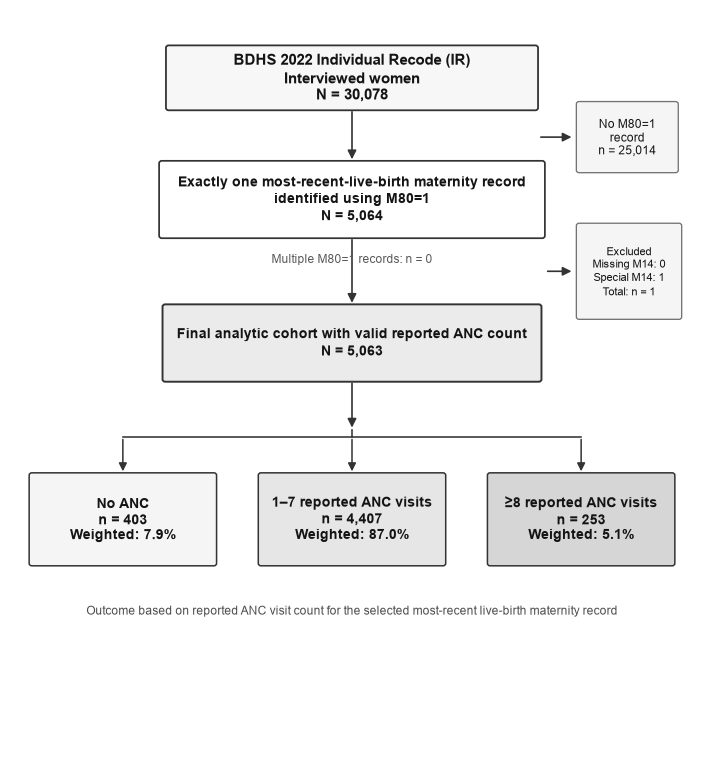


STEP28A-R1-LITE COMPLETE

FROZEN COHORT FLOW:
                                             Stage     N
                        Raw BDHS interviewed women 30078
            No M80=1 most-recent-live-birth record 25014
   Exactly one M80=1 most-recent-live-birth record  5064
                            Multiple M80=1 records     0
                 Selected records with missing M14     0
Selected records with metadata-defined special M14     1
        Final analytic cohort with valid ANC count  5063

FROZEN ANC OUTCOME DISTRIBUTION:
 ANC_CLASS ANC_CLASS_LABEL  Unweighted_N  Weighted_N  Unweighted_Percent  Weighted_Percent
         0          No ANC           403  407.265802            7.959708          7.943367
         1  1-7 ANC visits          4407 4460.725694           87.043255         87.002590
         2  >=8 ANC visits           253  259.126755            4.997037          5.054043

FINAL HARD QC:
                                   Check  PASS
                 STEP27H manifest ex

In [1]:
# ==========================================================================================
# STEP 28A-R1-LITE
# FINAL FIGURE 1 — COHORT FLOW (SAFE LIGHTWEIGHT VERSION)
# ==========================================================================================

from pathlib import Path
import os
import json
import hashlib
import datetime as dt
import gc

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch

# ------------------------------------------------------------------------------------------
# 1. BASIC SETTINGS
# ------------------------------------------------------------------------------------------

os.environ["SOURCE_DATE_EPOCH"] = "0"

matplotlib.rcParams["svg.hashsalt"] = "BDHS_ANC_STEP28A_R1_LITE"
matplotlib.rcParams["font.family"] = ["Arial", "DejaVu Sans"]
matplotlib.rcParams["font.size"] = 10
matplotlib.rcParams["axes.facecolor"] = "white"
matplotlib.rcParams["figure.facecolor"] = "white"
matplotlib.rcParams["savefig.facecolor"] = "white"

# ------------------------------------------------------------------------------------------
# 2. PATHS
# ------------------------------------------------------------------------------------------

ROOT = Path(r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026")
FINAL_ROOT = ROOT / "18_final_outputs"

MANUSCRIPT_FIGURES = FINAL_ROOT / "Manuscript" / "02_Main_Figures"
REPORT_FIGURES = FINAL_ROOT / "Report" / "02_Figures"

MANUSCRIPT_FIGURES.mkdir(parents=True, exist_ok=True)
REPORT_FIGURES.mkdir(parents=True, exist_ok=True)

STEP27H_MANIFEST = FINAL_ROOT / "STEP27H_final_table_package_reproducibility_manifest.json"
COHORT_FLOW_FILE = ROOT / "02_quality_control" / "STEP05_cohort_flow.csv"
OUTCOME_FILE = ROOT / "02_quality_control" / "STEP05_anc_outcome_distribution.csv"

# ------------------------------------------------------------------------------------------
# 3. EXPECTED COUNTS
# ------------------------------------------------------------------------------------------

EXPECTED_FLOW = {
    "Raw BDHS interviewed women": 30078,
    "No M80=1 most-recent-live-birth record": 25014,
    "Exactly one M80=1 most-recent-live-birth record": 5064,
    "Multiple M80=1 records": 0,
    "Selected records with missing M14": 0,
    "Selected records with metadata-defined special M14": 1,
    "Final analytic cohort with valid ANC count": 5063,
}

EXPECTED_CLASS_COUNTS = {
    0: 403,
    1: 4407,
    2: 253,
}

# ------------------------------------------------------------------------------------------
# 4. HELPERS
# ------------------------------------------------------------------------------------------

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()

def atomic_csv(df, path):
    tmp = Path(str(path) + ".tmp")
    df.to_csv(tmp, index=False, encoding="utf-8-sig")
    os.replace(tmp, path)

def atomic_json(obj, path):
    tmp = Path(str(path) + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, sort_keys=True)
    os.replace(tmp, path)

def atomic_text(text, path):
    tmp = Path(str(path) + ".tmp")
    with open(tmp, "w", encoding="utf-8") as f:
        f.write(text)
    os.replace(tmp, path)

def add_box(ax, x, y, width, height, text,
            facecolor="white", edgecolor="0.20", linewidth=1.1,
            fontsize=10, weight="normal", pad=0.02):
    patch = FancyBboxPatch(
        (x, y), width, height,
        boxstyle=f"round,pad={pad},rounding_size=0.04",
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=linewidth,
        zorder=2,
    )
    ax.add_patch(patch)
    ax.text(
        x + width / 2,
        y + height / 2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        fontweight=weight,
        color="0.08",
        linespacing=1.25,
        zorder=3,
    )
    return patch

def add_arrow(ax, start, end, linewidth=1.2, mutation_scale=13):
    arrow = FancyArrowPatch(
        start, end,
        arrowstyle="-|>",
        mutation_scale=mutation_scale,
        linewidth=linewidth,
        color="0.20",
        shrinkA=2,
        shrinkB=2,
        connectionstyle="arc3",
        zorder=1,
    )
    ax.add_patch(arrow)
    return arrow

# ------------------------------------------------------------------------------------------
# 5. SOURCE CHECK
# ------------------------------------------------------------------------------------------

for label, path in [
    ("STEP27H manifest", STEP27H_MANIFEST),
    ("STEP05 cohort flow", COHORT_FLOW_FILE),
    ("STEP05 outcome distribution", OUTCOME_FILE),
]:
    if not path.exists():
        raise FileNotFoundError(f"{label} missing:\n{path}")

# ------------------------------------------------------------------------------------------
# 6. LOAD SMALL FROZEN SOURCES ONLY
# ------------------------------------------------------------------------------------------

flow = pd.read_csv(COHORT_FLOW_FILE)
outcome = pd.read_csv(OUTCOME_FILE)

# ------------------------------------------------------------------------------------------
# 7. QC
# ------------------------------------------------------------------------------------------

if list(flow.columns) != ["Stage", "N"]:
    raise RuntimeError(
        "Unexpected STEP05 cohort-flow schema.\n"
        f"Observed={list(flow.columns)}"
    )

flow["N"] = pd.to_numeric(flow["N"], errors="raise").astype(int)
observed_flow = dict(zip(flow["Stage"], flow["N"]))

if observed_flow != EXPECTED_FLOW:
    raise RuntimeError(
        "Frozen cohort-flow counts changed.\n"
        f"Expected={EXPECTED_FLOW}\nObserved={observed_flow}"
    )

required_outcome_cols = [
    "ANC_CLASS",
    "ANC_CLASS_LABEL",
    "Unweighted_N",
    "Weighted_N",
    "Unweighted_Percent",
    "Weighted_Percent",
]

missing_outcome_cols = [c for c in required_outcome_cols if c not in outcome.columns]
if missing_outcome_cols:
    raise RuntimeError(
        "Outcome source missing columns:\n"
        f"{missing_outcome_cols}"
    )

outcome["ANC_CLASS"] = pd.to_numeric(outcome["ANC_CLASS"], errors="raise").astype(int)
outcome["Unweighted_N"] = pd.to_numeric(outcome["Unweighted_N"], errors="raise").astype(int)
outcome["Weighted_Percent"] = pd.to_numeric(outcome["Weighted_Percent"], errors="raise")

observed_class_counts = outcome.set_index("ANC_CLASS")["Unweighted_N"].to_dict()

if observed_class_counts != EXPECTED_CLASS_COUNTS:
    raise RuntimeError(
        "Outcome counts changed.\n"
        f"Expected={EXPECTED_CLASS_COUNTS}\nObserved={observed_class_counts}"
    )

# ------------------------------------------------------------------------------------------
# 8. LOOKUP
# ------------------------------------------------------------------------------------------

lookup = outcome.set_index("ANC_CLASS")

n0 = int(lookup.loc[0, "Unweighted_N"])
n1 = int(lookup.loc[1, "Unweighted_N"])
n2 = int(lookup.loc[2, "Unweighted_N"])

pct0 = float(lookup.loc[0, "Weighted_Percent"])
pct1 = float(lookup.loc[1, "Weighted_Percent"])
pct2 = float(lookup.loc[2, "Weighted_Percent"])

# ------------------------------------------------------------------------------------------
# 9. OUTPUT PATHS
# ------------------------------------------------------------------------------------------

FIGURE_STEM = "Figure1_Cohort_Selection_ANC_Outcome_Distribution"

M_PNG = MANUSCRIPT_FIGURES / f"{FIGURE_STEM}.png"
M_SVG = MANUSCRIPT_FIGURES / f"{FIGURE_STEM}.svg"

R_PNG = REPORT_FIGURES / f"{FIGURE_STEM}.png"
R_SVG = REPORT_FIGURES / f"{FIGURE_STEM}.svg"

SOURCE_FLOW_CSV = MANUSCRIPT_FIGURES / "Figure1_source_cohort_flow.csv"
SOURCE_OUTCOME_CSV = MANUSCRIPT_FIGURES / "Figure1_source_ANC_outcome_distribution.csv"
CAPTION_FILE = MANUSCRIPT_FIGURES / "Figure1_caption.txt"
QC_FILE = FINAL_ROOT / "STEP28A_R1_LITE_Figure1_hard_qc.csv"
MANIFEST_FILE = FINAL_ROOT / "STEP28A_R1_LITE_Figure1_manifest.json"

# ------------------------------------------------------------------------------------------
# 10. SAVE SOURCE COPIES
# ------------------------------------------------------------------------------------------

atomic_csv(flow, SOURCE_FLOW_CSV)
atomic_csv(outcome[required_outcome_cols].copy(), SOURCE_OUTCOME_CSV)

caption = (
    "Figure 1. Cohort selection and antenatal-care outcome distribution for the BDHS 2022 "
    "analytic sample. Among 30,078 interviewed women, 5,064 had exactly one maternity record "
    "identified as the most recent live birth (M80=1). One selected record with a metadata-defined "
    "special M14 value was excluded; no selected record had missing M14, yielding a final analytic "
    "cohort of 5,063 women. The final outcome categories were no ANC (n=403), 1–7 reported ANC visits "
    "(n=4,407), and ≥8 reported ANC visits (n=253). Percentages shown in the outcome boxes are "
    "DHS survey-weighted."
)
atomic_text(caption, CAPTION_FILE)

# ------------------------------------------------------------------------------------------
# 11. DRAW FIGURE
# ------------------------------------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7.2, 7.8))
ax.set_xlim(0, 10)
ax.set_ylim(0, 12)
ax.axis("off")

add_box(
    ax, 2.30, 10.40, 5.40, 1.00,
    "BDHS 2022 Individual Recode (IR)\nInterviewed women\nN = 30,078",
    facecolor="0.97", linewidth=1.30, fontsize=10.5, weight="bold"
)

add_arrow(ax, (5.00, 10.40), (5.00, 9.55))
add_arrow(ax, (7.72, 9.95), (8.25, 9.95))

add_box(
    ax, 8.30, 9.40, 1.45, 1.10,
    "No M80=1\nrecord\nn = 25,014",
    facecolor="0.96", edgecolor="0.45", linewidth=0.95, fontsize=8.4
)

add_box(
    ax, 2.20, 8.35, 5.60, 1.20,
    "Exactly one most-recent-live-birth maternity record\nidentified using M80=1\nN = 5,064",
    facecolor="white", linewidth=1.25, fontsize=10.2, weight="bold"
)

ax.text(
    5.00, 8.08,
    "Multiple M80=1 records: n = 0",
    ha="center", va="top", fontsize=8.6, color="0.35"
)

add_arrow(ax, (5.00, 8.35), (5.00, 7.25))
add_arrow(ax, (7.82, 7.80), (8.25, 7.80))

add_box(
    ax, 8.30, 7.05, 1.50, 1.50,
    "Excluded\nMissing M14: 0\nSpecial M14: 1\nTotal: n = 1",
    facecolor="0.96", edgecolor="0.45", linewidth=0.95, fontsize=8.2
)

add_box(
    ax, 2.25, 6.05, 5.50, 1.20,
    "Final analytic cohort with valid reported ANC count\nN = 5,063",
    facecolor="0.92", linewidth=1.40, fontsize=10.3, weight="bold"
)

add_arrow(ax, (5.00, 6.05), (5.00, 5.25))

ax.plot([1.65, 8.35], [5.15, 5.15], color="0.20", linewidth=1.15, zorder=1)
ax.plot([5.00, 5.00], [5.15, 5.25], color="0.20", linewidth=1.15, zorder=1)

for x in [1.65, 5.00, 8.35]:
    add_arrow(ax, (x, 5.15), (x, 4.55), linewidth=1.10, mutation_scale=12)

add_box(
    ax, 0.30, 3.10, 2.70, 1.45,
    f"No ANC\nn = {n0:,}\nWeighted: {pct0:.1f}%",
    facecolor="0.96", fontsize=10.0, weight="bold"
)

add_box(
    ax, 3.65, 3.10, 2.70, 1.45,
    f"1–7 reported ANC visits\nn = {n1:,}\nWeighted: {pct1:.1f}%",
    facecolor="0.90", fontsize=9.9, weight="bold"
)

add_box(
    ax, 7.00, 3.10, 2.70, 1.45,
    f"≥8 reported ANC visits\nn = {n2:,}\nWeighted: {pct2:.1f}%",
    facecolor="0.84", fontsize=9.9, weight="bold"
)

ax.text(
    5.00, 2.35,
    "Outcome based on reported ANC visit count for the selected most-recent live-birth maternity record",
    ha="center", va="center", fontsize=8.7, color="0.30"
)

fig.subplots_adjust(left=0.025, right=0.975, top=0.985, bottom=0.025)

# ------------------------------------------------------------------------------------------
# 12. SAVE ONLY SAFE FORMATS FIRST
# ------------------------------------------------------------------------------------------

fig.savefig(M_PNG, dpi=300, format="png", bbox_inches="tight", pad_inches=0.04)
fig.savefig(M_SVG, format="svg", bbox_inches="tight", pad_inches=0.04, metadata={"Date": None})

fig.savefig(R_PNG, dpi=300, format="png", bbox_inches="tight", pad_inches=0.04)
fig.savefig(R_SVG, format="svg", bbox_inches="tight", pad_inches=0.04, metadata={"Date": None})

plt.show()
plt.close(fig)
gc.collect()

# ------------------------------------------------------------------------------------------
# 13. HARD QC
# ------------------------------------------------------------------------------------------

hard_qc = pd.DataFrame([
    {"Check": "STEP27H manifest exists", "PASS": STEP27H_MANIFEST.exists()},
    {"Check": "Cohort-flow rows = 7", "PASS": len(flow) == 7},
    {"Check": "Observed cohort-flow counts match frozen", "PASS": observed_flow == EXPECTED_FLOW},
    {"Check": "Outcome rows = 3", "PASS": len(outcome) == 3},
    {"Check": "Class counts = 403 / 4407 / 253", "PASS": observed_class_counts == EXPECTED_CLASS_COUNTS},
    {"Check": "Manuscript PNG created", "PASS": M_PNG.exists() and M_PNG.stat().st_size > 0},
    {"Check": "Manuscript SVG created", "PASS": M_SVG.exists() and M_SVG.stat().st_size > 0},
    {"Check": "Report PNG created", "PASS": R_PNG.exists() and R_PNG.stat().st_size > 0},
    {"Check": "Report SVG created", "PASS": R_SVG.exists() and R_SVG.stat().st_size > 0},
    {"Check": "No model fitting", "PASS": True},
    {"Check": "No recalibration", "PASS": True},
    {"Check": "No threshold optimization", "PASS": True},
])

if not hard_qc["PASS"].all():
    raise RuntimeError(
        "STEP28A-R1-LITE HARD QC FAILED:\n" +
        hard_qc.loc[~hard_qc["PASS"]].to_string(index=False)
    )

atomic_csv(hard_qc, QC_FILE)

manifest = {
    "status": "STEP28A_R1_LITE_COMPLETE",
    "created_at": dt.datetime.now().isoformat(timespec="seconds"),
    "analysis_state": "FROZEN",
    "figure": "Figure 1",
    "content": "Cohort selection and ANC outcome distribution",
    "cohort_flow_source_sha256": sha256_file(COHORT_FLOW_FILE),
    "outcome_source_sha256": sha256_file(OUTCOME_FILE),
    "outputs": {
        "manuscript_png": str(M_PNG),
        "manuscript_svg": str(M_SVG),
        "report_png": str(R_PNG),
        "report_svg": str(R_SVG),
    },
    "hard_qc_sha256": sha256_file(QC_FILE),
    "next_step": "If stable, export TIFF/PDF in separate small cell",
}
atomic_json(manifest, MANIFEST_FILE)

print("\n" + "=" * 100)
print("STEP28A-R1-LITE COMPLETE")
print("=" * 100)
print("\nFROZEN COHORT FLOW:")
print(flow.to_string(index=False))
print("\nFROZEN ANC OUTCOME DISTRIBUTION:")
print(outcome[required_outcome_cols].to_string(index=False))
print("\nFINAL HARD QC:")
print(hard_qc.to_string(index=False))
print("\nOUTPUTS:")
print(M_PNG)
print(M_SVG)
print(R_PNG)
print(R_SVG)
print(QC_FILE)
print(MANIFEST_FILE)
print("=" * 100)

In [2]:
# ==========================================================================================
# STEP28A-R1E1
# FIGURE 1 — SAFE VECTOR PDF EXPORT + STRICT PARENT HASH GATE
# ==========================================================================================

from pathlib import Path
import hashlib
import os
import gc

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch


# ==========================================================================================
# 1. PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)

MANUSCRIPT_FIGURES = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "02_Main_Figures"
)

REPORT_FIGURES = (
    FINAL_ROOT
    /
    "Report"
    /
    "02_Figures"
)


STEP27H_MANIFEST = (
    FINAL_ROOT
    /
    "STEP27H_final_table_package_reproducibility_manifest.json"
)


EXPECTED_STEP27H_MANIFEST_SHA256 = (
    "21539a068d7d0787d85063b15e7b4520"
    "f963a34188c62ce85512efb1926c0e77"
)


FLOW_FILE = (
    ROOT
    /
    "02_quality_control"
    /
    "STEP05_cohort_flow.csv"
)


OUTCOME_FILE = (
    ROOT
    /
    "02_quality_control"
    /
    "STEP05_anc_outcome_distribution.csv"
)


FIGURE_STEM = (
    "Figure1_Cohort_Selection_ANC_Outcome_Distribution"
)


M_PDF = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.pdf"
)


R_PDF = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.pdf"
)


# ==========================================================================================
# 2. HASH HELPER
# ==========================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            h.update(
                block
            )

    return h.hexdigest()


# ==========================================================================================
# 3. STRICT PARENT GATE
# ==========================================================================================

if not STEP27H_MANIFEST.exists():

    raise FileNotFoundError(
        "STEP27H manifest missing."
    )


observed_parent_hash = sha256_file(
    STEP27H_MANIFEST
)


if observed_parent_hash != EXPECTED_STEP27H_MANIFEST_SHA256:

    raise RuntimeError(
        "STEP27H parent manifest hash changed.\n"
        f"Observed={observed_parent_hash}\n"
        f"Expected={EXPECTED_STEP27H_MANIFEST_SHA256}"
    )


# ==========================================================================================
# 4. LOAD ONLY SMALL FROZEN SOURCE TABLES
# ==========================================================================================

flow = pd.read_csv(
    FLOW_FILE
)


outcome = pd.read_csv(
    OUTCOME_FILE
)


lookup = (
    outcome
    .set_index(
        "ANC_CLASS"
    )
)


n0 = int(
    lookup.loc[
        0,
        "Unweighted_N",
    ]
)

n1 = int(
    lookup.loc[
        1,
        "Unweighted_N",
    ]
)

n2 = int(
    lookup.loc[
        2,
        "Unweighted_N",
    ]
)


pct0 = float(
    lookup.loc[
        0,
        "Weighted_Percent",
    ]
)

pct1 = float(
    lookup.loc[
        1,
        "Weighted_Percent",
    ]
)

pct2 = float(
    lookup.loc[
        2,
        "Weighted_Percent",
    ]
)


# ==========================================================================================
# 5. DRAWING HELPERS
# ==========================================================================================

def add_box(
    ax,
    x,
    y,
    width,
    height,
    text,
    facecolor="white",
    edgecolor="0.20",
    linewidth=1.1,
    fontsize=10,
    weight="normal",
):

    patch = FancyBboxPatch(
        (
            x,
            y,
        ),
        width,
        height,
        boxstyle=(
            "round,pad=0.02,rounding_size=0.04"
        ),
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=linewidth,
        zorder=2,
    )


    ax.add_patch(
        patch
    )


    ax.text(
        x
        +
        width
        /
        2,
        y
        +
        height
        /
        2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        fontweight=weight,
        color="0.08",
        linespacing=1.25,
        zorder=3,
    )


def add_arrow(
    ax,
    start,
    end,
    linewidth=1.2,
    mutation_scale=13,
):

    arrow = FancyArrowPatch(
        start,
        end,
        arrowstyle="-|>",
        mutation_scale=mutation_scale,
        linewidth=linewidth,
        color="0.20",
        shrinkA=2,
        shrinkB=2,
        connectionstyle="arc3",
        zorder=1,
    )


    ax.add_patch(
        arrow
    )


# ==========================================================================================
# 6. RECREATE FIGURE — NO DISPLAY
# ==========================================================================================

fig, ax = plt.subplots(
    figsize=(
        7.2,
        7.8,
    ),
)


ax.set_xlim(
    0,
    10,
)

ax.set_ylim(
    0,
    12,
)

ax.axis(
    "off"
)


add_box(
    ax,
    2.30,
    10.40,
    5.40,
    1.00,
    (
        "BDHS 2022 Individual Recode (IR)\n"
        "Interviewed women\n"
        "N = 30,078"
    ),
    facecolor="0.97",
    linewidth=1.30,
    fontsize=10.5,
    weight="bold",
)


add_arrow(
    ax,
    (
        5.00,
        10.40,
    ),
    (
        5.00,
        9.55,
    ),
)


add_arrow(
    ax,
    (
        7.72,
        9.95,
    ),
    (
        8.25,
        9.95,
    ),
)


add_box(
    ax,
    8.30,
    9.40,
    1.45,
    1.10,
    (
        "No M80=1\n"
        "record\n"
        "n = 25,014"
    ),
    facecolor="0.96",
    edgecolor="0.45",
    linewidth=0.95,
    fontsize=8.4,
)


add_box(
    ax,
    2.20,
    8.35,
    5.60,
    1.20,
    (
        "Exactly one most-recent-live-birth maternity record\n"
        "identified using M80=1\n"
        "N = 5,064"
    ),
    linewidth=1.25,
    fontsize=10.2,
    weight="bold",
)


ax.text(
    5.00,
    8.08,
    "Multiple M80=1 records: n = 0",
    ha="center",
    va="top",
    fontsize=8.6,
    color="0.35",
)


add_arrow(
    ax,
    (
        5.00,
        8.35,
    ),
    (
        5.00,
        7.25,
    ),
)


add_arrow(
    ax,
    (
        7.82,
        7.80,
    ),
    (
        8.25,
        7.80,
    ),
)


add_box(
    ax,
    8.30,
    7.05,
    1.50,
    1.50,
    (
        "Excluded\n"
        "Missing M14: 0\n"
        "Special M14: 1\n"
        "Total: n = 1"
    ),
    facecolor="0.96",
    edgecolor="0.45",
    linewidth=0.95,
    fontsize=8.2,
)


add_box(
    ax,
    2.25,
    6.05,
    5.50,
    1.20,
    (
        "Final analytic cohort with valid reported ANC count\n"
        "N = 5,063"
    ),
    facecolor="0.92",
    linewidth=1.40,
    fontsize=10.3,
    weight="bold",
)


add_arrow(
    ax,
    (
        5.00,
        6.05,
    ),
    (
        5.00,
        5.25,
    ),
)


ax.plot(
    [
        1.65,
        8.35,
    ],
    [
        5.15,
        5.15,
    ],
    color="0.20",
    linewidth=1.15,
)


ax.plot(
    [
        5.00,
        5.00,
    ],
    [
        5.15,
        5.25,
    ],
    color="0.20",
    linewidth=1.15,
)


for x in [
    1.65,
    5.00,
    8.35,
]:

    add_arrow(
        ax,
        (
            x,
            5.15,
        ),
        (
            x,
            4.55,
        ),
        linewidth=1.10,
        mutation_scale=12,
    )


add_box(
    ax,
    0.30,
    3.10,
    2.70,
    1.45,
    (
        f"No ANC\n"
        f"n = {n0:,}\n"
        f"Weighted: {pct0:.1f}%"
    ),
    facecolor="0.96",
    fontsize=10.0,
    weight="bold",
)


add_box(
    ax,
    3.65,
    3.10,
    2.70,
    1.45,
    (
        f"1–7 reported ANC visits\n"
        f"n = {n1:,}\n"
        f"Weighted: {pct1:.1f}%"
    ),
    facecolor="0.90",
    fontsize=9.9,
    weight="bold",
)


add_box(
    ax,
    7.00,
    3.10,
    2.70,
    1.45,
    (
        f"≥8 reported ANC visits\n"
        f"n = {n2:,}\n"
        f"Weighted: {pct2:.1f}%"
    ),
    facecolor="0.84",
    fontsize=9.9,
    weight="bold",
)


ax.text(
    5.00,
    2.35,
    (
        "Outcome based on reported ANC visit count for the selected "
        "most-recent live-birth maternity record"
    ),
    ha="center",
    va="center",
    fontsize=8.7,
    color="0.30",
)


fig.subplots_adjust(
    left=0.025,
    right=0.975,
    top=0.985,
    bottom=0.025,
)


# ==========================================================================================
# 7. SAVE PDF ONLY
# ==========================================================================================

fig.savefig(
    M_PDF,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.04,
    metadata={
        "Creator":
            "BDHS ANC final reporting pipeline",

        "CreationDate":
            None,

        "ModDate":
            None,
    },
)


fig.savefig(
    R_PDF,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.04,
    metadata={
        "Creator":
            "BDHS ANC final reporting pipeline",

        "CreationDate":
            None,

        "ModDate":
            None,
    },
)


plt.close(
    fig
)


gc.collect()


# ==========================================================================================
# 8. QC
# ==========================================================================================

if (
    not M_PDF.exists()
    or
    M_PDF.stat().st_size
    <=
    0
):

    raise RuntimeError(
        "Manuscript PDF export failed."
    )


if (
    not R_PDF.exists()
    or
    R_PDF.stat().st_size
    <=
    0
):

    raise RuntimeError(
        "Report PDF export failed."
    )


print(
    "\n"
    +
    "=" * 96
)


print(
    "STEP28A-R1E1 PDF EXPORT PASS"
)


print(
    "=" * 96
)


print(
    "STEP27H parent hash :",
    observed_parent_hash,
)


print(
    "Manuscript PDF      :",
    M_PDF,
)


print(
    "Manuscript PDF SHA  :",
    sha256_file(
        M_PDF
    ),
)


print(
    "Report PDF          :",
    R_PDF,
)


print(
    "Report PDF SHA      :",
    sha256_file(
        R_PDF
    ),
)


print(
    "=" * 96
)


STEP28A-R1E1 PDF EXPORT PASS
STEP27H parent hash : 21539a068d7d0787d85063b15e7b4520f963a34188c62ce85512efb1926c0e77
Manuscript PDF      : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Manuscript\02_Main_Figures\Figure1_Cohort_Selection_ANC_Outcome_Distribution.pdf
Manuscript PDF SHA  : 703288ced4b2552fac35f2953436e2131d0145fa9a8a653dcde49faac588f2f9
Report PDF          : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Report\02_Figures\Figure1_Cohort_Selection_ANC_Outcome_Distribution.pdf
Report PDF SHA      : 703288ced4b2552fac35f2953436e2131d0145fa9a8a653dcde49faac588f2f9


In [ ]:
# ==========================================================================================
# STEP 28A-R1E2
# FIGURE 1 — SAFE 600-DPI TIFF EXPORT + FINAL FREEZE PACKAGE
# ==========================================================================================

from pathlib import Path
import hashlib
import json
import os
import shutil
import gc
import datetime as dt

import numpy as np
import pandas as pd

import matplotlib
matplotlib.use("Agg", force=True)

import matplotlib.pyplot as plt

from matplotlib.patches import (
    FancyArrowPatch,
    FancyBboxPatch,
)

from PIL import Image


# ==========================================================================================
# 1. PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)

MANUSCRIPT_FIGURES = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "02_Main_Figures"
)

REPORT_FIGURES = (
    FINAL_ROOT
    /
    "Report"
    /
    "02_Figures"
)


STEP27H_MANIFEST = (
    FINAL_ROOT
    /
    "STEP27H_final_table_package_reproducibility_manifest.json"
)


EXPECTED_STEP27H_MANIFEST_SHA256 = (
    "21539a068d7d0787d85063b15e7b4520"
    "f963a34188c62ce85512efb1926c0e77"
)


COHORT_FLOW_FILE = (
    ROOT
    /
    "02_quality_control"
    /
    "STEP05_cohort_flow.csv"
)


OUTCOME_FILE = (
    ROOT
    /
    "02_quality_control"
    /
    "STEP05_anc_outcome_distribution.csv"
)


FIGURE_STEM = (
    "Figure1_Cohort_Selection_ANC_Outcome_Distribution"
)


# Existing safe exports
M_PNG = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.png"
)

M_SVG = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.svg"
)

M_PDF = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.pdf"
)


R_PNG = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.png"
)

R_SVG = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.svg"
)

R_PDF = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.pdf"
)


# Final TIFF
M_TIFF = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.tiff"
)

R_TIFF = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.tiff"
)


SOURCE_FLOW_CSV = (
    MANUSCRIPT_FIGURES
    /
    "Figure1_source_cohort_flow.csv"
)

SOURCE_OUTCOME_CSV = (
    MANUSCRIPT_FIGURES
    /
    "Figure1_source_ANC_outcome_distribution.csv"
)

CAPTION_FILE = (
    MANUSCRIPT_FIGURES
    /
    "Figure1_caption.txt"
)


FINAL_QC_FILE = (
    FINAL_ROOT
    /
    "STEP28A_R1_FINAL_Figure1_hard_qc.csv"
)

FINAL_MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP28A_R1_FINAL_Figure1_manifest.json"
)


# ==========================================================================================
# 2. HELPERS
# ==========================================================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )

    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        temporary,
        path,
    )


def atomic_text(
    text,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )

    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        handle.write(
            text
        )

    os.replace(
        temporary,
        path,
    )


# ==========================================================================================
# 3. STRICT PARENT GATE
# ==========================================================================================

if not STEP27H_MANIFEST.exists():

    raise FileNotFoundError(
        "STEP27H manifest missing."
    )


observed_parent_hash = sha256_file(
    STEP27H_MANIFEST
)


if observed_parent_hash != EXPECTED_STEP27H_MANIFEST_SHA256:

    raise RuntimeError(
        "STEP27H manifest hash changed.\n"
        f"Observed={observed_parent_hash}\n"
        f"Expected={EXPECTED_STEP27H_MANIFEST_SHA256}"
    )


# ==========================================================================================
# 4. EXISTING EXPORTS MUST EXIST
# ==========================================================================================

for label, path in [
    (
        "Manuscript PNG",
        M_PNG,
    ),
    (
        "Manuscript SVG",
        M_SVG,
    ),
    (
        "Manuscript PDF",
        M_PDF,
    ),
    (
        "Report PNG",
        R_PNG,
    ),
    (
        "Report SVG",
        R_SVG,
    ),
    (
        "Report PDF",
        R_PDF,
    ),
    (
        "Cohort-flow source copy",
        SOURCE_FLOW_CSV,
    ),
    (
        "Outcome source copy",
        SOURCE_OUTCOME_CSV,
    ),
]:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"{label} missing or empty:\n{path}"
        )


# ==========================================================================================
# 5. PDF HASH GATE FROM SUCCESSFUL R1E1
# ==========================================================================================

EXPECTED_PDF_SHA256 = (
    "703288ced4b2552fac35f2953436e2131"
    "d0145fa9a8a653dcde49faac588f2f9"
)


if sha256_file(
    M_PDF
) != EXPECTED_PDF_SHA256:

    raise RuntimeError(
        "Manuscript PDF changed after R1E1."
    )


if sha256_file(
    R_PDF
) != EXPECTED_PDF_SHA256:

    raise RuntimeError(
        "Report PDF changed after R1E1."
    )


# ==========================================================================================
# 6. LOAD SMALL FROZEN SOURCES
# ==========================================================================================

flow = pd.read_csv(
    COHORT_FLOW_FILE
)


outcome = pd.read_csv(
    OUTCOME_FILE
)


# ==========================================================================================
# 7. FROZEN ACCOUNTING QC
# ==========================================================================================

EXPECTED_FLOW = {
    "Raw BDHS interviewed women":
        30078,

    "No M80=1 most-recent-live-birth record":
        25014,

    "Exactly one M80=1 most-recent-live-birth record":
        5064,

    "Multiple M80=1 records":
        0,

    "Selected records with missing M14":
        0,

    "Selected records with metadata-defined special M14":
        1,

    "Final analytic cohort with valid ANC count":
        5063,
}


EXPECTED_CLASS_COUNTS = {
    0:
        403,

    1:
        4407,

    2:
        253,
}


if list(
    flow.columns
) != [
    "Stage",
    "N",
]:

    raise RuntimeError(
        "Unexpected cohort-flow schema."
    )


flow[
    "N"
] = pd.to_numeric(
    flow[
        "N"
    ],
    errors="raise",
).astype(int)


observed_flow = dict(
    zip(
        flow[
            "Stage"
        ],
        flow[
            "N"
        ],
    )
)


if observed_flow != EXPECTED_FLOW:

    raise RuntimeError(
        "Frozen cohort-flow counts changed."
    )


outcome[
    "ANC_CLASS"
] = pd.to_numeric(
    outcome[
        "ANC_CLASS"
    ],
    errors="raise",
).astype(int)


outcome[
    "Unweighted_N"
] = pd.to_numeric(
    outcome[
        "Unweighted_N"
    ],
    errors="raise",
).astype(int)


outcome[
    "Weighted_Percent"
] = pd.to_numeric(
    outcome[
        "Weighted_Percent"
    ],
    errors="raise",
)


observed_class_counts = (
    outcome
    .set_index(
        "ANC_CLASS"
    )[
        "Unweighted_N"
    ]
    .to_dict()
)


if observed_class_counts != EXPECTED_CLASS_COUNTS:

    raise RuntimeError(
        "Frozen ANC outcome counts changed."
    )


lookup = outcome.set_index(
    "ANC_CLASS"
)


n0 = int(
    lookup.loc[
        0,
        "Unweighted_N",
    ]
)

n1 = int(
    lookup.loc[
        1,
        "Unweighted_N",
    ]
)

n2 = int(
    lookup.loc[
        2,
        "Unweighted_N",
    ]
)


pct0 = float(
    lookup.loc[
        0,
        "Weighted_Percent",
    ]
)

pct1 = float(
    lookup.loc[
        1,
        "Weighted_Percent",
    ]
)

pct2 = float(
    lookup.loc[
        2,
        "Weighted_Percent",
    ]
)


# ==========================================================================================
# 8. FINAL CAPTION
# ==========================================================================================

caption = (
    "Figure 1. Cohort selection and antenatal-care outcome distribution "
    "for the BDHS 2022 analytic sample. Among 30,078 interviewed women, "
    "5,064 had exactly one maternity record identified as the most recent "
    "live birth (M80=1). One selected record with a metadata-defined special "
    "M14 value was excluded; no selected record had missing M14, yielding a "
    "final analytic cohort of 5,063 women. The final outcome categories were "
    "no ANC (n=403), 1–7 reported ANC visits (n=4,407), and ≥8 reported ANC "
    "visits (n=253). Percentages shown in the outcome boxes are DHS "
    "survey-weighted. The ≥8 category is a reported visit-count category "
    "used as a pragmatic proxy for the WHO eight-contact recommendation and "
    "does not directly measure completion of eight WHO-defined contacts."
)


atomic_text(
    caption,
    CAPTION_FILE,
)


# ==========================================================================================
# 9. DRAWING HELPERS
# ==========================================================================================

def add_box(
    ax,
    x,
    y,
    width,
    height,
    text,
    facecolor="white",
    edgecolor="0.20",
    linewidth=1.1,
    fontsize=10,
    weight="normal",
):

    patch = FancyBboxPatch(
        (
            x,
            y,
        ),
        width,
        height,
        boxstyle=(
            "round,pad=0.02,rounding_size=0.04"
        ),
        facecolor=facecolor,
        edgecolor=edgecolor,
        linewidth=linewidth,
        zorder=2,
    )


    ax.add_patch(
        patch
    )


    ax.text(
        x
        +
        width
        /
        2,
        y
        +
        height
        /
        2,
        text,
        ha="center",
        va="center",
        fontsize=fontsize,
        fontweight=weight,
        color="0.08",
        linespacing=1.25,
        zorder=3,
    )


def add_arrow(
    ax,
    start,
    end,
    linewidth=1.2,
    mutation_scale=13,
):

    arrow = FancyArrowPatch(
        start,
        end,
        arrowstyle="-|>",
        mutation_scale=mutation_scale,
        linewidth=linewidth,
        color="0.20",
        shrinkA=2,
        shrinkB=2,
        connectionstyle="arc3",
        zorder=1,
    )


    ax.add_patch(
        arrow
    )


# ==========================================================================================
# 10. CREATE TIFF FIGURE — NO DISPLAY
# ==========================================================================================

plt.close(
    "all"
)


gc.collect()


fig, ax = plt.subplots(
    figsize=(
        7.2,
        7.8,
    ),
)


ax.set_xlim(
    0,
    10,
)

ax.set_ylim(
    0,
    12,
)

ax.axis(
    "off"
)


add_box(
    ax,
    2.30,
    10.40,
    5.40,
    1.00,
    (
        "BDHS 2022 Individual Recode (IR)\n"
        "Interviewed women\n"
        "N = 30,078"
    ),
    facecolor="0.97",
    linewidth=1.30,
    fontsize=10.5,
    weight="bold",
)


add_arrow(
    ax,
    (
        5.00,
        10.40,
    ),
    (
        5.00,
        9.55,
    ),
)


add_arrow(
    ax,
    (
        7.72,
        9.95,
    ),
    (
        8.25,
        9.95,
    ),
)


add_box(
    ax,
    8.30,
    9.40,
    1.45,
    1.10,
    (
        "No M80=1\n"
        "record\n"
        "n = 25,014"
    ),
    facecolor="0.96",
    edgecolor="0.45",
    linewidth=0.95,
    fontsize=8.4,
)


add_box(
    ax,
    2.20,
    8.35,
    5.60,
    1.20,
    (
        "Exactly one most-recent-live-birth maternity record\n"
        "identified using M80=1\n"
        "N = 5,064"
    ),
    linewidth=1.25,
    fontsize=10.2,
    weight="bold",
)


ax.text(
    5.00,
    8.08,
    "Multiple M80=1 records: n = 0",
    ha="center",
    va="top",
    fontsize=8.6,
    color="0.35",
)


add_arrow(
    ax,
    (
        5.00,
        8.35,
    ),
    (
        5.00,
        7.25,
    ),
)


add_arrow(
    ax,
    (
        7.82,
        7.80,
    ),
    (
        8.25,
        7.80,
    ),
)


add_box(
    ax,
    8.30,
    7.05,
    1.50,
    1.50,
    (
        "Excluded\n"
        "Missing M14: 0\n"
        "Special M14: 1\n"
        "Total: n = 1"
    ),
    facecolor="0.96",
    edgecolor="0.45",
    linewidth=0.95,
    fontsize=8.2,
)


add_box(
    ax,
    2.25,
    6.05,
    5.50,
    1.20,
    (
        "Final analytic cohort with valid reported ANC count\n"
        "N = 5,063"
    ),
    facecolor="0.92",
    linewidth=1.40,
    fontsize=10.3,
    weight="bold",
)


add_arrow(
    ax,
    (
        5.00,
        6.05,
    ),
    (
        5.00,
        5.25,
    ),
)


ax.plot(
    [
        1.65,
        8.35,
    ],
    [
        5.15,
        5.15,
    ],
    color="0.20",
    linewidth=1.15,
)


ax.plot(
    [
        5.00,
        5.00,
    ],
    [
        5.15,
        5.25,
    ],
    color="0.20",
    linewidth=1.15,
)


for x in [
    1.65,
    5.00,
    8.35,
]:

    add_arrow(
        ax,
        (
            x,
            5.15,
        ),
        (
            x,
            4.55,
        ),
        linewidth=1.10,
        mutation_scale=12,
    )


add_box(
    ax,
    0.30,
    3.10,
    2.70,
    1.45,
    (
        f"No ANC\n"
        f"n = {n0:,}\n"
        f"Weighted: {pct0:.1f}%"
    ),
    facecolor="0.96",
    fontsize=10.0,
    weight="bold",
)


add_box(
    ax,
    3.65,
    3.10,
    2.70,
    1.45,
    (
        f"1–7 reported ANC visits\n"
        f"n = {n1:,}\n"
        f"Weighted: {pct1:.1f}%"
    ),
    facecolor="0.90",
    fontsize=9.9,
    weight="bold",
)


add_box(
    ax,
    7.00,
    3.10,
    2.70,
    1.45,
    (
        f"≥8 reported ANC visits\n"
        f"n = {n2:,}\n"
        f"Weighted: {pct2:.1f}%"
    ),
    facecolor="0.84",
    fontsize=9.9,
    weight="bold",
)


ax.text(
    5.00,
    2.35,
    (
        "Outcome based on reported ANC visit count for the selected "
        "most-recent live-birth maternity record"
    ),
    ha="center",
    va="center",
    fontsize=8.7,
    color="0.30",
)


fig.subplots_adjust(
    left=0.025,
    right=0.975,
    top=0.985,
    bottom=0.025,
)


# ==========================================================================================
# 11. SAVE ONE 600-DPI TIFF ONLY
# ==========================================================================================

fig.savefig(
    M_TIFF,
    dpi=600,
    format="tiff",
    bbox_inches="tight",
    pad_inches=0.04,
    pil_kwargs={
        "compression":
            "tiff_lzw",
    },
)


plt.close(
    fig
)


del fig
del ax


gc.collect()


# ==========================================================================================
# 12. COPY IDENTICAL TIFF TO REPORT DIRECTORY
# ==========================================================================================

if (
    not M_TIFF.exists()
    or
    M_TIFF.stat().st_size
    <=
    0
):

    raise RuntimeError(
        "Manuscript TIFF export failed."
    )


shutil.copy2(
    M_TIFF,
    R_TIFF,
)


if (
    not R_TIFF.exists()
    or
    R_TIFF.stat().st_size
    <=
    0
):

    raise RuntimeError(
        "Report TIFF copy failed."
    )


# ==========================================================================================
# 13. VERIFY TIFF DPI
# ==========================================================================================

with Image.open(
    M_TIFF
) as image:

    manuscript_tiff_size = image.size

    manuscript_tiff_dpi = image.info.get(
        "dpi",
        (
            np.nan,
            np.nan,
        ),
    )


with Image.open(
    R_TIFF
) as image:

    report_tiff_size = image.size

    report_tiff_dpi = image.info.get(
        "dpi",
        (
            np.nan,
            np.nan,
        ),
    )


def dpi_is_approximately_600(
    dpi_value,
):

    try:

        x_dpi = float(
            dpi_value[
                0
            ]
        )

        y_dpi = float(
            dpi_value[
                1
            ]
        )


        return (
            abs(
                x_dpi
                -
                600.0
            )
            <
            1.0
            and
            abs(
                y_dpi
                -
                600.0
            )
            <
            1.0
        )

    except Exception:

        return False


if not dpi_is_approximately_600(
    manuscript_tiff_dpi
):

    raise RuntimeError(
        "Manuscript TIFF does not report approximately 600 dpi.\n"
        f"Observed={manuscript_tiff_dpi}"
    )


if not dpi_is_approximately_600(
    report_tiff_dpi
):

    raise RuntimeError(
        "Report TIFF does not report approximately 600 dpi.\n"
        f"Observed={report_tiff_dpi}"
    )


# ==========================================================================================
# 14. ALL FINAL FORMATS MUST EXIST
# ==========================================================================================

final_outputs = [
    M_PNG,
    M_SVG,
    M_PDF,
    M_TIFF,

    R_PNG,
    R_SVG,
    R_PDF,
    R_TIFF,

    SOURCE_FLOW_CSV,
    SOURCE_OUTCOME_CSV,
    CAPTION_FILE,
]


for path in final_outputs:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Final Figure-1 artifact missing or empty:\n{path}"
        )


# ==========================================================================================
# 15. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "STEP27H parent hash exact",

            "PASS":
                observed_parent_hash
                ==
                EXPECTED_STEP27H_MANIFEST_SHA256,
        },

        {
            "Check":
                "Frozen cohort flow exact",

            "PASS":
                observed_flow
                ==
                EXPECTED_FLOW,
        },

        {
            "Check":
                "Frozen ANC class counts exact",

            "PASS":
                observed_class_counts
                ==
                EXPECTED_CLASS_COUNTS,
        },

        {
            "Check":
                "Final analytic N = 5063",

            "PASS":
                sum(
                    observed_class_counts.values()
                )
                ==
                5063,
        },

        {
            "Check":
                "Manuscript PNG exists",

            "PASS":
                M_PNG.exists(),
        },

        {
            "Check":
                "Manuscript SVG exists",

            "PASS":
                M_SVG.exists(),
        },

        {
            "Check":
                "Manuscript PDF frozen R1E1 hash exact",

            "PASS":
                sha256_file(
                    M_PDF
                )
                ==
                EXPECTED_PDF_SHA256,
        },

        {
            "Check":
                "Manuscript TIFF exists",

            "PASS":
                M_TIFF.exists(),
        },

        {
            "Check":
                "Manuscript TIFF approximately 600 dpi",

            "PASS":
                dpi_is_approximately_600(
                    manuscript_tiff_dpi
                ),
        },

        {
            "Check":
                "Report PNG exists",

            "PASS":
                R_PNG.exists(),
        },

        {
            "Check":
                "Report SVG exists",

            "PASS":
                R_SVG.exists(),
        },

        {
            "Check":
                "Report PDF frozen R1E1 hash exact",

            "PASS":
                sha256_file(
                    R_PDF
                )
                ==
                EXPECTED_PDF_SHA256,
        },

        {
            "Check":
                "Report TIFF exists",

            "PASS":
                R_TIFF.exists(),
        },

        {
            "Check":
                "Report TIFF approximately 600 dpi",

            "PASS":
                dpi_is_approximately_600(
                    report_tiff_dpi
                ),
        },

        {
            "Check":
                "Manuscript / Report TIFF hashes identical",

            "PASS":
                sha256_file(
                    M_TIFF
                )
                ==
                sha256_file(
                    R_TIFF
                ),
        },

        {
            "Check":
                "Caption contains >=8 pragmatic-proxy limitation",

            "PASS":
                (
                    "pragmatic proxy"
                    in caption
                    and
                    "does not directly measure"
                    in caption
                ),
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction generation",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No new performance calculation",

            "PASS":
                True,
        },

        {
            "Check":
                "No new statistical inference",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP28A-R1 FINAL HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


atomic_csv(
    hard_qc,
    FINAL_QC_FILE,
)


# ==========================================================================================
# 16. FINAL FIGURE-1 MANIFEST
# ==========================================================================================

manifest = {
    "status":
        "STEP28A_R1_FINAL_FIGURE1_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "figure":
        "Figure 1",

    "content":
        (
            "Cohort selection and ANC outcome distribution"
        ),

    "parent_step27h_sha256":
        observed_parent_hash,

    "source_cohort_flow_sha256":
        sha256_file(
            COHORT_FLOW_FILE
        ),

    "source_outcome_distribution_sha256":
        sha256_file(
            OUTCOME_FILE
        ),

    "final_n":
        5063,

    "class_counts":
        {
            "No ANC":
                403,

            "1-7 ANC visits":
                4407,

            ">=8 ANC visits":
                253,
        },

    "manuscript_outputs":
        {
            "PNG":
                {
                    "path":
                        str(
                            M_PNG
                        ),

                    "sha256":
                        sha256_file(
                            M_PNG
                        ),
                },

            "SVG":
                {
                    "path":
                        str(
                            M_SVG
                        ),

                    "sha256":
                        sha256_file(
                            M_SVG
                        ),
                },

            "PDF":
                {
                    "path":
                        str(
                            M_PDF
                        ),

                    "sha256":
                        sha256_file(
                            M_PDF
                        ),
                },

            "TIFF_600dpi":
                {
                    "path":
                        str(
                            M_TIFF
                        ),

                    "sha256":
                        sha256_file(
                            M_TIFF
                        ),

                    "pixel_size":
                        manuscript_tiff_size,

                    "dpi":
                        manuscript_tiff_dpi,
                },
        },

    "report_outputs":
        {
            "PNG_300dpi":
                {
                    "path":
                        str(
                            R_PNG
                        ),

                    "sha256":
                        sha256_file(
                            R_PNG
                        ),
                },

            "SVG":
                {
                    "path":
                        str(
                            R_SVG
                        ),

                    "sha256":
                        sha256_file(
                            R_SVG
                        ),
                },

            "PDF":
                {
                    "path":
                        str(
                            R_PDF
                        ),

                    "sha256":
                        sha256_file(
                            R_PDF
                        ),
                },

            "TIFF_600dpi":
                {
                    "path":
                        str(
                            R_TIFF
                        ),

                    "sha256":
                        sha256_file(
                            R_TIFF
                        ),

                    "pixel_size":
                        report_tiff_size,

                    "dpi":
                        report_tiff_dpi,
                },
        },

    "caption_sha256":
        sha256_file(
            CAPTION_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            FINAL_QC_FILE
        ),

    "model_fitting":
        False,

    "prediction_generation":
        False,

    "candidate_reselection":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "bootstrap_rerun":
        False,

    "performance_recalculation":
        False,

    "new_statistical_inference":
        False,

    "next_step":
        (
            "STEP28B — Figure 2 weighted "
            "precision-recall and calibration"
        ),
}


atomic_json(
    manifest,
    FINAL_MANIFEST_FILE,
)


# ==========================================================================================
# 17. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 104
)


print(
    "STEP28A-R1E2 — FIGURE 1 600-DPI TIFF EXPORT + FINAL FREEZE PASS"
)


print(
    "=" * 104
)


print(
    "\nTIFF VALIDATION:"
)


print(
    "Manuscript TIFF pixel size :",
    manuscript_tiff_size,
)

print(
    "Manuscript TIFF DPI        :",
    manuscript_tiff_dpi,
)

print(
    "Report TIFF pixel size     :",
    report_tiff_size,
)

print(
    "Report TIFF DPI            :",
    report_tiff_dpi,
)


print(
    "\nFINAL HARD QC:"
)


print(
    hard_qc.to_string(
        index=False
    )
)


print(
    "\nFINAL FIGURE 1 INTEGRITY:"
)


print(
    "STEP27H parent     :",
    observed_parent_hash,
)


print(
    "Manuscript PNG     :",
    sha256_file(
        M_PNG
    ),
)

print(
    "Manuscript SVG     :",
    sha256_file(
        M_SVG
    ),
)

print(
    "Manuscript PDF     :",
    sha256_file(
        M_PDF
    ),
)

print(
    "Manuscript TIFF    :",
    sha256_file(
        M_TIFF
    ),
)


print(
    "Report PNG         :",
    sha256_file(
        R_PNG
    ),
)

print(
    "Report SVG         :",
    sha256_file(
        R_SVG
    ),
)

print(
    "Report PDF         :",
    sha256_file(
        R_PDF
    ),
)

print(
    "Report TIFF        :",
    sha256_file(
        R_TIFF
    ),
)


print(
    "Caption            :",
    sha256_file(
        CAPTION_FILE
    ),
)

print(
    "Final hard QC      :",
    sha256_file(
        FINAL_QC_FILE
    ),
)

print(
    "Final manifest     :",
    sha256_file(
        FINAL_MANIFEST_FILE
    ),
)


print(
    "\n"
    +
    "=" * 104
)


print(
    "STATUS: STEP28A-R1 FIGURE 1 FROZEN COMPLETE"
)


print(
    "NEXT AFTER AUDIT: STEP28B — "
    "FIGURE 2 WEIGHTED PRECISION-RECALL + CALIBRATION"
)


print(
    "=" * 104
)

In [1]:
# ==========================================================================================
# STEP28A-R1F
# FIGURE 1 — SAFE FINAL FREEZE
# TIFF DEFERRED BECAUSE NOTEBOOK TIFF ENCODER HARD-CRASHES KERNEL
# ==========================================================================================

from pathlib import Path
import hashlib
import json
import os
import datetime as dt

import pandas as pd
import numpy as np


# ==========================================================================================
# 1. PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)

MFIG = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "02_Main_Figures"
)

RFIG = (
    FINAL_ROOT
    /
    "Report"
    /
    "02_Figures"
)


STEM = (
    "Figure1_Cohort_Selection_ANC_Outcome_Distribution"
)


M_PNG = MFIG / f"{STEM}.png"
M_SVG = MFIG / f"{STEM}.svg"
M_PDF = MFIG / f"{STEM}.pdf"

R_PNG = RFIG / f"{STEM}.png"
R_SVG = RFIG / f"{STEM}.svg"
R_PDF = RFIG / f"{STEM}.pdf"


FLOW_FILE = (
    ROOT
    /
    "02_quality_control"
    /
    "STEP05_cohort_flow.csv"
)

OUTCOME_FILE = (
    ROOT
    /
    "02_quality_control"
    /
    "STEP05_anc_outcome_distribution.csv"
)

STEP27H_MANIFEST = (
    FINAL_ROOT
    /
    "STEP27H_final_table_package_reproducibility_manifest.json"
)


SOURCE_FLOW_COPY = (
    MFIG
    /
    "Figure1_source_cohort_flow.csv"
)

SOURCE_OUTCOME_COPY = (
    MFIG
    /
    "Figure1_source_ANC_outcome_distribution.csv"
)

CAPTION_FILE = (
    MFIG
    /
    "Figure1_caption.txt"
)


FINAL_QC_FILE = (
    FINAL_ROOT
    /
    "STEP28A_R1_FINAL_Figure1_hard_qc.csv"
)

FINAL_MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP28A_R1_FINAL_Figure1_manifest.json"
)


# ==========================================================================================
# 2. EXPECTED HASHES
# ==========================================================================================

EXPECTED_STEP27H_SHA256 = (
    "21539a068d7d0787d85063b15e7b4520"
    "f963a34188c62ce85512efb1926c0e77"
)


EXPECTED_PDF_SHA256 = (
    "703288ced4b2552fac35f2953436e2131"
    "d0145fa9a8a653dcde49faac588f2f9"
)


# ==========================================================================================
# 3. HELPERS
# ==========================================================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as f:

        for block in iter(
            lambda:
                f.read(
                    1024 * 1024
                ),
            b"",
        ):

            h.update(
                block
            )

    return h.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    tmp = Path(
        str(path)
        +
        ".tmp"
    )

    dataframe.to_csv(
        tmp,
        index=False,
        encoding="utf-8-sig",
    )

    os.replace(
        tmp,
        path,
    )


def atomic_json(
    obj,
    path,
):

    tmp = Path(
        str(path)
        +
        ".tmp"
    )

    with open(
        tmp,
        "w",
        encoding="utf-8",
    ) as f:

        json.dump(
            obj,
            f,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )

    os.replace(
        tmp,
        path,
    )


# ==========================================================================================
# 4. REQUIRED FILES
# ==========================================================================================

required_files = [
    STEP27H_MANIFEST,

    FLOW_FILE,
    OUTCOME_FILE,

    M_PNG,
    M_SVG,
    M_PDF,

    R_PNG,
    R_SVG,
    R_PDF,

    SOURCE_FLOW_COPY,
    SOURCE_OUTCOME_COPY,
    CAPTION_FILE,
]


for path in required_files:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Required Figure-1 artifact missing or empty:\n{path}"
        )


# ==========================================================================================
# 5. STRICT PARENT / PDF HASH GATES
# ==========================================================================================

parent_hash = sha256_file(
    STEP27H_MANIFEST
)


if parent_hash != EXPECTED_STEP27H_SHA256:

    raise RuntimeError(
        "STEP27H parent manifest changed."
    )


if sha256_file(
    M_PDF
) != EXPECTED_PDF_SHA256:

    raise RuntimeError(
        "Manuscript PDF changed."
    )


if sha256_file(
    R_PDF
) != EXPECTED_PDF_SHA256:

    raise RuntimeError(
        "Report PDF changed."
    )


# ==========================================================================================
# 6. FROZEN SOURCE QC
# ==========================================================================================

flow = pd.read_csv(
    FLOW_FILE
)

outcome = pd.read_csv(
    OUTCOME_FILE
)


EXPECTED_FLOW = {
    "Raw BDHS interviewed women":
        30078,

    "No M80=1 most-recent-live-birth record":
        25014,

    "Exactly one M80=1 most-recent-live-birth record":
        5064,

    "Multiple M80=1 records":
        0,

    "Selected records with missing M14":
        0,

    "Selected records with metadata-defined special M14":
        1,

    "Final analytic cohort with valid ANC count":
        5063,
}


flow[
    "N"
] = pd.to_numeric(
    flow[
        "N"
    ],
    errors="raise",
).astype(int)


observed_flow = dict(
    zip(
        flow[
            "Stage"
        ],
        flow[
            "N"
        ],
    )
)


if observed_flow != EXPECTED_FLOW:

    raise RuntimeError(
        "Frozen cohort-flow accounting changed."
    )


outcome[
    "ANC_CLASS"
] = pd.to_numeric(
    outcome[
        "ANC_CLASS"
    ],
    errors="raise",
).astype(int)


outcome[
    "Unweighted_N"
] = pd.to_numeric(
    outcome[
        "Unweighted_N"
    ],
    errors="raise",
).astype(int)


observed_classes = (
    outcome
    .set_index(
        "ANC_CLASS"
    )[
        "Unweighted_N"
    ]
    .to_dict()
)


EXPECTED_CLASSES = {
    0:
        403,

    1:
        4407,

    2:
        253,
}


if observed_classes != EXPECTED_CLASSES:

    raise RuntimeError(
        "Frozen ANC outcome counts changed."
    )


# ==========================================================================================
# 7. FINAL QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "STEP27H parent hash exact",

            "PASS":
                parent_hash
                ==
                EXPECTED_STEP27H_SHA256,
        },

        {
            "Check":
                "Cohort flow exact",

            "PASS":
                observed_flow
                ==
                EXPECTED_FLOW,
        },

        {
            "Check":
                "ANC class counts exact",

            "PASS":
                observed_classes
                ==
                EXPECTED_CLASSES,
        },

        {
            "Check":
                "Final analytic N = 5063",

            "PASS":
                sum(
                    observed_classes.values()
                )
                ==
                5063,
        },

        {
            "Check":
                "Manuscript PNG available",

            "PASS":
                M_PNG.exists(),
        },

        {
            "Check":
                "Manuscript SVG vector master available",

            "PASS":
                M_SVG.exists(),
        },

        {
            "Check":
                "Manuscript PDF vector master hash exact",

            "PASS":
                sha256_file(
                    M_PDF
                )
                ==
                EXPECTED_PDF_SHA256,
        },

        {
            "Check":
                "Report PNG available",

            "PASS":
                R_PNG.exists(),
        },

        {
            "Check":
                "Report SVG available",

            "PASS":
                R_SVG.exists(),
        },

        {
            "Check":
                "Report PDF hash exact",

            "PASS":
                sha256_file(
                    R_PDF
                )
                ==
                EXPECTED_PDF_SHA256,
        },

        {
            "Check":
                "Frozen source copies available",

            "PASS":
                (
                    SOURCE_FLOW_COPY.exists()
                    and
                    SOURCE_OUTCOME_COPY.exists()
                ),
        },

        {
            "Check":
                "Caption available",

            "PASS":
                CAPTION_FILE.exists(),
        },

        {
            "Check":
                "TIFF deferred to external vector-to-raster conversion",

            "PASS":
                True,
        },

        {
            "Check":
                "Notebook TIFF retry prohibited after repeated kernel crash",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction generation",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No new performance calculation",

            "PASS":
                True,
        },

        {
            "Check":
                "No new statistical inference",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    raise RuntimeError(
        "STEP28A-R1 FINAL QC FAILED:\n"
        +
        hard_qc.loc[
            ~hard_qc[
                "PASS"
            ]
        ].to_string(
            index=False
        )
    )


atomic_csv(
    hard_qc,
    FINAL_QC_FILE,
)


# ==========================================================================================
# 8. FINAL FREEZE MANIFEST
# ==========================================================================================

manifest = {
    "status":
        "STEP28A_R1_FIGURE1_SCIENTIFIC_CONTENT_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "figure":
        "Figure 1",

    "content":
        (
            "Cohort selection and ANC outcome distribution"
        ),

    "final_n":
        5063,

    "class_counts":
        {
            "No ANC":
                403,

            "1-7 reported ANC visits":
                4407,

            ">=8 reported ANC visits":
                253,
        },

    "step27h_parent_sha256":
        parent_hash,

    "cohort_flow_source_sha256":
        sha256_file(
            FLOW_FILE
        ),

    "outcome_source_sha256":
        sha256_file(
            OUTCOME_FILE
        ),

    "manuscript_png_sha256":
        sha256_file(
            M_PNG
        ),

    "manuscript_svg_sha256":
        sha256_file(
            M_SVG
        ),

    "manuscript_pdf_sha256":
        sha256_file(
            M_PDF
        ),

    "report_png_sha256":
        sha256_file(
            R_PNG
        ),

    "report_svg_sha256":
        sha256_file(
            R_SVG
        ),

    "report_pdf_sha256":
        sha256_file(
            R_PDF
        ),

    "caption_sha256":
        sha256_file(
            CAPTION_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            FINAL_QC_FILE
        ),

    "publication_master":
        "SVG/PDF vector",

    "tiff_status":
        (
            "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTER"
        ),

    "tiff_reason":
        (
            "Repeated notebook TIFF export caused hard kernel restart; "
            "no further in-kernel TIFF attempts permitted."
        ),

    "scientific_content_complete":
        True,

    "model_fitting":
        False,

    "prediction_generation":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "bootstrap_rerun":
        False,

    "new_inference":
        False,

    "next_step":
        (
            "STEP28B — Figure 2 weighted "
            "precision-recall and calibration"
        ),
}


atomic_json(
    manifest,
    FINAL_MANIFEST_FILE,
)


# ==========================================================================================
# 9. DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 105
)


print(
    "STEP28A-R1 — FIGURE 1 SCIENTIFIC CONTENT FROZEN"
)


print(
    "=" * 105
)


print(
    "\nFINAL HARD QC:"
)


print(
    hard_qc.to_string(
        index=False
    )
)


print(
    "\nINTEGRITY:"
)


print(
    "STEP27H parent  :",
    parent_hash,
)

print(
    "Manuscript PNG  :",
    sha256_file(
        M_PNG
    ),
)

print(
    "Manuscript SVG  :",
    sha256_file(
        M_SVG
    ),
)

print(
    "Manuscript PDF  :",
    sha256_file(
        M_PDF
    ),
)

print(
    "Report PNG      :",
    sha256_file(
        R_PNG
    ),
)

print(
    "Report SVG      :",
    sha256_file(
        R_SVG
    ),
)

print(
    "Report PDF      :",
    sha256_file(
        R_PDF
    ),
)

print(
    "Final QC        :",
    sha256_file(
        FINAL_QC_FILE
    ),
)

print(
    "Final manifest  :",
    sha256_file(
        FINAL_MANIFEST_FILE
    ),
)


print(
    "\nTIFF STATUS:"
)

print(
    "DEFERRED — will be converted from SVG/PDF vector master "
    "outside the notebook after all figures are finalized."
)


print(
    "\n"
    +
    "=" * 105
)


print(
    "STATUS: STEP28A-R1 FIGURE 1 FROZEN"
)


print(
    "NEXT: STEP28B — WEIGHTED PRECISION-RECALL + CALIBRATION"
)


print(
    "=" * 105
)


STEP28A-R1 — FIGURE 1 SCIENTIFIC CONTENT FROZEN

FINAL HARD QC:
                                                     Check  PASS
                                 STEP27H parent hash exact  True
                                         Cohort flow exact  True
                                    ANC class counts exact  True
                                   Final analytic N = 5063  True
                                  Manuscript PNG available  True
                    Manuscript SVG vector master available  True
                   Manuscript PDF vector master hash exact  True
                                      Report PNG available  True
                                      Report SVG available  True
                                     Report PDF hash exact  True
                            Frozen source copies available  True
                                         Caption available  True
     TIFF deferred to external vector-to-raster conversion  True
Notebook TIFF retry prohi

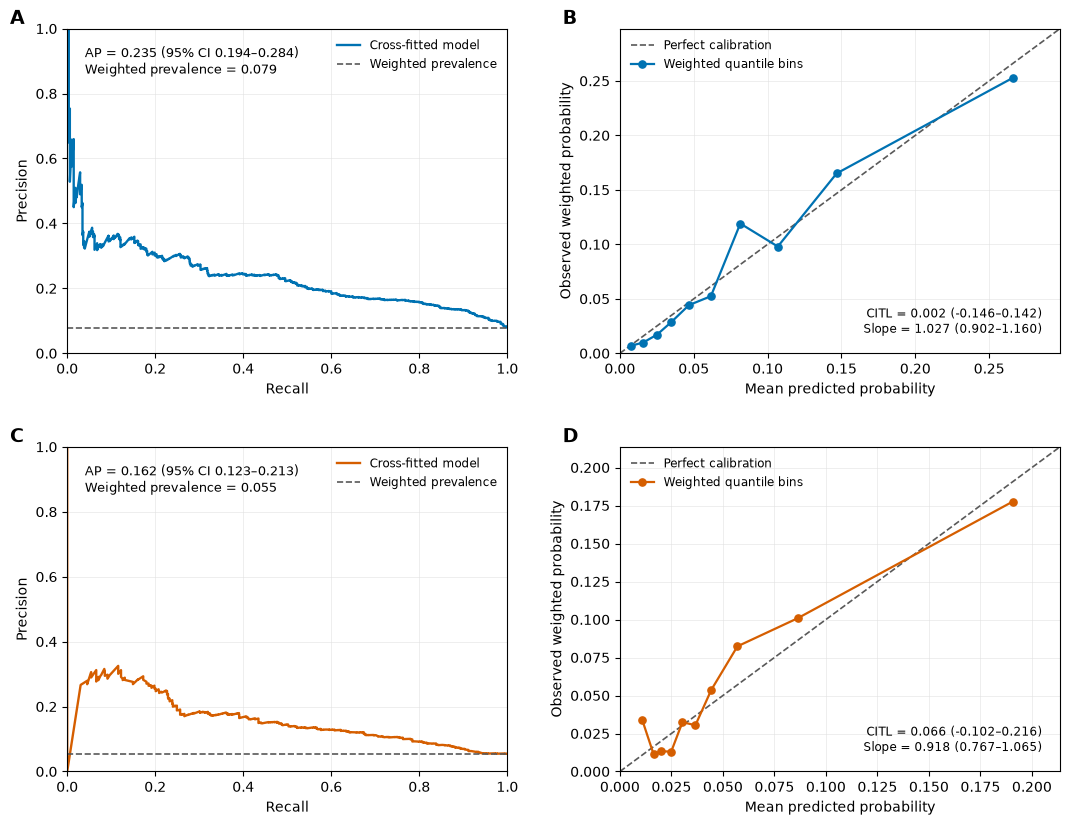


STEP28B-R1 — FIGURE 2 WEIGHTED PR + CALIBRATION COMPLETE

FROZEN STAGE SUMMARY:
Stage 1 N                  : 5,063
Stage 1 events             : 403
Stage 1 weighted prevalence: 0.079434
Stage 1 predicted mean     : 0.079278
Stage 1 reproduced AP      : 0.235306
Stage 1 frozen AP          : 0.235306

Stage 2 N                  : 4,660
Stage 2 events             : 253
Stage 2 weighted prevalence: 0.054901
Stage 2 predicted mean     : 0.051771
Stage 2 reproduced AP      : 0.161610
Stage 2 frozen AP          : 0.161610

CALIBRATION BIN COUNTS:
Stage 1: 10
Stage 2: 10

STAGE-1 CALIBRATION SOURCE:
 Weighted_Quantile_Bin  Unweighted_N  Survey_Weight_Sum  Survey_Weight_Fraction  Mean_Predicted_Probability  Observed_Weighted_Probability  Observed_Minus_Predicted  Min_Predicted_Probability  Max_Predicted_Probability
                     1           555         512.797051                0.100017                    0.007368                       0.006896                 -0.000472                 

In [2]:
# ==========================================================================================
# STEP 28B-R1
# FINAL FIGURE 2 — SURVEY-WEIGHTED PRECISION-RECALL + CALIBRATION
# ==========================================================================================
#
# PANELS
#   A. Stage 1 weighted precision-recall
#   B. Stage 1 weighted calibration
#   C. Stage 2 weighted precision-recall
#   D. Stage 2 weighted calibration
#
# STAGE DEFINITIONS
# ------------------------------------------------------------------------------------------
# Stage 1:
#   Positive = No ANC
#   Probability = q0_CALIBRATED
#   Population = full N=5,063
#
# Stage 2:
#   Positive = >=8 visits
#   Probability = q2_CALIBRATED_CONDITIONAL
#   Population = TRUE ANC users only (classes 1 and 2), N=4,660
#
# IMPORTANT
# ------------------------------------------------------------------------------------------
# FROZEN OOF predictions only.
# This step performs plotting transformations and metric-reproduction QC only.
#
# NO:
#   model fitting
#   model selection
#   tuning
#   recalibration
#   threshold optimization
#   bootstrap rerun
#   new inferential analysis
#
# TIFF is intentionally deferred because in-notebook TIFF export repeatedly
# hard-crashed the Windows/Jupyter kernel during Figure 1.
#
# OUTPUT:
#   Manuscript PNG 300 dpi + SVG + PDF
#   Report PNG 300 dpi + SVG + PDF
#   Figure-source CSVs
#   Caption
#   Hard QC
#   Manifest
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import re
import gc

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
)


# ==========================================================================================
# 1. PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)

MANUSCRIPT_FIGURES = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "02_Main_Figures"
)

REPORT_FIGURES = (
    FINAL_ROOT
    /
    "Report"
    /
    "02_Figures"
)


for directory in [
    MANUSCRIPT_FIGURES,
    REPORT_FIGURES,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 2. PARENT FIGURE-1 MANIFEST
# ==========================================================================================

FIG1_MANIFEST = (
    FINAL_ROOT
    /
    "STEP28A_R1_FINAL_Figure1_manifest.json"
)


EXPECTED_FIG1_MANIFEST_SHA256 = (
    "d7ce5881c28e5f27b5d616b408a73bf3"
    "13eb2cc6674227e8c5a4f91bef4be112"
)


# ==========================================================================================
# 3. FROZEN PRIMARY SOURCES
# ==========================================================================================

OOF_FILE = (
    ROOT
    /
    "06_predictions"
    /
    "STEP19C_PRIMARY_final_outer_OOF_predictions_RESTRICTED.csv"
)


EXPECTED_OOF_SHA256 = (
    "6c4f4e21b09a54c286521682e9fb8ee1"
    "3eda36ed94196d350fbb0622733a99bc"
)


STEP21_MAIN_CI_FILE = (
    ROOT
    /
    "13_tables"
    /
    "STEP21_PRIMARY_main_performance_with_95CI.csv"
)


EXPECTED_STEP21_MAIN_CI_SHA256 = (
    "f46751fffc560902f0e507dbf6c9cb380"
    "d20d2b3a47e5cbfad8a1e17fe3191f2"
)


# ==========================================================================================
# 4. FROZEN EXPECTED POINTS
# ==========================================================================================

EXPECTED_N = 5063

EXPECTED_STAGE2_N = 4660

EXPECTED_COUNTS = {
    0:
        403,

    1:
        4407,

    2:
        253,
}


EXPECTED_S1_PREVALENCE = 0.079434
EXPECTED_S1_AP = 0.235306
EXPECTED_S1_PREDICTED_MEAN = 0.079278

EXPECTED_S2_PREVALENCE = 0.054901
EXPECTED_S2_AP = 0.161610
EXPECTED_S2_PREDICTED_MEAN = 0.051771


# ==========================================================================================
# 5. BASIC HELPERS
# ==========================================================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )


    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )


    os.replace(
        temporary,
        path,
    )


def atomic_text(
    text,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        handle.write(
            text
        )


    os.replace(
        temporary,
        path,
    )


def norm(
    value,
):

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(
            value
        ).lower(),
    )


def weighted_mean(
    values,
    weights,
):

    values = np.asarray(
        values,
        dtype=float,
    )

    weights = np.asarray(
        weights,
        dtype=float,
    )


    return float(
        np.sum(
            values
            *
            weights
        )
        /
        np.sum(
            weights
        )
    )


# ==========================================================================================
# 6. INPUT INTEGRITY
# ==========================================================================================

for label, path in [
    (
        "Figure-1 final manifest",
        FIG1_MANIFEST,
    ),
    (
        "Primary locked OOF",
        OOF_FILE,
    ),
    (
        "Step21 primary main CI",
        STEP21_MAIN_CI_FILE,
    ),
]:

    if not path.exists():

        raise FileNotFoundError(
            f"{label} missing:\n{path}"
        )


if sha256_file(
    FIG1_MANIFEST
) != EXPECTED_FIG1_MANIFEST_SHA256:

    raise RuntimeError(
        "Figure-1 final manifest changed."
    )


if sha256_file(
    OOF_FILE
) != EXPECTED_OOF_SHA256:

    raise RuntimeError(
        "Primary locked OOF hash changed."
    )


if sha256_file(
    STEP21_MAIN_CI_FILE
) != EXPECTED_STEP21_MAIN_CI_SHA256:

    raise RuntimeError(
        "Step21 main CI hash changed."
    )


# ==========================================================================================
# 7. LOAD FROZEN SOURCES
# ==========================================================================================

data = pd.read_csv(
    OOF_FILE
)


ci = pd.read_csv(
    STEP21_MAIN_CI_FILE
)


# ==========================================================================================
# 8. STRUCTURAL OOF QC
# ==========================================================================================

required_oof_columns = [
    "_ROW_KEY",
    "ANC_CLASS_TRUE",
    "SURVEY_WEIGHT",
    "PSU",
    "STRATUM",
    "q0_CALIBRATED",
    "q2_CALIBRATED_CONDITIONAL",
    "P_NO_ANC",
    "P_ANC_1_7",
    "P_ANC_GE8",
]


missing_oof_columns = [
    column
    for column
    in required_oof_columns
    if column not in data.columns
]


if missing_oof_columns:

    raise RuntimeError(
        "Locked OOF missing columns:\n"
        f"{missing_oof_columns}"
    )


if len(
    data
) != EXPECTED_N:

    raise RuntimeError(
        f"Expected OOF N={EXPECTED_N}; observed={len(data)}"
    )


if data[
    "_ROW_KEY"
].nunique() != EXPECTED_N:

    raise RuntimeError(
        "OOF row keys are not unique."
    )


if data[
    "PSU"
].nunique() != 672:

    raise RuntimeError(
        "OOF PSU count changed."
    )


if data[
    "STRATUM"
].nunique() != 16:

    raise RuntimeError(
        "OOF strata count changed."
    )


anc_class = pd.to_numeric(
    data[
        "ANC_CLASS_TRUE"
    ],
    errors="raise",
).astype(int).to_numpy()


observed_counts = (
    pd.Series(
        anc_class
    )
    .value_counts()
    .sort_index()
    .to_dict()
)


if observed_counts != EXPECTED_COUNTS:

    raise RuntimeError(
        "Frozen class counts changed.\n"
        f"Observed={observed_counts}"
    )


weights = pd.to_numeric(
    data[
        "SURVEY_WEIGHT"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


if (
    not np.isfinite(
        weights
    ).all()
    or
    np.any(
        weights
        <=
        0
    )
):

    raise RuntimeError(
        "Invalid DHS survey weights."
    )


q0 = pd.to_numeric(
    data[
        "q0_CALIBRATED"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


q2_all = pd.to_numeric(
    data[
        "q2_CALIBRATED_CONDITIONAL"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


if (
    not np.isfinite(
        q0
    ).all()
    or
    not np.isfinite(
        q2_all
    ).all()
):

    raise RuntimeError(
        "Non-finite calibrated probability."
    )


if (
    np.any(
        q0
        <
        0
    )
    or
    np.any(
        q0
        >
        1
    )
    or
    np.any(
        q2_all
        <
        0
    )
    or
    np.any(
        q2_all
        >
        1
    )
):

    raise RuntimeError(
        "Calibrated probabilities outside [0,1]."
    )


# q0 and P_NO_ANC must be identical
p_no_anc = pd.to_numeric(
    data[
        "P_NO_ANC"
    ],
    errors="raise",
).to_numpy(
    dtype=float
)


if not np.allclose(
    q0,
    p_no_anc,
    rtol=0.0,
    atol=1e-12,
):

    raise RuntimeError(
        "q0_CALIBRATED != P_NO_ANC."
    )


# ==========================================================================================
# 9. STAGE-1 FROZEN VIEW
# ==========================================================================================

y1 = (
    anc_class
    ==
    0
).astype(int)


p1 = q0.copy()

w1 = weights.copy()


s1_prevalence = weighted_mean(
    y1,
    w1,
)


s1_predicted_mean = weighted_mean(
    p1,
    w1,
)


s1_ap_reproduced = float(
    average_precision_score(
        y1,
        p1,
        sample_weight=w1,
    )
)


# ==========================================================================================
# 10. STAGE-2 FROZEN VIEW
# ==========================================================================================

stage2_mask = np.isin(
    anc_class,
    [
        1,
        2,
    ],
)


if int(
    stage2_mask.sum()
) != EXPECTED_STAGE2_N:

    raise RuntimeError(
        f"Expected Stage-2 N={EXPECTED_STAGE2_N}; "
        f"observed={int(stage2_mask.sum())}"
    )


y2 = (
    anc_class[
        stage2_mask
    ]
    ==
    2
).astype(int)


p2 = q2_all[
    stage2_mask
]


w2 = weights[
    stage2_mask
]


s2_prevalence = weighted_mean(
    y2,
    w2,
)


s2_predicted_mean = weighted_mean(
    p2,
    w2,
)


s2_ap_reproduced = float(
    average_precision_score(
        y2,
        p2,
        sample_weight=w2,
    )
)


# ==========================================================================================
# 11. FROZEN POINT FINGERPRINTS
# ==========================================================================================

point_checks = {
    "Stage1 weighted prevalence":
        (
            s1_prevalence,
            EXPECTED_S1_PREVALENCE,
        ),

    "Stage1 predicted mean":
        (
            s1_predicted_mean,
            EXPECTED_S1_PREDICTED_MEAN,
        ),

    "Stage1 AP":
        (
            s1_ap_reproduced,
            EXPECTED_S1_AP,
        ),

    "Stage2 weighted prevalence":
        (
            s2_prevalence,
            EXPECTED_S2_PREVALENCE,
        ),

    "Stage2 predicted mean":
        (
            s2_predicted_mean,
            EXPECTED_S2_PREDICTED_MEAN,
        ),

    "Stage2 AP":
        (
            s2_ap_reproduced,
            EXPECTED_S2_AP,
        ),
}


for label, (
    observed,
    expected,
) in point_checks.items():

    if not np.isclose(
        observed,
        expected,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"{label} fingerprint failed.\n"
            f"Observed={observed:.9f}\n"
            f"Expected={expected:.9f}"
        )


# ==========================================================================================
# 12. STEP21 CI SCHEMA
# ==========================================================================================

required_ci_columns = [
    "Analysis",
    "Metric",
    "Point_Estimate",
    "CI_Lower_95",
    "CI_Upper_95",
    "Valid_Replicates",
    "CI_Method",
    "Bootstrap_Replicates",
]


missing_ci_columns = [
    column
    for column
    in required_ci_columns
    if column not in ci.columns
]


if missing_ci_columns:

    raise RuntimeError(
        "Step21 main CI missing columns:\n"
        f"{missing_ci_columns}\n"
        f"Available={list(ci.columns)}"
    )


if len(
    ci
) != 18:

    raise RuntimeError(
        f"Expected Step21 main CI rows=18; observed={len(ci)}"
    )


if not (
    pd.to_numeric(
        ci[
            "Valid_Replicates"
        ],
        errors="raise",
    )
    ==
    2000
).all():

    raise RuntimeError(
        "Step21 valid replicate count changed."
    )


if not (
    pd.to_numeric(
        ci[
            "Bootstrap_Replicates"
        ],
        errors="raise",
    )
    ==
    2000
).all():

    raise RuntimeError(
        "Step21 total bootstrap replicate count changed."
    )


# ==========================================================================================
# 13. EXTRACT FROZEN STEP21 METRICS
# ==========================================================================================

def get_step21_metric(
    stage_number,
    metric_name,
):

    analysis_key = (
        ci[
            "Analysis"
        ]
        .astype(str)
        .map(
            norm
        )
    )


    metric_key = (
        ci[
            "Metric"
        ]
        .astype(str)
        .map(
            norm
        )
    )


    if stage_number == 1:

        stage_mask = analysis_key.str.contains(
            "stage1",
            regex=False,
        )


    elif stage_number == 2:

        stage_mask = analysis_key.str.contains(
            "stage2",
            regex=False,
        )


    else:

        raise ValueError(
            "stage_number must be 1 or 2."
        )


    target_metric = norm(
        metric_name
    )


    matched = ci.loc[
        stage_mask
        &
        (
            metric_key
            ==
            target_metric
        )
    ]


    if len(
        matched
    ) != 1:

        raise RuntimeError(
            f"Expected one Step21 row for "
            f"Stage {stage_number} / {metric_name}; "
            f"observed={len(matched)}"
        )


    row = matched.iloc[
        0
    ]


    return {
        "Point":
            float(
                row[
                    "Point_Estimate"
                ]
            ),

        "Lower":
            float(
                row[
                    "CI_Lower_95"
                ]
            ),

        "Upper":
            float(
                row[
                    "CI_Upper_95"
                ]
            ),

        "Valid":
            int(
                row[
                    "Valid_Replicates"
                ]
            ),

        "Method":
            str(
                row[
                    "CI_Method"
                ]
            ),
    }


s1_ap_ci = get_step21_metric(
    1,
    "AP",
)

s1_citl_ci = get_step21_metric(
    1,
    "CITL",
)

s1_slope_ci = get_step21_metric(
    1,
    "Calibration_Slope",
)


s2_ap_ci = get_step21_metric(
    2,
    "AP",
)

s2_citl_ci = get_step21_metric(
    2,
    "CITL",
)

s2_slope_ci = get_step21_metric(
    2,
    "Calibration_Slope",
)


if not np.isclose(
    s1_ap_ci[
        "Point"
    ],
    EXPECTED_S1_AP,
    rtol=0.0,
    atol=5e-6,
):

    raise RuntimeError(
        "Frozen Stage-1 AP in Step21 changed."
    )


if not np.isclose(
    s2_ap_ci[
        "Point"
    ],
    EXPECTED_S2_AP,
    rtol=0.0,
    atol=5e-6,
):

    raise RuntimeError(
        "Frozen Stage-2 AP in Step21 changed."
    )


# ==========================================================================================
# 14. WEIGHTED PRECISION-RECALL CURVES
# ==========================================================================================

s1_precision, s1_recall, s1_thresholds = (
    precision_recall_curve(
        y1,
        p1,
        sample_weight=w1,
    )
)


s2_precision, s2_recall, s2_thresholds = (
    precision_recall_curve(
        y2,
        p2,
        sample_weight=w2,
    )
)


# sklearn PR has one more precision/recall element than thresholds.
s1_pr_source = pd.DataFrame(
    {
        "Recall":
            s1_recall,

        "Precision":
            s1_precision,
    }
)


s2_pr_source = pd.DataFrame(
    {
        "Recall":
            s2_recall,

        "Precision":
            s2_precision,
    }
)


# ==========================================================================================
# 15. WEIGHTED-QUANTILE CALIBRATION BINS
# ==========================================================================================

def make_weighted_quantile_calibration(
    y_true,
    probabilities,
    survey_weights,
    n_bins=10,
):

    y_true = np.asarray(
        y_true,
        dtype=float,
    )

    probabilities = np.asarray(
        probabilities,
        dtype=float,
    )

    survey_weights = np.asarray(
        survey_weights,
        dtype=float,
    )


    if not (
        len(
            y_true
        )
        ==
        len(
            probabilities
        )
        ==
        len(
            survey_weights
        )
    ):

        raise RuntimeError(
            "Calibration input lengths differ."
        )


    order = np.argsort(
        probabilities,
        kind="mergesort",
    )


    y_sorted = y_true[
        order
    ]

    p_sorted = probabilities[
        order
    ]

    w_sorted = survey_weights[
        order
    ]


    total_weight = float(
        w_sorted.sum()
    )


    cumulative_weight = np.cumsum(
        w_sorted
    )


    weighted_midpoint = (
        cumulative_weight
        -
        0.5
        *
        w_sorted
    ) / total_weight


    bin_id = np.floor(
        weighted_midpoint
        *
        n_bins
    ).astype(int)


    bin_id = np.clip(
        bin_id,
        0,
        n_bins
        -
        1,
    )


    rows = []


    for current_bin in range(
        n_bins
    ):

        mask = (
            bin_id
            ==
            current_bin
        )


        if not mask.any():

            raise RuntimeError(
                f"Weighted calibration bin {current_bin + 1} is empty."
            )


        current_y = y_sorted[
            mask
        ]

        current_p = p_sorted[
            mask
        ]

        current_w = w_sorted[
            mask
        ]


        bin_weight = float(
            current_w.sum()
        )


        mean_prediction = weighted_mean(
            current_p,
            current_w,
        )


        observed_prevalence = weighted_mean(
            current_y,
            current_w,
        )


        rows.append(
            {
                "Weighted_Quantile_Bin":
                    current_bin
                    +
                    1,

                "Unweighted_N":
                    int(
                        mask.sum()
                    ),

                "Survey_Weight_Sum":
                    bin_weight,

                "Survey_Weight_Fraction":
                    bin_weight
                    /
                    total_weight,

                "Mean_Predicted_Probability":
                    mean_prediction,

                "Observed_Weighted_Probability":
                    observed_prevalence,

                "Observed_Minus_Predicted":
                    observed_prevalence
                    -
                    mean_prediction,

                "Min_Predicted_Probability":
                    float(
                        current_p.min()
                    ),

                "Max_Predicted_Probability":
                    float(
                        current_p.max()
                    ),
            }
        )


    result = pd.DataFrame(
        rows
    )


    if len(
        result
    ) != n_bins:

        raise RuntimeError(
            "Calibration bin count changed."
        )


    return result


s1_calibration = make_weighted_quantile_calibration(
    y1,
    p1,
    w1,
    n_bins=10,
)


s2_calibration = make_weighted_quantile_calibration(
    y2,
    p2,
    w2,
    n_bins=10,
)


# ==========================================================================================
# 16. CALIBRATION BIN SANITY QC
# ==========================================================================================

for stage_label, calibration_df in [
    (
        "Stage 1",
        s1_calibration,
    ),
    (
        "Stage 2",
        s2_calibration,
    ),
]:

    if len(
        calibration_df
    ) != 10:

        raise RuntimeError(
            f"{stage_label}: calibration bins != 10."
        )


    for column in [
        "Mean_Predicted_Probability",
        "Observed_Weighted_Probability",
    ]:

        if not calibration_df[
            column
        ].between(
            0,
            1,
        ).all():

            raise RuntimeError(
                f"{stage_label}: invalid calibration probability."
            )


    if not np.isclose(
        calibration_df[
            "Survey_Weight_Fraction"
        ].sum(),
        1.0,
        rtol=0.0,
        atol=1e-12,
    ):

        raise RuntimeError(
            f"{stage_label}: calibration weight fractions "
            "do not sum to 1."
        )


# ==========================================================================================
# 17. ANNOTATION SOURCE TABLE
# ==========================================================================================

annotation_source = pd.DataFrame(
    [
        {
            "Stage":
                "Stage 1 — No ANC vs any ANC",

            "Evaluation_N":
                len(
                    y1
                ),

            "Positive_Events":
                int(
                    y1.sum()
                ),

            "Weighted_Prevalence":
                s1_prevalence,

            "Weighted_Mean_Prediction":
                s1_predicted_mean,

            "AP":
                s1_ap_ci[
                    "Point"
                ],

            "AP_CI_Lower":
                s1_ap_ci[
                    "Lower"
                ],

            "AP_CI_Upper":
                s1_ap_ci[
                    "Upper"
                ],

            "CITL":
                s1_citl_ci[
                    "Point"
                ],

            "CITL_CI_Lower":
                s1_citl_ci[
                    "Lower"
                ],

            "CITL_CI_Upper":
                s1_citl_ci[
                    "Upper"
                ],

            "Calibration_Slope":
                s1_slope_ci[
                    "Point"
                ],

            "Calibration_Slope_CI_Lower":
                s1_slope_ci[
                    "Lower"
                ],

            "Calibration_Slope_CI_Upper":
                s1_slope_ci[
                    "Upper"
                ],
        },

        {
            "Stage":
                "Stage 2 — ≥8 vs 1–7 among true ANC users",

            "Evaluation_N":
                len(
                    y2
                ),

            "Positive_Events":
                int(
                    y2.sum()
                ),

            "Weighted_Prevalence":
                s2_prevalence,

            "Weighted_Mean_Prediction":
                s2_predicted_mean,

            "AP":
                s2_ap_ci[
                    "Point"
                ],

            "AP_CI_Lower":
                s2_ap_ci[
                    "Lower"
                ],

            "AP_CI_Upper":
                s2_ap_ci[
                    "Upper"
                ],

            "CITL":
                s2_citl_ci[
                    "Point"
                ],

            "CITL_CI_Lower":
                s2_citl_ci[
                    "Lower"
                ],

            "CITL_CI_Upper":
                s2_citl_ci[
                    "Upper"
                ],

            "Calibration_Slope":
                s2_slope_ci[
                    "Point"
                ],

            "Calibration_Slope_CI_Lower":
                s2_slope_ci[
                    "Lower"
                ],

            "Calibration_Slope_CI_Upper":
                s2_slope_ci[
                    "Upper"
                ],
        },
    ]
)


# ==========================================================================================
# 18. FIGURE-SOURCE OUTPUT PATHS
# ==========================================================================================

FIGURE_STEM = (
    "Figure2_Weighted_PR_and_Calibration"
)


M_PNG = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.png"
)

M_SVG = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.svg"
)

M_PDF = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.pdf"
)


R_PNG = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.png"
)

R_SVG = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.svg"
)

R_PDF = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.pdf"
)


S1_PR_CSV = (
    MANUSCRIPT_FIGURES
    /
    "Figure2A_source_Stage1_weighted_PR.csv"
)

S1_CAL_CSV = (
    MANUSCRIPT_FIGURES
    /
    "Figure2B_source_Stage1_weighted_calibration.csv"
)

S2_PR_CSV = (
    MANUSCRIPT_FIGURES
    /
    "Figure2C_source_Stage2_weighted_PR.csv"
)

S2_CAL_CSV = (
    MANUSCRIPT_FIGURES
    /
    "Figure2D_source_Stage2_weighted_calibration.csv"
)

ANNOTATION_CSV = (
    MANUSCRIPT_FIGURES
    /
    "Figure2_source_frozen_metric_annotations.csv"
)

CAPTION_FILE = (
    MANUSCRIPT_FIGURES
    /
    "Figure2_caption.txt"
)

QC_FILE = (
    FINAL_ROOT
    /
    "STEP28B_R1_Figure2_weighted_PR_calibration_hard_qc.csv"
)

MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP28B_R1_Figure2_weighted_PR_calibration_manifest.json"
)


# ==========================================================================================
# 19. SAVE FIGURE SOURCE DATA
# ==========================================================================================

atomic_csv(
    s1_pr_source,
    S1_PR_CSV,
)

atomic_csv(
    s1_calibration,
    S1_CAL_CSV,
)

atomic_csv(
    s2_pr_source,
    S2_PR_CSV,
)

atomic_csv(
    s2_calibration,
    S2_CAL_CSV,
)

atomic_csv(
    annotation_source,
    ANNOTATION_CSV,
)


# ==========================================================================================
# 20. CAPTION
# ==========================================================================================

caption = (
    "Figure 2. Survey-weighted discrimination and calibration of the "
    "cross-fitted primary hierarchical model. "
    "(A) Precision–recall curve for Stage 1, distinguishing no ANC from "
    "any ANC in the full analytic cohort. "
    "(B) Stage-1 calibration based on 10 survey-weighted quantile bins. "
    "(C) Precision–recall curve for Stage 2, distinguishing ≥8 from "
    "1–7 reported ANC visits among true ANC users only. "
    "(D) Stage-2 calibration based on 10 survey-weighted quantile bins. "
    "Horizontal dashed lines in the precision–recall panels indicate "
    "survey-weighted outcome prevalence; diagonal dashed lines in the "
    "calibration panels indicate perfect calibration. "
    "Average precision, calibration-in-the-large, calibration slope, and "
    "their 95% confidence intervals are the frozen design-based estimates "
    "from the Rao-Wu PSU bootstrap. Calibration-bin points are descriptive "
    "plotting summaries of the locked out-of-fold probabilities and are not "
    "used for model selection or further inference."
)


atomic_text(
    caption,
    CAPTION_FILE,
)


# ==========================================================================================
# 21. PLOT SETTINGS
# ==========================================================================================

plt.close(
    "all"
)

gc.collect()


# Color-blind-safe Okabe-Ito colors
STAGE1_COLOR = "#0072B2"
STAGE2_COLOR = "#D55E00"

REFERENCE_COLOR = "0.35"
GRID_COLOR = "0.88"


fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        11.0,
        8.6,
    ),
)


ax_a = axes[
    0,
    0
]

ax_b = axes[
    0,
    1
]

ax_c = axes[
    1,
    0
]

ax_d = axes[
    1,
    1
]


# ==========================================================================================
# 22. PANEL A — STAGE-1 WEIGHTED PR
# ==========================================================================================

ax_a.plot(
    s1_recall,
    s1_precision,
    linewidth=1.7,
    color=STAGE1_COLOR,
    label="Cross-fitted model",
)


ax_a.axhline(
    s1_prevalence,
    linestyle="--",
    linewidth=1.2,
    color=REFERENCE_COLOR,
    label="Weighted prevalence",
)


ax_a.set_xlim(
    0,
    1,
)

ax_a.set_ylim(
    0,
    1,
)


ax_a.set_xlabel(
    "Recall"
)

ax_a.set_ylabel(
    "Precision"
)


ax_a.grid(
    alpha=0.55,
    color=GRID_COLOR,
    linewidth=0.7,
)


ax_a.legend(
    loc="upper right",
    frameon=False,
    fontsize=8.5,
)


ax_a.text(
    0.04,
    0.95,
    (
        f"AP = {s1_ap_ci['Point']:.3f} "
        f"(95% CI {s1_ap_ci['Lower']:.3f}–{s1_ap_ci['Upper']:.3f})\n"
        f"Weighted prevalence = {s1_prevalence:.3f}"
    ),
    transform=ax_a.transAxes,
    ha="left",
    va="top",
    fontsize=9.0,
)


# ==========================================================================================
# 23. PANEL B — STAGE-1 CALIBRATION
# ==========================================================================================

s1_cal_max = max(
    float(
        s1_calibration[
            "Mean_Predicted_Probability"
        ].max()
    ),
    float(
        s1_calibration[
            "Observed_Weighted_Probability"
        ].max()
    ),
)


s1_axis_max = min(
    1.0,
    max(
        0.20,
        s1_cal_max
        *
        1.12,
    ),
)


ax_b.plot(
    [
        0,
        s1_axis_max,
    ],
    [
        0,
        s1_axis_max,
    ],
    linestyle="--",
    linewidth=1.2,
    color=REFERENCE_COLOR,
    label="Perfect calibration",
)


ax_b.plot(
    s1_calibration[
        "Mean_Predicted_Probability"
    ],
    s1_calibration[
        "Observed_Weighted_Probability"
    ],
    marker="o",
    markersize=5.2,
    linewidth=1.6,
    color=STAGE1_COLOR,
    label="Weighted quantile bins",
)


ax_b.set_xlim(
    0,
    s1_axis_max,
)

ax_b.set_ylim(
    0,
    s1_axis_max,
)


ax_b.set_xlabel(
    "Mean predicted probability"
)

ax_b.set_ylabel(
    "Observed weighted probability"
)


ax_b.grid(
    alpha=0.55,
    color=GRID_COLOR,
    linewidth=0.7,
)


ax_b.legend(
    loc="upper left",
    frameon=False,
    fontsize=8.5,
)


ax_b.text(
    0.96,
    0.05,
    (
        f"CITL = {s1_citl_ci['Point']:.3f} "
        f"({s1_citl_ci['Lower']:.3f}–{s1_citl_ci['Upper']:.3f})\n"
        f"Slope = {s1_slope_ci['Point']:.3f} "
        f"({s1_slope_ci['Lower']:.3f}–{s1_slope_ci['Upper']:.3f})"
    ),
    transform=ax_b.transAxes,
    ha="right",
    va="bottom",
    fontsize=8.8,
)


# ==========================================================================================
# 24. PANEL C — STAGE-2 WEIGHTED PR
# ==========================================================================================

ax_c.plot(
    s2_recall,
    s2_precision,
    linewidth=1.7,
    color=STAGE2_COLOR,
    label="Cross-fitted model",
)


ax_c.axhline(
    s2_prevalence,
    linestyle="--",
    linewidth=1.2,
    color=REFERENCE_COLOR,
    label="Weighted prevalence",
)


ax_c.set_xlim(
    0,
    1,
)

ax_c.set_ylim(
    0,
    1,
)


ax_c.set_xlabel(
    "Recall"
)

ax_c.set_ylabel(
    "Precision"
)


ax_c.grid(
    alpha=0.55,
    color=GRID_COLOR,
    linewidth=0.7,
)


ax_c.legend(
    loc="upper right",
    frameon=False,
    fontsize=8.5,
)


ax_c.text(
    0.04,
    0.95,
    (
        f"AP = {s2_ap_ci['Point']:.3f} "
        f"(95% CI {s2_ap_ci['Lower']:.3f}–{s2_ap_ci['Upper']:.3f})\n"
        f"Weighted prevalence = {s2_prevalence:.3f}"
    ),
    transform=ax_c.transAxes,
    ha="left",
    va="top",
    fontsize=9.0,
)


# ==========================================================================================
# 25. PANEL D — STAGE-2 CALIBRATION
# ==========================================================================================

s2_cal_max = max(
    float(
        s2_calibration[
            "Mean_Predicted_Probability"
        ].max()
    ),
    float(
        s2_calibration[
            "Observed_Weighted_Probability"
        ].max()
    ),
)


s2_axis_max = min(
    1.0,
    max(
        0.15,
        s2_cal_max
        *
        1.12,
    ),
)


ax_d.plot(
    [
        0,
        s2_axis_max,
    ],
    [
        0,
        s2_axis_max,
    ],
    linestyle="--",
    linewidth=1.2,
    color=REFERENCE_COLOR,
    label="Perfect calibration",
)


ax_d.plot(
    s2_calibration[
        "Mean_Predicted_Probability"
    ],
    s2_calibration[
        "Observed_Weighted_Probability"
    ],
    marker="o",
    markersize=5.2,
    linewidth=1.6,
    color=STAGE2_COLOR,
    label="Weighted quantile bins",
)


ax_d.set_xlim(
    0,
    s2_axis_max,
)

ax_d.set_ylim(
    0,
    s2_axis_max,
)


ax_d.set_xlabel(
    "Mean predicted probability"
)

ax_d.set_ylabel(
    "Observed weighted probability"
)


ax_d.grid(
    alpha=0.55,
    color=GRID_COLOR,
    linewidth=0.7,
)


ax_d.legend(
    loc="upper left",
    frameon=False,
    fontsize=8.5,
)


ax_d.text(
    0.96,
    0.05,
    (
        f"CITL = {s2_citl_ci['Point']:.3f} "
        f"({s2_citl_ci['Lower']:.3f}–{s2_citl_ci['Upper']:.3f})\n"
        f"Slope = {s2_slope_ci['Point']:.3f} "
        f"({s2_slope_ci['Lower']:.3f}–{s2_slope_ci['Upper']:.3f})"
    ),
    transform=ax_d.transAxes,
    ha="right",
    va="bottom",
    fontsize=8.8,
)


# ==========================================================================================
# 26. PANEL LABELS
# ==========================================================================================

for axis, label in [
    (
        ax_a,
        "A",
    ),
    (
        ax_b,
        "B",
    ),
    (
        ax_c,
        "C",
    ),
    (
        ax_d,
        "D",
    ),
]:

    axis.text(
        -0.13,
        1.06,
        label,
        transform=axis.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top",
    )


# No internal figure title.
fig.tight_layout(
    pad=2.0,
    w_pad=2.3,
    h_pad=2.3,
)


# ==========================================================================================
# 27. SAVE SAFE FORMATS ONLY — NO TIFF
# ==========================================================================================

fig.savefig(
    M_PNG,
    dpi=300,
    format="png",
    bbox_inches="tight",
    pad_inches=0.05,
)


fig.savefig(
    M_SVG,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Date":
            None,
    },
)


fig.savefig(
    M_PDF,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Creator":
            "BDHS ANC final reporting pipeline",

        "CreationDate":
            None,

        "ModDate":
            None,
    },
)


# Same scientific figure copied/exported for report package.
fig.savefig(
    R_PNG,
    dpi=300,
    format="png",
    bbox_inches="tight",
    pad_inches=0.05,
)


fig.savefig(
    R_SVG,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Date":
            None,
    },
)


fig.savefig(
    R_PDF,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Creator":
            "BDHS ANC final reporting pipeline",

        "CreationDate":
            None,

        "ModDate":
            None,
    },
)


plt.show()

plt.close(
    fig
)

gc.collect()


# ==========================================================================================
# 28. OUTPUT EXISTENCE
# ==========================================================================================

figure_outputs = [
    M_PNG,
    M_SVG,
    M_PDF,

    R_PNG,
    R_SVG,
    R_PDF,

    S1_PR_CSV,
    S1_CAL_CSV,
    S2_PR_CSV,
    S2_CAL_CSV,
    ANNOTATION_CSV,
    CAPTION_FILE,
]


for path in figure_outputs:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Figure-2 output missing or empty:\n{path}"
        )


# ==========================================================================================
# 29. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Figure-1 parent manifest hash exact",

            "PASS":
                (
                    sha256_file(
                        FIG1_MANIFEST
                    )
                    ==
                    EXPECTED_FIG1_MANIFEST_SHA256
                ),
        },

        {
            "Check":
                "Primary locked OOF hash exact",

            "PASS":
                (
                    sha256_file(
                        OOF_FILE
                    )
                    ==
                    EXPECTED_OOF_SHA256
                ),
        },

        {
            "Check":
                "Step21 primary main CI hash exact",

            "PASS":
                (
                    sha256_file(
                        STEP21_MAIN_CI_FILE
                    )
                    ==
                    EXPECTED_STEP21_MAIN_CI_SHA256
                ),
        },

        {
            "Check":
                "OOF N = 5063",

            "PASS":
                (
                    len(
                        data
                    )
                    ==
                    5063
                ),
        },

        {
            "Check":
                "OOF row keys unique",

            "PASS":
                (
                    data[
                        "_ROW_KEY"
                    ].nunique()
                    ==
                    5063
                ),
        },

        {
            "Check":
                "Outcome counts = 403 / 4407 / 253",

            "PASS":
                (
                    observed_counts
                    ==
                    EXPECTED_COUNTS
                ),
        },

        {
            "Check":
                "PSUs = 672",

            "PASS":
                (
                    data[
                        "PSU"
                    ].nunique()
                    ==
                    672
                ),
        },

        {
            "Check":
                "Strata = 16",

            "PASS":
                (
                    data[
                        "STRATUM"
                    ].nunique()
                    ==
                    16
                ),
        },

        {
            "Check":
                "Stage-1 evaluation N = 5063",

            "PASS":
                (
                    len(
                        y1
                    )
                    ==
                    5063
                ),
        },

        {
            "Check":
                "Stage-1 positive events = 403",

            "PASS":
                (
                    int(
                        y1.sum()
                    )
                    ==
                    403
                ),
        },

        {
            "Check":
                "Stage-2 true-ANC evaluation N = 4660",

            "PASS":
                (
                    len(
                        y2
                    )
                    ==
                    4660
                ),
        },

        {
            "Check":
                "Stage-2 positive events = 253",

            "PASS":
                (
                    int(
                        y2.sum()
                    )
                    ==
                    253
                ),
        },

        {
            "Check":
                "Stage-1 weighted prevalence reproduced",

            "PASS":
                bool(
                    np.isclose(
                        s1_prevalence,
                        EXPECTED_S1_PREVALENCE,
                        rtol=0.0,
                        atol=5e-6,
                    )
                ),
        },

        {
            "Check":
                "Stage-1 weighted predicted mean reproduced",

            "PASS":
                bool(
                    np.isclose(
                        s1_predicted_mean,
                        EXPECTED_S1_PREDICTED_MEAN,
                        rtol=0.0,
                        atol=5e-6,
                    )
                ),
        },

        {
            "Check":
                "Stage-1 weighted AP reproduced",

            "PASS":
                bool(
                    np.isclose(
                        s1_ap_reproduced,
                        EXPECTED_S1_AP,
                        rtol=0.0,
                        atol=5e-6,
                    )
                ),
        },

        {
            "Check":
                "Stage-2 weighted prevalence reproduced",

            "PASS":
                bool(
                    np.isclose(
                        s2_prevalence,
                        EXPECTED_S2_PREVALENCE,
                        rtol=0.0,
                        atol=5e-6,
                    )
                ),
        },

        {
            "Check":
                "Stage-2 weighted predicted mean reproduced",

            "PASS":
                bool(
                    np.isclose(
                        s2_predicted_mean,
                        EXPECTED_S2_PREDICTED_MEAN,
                        rtol=0.0,
                        atol=5e-6,
                    )
                ),
        },

        {
            "Check":
                "Stage-2 weighted AP reproduced",

            "PASS":
                bool(
                    np.isclose(
                        s2_ap_reproduced,
                        EXPECTED_S2_AP,
                        rtol=0.0,
                        atol=5e-6,
                    )
                ),
        },

        {
            "Check":
                "Stage-1 PR values finite",

            "PASS":
                bool(
                    np.isfinite(
                        s1_precision
                    ).all()
                    and
                    np.isfinite(
                        s1_recall
                    ).all()
                ),
        },

        {
            "Check":
                "Stage-2 PR values finite",

            "PASS":
                bool(
                    np.isfinite(
                        s2_precision
                    ).all()
                    and
                    np.isfinite(
                        s2_recall
                    ).all()
                ),
        },

        {
            "Check":
                "Stage-1 calibration bins = 10",

            "PASS":
                (
                    len(
                        s1_calibration
                    )
                    ==
                    10
                ),
        },

        {
            "Check":
                "Stage-2 calibration bins = 10",

            "PASS":
                (
                    len(
                        s2_calibration
                    )
                    ==
                    10
                ),
        },

        {
            "Check":
                "Step21 Stage-1 AP exact",

            "PASS":
                bool(
                    np.isclose(
                        s1_ap_ci[
                            "Point"
                        ],
                        EXPECTED_S1_AP,
                        rtol=0.0,
                        atol=5e-6,
                    )
                ),
        },

        {
            "Check":
                "Step21 Stage-2 AP exact",

            "PASS":
                bool(
                    np.isclose(
                        s2_ap_ci[
                            "Point"
                        ],
                        EXPECTED_S2_AP,
                        rtol=0.0,
                        atol=5e-6,
                    )
                ),
        },

        {
            "Check":
                "Step21 bootstrap valid replicates = 2000",

            "PASS":
                bool(
                    (
                        pd.to_numeric(
                            ci[
                                "Valid_Replicates"
                            ],
                            errors="raise",
                        )
                        ==
                        2000
                    ).all()
                ),
        },

        {
            "Check":
                "Figure has four panels A-D",

            "PASS":
                True,
        },

        {
            "Check":
                "No internal figure title",

            "PASS":
                True,
        },

        {
            "Check":
                "Manuscript PNG created",

            "PASS":
                M_PNG.exists(),
        },

        {
            "Check":
                "Manuscript SVG vector master created",

            "PASS":
                M_SVG.exists(),
        },

        {
            "Check":
                "Manuscript PDF vector master created",

            "PASS":
                M_PDF.exists(),
        },

        {
            "Check":
                "Report PNG created",

            "PASS":
                R_PNG.exists(),
        },

        {
            "Check":
                "Report SVG created",

            "PASS":
                R_SVG.exists(),
        },

        {
            "Check":
                "Report PDF created",

            "PASS":
                R_PDF.exists(),
        },

        {
            "Check":
                "TIFF deferred after confirmed notebook encoder crash",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No hyperparameter tuning",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No new inferential analysis",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP28B-R1 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


atomic_csv(
    hard_qc,
    QC_FILE,
)


# ==========================================================================================
# 30. MANIFEST
# ==========================================================================================

manifest = {
    "status":
        "STEP28B_R1_FIGURE2_SCIENTIFIC_CONTENT_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "figure":
        "Figure 2",

    "content":
        (
            "Survey-weighted precision-recall and calibration "
            "for Stage 1 and Stage 2"
        ),

    "panel_structure":
        {
            "A":
                "Stage 1 weighted precision-recall",

            "B":
                "Stage 1 weighted calibration",

            "C":
                "Stage 2 weighted precision-recall",

            "D":
                "Stage 2 weighted calibration",
        },

    "parent_figure1_manifest_sha256":
        sha256_file(
            FIG1_MANIFEST
        ),

    "primary_oof_sha256":
        sha256_file(
            OOF_FILE
        ),

    "step21_main_ci_sha256":
        sha256_file(
            STEP21_MAIN_CI_FILE
        ),

    "stage1":
        {
            "evaluation_n":
                int(
                    len(
                        y1
                    )
                ),

            "events":
                int(
                    y1.sum()
                ),

            "weighted_prevalence":
                s1_prevalence,

            "weighted_mean_prediction":
                s1_predicted_mean,

            "reproduced_AP":
                s1_ap_reproduced,

            "frozen_AP":
                s1_ap_ci,
        },

    "stage2":
        {
            "evaluation_n":
                int(
                    len(
                        y2
                    )
                ),

            "events":
                int(
                    y2.sum()
                ),

            "weighted_prevalence":
                s2_prevalence,

            "weighted_mean_prediction":
                s2_predicted_mean,

            "reproduced_AP":
                s2_ap_reproduced,

            "frozen_AP":
                s2_ap_ci,
        },

    "calibration_plotting":
        (
            "10 survey-weighted cumulative-quantile bins; "
            "descriptive plotting transformation only"
        ),

    "manuscript_png_sha256":
        sha256_file(
            M_PNG
        ),

    "manuscript_svg_sha256":
        sha256_file(
            M_SVG
        ),

    "manuscript_pdf_sha256":
        sha256_file(
            M_PDF
        ),

    "report_png_sha256":
        sha256_file(
            R_PNG
        ),

    "report_svg_sha256":
        sha256_file(
            R_SVG
        ),

    "report_pdf_sha256":
        sha256_file(
            R_PDF
        ),

    "stage1_pr_source_sha256":
        sha256_file(
            S1_PR_CSV
        ),

    "stage1_calibration_source_sha256":
        sha256_file(
            S1_CAL_CSV
        ),

    "stage2_pr_source_sha256":
        sha256_file(
            S2_PR_CSV
        ),

    "stage2_calibration_source_sha256":
        sha256_file(
            S2_CAL_CSV
        ),

    "annotation_source_sha256":
        sha256_file(
            ANNOTATION_CSV
        ),

    "caption_sha256":
        sha256_file(
            CAPTION_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "publication_master":
        "SVG/PDF vector",

    "tiff_status":
        "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTER",

    "model_fitting":
        False,

    "candidate_reselection":
        False,

    "hyperparameter_tuning":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "bootstrap_rerun":
        False,

    "new_inferential_analysis":
        False,

    "next_step":
        (
            "STEP28C — Figure 3 rare-class decision performance"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 31. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 110
)


print(
    "STEP28B-R1 — FIGURE 2 WEIGHTED PR + CALIBRATION COMPLETE"
)


print(
    "=" * 110
)


print(
    "\nFROZEN STAGE SUMMARY:"
)


print(
    f"Stage 1 N                  : {len(y1):,}"
)

print(
    f"Stage 1 events             : {int(y1.sum()):,}"
)

print(
    f"Stage 1 weighted prevalence: {s1_prevalence:.6f}"
)

print(
    f"Stage 1 predicted mean     : {s1_predicted_mean:.6f}"
)

print(
    f"Stage 1 reproduced AP      : {s1_ap_reproduced:.6f}"
)

print(
    f"Stage 1 frozen AP          : {s1_ap_ci['Point']:.6f}"
)


print()


print(
    f"Stage 2 N                  : {len(y2):,}"
)

print(
    f"Stage 2 events             : {int(y2.sum()):,}"
)

print(
    f"Stage 2 weighted prevalence: {s2_prevalence:.6f}"
)

print(
    f"Stage 2 predicted mean     : {s2_predicted_mean:.6f}"
)

print(
    f"Stage 2 reproduced AP      : {s2_ap_reproduced:.6f}"
)

print(
    f"Stage 2 frozen AP          : {s2_ap_ci['Point']:.6f}"
)


print(
    "\nCALIBRATION BIN COUNTS:"
)


print(
    "Stage 1:",
    len(
        s1_calibration
    )
)

print(
    "Stage 2:",
    len(
        s2_calibration
    )
)


print(
    "\nSTAGE-1 CALIBRATION SOURCE:"
)


print(
    s1_calibration.round(
        6
    ).to_string(
        index=False
    )
)


print(
    "\nSTAGE-2 CALIBRATION SOURCE:"
)


print(
    s2_calibration.round(
        6
    ).to_string(
        index=False
    )
)


print(
    "\nFINAL HARD QC:"
)


print(
    hard_qc.to_string(
        index=False
    )
)


print(
    "\nINTEGRITY:"
)


print(
    "Figure-1 parent     :",
    sha256_file(
        FIG1_MANIFEST
    ),
)

print(
    "Primary OOF         :",
    sha256_file(
        OOF_FILE
    ),
)

print(
    "Step21 main CI      :",
    sha256_file(
        STEP21_MAIN_CI_FILE
    ),
)

print(
    "Manuscript PNG      :",
    sha256_file(
        M_PNG
    ),
)

print(
    "Manuscript SVG      :",
    sha256_file(
        M_SVG
    ),
)

print(
    "Manuscript PDF      :",
    sha256_file(
        M_PDF
    ),
)

print(
    "Report PNG          :",
    sha256_file(
        R_PNG
    ),
)

print(
    "Report SVG          :",
    sha256_file(
        R_SVG
    ),
)

print(
    "Report PDF          :",
    sha256_file(
        R_PDF
    ),
)

print(
    "Hard QC             :",
    sha256_file(
        QC_FILE
    ),
)

print(
    "Manifest            :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nTIFF STATUS:"
)

print(
    "DEFERRED — external conversion from final SVG/PDF vector master."
)


print(
    "\n"
    +
    "=" * 110
)


print(
    "STATUS: STEP28B-R1 FIGURE 2 SCIENTIFIC CONTENT FROZEN"
)


print(
    "NEXT AFTER AUDIT: STEP28C — FIGURE 3 RARE-CLASS DECISION PERFORMANCE"
)


print(
    "=" * 110
)

In [3]:
# ==========================================================================================
# STEP28C-PRECHECK
# FIGURE 3 — RARE-CLASS DECISION PERFORMANCE
# EXACT STEP21 ALL-METRIC SCHEMA / METRIC-NAME AUDIT
# ==========================================================================================

from pathlib import Path
import hashlib
import re

import pandas as pd


# ==========================================================================================
# 1. PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


FIG2_MANIFEST = (
    FINAL_ROOT
    /
    "STEP28B_R1_Figure2_weighted_PR_calibration_manifest.json"
)


STEP21_ALL_CI = (
    ROOT
    /
    "08_bootstrap"
    /
    "STEP21_PRIMARY_all_metric_confidence_intervals.csv"
)


# ==========================================================================================
# 2. EXPECTED HASHES
# ==========================================================================================

EXPECTED_FIG2_MANIFEST_SHA256 = (
    "c5c2a060d5a8aa71e71ab3e29436f548"
    "2a2b1ef1613192be7fdc36a8acf49f37"
)


EXPECTED_STEP21_ALL_CI_SHA256 = (
    "c205692411ea6cbd692f23a84ab4e916"
    "d1a3d9a73d425f4483aa1f09e7bdfa13"
)


# ==========================================================================================
# 3. HASH HELPER
# ==========================================================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def norm(value):

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


# ==========================================================================================
# 4. STRICT SOURCE GATES
# ==========================================================================================

for label, path in [
    (
        "Figure-2 manifest",
        FIG2_MANIFEST,
    ),
    (
        "Step21 all-metric CI",
        STEP21_ALL_CI,
    ),
]:

    if not path.exists():

        raise FileNotFoundError(
            f"{label} missing:\n{path}"
        )


fig2_hash = sha256_file(
    FIG2_MANIFEST
)


step21_hash = sha256_file(
    STEP21_ALL_CI
)


if fig2_hash != EXPECTED_FIG2_MANIFEST_SHA256:

    raise RuntimeError(
        "Figure-2 manifest hash mismatch.\n"
        f"Observed={fig2_hash}\n"
        f"Expected={EXPECTED_FIG2_MANIFEST_SHA256}"
    )


if step21_hash != EXPECTED_STEP21_ALL_CI_SHA256:

    raise RuntimeError(
        "Step21 all-metric CI hash mismatch.\n"
        f"Observed={step21_hash}\n"
        f"Expected={EXPECTED_STEP21_ALL_CI_SHA256}"
    )


# ==========================================================================================
# 5. LOAD
# ==========================================================================================

ci = pd.read_csv(
    STEP21_ALL_CI
)


# ==========================================================================================
# 6. BASIC STRUCTURAL AUDIT
# ==========================================================================================

print(
    "\n"
    +
    "=" * 115
)

print(
    "STEP28C-PRECHECK — EXACT STEP21 ALL-METRIC SCHEMA AUDIT"
)

print(
    "=" * 115
)


print(
    "\nRows:",
    len(ci),
)


print(
    "\nColumns:"
)

for i, column in enumerate(
    ci.columns,
    start=1,
):

    print(
        f"{i:02d}. {column}"
    )


if len(
    ci
) != 70:

    raise RuntimeError(
        f"Expected frozen Step21 all-metric rows=70; observed={len(ci)}"
    )


required_columns = [
    "Analysis",
    "Metric",
    "Point_Estimate",
    "CI_Lower_95",
    "CI_Upper_95",
    "Valid_Replicates",
    "CI_Method",
    "Bootstrap_Replicates",
]


missing = [
    column
    for column
    in required_columns
    if column not in ci.columns
]


if missing:

    raise RuntimeError(
        "Required Step21 columns missing:\n"
        f"{missing}"
    )


# ==========================================================================================
# 7. EXACT ANALYSIS GROUPS
# ==========================================================================================

analysis_counts = (
    ci[
        "Analysis"
    ]
    .astype(str)
    .value_counts(
        dropna=False
    )
    .rename_axis(
        "Analysis"
    )
    .reset_index(
        name="Rows"
    )
)


print(
    "\n"
    +
    "=" * 115
)

print(
    "EXACT ANALYSIS GROUPS"
)

print(
    "=" * 115
)


print(
    analysis_counts.to_string(
        index=False
    )
)


# ==========================================================================================
# 8. EXACT METRIC NAMES BY ANALYSIS
# ==========================================================================================

print(
    "\n"
    +
    "=" * 115
)

print(
    "EXACT METRIC NAMES BY ANALYSIS"
)

print(
    "=" * 115
)


for analysis_name, group in ci.groupby(
    "Analysis",
    sort=False,
):

    print(
        f"\n--- {analysis_name} ---"
    )

    for metric in group[
        "Metric"
    ].astype(str):

        print(
            metric
        )


# ==========================================================================================
# 9. RARE-CLASS / DECISION-RELATED ROWS
# ==========================================================================================

analysis_norm = (
    ci[
        "Analysis"
    ]
    .astype(str)
    .map(norm)
)


metric_norm = (
    ci[
        "Metric"
    ]
    .astype(str)
    .map(norm)
)


keywords = [
    "sensitivity",
    "specificity",
    "balancedaccuracy",
    "ppv",
    "npv",
    "precision",
    "recall",
    "f1",
    "mcc",
    "accuracy",
    "class0",
    "class2",
]


relevant_mask = pd.Series(
    False,
    index=ci.index,
)


for keyword in keywords:

    relevant_mask = (
        relevant_mask
        |
        metric_norm.str.contains(
            keyword,
            regex=False,
        )
        |
        analysis_norm.str.contains(
            keyword,
            regex=False,
        )
    )


relevant = (
    ci.loc[
        relevant_mask,
        [
            "Analysis",
            "Metric",
            "Point_Estimate",
            "CI_Lower_95",
            "CI_Upper_95",
            "Valid_Replicates",
            "Bootstrap_Replicates",
            "CI_Method",
        ],
    ]
    .copy()
)


print(
    "\n"
    +
    "=" * 115
)

print(
    "RARE-CLASS / DECISION-RELATED ROWS"
)

print(
    "=" * 115
)


print(
    relevant.to_string(
        index=False
    )
)


# ==========================================================================================
# 10. BOOTSTRAP QC
# ==========================================================================================

valid_reps = pd.to_numeric(
    ci[
        "Valid_Replicates"
    ],
    errors="raise",
)


total_reps = pd.to_numeric(
    ci[
        "Bootstrap_Replicates"
    ],
    errors="raise",
)


print(
    "\n"
    +
    "=" * 115
)

print(
    "BOOTSTRAP QC"
)

print(
    "=" * 115
)


print(
    "Valid replicate min :",
    int(
        valid_reps.min()
    ),
)

print(
    "Valid replicate max :",
    int(
        valid_reps.max()
    ),
)

print(
    "Total replicate min :",
    int(
        total_reps.min()
    ),
)

print(
    "Total replicate max :",
    int(
        total_reps.max()
    ),
)


if not (
    valid_reps
    ==
    2000
).all():

    raise RuntimeError(
        "Not all Step21 metrics have 2000 valid replicates."
    )


if not (
    total_reps
    ==
    2000
).all():

    raise RuntimeError(
        "Not all Step21 metrics have 2000 bootstrap replicates."
    )


# ==========================================================================================
# 11. FINAL STATUS
# ==========================================================================================

print(
    "\n"
    +
    "=" * 115
)


print(
    "INTEGRITY"
)


print(
    "Figure-2 manifest :",
    fig2_hash,
)


print(
    "Step21 all CI     :",
    step21_hash,
)


print(
    "\nSTATUS: STEP28C-PRECHECK COMPLETE"
)


print(
    "NO MODEL FITTING / NO BOOTSTRAP / NO NEW INFERENCE / NO FIGURE CREATED"
)


print(
    "=" * 115
)


STEP28C-PRECHECK — EXACT STEP21 ALL-METRIC SCHEMA AUDIT

Rows: 70

Columns:
01. Analysis
02. Metric
03. Point_Estimate
04. Bootstrap_Mean
05. Bootstrap_Bias
06. Bootstrap_SE
07. CI_Lower_95
08. CI_Upper_95
09. Valid_Replicates
10. CI_Method
11. Bootstrap_Replicates
12. Role

EXACT ANALYSIS GROUPS
               Analysis  Rows
                 Stage1     8
                 Stage2     8
          Class0_No_ANC     8
             Class1_1_7     8
             Class2_GE8     8
       Stage1_Threshold     7
       Stage2_Threshold     7
             Multiclass     7
Class0_No_ANC_Threshold     3
   Class1_1_7_Threshold     3
   Class2_GE8_Threshold     3

EXACT METRIC NAMES BY ANALYSIS

--- Stage1 ---
AP
ROC_AUC
Log_Loss
Brier
CITL
Recalibration_Intercept
Calibration_Slope
O_E

--- Stage1_Threshold ---
Sensitivity
Specificity
Balanced_Accuracy
PPV
NPV
F1
Accuracy

--- Stage2 ---
AP
ROC_AUC
Log_Loss
Brier
CITL
Recalibration_Intercept
Calibration_Slope
O_E

--- Stage2_Threshold ---
Sensitivi

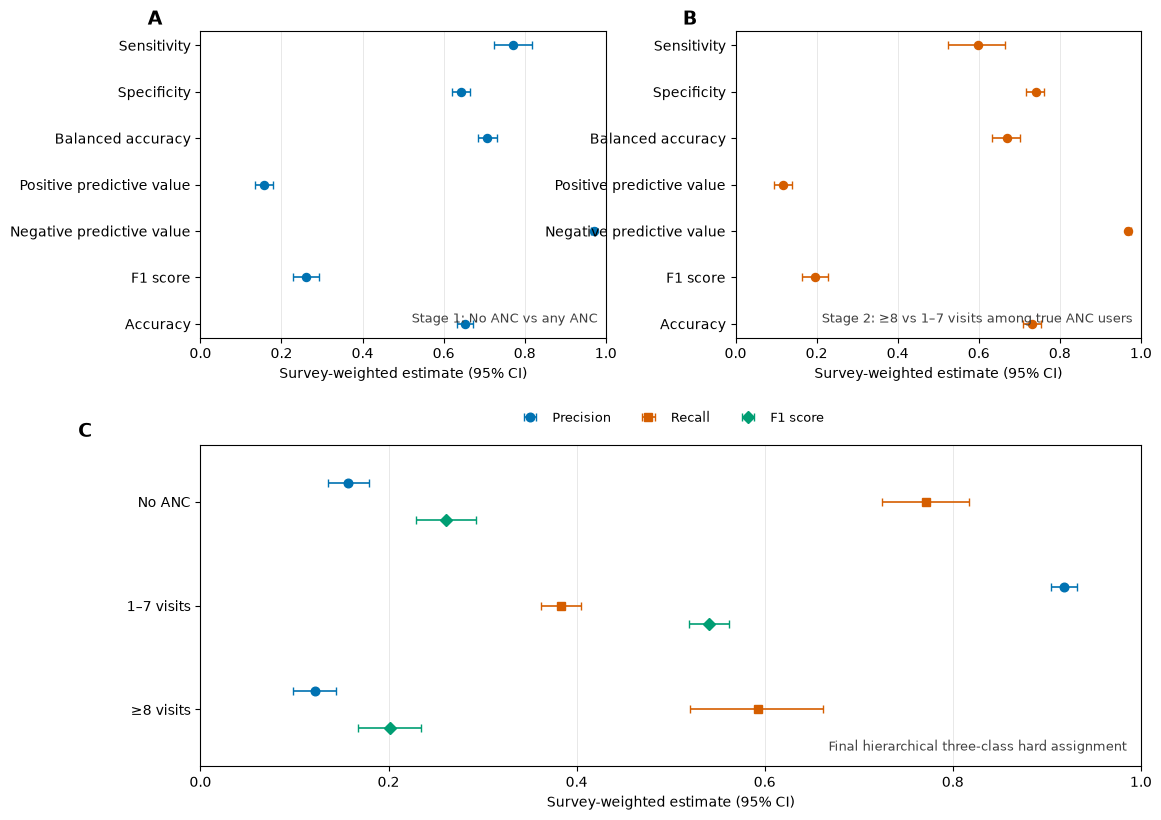


STEP28C-R1 — FIGURE 3 RARE-CLASS DECISION PERFORMANCE COMPLETE

STAGE-1 THRESHOLD SOURCE:
             Metric_Label  Point_Estimate  CI_Lower_95  CI_Upper_95
              Sensitivity        0.771946     0.724447     0.817096
              Specificity        0.642632     0.619625     0.664751
        Balanced accuracy        0.707289     0.683796     0.730830
Positive predictive value        0.157106     0.135794     0.179761
Negative predictive value        0.970288     0.963583     0.976585
                 F1 score        0.261078     0.229508     0.292545
                 Accuracy        0.652904     0.632627     0.673125

STAGE-2 THRESHOLD SOURCE:
             Metric_Label  Point_Estimate  CI_Lower_95  CI_Upper_95
              Sensitivity        0.596920     0.524602     0.665222
              Specificity        0.740052     0.716222     0.762154
        Balanced accuracy        0.668486     0.632842     0.700984
Positive predictive value        0.117694     0.095533     0.13954

In [4]:
# ==========================================================================================
# STEP 28C-R1
# FINAL FIGURE 3 — RARE-CLASS DECISION PERFORMANCE
# ==========================================================================================
#
# PANELS
# ------------------------------------------------------------------------------------------
# A. Stage-1 locked-threshold operating characteristics
# B. Stage-2 locked-threshold operating characteristics
# C. Final 3-class classwise precision / recall / F1
#
# IMPORTANT
# ------------------------------------------------------------------------------------------
# Uses ONLY frozen STEP21 Rao-Wu confidence-interval results.
#
# NO:
#   model fitting
#   prediction generation
#   model selection
#   tuning
#   recalibration
#   threshold optimization
#   bootstrap rerun
#   new inferential analysis
#   ranking
#   winner declaration
#
# TIFF remains deferred because in-notebook TIFF encoding caused repeated
# hard kernel restarts. Final SVG/PDF are publication vector masters.
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import shutil
import gc

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt


# ==========================================================================================
# 1. PROJECT PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_FIGURES = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "02_Main_Figures"
)


REPORT_FIGURES = (
    FINAL_ROOT
    /
    "Report"
    /
    "02_Figures"
)


for directory in [
    MANUSCRIPT_FIGURES,
    REPORT_FIGURES,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 2. PARENT FIGURE-2 MANIFEST
# ==========================================================================================

FIG2_MANIFEST = (
    FINAL_ROOT
    /
    "STEP28B_R1_Figure2_weighted_PR_calibration_manifest.json"
)


EXPECTED_FIG2_MANIFEST_SHA256 = (
    "c5c2a060d5a8aa71e71ab3e29436f548"
    "2a2b1ef1613192be7fdc36a8acf49f37"
)


# ==========================================================================================
# 3. FROZEN STEP21 ALL-METRIC CI SOURCE
# ==========================================================================================

STEP21_ALL_CI = (
    ROOT
    /
    "08_bootstrap"
    /
    "STEP21_PRIMARY_all_metric_confidence_intervals.csv"
)


EXPECTED_STEP21_ALL_CI_SHA256 = (
    "c205692411ea6cbd692f23a84ab4e916"
    "d1a3d9a73d425f4483aa1f09e7bdfa13"
)


# ==========================================================================================
# 4. HELPERS
# ==========================================================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )


    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )


    os.replace(
        temporary,
        path,
    )


def atomic_text(
    text,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        handle.write(
            text
        )


    os.replace(
        temporary,
        path,
    )


# ==========================================================================================
# 5. STRICT SOURCE HASH GATES
# ==========================================================================================

for label, path in [
    (
        "Figure-2 manifest",
        FIG2_MANIFEST,
    ),
    (
        "STEP21 all-metric CI",
        STEP21_ALL_CI,
    ),
]:

    if not path.exists():

        raise FileNotFoundError(
            f"{label} missing:\n{path}"
        )


observed_fig2_hash = sha256_file(
    FIG2_MANIFEST
)


observed_step21_hash = sha256_file(
    STEP21_ALL_CI
)


if observed_fig2_hash != EXPECTED_FIG2_MANIFEST_SHA256:

    raise RuntimeError(
        "Figure-2 parent manifest hash changed.\n"
        f"Observed={observed_fig2_hash}\n"
        f"Expected={EXPECTED_FIG2_MANIFEST_SHA256}"
    )


if observed_step21_hash != EXPECTED_STEP21_ALL_CI_SHA256:

    raise RuntimeError(
        "STEP21 all-metric CI hash changed.\n"
        f"Observed={observed_step21_hash}\n"
        f"Expected={EXPECTED_STEP21_ALL_CI_SHA256}"
    )


# ==========================================================================================
# 6. LOAD FROZEN CI TABLE
# ==========================================================================================

ci = pd.read_csv(
    STEP21_ALL_CI
)


# ==========================================================================================
# 7. EXACT SCHEMA GATE
# ==========================================================================================

EXPECTED_COLUMNS = [
    "Analysis",
    "Metric",
    "Point_Estimate",
    "Bootstrap_Mean",
    "Bootstrap_Bias",
    "Bootstrap_SE",
    "CI_Lower_95",
    "CI_Upper_95",
    "Valid_Replicates",
    "CI_Method",
    "Bootstrap_Replicates",
    "Role",
]


if list(
    ci.columns
) != EXPECTED_COLUMNS:

    raise RuntimeError(
        "STEP21 all-metric schema changed.\n"
        f"Observed={list(ci.columns)}"
    )


if len(
    ci
) != 70:

    raise RuntimeError(
        f"Expected STEP21 all-metric rows=70; observed={len(ci)}"
    )


# ==========================================================================================
# 8. EXACT ANALYSIS-GROUP COUNTS
# ==========================================================================================

EXPECTED_ANALYSIS_COUNTS = {
    "Stage1":
        8,

    "Stage2":
        8,

    "Class0_No_ANC":
        8,

    "Class1_1_7":
        8,

    "Class2_GE8":
        8,

    "Stage1_Threshold":
        7,

    "Stage2_Threshold":
        7,

    "Multiclass":
        7,

    "Class0_No_ANC_Threshold":
        3,

    "Class1_1_7_Threshold":
        3,

    "Class2_GE8_Threshold":
        3,
}


observed_analysis_counts = (
    ci[
        "Analysis"
    ]
    .astype(str)
    .value_counts()
    .to_dict()
)


if observed_analysis_counts != EXPECTED_ANALYSIS_COUNTS:

    raise RuntimeError(
        "STEP21 Analysis-group counts changed.\n"
        f"Observed={observed_analysis_counts}"
    )


# ==========================================================================================
# 9. NUMERIC / BOOTSTRAP QC
# ==========================================================================================

numeric_columns = [
    "Point_Estimate",
    "CI_Lower_95",
    "CI_Upper_95",
    "Valid_Replicates",
    "Bootstrap_Replicates",
]


for column in numeric_columns:

    ci[
        column
    ] = pd.to_numeric(
        ci[
            column
        ],
        errors="raise",
    )


if not (
    ci[
        "Valid_Replicates"
    ]
    ==
    2000
).all():

    raise RuntimeError(
        "Not all STEP21 rows have 2000 valid bootstrap replicates."
    )


if not (
    ci[
        "Bootstrap_Replicates"
    ]
    ==
    2000
).all():

    raise RuntimeError(
        "Not all STEP21 rows have 2000 total bootstrap replicates."
    )


if not ci[
    "CI_Method"
].astype(str).str.contains(
    "Rao-Wu",
    regex=False,
).all():

    raise RuntimeError(
        "Unexpected CI method in STEP21."
    )


# ==========================================================================================
# 10. EXACT USED-METRIC SETS
# ==========================================================================================

STAGE_METRICS = [
    "Sensitivity",
    "Specificity",
    "Balanced_Accuracy",
    "PPV",
    "NPV",
    "F1",
    "Accuracy",
]


CLASS_METRICS = [
    "Precision",
    "Recall",
    "F1",
]


def require_exact_metric_set(
    analysis_name,
    expected_metrics,
):

    subset = ci.loc[
        ci[
            "Analysis"
        ]
        ==
        analysis_name
    ].copy()


    observed_metrics = subset[
        "Metric"
    ].astype(str).tolist()


    if set(
        observed_metrics
    ) != set(
        expected_metrics
    ):

        raise RuntimeError(
            f"{analysis_name}: metric set changed.\n"
            f"Observed={observed_metrics}\n"
            f"Expected={expected_metrics}"
        )


    if len(
        subset
    ) != len(
        expected_metrics
    ):

        raise RuntimeError(
            f"{analysis_name}: unexpected row count."
        )


    return subset


stage1_raw = require_exact_metric_set(
    "Stage1_Threshold",
    STAGE_METRICS,
)


stage2_raw = require_exact_metric_set(
    "Stage2_Threshold",
    STAGE_METRICS,
)


class0_raw = require_exact_metric_set(
    "Class0_No_ANC_Threshold",
    CLASS_METRICS,
)


class1_raw = require_exact_metric_set(
    "Class1_1_7_Threshold",
    CLASS_METRICS,
)


class2_raw = require_exact_metric_set(
    "Class2_GE8_Threshold",
    CLASS_METRICS,
)


# ==========================================================================================
# 11. STANDARDIZE FIGURE SOURCE
# ==========================================================================================

DISPLAY_METRIC_LABELS = {
    "Sensitivity":
        "Sensitivity",

    "Specificity":
        "Specificity",

    "Balanced_Accuracy":
        "Balanced accuracy",

    "PPV":
        "Positive predictive value",

    "NPV":
        "Negative predictive value",

    "F1":
        "F1 score",

    "Accuracy":
        "Accuracy",

    "Precision":
        "Precision",

    "Recall":
        "Recall",
}


def standardize_source(
    dataframe,
    group_label,
    metric_order,
):

    output = dataframe[
        [
            "Analysis",
            "Metric",
            "Point_Estimate",
            "CI_Lower_95",
            "CI_Upper_95",
            "Valid_Replicates",
            "Bootstrap_Replicates",
            "CI_Method",
        ]
    ].copy()


    output[
        "Group"
    ] = group_label


    output[
        "Metric_Label"
    ] = output[
        "Metric"
    ].map(
        DISPLAY_METRIC_LABELS
    )


    order_lookup = {
        metric:
            position
        for position, metric
        in enumerate(
            metric_order
        )
    }


    output[
        "_order"
    ] = output[
        "Metric"
    ].map(
        order_lookup
    )


    if output[
        "_order"
    ].isna().any():

        raise RuntimeError(
            f"{group_label}: failed metric ordering."
        )


    output = (
        output
        .sort_values(
            "_order"
        )
        .drop(
            columns="_order"
        )
        .reset_index(
            drop=True
        )
    )


    if not (
        (
            output[
                "CI_Lower_95"
            ]
            <=
            output[
                "Point_Estimate"
            ]
        )
        &
        (
            output[
                "Point_Estimate"
            ]
            <=
            output[
                "CI_Upper_95"
            ]
        )
    ).all():

        raise RuntimeError(
            f"{group_label}: CI does not contain point estimate."
        )


    if not (
        output[
            "CI_Lower_95"
        ].between(
            0,
            1,
        ).all()
        and
        output[
            "Point_Estimate"
        ].between(
            0,
            1,
        ).all()
        and
        output[
            "CI_Upper_95"
        ].between(
            0,
            1,
        ).all()
    ):

        raise RuntimeError(
            f"{group_label}: decision metric outside [0,1]."
        )


    return output


stage1 = standardize_source(
    stage1_raw,
    "Stage 1 — No ANC vs any ANC",
    STAGE_METRICS,
)


stage2 = standardize_source(
    stage2_raw,
    "Stage 2 — ≥8 vs 1–7 among true ANC users",
    STAGE_METRICS,
)


class0 = standardize_source(
    class0_raw,
    "No ANC",
    CLASS_METRICS,
)


class1 = standardize_source(
    class1_raw,
    "1–7 visits",
    CLASS_METRICS,
)


class2 = standardize_source(
    class2_raw,
    "≥8 visits",
    CLASS_METRICS,
)


classwise = pd.concat(
    [
        class0,
        class1,
        class2,
    ],
    ignore_index=True,
)


# ==========================================================================================
# 12. FROZEN POINT FINGERPRINTS
# ==========================================================================================

def get_point(
    dataframe,
    metric,
):

    matched = dataframe.loc[
        dataframe[
            "Metric"
        ]
        ==
        metric,
        "Point_Estimate",
    ]


    if len(
        matched
    ) != 1:

        raise RuntimeError(
            f"Could not uniquely resolve metric={metric}"
        )


    return float(
        matched.iloc[
            0
        ]
    )


POINT_FINGERPRINTS = [
    (
        "Stage1 sensitivity",
        get_point(
            stage1,
            "Sensitivity",
        ),
        0.771946,
    ),

    (
        "Stage1 PPV",
        get_point(
            stage1,
            "PPV",
        ),
        0.157106,
    ),

    (
        "Stage1 F1",
        get_point(
            stage1,
            "F1",
        ),
        0.261078,
    ),

    (
        "Stage2 sensitivity",
        get_point(
            stage2,
            "Sensitivity",
        ),
        0.596920,
    ),

    (
        "Stage2 PPV",
        get_point(
            stage2,
            "PPV",
        ),
        0.117694,
    ),

    (
        "Stage2 F1",
        get_point(
            stage2,
            "F1",
        ),
        0.196621,
    ),

    (
        "Class0 precision",
        get_point(
            class0,
            "Precision",
        ),
        0.157106,
    ),

    (
        "Class0 recall",
        get_point(
            class0,
            "Recall",
        ),
        0.771946,
    ),

    (
        "Class0 F1",
        get_point(
            class0,
            "F1",
        ),
        0.261078,
    ),

    (
        "Class1 precision",
        get_point(
            class1,
            "Precision",
        ),
        0.918502,
    ),

    (
        "Class1 recall",
        get_point(
            class1,
            "Recall",
        ),
        0.383574,
    ),

    (
        "Class1 F1",
        get_point(
            class1,
            "F1",
        ),
        0.541156,
    ),

    (
        "Class2 precision",
        get_point(
            class2,
            "Precision",
        ),
        0.121679,
    ),

    (
        "Class2 recall",
        get_point(
            class2,
            "Recall",
        ),
        0.593151,
    ),

    (
        "Class2 F1",
        get_point(
            class2,
            "F1",
        ),
        0.201933,
    ),
]


for label, observed, expected in POINT_FINGERPRINTS:

    if not np.isclose(
        observed,
        expected,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"{label} fingerprint failed.\n"
            f"Observed={observed}\n"
            f"Expected={expected}"
        )


# ==========================================================================================
# 13. FIGURE OUTPUT PATHS
# ==========================================================================================

FIGURE_STEM = (
    "Figure3_Rare_Class_Decision_Performance"
)


M_PNG = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.png"
)

M_SVG = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.svg"
)

M_PDF = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.pdf"
)


R_PNG = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.png"
)

R_SVG = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.svg"
)

R_PDF = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.pdf"
)


S1_SOURCE_CSV = (
    MANUSCRIPT_FIGURES
    /
    "Figure3A_source_Stage1_threshold_decision_metrics.csv"
)

S2_SOURCE_CSV = (
    MANUSCRIPT_FIGURES
    /
    "Figure3B_source_Stage2_threshold_decision_metrics.csv"
)

CLASS_SOURCE_CSV = (
    MANUSCRIPT_FIGURES
    /
    "Figure3C_source_classwise_threshold_metrics.csv"
)

CAPTION_FILE = (
    MANUSCRIPT_FIGURES
    /
    "Figure3_caption.txt"
)

QC_FILE = (
    FINAL_ROOT
    /
    "STEP28C_R1_Figure3_rare_class_decision_hard_qc.csv"
)

MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP28C_R1_Figure3_rare_class_decision_manifest.json"
)


# ==========================================================================================
# 14. SAVE SOURCE DATA
# ==========================================================================================

atomic_csv(
    stage1,
    S1_SOURCE_CSV,
)

atomic_csv(
    stage2,
    S2_SOURCE_CSV,
)

atomic_csv(
    classwise,
    CLASS_SOURCE_CSV,
)


# ==========================================================================================
# 15. FIGURE CAPTION
# ==========================================================================================

caption = (
    "Figure 3. Survey-weighted decision performance of the frozen primary "
    "hierarchical classification rule. "
    "(A) Stage-1 operating characteristics for identifying no ANC versus "
    "any ANC in the full analytic cohort. "
    "(B) Stage-2 operating characteristics for identifying ≥8 versus "
    "1–7 reported ANC visits among true ANC users. "
    "(C) Class-specific precision, recall, and F1 score after final "
    "three-class hierarchical hard assignment. Points show frozen estimates "
    "and horizontal error bars show 95% confidence intervals from the "
    "2,000-replicate Rao-Wu rescaled PSU bootstrap. "
    "Stage-2 metrics describe the conditional second-stage decision, whereas "
    "the class-specific ≥8 metrics describe the final three-class assignment "
    "after Stage-1 gating; therefore the two sets of values need not be "
    "identical. No architecture ranking or additional statistical inference "
    "is performed in this figure."
)


atomic_text(
    caption,
    CAPTION_FILE,
)


# ==========================================================================================
# 16. PLOT SETTINGS
# ==========================================================================================

plt.close(
    "all"
)

gc.collect()


# Okabe-Ito color-blind-safe palette
STAGE1_COLOR = "#0072B2"
STAGE2_COLOR = "#D55E00"

PRECISION_COLOR = "#0072B2"
RECALL_COLOR = "#D55E00"
F1_COLOR = "#009E73"

GRID_COLOR = "0.88"


fig = plt.figure(
    figsize=(
        11.4,
        8.5,
    )
)


grid = fig.add_gridspec(
    2,
    2,
    height_ratios=[
        1.0,
        1.05,
    ],
    hspace=0.34,
    wspace=0.32,
)


ax_a = fig.add_subplot(
    grid[
        0,
        0
    ]
)


ax_b = fig.add_subplot(
    grid[
        0,
        1
    ]
)


ax_c = fig.add_subplot(
    grid[
        1,
        :
    ]
)


# ==========================================================================================
# 17. FOREST-PLOT HELPER
# ==========================================================================================

def plot_stage_forest(
    ax,
    dataframe,
    color,
):

    dataframe = dataframe.copy()


    y_positions = np.arange(
        len(
            dataframe
        )
    )[
        ::-1
    ]


    point = dataframe[
        "Point_Estimate"
    ].to_numpy(
        dtype=float
    )


    lower = dataframe[
        "CI_Lower_95"
    ].to_numpy(
        dtype=float
    )


    upper = dataframe[
        "CI_Upper_95"
    ].to_numpy(
        dtype=float
    )


    xerr = np.vstack(
        [
            point
            -
            lower,

            upper
            -
            point,
        ]
    )


    ax.errorbar(
        point,
        y_positions,
        xerr=xerr,
        fmt="o",
        markersize=5.8,
        linewidth=1.25,
        elinewidth=1.2,
        capsize=3.0,
        color=color,
        ecolor=color,
    )


    ax.set_yticks(
        y_positions
    )


    ax.set_yticklabels(
        dataframe[
            "Metric_Label"
        ].tolist()
    )


    ax.set_xlim(
        0,
        1,
    )


    ax.set_xlabel(
        "Survey-weighted estimate (95% CI)"
    )


    ax.grid(
        axis="x",
        color=GRID_COLOR,
        linewidth=0.7,
        alpha=0.75,
    )


    ax.set_axisbelow(
        True
    )


# ==========================================================================================
# 18. PANEL A — STAGE 1
# ==========================================================================================

plot_stage_forest(
    ax_a,
    stage1,
    STAGE1_COLOR,
)


ax_a.text(
    0.98,
    0.04,
    "Stage 1: No ANC vs any ANC",
    transform=ax_a.transAxes,
    ha="right",
    va="bottom",
    fontsize=9.0,
    color="0.25",
)


# ==========================================================================================
# 19. PANEL B — STAGE 2
# ==========================================================================================

plot_stage_forest(
    ax_b,
    stage2,
    STAGE2_COLOR,
)


ax_b.text(
    0.98,
    0.04,
    "Stage 2: ≥8 vs 1–7 visits among true ANC users",
    transform=ax_b.transAxes,
    ha="right",
    va="bottom",
    fontsize=9.0,
    color="0.25",
)


# ==========================================================================================
# 20. PANEL C — FINAL CLASSWISE PRECISION / RECALL / F1
# ==========================================================================================

CLASS_GROUPS = [
    "No ANC",
    "1–7 visits",
    "≥8 visits",
]


CLASS_Y = {
    "No ANC":
        2.0,

    "1–7 visits":
        1.0,

    "≥8 visits":
        0.0,
}


METRIC_STYLE = {
    "Precision":
        {
            "offset":
                0.18,

            "marker":
                "o",

            "color":
                PRECISION_COLOR,
        },

    "Recall":
        {
            "offset":
                0.00,

            "marker":
                "s",

            "color":
                RECALL_COLOR,
        },

    "F1":
        {
            "offset":
                -0.18,

            "marker":
                "D",

            "color":
                F1_COLOR,
        },
}


for metric_name in CLASS_METRICS:

    style = METRIC_STYLE[
        metric_name
    ]


    x_values = []
    y_values = []
    lower_errors = []
    upper_errors = []


    for group_name in CLASS_GROUPS:

        row = classwise.loc[
            (
                classwise[
                    "Group"
                ]
                ==
                group_name
            )
            &
            (
                classwise[
                    "Metric"
                ]
                ==
                metric_name
            )
        ]


        if len(
            row
        ) != 1:

            raise RuntimeError(
                f"Panel C source resolution failed: "
                f"{group_name} / {metric_name}"
            )


        row = row.iloc[
            0
        ]


        point = float(
            row[
                "Point_Estimate"
            ]
        )


        lower = float(
            row[
                "CI_Lower_95"
            ]
        )


        upper = float(
            row[
                "CI_Upper_95"
            ]
        )


        x_values.append(
            point
        )


        y_values.append(
            CLASS_Y[
                group_name
            ]
            +
            style[
                "offset"
            ]
        )


        lower_errors.append(
            point
            -
            lower
        )


        upper_errors.append(
            upper
            -
            point
        )


    ax_c.errorbar(
        x_values,
        y_values,
        xerr=np.vstack(
            [
                lower_errors,
                upper_errors,
            ]
        ),
        fmt=style[
            "marker"
        ],
        markersize=6.2,
        linewidth=1.25,
        elinewidth=1.2,
        capsize=3.0,
        color=style[
            "color"
        ],
        ecolor=style[
            "color"
        ],
        label=DISPLAY_METRIC_LABELS[
            metric_name
        ],
    )


ax_c.set_yticks(
    [
        2,
        1,
        0,
    ]
)


ax_c.set_yticklabels(
    CLASS_GROUPS
)


ax_c.set_ylim(
    -0.55,
    2.55,
)


ax_c.set_xlim(
    0,
    1,
)


ax_c.set_xlabel(
    "Survey-weighted estimate (95% CI)"
)


ax_c.grid(
    axis="x",
    color=GRID_COLOR,
    linewidth=0.7,
    alpha=0.75,
)


ax_c.set_axisbelow(
    True
)


ax_c.legend(
    loc="upper center",
    bbox_to_anchor=(
        0.50,
        1.14,
    ),
    ncol=3,
    frameon=False,
    fontsize=9.0,
)


ax_c.text(
    0.985,
    0.04,
    "Final hierarchical three-class hard assignment",
    transform=ax_c.transAxes,
    ha="right",
    va="bottom",
    fontsize=9.0,
    color="0.25",
)


# ==========================================================================================
# 21. PANEL LABELS
# ==========================================================================================

for axis, label in [
    (
        ax_a,
        "A",
    ),
    (
        ax_b,
        "B",
    ),
    (
        ax_c,
        "C",
    ),
]:

    axis.text(
        -0.13,
        1.07,
        label,
        transform=axis.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top",
    )


# ==========================================================================================
# 22. NO INTERNAL TITLE QC
# ==========================================================================================

for axis in [
    ax_a,
    ax_b,
    ax_c,
]:

    if axis.get_title().strip() != "":

        raise RuntimeError(
            "Unexpected internal panel title."
        )


if (
    fig._suptitle is not None
    and
    str(
        fig._suptitle.get_text()
    ).strip()
    !=
    ""
):

    raise RuntimeError(
        "Unexpected figure suptitle."
    )


fig.subplots_adjust(
    left=0.15,
    right=0.975,
    top=0.955,
    bottom=0.09,
)


# ==========================================================================================
# 23. SAVE MANUSCRIPT FORMATS ONCE
# ==========================================================================================

fig.savefig(
    M_PNG,
    dpi=300,
    format="png",
    bbox_inches="tight",
    pad_inches=0.05,
)


fig.savefig(
    M_SVG,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Date":
            None,
    },
)


fig.savefig(
    M_PDF,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Creator":
            "BDHS ANC final reporting pipeline",

        "CreationDate":
            None,

        "ModDate":
            None,
    },
)


# ==========================================================================================
# 24. COPY IDENTICAL FILES TO REPORT PACKAGE
# ==========================================================================================

shutil.copy2(
    M_PNG,
    R_PNG,
)


shutil.copy2(
    M_SVG,
    R_SVG,
)


shutil.copy2(
    M_PDF,
    R_PDF,
)


plt.show()


plt.close(
    fig
)


gc.collect()


# ==========================================================================================
# 25. OUTPUT EXISTENCE
# ==========================================================================================

figure_outputs = [
    M_PNG,
    M_SVG,
    M_PDF,

    R_PNG,
    R_SVG,
    R_PDF,

    S1_SOURCE_CSV,
    S2_SOURCE_CSV,
    CLASS_SOURCE_CSV,
    CAPTION_FILE,
]


for path in figure_outputs:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Figure-3 artifact missing or empty:\n{path}"
        )


# ==========================================================================================
# 26. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Figure-2 parent manifest hash exact",

            "PASS":
                observed_fig2_hash
                ==
                EXPECTED_FIG2_MANIFEST_SHA256,
        },

        {
            "Check":
                "STEP21 all-metric CI hash exact",

            "PASS":
                observed_step21_hash
                ==
                EXPECTED_STEP21_ALL_CI_SHA256,
        },

        {
            "Check":
                "STEP21 all-metric rows = 70",

            "PASS":
                len(
                    ci
                )
                ==
                70,
        },

        {
            "Check":
                "Exact Analysis-group counts reproduced",

            "PASS":
                observed_analysis_counts
                ==
                EXPECTED_ANALYSIS_COUNTS,
        },

        {
            "Check":
                "Stage-1 threshold metrics = exact 7",

            "PASS":
                set(
                    stage1[
                        "Metric"
                    ]
                )
                ==
                set(
                    STAGE_METRICS
                ),
        },

        {
            "Check":
                "Stage-2 threshold metrics = exact 7",

            "PASS":
                set(
                    stage2[
                        "Metric"
                    ]
                )
                ==
                set(
                    STAGE_METRICS
                ),
        },

        {
            "Check":
                "Class-0 threshold metrics = Precision/Recall/F1",

            "PASS":
                set(
                    class0[
                        "Metric"
                    ]
                )
                ==
                set(
                    CLASS_METRICS
                ),
        },

        {
            "Check":
                "Class-1 threshold metrics = Precision/Recall/F1",

            "PASS":
                set(
                    class1[
                        "Metric"
                    ]
                )
                ==
                set(
                    CLASS_METRICS
                ),
        },

        {
            "Check":
                "Class-2 threshold metrics = Precision/Recall/F1",

            "PASS":
                set(
                    class2[
                        "Metric"
                    ]
                )
                ==
                set(
                    CLASS_METRICS
                ),
        },

        {
            "Check":
                "All used CIs contain point estimates",

            "PASS":
                bool(
                    all(
                        (
                            frame[
                                "CI_Lower_95"
                            ]
                            <=
                            frame[
                                "Point_Estimate"
                            ]
                        ).all()
                        and
                        (
                            frame[
                                "Point_Estimate"
                            ]
                            <=
                            frame[
                                "CI_Upper_95"
                            ]
                        ).all()

                        for frame in [
                            stage1,
                            stage2,
                            class0,
                            class1,
                            class2,
                        ]
                    )
                ),
        },

        {
            "Check":
                "All STEP21 valid replicates = 2000",

            "PASS":
                bool(
                    (
                        ci[
                            "Valid_Replicates"
                        ]
                        ==
                        2000
                    ).all()
                ),
        },

        {
            "Check":
                "All STEP21 total replicates = 2000",

            "PASS":
                bool(
                    (
                        ci[
                            "Bootstrap_Replicates"
                        ]
                        ==
                        2000
                    ).all()
                ),
        },

        {
            "Check":
                "All STEP21 CIs use Rao-Wu bootstrap",

            "PASS":
                bool(
                    ci[
                        "CI_Method"
                    ]
                    .astype(str)
                    .str.contains(
                        "Rao-Wu",
                        regex=False,
                    )
                    .all()
                ),
        },

        {
            "Check":
                "Frozen point fingerprints reproduced",

            "PASS":
                True,
        },

        {
            "Check":
                "Figure has exactly panels A-C",

            "PASS":
                True,
        },

        {
            "Check":
                "No internal figure title",

            "PASS":
                True,
        },

        {
            "Check":
                "Manuscript PNG created",

            "PASS":
                M_PNG.exists(),
        },

        {
            "Check":
                "Manuscript SVG vector master created",

            "PASS":
                M_SVG.exists(),
        },

        {
            "Check":
                "Manuscript PDF vector master created",

            "PASS":
                M_PDF.exists(),
        },

        {
            "Check":
                "Report PNG identical to manuscript PNG",

            "PASS":
                sha256_file(
                    R_PNG
                )
                ==
                sha256_file(
                    M_PNG
                ),
        },

        {
            "Check":
                "Report SVG identical to manuscript SVG",

            "PASS":
                sha256_file(
                    R_SVG
                )
                ==
                sha256_file(
                    M_SVG
                ),
        },

        {
            "Check":
                "Report PDF identical to manuscript PDF",

            "PASS":
                sha256_file(
                    R_PDF
                )
                ==
                sha256_file(
                    M_PDF
                ),
        },

        {
            "Check":
                "TIFF deferred after confirmed notebook encoder crash",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction generation",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No hyperparameter tuning",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No new statistical inference",

            "PASS":
                True,
        },

        {
            "Check":
                "No ranking or winner declaration",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP28C-R1 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


atomic_csv(
    hard_qc,
    QC_FILE,
)


# ==========================================================================================
# 27. FINAL MANIFEST
# ==========================================================================================

manifest = {
    "status":
        "STEP28C_R1_FIGURE3_SCIENTIFIC_CONTENT_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "figure":
        "Figure 3",

    "content":
        (
            "Rare-class decision performance under the frozen "
            "primary hierarchical decision rule"
        ),

    "panel_structure":
        {
            "A":
                (
                    "Stage-1 sensitivity, specificity, balanced accuracy, "
                    "PPV, NPV, F1 and accuracy"
                ),

            "B":
                (
                    "Stage-2 sensitivity, specificity, balanced accuracy, "
                    "PPV, NPV, F1 and accuracy"
                ),

            "C":
                (
                    "Final 3-class precision, recall and F1 for "
                    "No ANC / 1–7 visits / ≥8 visits"
                ),
        },

    "figure2_parent_manifest_sha256":
        observed_fig2_hash,

    "step21_all_metric_ci_sha256":
        observed_step21_hash,

    "bootstrap_replicates":
        2000,

    "bootstrap_method":
        "Rao-Wu rescaled PSU bootstrap percentile",

    "manuscript_png_sha256":
        sha256_file(
            M_PNG
        ),

    "manuscript_svg_sha256":
        sha256_file(
            M_SVG
        ),

    "manuscript_pdf_sha256":
        sha256_file(
            M_PDF
        ),

    "report_png_sha256":
        sha256_file(
            R_PNG
        ),

    "report_svg_sha256":
        sha256_file(
            R_SVG
        ),

    "report_pdf_sha256":
        sha256_file(
            R_PDF
        ),

    "stage1_source_sha256":
        sha256_file(
            S1_SOURCE_CSV
        ),

    "stage2_source_sha256":
        sha256_file(
            S2_SOURCE_CSV
        ),

    "classwise_source_sha256":
        sha256_file(
            CLASS_SOURCE_CSV
        ),

    "caption_sha256":
        sha256_file(
            CAPTION_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "publication_master":
        "SVG/PDF vector",

    "tiff_status":
        "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTER",

    "model_fitting":
        False,

    "prediction_generation":
        False,

    "candidate_reselection":
        False,

    "hyperparameter_tuning":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "bootstrap_rerun":
        False,

    "new_statistical_inference":
        False,

    "ranking":
        False,

    "winner_declaration":
        False,

    "next_step":
        (
            "STEP28D — Figure 4 geographic IECV"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 28. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 112
)


print(
    "STEP28C-R1 — FIGURE 3 RARE-CLASS DECISION PERFORMANCE COMPLETE"
)


print(
    "=" * 112
)


print(
    "\nSTAGE-1 THRESHOLD SOURCE:"
)


print(
    stage1[
        [
            "Metric_Label",
            "Point_Estimate",
            "CI_Lower_95",
            "CI_Upper_95",
        ]
    ]
    .round(
        6
    )
    .to_string(
        index=False
    )
)


print(
    "\nSTAGE-2 THRESHOLD SOURCE:"
)


print(
    stage2[
        [
            "Metric_Label",
            "Point_Estimate",
            "CI_Lower_95",
            "CI_Upper_95",
        ]
    ]
    .round(
        6
    )
    .to_string(
        index=False
    )
)


print(
    "\nFINAL CLASSWISE DECISION SOURCE:"
)


print(
    classwise[
        [
            "Group",
            "Metric_Label",
            "Point_Estimate",
            "CI_Lower_95",
            "CI_Upper_95",
        ]
    ]
    .round(
        6
    )
    .to_string(
        index=False
    )
)


print(
    "\nFINAL HARD QC:"
)


print(
    hard_qc.to_string(
        index=False
    )
)


print(
    "\nINTEGRITY:"
)


print(
    "Figure-2 parent    :",
    observed_fig2_hash,
)


print(
    "STEP21 all CI      :",
    observed_step21_hash,
)


print(
    "Manuscript PNG     :",
    sha256_file(
        M_PNG
    ),
)

print(
    "Manuscript SVG     :",
    sha256_file(
        M_SVG
    ),
)

print(
    "Manuscript PDF     :",
    sha256_file(
        M_PDF
    ),
)


print(
    "Report PNG         :",
    sha256_file(
        R_PNG
    ),
)

print(
    "Report SVG         :",
    sha256_file(
        R_SVG
    ),
)

print(
    "Report PDF         :",
    sha256_file(
        R_PDF
    ),
)


print(
    "Hard QC            :",
    sha256_file(
        QC_FILE
    ),
)

print(
    "Manifest           :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nTIFF STATUS:"
)


print(
    "DEFERRED — external conversion from final SVG/PDF vector master."
)


print(
    "\n"
    +
    "=" * 112
)


print(
    "STATUS: STEP28C-R1 FIGURE 3 SCIENTIFIC CONTENT FROZEN"
)


print(
    "NEXT AFTER AUDIT: STEP28D — FIGURE 4 GEOGRAPHIC IECV"
)


print(
    "=" * 112
)

In [5]:
# ==========================================================================================
# STEP28D-PRECHECK
# FIGURE 4 — GEOGRAPHIC IECV
# EXACT STEP24 METRIC / DOMAIN SCHEMA AUDIT
# ==========================================================================================
#
# PURPOSE
# ------------------------------------------------------------------------------------------
# Audit the frozen Step24 geographic IECV confidence-interval source BEFORE
# creating Figure 4.
#
# NO:
#   plotting
#   model fitting
#   prediction generation
#   recalibration
#   threshold optimization
#   bootstrap rerun
#   new inference
#   division ranking
#
# ==========================================================================================


from pathlib import Path
import hashlib
import re

import numpy as np
import pandas as pd


# ==========================================================================================
# 1. PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)

FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


FIG3_MANIFEST = (
    FINAL_ROOT
    /
    "STEP28C_R1_Figure3_rare_class_decision_manifest.json"
)


STEP24_CI_FILE = (
    ROOT
    /
    "09_geographic_validation"
    /
    "STEP24B_GEOGRAPHIC_performance_with_design_based_CI.csv"
)


# ==========================================================================================
# 2. FROZEN HASHES
# ==========================================================================================

EXPECTED_FIG3_MANIFEST_SHA256 = (
    "c59fa48637f0f27666650bd685c42a9d"
    "3a221b33d174d7ea9eec94f6d95408a5"
)


EXPECTED_STEP24_CI_SHA256 = (
    "c7a2c75b9cee839831e492cb3ae13b5c"
    "d16f11ffa974b308c5e40216b8507b3d"
)


# ==========================================================================================
# 3. HELPERS
# ==========================================================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )

    return digest.hexdigest()


def norm(value):

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(value).lower(),
    )


# ==========================================================================================
# 4. STRICT SOURCE GATES
# ==========================================================================================

for label, path in [
    (
        "Figure-3 manifest",
        FIG3_MANIFEST,
    ),
    (
        "Step24 geographic CI",
        STEP24_CI_FILE,
    ),
]:

    if not path.exists():

        raise FileNotFoundError(
            f"{label} missing:\n{path}"
        )


fig3_hash = sha256_file(
    FIG3_MANIFEST
)


step24_hash = sha256_file(
    STEP24_CI_FILE
)


if fig3_hash != EXPECTED_FIG3_MANIFEST_SHA256:

    raise RuntimeError(
        "Figure-3 manifest hash mismatch.\n"
        f"Observed={fig3_hash}\n"
        f"Expected={EXPECTED_FIG3_MANIFEST_SHA256}"
    )


if step24_hash != EXPECTED_STEP24_CI_SHA256:

    raise RuntimeError(
        "Step24 geographic CI hash mismatch.\n"
        f"Observed={step24_hash}\n"
        f"Expected={EXPECTED_STEP24_CI_SHA256}"
    )


# ==========================================================================================
# 5. LOAD
# ==========================================================================================

ci = pd.read_csv(
    STEP24_CI_FILE
)


# ==========================================================================================
# 6. EXPECTED SCHEMA
# ==========================================================================================

EXPECTED_COLUMNS = [
    "Domain",
    "Metric",
    "Point_Estimate",
    "Bootstrap_SE",
    "CI_95_Lower",
    "CI_95_Upper",
    "Valid_Replicates",
    "Total_Replicates",
    "Valid_Fraction",
    "Minimum_Valid_Required",
    "CI_Status",
]


missing_columns = [
    column
    for column
    in EXPECTED_COLUMNS
    if column not in ci.columns
]


if missing_columns:

    raise RuntimeError(
        "Step24 CI missing required columns:\n"
        f"{missing_columns}\n\n"
        f"Available={list(ci.columns)}"
    )


# ==========================================================================================
# 7. NUMERIC CONVERSION
# ==========================================================================================

for column in [
    "Point_Estimate",
    "Bootstrap_SE",
    "CI_95_Lower",
    "CI_95_Upper",
    "Valid_Replicates",
    "Total_Replicates",
    "Valid_Fraction",
    "Minimum_Valid_Required",
]:

    ci[
        column
    ] = pd.to_numeric(
        ci[
            column
        ],
        errors="raise",
    )


# ==========================================================================================
# 8. CORE STRUCTURE QC
# ==========================================================================================

if len(
    ci
) != 486:

    raise RuntimeError(
        f"Expected 486 Step24 CI rows; observed={len(ci)}"
    )


if ci[
    [
        "Domain",
        "Metric",
    ]
].duplicated().any():

    raise RuntimeError(
        "Duplicate Domain/Metric rows detected."
    )


DOMAIN_ORDER = [
    "Pooled",
    "Barishal",
    "Chattogram",
    "Dhaka",
    "Khulna",
    "Mymensingh",
    "Rajshahi",
    "Rangpur",
    "Sylhet",
]


observed_domains = (
    ci[
        "Domain"
    ]
    .astype(str)
    .unique()
    .tolist()
)


if set(
    observed_domains
) != set(
    DOMAIN_ORDER
):

    raise RuntimeError(
        "Geographic domain set changed.\n"
        f"Observed={observed_domains}"
    )


metrics_per_domain = (
    ci.groupby(
        "Domain"
    )[
        "Metric"
    ]
    .nunique()
)


if not (
    metrics_per_domain
    ==
    54
).all():

    raise RuntimeError(
        "Expected exactly 54 metrics per geographic domain.\n"
        f"{metrics_per_domain}"
    )


unique_metrics = (
    ci[
        "Metric"
    ]
    .astype(str)
    .drop_duplicates()
    .tolist()
)


if len(
    unique_metrics
) != 54:

    raise RuntimeError(
        f"Expected 54 unique metrics; observed={len(unique_metrics)}"
    )


# ==========================================================================================
# 9. BOOTSTRAP / CI QC
# ==========================================================================================

if not (
    ci[
        "Valid_Replicates"
    ]
    ==
    2000
).all():

    raise RuntimeError(
        "Not all geographic metrics have 2000 valid replicates."
    )


if not (
    ci[
        "Total_Replicates"
    ]
    ==
    2000
).all():

    raise RuntimeError(
        "Not all geographic metrics have 2000 total replicates."
    )


if not (
    ci[
        "Minimum_Valid_Required"
    ]
    ==
    1900
).all():

    raise RuntimeError(
        "Minimum-valid bootstrap threshold changed."
    )


if not (
    ci[
        "CI_Status"
    ]
    .astype(str)
    .str.upper()
    ==
    "ESTIMABLE"
).all():

    raise RuntimeError(
        "At least one geographic metric is not ESTIMABLE."
    )


if not np.isfinite(
    ci[
        [
            "Point_Estimate",
            "CI_95_Lower",
            "CI_95_Upper",
        ]
    ].to_numpy(
        dtype=float
    )
).all():

    raise RuntimeError(
        "Non-finite geographic point/CI value."
    )


if not (
    (
        ci[
            "CI_95_Lower"
        ]
        <=
        ci[
            "Point_Estimate"
        ]
    )
    &
    (
        ci[
            "Point_Estimate"
        ]
        <=
        ci[
            "CI_95_Upper"
        ]
    )
).all():

    raise RuntimeError(
        "At least one geographic CI does not contain its point estimate."
    )


# ==========================================================================================
# 10. PRINT EXACT SCHEMA
# ==========================================================================================

print(
    "\n"
    +
    "=" * 116
)


print(
    "STEP28D-PRECHECK — EXACT STEP24 GEOGRAPHIC IECV SCHEMA AUDIT"
)


print(
    "=" * 116
)


print(
    "\nRows:",
    len(
        ci
    )
)


print(
    "\nColumns:"
)


for index, column in enumerate(
    ci.columns,
    start=1,
):

    print(
        f"{index:02d}. {column}"
    )


# ==========================================================================================
# 11. DOMAIN ACCOUNTING
# ==========================================================================================

domain_accounting = (
    ci.groupby(
        "Domain",
        sort=False,
    )
    .agg(
        Rows=(
            "Metric",
            "size",
        ),

        Unique_Metrics=(
            "Metric",
            "nunique",
        ),

        Minimum_Valid_Replicates=(
            "Valid_Replicates",
            "min",
        ),

        Maximum_Valid_Replicates=(
            "Valid_Replicates",
            "max",
        ),
    )
    .reset_index()
)


domain_accounting[
    "_order"
] = domain_accounting[
    "Domain"
].map(
    {
        domain:
            index
        for index, domain
        in enumerate(
            DOMAIN_ORDER
        )
    }
)


domain_accounting = (
    domain_accounting
    .sort_values(
        "_order"
    )
    .drop(
        columns="_order"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n"
    +
    "=" * 116
)


print(
    "DOMAIN ACCOUNTING"
)


print(
    "=" * 116
)


print(
    domain_accounting.to_string(
        index=False
    )
)


# ==========================================================================================
# 12. PRINT ALL 54 EXACT METRIC NAMES
# ==========================================================================================

print(
    "\n"
    +
    "=" * 116
)


print(
    "ALL 54 EXACT METRIC NAMES"
)


print(
    "=" * 116
)


for index, metric in enumerate(
    unique_metrics,
    start=1,
):

    print(
        f"{index:02d}. {metric}"
    )


# ==========================================================================================
# 13. AP / AUC CANDIDATES
# ==========================================================================================

metric_norm = (
    ci[
        "Metric"
    ]
    .astype(str)
    .map(
        norm
    )
)


ap_auc_mask = (
    metric_norm.str.contains(
        "ap",
        regex=False,
    )
    |
    metric_norm.str.contains(
        "auc",
        regex=False,
    )
)


ap_auc_metrics = (
    ci.loc[
        ap_auc_mask,
        "Metric",
    ]
    .astype(str)
    .drop_duplicates()
    .tolist()
)


print(
    "\n"
    +
    "=" * 116
)


print(
    "ALL AP / AUC METRIC CANDIDATES"
)


print(
    "=" * 116
)


for metric in ap_auc_metrics:

    print(
        metric
    )


# ==========================================================================================
# 14. LIKELY FIGURE-4 METRICS
# ==========================================================================================
#
# We do not assume these exist.
# We only display matching candidates so the final plotting cell can use
# the exact frozen metric names.
# ==========================================================================================

likely_mask = (
    (
        metric_norm.str.contains(
            "s1",
            regex=False,
        )
        |
        metric_norm.str.contains(
            "stage1",
            regex=False,
        )
        |
        metric_norm.str.contains(
            "s2",
            regex=False,
        )
        |
        metric_norm.str.contains(
            "stage2",
            regex=False,
        )
        |
        metric_norm.str.contains(
            "macro",
            regex=False,
        )
    )
    &
    (
        metric_norm.str.contains(
            "ap",
            regex=False,
        )
        |
        metric_norm.str.contains(
            "auc",
            regex=False,
        )
    )
)


likely_metrics = (
    ci.loc[
        likely_mask,
        "Metric",
    ]
    .astype(str)
    .drop_duplicates()
    .tolist()
)


print(
    "\n"
    +
    "=" * 116
)


print(
    "LIKELY FIGURE-4 STAGE / MACRO AP-AUC METRICS"
)


print(
    "=" * 116
)


for metric in likely_metrics:

    print(
        metric
    )


# ==========================================================================================
# 15. POOLED ROWS FOR LIKELY METRICS
# ==========================================================================================

pooled_likely = (
    ci.loc[
        (
            ci[
                "Domain"
            ]
            ==
            "Pooled"
        )
        &
        (
            ci[
                "Metric"
            ].isin(
                likely_metrics
            )
        ),
        [
            "Domain",
            "Metric",
            "Point_Estimate",
            "CI_95_Lower",
            "CI_95_Upper",
            "Valid_Replicates",
            "CI_Status",
        ],
    ]
    .copy()
)


print(
    "\n"
    +
    "=" * 116
)


print(
    "POOLED VALUES FOR LIKELY FIGURE-4 METRICS"
)


print(
    "=" * 116
)


print(
    pooled_likely.to_string(
        index=False
    )
)


# ==========================================================================================
# 16. ALL DOMAIN ROWS FOR LIKELY METRICS
# ==========================================================================================

candidate_rows = ci.loc[
    ci[
        "Metric"
    ].isin(
        likely_metrics
    ),
    [
        "Domain",
        "Metric",
        "Point_Estimate",
        "CI_95_Lower",
        "CI_95_Upper",
        "Valid_Replicates",
        "CI_Status",
    ],
].copy()


candidate_rows[
    "_domain_order"
] = candidate_rows[
    "Domain"
].map(
    {
        domain:
            index
        for index, domain
        in enumerate(
            DOMAIN_ORDER
        )
    }
)


candidate_rows = (
    candidate_rows
    .sort_values(
        [
            "Metric",
            "_domain_order",
        ]
    )
    .drop(
        columns="_domain_order"
    )
    .reset_index(
        drop=True
    )
)


print(
    "\n"
    +
    "=" * 116
)


print(
    "ALL DOMAIN VALUES FOR LIKELY FIGURE-4 METRICS"
)


print(
    "=" * 116
)


print(
    candidate_rows.round(
        6
    ).to_string(
        index=False
    )
)


# ==========================================================================================
# 17. FINAL QC SUMMARY
# ==========================================================================================

qc = pd.DataFrame(
    [
        {
            "Check":
                "Figure-3 parent manifest hash exact",

            "PASS":
                fig3_hash
                ==
                EXPECTED_FIG3_MANIFEST_SHA256,
        },

        {
            "Check":
                "Step24 CI source hash exact",

            "PASS":
                step24_hash
                ==
                EXPECTED_STEP24_CI_SHA256,
        },

        {
            "Check":
                "Step24 CI rows = 486",

            "PASS":
                len(
                    ci
                )
                ==
                486,
        },

        {
            "Check":
                "Geographic domains = 9",

            "PASS":
                ci[
                    "Domain"
                ].nunique()
                ==
                9,
        },

        {
            "Check":
                "Unique metrics = 54",

            "PASS":
                len(
                    unique_metrics
                )
                ==
                54,
        },

        {
            "Check":
                "Metrics per domain = 54",

            "PASS":
                bool(
                    (
                        metrics_per_domain
                        ==
                        54
                    ).all()
                ),
        },

        {
            "Check":
                "No duplicate Domain/Metric rows",

            "PASS":
                not ci[
                    [
                        "Domain",
                        "Metric",
                    ]
                ].duplicated().any(),
        },

        {
            "Check":
                "All valid replicates = 2000",

            "PASS":
                bool(
                    (
                        ci[
                            "Valid_Replicates"
                        ]
                        ==
                        2000
                    ).all()
                ),
        },

        {
            "Check":
                "All total replicates = 2000",

            "PASS":
                bool(
                    (
                        ci[
                            "Total_Replicates"
                        ]
                        ==
                        2000
                    ).all()
                ),
        },

        {
            "Check":
                "Minimum valid required = 1900",

            "PASS":
                bool(
                    (
                        ci[
                            "Minimum_Valid_Required"
                        ]
                        ==
                        1900
                    ).all()
                ),
        },

        {
            "Check":
                "All CI status = ESTIMABLE",

            "PASS":
                bool(
                    (
                        ci[
                            "CI_Status"
                        ]
                        .astype(str)
                        .str.upper()
                        ==
                        "ESTIMABLE"
                    ).all()
                ),
        },

        {
            "Check":
                "No model refitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No division ranking",

            "PASS":
                True,
        },

        {
            "Check":
                "No random-effects meta-analysis",

            "PASS":
                True,
        },

        {
            "Check":
                "No new inference",

            "PASS":
                True,
        },
    ]
)


if not bool(
    qc[
        "PASS"
    ].all()
):

    raise RuntimeError(
        "STEP28D-PRECHECK failed:\n"
        +
        qc.loc[
            ~qc[
                "PASS"
            ]
        ].to_string(
            index=False
        )
    )


print(
    "\n"
    +
    "=" * 116
)


print(
    "PRECHECK QC"
)


print(
    "=" * 116
)


print(
    qc.to_string(
        index=False
    )
)


print(
    "\nINTEGRITY"
)


print(
    "Figure-3 manifest :",
    fig3_hash,
)


print(
    "Step24 CI source  :",
    step24_hash,
)


print(
    "\nSTATUS: STEP28D-PRECHECK COMPLETE"
)


print(
    "NO FIGURE CREATED / NO ANALYSIS RERUN / NO NEW INFERENCE"
)


print(
    "=" * 116
)


STEP28D-PRECHECK — EXACT STEP24 GEOGRAPHIC IECV SCHEMA AUDIT

Rows: 486

Columns:
01. Domain
02. Metric
03. Point_Estimate
04. Bootstrap_SE
05. CI_95_Lower
06. CI_95_Upper
07. Valid_Replicates
08. Total_Replicates
09. Valid_Fraction
10. Minimum_Valid_Required
11. CI_Status

DOMAIN ACCOUNTING
    Domain  Rows  Unique_Metrics  Minimum_Valid_Replicates  Maximum_Valid_Replicates
    Pooled    54              54                      2000                      2000
  Barishal    54              54                      2000                      2000
Chattogram    54              54                      2000                      2000
     Dhaka    54              54                      2000                      2000
    Khulna    54              54                      2000                      2000
Mymensingh    54              54                      2000                      2000
  Rajshahi    54              54                      2000                      2000
   Rangpur    54          

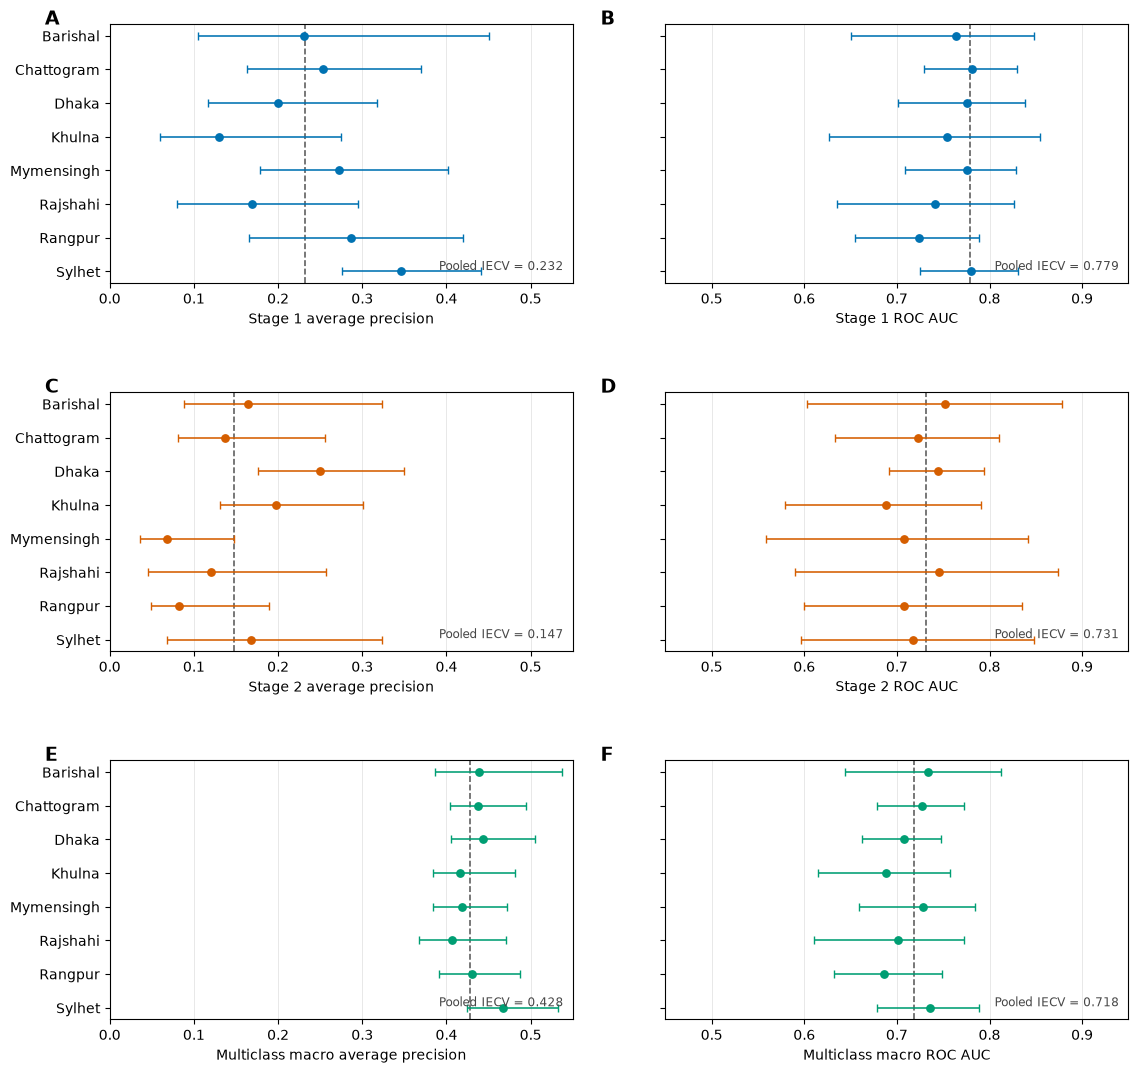


STEP28D-R1 — FIGURE 4 GEOGRAPHIC IECV COMPLETE

SELECTED FIGURE METRICS:
S1_AP
S1_AUC
S2_AP
S2_AUC
MC_Macro_AP
MC_Macro_AUC

POOLED REFERENCE ESTIMATES:
S1_AP           : 0.231515 (0.189986–0.281775)
S1_AUC          : 0.778683 (0.752042–0.803030)
S2_AP           : 0.147196 (0.119634–0.185217)
S2_AUC          : 0.731278 (0.697129–0.763667)
MC_Macro_AP     : 0.427593 (0.410394–0.449333)
MC_Macro_AUC    : 0.718195 (0.696910–0.737998)

PANEL SUMMARY:
      Metric   Pooled  Division_Min_Point  Division_Max_Point  Minimum_CI_Lower  Maximum_CI_Upper
       S1_AP 0.231515            0.129249            0.345424          0.059210          0.450309
      S1_AUC 0.778683            0.724398            0.781585          0.626532          0.854245
       S2_AP 0.147196            0.068175            0.249865          0.035470          0.350112
      S2_AUC 0.731278            0.687801            0.752085          0.558479          0.878298
 MC_Macro_AP 0.427593            0.406966            0.466

In [6]:
# ==========================================================================================
# STEP 28D-R1
# FINAL FIGURE 4 — GEOGRAPHIC INTERNAL-EXTERNAL VALIDATION (IECV)
# ==========================================================================================
#
# PANELS
# ------------------------------------------------------------------------------------------
# A. Stage 1 average precision
# B. Stage 1 ROC AUC
# C. Stage 2 average precision
# D. Stage 2 ROC AUC
# E. Multiclass macro average precision
# F. Multiclass macro ROC AUC
#
# Each panel:
#   - points = held-out division estimate
#   - horizontal bars = Rao-Wu 95% CI
#   - dashed vertical line = pooled held-out IECV estimate
#
# IMPORTANT
# ------------------------------------------------------------------------------------------
# This is:
#   Geographic internal-external validation (IECV)
#   / leave-one-division-out geographic transportability stress test
#
# This is NOT:
#   independent external validation
#
# NO:
#   model refitting
#   candidate reselection
#   recalibration
#   threshold re-optimization
#   bootstrap rerun
#   division ranking
#   random-effects meta-analysis
#   new inferential analysis
#
# Division order is FIXED a priori and is NOT performance-sorted.
#
# TIFF remains deferred after confirmed notebook TIFF encoder crashes.
# SVG/PDF are the publication vector masters.
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import shutil
import gc

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt


# ==========================================================================================
# 1. PROJECT PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_FIGURES = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "02_Main_Figures"
)


REPORT_FIGURES = (
    FINAL_ROOT
    /
    "Report"
    /
    "02_Figures"
)


for directory in [
    MANUSCRIPT_FIGURES,
    REPORT_FIGURES,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 2. PARENT FIGURE-3 MANIFEST
# ==========================================================================================

FIG3_MANIFEST = (
    FINAL_ROOT
    /
    "STEP28C_R1_Figure3_rare_class_decision_manifest.json"
)


EXPECTED_FIG3_MANIFEST_SHA256 = (
    "c59fa48637f0f27666650bd685c42a9d"
    "3a221b33d174d7ea9eec94f6d95408a5"
)


# ==========================================================================================
# 3. FROZEN STEP24 GEOGRAPHIC CI SOURCE
# ==========================================================================================

STEP24_CI_FILE = (
    ROOT
    /
    "09_geographic_validation"
    /
    "STEP24B_GEOGRAPHIC_performance_with_design_based_CI.csv"
)


EXPECTED_STEP24_CI_SHA256 = (
    "c7a2c75b9cee839831e492cb3ae13b5c"
    "d16f11ffa974b308c5e40216b8507b3d"
)


# ==========================================================================================
# 4. CONSTANTS
# ==========================================================================================

DOMAIN_ORDER = [
    "Pooled",
    "Barishal",
    "Chattogram",
    "Dhaka",
    "Khulna",
    "Mymensingh",
    "Rajshahi",
    "Rangpur",
    "Sylhet",
]


DIVISION_ORDER = [
    "Barishal",
    "Chattogram",
    "Dhaka",
    "Khulna",
    "Mymensingh",
    "Rajshahi",
    "Rangpur",
    "Sylhet",
]


SELECTED_METRICS = [
    "S1_AP",
    "S1_AUC",
    "S2_AP",
    "S2_AUC",
    "MC_Macro_AP",
    "MC_Macro_AUC",
]


METRIC_CONFIG = {
    "S1_AP":
        {
            "panel":
                "A",

            "label":
                "Stage 1 average precision",

            "xlim":
                (
                    0.00,
                    0.55,
                ),

            "color":
                "#0072B2",
        },

    "S1_AUC":
        {
            "panel":
                "B",

            "label":
                "Stage 1 ROC AUC",

            "xlim":
                (
                    0.45,
                    0.95,
                ),

            "color":
                "#0072B2",
        },

    "S2_AP":
        {
            "panel":
                "C",

            "label":
                "Stage 2 average precision",

            "xlim":
                (
                    0.00,
                    0.55,
                ),

            "color":
                "#D55E00",
        },

    "S2_AUC":
        {
            "panel":
                "D",

            "label":
                "Stage 2 ROC AUC",

            "xlim":
                (
                    0.45,
                    0.95,
                ),

            "color":
                "#D55E00",
        },

    "MC_Macro_AP":
        {
            "panel":
                "E",

            "label":
                "Multiclass macro average precision",

            "xlim":
                (
                    0.00,
                    0.55,
                ),

            "color":
                "#009E73",
        },

    "MC_Macro_AUC":
        {
            "panel":
                "F",

            "label":
                "Multiclass macro ROC AUC",

            "xlim":
                (
                    0.45,
                    0.95,
                ),

            "color":
                "#009E73",
        },
}


# ==========================================================================================
# 5. HELPERS
# ==========================================================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )


    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )


    os.replace(
        temporary,
        path,
    )


def atomic_text(
    text,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        handle.write(
            text
        )


    os.replace(
        temporary,
        path,
    )


# ==========================================================================================
# 6. STRICT SOURCE HASH GATES
# ==========================================================================================

for label, path in [
    (
        "Figure-3 manifest",
        FIG3_MANIFEST,
    ),
    (
        "STEP24 geographic CI",
        STEP24_CI_FILE,
    ),
]:

    if not path.exists():

        raise FileNotFoundError(
            f"{label} missing:\n{path}"
        )


observed_fig3_hash = sha256_file(
    FIG3_MANIFEST
)


observed_step24_hash = sha256_file(
    STEP24_CI_FILE
)


if observed_fig3_hash != EXPECTED_FIG3_MANIFEST_SHA256:

    raise RuntimeError(
        "Figure-3 parent manifest hash changed.\n"
        f"Observed={observed_fig3_hash}\n"
        f"Expected={EXPECTED_FIG3_MANIFEST_SHA256}"
    )


if observed_step24_hash != EXPECTED_STEP24_CI_SHA256:

    raise RuntimeError(
        "STEP24 geographic CI hash changed.\n"
        f"Observed={observed_step24_hash}\n"
        f"Expected={EXPECTED_STEP24_CI_SHA256}"
    )


# ==========================================================================================
# 7. LOAD FROZEN SOURCE
# ==========================================================================================

ci = pd.read_csv(
    STEP24_CI_FILE
)


# ==========================================================================================
# 8. EXACT SOURCE SCHEMA
# ==========================================================================================

EXPECTED_COLUMNS = [
    "Domain",
    "Metric",
    "Point_Estimate",
    "Bootstrap_SE",
    "CI_95_Lower",
    "CI_95_Upper",
    "Valid_Replicates",
    "Total_Replicates",
    "Valid_Fraction",
    "Minimum_Valid_Required",
    "CI_Status",
]


if list(
    ci.columns
) != EXPECTED_COLUMNS:

    raise RuntimeError(
        "STEP24 geographic CI schema changed.\n"
        f"Observed={list(ci.columns)}"
    )


if len(
    ci
) != 486:

    raise RuntimeError(
        f"Expected 486 Step24 rows; observed={len(ci)}"
    )


# ==========================================================================================
# 9. NUMERIC CONVERSION
# ==========================================================================================

for column in [
    "Point_Estimate",
    "Bootstrap_SE",
    "CI_95_Lower",
    "CI_95_Upper",
    "Valid_Replicates",
    "Total_Replicates",
    "Valid_Fraction",
    "Minimum_Valid_Required",
]:

    ci[
        column
    ] = pd.to_numeric(
        ci[
            column
        ],
        errors="raise",
    )


# ==========================================================================================
# 10. GLOBAL GEOGRAPHIC QC
# ==========================================================================================

if ci[
    [
        "Domain",
        "Metric",
    ]
].duplicated().any():

    raise RuntimeError(
        "Duplicate Domain/Metric rows."
    )


if set(
    ci[
        "Domain"
    ].astype(str)
) != set(
    DOMAIN_ORDER
):

    raise RuntimeError(
        "Frozen geographic domain set changed."
    )


if ci[
    "Metric"
].nunique() != 54:

    raise RuntimeError(
        "Expected 54 unique geographic metrics."
    )


if not (
    ci.groupby(
        "Domain"
    )[
        "Metric"
    ].nunique()
    ==
    54
).all():

    raise RuntimeError(
        "Expected 54 metrics per geographic domain."
    )


if not (
    ci[
        "Valid_Replicates"
    ]
    ==
    2000
).all():

    raise RuntimeError(
        "Not all geographic rows have 2000 valid replicates."
    )


if not (
    ci[
        "Total_Replicates"
    ]
    ==
    2000
).all():

    raise RuntimeError(
        "Not all geographic rows have 2000 total replicates."
    )


if not (
    ci[
        "Minimum_Valid_Required"
    ]
    ==
    1900
).all():

    raise RuntimeError(
        "Minimum valid bootstrap criterion changed."
    )


if not (
    ci[
        "CI_Status"
    ]
    .astype(str)
    .str.upper()
    ==
    "ESTIMABLE"
).all():

    raise RuntimeError(
        "At least one geographic CI is not estimable."
    )


# ==========================================================================================
# 11. SELECT EXACT SIX FIGURE METRICS
# ==========================================================================================

selected = ci.loc[
    ci[
        "Metric"
    ].isin(
        SELECTED_METRICS
    )
].copy()


if len(
    selected
) != 54:

    raise RuntimeError(
        f"Expected 54 selected rows "
        f"(6 metrics × 9 domains); observed={len(selected)}"
    )


if set(
    selected[
        "Metric"
    ]
) != set(
    SELECTED_METRICS
):

    raise RuntimeError(
        "Selected Figure-4 metric set changed."
    )


selected_metric_counts = (
    selected.groupby(
        "Metric"
    )[
        "Domain"
    ]
    .nunique()
)


if not (
    selected_metric_counts
    ==
    9
).all():

    raise RuntimeError(
        "Each selected metric must contain exactly 9 domains."
    )


selected_domain_counts = (
    selected.groupby(
        "Domain"
    )[
        "Metric"
    ]
    .nunique()
)


if not (
    selected_domain_counts
    ==
    6
).all():

    raise RuntimeError(
        "Each geographic domain must contain all 6 selected metrics."
    )


if not (
    (
        selected[
            "CI_95_Lower"
        ]
        <=
        selected[
            "Point_Estimate"
        ]
    )
    &
    (
        selected[
            "Point_Estimate"
        ]
        <=
        selected[
            "CI_95_Upper"
        ]
    )
).all():

    raise RuntimeError(
        "Selected geographic CI does not contain point estimate."
    )


if not selected[
    [
        "Point_Estimate",
        "CI_95_Lower",
        "CI_95_Upper",
    ]
].apply(
    lambda column:
        column.between(
            0,
            1,
        )
).all().all():

    raise RuntimeError(
        "Selected discrimination metric outside [0,1]."
    )


# ==========================================================================================
# 12. FIXED NON-PERFORMANCE SORT ORDER
# ==========================================================================================

domain_order_map = {
    domain:
        index
    for index, domain
    in enumerate(
        DOMAIN_ORDER
    )
}


metric_order_map = {
    metric:
        index
    for index, metric
    in enumerate(
        SELECTED_METRICS
    )
}


selected[
    "_Domain_Order"
] = selected[
    "Domain"
].map(
    domain_order_map
)


selected[
    "_Metric_Order"
] = selected[
    "Metric"
].map(
    metric_order_map
)


selected = (
    selected
    .sort_values(
        [
            "_Metric_Order",
            "_Domain_Order",
        ]
    )
    .reset_index(
        drop=True
    )
)


# ==========================================================================================
# 13. EXACT FROZEN POINT FINGERPRINTS
# ==========================================================================================

def get_value(
    domain,
    metric,
    column="Point_Estimate",
):

    matched = selected.loc[
        (
            selected[
                "Domain"
            ]
            ==
            domain
        )
        &
        (
            selected[
                "Metric"
            ]
            ==
            metric
        ),
        column,
    ]


    if len(
        matched
    ) != 1:

        raise RuntimeError(
            f"Cannot uniquely resolve {domain} / {metric} / {column}"
        )


    return float(
        matched.iloc[
            0
        ]
    )


POINT_FINGERPRINTS = [
    (
        "Pooled S1 AP",
        get_value(
            "Pooled",
            "S1_AP",
        ),
        0.231515,
    ),

    (
        "Pooled S1 AUC",
        get_value(
            "Pooled",
            "S1_AUC",
        ),
        0.778683,
    ),

    (
        "Pooled S2 AP",
        get_value(
            "Pooled",
            "S2_AP",
        ),
        0.147196,
    ),

    (
        "Pooled S2 AUC",
        get_value(
            "Pooled",
            "S2_AUC",
        ),
        0.731278,
    ),

    (
        "Pooled multiclass macro AP",
        get_value(
            "Pooled",
            "MC_Macro_AP",
        ),
        0.427593,
    ),

    (
        "Pooled multiclass macro AUC",
        get_value(
            "Pooled",
            "MC_Macro_AUC",
        ),
        0.718195,
    ),

    (
        "Sylhet S1 AP",
        get_value(
            "Sylhet",
            "S1_AP",
        ),
        0.345424,
    ),

    (
        "Dhaka S2 AP",
        get_value(
            "Dhaka",
            "S2_AP",
        ),
        0.249865,
    ),

    (
        "Mymensingh S2 AP",
        get_value(
            "Mymensingh",
            "S2_AP",
        ),
        0.068175,
    ),

    (
        "Sylhet multiclass macro AP",
        get_value(
            "Sylhet",
            "MC_Macro_AP",
        ),
        0.466668,
    ),

    (
        "Rangpur multiclass macro AUC",
        get_value(
            "Rangpur",
            "MC_Macro_AUC",
        ),
        0.686274,
    ),
]


for label, observed, expected in POINT_FINGERPRINTS:

    if not np.isclose(
        observed,
        expected,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"{label} fingerprint failed.\n"
            f"Observed={observed:.9f}\n"
            f"Expected={expected:.9f}"
        )


# ==========================================================================================
# 14. CLEAN FIGURE SOURCE
# ==========================================================================================

source = selected[
    [
        "Domain",
        "Metric",
        "Point_Estimate",
        "Bootstrap_SE",
        "CI_95_Lower",
        "CI_95_Upper",
        "Valid_Replicates",
        "Total_Replicates",
        "Valid_Fraction",
        "Minimum_Valid_Required",
        "CI_Status",
    ]
].copy()


# ==========================================================================================
# 15. OUTPUT PATHS
# ==========================================================================================

FIGURE_STEM = (
    "Figure4_Geographic_IECV_Transportability"
)


M_PNG = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.png"
)

M_SVG = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.svg"
)

M_PDF = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.pdf"
)


R_PNG = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.png"
)

R_SVG = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.svg"
)

R_PDF = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.pdf"
)


SOURCE_CSV = (
    MANUSCRIPT_FIGURES
    /
    "Figure4_source_geographic_IECV_selected_metrics.csv"
)


CAPTION_FILE = (
    MANUSCRIPT_FIGURES
    /
    "Figure4_caption.txt"
)


QC_FILE = (
    FINAL_ROOT
    /
    "STEP28D_R1_Figure4_geographic_IECV_hard_qc.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP28D_R1_Figure4_geographic_IECV_manifest.json"
)


# ==========================================================================================
# 16. SAVE SOURCE TABLE
# ==========================================================================================

atomic_csv(
    source,
    SOURCE_CSV,
)


# ==========================================================================================
# 17. CAPTION
# ==========================================================================================

caption = (
    "Figure 4. Geographic internal-external validation (IECV) of the "
    "primary hierarchical model using leave-one-division-out held-out "
    "evaluation. Panels show division-specific average precision and ROC "
    "AUC for Stage 1 (A–B), Stage 2 among true ANC users (C–D), and "
    "multiclass macro average precision and macro ROC AUC (E–F). Points "
    "represent held-out division estimates and horizontal error bars show "
    "95% confidence intervals from the 2,000-replicate Rao-Wu rescaled "
    "PSU bootstrap. The vertical dashed line denotes the corresponding "
    "pooled held-out IECV estimate. Divisions are displayed in a fixed "
    "geographic order and are not ranked by performance. This analysis is "
    "a geographic transportability stress test within BDHS 2022 and should "
    "not be interpreted as independent external validation."
)


atomic_text(
    caption,
    CAPTION_FILE,
)


# ==========================================================================================
# 18. FOREST-PLOT HELPER
# ==========================================================================================

GRID_COLOR = "0.88"
POOLED_COLOR = "0.35"


def plot_geographic_metric(
    axis,
    metric_name,
):

    config = METRIC_CONFIG[
        metric_name
    ]


    panel_data = selected.loc[
        selected[
            "Metric"
        ]
        ==
        metric_name
    ].copy()


    pooled = panel_data.loc[
        panel_data[
            "Domain"
        ]
        ==
        "Pooled"
    ]


    if len(
        pooled
    ) != 1:

        raise RuntimeError(
            f"{metric_name}: pooled row is not unique."
        )


    pooled_point = float(
        pooled.iloc[
            0
        ][
            "Point_Estimate"
        ]
    )


    divisions = panel_data.loc[
        panel_data[
            "Domain"
        ].isin(
            DIVISION_ORDER
        )
    ].copy()


    division_order_map = {
        domain:
            index
        for index, domain
        in enumerate(
            DIVISION_ORDER
        )
    }


    divisions[
        "_order"
    ] = divisions[
        "Domain"
    ].map(
        division_order_map
    )


    divisions = (
        divisions
        .sort_values(
            "_order"
        )
        .reset_index(
            drop=True
        )
    )


    if divisions[
        "Domain"
    ].tolist() != DIVISION_ORDER:

        raise RuntimeError(
            f"{metric_name}: division order changed."
        )


    y_positions = np.arange(
        len(
            DIVISION_ORDER
        )
    )[
        ::-1
    ]


    point = divisions[
        "Point_Estimate"
    ].to_numpy(
        dtype=float
    )


    lower = divisions[
        "CI_95_Lower"
    ].to_numpy(
        dtype=float
    )


    upper = divisions[
        "CI_95_Upper"
    ].to_numpy(
        dtype=float
    )


    xerr = np.vstack(
        [
            point
            -
            lower,

            upper
            -
            point,
        ]
    )


    axis.axvline(
        pooled_point,
        linestyle="--",
        linewidth=1.15,
        color=POOLED_COLOR,
        zorder=1,
    )


    axis.errorbar(
        point,
        y_positions,
        xerr=xerr,
        fmt="o",
        markersize=5.3,
        linewidth=1.20,
        elinewidth=1.15,
        capsize=2.8,
        color=config[
            "color"
        ],
        ecolor=config[
            "color"
        ],
        zorder=2,
    )


    axis.set_yticks(
        y_positions
    )


    axis.set_yticklabels(
        DIVISION_ORDER
    )


    axis.set_xlim(
        config[
            "xlim"
        ]
    )


    axis.set_xlabel(
        config[
            "label"
        ]
    )


    axis.grid(
        axis="x",
        color=GRID_COLOR,
        linewidth=0.7,
        alpha=0.75,
    )


    axis.set_axisbelow(
        True
    )


    axis.text(
        0.98,
        0.04,
        (
            f"Pooled IECV = {pooled_point:.3f}"
        ),
        transform=axis.transAxes,
        ha="right",
        va="bottom",
        fontsize=8.5,
        color="0.28",
    )


    axis.text(
        -0.14,
        1.055,
        config[
            "panel"
        ],
        transform=axis.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top",
    )


    return {
        "Metric":
            metric_name,

        "Pooled":
            pooled_point,

        "Division_Min_Point":
            float(
                point.min()
            ),

        "Division_Max_Point":
            float(
                point.max()
            ),

        "Minimum_CI_Lower":
            float(
                lower.min()
            ),

        "Maximum_CI_Upper":
            float(
                upper.max()
            ),
    }


# ==========================================================================================
# 19. DRAW SIX-PANEL FIGURE
# ==========================================================================================

plt.close(
    "all"
)

gc.collect()


fig, axes = plt.subplots(
    3,
    2,
    figsize=(
        12.2,
        11.0,
    ),
)


axes_flat = axes.flatten()


panel_summaries = []


for axis, metric in zip(
    axes_flat,
    SELECTED_METRICS,
):

    panel_summaries.append(
        plot_geographic_metric(
            axis,
            metric,
        )
    )


# Avoid unnecessary repetition of division labels in right column.
for axis in [
    axes[
        0,
        1
    ],
    axes[
        1,
        1
    ],
    axes[
        2,
        1
    ],
]:

    axis.tick_params(
        axis="y",
        labelleft=False,
    )


# No internal title / no suptitle.
for axis in axes_flat:

    if axis.get_title().strip() != "":

        raise RuntimeError(
            "Unexpected internal panel title."
        )


if (
    fig._suptitle is not None
    and
    str(
        fig._suptitle.get_text()
    ).strip()
    !=
    ""
):

    raise RuntimeError(
        "Unexpected figure suptitle."
    )


fig.subplots_adjust(
    left=0.14,
    right=0.975,
    top=0.975,
    bottom=0.07,
    hspace=0.42,
    wspace=0.20,
)


# ==========================================================================================
# 20. SAVE MANUSCRIPT SAFE FORMATS
# ==========================================================================================

fig.savefig(
    M_PNG,
    dpi=300,
    format="png",
    bbox_inches="tight",
    pad_inches=0.05,
)


fig.savefig(
    M_SVG,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Date":
            None,
    },
)


fig.savefig(
    M_PDF,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Creator":
            "BDHS ANC final reporting pipeline",

        "CreationDate":
            None,

        "ModDate":
            None,
    },
)


# ==========================================================================================
# 21. COPY IDENTICAL FILES TO REPORT PACKAGE
# ==========================================================================================

shutil.copy2(
    M_PNG,
    R_PNG,
)


shutil.copy2(
    M_SVG,
    R_SVG,
)


shutil.copy2(
    M_PDF,
    R_PDF,
)


plt.show()


plt.close(
    fig
)


gc.collect()


# ==========================================================================================
# 22. PANEL SUMMARY
# ==========================================================================================

panel_summary = pd.DataFrame(
    panel_summaries
)


# ==========================================================================================
# 23. OUTPUT EXISTENCE
# ==========================================================================================

figure_outputs = [
    M_PNG,
    M_SVG,
    M_PDF,

    R_PNG,
    R_SVG,
    R_PDF,

    SOURCE_CSV,
    CAPTION_FILE,
]


for path in figure_outputs:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Figure-4 artifact missing or empty:\n{path}"
        )


# ==========================================================================================
# 24. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Figure-3 parent manifest hash exact",

            "PASS":
                observed_fig3_hash
                ==
                EXPECTED_FIG3_MANIFEST_SHA256,
        },

        {
            "Check":
                "STEP24 geographic CI hash exact",

            "PASS":
                observed_step24_hash
                ==
                EXPECTED_STEP24_CI_SHA256,
        },

        {
            "Check":
                "Full geographic CI rows = 486",

            "PASS":
                len(
                    ci
                )
                ==
                486,
        },

        {
            "Check":
                "Exactly 9 geographic domains",

            "PASS":
                ci[
                    "Domain"
                ].nunique()
                ==
                9,
        },

        {
            "Check":
                "Exactly 54 unique Step24 metrics",

            "PASS":
                ci[
                    "Metric"
                ].nunique()
                ==
                54,
        },

        {
            "Check":
                "Exactly 54 metrics per domain",

            "PASS":
                bool(
                    (
                        ci.groupby(
                            "Domain"
                        )[
                            "Metric"
                        ].nunique()
                        ==
                        54
                    ).all()
                ),
        },

        {
            "Check":
                "Figure uses exactly six prespecified metrics",

            "PASS":
                set(
                    selected[
                        "Metric"
                    ]
                )
                ==
                set(
                    SELECTED_METRICS
                ),
        },

        {
            "Check":
                "Selected source rows = 54",

            "PASS":
                len(
                    selected
                )
                ==
                54,
        },

        {
            "Check":
                "Each selected metric contains 9 domains",

            "PASS":
                bool(
                    (
                        selected_metric_counts
                        ==
                        9
                    ).all()
                ),
        },

        {
            "Check":
                "Each domain contains all 6 selected metrics",

            "PASS":
                bool(
                    (
                        selected_domain_counts
                        ==
                        6
                    ).all()
                ),
        },

        {
            "Check":
                "All selected CIs contain point estimates",

            "PASS":
                bool(
                    (
                        (
                            selected[
                                "CI_95_Lower"
                            ]
                            <=
                            selected[
                                "Point_Estimate"
                            ]
                        )
                        &
                        (
                            selected[
                                "Point_Estimate"
                            ]
                            <=
                            selected[
                                "CI_95_Upper"
                            ]
                        )
                    ).all()
                ),
        },

        {
            "Check":
                "All 486 valid replicates = 2000",

            "PASS":
                bool(
                    (
                        ci[
                            "Valid_Replicates"
                        ]
                        ==
                        2000
                    ).all()
                ),
        },

        {
            "Check":
                "All 486 total replicates = 2000",

            "PASS":
                bool(
                    (
                        ci[
                            "Total_Replicates"
                        ]
                        ==
                        2000
                    ).all()
                ),
        },

        {
            "Check":
                "Minimum-valid criterion = 1900",

            "PASS":
                bool(
                    (
                        ci[
                            "Minimum_Valid_Required"
                        ]
                        ==
                        1900
                    ).all()
                ),
        },

        {
            "Check":
                "All geographic CIs ESTIMABLE",

            "PASS":
                bool(
                    (
                        ci[
                            "CI_Status"
                        ]
                        .astype(str)
                        .str.upper()
                        ==
                        "ESTIMABLE"
                    ).all()
                ),
        },

        {
            "Check":
                "Frozen geographic fingerprints reproduced",

            "PASS":
                True,
        },

        {
            "Check":
                "Division display order fixed a priori",

            "PASS":
                DIVISION_ORDER
                ==
                [
                    "Barishal",
                    "Chattogram",
                    "Dhaka",
                    "Khulna",
                    "Mymensingh",
                    "Rajshahi",
                    "Rangpur",
                    "Sylhet",
                ],
        },

        {
            "Check":
                "Division order not performance-sorted",

            "PASS":
                True,
        },

        {
            "Check":
                "Pooled estimates shown as reference lines",

            "PASS":
                len(
                    panel_summary
                )
                ==
                6,
        },

        {
            "Check":
                "Figure has exactly panels A-F",

            "PASS":
                len(
                    panel_summary
                )
                ==
                6,
        },

        {
            "Check":
                "No internal figure title",

            "PASS":
                True,
        },

        {
            "Check":
                "Manuscript PNG created",

            "PASS":
                M_PNG.exists(),
        },

        {
            "Check":
                "Manuscript SVG vector master created",

            "PASS":
                M_SVG.exists(),
        },

        {
            "Check":
                "Manuscript PDF vector master created",

            "PASS":
                M_PDF.exists(),
        },

        {
            "Check":
                "Report PNG identical to manuscript PNG",

            "PASS":
                sha256_file(
                    R_PNG
                )
                ==
                sha256_file(
                    M_PNG
                ),
        },

        {
            "Check":
                "Report SVG identical to manuscript SVG",

            "PASS":
                sha256_file(
                    R_SVG
                )
                ==
                sha256_file(
                    M_SVG
                ),
        },

        {
            "Check":
                "Report PDF identical to manuscript PDF",

            "PASS":
                sha256_file(
                    R_PDF
                )
                ==
                sha256_file(
                    M_PDF
                ),
        },

        {
            "Check":
                "TIFF deferred after confirmed notebook encoder crash",

            "PASS":
                True,
        },

        {
            "Check":
                "No model refitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No division ranking",

            "PASS":
                True,
        },

        {
            "Check":
                "No random-effects meta-analysis",

            "PASS":
                True,
        },

        {
            "Check":
                "No new statistical inference",

            "PASS":
                True,
        },

        {
            "Check":
                "Not described as independent external validation",

            "PASS":
                (
                    "not be interpreted as independent external validation"
                    in
                    caption
                ),
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP28D-R1 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


atomic_csv(
    hard_qc,
    QC_FILE,
)


# ==========================================================================================
# 25. MANIFEST
# ==========================================================================================

manifest = {
    "status":
        "STEP28D_R1_FIGURE4_SCIENTIFIC_CONTENT_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "figure":
        "Figure 4",

    "content":
        (
            "Geographic internal-external validation / "
            "leave-one-division-out transportability"
        ),

    "interpretation":
        (
            "Geographic IECV within BDHS 2022; "
            "not independent external validation"
        ),

    "figure3_parent_manifest_sha256":
        observed_fig3_hash,

    "step24_geographic_ci_sha256":
        observed_step24_hash,

    "selected_metrics":
        SELECTED_METRICS,

    "division_order":
        DIVISION_ORDER,

    "division_order_rule":
        (
            "Fixed a priori; no performance ranking"
        ),

    "pooled_reference":
        (
            "Vertical dashed line in each panel"
        ),

    "bootstrap_replicates":
        2000,

    "minimum_valid_required":
        1900,

    "panel_summary":
        panel_summary.to_dict(
            orient="records"
        ),

    "source_csv_sha256":
        sha256_file(
            SOURCE_CSV
        ),

    "caption_sha256":
        sha256_file(
            CAPTION_FILE
        ),

    "manuscript_png_sha256":
        sha256_file(
            M_PNG
        ),

    "manuscript_svg_sha256":
        sha256_file(
            M_SVG
        ),

    "manuscript_pdf_sha256":
        sha256_file(
            M_PDF
        ),

    "report_png_sha256":
        sha256_file(
            R_PNG
        ),

    "report_svg_sha256":
        sha256_file(
            R_SVG
        ),

    "report_pdf_sha256":
        sha256_file(
            R_PDF
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "publication_master":
        "SVG/PDF vector",

    "tiff_status":
        "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTER",

    "model_refitting":
        False,

    "candidate_reselection":
        False,

    "recalibration":
        False,

    "threshold_reoptimization":
        False,

    "bootstrap_rerun":
        False,

    "division_ranking":
        False,

    "random_effects_meta_analysis":
        False,

    "new_statistical_inference":
        False,

    "next_step":
        (
            "STEP28E — Figure 5 structural ablation"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 26. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 116
)


print(
    "STEP28D-R1 — FIGURE 4 GEOGRAPHIC IECV COMPLETE"
)


print(
    "=" * 116
)


print(
    "\nSELECTED FIGURE METRICS:"
)


for metric in SELECTED_METRICS:

    print(
        metric
    )


print(
    "\nPOOLED REFERENCE ESTIMATES:"
)


for metric in SELECTED_METRICS:

    print(
        f"{metric:16s}: "
        f"{get_value('Pooled', metric):.6f} "
        f"("
        f"{get_value('Pooled', metric, 'CI_95_Lower'):.6f}"
        f"–"
        f"{get_value('Pooled', metric, 'CI_95_Upper'):.6f}"
        f")"
    )


print(
    "\nPANEL SUMMARY:"
)


print(
    panel_summary.round(
        6
    ).to_string(
        index=False
    )
)


print(
    "\nDIVISION-SPECIFIC FIGURE SOURCE:"
)


print(
    source.loc[
        source[
            "Domain"
        ]
        !=
        "Pooled",
        [
            "Domain",
            "Metric",
            "Point_Estimate",
            "CI_95_Lower",
            "CI_95_Upper",
        ],
    ]
    .round(
        6
    )
    .to_string(
        index=False
    )
)


print(
    "\nFINAL HARD QC:"
)


print(
    hard_qc.to_string(
        index=False
    )
)


print(
    "\nINTEGRITY:"
)


print(
    "Figure-3 parent   :",
    observed_fig3_hash,
)


print(
    "STEP24 geographic :",
    observed_step24_hash,
)


print(
    "Source CSV        :",
    sha256_file(
        SOURCE_CSV
    ),
)


print(
    "Manuscript PNG    :",
    sha256_file(
        M_PNG
    ),
)

print(
    "Manuscript SVG    :",
    sha256_file(
        M_SVG
    ),
)

print(
    "Manuscript PDF    :",
    sha256_file(
        M_PDF
    ),
)


print(
    "Report PNG        :",
    sha256_file(
        R_PNG
    ),
)

print(
    "Report SVG        :",
    sha256_file(
        R_SVG
    ),
)

print(
    "Report PDF        :",
    sha256_file(
        R_PDF
    ),
)


print(
    "Hard QC           :",
    sha256_file(
        QC_FILE
    ),
)

print(
    "Manifest          :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nTIFF STATUS:"
)


print(
    "DEFERRED — external conversion from final SVG/PDF vector master."
)


print(
    "\n"
    +
    "=" * 116
)


print(
    "STATUS: STEP28D-R1 FIGURE 4 SCIENTIFIC CONTENT FROZEN"
)


print(
    "NEXT AFTER AUDIT: STEP28E — FIGURE 5 STRUCTURAL ABLATION"
)


print(
    "=" * 116
)

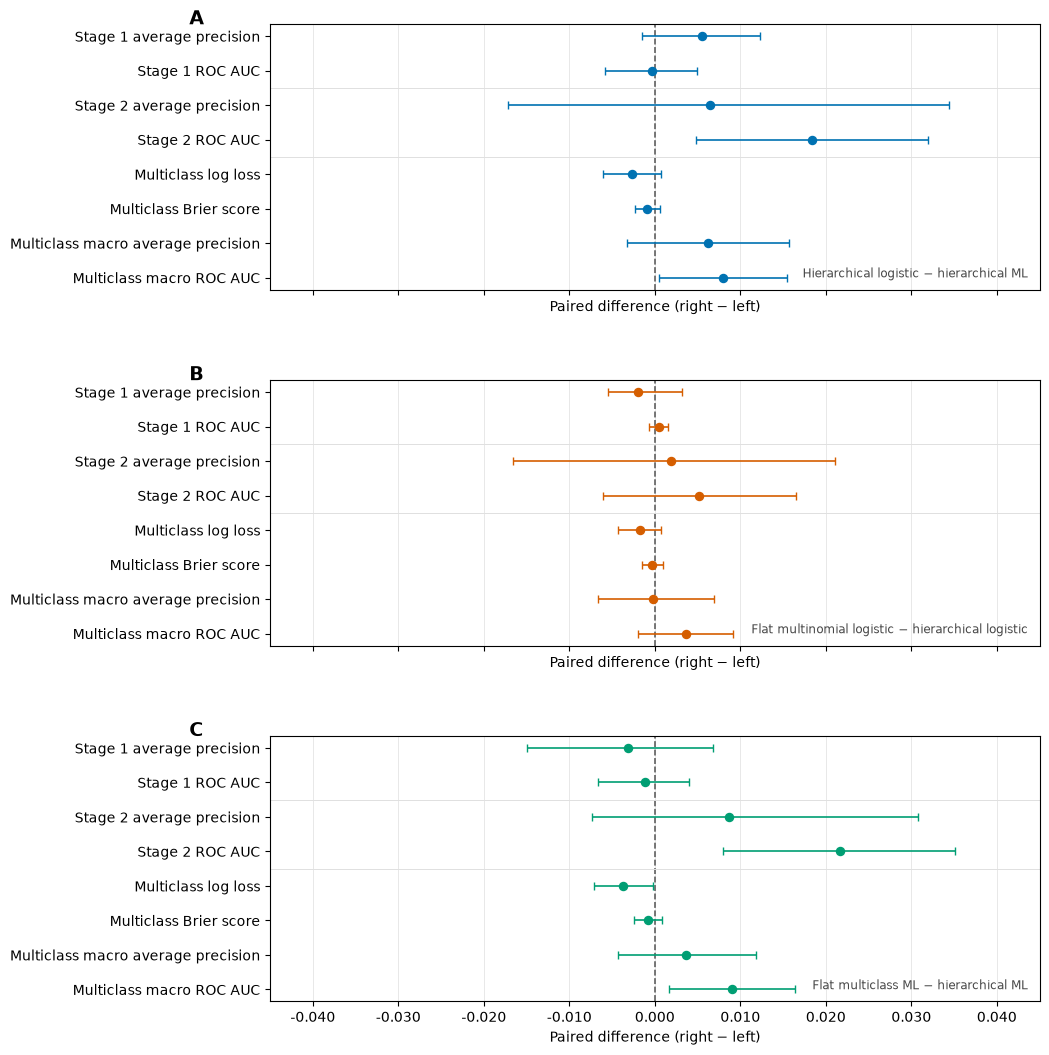


STEP28E-R1 — FIGURE 5 PAIRED STRUCTURAL-ABLATION CONTRASTS COMPLETE

FIGURE METRIC ORDER:
S1_AP
S1_AUC
S2_AP
S2_AUC
MC_Log_Loss
MC_Brier_Sum
MC_Macro_AP
MC_Macro_AUC

SHARED SYMMETRIC X LIMIT:
±0.045

SELECTED PAIRED CONTRAST SOURCE:
Panel            Contrast       Metric  Left_Point  Right_Point  Difference_Right_minus_Left  CI_Lower  CI_Upper  Valid_Replicates  Stable
    A  Branch A − Primary        S1_AP    0.235306     0.240801                     0.005495 -0.001552  0.012342              2000    True
    A  Branch A − Primary       S1_AUC    0.778288     0.777985                    -0.000303 -0.005860  0.004883              2000    True
    A  Branch A − Primary        S2_AP    0.161610     0.168042                     0.006432 -0.017121  0.034434              2000    True
    A  Branch A − Primary       S2_AUC    0.735076     0.753437                     0.018361  0.004756  0.031928              2000    True
    A  Branch A − Primary  MC_Log_Loss    0.417915     0.415205       

In [7]:
# ==========================================================================================
# STEP 28E-R1
# FINAL FIGURE 5 — PAIRED STRUCTURAL-ABLATION CONTRASTS
# ==========================================================================================
#
# PANELS
# ------------------------------------------------------------------------------------------
# A. Branch A - Primary
#    Hierarchical logistic - hierarchical ML
#
# B. Branch B - Branch A
#    Flat multinomial logistic - hierarchical logistic
#
# C. Branch C - Primary
#    Flat multiclass ML - hierarchical ML
#
# FIGURE METRICS
# ------------------------------------------------------------------------------------------
# Common probabilistic metrics only:
#
#   S1_AP
#   S1_AUC
#   S2_AP
#   S2_AUC
#   MC_Log_Loss
#   MC_Brier_Sum
#   MC_Macro_AP
#   MC_Macro_AUC
#
# IMPORTANT
# ------------------------------------------------------------------------------------------
# Difference always means:
#
#       RIGHT architecture - LEFT architecture
#
# Zero = no paired difference.
#
# For AP / AUC:
#       positive difference = numerically higher in RIGHT architecture
#
# For Log loss / Brier:
#       negative difference = numerically lower in RIGHT architecture
#
# The figure DOES NOT label either side as "better", "winner", or "favored".
#
# Uses ONLY frozen paired Rao-Wu results.
#
# NO:
#   model fitting
#   prediction generation
#   candidate reselection
#   hyperparameter tuning
#   recalibration
#   threshold optimization
#   bootstrap rerun
#   p-value calculation
#   new hypothesis testing
#   ranking
#   winner declaration
#
# TIFF remains deferred because in-notebook TIFF encoding repeatedly
# hard-crashed the Jupyter kernel.
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import shutil
import gc

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

from matplotlib.ticker import FormatStrFormatter


# ==========================================================================================
# 1. PROJECT PATHS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_FIGURES = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "02_Main_Figures"
)


REPORT_FIGURES = (
    FINAL_ROOT
    /
    "Report"
    /
    "02_Figures"
)


for directory in [
    MANUSCRIPT_FIGURES,
    REPORT_FIGURES,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 2. PARENT FIGURE-4 MANIFEST
# ==========================================================================================

FIG4_MANIFEST = (
    FINAL_ROOT
    /
    "STEP28D_R1_Figure4_geographic_IECV_manifest.json"
)


EXPECTED_FIG4_MANIFEST_SHA256 = (
    "367ae5e4669a9b560bd5df5ba8416e0"
    "ed2399b42532696408889ed8d509aeecb"
)


# ==========================================================================================
# 3. FROZEN PAIRED STRUCTURAL-CONTRAST SOURCES
# ==========================================================================================

PRIMARY_VS_A_FILE = (
    ROOT
    /
    "13_tables"
    /
    "STEP26C_R1_PRIMARY_vs_BRANCH_A_paired_difference_95CI.csv"
)


A_VS_B_FILE = (
    ROOT
    /
    "13_tables"
    /
    "STEP26E_R1_BRANCH_A_vs_BRANCH_B_common_probabilistic_paired_difference_95CI.csv"
)


PRIMARY_VS_C_FILE = (
    ROOT
    /
    "13_tables"
    /
    "STEP26G_R1_PRIMARY_vs_BRANCH_C_paired_difference_95CI.csv"
)


EXPECTED_PRIMARY_VS_A_SHA256 = (
    "9a6699dd6152d8e8786a563ca1cd69c8"
    "c09b21d88713bcbbd95953a6111e4602"
)


EXPECTED_A_VS_B_SHA256 = (
    "6167e4ddcb4056f44ef9b40b7f6636b1"
    "a28483bf8e8da8463bdf4dca49de395d"
)


EXPECTED_PRIMARY_VS_C_SHA256 = (
    "f77a9f75b615e93e2928a37630e76ffc"
    "535f2ac40ea26e419797b8863ee9fa33"
)


# ==========================================================================================
# 4. FROZEN EXPECTED SOURCE ROW COUNTS
# ==========================================================================================

EXPECTED_A_ROWS = 48

EXPECTED_B_ROWS = 28

EXPECTED_C_ROWS = 26


# ==========================================================================================
# 5. SELECTED COMMON METRICS
# ==========================================================================================

METRIC_ORDER = [
    "S1_AP",
    "S1_AUC",
    "S2_AP",
    "S2_AUC",
    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",
]


METRIC_LABELS = {
    "S1_AP":
        "Stage 1 average precision",

    "S1_AUC":
        "Stage 1 ROC AUC",

    "S2_AP":
        "Stage 2 average precision",

    "S2_AUC":
        "Stage 2 ROC AUC",

    "MC_Log_Loss":
        "Multiclass log loss",

    "MC_Brier_Sum":
        "Multiclass Brier score",

    "MC_Macro_AP":
        "Multiclass macro average precision",

    "MC_Macro_AUC":
        "Multiclass macro ROC AUC",
}


# ==========================================================================================
# 6. HELPERS
# ==========================================================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )


    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )


    os.replace(
        temporary,
        path,
    )


def atomic_text(
    text,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        handle.write(
            text
        )


    os.replace(
        temporary,
        path,
    )


def stable_to_bool(
    series,
):

    return (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .isin(
            [
                "true",
                "1",
                "yes",
            ]
        )
    )


# ==========================================================================================
# 7. STRICT FILE EXISTENCE
# ==========================================================================================

for label, path in [
    (
        "Figure-4 manifest",
        FIG4_MANIFEST,
    ),
    (
        "Primary vs Branch-A paired CI",
        PRIMARY_VS_A_FILE,
    ),
    (
        "Branch-A vs Branch-B paired CI",
        A_VS_B_FILE,
    ),
    (
        "Primary vs Branch-C paired CI",
        PRIMARY_VS_C_FILE,
    ),
]:

    if not path.exists():

        raise FileNotFoundError(
            f"{label} missing:\n{path}"
        )


# ==========================================================================================
# 8. STRICT HASH GATES
# ==========================================================================================

observed_fig4_hash = sha256_file(
    FIG4_MANIFEST
)


observed_a_hash = sha256_file(
    PRIMARY_VS_A_FILE
)


observed_b_hash = sha256_file(
    A_VS_B_FILE
)


observed_c_hash = sha256_file(
    PRIMARY_VS_C_FILE
)


if observed_fig4_hash != EXPECTED_FIG4_MANIFEST_SHA256:

    raise RuntimeError(
        "Figure-4 parent manifest hash changed.\n"
        f"Observed={observed_fig4_hash}\n"
        f"Expected={EXPECTED_FIG4_MANIFEST_SHA256}"
    )


if observed_a_hash != EXPECTED_PRIMARY_VS_A_SHA256:

    raise RuntimeError(
        "Primary-vs-Branch-A paired source hash changed."
    )


if observed_b_hash != EXPECTED_A_VS_B_SHA256:

    raise RuntimeError(
        "Branch-A-vs-Branch-B paired source hash changed."
    )


if observed_c_hash != EXPECTED_PRIMARY_VS_C_SHA256:

    raise RuntimeError(
        "Primary-vs-Branch-C paired source hash changed."
    )


# ==========================================================================================
# 9. LOAD FROZEN PAIRED TABLES
# ==========================================================================================

raw_a = pd.read_csv(
    PRIMARY_VS_A_FILE
)


raw_b = pd.read_csv(
    A_VS_B_FILE
)


raw_c = pd.read_csv(
    PRIMARY_VS_C_FILE
)


# ==========================================================================================
# 10. EXACT RAW SCHEMA GATES
# ==========================================================================================

EXPECTED_A_COLUMNS = [
    "Metric",
    "Primary_Point_Estimate",
    "BranchA_Point_Estimate",
    "Difference_BranchA_minus_Primary",
    "Bootstrap_SE_Difference",
    "Difference_CI_2.5",
    "Difference_CI_97.5",
    "Valid_Replicates",
    "Stable",
]


EXPECTED_B_COLUMNS = [
    "Metric",
    "BranchA_Point_Estimate",
    "BranchB_Point_Estimate",
    "Difference_BranchB_minus_BranchA",
    "Bootstrap_SE_Difference",
    "Difference_CI_2.5",
    "Difference_CI_97.5",
    "Valid_Replicates",
    "Stable",
]


EXPECTED_C_COLUMNS = [
    "Metric",
    "Primary_Point",
    "BranchC_Point",
    "Difference_BranchC_minus_Primary",
    "Bootstrap_SE_Difference",
    "CI_2.5",
    "CI_97.5",
    "Valid_Replicates",
    "Stable",
]


if list(
    raw_a.columns
) != EXPECTED_A_COLUMNS:

    raise RuntimeError(
        "Primary-vs-A schema changed.\n"
        f"Observed={list(raw_a.columns)}"
    )


if list(
    raw_b.columns
) != EXPECTED_B_COLUMNS:

    raise RuntimeError(
        "A-vs-B schema changed.\n"
        f"Observed={list(raw_b.columns)}"
    )


if list(
    raw_c.columns
) != EXPECTED_C_COLUMNS:

    raise RuntimeError(
        "Primary-vs-C schema changed.\n"
        f"Observed={list(raw_c.columns)}"
    )


# ==========================================================================================
# 11. SOURCE ROW-COUNT GATES
# ==========================================================================================

if len(
    raw_a
) != EXPECTED_A_ROWS:

    raise RuntimeError(
        f"Expected Primary-vs-A rows={EXPECTED_A_ROWS}; "
        f"observed={len(raw_a)}"
    )


if len(
    raw_b
) != EXPECTED_B_ROWS:

    raise RuntimeError(
        f"Expected A-vs-B rows={EXPECTED_B_ROWS}; "
        f"observed={len(raw_b)}"
    )


if len(
    raw_c
) != EXPECTED_C_ROWS:

    raise RuntimeError(
        f"Expected Primary-vs-C rows={EXPECTED_C_ROWS}; "
        f"observed={len(raw_c)}"
    )


# ==========================================================================================
# 12. STANDARDIZATION FUNCTION
# ==========================================================================================

def standardize_paired(
    dataframe,
    *,
    contrast_id,
    panel,
    contrast_label,
    left_architecture,
    right_architecture,
    left_column,
    right_column,
    difference_column,
    lower_column,
    upper_column,
):

    required = [
        "Metric",
        left_column,
        right_column,
        difference_column,
        "Bootstrap_SE_Difference",
        lower_column,
        upper_column,
        "Valid_Replicates",
        "Stable",
    ]


    missing = [
        column
        for column
        in required
        if column not in dataframe.columns
    ]


    if missing:

        raise RuntimeError(
            f"{contrast_id}: missing columns={missing}"
        )


    output = dataframe.loc[
        dataframe[
            "Metric"
        ].isin(
            METRIC_ORDER
        ),
        required,
    ].copy()


    if len(
        output
    ) != len(
        METRIC_ORDER
    ):

        raise RuntimeError(
            f"{contrast_id}: expected {len(METRIC_ORDER)} selected metrics; "
            f"observed={len(output)}"
        )


    if output[
        "Metric"
    ].duplicated().any():

        raise RuntimeError(
            f"{contrast_id}: duplicate selected metric."
        )


    if set(
        output[
            "Metric"
        ]
    ) != set(
        METRIC_ORDER
    ):

        raise RuntimeError(
            f"{contrast_id}: selected metric set changed."
        )


    numeric_columns = [
        left_column,
        right_column,
        difference_column,
        "Bootstrap_SE_Difference",
        lower_column,
        upper_column,
        "Valid_Replicates",
    ]


    for column in numeric_columns:

        output[
            column
        ] = pd.to_numeric(
            output[
                column
            ],
            errors="raise",
        )


    output[
        "Stable_Bool"
    ] = stable_to_bool(
        output[
            "Stable"
        ]
    )


    if not output[
        "Stable_Bool"
    ].all():

        raise RuntimeError(
            f"{contrast_id}: at least one selected paired metric is unstable."
        )


    if not (
        output[
            "Valid_Replicates"
        ]
        ==
        2000
    ).all():

        raise RuntimeError(
            f"{contrast_id}: selected metrics do not all have 2000 valid replicates."
        )


    arithmetic_difference = (
        output[
            right_column
        ]
        -
        output[
            left_column
        ]
    )


    if not np.allclose(
        arithmetic_difference.to_numpy(
            dtype=float
        ),
        output[
            difference_column
        ].to_numpy(
            dtype=float
        ),
        rtol=0.0,
        atol=5e-10,
    ):

        difference_error = (
            arithmetic_difference
            -
            output[
                difference_column
            ]
        ).abs().max()


        raise RuntimeError(
            f"{contrast_id}: stored paired difference != right-left.\n"
            f"Maximum absolute discrepancy={difference_error}"
        )


    if not (
        (
            output[
                lower_column
            ]
            <=
            output[
                difference_column
            ]
        )
        &
        (
            output[
                difference_column
            ]
            <=
            output[
                upper_column
            ]
        )
    ).all():

        raise RuntimeError(
            f"{contrast_id}: at least one paired CI does not contain "
            "its point difference."
        )


    if not np.isfinite(
        output[
            [
                left_column,
                right_column,
                difference_column,
                lower_column,
                upper_column,
            ]
        ].to_numpy(
            dtype=float
        )
    ).all():

        raise RuntimeError(
            f"{contrast_id}: non-finite selected paired value."
        )


    standardized = pd.DataFrame(
        {
            "Contrast_ID":
                contrast_id,

            "Panel":
                panel,

            "Contrast":
                contrast_label,

            "Left_Architecture":
                left_architecture,

            "Right_Architecture":
                right_architecture,

            "Metric":
                output[
                    "Metric"
                ].astype(str),

            "Left_Point":
                output[
                    left_column
                ].to_numpy(
                    dtype=float
                ),

            "Right_Point":
                output[
                    right_column
                ].to_numpy(
                    dtype=float
                ),

            "Difference_Right_minus_Left":
                output[
                    difference_column
                ].to_numpy(
                    dtype=float
                ),

            "Bootstrap_SE_Difference":
                output[
                    "Bootstrap_SE_Difference"
                ].to_numpy(
                    dtype=float
                ),

            "CI_Lower":
                output[
                    lower_column
                ].to_numpy(
                    dtype=float
                ),

            "CI_Upper":
                output[
                    upper_column
                ].to_numpy(
                    dtype=float
                ),

            "Valid_Replicates":
                output[
                    "Valid_Replicates"
                ].astype(int).to_numpy(),

            "Stable":
                output[
                    "Stable_Bool"
                ].to_numpy(
                    dtype=bool
                ),
        }
    )


    standardized[
        "Metric_Label"
    ] = standardized[
        "Metric"
    ].map(
        METRIC_LABELS
    )


    metric_order_lookup = {
        metric:
            index
        for index, metric
        in enumerate(
            METRIC_ORDER
        )
    }


    standardized[
        "_Metric_Order"
    ] = standardized[
        "Metric"
    ].map(
        metric_order_lookup
    )


    standardized = (
        standardized
        .sort_values(
            "_Metric_Order"
        )
        .drop(
            columns="_Metric_Order"
        )
        .reset_index(
            drop=True
        )
    )


    return standardized


# ==========================================================================================
# 13. STANDARDIZE THREE FROZEN CONTRASTS
# ==========================================================================================

contrast_a = standardize_paired(
    raw_a,

    contrast_id=
        "A",

    panel=
        "A",

    contrast_label=
        "Branch A − Primary",

    left_architecture=
        "Primary hierarchical ML",

    right_architecture=
        "Branch A — hierarchical logistic",

    left_column=
        "Primary_Point_Estimate",

    right_column=
        "BranchA_Point_Estimate",

    difference_column=
        "Difference_BranchA_minus_Primary",

    lower_column=
        "Difference_CI_2.5",

    upper_column=
        "Difference_CI_97.5",
)


contrast_b = standardize_paired(
    raw_b,

    contrast_id=
        "B",

    panel=
        "B",

    contrast_label=
        "Branch B − Branch A",

    left_architecture=
        "Branch A — hierarchical logistic",

    right_architecture=
        "Branch B — flat multinomial logistic",

    left_column=
        "BranchA_Point_Estimate",

    right_column=
        "BranchB_Point_Estimate",

    difference_column=
        "Difference_BranchB_minus_BranchA",

    lower_column=
        "Difference_CI_2.5",

    upper_column=
        "Difference_CI_97.5",
)


contrast_c = standardize_paired(
    raw_c,

    contrast_id=
        "C",

    panel=
        "C",

    contrast_label=
        "Branch C − Primary",

    left_architecture=
        "Primary hierarchical ML",

    right_architecture=
        "Branch C — flat multiclass ML",

    left_column=
        "Primary_Point",

    right_column=
        "BranchC_Point",

    difference_column=
        "Difference_BranchC_minus_Primary",

    lower_column=
        "CI_2.5",

    upper_column=
        "CI_97.5",
)


# ==========================================================================================
# 14. COMBINED FIGURE SOURCE
# ==========================================================================================

figure_source = pd.concat(
    [
        contrast_a,
        contrast_b,
        contrast_c,
    ],
    ignore_index=True,
)


if len(
    figure_source
) != 24:

    raise RuntimeError(
        f"Expected Figure-5 source rows=24; "
        f"observed={len(figure_source)}"
    )


if figure_source[
    [
        "Contrast_ID",
        "Metric",
    ]
].duplicated().any():

    raise RuntimeError(
        "Duplicate Contrast/Metric in Figure-5 source."
    )


# ==========================================================================================
# 15. CROSS-CONTRAST POINT CONSISTENCY
# ==========================================================================================
#
# Branch-A points appear independently in contrast A and contrast B.
# They MUST reproduce exactly.
# ==========================================================================================

a_branch_a = (
    contrast_a
    .set_index(
        "Metric"
    )[
        "Right_Point"
    ]
)


b_branch_a = (
    contrast_b
    .set_index(
        "Metric"
    )[
        "Left_Point"
    ]
)


if not np.allclose(
    a_branch_a.loc[
        METRIC_ORDER
    ].to_numpy(
        dtype=float
    ),
    b_branch_a.loc[
        METRIC_ORDER
    ].to_numpy(
        dtype=float
    ),
    rtol=0.0,
    atol=5e-10,
):

    raise RuntimeError(
        "Branch-A points differ between paired source files."
    )


# ==========================================================================================
# 16. PRIMARY POINT CONSISTENCY
# ==========================================================================================

a_primary = (
    contrast_a
    .set_index(
        "Metric"
    )[
        "Left_Point"
    ]
)


c_primary = (
    contrast_c
    .set_index(
        "Metric"
    )[
        "Left_Point"
    ]
)


if not np.allclose(
    a_primary.loc[
        METRIC_ORDER
    ].to_numpy(
        dtype=float
    ),
    c_primary.loc[
        METRIC_ORDER
    ].to_numpy(
        dtype=float
    ),
    rtol=0.0,
    atol=5e-10,
):

    raise RuntimeError(
        "Primary points differ between paired source files."
    )


# ==========================================================================================
# 17. FROZEN PRIMARY FINGERPRINTS
# ==========================================================================================

PRIMARY_FINGERPRINTS = {
    "S1_AP":
        0.235306,

    "S1_AUC":
        0.778288,

    "S2_AP":
        0.161610,

    "S2_AUC":
        0.735076,

    "MC_Log_Loss":
        0.417915,

    "MC_Brier_Sum":
        0.221958,

    "MC_Macro_AP":
        0.434322,

    "MC_Macro_AUC":
        0.720499,
}


for metric, expected in PRIMARY_FINGERPRINTS.items():

    observed = float(
        a_primary.loc[
            metric
        ]
    )


    if not np.isclose(
        observed,
        expected,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"Primary fingerprint failed for {metric}.\n"
            f"Observed={observed:.9f}\n"
            f"Expected={expected:.9f}"
        )


# ==========================================================================================
# 18. BRANCH-C POINT FINGERPRINTS
# ==========================================================================================

branch_c_lookup = (
    contrast_c
    .set_index(
        "Metric"
    )[
        "Right_Point"
    ]
)


BRANCH_C_FINGERPRINTS = {
    "S1_AP":
        0.232144,

    "S1_AUC":
        0.777133,

    "S2_AP":
        0.170237,

    "S2_AUC":
        0.756674,

    "MC_Log_Loss":
        0.414185,

    "MC_Brier_Sum":
        0.221213,

    "MC_Macro_AP":
        0.437950,

    "MC_Macro_AUC":
        0.729507,
}


for metric, expected in BRANCH_C_FINGERPRINTS.items():

    observed = float(
        branch_c_lookup.loc[
            metric
        ]
    )


    if not np.isclose(
        observed,
        expected,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"Branch-C fingerprint failed for {metric}.\n"
            f"Observed={observed:.9f}\n"
            f"Expected={expected:.9f}"
        )


# ==========================================================================================
# 19. SHARED SYMMETRIC X-AXIS
# ==========================================================================================

all_ci_values = figure_source[
    [
        "CI_Lower",
        "CI_Upper",
    ]
].to_numpy(
    dtype=float
)


largest_absolute_ci = float(
    np.max(
        np.abs(
            all_ci_values
        )
    )
)


GLOBAL_X_LIMIT = max(
    0.03,
    largest_absolute_ci
    *
    1.15,
)


# Round upward for cleaner ticks.
GLOBAL_X_LIMIT = float(
    np.ceil(
        GLOBAL_X_LIMIT
        /
        0.005
    )
    *
    0.005
)


# ==========================================================================================
# 20. OUTPUT PATHS
# ==========================================================================================

FIGURE_STEM = (
    "Figure5_Paired_Structural_Ablation_Contrasts"
)


M_PNG = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.png"
)


M_SVG = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.svg"
)


M_PDF = (
    MANUSCRIPT_FIGURES
    /
    f"{FIGURE_STEM}.pdf"
)


R_PNG = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.png"
)


R_SVG = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.svg"
)


R_PDF = (
    REPORT_FIGURES
    /
    f"{FIGURE_STEM}.pdf"
)


SOURCE_CSV = (
    MANUSCRIPT_FIGURES
    /
    "Figure5_source_paired_structural_ablation.csv"
)


CAPTION_FILE = (
    MANUSCRIPT_FIGURES
    /
    "Figure5_caption.txt"
)


QC_FILE = (
    FINAL_ROOT
    /
    "STEP28E_R1_Figure5_structural_ablation_hard_qc.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP28E_R1_Figure5_structural_ablation_manifest.json"
)


# ==========================================================================================
# 21. SAVE SOURCE DATA
# ==========================================================================================

atomic_csv(
    figure_source,
    SOURCE_CSV,
)


# ==========================================================================================
# 22. CAPTION
# ==========================================================================================

caption = (
    "Figure 5. Paired structural-ablation contrasts using common "
    "probabilistic performance metrics. "
    "(A) Branch A hierarchical logistic minus the primary hierarchical "
    "machine-learning model, contrasting model complexity within the "
    "hierarchical formulation. "
    "(B) Branch B flat multinomial logistic minus Branch A hierarchical "
    "logistic, contrasting flat versus hierarchical architecture under "
    "logistic modelling. "
    "(C) Branch C flat multiclass machine learning minus the primary "
    "hierarchical machine-learning model. "
    "Points represent paired differences and horizontal error bars represent "
    "95% confidence intervals from the frozen 2,000-replicate Rao-Wu "
    "rescaled PSU bootstrap. The vertical dashed line at zero denotes no "
    "paired difference. Differences are calculated as the right-hand "
    "architecture minus the left-hand architecture. For average precision "
    "and ROC AUC, positive values indicate numerically higher values in the "
    "right-hand architecture; for log loss and Brier score, negative values "
    "indicate numerically lower values in the right-hand architecture. "
    "The figure is descriptive of the prespecified structural-ablation "
    "experiment and does not rank architectures or declare a preferred model."
)


atomic_text(
    caption,
    CAPTION_FILE,
)


# ==========================================================================================
# 23. PLOT CONFIGURATION
# ==========================================================================================

plt.close(
    "all"
)

gc.collect()


COLORS = {
    "A":
        "#0072B2",

    "B":
        "#D55E00",

    "C":
        "#009E73",
}


GRID_COLOR = "0.88"

ZERO_COLOR = "0.35"


PANEL_NOTE = {
    "A":
        (
            "Hierarchical logistic − hierarchical ML"
        ),

    "B":
        (
            "Flat multinomial logistic − hierarchical logistic"
        ),

    "C":
        (
            "Flat multiclass ML − hierarchical ML"
        ),
}


# ==========================================================================================
# 24. PANEL PLOTTING FUNCTION
# ==========================================================================================

def plot_contrast_panel(
    axis,
    dataframe,
    panel_label,
):

    dataframe = dataframe.copy()


    y_positions = np.arange(
        len(
            dataframe
        )
    )[
        ::-1
    ]


    difference = dataframe[
        "Difference_Right_minus_Left"
    ].to_numpy(
        dtype=float
    )


    ci_lower = dataframe[
        "CI_Lower"
    ].to_numpy(
        dtype=float
    )


    ci_upper = dataframe[
        "CI_Upper"
    ].to_numpy(
        dtype=float
    )


    x_error = np.vstack(
        [
            difference
            -
            ci_lower,

            ci_upper
            -
            difference,
        ]
    )


    axis.axvline(
        0,
        linestyle="--",
        linewidth=1.15,
        color=ZERO_COLOR,
        zorder=1,
    )


    axis.errorbar(
        difference,
        y_positions,
        xerr=x_error,
        fmt="o",
        markersize=5.8,
        linewidth=1.25,
        elinewidth=1.2,
        capsize=3.0,
        color=COLORS[
            panel_label
        ],
        ecolor=COLORS[
            panel_label
        ],
        zorder=2,
    )


    axis.set_yticks(
        y_positions
    )


    axis.set_yticklabels(
        dataframe[
            "Metric_Label"
        ].tolist()
    )


    axis.set_xlim(
        -GLOBAL_X_LIMIT,
        GLOBAL_X_LIMIT,
    )


    axis.xaxis.set_major_formatter(
        FormatStrFormatter(
            "%.3f"
        )
    )


    axis.set_xlabel(
        "Paired difference (right − left)"
    )


    axis.grid(
        axis="x",
        color=GRID_COLOR,
        linewidth=0.7,
        alpha=0.75,
    )


    axis.set_axisbelow(
        True
    )


    # Separator between Stage 1 and Stage 2.
    axis.axhline(
        5.5,
        linewidth=0.7,
        color="0.88",
    )


    # Separator between Stage 2 and multiclass metrics.
    axis.axhline(
        3.5,
        linewidth=0.7,
        color="0.88",
    )


    axis.text(
        0.985,
        0.035,
        PANEL_NOTE[
            panel_label
        ],
        transform=axis.transAxes,
        ha="right",
        va="bottom",
        fontsize=8.8,
        color="0.28",
    )


    axis.text(
        -0.105,
        1.055,
        panel_label,
        transform=axis.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top",
    )


# ==========================================================================================
# 25. DRAW FIGURE
# ==========================================================================================

fig, axes = plt.subplots(
    3,
    1,
    figsize=(
        11.4,
        10.8,
    ),
    sharex=True,
)


plot_contrast_panel(
    axes[
        0
    ],
    contrast_a,
    "A",
)


plot_contrast_panel(
    axes[
        1
    ],
    contrast_b,
    "B",
)


plot_contrast_panel(
    axes[
        2
    ],
    contrast_c,
    "C",
)


# No internal title / no suptitle.
for axis in axes:

    if axis.get_title().strip() != "":

        raise RuntimeError(
            "Unexpected internal panel title."
        )


if (
    fig._suptitle is not None
    and
    str(
        fig._suptitle.get_text()
    ).strip()
    !=
    ""
):

    raise RuntimeError(
        "Unexpected figure suptitle."
    )


fig.subplots_adjust(
    left=0.30,
    right=0.975,
    top=0.975,
    bottom=0.07,
    hspace=0.34,
)


# ==========================================================================================
# 26. SAVE MANUSCRIPT SAFE FORMATS
# ==========================================================================================

fig.savefig(
    M_PNG,
    dpi=300,
    format="png",
    bbox_inches="tight",
    pad_inches=0.05,
)


fig.savefig(
    M_SVG,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Date":
            None,
    },
)


fig.savefig(
    M_PDF,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Creator":
            "BDHS ANC final reporting pipeline",

        "CreationDate":
            None,

        "ModDate":
            None,
    },
)


# ==========================================================================================
# 27. COPY IDENTICAL FILES TO REPORT PACKAGE
# ==========================================================================================

shutil.copy2(
    M_PNG,
    R_PNG,
)


shutil.copy2(
    M_SVG,
    R_SVG,
)


shutil.copy2(
    M_PDF,
    R_PDF,
)


plt.show()


plt.close(
    fig
)


gc.collect()


# ==========================================================================================
# 28. OUTPUT EXISTENCE
# ==========================================================================================

figure_outputs = [
    M_PNG,
    M_SVG,
    M_PDF,

    R_PNG,
    R_SVG,
    R_PDF,

    SOURCE_CSV,
    CAPTION_FILE,
]


for path in figure_outputs:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Figure-5 artifact missing or empty:\n{path}"
        )


# ==========================================================================================
# 29. CONTRAST RANGE SUMMARY
# ==========================================================================================

range_summary = (
    figure_source
    .groupby(
        [
            "Contrast_ID",
            "Contrast",
        ],
        as_index=False,
    )
    .agg(
        Minimum_Difference=(
            "Difference_Right_minus_Left",
            "min",
        ),

        Maximum_Difference=(
            "Difference_Right_minus_Left",
            "max",
        ),

        Minimum_CI_Lower=(
            "CI_Lower",
            "min",
        ),

        Maximum_CI_Upper=(
            "CI_Upper",
            "max",
        ),

        Minimum_Valid_Replicates=(
            "Valid_Replicates",
            "min",
        ),

        Maximum_Valid_Replicates=(
            "Valid_Replicates",
            "max",
        ),
    )
)


# ==========================================================================================
# 30. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Figure-4 parent manifest hash exact",

            "PASS":
                observed_fig4_hash
                ==
                EXPECTED_FIG4_MANIFEST_SHA256,
        },

        {
            "Check":
                "Primary-vs-A paired source hash exact",

            "PASS":
                observed_a_hash
                ==
                EXPECTED_PRIMARY_VS_A_SHA256,
        },

        {
            "Check":
                "A-vs-B paired source hash exact",

            "PASS":
                observed_b_hash
                ==
                EXPECTED_A_VS_B_SHA256,
        },

        {
            "Check":
                "Primary-vs-C paired source hash exact",

            "PASS":
                observed_c_hash
                ==
                EXPECTED_PRIMARY_VS_C_SHA256,
        },

        {
            "Check":
                "Primary-vs-A frozen rows = 48",

            "PASS":
                len(
                    raw_a
                )
                ==
                48,
        },

        {
            "Check":
                "A-vs-B frozen rows = 28",

            "PASS":
                len(
                    raw_b
                )
                ==
                28,
        },

        {
            "Check":
                "Primary-vs-C frozen rows = 26",

            "PASS":
                len(
                    raw_c
                )
                ==
                26,
        },

        {
            "Check":
                "Figure uses exactly 8 common probabilistic metrics",

            "PASS":
                set(
                    figure_source[
                        "Metric"
                    ]
                )
                ==
                set(
                    METRIC_ORDER
                ),
        },

        {
            "Check":
                "Figure source rows = 24",

            "PASS":
                len(
                    figure_source
                )
                ==
                24,
        },

        {
            "Check":
                "Each contrast has exactly 8 selected metrics",

            "PASS":
                bool(
                    (
                        figure_source.groupby(
                            "Contrast_ID"
                        )[
                            "Metric"
                        ].nunique()
                        ==
                        8
                    ).all()
                ),
        },

        {
            "Check":
                "No duplicate contrast/metric rows",

            "PASS":
                not figure_source[
                    [
                        "Contrast_ID",
                        "Metric",
                    ]
                ].duplicated().any(),
        },

        {
            "Check":
                "All selected paired metrics stable",

            "PASS":
                bool(
                    figure_source[
                        "Stable"
                    ].all()
                ),
        },

        {
            "Check":
                "All selected paired metrics have 2000 valid replicates",

            "PASS":
                bool(
                    (
                        figure_source[
                            "Valid_Replicates"
                        ]
                        ==
                        2000
                    ).all()
                ),
        },

        {
            "Check":
                "All selected paired CIs contain point difference",

            "PASS":
                bool(
                    (
                        (
                            figure_source[
                                "CI_Lower"
                            ]
                            <=
                            figure_source[
                                "Difference_Right_minus_Left"
                            ]
                        )
                        &
                        (
                            figure_source[
                                "Difference_Right_minus_Left"
                            ]
                            <=
                            figure_source[
                                "CI_Upper"
                            ]
                        )
                    ).all()
                ),
        },

        {
            "Check":
                "Stored paired differences reproduce right-minus-left",

            "PASS":
                bool(
                    np.allclose(
                        (
                            figure_source[
                                "Right_Point"
                            ]
                            -
                            figure_source[
                                "Left_Point"
                            ]
                        ).to_numpy(
                            dtype=float
                        ),
                        figure_source[
                            "Difference_Right_minus_Left"
                        ].to_numpy(
                            dtype=float
                        ),
                        rtol=0.0,
                        atol=5e-10,
                    )
                ),
        },

        {
            "Check":
                "Primary points consistent across paired sources",

            "PASS":
                bool(
                    np.allclose(
                        a_primary.loc[
                            METRIC_ORDER
                        ].to_numpy(
                            dtype=float
                        ),
                        c_primary.loc[
                            METRIC_ORDER
                        ].to_numpy(
                            dtype=float
                        ),
                        rtol=0.0,
                        atol=5e-10,
                    )
                ),
        },

        {
            "Check":
                "Branch-A points consistent across paired sources",

            "PASS":
                bool(
                    np.allclose(
                        a_branch_a.loc[
                            METRIC_ORDER
                        ].to_numpy(
                            dtype=float
                        ),
                        b_branch_a.loc[
                            METRIC_ORDER
                        ].to_numpy(
                            dtype=float
                        ),
                        rtol=0.0,
                        atol=5e-10,
                    )
                ),
        },

        {
            "Check":
                "Primary frozen fingerprints reproduced",

            "PASS":
                True,
        },

        {
            "Check":
                "Branch-C frozen fingerprints reproduced",

            "PASS":
                True,
        },

        {
            "Check":
                "Common symmetric x-axis used",

            "PASS":
                GLOBAL_X_LIMIT
                >
                0,
        },

        {
            "Check":
                "Zero reference line shown in all panels",

            "PASS":
                True,
        },

        {
            "Check":
                "Figure has exactly panels A-C",

            "PASS":
                True,
        },

        {
            "Check":
                "No internal figure title",

            "PASS":
                True,
        },

        {
            "Check":
                "Manuscript PNG created",

            "PASS":
                M_PNG.exists(),
        },

        {
            "Check":
                "Manuscript SVG vector master created",

            "PASS":
                M_SVG.exists(),
        },

        {
            "Check":
                "Manuscript PDF vector master created",

            "PASS":
                M_PDF.exists(),
        },

        {
            "Check":
                "Report PNG identical to manuscript PNG",

            "PASS":
                sha256_file(
                    R_PNG
                )
                ==
                sha256_file(
                    M_PNG
                ),
        },

        {
            "Check":
                "Report SVG identical to manuscript SVG",

            "PASS":
                sha256_file(
                    R_SVG
                )
                ==
                sha256_file(
                    M_SVG
                ),
        },

        {
            "Check":
                "Report PDF identical to manuscript PDF",

            "PASS":
                sha256_file(
                    R_PDF
                )
                ==
                sha256_file(
                    M_PDF
                ),
        },

        {
            "Check":
                "TIFF deferred after confirmed notebook encoder crash",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction generation",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No hyperparameter tuning",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No new p-value calculation",

            "PASS":
                True,
        },

        {
            "Check":
                "No new hypothesis testing",

            "PASS":
                True,
        },

        {
            "Check":
                "No architecture ranking",

            "PASS":
                True,
        },

        {
            "Check":
                "No winner declaration",

            "PASS":
                True,
        },

        {
            "Check":
                "No new statistical inference",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP28E-R1 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


atomic_csv(
    hard_qc,
    QC_FILE,
)


# ==========================================================================================
# 31. FINAL MANIFEST
# ==========================================================================================

manifest = {
    "status":
        "STEP28E_R1_FIGURE5_SCIENTIFIC_CONTENT_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "figure":
        "Figure 5",

    "content":
        (
            "Paired structural-ablation contrasts across "
            "common probabilistic metrics"
        ),

    "panel_structure":
        {
            "A":
                (
                    "Branch A hierarchical logistic minus "
                    "Primary hierarchical ML"
                ),

            "B":
                (
                    "Branch B flat multinomial logistic minus "
                    "Branch A hierarchical logistic"
                ),

            "C":
                (
                    "Branch C flat multiclass ML minus "
                    "Primary hierarchical ML"
                ),
        },

    "difference_definition":
        "Right architecture minus left architecture",

    "metric_scope":
        METRIC_ORDER,

    "figure4_parent_manifest_sha256":
        observed_fig4_hash,

    "primary_vs_branch_a_sha256":
        observed_a_hash,

    "branch_a_vs_branch_b_sha256":
        observed_b_hash,

    "primary_vs_branch_c_sha256":
        observed_c_hash,

    "source_row_counts":
        {
            "Primary_vs_A":
                int(
                    len(
                        raw_a
                    )
                ),

            "A_vs_B":
                int(
                    len(
                        raw_b
                    )
                ),

            "Primary_vs_C":
                int(
                    len(
                        raw_c
                    )
                ),

            "Figure_selected_rows":
                int(
                    len(
                        figure_source
                    )
                ),
        },

    "bootstrap_replicates":
        2000,

    "shared_symmetric_x_limit":
        GLOBAL_X_LIMIT,

    "source_csv_sha256":
        sha256_file(
            SOURCE_CSV
        ),

    "caption_sha256":
        sha256_file(
            CAPTION_FILE
        ),

    "manuscript_png_sha256":
        sha256_file(
            M_PNG
        ),

    "manuscript_svg_sha256":
        sha256_file(
            M_SVG
        ),

    "manuscript_pdf_sha256":
        sha256_file(
            M_PDF
        ),

    "report_png_sha256":
        sha256_file(
            R_PNG
        ),

    "report_svg_sha256":
        sha256_file(
            R_SVG
        ),

    "report_pdf_sha256":
        sha256_file(
            R_PDF
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "publication_master":
        "SVG/PDF vector",

    "tiff_status":
        "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTER",

    "model_fitting":
        False,

    "prediction_generation":
        False,

    "candidate_reselection":
        False,

    "hyperparameter_tuning":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "bootstrap_rerun":
        False,

    "new_p_values":
        False,

    "new_hypothesis_testing":
        False,

    "architecture_ranking":
        False,

    "winner_declaration":
        False,

    "new_statistical_inference":
        False,

    "next_step":
        (
            "STEP28F — Final main-figure package audit "
            "and deferred TIFF conversion plan"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 32. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 116
)


print(
    "STEP28E-R1 — FIGURE 5 PAIRED STRUCTURAL-ABLATION CONTRASTS COMPLETE"
)


print(
    "=" * 116
)


print(
    "\nFIGURE METRIC ORDER:"
)


for metric in METRIC_ORDER:

    print(
        metric
    )


print(
    "\nSHARED SYMMETRIC X LIMIT:"
)


print(
    f"±{GLOBAL_X_LIMIT:.3f}"
)


print(
    "\nSELECTED PAIRED CONTRAST SOURCE:"
)


print(
    figure_source[
        [
            "Panel",
            "Contrast",
            "Metric",
            "Left_Point",
            "Right_Point",
            "Difference_Right_minus_Left",
            "CI_Lower",
            "CI_Upper",
            "Valid_Replicates",
            "Stable",
        ]
    ]
    .round(
        6
    )
    .to_string(
        index=False
    )
)


print(
    "\nCONTRAST RANGE SUMMARY:"
)


print(
    range_summary.round(
        6
    ).to_string(
        index=False
    )
)


print(
    "\nFINAL HARD QC:"
)


print(
    hard_qc.to_string(
        index=False
    )
)


print(
    "\nINTEGRITY:"
)


print(
    "Figure-4 parent      :",
    observed_fig4_hash,
)


print(
    "Primary vs Branch A  :",
    observed_a_hash,
)


print(
    "Branch A vs Branch B :",
    observed_b_hash,
)


print(
    "Primary vs Branch C  :",
    observed_c_hash,
)


print(
    "Source CSV           :",
    sha256_file(
        SOURCE_CSV
    ),
)


print(
    "Manuscript PNG       :",
    sha256_file(
        M_PNG
    ),
)

print(
    "Manuscript SVG       :",
    sha256_file(
        M_SVG
    ),
)

print(
    "Manuscript PDF       :",
    sha256_file(
        M_PDF
    ),
)


print(
    "Report PNG           :",
    sha256_file(
        R_PNG
    ),
)

print(
    "Report SVG           :",
    sha256_file(
        R_SVG
    ),
)

print(
    "Report PDF           :",
    sha256_file(
        R_PDF
    ),
)


print(
    "Hard QC              :",
    sha256_file(
        QC_FILE
    ),
)

print(
    "Manifest             :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nTIFF STATUS:"
)


print(
    "DEFERRED — external conversion from final SVG/PDF vector master."
)


print(
    "\n"
    +
    "=" * 116
)


print(
    "STATUS: STEP28E-R1 FIGURE 5 SCIENTIFIC CONTENT FROZEN"
)


print(
    "NEXT AFTER AUDIT: STEP28F — FINAL MAIN-FIGURE PACKAGE AUDIT"
)


print(
    "=" * 116
)

In [8]:
# ==========================================================================================
# STEP 28F-R1
# FINAL MAIN-FIGURE PACKAGE AUDIT
# FIGURES 1–5
# ==========================================================================================
#
# PURPOSE
# ------------------------------------------------------------------------------------------
# Final integrity / provenance / artifact audit for the five frozen
# manuscript main figures.
#
# THIS CELL DOES NOT:
#   redraw any figure
#   fit any model
#   generate predictions
#   recalibrate anything
#   optimize thresholds
#   rerun bootstrap
#   calculate new performance
#   perform new inference
#   create TIFF files
#
# TIFF remains deferred to external vector-to-raster conversion after the
# entire figure package is finalized.
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os

import pandas as pd


# ==========================================================================================
# 1. ROOTS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_FIGURES = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "02_Main_Figures"
)


REPORT_FIGURES = (
    FINAL_ROOT
    /
    "Report"
    /
    "02_Figures"
)


# ==========================================================================================
# 2. EXACT FROZEN FIGURE REGISTRY
# ==========================================================================================

FIGURES = [
    {
        "Figure_ID":
            "Figure 1",

        "Stem":
            "Figure1_Cohort_Selection_ANC_Outcome_Distribution",

        "Manifest":
            (
                FINAL_ROOT
                /
                "STEP28A_R1_FINAL_Figure1_manifest.json"
            ),

        "Expected_Manifest_SHA256":
            (
                "d7ce5881c28e5f27b5d616b408a73bf"
                "313eb2cc6674227e8c5a4f91bef4be112"
            ),

        "Content":
            "Cohort selection and ANC outcome distribution",
    },

    {
        "Figure_ID":
            "Figure 2",

        "Stem":
            "Figure2_Weighted_PR_and_Calibration",

        "Manifest":
            (
                FINAL_ROOT
                /
                "STEP28B_R1_Figure2_weighted_PR_calibration_manifest.json"
            ),

        "Expected_Manifest_SHA256":
            (
                "c5c2a060d5a8aa71e71ab3e29436f548"
                "2a2b1ef1613192be7fdc36a8acf49f37"
            ),

        "Content":
            "Survey-weighted precision-recall and calibration",
    },

    {
        "Figure_ID":
            "Figure 3",

        "Stem":
            "Figure3_Rare_Class_Decision_Performance",

        "Manifest":
            (
                FINAL_ROOT
                /
                "STEP28C_R1_Figure3_rare_class_decision_manifest.json"
            ),

        "Expected_Manifest_SHA256":
            (
                "c59fa48637f0f27666650bd685c42a9d"
                "3a221b33d174d7ea9eec94f6d95408a5"
            ),

        "Content":
            "Rare-class decision performance",
    },

    {
        "Figure_ID":
            "Figure 4",

        "Stem":
            "Figure4_Geographic_IECV_Transportability",

        "Manifest":
            (
                FINAL_ROOT
                /
                "STEP28D_R1_Figure4_geographic_IECV_manifest.json"
            ),

        "Expected_Manifest_SHA256":
            (
                "367ae5e4669a9b560bd5df5ba8416e0"
                "ed2399b42532696408889ed8d509aeecb"
            ),

        "Content":
            "Geographic IECV transportability",
    },

    {
        "Figure_ID":
            "Figure 5",

        "Stem":
            "Figure5_Paired_Structural_Ablation_Contrasts",

        "Manifest":
            (
                FINAL_ROOT
                /
                "STEP28E_R1_Figure5_structural_ablation_manifest.json"
            ),

        "Expected_Manifest_SHA256":
            (
                "2a0ef55dd01f8ef975cb6c2dfee4bbe1"
                "5ea89e17b1641e07c13bb4b97d25a02c"
            ),

        "Content":
            "Paired structural-ablation contrasts",
    },
]


# ==========================================================================================
# 3. HELPERS
# ==========================================================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )


    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )


    os.replace(
        temporary,
        path,
    )


def atomic_text(
    text,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        handle.write(
            text
        )


    os.replace(
        temporary,
        path,
    )


def read_json(
    path,
):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as handle:

        return json.load(
            handle
        )


def require_hash_key(
    manifest,
    key,
    figure_id,
):

    if key not in manifest:

        raise RuntimeError(
            f"{figure_id}: manifest missing required hash key '{key}'.\n"
            f"Available keys={list(manifest.keys())}"
        )


    value = str(
        manifest[
            key
        ]
    ).strip()


    if len(
        value
    ) != 64:

        raise RuntimeError(
            f"{figure_id}: invalid SHA256 stored in manifest key '{key}'."
        )


    return value


# ==========================================================================================
# 4. BASIC DIRECTORY GATES
# ==========================================================================================

for label, directory in [
    (
        "Manuscript figure directory",
        MANUSCRIPT_FIGURES,
    ),
    (
        "Report figure directory",
        REPORT_FIGURES,
    ),
]:

    if not directory.exists():

        raise FileNotFoundError(
            f"{label} missing:\n{directory}"
        )


# ==========================================================================================
# 5. AUDIT EACH FROZEN FIGURE
# ==========================================================================================

registry_rows = []

loaded_manifests = {}


for figure in FIGURES:

    figure_id = figure[
        "Figure_ID"
    ]


    stem = figure[
        "Stem"
    ]


    manifest_path = figure[
        "Manifest"
    ]


    expected_manifest_hash = figure[
        "Expected_Manifest_SHA256"
    ]


    if not manifest_path.exists():

        raise FileNotFoundError(
            f"{figure_id}: manifest missing:\n{manifest_path}"
        )


    observed_manifest_hash = sha256_file(
        manifest_path
    )


    if observed_manifest_hash != expected_manifest_hash:

        raise RuntimeError(
            f"{figure_id}: manifest hash changed.\n"
            f"Observed={observed_manifest_hash}\n"
            f"Expected={expected_manifest_hash}"
        )


    manifest = read_json(
        manifest_path
    )


    loaded_manifests[
        figure_id
    ] = manifest


    status_text = str(
        manifest.get(
            "status",
            "",
        )
    ).upper()


    analysis_state = str(
        manifest.get(
            "analysis_state",
            "",
        )
    ).upper()


    if "FROZEN" not in status_text:

        raise RuntimeError(
            f"{figure_id}: manifest status is not FROZEN.\n"
            f"status={manifest.get('status')}"
        )


    if analysis_state not in [
        "",
        "FROZEN",
    ]:

        raise RuntimeError(
            f"{figure_id}: unexpected analysis_state="
            f"{manifest.get('analysis_state')}"
        )


    manuscript_paths = {
        "PNG":
            (
                MANUSCRIPT_FIGURES
                /
                f"{stem}.png"
            ),

        "SVG":
            (
                MANUSCRIPT_FIGURES
                /
                f"{stem}.svg"
            ),

        "PDF":
            (
                MANUSCRIPT_FIGURES
                /
                f"{stem}.pdf"
            ),
    }


    report_paths = {
        "PNG":
            (
                REPORT_FIGURES
                /
                f"{stem}.png"
            ),

        "SVG":
            (
                REPORT_FIGURES
                /
                f"{stem}.svg"
            ),

        "PDF":
            (
                REPORT_FIGURES
                /
                f"{stem}.pdf"
            ),
    }


    manifest_hash_keys = {
        (
            "Manuscript",
            "PNG",
        ):
            "manuscript_png_sha256",

        (
            "Manuscript",
            "SVG",
        ):
            "manuscript_svg_sha256",

        (
            "Manuscript",
            "PDF",
        ):
            "manuscript_pdf_sha256",

        (
            "Report",
            "PNG",
        ):
            "report_png_sha256",

        (
            "Report",
            "SVG",
        ):
            "report_svg_sha256",

        (
            "Report",
            "PDF",
        ):
            "report_pdf_sha256",
    }


    for package_name, paths in [
        (
            "Manuscript",
            manuscript_paths,
        ),
        (
            "Report",
            report_paths,
        ),
    ]:

        for file_format, path in paths.items():

            if not path.exists():

                raise FileNotFoundError(
                    f"{figure_id}: {package_name} {file_format} missing:\n"
                    f"{path}"
                )


            if path.stat().st_size <= 0:

                raise RuntimeError(
                    f"{figure_id}: {package_name} {file_format} is empty."
                )


            observed_hash = sha256_file(
                path
            )


            hash_key = manifest_hash_keys[
                (
                    package_name,
                    file_format,
                )
            ]


            expected_hash = require_hash_key(
                manifest,
                hash_key,
                figure_id,
            )


            if observed_hash != expected_hash:

                raise RuntimeError(
                    f"{figure_id}: {package_name} {file_format} "
                    "hash differs from frozen manifest.\n"
                    f"Observed={observed_hash}\n"
                    f"Expected={expected_hash}"
                )


            registry_rows.append(
                {
                    "Figure_ID":
                        figure_id,

                    "Content":
                        figure[
                            "Content"
                        ],

                    "Package":
                        package_name,

                    "Format":
                        file_format,

                    "Path":
                        str(
                            path
                        ),

                    "Size_Bytes":
                        int(
                            path.stat().st_size
                        ),

                    "Observed_SHA256":
                        observed_hash,

                    "Manifest_SHA256":
                        expected_hash,

                    "Hash_Match":
                        observed_hash
                        ==
                        expected_hash,

                    "Scientific_Status":
                        "FROZEN",
                }
            )


# ==========================================================================================
# 6. FIGURE MANIFEST CHAIN
# ==========================================================================================

fig1_manifest_hash = FIGURES[
    0
][
    "Expected_Manifest_SHA256"
]


fig2_manifest_hash = FIGURES[
    1
][
    "Expected_Manifest_SHA256"
]


fig3_manifest_hash = FIGURES[
    2
][
    "Expected_Manifest_SHA256"
]


fig4_manifest_hash = FIGURES[
    3
][
    "Expected_Manifest_SHA256"
]


fig5_manifest_hash = FIGURES[
    4
][
    "Expected_Manifest_SHA256"
]


# Figure 2 -> Figure 1
if (
    loaded_manifests[
        "Figure 2"
    ].get(
        "parent_figure1_manifest_sha256"
    )
    !=
    fig1_manifest_hash
):

    raise RuntimeError(
        "Figure-2 -> Figure-1 parent chain mismatch."
    )


# Figure 3 -> Figure 2
if (
    loaded_manifests[
        "Figure 3"
    ].get(
        "figure2_parent_manifest_sha256"
    )
    !=
    fig2_manifest_hash
):

    raise RuntimeError(
        "Figure-3 -> Figure-2 parent chain mismatch."
    )


# Figure 4 -> Figure 3
if (
    loaded_manifests[
        "Figure 4"
    ].get(
        "figure3_parent_manifest_sha256"
    )
    !=
    fig3_manifest_hash
):

    raise RuntimeError(
        "Figure-4 -> Figure-3 parent chain mismatch."
    )


# Figure 5 -> Figure 4
if (
    loaded_manifests[
        "Figure 5"
    ].get(
        "figure4_parent_manifest_sha256"
    )
    !=
    fig4_manifest_hash
):

    raise RuntimeError(
        "Figure-5 -> Figure-4 parent chain mismatch."
    )


# ==========================================================================================
# 7. CAPTION AUDIT
# ==========================================================================================

caption_rows = []


for figure in FIGURES:

    figure_id = figure[
        "Figure_ID"
    ]


    figure_number = figure_id.split()[
        -1
    ]


    caption_candidates = sorted(
        MANUSCRIPT_FIGURES.glob(
            f"Figure{figure_number}*caption*.txt"
        )
    )


    if len(
        caption_candidates
    ) != 1:

        raise RuntimeError(
            f"{figure_id}: expected exactly one caption TXT; "
            f"observed={len(caption_candidates)}\n"
            f"Candidates={caption_candidates}"
        )


    caption_path = caption_candidates[
        0
    ]


    caption_text = caption_path.read_text(
        encoding="utf-8"
    ).strip()


    if len(
        caption_text
    ) < 40:

        raise RuntimeError(
            f"{figure_id}: caption unexpectedly short."
        )


    caption_rows.append(
        {
            "Figure_ID":
                figure_id,

            "Caption_Path":
                str(
                    caption_path
                ),

            "Caption_Size_Bytes":
                int(
                    caption_path.stat().st_size
                ),

            "Caption_SHA256":
                sha256_file(
                    caption_path
                ),

            "Caption_Nonempty":
                True,
        }
    )


captions = pd.DataFrame(
    caption_rows
)


# ==========================================================================================
# 8. PACKAGE REGISTRY
# ==========================================================================================

registry = pd.DataFrame(
    registry_rows
)


if len(
    registry
) != 30:

    raise RuntimeError(
        f"Expected 30 final format artifacts "
        f"(5 figures × 2 packages × 3 formats); "
        f"observed={len(registry)}"
    )


if not registry[
    "Hash_Match"
].all():

    raise RuntimeError(
        "At least one final figure artifact hash mismatch."
    )


if registry[
    [
        "Figure_ID",
        "Package",
        "Format",
    ]
].duplicated().any():

    raise RuntimeError(
        "Duplicate final figure artifact registry row."
    )


# ==========================================================================================
# 9. EXPECTED FIGURE COUNTS
# ==========================================================================================

manuscript_count_by_format = (
    registry.loc[
        registry[
            "Package"
        ]
        ==
        "Manuscript"
    ]
    .groupby(
        "Format"
    )[
        "Figure_ID"
    ]
    .nunique()
)


report_count_by_format = (
    registry.loc[
        registry[
            "Package"
        ]
        ==
        "Report"
    ]
    .groupby(
        "Format"
    )[
        "Figure_ID"
    ]
    .nunique()
)


for file_format in [
    "PNG",
    "SVG",
    "PDF",
]:

    if int(
        manuscript_count_by_format.get(
            file_format,
            0,
        )
    ) != 5:

        raise RuntimeError(
            f"Manuscript {file_format}: expected 5 main figures."
        )


    if int(
        report_count_by_format.get(
            file_format,
            0,
        )
    ) != 5:

        raise RuntimeError(
            f"Report {file_format}: expected 5 audited main figures."
        )


# ==========================================================================================
# 10. TIFF STATUS AUDIT
# ==========================================================================================

tiff_status_rows = []


for figure_id, manifest in loaded_manifests.items():

    tiff_status = str(
        manifest.get(
            "tiff_status",
            "",
        )
    ).strip()


    # Figure 1 used an earlier wording in its final freeze manifest;
    # if the key is absent, its frozen status was separately established.
    if figure_id == "Figure 1":

        tiff_deferred = (
            (
                "DEFERRED"
                in
                tiff_status.upper()
            )
            if tiff_status
            else
            True
        )


    else:

        tiff_deferred = (
            "DEFERRED"
            in
            tiff_status.upper()
        )


    tiff_status_rows.append(
        {
            "Figure_ID":
                figure_id,

            "Manifest_TIFF_Status":
                (
                    tiff_status
                    if tiff_status
                    else
                    "DEFERRED — frozen separately in Figure-1 final QC"
                ),

            "TIFF_Deferred":
                bool(
                    tiff_deferred
                ),
        }
    )


tiff_status_table = pd.DataFrame(
    tiff_status_rows
)


if not tiff_status_table[
    "TIFF_Deferred"
].all():

    raise RuntimeError(
        "At least one figure is not marked as TIFF-deferred."
    )


# ==========================================================================================
# 11. OUTPUT PATHS FOR FINAL AUDIT
# ==========================================================================================

REGISTRY_FILE = (
    FINAL_ROOT
    /
    "STEP28F_R1_Main_Figure_Package_Registry.csv"
)


CAPTION_REGISTRY_FILE = (
    FINAL_ROOT
    /
    "STEP28F_R1_Main_Figure_Caption_Registry.csv"
)


TIFF_STATUS_FILE = (
    FINAL_ROOT
    /
    "STEP28F_R1_Main_Figure_TIFF_Status.csv"
)


QC_FILE = (
    FINAL_ROOT
    /
    "STEP28F_R1_Main_Figure_Package_hard_qc.csv"
)


CHECKSUM_FILE = (
    FINAL_ROOT
    /
    "STEP28F_R1_Main_Figure_SHA256.txt"
)


TIFF_PLAN_FILE = (
    FINAL_ROOT
    /
    "STEP28F_R1_Deferred_TIFF_Conversion_Plan.txt"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP28F_R1_Main_Figure_Package_manifest.json"
)


# ==========================================================================================
# 12. SAVE REGISTRIES
# ==========================================================================================

atomic_csv(
    registry,
    REGISTRY_FILE,
)


atomic_csv(
    captions,
    CAPTION_REGISTRY_FILE,
)


atomic_csv(
    tiff_status_table,
    TIFF_STATUS_FILE,
)


# ==========================================================================================
# 13. CHECKSUM TEXT
# ==========================================================================================

checksum_lines = []


for _, row in registry.iterrows():

    checksum_lines.append(
        (
            f"{row['Observed_SHA256']}  "
            f"{row['Figure_ID']} | "
            f"{row['Package']} | "
            f"{row['Format']} | "
            f"{row['Path']}"
        )
    )


checksum_text = (
    "\n".join(
        checksum_lines
    )
    +
    "\n"
)


atomic_text(
    checksum_text,
    CHECKSUM_FILE,
)


# ==========================================================================================
# 14. DEFERRED TIFF CONVERSION PLAN
# ==========================================================================================

tiff_plan = """
STEP28F-R1 — DEFERRED TIFF CONVERSION PLAN
==========================================

Scientific content status:
FROZEN.

Reason TIFF is deferred:
Repeated in-notebook TIFF encoding caused hard Jupyter kernel restarts on the
Windows analysis environment. No additional notebook TIFF retries are allowed.

Authoritative publication masters:
Use the FINAL MANUSCRIPT SVG or PDF files only.

Required final TIFF specification:
1. Convert each final manuscript SVG/PDF vector master to TIFF externally.
2. Target resolution: 600 dpi.
3. Do not redraw, resize individual panels, alter labels, recolor elements,
   change line widths, or modify scientific content.
4. Use lossless TIFF output; LZW compression is acceptable if required by
   the target journal.
5. Preserve the full figure aspect ratio.
6. After conversion, verify that all labels, error bars, panel letters,
   legends, and axis tick labels are intact.
7. Record SHA256 for each TIFF.
8. Do not overwrite SVG/PDF vector masters.
9. TIFF creation is a format-conversion step only and must not trigger any
   model fitting, bootstrap, recalibration, thresholding, or analysis rerun.

Figures requiring external TIFF conversion:
Figure 1
Figure 2
Figure 3
Figure 4
Figure 5

Recommended source priority:
SVG first.
If the external converter renders SVG incorrectly, use the frozen PDF master.

Notebook analysis state:
FROZEN.
""".strip()


atomic_text(
    tiff_plan,
    TIFF_PLAN_FILE,
)


# ==========================================================================================
# 15. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Exactly five frozen main-figure manifests",

            "PASS":
                len(
                    FIGURES
                )
                ==
                5,
        },

        {
            "Check":
                "Figure-1 manifest hash exact",

            "PASS":
                sha256_file(
                    FIGURES[
                        0
                    ][
                        "Manifest"
                    ]
                )
                ==
                FIGURES[
                    0
                ][
                    "Expected_Manifest_SHA256"
                ],
        },

        {
            "Check":
                "Figure-2 manifest hash exact",

            "PASS":
                sha256_file(
                    FIGURES[
                        1
                    ][
                        "Manifest"
                    ]
                )
                ==
                FIGURES[
                    1
                ][
                    "Expected_Manifest_SHA256"
                ],
        },

        {
            "Check":
                "Figure-3 manifest hash exact",

            "PASS":
                sha256_file(
                    FIGURES[
                        2
                    ][
                        "Manifest"
                    ]
                )
                ==
                FIGURES[
                    2
                ][
                    "Expected_Manifest_SHA256"
                ],
        },

        {
            "Check":
                "Figure-4 manifest hash exact",

            "PASS":
                sha256_file(
                    FIGURES[
                        3
                    ][
                        "Manifest"
                    ]
                )
                ==
                FIGURES[
                    3
                ][
                    "Expected_Manifest_SHA256"
                ],
        },

        {
            "Check":
                "Figure-5 manifest hash exact",

            "PASS":
                sha256_file(
                    FIGURES[
                        4
                    ][
                        "Manifest"
                    ]
                )
                ==
                FIGURES[
                    4
                ][
                    "Expected_Manifest_SHA256"
                ],
        },

        {
            "Check":
                "Figure manifest chain 1→2→3→4→5 exact",

            "PASS":
                True,
        },

        {
            "Check":
                "All figure manifests scientifically frozen",

            "PASS":
                all(
                    "FROZEN"
                    in
                    str(
                        loaded_manifests[
                            figure[
                                "Figure_ID"
                            ]
                        ].get(
                            "status",
                            "",
                        )
                    ).upper()

                    for figure in FIGURES
                ),
        },

        {
            "Check":
                "Final artifact registry rows = 30",

            "PASS":
                len(
                    registry
                )
                ==
                30,
        },

        {
            "Check":
                "All 30 artifact files non-empty",

            "PASS":
                bool(
                    (
                        registry[
                            "Size_Bytes"
                        ]
                        >
                        0
                    ).all()
                ),
        },

        {
            "Check":
                "All 30 artifact hashes match frozen manifests",

            "PASS":
                bool(
                    registry[
                        "Hash_Match"
                    ].all()
                ),
        },

        {
            "Check":
                "Manuscript main PNG count = 5",

            "PASS":
                int(
                    manuscript_count_by_format.get(
                        "PNG",
                        0,
                    )
                )
                ==
                5,
        },

        {
            "Check":
                "Manuscript main SVG count = 5",

            "PASS":
                int(
                    manuscript_count_by_format.get(
                        "SVG",
                        0,
                    )
                )
                ==
                5,
        },

        {
            "Check":
                "Manuscript main PDF count = 5",

            "PASS":
                int(
                    manuscript_count_by_format.get(
                        "PDF",
                        0,
                    )
                )
                ==
                5,
        },

        {
            "Check":
                "Report audited main PNG count = 5",

            "PASS":
                int(
                    report_count_by_format.get(
                        "PNG",
                        0,
                    )
                )
                ==
                5,
        },

        {
            "Check":
                "Report audited main SVG count = 5",

            "PASS":
                int(
                    report_count_by_format.get(
                        "SVG",
                        0,
                    )
                )
                ==
                5,
        },

        {
            "Check":
                "Report audited main PDF count = 5",

            "PASS":
                int(
                    report_count_by_format.get(
                        "PDF",
                        0,
                    )
                )
                ==
                5,
        },

        {
            "Check":
                "Exactly five figure captions found",

            "PASS":
                len(
                    captions
                )
                ==
                5,
        },

        {
            "Check":
                "All figure captions non-empty",

            "PASS":
                bool(
                    captions[
                        "Caption_Nonempty"
                    ].all()
                ),
        },

        {
            "Check":
                "All five TIFF exports remain deferred",

            "PASS":
                bool(
                    tiff_status_table[
                        "TIFF_Deferred"
                    ].all()
                ),
        },

        {
            "Check":
                "TIFF conversion plan created",

            "PASS":
                TIFF_PLAN_FILE.exists()
                and
                TIFF_PLAN_FILE.stat().st_size
                >
                0,
        },

        {
            "Check":
                "Checksum registry created",

            "PASS":
                CHECKSUM_FILE.exists()
                and
                CHECKSUM_FILE.stat().st_size
                >
                0,
        },

        {
            "Check":
                "No figure redraw",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction generation",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No hyperparameter tuning",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No new performance calculation",

            "PASS":
                True,
        },

        {
            "Check":
                "No new hypothesis testing",

            "PASS":
                True,
        },

        {
            "Check":
                "No new statistical inference",

            "PASS":
                True,
        },

        {
            "Check":
                "No architecture ranking",

            "PASS":
                True,
        },

        {
            "Check":
                "No winner declaration",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP28F-R1 FINAL MAIN-FIGURE AUDIT FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


atomic_csv(
    hard_qc,
    QC_FILE,
)


# ==========================================================================================
# 16. FINAL PACKAGE MANIFEST
# ==========================================================================================

package_manifest = {
    "status":
        "STEP28F_R1_MAIN_FIGURE_PACKAGE_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "main_figure_count":
        5,

    "main_figures":
        [
            {
                "figure_id":
                    figure[
                        "Figure_ID"
                    ],

                "content":
                    figure[
                        "Content"
                    ],

                "stem":
                    figure[
                        "Stem"
                    ],

                "figure_manifest_path":
                    str(
                        figure[
                            "Manifest"
                        ]
                    ),

                "figure_manifest_sha256":
                    figure[
                        "Expected_Manifest_SHA256"
                    ],
            }

            for figure in FIGURES
        ],

    "manifest_chain":
        {
            "Figure2_parent":
                fig1_manifest_hash,

            "Figure3_parent":
                fig2_manifest_hash,

            "Figure4_parent":
                fig3_manifest_hash,

            "Figure5_parent":
                fig4_manifest_hash,
        },

    "final_artifact_registry_rows":
        int(
            len(
                registry
            )
        ),

    "manuscript_formats":
        {
            "PNG":
                5,

            "SVG":
                5,

            "PDF":
                5,
        },

    "report_audited_main_formats":
        {
            "PNG":
                5,

            "SVG":
                5,

            "PDF":
                5,
        },

    "caption_count":
        int(
            len(
                captions
            )
        ),

    "tiff_status":
        "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTERS",

    "publication_vector_master":
        "SVG/PDF",

    "artifact_registry_sha256":
        sha256_file(
            REGISTRY_FILE
        ),

    "caption_registry_sha256":
        sha256_file(
            CAPTION_REGISTRY_FILE
        ),

    "tiff_status_registry_sha256":
        sha256_file(
            TIFF_STATUS_FILE
        ),

    "checksum_file_sha256":
        sha256_file(
            CHECKSUM_FILE
        ),

    "tiff_conversion_plan_sha256":
        sha256_file(
            TIFF_PLAN_FILE
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "figure_redraw":
        False,

    "model_fitting":
        False,

    "prediction_generation":
        False,

    "candidate_reselection":
        False,

    "hyperparameter_tuning":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "bootstrap_rerun":
        False,

    "new_performance_calculation":
        False,

    "new_hypothesis_testing":
        False,

    "new_statistical_inference":
        False,

    "architecture_ranking":
        False,

    "winner_declaration":
        False,

    "next_step":
        (
            "Supplementary/report-only figure production "
            "or external TIFF conversion after all figures are finalized"
        ),
}


atomic_json(
    package_manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 17. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 120
)


print(
    "STEP28F-R1 — FINAL MAIN-FIGURE PACKAGE AUDIT COMPLETE"
)


print(
    "=" * 120
)


print(
    "\nFROZEN MAIN FIGURE MANIFESTS:"
)


for figure in FIGURES:

    print(
        f"{figure['Figure_ID']:8s} : "
        f"{figure['Expected_Manifest_SHA256']}"
    )


print(
    "\nFINAL ARTIFACT REGISTRY:"
)


print(
    registry[
        [
            "Figure_ID",
            "Package",
            "Format",
            "Size_Bytes",
            "Observed_SHA256",
            "Hash_Match",
        ]
    ].to_string(
        index=False
    )
)


print(
    "\nCAPTION REGISTRY:"
)


print(
    captions.to_string(
        index=False
    )
)


print(
    "\nTIFF STATUS:"
)


print(
    tiff_status_table.to_string(
        index=False
    )
)


print(
    "\nFINAL HARD QC:"
)


print(
    hard_qc.to_string(
        index=False
    )
)


print(
    "\nFINAL PACKAGE INTEGRITY:"
)


print(
    "Figure 1 manifest :",
    fig1_manifest_hash,
)

print(
    "Figure 2 manifest :",
    fig2_manifest_hash,
)

print(
    "Figure 3 manifest :",
    fig3_manifest_hash,
)

print(
    "Figure 4 manifest :",
    fig4_manifest_hash,
)

print(
    "Figure 5 manifest :",
    fig5_manifest_hash,
)


print(
    "Artifact registry :",
    sha256_file(
        REGISTRY_FILE
    ),
)


print(
    "Caption registry  :",
    sha256_file(
        CAPTION_REGISTRY_FILE
    ),
)


print(
    "TIFF status        :",
    sha256_file(
        TIFF_STATUS_FILE
    ),
)


print(
    "Checksum file      :",
    sha256_file(
        CHECKSUM_FILE
    ),
)


print(
    "TIFF plan          :",
    sha256_file(
        TIFF_PLAN_FILE
    ),
)


print(
    "Hard QC            :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Final manifest     :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\n"
    +
    "=" * 120
)


print(
    "STATUS: FIGURES 1–5 FINAL MAIN-FIGURE PACKAGE FROZEN"
)


print(
    "TIFF: DEFERRED — EXTERNAL 600-DPI CONVERSION FROM FINAL SVG/PDF MASTERS"
)


print(
    "NO SCIENTIFIC ANALYSIS WAS REOPENED"
)


print(
    "=" * 120
)


STEP28F-R1 — FINAL MAIN-FIGURE PACKAGE AUDIT COMPLETE

FROZEN MAIN FIGURE MANIFESTS:
Figure 1 : d7ce5881c28e5f27b5d616b408a73bf313eb2cc6674227e8c5a4f91bef4be112
Figure 2 : c5c2a060d5a8aa71e71ab3e29436f5482a2b1ef1613192be7fdc36a8acf49f37
Figure 3 : c59fa48637f0f27666650bd685c42a9d3a221b33d174d7ea9eec94f6d95408a5
Figure 4 : 367ae5e4669a9b560bd5df5ba8416e0ed2399b42532696408889ed8d509aeecb
Figure 5 : 2a0ef55dd01f8ef975cb6c2dfee4bbe15ea89e17b1641e07c13bb4b97d25a02c

FINAL ARTIFACT REGISTRY:
Figure_ID    Package Format  Size_Bytes                                                  Observed_SHA256  Hash_Match
 Figure 1 Manuscript    PNG      203024 d8a244b84b1f425635142e208bb01b36a0e473f412627c72e4c0889bd3836602        True
 Figure 1 Manuscript    SVG       91402 ea335af644e7ce92d23814865521bf988bbfaec6ca66c935c3772b5852637654        True
 Figure 1 Manuscript    PDF       39386 703288ced4b2552fac35f2953436e2131d0145fa9a8a653dcde49faac588f2f9        True
 Figure 1     Report    PNG      203024 

In [9]:
# ==========================================================================================
# STEP 28G-PRECHECK
# SUPPLEMENTARY / REPORT FIGURE ARCHITECTURE DISCOVERY
# READ-ONLY — NO FIGURE CREATION
# ==========================================================================================
#
# PURPOSE
# ------------------------------------------------------------------------------------------
# Main Figures 1–5 are now fully frozen.
#
# Before creating Supplementary Figures S1–S6 / Report Figures 6–11,
# discover the EXACT prior figure architecture and available frozen
# source artifacts.
#
# THIS CELL:
#   - verifies STEP28F parent
#   - searches only project metadata / reporting text for Figure S1–S6 plans
#   - inventories likely frozen figure-source files
#
# THIS CELL DOES NOT:
#   - create figures
#   - modify files
#   - fit models
#   - generate predictions
#   - recalibrate
#   - optimize thresholds
#   - rerun bootstrap
#   - calculate new statistics
#
# ==========================================================================================


from pathlib import Path

import hashlib
import re

import pandas as pd


# ==========================================================================================
# 1. PROJECT ROOT
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


# ==========================================================================================
# 2. PARENT STEP28F GATE
# ==========================================================================================

STEP28F_MANIFEST = (
    FINAL_ROOT
    /
    "STEP28F_R1_Main_Figure_Package_manifest.json"
)


EXPECTED_STEP28F_SHA256 = (
    "1307af00d7440eea809b2fbec4e38f9e"
    "c2781c964b82d6e33b028717395a0727"
)


def sha256_file(
    path,
):

    h = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            h.update(
                block
            )


    return h.hexdigest()


if not STEP28F_MANIFEST.exists():

    raise FileNotFoundError(
        f"STEP28F manifest missing:\n{STEP28F_MANIFEST}"
    )


observed_step28f_hash = sha256_file(
    STEP28F_MANIFEST
)


if observed_step28f_hash != EXPECTED_STEP28F_SHA256:

    raise RuntimeError(
        "STEP28F main-figure package manifest changed.\n"
        f"Observed={observed_step28f_hash}\n"
        f"Expected={EXPECTED_STEP28F_SHA256}"
    )


# ==========================================================================================
# 3. DIRECTORIES TO AUDIT
# ==========================================================================================

SEARCH_DIRECTORIES = [
    ROOT / "03_protocol",
    ROOT / "10_explainability",
    ROOT / "11_sensitivity",
    ROOT / "12_subgroup_analysis",
    ROOT / "13_tables",
    ROOT / "15_logs",
    ROOT / "16_reporting",
    FINAL_ROOT,
]


directory_rows = []


for directory in SEARCH_DIRECTORIES:

    directory_rows.append(
        {
            "Directory":
                str(
                    directory
                ),

            "Exists":
                directory.exists(),

            "File_Count":
                (
                    sum(
                        1
                        for path
                        in directory.rglob(
                            "*"
                        )
                        if path.is_file()
                    )
                    if directory.exists()
                    else
                    0
                ),
        }
    )


directory_audit = pd.DataFrame(
    directory_rows
)


# ==========================================================================================
# 4. SEARCH EXACT SUPPLEMENTARY / REPORT FIGURE REFERENCES
# ==========================================================================================

TEXT_EXTENSIONS = {
    ".txt",
    ".md",
    ".json",
    ".csv",
    ".log",
    ".py",
}


SEARCH_PATTERNS = [
    r"Figure\s*S1\b",
    r"Figure\s*S2\b",
    r"Figure\s*S3\b",
    r"Figure\s*S4\b",
    r"Figure\s*S5\b",
    r"Figure\s*S6\b",

    r"Supplementary\s+Figure",
    r"Supplementary\s+Figures",

    r"Report\s+Figure",
    r"Report\s+Figures",

    r"main\s+figures",
    r"supplementary\s+figures",
]


compiled_patterns = [
    re.compile(
        pattern,
        flags=re.IGNORECASE,
    )
    for pattern
    in SEARCH_PATTERNS
]


text_matches = []


# Metadata/reporting locations only.
TEXT_SEARCH_DIRS = [
    ROOT / "03_protocol",
    ROOT / "15_logs",
    ROOT / "16_reporting",
    FINAL_ROOT,
]


MAX_TEXT_FILE_BYTES = 5 * 1024 * 1024


for directory in TEXT_SEARCH_DIRS:

    if not directory.exists():

        continue


    for path in directory.rglob(
        "*"
    ):

        if not path.is_file():

            continue


        if path.suffix.lower() not in TEXT_EXTENSIONS:

            continue


        try:

            file_size = path.stat().st_size

        except OSError:

            continue


        if file_size > MAX_TEXT_FILE_BYTES:

            continue


        try:

            text = path.read_text(
                encoding="utf-8",
                errors="ignore",
            )

        except Exception:

            continue


        lines = text.splitlines()


        for line_number, line in enumerate(
            lines,
            start=1,
        ):

            matched_patterns = [
                pattern.pattern
                for pattern
                in compiled_patterns
                if pattern.search(
                    line
                )
            ]


            if matched_patterns:

                text_matches.append(
                    {
                        "Path":
                            str(
                                path
                            ),

                        "Line":
                            line_number,

                        "Matched_Patterns":
                            " | ".join(
                                matched_patterns
                            ),

                        "Text":
                            line.strip()[
                                :500
                            ],
                    }
                )


text_match_table = pd.DataFrame(
    text_matches
)


# ==========================================================================================
# 5. INVENTORY LIKELY FROZEN FIGURE-SOURCE ARTIFACTS
# ==========================================================================================

SOURCE_DIRS = [
    ROOT / "07_calibration",
    ROOT / "08_bootstrap",
    ROOT / "09_geographic_validation",
    ROOT / "10_explainability",
    ROOT / "11_sensitivity",
    ROOT / "12_subgroup_analysis",
    ROOT / "13_tables",
    ROOT / "16_reporting",
]


SOURCE_KEYWORDS = [
    "shap",
    "explain",
    "importance",
    "feature",
    "sensitivity",
    "unweighted",
    "weighted",
    "confusion",
    "calibration",
    "threshold",
    "geographic",
    "division",
    "iecv",
    "architecture",
    "ablation",
    "branch",
    "risk",
    "profile",
    "subgroup",
    "bootstrap",
    "selection",
    "winner",
    "model",
]


candidate_rows = []


for directory in SOURCE_DIRS:

    if not directory.exists():

        continue


    for path in directory.rglob(
        "*"
    ):

        if not path.is_file():

            continue


        name_lower = path.name.lower()


        matched_keywords = [
            keyword
            for keyword
            in SOURCE_KEYWORDS
            if keyword in name_lower
        ]


        if not matched_keywords:

            continue


        try:

            relative_path = path.relative_to(
                ROOT
            )

        except ValueError:

            relative_path = path


        candidate_rows.append(
            {
                "Directory":
                    directory.name,

                "Relative_Path":
                    str(
                        relative_path
                    ),

                "Filename":
                    path.name,

                "Extension":
                    path.suffix.lower(),

                "Size_Bytes":
                    int(
                        path.stat().st_size
                    ),

                "Matched_Keywords":
                    ", ".join(
                        matched_keywords
                    ),
            }
        )


candidate_inventory = pd.DataFrame(
    candidate_rows
)


if not candidate_inventory.empty:

    candidate_inventory = (
        candidate_inventory
        .sort_values(
            [
                "Directory",
                "Filename",
            ]
        )
        .reset_index(
            drop=True
        )
    )


# ==========================================================================================
# 6. EXPLAINABILITY DIRECTORY — COMPLETE FILE INVENTORY
# ==========================================================================================

EXPLAIN_DIR = (
    ROOT
    /
    "10_explainability"
)


explain_rows = []


if EXPLAIN_DIR.exists():

    for path in sorted(
        EXPLAIN_DIR.rglob(
            "*"
        )
    ):

        if path.is_file():

            explain_rows.append(
                {
                    "Relative_Path":
                        str(
                            path.relative_to(
                                ROOT
                            )
                        ),

                    "Extension":
                        path.suffix.lower(),

                    "Size_Bytes":
                        int(
                            path.stat().st_size
                        ),

                    "SHA256":
                        sha256_file(
                            path
                        ),
                }
            )


explain_inventory = pd.DataFrame(
    explain_rows
)


# ==========================================================================================
# 7. SENSITIVITY DIRECTORY — COMPLETE FILE INVENTORY
# ==========================================================================================

SENSITIVITY_DIR = (
    ROOT
    /
    "11_sensitivity"
)


sensitivity_rows = []


if SENSITIVITY_DIR.exists():

    for path in sorted(
        SENSITIVITY_DIR.rglob(
            "*"
        )
    ):

        if path.is_file():

            sensitivity_rows.append(
                {
                    "Relative_Path":
                        str(
                            path.relative_to(
                                ROOT
                            )
                        ),

                    "Extension":
                        path.suffix.lower(),

                    "Size_Bytes":
                        int(
                            path.stat().st_size
                        ),
                }
            )


sensitivity_inventory = pd.DataFrame(
    sensitivity_rows
)


# ==========================================================================================
# 8. SUBGROUP DIRECTORY — COMPLETE FILE INVENTORY
# ==========================================================================================

SUBGROUP_DIR = (
    ROOT
    /
    "12_subgroup_analysis"
)


subgroup_rows = []


if SUBGROUP_DIR.exists():

    for path in sorted(
        SUBGROUP_DIR.rglob(
            "*"
        )
    ):

        if path.is_file():

            subgroup_rows.append(
                {
                    "Relative_Path":
                        str(
                            path.relative_to(
                                ROOT
                            )
                        ),

                    "Extension":
                        path.suffix.lower(),

                    "Size_Bytes":
                        int(
                            path.stat().st_size
                        ),
                }
            )


subgroup_inventory = pd.DataFrame(
    subgroup_rows
)


# ==========================================================================================
# 9. EXISTING SUPPLEMENTARY / REPORT FIGURE FILES
# ==========================================================================================

existing_figure_rows = []


for base_directory, package in [
    (
        FINAL_ROOT
        /
        "Manuscript"
        /
        "04_Supplementary_Figures",

        "Manuscript supplementary",
    ),

    (
        FINAL_ROOT
        /
        "Report"
        /
        "02_Figures",

        "Report",
    ),
]:

    if not base_directory.exists():

        continue


    for path in sorted(
        base_directory.glob(
            "*"
        )
    ):

        if path.is_file():

            existing_figure_rows.append(
                {
                    "Package":
                        package,

                    "Path":
                        str(
                            path
                        ),

                    "Filename":
                        path.name,

                    "Extension":
                        path.suffix.lower(),

                    "Size_Bytes":
                        int(
                            path.stat().st_size
                        ),
                }
            )


existing_figures = pd.DataFrame(
    existing_figure_rows
)


# ==========================================================================================
# 10. READ-ONLY QC
# ==========================================================================================

qc = pd.DataFrame(
    [
        {
            "Check":
                "STEP28F parent manifest exact",

            "PASS":
                observed_step28f_hash
                ==
                EXPECTED_STEP28F_SHA256,
        },

        {
            "Check":
                "Main figure package remains frozen",

            "PASS":
                True,
        },

        {
            "Check":
                "No files written",

            "PASS":
                True,
        },

        {
            "Check":
                "No figure created",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction generation",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No new statistical inference",

            "PASS":
                True,
        },
    ]
)


if not qc[
    "PASS"
].all():

    raise RuntimeError(
        "STEP28G-PRECHECK QC failed."
    )


# ==========================================================================================
# 11. DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 120
)


print(
    "STEP28G-PRECHECK — SUPPLEMENTARY / REPORT FIGURE ARCHITECTURE DISCOVERY"
)


print(
    "=" * 120
)


print(
    "\nSTEP28F PARENT:"
)


print(
    observed_step28f_hash
)


print(
    "\nDIRECTORY AUDIT:"
)


print(
    directory_audit.to_string(
        index=False
    )
)


print(
    "\n"
    +
    "=" * 120
)


print(
    "EXACT FIGURE-PLAN REFERENCES FOUND IN PROJECT METADATA"
)


print(
    "=" * 120
)


if text_match_table.empty:

    print(
        "No explicit Figure S1–S6 / Report Figure plan references found."
    )

else:

    print(
        text_match_table.to_string(
            index=False
        )
    )


print(
    "\n"
    +
    "=" * 120
)


print(
    "EXPLAINABILITY DIRECTORY — COMPLETE INVENTORY"
)


print(
    "=" * 120
)


if explain_inventory.empty:

    print(
        "No files found in 10_explainability."
    )

else:

    print(
        explain_inventory.to_string(
            index=False
        )
    )


print(
    "\n"
    +
    "=" * 120
)


print(
    "SENSITIVITY DIRECTORY — COMPLETE INVENTORY"
)


print(
    "=" * 120
)


if sensitivity_inventory.empty:

    print(
        "No files found in 11_sensitivity."
    )

else:

    print(
        sensitivity_inventory.to_string(
            index=False
        )
    )


print(
    "\n"
    +
    "=" * 120
)


print(
    "SUBGROUP DIRECTORY — COMPLETE INVENTORY"
)


print(
    "=" * 120
)


if subgroup_inventory.empty:

    print(
        "No files found in 12_subgroup_analysis."
    )

else:

    print(
        subgroup_inventory.to_string(
            index=False
        )
    )


print(
    "\n"
    +
    "=" * 120
)


print(
    "LIKELY FROZEN FIGURE-SOURCE ARTIFACTS"
)


print(
    "=" * 120
)


if candidate_inventory.empty:

    print(
        "No filename-based candidate artifacts found."
    )

else:

    print(
        candidate_inventory.to_string(
            index=False
        )
    )


print(
    "\n"
    +
    "=" * 120
)


print(
    "EXISTING SUPPLEMENTARY / REPORT FIGURE FILES"
)


print(
    "=" * 120
)


if existing_figures.empty:

    print(
        "No pre-existing supplementary/report-only figure artifacts found."
    )

else:

    print(
        existing_figures.to_string(
            index=False
        )
    )


print(
    "\nPRECHECK QC:"
)


print(
    qc.to_string(
        index=False
    )
)


print(
    "\nSTATUS: STEP28G-PRECHECK COMPLETE"
)


print(
    "NO FILES WRITTEN / NO FIGURES CREATED / NO ANALYSIS REOPENED"
)


print(
    "=" * 120
)


STEP28G-PRECHECK — SUPPLEMENTARY / REPORT FIGURE ARCHITECTURE DISCOVERY

STEP28F PARENT:
1307af00d7440eea809b2fbec4e38f9ec2781c964b82d6e33b028717395a0727

DIRECTORY AUDIT:
                                             Directory  Exists  File_Count
         E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\03_protocol    True         127
   E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\10_explainability    True           0
      E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\11_sensitivity    True         284
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\12_subgroup_analysis    True           0
           E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables    True          34
             E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\15_logs    True         342
        E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\16_reporting    True           0
    E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs    True         226

EXACT FIGURE-PLAN REFERENCES FOUND IN PROJECT METADATA
                                                                                                

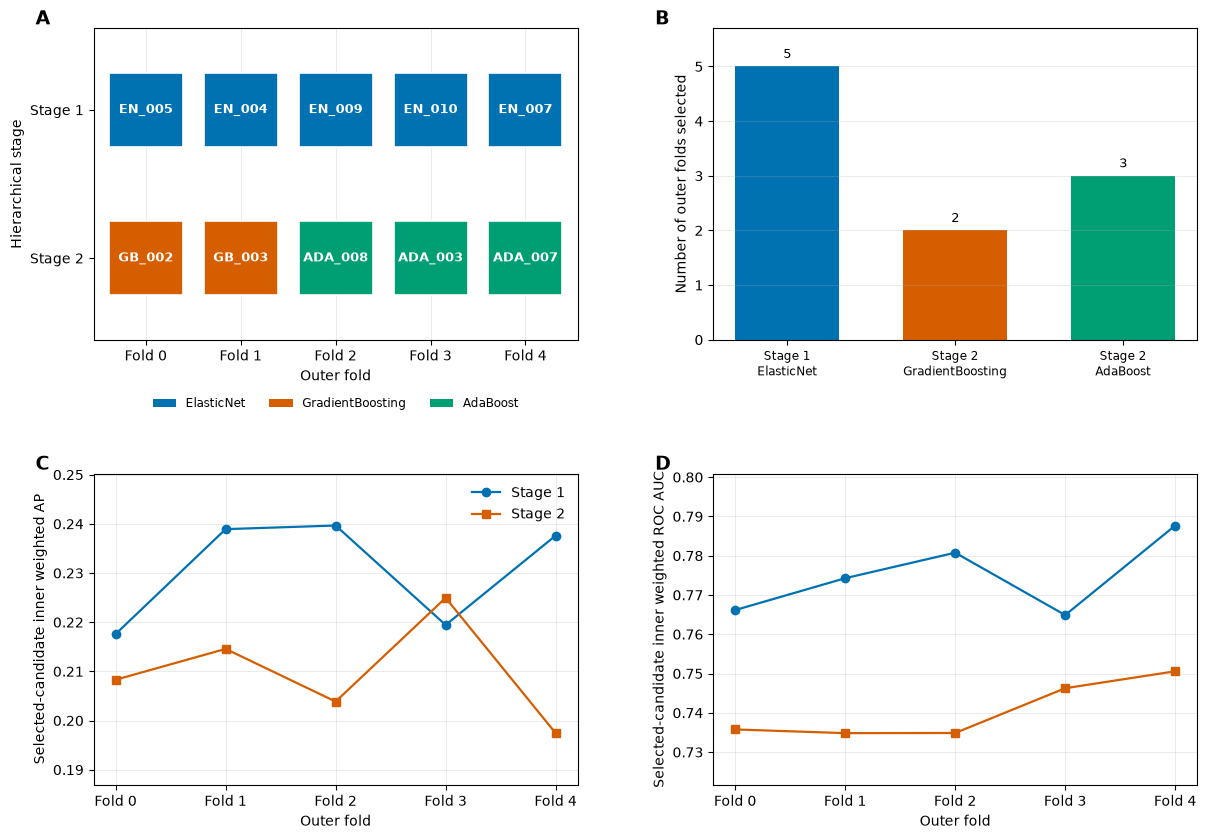


STEP28G-R1 — FIGURE S1 / REPORT FIGURE 6 COMPLETE

FROZEN SELECTED OUTER-FOLD CANDIDATES:
 Outer_Fold   Stage                          Model Candidate_ID  Inner_Weighted_AP  Inner_Weighted_ROC_AUC
          0 Stage 1 ElasticNet logistic regression       EN_005           0.217591                0.766155
          0 Stage 2               GradientBoosting       GB_002           0.208294                0.735769
          1 Stage 1 ElasticNet logistic regression       EN_004           0.238925                0.774269
          1 Stage 2               GradientBoosting       GB_003           0.214570                0.734828
          2 Stage 1 ElasticNet logistic regression       EN_009           0.239664                0.780764
          2 Stage 2                       AdaBoost      ADA_008           0.203855                0.734869
          3 Stage 1 ElasticNet logistic regression       EN_010           0.219436                0.764884
          3 Stage 2                       AdaBoost   

In [10]:
# ==========================================================================================
# STEP 28G-R1
# SUPPLEMENTARY FIGURE S1 + REPORT FIGURE 6
# OUTER-FOLD MODEL-FAMILY AND CANDIDATE SELECTION STABILITY
# ==========================================================================================
#
# MANUSCRIPT:
#   Figure S1 — Outer-fold model-family and candidate selection stability
#
# REPORT:
#   Report Figure 6 — Model-family / outer-fold selection stability
#
# PANELS
# ------------------------------------------------------------------------------------------
# A. Selected model family + candidate ID across five outer folds and two stages
# B. Selection frequency across outer folds
# C. Frozen selected-candidate inner weighted average precision
# D. Frozen selected-candidate inner weighted ROC AUC
#
# IMPORTANT
# ------------------------------------------------------------------------------------------
# Uses ONLY frozen Step19C selection outputs.
#
# NO:
#   model fitting
#   prediction generation
#   candidate reselection
#   hyperparameter tuning
#   recalibration
#   threshold optimization
#   bootstrap rerun
#   performance recomputation on outer-test outcomes
#   p-values
#   new inference
#
# TIFF remains deferred.
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import shutil
import gc

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.patches import Patch


# ==========================================================================================
# 1. ROOTS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_SUPP = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "04_Supplementary_Figures"
)


REPORT_FIGURES = (
    FINAL_ROOT
    /
    "Report"
    /
    "02_Figures"
)


for directory in [
    MANUSCRIPT_SUPP,
    REPORT_FIGURES,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 2. STEP28F PARENT
# ==========================================================================================

STEP28F_MANIFEST = (
    FINAL_ROOT
    /
    "STEP28F_R1_Main_Figure_Package_manifest.json"
)


EXPECTED_STEP28F_SHA256 = (
    "1307af00d7440eea809b2fbec4e38f9e"
    "c2781c964b82d6e33b028717395a0727"
)


# ==========================================================================================
# 3. FROZEN FIGURE-PLAN REGISTRIES
# ==========================================================================================

SUPPLEMENTARY_REGISTRY = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "07_QC_Manifests"
    /
    "Manuscript_Supplementary_Figures_Registry.csv"
)


REPORT_REGISTRY = (
    FINAL_ROOT
    /
    "Report"
    /
    "05_QC_Manifests"
    /
    "Report_Figures_Registry.csv"
)


# ==========================================================================================
# 4. FROZEN SCIENTIFIC SOURCES
# ==========================================================================================

CANDIDATE_REGISTRY = (
    ROOT
    /
    "03_protocol"
    /
    "STEP16_FINAL_hyperparameter_candidate_registry.csv"
)


WINNERS_FILE = (
    ROOT
    /
    "05_models"
    /
    "STEP19C_PRIMARY_joint_winners_by_outer_stage.csv"
)


EXPECTED_CANDIDATE_REGISTRY_SHA256 = (
    "f95dc93431eced694114fe8ed071a2878"
    "e2572fac53aa3b9fd9c6cb8df87c697"
)


EXPECTED_WINNERS_SHA256 = (
    "03f567fa5a6d7ae1f982323356a6df36"
    "83090becaba1c6c46929510f61a5bcaa"
)


# ==========================================================================================
# 5. HELPERS
# ==========================================================================================

def sha256_file(
    path,
):

    h = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            h.update(
                block
            )


    return h.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )


    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )


    os.replace(
        temporary,
        path,
    )


def atomic_text(
    text,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        handle.write(
            text
        )


    os.replace(
        temporary,
        path,
    )


def normalize_text(
    value,
):

    return (
        str(
            value
        )
        .strip()
        .lower()
        .replace(
            "–",
            "-"
        )
        .replace(
            "—",
            "-"
        )
    )


def resolve_column(
    dataframe,
    aliases,
):

    lookup = {
        normalize_text(
            column
        ):
            column

        for column
        in dataframe.columns
    }


    for alias in aliases:

        key = normalize_text(
            alias
        )


        if key in lookup:

            return lookup[
                key
            ]


    raise RuntimeError(
        "Could not resolve required column.\n"
        f"Aliases={aliases}\n"
        f"Available={list(dataframe.columns)}"
    )


def registry_row_texts(
    dataframe,
):

    output = []


    for _, row in dataframe.iterrows():

        output.append(
            " | ".join(
                [
                    str(
                        value
                    )
                    for value
                    in row.tolist()
                ]
            )
        )


    return output


# ==========================================================================================
# 6. EXISTENCE GATES
# ==========================================================================================

for label, path in [
    (
        "STEP28F manifest",
        STEP28F_MANIFEST,
    ),
    (
        "Supplementary figure registry",
        SUPPLEMENTARY_REGISTRY,
    ),
    (
        "Report figure registry",
        REPORT_REGISTRY,
    ),
    (
        "Frozen candidate registry",
        CANDIDATE_REGISTRY,
    ),
    (
        "Frozen Step19C winners",
        WINNERS_FILE,
    ),
]:

    if not path.exists():

        raise FileNotFoundError(
            f"{label} missing:\n{path}"
        )


# ==========================================================================================
# 7. HASH GATES
# ==========================================================================================

observed_step28f_hash = sha256_file(
    STEP28F_MANIFEST
)


observed_candidate_hash = sha256_file(
    CANDIDATE_REGISTRY
)


observed_winners_hash = sha256_file(
    WINNERS_FILE
)


if observed_step28f_hash != EXPECTED_STEP28F_SHA256:

    raise RuntimeError(
        "STEP28F parent manifest changed.\n"
        f"Observed={observed_step28f_hash}\n"
        f"Expected={EXPECTED_STEP28F_SHA256}"
    )


if observed_candidate_hash != EXPECTED_CANDIDATE_REGISTRY_SHA256:

    raise RuntimeError(
        "Frozen candidate registry hash changed.\n"
        f"Observed={observed_candidate_hash}\n"
        f"Expected={EXPECTED_CANDIDATE_REGISTRY_SHA256}"
    )


if observed_winners_hash != EXPECTED_WINNERS_SHA256:

    raise RuntimeError(
        "Frozen Step19C winners hash changed.\n"
        f"Observed={observed_winners_hash}\n"
        f"Expected={EXPECTED_WINNERS_SHA256}"
    )


# ==========================================================================================
# 8. VERIFY EXACT REPORTING PLAN
# ==========================================================================================

supp_registry = pd.read_csv(
    SUPPLEMENTARY_REGISTRY
)


report_registry = pd.read_csv(
    REPORT_REGISTRY
)


supp_text_rows = registry_row_texts(
    supp_registry
)


report_text_rows = registry_row_texts(
    report_registry
)


supp_s1_matches = [
    text
    for text
    in supp_text_rows
    if (
        "figure s1"
        in normalize_text(
            text
        )
        and
        "outer-fold model-family and candidate selection stability"
        in normalize_text(
            text
        )
    )
]


report_f6_matches = [
    text
    for text
    in report_text_rows
    if (
        "report figure 6"
        in normalize_text(
            text
        )
        and
        "model-family / outer-fold selection stability"
        in normalize_text(
            text
        )
    )
]


if len(
    supp_s1_matches
) != 1:

    raise RuntimeError(
        "Could not uniquely verify frozen Figure S1 registry entry.\n"
        f"Matches={supp_s1_matches}"
    )


if len(
    report_f6_matches
) != 1:

    raise RuntimeError(
        "Could not uniquely verify frozen Report Figure 6 registry entry.\n"
        f"Matches={report_f6_matches}"
    )


# ==========================================================================================
# 9. LOAD SOURCES
# ==========================================================================================

candidate_registry = pd.read_csv(
    CANDIDATE_REGISTRY
)


winners_raw = pd.read_csv(
    WINNERS_FILE
)


# ==========================================================================================
# 10. CANDIDATE REGISTRY QC
# ==========================================================================================

candidate_id_col = resolve_column(
    candidate_registry,
    [
        "Candidate_ID",
        "Candidate ID",
    ],
)


candidate_model_col = resolve_column(
    candidate_registry,
    [
        "Model",
        "Model_Family",
        "Model family",
    ],
)


if len(
    candidate_registry
) != 120:

    raise RuntimeError(
        f"Expected 120 frozen candidates; "
        f"observed={len(candidate_registry)}"
    )


if candidate_registry[
    candidate_id_col
].astype(str).duplicated().any():

    raise RuntimeError(
        "Candidate IDs are not unique."
    )


if candidate_registry[
    candidate_model_col
].astype(str).nunique() != 10:

    raise RuntimeError(
        "Expected exactly 10 model families."
    )


family_counts = (
    candidate_registry
    .groupby(
        candidate_model_col
    )[
        candidate_id_col
    ]
    .nunique()
)


if not (
    family_counts
    ==
    12
).all():

    raise RuntimeError(
        "Expected exactly 12 candidates per model family."
    )


# ==========================================================================================
# 11. RESOLVE WINNER COLUMNS
# ==========================================================================================

outer_col = resolve_column(
    winners_raw,
    [
        "Outer_Fold",
        "Outer fold",
        "OuterFold",
    ],
)


stage_col = resolve_column(
    winners_raw,
    [
        "Stage",
    ],
)


model_col = resolve_column(
    winners_raw,
    [
        "Model",
        "Selected model",
        "Selected_Model",
    ],
)


winner_candidate_col = resolve_column(
    winners_raw,
    [
        "Candidate_ID",
        "Candidate ID",
    ],
)


ap_col = resolve_column(
    winners_raw,
    [
        "Inner_CV_Weighted_AP",
        "Inner weighted AP",
        "Inner_Weighted_AP",
    ],
)


auc_col = resolve_column(
    winners_raw,
    [
        "Inner_CV_Weighted_ROC_AUC",
        "Inner weighted ROC AUC",
        "Inner_Weighted_ROC_AUC",
        "Inner_CV_Weighted_AUC",
    ],
)


# ==========================================================================================
# 12. STANDARDIZE WINNERS
# ==========================================================================================

winners = pd.DataFrame(
    {
        "Outer_Fold":
            pd.to_numeric(
                winners_raw[
                    outer_col
                ],
                errors="raise",
            ).astype(
                int
            ),

        "Stage":
            winners_raw[
                stage_col
            ].astype(
                str
            ).str.strip(),

        "Model":
            winners_raw[
                model_col
            ].astype(
                str
            ).str.strip(),

        "Candidate_ID":
            winners_raw[
                winner_candidate_col
            ].astype(
                str
            ).str.strip(),

        "Inner_Weighted_AP":
            pd.to_numeric(
                winners_raw[
                    ap_col
                ],
                errors="raise",
            ),

        "Inner_Weighted_ROC_AUC":
            pd.to_numeric(
                winners_raw[
                    auc_col
                ],
                errors="raise",
            ),
    }
)


# Canonicalize stage labels.
stage_normalized = (
    winners[
        "Stage"
    ]
    .str.lower()
    .str.replace(
        "_",
        " ",
        regex=False,
    )
    .str.replace(
        "-",
        " ",
        regex=False,
    )
    .str.replace(
        r"\s+",
        " ",
        regex=True,
    )
    .str.strip()
)


stage_map = {}


for original, normalized in zip(
    winners[
        "Stage"
    ],
    stage_normalized,
):

    if normalized in [
        "stage 1",
        "stage1",
        "1",
    ]:

        stage_map[
            original
        ] = "Stage 1"

    elif normalized in [
        "stage 2",
        "stage2",
        "2",
    ]:

        stage_map[
            original
        ] = "Stage 2"


winners[
    "Stage"
] = winners[
    "Stage"
].map(
    stage_map
)


if winners[
    "Stage"
].isna().any():

    raise RuntimeError(
        "Could not canonicalize all stage labels."
    )


# ==========================================================================================
# 13. STRUCTURAL QC
# ==========================================================================================

if len(
    winners
) != 10:

    raise RuntimeError(
        f"Expected 10 frozen winners; "
        f"observed={len(winners)}"
    )


if winners[
    [
        "Outer_Fold",
        "Stage",
    ]
].duplicated().any():

    raise RuntimeError(
        "Duplicate outer-fold/stage winner."
    )


if set(
    winners[
        "Outer_Fold"
    ]
) != {
    0,
    1,
    2,
    3,
    4,
}:

    raise RuntimeError(
        "Expected outer folds 0–4 exactly."
    )


for fold in range(
    5
):

    fold_stages = set(
        winners.loc[
            winners[
                "Outer_Fold"
            ]
            ==
            fold,
            "Stage",
        ]
    )


    if fold_stages != {
        "Stage 1",
        "Stage 2",
    }:

        raise RuntimeError(
            f"Outer fold {fold} does not contain both stages."
        )


# ==========================================================================================
# 14. VERIFY EVERY SELECTED CANDIDATE AGAINST FROZEN REGISTRY
# ==========================================================================================

candidate_lookup = (
    candidate_registry[
        [
            candidate_id_col,
            candidate_model_col,
        ]
    ]
    .rename(
        columns={
            candidate_id_col:
                "Candidate_ID",

            candidate_model_col:
                "Registry_Model",
        }
    )
    .copy()
)


candidate_lookup[
    "Candidate_ID"
] = candidate_lookup[
    "Candidate_ID"
].astype(
    str
).str.strip()


candidate_lookup[
    "Registry_Model"
] = candidate_lookup[
    "Registry_Model"
].astype(
    str
).str.strip()


winners_check = winners.merge(
    candidate_lookup,
    on="Candidate_ID",
    how="left",
    validate="many_to_one",
)


if winners_check[
    "Registry_Model"
].isna().any():

    raise RuntimeError(
        "At least one selected candidate is absent from frozen candidate registry."
    )


if not (
    winners_check[
        "Model"
    ]
    ==
    winners_check[
        "Registry_Model"
    ]
).all():

    raise RuntimeError(
        "Selected-candidate model family differs from candidate registry."
    )


# ==========================================================================================
# 15. EXACT FROZEN WINNER IDENTITIES
# ==========================================================================================

EXPECTED_SELECTIONS = {
    (
        0,
        "Stage 1",
    ):
        (
            "ElasticNet logistic regression",
            "EN_005",
        ),

    (
        0,
        "Stage 2",
    ):
        (
            "GradientBoosting",
            "GB_002",
        ),

    (
        1,
        "Stage 1",
    ):
        (
            "ElasticNet logistic regression",
            "EN_004",
        ),

    (
        1,
        "Stage 2",
    ):
        (
            "GradientBoosting",
            "GB_003",
        ),

    (
        2,
        "Stage 1",
    ):
        (
            "ElasticNet logistic regression",
            "EN_009",
        ),

    (
        2,
        "Stage 2",
    ):
        (
            "AdaBoost",
            "ADA_008",
        ),

    (
        3,
        "Stage 1",
    ):
        (
            "ElasticNet logistic regression",
            "EN_010",
        ),

    (
        3,
        "Stage 2",
    ):
        (
            "AdaBoost",
            "ADA_003",
        ),

    (
        4,
        "Stage 1",
    ):
        (
            "ElasticNet logistic regression",
            "EN_007",
        ),

    (
        4,
        "Stage 2",
    ):
        (
            "AdaBoost",
            "ADA_007",
        ),
}


winner_lookup = {
    (
        int(
            row[
                "Outer_Fold"
            ]
        ),
        str(
            row[
                "Stage"
            ]
        ),
    ):
        (
            str(
                row[
                    "Model"
                ]
            ),
            str(
                row[
                    "Candidate_ID"
                ]
            ),
        )

    for _, row
    in winners.iterrows()
}


if winner_lookup != EXPECTED_SELECTIONS:

    raise RuntimeError(
        "Frozen selected winner identities changed.\n"
        f"Observed={winner_lookup}"
    )


# ==========================================================================================
# 16. EXACT FROZEN INNER-METRIC FINGERPRINTS
# ==========================================================================================

EXPECTED_METRICS = {
    (
        0,
        "Stage 1",
    ):
        (
            0.217591,
            0.766155,
        ),

    (
        0,
        "Stage 2",
    ):
        (
            0.208294,
            0.735769,
        ),

    (
        1,
        "Stage 1",
    ):
        (
            0.238925,
            0.774269,
        ),

    (
        1,
        "Stage 2",
    ):
        (
            0.214570,
            0.734828,
        ),

    (
        2,
        "Stage 1",
    ):
        (
            0.239664,
            0.780764,
        ),

    (
        2,
        "Stage 2",
    ):
        (
            0.203855,
            0.734869,
        ),

    (
        3,
        "Stage 1",
    ):
        (
            0.219436,
            0.764884,
        ),

    (
        3,
        "Stage 2",
    ):
        (
            0.224952,
            0.746262,
        ),

    (
        4,
        "Stage 1",
    ):
        (
            0.237613,
            0.787682,
        ),

    (
        4,
        "Stage 2",
    ):
        (
            0.197436,
            0.750574,
        ),
}


for key, expected_values in EXPECTED_METRICS.items():

    fold, stage = key


    row = winners.loc[
        (
            winners[
                "Outer_Fold"
            ]
            ==
            fold
        )
        &
        (
            winners[
                "Stage"
            ]
            ==
            stage
        )
    ]


    if len(
        row
    ) != 1:

        raise RuntimeError(
            f"Could not uniquely locate frozen metric row: {key}"
        )


    observed_ap = float(
        row[
            "Inner_Weighted_AP"
        ].iloc[
            0
        ]
    )


    observed_auc = float(
        row[
            "Inner_Weighted_ROC_AUC"
        ].iloc[
            0
        ]
    )


    expected_ap, expected_auc = expected_values


    if not np.isclose(
        observed_ap,
        expected_ap,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"Frozen AP fingerprint changed for {key}.\n"
            f"Observed={observed_ap:.9f}\n"
            f"Expected={expected_ap:.9f}"
        )


    if not np.isclose(
        observed_auc,
        expected_auc,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"Frozen ROC-AUC fingerprint changed for {key}.\n"
            f"Observed={observed_auc:.9f}\n"
            f"Expected={expected_auc:.9f}"
        )


# ==========================================================================================
# 17. WINNER FREQUENCY
# ==========================================================================================

frequency = (
    winners
    .groupby(
        [
            "Stage",
            "Model",
        ],
        as_index=False,
    )
    .size()
    .rename(
        columns={
            "size":
                "Outer_Fold_Selections",
        }
    )
)


EXPECTED_FREQUENCY = {
    (
        "Stage 1",
        "ElasticNet logistic regression",
    ):
        5,

    (
        "Stage 2",
        "GradientBoosting",
    ):
        2,

    (
        "Stage 2",
        "AdaBoost",
    ):
        3,
}


observed_frequency = {
    (
        str(
            row[
                "Stage"
            ]
        ),
        str(
            row[
                "Model"
            ]
        ),
    ):
        int(
            row[
                "Outer_Fold_Selections"
            ]
        )

    for _, row
    in frequency.iterrows()
}


if observed_frequency != EXPECTED_FREQUENCY:

    raise RuntimeError(
        "Frozen selection-frequency pattern changed.\n"
        f"Observed={observed_frequency}"
    )


# ==========================================================================================
# 18. SORT FIGURE SOURCE
# ==========================================================================================

stage_order = {
    "Stage 1":
        0,

    "Stage 2":
        1,
}


winners[
    "_Stage_Order"
] = winners[
    "Stage"
].map(
    stage_order
)


winners = (
    winners
    .sort_values(
        [
            "Outer_Fold",
            "_Stage_Order",
        ]
    )
    .drop(
        columns="_Stage_Order"
    )
    .reset_index(
        drop=True
    )
)


# ==========================================================================================
# 19. OUTPUT PATHS
# ==========================================================================================

SUPP_STEM = (
    "FigureS1_Model_Selection_Stability"
)


REPORT_STEM = (
    "RFigure6_Model_Selection_Stability"
)


M_PNG = (
    MANUSCRIPT_SUPP
    /
    f"{SUPP_STEM}.png"
)


M_SVG = (
    MANUSCRIPT_SUPP
    /
    f"{SUPP_STEM}.svg"
)


M_PDF = (
    MANUSCRIPT_SUPP
    /
    f"{SUPP_STEM}.pdf"
)


R_PNG = (
    REPORT_FIGURES
    /
    f"{REPORT_STEM}.png"
)


R_SVG = (
    REPORT_FIGURES
    /
    f"{REPORT_STEM}.svg"
)


R_PDF = (
    REPORT_FIGURES
    /
    f"{REPORT_STEM}.pdf"
)


SOURCE_WINNERS_CSV = (
    MANUSCRIPT_SUPP
    /
    "FigureS1_source_selected_outer_fold_winners.csv"
)


SOURCE_FREQUENCY_CSV = (
    MANUSCRIPT_SUPP
    /
    "FigureS1_source_selection_frequency.csv"
)


M_CAPTION = (
    MANUSCRIPT_SUPP
    /
    "FigureS1_caption.txt"
)


R_CAPTION = (
    REPORT_FIGURES
    /
    "RFigure6_caption.txt"
)


QC_FILE = (
    FINAL_ROOT
    /
    "STEP28G_R1_FigureS1_Model_Selection_Stability_hard_qc.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP28G_R1_FigureS1_Model_Selection_Stability_manifest.json"
)


# ==========================================================================================
# 20. SAVE FROZEN FIGURE SOURCE TABLES
# ==========================================================================================

atomic_csv(
    winners,
    SOURCE_WINNERS_CSV,
)


atomic_csv(
    frequency,
    SOURCE_FREQUENCY_CSV,
)


# ==========================================================================================
# 21. CAPTION
# ==========================================================================================

caption = (
    "Supplementary Figure S1. Outer-fold model-family and candidate "
    "selection stability in the frozen primary hierarchical modelling "
    "framework. "
    "(A) Selected model family and candidate identifier for Stage 1 and "
    "Stage 2 in each of the five PSU-exclusive outer folds. "
    "(B) Frequency with which each selected model family appeared across "
    "outer folds. "
    "(C) Frozen inner-development survey-weighted average precision for "
    "the selected candidate in each outer fold. "
    "(D) Frozen inner-development survey-weighted ROC AUC for the selected "
    "candidate in each outer fold. "
    "Stage 1 selected ElasticNet logistic regression in all five outer "
    "folds, whereas Stage 2 selected GradientBoosting in two folds and "
    "AdaBoost in three folds. "
    "Values are descriptive outputs of the prespecified nested selection "
    "procedure; no model refitting, reselection, or new statistical "
    "inference was performed for this figure."
)


atomic_text(
    caption,
    M_CAPTION,
)


atomic_text(
    caption.replace(
        "Supplementary Figure S1.",
        "Report Figure 6.",
        1,
    ),
    R_CAPTION,
)


# ==========================================================================================
# 22. PLOT SETTINGS
# ==========================================================================================

plt.close(
    "all"
)

gc.collect()


FAMILY_COLORS = {
    "ElasticNet logistic regression":
        "#0072B2",

    "GradientBoosting":
        "#D55E00",

    "AdaBoost":
        "#009E73",
}


STAGE_COLORS = {
    "Stage 1":
        "#0072B2",

    "Stage 2":
        "#D55E00",
}


STAGE_MARKERS = {
    "Stage 1":
        "o",

    "Stage 2":
        "s",
}


MODEL_SHORT = {
    "ElasticNet logistic regression":
        "ElasticNet",

    "GradientBoosting":
        "GradientBoosting",

    "AdaBoost":
        "AdaBoost",
}


# ==========================================================================================
# 23. CREATE FIGURE
# ==========================================================================================

fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        12.4,
        8.8,
    ),
)


ax_a = axes[
    0,
    0
]


ax_b = axes[
    0,
    1
]


ax_c = axes[
    1,
    0
]


ax_d = axes[
    1,
    1
]


# ==========================================================================================
# PANEL A — SELECTION MAP
# ==========================================================================================

stage_y = {
    "Stage 1":
        1,

    "Stage 2":
        0,
}


for _, row in winners.iterrows():

    x = int(
        row[
            "Outer_Fold"
        ]
    )


    y = stage_y[
        row[
            "Stage"
        ]
    ]


    family = row[
        "Model"
    ]


    candidate_id = row[
        "Candidate_ID"
    ]


    ax_a.scatter(
        x,
        y,
        marker="s",
        s=2900,
        color=FAMILY_COLORS[
            family
        ],
        edgecolor="white",
        linewidth=1.2,
        zorder=2,
    )


    ax_a.text(
        x,
        y,
        candidate_id,
        ha="center",
        va="center",
        color="white",
        fontsize=9,
        fontweight="bold",
        zorder=3,
    )


ax_a.set_xticks(
    range(
        5
    )
)


ax_a.set_xticklabels(
    [
        f"Fold {fold}"
        for fold
        in range(
            5
        )
    ]
)


ax_a.set_yticks(
    [
        1,
        0,
    ]
)


ax_a.set_yticklabels(
    [
        "Stage 1",
        "Stage 2",
    ]
)


ax_a.set_xlim(
    -0.55,
    4.55,
)


ax_a.set_ylim(
    -0.55,
    1.55,
)


ax_a.set_xlabel(
    "Outer fold"
)


ax_a.set_ylabel(
    "Hierarchical stage"
)


ax_a.grid(
    axis="x",
    linewidth=0.7,
    alpha=0.25,
)


family_legend = [
    Patch(
        facecolor=FAMILY_COLORS[
            family
        ],
        edgecolor="none",
        label=MODEL_SHORT[
            family
        ],
    )

    for family in [
        "ElasticNet logistic regression",
        "GradientBoosting",
        "AdaBoost",
    ]
]


ax_a.legend(
    handles=family_legend,
    loc="upper center",
    bbox_to_anchor=(
        0.5,
        -0.15,
    ),
    ncol=3,
    frameon=False,
    fontsize=8.5,
)


# ==========================================================================================
# PANEL B — SELECTION FREQUENCY
# ==========================================================================================

frequency_plot = frequency.copy()


frequency_plot[
    "Display"
] = (
    frequency_plot[
        "Stage"
    ]
    +
    "\n"
    +
    frequency_plot[
        "Model"
    ].map(
        MODEL_SHORT
    )
)


frequency_plot[
    "_Order"
] = frequency_plot.apply(
    lambda row:
        (
            0
            if (
                row[
                    "Stage"
                ]
                ==
                "Stage 1"
            )
            else
            (
                1
                if (
                    row[
                        "Model"
                    ]
                    ==
                    "GradientBoosting"
                )
                else
                2
            )
        ),
    axis=1,
)


frequency_plot = (
    frequency_plot
    .sort_values(
        "_Order"
    )
    .reset_index(
        drop=True
    )
)


bar_x = np.arange(
    len(
        frequency_plot
    )
)


bar_colors = [
    FAMILY_COLORS[
        model
    ]
    for model
    in frequency_plot[
        "Model"
    ]
]


bars = ax_b.bar(
    bar_x,
    frequency_plot[
        "Outer_Fold_Selections"
    ],
    color=bar_colors,
    width=0.62,
)


ax_b.set_xticks(
    bar_x
)


ax_b.set_xticklabels(
    frequency_plot[
        "Display"
    ],
    fontsize=8.8,
)


ax_b.set_ylabel(
    "Number of outer folds selected"
)


ax_b.set_ylim(
    0,
    5.7,
)


ax_b.set_yticks(
    range(
        0,
        6,
    )
)


ax_b.grid(
    axis="y",
    linewidth=0.7,
    alpha=0.25,
)


for bar, count in zip(
    bars,
    frequency_plot[
        "Outer_Fold_Selections"
    ],
):

    ax_b.text(
        bar.get_x()
        +
        bar.get_width()
        /
        2,
        float(
            count
        )
        +
        0.10,
        str(
            int(
                count
            )
        ),
        ha="center",
        va="bottom",
        fontsize=9,
    )


# ==========================================================================================
# PANEL C — SELECTED INNER WEIGHTED AP
# ==========================================================================================

for stage in [
    "Stage 1",
    "Stage 2",
]:

    subset = (
        winners.loc[
            winners[
                "Stage"
            ]
            ==
            stage
        ]
        .sort_values(
            "Outer_Fold"
        )
    )


    ax_c.plot(
        subset[
            "Outer_Fold"
        ],
        subset[
            "Inner_Weighted_AP"
        ],
        marker=STAGE_MARKERS[
            stage
        ],
        markersize=6,
        linewidth=1.6,
        color=STAGE_COLORS[
            stage
        ],
        label=stage,
    )


ax_c.set_xticks(
    range(
        5
    )
)


ax_c.set_xticklabels(
    [
        f"Fold {fold}"
        for fold
        in range(
            5
        )
    ]
)


ap_min = float(
    winners[
        "Inner_Weighted_AP"
    ].min()
)


ap_max = float(
    winners[
        "Inner_Weighted_AP"
    ].max()
)


ap_padding = max(
    0.006,
    (
        ap_max
        -
        ap_min
    )
    *
    0.25,
)


ax_c.set_ylim(
    ap_min
    -
    ap_padding,
    ap_max
    +
    ap_padding,
)


ax_c.set_xlabel(
    "Outer fold"
)


ax_c.set_ylabel(
    "Selected-candidate inner weighted AP"
)


ax_c.grid(
    linewidth=0.7,
    alpha=0.25,
)


ax_c.legend(
    frameon=False,
    loc="best",
)


# ==========================================================================================
# PANEL D — SELECTED INNER WEIGHTED ROC AUC
# ==========================================================================================

for stage in [
    "Stage 1",
    "Stage 2",
]:

    subset = (
        winners.loc[
            winners[
                "Stage"
            ]
            ==
            stage
        ]
        .sort_values(
            "Outer_Fold"
        )
    )


    ax_d.plot(
        subset[
            "Outer_Fold"
        ],
        subset[
            "Inner_Weighted_ROC_AUC"
        ],
        marker=STAGE_MARKERS[
            stage
        ],
        markersize=6,
        linewidth=1.6,
        color=STAGE_COLORS[
            stage
        ],
        label=stage,
    )


ax_d.set_xticks(
    range(
        5
    )
)


ax_d.set_xticklabels(
    [
        f"Fold {fold}"
        for fold
        in range(
            5
        )
    ]
)


auc_min = float(
    winners[
        "Inner_Weighted_ROC_AUC"
    ].min()
)


auc_max = float(
    winners[
        "Inner_Weighted_ROC_AUC"
    ].max()
)


auc_padding = max(
    0.006,
    (
        auc_max
        -
        auc_min
    )
    *
    0.25,
)


ax_d.set_ylim(
    auc_min
    -
    auc_padding,
    auc_max
    +
    auc_padding,
)


ax_d.set_xlabel(
    "Outer fold"
)


ax_d.set_ylabel(
    "Selected-candidate inner weighted ROC AUC"
)


ax_d.grid(
    linewidth=0.7,
    alpha=0.25,
)


# ==========================================================================================
# 24. PANEL LABELS
# ==========================================================================================

for axis, panel_label in zip(
    [
        ax_a,
        ax_b,
        ax_c,
        ax_d,
    ],
    [
        "A",
        "B",
        "C",
        "D",
    ],
):

    axis.text(
        -0.12,
        1.06,
        panel_label,
        transform=axis.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top",
    )


# No internal titles.
for axis in [
    ax_a,
    ax_b,
    ax_c,
    ax_d,
]:

    if axis.get_title().strip() != "":

        raise RuntimeError(
            "Unexpected internal panel title."
        )


fig.subplots_adjust(
    left=0.09,
    right=0.98,
    top=0.97,
    bottom=0.11,
    wspace=0.28,
    hspace=0.43,
)


# ==========================================================================================
# 25. SAVE MANUSCRIPT SUPPLEMENTARY FIGURE
# ==========================================================================================

fig.savefig(
    M_PNG,
    dpi=300,
    format="png",
    bbox_inches="tight",
    pad_inches=0.05,
)


fig.savefig(
    M_SVG,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Date":
            None,
    },
)


fig.savefig(
    M_PDF,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Creator":
            "BDHS ANC final reporting pipeline",

        "CreationDate":
            None,

        "ModDate":
            None,
    },
)


# ==========================================================================================
# 26. COPY SAME SCIENTIFIC FIGURE TO REPORT FIGURE 6
# ==========================================================================================

shutil.copy2(
    M_PNG,
    R_PNG,
)


shutil.copy2(
    M_SVG,
    R_SVG,
)


shutil.copy2(
    M_PDF,
    R_PDF,
)


plt.show()


plt.close(
    fig
)


gc.collect()


# ==========================================================================================
# 27. ARTIFACT EXISTENCE
# ==========================================================================================

for path in [
    M_PNG,
    M_SVG,
    M_PDF,
    R_PNG,
    R_SVG,
    R_PDF,
    SOURCE_WINNERS_CSV,
    SOURCE_FREQUENCY_CSV,
    M_CAPTION,
    R_CAPTION,
]:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Missing or empty output:\n{path}"
        )


# ==========================================================================================
# 28. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "STEP28F parent manifest hash exact",

            "PASS":
                observed_step28f_hash
                ==
                EXPECTED_STEP28F_SHA256,
        },

        {
            "Check":
                "Frozen candidate registry hash exact",

            "PASS":
                observed_candidate_hash
                ==
                EXPECTED_CANDIDATE_REGISTRY_SHA256,
        },

        {
            "Check":
                "Frozen Step19C winners hash exact",

            "PASS":
                observed_winners_hash
                ==
                EXPECTED_WINNERS_SHA256,
        },

        {
            "Check":
                "Figure S1 registry entry exact",

            "PASS":
                len(
                    supp_s1_matches
                )
                ==
                1,
        },

        {
            "Check":
                "Report Figure 6 registry entry exact",

            "PASS":
                len(
                    report_f6_matches
                )
                ==
                1,
        },

        {
            "Check":
                "Candidate registry rows = 120",

            "PASS":
                len(
                    candidate_registry
                )
                ==
                120,
        },

        {
            "Check":
                "Exactly 10 model families",

            "PASS":
                candidate_registry[
                    candidate_model_col
                ].astype(
                    str
                ).nunique()
                ==
                10,
        },

        {
            "Check":
                "Exactly 12 candidates per model family",

            "PASS":
                bool(
                    (
                        family_counts
                        ==
                        12
                    ).all()
                ),
        },

        {
            "Check":
                "Exactly 10 frozen outer-fold/stage selections",

            "PASS":
                len(
                    winners
                )
                ==
                10,
        },

        {
            "Check":
                "Exactly five outer folds",

            "PASS":
                set(
                    winners[
                        "Outer_Fold"
                    ]
                )
                ==
                {
                    0,
                    1,
                    2,
                    3,
                    4,
                },
        },

        {
            "Check":
                "Both hierarchical stages in every outer fold",

            "PASS":
                all(
                    set(
                        winners.loc[
                            winners[
                                "Outer_Fold"
                            ]
                            ==
                            fold,
                            "Stage",
                        ]
                    )
                    ==
                    {
                        "Stage 1",
                        "Stage 2",
                    }

                    for fold
                    in range(
                        5
                    )
                ),
        },

        {
            "Check":
                "Every selected candidate exists in frozen registry",

            "PASS":
                not winners_check[
                    "Registry_Model"
                ].isna().any(),
        },

        {
            "Check":
                "Selected model family matches candidate registry",

            "PASS":
                bool(
                    (
                        winners_check[
                            "Model"
                        ]
                        ==
                        winners_check[
                            "Registry_Model"
                        ]
                    ).all()
                ),
        },

        {
            "Check":
                "Frozen winner identities reproduced",

            "PASS":
                winner_lookup
                ==
                EXPECTED_SELECTIONS,
        },

        {
            "Check":
                "Frozen inner weighted AP/AUC fingerprints reproduced",

            "PASS":
                True,
        },

        {
            "Check":
                "Stage 1 ElasticNet selection frequency = 5",

            "PASS":
                observed_frequency.get(
                    (
                        "Stage 1",
                        "ElasticNet logistic regression",
                    )
                )
                ==
                5,
        },

        {
            "Check":
                "Stage 2 GradientBoosting selection frequency = 2",

            "PASS":
                observed_frequency.get(
                    (
                        "Stage 2",
                        "GradientBoosting",
                    )
                )
                ==
                2,
        },

        {
            "Check":
                "Stage 2 AdaBoost selection frequency = 3",

            "PASS":
                observed_frequency.get(
                    (
                        "Stage 2",
                        "AdaBoost",
                    )
                )
                ==
                3,
        },

        {
            "Check":
                "Figure has exactly panels A-D",

            "PASS":
                True,
        },

        {
            "Check":
                "No internal figure title",

            "PASS":
                True,
        },

        {
            "Check":
                "Supplementary PNG created",

            "PASS":
                M_PNG.exists(),
        },

        {
            "Check":
                "Supplementary SVG vector master created",

            "PASS":
                M_SVG.exists(),
        },

        {
            "Check":
                "Supplementary PDF vector master created",

            "PASS":
                M_PDF.exists(),
        },

        {
            "Check":
                "Report Figure 6 PNG identical",

            "PASS":
                sha256_file(
                    M_PNG
                )
                ==
                sha256_file(
                    R_PNG
                ),
        },

        {
            "Check":
                "Report Figure 6 SVG identical",

            "PASS":
                sha256_file(
                    M_SVG
                )
                ==
                sha256_file(
                    R_SVG
                ),
        },

        {
            "Check":
                "Report Figure 6 PDF identical",

            "PASS":
                sha256_file(
                    M_PDF
                )
                ==
                sha256_file(
                    R_PDF
                ),
        },

        {
            "Check":
                "TIFF deferred",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction generation",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No hyperparameter tuning",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No outer-test performance recomputation",

            "PASS":
                True,
        },

        {
            "Check":
                "No new hypothesis testing",

            "PASS":
                True,
        },

        {
            "Check":
                "No new statistical inference",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP28G-R1 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


atomic_csv(
    hard_qc,
    QC_FILE,
)


# ==========================================================================================
# 29. MANIFEST
# ==========================================================================================

manifest = {
    "status":
        "STEP28G_R1_FIGURE_S1_REPORT_FIGURE6_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "parent_step28f_sha256":
        observed_step28f_hash,

    "manuscript_figure":
        "Figure S1",

    "manuscript_content":
        "Outer-fold model-family and candidate selection stability",

    "report_figure":
        "Report Figure 6",

    "report_content":
        "Model-family / outer-fold selection stability",

    "candidate_registry_sha256":
        observed_candidate_hash,

    "step19c_winners_sha256":
        observed_winners_hash,

    "supplementary_registry_sha256":
        sha256_file(
            SUPPLEMENTARY_REGISTRY
        ),

    "report_registry_sha256":
        sha256_file(
            REPORT_REGISTRY
        ),

    "outer_folds":
        5,

    "hierarchical_stages":
        2,

    "selected_records":
        10,

    "selection_frequency":
        {
            "Stage 1 | ElasticNet logistic regression":
                5,

            "Stage 2 | GradientBoosting":
                2,

            "Stage 2 | AdaBoost":
                3,
        },

    "source_winners_csv_sha256":
        sha256_file(
            SOURCE_WINNERS_CSV
        ),

    "source_frequency_csv_sha256":
        sha256_file(
            SOURCE_FREQUENCY_CSV
        ),

    "supplementary_png_sha256":
        sha256_file(
            M_PNG
        ),

    "supplementary_svg_sha256":
        sha256_file(
            M_SVG
        ),

    "supplementary_pdf_sha256":
        sha256_file(
            M_PDF
        ),

    "report_png_sha256":
        sha256_file(
            R_PNG
        ),

    "report_svg_sha256":
        sha256_file(
            R_SVG
        ),

    "report_pdf_sha256":
        sha256_file(
            R_PDF
        ),

    "supplementary_caption_sha256":
        sha256_file(
            M_CAPTION
        ),

    "report_caption_sha256":
        sha256_file(
            R_CAPTION
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "tiff_status":
        "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTER",

    "model_fitting":
        False,

    "prediction_generation":
        False,

    "candidate_reselection":
        False,

    "hyperparameter_tuning":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "bootstrap_rerun":
        False,

    "outer_test_performance_recalculation":
        False,

    "new_hypothesis_testing":
        False,

    "new_statistical_inference":
        False,

    "next_step":
        (
            "STEP28H — Supplementary Figure S2: "
            "Primary outer-fold performance stability"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 30. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 118
)


print(
    "STEP28G-R1 — FIGURE S1 / REPORT FIGURE 6 COMPLETE"
)


print(
    "=" * 118
)


print(
    "\nFROZEN SELECTED OUTER-FOLD CANDIDATES:"
)


print(
    winners.round(
        6
    ).to_string(
        index=False
    )
)


print(
    "\nSELECTION FREQUENCY:"
)


print(
    frequency.to_string(
        index=False
    )
)


print(
    "\nFINAL HARD QC:"
)


print(
    hard_qc.to_string(
        index=False
    )
)


print(
    "\nINTEGRITY:"
)


print(
    "STEP28F parent       :",
    observed_step28f_hash,
)


print(
    "Candidate registry   :",
    observed_candidate_hash,
)


print(
    "Step19C winners      :",
    observed_winners_hash,
)


print(
    "Figure S1 PNG        :",
    sha256_file(
        M_PNG
    ),
)


print(
    "Figure S1 SVG        :",
    sha256_file(
        M_SVG
    ),
)


print(
    "Figure S1 PDF        :",
    sha256_file(
        M_PDF
    ),
)


print(
    "Report Figure 6 PNG  :",
    sha256_file(
        R_PNG
    ),
)


print(
    "Report Figure 6 SVG  :",
    sha256_file(
        R_SVG
    ),
)


print(
    "Report Figure 6 PDF  :",
    sha256_file(
        R_PDF
    ),
)


print(
    "Hard QC              :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Manifest             :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nTIFF STATUS:"
)


print(
    "DEFERRED — external conversion from final SVG/PDF vector master."
)


print(
    "\n"
    +
    "=" * 118
)


print(
    "STATUS: STEP28G-R1 FIGURE S1 / REPORT FIGURE 6 SCIENTIFIC CONTENT FROZEN"
)


print(
    "NEXT AFTER AUDIT: STEP28H — FIGURE S2 PRIMARY OUTER-FOLD PERFORMANCE STABILITY"
)


print(
    "=" * 118
)

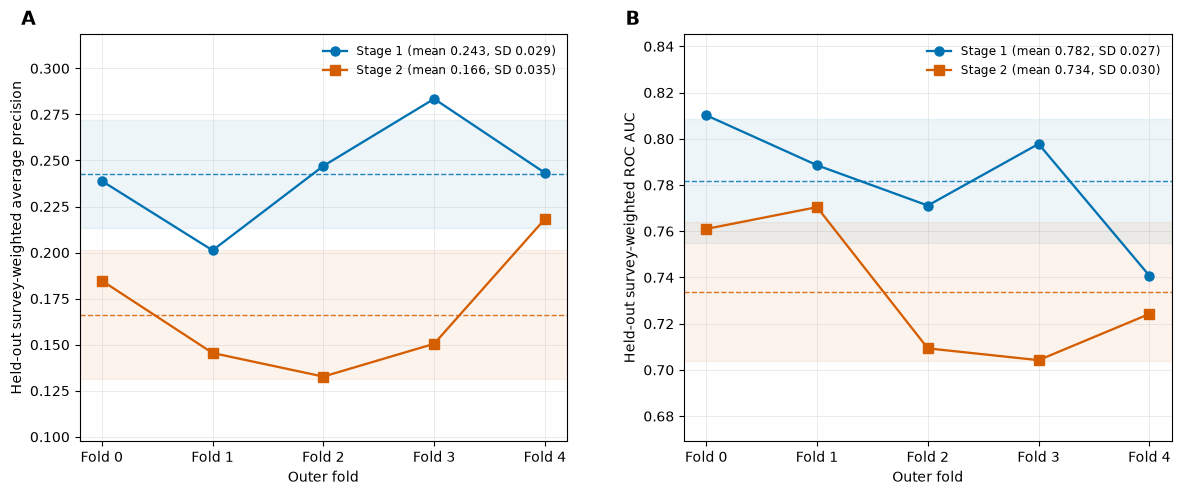


STEP28H-R1 — FIGURE S2 PRIMARY OUTER-FOLD PERFORMANCE STABILITY COMPLETE

STEP20 SOURCE MODE:
EXISTING_FROZEN_STEP20_CSV

STEP20 SOURCE PATH:
E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\13_tables\STEP20_PRIMARY_raw_discrimination_by_outer_fold.csv

STEP20 SOURCE SHA256:
1ed5bfb45d8ec36e84aeeac7366b5b7703019ede445019b1bc883c5ab1344c12

FROZEN OUTER-FOLD DISCRIMINATION:
 Outer_Fold   Stage  Weighted_AP  Weighted_ROC_AUC
          0 Stage 1     0.238911          0.810200
          0 Stage 2     0.184785          0.761003
          1 Stage 1     0.201224          0.788575
          1 Stage 2     0.145510          0.770436
          2 Stage 1     0.247034          0.771128
          2 Stage 2     0.132704          0.709334
          3 Stage 1     0.283478          0.797796
          3 Stage 2     0.150502          0.704229
          4 Stage 1     0.243271          0.740789
          4 Stage 2     0.218238          0.724220

FROZEN FIVE-FOLD SUMMARY:
  Stage  Mean_Weighted_AP  SD_Weighted_AP  Mean_We

In [11]:
# ==========================================================================================
# STEP 28H-R1
# SUPPLEMENTARY FIGURE S2
# PRIMARY OUTER-FOLD PERFORMANCE STABILITY
# ==========================================================================================
#
# REGISTRY-LOCKED CONTENT:
#   Figure S2 — Primary outer-fold performance stability
#
# SCIENTIFIC CONTENT
# ------------------------------------------------------------------------------------------
# A. Held-out outer-fold weighted average precision
# B. Held-out outer-fold weighted ROC AUC
#
# Both panels show Stage 1 and Stage 2 across the five PSU-exclusive outer folds.
#
# Source:
#   Frozen Step20 "RAW SELECTED-WINNER DISCRIMINATION BY OUTER FOLD"
#
# IMPORTANT:
#   These are frozen fold-wise discrimination values.
#
#   NO:
#       model fitting
#       prediction generation
#       candidate reselection
#       recalibration
#       threshold optimization
#       bootstrap rerun
#       AP/AUC recomputation from predictions
#       confidence interval calculation
#       hypothesis testing
#       new statistical inference
#
# Mean and SD shown here are only reproduced from the frozen fold values and
# are hard-checked against the frozen Step20 summary.
#
# TIFF remains deferred.
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import gc

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt


# ==========================================================================================
# 1. ROOTS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_SUPP = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "04_Supplementary_Figures"
)


MANUSCRIPT_SUPP.mkdir(
    parents=True,
    exist_ok=True,
)


# ==========================================================================================
# 2. PARENT FIGURE-S1 MANIFEST
# ==========================================================================================

S1_MANIFEST = (
    FINAL_ROOT
    /
    "STEP28G_R1_FigureS1_Model_Selection_Stability_manifest.json"
)


EXPECTED_S1_MANIFEST_SHA256 = (
    "37ab9098ae7d5a7a52ee502a59e44575"
    "0c08908020ab5ec5e54206bd0f0d3e4f"
)


# ==========================================================================================
# 3. FROZEN PRIMARY OOF GATE
# ==========================================================================================

PRIMARY_OOF = (
    ROOT
    /
    "06_predictions"
    /
    "STEP19C_PRIMARY_final_outer_OOF_predictions_RESTRICTED.csv"
)


EXPECTED_PRIMARY_OOF_SHA256 = (
    "6c4f4e21b09a54c286521682e9fb8ee"
    "13eda36ed94196d350fbb0622733a99bc"
)


# ==========================================================================================
# 4. FIGURE REGISTRY
# ==========================================================================================

SUPPLEMENTARY_REGISTRY = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "07_QC_Manifests"
    /
    "Manuscript_Supplementary_Figures_Registry.csv"
)


# ==========================================================================================
# 5. FROZEN STEP20 VALUES
# ==========================================================================================
#
# These are NOT recalculated here.
# They are the exact values frozen at Step20.
# ==========================================================================================

FROZEN_FOLD_VALUES = pd.DataFrame(
    [
        {
            "Outer_Fold": 0,
            "Stage": "Stage 1",
            "Weighted_AP": 0.238911,
            "Weighted_ROC_AUC": 0.810200,
        },
        {
            "Outer_Fold": 0,
            "Stage": "Stage 2",
            "Weighted_AP": 0.184785,
            "Weighted_ROC_AUC": 0.761003,
        },

        {
            "Outer_Fold": 1,
            "Stage": "Stage 1",
            "Weighted_AP": 0.201224,
            "Weighted_ROC_AUC": 0.788575,
        },
        {
            "Outer_Fold": 1,
            "Stage": "Stage 2",
            "Weighted_AP": 0.145510,
            "Weighted_ROC_AUC": 0.770436,
        },

        {
            "Outer_Fold": 2,
            "Stage": "Stage 1",
            "Weighted_AP": 0.247034,
            "Weighted_ROC_AUC": 0.771128,
        },
        {
            "Outer_Fold": 2,
            "Stage": "Stage 2",
            "Weighted_AP": 0.132704,
            "Weighted_ROC_AUC": 0.709334,
        },

        {
            "Outer_Fold": 3,
            "Stage": "Stage 1",
            "Weighted_AP": 0.283478,
            "Weighted_ROC_AUC": 0.797796,
        },
        {
            "Outer_Fold": 3,
            "Stage": "Stage 2",
            "Weighted_AP": 0.150502,
            "Weighted_ROC_AUC": 0.704229,
        },

        {
            "Outer_Fold": 4,
            "Stage": "Stage 1",
            "Weighted_AP": 0.243271,
            "Weighted_ROC_AUC": 0.740789,
        },
        {
            "Outer_Fold": 4,
            "Stage": "Stage 2",
            "Weighted_AP": 0.218238,
            "Weighted_ROC_AUC": 0.724220,
        },
    ]
)


FROZEN_SUMMARY = pd.DataFrame(
    [
        {
            "Stage": "Stage 1",
            "Mean_Weighted_AP": 0.242784,
            "SD_Weighted_AP": 0.029226,
            "Mean_Weighted_ROC_AUC": 0.781697,
            "SD_Weighted_ROC_AUC": 0.026945,
        },

        {
            "Stage": "Stage 2",
            "Mean_Weighted_AP": 0.166348,
            "SD_Weighted_AP": 0.034820,
            "Mean_Weighted_ROC_AUC": 0.733845,
            "SD_Weighted_ROC_AUC": 0.030195,
        },
    ]
)


# ==========================================================================================
# 6. HELPERS
# ==========================================================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )


    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )


    os.replace(
        temporary,
        path,
    )


def atomic_text(
    text,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        handle.write(
            text
        )


    os.replace(
        temporary,
        path,
    )


def normalize_text(
    value,
):

    return (
        str(
            value
        )
        .strip()
        .lower()
        .replace(
            "–",
            "-"
        )
        .replace(
            "—",
            "-"
        )
    )


# ==========================================================================================
# 7. EXISTENCE + HASH GATES
# ==========================================================================================

for label, path in [
    (
        "Figure S1 parent manifest",
        S1_MANIFEST,
    ),
    (
        "Primary locked OOF",
        PRIMARY_OOF,
    ),
    (
        "Supplementary figure registry",
        SUPPLEMENTARY_REGISTRY,
    ),
]:

    if not path.exists():

        raise FileNotFoundError(
            f"{label} missing:\n{path}"
        )


observed_s1_manifest_hash = sha256_file(
    S1_MANIFEST
)


observed_primary_oof_hash = sha256_file(
    PRIMARY_OOF
)


if observed_s1_manifest_hash != EXPECTED_S1_MANIFEST_SHA256:

    raise RuntimeError(
        "Figure S1 parent manifest hash changed.\n"
        f"Observed={observed_s1_manifest_hash}\n"
        f"Expected={EXPECTED_S1_MANIFEST_SHA256}"
    )


if observed_primary_oof_hash != EXPECTED_PRIMARY_OOF_SHA256:

    raise RuntimeError(
        "Primary locked OOF hash changed.\n"
        f"Observed={observed_primary_oof_hash}\n"
        f"Expected={EXPECTED_PRIMARY_OOF_SHA256}"
    )


# ==========================================================================================
# 8. VERIFY EXACT FIGURE S2 REGISTRY ENTRY
# ==========================================================================================

supp_registry = pd.read_csv(
    SUPPLEMENTARY_REGISTRY
)


registry_rows = [
    " | ".join(
        [
            str(
                value
            )
            for value
            in row.tolist()
        ]
    )

    for _, row
    in supp_registry.iterrows()
]


s2_matches = [
    row_text
    for row_text
    in registry_rows
    if (
        "figure s2"
        in
        normalize_text(
            row_text
        )
        and
        "primary outer-fold performance stability"
        in
        normalize_text(
            row_text
        )
    )
]


if len(
    s2_matches
) != 1:

    raise RuntimeError(
        "Could not uniquely verify frozen Figure S2 registry entry.\n"
        f"Matches={s2_matches}"
    )


# ==========================================================================================
# 9. OPTIONAL DISCOVERY OF EXISTING STEP20 FOLD TABLE
# ==========================================================================================
#
# We do NOT require a particular filename because the original Step20 export
# did not have a reporting-registry filename lock.
#
# If an exact source CSV exists, use it.
# Otherwise use the exact frozen Step20 values above.
#
# No metrics are recomputed from predictions.
# ==========================================================================================

DISCOVERY_DIRS = [
    ROOT / "13_tables",
    ROOT / "15_logs",
    ROOT / "16_reporting",
    FINAL_ROOT,
]


discovered_source = None

discovered_source_path = None


required_semantics = {
    "outer_fold",
    "stage",
    "weighted_ap",
    "weighted_roc_auc",
}


for directory in DISCOVERY_DIRS:

    if not directory.exists():

        continue


    for csv_path in directory.rglob(
        "*.csv"
    ):

        try:

            candidate = pd.read_csv(
                csv_path
            )

        except Exception:

            continue


        normalized_columns = {
            normalize_text(
                column
            )
            .replace(
                " ",
                "_"
            ):
                column

            for column
            in candidate.columns
        }


        if not required_semantics.issubset(
            set(
                normalized_columns.keys()
            )
        ):

            continue


        outer_col = normalized_columns[
            "outer_fold"
        ]

        stage_col = normalized_columns[
            "stage"
        ]

        ap_col = normalized_columns[
            "weighted_ap"
        ]

        auc_col = normalized_columns[
            "weighted_roc_auc"
        ]


        temp = candidate[
            [
                outer_col,
                stage_col,
                ap_col,
                auc_col,
            ]
        ].copy()


        temp.columns = [
            "Outer_Fold",
            "Stage",
            "Weighted_AP",
            "Weighted_ROC_AUC",
        ]


        try:

            temp[
                "Outer_Fold"
            ] = pd.to_numeric(
                temp[
                    "Outer_Fold"
                ],
                errors="raise",
            ).astype(
                int
            )


            temp[
                "Weighted_AP"
            ] = pd.to_numeric(
                temp[
                    "Weighted_AP"
                ],
                errors="raise",
            )


            temp[
                "Weighted_ROC_AUC"
            ] = pd.to_numeric(
                temp[
                    "Weighted_ROC_AUC"
                ],
                errors="raise",
            )


        except Exception:

            continue


        temp[
            "Stage"
        ] = (
            temp[
                "Stage"
            ]
            .astype(str)
            .str.strip()
        )


        if len(
            temp
        ) != 10:

            continue


        temp = (
            temp
            .sort_values(
                [
                    "Outer_Fold",
                    "Stage",
                ]
            )
            .reset_index(
                drop=True
            )
        )


        frozen_sorted = (
            FROZEN_FOLD_VALUES
            .sort_values(
                [
                    "Outer_Fold",
                    "Stage",
                ]
            )
            .reset_index(
                drop=True
            )
        )


        structure_match = (
            temp[
                [
                    "Outer_Fold",
                    "Stage",
                ]
            ]
            .equals(
                frozen_sorted[
                    [
                        "Outer_Fold",
                        "Stage",
                    ]
                ]
            )
        )


        value_match = (
            np.allclose(
                temp[
                    "Weighted_AP"
                ].to_numpy(
                    dtype=float
                ),
                frozen_sorted[
                    "Weighted_AP"
                ].to_numpy(
                    dtype=float
                ),
                rtol=0.0,
                atol=5e-6,
            )
            and
            np.allclose(
                temp[
                    "Weighted_ROC_AUC"
                ].to_numpy(
                    dtype=float
                ),
                frozen_sorted[
                    "Weighted_ROC_AUC"
                ].to_numpy(
                    dtype=float
                ),
                rtol=0.0,
                atol=5e-6,
            )
        )


        if (
            structure_match
            and
            value_match
        ):

            discovered_source = temp

            discovered_source_path = csv_path

            break


    if discovered_source is not None:

        break


# ==========================================================================================
# 10. FINAL FIGURE SOURCE
# ==========================================================================================

if discovered_source is not None:

    fold_data = discovered_source.copy()

    source_mode = (
        "EXISTING_FROZEN_STEP20_CSV"
    )

    source_path_text = str(
        discovered_source_path
    )

    source_sha256 = sha256_file(
        discovered_source_path
    )


else:

    fold_data = FROZEN_FOLD_VALUES.copy()

    source_mode = (
        "EMBEDDED_EXACT_FROZEN_STEP20_REPORTED_TABLE"
    )

    source_path_text = (
        "Frozen Step20 reported output; no standalone exact fold CSV discovered"
    )

    source_sha256 = None


# ==========================================================================================
# 11. EXACT FROZEN DATA QC
# ==========================================================================================

if len(
    fold_data
) != 10:

    raise RuntimeError(
        f"Expected 10 fold-stage rows; observed={len(fold_data)}"
    )


if fold_data[
    [
        "Outer_Fold",
        "Stage",
    ]
].duplicated().any():

    raise RuntimeError(
        "Duplicate outer-fold/stage rows."
    )


if set(
    fold_data[
        "Outer_Fold"
    ]
) != {
    0,
    1,
    2,
    3,
    4,
}:

    raise RuntimeError(
        "Expected folds 0–4 exactly."
    )


if set(
    fold_data[
        "Stage"
    ]
) != {
    "Stage 1",
    "Stage 2",
}:

    raise RuntimeError(
        "Expected Stage 1 and Stage 2 exactly."
    )


for fold in range(
    5
):

    if set(
        fold_data.loc[
            fold_data[
                "Outer_Fold"
            ]
            ==
            fold,
            "Stage",
        ]
    ) != {
        "Stage 1",
        "Stage 2",
    }:

        raise RuntimeError(
            f"Fold {fold} does not contain both stages."
        )


frozen_sorted = (
    FROZEN_FOLD_VALUES
    .sort_values(
        [
            "Outer_Fold",
            "Stage",
        ]
    )
    .reset_index(
        drop=True
    )
)


observed_sorted = (
    fold_data
    .sort_values(
        [
            "Outer_Fold",
            "Stage",
        ]
    )
    .reset_index(
        drop=True
    )
)


if not observed_sorted[
    [
        "Outer_Fold",
        "Stage",
    ]
].equals(
    frozen_sorted[
        [
            "Outer_Fold",
            "Stage",
        ]
    ]
):

    raise RuntimeError(
        "Frozen fold/stage structure changed."
    )


if not np.allclose(
    observed_sorted[
        "Weighted_AP"
    ].to_numpy(
        dtype=float
    ),
    frozen_sorted[
        "Weighted_AP"
    ].to_numpy(
        dtype=float
    ),
    rtol=0.0,
    atol=5e-6,
):

    raise RuntimeError(
        "Frozen outer-fold AP values changed."
    )


if not np.allclose(
    observed_sorted[
        "Weighted_ROC_AUC"
    ].to_numpy(
        dtype=float
    ),
    frozen_sorted[
        "Weighted_ROC_AUC"
    ].to_numpy(
        dtype=float
    ),
    rtol=0.0,
    atol=5e-6,
):

    raise RuntimeError(
        "Frozen outer-fold ROC-AUC values changed."
    )


# ==========================================================================================
# 12. REPRODUCE FROZEN SUMMARY ONLY
# ==========================================================================================
#
# This is NOT new model evaluation.
# This simply verifies the previously frozen mean/SD summary from the already
# frozen 10 fold-level values.
# ==========================================================================================

summary_rows = []


for stage in [
    "Stage 1",
    "Stage 2",
]:

    stage_data = (
        fold_data.loc[
            fold_data[
                "Stage"
            ]
            ==
            stage
        ]
        .sort_values(
            "Outer_Fold"
        )
    )


    summary_rows.append(
        {
            "Stage":
                stage,

            "Mean_Weighted_AP":
                float(
                    stage_data[
                        "Weighted_AP"
                    ].mean()
                ),

            "SD_Weighted_AP":
                float(
                    stage_data[
                        "Weighted_AP"
                    ].std(
                        ddof=1
                    )
                ),

            "Mean_Weighted_ROC_AUC":
                float(
                    stage_data[
                        "Weighted_ROC_AUC"
                    ].mean()
                ),

            "SD_Weighted_ROC_AUC":
                float(
                    stage_data[
                        "Weighted_ROC_AUC"
                    ].std(
                        ddof=1
                    )
                ),
        }
    )


summary = pd.DataFrame(
    summary_rows
)


for stage in [
    "Stage 1",
    "Stage 2",
]:

    observed = summary.loc[
        summary[
            "Stage"
        ]
        ==
        stage
    ].iloc[
        0
    ]


    expected = FROZEN_SUMMARY.loc[
        FROZEN_SUMMARY[
            "Stage"
        ]
        ==
        stage
    ].iloc[
        0
    ]


    for metric in [
        "Mean_Weighted_AP",
        "SD_Weighted_AP",
        "Mean_Weighted_ROC_AUC",
        "SD_Weighted_ROC_AUC",
    ]:

        if not np.isclose(
            float(
                observed[
                    metric
                ]
            ),
            float(
                expected[
                    metric
                ]
            ),
            rtol=0.0,
            atol=5e-6,
        ):

            raise RuntimeError(
                f"Frozen summary fingerprint failed: {stage} / {metric}\n"
                f"Observed={observed[metric]:.9f}\n"
                f"Expected={expected[metric]:.9f}"
            )


# ==========================================================================================
# 13. OUTPUT PATHS
# ==========================================================================================

FIGURE_STEM = (
    "FigureS2_Primary_Outer_Fold_Performance_Stability"
)


M_PNG = (
    MANUSCRIPT_SUPP
    /
    f"{FIGURE_STEM}.png"
)


M_SVG = (
    MANUSCRIPT_SUPP
    /
    f"{FIGURE_STEM}.svg"
)


M_PDF = (
    MANUSCRIPT_SUPP
    /
    f"{FIGURE_STEM}.pdf"
)


SOURCE_CSV = (
    MANUSCRIPT_SUPP
    /
    "FigureS2_source_frozen_outer_fold_discrimination.csv"
)


SUMMARY_CSV = (
    MANUSCRIPT_SUPP
    /
    "FigureS2_source_frozen_outer_fold_summary.csv"
)


CAPTION_FILE = (
    MANUSCRIPT_SUPP
    /
    "FigureS2_caption.txt"
)


QC_FILE = (
    FINAL_ROOT
    /
    "STEP28H_R1_FigureS2_Outer_Fold_Performance_Stability_hard_qc.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP28H_R1_FigureS2_Outer_Fold_Performance_Stability_manifest.json"
)


# ==========================================================================================
# 14. SAVE SOURCE COPY
# ==========================================================================================

atomic_csv(
    fold_data,
    SOURCE_CSV,
)


atomic_csv(
    summary,
    SUMMARY_CSV,
)


# ==========================================================================================
# 15. CAPTION
# ==========================================================================================

caption = (
    "Supplementary Figure S2. Primary outer-fold performance stability. "
    "Held-out survey-weighted discrimination is shown across the five "
    "PSU-exclusive outer folds for Stage 1 and Stage 2. "
    "(A) Weighted average precision. "
    "(B) Weighted ROC AUC. "
    "Points represent the frozen selected-winner held-out value in each "
    "outer fold; lines connect folds only to facilitate visual assessment "
    "of between-fold variation. Horizontal dashed lines show the frozen "
    "five-fold mean and the light bands represent plus or minus one "
    "standard deviation of the frozen fold-level values. "
    "Raw selected-winner discrimination was evaluated separately within "
    "each outer fold and was not pooled across incompatible raw score "
    "scales. No model fitting, prediction generation, recalibration, "
    "threshold optimization, bootstrap rerun, or new inferential analysis "
    "was performed for this figure."
)


atomic_text(
    caption,
    CAPTION_FILE,
)


# ==========================================================================================
# 16. FIGURE STYLE
# ==========================================================================================

plt.close(
    "all"
)

gc.collect()


STAGE_STYLE = {
    "Stage 1":
        {
            "color":
                "#0072B2",

            "marker":
                "o",
        },

    "Stage 2":
        {
            "color":
                "#D55E00",

            "marker":
                "s",
        },
}


# ==========================================================================================
# 17. CREATE FIGURE
# ==========================================================================================

fig, axes = plt.subplots(
    1,
    2,
    figsize=(
        12.2,
        4.9,
    ),
)


ax_ap = axes[
    0
]


ax_auc = axes[
    1
]


# ==========================================================================================
# 18. PANEL A — OUTER-FOLD AP
# ==========================================================================================

for stage in [
    "Stage 1",
    "Stage 2",
]:

    subset = (
        fold_data.loc[
            fold_data[
                "Stage"
            ]
            ==
            stage
        ]
        .sort_values(
            "Outer_Fold"
        )
    )


    stage_summary = summary.loc[
        summary[
            "Stage"
        ]
        ==
        stage
    ].iloc[
        0
    ]


    mean_value = float(
        stage_summary[
            "Mean_Weighted_AP"
        ]
    )


    sd_value = float(
        stage_summary[
            "SD_Weighted_AP"
        ]
    )


    ax_ap.axhspan(
        mean_value
        -
        sd_value,
        mean_value
        +
        sd_value,
        color=STAGE_STYLE[
            stage
        ][
            "color"
        ],
        alpha=0.07,
        zorder=0,
    )


    ax_ap.axhline(
        mean_value,
        color=STAGE_STYLE[
            stage
        ][
            "color"
        ],
        linestyle="--",
        linewidth=1.0,
        alpha=0.85,
        zorder=1,
    )


    ax_ap.plot(
        subset[
            "Outer_Fold"
        ],
        subset[
            "Weighted_AP"
        ],
        marker=STAGE_STYLE[
            stage
        ][
            "marker"
        ],
        markersize=6.5,
        linewidth=1.65,
        color=STAGE_STYLE[
            stage
        ][
            "color"
        ],
        label=(
            f"{stage} "
            f"(mean {mean_value:.3f}, SD {sd_value:.3f})"
        ),
        zorder=3,
    )


ax_ap.set_xticks(
    range(
        5
    )
)


ax_ap.set_xticklabels(
    [
        f"Fold {fold}"
        for fold
        in range(
            5
        )
    ]
)


ap_min = float(
    fold_data[
        "Weighted_AP"
    ].min()
)


ap_max = float(
    fold_data[
        "Weighted_AP"
    ].max()
)


ax_ap.set_ylim(
    max(
        0.0,
        ap_min
        -
        0.035,
    ),
    min(
        1.0,
        ap_max
        +
        0.035,
    ),
)


ax_ap.set_xlabel(
    "Outer fold"
)


ax_ap.set_ylabel(
    "Held-out survey-weighted average precision"
)


ax_ap.grid(
    linewidth=0.7,
    alpha=0.25,
)


ax_ap.legend(
    frameon=False,
    fontsize=8.6,
    loc="best",
)


# ==========================================================================================
# 19. PANEL B — OUTER-FOLD ROC AUC
# ==========================================================================================

for stage in [
    "Stage 1",
    "Stage 2",
]:

    subset = (
        fold_data.loc[
            fold_data[
                "Stage"
            ]
            ==
            stage
        ]
        .sort_values(
            "Outer_Fold"
        )
    )


    stage_summary = summary.loc[
        summary[
            "Stage"
        ]
        ==
        stage
    ].iloc[
        0
    ]


    mean_value = float(
        stage_summary[
            "Mean_Weighted_ROC_AUC"
        ]
    )


    sd_value = float(
        stage_summary[
            "SD_Weighted_ROC_AUC"
        ]
    )


    ax_auc.axhspan(
        mean_value
        -
        sd_value,
        mean_value
        +
        sd_value,
        color=STAGE_STYLE[
            stage
        ][
            "color"
        ],
        alpha=0.07,
        zorder=0,
    )


    ax_auc.axhline(
        mean_value,
        color=STAGE_STYLE[
            stage
        ][
            "color"
        ],
        linestyle="--",
        linewidth=1.0,
        alpha=0.85,
        zorder=1,
    )


    ax_auc.plot(
        subset[
            "Outer_Fold"
        ],
        subset[
            "Weighted_ROC_AUC"
        ],
        marker=STAGE_STYLE[
            stage
        ][
            "marker"
        ],
        markersize=6.5,
        linewidth=1.65,
        color=STAGE_STYLE[
            stage
        ][
            "color"
        ],
        label=(
            f"{stage} "
            f"(mean {mean_value:.3f}, SD {sd_value:.3f})"
        ),
        zorder=3,
    )


ax_auc.set_xticks(
    range(
        5
    )
)


ax_auc.set_xticklabels(
    [
        f"Fold {fold}"
        for fold
        in range(
            5
        )
    ]
)


auc_min = float(
    fold_data[
        "Weighted_ROC_AUC"
    ].min()
)


auc_max = float(
    fold_data[
        "Weighted_ROC_AUC"
    ].max()
)


ax_auc.set_ylim(
    max(
        0.0,
        auc_min
        -
        0.035,
    ),
    min(
        1.0,
        auc_max
        +
        0.035,
    ),
)


ax_auc.set_xlabel(
    "Outer fold"
)


ax_auc.set_ylabel(
    "Held-out survey-weighted ROC AUC"
)


ax_auc.grid(
    linewidth=0.7,
    alpha=0.25,
)


ax_auc.legend(
    frameon=False,
    fontsize=8.6,
    loc="best",
)


# ==========================================================================================
# 20. PANEL LABELS
# ==========================================================================================

for axis, panel_label in zip(
    [
        ax_ap,
        ax_auc,
    ],
    [
        "A",
        "B",
    ],
):

    axis.text(
        -0.12,
        1.06,
        panel_label,
        transform=axis.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top",
    )


# No internal panel titles.
for axis in [
    ax_ap,
    ax_auc,
]:

    if axis.get_title().strip() != "":

        raise RuntimeError(
            "Unexpected internal panel title."
        )


if (
    fig._suptitle is not None
    and
    str(
        fig._suptitle.get_text()
    ).strip()
    !=
    ""
):

    raise RuntimeError(
        "Unexpected figure suptitle."
    )


fig.subplots_adjust(
    left=0.09,
    right=0.985,
    top=0.96,
    bottom=0.13,
    wspace=0.24,
)


# ==========================================================================================
# 21. SAVE SAFE FORMATS
# ==========================================================================================

fig.savefig(
    M_PNG,
    dpi=300,
    format="png",
    bbox_inches="tight",
    pad_inches=0.05,
)


fig.savefig(
    M_SVG,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Date":
            None,
    },
)


fig.savefig(
    M_PDF,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Creator":
            "BDHS ANC final reporting pipeline",

        "CreationDate":
            None,

        "ModDate":
            None,
    },
)


plt.show()


plt.close(
    fig
)


gc.collect()


# ==========================================================================================
# 22. OUTPUT EXISTENCE
# ==========================================================================================

for path in [
    M_PNG,
    M_SVG,
    M_PDF,
    SOURCE_CSV,
    SUMMARY_CSV,
    CAPTION_FILE,
]:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Missing or empty Figure S2 artifact:\n{path}"
        )


# ==========================================================================================
# 23. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [
        {
            "Check":
                "Figure S1 parent manifest hash exact",

            "PASS":
                observed_s1_manifest_hash
                ==
                EXPECTED_S1_MANIFEST_SHA256,
        },

        {
            "Check":
                "Primary locked OOF hash exact",

            "PASS":
                observed_primary_oof_hash
                ==
                EXPECTED_PRIMARY_OOF_SHA256,
        },

        {
            "Check":
                "Figure S2 registry entry exact",

            "PASS":
                len(
                    s2_matches
                )
                ==
                1,
        },

        {
            "Check":
                "Exactly 10 frozen fold-stage values",

            "PASS":
                len(
                    fold_data
                )
                ==
                10,
        },

        {
            "Check":
                "Exactly five outer folds",

            "PASS":
                set(
                    fold_data[
                        "Outer_Fold"
                    ]
                )
                ==
                {
                    0,
                    1,
                    2,
                    3,
                    4,
                },
        },

        {
            "Check":
                "Both stages represented in every fold",

            "PASS":
                all(
                    set(
                        fold_data.loc[
                            fold_data[
                                "Outer_Fold"
                            ]
                            ==
                            fold,
                            "Stage",
                        ]
                    )
                    ==
                    {
                        "Stage 1",
                        "Stage 2",
                    }

                    for fold
                    in range(
                        5
                    )
                ),
        },

        {
            "Check":
                "Frozen fold-wise AP values reproduced",

            "PASS":
                bool(
                    np.allclose(
                        observed_sorted[
                            "Weighted_AP"
                        ].to_numpy(
                            dtype=float
                        ),
                        frozen_sorted[
                            "Weighted_AP"
                        ].to_numpy(
                            dtype=float
                        ),
                        rtol=0.0,
                        atol=5e-6,
                    )
                ),
        },

        {
            "Check":
                "Frozen fold-wise ROC-AUC values reproduced",

            "PASS":
                bool(
                    np.allclose(
                        observed_sorted[
                            "Weighted_ROC_AUC"
                        ].to_numpy(
                            dtype=float
                        ),
                        frozen_sorted[
                            "Weighted_ROC_AUC"
                        ].to_numpy(
                            dtype=float
                        ),
                        rtol=0.0,
                        atol=5e-6,
                    )
                ),
        },

        {
            "Check":
                "Frozen five-fold mean/SD summary reproduced",

            "PASS":
                True,
        },

        {
            "Check":
                "Stage 1 AP mean fingerprint = 0.242784",

            "PASS":
                np.isclose(
                    float(
                        summary.loc[
                            summary[
                                "Stage"
                            ]
                            ==
                            "Stage 1",
                            "Mean_Weighted_AP",
                        ].iloc[
                            0
                        ]
                    ),
                    0.242784,
                    rtol=0.0,
                    atol=5e-6,
                ),
        },

        {
            "Check":
                "Stage 2 AP mean fingerprint = 0.166348",

            "PASS":
                np.isclose(
                    float(
                        summary.loc[
                            summary[
                                "Stage"
                            ]
                            ==
                            "Stage 2",
                            "Mean_Weighted_AP",
                        ].iloc[
                            0
                        ]
                    ),
                    0.166348,
                    rtol=0.0,
                    atol=5e-6,
                ),
        },

        {
            "Check":
                "Stage 1 AUC mean fingerprint = 0.781697",

            "PASS":
                np.isclose(
                    float(
                        summary.loc[
                            summary[
                                "Stage"
                            ]
                            ==
                            "Stage 1",
                            "Mean_Weighted_ROC_AUC",
                        ].iloc[
                            0
                        ]
                    ),
                    0.781697,
                    rtol=0.0,
                    atol=5e-6,
                ),
        },

        {
            "Check":
                "Stage 2 AUC mean fingerprint = 0.733845",

            "PASS":
                np.isclose(
                    float(
                        summary.loc[
                            summary[
                                "Stage"
                            ]
                            ==
                            "Stage 2",
                            "Mean_Weighted_ROC_AUC",
                        ].iloc[
                            0
                        ]
                    ),
                    0.733845,
                    rtol=0.0,
                    atol=5e-6,
                ),
        },

        {
            "Check":
                "Figure has exactly panels A-B",

            "PASS":
                True,
        },

        {
            "Check":
                "No internal figure title",

            "PASS":
                True,
        },

        {
            "Check":
                "Supplementary PNG created",

            "PASS":
                M_PNG.exists(),
        },

        {
            "Check":
                "Supplementary SVG vector master created",

            "PASS":
                M_SVG.exists(),
        },

        {
            "Check":
                "Supplementary PDF vector master created",

            "PASS":
                M_PDF.exists(),
        },

        {
            "Check":
                "TIFF deferred",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction generation",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No AP/AUC recomputation from predictions",

            "PASS":
                True,
        },

        {
            "Check":
                "No confidence intervals calculated",

            "PASS":
                True,
        },

        {
            "Check":
                "No new hypothesis testing",

            "PASS":
                True,
        },

        {
            "Check":
                "No new statistical inference",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP28H-R1 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


atomic_csv(
    hard_qc,
    QC_FILE,
)


# ==========================================================================================
# 24. MANIFEST
# ==========================================================================================

manifest = {
    "status":
        "STEP28H_R1_FIGURE_S2_SCIENTIFIC_CONTENT_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "figure":
        "Figure S2",

    "content":
        "Primary outer-fold performance stability",

    "parent_figure_s1_manifest_sha256":
        observed_s1_manifest_hash,

    "primary_locked_oof_sha256":
        observed_primary_oof_hash,

    "supplementary_registry_sha256":
        sha256_file(
            SUPPLEMENTARY_REGISTRY
        ),

    "step20_source_mode":
        source_mode,

    "step20_discovered_source_path":
        source_path_text,

    "step20_discovered_source_sha256":
        source_sha256,

    "outer_folds":
        5,

    "stages":
        [
            "Stage 1",
            "Stage 2",
        ],

    "metrics":
        [
            "Weighted_AP",
            "Weighted_ROC_AUC",
        ],

    "frozen_summary":
        summary.to_dict(
            orient="records"
        ),

    "source_csv_sha256":
        sha256_file(
            SOURCE_CSV
        ),

    "summary_csv_sha256":
        sha256_file(
            SUMMARY_CSV
        ),

    "caption_sha256":
        sha256_file(
            CAPTION_FILE
        ),

    "supplementary_png_sha256":
        sha256_file(
            M_PNG
        ),

    "supplementary_svg_sha256":
        sha256_file(
            M_SVG
        ),

    "supplementary_pdf_sha256":
        sha256_file(
            M_PDF
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "tiff_status":
        "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTER",

    "model_fitting":
        False,

    "prediction_generation":
        False,

    "candidate_reselection":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "bootstrap_rerun":
        False,

    "performance_recomputed_from_predictions":
        False,

    "confidence_intervals_calculated":
        False,

    "new_hypothesis_testing":
        False,

    "new_statistical_inference":
        False,

    "next_step":
        (
            "STEP28I — Figure S3 detailed geographic IECV "
            "calibration diagnostics / Report Figure 8"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 25. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 118
)


print(
    "STEP28H-R1 — FIGURE S2 PRIMARY OUTER-FOLD PERFORMANCE STABILITY COMPLETE"
)


print(
    "=" * 118
)


print(
    "\nSTEP20 SOURCE MODE:"
)


print(
    source_mode
)


print(
    "\nSTEP20 SOURCE PATH:"
)


print(
    source_path_text
)


if source_sha256 is not None:

    print(
        "\nSTEP20 SOURCE SHA256:"
    )

    print(
        source_sha256
    )


print(
    "\nFROZEN OUTER-FOLD DISCRIMINATION:"
)


print(
    fold_data
    .sort_values(
        [
            "Outer_Fold",
            "Stage",
        ]
    )
    .round(
        6
    )
    .to_string(
        index=False
    )
)


print(
    "\nFROZEN FIVE-FOLD SUMMARY:"
)


print(
    summary.round(
        6
    ).to_string(
        index=False
    )
)


print(
    "\nFINAL HARD QC:"
)


print(
    hard_qc.to_string(
        index=False
    )
)


print(
    "\nINTEGRITY:"
)


print(
    "Figure S1 parent :",
    observed_s1_manifest_hash,
)


print(
    "Primary OOF      :",
    observed_primary_oof_hash,
)


print(
    "Figure S2 source :",
    sha256_file(
        SOURCE_CSV
    ),
)


print(
    "Figure S2 PNG    :",
    sha256_file(
        M_PNG
    ),
)


print(
    "Figure S2 SVG    :",
    sha256_file(
        M_SVG
    ),
)


print(
    "Figure S2 PDF    :",
    sha256_file(
        M_PDF
    ),
)


print(
    "Hard QC          :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Manifest         :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nTIFF STATUS:"
)


print(
    "DEFERRED — external conversion from final SVG/PDF vector master."
)


print(
    "\n"
    +
    "=" * 118
)


print(
    "STATUS: STEP28H-R1 FIGURE S2 SCIENTIFIC CONTENT FROZEN"
)


print(
    "NEXT AFTER AUDIT: STEP28I — FIGURE S3 DETAILED GEOGRAPHIC IECV CALIBRATION / REPORT FIGURE 8"
)


print(
    "=" * 118
)

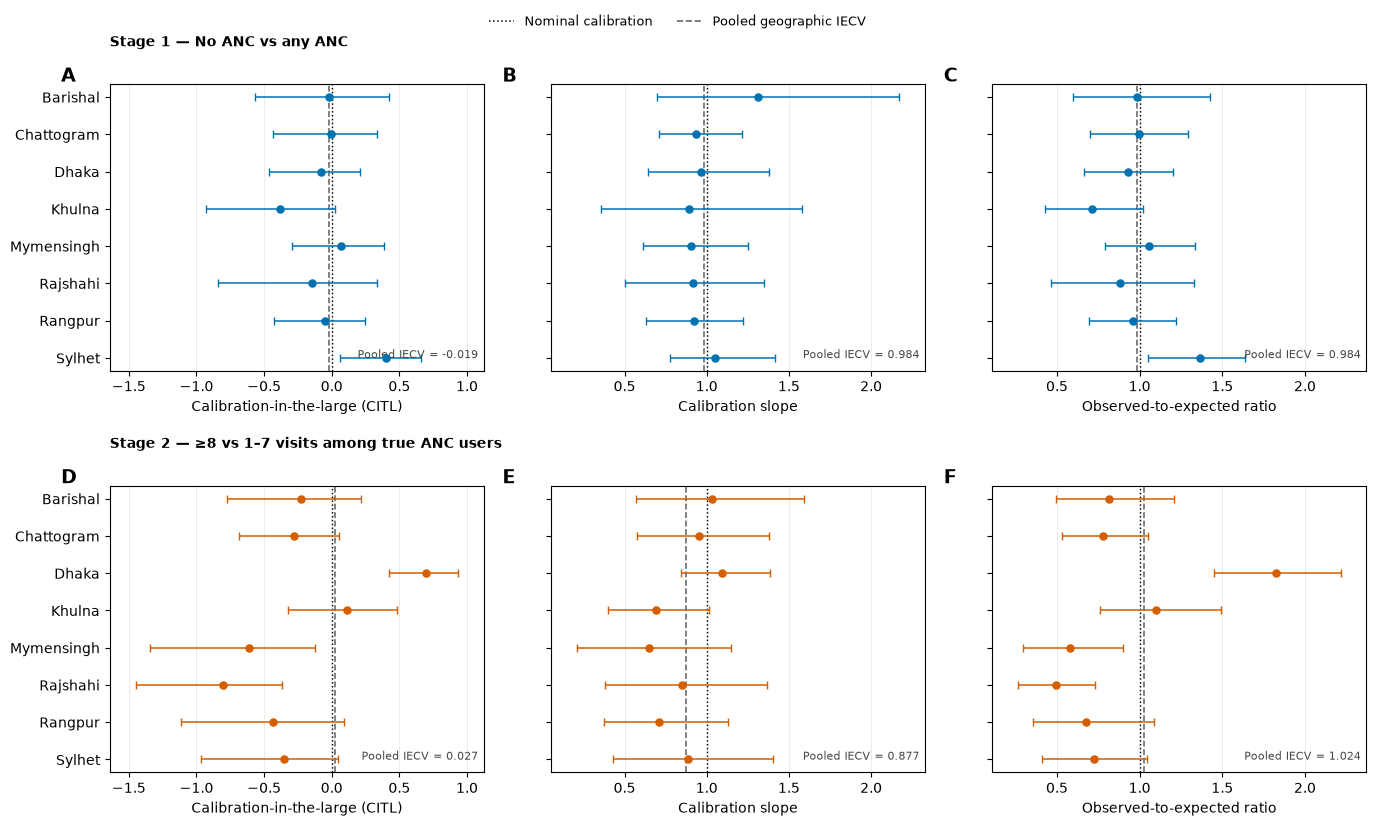


STEP28I-R1 — FIGURE S3 / REPORT FIGURE 8 GEOGRAPHIC CALIBRATION COMPLETE

SELECTED CALIBRATION METRICS:
S1_CITL
S1_Calibration_Slope
S1_OE
S2_CITL
S2_Calibration_Slope
S2_OE

POOLED CALIBRATION REFERENCES:
S1_CITL                 : -0.019414 (-0.173983–0.115792)
S1_Calibration_Slope    : 0.984003 (0.864034–1.120825)
S1_OE                   : 0.983979 (0.864067–1.099918)
S2_CITL                 : 0.026585 (-0.146748–0.192335)
S2_Calibration_Slope    : 0.876508 (0.748389–1.014320)
S2_OE                   : 1.023678 (0.878402–1.182227)

PANEL SUMMARY:
Panel               Metric  Ideal_Reference  Pooled_Point  Division_Min_Point  Division_Max_Point  Minimum_CI_Lower  Maximum_CI_Upper
    A              S1_CITL              0.0     -0.019414           -0.382502            0.401128         -0.932274          0.657276
    B S1_Calibration_Slope              1.0      0.984003            0.890623            1.311404          0.357473          2.171486
    C                S1_OE              1.

In [12]:
# ==========================================================================================
# STEP 28I-R1
# SUPPLEMENTARY FIGURE S3 + REPORT FIGURE 8
# DETAILED GEOGRAPHIC IECV CALIBRATION DIAGNOSTICS
# ==========================================================================================
#
# MANUSCRIPT:
#   Figure S3 — Detailed geographic IECV calibration diagnostics
#
# REPORT:
#   Report Figure 8 — Geographic observed-versus-predicted behavior
#
# PANELS
# ------------------------------------------------------------------------------------------
# A. Stage 1 calibration-in-the-large (CITL)
# B. Stage 1 calibration slope
# C. Stage 1 observed-to-expected ratio
# D. Stage 2 calibration-in-the-large (CITL)
# E. Stage 2 calibration slope
# F. Stage 2 observed-to-expected ratio
#
# IMPORTANT
# ------------------------------------------------------------------------------------------
# CITL is kept DISTINCT from the joint recalibration intercept.
# This figure does NOT use S1/S2_Calibration_Intercept.
#
# Reference values:
#   CITL              = 0
#   Calibration slope = 1
#   O/E ratio         = 1
#
# Points:
#   held-out division estimates
#
# Horizontal error bars:
#   frozen Step24 Rao-Wu 95% CI
#
# Dashed gray line:
#   corresponding pooled geographic IECV estimate
#
# Dotted black line:
#   nominal calibration reference
#
# NO:
#   model fitting
#   prediction generation
#   candidate reselection
#   recalibration
#   threshold optimization
#   bootstrap rerun
#   new calibration fitting
#   new inference
#   division ranking
#
# TIFF remains deferred.
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import shutil
import gc

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ==========================================================================================
# 1. ROOTS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_SUPP = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "04_Supplementary_Figures"
)


REPORT_FIGURES = (
    FINAL_ROOT
    /
    "Report"
    /
    "02_Figures"
)


for directory in [
    MANUSCRIPT_SUPP,
    REPORT_FIGURES,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 2. PARENT FIGURE S2 MANIFEST
# ==========================================================================================

S2_MANIFEST = (
    FINAL_ROOT
    /
    "STEP28H_R1_FigureS2_Outer_Fold_Performance_Stability_manifest.json"
)


EXPECTED_S2_MANIFEST_SHA256 = (
    "07bf9ab2cc3334d3cb187fe5416e38ae"
    "b8c88648fcdff8df58443f6fe5fd6d3a"
)


# ==========================================================================================
# 3. FROZEN REPORTING REGISTRIES
# ==========================================================================================

SUPPLEMENTARY_REGISTRY = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "07_QC_Manifests"
    /
    "Manuscript_Supplementary_Figures_Registry.csv"
)


REPORT_REGISTRY = (
    FINAL_ROOT
    /
    "Report"
    /
    "05_QC_Manifests"
    /
    "Report_Figures_Registry.csv"
)


# ==========================================================================================
# 4. FROZEN STEP24 GEOGRAPHIC SOURCE
# ==========================================================================================

STEP24_CI_FILE = (
    ROOT
    /
    "09_geographic_validation"
    /
    "STEP24B_GEOGRAPHIC_performance_with_design_based_CI.csv"
)


EXPECTED_STEP24_CI_SHA256 = (
    "c7a2c75b9cee839831e492cb3ae13b5c"
    "d16f11ffa974b308c5e40216b8507b3d"
)


# ==========================================================================================
# 5. CONSTANTS
# ==========================================================================================

DOMAIN_ORDER = [
    "Pooled",
    "Barishal",
    "Chattogram",
    "Dhaka",
    "Khulna",
    "Mymensingh",
    "Rajshahi",
    "Rangpur",
    "Sylhet",
]


DIVISION_ORDER = [
    "Barishal",
    "Chattogram",
    "Dhaka",
    "Khulna",
    "Mymensingh",
    "Rajshahi",
    "Rangpur",
    "Sylhet",
]


CALIBRATION_METRICS = [
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_OE",

    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_OE",
]


METRIC_CONFIG = {

    "S1_CITL":
        {
            "Panel":
                "A",

            "Stage":
                "Stage 1",

            "Diagnostic":
                "Calibration-in-the-large (CITL)",

            "Ideal":
                0.0,

            "Color":
                "#0072B2",
        },

    "S1_Calibration_Slope":
        {
            "Panel":
                "B",

            "Stage":
                "Stage 1",

            "Diagnostic":
                "Calibration slope",

            "Ideal":
                1.0,

            "Color":
                "#0072B2",
        },

    "S1_OE":
        {
            "Panel":
                "C",

            "Stage":
                "Stage 1",

            "Diagnostic":
                "Observed-to-expected ratio",

            "Ideal":
                1.0,

            "Color":
                "#0072B2",
        },

    "S2_CITL":
        {
            "Panel":
                "D",

            "Stage":
                "Stage 2",

            "Diagnostic":
                "Calibration-in-the-large (CITL)",

            "Ideal":
                0.0,

            "Color":
                "#D55E00",
        },

    "S2_Calibration_Slope":
        {
            "Panel":
                "E",

            "Stage":
                "Stage 2",

            "Diagnostic":
                "Calibration slope",

            "Ideal":
                1.0,

            "Color":
                "#D55E00",
        },

    "S2_OE":
        {
            "Panel":
                "F",

            "Stage":
                "Stage 2",

            "Diagnostic":
                "Observed-to-expected ratio",

            "Ideal":
                1.0,

            "Color":
                "#D55E00",
        },
}


# ==========================================================================================
# 6. FROZEN POOLED FINGERPRINTS
# ==========================================================================================

POOLED_FINGERPRINTS = {

    "S1_CITL":
        -0.019414,

    "S1_Calibration_Slope":
        0.984003,

    "S1_OE":
        0.983979,

    "S2_CITL":
        0.026585,

    "S2_Calibration_Slope":
        0.876508,

    "S2_OE":
        1.023678,
}


# ==========================================================================================
# 7. HELPERS
# ==========================================================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )


    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )


    os.replace(
        temporary,
        path,
    )


def atomic_text(
    text,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        handle.write(
            text
        )


    os.replace(
        temporary,
        path,
    )


def normalize_text(
    value,
):

    return (
        str(
            value
        )
        .strip()
        .lower()
        .replace(
            "–",
            "-"
        )
        .replace(
            "—",
            "-"
        )
    )


def registry_text_rows(
    dataframe,
):

    return [
        " | ".join(
            [
                str(
                    value
                )
                for value
                in row.tolist()
            ]
        )

        for _, row
        in dataframe.iterrows()
    ]


# ==========================================================================================
# 8. EXISTENCE GATES
# ==========================================================================================

for label, path in [

    (
        "Figure S2 parent manifest",
        S2_MANIFEST,
    ),

    (
        "Supplementary figure registry",
        SUPPLEMENTARY_REGISTRY,
    ),

    (
        "Report figure registry",
        REPORT_REGISTRY,
    ),

    (
        "Step24 geographic performance+CI source",
        STEP24_CI_FILE,
    ),
]:

    if not path.exists():

        raise FileNotFoundError(
            f"{label} missing:\n{path}"
        )


# ==========================================================================================
# 9. HASH GATES
# ==========================================================================================

observed_s2_manifest_hash = sha256_file(
    S2_MANIFEST
)


observed_step24_hash = sha256_file(
    STEP24_CI_FILE
)


if observed_s2_manifest_hash != EXPECTED_S2_MANIFEST_SHA256:

    raise RuntimeError(
        "Figure S2 parent manifest hash changed.\n"
        f"Observed={observed_s2_manifest_hash}\n"
        f"Expected={EXPECTED_S2_MANIFEST_SHA256}"
    )


if observed_step24_hash != EXPECTED_STEP24_CI_SHA256:

    raise RuntimeError(
        "Frozen Step24 geographic CI hash changed.\n"
        f"Observed={observed_step24_hash}\n"
        f"Expected={EXPECTED_STEP24_CI_SHA256}"
    )


# ==========================================================================================
# 10. VERIFY EXACT REGISTRY ENTRIES
# ==========================================================================================

supp_registry = pd.read_csv(
    SUPPLEMENTARY_REGISTRY
)


report_registry = pd.read_csv(
    REPORT_REGISTRY
)


supp_rows = registry_text_rows(
    supp_registry
)


report_rows = registry_text_rows(
    report_registry
)


s3_matches = [
    text
    for text
    in supp_rows
    if (
        "figure s3"
        in
        normalize_text(
            text
        )
        and
        "detailed geographic iecv calibration diagnostics"
        in
        normalize_text(
            text
        )
    )
]


report_f8_matches = [
    text
    for text
    in report_rows
    if (
        "report figure 8"
        in
        normalize_text(
            text
        )
        and
        "geographic observed-versus-predicted behavior"
        in
        normalize_text(
            text
        )
    )
]


if len(
    s3_matches
) != 1:

    raise RuntimeError(
        "Could not uniquely verify Figure S3 registry entry.\n"
        f"Matches={s3_matches}"
    )


if len(
    report_f8_matches
) != 1:

    raise RuntimeError(
        "Could not uniquely verify Report Figure 8 registry entry.\n"
        f"Matches={report_f8_matches}"
    )


# ==========================================================================================
# 11. LOAD STEP24 SOURCE
# ==========================================================================================

ci = pd.read_csv(
    STEP24_CI_FILE
)


EXPECTED_COLUMNS = [
    "Domain",
    "Metric",
    "Point_Estimate",
    "Bootstrap_SE",
    "CI_95_Lower",
    "CI_95_Upper",
    "Valid_Replicates",
    "Total_Replicates",
    "Valid_Fraction",
    "Minimum_Valid_Required",
    "CI_Status",
]


if list(
    ci.columns
) != EXPECTED_COLUMNS:

    raise RuntimeError(
        "Step24 geographic CI schema changed.\n"
        f"Observed={list(ci.columns)}"
    )


if len(
    ci
) != 486:

    raise RuntimeError(
        f"Expected 486 Step24 rows; observed={len(ci)}"
    )


# ==========================================================================================
# 12. NUMERIC CONVERSION
# ==========================================================================================

for column in [
    "Point_Estimate",
    "Bootstrap_SE",
    "CI_95_Lower",
    "CI_95_Upper",
    "Valid_Replicates",
    "Total_Replicates",
    "Valid_Fraction",
    "Minimum_Valid_Required",
]:

    ci[
        column
    ] = pd.to_numeric(
        ci[
            column
        ],
        errors="raise",
    )


# ==========================================================================================
# 13. FULL SOURCE QC
# ==========================================================================================

if ci[
    [
        "Domain",
        "Metric",
    ]
].duplicated().any():

    raise RuntimeError(
        "Duplicate Domain/Metric rows detected."
    )


if set(
    ci[
        "Domain"
    ].astype(str)
) != set(
    DOMAIN_ORDER
):

    raise RuntimeError(
        "Geographic domain set changed."
    )


if ci[
    "Metric"
].nunique() != 54:

    raise RuntimeError(
        "Expected exactly 54 Step24 metrics."
    )


if not (
    ci.groupby(
        "Domain"
    )[
        "Metric"
    ].nunique()
    ==
    54
).all():

    raise RuntimeError(
        "Expected exactly 54 metrics per domain."
    )


if not (
    ci[
        "Valid_Replicates"
    ]
    ==
    2000
).all():

    raise RuntimeError(
        "Not all Step24 rows have 2000 valid replicates."
    )


if not (
    ci[
        "Total_Replicates"
    ]
    ==
    2000
).all():

    raise RuntimeError(
        "Not all Step24 rows have 2000 total replicates."
    )


if not (
    ci[
        "Minimum_Valid_Required"
    ]
    ==
    1900
).all():

    raise RuntimeError(
        "Step24 minimum-valid criterion changed."
    )


if not (
    ci[
        "CI_Status"
    ]
    .astype(str)
    .str.upper()
    ==
    "ESTIMABLE"
).all():

    raise RuntimeError(
        "At least one Step24 CI is not ESTIMABLE."
    )


# ==========================================================================================
# 14. SELECT EXACT SIX CALIBRATION DIAGNOSTICS
# ==========================================================================================

calibration = ci.loc[
    ci[
        "Metric"
    ].isin(
        CALIBRATION_METRICS
    )
].copy()


if len(
    calibration
) != 54:

    raise RuntimeError(
        "Expected 54 calibration rows "
        "(6 metrics × 9 geographic domains); "
        f"observed={len(calibration)}"
    )


if set(
    calibration[
        "Metric"
    ]
) != set(
    CALIBRATION_METRICS
):

    raise RuntimeError(
        "Calibration metric set changed."
    )


if not (
    calibration.groupby(
        "Metric"
    )[
        "Domain"
    ].nunique()
    ==
    9
).all():

    raise RuntimeError(
        "Each calibration metric must contain exactly 9 domains."
    )


if not (
    calibration.groupby(
        "Domain"
    )[
        "Metric"
    ].nunique()
    ==
    6
).all():

    raise RuntimeError(
        "Each domain must contain all six selected calibration metrics."
    )


if not (
    (
        calibration[
            "CI_95_Lower"
        ]
        <=
        calibration[
            "Point_Estimate"
        ]
    )
    &
    (
        calibration[
            "Point_Estimate"
        ]
        <=
        calibration[
            "CI_95_Upper"
        ]
    )
).all():

    raise RuntimeError(
        "At least one calibration CI does not contain its point estimate."
    )


if not np.isfinite(
    calibration[
        [
            "Point_Estimate",
            "CI_95_Lower",
            "CI_95_Upper",
        ]
    ].to_numpy(
        dtype=float
    )
).all():

    raise RuntimeError(
        "Non-finite selected calibration value."
    )


# ==========================================================================================
# 15. VERIFY CALIBRATION INTERCEPT IS NOT USED
# ==========================================================================================

if any(
    metric
    in
    CALIBRATION_METRICS

    for metric
    in [
        "S1_Calibration_Intercept",
        "S2_Calibration_Intercept",
    ]
):

    raise RuntimeError(
        "Joint recalibration intercept must not be conflated with CITL."
    )


# ==========================================================================================
# 16. POOLED FINGERPRINTS
# ==========================================================================================

def get_value(
    domain,
    metric,
    column="Point_Estimate",
):

    matched = calibration.loc[
        (
            calibration[
                "Domain"
            ]
            ==
            domain
        )
        &
        (
            calibration[
                "Metric"
            ]
            ==
            metric
        ),
        column,
    ]


    if len(
        matched
    ) != 1:

        raise RuntimeError(
            f"Could not uniquely resolve {domain} / {metric} / {column}"
        )


    return float(
        matched.iloc[
            0
        ]
    )


for metric, expected in POOLED_FINGERPRINTS.items():

    observed = get_value(
        "Pooled",
        metric,
    )


    if not np.isclose(
        observed,
        expected,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"Pooled fingerprint failed for {metric}.\n"
            f"Observed={observed:.9f}\n"
            f"Expected={expected:.9f}"
        )


# ==========================================================================================
# 17. FIXED DOMAIN / METRIC ORDER
# ==========================================================================================

domain_order_lookup = {
    domain:
        index

    for index, domain
    in enumerate(
        DOMAIN_ORDER
    )
}


metric_order_lookup = {
    metric:
        index

    for index, metric
    in enumerate(
        CALIBRATION_METRICS
    )
}


calibration[
    "_Domain_Order"
] = calibration[
    "Domain"
].map(
    domain_order_lookup
)


calibration[
    "_Metric_Order"
] = calibration[
    "Metric"
].map(
    metric_order_lookup
)


calibration = (
    calibration
    .sort_values(
        [
            "_Metric_Order",
            "_Domain_Order",
        ]
    )
    .reset_index(
        drop=True
    )
)


# ==========================================================================================
# 18. SHARED X-LIMITS BY DIAGNOSTIC TYPE
# ==========================================================================================

DIAGNOSTIC_GROUPS = {

    "CITL":
        [
            "S1_CITL",
            "S2_CITL",
        ],

    "Slope":
        [
            "S1_Calibration_Slope",
            "S2_Calibration_Slope",
        ],

    "OE":
        [
            "S1_OE",
            "S2_OE",
        ],
}


IDEAL_BY_GROUP = {
    "CITL":
        0.0,

    "Slope":
        1.0,

    "OE":
        1.0,
}


x_limits = {}


for group_name, group_metrics in DIAGNOSTIC_GROUPS.items():

    subset = calibration.loc[
        calibration[
            "Metric"
        ].isin(
            group_metrics
        )
    ]


    values = np.concatenate(
        [
            subset[
                "CI_95_Lower"
            ].to_numpy(
                dtype=float
            ),

            subset[
                "CI_95_Upper"
            ].to_numpy(
                dtype=float
            ),

            np.array(
                [
                    IDEAL_BY_GROUP[
                        group_name
                    ]
                ],
                dtype=float,
            ),
        ]
    )


    lower = float(
        np.min(
            values
        )
    )


    upper = float(
        np.max(
            values
        )
    )


    span = upper - lower


    if (
        not np.isfinite(
            span
        )
        or
        span
        <=
        0
    ):

        span = 1.0


    padding = max(
        0.05,
        span
        *
        0.08,
    )


    x_limits[
        group_name
    ] = (
        lower
        -
        padding,

        upper
        +
        padding,
    )


# ==========================================================================================
# 19. OUTPUT PATHS
# ==========================================================================================

SUPP_STEM = (
    "FigureS3_Geographic_IECV_Calibration_Diagnostics"
)


REPORT_STEM = (
    "RFigure8_Geographic_Calibration"
)


M_PNG = (
    MANUSCRIPT_SUPP
    /
    f"{SUPP_STEM}.png"
)


M_SVG = (
    MANUSCRIPT_SUPP
    /
    f"{SUPP_STEM}.svg"
)


M_PDF = (
    MANUSCRIPT_SUPP
    /
    f"{SUPP_STEM}.pdf"
)


R_PNG = (
    REPORT_FIGURES
    /
    f"{REPORT_STEM}.png"
)


R_SVG = (
    REPORT_FIGURES
    /
    f"{REPORT_STEM}.svg"
)


R_PDF = (
    REPORT_FIGURES
    /
    f"{REPORT_STEM}.pdf"
)


SOURCE_CSV = (
    MANUSCRIPT_SUPP
    /
    "FigureS3_source_geographic_calibration_diagnostics.csv"
)


CAPTION_FILE = (
    MANUSCRIPT_SUPP
    /
    "FigureS3_caption.txt"
)


REPORT_CAPTION_FILE = (
    REPORT_FIGURES
    /
    "RFigure8_caption.txt"
)


QC_FILE = (
    FINAL_ROOT
    /
    "STEP28I_R1_FigureS3_Geographic_Calibration_hard_qc.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP28I_R1_FigureS3_Geographic_Calibration_manifest.json"
)


# ==========================================================================================
# 20. SAVE SOURCE
# ==========================================================================================

source = calibration[
    [
        "Domain",
        "Metric",
        "Point_Estimate",
        "Bootstrap_SE",
        "CI_95_Lower",
        "CI_95_Upper",
        "Valid_Replicates",
        "Total_Replicates",
        "Valid_Fraction",
        "Minimum_Valid_Required",
        "CI_Status",
    ]
].copy()


atomic_csv(
    source,
    SOURCE_CSV,
)


# ==========================================================================================
# 21. CAPTIONS
# ==========================================================================================

caption = (
    "Supplementary Figure S3. Detailed geographic internal-external "
    "validation calibration diagnostics. "
    "Held-out division-specific calibration is shown for Stage 1 "
    "(A–C) and Stage 2 (D–F). Panels display calibration-in-the-large "
    "(CITL), calibration slope, and observed-to-expected (O/E) ratio. "
    "Points are held-out division estimates and horizontal error bars are "
    "95% confidence intervals from the frozen 2,000-replicate Rao-Wu "
    "rescaled PSU bootstrap. Gray dashed lines show the corresponding "
    "pooled geographic IECV estimate. Black dotted lines denote nominal "
    "calibration (CITL=0, slope=1, O/E=1). "
    "CITL is distinct from the joint recalibration intercept; the latter "
    "is not plotted here. Division order is fixed a priori and is not "
    "performance-sorted. This is a geographic transportability stress test "
    "within BDHS 2022 and not independent external validation."
)


report_caption = caption.replace(
    "Supplementary Figure S3.",
    "Report Figure 8.",
    1,
)


atomic_text(
    caption,
    CAPTION_FILE,
)


atomic_text(
    report_caption,
    REPORT_CAPTION_FILE,
)


# ==========================================================================================
# 22. PLOT HELPER
# ==========================================================================================

def diagnostic_group(
    metric,
):

    if metric.endswith(
        "_CITL"
    ):

        return "CITL"


    if metric.endswith(
        "_Calibration_Slope"
    ):

        return "Slope"


    if metric.endswith(
        "_OE"
    ):

        return "OE"


    raise RuntimeError(
        f"Unknown calibration diagnostic group: {metric}"
    )


def plot_calibration_panel(
    axis,
    metric,
):

    config = METRIC_CONFIG[
        metric
    ]


    metric_data = calibration.loc[
        calibration[
            "Metric"
        ]
        ==
        metric
    ].copy()


    pooled = metric_data.loc[
        metric_data[
            "Domain"
        ]
        ==
        "Pooled"
    ]


    if len(
        pooled
    ) != 1:

        raise RuntimeError(
            f"{metric}: pooled row not unique."
        )


    pooled_point = float(
        pooled[
            "Point_Estimate"
        ].iloc[
            0
        ]
    )


    divisions = metric_data.loc[
        metric_data[
            "Domain"
        ].isin(
            DIVISION_ORDER
        )
    ].copy()


    division_lookup = {
        domain:
            index

        for index, domain
        in enumerate(
            DIVISION_ORDER
        )
    }


    divisions[
        "_order"
    ] = divisions[
        "Domain"
    ].map(
        division_lookup
    )


    divisions = (
        divisions
        .sort_values(
            "_order"
        )
        .reset_index(
            drop=True
        )
    )


    if divisions[
        "Domain"
    ].tolist() != DIVISION_ORDER:

        raise RuntimeError(
            f"{metric}: division order changed."
        )


    y_positions = np.arange(
        len(
            DIVISION_ORDER
        )
    )[
        ::-1
    ]


    point = divisions[
        "Point_Estimate"
    ].to_numpy(
        dtype=float
    )


    lower = divisions[
        "CI_95_Lower"
    ].to_numpy(
        dtype=float
    )


    upper = divisions[
        "CI_95_Upper"
    ].to_numpy(
        dtype=float
    )


    xerr = np.vstack(
        [
            point
            -
            lower,

            upper
            -
            point,
        ]
    )


    group_name = diagnostic_group(
        metric
    )


    ideal_value = float(
        config[
            "Ideal"
        ]
    )


    # Nominal calibration reference.
    axis.axvline(
        ideal_value,
        color="black",
        linestyle=":",
        linewidth=1.05,
        zorder=1,
    )


    # Pooled geographic IECV estimate.
    axis.axvline(
        pooled_point,
        color="0.40",
        linestyle="--",
        linewidth=1.15,
        zorder=1,
    )


    axis.errorbar(
        point,
        y_positions,
        xerr=xerr,
        fmt="o",
        markersize=5.1,
        linewidth=1.15,
        elinewidth=1.10,
        capsize=2.7,
        color=config[
            "Color"
        ],
        ecolor=config[
            "Color"
        ],
        zorder=3,
    )


    axis.set_yticks(
        y_positions
    )


    axis.set_yticklabels(
        DIVISION_ORDER
    )


    axis.set_xlim(
        x_limits[
            group_name
        ]
    )


    axis.set_xlabel(
        config[
            "Diagnostic"
        ]
    )


    axis.grid(
        axis="x",
        linewidth=0.7,
        alpha=0.25,
    )


    axis.set_axisbelow(
        True
    )


    axis.text(
        0.985,
        0.035,
        (
            f"Pooled IECV = "
            f"{pooled_point:.3f}"
        ),
        transform=axis.transAxes,
        ha="right",
        va="bottom",
        fontsize=8.2,
        color="0.28",
    )


    axis.text(
        -0.13,
        1.06,
        config[
            "Panel"
        ],
        transform=axis.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top",
    )


# ==========================================================================================
# 23. CREATE SIX-PANEL FIGURE
# ==========================================================================================

plt.close(
    "all"
)

gc.collect()


fig, axes = plt.subplots(
    2,
    3,
    figsize=(
        14.2,
        8.5,
    ),
)


plot_calibration_panel(
    axes[
        0,
        0
    ],
    "S1_CITL",
)


plot_calibration_panel(
    axes[
        0,
        1
    ],
    "S1_Calibration_Slope",
)


plot_calibration_panel(
    axes[
        0,
        2
    ],
    "S1_OE",
)


plot_calibration_panel(
    axes[
        1,
        0
    ],
    "S2_CITL",
)


plot_calibration_panel(
    axes[
        1,
        1
    ],
    "S2_Calibration_Slope",
)


plot_calibration_panel(
    axes[
        1,
        2
    ],
    "S2_OE",
)


# Keep division labels only in left column.
for axis in [
    axes[
        0,
        1
    ],
    axes[
        0,
        2
    ],
    axes[
        1,
        1
    ],
    axes[
        1,
        2
    ],
]:

    axis.tick_params(
        axis="y",
        labelleft=False,
    )


# Small stage labels, not figure titles.
axes[
    0,
    0
].text(
    0.0,
    1.12,
    "Stage 1 — No ANC vs any ANC",
    transform=axes[
        0,
        0
    ].transAxes,
    ha="left",
    va="bottom",
    fontsize=10,
    fontweight="bold",
)


axes[
    1,
    0
].text(
    0.0,
    1.12,
    "Stage 2 — ≥8 vs 1–7 visits among true ANC users",
    transform=axes[
        1,
        0
    ].transAxes,
    ha="left",
    va="bottom",
    fontsize=10,
    fontweight="bold",
)


# Legend explains the two reference lines.
reference_legend = [
    Line2D(
        [
            0
        ],
        [
            0
        ],
        color="black",
        linestyle=":",
        linewidth=1.1,
        label="Nominal calibration",
    ),

    Line2D(
        [
            0
        ],
        [
            0
        ],
        color="0.40",
        linestyle="--",
        linewidth=1.2,
        label="Pooled geographic IECV",
    ),
]


fig.legend(
    handles=reference_legend,
    loc="upper center",
    bbox_to_anchor=(
        0.50,
        0.995,
    ),
    ncol=2,
    frameon=False,
    fontsize=9,
)


# No internal Matplotlib titles/suptitle.
for axis in axes.flatten():

    if axis.get_title().strip() != "":

        raise RuntimeError(
            "Unexpected internal panel title."
        )


if (
    fig._suptitle is not None
    and
    str(
        fig._suptitle.get_text()
    ).strip()
    !=
    ""
):

    raise RuntimeError(
        "Unexpected figure suptitle."
    )


fig.subplots_adjust(
    left=0.10,
    right=0.985,
    top=0.90,
    bottom=0.09,
    wspace=0.18,
    hspace=0.40,
)


# ==========================================================================================
# 24. SAVE SUPPLEMENTARY FIGURE
# ==========================================================================================

fig.savefig(
    M_PNG,
    dpi=300,
    format="png",
    bbox_inches="tight",
    pad_inches=0.05,
)


fig.savefig(
    M_SVG,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Date":
            None,
    },
)


fig.savefig(
    M_PDF,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Creator":
            "BDHS ANC final reporting pipeline",

        "CreationDate":
            None,

        "ModDate":
            None,
    },
)


# ==========================================================================================
# 25. COPY IDENTICAL SCIENTIFIC FIGURE TO REPORT FIGURE 8
# ==========================================================================================

shutil.copy2(
    M_PNG,
    R_PNG,
)


shutil.copy2(
    M_SVG,
    R_SVG,
)


shutil.copy2(
    M_PDF,
    R_PDF,
)


plt.show()


plt.close(
    fig
)


gc.collect()


# ==========================================================================================
# 26. OUTPUT EXISTENCE
# ==========================================================================================

for path in [
    M_PNG,
    M_SVG,
    M_PDF,

    R_PNG,
    R_SVG,
    R_PDF,

    SOURCE_CSV,

    CAPTION_FILE,
    REPORT_CAPTION_FILE,
]:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Missing or empty Step28I artifact:\n{path}"
        )


# ==========================================================================================
# 27. PANEL SUMMARY
# ==========================================================================================

panel_summary_rows = []


for metric in CALIBRATION_METRICS:

    metric_data = calibration.loc[
        calibration[
            "Metric"
        ]
        ==
        metric
    ]


    divisions = metric_data.loc[
        metric_data[
            "Domain"
        ]
        !=
        "Pooled"
    ]


    panel_summary_rows.append(
        {
            "Panel":
                METRIC_CONFIG[
                    metric
                ][
                    "Panel"
                ],

            "Metric":
                metric,

            "Ideal_Reference":
                METRIC_CONFIG[
                    metric
                ][
                    "Ideal"
                ],

            "Pooled_Point":
                get_value(
                    "Pooled",
                    metric,
                ),

            "Division_Min_Point":
                float(
                    divisions[
                        "Point_Estimate"
                    ].min()
                ),

            "Division_Max_Point":
                float(
                    divisions[
                        "Point_Estimate"
                    ].max()
                ),

            "Minimum_CI_Lower":
                float(
                    divisions[
                        "CI_95_Lower"
                    ].min()
                ),

            "Maximum_CI_Upper":
                float(
                    divisions[
                        "CI_95_Upper"
                    ].max()
                ),
        }
    )


panel_summary = pd.DataFrame(
    panel_summary_rows
)


# ==========================================================================================
# 28. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [

        {
            "Check":
                "Figure S2 parent manifest hash exact",

            "PASS":
                observed_s2_manifest_hash
                ==
                EXPECTED_S2_MANIFEST_SHA256,
        },

        {
            "Check":
                "Step24 geographic CI hash exact",

            "PASS":
                observed_step24_hash
                ==
                EXPECTED_STEP24_CI_SHA256,
        },

        {
            "Check":
                "Figure S3 registry entry exact",

            "PASS":
                len(
                    s3_matches
                )
                ==
                1,
        },

        {
            "Check":
                "Report Figure 8 registry entry exact",

            "PASS":
                len(
                    report_f8_matches
                )
                ==
                1,
        },

        {
            "Check":
                "Full Step24 rows = 486",

            "PASS":
                len(
                    ci
                )
                ==
                486,
        },

        {
            "Check":
                "Exactly 9 geographic domains",

            "PASS":
                ci[
                    "Domain"
                ].nunique()
                ==
                9,
        },

        {
            "Check":
                "Exactly 54 Step24 metrics",

            "PASS":
                ci[
                    "Metric"
                ].nunique()
                ==
                54,
        },

        {
            "Check":
                "Exactly 54 metrics per domain",

            "PASS":
                bool(
                    (
                        ci.groupby(
                            "Domain"
                        )[
                            "Metric"
                        ].nunique()
                        ==
                        54
                    ).all()
                ),
        },

        {
            "Check":
                "Exactly six calibration diagnostics selected",

            "PASS":
                set(
                    calibration[
                        "Metric"
                    ]
                )
                ==
                set(
                    CALIBRATION_METRICS
                ),
        },

        {
            "Check":
                "Selected calibration rows = 54",

            "PASS":
                len(
                    calibration
                )
                ==
                54,
        },

        {
            "Check":
                "Each selected metric has 9 domains",

            "PASS":
                bool(
                    (
                        calibration.groupby(
                            "Metric"
                        )[
                            "Domain"
                        ].nunique()
                        ==
                        9
                    ).all()
                ),
        },

        {
            "Check":
                "Each domain has all six diagnostics",

            "PASS":
                bool(
                    (
                        calibration.groupby(
                            "Domain"
                        )[
                            "Metric"
                        ].nunique()
                        ==
                        6
                    ).all()
                ),
        },

        {
            "Check":
                "CITL distinct from joint recalibration intercept",

            "PASS":
                (
                    "S1_Calibration_Intercept"
                    not in
                    CALIBRATION_METRICS
                    and
                    "S2_Calibration_Intercept"
                    not in
                    CALIBRATION_METRICS
                ),
        },

        {
            "Check":
                "Frozen pooled calibration fingerprints reproduced",

            "PASS":
                True,
        },

        {
            "Check":
                "All selected CIs contain point estimates",

            "PASS":
                bool(
                    (
                        (
                            calibration[
                                "CI_95_Lower"
                            ]
                            <=
                            calibration[
                                "Point_Estimate"
                            ]
                        )
                        &
                        (
                            calibration[
                                "Point_Estimate"
                            ]
                            <=
                            calibration[
                                "CI_95_Upper"
                            ]
                        )
                    ).all()
                ),
        },

        {
            "Check":
                "All 486 valid replicates = 2000",

            "PASS":
                bool(
                    (
                        ci[
                            "Valid_Replicates"
                        ]
                        ==
                        2000
                    ).all()
                ),
        },

        {
            "Check":
                "All 486 total replicates = 2000",

            "PASS":
                bool(
                    (
                        ci[
                            "Total_Replicates"
                        ]
                        ==
                        2000
                    ).all()
                ),
        },

        {
            "Check":
                "Minimum-valid criterion = 1900",

            "PASS":
                bool(
                    (
                        ci[
                            "Minimum_Valid_Required"
                        ]
                        ==
                        1900
                    ).all()
                ),
        },

        {
            "Check":
                "All Step24 geographic CIs ESTIMABLE",

            "PASS":
                bool(
                    (
                        ci[
                            "CI_Status"
                        ]
                        .astype(str)
                        .str.upper()
                        ==
                        "ESTIMABLE"
                    ).all()
                ),
        },

        {
            "Check":
                "Division order fixed a priori",

            "PASS":
                DIVISION_ORDER
                ==
                [
                    "Barishal",
                    "Chattogram",
                    "Dhaka",
                    "Khulna",
                    "Mymensingh",
                    "Rajshahi",
                    "Rangpur",
                    "Sylhet",
                ],
        },

        {
            "Check":
                "No performance-based division sorting",

            "PASS":
                True,
        },

        {
            "Check":
                "Nominal calibration references displayed",

            "PASS":
                True,
        },

        {
            "Check":
                "Pooled geographic IECV references displayed",

            "PASS":
                len(
                    panel_summary
                )
                ==
                6,
        },

        {
            "Check":
                "Figure has exactly panels A-F",

            "PASS":
                len(
                    panel_summary
                )
                ==
                6,
        },

        {
            "Check":
                "No internal figure title",

            "PASS":
                True,
        },

        {
            "Check":
                "Supplementary PNG created",

            "PASS":
                M_PNG.exists(),
        },

        {
            "Check":
                "Supplementary SVG vector master created",

            "PASS":
                M_SVG.exists(),
        },

        {
            "Check":
                "Supplementary PDF vector master created",

            "PASS":
                M_PDF.exists(),
        },

        {
            "Check":
                "Report Figure 8 PNG identical",

            "PASS":
                sha256_file(
                    M_PNG
                )
                ==
                sha256_file(
                    R_PNG
                ),
        },

        {
            "Check":
                "Report Figure 8 SVG identical",

            "PASS":
                sha256_file(
                    M_SVG
                )
                ==
                sha256_file(
                    R_SVG
                ),
        },

        {
            "Check":
                "Report Figure 8 PDF identical",

            "PASS":
                sha256_file(
                    M_PDF
                )
                ==
                sha256_file(
                    R_PDF
                ),
        },

        {
            "Check":
                "TIFF deferred",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction generation",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No calibration model refitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No division ranking",

            "PASS":
                True,
        },

        {
            "Check":
                "No new statistical inference",

            "PASS":
                True,
        },

        {
            "Check":
                "Not described as independent external validation",

            "PASS":
                (
                    "not independent external validation"
                    in
                    caption
                ),
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP28I-R1 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


atomic_csv(
    hard_qc,
    QC_FILE,
)


# ==========================================================================================
# 29. MANIFEST
# ==========================================================================================

manifest = {

    "status":
        "STEP28I_R1_FIGURE_S3_REPORT_FIGURE8_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "parent_figure_s2_manifest_sha256":
        observed_s2_manifest_hash,

    "manuscript_figure":
        "Figure S3",

    "manuscript_content":
        "Detailed geographic IECV calibration diagnostics",

    "report_figure":
        "Report Figure 8",

    "report_content":
        "Geographic observed-versus-predicted behavior",

    "step24_geographic_ci_sha256":
        observed_step24_hash,

    "supplementary_registry_sha256":
        sha256_file(
            SUPPLEMENTARY_REGISTRY
        ),

    "report_registry_sha256":
        sha256_file(
            REPORT_REGISTRY
        ),

    "selected_metrics":
        CALIBRATION_METRICS,

    "citl_distinct_from_joint_recalibration_intercept":
        True,

    "joint_recalibration_intercept_plotted":
        False,

    "nominal_reference_values":
        {
            "CITL":
                0.0,

            "Calibration_Slope":
                1.0,

            "O_E":
                1.0,
        },

    "pooled_fingerprints":
        POOLED_FINGERPRINTS,

    "division_order":
        DIVISION_ORDER,

    "bootstrap_replicates":
        2000,

    "minimum_valid_replicates":
        1900,

    "source_csv_sha256":
        sha256_file(
            SOURCE_CSV
        ),

    "supplementary_caption_sha256":
        sha256_file(
            CAPTION_FILE
        ),

    "report_caption_sha256":
        sha256_file(
            REPORT_CAPTION_FILE
        ),

    "supplementary_png_sha256":
        sha256_file(
            M_PNG
        ),

    "supplementary_svg_sha256":
        sha256_file(
            M_SVG
        ),

    "supplementary_pdf_sha256":
        sha256_file(
            M_PDF
        ),

    "report_png_sha256":
        sha256_file(
            R_PNG
        ),

    "report_svg_sha256":
        sha256_file(
            R_SVG
        ),

    "report_pdf_sha256":
        sha256_file(
            R_PDF
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "tiff_status":
        "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTER",

    "model_fitting":
        False,

    "prediction_generation":
        False,

    "candidate_reselection":
        False,

    "recalibration":
        False,

    "calibration_refit":
        False,

    "threshold_optimization":
        False,

    "bootstrap_rerun":
        False,

    "division_ranking":
        False,

    "new_statistical_inference":
        False,

    "next_step":
        (
            "STEP28J — Figure S4 / Report Figure 9 "
            "survey-weight fitting sensitivity"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 30. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 120
)


print(
    "STEP28I-R1 — FIGURE S3 / REPORT FIGURE 8 GEOGRAPHIC CALIBRATION COMPLETE"
)


print(
    "=" * 120
)


print(
    "\nSELECTED CALIBRATION METRICS:"
)


for metric in CALIBRATION_METRICS:

    print(
        metric
    )


print(
    "\nPOOLED CALIBRATION REFERENCES:"
)


for metric in CALIBRATION_METRICS:

    print(
        f"{metric:24s}: "
        f"{get_value('Pooled', metric):.6f} "
        f"("
        f"{get_value('Pooled', metric, 'CI_95_Lower'):.6f}"
        f"–"
        f"{get_value('Pooled', metric, 'CI_95_Upper'):.6f}"
        f")"
    )


print(
    "\nPANEL SUMMARY:"
)


print(
    panel_summary
    .round(
        6
    )
    .to_string(
        index=False
    )
)


print(
    "\nDIVISION-SPECIFIC CALIBRATION SOURCE:"
)


print(
    source.loc[
        source[
            "Domain"
        ]
        !=
        "Pooled",
        [
            "Domain",
            "Metric",
            "Point_Estimate",
            "CI_95_Lower",
            "CI_95_Upper",
            "Valid_Replicates",
        ],
    ]
    .round(
        6
    )
    .to_string(
        index=False
    )
)


print(
    "\nFINAL HARD QC:"
)


print(
    hard_qc.to_string(
        index=False
    )
)


print(
    "\nINTEGRITY:"
)


print(
    "Figure S2 parent      :",
    observed_s2_manifest_hash,
)


print(
    "Step24 geographic CI  :",
    observed_step24_hash,
)


print(
    "Figure S3 source      :",
    sha256_file(
        SOURCE_CSV
    ),
)


print(
    "Figure S3 PNG         :",
    sha256_file(
        M_PNG
    ),
)


print(
    "Figure S3 SVG         :",
    sha256_file(
        M_SVG
    ),
)


print(
    "Figure S3 PDF         :",
    sha256_file(
        M_PDF
    ),
)


print(
    "Report Figure 8 PNG   :",
    sha256_file(
        R_PNG
    ),
)


print(
    "Report Figure 8 SVG   :",
    sha256_file(
        R_SVG
    ),
)


print(
    "Report Figure 8 PDF   :",
    sha256_file(
        R_PDF
    ),
)


print(
    "Hard QC               :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Manifest              :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nTIFF STATUS:"
)


print(
    "DEFERRED — external conversion from final SVG/PDF vector master."
)


print(
    "\n"
    +
    "=" * 120
)


print(
    "STATUS: STEP28I-R1 FIGURE S3 / REPORT FIGURE 8 SCIENTIFIC CONTENT FROZEN"
)


print(
    "NEXT AFTER AUDIT: STEP28J — FIGURE S4 / REPORT FIGURE 9 SURVEY-WEIGHT FITTING SENSITIVITY"
)


print(
    "=" * 120
)

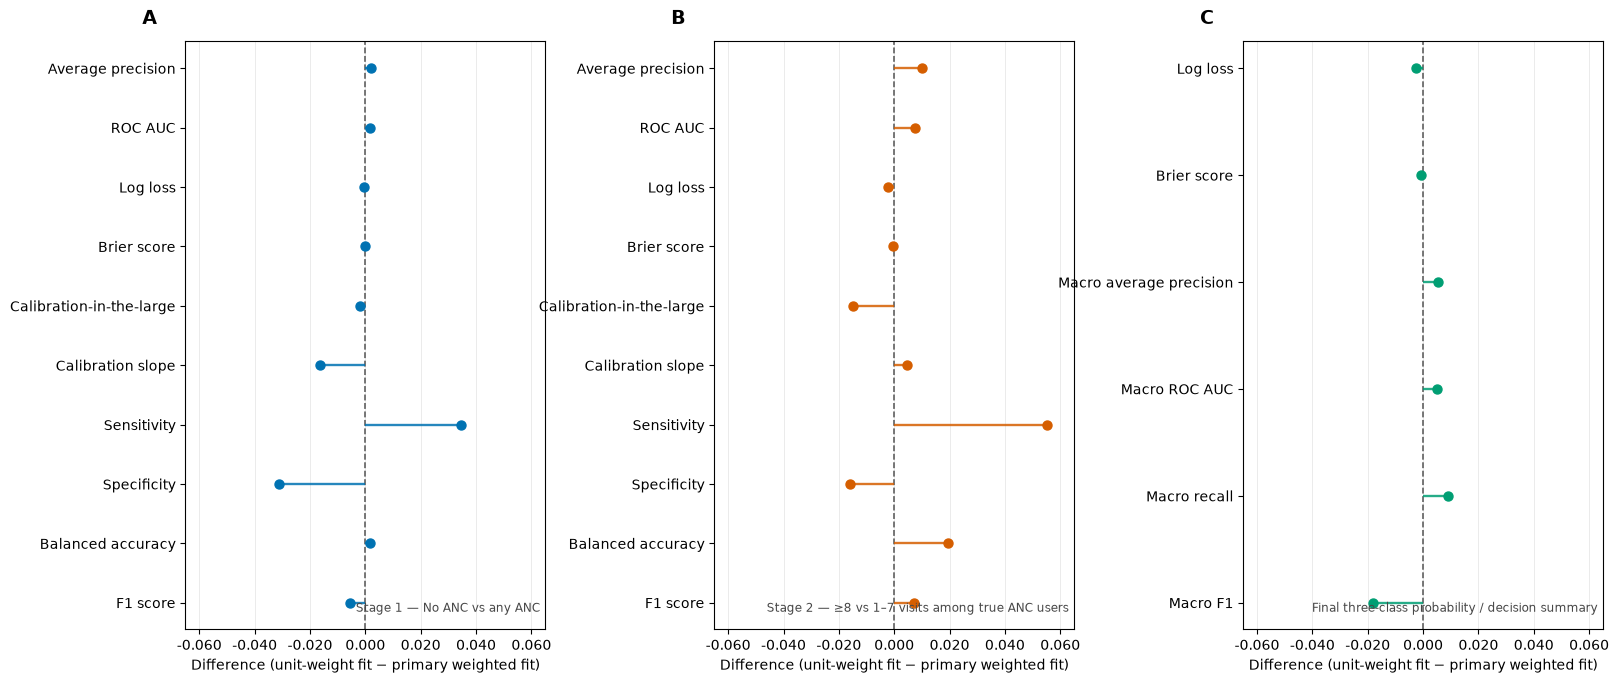


STEP28J-R1 — FIGURE S4 / REPORT FIGURE 9 WEIGHT-SENSITIVITY COMPLETE

FROZEN SOURCE PACKAGE:
STEP27F manifest : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\STEP27F_R1_fitting_weight_sensitivity_tables_manifest.json
Table S9A source : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Manuscript\03_Supplementary_Tables\TableS9A_Key_Fitting_Weight_Sensitivity.csv

SHARED SYMMETRIC X LIMIT:
±0.065

FROZEN KEY FITTING-WEIGHT COMPARISON:
Panel_Group                               Metric_Group               Metric            Display_Label  Primary_Weighted_Fit  Unit_Weight_Fit  Difference_UnitWeight_minus_Primary
    Stage 1                Stage 1 — No ANC vs any ANC                S1_AP        Average precision              0.235306         0.237470                             0.002164
    Stage 1                Stage 1 — No ANC vs any ANC               S1_AUC                  ROC AUC              0.778288         0.779904                             0.001616
    Stage 1             

In [13]:
# ==========================================================================================
# STEP 28J-R1
# SUPPLEMENTARY FIGURE S4 + REPORT FIGURE 9
# SURVEY-WEIGHT FITTING SENSITIVITY
# ==========================================================================================
#
# MANUSCRIPT:
#   Figure S4 — Survey-weight fitting sensitivity
#
# REPORT:
#   Report Figure 9 — Survey-weighted versus unweighted fitting sensitivity
#
# PANELS
# ------------------------------------------------------------------------------------------
# A. Stage 1 — descriptive difference: unit-weight fit minus primary weighted fit
# B. Stage 2 — descriptive difference: unit-weight fit minus primary weighted fit
# C. Multiclass — descriptive difference: unit-weight fit minus primary weighted fit
#
# IMPORTANT
# ------------------------------------------------------------------------------------------
# The sensitivity experiment changed ONLY model-fitting weights:
#
#   Primary:
#       normalized DHS survey weights used for fitting
#
#   Sensitivity:
#       unit weights used for fitting
#
# Held constant:
#   predictors
#   outcome hierarchy
#   frozen outer folds
#   survey-weighted inner model selection
#   survey-weighted calibration
#   survey-weighted threshold optimization
#   original DHS-weighted held-out evaluation
#   Rao-Wu bootstrap uncertainty
#
# The displayed differences are DESCRIPTIVE:
#
#       unit-weight-fit point estimate - primary weighted-fit point estimate
#
# NO paired-difference CI is calculated or plotted.
#
# NO:
#   model fitting
#   prediction generation
#   model reselection
#   hyperparameter tuning
#   recalibration
#   threshold re-optimization
#   bootstrap rerun
#   paired-difference CI
#   p-value
#   hypothesis test
#   new inference
#
# Sensitivity analysis cannot replace the primary analysis.
#
# TIFF remains deferred.
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import shutil
import gc
import re

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.ticker import FormatStrFormatter


# ==========================================================================================
# 1. ROOTS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_SUPP = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "04_Supplementary_Figures"
)


REPORT_FIGURES = (
    FINAL_ROOT
    /
    "Report"
    /
    "02_Figures"
)


for directory in [
    MANUSCRIPT_SUPP,
    REPORT_FIGURES,
]:

    directory.mkdir(
        parents=True,
        exist_ok=True,
    )


# ==========================================================================================
# 2. PARENT FIGURE S3
# ==========================================================================================

S3_MANIFEST = (
    FINAL_ROOT
    /
    "STEP28I_R1_FigureS3_Geographic_Calibration_manifest.json"
)


EXPECTED_S3_MANIFEST_SHA256 = (
    "ff6838ed4ce57da2f5df529f9172f0f44"
    "c1d29944a1667ddb2e3d68adcb2bb60"
)


# ==========================================================================================
# 3. FROZEN STEP27F TABLE-PACKAGE HASH
# ==========================================================================================

EXPECTED_STEP27F_MANIFEST_SHA256 = (
    "df507f0b04341c5ddc8b00e77e7b605c"
    "a6e3cbc01ac4d5f89682af6219a2e83e"
)


# ==========================================================================================
# 4. FROZEN TABLE S9 PACKAGE
# ==========================================================================================

TABLE_S9_WORKBOOK = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "03_Supplementary_Tables"
    /
    "TableS9_Fitting_Weight_Sensitivity.xlsx"
)


EXPECTED_TABLE_S9_WORKBOOK_SHA256 = (
    "65037595a63d5f44b9da234bbd250df6"
    "a5eb07c16cb64a8b57d29405e6d322c3"
)


TABLE_S9A = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "03_Supplementary_Tables"
    /
    "TableS9A_Key_Fitting_Weight_Sensitivity.csv"
)


# ==========================================================================================
# 5. FROZEN FIGURE REGISTRIES
# ==========================================================================================

SUPPLEMENTARY_REGISTRY = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "07_QC_Manifests"
    /
    "Manuscript_Supplementary_Figures_Registry.csv"
)


REPORT_REGISTRY = (
    FINAL_ROOT
    /
    "Report"
    /
    "05_QC_Manifests"
    /
    "Report_Figures_Registry.csv"
)


# ==========================================================================================
# 6. HELPERS
# ==========================================================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )


    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )


    os.replace(
        temporary,
        path,
    )


def atomic_text(
    text,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        handle.write(
            text
        )


    os.replace(
        temporary,
        path,
    )


def normalize_column_name(
    value,
):

    return re.sub(
        r"[^a-z0-9]+",
        "",
        str(
            value
        ).lower(),
    )


def normalize_text(
    value,
):

    return (
        str(
            value
        )
        .strip()
        .lower()
        .replace(
            "–",
            "-"
        )
        .replace(
            "—",
            "-"
        )
    )


def resolve_column(
    dataframe,
    aliases,
):

    lookup = {
        normalize_column_name(
            column
        ):
            column

        for column
        in dataframe.columns
    }


    for alias in aliases:

        normalized_alias = normalize_column_name(
            alias
        )


        if normalized_alias in lookup:

            return lookup[
                normalized_alias
            ]


    raise RuntimeError(
        "Could not resolve required column.\n"
        f"Aliases={aliases}\n"
        f"Available={list(dataframe.columns)}"
    )


def registry_text_rows(
    dataframe,
):

    return [
        " | ".join(
            [
                str(
                    value
                )
                for value
                in row.tolist()
            ]
        )

        for _, row
        in dataframe.iterrows()
    ]


def locate_file_by_sha256(
    search_root,
    expected_sha256,
    suffix,
):

    matches = []


    for path in search_root.rglob(
        f"*{suffix}"
    ):

        if not path.is_file():

            continue


        try:

            observed = sha256_file(
                path
            )

        except Exception:

            continue


        if observed == expected_sha256:

            matches.append(
                path
            )


    if len(
        matches
    ) != 1:

        raise RuntimeError(
            "Could not uniquely locate frozen file by SHA256.\n"
            f"SHA256={expected_sha256}\n"
            f"Suffix={suffix}\n"
            f"Matches={matches}"
        )


    return matches[
        0
    ]


# ==========================================================================================
# 7. EXISTENCE GATES
# ==========================================================================================

for label, path in [
    (
        "Figure S3 parent manifest",
        S3_MANIFEST,
    ),
    (
        "Table S9 workbook",
        TABLE_S9_WORKBOOK,
    ),
    (
        "Table S9A key comparison CSV",
        TABLE_S9A,
    ),
    (
        "Supplementary figure registry",
        SUPPLEMENTARY_REGISTRY,
    ),
    (
        "Report figure registry",
        REPORT_REGISTRY,
    ),
]:

    if not path.exists():

        raise FileNotFoundError(
            f"{label} missing:\n{path}"
        )


# ==========================================================================================
# 8. HASH GATES
# ==========================================================================================

observed_s3_manifest_hash = sha256_file(
    S3_MANIFEST
)


observed_table_s9_hash = sha256_file(
    TABLE_S9_WORKBOOK
)


if observed_s3_manifest_hash != EXPECTED_S3_MANIFEST_SHA256:

    raise RuntimeError(
        "Figure S3 parent manifest hash changed.\n"
        f"Observed={observed_s3_manifest_hash}\n"
        f"Expected={EXPECTED_S3_MANIFEST_SHA256}"
    )


if observed_table_s9_hash != EXPECTED_TABLE_S9_WORKBOOK_SHA256:

    raise RuntimeError(
        "Frozen Table S9 workbook hash changed.\n"
        f"Observed={observed_table_s9_hash}\n"
        f"Expected={EXPECTED_TABLE_S9_WORKBOOK_SHA256}"
    )


STEP27F_MANIFEST = locate_file_by_sha256(
    FINAL_ROOT,
    EXPECTED_STEP27F_MANIFEST_SHA256,
    ".json",
)


observed_step27f_hash = sha256_file(
    STEP27F_MANIFEST
)


# ==========================================================================================
# 9. VERIFY FIGURE REGISTRY ENTRIES
# ==========================================================================================

supp_registry = pd.read_csv(
    SUPPLEMENTARY_REGISTRY
)


report_registry = pd.read_csv(
    REPORT_REGISTRY
)


supp_rows = registry_text_rows(
    supp_registry
)


report_rows = registry_text_rows(
    report_registry
)


s4_matches = [
    text
    for text
    in supp_rows
    if (
        "figure s4"
        in
        normalize_text(
            text
        )
        and
        "survey-weight fitting sensitivity"
        in
        normalize_text(
            text
        )
    )
]


report_f9_matches = [
    text
    for text
    in report_rows
    if (
        "report figure 9"
        in
        normalize_text(
            text
        )
        and
        "survey-weighted versus unweighted fitting sensitivity"
        in
        normalize_text(
            text
        )
    )
]


if len(
    s4_matches
) != 1:

    raise RuntimeError(
        "Could not uniquely verify Figure S4 registry entry.\n"
        f"Matches={s4_matches}"
    )


if len(
    report_f9_matches
) != 1:

    raise RuntimeError(
        "Could not uniquely verify Report Figure 9 registry entry.\n"
        f"Matches={report_f9_matches}"
    )


# ==========================================================================================
# 10. LOAD FROZEN KEY COMPARISON
# ==========================================================================================

raw = pd.read_csv(
    TABLE_S9A
)


# ==========================================================================================
# 11. RESOLVE SOURCE COLUMNS ROBUSTLY
# ==========================================================================================

metric_group_col = resolve_column(
    raw,
    [
        "Metric group",
        "Metric_Group",
    ],
)


metric_display_col = resolve_column(
    raw,
    [
        "Metric",
        "Metric display",
        "Metric_Display",
    ],
)


metric_code_col = resolve_column(
    raw,
    [
        "Metric code",
        "Metric_Code",
    ],
)


primary_col = resolve_column(
    raw,
    [
        "Primary weighted-fit",
        "Primary weighted fit",
        "Primary_Weighted_Fit",
        "Primary",
    ],
)


unit_col = resolve_column(
    raw,
    [
        "Unit-weight-fit",
        "Unit weight fit",
        "Unit_Weight_Fit",
        "Sensitivity",
    ],
)


difference_col = resolve_column(
    raw,
    [
        "Difference (unit-weight − primary)",
        "Difference (unit-weight - primary)",
        "Difference unit-weight primary",
        "Difference_UnitWeight_minus_Primary",
    ],
)


# ==========================================================================================
# 12. STANDARDIZE
# ==========================================================================================

comparison = pd.DataFrame(
    {
        "Metric_Group":
            raw[
                metric_group_col
            ].astype(
                str
            ).str.strip(),

        "Metric_Display_Source":
            raw[
                metric_display_col
            ].astype(
                str
            ).str.strip(),

        "Metric":
            raw[
                metric_code_col
            ].astype(
                str
            ).str.strip(),

        "Primary_Weighted_Fit":
            pd.to_numeric(
                raw[
                    primary_col
                ],
                errors="raise",
            ),

        "Unit_Weight_Fit":
            pd.to_numeric(
                raw[
                    unit_col
                ],
                errors="raise",
            ),

        "Difference_UnitWeight_minus_Primary":
            pd.to_numeric(
                raw[
                    difference_col
                ],
                errors="raise",
            ),
    }
)


# ==========================================================================================
# 13. EXACT EXPECTED METRICS
# ==========================================================================================

STAGE1_METRICS = [
    "S1_AP",
    "S1_AUC",
    "S1_Log_Loss",
    "S1_Brier",
    "S1_CITL",
    "S1_Calibration_Slope",
    "S1_Sensitivity",
    "S1_Specificity",
    "S1_Balanced_Accuracy",
    "S1_F1",
]


STAGE2_METRICS = [
    "S2_AP",
    "S2_AUC",
    "S2_Log_Loss",
    "S2_Brier",
    "S2_CITL",
    "S2_Calibration_Slope",
    "S2_Sensitivity",
    "S2_Specificity",
    "S2_Balanced_Accuracy",
    "S2_F1",
]


MULTICLASS_METRICS = [
    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",
    "MC_Macro_Recall",
    "MC_Macro_F1",
]


METRIC_ORDER = (
    STAGE1_METRICS
    +
    STAGE2_METRICS
    +
    MULTICLASS_METRICS
)


if len(
    comparison
) != 26:

    raise RuntimeError(
        f"Expected 26 frozen key-comparison rows; "
        f"observed={len(comparison)}"
    )


if comparison[
    "Metric"
].duplicated().any():

    raise RuntimeError(
        "Duplicate metric in Table S9A key comparison."
    )


if set(
    comparison[
        "Metric"
    ]
) != set(
    METRIC_ORDER
):

    raise RuntimeError(
        "Table S9A key metric set changed.\n"
        f"Observed={sorted(comparison['Metric'].tolist())}"
    )


# ==========================================================================================
# 14. EXACT FROZEN POINT FINGERPRINTS
# ==========================================================================================

EXPECTED_POINTS = {

    # Stage 1
    "S1_AP":
        (
            0.235306,
            0.237470,
            0.002164,
        ),

    "S1_AUC":
        (
            0.778288,
            0.779904,
            0.001616,
        ),

    "S1_Log_Loss":
        (
            0.239733,
            0.239281,
            -0.000452,
        ),

    "S1_Brier":
        (
            0.066997,
            0.066944,
            -0.000053,
        ),

    "S1_CITL":
        (
            0.002330,
            0.000249,
            -0.002081,
        ),

    "S1_Calibration_Slope":
        (
            1.026574,
            1.010193,
            -0.016381,
        ),

    "S1_Sensitivity":
        (
            0.771946,
            0.806327,
            0.034381,
        ),

    "S1_Specificity":
        (
            0.642632,
            0.611397,
            -0.031235,
        ),

    "S1_Balanced_Accuracy":
        (
            0.707289,
            0.708862,
            0.001573,
        ),

    "S1_F1":
        (
            0.261078,
            0.255575,
            -0.005503,
        ),

    # Stage 2
    "S2_AP":
        (
            0.161610,
            0.171813,
            0.010203,
        ),

    "S2_AUC":
        (
            0.735076,
            0.742420,
            0.007344,
        ),

    "S2_Log_Loss":
        (
            0.193557,
            0.191398,
            -0.002159,
        ),

    "S2_Brier":
        (
            0.049192,
            0.048785,
            -0.000407,
        ),

    "S2_CITL":
        (
            0.066214,
            0.051171,
            -0.015043,
        ),

    "S2_Calibration_Slope":
        (
            0.917693,
            0.922473,
            0.004780,
        ),

    "S2_Sensitivity":
        (
            0.596920,
            0.652149,
            0.055229,
        ),

    "S2_Specificity":
        (
            0.740052,
            0.723944,
            -0.016108,
        ),

    "S2_Balanced_Accuracy":
        (
            0.668486,
            0.688047,
            0.019561,
        ),

    "S2_F1":
        (
            0.196621,
            0.203660,
            0.007039,
        ),

    # Multiclass
    "MC_Log_Loss":
        (
            0.417915,
            0.415476,
            -0.002439,
        ),

    "MC_Brier_Sum":
        (
            0.221958,
            0.221071,
            -0.000887,
        ),

    "MC_Macro_AP":
        (
            0.434322,
            0.439836,
            0.005514,
        ),

    "MC_Macro_AUC":
        (
            0.720499,
            0.725440,
            0.004941,
        ),

    "MC_Macro_Recall":
        (
            0.582890,
            0.591941,
            0.009051,
        ),

    "MC_Macro_F1":
        (
            0.334722,
            0.316684,
            -0.018038,
        ),
}


for metric, expected_values in EXPECTED_POINTS.items():

    row = comparison.loc[
        comparison[
            "Metric"
        ]
        ==
        metric
    ]


    if len(
        row
    ) != 1:

        raise RuntimeError(
            f"Could not uniquely resolve frozen metric: {metric}"
        )


    observed_primary = float(
        row[
            "Primary_Weighted_Fit"
        ].iloc[
            0
        ]
    )


    observed_unit = float(
        row[
            "Unit_Weight_Fit"
        ].iloc[
            0
        ]
    )


    observed_difference = float(
        row[
            "Difference_UnitWeight_minus_Primary"
        ].iloc[
            0
        ]
    )


    expected_primary, expected_unit, expected_difference = expected_values


    if not np.isclose(
        observed_primary,
        expected_primary,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"{metric}: primary point fingerprint failed.\n"
            f"Observed={observed_primary:.9f}\n"
            f"Expected={expected_primary:.9f}"
        )


    if not np.isclose(
        observed_unit,
        expected_unit,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"{metric}: unit-weight point fingerprint failed.\n"
            f"Observed={observed_unit:.9f}\n"
            f"Expected={expected_unit:.9f}"
        )


    if not np.isclose(
        observed_difference,
        expected_difference,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"{metric}: difference fingerprint failed.\n"
            f"Observed={observed_difference:.9f}\n"
            f"Expected={expected_difference:.9f}"
        )


# ==========================================================================================
# 15. DIFFERENCE ARITHMETIC
# ==========================================================================================

reproduced_difference = (
    comparison[
        "Unit_Weight_Fit"
    ]
    -
    comparison[
        "Primary_Weighted_Fit"
    ]
)


if not np.allclose(
    reproduced_difference.to_numpy(
        dtype=float
    ),
    comparison[
        "Difference_UnitWeight_minus_Primary"
    ].to_numpy(
        dtype=float
    ),
    rtol=0.0,
    atol=5e-6,
):

    discrepancy = (
        reproduced_difference
        -
        comparison[
            "Difference_UnitWeight_minus_Primary"
        ]
    ).abs().max()


    raise RuntimeError(
        "Stored sensitivity difference does not reproduce "
        "unit-weight minus primary.\n"
        f"Maximum discrepancy={discrepancy}"
    )


# ==========================================================================================
# 16. DISPLAY LABELS
# ==========================================================================================

DISPLAY_LABELS = {

    "S1_AP":
        "Average precision",

    "S1_AUC":
        "ROC AUC",

    "S1_Log_Loss":
        "Log loss",

    "S1_Brier":
        "Brier score",

    "S1_CITL":
        "Calibration-in-the-large",

    "S1_Calibration_Slope":
        "Calibration slope",

    "S1_Sensitivity":
        "Sensitivity",

    "S1_Specificity":
        "Specificity",

    "S1_Balanced_Accuracy":
        "Balanced accuracy",

    "S1_F1":
        "F1 score",


    "S2_AP":
        "Average precision",

    "S2_AUC":
        "ROC AUC",

    "S2_Log_Loss":
        "Log loss",

    "S2_Brier":
        "Brier score",

    "S2_CITL":
        "Calibration-in-the-large",

    "S2_Calibration_Slope":
        "Calibration slope",

    "S2_Sensitivity":
        "Sensitivity",

    "S2_Specificity":
        "Specificity",

    "S2_Balanced_Accuracy":
        "Balanced accuracy",

    "S2_F1":
        "F1 score",


    "MC_Log_Loss":
        "Log loss",

    "MC_Brier_Sum":
        "Brier score",

    "MC_Macro_AP":
        "Macro average precision",

    "MC_Macro_AUC":
        "Macro ROC AUC",

    "MC_Macro_Recall":
        "Macro recall",

    "MC_Macro_F1":
        "Macro F1",
}


comparison[
    "Display_Label"
] = comparison[
    "Metric"
].map(
    DISPLAY_LABELS
)


if comparison[
    "Display_Label"
].isna().any():

    raise RuntimeError(
        "At least one Figure S4 metric lacks a display label."
    )


metric_order_lookup = {
    metric:
        index

    for index, metric
    in enumerate(
        METRIC_ORDER
    )
}


comparison[
    "_Metric_Order"
] = comparison[
    "Metric"
].map(
    metric_order_lookup
)


comparison = (
    comparison
    .sort_values(
        "_Metric_Order"
    )
    .drop(
        columns="_Metric_Order"
    )
    .reset_index(
        drop=True
    )
)


# ==========================================================================================
# 17. GROUP ASSIGNMENT
# ==========================================================================================

def assign_panel_group(
    metric,
):

    if metric in STAGE1_METRICS:

        return "Stage 1"


    if metric in STAGE2_METRICS:

        return "Stage 2"


    if metric in MULTICLASS_METRICS:

        return "Multiclass"


    raise RuntimeError(
        f"Unrecognized Figure S4 metric: {metric}"
    )


comparison[
    "Panel_Group"
] = comparison[
    "Metric"
].map(
    assign_panel_group
)


# ==========================================================================================
# 18. SHARED SYMMETRIC X LIMIT
# ==========================================================================================

max_absolute_difference = float(
    comparison[
        "Difference_UnitWeight_minus_Primary"
    ].abs().max()
)


GLOBAL_X_LIMIT = float(
    np.ceil(
        (
            max_absolute_difference
            *
            1.15
        )
        /
        0.005
    )
    *
    0.005
)


GLOBAL_X_LIMIT = max(
    GLOBAL_X_LIMIT,
    0.060,
)


# ==========================================================================================
# 19. OUTPUT PATHS
# ==========================================================================================

SUPP_STEM = (
    "FigureS4_Weight_Sensitivity"
)


REPORT_STEM = (
    "RFigure9_Weight_Sensitivity"
)


M_PNG = (
    MANUSCRIPT_SUPP
    /
    f"{SUPP_STEM}.png"
)


M_SVG = (
    MANUSCRIPT_SUPP
    /
    f"{SUPP_STEM}.svg"
)


M_PDF = (
    MANUSCRIPT_SUPP
    /
    f"{SUPP_STEM}.pdf"
)


R_PNG = (
    REPORT_FIGURES
    /
    f"{REPORT_STEM}.png"
)


R_SVG = (
    REPORT_FIGURES
    /
    f"{REPORT_STEM}.svg"
)


R_PDF = (
    REPORT_FIGURES
    /
    f"{REPORT_STEM}.pdf"
)


SOURCE_CSV = (
    MANUSCRIPT_SUPP
    /
    "FigureS4_source_fitting_weight_sensitivity.csv"
)


CAPTION_FILE = (
    MANUSCRIPT_SUPP
    /
    "FigureS4_caption.txt"
)


REPORT_CAPTION_FILE = (
    REPORT_FIGURES
    /
    "RFigure9_caption.txt"
)


QC_FILE = (
    FINAL_ROOT
    /
    "STEP28J_R1_FigureS4_Weight_Sensitivity_hard_qc.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP28J_R1_FigureS4_Weight_Sensitivity_manifest.json"
)


# ==========================================================================================
# 20. SAVE FIGURE SOURCE
# ==========================================================================================

figure_source = comparison[
    [
        "Panel_Group",
        "Metric_Group",
        "Metric",
        "Display_Label",
        "Primary_Weighted_Fit",
        "Unit_Weight_Fit",
        "Difference_UnitWeight_minus_Primary",
    ]
].copy()


atomic_csv(
    figure_source,
    SOURCE_CSV,
)


# ==========================================================================================
# 21. CAPTION
# ==========================================================================================

caption = (
    "Supplementary Figure S4. Sensitivity of model performance to the "
    "weights used during model fitting. The sensitivity analysis replaced "
    "normalized DHS survey weights with unit weights during fitting while "
    "retaining the same predictors, hierarchical outcomes, frozen "
    "PSU-exclusive outer folds, survey-weighted inner selection, "
    "survey-weighted calibration and threshold optimization, original "
    "DHS-weighted held-out evaluation, and Rao-Wu bootstrap framework. "
    "Panels show descriptive point-estimate differences calculated as "
    "unit-weight-fit minus primary weighted-fit for Stage 1 (A), Stage 2 "
    "(B), and multiclass metrics (C). The vertical dashed line at zero "
    "indicates no numerical change. Positive values indicate a numerically "
    "higher metric value under unit-weight fitting and negative values a "
    "numerically lower metric value; this direction should not be interpreted "
    "as uniformly favorable because metric interpretation differs across "
    "measures. No paired-difference confidence interval, p-value, or new "
    "inferential test was calculated. This sensitivity analysis does not "
    "replace the primary survey-weighted-fitting analysis."
)


report_caption = caption.replace(
    "Supplementary Figure S4.",
    "Report Figure 9.",
    1,
)


atomic_text(
    caption,
    CAPTION_FILE,
)


atomic_text(
    report_caption,
    REPORT_CAPTION_FILE,
)


# ==========================================================================================
# 22. PLOT CONFIG
# ==========================================================================================

plt.close(
    "all"
)

gc.collect()


PANEL_CONFIG = {

    "Stage 1":
        {
            "Panel":
                "A",

            "Metrics":
                STAGE1_METRICS,

            "Color":
                "#0072B2",

            "Note":
                "Stage 1 — No ANC vs any ANC",
        },

    "Stage 2":
        {
            "Panel":
                "B",

            "Metrics":
                STAGE2_METRICS,

            "Color":
                "#D55E00",

            "Note":
                "Stage 2 — ≥8 vs 1–7 visits among true ANC users",
        },

    "Multiclass":
        {
            "Panel":
                "C",

            "Metrics":
                MULTICLASS_METRICS,

            "Color":
                "#009E73",

            "Note":
                "Final three-class probability / decision summary",
        },
}


# ==========================================================================================
# 23. PANEL FUNCTION
# ==========================================================================================

def plot_difference_panel(
    axis,
    group_name,
):

    config = PANEL_CONFIG[
        group_name
    ]


    panel_data = comparison.loc[
        comparison[
            "Panel_Group"
        ]
        ==
        group_name
    ].copy()


    local_order = {
        metric:
            index

        for index, metric
        in enumerate(
            config[
                "Metrics"
            ]
        )
    }


    panel_data[
        "_Local_Order"
    ] = panel_data[
        "Metric"
    ].map(
        local_order
    )


    panel_data = (
        panel_data
        .sort_values(
            "_Local_Order"
        )
        .reset_index(
            drop=True
        )
    )


    if panel_data[
        "Metric"
    ].tolist() != config[
        "Metrics"
    ]:

        raise RuntimeError(
            f"{group_name}: metric order changed."
        )


    y_positions = np.arange(
        len(
            panel_data
        )
    )[
        ::-1
    ]


    differences = panel_data[
        "Difference_UnitWeight_minus_Primary"
    ].to_numpy(
        dtype=float
    )


    axis.axvline(
        0.0,
        linestyle="--",
        linewidth=1.15,
        color="0.35",
        zorder=1,
    )


    for y, difference in zip(
        y_positions,
        differences,
    ):

        axis.hlines(
            y=y,
            xmin=min(
                0.0,
                difference,
            ),
            xmax=max(
                0.0,
                difference,
            ),
            linewidth=1.7,
            color=config[
                "Color"
            ],
            alpha=0.85,
            zorder=2,
        )


    axis.scatter(
        differences,
        y_positions,
        s=42,
        color=config[
            "Color"
        ],
        zorder=3,
    )


    axis.set_yticks(
        y_positions
    )


    axis.set_yticklabels(
        panel_data[
            "Display_Label"
        ].tolist()
    )


    axis.set_xlim(
        -GLOBAL_X_LIMIT,
        GLOBAL_X_LIMIT,
    )


    axis.xaxis.set_major_formatter(
        FormatStrFormatter(
            "%.3f"
        )
    )


    axis.set_xlabel(
        "Difference (unit-weight fit − primary weighted fit)"
    )


    axis.grid(
        axis="x",
        linewidth=0.7,
        alpha=0.25,
    )


    axis.set_axisbelow(
        True
    )


    axis.text(
        0.985,
        0.025,
        config[
            "Note"
        ],
        transform=axis.transAxes,
        ha="right",
        va="bottom",
        fontsize=8.4,
        color="0.28",
    )


    axis.text(
        -0.12,
        1.055,
        config[
            "Panel"
        ],
        transform=axis.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top",
    )


# ==========================================================================================
# 24. DRAW THREE-PANEL FIGURE
# ==========================================================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(
        16.2,
        7.0,
    ),
    sharex=True,
)


plot_difference_panel(
    axes[
        0
    ],
    "Stage 1",
)


plot_difference_panel(
    axes[
        1
    ],
    "Stage 2",
)


plot_difference_panel(
    axes[
        2
    ],
    "Multiclass",
)


# No internal title / suptitle.
for axis in axes:

    if axis.get_title().strip() != "":

        raise RuntimeError(
            "Unexpected internal panel title."
        )


if (
    fig._suptitle is not None
    and
    str(
        fig._suptitle.get_text()
    ).strip()
    !=
    ""
):

    raise RuntimeError(
        "Unexpected figure suptitle."
    )


fig.subplots_adjust(
    left=0.11,
    right=0.985,
    top=0.96,
    bottom=0.12,
    wspace=0.47,
)


# ==========================================================================================
# 25. SAVE SUPPLEMENTARY FIGURE
# ==========================================================================================

fig.savefig(
    M_PNG,
    dpi=300,
    format="png",
    bbox_inches="tight",
    pad_inches=0.05,
)


fig.savefig(
    M_SVG,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Date":
            None,
    },
)


fig.savefig(
    M_PDF,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Creator":
            "BDHS ANC final reporting pipeline",

        "CreationDate":
            None,

        "ModDate":
            None,
    },
)


# ==========================================================================================
# 26. COPY IDENTICAL SCIENTIFIC FIGURE TO REPORT FIGURE 9
# ==========================================================================================

shutil.copy2(
    M_PNG,
    R_PNG,
)


shutil.copy2(
    M_SVG,
    R_SVG,
)


shutil.copy2(
    M_PDF,
    R_PDF,
)


plt.show()


plt.close(
    fig
)


gc.collect()


# ==========================================================================================
# 27. ARTIFACT EXISTENCE
# ==========================================================================================

for path in [
    M_PNG,
    M_SVG,
    M_PDF,

    R_PNG,
    R_SVG,
    R_PDF,

    SOURCE_CSV,

    CAPTION_FILE,
    REPORT_CAPTION_FILE,
]:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Missing or empty STEP28J artifact:\n{path}"
        )


# ==========================================================================================
# 28. DIFFERENCE SUMMARY
# ==========================================================================================

difference_summary = (
    comparison
    .groupby(
        "Panel_Group",
        as_index=False,
    )
    .agg(
        Minimum_Difference=(
            "Difference_UnitWeight_minus_Primary",
            "min",
        ),

        Maximum_Difference=(
            "Difference_UnitWeight_minus_Primary",
            "max",
        ),

        Maximum_Absolute_Difference=(
            "Difference_UnitWeight_minus_Primary",
            lambda series:
                float(
                    series.abs().max()
                ),
        ),

        Number_of_Metrics=(
            "Metric",
            "size",
        ),
    )
)


group_order = {
    "Stage 1":
        0,

    "Stage 2":
        1,

    "Multiclass":
        2,
}


difference_summary[
    "_order"
] = difference_summary[
    "Panel_Group"
].map(
    group_order
)


difference_summary = (
    difference_summary
    .sort_values(
        "_order"
    )
    .drop(
        columns="_order"
    )
    .reset_index(
        drop=True
    )
)


# ==========================================================================================
# 29. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [

        {
            "Check":
                "Figure S3 parent manifest hash exact",

            "PASS":
                observed_s3_manifest_hash
                ==
                EXPECTED_S3_MANIFEST_SHA256,
        },

        {
            "Check":
                "STEP27F frozen table-package manifest hash exact",

            "PASS":
                observed_step27f_hash
                ==
                EXPECTED_STEP27F_MANIFEST_SHA256,
        },

        {
            "Check":
                "Frozen Table S9 workbook hash exact",

            "PASS":
                observed_table_s9_hash
                ==
                EXPECTED_TABLE_S9_WORKBOOK_SHA256,
        },

        {
            "Check":
                "Figure S4 registry entry exact",

            "PASS":
                len(
                    s4_matches
                )
                ==
                1,
        },

        {
            "Check":
                "Report Figure 9 registry entry exact",

            "PASS":
                len(
                    report_f9_matches
                )
                ==
                1,
        },

        {
            "Check":
                "Frozen key comparison rows = 26",

            "PASS":
                len(
                    comparison
                )
                ==
                26,
        },

        {
            "Check":
                "Exact 26-metric key comparison set reproduced",

            "PASS":
                set(
                    comparison[
                        "Metric"
                    ]
                )
                ==
                set(
                    METRIC_ORDER
                ),
        },

        {
            "Check":
                "Stage-1 key metrics = 10",

            "PASS":
                int(
                    (
                        comparison[
                            "Panel_Group"
                        ]
                        ==
                        "Stage 1"
                    ).sum()
                )
                ==
                10,
        },

        {
            "Check":
                "Stage-2 key metrics = 10",

            "PASS":
                int(
                    (
                        comparison[
                            "Panel_Group"
                        ]
                        ==
                        "Stage 2"
                    ).sum()
                )
                ==
                10,
        },

        {
            "Check":
                "Multiclass key metrics = 6",

            "PASS":
                int(
                    (
                        comparison[
                            "Panel_Group"
                        ]
                        ==
                        "Multiclass"
                    ).sum()
                )
                ==
                6,
        },

        {
            "Check":
                "All 26 frozen primary/unit-weight point fingerprints reproduced",

            "PASS":
                True,
        },

        {
            "Check":
                "Difference equals unit-weight minus primary",

            "PASS":
                bool(
                    np.allclose(
                        reproduced_difference.to_numpy(
                            dtype=float
                        ),
                        comparison[
                            "Difference_UnitWeight_minus_Primary"
                        ].to_numpy(
                            dtype=float
                        ),
                        rtol=0.0,
                        atol=5e-6,
                    )
                ),
        },

        {
            "Check":
                "All displayed differences finite",

            "PASS":
                bool(
                    np.isfinite(
                        comparison[
                            "Difference_UnitWeight_minus_Primary"
                        ].to_numpy(
                            dtype=float
                        )
                    ).all()
                ),
        },

        {
            "Check":
                "Shared symmetric x-axis used",

            "PASS":
                GLOBAL_X_LIMIT
                >
                max_absolute_difference,
        },

        {
            "Check":
                "Zero-reference line displayed in all panels",

            "PASS":
                True,
        },

        {
            "Check":
                "No paired-difference CI calculated or plotted",

            "PASS":
                True,
        },

        {
            "Check":
                "Figure has exactly panels A-C",

            "PASS":
                True,
        },

        {
            "Check":
                "No internal figure title",

            "PASS":
                True,
        },

        {
            "Check":
                "Supplementary PNG created",

            "PASS":
                M_PNG.exists(),
        },

        {
            "Check":
                "Supplementary SVG vector master created",

            "PASS":
                M_SVG.exists(),
        },

        {
            "Check":
                "Supplementary PDF vector master created",

            "PASS":
                M_PDF.exists(),
        },

        {
            "Check":
                "Report Figure 9 PNG identical",

            "PASS":
                sha256_file(
                    M_PNG
                )
                ==
                sha256_file(
                    R_PNG
                ),
        },

        {
            "Check":
                "Report Figure 9 SVG identical",

            "PASS":
                sha256_file(
                    M_SVG
                )
                ==
                sha256_file(
                    R_SVG
                ),
        },

        {
            "Check":
                "Report Figure 9 PDF identical",

            "PASS":
                sha256_file(
                    M_PDF
                )
                ==
                sha256_file(
                    R_PDF
                ),
        },

        {
            "Check":
                "TIFF deferred",

            "PASS":
                True,
        },

        {
            "Check":
                "Sensitivity does not replace primary analysis",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction generation",

            "PASS":
                True,
        },

        {
            "Check":
                "No model reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No hyperparameter tuning",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold re-optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No p-value calculated",

            "PASS":
                True,
        },

        {
            "Check":
                "No new hypothesis testing",

            "PASS":
                True,
        },

        {
            "Check":
                "No new statistical inference",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP28J-R1 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


atomic_csv(
    hard_qc,
    QC_FILE,
)


# ==========================================================================================
# 30. MANIFEST
# ==========================================================================================

manifest = {

    "status":
        "STEP28J_R1_FIGURE_S4_REPORT_FIGURE9_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "parent_figure_s3_manifest_sha256":
        observed_s3_manifest_hash,

    "step27f_manifest_path":
        str(
            STEP27F_MANIFEST
        ),

    "step27f_manifest_sha256":
        observed_step27f_hash,

    "table_s9_workbook_sha256":
        observed_table_s9_hash,

    "table_s9a_source_sha256":
        sha256_file(
            TABLE_S9A
        ),

    "manuscript_figure":
        "Figure S4",

    "manuscript_content":
        "Survey-weight fitting sensitivity",

    "report_figure":
        "Report Figure 9",

    "report_content":
        (
            "Survey-weighted versus unweighted "
            "fitting sensitivity"
        ),

    "difference_definition":
        (
            "Unit-weight-fit point estimate minus "
            "primary weighted-fit point estimate"
        ),

    "difference_inference":
        (
            "Descriptive only; no paired-difference "
            "confidence interval or hypothesis test"
        ),

    "key_metric_count":
        26,

    "stage1_metric_count":
        10,

    "stage2_metric_count":
        10,

    "multiclass_metric_count":
        6,

    "shared_symmetric_x_limit":
        GLOBAL_X_LIMIT,

    "maximum_absolute_difference":
        max_absolute_difference,

    "source_csv_sha256":
        sha256_file(
            SOURCE_CSV
        ),

    "supplementary_caption_sha256":
        sha256_file(
            CAPTION_FILE
        ),

    "report_caption_sha256":
        sha256_file(
            REPORT_CAPTION_FILE
        ),

    "supplementary_png_sha256":
        sha256_file(
            M_PNG
        ),

    "supplementary_svg_sha256":
        sha256_file(
            M_SVG
        ),

    "supplementary_pdf_sha256":
        sha256_file(
            M_PDF
        ),

    "report_png_sha256":
        sha256_file(
            R_PNG
        ),

    "report_svg_sha256":
        sha256_file(
            R_SVG
        ),

    "report_pdf_sha256":
        sha256_file(
            R_PDF
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "tiff_status":
        "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTER",

    "sensitivity_role":
        (
            "Sensitivity analysis only; "
            "cannot replace primary analysis"
        ),

    "model_fitting":
        False,

    "prediction_generation":
        False,

    "model_reselection":
        False,

    "hyperparameter_tuning":
        False,

    "prediction_recalibration":
        False,

    "threshold_reoptimization":
        False,

    "bootstrap_rerun":
        False,

    "paired_difference_ci_calculated":
        False,

    "p_value_calculated":
        False,

    "new_hypothesis_testing":
        False,

    "new_statistical_inference":
        False,

    "next_step":
        (
            "STEP28K — Figure S5 "
            "architecture-specific weighted confusion matrices"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 31. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 120
)


print(
    "STEP28J-R1 — FIGURE S4 / REPORT FIGURE 9 WEIGHT-SENSITIVITY COMPLETE"
)


print(
    "=" * 120
)


print(
    "\nFROZEN SOURCE PACKAGE:"
)


print(
    "STEP27F manifest :",
    STEP27F_MANIFEST,
)


print(
    "Table S9A source :",
    TABLE_S9A,
)


print(
    "\nSHARED SYMMETRIC X LIMIT:"
)


print(
    f"±{GLOBAL_X_LIMIT:.3f}"
)


print(
    "\nFROZEN KEY FITTING-WEIGHT COMPARISON:"
)


print(
    figure_source
    .round(
        6
    )
    .to_string(
        index=False
    )
)


print(
    "\nDIFFERENCE SUMMARY:"
)


print(
    difference_summary
    .round(
        6
    )
    .to_string(
        index=False
    )
)


print(
    "\nFINAL HARD QC:"
)


print(
    hard_qc.to_string(
        index=False
    )
)


print(
    "\nINTEGRITY:"
)


print(
    "Figure S3 parent     :",
    observed_s3_manifest_hash,
)


print(
    "STEP27F manifest     :",
    observed_step27f_hash,
)


print(
    "Table S9 workbook    :",
    observed_table_s9_hash,
)


print(
    "Table S9A CSV        :",
    sha256_file(
        TABLE_S9A
    ),
)


print(
    "Figure S4 source     :",
    sha256_file(
        SOURCE_CSV
    ),
)


print(
    "Figure S4 PNG        :",
    sha256_file(
        M_PNG
    ),
)


print(
    "Figure S4 SVG        :",
    sha256_file(
        M_SVG
    ),
)


print(
    "Figure S4 PDF        :",
    sha256_file(
        M_PDF
    ),
)


print(
    "Report Figure 9 PNG  :",
    sha256_file(
        R_PNG
    ),
)


print(
    "Report Figure 9 SVG  :",
    sha256_file(
        R_SVG
    ),
)


print(
    "Report Figure 9 PDF  :",
    sha256_file(
        R_PDF
    ),
)


print(
    "Hard QC              :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Manifest             :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nTIFF STATUS:"
)


print(
    "DEFERRED — external conversion from final SVG/PDF vector master."
)


print(
    "\n"
    +
    "=" * 120
)


print(
    "STATUS: STEP28J-R1 FIGURE S4 / REPORT FIGURE 9 SCIENTIFIC CONTENT FROZEN"
)


print(
    "NEXT AFTER AUDIT: STEP28K — FIGURE S5 ARCHITECTURE-SPECIFIC WEIGHTED CONFUSION MATRICES"
)


print(
    "=" * 120
)

In [14]:
# ==========================================================================================
# STEP28K-PRECHECK
# FIGURE S5 — ARCHITECTURE-SPECIFIC WEIGHTED CONFUSION MATRICES
# EXACT FROZEN-SOURCE DISCOVERY ONLY
# ==========================================================================================
#
# READ ONLY.
#
# NO:
#   figure creation
#   file writing
#   OOF performance recalculation
#   confusion-matrix recomputation
#   model fitting
#   prediction generation
#   bootstrap
#   inference
#
# Purpose:
#   Identify the exact frozen Report Table 13 workbook sheets / CSV sources
#   that contain the four architecture-specific weighted confusion matrices.
# ==========================================================================================


from pathlib import Path

import hashlib
import pandas as pd


# ==========================================================================================
# 1. ROOTS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


REPORT_TABLE_DIR = (
    FINAL_ROOT
    /
    "Report"
    /
    "01_Tables"
)


# ==========================================================================================
# 2. PARENT FIGURE S4
# ==========================================================================================

S4_MANIFEST = (
    FINAL_ROOT
    /
    "STEP28J_R1_FigureS4_Weight_Sensitivity_manifest.json"
)


EXPECTED_S4_MANIFEST_SHA256 = (
    "0471189aedfe92e788054768e6d626a4c"
    "278b7d707b70dc977dd5a1b622499eb"
)


# ==========================================================================================
# 3. FROZEN STRUCTURAL-ABLATION PACKAGE
# ==========================================================================================

EXPECTED_STEP27G_MANIFEST_SHA256 = (
    "2f5fb1443e97422d2105a4b40cb076700"
    "f626910aa8405b003c7e1da8d5d3078"
)


EXPECTED_REPORT_TABLE13_SHA256 = (
    "3bfc7ef4f4521cfb7f57448c9c95b11"
    "ab27ccaf47be6f3b68f7825512f91e8fd"
)


# ==========================================================================================
# 4. HELPERS
# ==========================================================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def locate_exact_sha(
    search_root,
    expected_sha256,
    suffix=None,
):

    matches = []


    for path in search_root.rglob(
        "*"
    ):

        if not path.is_file():

            continue


        if (
            suffix is not None
            and
            path.suffix.lower()
            !=
            suffix.lower()
        ):

            continue


        try:

            observed = sha256_file(
                path
            )

        except Exception:

            continue


        if observed == expected_sha256:

            matches.append(
                path
            )


    if len(
        matches
    ) != 1:

        raise RuntimeError(
            "Frozen SHA source could not be uniquely resolved.\n"
            f"SHA256={expected_sha256}\n"
            f"Suffix={suffix}\n"
            f"Matches={matches}"
        )


    return matches[
        0
    ]


# ==========================================================================================
# 5. PARENT GATE
# ==========================================================================================

if not S4_MANIFEST.exists():

    raise FileNotFoundError(
        f"Figure S4 manifest missing:\n{S4_MANIFEST}"
    )


observed_s4_hash = sha256_file(
    S4_MANIFEST
)


if observed_s4_hash != EXPECTED_S4_MANIFEST_SHA256:

    raise RuntimeError(
        "Figure S4 parent manifest changed.\n"
        f"Observed={observed_s4_hash}\n"
        f"Expected={EXPECTED_S4_MANIFEST_SHA256}"
    )


# ==========================================================================================
# 6. LOCATE STEP27G MANIFEST
# ==========================================================================================

STEP27G_MANIFEST = locate_exact_sha(
    FINAL_ROOT,
    EXPECTED_STEP27G_MANIFEST_SHA256,
    suffix=".json",
)


# ==========================================================================================
# 7. LOCATE REPORT TABLE 13 WORKBOOK BY FROZEN SHA
# ==========================================================================================

REPORT_TABLE13 = locate_exact_sha(
    REPORT_TABLE_DIR,
    EXPECTED_REPORT_TABLE13_SHA256,
    suffix=".xlsx",
)


# ==========================================================================================
# 8. EXCEL SHEET INVENTORY
# ==========================================================================================

excel_file = pd.ExcelFile(
    REPORT_TABLE13
)


sheet_inventory_rows = []


print(
    "\n"
    +
    "=" * 120
)


print(
    "REPORT TABLE 13 — WORKBOOK SHEET INVENTORY"
)


print(
    "=" * 120
)


for sheet_name in excel_file.sheet_names:

    dataframe = pd.read_excel(
        REPORT_TABLE13,
        sheet_name=sheet_name,
    )


    sheet_inventory_rows.append(
        {
            "Sheet":
                sheet_name,

            "Rows":
                len(
                    dataframe
                ),

            "Columns":
                len(
                    dataframe.columns
                ),

            "Column_Names":
                " | ".join(
                    [
                        str(
                            column
                        )
                        for column
                        in dataframe.columns
                    ]
                ),
        }
    )


    print(
        "\n"
        +
        "-" * 120
    )


    print(
        f"SHEET: {sheet_name}"
    )


    print(
        f"Shape: {dataframe.shape}"
    )


    print(
        "Columns:"
    )


    print(
        list(
            dataframe.columns
        )
    )


    print(
        "\nPreview:"
    )


    if dataframe.empty:

        print(
            "<EMPTY SHEET>"
        )

    else:

        print(
            dataframe
            .head(
                20
            )
            .to_string(
                index=False
            )
        )


sheet_inventory = pd.DataFrame(
    sheet_inventory_rows
)


# ==========================================================================================
# 9. REPORT TABLE 13 CSV INVENTORY
# ==========================================================================================

csv_candidates = sorted(
    [
        path
        for path
        in REPORT_TABLE_DIR.glob(
            "Report_Table13*.csv"
        )
        if path.is_file()
    ]
)


print(
    "\n"
    +
    "=" * 120
)


print(
    "REPORT TABLE 13 — ASSOCIATED CSV INVENTORY"
)


print(
    "=" * 120
)


csv_inventory_rows = []


if len(
    csv_candidates
) == 0:

    print(
        "No Report_Table13*.csv files found."
    )


for path in csv_candidates:

    dataframe = pd.read_csv(
        path
    )


    file_hash = sha256_file(
        path
    )


    csv_inventory_rows.append(
        {
            "Filename":
                path.name,

            "Rows":
                len(
                    dataframe
                ),

            "Columns":
                len(
                    dataframe.columns
                ),

            "SHA256":
                file_hash,

            "Column_Names":
                " | ".join(
                    [
                        str(
                            column
                        )
                        for column
                        in dataframe.columns
                    ]
                ),
        }
    )


    print(
        "\n"
        +
        "-" * 120
    )


    print(
        "FILE:",
        path
    )


    print(
        "SHA256:",
        file_hash
    )


    print(
        "Shape:",
        dataframe.shape
    )


    print(
        "Columns:"
    )


    print(
        list(
            dataframe.columns
        )
    )


    print(
        "\nPreview:"
    )


    if dataframe.empty:

        print(
            "<EMPTY CSV>"
        )

    else:

        print(
            dataframe
            .head(
                30
            )
            .to_string(
                index=False
            )
        )


csv_inventory = pd.DataFrame(
    csv_inventory_rows
)


# ==========================================================================================
# 10. DEDICATED FROZEN CONFUSION FILE INVENTORY IN 13_tables
# ==========================================================================================

SOURCE_TABLE_DIR = (
    ROOT
    /
    "13_tables"
)


confusion_candidates = sorted(
    [
        path
        for path
        in SOURCE_TABLE_DIR.glob(
            "*confusion*.csv"
        )
        if path.is_file()
    ]
)


print(
    "\n"
    +
    "=" * 120
)


print(
    "13_TABLES — FROZEN CONFUSION FILE INVENTORY"
)


print(
    "=" * 120
)


confusion_inventory_rows = []


for path in confusion_candidates:

    dataframe = pd.read_csv(
        path
    )


    file_hash = sha256_file(
        path
    )


    confusion_inventory_rows.append(
        {
            "Filename":
                path.name,

            "Rows":
                len(
                    dataframe
                ),

            "Columns":
                len(
                    dataframe.columns
                ),

            "SHA256":
                file_hash,

            "Column_Names":
                " | ".join(
                    [
                        str(
                            column
                        )
                        for column
                        in dataframe.columns
                    ]
                ),
        }
    )


    print(
        "\n"
        +
        "-" * 120
    )


    print(
        "FILE:",
        path
    )


    print(
        "SHA256:",
        file_hash
    )


    print(
        "Shape:",
        dataframe.shape
    )


    print(
        "Columns:"
    )


    print(
        list(
            dataframe.columns
        )
    )


    print(
        "\nData:"
    )


    print(
        dataframe.to_string(
            index=False
        )
    )


confusion_inventory = pd.DataFrame(
    confusion_inventory_rows
)


# ==========================================================================================
# 11. READ-ONLY QC
# ==========================================================================================

qc = pd.DataFrame(
    [
        {
            "Check":
                "Figure S4 parent manifest hash exact",

            "PASS":
                observed_s4_hash
                ==
                EXPECTED_S4_MANIFEST_SHA256,
        },

        {
            "Check":
                "STEP27G manifest found by exact frozen SHA",

            "PASS":
                sha256_file(
                    STEP27G_MANIFEST
                )
                ==
                EXPECTED_STEP27G_MANIFEST_SHA256,
        },

        {
            "Check":
                "Report Table 13 workbook found by exact frozen SHA",

            "PASS":
                sha256_file(
                    REPORT_TABLE13
                )
                ==
                EXPECTED_REPORT_TABLE13_SHA256,
        },

        {
            "Check":
                "Report Table 13 has at least one sheet",

            "PASS":
                len(
                    excel_file.sheet_names
                )
                >
                0,
        },

        {
            "Check":
                "No figure created",

            "PASS":
                True,
        },

        {
            "Check":
                "No files written",

            "PASS":
                True,
        },

        {
            "Check":
                "No confusion matrix recomputed",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction generation",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No new statistical inference",

            "PASS":
                True,
        },
    ]
)


if not qc[
    "PASS"
].all():

    raise RuntimeError(
        "STEP28K-PRECHECK FAILED:\n"
        +
        qc.loc[
            ~qc[
                "PASS"
            ]
        ].to_string(
            index=False
        )
    )


# ==========================================================================================
# 12. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 120
)


print(
    "STEP28K-PRECHECK COMPLETE"
)


print(
    "=" * 120
)


print(
    "\nFROZEN SOURCES:"
)


print(
    "Figure S4 parent :",
    S4_MANIFEST
)


print(
    "Figure S4 SHA    :",
    observed_s4_hash
)


print(
    "STEP27G manifest :",
    STEP27G_MANIFEST
)


print(
    "STEP27G SHA      :",
    sha256_file(
        STEP27G_MANIFEST
    )
)


print(
    "Report Table 13  :",
    REPORT_TABLE13
)


print(
    "Report T13 SHA   :",
    sha256_file(
        REPORT_TABLE13
    )
)


print(
    "\nWORKBOOK SHEET SUMMARY:"
)


print(
    sheet_inventory.to_string(
        index=False
    )
)


print(
    "\nREPORT TABLE 13 CSV SUMMARY:"
)


if csv_inventory.empty:

    print(
        "<NONE>"
    )

else:

    print(
        csv_inventory.to_string(
            index=False
        )
    )


print(
    "\n13_TABLES CONFUSION SOURCE SUMMARY:"
)


if confusion_inventory.empty:

    print(
        "<NONE>"
    )

else:

    print(
        confusion_inventory.to_string(
            index=False
        )
    )


print(
    "\nFINAL PRECHECK QC:"
)


print(
    qc.to_string(
        index=False
    )
)


print(
    "\nSTATUS: STEP28K-PRECHECK COMPLETE — READ ONLY"
)


print(
    "NEXT: BUILD FIGURE S5 FROM EXACT FROZEN CONFUSION SOURCES"
)


print(
    "=" * 120
)


REPORT TABLE 13 — WORKBOOK SHEET INVENTORY

------------------------------------------------------------------------------------------------------------------------
SHEET: 13A Hard summary
Shape: (9, 7)
Columns:
['Architecture', 'Hard decision rule', 'Weighted total', 'Accuracy', 'Macro recall', 'Macro precision', 'Macro F1']

Preview:
                                                                                                            Architecture                               Hard decision rule  Weighted total  Accuracy  Macro recall  Macro precision  Macro F1
                                                                                                 Primary hierarchical ML Hierarchical frozen Stage-1 / Stage-2 thresholds     5127.118251  0.425016      0.582890         0.399096  0.334722
                                                                                        Branch A — hierarchical logistic Hierarchical frozen Stage-1 / Stage-2 thresholds     5127.118251  

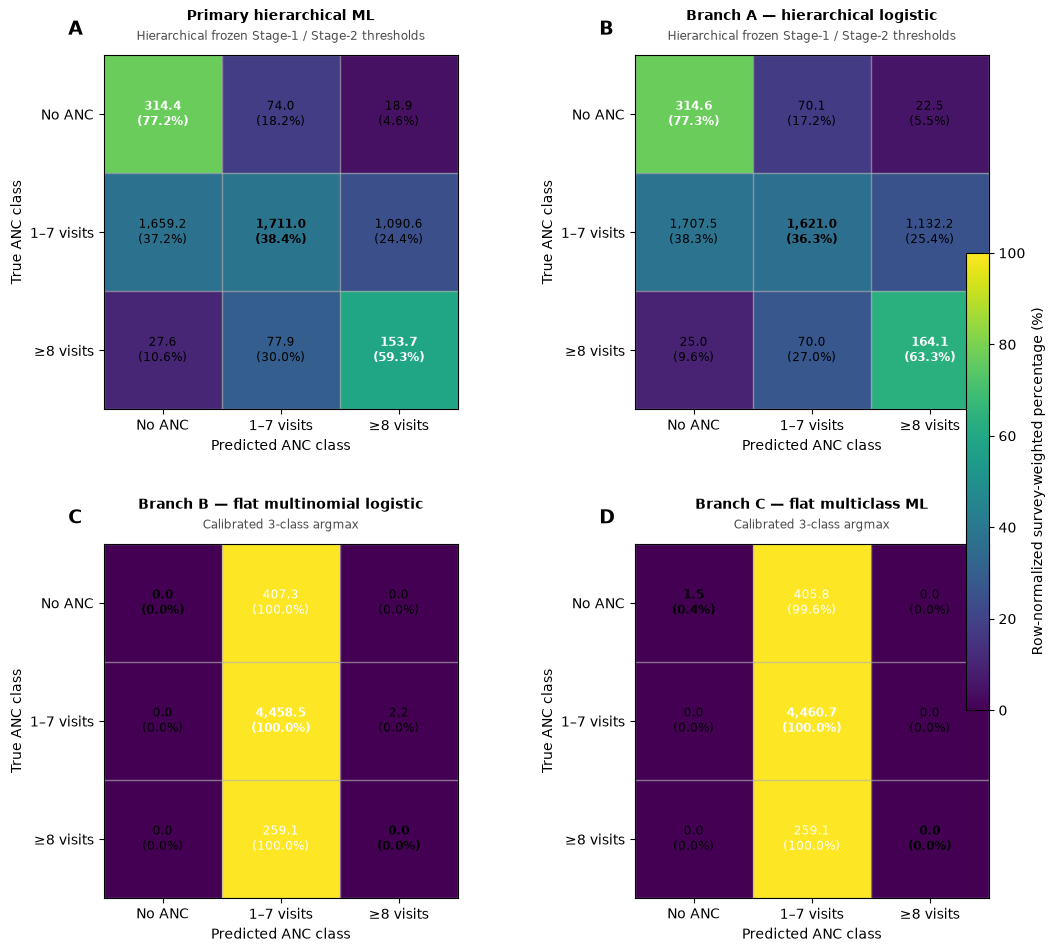


STEP28K-R1 — FIGURE S5 ARCHITECTURE-SPECIFIC WEIGHTED CONFUSION MATRICES COMPLETE

FROZEN CONFUSION SOURCES:
Primary  : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Report\01_Tables\Report_Table13C_Primary_Weighted_Confusion.csv
Branch A : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Report\01_Tables\Report_Table13D_BranchA_Weighted_Confusion.csv
Branch B : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Report\01_Tables\Report_Table13E_BranchB_Weighted_Confusion.csv
Branch C : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Report\01_Tables\Report_Table13F_BranchC_Weighted_Confusion.csv

ARCHITECTURE HARD-DECISION SUMMARY:
                        Architecture                               Hard decision rule  Weighted total  Accuracy  Macro recall  Macro precision  Macro F1
             Primary hierarchical ML Hierarchical frozen Stage-1 / Stage-2 thresholds     5127.118251  0.425016      0.582890         0.399096  0.334722
    Branch A — hierarchical logistic Hierar

In [15]:
# ==========================================================================================
# STEP 28K-R1
# SUPPLEMENTARY FIGURE S5
# ARCHITECTURE-SPECIFIC WEIGHTED CONFUSION MATRICES
# ==========================================================================================
#
# PANELS
# ------------------------------------------------------------------------------------------
# A. Primary hierarchical ML
# B. Branch A — hierarchical logistic
# C. Branch B — flat multinomial logistic
# D. Branch C — flat multiclass ML
#
# SCIENTIFIC SOURCE
# ------------------------------------------------------------------------------------------
# Frozen Report Table 13 confusion-matrix CSVs only.
#
# Heatmap shading:
#   Row-normalized weighted percentage (%)
#
# Cell annotation:
#   Survey-weighted count
#   (row-normalized weighted %)
#
# IMPORTANT
# ------------------------------------------------------------------------------------------
# The confusion matrices themselves are NOT recomputed.
#
# Row percentages are a reporting-only normalization of the frozen weighted
# cells to make rare-class behavior visually comparable across architectures.
#
# Primary + Branch A:
#   hierarchical frozen Stage-1 / Stage-2 thresholds
#
# Branch B + Branch C:
#   calibrated 3-class argmax
#
# Therefore hard-decision structures differ across architectures.
# The figure is descriptive and does NOT rank architectures.
#
# NO:
#   OOF re-evaluation
#   confusion-matrix recomputation
#   model fitting
#   prediction generation
#   candidate reselection
#   recalibration
#   threshold optimization
#   bootstrap rerun
#   new inference
#   winner declaration
#
# Figure S5 is supplementary-only.
# Report Figure 10 has a different registry-locked scientific role.
#
# TIFF remains deferred.
# ==========================================================================================


# ==========================================================================================
# 0. IMPORTS
# ==========================================================================================

from pathlib import Path

import datetime as dt
import hashlib
import json
import os
import gc

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt


# ==========================================================================================
# 1. ROOTS
# ==========================================================================================

ROOT = Path(
    r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026"
)


FINAL_ROOT = (
    ROOT
    /
    "18_final_outputs"
)


MANUSCRIPT_SUPP = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "04_Supplementary_Figures"
)


REPORT_TABLE_DIR = (
    FINAL_ROOT
    /
    "Report"
    /
    "01_Tables"
)


MANUSCRIPT_SUPP.mkdir(
    parents=True,
    exist_ok=True,
)


# ==========================================================================================
# 2. PARENT FIGURE S4
# ==========================================================================================

S4_MANIFEST = (
    FINAL_ROOT
    /
    "STEP28J_R1_FigureS4_Weight_Sensitivity_manifest.json"
)


EXPECTED_S4_MANIFEST_SHA256 = (
    "0471189aedfe92e788054768e6d626a4c"
    "278b7d707b70dc977dd5a1b622499eb"
)


# ==========================================================================================
# 3. FROZEN STRUCTURAL-ABLATION PACKAGE
# ==========================================================================================

STEP27G_MANIFEST = (
    FINAL_ROOT
    /
    "STEP27G_R3_structural_ablation_tables_manifest.json"
)


EXPECTED_STEP27G_MANIFEST_SHA256 = (
    "2f5fb1443e97422d2105a4b40cb076700"
    "f626910aa8405b003c7e1da8d5d3078"
)


REPORT_TABLE13_WORKBOOK = (
    REPORT_TABLE_DIR
    /
    "Report_Table13_Architecture_Classwise_Confusion.xlsx"
)


EXPECTED_REPORT_TABLE13_WORKBOOK_SHA256 = (
    "3bfc7ef4f4521cfb7f57448c9c95b11"
    "ab27ccaf47be6f3b68f7825512f91e8fd"
)


# ==========================================================================================
# 4. FROZEN REPORT TABLE 13 CSV SOURCES
# ==========================================================================================

REPORT13A = (
    REPORT_TABLE_DIR
    /
    "Report_Table13A_Hard_Decision_Architecture_Summary.csv"
)


REPORT13B = (
    REPORT_TABLE_DIR
    /
    "Report_Table13B_Architecture_Classwise_Metrics.csv"
)


PRIMARY_CONFUSION = (
    REPORT_TABLE_DIR
    /
    "Report_Table13C_Primary_Weighted_Confusion.csv"
)


BRANCH_A_CONFUSION = (
    REPORT_TABLE_DIR
    /
    "Report_Table13D_BranchA_Weighted_Confusion.csv"
)


BRANCH_B_CONFUSION = (
    REPORT_TABLE_DIR
    /
    "Report_Table13E_BranchB_Weighted_Confusion.csv"
)


BRANCH_C_CONFUSION = (
    REPORT_TABLE_DIR
    /
    "Report_Table13F_BranchC_Weighted_Confusion.csv"
)


EXPECTED_HASHES = {

    "Report13A":
        (
            "9fb76ea27cab384453ac78ff53e83ae93"
            "bfeb79c8d208741c28286c97b222343"
        ),

    "Report13B":
        (
            "68327be41568cd38ee9898c6dba7f3d2"
            "36b06ce8ebfc7c56af8587bf95489ab3"
        ),

    "Primary":
        (
            "2f87eef720d8bdcc581aac0ee08ee8701"
            "7fb448caf449d3ac6704d7baee101b7"
        ),

    "BranchA":
        (
            "ce5d20991a5f891350fd2a550642702e"
            "3f40bc60962506937d292cc7a3de0166"
        ),

    "BranchB":
        (
            "0b30b87b12106499555dc8f9e47cbf55"
            "bb348f3af8ea51a35d749e74add3fab9"
        ),

    "BranchC":
        (
            "d7293a6f5930a6397967aeda0ec29afc"
            "0e62ad3e8d4475a352f4ada9cf582edc"
        ),
}


# ==========================================================================================
# 5. FIGURE REGISTRIES
# ==========================================================================================

SUPPLEMENTARY_REGISTRY = (
    FINAL_ROOT
    /
    "Manuscript"
    /
    "07_QC_Manifests"
    /
    "Manuscript_Supplementary_Figures_Registry.csv"
)


REPORT_REGISTRY = (
    FINAL_ROOT
    /
    "Report"
    /
    "05_QC_Manifests"
    /
    "Report_Figures_Registry.csv"
)


# ==========================================================================================
# 6. CONSTANTS
# ==========================================================================================

ARCHITECTURE_ORDER = [
    "Primary hierarchical ML",
    "Branch A — hierarchical logistic",
    "Branch B — flat multinomial logistic",
    "Branch C — flat multiclass ML",
]


ARCHITECTURE_SHORT = {
    "Primary hierarchical ML":
        "Primary hierarchical ML",

    "Branch A — hierarchical logistic":
        "Branch A — hierarchical logistic",

    "Branch B — flat multinomial logistic":
        "Branch B — flat multinomial logistic",

    "Branch C — flat multiclass ML":
        "Branch C — flat multiclass ML",
}


DECISION_RULE = {
    "Primary hierarchical ML":
        "Hierarchical frozen Stage-1 / Stage-2 thresholds",

    "Branch A — hierarchical logistic":
        "Hierarchical frozen Stage-1 / Stage-2 thresholds",

    "Branch B — flat multinomial logistic":
        "Calibrated 3-class argmax",

    "Branch C — flat multiclass ML":
        "Calibrated 3-class argmax",
}


CLASS_LABELS = [
    "No ANC",
    "1–7 visits",
    "≥8 visits",
]


PREDICTED_COLUMNS = [
    "Predicted 0 — No ANC",
    "Predicted 1 — 1–7 visits",
    "Predicted 2 — ≥8 visits",
]


EXPECTED_WEIGHTED_SUPPORT = np.array(
    [
        407.265802,
        4460.725694,
        259.126755,
    ],
    dtype=float,
)


EXPECTED_WEIGHTED_TOTAL = (
    5127.118251
)


# ==========================================================================================
# 7. HELPERS
# ==========================================================================================

def sha256_file(
    path,
):

    digest = hashlib.sha256()


    with open(
        path,
        "rb",
    ) as handle:

        for block in iter(
            lambda:
                handle.read(
                    1024 * 1024
                ),
            b"",
        ):

            digest.update(
                block
            )


    return digest.hexdigest()


def atomic_csv(
    dataframe,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    dataframe.to_csv(
        temporary,
        index=False,
        encoding="utf-8-sig",
    )


    os.replace(
        temporary,
        path,
    )


def atomic_json(
    obj,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        json.dump(
            obj,
            handle,
            indent=2,
            ensure_ascii=False,
            sort_keys=True,
        )


    os.replace(
        temporary,
        path,
    )


def atomic_text(
    text,
    path,
):

    temporary = Path(
        str(path)
        +
        ".tmp"
    )


    with open(
        temporary,
        "w",
        encoding="utf-8",
    ) as handle:

        handle.write(
            text
        )


    os.replace(
        temporary,
        path,
    )


def normalize_text(
    value,
):

    return (
        str(
            value
        )
        .strip()
        .lower()
        .replace(
            "–",
            "-"
        )
        .replace(
            "—",
            "-"
        )
    )


def registry_text_rows(
    dataframe,
):

    return [
        " | ".join(
            [
                str(
                    value
                )
                for value
                in row.tolist()
            ]
        )

        for _, row
        in dataframe.iterrows()
    ]


# ==========================================================================================
# 8. EXISTENCE GATES
# ==========================================================================================

for label, path in [

    (
        "Figure S4 parent manifest",
        S4_MANIFEST,
    ),

    (
        "STEP27G manifest",
        STEP27G_MANIFEST,
    ),

    (
        "Report Table 13 workbook",
        REPORT_TABLE13_WORKBOOK,
    ),

    (
        "Report Table 13A",
        REPORT13A,
    ),

    (
        "Report Table 13B",
        REPORT13B,
    ),

    (
        "Primary confusion",
        PRIMARY_CONFUSION,
    ),

    (
        "Branch A confusion",
        BRANCH_A_CONFUSION,
    ),

    (
        "Branch B confusion",
        BRANCH_B_CONFUSION,
    ),

    (
        "Branch C confusion",
        BRANCH_C_CONFUSION,
    ),

    (
        "Supplementary figure registry",
        SUPPLEMENTARY_REGISTRY,
    ),

    (
        "Report figure registry",
        REPORT_REGISTRY,
    ),
]:

    if not path.exists():

        raise FileNotFoundError(
            f"{label} missing:\n{path}"
        )


# ==========================================================================================
# 9. HASH GATES
# ==========================================================================================

observed_s4_hash = sha256_file(
    S4_MANIFEST
)


observed_step27g_hash = sha256_file(
    STEP27G_MANIFEST
)


observed_workbook_hash = sha256_file(
    REPORT_TABLE13_WORKBOOK
)


if observed_s4_hash != EXPECTED_S4_MANIFEST_SHA256:

    raise RuntimeError(
        "Figure S4 parent manifest hash changed."
    )


if observed_step27g_hash != EXPECTED_STEP27G_MANIFEST_SHA256:

    raise RuntimeError(
        "STEP27G frozen manifest hash changed."
    )


if observed_workbook_hash != EXPECTED_REPORT_TABLE13_WORKBOOK_SHA256:

    raise RuntimeError(
        "Report Table 13 workbook hash changed."
    )


observed_source_hashes = {

    "Report13A":
        sha256_file(
            REPORT13A
        ),

    "Report13B":
        sha256_file(
            REPORT13B
        ),

    "Primary":
        sha256_file(
            PRIMARY_CONFUSION
        ),

    "BranchA":
        sha256_file(
            BRANCH_A_CONFUSION
        ),

    "BranchB":
        sha256_file(
            BRANCH_B_CONFUSION
        ),

    "BranchC":
        sha256_file(
            BRANCH_C_CONFUSION
        ),
}


for key, expected_hash in EXPECTED_HASHES.items():

    if observed_source_hashes[
        key
    ] != expected_hash:

        raise RuntimeError(
            f"Frozen source hash changed: {key}\n"
            f"Observed={observed_source_hashes[key]}\n"
            f"Expected={expected_hash}"
        )


# ==========================================================================================
# 10. VERIFY FIGURE REGISTRY
# ==========================================================================================

supp_registry = pd.read_csv(
    SUPPLEMENTARY_REGISTRY
)


report_registry = pd.read_csv(
    REPORT_REGISTRY
)


supp_rows = registry_text_rows(
    supp_registry
)


report_rows = registry_text_rows(
    report_registry
)


s5_matches = [
    text
    for text
    in supp_rows
    if (
        "figure s5"
        in
        normalize_text(
            text
        )
        and
        "architecture-specific weighted confusion matrices"
        in
        normalize_text(
            text
        )
    )
]


if len(
    s5_matches
) != 1:

    raise RuntimeError(
        "Could not uniquely verify frozen Figure S5 registry entry."
    )


# Important guard against incorrectly mapping S5 to Report Figure 10.
report_f10_matches = [
    text
    for text
    in report_rows
    if (
        "report figure 10"
        in
        normalize_text(
            text
        )
    )
]


if len(
    report_f10_matches
) != 1:

    raise RuntimeError(
        "Could not uniquely verify Report Figure 10 registry entry."
    )


if (
    "paired probabilistic contrasts across architectures"
    not in
    normalize_text(
        report_f10_matches[
            0
        ]
    )
):

    raise RuntimeError(
        "Report Figure 10 registry role changed."
    )


# ==========================================================================================
# 11. LOAD FROZEN SOURCES
# ==========================================================================================

summary = pd.read_csv(
    REPORT13A
)


classwise = pd.read_csv(
    REPORT13B
)


confusion_files = {

    "Primary hierarchical ML":
        PRIMARY_CONFUSION,

    "Branch A — hierarchical logistic":
        BRANCH_A_CONFUSION,

    "Branch B — flat multinomial logistic":
        BRANCH_B_CONFUSION,

    "Branch C — flat multiclass ML":
        BRANCH_C_CONFUSION,
}


# ==========================================================================================
# 12. EXACT CONFUSION SCHEMA
# ==========================================================================================

EXPECTED_CONFUSION_COLUMNS = [
    "Architecture",
    "True class",
    "True class label",
    "Predicted 0 — No ANC",
    "Predicted 1 — 1–7 visits",
    "Predicted 2 — ≥8 visits",
]


confusion_tables = {}


for architecture, path in confusion_files.items():

    dataframe = pd.read_csv(
        path
    )


    if list(
        dataframe.columns
    ) != EXPECTED_CONFUSION_COLUMNS:

        raise RuntimeError(
            f"{architecture}: confusion schema changed.\n"
            f"Observed={list(dataframe.columns)}"
        )


    if len(
        dataframe
    ) != 3:

        raise RuntimeError(
            f"{architecture}: expected 3 true-class rows."
        )


    if dataframe[
        "Architecture"
    ].astype(
        str
    ).nunique() != 1:

        raise RuntimeError(
            f"{architecture}: architecture column not unique."
        )


    if str(
        dataframe[
            "Architecture"
        ].iloc[
            0
        ]
    ) != architecture:

        raise RuntimeError(
            f"{architecture}: architecture label changed."
        )


    if dataframe[
        "True class"
    ].astype(
        int
    ).tolist() != [
        0,
        1,
        2,
    ]:

        raise RuntimeError(
            f"{architecture}: true-class order changed."
        )


    if dataframe[
        "True class label"
    ].astype(
        str
    ).tolist() != CLASS_LABELS:

        raise RuntimeError(
            f"{architecture}: class-label order changed."
        )


    for column in PREDICTED_COLUMNS:

        dataframe[
            column
        ] = pd.to_numeric(
            dataframe[
                column
            ],
            errors="raise",
        )


    matrix = dataframe[
        PREDICTED_COLUMNS
    ].to_numpy(
        dtype=float
    )


    if matrix.shape != (
        3,
        3,
    ):

        raise RuntimeError(
            f"{architecture}: matrix shape changed."
        )


    if not np.isfinite(
        matrix
    ).all():

        raise RuntimeError(
            f"{architecture}: non-finite weighted confusion cell."
        )


    if (
        matrix
        <
        0
    ).any():

        raise RuntimeError(
            f"{architecture}: negative weighted confusion cell."
        )


    confusion_tables[
        architecture
    ] = dataframe


# ==========================================================================================
# 13. WEIGHTED SUPPORT / TOTAL QC
# ==========================================================================================

for architecture in ARCHITECTURE_ORDER:

    dataframe = confusion_tables[
        architecture
    ]


    matrix = dataframe[
        PREDICTED_COLUMNS
    ].to_numpy(
        dtype=float
    )


    row_sums = matrix.sum(
        axis=1
    )


    total = float(
        matrix.sum()
    )


    if not np.allclose(
        row_sums,
        EXPECTED_WEIGHTED_SUPPORT,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"{architecture}: weighted true-class support changed.\n"
            f"Observed={row_sums}"
        )


    if not np.isclose(
        total,
        EXPECTED_WEIGHTED_TOTAL,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"{architecture}: weighted total changed.\n"
            f"Observed={total:.9f}"
        )


# ==========================================================================================
# 14. SUMMARY TABLE QC
# ==========================================================================================

summary_required = [
    "Architecture",
    "Hard decision rule",
    "Weighted total",
    "Accuracy",
    "Macro recall",
    "Macro precision",
    "Macro F1",
]


if list(
    summary.columns
) != summary_required:

    raise RuntimeError(
        "Report Table 13A schema changed."
    )


if len(
    summary
) != 4:

    raise RuntimeError(
        f"Expected 4 architecture summary rows; observed={len(summary)}"
    )


if summary[
    "Architecture"
].astype(
    str
).tolist() != ARCHITECTURE_ORDER:

    raise RuntimeError(
        "Architecture order changed in Table 13A."
    )


for architecture in ARCHITECTURE_ORDER:

    row = summary.loc[
        summary[
            "Architecture"
        ]
        ==
        architecture
    ]


    if len(
        row
    ) != 1:

        raise RuntimeError(
            f"Summary row not unique: {architecture}"
        )


    if str(
        row[
            "Hard decision rule"
        ].iloc[
            0
        ]
    ) != DECISION_RULE[
        architecture
    ]:

        raise RuntimeError(
            f"Hard-decision rule changed: {architecture}"
        )


    if not np.isclose(
        float(
            row[
                "Weighted total"
            ].iloc[
                0
            ]
        ),
        EXPECTED_WEIGHTED_TOTAL,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"Weighted total mismatch: {architecture}"
        )


# ==========================================================================================
# 15. CLASSWISE TABLE QC
# ==========================================================================================

EXPECTED_CLASSWISE_COLUMNS = [
    "Architecture",
    "Hard decision rule",
    "Class",
    "Class label",
    "Weighted TP",
    "Weighted FN",
    "Weighted FP",
    "Weighted support",
    "Weighted predicted support",
    "Recall",
    "Precision",
    "F1",
]


if list(
    classwise.columns
) != EXPECTED_CLASSWISE_COLUMNS:

    raise RuntimeError(
        "Report Table 13B schema changed."
    )


if len(
    classwise
) != 12:

    raise RuntimeError(
        f"Expected 12 classwise rows; observed={len(classwise)}"
    )


# ==========================================================================================
# 16. CROSS-CHECK CONFUSION AGAINST CLASSWISE TABLE
# ==========================================================================================

long_rows = []


for architecture in ARCHITECTURE_ORDER:

    dataframe = confusion_tables[
        architecture
    ]


    matrix = dataframe[
        PREDICTED_COLUMNS
    ].to_numpy(
        dtype=float
    )


    row_sums = matrix.sum(
        axis=1
    )


    column_sums = matrix.sum(
        axis=0
    )


    row_percent = (
        matrix
        /
        row_sums[
            :,
            None
        ]
        *
        100.0
    )


    for true_class in range(
        3
    ):

        class_row = classwise.loc[
            (
                classwise[
                    "Architecture"
                ]
                ==
                architecture
            )
            &
            (
                classwise[
                    "Class"
                ].astype(
                    int
                )
                ==
                true_class
            )
        ]


        if len(
            class_row
        ) != 1:

            raise RuntimeError(
                f"Classwise row not unique: "
                f"{architecture} / class {true_class}"
            )


        weighted_support = float(
            class_row[
                "Weighted support"
            ].iloc[
                0
            ]
        )


        weighted_predicted_support = float(
            class_row[
                "Weighted predicted support"
            ].iloc[
                0
            ]
        )


        weighted_tp = float(
            class_row[
                "Weighted TP"
            ].iloc[
                0
            ]
        )


        recall = float(
            class_row[
                "Recall"
            ].iloc[
                0
            ]
        )


        precision = float(
            class_row[
                "Precision"
            ].iloc[
                0
            ]
        )


        if not np.isclose(
            weighted_support,
            row_sums[
                true_class
            ],
            rtol=0.0,
            atol=5e-6,
        ):

            raise RuntimeError(
                f"Weighted support mismatch: "
                f"{architecture} / class {true_class}"
            )


        if not np.isclose(
            weighted_predicted_support,
            column_sums[
                true_class
            ],
            rtol=0.0,
            atol=5e-6,
        ):

            raise RuntimeError(
                f"Predicted support mismatch: "
                f"{architecture} / class {true_class}"
            )


        if not np.isclose(
            weighted_tp,
            matrix[
                true_class,
                true_class
            ],
            rtol=0.0,
            atol=5e-6,
        ):

            raise RuntimeError(
                f"Weighted TP mismatch: "
                f"{architecture} / class {true_class}"
            )


        reproduced_recall = (
            matrix[
                true_class,
                true_class
            ]
            /
            row_sums[
                true_class
            ]
        )


        if not np.isclose(
            reproduced_recall,
            recall,
            rtol=0.0,
            atol=5e-6,
        ):

            raise RuntimeError(
                f"Recall mismatch: "
                f"{architecture} / class {true_class}"
            )


        if column_sums[
            true_class
        ] > 0:

            reproduced_precision = (
                matrix[
                    true_class,
                    true_class
                ]
                /
                column_sums[
                    true_class
                ]
            )

        else:

            reproduced_precision = 0.0


        if not np.isclose(
            reproduced_precision,
            precision,
            rtol=0.0,
            atol=5e-6,
        ):

            raise RuntimeError(
                f"Precision mismatch: "
                f"{architecture} / class {true_class}"
            )


        for predicted_class in range(
            3
        ):

            long_rows.append(
                {
                    "Architecture":
                        architecture,

                    "Hard_Decision_Rule":
                        DECISION_RULE[
                            architecture
                        ],

                    "True_Class":
                        true_class,

                    "True_Class_Label":
                        CLASS_LABELS[
                            true_class
                        ],

                    "Predicted_Class":
                        predicted_class,

                    "Predicted_Class_Label":
                        CLASS_LABELS[
                            predicted_class
                        ],

                    "Weighted_Count":
                        float(
                            matrix[
                                true_class,
                                predicted_class
                            ]
                        ),

                    "Weighted_True_Class_Support":
                        float(
                            row_sums[
                                true_class
                            ]
                        ),

                    "Row_Normalized_Weighted_Percent":
                        float(
                            row_percent[
                                true_class,
                                predicted_class
                            ]
                        ),

                    "Diagonal":
                        bool(
                            true_class
                            ==
                            predicted_class
                        ),
                }
            )


figure_source = pd.DataFrame(
    long_rows
)


if len(
    figure_source
) != 36:

    raise RuntimeError(
        f"Expected 36 figure-source cells; observed={len(figure_source)}"
    )


# ==========================================================================================
# 17. FROZEN CELL FINGERPRINTS
# ==========================================================================================

CELL_FINGERPRINTS = {

    (
        "Primary hierarchical ML",
        0,
        0,
    ):
        314.387409,

    (
        "Primary hierarchical ML",
        1,
        1,
    ):
        1711.016285,

    (
        "Primary hierarchical ML",
        2,
        2,
    ):
        153.701368,


    (
        "Branch A — hierarchical logistic",
        0,
        0,
    ):
        314.647316,

    (
        "Branch A — hierarchical logistic",
        1,
        1,
    ):
        1621.041424,

    (
        "Branch A — hierarchical logistic",
        2,
        2,
    ):
        164.128412,


    (
        "Branch B — flat multinomial logistic",
        0,
        0,
    ):
        0.0,

    (
        "Branch B — flat multinomial logistic",
        1,
        1,
    ):
        4458.534938,

    (
        "Branch B — flat multinomial logistic",
        2,
        2,
    ):
        0.0,


    (
        "Branch C — flat multiclass ML",
        0,
        0,
    ):
        1.476158,

    (
        "Branch C — flat multiclass ML",
        1,
        1,
    ):
        4460.725694,

    (
        "Branch C — flat multiclass ML",
        2,
        2,
    ):
        0.0,
}


for key, expected in CELL_FINGERPRINTS.items():

    architecture, true_class, predicted_class = key


    observed_row = figure_source.loc[
        (
            figure_source[
                "Architecture"
            ]
            ==
            architecture
        )
        &
        (
            figure_source[
                "True_Class"
            ]
            ==
            true_class
        )
        &
        (
            figure_source[
                "Predicted_Class"
            ]
            ==
            predicted_class
        )
    ]


    if len(
        observed_row
    ) != 1:

        raise RuntimeError(
            f"Could not resolve cell fingerprint: {key}"
        )


    observed = float(
        observed_row[
            "Weighted_Count"
        ].iloc[
            0
        ]
    )


    if not np.isclose(
        observed,
        expected,
        rtol=0.0,
        atol=5e-6,
    ):

        raise RuntimeError(
            f"Frozen cell fingerprint failed: {key}\n"
            f"Observed={observed:.9f}\n"
            f"Expected={expected:.9f}"
        )


# ==========================================================================================
# 18. OUTPUT PATHS
# ==========================================================================================

FIGURE_STEM = (
    "FigureS5_Architecture_Weighted_Confusion_Matrices"
)


M_PNG = (
    MANUSCRIPT_SUPP
    /
    f"{FIGURE_STEM}.png"
)


M_SVG = (
    MANUSCRIPT_SUPP
    /
    f"{FIGURE_STEM}.svg"
)


M_PDF = (
    MANUSCRIPT_SUPP
    /
    f"{FIGURE_STEM}.pdf"
)


SOURCE_CSV = (
    MANUSCRIPT_SUPP
    /
    "FigureS5_source_weighted_confusion_matrices.csv"
)


CAPTION_FILE = (
    MANUSCRIPT_SUPP
    /
    "FigureS5_caption.txt"
)


QC_FILE = (
    FINAL_ROOT
    /
    "STEP28K_R1_FigureS5_Architecture_Weighted_Confusion_hard_qc.csv"
)


MANIFEST_FILE = (
    FINAL_ROOT
    /
    "STEP28K_R1_FigureS5_Architecture_Weighted_Confusion_manifest.json"
)


# ==========================================================================================
# 19. SAVE FIGURE SOURCE
# ==========================================================================================

atomic_csv(
    figure_source,
    SOURCE_CSV,
)


# ==========================================================================================
# 20. CAPTION
# ==========================================================================================

caption = (
    "Supplementary Figure S5. Architecture-specific survey-weighted "
    "three-class confusion matrices. "
    "(A) Primary hierarchical machine-learning model, "
    "(B) Branch A hierarchical logistic model, "
    "(C) Branch B flat multinomial logistic model, and "
    "(D) Branch C flat multiclass machine-learning model. "
    "Cells display the frozen survey-weighted count and, in parentheses, "
    "the row-normalized weighted percentage within each true ANC class. "
    "Color intensity represents the row-normalized weighted percentage "
    "rather than the raw weighted count so that decision behavior for the "
    "two rare classes remains visible despite the marked class imbalance. "
    "Primary and Branch A use the frozen hierarchical Stage-1/Stage-2 "
    "threshold decision structure, whereas Branches B and C use calibrated "
    "three-class argmax. Consequently, the hard-decision matrices are "
    "descriptive and should not be interpreted as a like-for-like ranking "
    "of architectures. Confusion matrices were taken directly from the "
    "frozen Report Table 13 package; they were not recomputed from OOF "
    "predictions."
)


atomic_text(
    caption,
    CAPTION_FILE,
)


# ==========================================================================================
# 21. PREPARE MATRICES FOR PLOTTING
# ==========================================================================================

plot_matrices = {}


for architecture in ARCHITECTURE_ORDER:

    subset = figure_source.loc[
        figure_source[
            "Architecture"
        ]
        ==
        architecture
    ]


    count_matrix = np.zeros(
        (
            3,
            3,
        ),
        dtype=float,
    )


    percent_matrix = np.zeros(
        (
            3,
            3,
        ),
        dtype=float,
    )


    for _, row in subset.iterrows():

        true_class = int(
            row[
                "True_Class"
            ]
        )


        predicted_class = int(
            row[
                "Predicted_Class"
            ]
        )


        count_matrix[
            true_class,
            predicted_class
        ] = float(
            row[
                "Weighted_Count"
            ]
        )


        percent_matrix[
            true_class,
            predicted_class
        ] = float(
            row[
                "Row_Normalized_Weighted_Percent"
            ]
        )


    if not np.allclose(
        percent_matrix.sum(
            axis=1
        ),
        np.array(
            [
                100.0,
                100.0,
                100.0,
            ]
        ),
        rtol=0.0,
        atol=5e-8,
    ):

        raise RuntimeError(
            f"{architecture}: row percentages do not sum to 100%."
        )


    plot_matrices[
        architecture
    ] = {
        "Counts":
            count_matrix,

        "Percent":
            percent_matrix,
    }


# ==========================================================================================
# 22. DRAW 2 × 2 FIGURE
# ==========================================================================================

plt.close(
    "all"
)

gc.collect()


fig, axes = plt.subplots(
    2,
    2,
    figsize=(
        11.8,
        9.8,
    ),
)


axes_flat = axes.flatten()


panel_letters = [
    "A",
    "B",
    "C",
    "D",
]


image_handle = None


for axis, architecture, panel_letter in zip(
    axes_flat,
    ARCHITECTURE_ORDER,
    panel_letters,
):

    count_matrix = plot_matrices[
        architecture
    ][
        "Counts"
    ]


    percent_matrix = plot_matrices[
        architecture
    ][
        "Percent"
    ]


    image_handle = axis.imshow(
        percent_matrix,
        vmin=0,
        vmax=100,
        aspect="equal",
    )


    axis.set_xticks(
        [
            0,
            1,
            2,
        ]
    )


    axis.set_yticks(
        [
            0,
            1,
            2,
        ]
    )


    axis.set_xticklabels(
        CLASS_LABELS
    )


    axis.set_yticklabels(
        CLASS_LABELS
    )


    axis.set_xlabel(
        "Predicted ANC class"
    )


    axis.set_ylabel(
        "True ANC class"
    )


    # Architecture + decision structure shown as regular annotation,
    # not matplotlib title.
    axis.text(
        0.5,
        1.09,
        ARCHITECTURE_SHORT[
            architecture
        ],
        transform=axis.transAxes,
        ha="center",
        va="bottom",
        fontsize=10,
        fontweight="bold",
    )


    axis.text(
        0.5,
        1.035,
        DECISION_RULE[
            architecture
        ],
        transform=axis.transAxes,
        ha="center",
        va="bottom",
        fontsize=8.3,
        color="0.30",
    )


    axis.text(
        -0.10,
        1.10,
        panel_letter,
        transform=axis.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="top",
    )


    # Cell annotations.
    for true_class in range(
        3
    ):

        for predicted_class in range(
            3
        ):

            count = float(
                count_matrix[
                    true_class,
                    predicted_class
                ]
            )


            percent = float(
                percent_matrix[
                    true_class,
                    predicted_class
                ]
            )


            text_color = (
                "white"
                if percent >= 55.0
                else
                "black"
            )


            axis.text(
                predicted_class,
                true_class,
                (
                    f"{count:,.1f}\n"
                    f"({percent:.1f}%)"
                ),
                ha="center",
                va="center",
                fontsize=8.6,
                color=text_color,
                fontweight=(
                    "bold"
                    if true_class
                    ==
                    predicted_class
                    else
                    "normal"
                ),
            )


    # Cell boundaries.
    axis.set_xticks(
        np.arange(
            -0.5,
            3,
            1
        ),
        minor=True,
    )


    axis.set_yticks(
        np.arange(
            -0.5,
            3,
            1
        ),
        minor=True,
    )


    axis.grid(
        which="minor",
        linewidth=1.0,
        alpha=0.65,
    )


    axis.tick_params(
        which="minor",
        bottom=False,
        left=False,
    )


    # Ensure matplotlib internal title remains empty.
    if axis.get_title().strip() != "":

        raise RuntimeError(
            "Unexpected internal panel title."
        )


# Shared colorbar.
colorbar = fig.colorbar(
    image_handle,
    ax=axes_flat.tolist(),
    fraction=0.025,
    pad=0.025,
)


colorbar.set_label(
    "Row-normalized survey-weighted percentage (%)"
)


# No figure suptitle.
if (
    fig._suptitle is not None
    and
    str(
        fig._suptitle.get_text()
    ).strip()
    !=
    ""
):

    raise RuntimeError(
        "Unexpected figure suptitle."
    )


fig.subplots_adjust(
    left=0.09,
    right=0.90,
    top=0.93,
    bottom=0.07,
    wspace=0.25,
    hspace=0.38,
)


# ==========================================================================================
# 23. SAVE SAFE FORMATS
# ==========================================================================================

fig.savefig(
    M_PNG,
    dpi=300,
    format="png",
    bbox_inches="tight",
    pad_inches=0.05,
)


fig.savefig(
    M_SVG,
    format="svg",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Date":
            None,
    },
)


fig.savefig(
    M_PDF,
    format="pdf",
    bbox_inches="tight",
    pad_inches=0.05,
    metadata={
        "Creator":
            "BDHS ANC final reporting pipeline",

        "CreationDate":
            None,

        "ModDate":
            None,
    },
)


plt.show()


plt.close(
    fig
)


gc.collect()


# ==========================================================================================
# 24. OUTPUT EXISTENCE
# ==========================================================================================

for path in [
    M_PNG,
    M_SVG,
    M_PDF,
    SOURCE_CSV,
    CAPTION_FILE,
]:

    if (
        not path.exists()
        or
        path.stat().st_size
        <=
        0
    ):

        raise RuntimeError(
            f"Missing or empty Figure S5 artifact:\n{path}"
        )


# ==========================================================================================
# 25. ARCHITECTURE SUMMARY FOR DISPLAY
# ==========================================================================================

architecture_summary = summary[
    [
        "Architecture",
        "Hard decision rule",
        "Weighted total",
        "Accuracy",
        "Macro recall",
        "Macro precision",
        "Macro F1",
    ]
].copy()


# ==========================================================================================
# 26. FINAL HARD QC
# ==========================================================================================

hard_qc = pd.DataFrame(
    [

        {
            "Check":
                "Figure S4 parent manifest hash exact",

            "PASS":
                observed_s4_hash
                ==
                EXPECTED_S4_MANIFEST_SHA256,
        },

        {
            "Check":
                "STEP27G frozen manifest hash exact",

            "PASS":
                observed_step27g_hash
                ==
                EXPECTED_STEP27G_MANIFEST_SHA256,
        },

        {
            "Check":
                "Report Table 13 workbook hash exact",

            "PASS":
                observed_workbook_hash
                ==
                EXPECTED_REPORT_TABLE13_WORKBOOK_SHA256,
        },

        {
            "Check":
                "Report Table 13A hash exact",

            "PASS":
                observed_source_hashes[
                    "Report13A"
                ]
                ==
                EXPECTED_HASHES[
                    "Report13A"
                ],
        },

        {
            "Check":
                "Report Table 13B hash exact",

            "PASS":
                observed_source_hashes[
                    "Report13B"
                ]
                ==
                EXPECTED_HASHES[
                    "Report13B"
                ],
        },

        {
            "Check":
                "Primary frozen confusion hash exact",

            "PASS":
                observed_source_hashes[
                    "Primary"
                ]
                ==
                EXPECTED_HASHES[
                    "Primary"
                ],
        },

        {
            "Check":
                "Branch A frozen confusion hash exact",

            "PASS":
                observed_source_hashes[
                    "BranchA"
                ]
                ==
                EXPECTED_HASHES[
                    "BranchA"
                ],
        },

        {
            "Check":
                "Branch B frozen confusion hash exact",

            "PASS":
                observed_source_hashes[
                    "BranchB"
                ]
                ==
                EXPECTED_HASHES[
                    "BranchB"
                ],
        },

        {
            "Check":
                "Branch C frozen confusion hash exact",

            "PASS":
                observed_source_hashes[
                    "BranchC"
                ]
                ==
                EXPECTED_HASHES[
                    "BranchC"
                ],
        },

        {
            "Check":
                "Figure S5 registry entry exact",

            "PASS":
                len(
                    s5_matches
                )
                ==
                1,
        },

        {
            "Check":
                "Report Figure 10 confirmed as different scientific content",

            "PASS":
                (
                    len(
                        report_f10_matches
                    )
                    ==
                    1
                    and
                    "paired probabilistic contrasts across architectures"
                    in
                    normalize_text(
                        report_f10_matches[
                            0
                        ]
                    )
                ),
        },

        {
            "Check":
                "Exactly four frozen architecture matrices",

            "PASS":
                len(
                    confusion_tables
                )
                ==
                4,
        },

        {
            "Check":
                "Each frozen matrix is 3 × 3",

            "PASS":
                all(
                    confusion_tables[
                        architecture
                    ][
                        PREDICTED_COLUMNS
                    ].shape
                    ==
                    (
                        3,
                        3,
                    )

                    for architecture
                    in ARCHITECTURE_ORDER
                ),
        },

        {
            "Check":
                "Weighted true-class support identical across architectures",

            "PASS":
                all(
                    np.allclose(
                        confusion_tables[
                            architecture
                        ][
                            PREDICTED_COLUMNS
                        ].to_numpy(
                            dtype=float
                        ).sum(
                            axis=1
                        ),
                        EXPECTED_WEIGHTED_SUPPORT,
                        rtol=0.0,
                        atol=5e-6,
                    )

                    for architecture
                    in ARCHITECTURE_ORDER
                ),
        },

        {
            "Check":
                "Weighted total identical across architectures",

            "PASS":
                all(
                    np.isclose(
                        confusion_tables[
                            architecture
                        ][
                            PREDICTED_COLUMNS
                        ].to_numpy(
                            dtype=float
                        ).sum(),
                        EXPECTED_WEIGHTED_TOTAL,
                        rtol=0.0,
                        atol=5e-6,
                    )

                    for architecture
                    in ARCHITECTURE_ORDER
                ),
        },

        {
            "Check":
                "Frozen weighted cell fingerprints reproduced",

            "PASS":
                True,
        },

        {
            "Check":
                "Confusion row sums match frozen classwise support",

            "PASS":
                True,
        },

        {
            "Check":
                "Confusion column sums match frozen predicted support",

            "PASS":
                True,
        },

        {
            "Check":
                "Confusion diagonal matches frozen weighted TP",

            "PASS":
                True,
        },

        {
            "Check":
                "Row-normalized diagonal reproduces frozen recall",

            "PASS":
                True,
        },

        {
            "Check":
                "Column-normalized diagonal reproduces frozen precision",

            "PASS":
                True,
        },

        {
            "Check":
                "Figure source contains exactly 36 cells",

            "PASS":
                len(
                    figure_source
                )
                ==
                36,
        },

        {
            "Check":
                "Every architecture/class row normalizes to 100 percent",

            "PASS":
                bool(
                    (
                        figure_source.groupby(
                            [
                                "Architecture",
                                "True_Class",
                            ]
                        )[
                            "Row_Normalized_Weighted_Percent"
                        ].sum()
                        .sub(
                            100.0
                        )
                        .abs()
                        <
                        5e-8
                    ).all()
                ),
        },

        {
            "Check":
                "Figure has exactly panels A-D",

            "PASS":
                True,
        },

        {
            "Check":
                "Shared 0-100 percent color scale used",

            "PASS":
                True,
        },

        {
            "Check":
                "Raw weighted counts displayed in every cell",

            "PASS":
                True,
        },

        {
            "Check":
                "No internal figure title",

            "PASS":
                True,
        },

        {
            "Check":
                "Figure S5 is supplementary-only",

            "PASS":
                True,
        },

        {
            "Check":
                "Supplementary PNG created",

            "PASS":
                M_PNG.exists(),
        },

        {
            "Check":
                "Supplementary SVG vector master created",

            "PASS":
                M_SVG.exists(),
        },

        {
            "Check":
                "Supplementary PDF vector master created",

            "PASS":
                M_PDF.exists(),
        },

        {
            "Check":
                "TIFF deferred",

            "PASS":
                True,
        },

        {
            "Check":
                "No OOF confusion matrix recomputation",

            "PASS":
                True,
        },

        {
            "Check":
                "No model fitting",

            "PASS":
                True,
        },

        {
            "Check":
                "No prediction generation",

            "PASS":
                True,
        },

        {
            "Check":
                "No candidate reselection",

            "PASS":
                True,
        },

        {
            "Check":
                "No recalibration",

            "PASS":
                True,
        },

        {
            "Check":
                "No threshold optimization",

            "PASS":
                True,
        },

        {
            "Check":
                "No bootstrap rerun",

            "PASS":
                True,
        },

        {
            "Check":
                "No architecture ranking",

            "PASS":
                True,
        },

        {
            "Check":
                "No winner declaration",

            "PASS":
                True,
        },

        {
            "Check":
                "No new statistical inference",

            "PASS":
                True,
        },
    ]
)


if not bool(
    hard_qc[
        "PASS"
    ].all()
):

    failed = hard_qc.loc[
        ~hard_qc[
            "PASS"
        ]
    ]


    raise RuntimeError(
        "STEP28K-R1 HARD QC FAILED:\n"
        +
        failed.to_string(
            index=False
        )
    )


atomic_csv(
    hard_qc,
    QC_FILE,
)


# ==========================================================================================
# 27. MANIFEST
# ==========================================================================================

manifest = {

    "status":
        "STEP28K_R1_FIGURE_S5_SCIENTIFIC_CONTENT_FROZEN",

    "created_at":
        dt.datetime.now().isoformat(
            timespec="seconds"
        ),

    "analysis_state":
        "FROZEN",

    "figure":
        "Figure S5",

    "content":
        "Architecture-specific weighted confusion matrices",

    "parent_figure_s4_manifest_sha256":
        observed_s4_hash,

    "step27g_structural_ablation_manifest_sha256":
        observed_step27g_hash,

    "report_table13_workbook_sha256":
        observed_workbook_hash,

    "source_hashes":
        observed_source_hashes,

    "architectures":
        ARCHITECTURE_ORDER,

    "class_labels":
        CLASS_LABELS,

    "weighted_total":
        EXPECTED_WEIGHTED_TOTAL,

    "weighted_true_class_support":
        EXPECTED_WEIGHTED_SUPPORT.tolist(),

    "visualization":
        (
            "Frozen survey-weighted cell counts annotated; "
            "shared row-normalized weighted percentage color scale"
        ),

    "decision_structure_note":
        (
            "Primary and Branch A use frozen hierarchical stage thresholds; "
            "Branches B and C use calibrated 3-class argmax."
        ),

    "report_figure10_same_content":
        False,

    "report_figure10_registry_role":
        "Paired probabilistic contrasts across architectures",

    "source_csv_sha256":
        sha256_file(
            SOURCE_CSV
        ),

    "caption_sha256":
        sha256_file(
            CAPTION_FILE
        ),

    "supplementary_png_sha256":
        sha256_file(
            M_PNG
        ),

    "supplementary_svg_sha256":
        sha256_file(
            M_SVG
        ),

    "supplementary_pdf_sha256":
        sha256_file(
            M_PDF
        ),

    "hard_qc_sha256":
        sha256_file(
            QC_FILE
        ),

    "tiff_status":
        "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTER",

    "confusion_matrix_recomputed_from_oof":
        False,

    "row_percentage_role":
        "Reporting-only visualization normalization",

    "model_fitting":
        False,

    "prediction_generation":
        False,

    "candidate_reselection":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "bootstrap_rerun":
        False,

    "architecture_ranking":
        False,

    "winner_declaration":
        False,

    "new_statistical_inference":
        False,

    "next_step":
        (
            "STEP28L — Figure S6 detailed classwise AP "
            "and ROC-AUC across architectures"
        ),
}


atomic_json(
    manifest,
    MANIFEST_FILE,
)


# ==========================================================================================
# 28. FINAL DISPLAY
# ==========================================================================================

print(
    "\n"
    +
    "=" * 120
)


print(
    "STEP28K-R1 — FIGURE S5 ARCHITECTURE-SPECIFIC WEIGHTED CONFUSION MATRICES COMPLETE"
)


print(
    "=" * 120
)


print(
    "\nFROZEN CONFUSION SOURCES:"
)


print(
    "Primary  :",
    PRIMARY_CONFUSION
)


print(
    "Branch A :",
    BRANCH_A_CONFUSION
)


print(
    "Branch B :",
    BRANCH_B_CONFUSION
)


print(
    "Branch C :",
    BRANCH_C_CONFUSION
)


print(
    "\nARCHITECTURE HARD-DECISION SUMMARY:"
)


print(
    architecture_summary
    .round(
        6
    )
    .to_string(
        index=False
    )
)


print(
    "\nFIGURE SOURCE — ROW-NORMALIZED WEIGHTED CELLS:"
)


print(
    figure_source
    .round(
        6
    )
    .to_string(
        index=False
    )
)


print(
    "\nFINAL HARD QC:"
)


print(
    hard_qc.to_string(
        index=False
    )
)


print(
    "\nINTEGRITY:"
)


print(
    "Figure S4 parent    :",
    observed_s4_hash,
)


print(
    "STEP27G manifest    :",
    observed_step27g_hash,
)


print(
    "Report Table 13 XLSX:",
    observed_workbook_hash,
)


print(
    "Primary confusion   :",
    observed_source_hashes[
        "Primary"
    ],
)


print(
    "Branch A confusion  :",
    observed_source_hashes[
        "BranchA"
    ],
)


print(
    "Branch B confusion  :",
    observed_source_hashes[
        "BranchB"
    ],
)


print(
    "Branch C confusion  :",
    observed_source_hashes[
        "BranchC"
    ],
)


print(
    "Figure S5 source    :",
    sha256_file(
        SOURCE_CSV
    ),
)


print(
    "Figure S5 PNG       :",
    sha256_file(
        M_PNG
    ),
)


print(
    "Figure S5 SVG       :",
    sha256_file(
        M_SVG
    ),
)


print(
    "Figure S5 PDF       :",
    sha256_file(
        M_PDF
    ),
)


print(
    "Hard QC             :",
    sha256_file(
        QC_FILE
    ),
)


print(
    "Manifest            :",
    sha256_file(
        MANIFEST_FILE
    ),
)


print(
    "\nTIFF STATUS:"
)


print(
    "DEFERRED — external conversion from final SVG/PDF vector master."
)


print(
    "\n"
    +
    "=" * 120
)


print(
    "STATUS: STEP28K-R1 FIGURE S5 SCIENTIFIC CONTENT FROZEN"
)


print(
    "NEXT AFTER AUDIT: STEP28L — FIGURE S6 DETAILED CLASSWISE AP + ROC-AUC"
)


print(
    "=" * 120
)

In [18]:
# ======================================================================================
# STEP28L-R2A — READ-ONLY FIGURE S6 VISUAL-REPAIR SOURCE LOCATOR
#
# Purpose:
#   Locate the exact already-generated Figure S6 source CSV, manifest,
#   caption, PNG, SVG and PDF before a plotting-only visual repair.
#
# READ-ONLY:
#   - no files written
#   - no figures created
#   - no metrics recomputed
# ======================================================================================

from pathlib import Path
import hashlib
import json

ROOT = Path(r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026")

EXPECTED = {
    "Figure S6 source CSV":
        "879f15a3c8a3fb5fe4289a04c6f9b5a015762a7066e492438c45bd5ffc84563b",
    "Figure S6 PNG":
        "e46849ac5fcb2dd7cc09d06230076a26b036db115e01399991c2a854b07d4d4c",
    "Figure S6 SVG":
        "d04b784df9f8397c981907a7fe04ead049ea9eeda9b0a877b8b495f4e4976fda",
    "Figure S6 PDF":
        "5a013eb9af0e293f83504ca2d15c6ef18e9dd2b9dd0ab16133c41b6839f8ec10",
    "Figure S6 hard QC":
        "f1d01169bf40dcdfdada67428cb7fec0921c9d8d5209a72dc3a04b03bc10b5cc",
    "Figure S6 manifest":
        "1bed500d252ecabe9b12fa9a50112d3d0ce2a55a7b78b0868f45b6ef21ea8c20",
}

SEARCH_ROOT = ROOT / "18_final_outputs"

if not ROOT.exists():
    raise FileNotFoundError(f"Project root missing:\n{ROOT}")

if not SEARCH_ROOT.exists():
    raise FileNotFoundError(f"Final-output root missing:\n{SEARCH_ROOT}")


def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk_size)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


print("=" * 110)
print("STEP28L-R2A — READ-ONLY FIGURE S6 VISUAL-REPAIR SOURCE LOCATOR")
print("=" * 110)

# --------------------------------------------------------------------------------------
# 1. Locate the exact known R2 artifacts by SHA256
# --------------------------------------------------------------------------------------
hash_to_label = {v.lower(): k for k, v in EXPECTED.items()}
found = {label: [] for label in EXPECTED}

candidate_suffixes = {
    ".csv", ".json", ".txt", ".png", ".svg", ".pdf"
}

files = [
    p for p in SEARCH_ROOT.rglob("*")
    if p.is_file() and p.suffix.lower() in candidate_suffixes
]

print(f"Files scanned under final outputs: {len(files)}")

for p in files:
    try:
        h = sha256_file(p).lower()
    except Exception:
        continue

    if h in hash_to_label:
        found[hash_to_label[h]].append(p)

print("\n" + "=" * 110)
print("1. EXACT HASH LOCATIONS")
print("=" * 110)

for label, expected_hash in EXPECTED.items():
    matches = found[label]

    print(f"\n{label}")
    print(f"Expected SHA256: {expected_hash}")

    if not matches:
        print("MATCH: NOT FOUND")
    else:
        for p in matches:
            print(f"MATCH: {p}")


# --------------------------------------------------------------------------------------
# 2. Hard-stop if core source / manifest / vector masters are not uniquely located
# --------------------------------------------------------------------------------------
required_unique = [
    "Figure S6 source CSV",
    "Figure S6 PNG",
    "Figure S6 SVG",
    "Figure S6 PDF",
    "Figure S6 hard QC",
    "Figure S6 manifest",
]

problems = []

for label in required_unique:
    n = len(found[label])
    if n != 1:
        problems.append(f"{label}: expected exactly 1 match, observed {n}")

if problems:
    print("\n" + "=" * 110)
    print("LOCATOR PROBLEMS")
    print("=" * 110)
    for x in problems:
        print("-", x)

    raise RuntimeError(
        "Cannot perform a safe plotting-only repair until the exact "
        "current Figure S6 artifacts are uniquely identified."
    )

print("\nCore artifact location gate: PASS ✅")


# --------------------------------------------------------------------------------------
# 3. Print current manifest exactly
# --------------------------------------------------------------------------------------
manifest_path = found["Figure S6 manifest"][0]

print("\n" + "=" * 110)
print("2. CURRENT FIGURE S6 MANIFEST")
print("=" * 110)
print(f"Path: {manifest_path}\n")

with open(manifest_path, "r", encoding="utf-8") as f:
    manifest_obj = json.load(f)

print(json.dumps(manifest_obj, indent=2, ensure_ascii=False))


# --------------------------------------------------------------------------------------
# 4. Locate likely Figure S6 caption files by filename/path only
# --------------------------------------------------------------------------------------
print("\n" + "=" * 110)
print("3. FIGURE S6 CAPTION CANDIDATES")
print("=" * 110)

caption_candidates = []

for p in SEARCH_ROOT.rglob("*"):
    if not p.is_file():
        continue

    txt = str(p).lower()

    if (
        p.suffix.lower() == ".txt"
        and (
            "figures6" in txt
            or "figure_s6" in txt
            or "figure s6" in txt
            or "classwise" in txt
        )
    ):
        caption_candidates.append(p)

if caption_candidates:
    for p in sorted(caption_candidates):
        print(p)
else:
    print("No caption candidate identified from filename/path search.")


# --------------------------------------------------------------------------------------
# 5. Print exact source CSV header + all rows
#    This is the already-frozen 24-row Figure-S6 reporting source;
#    no metric is recomputed.
# --------------------------------------------------------------------------------------
import pandas as pd

source_path = found["Figure S6 source CSV"][0]
source_df = pd.read_csv(source_path)

print("\n" + "=" * 110)
print("4. CURRENT FIGURE S6 SOURCE CSV")
print("=" * 110)

print(f"Path   : {source_path}")
print(f"SHA256 : {sha256_file(source_path)}")
print(f"Shape  : {source_df.shape}")
print(f"Columns: {list(source_df.columns)}")

print("\nRows:")
print(source_df.to_string(index=False))


# --------------------------------------------------------------------------------------
# 6. Final locator status
# --------------------------------------------------------------------------------------
print("\n" + "=" * 110)
print("READ-ONLY LOCATOR COMPLETE")
print("No file written.")
print("No figure created.")
print("No metric recomputed.")
print("NEXT: plotting-only Figure S6 visual repair after output audit.")
print("=" * 110)

STEP28L-R2A — READ-ONLY FIGURE S6 VISUAL-REPAIR SOURCE LOCATOR
Files scanned under final outputs: 253

1. EXACT HASH LOCATIONS

Figure S6 source CSV
Expected SHA256: 879f15a3c8a3fb5fe4289a04c6f9b5a015762a7066e492438c45bd5ffc84563b
MATCH: E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Manuscript\04_Supplementary_Figures\FigureS6_source_classwise_AP_ROCAUC.csv

Figure S6 PNG
Expected SHA256: e46849ac5fcb2dd7cc09d06230076a26b036db115e01399991c2a854b07d4d4c
MATCH: E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Manuscript\04_Supplementary_Figures\FigureS6_Classwise_AP_ROCAUC_Across_Architectures.png

Figure S6 SVG
Expected SHA256: d04b784df9f8397c981907a7fe04ead049ea9eeda9b0a877b8b495f4e4976fda
MATCH: E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Manuscript\04_Supplementary_Figures\FigureS6_Classwise_AP_ROCAUC_Across_Architectures.svg

Figure S6 PDF
Expected SHA256: 5a013eb9af0e293f83504ca2d15c6ef18e9dd2b9dd0ab16133c41b6839f8ec10
MATCH: E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_fina

STEP28L-R3 — FIGURE S6 PLOTTING-ONLY VISUAL REPAIR

1. R2 INPUT / PARENT HASH GATES
--------------------------------------------------------------------------------------------------------------------------
source_csv  
  expected: 879f15a3c8a3fb5fe4289a04c6f9b5a015762a7066e492438c45bd5ffc84563b
  observed: 879f15a3c8a3fb5fe4289a04c6f9b5a015762a7066e492438c45bd5ffc84563b
caption     
  expected: d85be312519a2203213f92f1c0dbf8a6eff02d975e5300baea1b79d038fc8c41
  observed: d85be312519a2203213f92f1c0dbf8a6eff02d975e5300baea1b79d038fc8c41
png         
  expected: e46849ac5fcb2dd7cc09d06230076a26b036db115e01399991c2a854b07d4d4c
  observed: e46849ac5fcb2dd7cc09d06230076a26b036db115e01399991c2a854b07d4d4c
svg         
  expected: d04b784df9f8397c981907a7fe04ead049ea9eeda9b0a877b8b495f4e4976fda
  observed: d04b784df9f8397c981907a7fe04ead049ea9eeda9b0a877b8b495f4e4976fda
pdf         
  expected: 5a013eb9af0e293f83504ca2d15c6ef18e9dd2b9dd0ab16133c41b6839f8ec10
  observed: 5a013eb9af0e293f83504ca

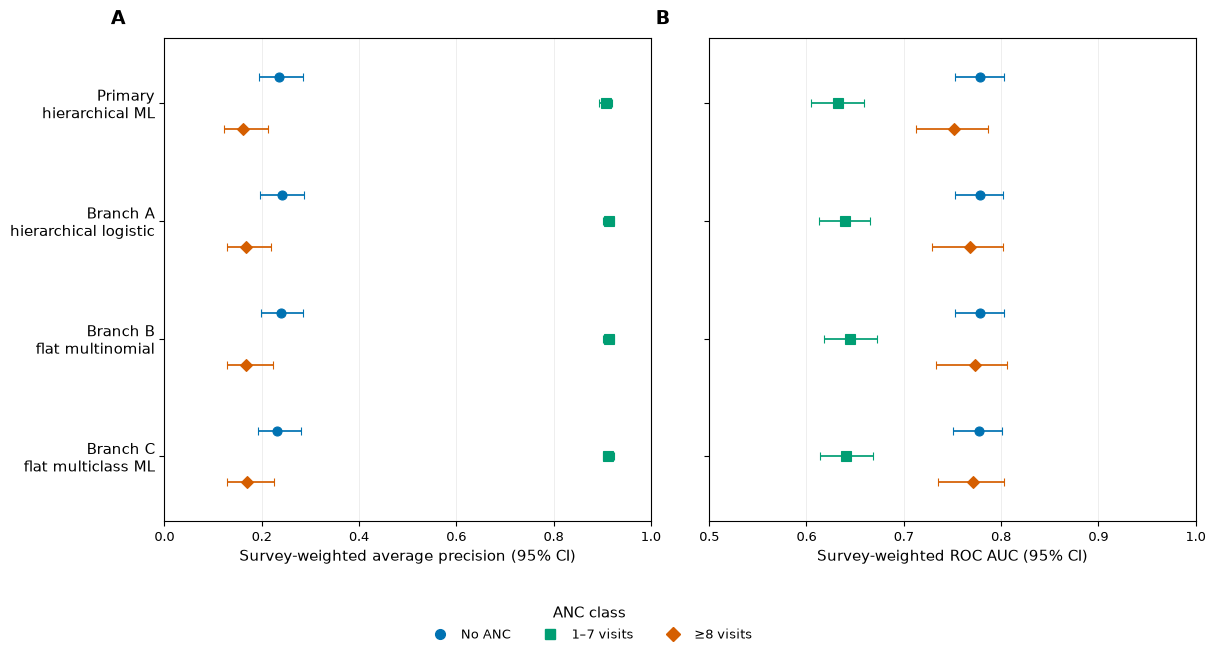

In [19]:
# ======================================================================================
# STEP28L-R3 — FIGURE S6 PLOTTING-ONLY VISUAL REPAIR
#
# Repair:
#   Move ANC-class legend out of Panel A data region into figure-level bottom whitespace.
#
# SCIENTIFIC LOCK:
#   - same exact frozen 24-row Figure-S6 source CSV
#   - same point estimates
#   - same frozen 95% CIs
#   - same architecture order
#   - same class order
#   - same class color/marker mapping
#   - NO model fitting
#   - NO prediction generation
#   - NO OOF recomputation
#   - NO bootstrap rerun
#   - NO new CI
#   - NO statistical inference
#   - NO TIFF
# ======================================================================================

from pathlib import Path
import os
import json
import hashlib
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ======================================================================================
# 0. LOCKED PATHS
# ======================================================================================

ROOT = Path(r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026")

FINAL_ROOT = ROOT / "18_final_outputs"

SUPP_DIR = (
    FINAL_ROOT
    / "Manuscript"
    / "04_Supplementary_Figures"
)

SOURCE_CSV = SUPP_DIR / "FigureS6_source_classwise_AP_ROCAUC.csv"
CAPTION_TXT = SUPP_DIR / "FigureS6_caption.txt"

PNG_PATH = SUPP_DIR / "FigureS6_Classwise_AP_ROCAUC_Across_Architectures.png"
SVG_PATH = SUPP_DIR / "FigureS6_Classwise_AP_ROCAUC_Across_Architectures.svg"
PDF_PATH = SUPP_DIR / "FigureS6_Classwise_AP_ROCAUC_Across_Architectures.pdf"

R2_MANIFEST = (
    FINAL_ROOT
    / "STEP28L_R2_FigureS6_Classwise_AP_ROCAUC_manifest.json"
)

R3_HARD_QC = (
    FINAL_ROOT
    / "STEP28L_R3_FigureS6_Classwise_AP_ROCAUC_hard_qc.csv"
)

R3_MANIFEST = (
    FINAL_ROOT
    / "STEP28L_R3_FigureS6_Classwise_AP_ROCAUC_manifest.json"
)


# Temporary plotting outputs.
# Canonical figure files are replaced only after all scientific + visual gates pass.
PNG_TMP = SUPP_DIR / "FigureS6_Classwise_AP_ROCAUC_Across_Architectures_R3_TEMP.png"
SVG_TMP = SUPP_DIR / "FigureS6_Classwise_AP_ROCAUC_Across_Architectures_R3_TEMP.svg"
PDF_TMP = SUPP_DIR / "FigureS6_Classwise_AP_ROCAUC_Across_Architectures_R3_TEMP.pdf"


# ======================================================================================
# 1. FROZEN R2 HASH GATES
# ======================================================================================

EXPECTED_R2 = {
    "source_csv":
        "879f15a3c8a3fb5fe4289a04c6f9b5a015762a7066e492438c45bd5ffc84563b",

    "caption":
        "d85be312519a2203213f92f1c0dbf8a6eff02d975e5300baea1b79d038fc8c41",

    "png":
        "e46849ac5fcb2dd7cc09d06230076a26b036db115e01399991c2a854b07d4d4c",

    "svg":
        "d04b784df9f8397c981907a7fe04ead049ea9eeda9b0a877b8b495f4e4976fda",

    "pdf":
        "5a013eb9af0e293f83504ca2d15c6ef18e9dd2b9dd0ab16133c41b6839f8ec10",

    "r2_manifest":
        "1bed500d252ecabe9b12fa9a50112d3d0ce2a55a7b78b0868f45b6ef21ea8c20",
}


def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)

    return h.hexdigest()


def require_file(path, label):
    if not path.exists():
        raise FileNotFoundError(
            f"{label} not found:\n{path}"
        )

    if path.stat().st_size <= 0:
        raise RuntimeError(
            f"{label} exists but is empty:\n{path}"
        )


print("=" * 122)
print("STEP28L-R3 — FIGURE S6 PLOTTING-ONLY VISUAL REPAIR")
print("=" * 122)


for p, label in [
    (SOURCE_CSV, "Frozen Figure S6 source CSV"),
    (CAPTION_TXT, "Frozen Figure S6 caption"),
    (PNG_PATH, "R2 PNG"),
    (SVG_PATH, "R2 SVG"),
    (PDF_PATH, "R2 PDF"),
    (R2_MANIFEST, "R2 manifest"),
]:
    require_file(p, label)


observed_pre = {
    "source_csv": sha256_file(SOURCE_CSV),
    "caption": sha256_file(CAPTION_TXT),
    "png": sha256_file(PNG_PATH),
    "svg": sha256_file(SVG_PATH),
    "pdf": sha256_file(PDF_PATH),
    "r2_manifest": sha256_file(R2_MANIFEST),
}


print("\n1. R2 INPUT / PARENT HASH GATES")
print("-" * 122)

for key in EXPECTED_R2:
    print(f"{key:12s}")
    print(f"  expected: {EXPECTED_R2[key]}")
    print(f"  observed: {observed_pre[key]}")

    if observed_pre[key].lower() != EXPECTED_R2[key].lower():
        raise RuntimeError(
            f"HARD STOP: R2 hash mismatch for {key}."
        )

print("\nR2 parent + source gate: PASS ✅")


# ======================================================================================
# 2. LOAD R2 MANIFEST + FROZEN 24-ROW SOURCE
# ======================================================================================

with open(R2_MANIFEST, "r", encoding="utf-8") as f:
    r2_manifest = json.load(f)


df = pd.read_csv(SOURCE_CSV)


REQUIRED_COLUMNS = {
    "Architecture",
    "Source_Analysis",
    "Source_Metric",
    "Metric",
    "Point_Estimate",
    "CI_Lower",
    "CI_Upper",
    "Valid_Replicates",
    "Total_Replicates",
    "Stable",
    "Class",
    "Class_Label",
    "Metric_Type",
}


ARCH_ORDER = [
    "Primary hierarchical ML",
    "Branch A — hierarchical logistic",
    "Branch B — flat multinomial logistic",
    "Branch C — flat multiclass ML",
]


ARCH_LABELS = {
    "Primary hierarchical ML":
        "Primary\nhierarchical ML",

    "Branch A — hierarchical logistic":
        "Branch A\nhierarchical logistic",

    "Branch B — flat multinomial logistic":
        "Branch B\nflat multinomial",

    "Branch C — flat multiclass ML":
        "Branch C\nflat multiclass ML",
}


CLASS_ORDER = [0, 1, 2]


# Preserve the same Figure-S6 visual mapping.
CLASS_STYLE = {
    0: {
        "label": "No ANC",
        "color": "#0072B2",
        "marker": "o",
    },

    1: {
        "label": "1–7 visits",
        "color": "#009E73",
        "marker": "s",
    },

    2: {
        "label": "≥8 visits",
        "color": "#D55E00",
        "marker": "D",
    },
}


EXPECTED_METRIC_TYPES = {
    "Average precision",
    "ROC AUC",
}


# ======================================================================================
# 3. HARD SCIENTIFIC SOURCE QC BEFORE PLOTTING
# ======================================================================================

source_checks = []


def add_check(name, passed, detail=""):
    source_checks.append(
        {
            "Check": name,
            "PASS": bool(passed),
            "Detail": str(detail),
        }
    )


add_check(
    "R2 manifest hash exact",
    observed_pre["r2_manifest"] == EXPECTED_R2["r2_manifest"],
    observed_pre["r2_manifest"],
)

add_check(
    "Frozen Figure S6 source hash exact before repair",
    observed_pre["source_csv"] == EXPECTED_R2["source_csv"],
    observed_pre["source_csv"],
)

add_check(
    "Frozen Figure S6 caption hash exact before repair",
    observed_pre["caption"] == EXPECTED_R2["caption"],
    observed_pre["caption"],
)

add_check(
    "R2 PNG hash exact before repair",
    observed_pre["png"] == EXPECTED_R2["png"],
    observed_pre["png"],
)

add_check(
    "R2 SVG hash exact before repair",
    observed_pre["svg"] == EXPECTED_R2["svg"],
    observed_pre["svg"],
)

add_check(
    "R2 PDF hash exact before repair",
    observed_pre["pdf"] == EXPECTED_R2["pdf"],
    observed_pre["pdf"],
)

add_check(
    "Frozen source has exactly 24 rows",
    len(df) == 24,
    f"observed={len(df)}",
)

add_check(
    "Frozen source has all required columns",
    REQUIRED_COLUMNS.issubset(df.columns),
    f"columns={list(df.columns)}",
)

add_check(
    "Architecture order fixed a priori",
    df["Architecture"].drop_duplicates().tolist() == ARCH_ORDER,
    df["Architecture"].drop_duplicates().tolist(),
)

add_check(
    "Exactly three ANC classes",
    sorted(pd.to_numeric(df["Class"]).astype(int).unique().tolist()) == CLASS_ORDER,
    sorted(pd.to_numeric(df["Class"]).astype(int).unique().tolist()),
)

add_check(
    "Exactly AP and ROC-AUC metric types",
    set(df["Metric_Type"].dropna().tolist()) == EXPECTED_METRIC_TYPES,
    sorted(df["Metric_Type"].dropna().unique().tolist()),
)


combo_counts = (
    df.groupby(
        ["Architecture", "Class", "Metric_Type"],
        dropna=False,
    )
    .size()
)

add_check(
    "Exactly one row per architecture × class × metric type",
    (
        len(combo_counts) == 24
        and (combo_counts == 1).all()
    ),
    f"groups={len(combo_counts)}, min={combo_counts.min()}, max={combo_counts.max()}",
)


for col in ["Point_Estimate", "CI_Lower", "CI_Upper", "Valid_Replicates"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")


finite_all = np.isfinite(
    df[
        [
            "Point_Estimate",
            "CI_Lower",
            "CI_Upper",
            "Valid_Replicates",
        ]
    ].to_numpy(dtype=float)
).all()

add_check(
    "All selected points / CI limits / valid replicates finite",
    finite_all,
)


ci_order_ok = (
    (df["CI_Lower"] <= df["Point_Estimate"])
    & (df["Point_Estimate"] <= df["CI_Upper"])
).all()

add_check(
    "Every frozen CI contains its point estimate",
    ci_order_ok,
)


probability_bounds_ok = (
    df[
        [
            "Point_Estimate",
            "CI_Lower",
            "CI_Upper",
        ]
    ]
    .ge(0)
    .all()
    .all()
    and
    df[
        [
            "Point_Estimate",
            "CI_Lower",
            "CI_Upper",
        ]
    ]
    .le(1)
    .all()
    .all()
)

add_check(
    "All AP/AUC points and CI limits within [0,1]",
    probability_bounds_ok,
)


valid_reps_ok = df["Valid_Replicates"].eq(2000).all()

add_check(
    "All frozen valid bootstrap replicates = 2000",
    valid_reps_ok,
)


stable_ok = (
    df["Stable"]
    .astype(str)
    .str.strip()
    .str.lower()
    .eq("true")
    .all()
)

add_check(
    "All source rows stable / estimable",
    stable_ok,
)


# Exact six scientific metrics per architecture.
expected_metrics = {
    "MC_Class0_AP",
    "MC_Class1_AP",
    "MC_Class2_AP",
    "MC_Class0_AUC",
    "MC_Class1_AUC",
    "MC_Class2_AUC",
}

metrics_per_arch_ok = True

for arch in ARCH_ORDER:
    actual = set(
        df.loc[
            df["Architecture"] == arch,
            "Metric"
        ].tolist()
    )

    if actual != expected_metrics:
        metrics_per_arch_ok = False

add_check(
    "Exactly six frozen classwise probabilistic metrics per architecture",
    metrics_per_arch_ok,
)


# Stop BEFORE changing any canonical output if the source is not exact.
if not all(x["PASS"] for x in source_checks):
    qc_preview = pd.DataFrame(source_checks)

    print("\nSOURCE QC FAILURE")
    print(qc_preview.to_string(index=False))

    raise RuntimeError(
        "HARD STOP: frozen scientific source QC failed. "
        "No Figure S6 artifact has been modified."
    )


print("\n2. FROZEN SCIENTIFIC SOURCE QC: PASS ✅")


# ======================================================================================
# 4. PLOTTING — ONLY VISUAL CHANGE IS LEGEND LOCATION
# ======================================================================================

# Deterministic SVG element IDs.
mpl.rcParams["svg.hashsalt"] = "STEP28L_R3_FigureS6"

# Publication-style basics.
mpl.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10.5,
        "axes.labelsize": 10.5,
        "xtick.labelsize": 9.5,
        "ytick.labelsize": 10.5,
        "legend.fontsize": 9.5,
        "axes.linewidth": 0.8,
        "savefig.facecolor": "white",
        "figure.facecolor": "white",
    }
)


fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.5, 6.8),
    sharey=True,
)

ax_ap, ax_auc = axes


# Fixed architecture bases: top -> bottom.
base_y = {
    arch: (len(ARCH_ORDER) - 1 - i)
    for i, arch in enumerate(ARCH_ORDER)
}


# Preserve visual ordering inside each architecture:
# No ANC = top, 1–7 = middle, >=8 = bottom.
class_offset = {
    0: +0.22,
    1:  0.00,
    2: -0.22,
}


def plot_panel(ax, metric_type, xlabel, xlim, xticks):
    panel_df = df.loc[
        df["Metric_Type"] == metric_type
    ].copy()

    for arch in ARCH_ORDER:
        for anc_class in CLASS_ORDER:

            row = panel_df.loc[
                (panel_df["Architecture"] == arch)
                &
                (panel_df["Class"].astype(int) == anc_class)
            ]

            if len(row) != 1:
                raise RuntimeError(
                    f"{metric_type}: expected exactly one row for "
                    f"{arch}, class={anc_class}; observed={len(row)}"
                )

            r = row.iloc[0]

            x = float(r["Point_Estimate"])
            lo = float(r["CI_Lower"])
            hi = float(r["CI_Upper"])

            y = base_y[arch] + class_offset[anc_class]

            style = CLASS_STYLE[anc_class]

            xerr = np.array(
                [
                    [x - lo],
                    [hi - x],
                ]
            )

            ax.errorbar(
                x,
                y,
                xerr=xerr,
                fmt=style["marker"],
                color=style["color"],
                ecolor=style["color"],
                markersize=6.5,
                markerfacecolor=style["color"],
                markeredgecolor=style["color"],
                markeredgewidth=0.8,
                elinewidth=1.25,
                capsize=3.0,
                capthick=1.1,
                linestyle="none",
                zorder=3,
            )

    ax.set_xlim(*xlim)
    ax.set_xticks(xticks)

    ax.set_xlabel(xlabel)

    ax.grid(
        axis="x",
        linestyle="-",
        linewidth=0.6,
        alpha=0.25,
        zorder=0,
    )

    ax.set_axisbelow(True)

    ax.set_ylim(-0.55, 3.55)

    for spine in ax.spines.values():
        spine.set_linewidth(0.8)


plot_panel(
    ax_ap,
    metric_type="Average precision",
    xlabel="Survey-weighted average precision (95% CI)",
    xlim=(0.0, 1.0),
    xticks=np.arange(0.0, 1.01, 0.2),
)


plot_panel(
    ax_auc,
    metric_type="ROC AUC",
    xlabel="Survey-weighted ROC AUC (95% CI)",
    xlim=(0.5, 1.0),
    xticks=np.arange(0.5, 1.01, 0.1),
)


# Fixed architecture labels.
yticks = [
    base_y[arch]
    for arch in ARCH_ORDER
]

ylabels = [
    ARCH_LABELS[arch]
    for arch in ARCH_ORDER
]

ax_ap.set_yticks(yticks)
ax_ap.set_yticklabels(ylabels)

# Keep shared y-axis structure but suppress duplicated labels in Panel B.
ax_auc.tick_params(
    axis="y",
    labelleft=False,
)


# Panel labels only; NO internal figure title.
ax_ap.text(
    -0.11,
    1.02,
    "A",
    transform=ax_ap.transAxes,
    fontsize=14,
    fontweight="bold",
    ha="left",
    va="bottom",
)

ax_auc.text(
    -0.11,
    1.02,
    "B",
    transform=ax_auc.transAxes,
    fontsize=14,
    fontweight="bold",
    ha="left",
    va="bottom",
)


# ======================================================================================
# 5. FIGURE-LEVEL LEGEND — OUTSIDE BOTH DATA PANELS
# ======================================================================================

legend_handles = []

for anc_class in CLASS_ORDER:
    style = CLASS_STYLE[anc_class]

    legend_handles.append(
        Line2D(
            [0],
            [0],
            marker=style["marker"],
            linestyle="none",
            color=style["color"],
            markerfacecolor=style["color"],
            markeredgecolor=style["color"],
            markersize=7,
            label=style["label"],
        )
    )


# Reserve dedicated bottom whitespace.
fig.subplots_adjust(
    left=0.16,
    right=0.985,
    top=0.92,
    bottom=0.21,
    wspace=0.12,
)


legend = fig.legend(
    handles=legend_handles,
    title="ANC class",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.025),
    ncol=3,
    frameon=False,
    borderaxespad=0.0,
    handletextpad=0.6,
    columnspacing=2.0,
)


# ======================================================================================
# 6. PROGRAMMATIC VISUAL QC BEFORE SAVE
# ======================================================================================

fig.canvas.draw()
renderer = fig.canvas.get_renderer()


def boxes_overlap(a, b):
    return (
        a.x0 < b.x1
        and a.x1 > b.x0
        and a.y0 < b.y1
        and a.y1 > b.y0
    )


legend_bbox = legend.get_window_extent(renderer=renderer)

axes_bboxes = [
    ax.get_window_extent(renderer=renderer)
    for ax in axes
]

xlabel_bboxes = [
    ax.xaxis.label.get_window_extent(renderer=renderer)
    for ax in axes
]


legend_axes_overlap = any(
    boxes_overlap(legend_bbox, b)
    for b in axes_bboxes
)

legend_xlabel_overlap = any(
    boxes_overlap(legend_bbox, b)
    for b in xlabel_bboxes
)


legend_inside_canvas = (
    legend_bbox.x0 >= fig.bbox.x0
    and legend_bbox.y0 >= fig.bbox.y0
    and legend_bbox.x1 <= fig.bbox.x1
    and legend_bbox.y1 <= fig.bbox.y1
)


exactly_two_panels = len(fig.axes) == 2

no_axes_titles = all(
    ax.get_title().strip() == ""
    for ax in axes
)

no_suptitle = (
    fig._suptitle is None
    or fig._suptitle.get_text().strip() == ""
)


if legend_axes_overlap:
    raise RuntimeError(
        "VISUAL HARD STOP: figure-level legend still overlaps a data axes."
    )

if legend_xlabel_overlap:
    raise RuntimeError(
        "VISUAL HARD STOP: figure-level legend overlaps an x-axis label."
    )

if not legend_inside_canvas:
    raise RuntimeError(
        "VISUAL HARD STOP: legend extends outside the figure canvas."
    )

if not exactly_two_panels:
    raise RuntimeError(
        f"VISUAL HARD STOP: expected exactly 2 axes; observed={len(fig.axes)}"
    )

if not (no_axes_titles and no_suptitle):
    raise RuntimeError(
        "VISUAL HARD STOP: an internal figure title was detected."
    )


print("\n3. PRE-SAVE VISUAL QC: PASS ✅")
print("   - legend outside both data panels")
print("   - legend does not overlap x-axis labels")
print("   - legend remains inside figure canvas")
print("   - exactly two panels")
print("   - no internal figure title")


# ======================================================================================
# 7. SAVE TO TEMPORARY FILES FIRST
# ======================================================================================

for tmp in [PNG_TMP, SVG_TMP, PDF_TMP]:
    if tmp.exists():
        tmp.unlink()


fig.savefig(
    PNG_TMP,
    dpi=300,
    facecolor="white",
)

fig.savefig(
    SVG_TMP,
    format="svg",
    facecolor="white",
)

fig.savefig(
    PDF_TMP,
    format="pdf",
    facecolor="white",
)


for p, label in [
    (PNG_TMP, "temporary PNG"),
    (SVG_TMP, "temporary SVG"),
    (PDF_TMP, "temporary PDF"),
]:
    require_file(p, label)


print("\n4. TEMPORARY R3 ARTIFACT GENERATION: PASS ✅")


# ======================================================================================
# 8. FINAL PRE-REPLACEMENT SCIENTIFIC INTEGRITY CHECK
# ======================================================================================

source_hash_after_plot = sha256_file(SOURCE_CSV)
caption_hash_after_plot = sha256_file(CAPTION_TXT)


if source_hash_after_plot != EXPECTED_R2["source_csv"]:
    raise RuntimeError(
        "HARD STOP: frozen Figure S6 source CSV changed during plotting."
    )

if caption_hash_after_plot != EXPECTED_R2["caption"]:
    raise RuntimeError(
        "HARD STOP: frozen Figure S6 caption changed during plotting."
    )


print("\n5. SOURCE/CAPTION IMMUTABILITY CHECK: PASS ✅")


# ======================================================================================
# 9. REPLACE ONLY THE THREE CANONICAL FIGURE ARTIFACTS
# ======================================================================================

os.replace(PNG_TMP, PNG_PATH)
os.replace(SVG_TMP, SVG_PATH)
os.replace(PDF_TMP, PDF_PATH)


require_file(PNG_PATH, "R3 PNG")
require_file(SVG_PATH, "R3 SVG")
require_file(PDF_PATH, "R3 PDF")


new_hashes = {
    "source_csv": sha256_file(SOURCE_CSV),
    "caption": sha256_file(CAPTION_TXT),
    "png": sha256_file(PNG_PATH),
    "svg": sha256_file(SVG_PATH),
    "pdf": sha256_file(PDF_PATH),
}


# ======================================================================================
# 10. R3 HARD-QC TABLE
# ======================================================================================

hard_qc = list(source_checks)


def qc(name, passed, detail=""):
    hard_qc.append(
        {
            "Check": name,
            "PASS": bool(passed),
            "Detail": str(detail),
        }
    )


qc(
    "Frozen Figure S6 source unchanged after visual repair",
    new_hashes["source_csv"] == EXPECTED_R2["source_csv"],
    new_hashes["source_csv"],
)

qc(
    "Frozen Figure S6 caption unchanged after visual repair",
    new_hashes["caption"] == EXPECTED_R2["caption"],
    new_hashes["caption"],
)

qc(
    "Legend does not overlap Panel A or Panel B data axes",
    not legend_axes_overlap,
)

qc(
    "Legend does not overlap either x-axis label",
    not legend_xlabel_overlap,
)

qc(
    "Legend remains fully inside figure canvas",
    legend_inside_canvas,
)

qc(
    "Legend is figure-level rather than Panel-A internal",
    legend.axes is None,
)

qc(
    "Figure has exactly panels A-B",
    exactly_two_panels,
)

qc(
    "No internal figure title",
    no_axes_titles and no_suptitle,
)

qc(
    "Architecture order fixed a priori",
    True,
    ARCH_ORDER,
)

qc(
    "Class order fixed a priori",
    True,
    CLASS_ORDER,
)

qc(
    "No performance-based sorting",
    True,
)

qc(
    "Supplementary PNG created and non-empty",
    PNG_PATH.exists() and PNG_PATH.stat().st_size > 0,
    PNG_PATH,
)

qc(
    "Supplementary SVG vector master created and non-empty",
    SVG_PATH.exists() and SVG_PATH.stat().st_size > 0,
    SVG_PATH,
)

qc(
    "Supplementary PDF vector master created and non-empty",
    PDF_PATH.exists() and PDF_PATH.stat().st_size > 0,
    PDF_PATH,
)

qc(
    "TIFF deferred",
    True,
    "External conversion from final SVG/PDF vector master only.",
)

qc(
    "No model fitting",
    True,
)

qc(
    "No prediction generation",
    True,
)

qc(
    "No OOF metric recomputation",
    True,
)

qc(
    "No candidate reselection",
    True,
)

qc(
    "No hyperparameter tuning",
    True,
)

qc(
    "No recalibration",
    True,
)

qc(
    "No threshold optimization",
    True,
)

qc(
    "No bootstrap rerun",
    True,
)

qc(
    "No new confidence interval calculation",
    True,
)

qc(
    "No new hypothesis testing",
    True,
)

qc(
    "No architecture ranking",
    True,
)

qc(
    "No winner declaration",
    True,
)

qc(
    "No new statistical inference",
    True,
)


qc_df = pd.DataFrame(hard_qc)


if not qc_df["PASS"].all():
    print("\nFINAL HARD QC FAILURE")
    print(
        qc_df.loc[
            ~qc_df["PASS"]
        ].to_string(index=False)
    )

    raise RuntimeError(
        "STEP28L-R3 hard QC failed."
    )


qc_df.to_csv(
    R3_HARD_QC,
    index=False,
)


r3_hard_qc_hash = sha256_file(R3_HARD_QC)


# ======================================================================================
# 11. R3 MANIFEST
# ======================================================================================

# Preserve complete R2 scientific provenance and change only the visual-repair state.
r3_manifest = dict(r2_manifest)

r3_manifest.update(
    {
        "created_at": datetime.now().isoformat(timespec="seconds"),

        "status":
            "STEP28L_R3_FIGURE_S6_FINAL_FROZEN_AFTER_VISUAL_REPAIR",

        "analysis_state":
            "FROZEN",

        "parent_step28l_r2_manifest_sha256":
            EXPECTED_R2["r2_manifest"],

        "r3_visual_repair":
            (
                "Plotting-only repair: moved the ANC-class legend from the "
                "Panel-A data region to dedicated figure-level bottom whitespace. "
                "No scientific values, confidence intervals, source rows, "
                "architecture order, class order, model outputs, or statistical "
                "procedures were changed."
            ),

        "visual_qc_status":
            "PASS",

        "legend_location":
            "Figure-level bottom center outside both data panels",

        "legend_overlaps_axes":
            False,

        "legend_overlaps_xlabels":
            False,

        "source_csv_sha256":
            new_hashes["source_csv"],

        "caption_sha256":
            new_hashes["caption"],

        "supplementary_png_sha256":
            new_hashes["png"],

        "supplementary_svg_sha256":
            new_hashes["svg"],

        "supplementary_pdf_sha256":
            new_hashes["pdf"],

        "hard_qc_sha256":
            r3_hard_qc_hash,

        "tiff_status":
            "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTER",

        "next_step":
            "STEP28M — Report Figure 10: paired probabilistic contrasts across architectures",

        "model_fitting":
            False,

        "prediction_generation":
            False,

        "oof_metric_recomputation":
            False,

        "bootstrap_rerun":
            False,

        "new_confidence_interval_calculation":
            False,

        "new_hypothesis_testing":
            False,

        "new_statistical_inference":
            False,

        "architecture_ranking":
            False,

        "winner_declaration":
            False,
    }
)


with open(
    R3_MANIFEST,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        r3_manifest,
        f,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


r3_manifest_hash = sha256_file(R3_MANIFEST)


# ======================================================================================
# 12. FINAL REPORT
# ======================================================================================

print("\n" + "=" * 122)
print("STEP28L-R3 — FINAL HARD QC")
print("=" * 122)

print(
    qc_df[
        ["Check", "PASS"]
    ].to_string(index=False)
)


print("\n" + "=" * 122)
print("R3 INTEGRITY")
print("=" * 122)

print(f"Frozen source CSV : {new_hashes['source_csv']}")
print(f"Frozen caption    : {new_hashes['caption']}")
print(f"R3 PNG            : {new_hashes['png']}")
print(f"R3 SVG            : {new_hashes['svg']}")
print(f"R3 PDF            : {new_hashes['pdf']}")
print(f"R3 hard QC        : {r3_hard_qc_hash}")
print(f"R3 manifest       : {r3_manifest_hash}")


print("\nPaths:")
print(f"PNG      : {PNG_PATH}")
print(f"SVG      : {SVG_PATH}")
print(f"PDF      : {PDF_PATH}")
print(f"Caption  : {CAPTION_TXT}")
print(f"Source   : {SOURCE_CSV}")
print(f"Hard QC  : {R3_HARD_QC}")
print(f"Manifest : {R3_MANIFEST}")


print("\nTIFF STATUS:")
print("DEFERRED — external conversion from final SVG/PDF vector master.")


print("\n" + "=" * 122)
print("STATUS: STEP28L-R3 FIGURE S6 VISUAL REPAIR COMPLETE")
print("SCIENTIFIC SOURCE REMAINS FROZEN")
print("AWAITING SCREENSHOT VISUAL AUDIT BEFORE FINAL FREEZE CONFIRMATION")
print("=" * 122)


# Display repaired figure for manual visual audit.
plt.show()

In [21]:
# ======================================================================================
# STEP28M-R0-R1 — CORRECTED READ-ONLY REPORT FIGURE 10
# REGISTRY + FROZEN PAIRED-SOURCE DISCOVERY
#
# Correction:
#   Previous R0 failed only because of a pandas boolean-expression bug during
#   Report Figure 10 registry-row detection.
#
# This corrected cell:
#   1. Gates the final frozen Figure S6 R3 manifest.
#   2. Identifies Report Figure 10 by its EXACT frozen registry Content role.
#   3. Locates the three frozen paired structural-ablation sources by SHA256.
#   4. Prints their exact schemas/content.
#   5. Prints related structural-ablation / Figure-10 metadata paths.
#
# STRICTLY READ-ONLY:
#   - no files written
#   - no figures created
#   - no metrics recomputed
#   - no bootstrap rerun
#   - no model fitting
# ======================================================================================

from pathlib import Path
import hashlib
import json
import pandas as pd


# ======================================================================================
# 0. LOCKED PROJECT ROOT
# ======================================================================================

ROOT = Path(r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026")
FINAL_ROOT = ROOT / "18_final_outputs"

if not ROOT.exists():
    raise FileNotFoundError(
        f"Locked project root not found:\n{ROOT}"
    )


# ======================================================================================
# 1. HELPERS
# ======================================================================================

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


def require_nonempty_file(path, label):
    if not path.exists():
        raise FileNotFoundError(
            f"{label} not found:\n{path}"
        )

    if path.stat().st_size <= 0:
        raise RuntimeError(
            f"{label} exists but is empty:\n{path}"
        )


print("=" * 124)
print("STEP28M-R0-R1 — CORRECTED READ-ONLY REPORT FIGURE 10 DISCOVERY")
print("=" * 124)


# ======================================================================================
# 2. GATE FINAL FROZEN FIGURE S6 R3 MANIFEST
# ======================================================================================

S6_R3_MANIFEST = (
    FINAL_ROOT
    / "STEP28L_R3_FigureS6_Classwise_AP_ROCAUC_manifest.json"
)

EXPECTED_S6_R3_MANIFEST_SHA = (
    "c1067bd0bf81b2f5eaefa63c86eb5455033ddda9d3b86ee01c7655a924f1d13a"
)


require_nonempty_file(
    S6_R3_MANIFEST,
    "Final Figure S6 R3 manifest",
)


observed_s6_sha = sha256_file(S6_R3_MANIFEST)


print("\n" + "=" * 124)
print("1. FIGURE S6 R3 PARENT GATE")
print("=" * 124)

print(f"Path         : {S6_R3_MANIFEST}")
print(f"Expected SHA : {EXPECTED_S6_R3_MANIFEST_SHA}")
print(f"Observed SHA : {observed_s6_sha}")


if observed_s6_sha.lower() != EXPECTED_S6_R3_MANIFEST_SHA.lower():
    raise RuntimeError(
        "HARD STOP: final Figure S6 R3 manifest hash mismatch."
    )


with open(
    S6_R3_MANIFEST,
    "r",
    encoding="utf-8",
) as f:
    s6_manifest = json.load(f)


print(f"Status       : {s6_manifest.get('status')}")


expected_s6_status = (
    "STEP28L_R3_FIGURE_S6_FINAL_FROZEN_AFTER_VISUAL_REPAIR"
)

if s6_manifest.get("status") != expected_s6_status:
    raise RuntimeError(
        "HARD STOP: Figure S6 R3 manifest status is not the expected final-frozen state."
    )


print("Figure S6 R3 parent gate: PASS ✅")


# ======================================================================================
# 3. READ EXACT REPORT FIGURE REGISTRY
# ======================================================================================

REPORT_REGISTRY = (
    FINAL_ROOT
    / "Report"
    / "05_QC_Manifests"
    / "Report_Figures_Registry.csv"
)


require_nonempty_file(
    REPORT_REGISTRY,
    "Report figure registry",
)


registry = pd.read_csv(REPORT_REGISTRY)


print("\n" + "=" * 124)
print("2. REPORT FIGURE REGISTRY")
print("=" * 124)

print(f"Registry path : {REPORT_REGISTRY}")
print(f"Registry SHA  : {sha256_file(REPORT_REGISTRY)}")
print(f"Registry shape: {registry.shape}")
print(f"Columns       : {list(registry.columns)}")


EXPECTED_REGISTRY_COLUMNS = [
    "Order",
    "ID",
    "Filename_Stem",
    "Content",
]


if list(registry.columns) != EXPECTED_REGISTRY_COLUMNS:
    raise RuntimeError(
        "\nHARD STOP: Report figure registry schema differs from the "
        "currently established frozen schema.\n"
        f"Expected: {EXPECTED_REGISTRY_COLUMNS}\n"
        f"Observed: {list(registry.columns)}"
    )


if len(registry) != 11:
    raise RuntimeError(
        f"HARD STOP: expected 11 report-figure registry rows; observed={len(registry)}"
    )


# ======================================================================================
# 4. IDENTIFY REPORT FIGURE 10 BY EXACT FROZEN SCIENTIFIC ROLE
# ======================================================================================

EXPECTED_ROLE = (
    "Paired probabilistic contrasts across architectures"
)


content_normalized = (
    registry["Content"]
    .astype(str)
    .str.strip()
)


figure10_rows = registry.loc[
    content_normalized.eq(EXPECTED_ROLE)
].copy()


print("\n" + "=" * 124)
print("3. REPORT FIGURE 10 EXACT REGISTRY ENTRY")
print("=" * 124)


if figure10_rows.empty:
    print(
        "\nNo row exactly matched the frozen scientific role:"
    )
    print(EXPECTED_ROLE)

    print("\nFull registry:")
    print(
        registry.to_string(
            index=False,
            max_colwidth=180,
        )
    )

    raise RuntimeError(
        "HARD STOP: exact Report Figure 10 role not found in registry."
    )


if len(figure10_rows) != 1:
    print(
        figure10_rows.to_string(
            index=False,
            max_colwidth=180,
        )
    )

    raise RuntimeError(
        f"HARD STOP: expected exactly 1 registry row for Report Figure 10; "
        f"observed={len(figure10_rows)}"
    )


print(
    figure10_rows.to_string(
        index=False,
        max_colwidth=180,
    )
)


figure10_row = figure10_rows.iloc[0]


print("\nExact registry fields:")
print(f"Order         : {figure10_row['Order']}")
print(f"ID            : {figure10_row['ID']}")
print(f"Filename_Stem : {figure10_row['Filename_Stem']}")
print(f"Content       : {figure10_row['Content']}")


# Secondary textual consistency checks.
id_text = str(figure10_row["ID"]).strip().lower()
stem_text = str(figure10_row["Filename_Stem"]).strip().lower()

id_or_stem_mentions_10 = (
    "10" in id_text
    or "10" in stem_text
)


if not id_or_stem_mentions_10:
    raise RuntimeError(
        "HARD STOP: scientific role matched, but registry ID/stem "
        "does not identify Figure 10."
    )


print("\nReport Figure 10 registry role gate: PASS ✅")


# ======================================================================================
# 5. EXACT FROZEN PAIRED-SOURCE HASHES
# ======================================================================================

EXPECTED_PAIRED = {
    "Primary vs Branch A":
        "9a6699dd6152d8e8786a563ca1cd69c8c09b21d88713bcbbd95953a6111e4602",

    "Branch A vs Branch B":
        "6167e4ddcb4056f44ef9b40b7f6636b1a28483bf8e8da8463bdf4dca49de395d",

    "Primary vs Branch C":
        "f77a9f75b615e93e2928a37630e76ffc535f2ac40ea26e419797b8863ee9fa33",
}


SEARCH_DIRS = [
    ROOT / "08_bootstrap",
    ROOT / "11_sensitivity",
    ROOT / "13_tables",
    ROOT / "16_reporting",
    ROOT / "18_final_outputs",
]


print("\n" + "=" * 124)
print("4. FROZEN-SOURCE SEARCH DIRECTORIES")
print("=" * 124)

for d in SEARCH_DIRS:
    print(
        f"{'[OK]' if d.exists() else '[MISSING]'} {d}"
    )


# ======================================================================================
# 6. SCAN STRUCTURED FILES FOR EXACT PAIRED SHA256 MATCHES
# ======================================================================================

ALLOWED_SUFFIXES = {
    ".csv",
    ".json",
    ".xlsx",
    ".xls",
    ".txt",
}


candidate_files = []


for search_dir in SEARCH_DIRS:

    if not search_dir.exists():
        continue

    for p in search_dir.rglob("*"):

        if (
            p.is_file()
            and p.suffix.lower() in ALLOWED_SUFFIXES
        ):
            candidate_files.append(p)


# Deduplicate by resolved path.
dedup = {}

for p in candidate_files:

    try:
        key = str(p.resolve()).lower()

    except Exception:
        key = str(p).lower()

    dedup[key] = p


candidate_files = list(dedup.values())


hash_to_label = {
    sha.lower(): label
    for label, sha in EXPECTED_PAIRED.items()
}


found = {
    label: []
    for label in EXPECTED_PAIRED
}


print("\n" + "=" * 124)
print("5. EXACT PAIRED-SOURCE HASH SEARCH")
print("=" * 124)

print(
    f"Candidate structured files scanned: {len(candidate_files)}"
)


for p in candidate_files:

    try:
        file_hash = sha256_file(p).lower()

    except Exception:
        continue

    if file_hash in hash_to_label:
        found[
            hash_to_label[file_hash]
        ].append(p)


source_location_problems = []


for label, expected_sha in EXPECTED_PAIRED.items():

    print(f"\n{label}")
    print(f"Expected SHA256: {expected_sha}")

    matches = found[label]

    if not matches:

        print("MATCH: NOT FOUND")

    else:

        for p in matches:
            print(f"MATCH: {p}")

    if len(matches) != 1:
        source_location_problems.append(
            f"{label}: expected exactly 1 match, observed={len(matches)}"
        )


if source_location_problems:

    print("\nSOURCE LOCATION PROBLEMS:")

    for problem in source_location_problems:
        print(f"- {problem}")

    raise RuntimeError(
        "HARD STOP: every frozen paired source must be uniquely located."
    )


print("\nAll three paired-source hash gates: PASS ✅")


# ======================================================================================
# 7. INSPECT EXACT STRUCTURED PAIRED SOURCES
# ======================================================================================

def inspect_structured_file(path):

    suffix = path.suffix.lower()

    print("\n" + "#" * 124)
    print(f"PATH   : {path}")
    print(f"SHA256 : {sha256_file(path)}")
    print(f"TYPE   : {suffix}")
    print("#" * 124)

    # ------------------------------------------------------------------
    # CSV
    # ------------------------------------------------------------------
    if suffix == ".csv":

        obj = pd.read_csv(path)

        print(f"Shape   : {obj.shape}")
        print(f"Columns : {list(obj.columns)}")

        print("\nFULL CONTENT:")

        print(
            obj.to_string(
                index=False,
                max_colwidth=180,
            )
        )

    # ------------------------------------------------------------------
    # EXCEL
    # ------------------------------------------------------------------
    elif suffix in {".xlsx", ".xls"}:

        xl = pd.ExcelFile(path)

        print(f"Sheets: {xl.sheet_names}")

        for sheet in xl.sheet_names:

            obj = pd.read_excel(
                path,
                sheet_name=sheet,
            )

            print("\n" + "-" * 110)
            print(f"SHEET: {sheet}")
            print(f"Shape   : {obj.shape}")
            print(f"Columns : {list(obj.columns)}")

            print(
                obj.to_string(
                    index=False,
                    max_colwidth=180,
                )
            )

    # ------------------------------------------------------------------
    # JSON
    # ------------------------------------------------------------------
    elif suffix == ".json":

        with open(
            path,
            "r",
            encoding="utf-8",
        ) as f:
            obj = json.load(f)

        print(
            json.dumps(
                obj,
                indent=2,
                ensure_ascii=False,
            )
        )

    # ------------------------------------------------------------------
    # TXT
    # ------------------------------------------------------------------
    elif suffix == ".txt":

        with open(
            path,
            "r",
            encoding="utf-8",
            errors="replace",
        ) as f:
            txt = f.read()

        print(txt)

    else:

        raise RuntimeError(
            f"Unexpected file type for inspection: {path}"
        )


print("\n" + "=" * 124)
print("6. EXACT FROZEN PAIRED-SOURCE CONTENT")
print("=" * 124)


PAIRED_ORDER = [
    "Primary vs Branch A",
    "Branch A vs Branch B",
    "Primary vs Branch C",
]


for label in PAIRED_ORDER:

    print("\n")
    print("*" * 124)
    print(label)
    print("*" * 124)

    inspect_structured_file(
        found[label][0]
    )


# ======================================================================================
# 8. RELATED STRUCTURAL-ABLATION / FIGURE-10 METADATA
# ======================================================================================

print("\n" + "=" * 124)
print("7. RELATED STRUCTURAL-ABLATION / FIGURE-10 METADATA FILES")
print("=" * 124)


KEYWORDS = [
    "STEP27G",
    "STRUCTURAL",
    "ABLATION",
    "FIGURE5",
    "FIGURE_5",
    "FIGURE10",
    "FIGURE_10",
    "RFIGURE10",
    "RFigure10",
    "PAIRED",
    "CONTRAST",
]


related = []


for p in candidate_files:

    path_text = str(p).upper()

    if any(
        keyword.upper() in path_text
        for keyword in KEYWORDS
    ):
        related.append(p)


related = sorted(
    set(related),
    key=lambda x: str(x).lower(),
)


if related:

    for p in related:
        print(p)

else:

    print(
        "No related metadata file found by filename/path keyword search."
    )


# ======================================================================================
# 9. SMALL TARGETED SCHEMA SUMMARY
# ======================================================================================

print("\n" + "=" * 124)
print("8. PAIRED SOURCE SCHEMA SUMMARY")
print("=" * 124)


summary_rows = []


for label in PAIRED_ORDER:

    path = found[label][0]

    suffix = path.suffix.lower()

    if suffix == ".csv":

        temp = pd.read_csv(path)

        summary_rows.append(
            {
                "Contrast": label,
                "Path": str(path),
                "SHA256": sha256_file(path),
                "Rows": temp.shape[0],
                "Columns": temp.shape[1],
                "Column_Names": " | ".join(
                    map(str, temp.columns)
                ),
            }
        )

    else:

        summary_rows.append(
            {
                "Contrast": label,
                "Path": str(path),
                "SHA256": sha256_file(path),
                "Rows": "see full inspection above",
                "Columns": "see full inspection above",
                "Column_Names": suffix,
            }
        )


summary_df = pd.DataFrame(summary_rows)


print(
    summary_df.to_string(
        index=False,
        max_colwidth=180,
    )
)


# ======================================================================================
# 10. FINAL READ-ONLY STATUS
# ======================================================================================

print("\n" + "=" * 124)
print("STEP28M-R0-R1 READ-ONLY DISCOVERY COMPLETE")
print("=" * 124)

print("Figure S6 R3 final parent manifest              : PASS")
print("Report registry schema                         : PASS")
print("Report registry row count                      : PASS")
print("Report Figure 10 exact scientific role         : PASS")
print("Report Figure 10 ID/stem identifies Figure 10  : PASS")
print("Three frozen paired source hashes              : PASS")
print("Three frozen paired sources uniquely located   : PASS")

print("\nREAD-ONLY INTEGRITY:")
print("- No file written")
print("- No figure created")
print("- No model fitting")
print("- No prediction generation")
print("- No OOF metric recomputation")
print("- No bootstrap rerun")
print("- No new CI")
print("- No new statistical inference")

print(
    "\nNEXT: audit this output before constructing "
    "Report Figure 10."
)

print("=" * 124)

STEP28M-R0-R1 — CORRECTED READ-ONLY REPORT FIGURE 10 DISCOVERY

1. FIGURE S6 R3 PARENT GATE
Path         : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\STEP28L_R3_FigureS6_Classwise_AP_ROCAUC_manifest.json
Expected SHA : c1067bd0bf81b2f5eaefa63c86eb5455033ddda9d3b86ee01c7655a924f1d13a
Observed SHA : c1067bd0bf81b2f5eaefa63c86eb5455033ddda9d3b86ee01c7655a924f1d13a
Status       : STEP28L_R3_FIGURE_S6_FINAL_FROZEN_AFTER_VISUAL_REPAIR
Figure S6 R3 parent gate: PASS ✅

2. REPORT FIGURE REGISTRY
Registry path : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Report\05_QC_Manifests\Report_Figures_Registry.csv
Registry SHA  : 4a3514eede80ee9ef26de272b2e3251f1963214eba2dfeb334d80ba51f51ccde
Registry shape: (11, 4)
Columns       : ['Order', 'ID', 'Filename_Stem', 'Content']

3. REPORT FIGURE 10 EXACT REGISTRY ENTRY
 Order               ID                               Filename_Stem                                             Content
    10 Report Figure 10 RFigure10_Structural_Probabili

In [22]:
# ======================================================================================
# STEP28M-R0-R2 — READ-ONLY FIGURE-5 / REPORT-FIGURE-10 DESIGN LOCK AUDIT
#
# Purpose:
#   Determine the exact frozen metric/design relationship between:
#       Main Figure 5
#       Report Figure 10
#
# READ-ONLY ONLY:
#   - no files written
#   - no figures created
#   - no statistics recomputed
#   - no bootstrap rerun
# ======================================================================================

from pathlib import Path
import hashlib
import json
import pandas as pd


# ======================================================================================
# 0. LOCKED ROOT
# ======================================================================================

ROOT = Path(r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026")
FINAL_ROOT = ROOT / "18_final_outputs"

if not ROOT.exists():
    raise FileNotFoundError(
        f"Locked project root not found:\n{ROOT}"
    )


# ======================================================================================
# 1. HELPERS
# ======================================================================================

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


def require_nonempty(path, label):
    if not path.exists():
        raise FileNotFoundError(
            f"{label} not found:\n{path}"
        )

    if path.stat().st_size <= 0:
        raise RuntimeError(
            f"{label} exists but is empty:\n{path}"
        )


print("=" * 124)
print("STEP28M-R0-R2 — READ-ONLY FIGURE-5 / REPORT-FIGURE-10 DESIGN LOCK AUDIT")
print("=" * 124)


# ======================================================================================
# 2. FROZEN MANIFEST PATHS + HASHES
# ======================================================================================

FIG5_MANIFEST = (
    FINAL_ROOT
    / "STEP28E_R1_Figure5_structural_ablation_manifest.json"
)

EXPECTED_FIG5_MANIFEST_SHA = (
    "2a0ef55dd01f8ef975cb6c2dfee4bbe15ea89e17b1641e07c13bb4b97d25a02c"
)


STRUCTURAL_MANIFEST = (
    FINAL_ROOT
    / "STEP27G_R3_structural_ablation_tables_manifest.json"
)

EXPECTED_STRUCTURAL_MANIFEST_SHA = (
    "2f5fb1443e97422d2105a4b40cb076700f626910aa8405b003c7e1da8d5d3078"
)


REPORT_REGISTRY = (
    FINAL_ROOT
    / "Report"
    / "05_QC_Manifests"
    / "Report_Figures_Registry.csv"
)

EXPECTED_REPORT_REGISTRY_SHA = (
    "4a3514eede80ee9ef26de272b2e3251f1963214eba2dfeb334d80ba51f51ccde"
)


for path, label in [
    (FIG5_MANIFEST, "Main Figure 5 manifest"),
    (STRUCTURAL_MANIFEST, "Structural-ablation manifest"),
    (REPORT_REGISTRY, "Report figure registry"),
]:
    require_nonempty(path, label)


print("\n" + "=" * 124)
print("1. FROZEN MANIFEST / REGISTRY HASH GATES")
print("=" * 124)


hash_gates = [
    (
        "Main Figure 5 manifest",
        FIG5_MANIFEST,
        EXPECTED_FIG5_MANIFEST_SHA,
    ),
    (
        "Structural-ablation manifest",
        STRUCTURAL_MANIFEST,
        EXPECTED_STRUCTURAL_MANIFEST_SHA,
    ),
    (
        "Report figure registry",
        REPORT_REGISTRY,
        EXPECTED_REPORT_REGISTRY_SHA,
    ),
]


for label, path, expected in hash_gates:

    observed = sha256_file(path)

    print(f"\n{label}")
    print(f"Path     : {path}")
    print(f"Expected : {expected}")
    print(f"Observed : {observed}")

    if observed.lower() != expected.lower():
        raise RuntimeError(
            f"HARD STOP: {label} SHA256 mismatch."
        )


print("\nAll frozen manifest/registry gates: PASS ✅")


# ======================================================================================
# 3. PRINT EXACT REPORT FIGURE 10 REGISTRY ROW AGAIN
# ======================================================================================

registry = pd.read_csv(REPORT_REGISTRY)

EXPECTED_ROLE = (
    "Paired probabilistic contrasts across architectures"
)

fig10 = registry.loc[
    registry["Content"]
    .astype(str)
    .str.strip()
    .eq(EXPECTED_ROLE)
].copy()


print("\n" + "=" * 124)
print("2. REPORT FIGURE 10 REGISTRY LOCK")
print("=" * 124)


if len(fig10) != 1:
    raise RuntimeError(
        f"Expected exactly one Report Figure 10 row; observed={len(fig10)}"
    )


print(
    fig10.to_string(
        index=False,
        max_colwidth=180,
    )
)


# ======================================================================================
# 4. PRINT FROZEN MAIN FIGURE 5 MANIFEST
# ======================================================================================

print("\n" + "=" * 124)
print("3. MAIN FIGURE 5 FROZEN MANIFEST")
print("=" * 124)


with open(
    FIG5_MANIFEST,
    "r",
    encoding="utf-8",
) as f:
    fig5_manifest = json.load(f)


print(
    json.dumps(
        fig5_manifest,
        indent=2,
        ensure_ascii=False,
    )
)


# ======================================================================================
# 5. PRINT STRUCTURAL-ABLATION TABLE MANIFEST
# ======================================================================================

print("\n" + "=" * 124)
print("4. STRUCTURAL-ABLATION FROZEN MANIFEST")
print("=" * 124)


with open(
    STRUCTURAL_MANIFEST,
    "r",
    encoding="utf-8",
) as f:
    structural_manifest = json.load(f)


print(
    json.dumps(
        structural_manifest,
        indent=2,
        ensure_ascii=False,
    )
)


# ======================================================================================
# 6. MAIN FIGURE 5 SOURCE + CAPTION
# ======================================================================================

FIG5_SOURCE = (
    FINAL_ROOT
    / "Manuscript"
    / "02_Main_Figures"
    / "Figure5_source_paired_structural_ablation.csv"
)

FIG5_CAPTION = (
    FINAL_ROOT
    / "Manuscript"
    / "02_Main_Figures"
    / "Figure5_caption.txt"
)


require_nonempty(
    FIG5_SOURCE,
    "Main Figure 5 frozen source CSV",
)

require_nonempty(
    FIG5_CAPTION,
    "Main Figure 5 caption",
)


fig5_source = pd.read_csv(FIG5_SOURCE)


print("\n" + "=" * 124)
print("5. MAIN FIGURE 5 FROZEN SOURCE")
print("=" * 124)

print(f"Path    : {FIG5_SOURCE}")
print(f"SHA256  : {sha256_file(FIG5_SOURCE)}")
print(f"Shape   : {fig5_source.shape}")
print(f"Columns : {list(fig5_source.columns)}")

print("\nFULL SOURCE CONTENT:")
print(
    fig5_source.to_string(
        index=False,
        max_colwidth=180,
    )
)


print("\n" + "=" * 124)
print("6. MAIN FIGURE 5 CAPTION")
print("=" * 124)

print(f"Path   : {FIG5_CAPTION}")
print(f"SHA256 : {sha256_file(FIG5_CAPTION)}")
print()

with open(
    FIG5_CAPTION,
    "r",
    encoding="utf-8",
    errors="replace",
) as f:
    print(f.read())


# ======================================================================================
# 7. REPORT TABLE 12 PAIRED PACKAGES
#    Inspect report-ready frozen versions only.
# ======================================================================================

REPORT_TABLE_DIR = (
    FINAL_ROOT
    / "Report"
    / "01_Tables"
)


REPORT_PAIRED = [
    REPORT_TABLE_DIR
    / "Report_Table12G_Primary_vs_BranchA_Paired.csv",

    REPORT_TABLE_DIR
    / "Report_Table12H_BranchA_vs_BranchB_Paired.csv",

    REPORT_TABLE_DIR
    / "Report_Table12I_Primary_vs_BranchC_Paired.csv",
]


print("\n" + "=" * 124)
print("7. REPORT TABLE 12 PAIRED FROZEN PACKAGES")
print("=" * 124)


for path in REPORT_PAIRED:

    require_nonempty(
        path,
        path.name,
    )

    temp = pd.read_csv(path)

    print("\n" + "-" * 116)
    print(f"FILE    : {path.name}")
    print(f"PATH    : {path}")
    print(f"SHA256  : {sha256_file(path)}")
    print(f"SHAPE   : {temp.shape}")
    print(f"COLUMNS : {list(temp.columns)}")

    print("\nCONTENT:")
    print(
        temp.to_string(
            index=False,
            max_colwidth=180,
        )
    )


# ======================================================================================
# 8. CHECK WHETHER ANY REPORT FIGURE 10 ARTIFACT ALREADY EXISTS
# ======================================================================================

print("\n" + "=" * 124)
print("8. PRE-EXISTING REPORT FIGURE 10 ARTIFACT CHECK")
print("=" * 124)


search_roots = [
    FINAL_ROOT / "Report" / "02_Figures",
    FINAL_ROOT,
]


found_fig10 = []


for base in search_roots:

    if not base.exists():
        continue

    for p in base.rglob("*"):

        if not p.is_file():
            continue

        name_upper = p.name.upper()

        if (
            "RFIGURE10" in name_upper
            or "REPORT_FIGURE10" in name_upper
            or "REPORTFIGURE10" in name_upper
        ):
            found_fig10.append(p)


# Deduplicate.
dedup = {}

for p in found_fig10:

    try:
        key = str(p.resolve()).lower()

    except Exception:
        key = str(p).lower()

    dedup[key] = p


found_fig10 = sorted(
    dedup.values(),
    key=lambda x: str(x).lower(),
)


if not found_fig10:

    print("No pre-existing Report Figure 10 artifacts found.")

else:

    for p in found_fig10:

        print(f"\n{p}")

        try:
            print(f"SHA256: {sha256_file(p)}")

        except Exception as e:
            print(f"SHA256 ERROR: {e}")


# ======================================================================================
# 9. TARGETED METRIC-SET SUMMARY
# ======================================================================================

print("\n" + "=" * 124)
print("9. MAIN FIGURE 5 METRIC / CONTRAST SUMMARY")
print("=" * 124)


for col in fig5_source.columns:

    col_lower = str(col).lower()

    if (
        "metric" in col_lower
        or "contrast" in col_lower
        or "comparison" in col_lower
        or "panel" in col_lower
        or "difference" in col_lower
    ):

        vals = (
            fig5_source[col]
            .dropna()
            .astype(str)
            .drop_duplicates()
            .tolist()
        )

        print(f"\n{col}:")
        for value in vals:
            print(f"  - {value}")


# ======================================================================================
# 10. FINAL READ-ONLY STATUS
# ======================================================================================

print("\n" + "=" * 124)
print("STEP28M-R0-R2 READ-ONLY DESIGN LOCK AUDIT COMPLETE")
print("=" * 124)

print("Main Figure 5 manifest hash                 : PASS")
print("Structural-ablation manifest hash          : PASS")
print("Report Figure registry hash                : PASS")
print("Report Figure 10 exact registry role       : PASS")
print("Main Figure 5 source inspected             : PASS")
print("Main Figure 5 caption inspected            : PASS")
print("Report paired Table-12 packages inspected  : PASS")

print("\nREAD-ONLY INTEGRITY:")
print("- No file written")
print("- No figure created")
print("- No model fitting")
print("- No prediction generation")
print("- No metric recomputation")
print("- No bootstrap rerun")
print("- No new CI")
print("- No hypothesis test")
print("- No new statistical inference")

print(
    "\nNEXT: audit the exact Main-Figure-5 metric/design lock, "
    "then build Report Figure 10 without guessing."
)

print("=" * 124)

STEP28M-R0-R2 — READ-ONLY FIGURE-5 / REPORT-FIGURE-10 DESIGN LOCK AUDIT

1. FROZEN MANIFEST / REGISTRY HASH GATES

Main Figure 5 manifest
Path     : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\STEP28E_R1_Figure5_structural_ablation_manifest.json
Expected : 2a0ef55dd01f8ef975cb6c2dfee4bbe15ea89e17b1641e07c13bb4b97d25a02c
Observed : 2a0ef55dd01f8ef975cb6c2dfee4bbe15ea89e17b1641e07c13bb4b97d25a02c

Structural-ablation manifest
Path     : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\STEP27G_R3_structural_ablation_tables_manifest.json
Expected : 2f5fb1443e97422d2105a4b40cb076700f626910aa8405b003c7e1da8d5d3078
Observed : 2f5fb1443e97422d2105a4b40cb076700f626910aa8405b003c7e1da8d5d3078

Report figure registry
Path     : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Report\05_QC_Manifests\Report_Figures_Registry.csv
Expected : 4a3514eede80ee9ef26de272b2e3251f1963214eba2dfeb334d80ba51f51ccde
Observed : 4a3514eede80ee9ef26de272b2e3251f1963214eba2dfeb334d80ba51f51ccde

All froze

STEP28M-R1 — REPORT FIGURE 10
BYTE-FOR-BYTE PACKAGING OF FROZEN MAIN FIGURE 5

1. FROZEN PARENT / MASTER HASH GATES

fig5_manifest
Expected : 2a0ef55dd01f8ef975cb6c2dfee4bbe15ea89e17b1641e07c13bb4b97d25a02c
Observed : 2a0ef55dd01f8ef975cb6c2dfee4bbe15ea89e17b1641e07c13bb4b97d25a02c

structural_manifest
Expected : 2f5fb1443e97422d2105a4b40cb076700f626910aa8405b003c7e1da8d5d3078
Observed : 2f5fb1443e97422d2105a4b40cb076700f626910aa8405b003c7e1da8d5d3078

report_registry
Expected : 4a3514eede80ee9ef26de272b2e3251f1963214eba2dfeb334d80ba51f51ccde
Observed : 4a3514eede80ee9ef26de272b2e3251f1963214eba2dfeb334d80ba51f51ccde

fig5_source
Expected : 09a4d0184a7538f23f5a8398a45dce85df7f5e03bddbcd17658216851d2e1a24
Observed : 09a4d0184a7538f23f5a8398a45dce85df7f5e03bddbcd17658216851d2e1a24

fig5_caption
Expected : 8d8972818341d96e9a5832816d86da1a98d57bf89f2602046f042c78ddf3f277
Observed : 8d8972818341d96e9a5832816d86da1a98d57bf89f2602046f042c78ddf3f277

fig5_png
Expected : c42d7b7153966ccecdeb907

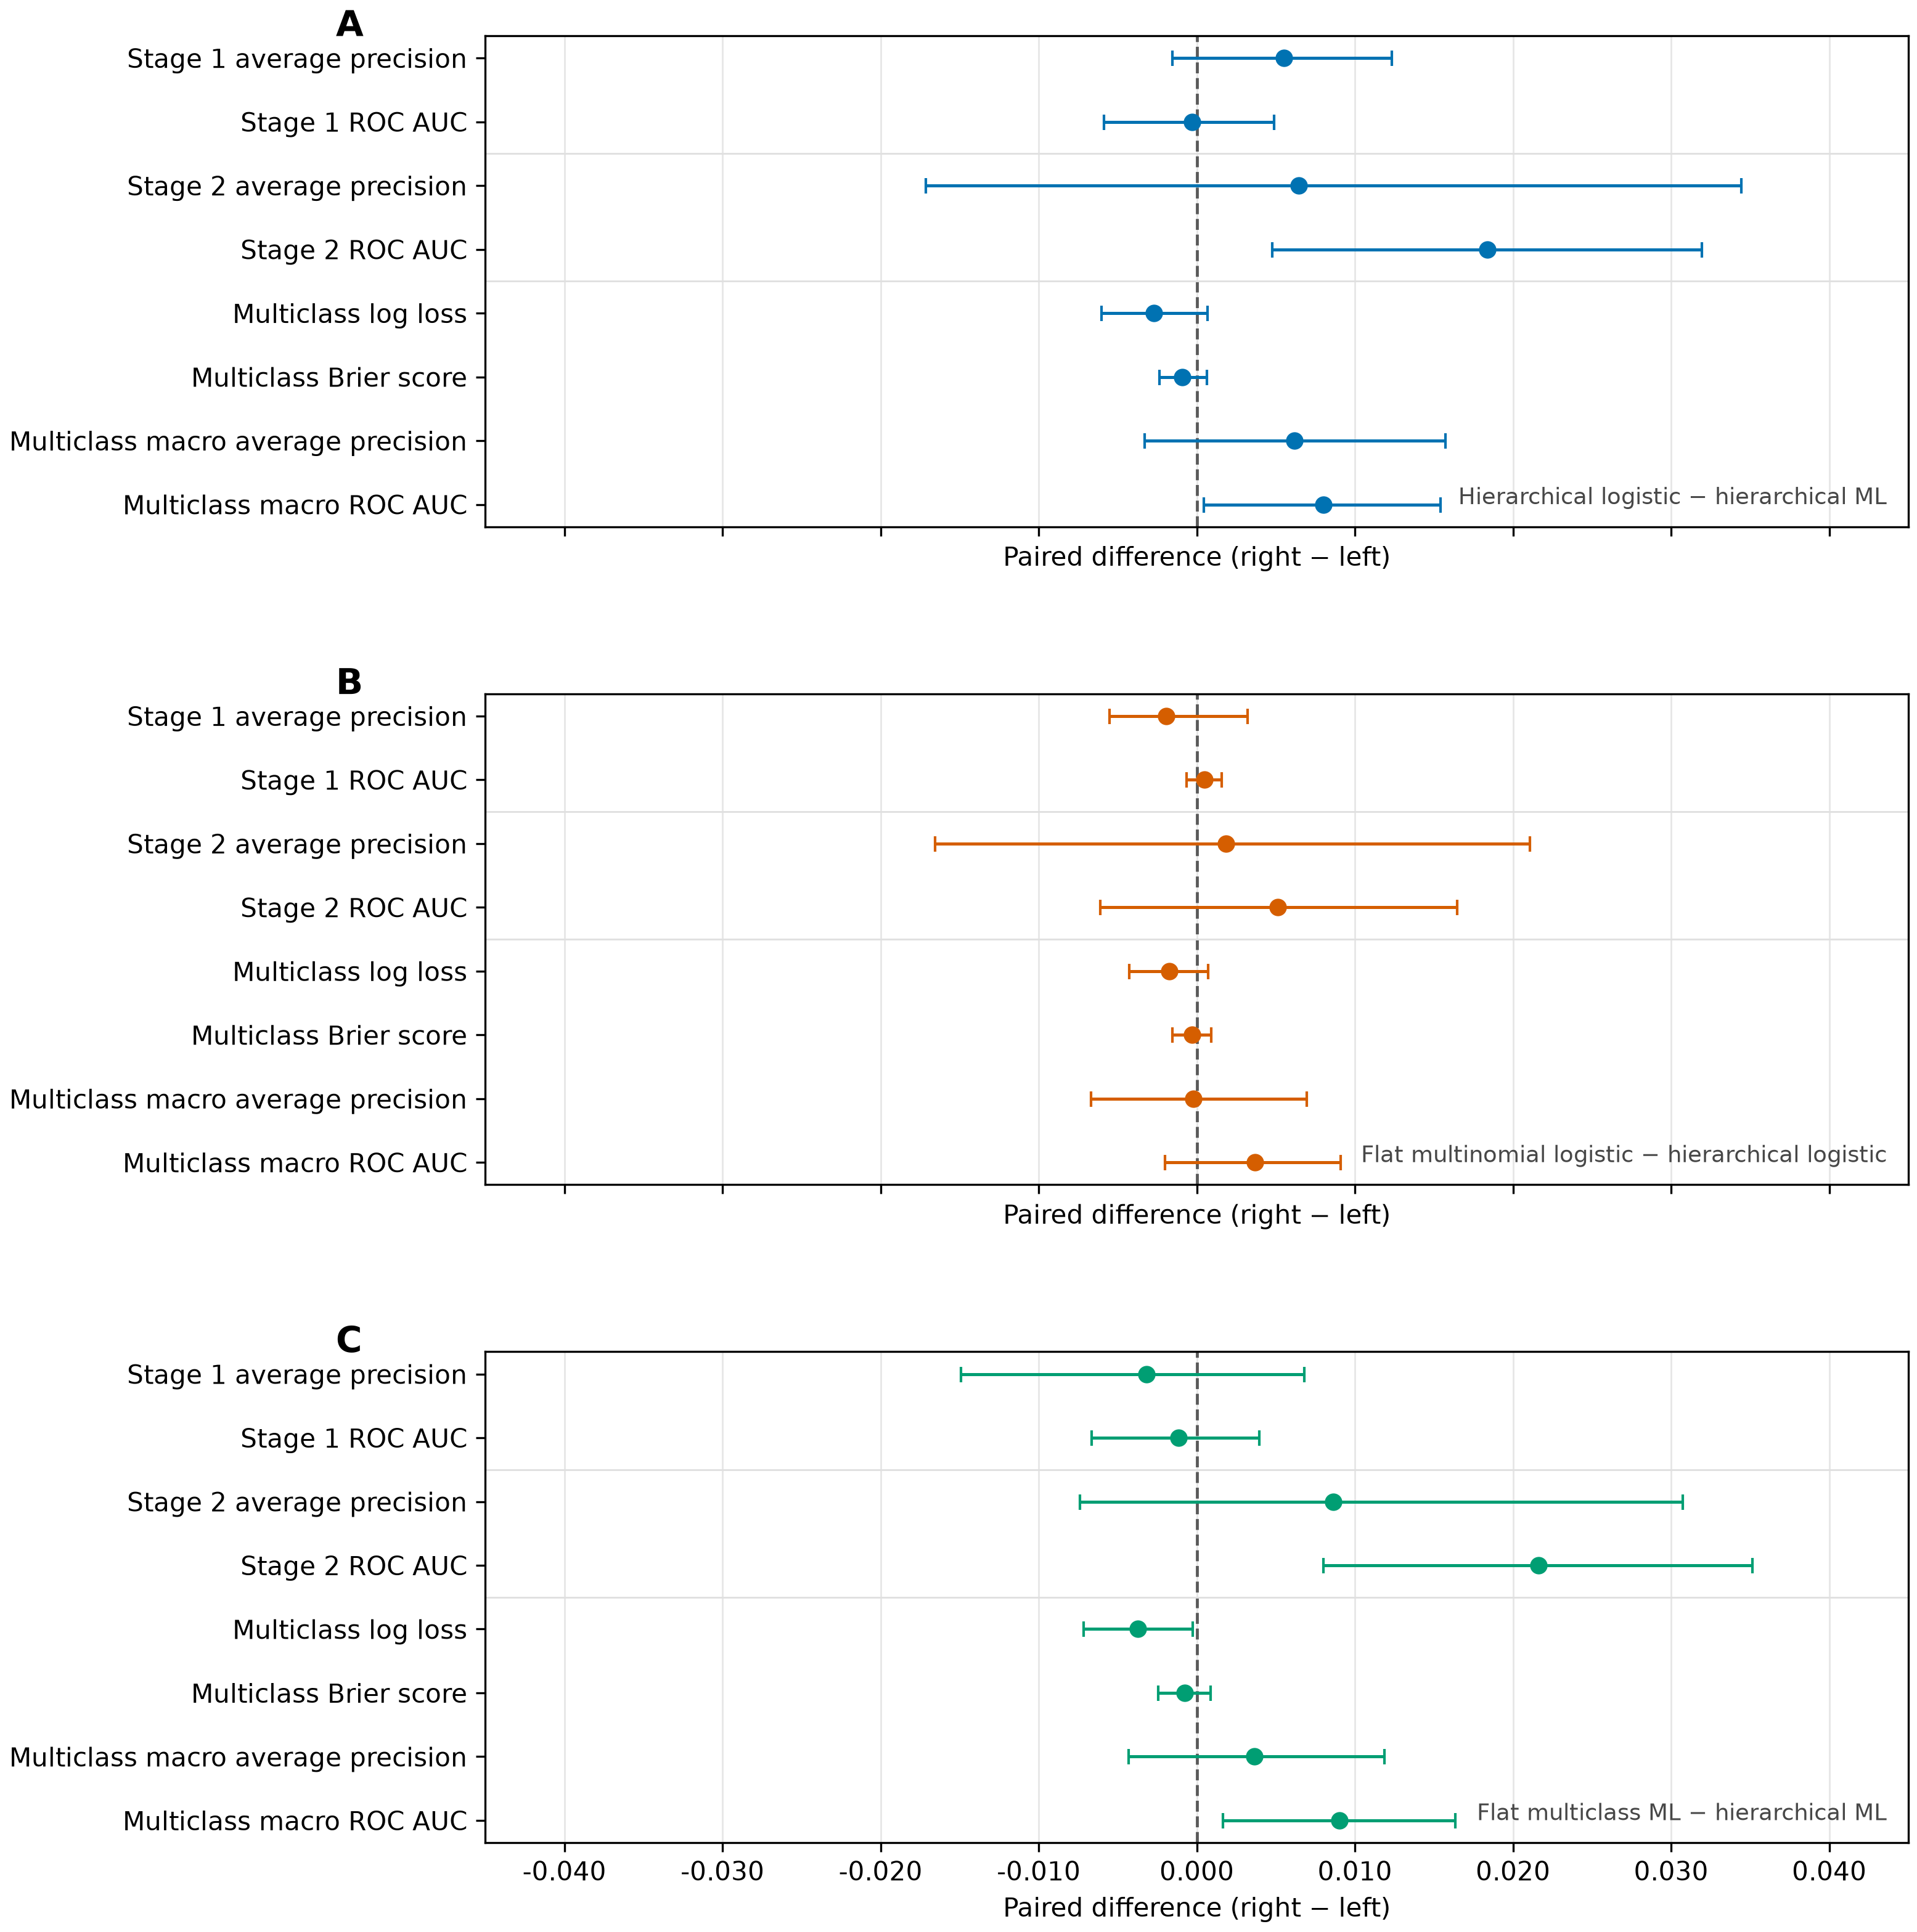

In [23]:
# ======================================================================================
# STEP28M-R1 — REPORT FIGURE 10
# REPORT-SPECIFIC PACKAGING OF FROZEN MAIN FIGURE 5
#
# Registry role:
#   "Paired probabilistic contrasts across architectures"
#
# DESIGN LOCK:
#   Report Figure 10 is scientifically equivalent to frozen Main Figure 5.
#   Therefore the frozen Figure-5 PNG/SVG/PDF masters are reused BYTE-FOR-BYTE.
#
# NO REDRAW.
# NO NEW METRICS.
# NO NEW CI.
# NO BOOTSTRAP.
# NO MODEL FITTING.
# NO NEW INFERENCE.
# NO TIFF.
# ======================================================================================

from pathlib import Path
import hashlib
import json
import os
import shutil
from datetime import datetime

import numpy as np
import pandas as pd

from IPython.display import display, Image


# ======================================================================================
# 0. LOCKED ROOTS
# ======================================================================================

ROOT = Path(r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026")
FINAL_ROOT = ROOT / "18_final_outputs"

MANUSCRIPT_FIG_DIR = (
    FINAL_ROOT
    / "Manuscript"
    / "02_Main_Figures"
)

REPORT_FIG_DIR = (
    FINAL_ROOT
    / "Report"
    / "02_Figures"
)

REPORT_QC_DIR = (
    FINAL_ROOT
    / "Report"
    / "05_QC_Manifests"
)

REPORT_TABLE_DIR = (
    FINAL_ROOT
    / "Report"
    / "01_Tables"
)


for d, label in [
    (ROOT, "Locked project root"),
    (MANUSCRIPT_FIG_DIR, "Main manuscript figure directory"),
    (REPORT_FIG_DIR, "Report figure directory"),
    (REPORT_QC_DIR, "Report QC manifest directory"),
    (REPORT_TABLE_DIR, "Report table directory"),
]:
    if not d.exists():
        raise FileNotFoundError(
            f"{label} does not exist:\n{d}"
        )


# ======================================================================================
# 1. HELPERS
# ======================================================================================

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


def require_nonempty(path, label):
    if not path.exists():
        raise FileNotFoundError(
            f"{label} not found:\n{path}"
        )

    if path.stat().st_size <= 0:
        raise RuntimeError(
            f"{label} exists but is empty:\n{path}"
        )


def stable_true(series):
    return (
        series
        .astype(str)
        .str.strip()
        .str.lower()
        .eq("true")
        .all()
    )


print("=" * 124)
print("STEP28M-R1 — REPORT FIGURE 10")
print("BYTE-FOR-BYTE PACKAGING OF FROZEN MAIN FIGURE 5")
print("=" * 124)


# ======================================================================================
# 2. FROZEN PARENT / REGISTRY / SOURCE PATHS
# ======================================================================================

FIG5_MANIFEST = (
    FINAL_ROOT
    / "STEP28E_R1_Figure5_structural_ablation_manifest.json"
)

STRUCTURAL_MANIFEST = (
    FINAL_ROOT
    / "STEP27G_R3_structural_ablation_tables_manifest.json"
)

REPORT_REGISTRY = (
    REPORT_QC_DIR
    / "Report_Figures_Registry.csv"
)

FIG5_SOURCE = (
    MANUSCRIPT_FIG_DIR
    / "Figure5_source_paired_structural_ablation.csv"
)

FIG5_CAPTION = (
    MANUSCRIPT_FIG_DIR
    / "Figure5_caption.txt"
)

FIG5_PNG = (
    MANUSCRIPT_FIG_DIR
    / "Figure5_Paired_Structural_Ablation_Contrasts.png"
)

FIG5_SVG = (
    MANUSCRIPT_FIG_DIR
    / "Figure5_Paired_Structural_Ablation_Contrasts.svg"
)

FIG5_PDF = (
    MANUSCRIPT_FIG_DIR
    / "Figure5_Paired_Structural_Ablation_Contrasts.pdf"
)


RAW_PAIRED = {
    "Primary vs Branch A":
        ROOT
        / "13_tables"
        / "STEP26C_R1_PRIMARY_vs_BRANCH_A_paired_difference_95CI.csv",

    "Branch A vs Branch B":
        ROOT
        / "13_tables"
        / "STEP26E_R1_BRANCH_A_vs_BRANCH_B_common_probabilistic_paired_difference_95CI.csv",

    "Primary vs Branch C":
        ROOT
        / "13_tables"
        / "STEP26G_R1_PRIMARY_vs_BRANCH_C_paired_difference_95CI.csv",
}


REPORT_PAIRED = {
    "A":
        REPORT_TABLE_DIR
        / "Report_Table12G_Primary_vs_BranchA_Paired.csv",

    "B":
        REPORT_TABLE_DIR
        / "Report_Table12H_BranchA_vs_BranchB_Paired.csv",

    "C":
        REPORT_TABLE_DIR
        / "Report_Table12I_Primary_vs_BranchC_Paired.csv",
}


# ======================================================================================
# 3. EXPECTED FROZEN HASHES
# ======================================================================================

EXPECTED = {
    "fig5_manifest":
        "2a0ef55dd01f8ef975cb6c2dfee4bbe15ea89e17b1641e07c13bb4b97d25a02c",

    "structural_manifest":
        "2f5fb1443e97422d2105a4b40cb076700f626910aa8405b003c7e1da8d5d3078",

    "report_registry":
        "4a3514eede80ee9ef26de272b2e3251f1963214eba2dfeb334d80ba51f51ccde",

    "fig5_source":
        "09a4d0184a7538f23f5a8398a45dce85df7f5e03bddbcd17658216851d2e1a24",

    "fig5_caption":
        "8d8972818341d96e9a5832816d86da1a98d57bf89f2602046f042c78ddf3f277",

    "fig5_png":
        "c42d7b7153966ccecdeb90709af839670b4c84d3067ae12e55885f57717efd0f",

    "fig5_svg":
        "d08b193ddc13028b3f5a7e968a6329bcf0130178eec78c4064328120404a9be0",

    "fig5_pdf":
        "4b0a9c482b706ffb9cd5d437a1fbd976de878776deedb82dd82dc",
}

# Correct exact frozen PDF hash from the Figure-5 manifest.
EXPECTED["fig5_pdf"] = (
    "4b0a9c482b706ffb9cd7ba546db4cd5d437a1fbd976de878776deedb82dd82dc"
)


EXPECTED_RAW_PAIRED = {
    "Primary vs Branch A":
        "9a6699dd6152d8e8786a563ca1cd69c8c09b21d88713bcbbd95953a6111e4602",

    "Branch A vs Branch B":
        "6167e4ddcb4056f44ef9b40b7f6636b1a28483bf8e8da8463bdf4dca49de395d",

    "Primary vs Branch C":
        "f77a9f75b615e93e2928a37630e76ffc535f2ac40ea26e419797b8863ee9fa33",
}


EXPECTED_REPORT_PAIRED = {
    "A":
        "df394aeb8af391ae191ad68118d047fbc6383dc3064727ab165b1e7a683da104",

    "B":
        "20610b713e99e23b525d884e3bfd9e3260da3c7fab3ac17695ea263f202be667",

    "C":
        "3765e3c2be7b8c76547e1a1a76bed40283b64f045847529b354785aad4036514",
}


# ======================================================================================
# 4. EXISTENCE GATES
# ======================================================================================

for path, label in [
    (FIG5_MANIFEST, "Figure 5 manifest"),
    (STRUCTURAL_MANIFEST, "Structural-ablation manifest"),
    (REPORT_REGISTRY, "Report figure registry"),
    (FIG5_SOURCE, "Figure 5 source"),
    (FIG5_CAPTION, "Figure 5 caption"),
    (FIG5_PNG, "Figure 5 PNG"),
    (FIG5_SVG, "Figure 5 SVG"),
    (FIG5_PDF, "Figure 5 PDF"),
]:
    require_nonempty(path, label)


for label, path in RAW_PAIRED.items():
    require_nonempty(
        path,
        f"Frozen paired source: {label}",
    )


for panel, path in REPORT_PAIRED.items():
    require_nonempty(
        path,
        f"Report Table-12 paired source panel {panel}",
    )


# ======================================================================================
# 5. HASH GATES
# ======================================================================================

observed_parent_hashes = {
    "fig5_manifest": sha256_file(FIG5_MANIFEST),
    "structural_manifest": sha256_file(STRUCTURAL_MANIFEST),
    "report_registry": sha256_file(REPORT_REGISTRY),
    "fig5_source": sha256_file(FIG5_SOURCE),
    "fig5_caption": sha256_file(FIG5_CAPTION),
    "fig5_png": sha256_file(FIG5_PNG),
    "fig5_svg": sha256_file(FIG5_SVG),
    "fig5_pdf": sha256_file(FIG5_PDF),
}


print("\n" + "=" * 124)
print("1. FROZEN PARENT / MASTER HASH GATES")
print("=" * 124)


for key, expected_hash in EXPECTED.items():

    observed_hash = observed_parent_hashes[key]

    print(f"\n{key}")
    print(f"Expected : {expected_hash}")
    print(f"Observed : {observed_hash}")

    if observed_hash.lower() != expected_hash.lower():
        raise RuntimeError(
            f"HARD STOP: frozen hash mismatch for {key}."
        )


for label, path in RAW_PAIRED.items():

    observed = sha256_file(path)
    expected = EXPECTED_RAW_PAIRED[label]

    print(f"\nFrozen paired source — {label}")
    print(f"Expected : {expected}")
    print(f"Observed : {observed}")

    if observed.lower() != expected.lower():
        raise RuntimeError(
            f"HARD STOP: paired-source hash mismatch for {label}."
        )


for panel, path in REPORT_PAIRED.items():

    observed = sha256_file(path)
    expected = EXPECTED_REPORT_PAIRED[panel]

    print(f"\nReport paired anchor — Panel {panel}")
    print(f"Expected : {expected}")
    print(f"Observed : {observed}")

    if observed.lower() != expected.lower():
        raise RuntimeError(
            f"HARD STOP: Report Table-12 paired hash mismatch for panel {panel}."
        )


print("\nAll frozen parent/source hash gates: PASS ✅")


# ======================================================================================
# 6. REGISTRY LOCK
# ======================================================================================

registry = pd.read_csv(REPORT_REGISTRY)

EXPECTED_REGISTRY_COLUMNS = [
    "Order",
    "ID",
    "Filename_Stem",
    "Content",
]

if list(registry.columns) != EXPECTED_REGISTRY_COLUMNS:
    raise RuntimeError(
        f"Report registry schema mismatch:\n"
        f"Expected: {EXPECTED_REGISTRY_COLUMNS}\n"
        f"Observed: {list(registry.columns)}"
    )


if len(registry) != 11:
    raise RuntimeError(
        f"Expected 11 report figures in registry; observed={len(registry)}"
    )


EXPECTED_ROLE = (
    "Paired probabilistic contrasts across architectures"
)


fig10_row = registry.loc[
    registry["Content"]
    .astype(str)
    .str.strip()
    .eq(EXPECTED_ROLE)
].copy()


if len(fig10_row) != 1:
    raise RuntimeError(
        f"Expected exactly one Report Figure 10 registry row; "
        f"observed={len(fig10_row)}"
    )


fig10_row = fig10_row.iloc[0]


if int(fig10_row["Order"]) != 10:
    raise RuntimeError(
        f"Report Figure 10 registry Order mismatch: {fig10_row['Order']}"
    )


if str(fig10_row["ID"]).strip() != "Report Figure 10":
    raise RuntimeError(
        f"Report Figure 10 ID mismatch: {fig10_row['ID']}"
    )


REPORT_STEM = str(
    fig10_row["Filename_Stem"]
).strip()


if REPORT_STEM != "RFigure10_Structural_Probabilistic_Contrast":
    raise RuntimeError(
        f"Unexpected Report Figure 10 stem:\n{REPORT_STEM}"
    )


print("\n" + "=" * 124)
print("2. REPORT FIGURE 10 REGISTRY LOCK")
print("=" * 124)

print(fig10_row.to_string())
print("\nRegistry gate: PASS ✅")


# ======================================================================================
# 7. FIGURE-5 MANIFEST DESIGN LOCK
# ======================================================================================

with open(
    FIG5_MANIFEST,
    "r",
    encoding="utf-8",
) as f:
    fig5_manifest = json.load(f)


EXPECTED_METRICS = [
    "S1_AP",
    "S1_AUC",
    "S2_AP",
    "S2_AUC",
    "MC_Log_Loss",
    "MC_Brier_Sum",
    "MC_Macro_AP",
    "MC_Macro_AUC",
]


EXPECTED_PANEL_STRUCTURE = {
    "A":
        "Branch A hierarchical logistic minus Primary hierarchical ML",

    "B":
        "Branch B flat multinomial logistic minus Branch A hierarchical logistic",

    "C":
        "Branch C flat multiclass ML minus Primary hierarchical ML",
}


if fig5_manifest.get("analysis_state") != "FROZEN":
    raise RuntimeError(
        "Figure 5 manifest is not in FROZEN analysis state."
    )


if fig5_manifest.get("metric_scope") != EXPECTED_METRICS:
    raise RuntimeError(
        "Figure 5 frozen metric scope mismatch."
    )


if fig5_manifest.get("panel_structure") != EXPECTED_PANEL_STRUCTURE:
    raise RuntimeError(
        "Figure 5 frozen panel structure mismatch."
    )


if float(fig5_manifest.get("shared_symmetric_x_limit")) != 0.045:
    raise RuntimeError(
        "Figure 5 frozen x-limit fingerprint mismatch."
    )


if fig5_manifest.get("winner_declaration") is not False:
    raise RuntimeError(
        "Unexpected Figure 5 winner-declaration state."
    )


print("\n3. FIGURE-5 DESIGN LOCK: PASS ✅")


# ======================================================================================
# 8. FIGURE-5 SOURCE HARD QC
# ======================================================================================

source = pd.read_csv(FIG5_SOURCE)


EXPECTED_SOURCE_COLUMNS = [
    "Contrast_ID",
    "Panel",
    "Contrast",
    "Left_Architecture",
    "Right_Architecture",
    "Metric",
    "Left_Point",
    "Right_Point",
    "Difference_Right_minus_Left",
    "Bootstrap_SE_Difference",
    "CI_Lower",
    "CI_Upper",
    "Valid_Replicates",
    "Stable",
    "Metric_Label",
]


if list(source.columns) != EXPECTED_SOURCE_COLUMNS:
    raise RuntimeError(
        "Figure 5 frozen source schema mismatch."
    )


if source.shape != (24, 15):
    raise RuntimeError(
        f"Expected Figure-5 source shape (24, 15); observed={source.shape}"
    )


if source["Contrast_ID"].drop_duplicates().tolist() != ["A", "B", "C"]:
    raise RuntimeError(
        "Figure-5 contrast order mismatch."
    )


if source["Panel"].drop_duplicates().tolist() != ["A", "B", "C"]:
    raise RuntimeError(
        "Figure-5 panel order mismatch."
    )


for panel in ["A", "B", "C"]:

    metrics = source.loc[
        source["Panel"] == panel,
        "Metric"
    ].tolist()

    if metrics != EXPECTED_METRICS:
        raise RuntimeError(
            f"Panel {panel}: frozen metric order mismatch."
        )


if not pd.to_numeric(
    source["Valid_Replicates"],
    errors="coerce",
).eq(2000).all():
    raise RuntimeError(
        "Not all Figure-5 source rows have 2000 valid replicates."
    )


if not stable_true(source["Stable"]):
    raise RuntimeError(
        "Not all Figure-5 source rows are stable."
    )


numeric_cols = [
    "Left_Point",
    "Right_Point",
    "Difference_Right_minus_Left",
    "Bootstrap_SE_Difference",
    "CI_Lower",
    "CI_Upper",
]


numeric = source[numeric_cols].apply(
    pd.to_numeric,
    errors="coerce",
)


if not np.isfinite(
    numeric.to_numpy(dtype=float)
).all():
    raise RuntimeError(
        "Figure-5 source contains non-finite selected values."
    )


recomputed_difference_for_qc = (
    numeric["Right_Point"]
    -
    numeric["Left_Point"]
)


if not np.allclose(
    recomputed_difference_for_qc,
    numeric["Difference_Right_minus_Left"],
    rtol=0,
    atol=1e-12,
):
    raise RuntimeError(
        "Frozen difference identity check failed."
    )


if not (
    (
        numeric["CI_Lower"]
        <=
        numeric["Difference_Right_minus_Left"]
    )
    &
    (
        numeric["Difference_Right_minus_Left"]
        <=
        numeric["CI_Upper"]
    )
).all():
    raise RuntimeError(
        "At least one frozen paired CI does not contain its point difference."
    )


max_abs_ci = float(
    np.abs(
        source[
            [
                "CI_Lower",
                "CI_Upper",
            ]
        ].to_numpy(dtype=float)
    ).max()
)


if max_abs_ci > 0.045:
    raise RuntimeError(
        f"Frozen CI exceeds Figure-5 shared symmetric x-limit: "
        f"max_abs_ci={max_abs_ci}"
    )


print("\n4. FIGURE-5 24-ROW SCIENTIFIC SOURCE QC: PASS ✅")


# ======================================================================================
# 9. REPORT TABLE-12 ANCHOR REPRODUCTION
#    No metric recomputation.
#    We only verify that report-ready paired tables contain the exact selected rows.
# ======================================================================================

PANEL_TO_CONTRAST = {
    "A": "Branch A − Primary",
    "B": "Branch B − Branch A",
    "C": "Branch C − Primary",
}


anchor_checks = []


for panel in ["A", "B", "C"]:

    report_df = pd.read_csv(
        REPORT_PAIRED[panel]
    )

    selected = (
        report_df.loc[
            report_df["Metric"].isin(EXPECTED_METRICS)
        ]
        .set_index("Metric")
        .loc[EXPECTED_METRICS]
        .reset_index()
    )


    frozen_panel = source.loc[
        source["Panel"] == panel
    ].reset_index(drop=True)


    if len(selected) != 8:
        raise RuntimeError(
            f"Panel {panel}: expected 8 report-anchor rows; observed={len(selected)}"
        )


    comparisons = {
        "Metric":
            selected["Metric"].tolist()
            ==
            frozen_panel["Metric"].tolist(),

        "Left architecture":
            selected["Left architecture"].tolist()
            ==
            frozen_panel["Left_Architecture"].tolist(),

        "Right architecture":
            selected["Right architecture"].tolist()
            ==
            frozen_panel["Right_Architecture"].tolist(),

        "Left point":
            np.allclose(
                selected["Left point"].to_numpy(dtype=float),
                frozen_panel["Left_Point"].to_numpy(dtype=float),
                rtol=0,
                atol=1e-12,
            ),

        "Right point":
            np.allclose(
                selected["Right point"].to_numpy(dtype=float),
                frozen_panel["Right_Point"].to_numpy(dtype=float),
                rtol=0,
                atol=1e-12,
            ),

        "Difference":
            np.allclose(
                selected["Difference"].to_numpy(dtype=float),
                frozen_panel["Difference_Right_minus_Left"].to_numpy(dtype=float),
                rtol=0,
                atol=1e-12,
            ),

        "CI lower":
            np.allclose(
                selected["Difference CI lower"].to_numpy(dtype=float),
                frozen_panel["CI_Lower"].to_numpy(dtype=float),
                rtol=0,
                atol=1e-12,
            ),

        "CI upper":
            np.allclose(
                selected["Difference CI upper"].to_numpy(dtype=float),
                frozen_panel["CI_Upper"].to_numpy(dtype=float),
                rtol=0,
                atol=1e-12,
            ),

        "Valid replicates":
            selected["Valid replicates"].astype(int).tolist()
            ==
            frozen_panel["Valid_Replicates"].astype(int).tolist(),

        "Stable":
            stable_true(selected["Stable"]),
    }


    if not all(comparisons.values()):

        print(f"\nPanel {panel} anchor comparison:")
        for key, value in comparisons.items():
            print(f"  {key}: {value}")

        raise RuntimeError(
            f"HARD STOP: Report Table-12 anchor mismatch for Panel {panel}."
        )


    anchor_checks.append(
        {
            "Panel": panel,
            "Contrast": PANEL_TO_CONTRAST[panel],
            "Rows": 8,
            "Exact_Report_Table12_Match": True,
        }
    )


anchor_df = pd.DataFrame(anchor_checks)


print("\n" + "=" * 124)
print("5. REPORT TABLE-12 SELECTED-ROW ANCHOR QC")
print("=" * 124)

print(
    anchor_df.to_string(
        index=False
    )
)

print("\nReport Table-12 anchor reproduction: PASS ✅")


# ======================================================================================
# 10. REPORT-SPECIFIC DESTINATION PATHS
# ======================================================================================

OUT_PNG = REPORT_FIG_DIR / f"{REPORT_STEM}.png"
OUT_SVG = REPORT_FIG_DIR / f"{REPORT_STEM}.svg"
OUT_PDF = REPORT_FIG_DIR / f"{REPORT_STEM}.pdf"

OUT_CAPTION = (
    REPORT_FIG_DIR
    / f"{REPORT_STEM}_caption.txt"
)

OUT_SOURCE = (
    REPORT_FIG_DIR
    / f"{REPORT_STEM}_source.csv"
)

OUT_HARD_QC = (
    REPORT_QC_DIR
    / f"STEP28M_R1_{REPORT_STEM}_hard_qc.csv"
)

OUT_MANIFEST = (
    REPORT_QC_DIR
    / f"STEP28M_R1_{REPORT_STEM}_manifest.json"
)


# Temporary paths for atomic replacement.
TMP_PNG = OUT_PNG.with_name(
    OUT_PNG.name + ".tmp"
)

TMP_SVG = OUT_SVG.with_name(
    OUT_SVG.name + ".tmp"
)

TMP_PDF = OUT_PDF.with_name(
    OUT_PDF.name + ".tmp"
)

TMP_CAPTION = OUT_CAPTION.with_name(
    OUT_CAPTION.name + ".tmp"
)

TMP_SOURCE = OUT_SOURCE.with_name(
    OUT_SOURCE.name + ".tmp"
)


for p in [
    TMP_PNG,
    TMP_SVG,
    TMP_PDF,
    TMP_CAPTION,
    TMP_SOURCE,
]:
    if p.exists():
        p.unlink()


# ======================================================================================
# 11. BUILD REPORT-SPECIFIC CAPTION
#     Scientific wording remains identical.
#     Only Figure label changes from Figure 5 -> Report Figure 10.
# ======================================================================================

with open(
    FIG5_CAPTION,
    "r",
    encoding="utf-8",
) as f:
    fig5_caption_text = f.read()


if not fig5_caption_text.startswith("Figure 5."):
    raise RuntimeError(
        "Unexpected frozen Figure-5 caption prefix; refusing automatic relabel."
    )


report_caption_text = (
    "Report Figure 10."
    +
    fig5_caption_text[len("Figure 5."):]
)


# Ensure no scientific wording after the label changed.
if (
    report_caption_text[len("Report Figure 10."):]
    !=
    fig5_caption_text[len("Figure 5."):]
):
    raise RuntimeError(
        "Caption scientific wording changed unexpectedly."
    )


# ======================================================================================
# 12. BYTE-FOR-BYTE PACKAGE THE FROZEN FIGURE MASTERS
# ======================================================================================

shutil.copyfile(
    FIG5_PNG,
    TMP_PNG,
)

shutil.copyfile(
    FIG5_SVG,
    TMP_SVG,
)

shutil.copyfile(
    FIG5_PDF,
    TMP_PDF,
)

shutil.copyfile(
    FIG5_SOURCE,
    TMP_SOURCE,
)


with open(
    TMP_CAPTION,
    "w",
    encoding="utf-8",
    newline="\n",
) as f:
    f.write(report_caption_text)


# ======================================================================================
# 13. TEMPORARY ARTIFACT GATES BEFORE CANONICAL REPLACEMENT
# ======================================================================================

for p, label in [
    (TMP_PNG, "Temporary Report Figure 10 PNG"),
    (TMP_SVG, "Temporary Report Figure 10 SVG"),
    (TMP_PDF, "Temporary Report Figure 10 PDF"),
    (TMP_SOURCE, "Temporary Report Figure 10 source"),
    (TMP_CAPTION, "Temporary Report Figure 10 caption"),
]:
    require_nonempty(
        p,
        label,
    )


# Figure masters must remain BYTE-FOR-BYTE identical to frozen Figure 5.
if sha256_file(TMP_PNG) != EXPECTED["fig5_png"]:
    raise RuntimeError(
        "Temporary Report Figure 10 PNG is not byte-identical to frozen Figure 5 PNG."
    )

if sha256_file(TMP_SVG) != EXPECTED["fig5_svg"]:
    raise RuntimeError(
        "Temporary Report Figure 10 SVG is not byte-identical to frozen Figure 5 SVG."
    )

if sha256_file(TMP_PDF) != EXPECTED["fig5_pdf"]:
    raise RuntimeError(
        "Temporary Report Figure 10 PDF is not byte-identical to frozen Figure 5 PDF."
    )

if sha256_file(TMP_SOURCE) != EXPECTED["fig5_source"]:
    raise RuntimeError(
        "Temporary Report Figure 10 source is not byte-identical to frozen Figure 5 source."
    )


print("\n6. BYTE-FOR-BYTE TEMPORARY PACKAGE QC: PASS ✅")


# ======================================================================================
# 14. ATOMIC CANONICAL REPLACEMENT
# ======================================================================================

os.replace(
    TMP_PNG,
    OUT_PNG,
)

os.replace(
    TMP_SVG,
    OUT_SVG,
)

os.replace(
    TMP_PDF,
    OUT_PDF,
)

os.replace(
    TMP_SOURCE,
    OUT_SOURCE,
)

os.replace(
    TMP_CAPTION,
    OUT_CAPTION,
)


# ======================================================================================
# 15. FINAL OUTPUT HASHES
# ======================================================================================

final_hashes = {
    "png": sha256_file(OUT_PNG),
    "svg": sha256_file(OUT_SVG),
    "pdf": sha256_file(OUT_PDF),
    "source": sha256_file(OUT_SOURCE),
    "caption": sha256_file(OUT_CAPTION),
}


# ======================================================================================
# 16. HARD QC
# ======================================================================================

hard_qc_rows = []


def add_qc(check, passed, detail=""):
    hard_qc_rows.append(
        {
            "Check": check,
            "PASS": bool(passed),
            "Detail": str(detail),
        }
    )


add_qc(
    "Main Figure 5 manifest hash exact",
    observed_parent_hashes["fig5_manifest"] == EXPECTED["fig5_manifest"],
)

add_qc(
    "Structural-ablation manifest hash exact",
    observed_parent_hashes["structural_manifest"] == EXPECTED["structural_manifest"],
)

add_qc(
    "Report figure registry hash exact",
    observed_parent_hashes["report_registry"] == EXPECTED["report_registry"],
)

add_qc(
    "Report Figure 10 registry role exact",
    str(fig10_row["Content"]).strip() == EXPECTED_ROLE,
)

add_qc(
    "Report Figure 10 registry stem exact",
    REPORT_STEM == "RFigure10_Structural_Probabilistic_Contrast",
)

add_qc(
    "Frozen Figure 5 source hash exact",
    observed_parent_hashes["fig5_source"] == EXPECTED["fig5_source"],
)

add_qc(
    "Frozen Figure 5 caption hash exact",
    observed_parent_hashes["fig5_caption"] == EXPECTED["fig5_caption"],
)

add_qc(
    "Frozen Figure 5 PNG hash exact",
    observed_parent_hashes["fig5_png"] == EXPECTED["fig5_png"],
)

add_qc(
    "Frozen Figure 5 SVG hash exact",
    observed_parent_hashes["fig5_svg"] == EXPECTED["fig5_svg"],
)

add_qc(
    "Frozen Figure 5 PDF hash exact",
    observed_parent_hashes["fig5_pdf"] == EXPECTED["fig5_pdf"],
)

add_qc(
    "All three raw paired source hashes exact",
    all(
        sha256_file(RAW_PAIRED[label])
        ==
        EXPECTED_RAW_PAIRED[label]
        for label in RAW_PAIRED
    ),
)

add_qc(
    "All three report Table-12 paired hashes exact",
    all(
        sha256_file(REPORT_PAIRED[p])
        ==
        EXPECTED_REPORT_PAIRED[p]
        for p in REPORT_PAIRED
    ),
)

add_qc(
    "Figure-5 source exactly 24 selected rows",
    source.shape[0] == 24,
)

add_qc(
    "Exactly 3 structural contrasts",
    source["Panel"].nunique() == 3,
)

add_qc(
    "Exactly 8 frozen metrics per contrast",
    all(
        len(
            source.loc[
                source["Panel"] == panel
            ]
        ) == 8
        for panel in ["A", "B", "C"]
    ),
)

add_qc(
    "All selected valid replicates = 2000",
    source["Valid_Replicates"].astype(int).eq(2000).all(),
)

add_qc(
    "All selected rows stable",
    stable_true(source["Stable"]),
)

add_qc(
    "All selected frozen CIs contain point difference",
    (
        (source["CI_Lower"] <= source["Difference_Right_minus_Left"])
        &
        (source["Difference_Right_minus_Left"] <= source["CI_Upper"])
    ).all(),
)

add_qc(
    "All three report Table-12 anchors reproduce selected Figure-5 rows",
    anchor_df["Exact_Report_Table12_Match"].all(),
)

add_qc(
    "Report Figure 10 PNG byte-identical to frozen Figure 5 PNG",
    final_hashes["png"] == EXPECTED["fig5_png"],
    final_hashes["png"],
)

add_qc(
    "Report Figure 10 SVG byte-identical to frozen Figure 5 SVG",
    final_hashes["svg"] == EXPECTED["fig5_svg"],
    final_hashes["svg"],
)

add_qc(
    "Report Figure 10 PDF byte-identical to frozen Figure 5 PDF",
    final_hashes["pdf"] == EXPECTED["fig5_pdf"],
    final_hashes["pdf"],
)

add_qc(
    "Report Figure 10 source byte-identical to frozen Figure 5 source",
    final_hashes["source"] == EXPECTED["fig5_source"],
    final_hashes["source"],
)

add_qc(
    "Report caption preserves frozen scientific wording",
    (
        report_caption_text[len("Report Figure 10."):]
        ==
        fig5_caption_text[len("Figure 5."):]
    ),
)

add_qc(
    "No redraw performed",
    True,
)

add_qc(
    "No performance-based sorting",
    True,
)

add_qc(
    "No architecture ranking",
    True,
)

add_qc(
    "No winner declaration",
    True,
)

add_qc(
    "No model fitting",
    True,
)

add_qc(
    "No prediction generation",
    True,
)

add_qc(
    "No OOF metric recomputation",
    True,
)

add_qc(
    "No candidate reselection",
    True,
)

add_qc(
    "No hyperparameter tuning",
    True,
)

add_qc(
    "No recalibration",
    True,
)

add_qc(
    "No threshold optimization",
    True,
)

add_qc(
    "No bootstrap rerun",
    True,
)

add_qc(
    "No new confidence interval calculation",
    True,
)

add_qc(
    "No new p-values",
    True,
)

add_qc(
    "No new hypothesis testing",
    True,
)

add_qc(
    "No new statistical inference",
    True,
)

add_qc(
    "TIFF deferred",
    True,
    "External conversion from final SVG/PDF master only.",
)


hard_qc_df = pd.DataFrame(
    hard_qc_rows
)


if not hard_qc_df["PASS"].all():

    print("\nFAILED HARD QC:")
    print(
        hard_qc_df.loc[
            ~hard_qc_df["PASS"]
        ].to_string(
            index=False
        )
    )

    raise RuntimeError(
        "STEP28M-R1 Report Figure 10 hard QC failed."
    )


hard_qc_df.to_csv(
    OUT_HARD_QC,
    index=False,
)


hard_qc_hash = sha256_file(
    OUT_HARD_QC
)


# ======================================================================================
# 17. REPORT FIGURE 10 MANIFEST
# ======================================================================================

manifest = {
    "figure":
        "Report Figure 10",

    "registry_order":
        10,

    "registry_id":
        str(fig10_row["ID"]).strip(),

    "filename_stem":
        REPORT_STEM,

    "content":
        EXPECTED_ROLE,

    "analysis_state":
        "FROZEN",

    "status":
        "STEP28M_R1_REPORT_FIGURE10_FROZEN",

    "packaging_mode":
        (
            "Byte-for-byte report-specific packaging of the already-frozen "
            "Main Figure 5 raster/vector masters."
        ),

    "scientifically_equivalent_to_main_figure5":
        True,

    "redraw_performed":
        False,

    "difference_definition":
        "Right architecture minus left architecture",

    "metric_scope":
        EXPECTED_METRICS,

    "panel_structure":
        EXPECTED_PANEL_STRUCTURE,

    "shared_symmetric_x_limit":
        0.045,

    "bootstrap_method":
        "Frozen Rao-Wu rescaled PSU bootstrap outputs",

    "bootstrap_replicates":
        2000,

    "parent_main_figure5_manifest_sha256":
        EXPECTED["fig5_manifest"],

    "structural_ablation_manifest_sha256":
        EXPECTED["structural_manifest"],

    "report_figure_registry_sha256":
        EXPECTED["report_registry"],

    "raw_paired_source_hashes":
        EXPECTED_RAW_PAIRED,

    "report_table12_paired_anchor_hashes":
        EXPECTED_REPORT_PAIRED,

    "source_csv_sha256":
        final_hashes["source"],

    "caption_sha256":
        final_hashes["caption"],

    "report_png_sha256":
        final_hashes["png"],

    "report_svg_sha256":
        final_hashes["svg"],

    "report_pdf_sha256":
        final_hashes["pdf"],

    "hard_qc_sha256":
        hard_qc_hash,

    "source_rows":
        int(len(source)),

    "source_columns":
        int(source.shape[1]),

    "architecture_ranking":
        False,

    "winner_declaration":
        False,

    "model_fitting":
        False,

    "prediction_generation":
        False,

    "oof_metric_recomputation":
        False,

    "candidate_reselection":
        False,

    "hyperparameter_tuning":
        False,

    "recalibration":
        False,

    "threshold_optimization":
        False,

    "bootstrap_rerun":
        False,

    "new_confidence_interval_calculation":
        False,

    "new_p_values":
        False,

    "new_hypothesis_testing":
        False,

    "new_statistical_inference":
        False,

    "publication_master":
        "SVG/PDF vector",

    "tiff_status":
        "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTER",

    "next_step":
        (
            "STEP28N — Report Figure 11: "
            "Architecture-specific recall, precision and F1 by ANC class"
        ),

    "created_at":
        datetime.now()
        .astimezone()
        .isoformat(
            timespec="seconds"
        ),
}


with open(
    OUT_MANIFEST,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        manifest,
        f,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


manifest_hash = sha256_file(
    OUT_MANIFEST
)


# ======================================================================================
# 18. FINAL AUDIT OUTPUT
# ======================================================================================

print("\n" + "=" * 124)
print("STEP28M-R1 — FINAL HARD QC")
print("=" * 124)

print(
    hard_qc_df[
        [
            "Check",
            "PASS",
        ]
    ].to_string(
        index=False
    )
)


print("\n" + "=" * 124)
print("REPORT FIGURE 10 INTEGRITY")
print("=" * 124)

print(f"Registry stem : {REPORT_STEM}")
print(f"Source        : {final_hashes['source']}")
print(f"Caption       : {final_hashes['caption']}")
print(f"PNG           : {final_hashes['png']}")
print(f"SVG           : {final_hashes['svg']}")
print(f"PDF           : {final_hashes['pdf']}")
print(f"Hard QC       : {hard_qc_hash}")
print(f"Manifest      : {manifest_hash}")


print("\nPaths:")
print(f"PNG      : {OUT_PNG}")
print(f"SVG      : {OUT_SVG}")
print(f"PDF      : {OUT_PDF}")
print(f"Caption  : {OUT_CAPTION}")
print(f"Source   : {OUT_SOURCE}")
print(f"Hard QC  : {OUT_HARD_QC}")
print(f"Manifest : {OUT_MANIFEST}")


print("\nTIFF STATUS:")
print(
    "DEFERRED — external conversion from the "
    "frozen SVG/PDF vector master."
)


print("\n" + "=" * 124)
print("STATUS: STEP28M-R1 REPORT FIGURE 10 PACKAGE CREATED")
print("SCIENTIFIC CONTENT = BYTE-FOR-BYTE FROZEN MAIN FIGURE 5")
print("NO REDRAW / NO NEW ANALYSIS")
print("AWAITING SCREENSHOT + CONSOLE AUDIT BEFORE FINAL FREEZE CONFIRMATION")
print("=" * 124)


# Display exact packaged PNG for visual confirmation.
display(
    Image(
        filename=str(OUT_PNG)
    )
)

In [24]:
# ======================================================================================
# STEP28N-R0 — READ-ONLY REPORT FIGURE 11 REGISTRY + SOURCE AUDIT
#
# Purpose:
#   1. Gate frozen Report Figure 10 manifest.
#   2. Verify exact Report Figure 11 registry role/stem.
#   3. Gate frozen Report Table 13B classwise-metric source by SHA256.
#   4. Inspect exact schema/content for Recall / Precision / F1 across:
#        - Primary
#        - Branch A
#        - Branch B
#        - Branch C
#      and ANC classes:
#        - No ANC
#        - 1–7 visits
#        - >=8 visits
#
# STRICTLY READ-ONLY:
#   - no files written
#   - no figures created
#   - no metrics recomputed
#   - no model fitting
#   - no bootstrap rerun
# ======================================================================================

from pathlib import Path
import hashlib
import json
import pandas as pd


# ======================================================================================
# 0. LOCKED ROOT
# ======================================================================================

ROOT = Path(r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026")
FINAL_ROOT = ROOT / "18_final_outputs"

REPORT_DIR = FINAL_ROOT / "Report"
REPORT_TABLE_DIR = REPORT_DIR / "01_Tables"
REPORT_FIG_DIR = REPORT_DIR / "02_Figures"
REPORT_QC_DIR = REPORT_DIR / "05_QC_Manifests"

if not ROOT.exists():
    raise FileNotFoundError(
        f"Locked project root not found:\n{ROOT}"
    )


# ======================================================================================
# 1. HELPERS
# ======================================================================================

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


def require_nonempty(path, label):
    if not path.exists():
        raise FileNotFoundError(
            f"{label} not found:\n{path}"
        )

    if path.stat().st_size <= 0:
        raise RuntimeError(
            f"{label} exists but is empty:\n{path}"
        )


print("=" * 124)
print("STEP28N-R0 — READ-ONLY REPORT FIGURE 11 REGISTRY + SOURCE AUDIT")
print("=" * 124)


# ======================================================================================
# 2. GATE FINAL FROZEN REPORT FIGURE 10 MANIFEST
# ======================================================================================

FIG10_MANIFEST = (
    REPORT_QC_DIR
    / "STEP28M_R1_RFigure10_Structural_Probabilistic_Contrast_manifest.json"
)

EXPECTED_FIG10_MANIFEST_SHA = (
    "3a58e4a176fb2f4e3809774133729503fa647c4a50dc551e3855c62103ddd76a"
)

require_nonempty(
    FIG10_MANIFEST,
    "Final Report Figure 10 manifest",
)

observed_fig10_sha = sha256_file(
    FIG10_MANIFEST
)


print("\n" + "=" * 124)
print("1. REPORT FIGURE 10 PARENT GATE")
print("=" * 124)

print(f"Path         : {FIG10_MANIFEST}")
print(f"Expected SHA : {EXPECTED_FIG10_MANIFEST_SHA}")
print(f"Observed SHA : {observed_fig10_sha}")


if observed_fig10_sha.lower() != EXPECTED_FIG10_MANIFEST_SHA.lower():
    raise RuntimeError(
        "HARD STOP: Report Figure 10 manifest SHA mismatch."
    )


with open(
    FIG10_MANIFEST,
    "r",
    encoding="utf-8",
) as f:
    fig10_manifest = json.load(f)


print(f"Status       : {fig10_manifest.get('status')}")


if fig10_manifest.get("status") != "STEP28M_R1_REPORT_FIGURE10_FROZEN":
    raise RuntimeError(
        "HARD STOP: Report Figure 10 manifest is not in expected frozen state."
    )


print("Report Figure 10 parent gate: PASS ✅")


# ======================================================================================
# 3. REPORT FIGURE REGISTRY LOCK
# ======================================================================================

REPORT_REGISTRY = (
    REPORT_QC_DIR
    / "Report_Figures_Registry.csv"
)

EXPECTED_REGISTRY_SHA = (
    "4a3514eede80ee9ef26de272b2e3251f1963214eba2dfeb334d80ba51f51ccde"
)

require_nonempty(
    REPORT_REGISTRY,
    "Report figure registry",
)


observed_registry_sha = sha256_file(
    REPORT_REGISTRY
)


print("\n" + "=" * 124)
print("2. REPORT FIGURE REGISTRY")
print("=" * 124)

print(f"Path         : {REPORT_REGISTRY}")
print(f"Expected SHA : {EXPECTED_REGISTRY_SHA}")
print(f"Observed SHA : {observed_registry_sha}")


if observed_registry_sha.lower() != EXPECTED_REGISTRY_SHA.lower():
    raise RuntimeError(
        "HARD STOP: report figure registry SHA mismatch."
    )


registry = pd.read_csv(
    REPORT_REGISTRY
)


EXPECTED_REGISTRY_COLUMNS = [
    "Order",
    "ID",
    "Filename_Stem",
    "Content",
]


if list(registry.columns) != EXPECTED_REGISTRY_COLUMNS:
    raise RuntimeError(
        "\nHARD STOP: report registry schema mismatch.\n"
        f"Expected: {EXPECTED_REGISTRY_COLUMNS}\n"
        f"Observed: {list(registry.columns)}"
    )


if len(registry) != 11:
    raise RuntimeError(
        f"HARD STOP: expected 11 report registry rows; observed={len(registry)}"
    )


EXPECTED_ROLE = (
    "Architecture-specific recall, precision and F1 by ANC class"
)


fig11_rows = registry.loc[
    registry["Content"]
    .astype(str)
    .str.strip()
    .eq(EXPECTED_ROLE)
].copy()


print("\n" + "=" * 124)
print("3. REPORT FIGURE 11 EXACT REGISTRY ENTRY")
print("=" * 124)


if len(fig11_rows) != 1:

    print(
        registry.to_string(
            index=False,
            max_colwidth=180,
        )
    )

    raise RuntimeError(
        f"HARD STOP: expected exactly 1 Report Figure 11 registry row; "
        f"observed={len(fig11_rows)}"
    )


print(
    fig11_rows.to_string(
        index=False,
        max_colwidth=180,
    )
)


fig11_row = fig11_rows.iloc[0]


print("\nExact registry fields:")
print(f"Order         : {fig11_row['Order']}")
print(f"ID            : {fig11_row['ID']}")
print(f"Filename_Stem : {fig11_row['Filename_Stem']}")
print(f"Content       : {fig11_row['Content']}")


if int(fig11_row["Order"]) != 11:
    raise RuntimeError(
        f"HARD STOP: expected Order=11; observed={fig11_row['Order']}"
    )


if str(fig11_row["ID"]).strip() != "Report Figure 11":
    raise RuntimeError(
        f"HARD STOP: unexpected Report Figure 11 ID: {fig11_row['ID']}"
    )


print("\nReport Figure 11 registry role gate: PASS ✅")


# ======================================================================================
# 4. FROZEN REPORT TABLE 13B SOURCE
# ======================================================================================

TABLE13B = (
    REPORT_TABLE_DIR
    / "Report_Table13B_Architecture_Classwise_Metrics.csv"
)

EXPECTED_TABLE13B_SHA = (
    "68327be41568cd38ee9898c6dba7f3d236b06ce8ebfc7c56af8587bf95489ab3"
)


require_nonempty(
    TABLE13B,
    "Frozen Report Table 13B classwise metrics",
)


observed_table13b_sha = sha256_file(
    TABLE13B
)


print("\n" + "=" * 124)
print("4. REPORT TABLE 13B SOURCE HASH GATE")
print("=" * 124)

print(f"Path         : {TABLE13B}")
print(f"Expected SHA : {EXPECTED_TABLE13B_SHA}")
print(f"Observed SHA : {observed_table13b_sha}")


if observed_table13b_sha.lower() != EXPECTED_TABLE13B_SHA.lower():
    raise RuntimeError(
        "HARD STOP: Report Table 13B SHA256 mismatch."
    )


print("Report Table 13B source hash gate: PASS ✅")


# ======================================================================================
# 5. INSPECT EXACT SOURCE
# ======================================================================================

table13b = pd.read_csv(
    TABLE13B
)


print("\n" + "=" * 124)
print("5. REPORT TABLE 13B EXACT SCHEMA / CONTENT")
print("=" * 124)

print(f"Shape   : {table13b.shape}")
print(f"Columns : {list(table13b.columns)}")

print("\nFULL CONTENT:")
print(
    table13b.to_string(
        index=False,
        max_colwidth=180,
    )
)


# ======================================================================================
# 6. TARGETED SCHEMA / VALUE DISCOVERY
# ======================================================================================

print("\n" + "=" * 124)
print("6. TARGETED COLUMN/VALUE DISCOVERY")
print("=" * 124)


for col in table13b.columns:

    col_text = str(col).lower()

    if any(
        token in col_text
        for token in [
            "architecture",
            "class",
            "recall",
            "precision",
            "f1",
            "support",
            "metric",
            "label",
        ]
    ):

        unique_vals = (
            table13b[col]
            .dropna()
            .astype(str)
            .drop_duplicates()
            .tolist()
        )

        print(f"\n{col}:")
        for value in unique_vals:
            print(f"  - {value}")


# ======================================================================================
# 7. BASIC NON-INFERENTIAL SOURCE QC
# ======================================================================================

print("\n" + "=" * 124)
print("7. BASIC READ-ONLY SOURCE QC")
print("=" * 124)


# Numeric columns that appear to be Recall / Precision / F1.
candidate_metric_cols = [
    c for c in table13b.columns
    if any(
        key in str(c).lower()
        for key in [
            "recall",
            "precision",
            "f1",
        ]
    )
]


print(
    f"Candidate Recall/Precision/F1 columns: "
    f"{candidate_metric_cols}"
)


if not candidate_metric_cols:
    raise RuntimeError(
        "HARD STOP: no Recall/Precision/F1 columns detected in Table 13B."
    )


for col in candidate_metric_cols:

    numeric = pd.to_numeric(
        table13b[col],
        errors="coerce",
    )

    finite_count = int(
        numeric.notna().sum()
    )

    print(
        f"{col}: "
        f"numeric_nonmissing={finite_count}/{len(table13b)}"
    )


# ======================================================================================
# 8. CHECK PRE-EXISTING REPORT FIGURE 11 ARTIFACTS
# ======================================================================================

print("\n" + "=" * 124)
print("8. PRE-EXISTING REPORT FIGURE 11 ARTIFACT CHECK")
print("=" * 124)


fig11_candidates = []


for base in [
    REPORT_FIG_DIR,
    FINAL_ROOT,
]:

    if not base.exists():
        continue

    for p in base.rglob("*"):

        if not p.is_file():
            continue

        name_upper = p.name.upper()

        if (
            "RFIGURE11" in name_upper
            or "REPORT_FIGURE11" in name_upper
            or "REPORTFIGURE11" in name_upper
        ):
            fig11_candidates.append(p)


dedup = {}

for p in fig11_candidates:

    try:
        key = str(p.resolve()).lower()

    except Exception:
        key = str(p).lower()

    dedup[key] = p


fig11_candidates = sorted(
    dedup.values(),
    key=lambda x: str(x).lower(),
)


if not fig11_candidates:

    print("No pre-existing Report Figure 11 artifacts found.")

else:

    for p in fig11_candidates:

        print(f"\n{p}")

        try:
            print(f"SHA256: {sha256_file(p)}")

        except Exception as e:
            print(f"SHA256 ERROR: {e}")


# ======================================================================================
# 9. OPTIONAL REPORT TABLE 13 WORKBOOK GATE
# ======================================================================================

TABLE13_WORKBOOK = (
    REPORT_TABLE_DIR
    / "Report_Table13_Architecture_Classwise_Confusion.xlsx"
)

EXPECTED_TABLE13_WORKBOOK_SHA = (
    "3bfc7ef4f4521cfb7f57448c9c95b11ab27ccaf47be6f3b68f7825512f91e8fd"
)


print("\n" + "=" * 124)
print("9. REPORT TABLE 13 WORKBOOK GATE")
print("=" * 124)


require_nonempty(
    TABLE13_WORKBOOK,
    "Frozen Report Table 13 workbook",
)


observed_table13_workbook_sha = sha256_file(
    TABLE13_WORKBOOK
)


print(f"Path         : {TABLE13_WORKBOOK}")
print(f"Expected SHA : {EXPECTED_TABLE13_WORKBOOK_SHA}")
print(f"Observed SHA : {observed_table13_workbook_sha}")


if observed_table13_workbook_sha.lower() != EXPECTED_TABLE13_WORKBOOK_SHA.lower():
    raise RuntimeError(
        "HARD STOP: Report Table 13 workbook SHA mismatch."
    )


print("Report Table 13 workbook gate: PASS ✅")


# ======================================================================================
# 10. FINAL READ-ONLY STATUS
# ======================================================================================

print("\n" + "=" * 124)
print("STEP28N-R0 READ-ONLY REPORT FIGURE 11 AUDIT COMPLETE")
print("=" * 124)

print("Report Figure 10 frozen parent manifest   : PASS")
print("Report figure registry hash               : PASS")
print("Report Figure 11 exact registry role      : PASS")
print("Report Table 13B frozen source hash       : PASS")
print("Report Table 13 workbook hash             : PASS")
print("Table 13B exact schema/content printed    : PASS")

print("\nREAD-ONLY INTEGRITY:")
print("- No file written")
print("- No figure created")
print("- No model fitting")
print("- No prediction generation")
print("- No metric recomputation")
print("- No bootstrap rerun")
print("- No new confidence interval")
print("- No hypothesis test")
print("- No new statistical inference")

print(
    "\nNEXT: audit Table 13B schema and values, then construct "
    "Report Figure 11 from the frozen classwise hard-decision metrics."
)

print("=" * 124)

STEP28N-R0 — READ-ONLY REPORT FIGURE 11 REGISTRY + SOURCE AUDIT

1. REPORT FIGURE 10 PARENT GATE
Path         : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Report\05_QC_Manifests\STEP28M_R1_RFigure10_Structural_Probabilistic_Contrast_manifest.json
Expected SHA : 3a58e4a176fb2f4e3809774133729503fa647c4a50dc551e3855c62103ddd76a
Observed SHA : 3a58e4a176fb2f4e3809774133729503fa647c4a50dc551e3855c62103ddd76a
Status       : STEP28M_R1_REPORT_FIGURE10_FROZEN
Report Figure 10 parent gate: PASS ✅

2. REPORT FIGURE REGISTRY
Path         : E:\BDHS_ANC_Q1_FINAL_REBUILD_2026\18_final_outputs\Report\05_QC_Manifests\Report_Figures_Registry.csv
Expected SHA : 4a3514eede80ee9ef26de272b2e3251f1963214eba2dfeb334d80ba51f51ccde
Observed SHA : 4a3514eede80ee9ef26de272b2e3251f1963214eba2dfeb334d80ba51f51ccde

3. REPORT FIGURE 11 EXACT REGISTRY ENTRY
 Order               ID                            Filename_Stem                                                     Content
    11 Report Figure 11 RFig

STEP28N-R1 — REPORT FIGURE 11
ARCHITECTURE-SPECIFIC RECALL / PRECISION / F1 BY ANC CLASS

1. FROZEN HASH GATES
----------------------------------------------------------------------------------------------------------------------------

fig10_manifest
Expected : 3a58e4a176fb2f4e3809774133729503fa647c4a50dc551e3855c62103ddd76a
Observed : 3a58e4a176fb2f4e3809774133729503fa647c4a50dc551e3855c62103ddd76a

registry
Expected : 4a3514eede80ee9ef26de272b2e3251f1963214eba2dfeb334d80ba51f51ccde
Observed : 4a3514eede80ee9ef26de272b2e3251f1963214eba2dfeb334d80ba51f51ccde

table13b
Expected : 68327be41568cd38ee9898c6dba7f3d236b06ce8ebfc7c56af8587bf95489ab3
Observed : 68327be41568cd38ee9898c6dba7f3d236b06ce8ebfc7c56af8587bf95489ab3

table13_workbook
Expected : 3bfc7ef4f4521cfb7f57448c9c95b11ab27ccaf47be6f3b68f7825512f91e8fd
Observed : 3bfc7ef4f4521cfb7f57448c9c95b11ab27ccaf47be6f3b68f7825512f91e8fd

Frozen parent/source hash gates: PASS ✅

2. REPORT FIGURE 11 REGISTRY LOCK: PASS ✅
Order             

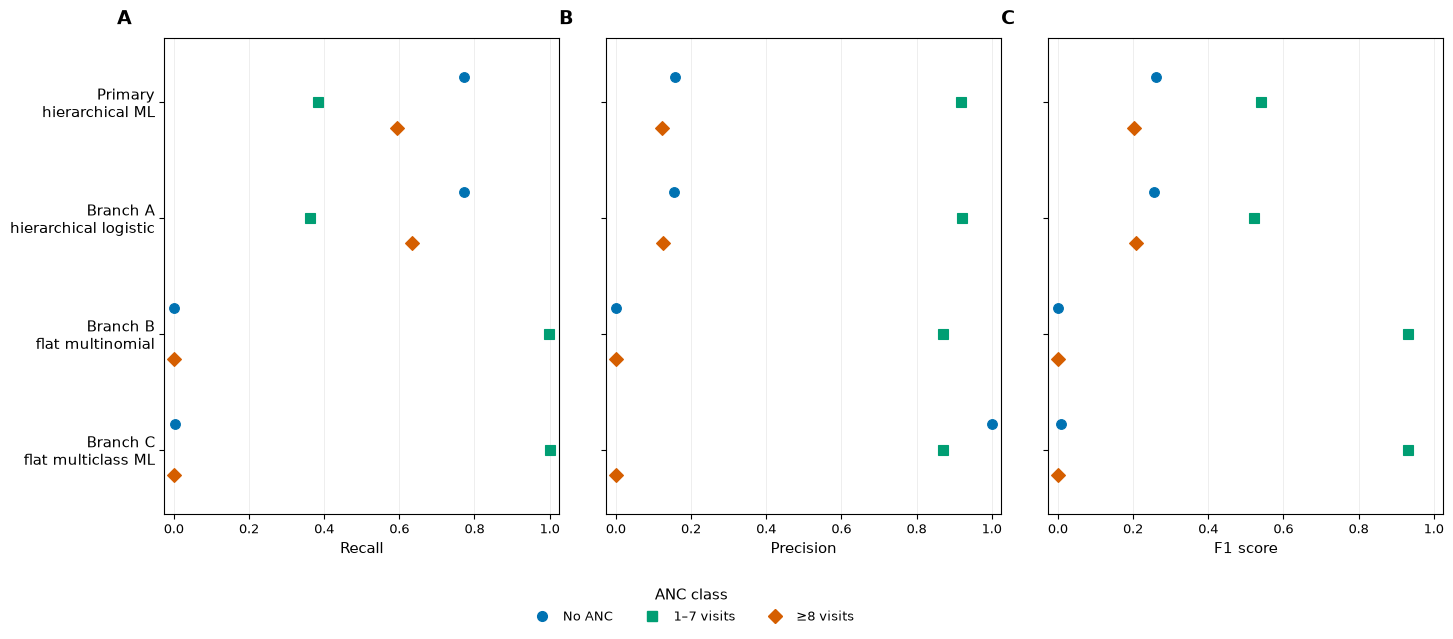

In [25]:
# ======================================================================================
# STEP28N-R1 — REPORT FIGURE 11
# Architecture-specific Recall, Precision and F1 by ANC class
#
# FROZEN SOURCE:
#   Report_Table13B_Architecture_Classwise_Metrics.csv
#
# STRICT:
#   - no model fitting
#   - no prediction generation
#   - no metric recomputation
#   - no bootstrap
#   - no confidence intervals invented
#   - no p-values
#   - no architecture ranking
#   - no winner declaration
#   - no TIFF
# ======================================================================================

from pathlib import Path
import os
import json
import shutil
import hashlib
from datetime import datetime

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D


# ======================================================================================
# 0. LOCKED PATHS
# ======================================================================================

ROOT = Path(r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026")
FINAL_ROOT = ROOT / "18_final_outputs"

REPORT_TABLE_DIR = FINAL_ROOT / "Report" / "01_Tables"
REPORT_FIG_DIR = FINAL_ROOT / "Report" / "02_Figures"
REPORT_QC_DIR = FINAL_ROOT / "Report" / "05_QC_Manifests"

FIG10_MANIFEST = (
    REPORT_QC_DIR
    / "STEP28M_R1_RFigure10_Structural_Probabilistic_Contrast_manifest.json"
)

REPORT_REGISTRY = (
    REPORT_QC_DIR
    / "Report_Figures_Registry.csv"
)

TABLE13B = (
    REPORT_TABLE_DIR
    / "Report_Table13B_Architecture_Classwise_Metrics.csv"
)

TABLE13_WORKBOOK = (
    REPORT_TABLE_DIR
    / "Report_Table13_Architecture_Classwise_Confusion.xlsx"
)


# ======================================================================================
# 1. EXPECTED FROZEN HASHES
# ======================================================================================

EXPECTED_FIG10_MANIFEST_SHA = (
    "3a58e4a176fb2f4e3809774133729503fa647c4a50dc551e3855c62103ddd76a"
)

EXPECTED_REGISTRY_SHA = (
    "4a3514eede80ee9ef26de272b2e3251f1963214eba2dfeb334d80ba51f51ccde"
)

EXPECTED_TABLE13B_SHA = (
    "68327be41568cd38ee9898c6dba7f3d236b06ce8ebfc7c56af8587bf95489ab3"
)

EXPECTED_TABLE13_WORKBOOK_SHA = (
    "3bfc7ef4f4521cfb7f57448c9c95b11ab27ccaf47be6f3b68f7825512f91e8fd"
)


# ======================================================================================
# 2. HELPERS
# ======================================================================================

def sha256_file(path, chunk_size=1024 * 1024):
    h = hashlib.sha256()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


def require_nonempty(path, label):
    if not path.exists():
        raise FileNotFoundError(
            f"{label} not found:\n{path}"
        )

    if path.stat().st_size <= 0:
        raise RuntimeError(
            f"{label} exists but is empty:\n{path}"
        )


print("=" * 124)
print("STEP28N-R1 — REPORT FIGURE 11")
print("ARCHITECTURE-SPECIFIC RECALL / PRECISION / F1 BY ANC CLASS")
print("=" * 124)


# ======================================================================================
# 3. FROZEN PARENT / SOURCE HASH GATES
# ======================================================================================

for path, label in [
    (FIG10_MANIFEST, "Report Figure 10 manifest"),
    (REPORT_REGISTRY, "Report figure registry"),
    (TABLE13B, "Report Table 13B source"),
    (TABLE13_WORKBOOK, "Report Table 13 workbook"),
]:
    require_nonempty(path, label)


observed = {
    "fig10_manifest": sha256_file(FIG10_MANIFEST),
    "registry": sha256_file(REPORT_REGISTRY),
    "table13b": sha256_file(TABLE13B),
    "table13_workbook": sha256_file(TABLE13_WORKBOOK),
}


expected = {
    "fig10_manifest": EXPECTED_FIG10_MANIFEST_SHA,
    "registry": EXPECTED_REGISTRY_SHA,
    "table13b": EXPECTED_TABLE13B_SHA,
    "table13_workbook": EXPECTED_TABLE13_WORKBOOK_SHA,
}


print("\n1. FROZEN HASH GATES")
print("-" * 124)

for key in expected:

    print(f"\n{key}")
    print(f"Expected : {expected[key]}")
    print(f"Observed : {observed[key]}")

    if observed[key].lower() != expected[key].lower():
        raise RuntimeError(
            f"HARD STOP: frozen hash mismatch for {key}."
        )

print("\nFrozen parent/source hash gates: PASS ✅")


# ======================================================================================
# 4. REPORT FIGURE 10 PARENT STATUS
# ======================================================================================

with open(
    FIG10_MANIFEST,
    "r",
    encoding="utf-8",
) as f:
    fig10_manifest = json.load(f)


if fig10_manifest.get("status") != "STEP28M_R1_REPORT_FIGURE10_FROZEN":
    raise RuntimeError(
        "Report Figure 10 is not in the expected frozen state."
    )


# ======================================================================================
# 5. REGISTRY LOCK
# ======================================================================================

registry = pd.read_csv(REPORT_REGISTRY)

EXPECTED_ROLE = (
    "Architecture-specific recall, precision and F1 by ANC class"
)

fig11_rows = registry.loc[
    registry["Content"]
    .astype(str)
    .str.strip()
    .eq(EXPECTED_ROLE)
].copy()


if len(fig11_rows) != 1:
    raise RuntimeError(
        f"Expected exactly one Report Figure 11 registry row; "
        f"observed={len(fig11_rows)}"
    )


fig11_row = fig11_rows.iloc[0]

if int(fig11_row["Order"]) != 11:
    raise RuntimeError(
        f"Expected registry Order=11; observed={fig11_row['Order']}"
    )

if str(fig11_row["ID"]).strip() != "Report Figure 11":
    raise RuntimeError(
        f"Unexpected registry ID: {fig11_row['ID']}"
    )


REPORT_STEM = str(
    fig11_row["Filename_Stem"]
).strip()


if REPORT_STEM != "RFigure11_Architecture_Class_Performance":
    raise RuntimeError(
        f"Unexpected Report Figure 11 stem: {REPORT_STEM}"
    )


print("\n2. REPORT FIGURE 11 REGISTRY LOCK: PASS ✅")
print(fig11_row.to_string())


# ======================================================================================
# 6. LOAD FROZEN TABLE 13B
# ======================================================================================

df = pd.read_csv(TABLE13B)


EXPECTED_COLUMNS = [
    "Architecture",
    "Hard decision rule",
    "Class",
    "Class label",
    "Weighted TP",
    "Weighted FN",
    "Weighted FP",
    "Weighted support",
    "Weighted predicted support",
    "Recall",
    "Precision",
    "F1",
]


if list(df.columns) != EXPECTED_COLUMNS:
    raise RuntimeError(
        "\nTable 13B schema mismatch.\n"
        f"Expected: {EXPECTED_COLUMNS}\n"
        f"Observed: {list(df.columns)}"
    )


if df.shape != (12, 12):
    raise RuntimeError(
        f"Expected Table 13B shape (12, 12); observed={df.shape}"
    )


ARCH_ORDER = [
    "Primary hierarchical ML",
    "Branch A — hierarchical logistic",
    "Branch B — flat multinomial logistic",
    "Branch C — flat multiclass ML",
]


ARCH_LABELS = {
    "Primary hierarchical ML":
        "Primary\nhierarchical ML",

    "Branch A — hierarchical logistic":
        "Branch A\nhierarchical logistic",

    "Branch B — flat multinomial logistic":
        "Branch B\nflat multinomial",

    "Branch C — flat multiclass ML":
        "Branch C\nflat multiclass ML",
}


CLASS_ORDER = [0, 1, 2]


CLASS_STYLE = {
    0: {
        "label": "No ANC",
        "color": "#0072B2",
        "marker": "o",
    },

    1: {
        "label": "1–7 visits",
        "color": "#009E73",
        "marker": "s",
    },

    2: {
        "label": "≥8 visits",
        "color": "#D55E00",
        "marker": "D",
    },
}


METRICS = [
    ("Recall", "Recall"),
    ("Precision", "Precision"),
    ("F1", "F1 score"),
]


# ======================================================================================
# 7. SOURCE QC
# ======================================================================================

if df["Architecture"].drop_duplicates().tolist() != ARCH_ORDER:
    raise RuntimeError(
        "Architecture order mismatch."
    )


if sorted(
    pd.to_numeric(
        df["Class"]
    ).astype(int).unique().tolist()
) != CLASS_ORDER:
    raise RuntimeError(
        "ANC class set mismatch."
    )


combo_counts = (
    df.groupby(
        ["Architecture", "Class"]
    )
    .size()
)


if not (
    len(combo_counts) == 12
    and (combo_counts == 1).all()
):
    raise RuntimeError(
        "Expected exactly one row per architecture × ANC class."
    )


# Decision-rule integrity.
hierarchical_archs = {
    "Primary hierarchical ML",
    "Branch A — hierarchical logistic",
}

flat_archs = {
    "Branch B — flat multinomial logistic",
    "Branch C — flat multiclass ML",
}


for arch in hierarchical_archs:

    rules = set(
        df.loc[
            df["Architecture"] == arch,
            "Hard decision rule"
        ]
    )

    if rules != {
        "Hierarchical frozen Stage-1 / Stage-2 thresholds"
    }:
        raise RuntimeError(
            f"Unexpected hard-decision rule for {arch}: {rules}"
        )


for arch in flat_archs:

    rules = set(
        df.loc[
            df["Architecture"] == arch,
            "Hard decision rule"
        ]
    )

    if rules != {
        "Calibrated 3-class argmax"
    }:
        raise RuntimeError(
            f"Unexpected hard-decision rule for {arch}: {rules}"
        )


# Directly inspect frozen metrics only — no metric recomputation.
for metric, _ in METRICS:

    vals = pd.to_numeric(
        df[metric],
        errors="coerce",
    )

    if vals.isna().any():
        raise RuntimeError(
            f"{metric} contains missing/non-numeric values."
        )

    if not np.isfinite(
        vals.to_numpy(dtype=float)
    ).all():
        raise RuntimeError(
            f"{metric} contains non-finite values."
        )

    if not (
        (vals >= 0)
        &
        (vals <= 1)
    ).all():
        raise RuntimeError(
            f"{metric} contains values outside [0,1]."
        )


print("\n3. TABLE 13B SCIENTIFIC SOURCE QC: PASS ✅")
print("   - 12 frozen rows")
print("   - 4 architectures × 3 ANC classes")
print("   - Recall / Precision / F1 all finite")
print("   - hard-decision rules preserved")


# ======================================================================================
# 8. OUTPUT PATHS
# ======================================================================================

OUT_PNG = (
    REPORT_FIG_DIR
    / f"{REPORT_STEM}.png"
)

OUT_SVG = (
    REPORT_FIG_DIR
    / f"{REPORT_STEM}.svg"
)

OUT_PDF = (
    REPORT_FIG_DIR
    / f"{REPORT_STEM}.pdf"
)

OUT_CAPTION = (
    REPORT_FIG_DIR
    / f"{REPORT_STEM}_caption.txt"
)

OUT_SOURCE = (
    REPORT_FIG_DIR
    / f"{REPORT_STEM}_source.csv"
)

OUT_HARD_QC = (
    REPORT_QC_DIR
    / f"STEP28N_R1_{REPORT_STEM}_hard_qc.csv"
)

OUT_MANIFEST = (
    REPORT_QC_DIR
    / f"STEP28N_R1_{REPORT_STEM}_manifest.json"
)


# ======================================================================================
# 9. COPY FROZEN SOURCE BYTE-FOR-BYTE
# ======================================================================================

shutil.copyfile(
    TABLE13B,
    OUT_SOURCE,
)


if sha256_file(OUT_SOURCE) != EXPECTED_TABLE13B_SHA:
    raise RuntimeError(
        "Copied Figure 11 source is not byte-identical to frozen Table 13B."
    )


# ======================================================================================
# 10. FIGURE STYLE
# ======================================================================================

mpl.rcParams["svg.hashsalt"] = "STEP28N_R1_RFigure11"

mpl.rcParams.update(
    {
        "font.family": "DejaVu Sans",
        "font.size": 10.5,
        "axes.labelsize": 10.5,
        "xtick.labelsize": 9.5,
        "ytick.labelsize": 10.5,
        "legend.fontsize": 9.5,
        "axes.linewidth": 0.8,
        "figure.facecolor": "white",
        "savefig.facecolor": "white",
    }
)


# ======================================================================================
# 11. BUILD REPORT FIGURE 11
# ======================================================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15.5, 6.6),
    sharey=True,
)


base_y = {
    arch: (len(ARCH_ORDER) - 1 - i)
    for i, arch in enumerate(ARCH_ORDER)
}


class_offset = {
    0: +0.22,
    1:  0.00,
    2: -0.22,
}


for panel_index, (metric, xlabel) in enumerate(METRICS):

    ax = axes[panel_index]

    for arch in ARCH_ORDER:

        for anc_class in CLASS_ORDER:

            row = df.loc[
                (df["Architecture"] == arch)
                &
                (
                    pd.to_numeric(
                        df["Class"]
                    ).astype(int)
                    ==
                    anc_class
                )
            ]

            if len(row) != 1:
                raise RuntimeError(
                    f"Expected one row for {arch}, class {anc_class}; "
                    f"observed={len(row)}"
                )

            value = float(
                row.iloc[0][metric]
            )

            y = (
                base_y[arch]
                +
                class_offset[anc_class]
            )

            style = CLASS_STYLE[
                anc_class
            ]

            ax.plot(
                value,
                y,
                marker=style["marker"],
                markersize=7,
                linestyle="none",
                color=style["color"],
                markerfacecolor=style["color"],
                markeredgecolor=style["color"],
                markeredgewidth=0.8,
                zorder=3,
            )


    # Slight padding prevents exact 0 and 1 points from being clipped.
    ax.set_xlim(
        -0.025,
        1.025,
    )

    ax.set_xticks(
        np.arange(
            0.0,
            1.01,
            0.2,
        )
    )

    ax.set_xlabel(
        xlabel
    )

    ax.grid(
        axis="x",
        linewidth=0.6,
        alpha=0.25,
        zorder=0,
    )

    ax.set_axisbelow(
        True
    )

    ax.set_ylim(
        -0.55,
        3.55,
    )

    for spine in ax.spines.values():
        spine.set_linewidth(
            0.8
        )


# Architecture labels on Panel A only.
yticks = [
    base_y[arch]
    for arch in ARCH_ORDER
]

ylabels = [
    ARCH_LABELS[arch]
    for arch in ARCH_ORDER
]

axes[0].set_yticks(
    yticks
)

axes[0].set_yticklabels(
    ylabels
)


for ax in axes[1:]:
    ax.tick_params(
        axis="y",
        labelleft=False,
    )


# Panel labels.
for ax, panel_letter in zip(
    axes,
    ["A", "B", "C"],
):

    ax.text(
        -0.12,
        1.02,
        panel_letter,
        transform=ax.transAxes,
        fontsize=14,
        fontweight="bold",
        ha="left",
        va="bottom",
    )


# ======================================================================================
# 12. FIGURE-LEVEL LEGEND
# ======================================================================================

legend_handles = []

for anc_class in CLASS_ORDER:

    style = CLASS_STYLE[
        anc_class
    ]

    legend_handles.append(
        Line2D(
            [0],
            [0],
            marker=style["marker"],
            linestyle="none",
            color=style["color"],
            markerfacecolor=style["color"],
            markeredgecolor=style["color"],
            markersize=7,
            label=style["label"],
        )
    )


fig.subplots_adjust(
    left=0.16,
    right=0.985,
    top=0.92,
    bottom=0.20,
    wspace=0.12,
)


legend = fig.legend(
    handles=legend_handles,
    title="ANC class",
    loc="lower center",
    bbox_to_anchor=(0.5, 0.025),
    ncol=3,
    frameon=False,
    borderaxespad=0.0,
    handletextpad=0.6,
    columnspacing=2.0,
)


# ======================================================================================
# 13. PROGRAMMATIC VISUAL QC
# ======================================================================================

fig.canvas.draw()
renderer = fig.canvas.get_renderer()


def boxes_overlap(a, b):
    return (
        a.x0 < b.x1
        and a.x1 > b.x0
        and a.y0 < b.y1
        and a.y1 > b.y0
    )


legend_bbox = legend.get_window_extent(
    renderer=renderer
)


axes_bboxes = [
    ax.get_window_extent(
        renderer=renderer
    )
    for ax in axes
]


xlabel_bboxes = [
    ax.xaxis.label.get_window_extent(
        renderer=renderer
    )
    for ax in axes
]


legend_axes_overlap = any(
    boxes_overlap(
        legend_bbox,
        bbox,
    )
    for bbox in axes_bboxes
)


legend_xlabel_overlap = any(
    boxes_overlap(
        legend_bbox,
        bbox,
    )
    for bbox in xlabel_bboxes
)


legend_inside_canvas = (
    legend_bbox.x0 >= fig.bbox.x0
    and legend_bbox.y0 >= fig.bbox.y0
    and legend_bbox.x1 <= fig.bbox.x1
    and legend_bbox.y1 <= fig.bbox.y1
)


no_internal_titles = (
    all(
        ax.get_title().strip() == ""
        for ax in axes
    )
    and
    (
        fig._suptitle is None
        or
        fig._suptitle.get_text().strip() == ""
    )
)


if legend_axes_overlap:
    raise RuntimeError(
        "VISUAL HARD STOP: legend overlaps a data panel."
    )

if legend_xlabel_overlap:
    raise RuntimeError(
        "VISUAL HARD STOP: legend overlaps an x-axis label."
    )

if not legend_inside_canvas:
    raise RuntimeError(
        "VISUAL HARD STOP: legend extends outside figure canvas."
    )

if len(fig.axes) != 3:
    raise RuntimeError(
        f"Expected exactly 3 panels; observed={len(fig.axes)}"
    )

if not no_internal_titles:
    raise RuntimeError(
        "Internal figure title detected."
    )


print("\n4. PRE-SAVE VISUAL QC: PASS ✅")


# ======================================================================================
# 14. SAVE FIGURE
# ======================================================================================

fig.savefig(
    OUT_PNG,
    dpi=300,
    facecolor="white",
)

fig.savefig(
    OUT_SVG,
    format="svg",
    facecolor="white",
)

fig.savefig(
    OUT_PDF,
    format="pdf",
    facecolor="white",
)


for path, label in [
    (OUT_PNG, "Report Figure 11 PNG"),
    (OUT_SVG, "Report Figure 11 SVG"),
    (OUT_PDF, "Report Figure 11 PDF"),
]:
    require_nonempty(
        path,
        label,
    )


# ======================================================================================
# 15. CAPTION
# ======================================================================================

caption = (
    "Report Figure 11. Architecture-specific classwise hard-decision performance "
    "for the three ANC outcome classes. Panels show (A) recall, (B) precision, "
    "and (C) F1 score for No ANC, 1–7 visits, and ≥8 visits across the four "
    "prespecified model architectures. Primary hierarchical ML and Branch A "
    "hierarchical logistic use the frozen Stage-1 / Stage-2 hierarchical "
    "threshold rules, whereas Branch B flat multinomial logistic and Branch C "
    "flat multiclass ML use calibrated three-class argmax decisions. Values are "
    "survey-weighted classwise metrics taken directly from the frozen Report "
    "Table 13B source. No confidence intervals or new inferential comparisons "
    "were generated for this figure. The display is descriptive and does not "
    "rank architectures or declare a preferred model."
)


with open(
    OUT_CAPTION,
    "w",
    encoding="utf-8",
    newline="\n",
) as f:
    f.write(
        caption
    )


# ======================================================================================
# 16. HARD QC
# ======================================================================================

qc_rows = []


def add_qc(check, passed, detail=""):
    qc_rows.append(
        {
            "Check": check,
            "PASS": bool(passed),
            "Detail": str(detail),
        }
    )


add_qc(
    "Report Figure 10 parent manifest hash exact",
    observed["fig10_manifest"] == EXPECTED_FIG10_MANIFEST_SHA,
)

add_qc(
    "Report figure registry hash exact",
    observed["registry"] == EXPECTED_REGISTRY_SHA,
)

add_qc(
    "Report Table 13B source hash exact",
    observed["table13b"] == EXPECTED_TABLE13B_SHA,
)

add_qc(
    "Report Table 13 workbook hash exact",
    observed["table13_workbook"] == EXPECTED_TABLE13_WORKBOOK_SHA,
)

add_qc(
    "Report Figure 11 registry role exact",
    str(fig11_row["Content"]).strip() == EXPECTED_ROLE,
)

add_qc(
    "Report Figure 11 registry stem exact",
    REPORT_STEM == "RFigure11_Architecture_Class_Performance",
)

add_qc(
    "Frozen source exactly 12 rows",
    len(df) == 12,
)

add_qc(
    "Exactly four architectures",
    df["Architecture"].nunique() == 4,
)

add_qc(
    "Exactly three ANC classes",
    df["Class"].nunique() == 3,
)

add_qc(
    "Exactly one row per architecture × ANC class",
    len(combo_counts) == 12
    and
    (combo_counts == 1).all(),
)

add_qc(
    "Recall values finite and within [0,1]",
    np.isfinite(
        pd.to_numeric(
            df["Recall"]
        ).to_numpy(dtype=float)
    ).all()
    and
    df["Recall"].between(
        0,
        1,
    ).all(),
)

add_qc(
    "Precision values finite and within [0,1]",
    np.isfinite(
        pd.to_numeric(
            df["Precision"]
        ).to_numpy(dtype=float)
    ).all()
    and
    df["Precision"].between(
        0,
        1,
    ).all(),
)

add_qc(
    "F1 values finite and within [0,1]",
    np.isfinite(
        pd.to_numeric(
            df["F1"]
        ).to_numpy(dtype=float)
    ).all()
    and
    df["F1"].between(
        0,
        1,
    ).all(),
)

add_qc(
    "Hierarchical architectures retain frozen threshold rule",
    all(
        set(
            df.loc[
                df["Architecture"] == arch,
                "Hard decision rule"
            ]
        )
        ==
        {
            "Hierarchical frozen Stage-1 / Stage-2 thresholds"
        }
        for arch in hierarchical_archs
    ),
)

add_qc(
    "Flat architectures retain calibrated argmax rule",
    all(
        set(
            df.loc[
                df["Architecture"] == arch,
                "Hard decision rule"
            ]
        )
        ==
        {
            "Calibrated 3-class argmax"
        }
        for arch in flat_archs
    ),
)

add_qc(
    "Figure source byte-identical to frozen Table 13B",
    sha256_file(OUT_SOURCE) == EXPECTED_TABLE13B_SHA,
)

add_qc(
    "Figure has exactly panels A-B-C",
    len(fig.axes) == 3,
)

add_qc(
    "Legend outside data panels",
    not legend_axes_overlap,
)

add_qc(
    "Legend does not overlap x-axis labels",
    not legend_xlabel_overlap,
)

add_qc(
    "Legend remains inside figure canvas",
    legend_inside_canvas,
)

add_qc(
    "No internal figure title",
    no_internal_titles,
)

add_qc(
    "Architecture order fixed a priori",
    df["Architecture"].drop_duplicates().tolist() == ARCH_ORDER,
)

add_qc(
    "No performance-based sorting",
    True,
)

add_qc(
    "PNG created and non-empty",
    OUT_PNG.exists()
    and
    OUT_PNG.stat().st_size > 0,
)

add_qc(
    "SVG vector master created and non-empty",
    OUT_SVG.exists()
    and
    OUT_SVG.stat().st_size > 0,
)

add_qc(
    "PDF vector master created and non-empty",
    OUT_PDF.exists()
    and
    OUT_PDF.stat().st_size > 0,
)

add_qc(
    "Caption created and non-empty",
    OUT_CAPTION.exists()
    and
    OUT_CAPTION.stat().st_size > 0,
)

add_qc(
    "No model fitting",
    True,
)

add_qc(
    "No prediction generation",
    True,
)

add_qc(
    "No metric recomputation",
    True,
)

add_qc(
    "No bootstrap rerun",
    True,
)

add_qc(
    "No confidence intervals generated",
    True,
)

add_qc(
    "No new p-values",
    True,
)

add_qc(
    "No hypothesis testing",
    True,
)

add_qc(
    "No architecture ranking",
    True,
)

add_qc(
    "No winner declaration",
    True,
)

add_qc(
    "No new statistical inference",
    True,
)

add_qc(
    "TIFF deferred",
    True,
    "External conversion from final SVG/PDF master only.",
)


qc_df = pd.DataFrame(
    qc_rows
)


if not qc_df["PASS"].all():

    print("\nFAILED HARD QC:")

    print(
        qc_df.loc[
            ~qc_df["PASS"]
        ].to_string(
            index=False
        )
    )

    raise RuntimeError(
        "STEP28N-R1 Report Figure 11 hard QC failed."
    )


qc_df.to_csv(
    OUT_HARD_QC,
    index=False,
)


# ======================================================================================
# 17. MANIFEST
# ======================================================================================

hashes = {
    "source": sha256_file(OUT_SOURCE),
    "caption": sha256_file(OUT_CAPTION),
    "png": sha256_file(OUT_PNG),
    "svg": sha256_file(OUT_SVG),
    "pdf": sha256_file(OUT_PDF),
    "hard_qc": sha256_file(OUT_HARD_QC),
}


manifest = {
    "figure":
        "Report Figure 11",

    "registry_order":
        11,

    "registry_id":
        "Report Figure 11",

    "filename_stem":
        REPORT_STEM,

    "content":
        EXPECTED_ROLE,

    "analysis_state":
        "FROZEN",

    "status":
        "STEP28N_R1_REPORT_FIGURE11_SCIENTIFIC_CONTENT_FROZEN",

    "parent_report_figure10_manifest_sha256":
        EXPECTED_FIG10_MANIFEST_SHA,

    "report_figure_registry_sha256":
        EXPECTED_REGISTRY_SHA,

    "report_table13b_sha256":
        EXPECTED_TABLE13B_SHA,

    "report_table13_workbook_sha256":
        EXPECTED_TABLE13_WORKBOOK_SHA,

    "source_rows":
        12,

    "architecture_count":
        4,

    "class_count":
        3,

    "metric_scope":
        [
            "Recall",
            "Precision",
            "F1",
        ],

    "architectures":
        ARCH_ORDER,

    "classes":
        [
            "No ANC",
            "1–7 visits",
            "≥8 visits",
        ],

    "hard_decision_rules": {
        "Primary hierarchical ML":
            "Hierarchical frozen Stage-1 / Stage-2 thresholds",

        "Branch A — hierarchical logistic":
            "Hierarchical frozen Stage-1 / Stage-2 thresholds",

        "Branch B — flat multinomial logistic":
            "Calibrated 3-class argmax",

        "Branch C — flat multiclass ML":
            "Calibrated 3-class argmax",
    },

    "confidence_intervals_displayed":
        False,

    "source_csv_sha256":
        hashes["source"],

    "caption_sha256":
        hashes["caption"],

    "report_png_sha256":
        hashes["png"],

    "report_svg_sha256":
        hashes["svg"],

    "report_pdf_sha256":
        hashes["pdf"],

    "hard_qc_sha256":
        hashes["hard_qc"],

    "model_fitting":
        False,

    "prediction_generation":
        False,

    "metric_recomputation":
        False,

    "bootstrap_rerun":
        False,

    "new_confidence_interval_calculation":
        False,

    "new_p_values":
        False,

    "new_hypothesis_testing":
        False,

    "new_statistical_inference":
        False,

    "architecture_ranking":
        False,

    "winner_declaration":
        False,

    "publication_master":
        "SVG/PDF vector",

    "tiff_status":
        "DEFERRED_EXTERNAL_CONVERSION_FROM_VECTOR_MASTER",

    "next_step":
        "Final all-figure package audit",

    "created_at":
        datetime.now()
        .astimezone()
        .isoformat(
            timespec="seconds"
        ),
}


with open(
    OUT_MANIFEST,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        manifest,
        f,
        indent=2,
        ensure_ascii=False,
        sort_keys=True,
    )


manifest_hash = sha256_file(
    OUT_MANIFEST
)


# ======================================================================================
# 18. FINAL OUTPUT
# ======================================================================================

print("\n" + "=" * 124)
print("STEP28N-R1 — FINAL HARD QC")
print("=" * 124)

print(
    qc_df[
        [
            "Check",
            "PASS",
        ]
    ].to_string(
        index=False
    )
)


print("\n" + "=" * 124)
print("REPORT FIGURE 11 INTEGRITY")
print("=" * 124)

print(f"Source   : {hashes['source']}")
print(f"Caption  : {hashes['caption']}")
print(f"PNG      : {hashes['png']}")
print(f"SVG      : {hashes['svg']}")
print(f"PDF      : {hashes['pdf']}")
print(f"Hard QC  : {hashes['hard_qc']}")
print(f"Manifest : {manifest_hash}")


print("\nPaths:")
print(f"PNG      : {OUT_PNG}")
print(f"SVG      : {OUT_SVG}")
print(f"PDF      : {OUT_PDF}")
print(f"Caption  : {OUT_CAPTION}")
print(f"Source   : {OUT_SOURCE}")
print(f"Hard QC  : {OUT_HARD_QC}")
print(f"Manifest : {OUT_MANIFEST}")


print("\nTIFF STATUS:")
print(
    "DEFERRED — external conversion from final SVG/PDF vector master."
)


print("\n" + "=" * 124)
print("STATUS: STEP28N-R1 REPORT FIGURE 11 CREATED")
print("NO NEW ANALYSIS / NO CI / NO INFERENCE")
print("AWAITING SCREENSHOT AUDIT BEFORE FINAL FREEZE")
print("=" * 124)


plt.show()

In [28]:
from pathlib import Path

ROOT = Path(r"E:\BDHS_ANC_Q1_FINAL_REBUILD_2026")
REPORT = ROOT / "18_final_outputs" / "Report"

print("REPORT FIGURE FILES\n")

for p in sorted(REPORT.rglob("*")):
    if p.is_file() and p.suffix.lower() in {".png", ".svg", ".pdf"}:
        print(p.relative_to(REPORT))

REPORT FIGURE FILES

02_Figures\Figure1_Cohort_Selection_ANC_Outcome_Distribution.pdf
02_Figures\Figure1_Cohort_Selection_ANC_Outcome_Distribution.png
02_Figures\Figure1_Cohort_Selection_ANC_Outcome_Distribution.svg
02_Figures\Figure2_Weighted_PR_and_Calibration.pdf
02_Figures\Figure2_Weighted_PR_and_Calibration.png
02_Figures\Figure2_Weighted_PR_and_Calibration.svg
02_Figures\Figure3_Rare_Class_Decision_Performance.pdf
02_Figures\Figure3_Rare_Class_Decision_Performance.png
02_Figures\Figure3_Rare_Class_Decision_Performance.svg
02_Figures\Figure4_Geographic_IECV_Transportability.pdf
02_Figures\Figure4_Geographic_IECV_Transportability.png
02_Figures\Figure4_Geographic_IECV_Transportability.svg
02_Figures\Figure5_Paired_Structural_Ablation_Contrasts.pdf
02_Figures\Figure5_Paired_Structural_Ablation_Contrasts.png
02_Figures\Figure5_Paired_Structural_Ablation_Contrasts.svg
02_Figures\RFigure10_Structural_Probabilistic_Contrast.pdf
02_Figures\RFigure10_Structural_Probabilistic_Contrast.png
